In [1]:
import torch

if torch.cuda.is_available():

    device = torch.device("cuda")

    x = torch.randn(1000, 1000, device=device)
    y = torch.randn(1000, 1000, device=device)

    z = torch.matmul(x, y)

    print("GPU computation: SUCCESS")
    print("GPU:", torch.cuda.get_device_name(0))
    print("Result shape:", z.shape)
    print("Allocated memory:",
          round(torch.cuda.memory_allocated() / 1024**2, 2),
          "MB")

else:
    print("GPU computation: FAILED")

GPU computation: SUCCESS
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Result shape: torch.Size([1000, 1000])
Allocated memory: 20.0 MB


In [2]:
import sys
import torch
import torchvision
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import sklearn

from pathlib import Path

print("=" * 60)
print("BCN20000 RESEARCH ENVIRONMENT")
print("=" * 60)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nEnvironment verification completed.")

BCN20000 RESEARCH ENVIRONMENT
Python: 3.12.10
PyTorch: 2.14.1+cu126
Torchvision: 0.29.1+cu126
CUDA: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Pandas: 3.1.1
NumPy: 2.5.4
OpenCV: 5.1.0
Scikit-learn: 1.9.1

Environment verification completed.


In [3]:
# ============================================================
# BCN20000 RESEARCH
# PHASE 01 - CELL 1: CONFIGURATION & ENVIRONMENT
# ============================================================

import os
import sys
import json
import random
import platform
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torchvision
import cv2

from PIL import Image, ImageFile
from IPython.display import display

# ------------------------------------------------------------
# 1. REPRODUCIBILITY
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# 2. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

TRAIN_CSV = PROJECT_ROOT / "bcn_20k_train.csv"
TEST_CSV = PROJECT_ROOT / "bcn_20k_test.csv"

TRAIN_IMAGE_DIR = PROJECT_ROOT / "bcn_20k_train"
TEST_IMAGE_DIR = PROJECT_ROOT / "bcn_20k_test"

OUTPUT_DIR = PROJECT_ROOT / "outputs"

REPORT_DIR = OUTPUT_DIR / "reports"
FIGURE_DIR = OUTPUT_DIR / "figures"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
PREDICTION_DIR = OUTPUT_DIR / "predictions"
LOG_DIR = OUTPUT_DIR / "logs"

for folder in [
    REPORT_DIR,
    FIGURE_DIR,
    CHECKPOINT_DIR,
    PREDICTION_DIR,
    LOG_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 3. IMAGE CONFIGURATION
# ------------------------------------------------------------

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp"
}

# ------------------------------------------------------------
# 4. ENVIRONMENT INFORMATION
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 65)
print("BCN20000 - PHASE 01")
print("DATASET EXPLORATION AND METADATA VALIDATION")
print("=" * 65)

print("Project Root:", PROJECT_ROOT)
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("OpenCV:", cv2.__version__)

print("\nCompute Device:", DEVICE)

if torch.cuda.is_available():

    gpu = torch.cuda.get_device_properties(0)

    print("GPU:", torch.cuda.get_device_name(0))
    print("Total VRAM:", round(gpu.total_memory / 1024**3, 2), "GB")

print("\nOutput folders initialized.")

print("=" * 65)
print("CONFIGURATION INITIALIZATION COMPLETE")
print("=" * 65)

BCN20000 - PHASE 01
DATASET EXPLORATION AND METADATA VALIDATION
Project Root: d:\skin_research
Python: 3.12.10
PyTorch: 2.14.1+cu126
Torchvision: 0.29.1+cu126
NumPy: 2.5.4
Pandas: 3.1.1
OpenCV: 5.1.0

Compute Device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Total VRAM: 6.0 GB

Output folders initialized.
CONFIGURATION INITIALIZATION COMPLETE


In [4]:
# ============================================================
# PHASE 01 - CELL 2: CSV LOADING & SCHEMA INSPECTION
# ============================================================

print("=" * 65)
print("CSV FILE VALIDATION")
print("=" * 65)

# Check files
required_files = {
    "Training CSV": TRAIN_CSV,
    "Testing CSV": TEST_CSV
}

for name, path in required_files.items():

    status = "FOUND" if path.exists() else "MISSING"

    print(f"{name}: {status}")

    if not path.exists():
        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

# Load CSV
train_df = pd.read_csv(
    TRAIN_CSV,
    low_memory=False
)

test_df = pd.read_csv(
    TEST_CSV,
    low_memory=False
)

# Remove accidental spaces from column headers
train_df.columns = train_df.columns.str.strip()
test_df.columns = test_df.columns.str.strip()

print("\nTRAINING DATASET")
print("-" * 45)

print("Shape:", train_df.shape)
print("Rows:", len(train_df))
print("Columns:", len(train_df.columns))

print("\nTraining Columns:")

for col in train_df.columns:
    print(" -", col)

print("\nTraining Data Types:")
display(train_df.dtypes.to_frame("Data Type"))

print("\nTraining Sample:")
display(train_df.head(10))

print("\nTEST DATASET")
print("-" * 45)

print("Shape:", test_df.shape)
print("Rows:", len(test_df))
print("Columns:", len(test_df.columns))

print("\nTesting Columns:")

for col in test_df.columns:
    print(" -", col)

print("\nTesting Sample:")
display(test_df.head(10))

print("\nCSV LOADING COMPLETE")

CSV FILE VALIDATION
Training CSV: FOUND
Testing CSV: FOUND

TRAINING DATASET
---------------------------------------------
Shape: (12413, 8)
Rows: 12413
Columns: 8

Training Columns:
 - bcn_filename
 - age_approx
 - anatom_site_general
 - diagnosis
 - lesion_id
 - capture_date
 - sex
 - split

Training Data Types:


,Data Type
bcn_filename,str
age_approx,float64
anatom_site_general,str
diagnosis,str
lesion_id,str
capture_date,str
sex,str
split,str



Training Sample:


,bcn_filename,age_approx,anatom_site_general,diagnosis,lesion_id,capture_date,sex,split
0,BCN_0000000001.jpg,55.0,anterior torso,MEL,BCN_0003884,2012-05-16,male,train
1,BCN_0000000003.jpg,50.0,anterior torso,MEL,BCN_0000019,2015-07-09,female,train
2,BCN_0000000004.jpg,85.0,head/neck,SCC,BCN_0003499,2015-11-23,male,train
3,BCN_0000000006.jpg,60.0,anterior torso,NV,BCN_0003316,2015-06-16,male,train
4,BCN_0000000010.jpg,30.0,anterior torso,BCC,BCN_0004874,2014-02-18,female,train
5,BCN_0000000011.jpg,20.0,anterior torso,NV,BCN_0004756,2015-03-19,female,train
6,BCN_0000000013.jpg,40.0,anterior torso,NV,BCN_0002221,2014-03-03,male,train
7,BCN_0000000014.jpg,75.0,head/neck,BKL,BCN_0005020,2015-05-07,female,train
8,BCN_0000000016.jpg,80.0,head/neck,MEL,BCN_0003352,2012-02-03,female,train
9,BCN_0000000017.jpg,80.0,upper extremity,MEL,BCN_0002462,2015-07-06,female,train



TEST DATASET
---------------------------------------------
Shape: (6533, 8)
Rows: 6533
Columns: 8

Testing Columns:
 - bcn_filename
 - age_approx
 - anatom_site_general
 - diagnosis
 - lesion_id
 - capture_date
 - sex
 - split

Testing Sample:


,bcn_filename,age_approx,anatom_site_general,diagnosis,lesion_id,capture_date,sex,split
0,BCN_0000000000.jpg,60.0,anterior torso,NaN,BCN4657,2016-06-01,male,test
1,BCN_0000000002.jpg,50.0,lower extremity,NaN,BCN689,2015-05-18,male,test
2,BCN_0000000005.jpg,35.0,head/neck,NaN,BCN481,2016-02-23,male,test
3,BCN_0000000007.jpg,35.0,head/neck,NaN,BCN1871,2016-01-28,male,test
4,BCN_0000000008.jpg,75.0,upper extremity,NaN,BCN385,2016-06-12,female,test
5,BCN_0000000009.jpg,60.0,anterior torso,NaN,BCN1530,2012-02-21,male,test
6,BCN_0000000012.jpg,85.0,NaN,NaN,BCN1001,2016-04-25,male,test
7,BCN_0000000015.jpg,70.0,anterior torso,NaN,BCN5194,2012-01-19,male,test
8,BCN_0000000024.jpg,55.0,anterior torso,NaN,BCN1735,2016-03-01,female,test
9,BCN_0000000027.jpg,60.0,anterior torso,NaN,BCN452,2015-02-09,male,test



CSV LOADING COMPLETE


In [5]:
# ============================================================
# PHASE 01 - CELL 3: METADATA COLUMN IDENTIFICATION
# ============================================================

import re

def normalize_column_name(name):

    return re.sub(
        r"[^a-z0-9]",
        "",
        str(name).lower()
    )


def find_column(dataframe, candidates):

    column_map = {
        normalize_column_name(col): col
        for col in dataframe.columns
    }

    for candidate in candidates:

        key = normalize_column_name(candidate)

        if key in column_map:
            return column_map[key]

    return None


# Candidate column names
LABEL_CANDIDATES = [
    "diagnosis",
    "label",
    "class",
    "target"
]

LESION_CANDIDATES = [
    "lesion_id",
    "lesionid",
    "lesion_identifier"
]

FILENAME_CANDIDATES = [
    "bcn_filename",
    "filename",
    "image_filename",
    "image",
    "file_name"
]

AGE_CANDIDATES = [
    "age_approximation",
    "age"
]

SEX_CANDIDATES = [
    "sex",
    "gender"
]

SITE_CANDIDATES = [
    "anatomical_site",
    "site"
]

# Identify columns
LABEL_COL = find_column(
    train_df,
    LABEL_CANDIDATES
)

LESION_COL = find_column(
    train_df,
    LESION_CANDIDATES
)

FILENAME_COL = find_column(
    train_df,
    FILENAME_CANDIDATES
)

AGE_COL = find_column(
    train_df,
    AGE_CANDIDATES
)

SEX_COL = find_column(
    train_df,
    SEX_CANDIDATES
)

SITE_COL = find_column(
    train_df,
    SITE_CANDIDATES
)

identified_columns = {
    "Diagnosis": LABEL_COL,
    "Lesion ID": LESION_COL,
    "Filename": FILENAME_COL,
    "Age": AGE_COL,
    "Sex": SEX_COL,
    "Anatomical Site": SITE_COL
}

print("=" * 65)
print("AUTOMATIC METADATA IDENTIFICATION")
print("=" * 65)

for name, column in identified_columns.items():

    if column is not None:
        print(f"{name}: {column}")
    else:
        print(f"{name}: NOT FOUND")

# Store column mapping
column_mapping = {
    key: value
    for key, value in identified_columns.items()
}

with open(
    REPORT_DIR / "phase01_column_mapping.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        column_mapping,
        f,
        indent=4
    )

print("\nColumn mapping saved.")

AUTOMATIC METADATA IDENTIFICATION
Diagnosis: diagnosis
Lesion ID: lesion_id
Filename: bcn_filename
Age: NOT FOUND
Sex: sex
Anatomical Site: NOT FOUND

Column mapping saved.


In [6]:
# ============================================================
# PHASE 01 - CELL 4: CLASS & LESION DISTRIBUTION
# ============================================================

print("=" * 65)
print("CLASS DISTRIBUTION ANALYSIS")
print("=" * 65)

if LABEL_COL is None:

    raise ValueError(
        "Diagnosis column not identified. "
        "Inspect Cell 2 output before proceeding."
    )

# Class counts
class_counts = (
    train_df[LABEL_COL]
    .value_counts(dropna=False)
    .rename_axis("Diagnosis")
    .reset_index(name="Image Count")
)

class_counts["Percentage"] = (
    class_counts["Image Count"]
    / len(train_df)
    * 100
)

display(class_counts)

# Unique class count
num_classes = train_df[LABEL_COL].nunique(
    dropna=True
)

print("\nNumber of labelled classes:", num_classes)

# Class imbalance ratio
valid_counts = train_df[LABEL_COL].value_counts()

imbalance_ratio = (
    valid_counts.max() / valid_counts.min()
    if len(valid_counts) > 1
    else 1.0
)

print(
    "Majority/Minority Image Ratio:",
    round(imbalance_ratio, 3)
)

# Lesion statistics
if LESION_COL is not None:

    print("\nLESION STATISTICS")
    print("-" * 45)

    unique_lesions = train_df[LESION_COL].nunique()

    print("Unique Lesions:", unique_lesions)

    images_per_lesion = (
        train_df.groupby(LESION_COL)
        .size()
    )

    print(
        "Images per lesion - Mean:",
        round(images_per_lesion.mean(), 3)
    )

    print(
        "Images per lesion - Maximum:",
        images_per_lesion.max()
    )

    print(
        "Lesions with multiple images:",
        int((images_per_lesion > 1).sum())
    )

    # Check whether a lesion has conflicting diagnoses
    label_consistency = (
        train_df.groupby(LESION_COL)[LABEL_COL]
        .nunique(dropna=True)
    )

    conflicting_lesions = int(
        (label_consistency > 1).sum()
    )

    print(
        "Lesions with conflicting labels:",
        conflicting_lesions
    )

else:

    print("\nLesion ID not found. Group analysis unavailable.")

# Duplicate metadata rows
print(
    "\nExact duplicate CSV rows:",
    int(train_df.duplicated().sum())
)

# Save reports
class_counts.to_csv(
    REPORT_DIR / "phase01_class_distribution.csv",
    index=False
)

print("\nClass distribution report saved.")

CLASS DISTRIBUTION ANALYSIS


,Diagnosis,Image Count,Percentage
0,NV,4206,33.883831
1,MEL,2857,23.016193
2,BCC,2809,22.629501
3,BKL,1138,9.167808
4,AK,737,5.937324
5,SCC,431,3.472166
6,DF,124,0.998953
7,VASC,111,0.894224



Number of labelled classes: 8
Majority/Minority Image Ratio: 37.892

LESION STATISTICS
---------------------------------------------
Unique Lesions: 3576
Images per lesion - Mean: 3.471
Images per lesion - Maximum: 31
Lesions with multiple images: 3088
Lesions with conflicting labels: 0

Exact duplicate CSV rows: 0

Class distribution report saved.


In [7]:
# ============================================================
# PHASE 01 - CELL 5: MISSING VALUE ANALYSIS
# ============================================================

print("=" * 65)
print("MISSING METADATA ANALYSIS")
print("=" * 65)

def missing_value_report(dataframe, dataset_name):

    report = pd.DataFrame({

        "Column": dataframe.columns,

        "Missing Count": [
            dataframe[col].isna().sum()
            for col in dataframe.columns
        ],

        "Missing Percentage": [
            dataframe[col].isna().mean() * 100
            for col in dataframe.columns
        ],

        "Unique Values": [
            dataframe[col].nunique(dropna=True)
            for col in dataframe.columns
        ]

    })

    report = report.sort_values(
        "Missing Percentage",
        ascending=False
    )

    print(f"\n{dataset_name}")

    display(report)

    return report


train_missing = missing_value_report(
    train_df,
    "TRAINING DATASET"
)

test_missing = missing_value_report(
    test_df,
    "TEST DATASET"
)

train_missing.to_csv(
    REPORT_DIR / "phase01_train_missing_values.csv",
    index=False
)

test_missing.to_csv(
    REPORT_DIR / "phase01_test_missing_values.csv",
    index=False
)

print("\nMissing-value reports saved.")

MISSING METADATA ANALYSIS

TRAINING DATASET


,Column,Missing Count,Missing Percentage,Unique Values
2,anatom_site_general,173,1.393700,6
1,age_approx,74,0.596149,18
6,sex,74,0.596149,2
0,bcn_filename,0,0.000000,12413
3,diagnosis,0,0.000000,8
4,lesion_id,0,0.000000,3576
5,capture_date,0,0.000000,1008
7,split,0,0.000000,1



TEST DATASET


,Column,Missing Count,Missing Percentage,Unique Values
3,diagnosis,6533,100.000000,0
2,anatom_site_general,124,1.898056,6
1,age_approx,43,0.658197,18
6,sex,43,0.658197,2
0,bcn_filename,0,0.000000,6533
4,lesion_id,0,0.000000,1864
5,capture_date,0,0.000000,809
7,split,0,0.000000,1



Missing-value reports saved.


In [8]:
# ============================================================
# PHASE 01 - CELL 6: IMAGE FILE INVENTORY & MATCHING
# ============================================================

from collections import Counter

print("=" * 65)
print("IMAGE FILE INVENTORY")
print("=" * 65)


def get_image_files(directory):

    if not directory.exists():
        return []

    return sorted([
        path
        for path in directory.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ])


def build_image_index(image_files):

    index = {}

    for path in image_files:

        key = path.name.lower()

        index.setdefault(key, []).append(path)

    return index


train_image_files = get_image_files(
    TRAIN_IMAGE_DIR
)

test_image_files = get_image_files(
    TEST_IMAGE_DIR
)

print("Training images found:", len(train_image_files))
print("Testing images found:", len(test_image_files))


def normalize_filename(value):

    if pd.isna(value):
        return None

    value = str(value).strip().replace("\\", "/")

    return Path(value).name.lower()


def match_csv_images(dataframe, filename_col, image_files):

    if filename_col is None:
        return None

    image_index = build_image_index(image_files)

    result = dataframe.copy()

    result["_normalized_filename"] = (
        result[filename_col].apply(normalize_filename)
    )

    result["_matched_paths"] = (
        result["_normalized_filename"].map(image_index)
    )

    result["_image_found"] = (
        result["_matched_paths"].apply(
            lambda x: isinstance(x, list) and len(x) > 0
        )
    )

    return result


TEST_FILENAME_COL = find_column(
    test_df,
    FILENAME_CANDIDATES
)

train_matches = match_csv_images(
    train_df,
    FILENAME_COL,
    train_image_files
)

test_matches = match_csv_images(
    test_df,
    TEST_FILENAME_COL,
    test_image_files
)

# Training matching report
if train_matches is not None:

    print("\nTRAINING IMAGE MATCHING")

    matched = int(train_matches["_image_found"].sum())
    unmatched = len(train_matches) - matched

    print("Matched CSV records:", matched)
    print("Unmatched CSV records:", unmatched)

    print(
        "Matching percentage:",
        round(matched / len(train_matches) * 100, 2),
        "%"
    )

    unmatched_train = train_matches[
        ~train_matches["_image_found"]
    ]

    unmatched_train.to_csv(
        REPORT_DIR / "phase01_unmatched_train_images.csv",
        index=False
    )

else:

    print("\nTraining filename column not identified.")


# Test matching report
if test_matches is not None:

    print("\nTEST IMAGE MATCHING")

    matched_test = int(
        test_matches["_image_found"].sum()
    )

    unmatched_test = (
        len(test_matches) - matched_test
    )

    print("Matched CSV records:", matched_test)
    print("Unmatched CSV records:", unmatched_test)

    print(
        "Matching percentage:",
        round(
            matched_test / len(test_matches) * 100,
            2
        ),
        "%"
    )

    unmatched_test_df = test_matches[
        ~test_matches["_image_found"]
    ]

    unmatched_test_df.to_csv(
        REPORT_DIR / "phase01_unmatched_test_images.csv",
        index=False
    )

else:

    print("\nTest filename column not identified.")


# Duplicate filenames on disk
train_basename_counts = Counter(
    path.name.lower()
    for path in train_image_files
)

duplicate_disk_names = {
    name: count
    for name, count in train_basename_counts.items()
    if count > 1
}

print("\nDuplicate filenames in training directory:",
      len(duplicate_disk_names))

print("\nImage inventory completed.")

IMAGE FILE INVENTORY
Training images found: 12413
Testing images found: 6501

TRAINING IMAGE MATCHING
Matched CSV records: 12413
Unmatched CSV records: 0
Matching percentage: 100.0 %

TEST IMAGE MATCHING
Matched CSV records: 6501
Unmatched CSV records: 32
Matching percentage: 99.51 %

Duplicate filenames in training directory: 0

Image inventory completed.


DERMOSCOPIC IMAGE VISUALIZATION


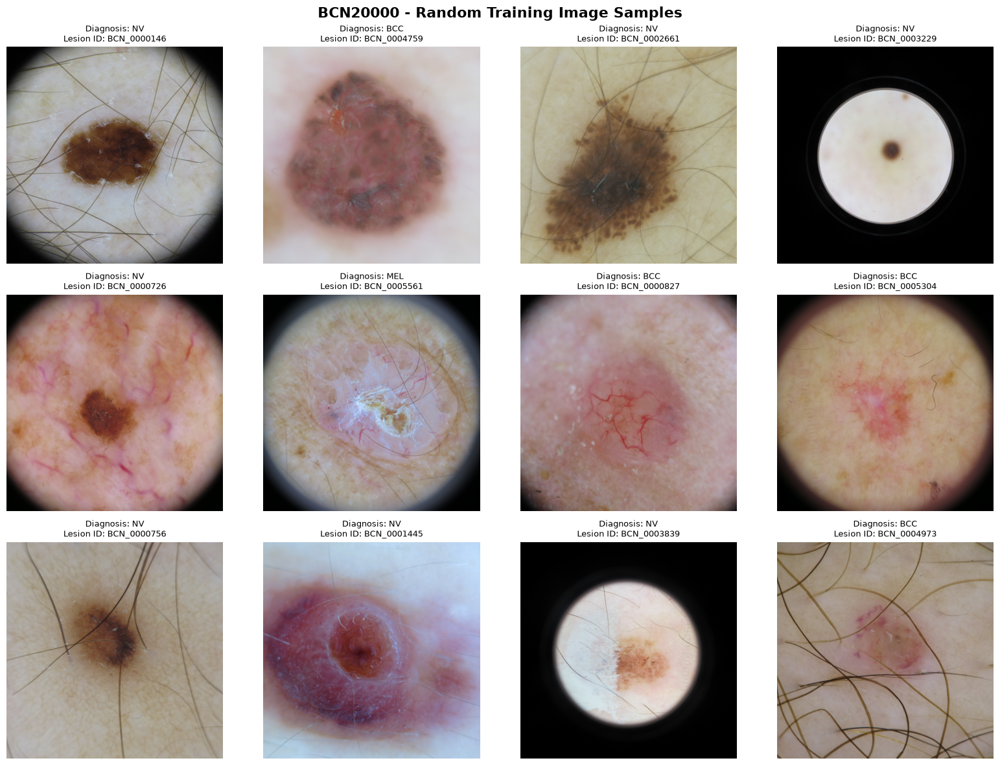


Image visualization saved.


In [9]:
# ============================================================
# PHASE 01 - CELL 7: IMAGE SAMPLE VISUALIZATION
# ============================================================

print("=" * 65)
print("DERMOSCOPIC IMAGE VISUALIZATION")
print("=" * 65)

if train_matches is None:

    print("BLOCKED: Filename column unavailable.")

else:

    available_images = train_matches[
        train_matches["_image_found"]
    ].copy()

    if len(available_images) == 0:

        print("BLOCKED: No images matched.")

    else:

        sample_size = min(12, len(available_images))

        samples = available_images.sample(
            n=sample_size,
            random_state=SEED
        )

        fig, axes = plt.subplots(
            3, 4,
            figsize=(16, 12)
        )

        axes = axes.flatten()

        for ax in axes:
            ax.axis("off")

        for ax, (_, row) in zip(
            axes,
            samples.iterrows()
        ):

            image_path = row["_matched_paths"][0]

            try:

                with Image.open(image_path) as img:

                    img = img.convert("RGB")

                    ax.imshow(img)

                label = (
                    row[LABEL_COL]
                    if LABEL_COL is not None
                    else "Unknown"
                )

                lesion = (
                    row[LESION_COL]
                    if LESION_COL is not None
                    else "Unavailable"
                )

                ax.set_title(
                    f"Diagnosis: {label}\nLesion ID: {lesion}",
                    fontsize=9
                )

                ax.axis("off")

            except Exception as error:

                ax.set_title(
                    f"Image error: {str(error)[:30]}"
                )

                ax.axis("off")

        plt.suptitle(
            "BCN20000 - Random Training Image Samples",
            fontsize=16,
            fontweight="bold"
        )

        plt.tight_layout()

        plt.savefig(
            FIGURE_DIR / "phase01_image_samples.png",
            dpi=200,
            bbox_inches="tight"
        )

        plt.show()

        print("\nImage visualization saved.")

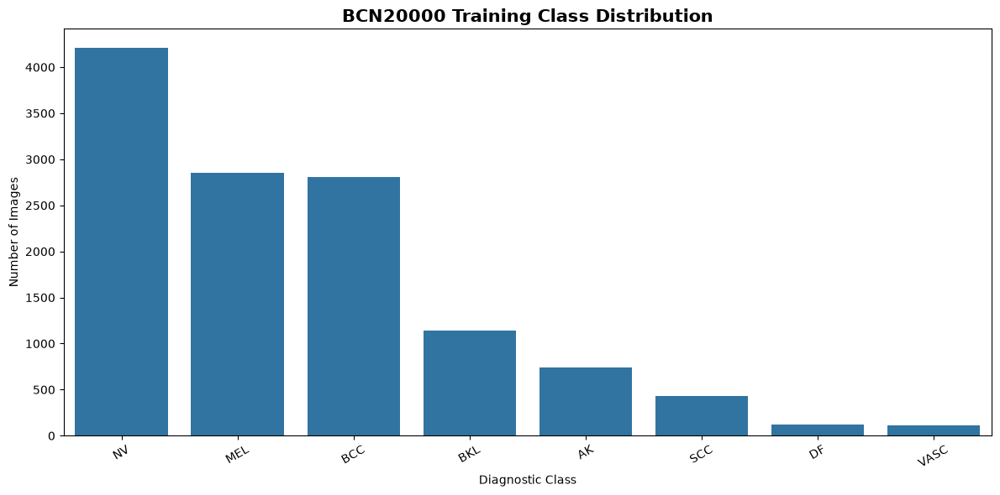

In [10]:
# ============================================================
# PHASE 01 - CELL 8: CLASS DISTRIBUTION CHART
# ============================================================

if LABEL_COL is not None:

    plot_data = (
        train_df[LABEL_COL]
        .value_counts()
        .rename_axis("Diagnosis")
        .reset_index(name="Image Count")
    )

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=plot_data,
        x="Diagnosis",
        y="Image Count"
    )

    plt.title(
        "BCN20000 Training Class Distribution",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel("Diagnostic Class")
    plt.ylabel("Number of Images")

    plt.xticks(rotation=30)

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / "phase01_class_distribution.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

else:

    print("Diagnosis column not available.")

In [11]:
# ============================================================
# PHASE 01 - CELL 9: FINAL VERIFICATION REPORT
# ============================================================

print("=" * 70)
print("PHASE 01 - FINAL DATASET VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. CORE CHECKS
# ------------------------------------------------------------

checks = {}

checks["Training CSV exists"] = TRAIN_CSV.exists()
checks["Testing CSV exists"] = TEST_CSV.exists()

checks["Training CSV loaded"] = len(train_df) > 0
checks["Testing CSV loaded"] = len(test_df) > 0

checks["Training image directory exists"] = (
    TRAIN_IMAGE_DIR.exists()
)

checks["Testing image directory exists"] = (
    TEST_IMAGE_DIR.exists()
)

checks["Training images available"] = (
    len(train_image_files) > 0
)

checks["Testing images available"] = (
    len(test_image_files) > 0
)

# ------------------------------------------------------------
# 2. METADATA CHECKS
# ------------------------------------------------------------

warnings_list = []

if LABEL_COL is None:
    warnings_list.append("Diagnosis column not identified.")

if LESION_COL is None:
    warnings_list.append("Lesion ID column not identified.")

if FILENAME_COL is None:
    warnings_list.append("Training filename column not identified.")

if train_matches is not None:

    train_match_count = int(
        train_matches["_image_found"].sum()
    )

else:

    train_match_count = 0
    warnings_list.append("Training image matching unavailable.")

if test_matches is not None:

    test_match_count = int(
        test_matches["_image_found"].sum()
    )

else:

    test_match_count = 0
    warnings_list.append("Test image matching unavailable.")


# ------------------------------------------------------------
# 3. TRAIN-TEST LESION OVERLAP
# ------------------------------------------------------------

train_test_lesion_overlap = None

if LESION_COL is not None:

    test_lesion_col = find_column(
        test_df,
        LESION_CANDIDATES
    )

    if test_lesion_col is not None:

        train_lesions = set(
            train_df[LESION_COL]
            .dropna()
            .astype(str)
        )

        test_lesions = set(
            test_df[test_lesion_col]
            .dropna()
            .astype(str)
        )

        train_test_lesion_overlap = len(
            train_lesions.intersection(test_lesions)
        )

        print(
            "Train-Test common lesion IDs:",
            train_test_lesion_overlap
        )

        if train_test_lesion_overlap > 0:

            warnings_list.append(
                "Common lesion IDs found across CSV splits."
            )

    else:

        warnings_list.append(
            "Test lesion ID column not identified."
        )


# ------------------------------------------------------------
# 4. OVERALL STATUS
# ------------------------------------------------------------

core_pass = all(checks.values())

if not core_pass:

    overall_status = "BLOCKED"

elif len(warnings_list) > 0:

    overall_status = "WARNING"

else:

    overall_status = "PASS"


# ------------------------------------------------------------
# 5. REPORT
# ------------------------------------------------------------

report = {

    "phase": "PHASE_01_DATASET_EXPLORATION",

    "status": overall_status,

    "project_root": str(PROJECT_ROOT),

    "environment": {

        "python": sys.version.split()[0],

        "pytorch": torch.__version__,

        "cuda_available": torch.cuda.is_available(),

        "gpu": (
            torch.cuda.get_device_name(0)
            if torch.cuda.is_available()
            else None
        )

    },

    "dataset": {

        "train_csv_rows": len(train_df),

        "test_csv_rows": len(test_df),

        "train_columns": train_df.columns.tolist(),

        "test_columns": test_df.columns.tolist(),

        "num_classes": (
            int(train_df[LABEL_COL].nunique())
            if LABEL_COL is not None
            else None
        ),

        "unique_train_lesions": (
            int(train_df[LESION_COL].nunique())
            if LESION_COL is not None
            else None
        ),

        "train_image_files": len(train_image_files),

        "test_image_files": len(test_image_files),

        "train_matched_images": train_match_count,

        "test_matched_images": test_match_count,

        "train_test_lesion_overlap": train_test_lesion_overlap

    },

    "identified_columns": column_mapping,

    "checks": checks,

    "warnings": warnings_list

}


report_path = (
    REPORT_DIR / "phase01_final_report.json"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        report,
        file,
        indent=4,
        default=str
    )


# ------------------------------------------------------------
# 6. DISPLAY FINAL STATUS
# ------------------------------------------------------------

print("\nCORE CHECKS")

for name, passed in checks.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

print("\nOVERALL STATUS:", overall_status)

print("\nWARNINGS:")

if warnings_list:

    for warning in warnings_list:
        print("-", warning)

else:

    print("No metadata warnings detected.")

print("\nREPORT LOCATION:")
print(report_path)

print("\n" + "=" * 70)
print("PHASE 01 VERIFICATION COMPLETED")
print("=" * 70)

PHASE 01 - FINAL DATASET VERIFICATION
Train-Test common lesion IDs: 0

CORE CHECKS
[PASS] Training CSV exists
[PASS] Testing CSV exists
[PASS] Training CSV loaded
[PASS] Testing CSV loaded
[PASS] Training image directory exists
[PASS] Testing image directory exists
[PASS] Training images available
[PASS] Testing images available

OVERALL STATUS: PASS

WARNINGS:
No metadata warnings detected.

REPORT LOCATION:
d:\skin_research\outputs\reports\phase01_final_report.json

PHASE 01 VERIFICATION COMPLETED


In [12]:
# ================================================================
# BCN20000 RESEARCH
# PHASE 01 - FINAL VERIFICATION & RESEARCH READINESS REPORT
# ================================================================

import json
import random
import pandas as pd
import numpy as np

from pathlib import Path
from PIL import Image
from IPython.display import display

print("=" * 75)
print("       BCN20000 - PHASE 01 FINAL VERIFICATION REPORT")
print("=" * 75)


# ================================================================
# 1. PROJECT PATHS AND CSV LOADING
# ================================================================

ROOT = Path.cwd()

TRAIN_CSV = ROOT / "bcn_20k_train.csv"
TEST_CSV = ROOT / "bcn_20k_test.csv"

TRAIN_DIR = ROOT / "bcn_20k_train"
TEST_DIR = ROOT / "bcn_20k_test"

REPORT_DIR = ROOT / "outputs" / "reports"
FIGURE_DIR = ROOT / "outputs" / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

blockers = []
warnings_list = []
checks = {}

if not TRAIN_CSV.exists():
    blockers.append("Training CSV is missing.")

if not TEST_CSV.exists():
    blockers.append("Testing CSV is missing.")

if not TRAIN_DIR.exists():
    blockers.append("Training image directory is missing.")

if not blockers:

    train = pd.read_csv(TRAIN_CSV, low_memory=False)
    test = pd.read_csv(TEST_CSV, low_memory=False)

    train.columns = train.columns.str.strip()
    test.columns = test.columns.str.strip()

    checks["Training CSV loaded"] = True
    checks["Testing CSV loaded"] = True

else:

    train = pd.DataFrame()
    test = pd.DataFrame()

    checks["Training CSV loaded"] = TRAIN_CSV.exists()
    checks["Testing CSV loaded"] = TEST_CSV.exists()


# ================================================================
# 2. AUTOMATIC COLUMN IDENTIFICATION
# ================================================================

def normalize_name(name):

    import re

    return re.sub(
        r"[^a-z0-9]",
        "",
        str(name).lower()
    )


def find_column(df, candidates):

    mapping = {
        normalize_name(col): col
        for col in df.columns
    }

    for candidate in candidates:

        key = normalize_name(candidate)

        if key in mapping:
            return mapping[key]

    return None


LABEL_COL = find_column(
    train,
    ["diagnosis", "label", "class", "target"]
)

LESION_COL = find_column(
    train,
    ["lesion_id", "lesionid", "lesion_identifier"]
)

FILENAME_COL = find_column(
    train,
    ["bcn_filename", "filename", "image_filename", "image"]
)

TEST_LABEL_COL = find_column(
    test,
    ["diagnosis", "label", "class", "target"]
)

TEST_LESION_COL = find_column(
    test,
    ["lesion_id", "lesionid", "lesion_identifier"]
)

TEST_FILENAME_COL = find_column(
    test,
    ["bcn_filename", "filename", "image_filename", "image"]
)

print("\n[1] DATASET INFORMATION")
print("-" * 75)

print("Training CSV rows:", len(train))
print("Testing CSV rows:", len(test))

print("Training columns:", train.columns.tolist())
print("Testing columns:", test.columns.tolist())

print("\nIdentified columns:")

print("Diagnosis:", LABEL_COL)
print("Lesion ID:", LESION_COL)
print("Filename:", FILENAME_COL)
print("Test filename:", TEST_FILENAME_COL)

if train.empty or test.empty:
    blockers.append("One or both CSV files are empty.")

if LABEL_COL is None:
    blockers.append("Training diagnosis column not found.")

if LESION_COL is None:
    blockers.append("Training lesion ID column not found.")

if FILENAME_COL is None:
    blockers.append("Training image filename column not found.")

checks["Diagnosis column identified"] = LABEL_COL is not None
checks["Lesion ID column identified"] = LESION_COL is not None
checks["Filename column identified"] = FILENAME_COL is not None


# ================================================================
# 3. CLASS DISTRIBUTION
# ================================================================

print("\n[2] CLASS DISTRIBUTION")
print("-" * 75)

class_counts = pd.Series(dtype="int64")

if LABEL_COL is not None and not train.empty:

    class_counts = train[LABEL_COL].value_counts(
        dropna=False
    )

    class_report = pd.DataFrame({

        "Class": class_counts.index.astype(str),

        "Images": class_counts.values,

        "Percentage": (
            class_counts.values / len(train) * 100
        )

    })

    display(class_report)

    print("Number of classes:", train[LABEL_COL].nunique())

    print(
        "Missing diagnosis labels:",
        train[LABEL_COL].isna().sum()
    )

    print(
        "Class imbalance ratio:",
        round(
            class_counts.max() / class_counts.min(),
            3
        )
    )

    class_report.to_csv(
        REPORT_DIR / "phase01_class_summary.csv",
        index=False
    )

    if train[LABEL_COL].nunique() != 8:
        warnings_list.append(
            "Expected 8 labelled classes; inspect actual diagnosis values."
        )

    if train[LABEL_COL].isna().any():
        warnings_list.append(
            "Missing diagnosis labels found."
        )

    checks["Eight diagnostic classes identified"] = (
        train[LABEL_COL].nunique() == 8
    )

else:

    checks["Eight diagnostic classes identified"] = False


# ================================================================
# 4. LESION STATISTICS
# ================================================================

print("\n[3] LESION STATISTICS")
print("-" * 75)

lesion_count = 0
multi_image_lesions = 0
conflicting_lesions = 0
missing_lesion_ids = 0

if LESION_COL is not None and not train.empty:

    missing_lesion_ids = int(
        train[LESION_COL].isna().sum()
    )

    valid_train = train.dropna(
        subset=[LESION_COL]
    )

    lesion_count = int(
        valid_train[LESION_COL].nunique()
    )

    image_per_lesion = (
        valid_train.groupby(LESION_COL)
        .size()
    )

    multi_image_lesions = int(
        (image_per_lesion > 1).sum()
    )

    if LABEL_COL is not None:

        consistency = (
            valid_train.groupby(LESION_COL)[LABEL_COL]
            .nunique(dropna=True)
        )

        conflicting_lesions = int(
            (consistency > 1).sum()
        )

    print("Unique lesions:", lesion_count)

    print("Missing lesion IDs:", missing_lesion_ids)

    print(
        "Average images per lesion:",
        round(image_per_lesion.mean(), 3)
    )

    print(
        "Maximum images per lesion:",
        image_per_lesion.max()
    )

    print(
        "Lesions with multiple images:",
        multi_image_lesions
    )

    print(
        "Lesions with conflicting labels:",
        conflicting_lesions
    )

    if missing_lesion_ids > 0:
        warnings_list.append(
            "Some training records have missing lesion IDs."
        )

    if conflicting_lesions > 0:
        warnings_list.append(
            "Conflicting diagnoses found for some lesion IDs."
        )

    checks["Lesion IDs available"] = lesion_count > 0

else:

    checks["Lesion IDs available"] = False


# ================================================================
# 5. MISSING VALUES AND DUPLICATES
# ================================================================

print("\n[4] DATA QUALITY SUMMARY")
print("-" * 75)

missing_summary = pd.DataFrame({

    "Column": train.columns,

    "Missing Values": [
        train[col].isna().sum()
        for col in train.columns
    ],

    "Missing Percentage": [
        round(train[col].isna().mean() * 100, 2)
        for col in train.columns
    ],

    "Unique Values": [
        train[col].nunique(dropna=True)
        for col in train.columns
    ]

})

display(missing_summary)

missing_summary.to_csv(
    REPORT_DIR / "phase01_missing_values.csv",
    index=False
)

duplicate_rows = int(train.duplicated().sum())

duplicate_filenames = 0

if FILENAME_COL is not None:

    duplicate_filenames = int(
        train[FILENAME_COL]
        .dropna()
        .duplicated()
        .sum()
    )

print("Exact duplicate CSV rows:", duplicate_rows)
print("Duplicate filename records:", duplicate_filenames)

if duplicate_rows > 0:
    warnings_list.append(
        "Duplicate CSV rows detected."
    )

if duplicate_filenames > 0:
    warnings_list.append(
        "Duplicate filenames detected in training metadata."
    )


# ================================================================
# 6. IMAGE INVENTORY AND FILE MATCHING
# ================================================================

print("\n[5] IMAGE FILE VALIDATION")
print("-" * 75)

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp"
}


def get_images(folder):

    if not folder.exists():
        return []

    return [
        p for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ]


train_images = get_images(TRAIN_DIR)
test_images = get_images(TEST_DIR)

print("Training images on disk:", len(train_images))
print("Testing images on disk:", len(test_images))

if len(train_images) == 0:
    blockers.append("No training images found.")

if len(test_images) == 0:
    warnings_list.append(
        "Test image folder is empty or unavailable."
    )

checks["Training images available"] = len(train_images) > 0


def build_image_index(paths):

    index = {}

    for path in paths:

        key = path.name.lower()

        index.setdefault(key, []).append(path)

    return index


train_index = build_image_index(train_images)
test_index = build_image_index(test_images)


def resolve_image(value, index):

    if pd.isna(value):
        return None

    name = str(value).strip().replace("\\", "/").split("/")[-1]

    key = name.lower()

    if key in index:
        return index[key][0]

    # If filename has no extension, check the stem
    if Path(name).suffix == "":

        candidates = [
            path
            for paths in index.values()
            for path in paths
            if path.stem.lower() == key
        ]

        if len(candidates) == 1:
            return candidates[0]

    return None


train_matched = 0
test_matched = 0

if FILENAME_COL is not None:

    train_matched = sum(
        resolve_image(value, train_index) is not None
        for value in train[FILENAME_COL]
    )

if TEST_FILENAME_COL is not None:

    test_matched = sum(
        resolve_image(value, test_index) is not None
        for value in test[TEST_FILENAME_COL]
    )

train_match_rate = (
    train_matched / len(train) * 100
    if len(train) else 0
)

test_match_rate = (
    test_matched / len(test) * 100
    if len(test) else 0
)

print("\nTraining CSV-image matching:")
print(f"{train_matched}/{len(train)} ({train_match_rate:.2f}%)")

print("\nTesting CSV-image matching:")
print(f"{test_matched}/{len(test)} ({test_match_rate:.2f}%)")

if train_matched == 0:
    blockers.append("No training CSV records matched image files.")

elif train_matched < len(train):
    warnings_list.append(
        "Some training CSV records have no matching image file."
    )

if test_matched < len(test):
    warnings_list.append(
        "Some test CSV records have no matching image file."
    )

checks["Training image matching"] = train_matched > 0


# ================================================================
# 7. TRAIN-TEST LESION OVERLAP
# ================================================================

print("\n[6] TRAIN-TEST LESION OVERLAP")
print("-" * 75)

train_test_overlap = None

if LESION_COL is not None and TEST_LESION_COL is not None:

    train_ids = set(
        train[LESION_COL].dropna().astype(str)
    )

    test_ids = set(
        test[TEST_LESION_COL].dropna().astype(str)
    )

    common_ids = train_ids.intersection(test_ids)

    train_test_overlap = len(common_ids)

    print("Common lesion IDs:", train_test_overlap)

    if train_test_overlap > 0:

        warnings_list.append(
            "Train-test lesion ID overlap detected. Investigate in Phase 2."
        )

else:

    print("Train-test lesion comparison unavailable.")

    warnings_list.append(
        "Train-test lesion overlap could not be verified."
    )


# ================================================================
# 8. TEST LABEL AVAILABILITY
# ================================================================

print("\n[7] OFFICIAL TEST LABEL STATUS")
print("-" * 75)

test_label_status = "Unavailable"

if TEST_LABEL_COL is not None:

    labelled_test = int(
        test[TEST_LABEL_COL].notna().sum()
    )

    if labelled_test > 0:

        test_label_status = "Some labels present"

    else:

        test_label_status = "Diagnosis column exists but is empty"

else:

    test_label_status = "No public diagnosis column"

print("Test label status:", test_label_status)

if test_label_status == "No public diagnosis column":

    print(
        "NOTE: Official test performance cannot be calculated "
        "without ground-truth labels."
    )


# ================================================================
# 9. SAMPLE IMAGE INTEGRITY CHECK
# ================================================================

print("\n[8] IMAGE INTEGRITY SAMPLE CHECK")
print("-" * 75)

sample_size = min(100, len(train_images))

sample_images = random.Random(42).sample(
    train_images,
    sample_size
) if sample_size else []

valid_images = 0
corrupt_images = []

for path in sample_images:

    try:

        with Image.open(path) as img:
            img.verify()

        valid_images += 1

    except Exception:

        corrupt_images.append(str(path))

print("Images checked:", sample_size)
print("Valid images:", valid_images)
print("Corrupt images:", len(corrupt_images))

if corrupt_images:
    warnings_list.append(
        "Corrupt image candidates found in sample inspection."
    )


# ================================================================
# 10. FINAL DECISION
# ================================================================

print("\n" + "=" * 75)
print("             PHASE 01 FINAL DECISION")
print("=" * 75)

print("\nCORE CHECKS")

for name, status in checks.items():

    print(
        f"[{'PASS' if status else 'FAIL'}] {name}"
    )

# Critical blockers
if blockers:

    phase_status = "BLOCKED"

elif warnings_list:

    phase_status = "PASS_WITH_WARNINGS"

else:

    phase_status = "PASS"


# Phase 2 decision
phase2_allowed = phase_status != "BLOCKED"

print("\nWARNINGS:")

if warnings_list:

    for item in warnings_list:
        print(" -", item)

else:

    print("No warnings detected.")

print("\nBLOCKERS:")

if blockers:

    for item in blockers:
        print(" -", item)

else:

    print("No critical blockers detected.")


# ================================================================
# 11. SAVE FINAL REPORT
# ================================================================

final_report = {

    "phase": "PHASE_01",

    "status": phase_status,

    "phase_2_allowed": phase2_allowed,

    "training_rows": len(train),

    "testing_rows": len(test),

    "number_of_classes": (
        int(train[LABEL_COL].nunique())
        if LABEL_COL else None
    ),

    "class_distribution": {
        str(k): int(v)
        for k, v in class_counts.items()
    },

    "unique_lesions": lesion_count,

    "multi_image_lesions": multi_image_lesions,

    "missing_lesion_ids": missing_lesion_ids,

    "conflicting_lesions": conflicting_lesions,

    "duplicate_csv_rows": duplicate_rows,

    "duplicate_filenames": duplicate_filenames,

    "train_image_files": len(train_images),

    "test_image_files": len(test_images),

    "train_matched_images": train_matched,

    "test_matched_images": test_matched,

    "train_matching_percentage": round(train_match_rate, 2),

    "test_matching_percentage": round(test_match_rate, 2),

    "train_test_lesion_overlap": train_test_overlap,

    "test_label_status": test_label_status,

    "sample_images_checked": sample_size,

    "sample_images_valid": valid_images,

    "sample_images_corrupt": len(corrupt_images),

    "checks": checks,

    "warnings": warnings_list,

    "blockers": blockers

}

report_path = (
    REPORT_DIR / "PHASE_01_FINAL_VERIFICATION.json"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_report,
        f,
        indent=4,
        default=str
    )


# ================================================================
# 12. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 75)

print("PHASE 01 STATUS:", phase_status)

if phase2_allowed:

    print("\nNEXT ACTION: PHASE 02 - INTEGRITY & LEAKAGE AUDIT")

    print(
        "Basic dataset exploration is complete. "
        "Proceed to detailed integrity verification."
    )

else:

    print("\nNEXT ACTION: FIX PHASE 01 BLOCKERS")

    print(
        "Do not proceed until the critical problems are resolved."
    )

print("\nFinal report saved at:")
print(report_path)

print("=" * 75)
print("PHASE 01 VERIFICATION FINISHED")
print("=" * 75)

       BCN20000 - PHASE 01 FINAL VERIFICATION REPORT

[1] DATASET INFORMATION
---------------------------------------------------------------------------
Training CSV rows: 12413
Testing CSV rows: 6533
Training columns: ['bcn_filename', 'age_approx', 'anatom_site_general', 'diagnosis', 'lesion_id', 'capture_date', 'sex', 'split']
Testing columns: ['bcn_filename', 'age_approx', 'anatom_site_general', 'diagnosis', 'lesion_id', 'capture_date', 'sex', 'split']

Identified columns:
Diagnosis: diagnosis
Lesion ID: lesion_id
Filename: bcn_filename
Test filename: bcn_filename

[2] CLASS DISTRIBUTION
---------------------------------------------------------------------------


,Class,Images,Percentage
0,NV,4206,33.883831
1,MEL,2857,23.016193
2,BCC,2809,22.629501
3,BKL,1138,9.167808
4,AK,737,5.937324
5,SCC,431,3.472166
6,DF,124,0.998953
7,VASC,111,0.894224


Number of classes: 8
Missing diagnosis labels: 0
Class imbalance ratio: 37.892

[3] LESION STATISTICS
---------------------------------------------------------------------------
Unique lesions: 3576
Missing lesion IDs: 0
Average images per lesion: 3.471
Maximum images per lesion: 31
Lesions with multiple images: 3088
Lesions with conflicting labels: 0

[4] DATA QUALITY SUMMARY
---------------------------------------------------------------------------


,Column,Missing Values,Missing Percentage,Unique Values
0,bcn_filename,0,0.00,12413
1,age_approx,74,0.60,18
2,anatom_site_general,173,1.39,6
3,diagnosis,0,0.00,8
4,lesion_id,0,0.00,3576
5,capture_date,0,0.00,1008
6,sex,74,0.60,2
7,split,0,0.00,1


Exact duplicate CSV rows: 0
Duplicate filename records: 0

[5] IMAGE FILE VALIDATION
---------------------------------------------------------------------------
Training images on disk: 12413
Testing images on disk: 6501

Training CSV-image matching:
12413/12413 (100.00%)

Testing CSV-image matching:
6501/6533 (99.51%)

[6] TRAIN-TEST LESION OVERLAP
---------------------------------------------------------------------------
Common lesion IDs: 0

[7] OFFICIAL TEST LABEL STATUS
---------------------------------------------------------------------------
Test label status: Diagnosis column exists but is empty

[8] IMAGE INTEGRITY SAMPLE CHECK
---------------------------------------------------------------------------
Images checked: 100
Valid images: 100
Corrupt images: 0

             PHASE 01 FINAL DECISION

CORE CHECKS
[PASS] Training CSV loaded
[PASS] Testing CSV loaded
[PASS] Diagnosis column identified
[PASS] Lesion ID column identified
[PASS] Filename column identified
[PASS] Eight 

In [13]:
# ============================================================
# BCN20000 - TEST IMAGE MISSING FILE INVESTIGATION
# ============================================================

from pathlib import Path
import pandas as pd

# Load official test metadata
test_meta = pd.read_csv(
    "bcn_20k_test.csv",
    low_memory=False
)

train_meta = pd.read_csv(
    "bcn_20k_train.csv",
    low_memory=False
)

# Image directories
test_dir = Path("bcn_20k_test")
train_dir = Path("bcn_20k_train")

# ------------------------------------------------------------
# 1. Collect all image paths
# ------------------------------------------------------------

extensions = {".jpg", ".jpeg", ".png", ".bmp"}

def collect_images(folder):

    return [
        p for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in extensions
    ]

test_paths = collect_images(test_dir)
train_paths = collect_images(train_dir)

# ------------------------------------------------------------
# 2. Normalize filenames
# ------------------------------------------------------------

def normalize_filename(value):

    if pd.isna(value):
        return None

    value = str(value).strip().replace("\\", "/")

    return Path(value).name.casefold()


test_meta["_filename_key"] = (
    test_meta["bcn_filename"].apply(normalize_filename)
)

train_meta["_filename_key"] = (
    train_meta["bcn_filename"].apply(normalize_filename)
)

test_disk_names = {
    p.name.casefold() for p in test_paths
}

train_disk_names = {
    p.name.casefold() for p in train_paths
}

# ------------------------------------------------------------
# 3. Identify missing test files
# ------------------------------------------------------------

missing = test_meta[
    ~test_meta["_filename_key"].isin(test_disk_names)
].copy()

print("=" * 65)
print("MISSING TEST IMAGE INVESTIGATION")
print("=" * 65)

print("Test CSV records:", len(test_meta))
print("Test image files:", len(test_paths))
print("Missing records:", len(missing))

# ------------------------------------------------------------
# 4. Investigate possible alternative locations
# ------------------------------------------------------------

def find_stem_matches(filename, paths):

    if filename is None:
        return []

    target_stem = Path(filename).stem.casefold()

    return [
        str(p)
        for p in paths
        if p.stem.casefold() == target_stem
    ]


statuses = []

for _, row in missing.iterrows():

    filename = row["_filename_key"]

    if filename in train_disk_names:

        status = "FOUND_IN_TRAIN_FOLDER"

    else:

        test_stem_matches = find_stem_matches(
            filename,
            test_paths
        )

        train_stem_matches = find_stem_matches(
            filename,
            train_paths
        )

        if test_stem_matches:

            status = "TEST_EXTENSION_OR_PATH_MISMATCH"

        elif train_stem_matches:

            status = "POSSIBLE_WRONG_FOLDER_OR_EXTENSION"

        else:

            status = "NOT_FOUND_IN_EITHER_FOLDER"

    statuses.append(status)

missing["investigation_status"] = statuses

# ------------------------------------------------------------
# 5. Duplicate test metadata check
# ------------------------------------------------------------

duplicate_test_names = int(
    test_meta["_filename_key"].duplicated().sum()
)

duplicate_test_lesions = int(
    test_meta["lesion_id"].duplicated().sum()
)

print("\nDuplicate test filenames:", duplicate_test_names)

print("Repeated test lesion records:", duplicate_test_lesions)

print("\nMissing file investigation:")

display(
    missing[
        [
            "bcn_filename",
            "lesion_id",
            "diagnosis",
            "investigation_status"
        ]
    ].head(50)
)

# ------------------------------------------------------------
# 6. Save report
# ------------------------------------------------------------

output_dir = Path("outputs/reports")
output_dir.mkdir(parents=True, exist_ok=True)

missing.to_csv(
    output_dir / "missing_test_image_investigation.csv",
    index=False
)

print("\nStatus distribution:")

display(
    missing["investigation_status"]
    .value_counts()
    .to_frame("Count")
)

print("\nReport saved successfully.")
print("=" * 65)

MISSING TEST IMAGE INVESTIGATION
Test CSV records: 6533
Test image files: 6501
Missing records: 32

Duplicate test filenames: 0
Repeated test lesion records: 4669

Missing file investigation:


,bcn_filename,lesion_id,diagnosis,investigation_status
248,BCN_0000000705.jpg,BCN5276,NaN,NOT_FOUND_IN_EITHER_FOLDER
276,BCN_0000000790.jpg,BCN5059,NaN,NOT_FOUND_IN_EITHER_FOLDER
511,BCN_0000001537.jpg,BCN5059,NaN,NOT_FOUND_IN_EITHER_FOLDER
653,BCN_0000001982.jpg,BCN1069,NaN,NOT_FOUND_IN_EITHER_FOLDER
889,BCN_0000002709.jpg,BCN2966,NaN,NOT_FOUND_IN_EITHER_FOLDER
1323,BCN_0000004050.jpg,BCN4674,NaN,NOT_FOUND_IN_EITHER_FOLDER
1567,BCN_0000004729.jpg,BCN4674,NaN,NOT_FOUND_IN_EITHER_FOLDER
1745,BCN_0000005305.jpg,BCN3439,NaN,NOT_FOUND_IN_EITHER_FOLDER
1766,BCN_0000005378.jpg,BCN1069,NaN,NOT_FOUND_IN_EITHER_FOLDER
1945,BCN_0000005952.jpg,BCN1069,NaN,NOT_FOUND_IN_EITHER_FOLDER



Status distribution:


,Count
investigation_status,
NOT_FOUND_IN_EITHER_FOLDER,32



Report saved successfully.


In [14]:
# ============================================================
# PHASE 01 - CELL 11
# ORIGINAL TEST ZIP ARCHIVE INVESTIGATION
# ============================================================

from pathlib import Path
from zipfile import ZipFile
import pandas as pd

ROOT = Path.cwd()

TEST_CSV = ROOT / "bcn_20k_test.csv"
TEST_DIR = ROOT / "bcn_20k_test"
TRAIN_DIR = ROOT / "bcn_20k_train"

# ------------------------------------------------------------
# 1. LOAD TEST METADATA
# ------------------------------------------------------------

test_df = pd.read_csv(TEST_CSV)

# ------------------------------------------------------------
# 2. RECONSTRUCT MISSING FILES
# ------------------------------------------------------------

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp"
}

def get_images(folder):

    return [
        p for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in image_extensions
    ]

test_files = get_images(TEST_DIR)
train_files = get_images(TRAIN_DIR)

test_names = {
    p.name.casefold()
    for p in test_files
}

train_names = {
    p.name.casefold()
    for p in train_files
}

missing_df = test_df[
    ~test_df["bcn_filename"].astype(str)
    .str.strip()
    .str.replace("\\", "/", regex=False)
    .str.split("/")
    .str[-1]
    .str.casefold()
    .isin(test_names)
].copy()

missing_df["filename_key"] = (
    missing_df["bcn_filename"]
    .astype(str)
    .str.strip()
    .str.replace("\\", "/", regex=False)
    .str.split("/")
    .str[-1]
    .str.casefold()
)

print("=" * 65)
print("MISSING IMAGE DETAILS")
print("=" * 65)

print("Missing records:", len(missing_df))

display(
    missing_df[
        ["bcn_filename", "lesion_id"]
    ]
)

# ------------------------------------------------------------
# 3. SEARCH FOR ORIGINAL ZIP
# ------------------------------------------------------------

possible_locations = [
    ROOT,
    Path.home() / "Downloads"
]

zip_candidates = []

for location in possible_locations:

    if location.exists():

        zip_candidates.extend(
            location.glob("*test*.zip")
        )

        zip_candidates.extend(
            location.glob("*TEST*.zip")
        )

print("\nZIP FILES FOUND:")

for z in zip_candidates:
    print(z, "-", round(z.stat().st_size / 1024**3, 2), "GB")

# ------------------------------------------------------------
# 4. INSPECT ZIP CONTENTS
# ------------------------------------------------------------

if not zip_candidates:

    print("\nZIP NOT FOUND.")
    print("Locate BCN_20k_test.zip manually.")

else:

    # Use the official test archive
    test_zip = zip_candidates[0]

    print("\nInspecting:", test_zip)

    with ZipFile(test_zip, "r") as archive:

        archive_images = [
            name for name in archive.namelist()
            if Path(name).suffix.lower()
            in image_extensions
        ]

        archive_names = {
            Path(name).name.casefold()
            for name in archive_images
        }

        archive_missing = missing_df[
            ~missing_df["filename_key"].isin(
                archive_names
            )
        ]

        archive_found = missing_df[
            missing_df["filename_key"].isin(
                archive_names
            )
        ]

        print("\nZIP IMAGE COUNT:", len(archive_images))

        print(
            "Missing images found inside ZIP:",
            len(archive_found)
        )

        print(
            "Missing images absent from ZIP:",
            len(archive_missing)
        )

        display(
            archive_found[
                ["bcn_filename", "lesion_id"]
            ]
        )

        display(
            archive_missing[
                ["bcn_filename", "lesion_id"]
            ]
        )

        archive_missing.to_csv(
            ROOT / "outputs/reports/phase01_zip_missing.csv",
            index=False
        )

print("\nZIP INVESTIGATION COMPLETED.")

MISSING IMAGE DETAILS
Missing records: 32


,bcn_filename,lesion_id
248,BCN_0000000705.jpg,BCN5276
276,BCN_0000000790.jpg,BCN5059
511,BCN_0000001537.jpg,BCN5059
653,BCN_0000001982.jpg,BCN1069
889,BCN_0000002709.jpg,BCN2966
1323,BCN_0000004050.jpg,BCN4674
1567,BCN_0000004729.jpg,BCN4674
1745,BCN_0000005305.jpg,BCN3439
1766,BCN_0000005378.jpg,BCN1069
1945,BCN_0000005952.jpg,BCN1069



ZIP FILES FOUND:

ZIP NOT FOUND.
Locate BCN_20k_test.zip manually.

ZIP INVESTIGATION COMPLETED.


In [15]:
# ============================================================
# BCN20000 RESEARCH
# PHASE 02 - CELL 1
# INTEGRITY AUDIT CONFIGURATION
# ============================================================

import os
import json
import hashlib
import time
import pandas as pd
import numpy as np

from pathlib import Path
from PIL import Image, UnidentifiedImageError
from tqdm.auto import tqdm

print("=" * 70)
print("PHASE 02: DATASET INTEGRITY & LEAKAGE AUDIT")
print("=" * 70)

# Project root
ROOT = Path.cwd()

# Dataset paths
TRAIN_CSV = ROOT / "bcn_20k_train.csv"
TEST_CSV = ROOT / "bcn_20k_test.csv"

TRAIN_DIR = ROOT / "bcn_20k_train"
TEST_DIR = ROOT / "bcn_20k_test"

# Output paths
REPORT_DIR = ROOT / "outputs" / "reports"
FIGURE_DIR = ROOT / "outputs" / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Load metadata
train_meta = pd.read_csv(TRAIN_CSV, low_memory=False)
test_meta = pd.read_csv(TEST_CSV, low_memory=False)

# Image extensions
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp"
}

# Configuration
PHASH_THRESHOLD = 4
HASH_CHUNK_SIZE = 1024 * 1024

print("Project:", ROOT)
print("Training records:", len(train_meta))
print("Testing records:", len(test_meta))

print("Training image directory:", TRAIN_DIR.exists())
print("Testing image directory:", TEST_DIR.exists())

print("pHash threshold:", PHASH_THRESHOLD)

print("\nPHASE 02 CONFIGURATION INITIALIZED")

PHASE 02: DATASET INTEGRITY & LEAKAGE AUDIT
Project: d:\skin_research
Training records: 12413
Testing records: 6533
Training image directory: True
Testing image directory: True
pHash threshold: 4

PHASE 02 CONFIGURATION INITIALIZED


In [16]:
# ============================================================
# PHASE 02 - CELL 2
# COMPLETE IMAGE INVENTORY & INTEGRITY CHECK
# ============================================================

def normalize_filename(value):

    if pd.isna(value):
        return None

    return Path(
        str(value).strip().replace("\\", "/")
    ).name.casefold()


def build_metadata_lookup(df):

    temp = df.copy()

    temp["_filename_key"] = (
        temp["bcn_filename"].apply(normalize_filename)
    )

    lookup = {}

    for _, row in temp.iterrows():

        key = row["_filename_key"]

        if key is None:
            continue

        lookup.setdefault(key, []).append({
            "lesion_id": row["lesion_id"],
            "diagnosis": row["diagnosis"]
        })

    return lookup


train_lookup = build_metadata_lookup(train_meta)
test_lookup = build_metadata_lookup(test_meta)


def inventory_images(split, image_dir, metadata_lookup):

    records = []

    paths = [
        p for p in image_dir.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    print(f"\nScanning {split}: {len(paths)} images")

    for path in tqdm(paths, desc=f"{split} integrity"):

        filename = path.name.casefold()

        metadata = metadata_lookup.get(filename, [])

        lesion_id = (
            metadata[0]["lesion_id"]
            if len(metadata) == 1
            else None
        )

        diagnosis = (
            metadata[0]["diagnosis"]
            if len(metadata) == 1
            else None
        )

        record = {

            "split": split,
            "filename": path.name,
            "path": str(path),
            "file_size_bytes": path.stat().st_size,
            "lesion_id": lesion_id,
            "diagnosis": diagnosis,
            "width": None,
            "height": None,
            "format": None,
            "mode": None,
            "valid": False,
            "error": None

        }

        try:

            # Verify file structure
            with Image.open(path) as img:
                img.verify()

            # Fully decode image
            with Image.open(path) as img:

                record["width"] = img.width
                record["height"] = img.height
                record["format"] = img.format
                record["mode"] = img.mode

                img.load()

            record["valid"] = True

        except Exception as error:

            record["error"] = str(error)

        records.append(record)

    return records


start_time = time.time()

train_records = inventory_images(
    "train",
    TRAIN_DIR,
    train_lookup
)

test_records = inventory_images(
    "test",
    TEST_DIR,
    test_lookup
)

P2_INVENTORY = pd.DataFrame(
    train_records + test_records
)

elapsed = time.time() - start_time

# Save complete inventory
inventory_path = (
    REPORT_DIR / "phase02_image_inventory.csv"
)

P2_INVENTORY.to_csv(
    inventory_path,
    index=False
)

# Summary
print("\n" + "=" * 65)
print("IMAGE INTEGRITY SUMMARY")
print("=" * 65)

display(
    P2_INVENTORY.groupby("split").agg(
        total_images=("filename", "count"),
        valid_images=("valid", "sum"),
        total_size_bytes=("file_size_bytes", "sum")
    )
)

print("\nInvalid images:")

invalid_images = P2_INVENTORY[
    ~P2_INVENTORY["valid"]
]

display(invalid_images)

print("Elapsed time:", round(elapsed / 60, 2), "minutes")

print("Inventory saved:", inventory_path)


Scanning train: 12413 images


train integrity:   0%|          | 0/12413 [00:00<?, ?it/s]


Scanning test: 6501 images


test integrity:   0%|          | 0/6501 [00:00<?, ?it/s]


IMAGE INTEGRITY SUMMARY


,total_images,valid_images,total_size_bytes
split,,,
test,6501,6501,3350990217
train,12413,12413,6413593124



Invalid images:


,split,filename,path,file_size_bytes,lesion_id,diagnosis,width,height,format,mode,valid,error


Elapsed time: 6.88 minutes
Inventory saved: d:\skin_research\outputs\reports\phase02_image_inventory.csv


In [17]:
# ============================================================
# PHASE 02 - CELL 3
# METADATA CONSISTENCY & LESION GROUPING AUDIT
# ============================================================

print("=" * 70)
print("METADATA CONSISTENCY AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Duplicate metadata records
# ------------------------------------------------------------

train_duplicate_rows = int(
    train_meta.duplicated().sum()
)

test_duplicate_rows = int(
    test_meta.duplicated().sum()
)

train_duplicate_filenames = int(
    train_meta["bcn_filename"].duplicated().sum()
)

test_duplicate_filenames = int(
    test_meta["bcn_filename"].duplicated().sum()
)

print("Training duplicate rows:", train_duplicate_rows)
print("Testing duplicate rows:", test_duplicate_rows)

print("Training duplicate filenames:", train_duplicate_filenames)
print("Testing duplicate filenames:", test_duplicate_filenames)

# ------------------------------------------------------------
# 2. Missing lesion identifiers
# ------------------------------------------------------------

train_missing_lesions = int(
    train_meta["lesion_id"].isna().sum()
)

test_missing_lesions = int(
    test_meta["lesion_id"].isna().sum()
)

print("\nMissing training lesion IDs:", train_missing_lesions)
print("Missing testing lesion IDs:", test_missing_lesions)

# ------------------------------------------------------------
# 3. Lesion-level diagnosis consistency
# ------------------------------------------------------------

train_label_consistency = (
    train_meta.groupby("lesion_id")["diagnosis"]
    .nunique(dropna=True)
)

conflicting_train_lesions = int(
    (train_label_consistency > 1).sum()
)

print(
    "\nTraining lesions with conflicting diagnoses:",
    conflicting_train_lesions
)

# ------------------------------------------------------------
# 4. Train-test lesion overlap
# ------------------------------------------------------------

train_lesion_ids = set(
    train_meta["lesion_id"].dropna().astype(str)
)

test_lesion_ids = set(
    test_meta["lesion_id"].dropna().astype(str)
)

common_lesions = train_lesion_ids.intersection(
    test_lesion_ids
)

print("\nUnique training lesions:", len(train_lesion_ids))
print("Unique testing lesions:", len(test_lesion_ids))
print("Common train-test lesions:", len(common_lesions))

# ------------------------------------------------------------
# 5. CSV-image matching
# ------------------------------------------------------------

def csv_image_matching(metadata, inventory, split):

    csv_names = set(
        metadata["bcn_filename"]
        .dropna()
        .apply(normalize_filename)
    )

    disk_names = set(
        inventory.loc[
            inventory["split"] == split,
            "filename"
        ].apply(normalize_filename)
    )

    matched = csv_names.intersection(disk_names)

    missing = csv_names - disk_names

    return {
        "csv_unique_filenames": len(csv_names),
        "disk_unique_filenames": len(disk_names),
        "matched": len(matched),
        "unmatched": len(missing),
        "missing_names": sorted(missing)
    }


train_match_report = csv_image_matching(
    train_meta,
    P2_INVENTORY,
    "train"
)

test_match_report = csv_image_matching(
    test_meta,
    P2_INVENTORY,
    "test"
)

print("\nTRAIN IMAGE MATCHING:")
display(pd.DataFrame([train_match_report]).drop(
    columns=["missing_names"]
))

print("\nTEST IMAGE MATCHING:")
display(pd.DataFrame([test_match_report]).drop(
    columns=["missing_names"]
))

# ------------------------------------------------------------
# 6. Save audit report
# ------------------------------------------------------------

metadata_audit = {

    "train_duplicate_rows": train_duplicate_rows,
    "test_duplicate_rows": test_duplicate_rows,

    "train_duplicate_filenames": train_duplicate_filenames,
    "test_duplicate_filenames": test_duplicate_filenames,

    "train_missing_lesion_ids": train_missing_lesions,
    "test_missing_lesion_ids": test_missing_lesions,

    "conflicting_train_lesions": conflicting_train_lesions,

    "unique_train_lesions": len(train_lesion_ids),
    "unique_test_lesions": len(test_lesion_ids),

    "train_test_lesion_overlap": len(common_lesions),

    "train_image_matching": train_match_report,
    "test_image_matching": test_match_report

}

with open(
    REPORT_DIR / "phase02_metadata_audit.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata_audit,
        f,
        indent=4,
        default=str
    )

print("\nMetadata consistency audit saved.")

METADATA CONSISTENCY AUDIT
Training duplicate rows: 0
Testing duplicate rows: 0
Training duplicate filenames: 0
Testing duplicate filenames: 0

Missing training lesion IDs: 0
Missing testing lesion IDs: 0

Training lesions with conflicting diagnoses: 0

Unique training lesions: 3576
Unique testing lesions: 1864
Common train-test lesions: 0

TRAIN IMAGE MATCHING:


,csv_unique_filenames,disk_unique_filenames,matched,unmatched
0,12413,12413,12413,0



TEST IMAGE MATCHING:


,csv_unique_filenames,disk_unique_filenames,matched,unmatched
0,6533,6501,6501,32



Metadata consistency audit saved.


In [18]:
# ============================================================
# PHASE 02 - CELL 4
# SHA-256 EXACT DUPLICATE DETECTION
# ============================================================

import hashlib

print("=" * 70)
print("SHA-256 EXACT DUPLICATE AUDIT")
print("=" * 70)


def calculate_sha256(file_path):

    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:

        while True:

            chunk = file.read(HASH_CHUNK_SIZE)

            if not chunk:
                break

            sha256.update(chunk)

    return sha256.hexdigest()


# Only valid images
valid_inventory = P2_INVENTORY[
    P2_INVENTORY["valid"]
].copy()

sha_records = []

start_time = time.time()

for row in tqdm(
    valid_inventory.itertuples(index=False),
    total=len(valid_inventory),
    desc="Calculating SHA-256"
):

    sha = calculate_sha256(row.path)

    sha_records.append({

        "split": row.split,
        "filename": row.filename,
        "path": row.path,
        "lesion_id": row.lesion_id,
        "diagnosis": row.diagnosis,
        "sha256": sha

    })


P2_HASHED_INVENTORY = pd.DataFrame(
    sha_records
)

# Save complete hash manifest
P2_HASHED_INVENTORY.to_csv(
    REPORT_DIR / "phase02_sha256_manifest.csv",
    index=False
)

# ------------------------------------------------------------
# 1. Identify exact duplicate groups
# ------------------------------------------------------------

duplicate_hash_groups = (
    P2_HASHED_INVENTORY
    .groupby("sha256")
    .filter(lambda group: len(group) > 1)
)

duplicate_group_reports = []

if not duplicate_hash_groups.empty:

    for sha, group in duplicate_hash_groups.groupby("sha256"):

        duplicate_group_reports.append({

            "sha256": sha,

            "duplicate_file_count": len(group),

            "splits": ", ".join(
                sorted(group["split"].unique())
            ),

            "cross_split": (
                group["split"].nunique() > 1
            ),

            "filenames": " | ".join(
                group["filename"].tolist()
            ),

            "paths": " | ".join(
                group["path"].tolist()
            )

        })


P2_EXACT_DUPLICATES = pd.DataFrame(
    duplicate_group_reports
)

# Save duplicate groups
P2_EXACT_DUPLICATES.to_csv(
    REPORT_DIR / "phase02_exact_duplicates.csv",
    index=False
)

# ------------------------------------------------------------
# 2. Summary
# ------------------------------------------------------------

exact_duplicate_groups = len(
    P2_EXACT_DUPLICATES
)

exact_duplicate_files = len(
    duplicate_hash_groups
)

cross_split_exact_groups = (
    int(P2_EXACT_DUPLICATES["cross_split"].sum())
    if not P2_EXACT_DUPLICATES.empty
    else 0
)

elapsed = time.time() - start_time

print("\nTotal images hashed:", len(P2_HASHED_INVENTORY))

print("Exact duplicate groups:", exact_duplicate_groups)

print("Files involved in exact duplicates:", exact_duplicate_files)

print("Cross-split duplicate groups:", cross_split_exact_groups)

print("Processing time:", round(elapsed / 60, 2), "minutes")

if exact_duplicate_groups > 0:

    display(P2_EXACT_DUPLICATES.head(30))

else:

    print("\nNo exact duplicate image files detected.")

print("\nSHA-256 audit completed.")

SHA-256 EXACT DUPLICATE AUDIT


Calculating SHA-256:   0%|          | 0/18914 [00:00<?, ?it/s]


Total images hashed: 18914
Exact duplicate groups: 47
Files involved in exact duplicates: 94
Cross-split duplicate groups: 0
Processing time: 3.07 minutes


,sha256,duplicate_file_count,splits,cross_split,filenames,paths
0,05ead71e0b37d218ff6ac90026d6e8d80b170a28ed586e...,2,train,False,BCN_0000009807.jpg | BCN_0000011196.jpg,d:\skin_research\bcn_20k_train\BCN_0000009807....
1,09592aaad157daeabf076d5fbd95e744277846332fcb16...,2,train,False,BCN_0000002256.jpg | BCN_0000012298.jpg,d:\skin_research\bcn_20k_train\BCN_0000002256....
2,0984ba616fe559a6f5d74406033986c6186749ebeea8ac...,2,train,False,BCN_0000008505.jpg | BCN_0000020116.jpg,d:\skin_research\bcn_20k_train\BCN_0000008505....
3,0df3bf026e6c40ec426cd9b4e03350b1712308bb23bee3...,2,train,False,BCN_0000001380.jpg | BCN_0000019355.jpg,d:\skin_research\bcn_20k_train\BCN_0000001380....
4,138f504d35e971111c3b77b2c89321f7043037569029cd...,2,train,False,BCN_0000008218.jpg | BCN_0000010515.jpg,d:\skin_research\bcn_20k_train\BCN_0000008218....
5,188c197d8d15a592f92028f314e0501f791630694f8545...,2,train,False,BCN_0000000364.jpg | BCN_0000018146.jpg,d:\skin_research\bcn_20k_train\BCN_0000000364....
6,19ad81697145fc821eea69dc3abdeb7097196ffc595e30...,2,train,False,BCN_0000000680.jpg | BCN_0000003400.jpg,d:\skin_research\bcn_20k_train\BCN_0000000680....
7,22c8787f9a26edd86ed6768bac45c4f9f96b97d991c275...,2,train,False,BCN_0000006063.jpg | BCN_0000018928.jpg,d:\skin_research\bcn_20k_train\BCN_0000006063....
8,243f7285d969cb5f05ed9684ee96580393a049b885ed84...,2,train,False,BCN_0000000674.jpg | BCN_0000017375.jpg,d:\skin_research\bcn_20k_train\BCN_0000000674....
9,30463fb3bc7f2f04903f6a26bf97a1987090a19a105730...,2,train,False,BCN_0000004143.jpg | BCN_0000008083.jpg,d:\skin_research\bcn_20k_train\BCN_0000004143....



SHA-256 audit completed.


In [19]:
# ============================================================
# PHASE 02 - CELL 5
# PERCEPTUAL HASH NEAR-DUPLICATE DETECTION
# ============================================================

import imagehash

print("=" * 70)
print("PERCEPTUAL HASH NEAR-DUPLICATE AUDIT")
print("=" * 70)


# ------------------------------------------------------------
# 1. BK-TREE IMPLEMENTATION
# ------------------------------------------------------------

class BKTree:

    def __init__(self):

        self.root = None

    @staticmethod
    def distance(a, b):

        return (a ^ b).bit_count()

    def add(self, value, item):

        if self.root is None:

            self.root = [
                value,
                [item],
                {}
            ]

            return

        node = self.root

        while True:

            node_value, items, children = node

            distance = self.distance(
                value,
                node_value
            )

            if distance == 0:

                items.append(item)

                return

            if distance in children:

                node = children[distance]

            else:

                children[distance] = [
                    value,
                    [item],
                    {}
                ]

                return

    def search(self, value, threshold):

        if self.root is None:
            return []

        results = []

        stack = [self.root]

        while stack:

            node = stack.pop()

            node_value, items, children = node

            distance = self.distance(
                value,
                node_value
            )

            if distance <= threshold:

                results.append(
                    (distance, items)
                )

            lower = distance - threshold
            upper = distance + threshold

            for edge, child in children.items():

                if lower <= edge <= upper:

                    stack.append(child)

        return results


# ------------------------------------------------------------
# 2. COMPUTE pHASH FOR ALL VALID IMAGES
# ------------------------------------------------------------

P2_PHASH_RECORDS = []

start_time = time.time()

for row in tqdm(
    P2_HASHED_INVENTORY.itertuples(index=False),
    total=len(P2_HASHED_INVENTORY),
    desc="Computing pHash"
):

    try:

        with Image.open(row.path) as img:

            img = img.convert("RGB")

            phash = imagehash.phash(
                img,
                hash_size=8
            )

        P2_PHASH_RECORDS.append({

            "split": row.split,
            "filename": row.filename,
            "path": row.path,
            "lesion_id": row.lesion_id,
            "diagnosis": row.diagnosis,
            "sha256": row.sha256,
            "phash": int(str(phash), 16)

        })

    except Exception as error:

        print(
            f"pHash error: {row.filename}: {error}"
        )


P2_PHASH_DF = pd.DataFrame(
    P2_PHASH_RECORDS
)

P2_PHASH_DF.to_csv(
    REPORT_DIR / "phase02_phash_manifest.csv",
    index=False
)


# ------------------------------------------------------------
# 3. BUILD BK-TREE AND FIND NEAR-DUPLICATES
# ------------------------------------------------------------

tree = BKTree()

near_duplicate_pairs = []

for row in tqdm(
    P2_PHASH_DF.itertuples(index=False),
    total=len(P2_PHASH_DF),
    desc="Searching near-duplicates"
):

    current_hash = int(row.phash)

    previous_matches = tree.search(
        current_hash,
        PHASH_THRESHOLD
    )

    for distance, previous_items in previous_matches:

        for previous in previous_items:

            # Ignore byte-identical files here.
            # They are already handled by SHA-256.

            if previous["sha256"] == row.sha256:
                continue

            lesion_1 = previous["lesion_id"]
            lesion_2 = row.lesion_id

            if pd.isna(lesion_1) or pd.isna(lesion_2):

                same_lesion = None

            else:

                same_lesion = (
                    str(lesion_1) == str(lesion_2)
                )

            near_duplicate_pairs.append({

                "filename_1": previous["filename"],
                "filename_2": row.filename,

                "path_1": previous["path"],
                "path_2": row.path,

                "split_1": previous["split"],
                "split_2": row.split,

                "lesion_id_1": lesion_1,
                "lesion_id_2": lesion_2,

                "same_lesion": same_lesion,

                "cross_split": (
                    previous["split"] != row.split
                ),

                "hamming_distance": distance,

                "sha256_1": previous["sha256"],
                "sha256_2": row.sha256

            })

    # Add current image after searching
    tree.add(
        current_hash,
        {

            "filename": row.filename,
            "path": row.path,
            "split": row.split,
            "lesion_id": row.lesion_id,
            "sha256": row.sha256

        }
    )


P2_NEAR_DUPLICATES = pd.DataFrame(
    near_duplicate_pairs
)

# Save results
P2_NEAR_DUPLICATES.to_csv(
    REPORT_DIR / "phase02_near_duplicate_candidates.csv",
    index=False
)

# ------------------------------------------------------------
# 4. SUMMARY
# ------------------------------------------------------------

print("\nTOTAL pHash COMPUTED:", len(P2_PHASH_DF))

print(
    "Near-duplicate candidate pairs:",
    len(P2_NEAR_DUPLICATES)
)

if not P2_NEAR_DUPLICATES.empty:

    print(
        "Cross-split candidate pairs:",
        int(P2_NEAR_DUPLICATES["cross_split"].sum())
    )

    print(
        "Same-lesion candidate pairs:",
        int(P2_NEAR_DUPLICATES["same_lesion"].fillna(False).sum())
    )

    display(
        P2_NEAR_DUPLICATES.sort_values(
            "hamming_distance"
        ).head(30)
    )

else:

    print("No near-duplicate candidates detected.")

print(
    "\nProcessing time:",
    round((time.time() - start_time) / 60, 2),
    "minutes"
)

print("\npHash audit completed.")

PERCEPTUAL HASH NEAR-DUPLICATE AUDIT


Computing pHash:   0%|          | 0/18914 [00:00<?, ?it/s]

Searching near-duplicates:   0%|          | 0/18914 [00:00<?, ?it/s]


TOTAL pHash COMPUTED: 18914
Near-duplicate candidate pairs: 2264
Cross-split candidate pairs: 816
Same-lesion candidate pairs: 494


,filename_1,filename_2,path_1,path_2,split_1,split_2,lesion_id_1,lesion_id_2,same_lesion,cross_split,hamming_distance,sha256_1,sha256_2
534,BCN_0000010583.jpg,BCN_0000014833.jpg,d:\skin_research\bcn_20k_train\BCN_0000010583.jpg,d:\skin_research\bcn_20k_train\BCN_0000014833.jpg,train,train,BCN_0005126,BCN_0005126,True,False,0,111ea7d07aeec49ac1efab32bedb626381cfeb5249caab...,b46d15c244f3583d0b6483c8f421aee5d1ab055e2d0f12...
622,BCN_0000010644.jpg,BCN_0000016244.jpg,d:\skin_research\bcn_20k_train\BCN_0000010644.jpg,d:\skin_research\bcn_20k_train\BCN_0000016244.jpg,train,train,BCN_0005080,BCN_0005080,True,False,0,6b947b5c0df223fcf87b44708931b411c2aaa7cb40a1df...,9dcdb7e2139931fbac5e23650aea4604ed307b28a7b188...
401,BCN_0000004547.jpg,BCN_0000013265.jpg,d:\skin_research\bcn_20k_train\BCN_0000004547.jpg,d:\skin_research\bcn_20k_train\BCN_0000013265.jpg,train,train,BCN_0001918,BCN_0001918,True,False,0,ecb15a23628202146c3d7bc6d1dd6002840de5d61d99ec...,98cda0074a28504840f5dc4a3ca7111686f38a7edf8041...
415,BCN_0000005594.jpg,BCN_0000013467.jpg,d:\skin_research\bcn_20k_train\BCN_0000005594.jpg,d:\skin_research\bcn_20k_train\BCN_0000013467.jpg,train,train,BCN_0005016,BCN_0005016,True,False,0,90a5258a798738319ba32515492b7b9a38126530d7b441...,5904d099ec10cb9549fae5dbf079e151d39e04f2f00036...
594,BCN_0000000853.jpg,BCN_0000015741.jpg,d:\skin_research\bcn_20k_train\BCN_0000000853.jpg,d:\skin_research\bcn_20k_train\BCN_0000015741.jpg,train,train,BCN_0001694,BCN_0001694,True,False,0,abd01252d1246ce5db103f994e1a5b5a5f6f91e5a17c20...,212f7ec8ecf1d2b5b5cb6f1bb843bcbb723187791d936b...
599,BCN_0000007377.jpg,BCN_0000015835.jpg,d:\skin_research\bcn_20k_train\BCN_0000007377.jpg,d:\skin_research\bcn_20k_train\BCN_0000015835.jpg,train,train,BCN_0002349,BCN_0002349,True,False,0,72399c3877ae6a7834de364f78844d7f45c5cbc66f210d...,13d6d2e010a8190bc594f786941a4366312a2e73dd15e8...
607,BCN_0000001256.jpg,BCN_0000015957.jpg,d:\skin_research\bcn_20k_train\BCN_0000001256.jpg,d:\skin_research\bcn_20k_train\BCN_0000015957.jpg,train,train,BCN_0004978,BCN_0004978,True,False,0,505a75bbaa2c46aefdfcc3a3ad64f6561090ce8f721088...,9ea17abc1cea5a43908a87461d540d7860a097efd3cf5c...
576,BCN_0000015351.jpg,BCN_0000015479.jpg,d:\skin_research\bcn_20k_train\BCN_0000015351.jpg,d:\skin_research\bcn_20k_train\BCN_0000015479.jpg,train,train,BCN_0002339,BCN_0005469,False,False,0,76a97e1e94b64ee390448d5b4501d27b3b24f49dea3746...,90fa9d97c9314898d5b413461e6baab02d45f7f22dc3f3...
643,BCN_0000011894.jpg,BCN_0000016529.jpg,d:\skin_research\bcn_20k_train\BCN_0000011894.jpg,d:\skin_research\bcn_20k_train\BCN_0000016529.jpg,train,train,BCN_0005471,BCN_0005471,True,False,0,5279e1409446454aa36f5de5eebc1a5a3834daec92a15a...,2151453247ad4293bdc4b24ae564fd916c6abdda5d21fa...
644,BCN_0000011822.jpg,BCN_0000016570.jpg,d:\skin_research\bcn_20k_train\BCN_0000011822.jpg,d:\skin_research\bcn_20k_train\BCN_0000016570.jpg,train,train,BCN_0004329,BCN_0004329,True,False,0,b822dda9c21ca2e9a5334fcabd0f4eaff266ab99a4c11a...,801d9afdf95bc0b8cb87fefd39c6f96be7e103d01c53b3...



Processing time: 5.17 minutes

pHash audit completed.


NEAR-DUPLICATE VISUAL REVIEW
Candidate pairs for visual inspection: 12


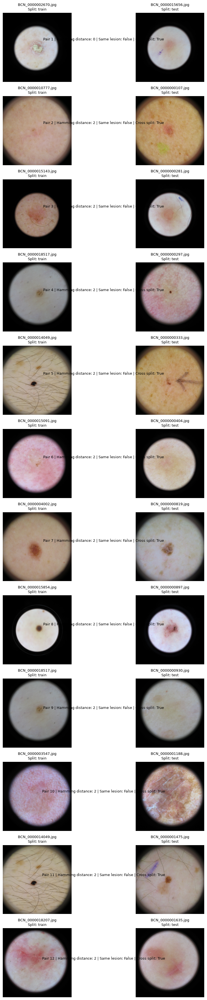

,filename_1,filename_2,lesion_id_1,lesion_id_2,hamming_distance,same_lesion,cross_split
0,BCN_0000002670.jpg,BCN_0000015656.jpg,BCN_0002947,BCN2778,0,False,True
1,BCN_0000010777.jpg,BCN_0000000107.jpg,BCN_0002196,BCN4242,2,False,True
2,BCN_0000015143.jpg,BCN_0000000281.jpg,BCN_0001710,BCN4441,2,False,True
3,BCN_0000018517.jpg,BCN_0000000297.jpg,BCN_0000473,BCN2506,2,False,True
4,BCN_0000014049.jpg,BCN_0000000333.jpg,BCN_0000361,BCN2068,2,False,True
5,BCN_0000015091.jpg,BCN_0000000404.jpg,BCN_0000961,BCN2714,2,False,True
6,BCN_0000004002.jpg,BCN_0000000819.jpg,BCN_0002123,BCN5188,2,False,True
7,BCN_0000015854.jpg,BCN_0000000897.jpg,BCN_0003229,BCN2361,2,False,True
8,BCN_0000018517.jpg,BCN_0000000930.jpg,BCN_0000473,BCN590,2,False,True
9,BCN_0000003547.jpg,BCN_0000001188.jpg,BCN_0001248,BCN1090,2,False,True



Visual review figure saved.


In [20]:
# ============================================================
# PHASE 02 - CELL 6
# NEAR-DUPLICATE VISUAL INSPECTION
# ============================================================

import matplotlib.pyplot as plt

print("=" * 70)
print("NEAR-DUPLICATE VISUAL REVIEW")
print("=" * 70)

if P2_NEAR_DUPLICATES.empty:

    print("No near-duplicate candidates available.")

else:

    # Cross-split candidates first
    review_df = (
        P2_NEAR_DUPLICATES
        .sort_values(
            ["cross_split", "hamming_distance"],
            ascending=[False, True]
        )
        .head(12)
        .reset_index(drop=True)
    )

    print("Candidate pairs for visual inspection:", len(review_df))

    fig, axes = plt.subplots(
        len(review_df),
        2,
        figsize=(12, max(4, len(review_df) * 3))
    )

    if len(review_df) == 1:
        axes = np.array([axes])

    for i, row in review_df.iterrows():

        for j, path in enumerate([
            row["path_1"],
            row["path_2"]
        ]):

            ax = axes[i, j]

            try:

                with Image.open(path) as img:
                    ax.imshow(img.convert("RGB"))

                ax.axis("off")

                ax.set_title(
                    f"{row['filename_' + str(j + 1)]}\n"
                    f"Split: {row['split_' + str(j + 1)]}",
                    fontsize=9
                )

            except Exception as error:

                ax.set_title(str(error)[:40])
                ax.axis("off")

        fig.text(
            0.5,
            1 - (i + 0.5) / len(review_df),
            (
                f"Pair {i+1} | "
                f"Hamming distance: {row['hamming_distance']} | "
                f"Same lesion: {row['same_lesion']} | "
                f"Cross split: {row['cross_split']}"
            ),
            ha="center",
            fontsize=9
        )

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / "phase02_near_duplicate_review.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()

    display(
        review_df[
            [
                "filename_1",
                "filename_2",
                "lesion_id_1",
                "lesion_id_2",
                "hamming_distance",
                "same_lesion",
                "cross_split"
            ]
        ]
    )

    print("\nVisual review figure saved.")

In [21]:
# ============================================================
# BCN20000 RESEARCH
# PHASE 02 - FINAL VERIFICATION & RESEARCH READINESS
# ============================================================

print("=" * 75)
print("       PHASE 02 - FINAL DATASET INTEGRITY REPORT")
print("=" * 75)

blockers = []
warnings_list = []
review_items = []

# ------------------------------------------------------------
# 1. IMAGE INTEGRITY
# ------------------------------------------------------------

train_inventory = P2_INVENTORY[
    P2_INVENTORY["split"] == "train"
]

test_inventory = P2_INVENTORY[
    P2_INVENTORY["split"] == "test"
]

invalid_train = int(
    (~train_inventory["valid"]).sum()
)

invalid_test = int(
    (~test_inventory["valid"]).sum()
)

print("\n[1] IMAGE INTEGRITY")

print("Training images audited:", len(train_inventory))
print("Valid training images:", int(train_inventory["valid"].sum()))
print("Invalid training images:", invalid_train)

print("\nTesting images audited:", len(test_inventory))
print("Valid testing images:", int(test_inventory["valid"].sum()))
print("Invalid testing images:", invalid_test)

if invalid_train > 0:

    blockers.append(
        f"{invalid_train} corrupted training images require investigation."
    )

if invalid_test > 0:

    warnings_list.append(
        f"{invalid_test} corrupted test images detected."
    )


# ------------------------------------------------------------
# 2. METADATA INTEGRITY
# ------------------------------------------------------------

print("\n[2] METADATA INTEGRITY")

missing_train_ids = int(
    train_meta["lesion_id"].isna().sum()
)

conflicting_labels = int(
    (
        train_meta.groupby("lesion_id")["diagnosis"]
        .nunique(dropna=True) > 1
    ).sum()
)

duplicate_train_names = int(
    train_meta["bcn_filename"].duplicated().sum()
)

print("Missing training lesion IDs:", missing_train_ids)
print("Conflicting lesion labels:", conflicting_labels)
print("Duplicate training filenames:", duplicate_train_names)

if missing_train_ids > 0:
    blockers.append("Missing training lesion IDs detected.")

if conflicting_labels > 0:
    blockers.append("Conflicting diagnosis labels detected.")

if duplicate_train_names > 0:
    blockers.append("Duplicate training filenames require investigation.")


# ------------------------------------------------------------
# 3. LESION-LEVEL LEAKAGE
# ------------------------------------------------------------

print("\n[3] LESION-LEVEL LEAKAGE")

train_ids = set(
    train_meta["lesion_id"].dropna().astype(str)
)

test_ids = set(
    test_meta["lesion_id"].dropna().astype(str)
)

lesion_overlap = len(
    train_ids.intersection(test_ids)
)

print("Training unique lesions:", len(train_ids))
print("Testing unique lesions:", len(test_ids))
print("Common lesion IDs:", lesion_overlap)

if lesion_overlap > 0:

    blockers.append(
        "Train-test lesion overlap detected."
    )


# ------------------------------------------------------------
# 4. EXACT DUPLICATE ANALYSIS
# ------------------------------------------------------------

print("\n[4] EXACT DUPLICATE ANALYSIS")

duplicate_groups = (
    P2_HASHED_INVENTORY
    .groupby("sha256")
    .filter(lambda group: len(group) > 1)
)

exact_groups = 0
train_exact_groups = 0
test_exact_groups = 0
cross_split_exact_groups = 0

if not duplicate_groups.empty:

    for sha, group in duplicate_groups.groupby("sha256"):

        exact_groups += 1

        splits = set(group["split"])

        if splits == {"train"}:
            train_exact_groups += 1

        elif splits == {"test"}:
            test_exact_groups += 1

        else:
            cross_split_exact_groups += 1

print("Total exact duplicate groups:", exact_groups)
print("Training-only duplicate groups:", train_exact_groups)
print("Testing-only duplicate groups:", test_exact_groups)
print("Cross-split exact duplicate groups:", cross_split_exact_groups)

if cross_split_exact_groups > 0:

    blockers.append(
        "Exact duplicate images found across training and testing."
    )

if train_exact_groups > 0:

    review_items.append(
        "Training contains exact duplicate image groups."
    )

if test_exact_groups > 0:

    warnings_list.append(
        "Exact duplicate groups found within test images."
    )


# ------------------------------------------------------------
# 5. NEAR-DUPLICATE ANALYSIS
# ------------------------------------------------------------

print("\n[5] NEAR-DUPLICATE ANALYSIS")

near_count = len(P2_NEAR_DUPLICATES)

if near_count > 0:

    cross_near = P2_NEAR_DUPLICATES[
        P2_NEAR_DUPLICATES["cross_split"]
    ]

    different_lesion_near = P2_NEAR_DUPLICATES[
        P2_NEAR_DUPLICATES["same_lesion"] == False
    ]

    unknown_lesion_near = P2_NEAR_DUPLICATES[
        P2_NEAR_DUPLICATES["same_lesion"].isna()
    ]

    same_lesion_near = P2_NEAR_DUPLICATES[
        P2_NEAR_DUPLICATES["same_lesion"] == True
    ]

else:

    cross_near = pd.DataFrame()
    different_lesion_near = pd.DataFrame()
    unknown_lesion_near = pd.DataFrame()
    same_lesion_near = pd.DataFrame()


print("Near-duplicate candidates:", near_count)
print("Cross-split near-duplicate pairs:", len(cross_near))
print("Different-lesion candidates:", len(different_lesion_near))
print("Unknown-lesion candidates:", len(unknown_lesion_near))
print("Same-lesion candidates:", len(same_lesion_near))

if len(cross_near) > 0:

    review_items.append(
        "Cross-split near-duplicate candidates need visual review."
    )

if len(different_lesion_near) > 0:

    review_items.append(
        "Different-lesion near-duplicate candidates need review."
    )

if len(unknown_lesion_near) > 0:

    review_items.append(
        "Near-duplicate candidates have incomplete lesion metadata."
    )


# ------------------------------------------------------------
# 6. IMAGE MATCHING
# ------------------------------------------------------------

print("\n[6] CSV-IMAGE MATCHING")

train_matching = train_match_report["matched"]
train_csv_total = train_match_report["csv_unique_filenames"]

test_matching = test_match_report["matched"]
test_csv_total = test_match_report["csv_unique_filenames"]

train_matching_rate = (
    train_matching / train_csv_total * 100
    if train_csv_total else 0
)

test_matching_rate = (
    test_matching / test_csv_total * 100
    if test_csv_total else 0
)

print(
    f"Training: {train_matching}/{train_csv_total} "
    f"({train_matching_rate:.2f}%)"
)

print(
    f"Testing: {test_matching}/{test_csv_total} "
    f"({test_matching_rate:.2f}%)"
)

if train_matching_rate < 100:

    blockers.append(
        "Training CSV-image matching is incomplete."
    )

if test_matching_rate < 100:

    warnings_list.append(
        "Some official test images are unavailable."
    )


# ------------------------------------------------------------
# 7. FINAL DECISION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PHASE 02 FINAL DECISION")
print("=" * 75)

if blockers:

    phase_status = "BLOCKED"

elif review_items:

    phase_status = "REVIEW_REQUIRED"

elif warnings_list:

    phase_status = "PASS_WITH_WARNINGS"

else:

    phase_status = "PASS"

phase3_allowed = (
    len(blockers) == 0
    and len(review_items) == 0
)

print("\nBLOCKERS:")

if blockers:

    for item in blockers:
        print("[BLOCKED]", item)

else:

    print("No critical blockers.")

print("\nMANUAL REVIEW ITEMS:")

if review_items:

    for item in review_items:
        print("[REVIEW]", item)

else:

    print("No pending duplicate review.")

print("\nWARNINGS:")

if warnings_list:

    for item in warnings_list:
        print("[WARNING]", item)

else:

    print("No warnings.")

print("\nPHASE STATUS:", phase_status)

print(
    "PHASE 03 ALLOWED:",
    "YES" if phase3_allowed else "NO - REVIEW FIRST"
)


# ------------------------------------------------------------
# 8. SAVE FINAL REPORT
# ------------------------------------------------------------

final_report = {

    "phase": "PHASE_02",

    "status": phase_status,

    "phase03_allowed": phase3_allowed,

    "image_integrity": {

        "train_audited": len(train_inventory),
        "train_invalid": invalid_train,

        "test_audited": len(test_inventory),
        "test_invalid": invalid_test

    },

    "metadata": {

        "missing_train_lesion_ids": missing_train_ids,
        "conflicting_labels": conflicting_labels,
        "duplicate_train_filenames": duplicate_train_names

    },

    "lesion_leakage": {

        "train_test_overlap": lesion_overlap

    },

    "exact_duplicates": {

        "total_groups": exact_groups,
        "train_groups": train_exact_groups,
        "test_groups": test_exact_groups,
        "cross_split_groups": cross_split_exact_groups

    },

    "near_duplicates": {

        "total_candidates": near_count,
        "cross_split_candidates": len(cross_near),
        "different_lesion_candidates": len(different_lesion_near),
        "unknown_lesion_candidates": len(unknown_lesion_near),
        "same_lesion_candidates": len(same_lesion_near)

    },

    "image_matching": {

        "train_percentage": round(train_matching_rate, 2),
        "test_percentage": round(test_matching_rate, 2)

    },

    "blockers": blockers,

    "review_items": review_items,

    "warnings": warnings_list

}

report_path = (
    REPORT_DIR / "PHASE_02_FINAL_VERIFICATION.json"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_report,
        f,
        indent=4
    )

print("\nFinal report saved:")
print(report_path)

print("=" * 75)
print("PHASE 02 VERIFICATION COMPLETED")
print("=" * 75)

       PHASE 02 - FINAL DATASET INTEGRITY REPORT

[1] IMAGE INTEGRITY
Training images audited: 12413
Valid training images: 12413
Invalid training images: 0

Testing images audited: 6501
Valid testing images: 6501
Invalid testing images: 0

[2] METADATA INTEGRITY
Missing training lesion IDs: 0
Conflicting lesion labels: 0
Duplicate training filenames: 0

[3] LESION-LEVEL LEAKAGE
Training unique lesions: 3576
Testing unique lesions: 1864
Common lesion IDs: 0

[4] EXACT DUPLICATE ANALYSIS
Total exact duplicate groups: 47
Training-only duplicate groups: 47
Testing-only duplicate groups: 0
Cross-split exact duplicate groups: 0

[5] NEAR-DUPLICATE ANALYSIS
Near-duplicate candidates: 2264
Cross-split near-duplicate pairs: 816
Different-lesion candidates: 1770
Unknown-lesion candidates: 0
Same-lesion candidates: 494

[6] CSV-IMAGE MATCHING
Training: 12413/12413 (100.00%)
Testing: 6501/6533 (99.51%)

PHASE 02 FINAL DECISION

BLOCKERS:
No critical blockers.

MANUAL REVIEW ITEMS:
[REVIEW] Traini

In [22]:
# ============================================================
# PHASE 02 - CELL 8
# EXACT DUPLICATE GROUP INVESTIGATION
# ============================================================

print("=" * 70)
print("EXACT DUPLICATE GROUP INVESTIGATION")
print("=" * 70)

hash_df = P2_HASHED_INVENTORY.copy()

# Find duplicate hash groups
duplicate_rows = hash_df[
    hash_df.duplicated("sha256", keep=False)
].copy()

group_reports = []

for sha, group in duplicate_rows.groupby("sha256"):

    lesion_ids = sorted(
        group["lesion_id"]
        .dropna()
        .astype(str)
        .unique()
    )

    diagnoses = sorted(
        group["diagnosis"]
        .dropna()
        .astype(str)
        .unique()
    )

    splits = sorted(
        group["split"].unique()
    )

    same_lesion = len(lesion_ids) == 1

    same_diagnosis = len(diagnoses) == 1

    if same_lesion and same_diagnosis:

        status = "SAME_LESION_SAME_DIAGNOSIS"

    elif len(lesion_ids) > 1 and same_diagnosis:

        status = "MULTIPLE_LESIONS_SAME_DIAGNOSIS"

    elif len(diagnoses) > 1:

        status = "CONFLICTING_DIAGNOSIS"

    else:

        status = "NEEDS_MANUAL_REVIEW"

    group_reports.append({

        "sha256": sha,

        "number_of_files": len(group),

        "filenames": " | ".join(
            group["filename"].tolist()
        ),

        "lesion_ids": " | ".join(lesion_ids),

        "diagnoses": " | ".join(diagnoses),

        "splits": " | ".join(splits),

        "same_lesion": same_lesion,

        "same_diagnosis": same_diagnosis,

        "cross_split": len(splits) > 1,

        "review_status": status

    })


P2_EXACT_GROUP_AUDIT = pd.DataFrame(
    group_reports
)

# Save report
P2_EXACT_GROUP_AUDIT.to_csv(
    REPORT_DIR / "phase02_exact_duplicate_group_audit.csv",
    index=False
)

print("\nTotal duplicate groups:", len(P2_EXACT_GROUP_AUDIT))

print("\nDuplicate group categories:")

display(
    P2_EXACT_GROUP_AUDIT[
        "review_status"
    ].value_counts().to_frame("Groups")
)

print("\nDetailed duplicate groups:")

display(
    P2_EXACT_GROUP_AUDIT[
        [
            "number_of_files",
            "lesion_ids",
            "diagnoses",
            "review_status"
        ]
    ]
)

print("\nSaved:")
print(
    REPORT_DIR / "phase02_exact_duplicate_group_audit.csv"
)

print("\nEXACT DUPLICATE INVESTIGATION COMPLETED.")

EXACT DUPLICATE GROUP INVESTIGATION

Total duplicate groups: 47

Duplicate group categories:


,Groups
review_status,
SAME_LESION_SAME_DIAGNOSIS,37
MULTIPLE_LESIONS_SAME_DIAGNOSIS,8
CONFLICTING_DIAGNOSIS,2



Detailed duplicate groups:


,number_of_files,lesion_ids,diagnoses,review_status
0,2,BCN_0004135,MEL,SAME_LESION_SAME_DIAGNOSIS
1,2,BCN_0004135,MEL,SAME_LESION_SAME_DIAGNOSIS
2,2,BCN_0004135,MEL,SAME_LESION_SAME_DIAGNOSIS
3,2,BCN_0003820,NV,SAME_LESION_SAME_DIAGNOSIS
4,2,BCN_0002646,BCC,SAME_LESION_SAME_DIAGNOSIS
5,2,BCN_0004135,MEL,SAME_LESION_SAME_DIAGNOSIS
6,2,BCN_0001154,AK,SAME_LESION_SAME_DIAGNOSIS
7,2,BCN_0003820,NV,SAME_LESION_SAME_DIAGNOSIS
8,2,BCN_0001300,BCC,SAME_LESION_SAME_DIAGNOSIS
9,2,BCN_0001154,AK,SAME_LESION_SAME_DIAGNOSIS



Saved:
d:\skin_research\outputs\reports\phase02_exact_duplicate_group_audit.csv

EXACT DUPLICATE INVESTIGATION COMPLETED.


In [23]:
# ============================================================
# PHASE 02 - CELL 9
# ROI-AWARE PERCEPTUAL HASH AUDIT
# ============================================================

import cv2
import imagehash
import numpy as np

from PIL import Image

print("=" * 70)
print("ROI-AWARE NEAR DUPLICATE DETECTION")
print("=" * 70)


def extract_dermoscopy_roi(image_path):

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError("Image could not be loaded.")

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    # Detect bright dermoscopic field
    _, binary = cv2.threshold(
        gray,
        18,
        255,
        cv2.THRESH_BINARY
    )

    contours = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )[-2]

    height, width = gray.shape

    if not contours:

        # Fallback: central crop
        x = int(width * 0.10)
        y = int(height * 0.10)

        roi = image[
            y:int(height * 0.90),
            x:int(width * 0.90)
        ]

        return Image.fromarray(
            cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)
        )

    contour = max(
        contours,
        key=cv2.contourArea
    )

    area_ratio = (
        cv2.contourArea(contour)
        / (width * height)
    )

    # Avoid unreliable full-frame segmentation
    if area_ratio < 0.20 or area_ratio > 0.98:

        x = int(width * 0.08)
        y = int(height * 0.08)

        roi = image[
            y:int(height * 0.92),
            x:int(width * 0.92)
        ]

        return Image.fromarray(
            cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)
        )

    x, y, w, h = cv2.boundingRect(contour)

    pad = max(
        2,
        int(min(w, h) * 0.02)
    )

    x1 = max(0, x - pad)
    y1 = max(0, y - pad)

    x2 = min(width, x + w + pad)
    y2 = min(height, y + h + pad)

    roi = image[y1:y2, x1:x2].copy()

    # Mask pixels outside the detected field
    contour_mask = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    cv2.drawContours(
        contour_mask,
        [contour],
        -1,
        255,
        thickness=cv2.FILLED
    )

    roi_mask = contour_mask[
        y1:y2,
        x1:x2
    ]

    valid_pixels = roi[
        roi_mask > 0
    ]

    if len(valid_pixels) > 0:

        fill_color = np.median(
            valid_pixels,
            axis=0
        ).astype(np.uint8)

        roi[roi_mask == 0] = fill_color

    return Image.fromarray(
        cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)
    )


# ------------------------------------------------------------
# 1. Calculate ROI-aware hashes
# ------------------------------------------------------------

roi_records = []

for row in tqdm(
    P2_HASHED_INVENTORY.itertuples(index=False),
    total=len(P2_HASHED_INVENTORY),
    desc="ROI hash calculation"
):

    try:

        roi = extract_dermoscopy_roi(row.path)

        ph = imagehash.phash(
            roi,
            hash_size=8
        )

        dh = imagehash.dhash(
            roi,
            hash_size=8
        )

        roi_records.append({

            "split": row.split,
            "filename": row.filename,
            "path": row.path,
            "lesion_id": row.lesion_id,
            "diagnosis": row.diagnosis,
            "sha256": row.sha256,

            "roi_phash": int(str(ph), 16),

            "roi_dhash": int(str(dh), 16)

        })

    except Exception as error:

        print(
            f"ROI hash error: {row.filename}: {error}"
        )


P2_ROI_HASHES = pd.DataFrame(
    roi_records
)

P2_ROI_HASHES.to_csv(
    REPORT_DIR / "phase02_roi_hash_manifest.csv",
    index=False
)


# ------------------------------------------------------------
# 2. Search candidate pairs
# ------------------------------------------------------------

roi_tree = BKTree()

roi_candidates = []

ROI_PHASH_THRESHOLD = 4
ROI_DHASH_THRESHOLD = 8

for row in tqdm(
    P2_ROI_HASHES.itertuples(index=False),
    total=len(P2_ROI_HASHES),
    desc="ROI similarity search"
):

    current_phash = int(row.roi_phash)
    current_dhash = int(row.roi_dhash)

    matches = roi_tree.search(
        current_phash,
        ROI_PHASH_THRESHOLD
    )

    for phash_distance, previous_items in matches:

        for previous in previous_items:

            # Exact duplicates are already audited
            if previous["sha256"] == row.sha256:
                continue

            dhash_distance = (
                previous["dhash"] ^ current_dhash
            ).bit_count()

            # Combined screening condition
            if dhash_distance > ROI_DHASH_THRESHOLD:
                continue

            if (
                pd.isna(previous["lesion_id"])
                or pd.isna(row.lesion_id)
            ):

                same_lesion = None

            else:

                same_lesion = (
                    str(previous["lesion_id"])
                    == str(row.lesion_id)
                )

            roi_candidates.append({

                "filename_1": previous["filename"],
                "filename_2": row.filename,

                "path_1": previous["path"],
                "path_2": row.path,

                "split_1": previous["split"],
                "split_2": row.split,

                "lesion_id_1": previous["lesion_id"],
                "lesion_id_2": row.lesion_id,

                "same_lesion": same_lesion,

                "cross_split": (
                    previous["split"] != row.split
                ),

                "phash_distance": phash_distance,

                "dhash_distance": dhash_distance

            })

    roi_tree.add(
        current_phash,
        {

            "filename": row.filename,
            "path": row.path,
            "split": row.split,
            "lesion_id": row.lesion_id,
            "sha256": row.sha256,
            "dhash": current_dhash

        }
    )


P2_ROI_NEAR_DUPLICATES = pd.DataFrame(
    roi_candidates
)

P2_ROI_NEAR_DUPLICATES.to_csv(
    REPORT_DIR / "phase02_roi_near_duplicate_candidates.csv",
    index=False
)


# ------------------------------------------------------------
# 3. Results
# ------------------------------------------------------------

print("\nROI HASHED IMAGES:", len(P2_ROI_HASHES))

print(
    "Combined near-duplicate candidates:",
    len(P2_ROI_NEAR_DUPLICATES)
)

if not P2_ROI_NEAR_DUPLICATES.empty:

    cross_split = P2_ROI_NEAR_DUPLICATES[
        P2_ROI_NEAR_DUPLICATES["cross_split"]
    ]

    print(
        "Cross-split candidates:",
        len(cross_split)
    )

    display(
        P2_ROI_NEAR_DUPLICATES.sort_values(
            ["phash_distance", "dhash_distance"]
        ).head(30)
    )

else:

    print("No combined near-duplicate candidates detected.")

print("\nROI-aware duplicate audit completed.")

ROI-AWARE NEAR DUPLICATE DETECTION


ROI hash calculation:   0%|          | 0/18914 [00:00<?, ?it/s]

ROI similarity search:   0%|          | 0/18914 [00:00<?, ?it/s]


ROI HASHED IMAGES: 18914
Combined near-duplicate candidates: 506
Cross-split candidates: 21


,filename_1,filename_2,path_1,path_2,split_1,split_2,lesion_id_1,lesion_id_2,same_lesion,cross_split,phash_distance,dhash_distance
19,BCN_0000000039.jpg,BCN_0000005106.jpg,d:\skin_research\bcn_20k_train\BCN_0000000039.jpg,d:\skin_research\bcn_20k_train\BCN_0000005106.jpg,train,train,BCN_0000509,BCN_0000509,True,False,0,0
22,BCN_0000001570.jpg,BCN_0000005256.jpg,d:\skin_research\bcn_20k_train\BCN_0000001570.jpg,d:\skin_research\bcn_20k_train\BCN_0000005256.jpg,train,train,BCN_0002549,BCN_0002549,True,False,0,0
23,BCN_0000002069.jpg,BCN_0000005353.jpg,d:\skin_research\bcn_20k_train\BCN_0000002069.jpg,d:\skin_research\bcn_20k_train\BCN_0000005353.jpg,train,train,BCN_0002577,BCN_0002577,True,False,0,0
222,BCN_0000014504.jpg,BCN_0000016157.jpg,d:\skin_research\bcn_20k_train\BCN_0000014504.jpg,d:\skin_research\bcn_20k_train\BCN_0000016157.jpg,train,train,BCN_0002560,BCN_0002560,True,False,0,0
239,BCN_0000016499.jpg,BCN_0000016574.jpg,d:\skin_research\bcn_20k_train\BCN_0000016499.jpg,d:\skin_research\bcn_20k_train\BCN_0000016574.jpg,train,train,BCN_0001445,BCN_0001445,True,False,0,0
301,BCN_0000001289.jpg,BCN_0000018970.jpg,d:\skin_research\bcn_20k_train\BCN_0000001289.jpg,d:\skin_research\bcn_20k_train\BCN_0000018970.jpg,train,train,BCN_0003656,BCN_0003656,True,False,0,0
309,BCN_0000013972.jpg,BCN_0000019193.jpg,d:\skin_research\bcn_20k_train\BCN_0000013972.jpg,d:\skin_research\bcn_20k_train\BCN_0000019193.jpg,train,train,BCN_0001439,BCN_0001439,True,False,0,0
455,BCN_0000000067.jpg,BCN_0000017070.jpg,d:\skin_research\bcn_20k_test\BCN_0000000067.jpg,d:\skin_research\bcn_20k_test\BCN_0000017070.jpg,test,test,BCN2709,BCN2709,True,False,0,0
30,BCN_0000005479.jpg,BCN_0000006108.jpg,d:\skin_research\bcn_20k_train\BCN_0000005479.jpg,d:\skin_research\bcn_20k_train\BCN_0000006108.jpg,train,train,BCN_0005080,BCN_0005080,True,False,0,1
169,BCN_0000003497.jpg,BCN_0000013951.jpg,d:\skin_research\bcn_20k_train\BCN_0000003497.jpg,d:\skin_research\bcn_20k_train\BCN_0000013951.jpg,train,train,BCN_0005541,BCN_0005541,True,False,0,1



ROI-aware duplicate audit completed.


CONFLICTING DIAGNOSIS INVESTIGATION
Conflicting duplicate groups: 2

------------------------------------------------------------
CONFLICT GROUP: 10
SHA256: 33d39335eecc56d338aafb996cddadfacc26cd92384f2c4a36212e47ab8659c6


,filename,split,lesion_id,diagnosis,path
8772,BCN_0000014439.jpg,train,BCN_0003560,MEL,d:\skin_research\bcn_20k_train\BCN_0000014439.jpg
9070,BCN_0000014930.jpg,train,BCN_0000237,NV,d:\skin_research\bcn_20k_train\BCN_0000014930.jpg


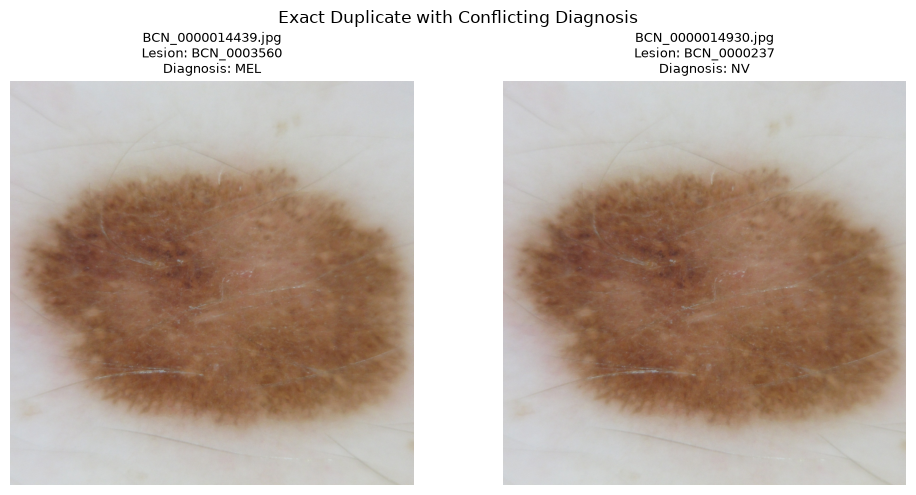


------------------------------------------------------------
CONFLICT GROUP: 42
SHA256: d541d12ddc9cc7783ecf20e0c565e811e682634be5d8be9decca0032039f8ff8


,filename,split,lesion_id,diagnosis,path
9738,BCN_0000015995.jpg,train,BCN_0000237,NV,d:\skin_research\bcn_20k_train\BCN_0000015995.jpg
11001,BCN_0000018062.jpg,train,BCN_0003560,MEL,d:\skin_research\bcn_20k_train\BCN_0000018062.jpg


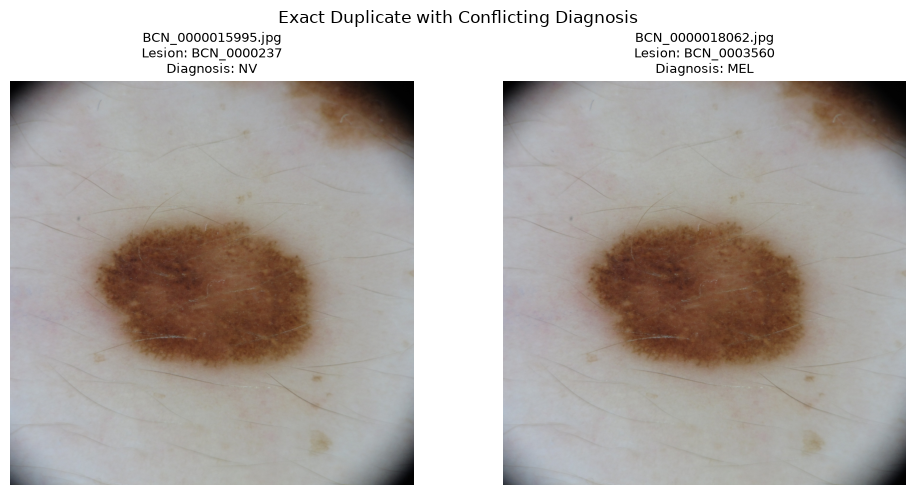


Conflicting diagnosis inspection completed.


In [24]:
# ============================================================
# PHASE 02 - CELL 10
# CONFLICTING DIAGNOSIS INVESTIGATION
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

REPORT_DIR = Path("outputs/reports")

audit = pd.read_csv(
    REPORT_DIR / "phase02_exact_duplicate_group_audit.csv"
)

hash_manifest = pd.read_csv(
    REPORT_DIR / "phase02_sha256_manifest.csv"
)

conflicts = audit[
    audit["review_status"] == "CONFLICTING_DIAGNOSIS"
].copy()

print("=" * 70)
print("CONFLICTING DIAGNOSIS INVESTIGATION")
print("=" * 70)

print("Conflicting duplicate groups:", len(conflicts))

for index, group in conflicts.iterrows():

    sha = group["sha256"]

    rows = hash_manifest[
        hash_manifest["sha256"] == sha
    ].copy()

    print("\n" + "-" * 60)
    print("CONFLICT GROUP:", index)
    print("SHA256:", sha)

    display(
        rows[
            [
                "filename",
                "split",
                "lesion_id",
                "diagnosis",
                "path"
            ]
        ]
    )

    # Visual comparison
    fig, axes = plt.subplots(
        1,
        len(rows),
        figsize=(10, 5)
    )

    if len(rows) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, rows.iterrows()):

        with Image.open(row["path"]) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"{row['filename']}\n"
            f"Lesion: {row['lesion_id']}\n"
            f"Diagnosis: {row['diagnosis']}",
            fontsize=9
        )

        ax.axis("off")

    plt.suptitle(
        "Exact Duplicate with Conflicting Diagnosis"
    )

    plt.tight_layout()
    plt.show()

print("\nConflicting diagnosis inspection completed.")

CROSS-SPLIT NEAR-DUPLICATE REVIEW
Total cross-split candidates: 21


,filename_1,filename_2,lesion_id_1,lesion_id_2,phash_distance,dhash_distance
0,BCN_0000010777.jpg,BCN_0000004188.jpg,BCN_0002196,BCN5092,2,5
1,BCN_0000011655.jpg,BCN_0000001240.jpg,BCN_0001171,BCN3906,4,1
2,BCN_0000011572.jpg,BCN_0000013487.jpg,BCN_0003872,BCN166,4,2
3,BCN_0000001904.jpg,BCN_0000014370.jpg,BCN_0004504,BCN2451,4,2
4,BCN_0000000961.jpg,BCN_0000008990.jpg,BCN_0005605,BCN3457,4,3
5,BCN_0000016554.jpg,BCN_0000010245.jpg,BCN_0001427,BCN3007,4,6
6,BCN_0000001337.jpg,BCN_0000013415.jpg,BCN_0003607,BCN4745,4,6
7,BCN_0000015873.jpg,BCN_0000016900.jpg,BCN_0004652,BCN4894,4,6
8,BCN_0000017858.jpg,BCN_0000001396.jpg,BCN_0002348,BCN183,4,7
9,BCN_0000009912.jpg,BCN_0000001973.jpg,BCN_0001474,BCN1404,4,7


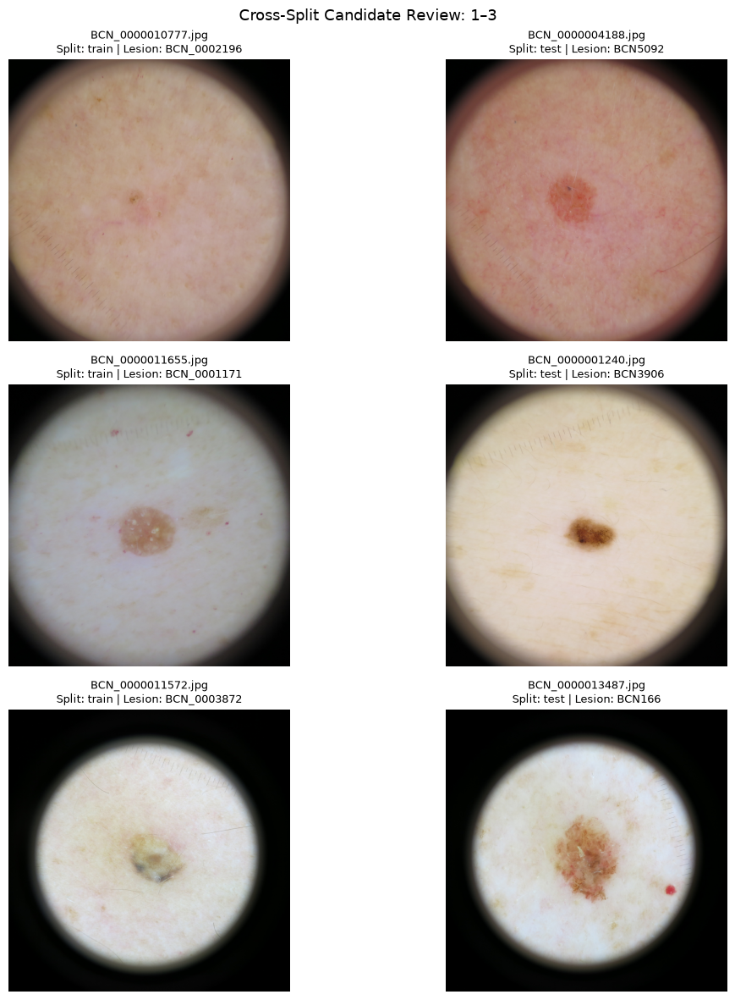

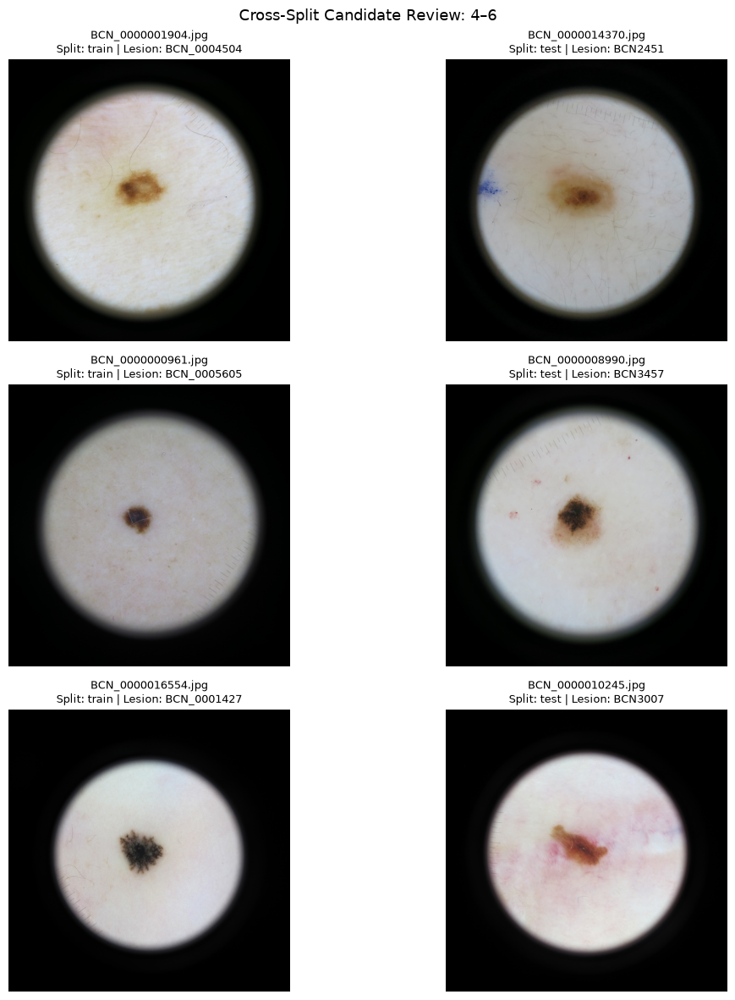

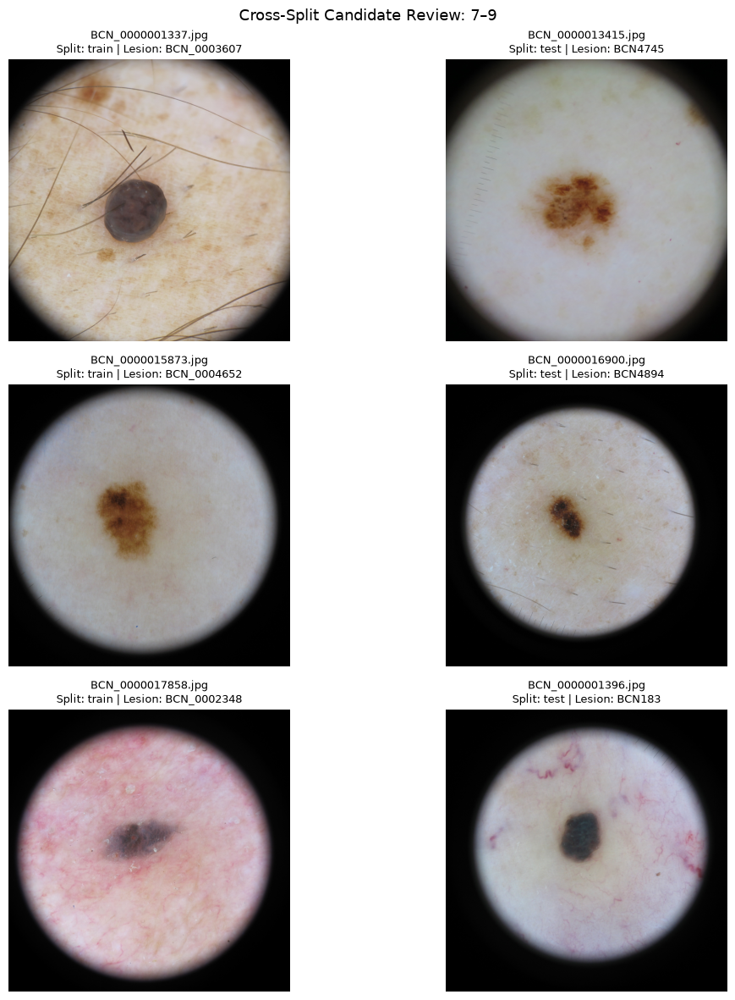

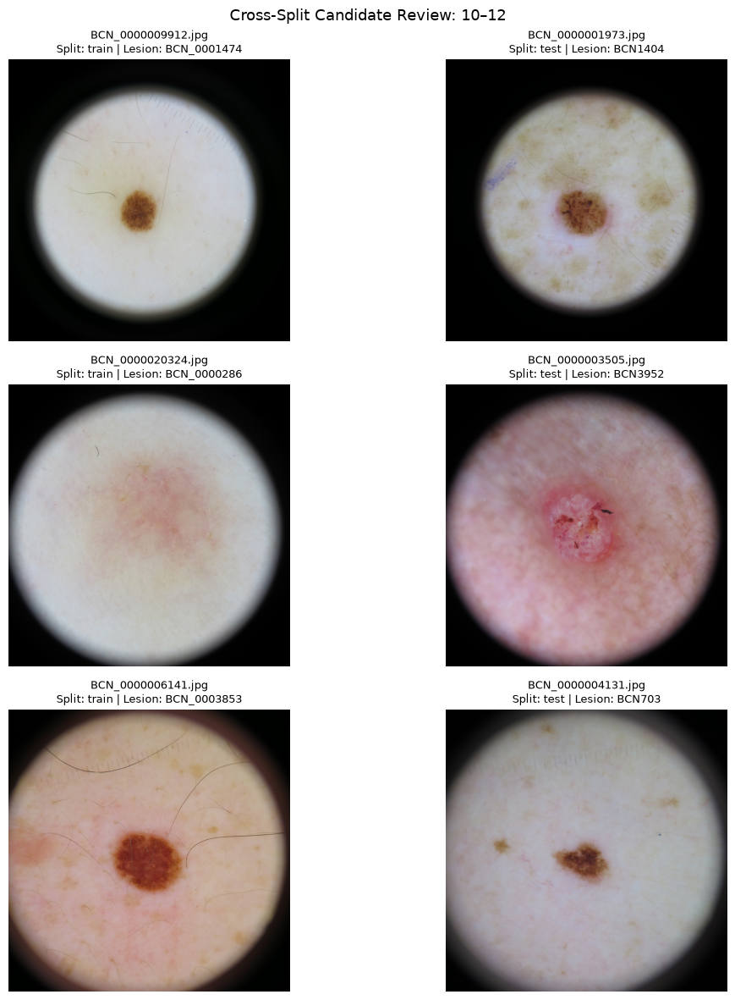

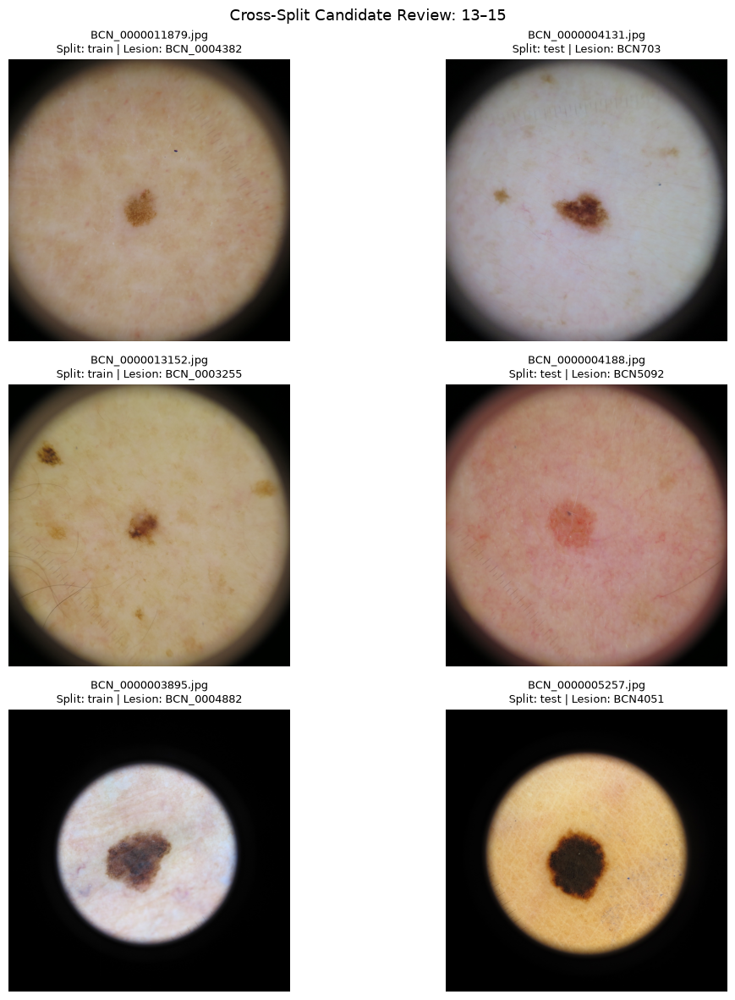

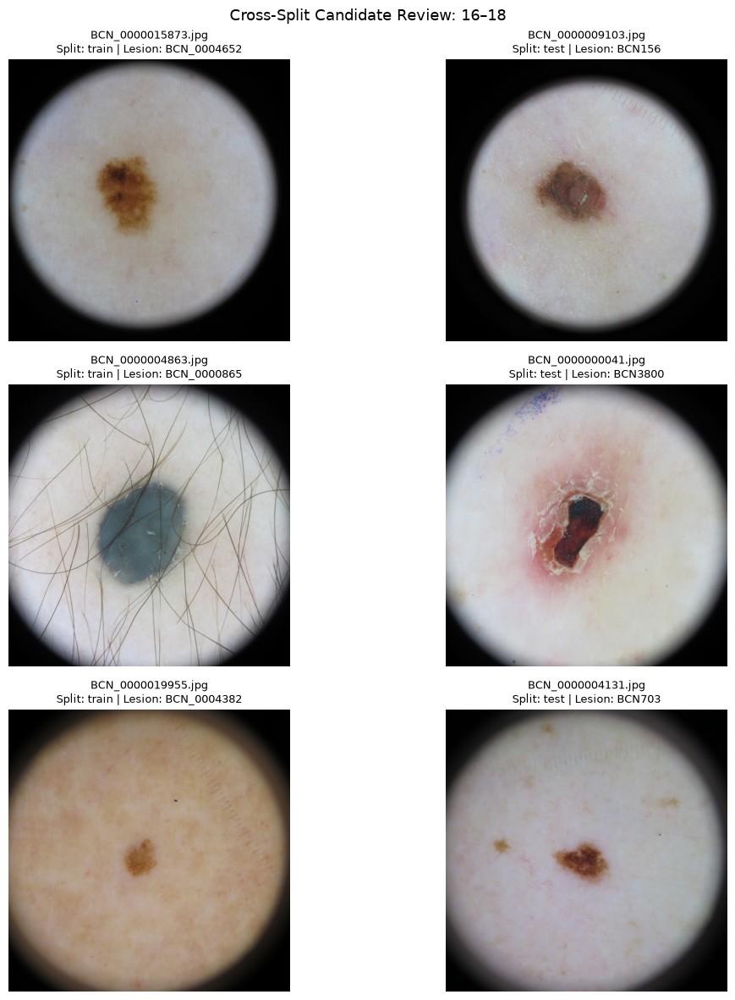

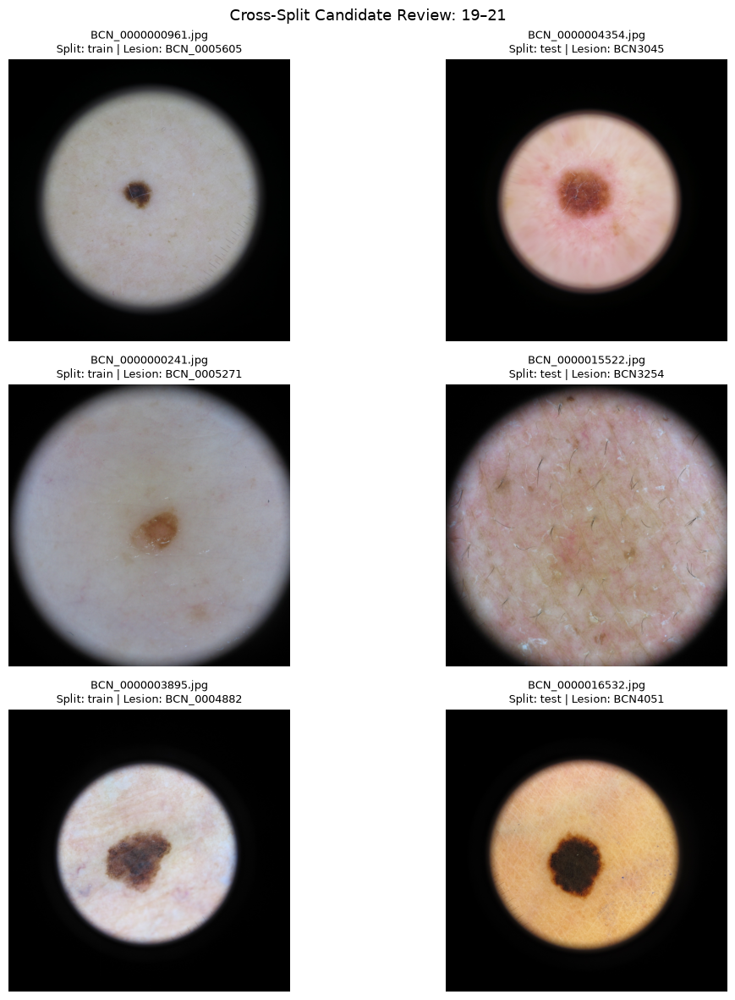


Review PDF saved:
outputs\figures\phase02_cross_split_review.pdf

Manual visual review required.


In [25]:
# ============================================================
# PHASE 02 - CELL 11
# CROSS-SPLIT NEAR-DUPLICATE REVIEW
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from matplotlib.backends.backend_pdf import PdfPages

REPORT_DIR = Path("outputs/reports")
FIGURE_DIR = Path("outputs/figures")

roi_candidates = pd.read_csv(
    REPORT_DIR / "phase02_roi_near_duplicate_candidates.csv"
)

cross_candidates = roi_candidates[
    roi_candidates["cross_split"] == True
].copy()

cross_candidates = cross_candidates.sort_values(
    ["phash_distance", "dhash_distance"]
).reset_index(drop=True)

print("=" * 70)
print("CROSS-SPLIT NEAR-DUPLICATE REVIEW")
print("=" * 70)

print("Total cross-split candidates:", len(cross_candidates))

display(
    cross_candidates[
        [
            "filename_1",
            "filename_2",
            "lesion_id_1",
            "lesion_id_2",
            "phash_distance",
            "dhash_distance"
        ]
    ]
)

# Create a multi-page PDF for manual review
pdf_path = (
    FIGURE_DIR / "phase02_cross_split_review.pdf"
)

with PdfPages(pdf_path) as pdf:

    for start in range(0, len(cross_candidates), 3):

        page = cross_candidates.iloc[
            start:start + 3
        ]

        fig, axes = plt.subplots(
            len(page),
            2,
            figsize=(12, 4 * len(page))
        )

        if len(page) == 1:
            axes = [axes]

        for ax_row, (_, row) in zip(
            axes,
            page.iterrows()
        ):

            for ax, path, filename, split, lesion in zip(
                ax_row,
                [row["path_1"], row["path_2"]],
                [row["filename_1"], row["filename_2"]],
                [row["split_1"], row["split_2"]],
                [row["lesion_id_1"], row["lesion_id_2"]]
            ):

                with Image.open(path) as img:
                    ax.imshow(img.convert("RGB"))

                ax.set_title(
                    f"{filename}\n"
                    f"Split: {split} | Lesion: {lesion}",
                    fontsize=9
                )

                ax.axis("off")

            ax_row[0].set_ylabel(
                f"pHash: {row['phash_distance']} | "
                f"dHash: {row['dhash_distance']}",
                fontsize=9
            )

        fig.suptitle(
            f"Cross-Split Candidate Review: "
            f"{start+1}–{start+len(page)}",
            fontsize=13
        )

        plt.tight_layout()

        pdf.savefig(fig)
        plt.show()
        plt.close(fig)

print("\nReview PDF saved:")
print(pdf_path)

print("\nManual visual review required.")

In [26]:
# ============================================================
# PHASE 02 - CELL 12
# COMPLETE CONFLICTING LESION INVESTIGATION
# ============================================================

from pathlib import Path
import pandas as pd

REPORT_DIR = Path("outputs/reports")

audit_df = pd.read_csv(
    REPORT_DIR / "phase02_exact_duplicate_group_audit.csv"
)

hash_df = pd.read_csv(
    REPORT_DIR / "phase02_sha256_manifest.csv"
)

train_df = pd.read_csv(
    "bcn_20k_train.csv"
)

conflict_groups = audit_df[
    audit_df["review_status"] == "CONFLICTING_DIAGNOSIS"
].copy()

print("=" * 75)
print("COMPLETE CONFLICTING LESION INVESTIGATION")
print("=" * 75)

print("Conflicting groups:", len(conflict_groups))

all_related_records = []

for group_number, (_, group) in enumerate(
    conflict_groups.iterrows(),
    start=1
):

    sha = group["sha256"]

    duplicate_records = hash_df[
        hash_df["sha256"] == sha
    ].copy()

    lesion_ids = (
        duplicate_records["lesion_id"]
        .dropna()
        .astype(str)
        .unique()
    )

    print("\n" + "=" * 65)
    print(f"CONFLICT GROUP {group_number}")
    print("SHA256:", sha)

    print("\nExact duplicate records:")
    display(
        duplicate_records[
            [
                "filename",
                "lesion_id",
                "diagnosis",
                "split",
                "path"
            ]
        ]
    )

    # Inspect every image belonging to each affected lesion
    for lesion_id in lesion_ids:

        lesion_images = train_df[
            train_df["lesion_id"].astype(str)
            == str(lesion_id)
        ].copy()

        print("\nLesion ID:", lesion_id)

        print("Total metadata images:", len(lesion_images))

        print(
            "Diagnosis distribution:",
            lesion_images["diagnosis"].value_counts().to_dict()
        )

        display(
            lesion_images[
                [
                    "bcn_filename",
                    "lesion_id",
                    "diagnosis"
                ]
            ]
        )

        for _, record in lesion_images.iterrows():

            all_related_records.append({

                "conflict_group": group_number,

                "lesion_id": lesion_id,

                "filename": record["bcn_filename"],

                "diagnosis": record["diagnosis"],

                "is_conflicting_hash": (
                    str(record["bcn_filename"]).casefold()
                    in set(
                        duplicate_records["filename"]
                        .astype(str).str.casefold()
                    )
                )

            })


# ------------------------------------------------------------
# SAVE INVESTIGATION
# ------------------------------------------------------------

conflict_detail = pd.DataFrame(
    all_related_records
)

conflict_detail.to_csv(
    REPORT_DIR / "phase02_conflicting_lesion_details.csv",
    index=False
)

print("\n" + "=" * 75)
print("CONFLICT INVESTIGATION COMPLETED")
print("=" * 75)

print("Total related lesion records:", len(conflict_detail))

print(
    "Conflicting image records:",
    int(conflict_detail["is_conflicting_hash"].sum())
)

print(
    "Other distinct image records:",
    int((~conflict_detail["is_conflicting_hash"]).sum())
)

print("\nSaved:")
print(
    REPORT_DIR / "phase02_conflicting_lesion_details.csv"
)

COMPLETE CONFLICTING LESION INVESTIGATION
Conflicting groups: 2

CONFLICT GROUP 1
SHA256: 33d39335eecc56d338aafb996cddadfacc26cd92384f2c4a36212e47ab8659c6

Exact duplicate records:


,filename,lesion_id,diagnosis,split,path
8772,BCN_0000014439.jpg,BCN_0003560,MEL,train,d:\skin_research\bcn_20k_train\BCN_0000014439.jpg
9070,BCN_0000014930.jpg,BCN_0000237,NV,train,d:\skin_research\bcn_20k_train\BCN_0000014930.jpg



Lesion ID: BCN_0003560
Total metadata images: 2
Diagnosis distribution: {'MEL': 2}


,bcn_filename,lesion_id,diagnosis
8772,BCN_0000014439.jpg,BCN_0003560,MEL
11001,BCN_0000018062.jpg,BCN_0003560,MEL



Lesion ID: BCN_0000237
Total metadata images: 2
Diagnosis distribution: {'NV': 2}


,bcn_filename,lesion_id,diagnosis
9070,BCN_0000014930.jpg,BCN_0000237,NV
9738,BCN_0000015995.jpg,BCN_0000237,NV


... (3 outputs left out)

,bcn_filename,lesion_id,diagnosis
9070,BCN_0000014930.jpg,BCN_0000237,NV
9738,BCN_0000015995.jpg,BCN_0000237,NV



Lesion ID: BCN_0003560
Total metadata images: 2
Diagnosis distribution: {'MEL': 2}


,bcn_filename,lesion_id,diagnosis
8772,BCN_0000014439.jpg,BCN_0003560,MEL
11001,BCN_0000018062.jpg,BCN_0003560,MEL



CONFLICT INVESTIGATION COMPLETED
Total related lesion records: 8
Conflicting image records: 4
Other distinct image records: 4

Saved:
outputs\reports\phase02_conflicting_lesion_details.csv


In [27]:
# ============================================================
# PHASE 02 - CELL 13
# COMPLETE CROSS-LESION DUPLICATE INVESTIGATION
# ============================================================

import pandas as pd
import json

from pathlib import Path

REPORT_DIR = Path("outputs/reports")

# Load existing audit files
exact_groups = pd.read_csv(
    REPORT_DIR / "phase02_exact_duplicate_group_audit.csv"
)

hash_manifest = pd.read_csv(
    REPORT_DIR / "phase02_sha256_manifest.csv"
)

train_metadata = pd.read_csv(
    "bcn_20k_train.csv"
)

print("=" * 75)
print("CROSS-LESION EXACT DUPLICATE INVESTIGATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Identify groups involving multiple lesion IDs
# ------------------------------------------------------------

cross_lesion_groups = exact_groups[
    exact_groups["review_status"].isin([
        "MULTIPLE_LESIONS_SAME_DIAGNOSIS",
        "CONFLICTING_DIAGNOSIS"
    ])
].copy()

print(
    "Cross-lesion duplicate groups:",
    len(cross_lesion_groups)
)

all_details = []

# ------------------------------------------------------------
# 2. Inspect each exact duplicate group
# ------------------------------------------------------------

for group_number, (_, group) in enumerate(
    cross_lesion_groups.iterrows(),
    start=1
):

    sha = group["sha256"]

    duplicate_records = hash_manifest[
        hash_manifest["sha256"] == sha
    ].copy()

    lesion_ids = (
        duplicate_records["lesion_id"]
        .dropna()
        .astype(str)
        .unique()
    )

    print("\n" + "=" * 65)

    print("GROUP:", group_number)

    print("Review status:", group["review_status"])

    print("SHA256:", sha)

    print("\nExact duplicate files:")

    display(
        duplicate_records[
            [
                "filename",
                "lesion_id",
                "diagnosis",
                "split"
            ]
        ]
    )

    # --------------------------------------------------------
    # 3. Inspect all metadata for associated lesions
    # --------------------------------------------------------

    related = train_metadata[
        train_metadata["lesion_id"]
        .astype(str)
        .isin(lesion_ids)
    ].copy()

    print("\nComplete associated lesion metadata:")

    display(
        related.sort_values(
            ["lesion_id", "bcn_filename"]
        )
    )

    # --------------------------------------------------------
    # 4. Compare metadata between associated lesions
    # --------------------------------------------------------

    metadata_summary = (
        related.groupby("lesion_id")
        .agg({

            "diagnosis": lambda x: sorted(
                x.dropna().astype(str).unique()
            ),

            "age_approx": lambda x: sorted(
                x.dropna().unique().tolist()
            ),

            "anatom_site_general": lambda x: sorted(
                x.dropna().astype(str).unique()
            ),

            "sex": lambda x: sorted(
                x.dropna().astype(str).unique()
            ),

            "capture_date": lambda x: sorted(
                x.dropna().astype(str).unique()
            ),

            "bcn_filename": "count"

        })
        .reset_index()
    )

    print("\nLesion-level metadata comparison:")

    display(metadata_summary)

    # --------------------------------------------------------
    # 5. Save detailed records
    # --------------------------------------------------------

    for _, row in related.iterrows():

        all_details.append({

            "duplicate_group": group_number,

            "sha256": sha,

            "review_status": group["review_status"],

            "lesion_id": row["lesion_id"],

            "filename": row["bcn_filename"],

            "diagnosis": row["diagnosis"],

            "age_approx": row["age_approx"],

            "anatom_site_general": row[
                "anatom_site_general"
            ],

            "sex": row["sex"],

            "capture_date": row["capture_date"]

        })


# ------------------------------------------------------------
# 6. Save complete investigation report
# ------------------------------------------------------------

details_df = pd.DataFrame(all_details)

output_path = (
    REPORT_DIR /
    "phase02_cross_lesion_metadata_investigation.csv"
)

details_df.to_csv(
    output_path,
    index=False
)

print("\n" + "=" * 75)

print("TOTAL RELATED RECORDS:", len(details_df))

print("Report saved:", output_path)

print("CROSS-LESION INVESTIGATION COMPLETED")

print("=" * 75)

CROSS-LESION EXACT DUPLICATE INVESTIGATION
Cross-lesion duplicate groups: 10

GROUP: 1
Review status: CONFLICTING_DIAGNOSIS
SHA256: 33d39335eecc56d338aafb996cddadfacc26cd92384f2c4a36212e47ab8659c6

Exact duplicate files:


,filename,lesion_id,diagnosis,split
8772,BCN_0000014439.jpg,BCN_0003560,MEL,train
9070,BCN_0000014930.jpg,BCN_0000237,NV,train



Complete associated lesion metadata:


,bcn_filename,age_approx,anatom_site_general,diagnosis,lesion_id,capture_date,sex,split
9070,BCN_0000014930.jpg,40.0,anterior torso,NV,BCN_0000237,2014-07-22,male,train
9738,BCN_0000015995.jpg,40.0,anterior torso,NV,BCN_0000237,2014-07-22,male,train
8772,BCN_0000014439.jpg,20.0,anterior torso,MEL,BCN_0003560,2014-07-08,female,train
11001,BCN_0000018062.jpg,20.0,anterior torso,MEL,BCN_0003560,2014-07-08,female,train



Lesion-level metadata comparison:


,lesion_id,diagnosis,age_approx,anatom_site_general,sex,capture_date,bcn_filename
0,BCN_0000237,[NV],[40.0],[anterior torso],[male],[2014-07-22],2
1,BCN_0003560,[MEL],[20.0],[anterior torso],[female],[2014-07-08],2


... (51 outputs left out)

,bcn_filename,age_approx,anatom_site_general,diagnosis,lesion_id,capture_date,sex,split
9070,BCN_0000014930.jpg,40.0,anterior torso,NV,BCN_0000237,2014-07-22,male,train
9738,BCN_0000015995.jpg,40.0,anterior torso,NV,BCN_0000237,2014-07-22,male,train
8772,BCN_0000014439.jpg,20.0,anterior torso,MEL,BCN_0003560,2014-07-08,female,train
11001,BCN_0000018062.jpg,20.0,anterior torso,MEL,BCN_0003560,2014-07-08,female,train



Lesion-level metadata comparison:


,lesion_id,diagnosis,age_approx,anatom_site_general,sex,capture_date,bcn_filename
0,BCN_0000237,[NV],[40.0],[anterior torso],[male],[2014-07-22],2
1,BCN_0003560,[MEL],[20.0],[anterior torso],[female],[2014-07-08],2



TOTAL RELATED RECORDS: 76
Report saved: outputs\reports\phase02_cross_lesion_metadata_investigation.csv
CROSS-LESION INVESTIGATION COMPLETED


In [28]:
# ================================================================
# BCN20000 RESEARCH
# PHASE 02 - CELL 14
# DUPLICATE RESOLUTION & CLEANED TRAINING MANIFEST
# ================================================================

import json
import pandas as pd
import numpy as np

from pathlib import Path

print("=" * 75)
print("PHASE 02 - DUPLICATE RESOLUTION")
print("=" * 75)

# ------------------------------------------------------------
# 1. LOAD ORIGINAL METADATA AND HASH MANIFEST
# ------------------------------------------------------------

ROOT = Path.cwd()

REPORT_DIR = ROOT / "outputs" / "reports"

train_meta = pd.read_csv(
    ROOT / "bcn_20k_train.csv",
    low_memory=False
)

hash_manifest = pd.read_csv(
    REPORT_DIR / "phase02_sha256_manifest.csv"
)

# Only training images
hash_train = hash_manifest[
    hash_manifest["split"].astype(str).str.lower() == "train"
].copy()


# ------------------------------------------------------------
# 2. NORMALIZE FILENAMES
# ------------------------------------------------------------

def normalize_file(value):

    if pd.isna(value):
        return None

    return Path(
        str(value).strip().replace("\\", "/")
    ).name.casefold()


train_meta["_filename_key"] = (
    train_meta["bcn_filename"].apply(normalize_file)
)

hash_train["_filename_key"] = (
    hash_train["filename"].apply(normalize_file)
)

# Validate unique filename mapping
if train_meta["_filename_key"].duplicated().any():

    raise ValueError(
        "Duplicate filenames found in training metadata."
    )

if hash_train["_filename_key"].duplicated().any():

    raise ValueError(
        "Duplicate filenames found in SHA manifest."
    )


# ------------------------------------------------------------
# 3. MERGE HASH INFORMATION
# ------------------------------------------------------------

merged = train_meta.merge(

    hash_train[
        [
            "_filename_key",
            "path",
            "sha256"
        ]
    ],

    on="_filename_key",

    how="left",

    validate="one_to_one",

    indicator=True

)

unmatched_hash_records = int(
    (merged["_merge"] != "both").sum()
)

print("Original training records:", len(merged))
print("Records without SHA hash:", unmatched_hash_records)

if unmatched_hash_records > 0:

    raise ValueError(
        "Some training records do not have SHA-256 hashes. "
        "Resolve before cleaning."
    )

merged.drop(columns=["_merge"], inplace=True)

merged["lesion_id"] = (
    merged["lesion_id"].astype(str)
)

merged["diagnosis"] = (
    merged["diagnosis"].astype(str)
)


# ------------------------------------------------------------
# 4. IDENTIFY EXACT DUPLICATE GROUPS
# ------------------------------------------------------------

hash_statistics = (

    merged.groupby("sha256")

    .agg(

        file_count=("bcn_filename", "count"),

        lesion_count=("lesion_id", "nunique"),

        diagnosis_count=("diagnosis", "nunique")

    )

    .reset_index()

)

exact_duplicate_groups = hash_statistics[
    hash_statistics["file_count"] > 1
]

conflicting_hashes = set(

    hash_statistics.loc[
        hash_statistics["diagnosis_count"] > 1,
        "sha256"
    ]

)

print("\nExact duplicate groups:", len(exact_duplicate_groups))

print("Conflicting SHA groups:", len(conflicting_hashes))


# ------------------------------------------------------------
# 5. QUARANTINE CONFLICTING LESIONS
# ------------------------------------------------------------

conflict_records = merged[
    merged["sha256"].isin(conflicting_hashes)
]

quarantine_lesion_ids = set(
    conflict_records["lesion_id"].unique()
)

quarantine_df = merged[
    merged["lesion_id"].isin(
        quarantine_lesion_ids
    )
].copy()

quarantine_df["quarantine_reason"] = (
    "Exact image content associated with conflicting diagnosis labels"
)

eligible_df = merged[
    ~merged["lesion_id"].isin(
        quarantine_lesion_ids
    )
].copy()

print("\nQuarantine lesion IDs:")
print(sorted(quarantine_lesion_ids))

print("Quarantined lesion count:", len(quarantine_lesion_ids))
print("Quarantined image records:", len(quarantine_df))

print("Remaining records:", len(eligible_df))


# ------------------------------------------------------------
# 6. VERIFY NO LABEL CONFLICT REMAINS
# ------------------------------------------------------------

remaining_label_conflicts = (

    eligible_df.groupby("sha256")["diagnosis"]

    .nunique()

)

remaining_label_conflicts = int(
    (remaining_label_conflicts > 1).sum()
)

if remaining_label_conflicts > 0:

    raise ValueError(
        "Conflicting labels still remain after quarantine."
    )


# ------------------------------------------------------------
# 7. BUILD LEAKAGE GROUPS USING UNION-FIND
# ------------------------------------------------------------

# IMPORTANT:
# These are evaluation grouping IDs, not new biological
# lesion identities.

parent = {
    lesion_id: lesion_id
    for lesion_id in eligible_df["lesion_id"].unique()
}


def find_root(x):

    if parent[x] != x:

        parent[x] = find_root(parent[x])

    return parent[x]


def union_groups(a, b):

    root_a = find_root(a)
    root_b = find_root(b)

    if root_a == root_b:
        return

    # Deterministic root selection
    if root_a < root_b:

        parent[root_b] = root_a

    else:

        parent[root_a] = root_b


# Link lesion IDs sharing exact image content
for sha, group in eligible_df.groupby("sha256"):

    lesion_ids = sorted(
        group["lesion_id"].unique()
    )

    if len(lesion_ids) > 1:

        first_id = lesion_ids[0]

        for other_id in lesion_ids[1:]:

            union_groups(first_id, other_id)


# Construct connected components
components = {}

for lesion_id in parent:

    root = find_root(lesion_id)

    components.setdefault(root, []).append(
        lesion_id
    )


lesion_to_group = {}

for members in components.values():

    stable_id = "LG_" + min(members)

    for lesion_id in members:

        lesion_to_group[lesion_id] = stable_id


lesion_group_mapping = pd.DataFrame({

    "original_lesion_id": list(
        lesion_to_group.keys()
    ),

    "leakage_group_id": list(
        lesion_to_group.values()
    )

})


# ------------------------------------------------------------
# 8. CREATE ONE CANONICAL RECORD PER EXACT IMAGE
# ------------------------------------------------------------

clean_records = []

resolution_records = []

for sha, group in eligible_df.groupby(
    "sha256",
    sort=True
):

    group = group.sort_values(
        "bcn_filename"
    ).copy()

    # Diagnosis must be consistent
    if group["diagnosis"].nunique() != 1:

        raise ValueError(
            f"Diagnosis conflict detected for SHA: {sha}"
        )

    canonical = group.iloc[0].copy()

    source_lesions = sorted(
        group["lesion_id"].unique()
    )

    source_filenames = sorted(
        group["bcn_filename"].unique()
    )

    group_ids = {
        lesion_to_group[x]
        for x in source_lesions
    }

    if len(group_ids) != 1:

        raise ValueError(
            "A duplicate image group maps to multiple leakage groups."
        )

    leakage_group_id = next(iter(group_ids))

    # Create canonical record
    record = canonical.to_dict()

    record["leakage_group_id"] = leakage_group_id

    record["source_lesion_ids"] = json.dumps(
        source_lesions
    )

    record["source_filenames"] = json.dumps(
        source_filenames
    )

    record["source_record_count"] = len(group)

    record["duplicate_copies_removed"] = (
        len(group) - 1
    )

    clean_records.append(record)

    # Record every original file decision
    for _, original in group.iterrows():

        resolution_records.append({

            "filename": original["bcn_filename"],

            "original_lesion_id": original["lesion_id"],

            "diagnosis": original["diagnosis"],

            "sha256": sha,

            "leakage_group_id": leakage_group_id,

            "action": (

                "KEEP_CANONICAL"

                if original["bcn_filename"]
                == canonical["bcn_filename"]

                else "REMOVE_EXACT_DUPLICATE_COPY"

            ),

            "canonical_filename": canonical["bcn_filename"]

        })


clean_manifest = pd.DataFrame(clean_records)

resolution_manifest = pd.DataFrame(
    resolution_records
)


# ------------------------------------------------------------
# 9. SAVE ALL OUTPUTS
# ------------------------------------------------------------

# Remove internal helper column
clean_manifest.drop(
    columns=["_filename_key"],
    errors="ignore",
    inplace=True
)

quarantine_df.drop(
    columns=["_filename_key"],
    errors="ignore",
    inplace=True
)

clean_manifest.to_csv(
    REPORT_DIR / "phase02_cleaned_training_manifest.csv",
    index=False
)

quarantine_df.to_csv(
    REPORT_DIR / "phase02_quarantine_manifest.csv",
    index=False
)

resolution_manifest.to_csv(
    REPORT_DIR / "phase02_exact_duplicate_resolution.csv",
    index=False
)

lesion_group_mapping.to_csv(
    REPORT_DIR / "phase02_lesion_group_mapping.csv",
    index=False
)


# ------------------------------------------------------------
# 10. PRINT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("DUPLICATE RESOLUTION SUMMARY")
print("=" * 75)

print("Original training records:", len(merged))

print("Quarantined records:", len(quarantine_df))

print("Eligible records:", len(eligible_df))

print("Exact duplicate groups removed:")

print(
    int(
        (eligible_df.groupby("sha256").size() > 1).sum()
    )
)

print("Cleaned unique image records:", len(clean_manifest))

print(
    "Duplicate copies removed:",
    int(clean_manifest["duplicate_copies_removed"].sum())
)

print(
    "Remaining original lesion IDs:",
    eligible_df["lesion_id"].nunique()
)

print(
    "Leakage groups:",
    lesion_group_mapping["leakage_group_id"].nunique()
)

print(
    "Quarantined lesion IDs:",
    sorted(quarantine_lesion_ids)
)

print("\nAll manifests saved successfully.")

print("=" * 75)

PHASE 02 - DUPLICATE RESOLUTION
Original training records: 12413
Records without SHA hash: 0

Exact duplicate groups: 47
Conflicting SHA groups: 2

Quarantine lesion IDs:
['BCN_0000237', 'BCN_0003560']
Quarantined lesion count: 2
Quarantined image records: 4
Remaining records: 12409


C:\Users\Acer\AppData\Local\Temp\ipykernel_18564\3308134639.py:114: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  merged.drop(columns=["_merge"], inplace=True)
C:\Users\Acer\AppData\Local\Temp\ipykernel_18564\3308134639.py:429: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  clean_manifest.drop(
C:\Users\Acer\AppData\Local\Temp\ipykernel_18564\3308134639.py:435: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quarantine_df.drop(



DUPLICATE RESOLUTION SUMMARY
Original training records: 12413
Quarantined records: 4
Eligible records: 12409
Exact duplicate groups removed:
45
Cleaned unique image records: 12364
Duplicate copies removed: 45
Remaining original lesion IDs: 3574
Leakage groups: 3572
Quarantined lesion IDs: ['BCN_0000237', 'BCN_0003560']

All manifests saved successfully.


In [29]:
# ============================================================
# BCN20000 RESEARCH
# PHASE 02 - CELL 15
# FINAL CLEANED DATASET VERIFICATION
# ============================================================

from pathlib import Path
import pandas as pd
import json

ROOT = Path.cwd()
REPORT_DIR = ROOT / "outputs" / "reports"

print("=" * 75)
print("PHASE 02 - FINAL CLEANED DATASET VERIFICATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. LOAD GENERATED MANIFESTS
# ------------------------------------------------------------

original = pd.read_csv(
    ROOT / "bcn_20k_train.csv"
)

clean = pd.read_csv(
    REPORT_DIR / "phase02_cleaned_training_manifest.csv"
)

quarantine = pd.read_csv(
    REPORT_DIR / "phase02_quarantine_manifest.csv"
)

resolution = pd.read_csv(
    REPORT_DIR / "phase02_exact_duplicate_resolution.csv"
)

group_mapping = pd.read_csv(
    REPORT_DIR / "phase02_lesion_group_mapping.csv"
)

hash_manifest = pd.read_csv(
    REPORT_DIR / "phase02_sha256_manifest.csv"
)

# ------------------------------------------------------------
# 2. BASIC COUNT VERIFICATION
# ------------------------------------------------------------

print("\n[1] IMAGE COUNT VERIFICATION")

print("Original records:", len(original))
print("Quarantined records:", len(quarantine))
print("Cleaned records:", len(clean))

print(
    "Expected cleaned records:",
    len(original) - len(quarantine) -
    int((resolution["action"] == "REMOVE_EXACT_DUPLICATE_COPY").sum())
)

# ------------------------------------------------------------
# 3. EXACT DUPLICATE VERIFICATION
# ------------------------------------------------------------

print("\n[2] EXACT DUPLICATE VERIFICATION")

remaining_hash_duplicates = int(
    clean["sha256"].duplicated().sum()
)

print("Duplicate SHA-256 in cleaned manifest:",
      remaining_hash_duplicates)

# Diagnosis consistency
remaining_conflicts = int(
    (
        clean.groupby("sha256")["diagnosis"]
        .nunique() > 1
    ).sum()
)

print("Remaining hash-label conflicts:", remaining_conflicts)

# ------------------------------------------------------------
# 4. QUARANTINE VERIFICATION
# ------------------------------------------------------------

print("\n[3] QUARANTINE VERIFICATION")

quarantine_ids = set(
    quarantine["lesion_id"].astype(str)
)

expected_quarantine_ids = {
    "BCN_0000237",
    "BCN_0003560"
}

print("Quarantined images:", len(quarantine))
print("Quarantined lesion IDs:", sorted(quarantine_ids))

quarantine_correct = (
    quarantine_ids == expected_quarantine_ids
    and len(quarantine) == 4
)

print("Quarantine verification:", quarantine_correct)

# ------------------------------------------------------------
# 5. LEAKAGE GROUP VERIFICATION
# ------------------------------------------------------------

print("\n[4] LEAKAGE GROUP VERIFICATION")

print(
    "Original lesion IDs retained:",
    group_mapping["original_lesion_id"].nunique()
)

print(
    "Unique leakage groups:",
    group_mapping["leakage_group_id"].nunique()
)

lesion_multiple_groups = int(
    (
        group_mapping.groupby("original_lesion_id")
        ["leakage_group_id"].nunique() > 1
    ).sum()
)

print(
    "Lesions assigned to multiple groups:",
    lesion_multiple_groups
)

# ------------------------------------------------------------
# 6. IMAGE PATH VERIFICATION
# ------------------------------------------------------------

print("\n[5] IMAGE PATH VERIFICATION")

missing_clean_files = sum(
    not Path(p).exists()
    for p in clean["path"]
)

missing_quarantine_files = sum(
    not Path(p).exists()
    for p in quarantine["path"]
)

print("Missing cleaned image files:", missing_clean_files)

print(
    "Missing quarantined original files:",
    missing_quarantine_files
)

# ------------------------------------------------------------
# 7. DUPLICATE RESOLUTION HISTORY
# ------------------------------------------------------------

print("\n[6] DUPLICATE RESOLUTION HISTORY")

action_counts = (
    resolution["action"]
    .value_counts()
)

display(action_counts.to_frame("Count"))

canonical_count = int(
    (resolution["action"] == "KEEP_CANONICAL").sum()
)

removed_count = int(
    (resolution["action"] == "REMOVE_EXACT_DUPLICATE_COPY").sum()
)

print("Canonical images:", canonical_count)
print("Duplicate copies removed:", removed_count)

# ------------------------------------------------------------
# 8. CHECK ALL CONDITIONS
# ------------------------------------------------------------

checks = {

    "Original records preserved": len(original) == 12413,

    "Quarantined records verified": quarantine_correct,

    "Cleaned image count correct": len(clean) == 12364,

    "No duplicate SHA in cleaned manifest":
        remaining_hash_duplicates == 0,

    "No remaining hash-label conflicts":
        remaining_conflicts == 0,

    "Leakage groups correctly created":
        group_mapping["leakage_group_id"].nunique() == 3572,

    "No lesion assigned to multiple groups":
        lesion_multiple_groups == 0,

    "All cleaned image paths exist":
        missing_clean_files == 0,

    "All quarantined original paths exist":
        missing_quarantine_files == 0,

    "Canonical count correct":
        canonical_count == len(clean),

    "Duplicate removal count correct":
        removed_count == 45

}

print("\n" + "=" * 75)
print("FINAL VERIFICATION CHECKS")
print("=" * 75)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

# ------------------------------------------------------------
# 9. FINAL DECISION
# ------------------------------------------------------------

phase2_status = (
    "PASS"
    if all(checks.values())
    else "BLOCKED"
)

final_report = {

    "phase": "PHASE_02",

    "status": phase2_status,

    "phase03_allowed": all(checks.values()),

    "original_images": len(original),

    "quarantined_images": len(quarantine),

    "cleaned_images": len(clean),

    "duplicate_copies_removed": removed_count,

    "remaining_lesions":
        group_mapping["original_lesion_id"].nunique(),

    "leakage_groups":
        group_mapping["leakage_group_id"].nunique(),

    "checks": checks,

    "limitations": [

        "32 official test images remain unavailable.",

        "21 ROI near-duplicate candidates were visually reviewed; "
        "no obvious identical cross-split photographs were observed.",

        "Patient-level independence cannot be established "
        "from the available lesion metadata alone.",

        "Two conflicting lesion IDs remain quarantined."
    ]

}

with open(
    REPORT_DIR / "PHASE_02_FINAL_VERIFICATION.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(final_report, f, indent=4)

print("\n" + "=" * 75)
print("PHASE 02 FINAL STATUS:", phase2_status)

if phase2_status == "PASS":

    print("NEXT ACTION: PHASE 03 - PREPROCESSING & DATA SPLITTING")

else:

    print("ACTION REQUIRED: FIX FAILED CHECKS")

print("\nReport saved:")
print(REPORT_DIR / "PHASE_02_FINAL_VERIFICATION.json")

print("=" * 75)

PHASE 02 - FINAL CLEANED DATASET VERIFICATION

[1] IMAGE COUNT VERIFICATION
Original records: 12413
Quarantined records: 4
Cleaned records: 12364
Expected cleaned records: 12364

[2] EXACT DUPLICATE VERIFICATION
Duplicate SHA-256 in cleaned manifest: 0
Remaining hash-label conflicts: 0

[3] QUARANTINE VERIFICATION
Quarantined images: 4
Quarantined lesion IDs: ['BCN_0000237', 'BCN_0003560']
Quarantine verification: True

[4] LEAKAGE GROUP VERIFICATION
Original lesion IDs retained: 3574
Unique leakage groups: 3572
Lesions assigned to multiple groups: 0

[5] IMAGE PATH VERIFICATION
Missing cleaned image files: 0
Missing quarantined original files: 0

[6] DUPLICATE RESOLUTION HISTORY


,Count
action,
KEEP_CANONICAL,12364
REMOVE_EXACT_DUPLICATE_COPY,45


Canonical images: 12364
Duplicate copies removed: 45

FINAL VERIFICATION CHECKS
[PASS] Original records preserved
[PASS] Quarantined records verified
[PASS] Cleaned image count correct
[PASS] No duplicate SHA in cleaned manifest
[PASS] No remaining hash-label conflicts
[PASS] Leakage groups correctly created
[PASS] No lesion assigned to multiple groups
[PASS] All cleaned image paths exist
[PASS] All quarantined original paths exist
[PASS] Canonical count correct
[PASS] Duplicate removal count correct

PHASE 02 FINAL STATUS: PASS
NEXT ACTION: PHASE 03 - PREPROCESSING & DATA SPLITTING

Report saved:
d:\skin_research\outputs\reports\PHASE_02_FINAL_VERIFICATION.json


In [34]:
# ============================================================
# BCN20000 RESEARCH
# PHASE 03A - CELL 1
# CORRECTED CLEANED DATASET INITIALIZATION
# ============================================================

import json
import pandas as pd
import numpy as np

from pathlib import Path

print("=" * 75)
print("PHASE 03A - CORRECTED DATASET INITIALIZATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

ROOT = Path.cwd()

REPORT_DIR = ROOT / "outputs" / "reports"
SPLIT_DIR = ROOT / "outputs" / "splits"
FIGURE_DIR = ROOT / "outputs" / "figures"

for folder in [REPORT_DIR, SPLIT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

CLEAN_PATH = (
    REPORT_DIR / "phase02_cleaned_training_manifest.csv"
)

GROUP_PATH = (
    REPORT_DIR / "phase02_lesion_group_mapping.csv"
)

QUARANTINE_PATH = (
    REPORT_DIR / "phase02_quarantine_manifest.csv"
)

# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------

clean_df = pd.read_csv(
    CLEAN_PATH,
    dtype={
        "lesion_id": str,
        "leakage_group_id": str
    }
)

lesion_mapping = pd.read_csv(
    GROUP_PATH,
    dtype={
        "original_lesion_id": str,
        "leakage_group_id": str
    }
)

quarantine_df = pd.read_csv(
    QUARANTINE_PATH,
    dtype={
        "lesion_id": str
    }
)

# ------------------------------------------------------------
# 3. REQUIRED COLUMN VALIDATION
# ------------------------------------------------------------

required_columns = [
    "bcn_filename",
    "diagnosis",
    "lesion_id",
    "leakage_group_id",
    "sha256",
    "path",
    "source_lesion_ids"
]

missing_columns = [
    col for col in required_columns
    if col not in clean_df.columns
]

if missing_columns:

    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# ------------------------------------------------------------
# 4. BASIC DATASET STATISTICS
# ------------------------------------------------------------

print("\n[1] DATASET STATISTICS")

print("Cleaned images:", len(clean_df))

print(
    "Canonical lesion IDs:",
    clean_df["lesion_id"].nunique()
)

print(
    "Original lesion IDs in mapping:",
    lesion_mapping["original_lesion_id"].nunique()
)

print(
    "Leakage groups:",
    clean_df["leakage_group_id"].nunique()
)

print(
    "Diagnostic classes:",
    clean_df["diagnosis"].nunique()
)

# ------------------------------------------------------------
# 5. RECOVER ALL REPRESENTED ORIGINAL LESION IDs
# ------------------------------------------------------------

def parse_source_ids(value):

    if pd.isna(value):
        return []

    if isinstance(value, list):
        return [str(x) for x in value]

    try:

        parsed = json.loads(value)

        if isinstance(parsed, list):

            return [str(x) for x in parsed]

        return [str(parsed)]

    except (ValueError, TypeError):

        return [str(value)]


represented_ids = set()

for value in clean_df["source_lesion_ids"]:

    represented_ids.update(
        parse_source_ids(value)
    )

mapping_ids = set(
    lesion_mapping["original_lesion_id"]
    .dropna()
    .astype(str)
)

canonical_ids = set(
    clean_df["lesion_id"]
    .dropna()
    .astype(str)
)

print("\n[2] ORIGINAL LESION ID VERIFICATION")

print("Canonical lesion IDs:", len(canonical_ids))

print("Represented original lesion IDs:", len(represented_ids))

print("Mapping lesion IDs:", len(mapping_ids))

missing_source_ids = mapping_ids - represented_ids

unmapped_source_ids = represented_ids - mapping_ids

canonical_not_in_mapping = canonical_ids - mapping_ids

# Original IDs represented through duplicate provenance
ids_without_canonical_row = mapping_ids - canonical_ids

print(
    "Original IDs without separate canonical row:",
    len(ids_without_canonical_row)
)

print(
    "Original IDs missing from source provenance:",
    len(missing_source_ids)
)

print(
    "Unmapped source IDs:",
    len(unmapped_source_ids)
)

print(
    "Canonical IDs absent from mapping:",
    len(canonical_not_in_mapping)
)

if ids_without_canonical_row:

    print(
        "\nIDs represented through another canonical record:"
    )

    for lesion_id in sorted(ids_without_canonical_row):
        print("-", lesion_id)

# ------------------------------------------------------------
# 6. VERIFY LEAKAGE GROUP MAPPING
# ------------------------------------------------------------

mapping_dict = dict(
    zip(
        lesion_mapping["original_lesion_id"],
        lesion_mapping["leakage_group_id"]
    )
)

mapping_errors = []

for row in clean_df.itertuples(index=False):

    source_ids = parse_source_ids(
        row.source_lesion_ids
    )

    for lesion_id in source_ids:

        expected_group = mapping_dict.get(
            lesion_id
        )

        if expected_group != row.leakage_group_id:

            mapping_errors.append({

                "filename": row.bcn_filename,

                "source_lesion_id": lesion_id,

                "expected_group": expected_group,

                "actual_group": row.leakage_group_id

            })

print("\n[3] LEAKAGE GROUP MAPPING")

print("Mapping errors:", len(mapping_errors))

# ------------------------------------------------------------
# 7. DUPLICATE AND LABEL VALIDATION
# ------------------------------------------------------------

print("\n[4] IMAGE INTEGRITY")

duplicate_filenames = int(
    clean_df["bcn_filename"].duplicated().sum()
)

duplicate_hashes = int(
    clean_df["sha256"].duplicated().sum()
)

conflicting_hash_labels = int(
    (
        clean_df.groupby("sha256")["diagnosis"]
        .nunique() > 1
    ).sum()
)

missing_files = sum(
    not Path(path).is_file()
    for path in clean_df["path"]
)

print("Duplicate filenames:", duplicate_filenames)

print("Duplicate SHA-256:", duplicate_hashes)

print("Conflicting hash labels:", conflicting_hash_labels)

print("Missing image files:", missing_files)

# ------------------------------------------------------------
# 8. QUARANTINE VALIDATION
# ------------------------------------------------------------

quarantine_ids = set(
    quarantine_df["lesion_id"]
    .dropna()
    .astype(str)
)

print("\n[5] QUARANTINE VALIDATION")

print("Quarantined lesions:", len(quarantine_ids))

print("Quarantined images:", len(quarantine_df))

quarantine_overlap = len(
    represented_ids.intersection(quarantine_ids)
)

print(
    "Quarantined IDs in clean source provenance:",
    quarantine_overlap
)

# ------------------------------------------------------------
# 9. CLASS VALIDATION
# ------------------------------------------------------------

expected_classes = {
    "NV", "MEL", "BCC", "BKL",
    "AK", "SCC", "DF", "VASC"
}

actual_classes = set(
    clean_df["diagnosis"].dropna().astype(str)
)

print("\n[6] CLASS VALIDATION")

print("Expected classes:", sorted(expected_classes))

print("Actual classes:", sorted(actual_classes))

# ------------------------------------------------------------
# 10. FINAL CHECKS
# ------------------------------------------------------------

checks = {

    "Cleaned image count correct":
        len(clean_df) == 12364,

    "Original lesion mapping count correct":
        len(mapping_ids) == 3574,

    "All original lesion IDs represented":
        mapping_ids == represented_ids,

    "Canonical lesion IDs correctly preserved":
        canonical_ids.issubset(mapping_ids),

    "Leakage group count correct":
        clean_df["leakage_group_id"].nunique() == 3572,

    "Eight diagnostic classes available":
        actual_classes == expected_classes,

    "No duplicate filenames":
        duplicate_filenames == 0,

    "No duplicate SHA-256":
        duplicate_hashes == 0,

    "No conflicting image labels":
        conflicting_hash_labels == 0,

    "All image files available":
        missing_files == 0,

    "No leakage mapping errors":
        len(mapping_errors) == 0,

    "Quarantine fully excluded":
        quarantine_overlap == 0

}

# ------------------------------------------------------------
# 11. FINAL VERIFICATION REPORT
# ------------------------------------------------------------

print("\n" + "=" * 75)

print("PHASE 03A - INITIALIZATION VERIFICATION")

print("=" * 75)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

status = (
    "PASS"
    if all(checks.values())
    else "BLOCKED"
)

initialization_report = {

    "phase": "PHASE_03A_CELL_1",

    "status": status,

    "cleaned_images": len(clean_df),

    "canonical_lesion_ids": len(canonical_ids),

    "represented_original_lesion_ids": len(represented_ids),

    "mapping_lesion_ids": len(mapping_ids),

    "leakage_groups": clean_df[
        "leakage_group_id"
    ].nunique(),

    "checks": checks,

    "ids_without_canonical_row": sorted(
        ids_without_canonical_row
    )

}

with open(
    REPORT_DIR / "phase03_initialization_report.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        initialization_report,
        f,
        indent=4
    )

print("\nINITIALIZATION STATUS:", status)

print(
    "Report saved:",
    REPORT_DIR / "phase03_initialization_report.json"
)

if status == "PASS":

    print("\nNEXT: PHASE 03A CELL 2 - GROUP DISTRIBUTION")

else:

    print("\nSTOP: INVESTIGATE FAILED CHECKS")

print("=" * 75)

PHASE 03A - CORRECTED DATASET INITIALIZATION

[1] DATASET STATISTICS
Cleaned images: 12364
Canonical lesion IDs: 3573
Original lesion IDs in mapping: 3574
Leakage groups: 3572
Diagnostic classes: 8

[2] ORIGINAL LESION ID VERIFICATION
Canonical lesion IDs: 3573
Represented original lesion IDs: 3574
Mapping lesion IDs: 3574
Original IDs without separate canonical row: 1
Original IDs missing from source provenance: 0
Unmapped source IDs: 0
Canonical IDs absent from mapping: 0

IDs represented through another canonical record:
- BCN_0002919

[3] LEAKAGE GROUP MAPPING
Mapping errors: 0

[4] IMAGE INTEGRITY
Duplicate filenames: 0
Duplicate SHA-256: 0
Conflicting hash labels: 0
Missing image files: 0

[5] QUARANTINE VALIDATION
Quarantined lesions: 2
Quarantined images: 4
Quarantined IDs in clean source provenance: 0

[6] CLASS VALIDATION
Expected classes: ['AK', 'BCC', 'BKL', 'DF', 'MEL', 'NV', 'SCC', 'VASC']
Actual classes: ['AK', 'BCC', 'BKL', 'DF', 'MEL', 'NV', 'SCC', 'VASC']

PHASE 03A -

PHASE 03A - GROUP-LEVEL CLASS DISTRIBUTION
Leakage groups with conflicting labels: 0

GROUP SUMMARY
------------------------------------------------------------
Total images: 12364
Total leakage groups: 3572
Original lesion IDs represented: 3574

CLASS-WISE DISTRIBUTION
------------------------------------------------------------


,diagnosis,image_count,leakage_group_count,original_lesion_count,average_images_per_group,maximum_images_per_group,image_percentage,group_percentage
5,NV,4196,1279,1280,3.281,19,33.937,35.806
4,MEL,2847,523,523,5.444,31,23.027,14.642
1,BCC,2802,983,983,2.850,18,22.663,27.520
2,BKL,1124,352,353,3.193,13,9.091,9.854
0,AK,729,236,236,3.089,13,5.896,6.607
6,SCC,431,122,122,3.533,11,3.486,3.415
3,DF,124,40,40,3.100,7,1.003,1.120
7,VASC,111,37,37,3.000,10,0.898,1.036



MINORITY CLASS ANALYSIS
------------------------------------------------------------
Minimum group count: 37
Minority group class: VASC
Minimum groups required for 5-fold splitting: 5
Groups available for 5-fold splitting: 37

Outer 5-fold basic feasibility: True
Inner 8-fold basic feasibility: True

IMAGES PER LEAKAGE GROUP
------------------------------------------------------------


,Images per group
count,3572.000000
mean,3.461366
std,2.613413
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,31.000000


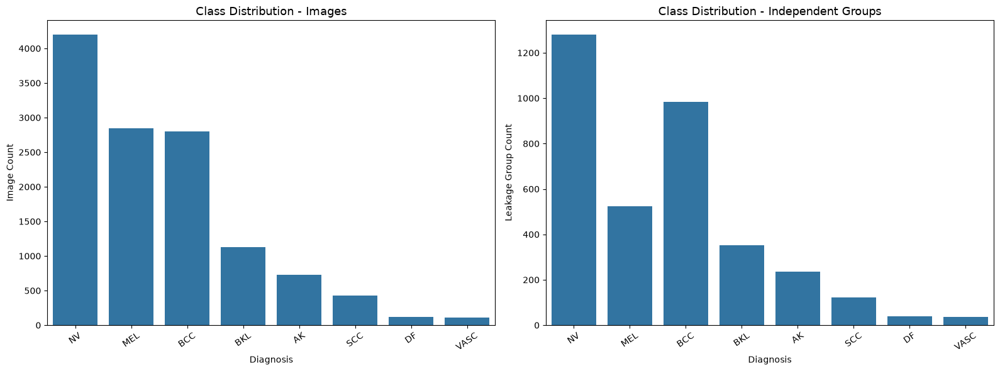

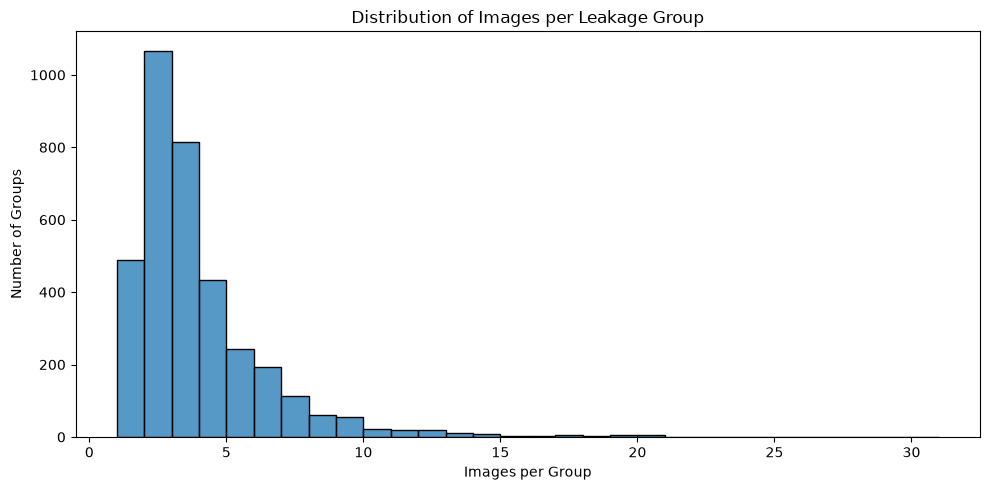


PHASE 03A - CELL 2 SUMMARY
Images: 12364
Leakage groups: 3572
Original lesions represented: 3574
Diagnostic classes: 8
Minimum class groups: 37
5-fold feasibility: True
8-fold inner validation feasibility: True

Reports saved successfully.


In [35]:
# ============================================================
# BCN20000 RESEARCH
# PHASE 03A - CELL 2
# GROUP-LEVEL CLASS DISTRIBUTION & SPLIT FEASIBILITY
# ============================================================

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 75)
print("PHASE 03A - GROUP-LEVEL CLASS DISTRIBUTION")
print("=" * 75)

# ------------------------------------------------------------
# 1. REQUIRED VARIABLES
# ------------------------------------------------------------

required_vars = [
    "clean_df",
    "REPORT_DIR",
    "FIGURE_DIR"
]

for var in required_vars:

    if var not in globals():

        raise RuntimeError(
            f"Required variable missing: {var}. "
            "Run corrected Cell 1 first."
        )

# ------------------------------------------------------------
# 2. VERIFY LEAKAGE GROUP LABEL CONSISTENCY
# ------------------------------------------------------------

group_label_counts = (
    clean_df.groupby("leakage_group_id")["diagnosis"]
    .nunique()
)

conflicting_groups = int(
    (group_label_counts > 1).sum()
)

print("Leakage groups with conflicting labels:",
      conflicting_groups)

if conflicting_groups > 0:

    raise ValueError(
        "Some leakage groups contain multiple diagnoses."
    )

# ------------------------------------------------------------
# 3. SOURCE LESION ID PARSER
# ------------------------------------------------------------

def parse_source_ids(value):

    if pd.isna(value):
        return []

    try:

        result = json.loads(value)

        if isinstance(result, list):
            return [str(x) for x in result]

        return [str(result)]

    except (ValueError, TypeError):

        return [str(value)]


# ------------------------------------------------------------
# 4. CREATE GROUP-LEVEL SUMMARY
# ------------------------------------------------------------

group_records = []

for group_id, group in clean_df.groupby(
    "leakage_group_id"
):

    diagnoses = group["diagnosis"].dropna().unique()

    if len(diagnoses) != 1:

        raise ValueError(
            f"Inconsistent diagnosis in group: {group_id}"
        )

    source_ids = set()

    for value in group["source_lesion_ids"]:

        source_ids.update(
            parse_source_ids(value)
        )

    group_records.append({

        "leakage_group_id": group_id,

        "diagnosis": diagnoses[0],

        "image_count": len(group),

        "canonical_lesion_count": (
            group["lesion_id"].nunique()
        ),

        "original_lesion_count": len(source_ids)

    })


group_summary = pd.DataFrame(group_records)

print("\nGROUP SUMMARY")
print("-" * 60)

print("Total images:", len(clean_df))

print("Total leakage groups:", len(group_summary))

print(
    "Original lesion IDs represented:",
    group_summary["original_lesion_count"].sum()
)

# ------------------------------------------------------------
# 5. CLASS-WISE IMAGE AND GROUP DISTRIBUTION
# ------------------------------------------------------------

image_distribution = (
    clean_df.groupby("diagnosis")
    .size()
    .rename("image_count")
)

group_distribution = (
    group_summary.groupby("diagnosis")
    .agg(

        leakage_group_count=("leakage_group_id", "nunique"),

        original_lesion_count=("original_lesion_count", "sum"),

        average_images_per_group=("image_count", "mean"),

        maximum_images_per_group=("image_count", "max")

    )
)

class_summary = pd.concat(
    [
        image_distribution,
        group_distribution
    ],
    axis=1
).reset_index()

class_summary["image_percentage"] = (
    class_summary["image_count"]
    / len(clean_df) * 100
)

class_summary["group_percentage"] = (
    class_summary["leakage_group_count"]
    / len(group_summary) * 100
)

class_summary = class_summary.sort_values(
    "image_count",
    ascending=False
)

print("\nCLASS-WISE DISTRIBUTION")
print("-" * 60)

display(
    class_summary.round(3)
)

# ------------------------------------------------------------
# 6. MINORITY CLASS GROUP ANALYSIS
# ------------------------------------------------------------

print("\nMINORITY CLASS ANALYSIS")
print("-" * 60)

minimum_group_count = int(
    class_summary["leakage_group_count"].min()
)

minimum_group_class = class_summary.loc[
    class_summary["leakage_group_count"].idxmin(),
    "diagnosis"
]

print("Minimum group count:", minimum_group_count)

print("Minority group class:", minimum_group_class)

print(
    "Minimum groups required for 5-fold splitting: 5"
)

print(
    "Groups available for 5-fold splitting:",
    minimum_group_count
)

outer_fold_feasible = (
    minimum_group_count >= 5
)

inner_8fold_feasible = (
    minimum_group_count >= 8
)

print(
    "\nOuter 5-fold basic feasibility:",
    outer_fold_feasible
)

print(
    "Inner 8-fold basic feasibility:",
    inner_8fold_feasible
)

# ------------------------------------------------------------
# 7. GROUP SIZE ANALYSIS
# ------------------------------------------------------------

print("\nIMAGES PER LEAKAGE GROUP")
print("-" * 60)

group_size_statistics = (
    group_summary["image_count"].describe()
)

display(
    group_size_statistics.to_frame(
        "Images per group"
    )
)

# ------------------------------------------------------------
# 8. VISUALIZATION
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

sns.barplot(
    data=class_summary,
    x="diagnosis",
    y="image_count",
    ax=axes[0]
)

axes[0].set_title(
    "Class Distribution - Images",
    fontsize=13
)

axes[0].set_xlabel("Diagnosis")
axes[0].set_ylabel("Image Count")

axes[0].tick_params(
    axis="x",
    rotation=35
)

sns.barplot(
    data=class_summary,
    x="diagnosis",
    y="leakage_group_count",
    ax=axes[1]
)

axes[1].set_title(
    "Class Distribution - Independent Groups",
    fontsize=13
)

axes[1].set_xlabel("Diagnosis")
axes[1].set_ylabel("Leakage Group Count")

axes[1].tick_params(
    axis="x",
    rotation=35
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "phase03_group_class_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. GROUP SIZE DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

sns.histplot(
    data=group_summary,
    x="image_count",
    bins=30
)

plt.title(
    "Distribution of Images per Leakage Group"
)

plt.xlabel("Images per Group")
plt.ylabel("Number of Groups")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "phase03_group_size_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 10. SAVE REPORTS
# ------------------------------------------------------------

class_summary.to_csv(
    REPORT_DIR / "phase03_group_class_distribution.csv",
    index=False
)

group_summary.to_csv(
    REPORT_DIR / "phase03_group_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 11. FINAL CELL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PHASE 03A - CELL 2 SUMMARY")
print("=" * 75)

print("Images:", len(clean_df))

print("Leakage groups:", len(group_summary))

print("Original lesions represented:",
      group_summary["original_lesion_count"].sum())

print("Diagnostic classes:", len(class_summary))

print("Minimum class groups:", minimum_group_count)

print("5-fold feasibility:", outer_fold_feasible)

print("8-fold inner validation feasibility:",
      inner_8fold_feasible)

print("\nReports saved successfully.")

print("=" * 75)

In [36]:
# ================================================================
# BCN20000 RESEARCH
# PHASE 03A - CELL 3
# GROUP-LEVEL STRATIFIED FIVE-FOLD SPLITTING
# ================================================================

import json
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from pathlib import Path

print("=" * 75)
print("PHASE 03A - FIVE-FOLD LEAKAGE-AWARE DATA SPLITTING")
print("=" * 75)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

OUTER_SEED = 42
INNER_SEED = 2026

classes = sorted(clean_df["diagnosis"].unique())

# One row per independent leakage group
group_table = group_summary[
    [
        "leakage_group_id",
        "diagnosis",
        "image_count",
        "original_lesion_count"
    ]
].copy()

# ------------------------------------------------------------
# 2. VALIDATE GROUP TABLE
# ------------------------------------------------------------

if group_table["leakage_group_id"].duplicated().any():

    raise ValueError(
        "Duplicate leakage group IDs in group summary."
    )

if group_table["diagnosis"].isna().any():

    raise ValueError(
        "Missing group diagnosis detected."
    )

if set(group_table["diagnosis"]) != set(classes):

    raise ValueError(
        "Group table does not contain all diagnostic classes."
    )

group_class_counts = (
    group_table["diagnosis"].value_counts()
)

if group_class_counts.min() < N_OUTER_FOLDS:

    raise ValueError(
        "Insufficient independent groups for outer five-fold."
    )

print("Independent groups:", len(group_table))
print("Diagnostic classes:", len(classes))

print("\nGroups per class:")
display(group_class_counts.to_frame("Group Count"))

# ------------------------------------------------------------
# 3. OUTER FIVE-FOLD SPLITTING
# ------------------------------------------------------------

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=OUTER_SEED
)

master_records = []
fold_summaries = []
distribution_records = []

# ------------------------------------------------------------
# 4. PROCESS OUTER FOLDS
# ------------------------------------------------------------

for fold_number, (dev_idx, outer_test_idx) in enumerate(

    outer_cv.split(
        group_table,
        group_table["diagnosis"]
    ),

    start=1

):

    print("\n" + "=" * 70)
    print(f"OUTER FOLD {fold_number}")
    print("=" * 70)

    # --------------------------------------------------------
    # 4A. GROUP ASSIGNMENT
    # --------------------------------------------------------

    dev_groups_df = (
        group_table.iloc[dev_idx].copy()
    )

    outer_test_groups_df = (
        group_table.iloc[outer_test_idx].copy()
    )

    dev_group_ids = set(
        dev_groups_df["leakage_group_id"]
    )

    outer_test_group_ids = set(
        outer_test_groups_df["leakage_group_id"]
    )

    # Expand groups to image records
    dev_images = clean_df[
        clean_df["leakage_group_id"].isin(dev_group_ids)
    ].copy()

    outer_test_images = clean_df[
        clean_df["leakage_group_id"].isin(
            outer_test_group_ids
        )
    ].copy()

    # --------------------------------------------------------
    # 4B. INNER VALIDATION SPLITTING
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=INNER_SEED + fold_number
    )

    dev_group_distribution = (
        dev_groups_df["diagnosis"]
        .value_counts(normalize=True)
        .reindex(classes, fill_value=0)
    )

    dev_image_distribution = (
        dev_images["diagnosis"]
        .value_counts(normalize=True)
        .reindex(classes, fill_value=0)
    )

    candidates = []

    for inner_train_idx, inner_val_idx in inner_cv.split(

        dev_groups_df,

        dev_groups_df["diagnosis"]

    ):

        inner_train_groups = (
            dev_groups_df.iloc[inner_train_idx]
        )

        inner_val_groups = (
            dev_groups_df.iloc[inner_val_idx]
        )

        train_group_ids = set(
            inner_train_groups["leakage_group_id"]
        )

        val_group_ids = set(
            inner_val_groups["leakage_group_id"]
        )

        train_images = clean_df[
            clean_df["leakage_group_id"].isin(
                train_group_ids
            )
        ].copy()

        val_images = clean_df[
            clean_df["leakage_group_id"].isin(
                val_group_ids
            )
        ].copy()

        # ----------------------------------------------------
        # CLASS COVERAGE
        # ----------------------------------------------------

        if set(inner_train_groups["diagnosis"]) != set(classes):
            continue

        if set(inner_val_groups["diagnosis"]) != set(classes):
            continue

        if set(outer_test_groups_df["diagnosis"]) != set(classes):
            continue

        # ----------------------------------------------------
        # GROUP DISTRIBUTION ERROR
        # ----------------------------------------------------

        val_group_distribution = (
            inner_val_groups["diagnosis"]
            .value_counts(normalize=True)
            .reindex(classes, fill_value=0)
        )

        group_distribution_error = np.abs(
            val_group_distribution - dev_group_distribution
        ).mean()

        # ----------------------------------------------------
        # IMAGE DISTRIBUTION ERROR
        # ----------------------------------------------------

        val_image_distribution = (
            val_images["diagnosis"]
            .value_counts(normalize=True)
            .reindex(classes, fill_value=0)
        )

        image_distribution_error = np.abs(
            val_image_distribution - dev_image_distribution
        ).mean()

        # ----------------------------------------------------
        # SIZE BALANCE
        # ----------------------------------------------------

        group_fraction = (
            len(inner_val_groups) / len(dev_groups_df)
        )

        image_fraction = (
            len(val_images) / len(dev_images)
        )

        group_size_error = abs(
            group_fraction - 1 / N_INNER_FOLDS
        )

        image_size_error = abs(
            image_fraction - 1 / N_INNER_FOLDS
        )

        # ----------------------------------------------------
        # COMBINED BALANCE SCORE
        # ----------------------------------------------------

        score = (

            0.35 * group_distribution_error

            + 0.35 * image_distribution_error

            + 0.15 * group_size_error

            + 0.15 * image_size_error

        )

        candidates.append({

            "score": score,

            "train_groups": train_group_ids,

            "validation_groups": val_group_ids,

            "train_images": train_images,

            "validation_images": val_images

        })

    # --------------------------------------------------------
    # 4C. SELECT BEST VALIDATION CANDIDATE
    # --------------------------------------------------------

    if not candidates:

        raise RuntimeError(
            f"Fold {fold_number}: no valid validation split found."
        )

    best = min(
        candidates,
        key=lambda x: x["score"]
    )

    train_fold = best["train_images"].copy()

    validation_fold = best["validation_images"].copy()

    outer_test_fold = outer_test_images.copy()

    # --------------------------------------------------------
    # 4D. GROUP LEAKAGE VERIFICATION
    # --------------------------------------------------------

    train_group_ids = set(
        train_fold["leakage_group_id"]
    )

    validation_group_ids = set(
        validation_fold["leakage_group_id"]
    )

    test_group_ids = set(
        outer_test_fold["leakage_group_id"]
    )

    overlap_train_val = len(
        train_group_ids & validation_group_ids
    )

    overlap_train_test = len(
        train_group_ids & test_group_ids
    )

    overlap_val_test = len(
        validation_group_ids & test_group_ids
    )

    if any([
        overlap_train_val,
        overlap_train_test,
        overlap_val_test
    ]):

        raise RuntimeError(
            f"Group leakage detected in fold {fold_number}."
        )

    # --------------------------------------------------------
    # 4E. PARTITION CLASS COVERAGE
    # --------------------------------------------------------

    partitions = {

        "train": train_fold,

        "validation": validation_fold,

        "outer_test": outer_test_fold

    }

    for partition_name, partition_df in partitions.items():

        missing_classes = (
            set(classes)
            - set(partition_df["diagnosis"])
        )

        if missing_classes:

            raise RuntimeError(
                f"Missing classes in fold {fold_number}, "
                f"{partition_name}: {missing_classes}"
            )

    # --------------------------------------------------------
    # 4F. SAVE PARTITION FILES
    # --------------------------------------------------------

    for partition_name, partition_df in partitions.items():

        output_df = partition_df.copy()

        output_df["fold"] = fold_number

        output_df["partition"] = partition_name

        master_records.append(output_df)

        output_df.to_csv(

            SPLIT_DIR /
            f"fold_{fold_number:02d}_{partition_name}.csv",

            index=False

        )

        # Record class-wise group and image distribution
        partition_group_ids = set(
            partition_df["leakage_group_id"]
        )

        partition_group_table = group_table[
            group_table["leakage_group_id"].isin(
                partition_group_ids
            )
        ]

        for class_name in classes:

            image_count = int(
                (partition_df["diagnosis"] == class_name).sum()
            )

            group_count = int(
                (
                    partition_group_table["diagnosis"]
                    == class_name
                ).sum()
            )

            distribution_records.append({

                "fold": fold_number,

                "partition": partition_name,

                "diagnosis": class_name,

                "image_count": image_count,

                "group_count": group_count

            })

    # --------------------------------------------------------
    # 4G. FOLD SUMMARY
    # --------------------------------------------------------

    summary = {

        "fold": fold_number,

        "train_images": len(train_fold),

        "validation_images": len(validation_fold),

        "outer_test_images": len(outer_test_fold),

        "train_groups": len(train_group_ids),

        "validation_groups": len(validation_group_ids),

        "outer_test_groups": len(test_group_ids),

        "train_percentage": (
            len(train_fold) / len(clean_df) * 100
        ),

        "validation_percentage": (
            len(validation_fold) / len(clean_df) * 100
        ),

        "outer_test_percentage": (
            len(outer_test_fold) / len(clean_df) * 100
        ),

        "group_overlap": (
            overlap_train_val
            + overlap_train_test
            + overlap_val_test
        ),

        "validation_balance_score": best["score"]

    }

    fold_summaries.append(summary)

    print("Train images:", len(train_fold))
    print("Validation images:", len(validation_fold))
    print("Outer test images:", len(outer_test_fold))

    print("Train groups:", len(train_group_ids))
    print("Validation groups:", len(validation_group_ids))
    print("Outer test groups:", len(test_group_ids))

    print("Group overlap:", summary["group_overlap"])

    print("Validation balance score:", round(best["score"], 5))

    print("FOLD COMPLETED SUCCESSFULLY")

# ------------------------------------------------------------
# 5. CREATE MASTER MANIFEST
# ------------------------------------------------------------

master_splits = pd.concat(
    master_records,
    ignore_index=True
)

fold_summary_df = pd.DataFrame(
    fold_summaries
)

fold_distribution_df = pd.DataFrame(
    distribution_records
)

# ------------------------------------------------------------
# 6. SAVE MASTER OUTPUTS
# ------------------------------------------------------------

master_splits.to_csv(
    SPLIT_DIR / "phase03_master_split_assignments.csv",
    index=False
)

fold_summary_df.to_csv(
    REPORT_DIR / "phase03_fold_summary.csv",
    index=False
)

fold_distribution_df.to_csv(
    REPORT_DIR / "phase03_fold_class_distribution.csv",
    index=False
)

# ------------------------------------------------------------
# 7. DISPLAY FINAL SPLIT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)

print("FIVE-FOLD SPLITTING SUMMARY")

display(
    fold_summary_df.round(3)
)

print("\nCLASS-WISE FOLD DISTRIBUTION")

display(
    fold_distribution_df.head(40)
)

print("\nMaster split records:", len(master_splits))

print(
    "Expected master records:",
    len(clean_df) * N_OUTER_FOLDS
)

print("\nAll split files saved successfully.")

print("=" * 75)

PHASE 03A - FIVE-FOLD LEAKAGE-AWARE DATA SPLITTING
Independent groups: 3572
Diagnostic classes: 8

Groups per class:


,Group Count
diagnosis,
NV,1279
BCC,983
MEL,523
BKL,352
AK,236
SCC,122
DF,40
VASC,37



OUTER FOLD 1
Train images: 7813
Validation images: 1973
Outer test images: 2578
Train groups: 2286
Validation groups: 571
Outer test groups: 715
Group overlap: 0
Validation balance score: 0.00197
FOLD COMPLETED SUCCESSFULLY

OUTER FOLD 2
Train images: 7852
Validation images: 2016
Outer test images: 2496
Train groups: 2286
Validation groups: 571
Outer test groups: 715
Group overlap: 0
Validation balance score: 0.00174
FOLD COMPLETED SUCCESSFULLY

OUTER FOLD 3
Train images: 7963
Validation images: 1962
Outer test images: 2439
Train groups: 2287
Validation groups: 571
Outer test groups: 714
Group overlap: 0
Validation balance score: 0.00237
FOLD COMPLETED SUCCESSFULLY

OUTER FOLD 4
Train images: 7930
Validation images: 2033
Outer test images: 2401
Train groups: 2286
Validation groups: 572
Outer test groups: 714
Group overlap: 0
Validation balance score: 0.00211
FOLD COMPLETED SUCCESSFULLY

OUTER FOLD 5
Train images: 7913
Validation images: 2001
Outer test images: 2450
Train groups: 2286


,fold,train_images,validation_images,outer_test_images,train_groups,validation_groups,outer_test_groups,train_percentage,validation_percentage,outer_test_percentage,group_overlap,validation_balance_score
0,1,7813,1973,2578,2286,571,715,63.192,15.958,20.851,0,0.002
1,2,7852,2016,2496,2286,571,715,63.507,16.305,20.188,0,0.002
2,3,7963,1962,2439,2287,571,714,64.405,15.869,19.727,0,0.002
3,4,7930,2033,2401,2286,572,714,64.138,16.443,19.419,0,0.002
4,5,7913,2001,2450,2286,572,714,64.000,16.184,19.816,0,0.002



CLASS-WISE FOLD DISTRIBUTION


,fold,partition,diagnosis,image_count,group_count
0,1,train,AK,466,150
1,1,train,BCC,1764,629
2,1,train,BKL,705,226
3,1,train,DF,77,26
4,1,train,MEL,1799,335
5,1,train,NV,2673,820
6,1,train,SCC,266,77
7,1,train,VASC,63,23
8,1,validation,AK,134,38
9,1,validation,BCC,458,158



Master split records: 61820
Expected master records: 61820

All split files saved successfully.


In [37]:
# ============================================================
# PHASE 03A - CELL 4
# FINAL FIVE-FOLD SPLIT VERIFICATION
# ============================================================

import json
import pandas as pd

print("=" * 75)
print("PHASE 03A - FINAL SPLIT VERIFICATION")
print("=" * 75)

master = pd.read_csv(
    SPLIT_DIR / "phase03_master_split_assignments.csv",
    dtype={
        "leakage_group_id": str,
        "lesion_id": str
    }
)

expected_classes = set(
    clean_df["diagnosis"].unique()
)

checks = {}
fold_results = []

# ------------------------------------------------------------
# 1. GLOBAL VALIDATION
# ------------------------------------------------------------

checks["Five outer folds generated"] = (
    master["fold"].nunique() == 5
)

checks["Three partition types generated"] = (
    set(master["partition"].unique())
    == {"train", "validation", "outer_test"}
)

checks["Master record count correct"] = (
    len(master) == len(clean_df) * 5
)

# ------------------------------------------------------------
# 2. VERIFY EACH FOLD
# ------------------------------------------------------------

for fold_number in range(1, 6):

    fold_df = master[
        master["fold"] == fold_number
    ]

    partitions = {

        name: fold_df[
            fold_df["partition"] == name
        ].copy()

        for name in [
            "train",
            "validation",
            "outer_test"
        ]

    }

    train_df_fold = partitions["train"]

    val_df_fold = partitions["validation"]

    test_df_fold = partitions["outer_test"]

    train_groups = set(
        train_df_fold["leakage_group_id"]
    )

    val_groups = set(
        val_df_fold["leakage_group_id"]
    )

    test_groups = set(
        test_df_fold["leakage_group_id"]
    )

    # Group overlap
    overlap = (

        len(train_groups & val_groups)

        + len(train_groups & test_groups)

        + len(val_groups & test_groups)

    )

    # Class coverage
    all_classes_present = all(

        set(part["diagnosis"]) == expected_classes

        for part in partitions.values()

    )

    # Filename duplicates
    duplicate_files = int(
        fold_df["bcn_filename"].duplicated().sum()
    )

    # Group partition consistency
    group_partition_counts = (
        fold_df.groupby("leakage_group_id")
        ["partition"].nunique()
    )

    group_partition_errors = int(
        (group_partition_counts > 1).sum()
    )

    # Image count
    correct_image_count = (
        len(fold_df) == len(clean_df)
    )

    fold_pass = all([

        overlap == 0,

        all_classes_present,

        duplicate_files == 0,

        group_partition_errors == 0,

        correct_image_count

    ])

    fold_results.append({

        "fold": fold_number,

        "train_images": len(train_df_fold),

        "validation_images": len(val_df_fold),

        "outer_test_images": len(test_df_fold),

        "train_groups": len(train_groups),

        "validation_groups": len(val_groups),

        "outer_test_groups": len(test_groups),

        "group_overlap": overlap,

        "all_classes_present": all_classes_present,

        "duplicate_files": duplicate_files,

        "group_partition_errors": group_partition_errors,

        "status": "PASS" if fold_pass else "FAIL"

    })


# ------------------------------------------------------------
# 3. OUTER TEST COVERAGE
# ------------------------------------------------------------

outer_test_df = master[
    master["partition"] == "outer_test"
]

image_coverage = (
    outer_test_df.groupby("bcn_filename").size()
)

group_coverage = (
    outer_test_df.groupby("leakage_group_id").size()
)

image_test_once = (

    len(image_coverage) == len(clean_df)

    and (image_coverage == 1).all()

)

group_test_once = (

    len(group_coverage) == len(group_table)

    and (group_coverage == 1).all()

)

checks["Every image tested exactly once"] = bool(
    image_test_once
)

checks["Every leakage group tested exactly once"] = bool(
    group_test_once
)

# ------------------------------------------------------------
# 4. FOLD RESULTS
# ------------------------------------------------------------

fold_results_df = pd.DataFrame(
    fold_results
)

display(fold_results_df)

fold_results_df.to_csv(
    REPORT_DIR / "phase03_fold_verification.csv",
    index=False
)

checks["All five folds pass"] = (
    (fold_results_df["status"] == "PASS").all()
)

# ------------------------------------------------------------
# 5. GLOBAL CHECKS
# ------------------------------------------------------------

print("\nGLOBAL VERIFICATION")

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

phase_status = (
    "PASS"
    if all(checks.values())
    else "BLOCKED"
)

print("\nPHASE 03A STATUS:", phase_status)

# ------------------------------------------------------------
# 6. SAVE FINAL REPORT
# ------------------------------------------------------------

final_report = {

    "phase": "PHASE_03A",

    "status": phase_status,

    "outer_folds": 5,

    "inner_validation_folds": 5,

    "cleaned_images": len(clean_df),

    "leakage_groups": len(group_table),

    "test_coverage": {

        "unique_images": len(image_coverage),

        "unique_groups": len(group_coverage),

        "every_image_tested_once": bool(image_test_once),

        "every_group_tested_once": bool(group_test_once)

    },

    "checks": {
        key: bool(value)
        for key, value in checks.items()
    },

    "fold_details": fold_results_df.to_dict(
        orient="records"
    )

}

with open(
    REPORT_DIR / "PHASE_03A_FINAL_VERIFICATION.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_report,
        f,
        indent=4
    )

print("\nReport saved:")
print(
    REPORT_DIR / "PHASE_03A_FINAL_VERIFICATION.json"
)

if phase_status == "PASS":

    print("\nNEXT: PHASE 03B - IMAGE PREPROCESSING")

else:

    print("\nSTOP: SPLITTING VALIDATION FAILED")

print("=" * 75)

PHASE 03A - FINAL SPLIT VERIFICATION


,fold,train_images,validation_images,outer_test_images,train_groups,validation_groups,outer_test_groups,group_overlap,all_classes_present,duplicate_files,group_partition_errors,status
0,1,7813,1973,2578,2286,571,715,0,True,0,0,PASS
1,2,7852,2016,2496,2286,571,715,0,True,0,0,PASS
2,3,7963,1962,2439,2287,571,714,0,True,0,0,PASS
3,4,7930,2033,2401,2286,572,714,0,True,0,0,PASS
4,5,7913,2001,2450,2286,572,714,0,True,0,0,PASS



GLOBAL VERIFICATION
[PASS] Five outer folds generated
[PASS] Three partition types generated
[PASS] Master record count correct
[PASS] Every image tested exactly once
[FAIL] Every leakage group tested exactly once
[PASS] All five folds pass

PHASE 03A STATUS: BLOCKED

Report saved:
d:\skin_research\outputs\reports\PHASE_03A_FINAL_VERIFICATION.json

STOP: SPLITTING VALIDATION FAILED


In [38]:
# ============================================================
# BCN20000 RESEARCH
# PHASE 03A - CELL 4
# CORRECTED FINAL FIVE-FOLD VERIFICATION
# ============================================================

import json
import pandas as pd
from pathlib import Path

print("=" * 75)
print("PHASE 03A - CORRECTED FINAL SPLIT VERIFICATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. LOAD MASTER SPLIT
# ------------------------------------------------------------

master_path = (
    SPLIT_DIR / "phase03_master_split_assignments.csv"
)

master = pd.read_csv(
    master_path,
    dtype={
        "bcn_filename": str,
        "leakage_group_id": str,
        "lesion_id": str
    }
)

expected_classes = set(
    clean_df["diagnosis"].unique()
)

expected_images = set(
    clean_df["bcn_filename"]
)

expected_groups = set(
    clean_df["leakage_group_id"]
)

checks = {}

fold_results = []

# ------------------------------------------------------------
# 2. GLOBAL STRUCTURE CHECK
# ------------------------------------------------------------

checks["Five outer folds generated"] = (
    master["fold"].nunique() == 5
)

checks["Three partition types generated"] = (
    set(master["partition"].unique())
    == {"train", "validation", "outer_test"}
)

checks["Master record count correct"] = (
    len(master) == len(clean_df) * 5
)

# ------------------------------------------------------------
# 3. VERIFY EACH FOLD
# ------------------------------------------------------------

for fold_number in range(1, 6):

    fold_df = master[
        master["fold"] == fold_number
    ].copy()

    partitions = {

        name: fold_df[
            fold_df["partition"] == name
        ].copy()

        for name in [
            "train",
            "validation",
            "outer_test"
        ]

    }

    train_part = partitions["train"]
    val_part = partitions["validation"]
    test_part = partitions["outer_test"]

    train_groups = set(
        train_part["leakage_group_id"]
    )

    val_groups = set(
        val_part["leakage_group_id"]
    )

    test_groups = set(
        test_part["leakage_group_id"]
    )

    # Group overlap
    train_val_overlap = len(
        train_groups & val_groups
    )

    train_test_overlap = len(
        train_groups & test_groups
    )

    val_test_overlap = len(
        val_groups & test_groups
    )

    total_overlap = (
        train_val_overlap
        + train_test_overlap
        + val_test_overlap
    )

    # Class coverage
    all_classes_present = all(
        set(part["diagnosis"]) == expected_classes
        for part in partitions.values()
    )

    # Duplicate filenames
    duplicate_files = int(
        fold_df["bcn_filename"].duplicated().sum()
    )

    # One group must belong to only one partition
    group_partition_counts = (
        fold_df.groupby("leakage_group_id")["partition"]
        .nunique()
    )

    group_partition_errors = int(
        (group_partition_counts > 1).sum()
    )

    fold_pass = all([

        total_overlap == 0,

        all_classes_present,

        duplicate_files == 0,

        group_partition_errors == 0,

        len(fold_df) == len(clean_df)

    ])

    fold_results.append({

        "fold": fold_number,

        "train_images": len(train_part),

        "validation_images": len(val_part),

        "outer_test_images": len(test_part),

        "train_groups": len(train_groups),

        "validation_groups": len(val_groups),

        "outer_test_groups": len(test_groups),

        "group_overlap": total_overlap,

        "all_classes_present": all_classes_present,

        "duplicate_files": duplicate_files,

        "group_partition_errors": group_partition_errors,

        "status": "PASS" if fold_pass else "FAIL"

    })


# ------------------------------------------------------------
# 4. VERIFY EVERY IMAGE IS TESTED EXACTLY ONCE
# ------------------------------------------------------------

outer_test_df = master[
    master["partition"] == "outer_test"
].copy()

image_coverage = (
    outer_test_df.groupby("bcn_filename")["fold"]
    .nunique()
)

image_coverage_pass = (

    set(image_coverage.index) == expected_images

    and (image_coverage == 1).all()

)

checks["Every image tested exactly once"] = bool(
    image_coverage_pass
)


# ------------------------------------------------------------
# 5. CORRECTED LEAKAGE-GROUP COVERAGE
# ------------------------------------------------------------

# IMPORTANT:
# We count unique outer-test FOLDS per group,
# NOT the number of images belonging to a group.

group_fold_coverage = (
    outer_test_df.groupby("leakage_group_id")["fold"]
    .nunique()
)

group_coverage_pass = (

    set(group_fold_coverage.index) == expected_groups

    and (group_fold_coverage == 1).all()

)

print("\nLEAKAGE GROUP COVERAGE")

print(
    "Expected leakage groups:",
    len(expected_groups)
)

print(
    "Groups appearing in outer test:",
    len(group_fold_coverage)
)

print(
    "Groups assigned to multiple outer test folds:",
    int((group_fold_coverage > 1).sum())
)

print(
    "Groups missing from outer test:",
    len(expected_groups - set(group_fold_coverage.index))
)

print(
    "Every group tested in exactly one outer fold:",
    group_coverage_pass
)

# Image count per group is expected to be greater than one
group_image_counts = (
    outer_test_df.groupby("leakage_group_id")
    .size()
)

print("\nImages per outer-test group:")

print(group_image_counts.describe().round(3))

checks["Every leakage group tested exactly once"] = bool(
    group_coverage_pass
)


# ------------------------------------------------------------
# 6. FOLD SUMMARY
# ------------------------------------------------------------

fold_results_df = pd.DataFrame(fold_results)

display(fold_results_df)

fold_results_df.to_csv(
    REPORT_DIR / "phase03_fold_verification.csv",
    index=False
)

checks["All five folds pass"] = (
    (fold_results_df["status"] == "PASS").all()
)


# ------------------------------------------------------------
# 7. GLOBAL VERIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("GLOBAL VERIFICATION")
print("=" * 75)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

phase_status = (
    "PASS"
    if all(checks.values())
    else "BLOCKED"
)


# ------------------------------------------------------------
# 8. SAVE FINAL REPORT
# ------------------------------------------------------------

final_report = {

    "phase": "PHASE_03A",

    "status": phase_status,

    "outer_folds": 5,

    "inner_validation_folds": 5,

    "cleaned_images": len(clean_df),

    "leakage_groups": len(expected_groups),

    "image_test_coverage": {

        "unique_images": len(image_coverage),

        "every_image_tested_once": bool(
            image_coverage_pass
        )

    },

    "group_test_coverage": {

        "unique_groups": len(group_fold_coverage),

        "every_group_tested_once": bool(
            group_coverage_pass
        ),

        "groups_assigned_to_multiple_folds": int(
            (group_fold_coverage > 1).sum()
        )

    },

    "checks": {
        key: bool(value)
        for key, value in checks.items()
    },

    "fold_details": fold_results_df.to_dict(
        orient="records"
    )

}

with open(
    REPORT_DIR / "PHASE_03A_FINAL_VERIFICATION.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_report,
        f,
        indent=4
    )

print("\n" + "=" * 75)

print("PHASE 03A FINAL STATUS:", phase_status)

if phase_status == "PASS":

    print("NEXT: PHASE 03B - IMAGE PREPROCESSING")

else:

    print("STOP: INVESTIGATE FAILED CHECKS")

print("\nFinal report saved:")

print(
    REPORT_DIR / "PHASE_03A_FINAL_VERIFICATION.json"
)

print("=" * 75)

PHASE 03A - CORRECTED FINAL SPLIT VERIFICATION

LEAKAGE GROUP COVERAGE
Expected leakage groups: 3572
Groups appearing in outer test: 3572
Groups assigned to multiple outer test folds: 0
Groups missing from outer test: 0
Every group tested in exactly one outer fold: True

Images per outer-test group:
count    3572.000
mean        3.461
std         2.613
min         1.000
25%         2.000
50%         3.000
75%         4.000
max        31.000
dtype: float64


,fold,train_images,validation_images,outer_test_images,train_groups,validation_groups,outer_test_groups,group_overlap,all_classes_present,duplicate_files,group_partition_errors,status
0,1,7813,1973,2578,2286,571,715,0,True,0,0,PASS
1,2,7852,2016,2496,2286,571,715,0,True,0,0,PASS
2,3,7963,1962,2439,2287,571,714,0,True,0,0,PASS
3,4,7930,2033,2401,2286,572,714,0,True,0,0,PASS
4,5,7913,2001,2450,2286,572,714,0,True,0,0,PASS



GLOBAL VERIFICATION
[PASS] Five outer folds generated
[PASS] Three partition types generated
[PASS] Master record count correct
[PASS] Every image tested exactly once
[PASS] Every leakage group tested exactly once
[PASS] All five folds pass

PHASE 03A FINAL STATUS: PASS
NEXT: PHASE 03B - IMAGE PREPROCESSING

Final report saved:
d:\skin_research\outputs\reports\PHASE_03A_FINAL_VERIFICATION.json


In [39]:
# ============================================================
# BCN20000 RESEARCH
# PHASE 03B - CELL 1
# IMAGE PREPROCESSING CONFIGURATION
# ============================================================

import os
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

print("=" * 70)
print("PHASE 03B - IMAGE PREPROCESSING CONFIGURATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

ROOT = Path.cwd()

REPORT_DIR = ROOT / "outputs" / "reports"
FIGURE_DIR = ROOT / "outputs" / "figures"

PREPROCESS_DIR = ROOT / "outputs" / "preprocessing"

PILOT_DIR = PREPROCESS_DIR / "roi_pilot"

PILOT_CROP_DIR = PILOT_DIR / "cropped_images"

for folder in [
    REPORT_DIR,
    FIGURE_DIR,
    PREPROCESS_DIR,
    PILOT_DIR,
    PILOT_CROP_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. PREPROCESSING SETTINGS
# ------------------------------------------------------------

RANDOM_SEED = 42

IMAGE_SIZE = 224

ROI_THRESHOLD = 60

MIN_CONTOUR_WIDTH = 100
MIN_CONTOUR_HEIGHT = 100

INTENSITY_RATIO_THRESHOLD = 1.1

PILOT_SAMPLES_PER_CLASS = 4

# ------------------------------------------------------------
# 3. VERIFY EXISTING DATA
# ------------------------------------------------------------

assert len(clean_df) == 12364

assert clean_df["diagnosis"].nunique() == 8

assert "path" in clean_df.columns

assert "leakage_group_id" in clean_df.columns

assert "fold" in master_splits.columns

print("Cleaned images:", len(clean_df))

print("Diagnostic classes:", clean_df["diagnosis"].nunique())

print("Image size target:", IMAGE_SIZE)

print("ROI threshold:", ROI_THRESHOLD)

print("Intensity ratio threshold:", INTENSITY_RATIO_THRESHOLD)

print("Pilot samples per class:", PILOT_SAMPLES_PER_CLASS)

print("\nOutput directory:", PREPROCESS_DIR)

print("\nCONFIGURATION STATUS: PASS")

print("=" * 70)

PHASE 03B - IMAGE PREPROCESSING CONFIGURATION
Cleaned images: 12364
Diagnostic classes: 8
Image size target: 224
ROI threshold: 60
Intensity ratio threshold: 1.1
Pilot samples per class: 4

Output directory: d:\skin_research\outputs\preprocessing

CONFIGURATION STATUS: PASS


In [40]:
# ============================================================
# PHASE 03B - CELL 2
# OFFICIAL BCN20000 ROI CROPPING IMPLEMENTATION
# ============================================================

def official_bcn_roi_crop(image_bgr):

    """
    BCN20000 authors' ROI cropping methodology.

    Steps:
    1. Convert image to grayscale.
    2. Apply threshold 60.
    3. Detect external contours.
    4. Select first valid bounding box (>=100x100).
    5. Calculate original implementation's intensity ratio.
    6. Crop if intensity ratio > 1.1.

    Original image is never modified.
    """

    height, width = image_bgr.shape[:2]

    result = {

        "crop_applied": False,

        "status": None,

        "bbox": None,

        "intensity_ratio": None,

        "original_width": width,

        "original_height": height,

        "cropped_width": width,

        "cropped_height": height,

        "area_retained_percentage": 100.0

    }

    # --------------------------------------------------------
    # 1. GRAYSCALE CONVERSION
    # --------------------------------------------------------

    gray = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2GRAY
    )

    # --------------------------------------------------------
    # 2. THRESHOLDING
    # --------------------------------------------------------

    _, thresholded = cv2.threshold(
        gray,
        ROI_THRESHOLD,
        255,
        cv2.THRESH_BINARY
    )

    # --------------------------------------------------------
    # 3. EXTERNAL CONTOUR DETECTION
    # --------------------------------------------------------

    contours, _ = cv2.findContours(
        thresholded,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # --------------------------------------------------------
    # 4. IDENTIFY VALID BOUNDING BOX
    # --------------------------------------------------------

    selected_bbox = None

    for contour in contours:

        x, y, w, h = cv2.boundingRect(contour)

        if (
            w >= MIN_CONTOUR_WIDTH
            and h >= MIN_CONTOUR_HEIGHT
        ):

            selected_bbox = (x, y, w, h)

            break

    if selected_bbox is None:

        result["status"] = "NO_VALID_CONTOUR"

        return image_bgr.copy(), result

    x, y, w, h = selected_bbox

    # --------------------------------------------------------
    # 5. CALCULATE ORIGINAL IMPLEMENTATION'S RATIO
    # --------------------------------------------------------

    cropped_gray = gray[y:y+h, x:x+w]

    cropped_intensity = np.sum(
        cropped_gray,
        dtype=np.float64
    )

    full_intensity = np.sum(
        gray,
        dtype=np.float64
    )

    # Preserve the denominator used in the authors' code.
    cropped_index = (
        cropped_intensity / (h + w)
    )

    full_index = (
        full_intensity / (height + width)
    )

    if full_index <= 0:

        result["status"] = "INVALID_INTENSITY"

        return image_bgr.copy(), result

    intensity_ratio = (
        cropped_index / full_index
    )

    result["bbox"] = [
        int(x),
        int(y),
        int(w),
        int(h)
    ]

    result["intensity_ratio"] = float(
        intensity_ratio
    )

    # --------------------------------------------------------
    # 6. APPLY CROPPING CONDITION
    # --------------------------------------------------------

    if intensity_ratio > INTENSITY_RATIO_THRESHOLD:

        cropped_image = image_bgr[
            y:y+h,
            x:x+w
        ].copy()

        result["crop_applied"] = True

        result["status"] = "CROPPED"

        result["cropped_width"] = w

        result["cropped_height"] = h

        result["area_retained_percentage"] = (
            w * h / (width * height) * 100
        )

        return cropped_image, result

    # --------------------------------------------------------
    # 7. SAFE FALLBACK
    # --------------------------------------------------------

    result["status"] = "ORIGINAL_KEPT_RATIO_BELOW_THRESHOLD"

    return image_bgr.copy(), result


print("=" * 70)
print("OFFICIAL ROI CROPPING FUNCTION READY")
print("=" * 70)

print("Grayscale threshold:", ROI_THRESHOLD)

print("Minimum contour size:",
      MIN_CONTOUR_WIDTH, "x", MIN_CONTOUR_HEIGHT)

print("Cropping condition: intensity ratio >",
      INTENSITY_RATIO_THRESHOLD)

print("\nOriginal image overwrite: DISABLED")

print("Fallback mechanism: ENABLED")

print("\nFUNCTION INITIALIZATION: PASS")

print("=" * 70)

OFFICIAL ROI CROPPING FUNCTION READY
Grayscale threshold: 60
Minimum contour size: 100 x 100
Cropping condition: intensity ratio > 1.1

Original image overwrite: DISABLED
Fallback mechanism: ENABLED

FUNCTION INITIALIZATION: PASS


In [43]:
# ============================================================
# BCN20000 RESEARCH
# PHASE 03B - CELL 3
# CORRECTED ROI CROPPING PILOT EXPERIMENT
# ============================================================

import time
import cv2
import pandas as pd
import numpy as np

from pathlib import Path
from tqdm.auto import tqdm

print("=" * 70)
print("PHASE 03B - ROI CROPPING PILOT EXPERIMENT")
print("=" * 70)

# ------------------------------------------------------------
# 1. VERIFY CLASS AVAILABILITY
# ------------------------------------------------------------

class_counts = clean_df["diagnosis"].value_counts()

print("\nAvailable classes:")
display(class_counts.to_frame("Available Images"))

if (class_counts < PILOT_SAMPLES_PER_CLASS).any():

    raise ValueError(
        "Insufficient images in one or more classes."
    )

# ------------------------------------------------------------
# 2. STRATIFIED RANDOM SAMPLE
# ------------------------------------------------------------

pilot_df = (

    clean_df.groupby(
        "diagnosis",
        group_keys=False
    )

    .sample(
        n=PILOT_SAMPLES_PER_CLASS,
        random_state=RANDOM_SEED
    )

    .reset_index(drop=True)

)

print("\nSelected pilot images:", len(pilot_df))

print("\nSamples per class:")

display(
    pilot_df["diagnosis"]
    .value_counts()
    .sort_index()
    .to_frame("Sample Count")
)

assert len(pilot_df) == 32

assert pilot_df["diagnosis"].nunique() == 8

assert (
    pilot_df["diagnosis"].value_counts() == 4
).all()

# ------------------------------------------------------------
# 3. PROCESS PILOT IMAGES
# ------------------------------------------------------------

pilot_records = []

start_time = time.time()

for row in tqdm(
    pilot_df.itertuples(index=False),
    total=len(pilot_df),
    desc="ROI pilot processing"
):

    source_path = Path(row.path)

    image_bgr = cv2.imread(
        str(source_path),
        cv2.IMREAD_COLOR
    )

    if image_bgr is None:

        raise ValueError(
            f"Unable to load image: {source_path}"
        )

    # Apply official ROI cropping function
    cropped_bgr, crop_info = official_bcn_roi_crop(
        image_bgr
    )

    # Save cropped result as lossless PNG
    output_path = (
        PILOT_CROP_DIR /
        f"{source_path.stem}_roi.png"
    )

    success = cv2.imwrite(
        str(output_path),
        cropped_bgr
    )

    if not success:

        raise IOError(
            f"Unable to save image: {output_path}"
        )

    # --------------------------------------------------------
    # 4. RECORD METADATA
    # --------------------------------------------------------

    record = {

        "filename": row.bcn_filename,

        "lesion_id": row.lesion_id,

        "leakage_group_id": row.leakage_group_id,

        "diagnosis": row.diagnosis,

        "source_path": str(source_path),

        "cropped_path": str(output_path),

        **crop_info

    }

    pilot_records.append(record)


# ------------------------------------------------------------
# 5. CREATE PILOT MANIFEST
# ------------------------------------------------------------

P3B_PILOT_MANIFEST = pd.DataFrame(
    pilot_records
)

# ------------------------------------------------------------
# 6. SAVE PILOT REPORT
# ------------------------------------------------------------

pilot_report_path = (
    REPORT_DIR / "phase03b_roi_pilot_manifest.csv"
)

P3B_PILOT_MANIFEST.to_csv(
    pilot_report_path,
    index=False
)

elapsed = time.time() - start_time

# ------------------------------------------------------------
# 7. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)

print("ROI PILOT SUMMARY")

print("=" * 70)

print(
    "Total processed:",
    len(P3B_PILOT_MANIFEST)
)

print(
    "Cropped:",
    int(P3B_PILOT_MANIFEST["crop_applied"].sum())
)

print(
    "Original retained:",
    int((~P3B_PILOT_MANIFEST["crop_applied"]).sum())
)

print("\nCropping status distribution:")

display(
    P3B_PILOT_MANIFEST["status"]
    .value_counts()
    .to_frame("Count")
)

print("\nClass-wise cropping results:")

display(
    P3B_PILOT_MANIFEST.groupby("diagnosis").agg(
        total_images=("filename", "count"),
        cropped_images=("crop_applied", "sum"),
        average_area_retained=(
            "area_retained_percentage",
            "mean"
        )
    ).round(2)
)

print("\nAverage retained image area:")

print(
    round(
        P3B_PILOT_MANIFEST[
            "area_retained_percentage"
        ].mean(),
        2
    ),
    "%"
)

print(
    "\nProcessing time:",
    round(elapsed, 2),
    "seconds"
)

print("\nPilot manifest saved:")
print(pilot_report_path)

print("\nPILOT PROCESSING: COMPLETED")

print("=" * 70)

PHASE 03B - ROI CROPPING PILOT EXPERIMENT

Available classes:


,Available Images
diagnosis,
NV,4196
MEL,2847
BCC,2802
BKL,1124
AK,729
SCC,431
DF,124
VASC,111



Selected pilot images: 32

Samples per class:


,Sample Count
diagnosis,
AK,4
BCC,4
BKL,4
DF,4
MEL,4
NV,4
SCC,4
VASC,4


ROI pilot processing:   0%|          | 0/32 [00:00<?, ?it/s]


ROI PILOT SUMMARY
Total processed: 32
Cropped: 7
Original retained: 25

Cropping status distribution:


,Count
status,
ORIGINAL_KEPT_RATIO_BELOW_THRESHOLD,25
CROPPED,7



Class-wise cropping results:


,total_images,cropped_images,average_area_retained
diagnosis,,,
AK,4,2,70.96
BCC,4,1,92.02
BKL,4,0,100.00
DF,4,1,93.91
MEL,4,1,85.43
NV,4,0,100.00
SCC,4,1,85.45
VASC,4,1,85.01



Average retained image area:
89.1 %

Processing time: 1.94 seconds

Pilot manifest saved:
d:\skin_research\outputs\reports\phase03b_roi_pilot_manifest.csv

PILOT PROCESSING: COMPLETED


In [44]:
# ============================================================
# PHASE 03B - PILOT ADDITIONAL DIAGNOSTICS
# ============================================================

pilot = P3B_PILOT_MANIFEST.copy()

cropped_only = pilot[
    pilot["crop_applied"] == True
]

print("=" * 65)
print("ROI PILOT ADDITIONAL DIAGNOSTICS")
print("=" * 65)

print("Total pilot images:", len(pilot))

print(
    "Unique leakage groups:",
    pilot["leakage_group_id"].nunique()
)

print(
    "Repeated leakage groups:",
    pilot["leakage_group_id"].duplicated().sum()
)

print("\nCROPPED IMAGES ONLY")

if len(cropped_only) > 0:

    print(
        "Average retained area:",
        round(
            cropped_only[
                "area_retained_percentage"
            ].mean(),
            2
        ),
        "%"
    )

    print(
        "Minimum retained area:",
        round(
            cropped_only[
                "area_retained_percentage"
            ].min(),
            2
        ),
        "%"
    )

    print(
        "Maximum retained area:",
        round(
            cropped_only[
                "area_retained_percentage"
            ].max(),
            2
        ),
        "%"
    )

    display(
        cropped_only[
            [
                "filename",
                "diagnosis",
                "intensity_ratio",
                "original_width",
                "original_height",
                "cropped_width",
                "cropped_height",
                "area_retained_percentage"
            ]
        ]
    )

else:

    print("No images were cropped.")

print("\nPILOT DIAGNOSTICS COMPLETED")

ROI PILOT ADDITIONAL DIAGNOSTICS
Total pilot images: 32
Unique leakage groups: 31
Repeated leakage groups: 1

CROPPED IMAGES ONLY
Average retained area: 50.16 %
Minimum retained area: 40.04 %
Maximum retained area: 75.63 %


,filename,diagnosis,intensity_ratio,original_width,original_height,cropped_width,cropped_height,area_retained_percentage
0,BCN_0000000699.jpg,AK,1.532335,1024,1024,659,658,41.353416
2,BCN_0000003301.jpg,AK,1.517617,1024,1024,668,667,42.491531
6,BCN_0000005608.jpg,BCC,1.201234,1024,1024,854,836,68.087006
12,BCN_0000016300.jpg,DF,1.144582,1024,1024,890,891,75.625420
19,BCN_0000008909.jpg,MEL,1.537712,1024,1024,663,660,41.730881
24,BCN_0000004608.jpg,SCC,1.527797,1024,1024,661,663,41.794109
29,BCN_0000018323.jpg,VASC,1.567684,1024,1024,651,645,40.044308



PILOT DIAGNOSTICS COMPLETED


In [45]:
# ============================================================
# PHASE 03B - CELL 6
# GROUP-AWARE EXPANDED ROI PILOT SELECTION
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("EXPANDED ROI PILOT - INDEPENDENT GROUP SAMPLING")
print("=" * 70)

PILOT_SEED = 2026
SAMPLES_PER_CLASS = 8

# ------------------------------------------------------------
# 1. CREATE ONE-ROW-PER-GROUP TABLE
# ------------------------------------------------------------

pilot_group_table = (

    clean_df.groupby("leakage_group_id")

    .agg(

        diagnosis=("diagnosis", "first"),

        diagnosis_count=("diagnosis", "nunique"),

        image_count=("bcn_filename", "count")

    )

    .reset_index()

)

if (pilot_group_table["diagnosis_count"] > 1).any():

    raise ValueError(
        "Conflicting diagnosis found in leakage groups."
    )

# ------------------------------------------------------------
# 2. CHECK GROUP AVAILABILITY
# ------------------------------------------------------------

available_groups = (
    pilot_group_table["diagnosis"].value_counts()
)

print("Available independent groups:")

display(
    available_groups.to_frame("Group Count")
)

if (available_groups < SAMPLES_PER_CLASS).any():

    raise ValueError(
        "Insufficient independent groups in a class."
    )

# ------------------------------------------------------------
# 3. SELECT 8 INDEPENDENT GROUPS PER CLASS
# ------------------------------------------------------------

selected_groups = (

    pilot_group_table.groupby(
        "diagnosis",
        group_keys=False
    )

    .sample(
        n=SAMPLES_PER_CLASS,
        random_state=PILOT_SEED
    )

)

# ------------------------------------------------------------
# 4. SELECT ONE IMAGE PER GROUP
# ------------------------------------------------------------

candidate_images = clean_df[
    clean_df["leakage_group_id"].isin(
        selected_groups["leakage_group_id"]
    )
].copy()

pilot_df_v2 = (

    candidate_images.groupby(
        "leakage_group_id",
        group_keys=False
    )

    .sample(
        n=1,
        random_state=PILOT_SEED
    )

    .reset_index(drop=True)

)

# ------------------------------------------------------------
# 5. VERIFICATION
# ------------------------------------------------------------

print("\nSelected images:", len(pilot_df_v2))

print(
    "Unique leakage groups:",
    pilot_df_v2["leakage_group_id"].nunique()
)

print("\nClass-wise sample count:")

display(
    pilot_df_v2["diagnosis"]
    .value_counts()
    .sort_index()
    .to_frame("Images")
)

assert len(pilot_df_v2) == 64

assert pilot_df_v2["leakage_group_id"].nunique() == 64

assert (
    pilot_df_v2["diagnosis"].value_counts() == 8
).all()

print("\nEXPANDED PILOT SELECTION: PASS")

# ------------------------------------------------------------
# 6. SAVE SAMPLE MANIFEST
# ------------------------------------------------------------

pilot_selection_path = (
    REPORT_DIR / "phase03b_roi_pilot_v2_selection.csv"
)

pilot_df_v2.to_csv(
    pilot_selection_path,
    index=False
)

print("\nSelection manifest saved:")
print(pilot_selection_path)

print("=" * 70)

EXPANDED ROI PILOT - INDEPENDENT GROUP SAMPLING
Available independent groups:


,Group Count
diagnosis,
NV,1279
BCC,983
MEL,523
BKL,352
AK,236
SCC,122
DF,40
VASC,37



Selected images: 64
Unique leakage groups: 64

Class-wise sample count:


,Images
diagnosis,
AK,8
BCC,8
BKL,8
DF,8
MEL,8
NV,8
SCC,8
VASC,8



EXPANDED PILOT SELECTION: PASS

Selection manifest saved:
d:\skin_research\outputs\reports\phase03b_roi_pilot_v2_selection.csv


In [46]:
# ============================================================
# PHASE 03B - CELL 7
# EXPANDED ROI PILOT PROCESSING
# ============================================================

import time
import cv2
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

PILOT_V2_DIR = (
    ROOT / "outputs" / "preprocessing" / "roi_pilot_v2"
)

PILOT_V2_CROP_DIR = (
    PILOT_V2_DIR / "cropped_images"
)

PILOT_V2_CROP_DIR.mkdir(
    parents=True,
    exist_ok=True
)

pilot_records_v2 = []

start_time = time.time()

for row in tqdm(
    pilot_df_v2.itertuples(index=False),
    total=len(pilot_df_v2),
    desc="Expanded ROI pilot"
):

    source_path = Path(row.path)

    image_bgr = cv2.imread(
        str(source_path),
        cv2.IMREAD_COLOR
    )

    if image_bgr is None:

        raise ValueError(
            f"Cannot load image: {source_path}"
        )

    cropped_bgr, crop_info = official_bcn_roi_crop(
        image_bgr
    )

    output_path = (
        PILOT_V2_CROP_DIR /
        f"{source_path.stem}_roi.png"
    )

    if not cv2.imwrite(
        str(output_path),
        cropped_bgr
    ):

        raise IOError(
            f"Failed to save: {output_path}"
        )

    pilot_records_v2.append({

        "filename": row.bcn_filename,

        "lesion_id": row.lesion_id,

        "leakage_group_id": row.leakage_group_id,

        "diagnosis": row.diagnosis,

        "source_path": str(source_path),

        "cropped_path": str(output_path),

        **crop_info

    })


P3B_PILOT_MANIFEST_V2 = pd.DataFrame(
    pilot_records_v2
)

# Save manifest
P3B_PILOT_MANIFEST_V2.to_csv(

    REPORT_DIR /
    "phase03b_roi_pilot_v2_manifest.csv",

    index=False

)

elapsed = time.time() - start_time

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)

print("EXPANDED ROI PILOT RESULTS")

print("=" * 70)

print(
    "Images processed:",
    len(P3B_PILOT_MANIFEST_V2)
)

print(
    "Unique leakage groups:",
    P3B_PILOT_MANIFEST_V2[
        "leakage_group_id"
    ].nunique()
)

print(
    "Cropped images:",
    int(
        P3B_PILOT_MANIFEST_V2[
            "crop_applied"
        ].sum()
    )
)

print(
    "Original retained:",
    int(
        (~P3B_PILOT_MANIFEST_V2[
            "crop_applied"
        ]).sum()
    )
)

print("\nStatus distribution:")

display(
    P3B_PILOT_MANIFEST_V2[
        "status"
    ].value_counts().to_frame("Count")
)

# Cropped-only area statistics
cropped_only_v2 = P3B_PILOT_MANIFEST_V2[
    P3B_PILOT_MANIFEST_V2["crop_applied"]
]

if len(cropped_only_v2) > 0:

    print("\nCROPPED IMAGES ONLY")

    print(
        "Mean retained area:",
        round(
            cropped_only_v2[
                "area_retained_percentage"
            ].mean(),
            2
        ),
        "%"
    )

    print(
        "Minimum retained area:",
        round(
            cropped_only_v2[
                "area_retained_percentage"
            ].min(),
            2
        ),
        "%"
    )

    print(
        "Maximum retained area:",
        round(
            cropped_only_v2[
                "area_retained_percentage"
            ].max(),
            2
        ),
        "%"
    )

print(
    "\nProcessing time:",
    round(elapsed, 2),
    "seconds"
)

print("\nExpanded pilot manifest saved.")

print("=" * 70)

Expanded ROI pilot:   0%|          | 0/64 [00:00<?, ?it/s]


EXPANDED ROI PILOT RESULTS
Images processed: 64
Unique leakage groups: 64
Cropped images: 17
Original retained: 47

Status distribution:


,Count
status,
ORIGINAL_KEPT_RATIO_BELOW_THRESHOLD,47
CROPPED,17



CROPPED IMAGES ONLY
Mean retained area: 61.31 %
Minimum retained area: 39.55 %
Maximum retained area: 78.45 %

Processing time: 3.49 seconds

Expanded pilot manifest saved.


In [47]:
# ============================================================
# PHASE 03B - CELL 8
# EXPANDED PILOT VISUAL REVIEW PDF
# ============================================================

import matplotlib.pyplot as plt
import cv2

from matplotlib.backends.backend_pdf import PdfPages

print("=" * 70)
print("EXPANDED ROI PILOT VISUAL REVIEW")
print("=" * 70)

pdf_path = (
    FIGURE_DIR /
    "phase03b_roi_pilot_v2_visual_review.pdf"
)

with PdfPages(pdf_path) as pdf:

    for class_name in sorted(
        P3B_PILOT_MANIFEST_V2["diagnosis"].unique()
    ):

        class_df = P3B_PILOT_MANIFEST_V2[
            P3B_PILOT_MANIFEST_V2["diagnosis"]
            == class_name
        ].reset_index(drop=True)

        fig, axes = plt.subplots(
            4,
            4,
            figsize=(16, 16)
        )

        fig.suptitle(
            f"BCN20000 - {class_name}: Original vs ROI Crop",
            fontsize=16,
            fontweight="bold"
        )

        for pair_idx in range(4):

            for sample_offset in range(2):

                sample_idx = (
                    pair_idx * 2 + sample_offset
                )

                row = class_df.iloc[sample_idx]

                col_start = sample_offset * 2

                original = cv2.imread(
                    row["source_path"]
                )

                cropped = cv2.imread(
                    row["cropped_path"]
                )

                original = cv2.cvtColor(
                    original,
                    cv2.COLOR_BGR2RGB
                )

                cropped = cv2.cvtColor(
                    cropped,
                    cv2.COLOR_BGR2RGB
                )

                axes[pair_idx, col_start].imshow(
                    original
                )

                axes[pair_idx, col_start].set_title(
                    f"Original\n{row['filename']}",
                    fontsize=8
                )

                axes[pair_idx, col_start + 1].imshow(
                    cropped
                )

                axes[pair_idx, col_start + 1].set_title(
                    f"ROI: {row['status']}\n"
                    f"Retained: "
                    f"{row['area_retained_percentage']:.1f}%",
                    fontsize=8
                )

                axes[pair_idx, col_start].axis("off")

                axes[pair_idx, col_start + 1].axis("off")

        plt.tight_layout()

        pdf.savefig(
            fig,
            bbox_inches="tight"
        )

        plt.close(fig)

print("Visual review PDF saved:")
print(pdf_path)

print("\nPDF contains eight class-wise pages.")

print("VISUAL REVIEW GENERATION: PASS")

print("=" * 70)

EXPANDED ROI PILOT VISUAL REVIEW
Visual review PDF saved:
d:\skin_research\outputs\figures\phase03b_roi_pilot_v2_visual_review.pdf

PDF contains eight class-wise pages.
VISUAL REVIEW GENERATION: PASS


In [48]:
# ============================================================
# PHASE 03B - CELL 9
# EXPANDED ROI PILOT VERIFICATION
# ============================================================

from pathlib import Path
import json
import pandas as pd

pilot = P3B_PILOT_MANIFEST_V2

checks = {

    "64 images processed":
        len(pilot) == 64,

    "64 unique leakage groups":
        pilot["leakage_group_id"].nunique() == 64,

    "All eight classes represented":
        pilot["diagnosis"].nunique() == 8,

    "Eight samples per class":
        (pilot["diagnosis"].value_counts() == 8).all(),

    "All cropped output files exist":
        pilot["cropped_path"].apply(
            lambda x: Path(x).is_file()
        ).all(),

    "All original images preserved":
        pilot["source_path"].apply(
            lambda x: Path(x).is_file()
        ).all(),

    "No missing filenames":
        pilot["filename"].notna().all(),

    "No missing lesion IDs":
        pilot["lesion_id"].notna().all(),

    "All output dimensions valid":
        (
            (pilot["cropped_width"] > 0)
            & (pilot["cropped_height"] > 0)
        ).all()

}

print("=" * 70)
print("EXPANDED ROI PILOT VERIFICATION")
print("=" * 70)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

status = (
    "PASS"
    if all(checks.values())
    else "BLOCKED"
)

report = {

    "phase": "PHASE_03B_EXPANDED_PILOT",

    "status": status,

    "images_processed": len(pilot),

    "unique_leakage_groups": int(
        pilot["leakage_group_id"].nunique()
    ),

    "cropped_images": int(
        pilot["crop_applied"].sum()
    ),

    "original_retained": int(
        (~pilot["crop_applied"]).sum()
    ),

    "checks": {
        key: bool(value)
        for key, value in checks.items()
    }

}

with open(
    REPORT_DIR / "PHASE_03B_EXPANDED_PILOT_VERIFICATION.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        report,
        f,
        indent=4
    )

print("\nPILOT STATUS:", status)

print("=" * 70)

EXPANDED ROI PILOT VERIFICATION
[PASS] 64 images processed
[PASS] 64 unique leakage groups
[PASS] All eight classes represented
[PASS] Eight samples per class
[PASS] All cropped output files exist
[PASS] All original images preserved
[PASS] No missing filenames
[PASS] No missing lesion IDs
[PASS] All output dimensions valid

PILOT STATUS: PASS


In [49]:
# ============================================================
# PHASE 03B - CELL 10
# CROPPED IMAGE QUALITY REVIEW
# ============================================================

import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.backends.backend_pdf import PdfPages

print("=" * 70)
print("ROI CROPPED IMAGE QUALITY REVIEW")
print("=" * 70)

pilot = P3B_PILOT_MANIFEST_V2.copy()

# ------------------------------------------------------------
# 1. SELECT CROPPED IMAGES ONLY
# ------------------------------------------------------------

cropped_review = pilot[
    pilot["crop_applied"] == True
].copy()

print("Total pilot images:", len(pilot))
print("Cropped images:", len(cropped_review))

# ------------------------------------------------------------
# 2. CLASS-WISE CROPPING STATISTICS
# ------------------------------------------------------------

summary_records = []

for class_name, group in pilot.groupby("diagnosis"):

    cropped = group[
        group["crop_applied"] == True
    ]

    summary_records.append({

        "diagnosis": class_name,

        "total_images": len(group),

        "cropped_images": len(cropped),

        "crop_percentage": (
            len(cropped) / len(group) * 100
        ),

        "mean_retained_area": (
            cropped["area_retained_percentage"].mean()
            if len(cropped) else np.nan
        ),

        "minimum_retained_area": (
            cropped["area_retained_percentage"].min()
            if len(cropped) else np.nan
        )

    })

crop_summary = pd.DataFrame(summary_records)

print("\nCLASS-WISE CROPPING SUMMARY")

display(crop_summary.round(2))

crop_summary.to_csv(
    REPORT_DIR / "phase03b_crop_class_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 3. CREATE FOCUSED VISUAL REVIEW PDF
# ------------------------------------------------------------

pdf_path = (
    FIGURE_DIR /
    "phase03b_cropped_only_quality_review.pdf"
)

with PdfPages(pdf_path) as pdf:

    for start in range(0, len(cropped_review), 4):

        page = cropped_review.iloc[
            start:start + 4
        ]

        fig, axes = plt.subplots(
            len(page),
            2,
            figsize=(12, 4 * len(page))
        )

        if len(page) == 1:
            axes = np.array([axes])

        fig.suptitle(
            "BCN20000 - Detailed ROI Cropping Quality Review",
            fontsize=15,
            fontweight="bold"
        )

        for ax_row, (_, row) in zip(
            axes,
            page.iterrows()
        ):

            original = cv2.imread(
                row["source_path"]
            )

            cropped = cv2.imread(
                row["cropped_path"]
            )

            if original is None or cropped is None:

                raise ValueError(
                    f"Image loading failed: {row['filename']}"
                )

            original = cv2.cvtColor(
                original,
                cv2.COLOR_BGR2RGB
            )

            cropped = cv2.cvtColor(
                cropped,
                cv2.COLOR_BGR2RGB
            )

            ax_row[0].imshow(original)

            ax_row[0].set_title(
                f"Original | {row['filename']}\n"
                f"Class: {row['diagnosis']}",
                fontsize=9
            )

            ax_row[1].imshow(cropped)

            ax_row[1].set_title(
                f"ROI Cropped\n"
                f"Retained area: "
                f"{row['area_retained_percentage']:.2f}%",
                fontsize=9
            )

            ax_row[0].axis("off")
            ax_row[1].axis("off")

        plt.tight_layout()

        pdf.savefig(
            fig,
            bbox_inches="tight"
        )

        plt.close(fig)

print("\nReview PDF generated:")
print(pdf_path)

print("\nClass summary saved:")
print(
    REPORT_DIR / "phase03b_crop_class_summary.csv"
)

print("\nCROPPED IMAGE REVIEW GENERATION: PASS")

print("=" * 70)

ROI CROPPED IMAGE QUALITY REVIEW
Total pilot images: 64
Cropped images: 17

CLASS-WISE CROPPING SUMMARY


,diagnosis,total_images,cropped_images,crop_percentage,mean_retained_area,minimum_retained_area
0,AK,8,3,37.5,56.63,39.55
1,BCC,8,1,12.5,74.27,74.27
2,BKL,8,1,12.5,45.67,45.67
3,DF,8,2,25.0,67.01,66.41
4,MEL,8,1,12.5,69.15,69.15
5,NV,8,3,37.5,57.91,41.86
6,SCC,8,1,12.5,41.79,41.79
7,VASC,8,5,62.5,66.74,41.42



Review PDF generated:
d:\skin_research\outputs\figures\phase03b_cropped_only_quality_review.pdf

Class summary saved:
d:\skin_research\outputs\reports\phase03b_crop_class_summary.csv

CROPPED IMAGE REVIEW GENERATION: PASS


In [51]:
# ============================================================
# PHASE 03B - CELL 12
# FIXED FINAL ROI REPORT SAVING
# ============================================================

import json
import numpy as np
from pathlib import Path

print("=" * 75)
print("PHASE 03B - FINAL ROI REPORT RECOVERY")
print("=" * 75)

# ------------------------------------------------------------
# 1. CONVERT NUMPY VALUES TO NATIVE PYTHON TYPES
# ------------------------------------------------------------

def json_safe(value):

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, Path):
        return str(value)

    if isinstance(value, dict):

        return {
            str(k): json_safe(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):

        return [
            json_safe(v)
            for v in value
        ]

    return value


# ------------------------------------------------------------
# 2. REBUILD VERIFICATION CHECKS
# ------------------------------------------------------------

checks = {

    "All 12364 images processed":
        len(P3B_FULL_ROI_MANIFEST) == 12364,

    "All eight classes preserved":
        P3B_FULL_ROI_MANIFEST["diagnosis"].nunique() == 8,

    "No duplicate filenames":
        P3B_FULL_ROI_MANIFEST[
            "filename"
        ].duplicated().sum() == 0,

    "No duplicate source hashes":
        P3B_FULL_ROI_MANIFEST[
            "source_sha256"
        ].duplicated().sum() == 0,

    "All original files preserved":
        missing_source == 0,

    "All processed paths exist":
        missing_processed == 0,

    "Cropped plus retained count correct":
        total_cropped + total_retained == 12364,

    "ROI and original paths correctly mapped":
        P3B_FULL_ROI_MANIFEST[
            "processed_path"
        ].notna().all()

}

# Convert every verification result to native bool
checks = {
    key: bool(value)
    for key, value in checks.items()
}

status = (
    "PASS"
    if all(checks.values())
    else "BLOCKED"
)

# ------------------------------------------------------------
# 3. CREATE JSON-SAFE REPORT
# ------------------------------------------------------------

final_report = {

    "phase": "PHASE_03B_FULL_ROI",

    "status": status,

    "total_images": int(total_images),

    "cropped_images": int(total_cropped),

    "original_retained": int(total_retained),

    "crop_percentage": float(
        total_cropped / total_images * 100
    ),

    "average_retained_area_cropped_only": (
        float(cropped_mean_area)
        if cropped_mean_area is not None
        else None
    ),

    "processing_time_minutes": float(
        elapsed / 60
    ),

    "missing_source_files": int(missing_source),

    "missing_processed_files": int(missing_processed),

    "duplicate_filenames": int(duplicate_filenames),

    "duplicate_source_hashes": int(duplicate_source_hashes),

    "checks": checks

}

# Final safety conversion
final_report = json_safe(final_report)

# ------------------------------------------------------------
# 4. SAVE JSON REPORT
# ------------------------------------------------------------

report_path = (
    REPORT_DIR / "PHASE_03B_FULL_ROI_VERIFICATION.json"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_report,
        f,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 5. READ BACK AND VERIFY JSON
# ------------------------------------------------------------

with open(
    report_path,
    "r",
    encoding="utf-8"
) as f:

    verified_report = json.load(f)

json_verified = (
    verified_report["status"] == status
    and len(verified_report["checks"]) == 8
)

# ------------------------------------------------------------
# 6. FINAL OUTPUT
# ------------------------------------------------------------

print("\nFINAL ROI VERIFICATION")

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

print("\nJSON FILE VERIFICATION:",
      "PASS" if json_verified else "FAIL")

print("\nPHASE 03B FULL ROI STATUS:", status)

print("\nReport saved:")
print(report_path)

print("=" * 75)

PHASE 03B - FINAL ROI REPORT RECOVERY

FINAL ROI VERIFICATION
[PASS] All 12364 images processed
[PASS] All eight classes preserved
[PASS] No duplicate filenames
[PASS] No duplicate source hashes
[PASS] All original files preserved
[PASS] All processed paths exist
[PASS] Cropped plus retained count correct
[PASS] ROI and original paths correctly mapped

JSON FILE VERIFICATION: PASS

PHASE 03B FULL ROI STATUS: PASS

Report saved:
d:\skin_research\outputs\reports\PHASE_03B_FULL_ROI_VERIFICATION.json


In [52]:
# ============================================================
# PHASE 03B - CELL 13
# CORRECTED CROPPED-ONLY CLASS STATISTICS
# ============================================================

manifest = P3B_FULL_ROI_MANIFEST.copy()

class_report = (

    manifest.groupby("diagnosis")

    .agg(

        total_images=("filename", "count"),

        cropped_images=("crop_applied", "sum")

    )

    .reset_index()

)

cropped_only = manifest[
    manifest["crop_applied"] == True
]

cropped_stats = (

    cropped_only.groupby("diagnosis")

    .agg(

        cropped_only_mean_retained_area=(
            "area_retained_percentage",
            "mean"
        ),

        minimum_retained_area=(
            "area_retained_percentage",
            "min"
        ),

        maximum_retained_area=(
            "area_retained_percentage",
            "max"
        )

    )

    .reset_index()

)

class_report = class_report.merge(
    cropped_stats,
    on="diagnosis",
    how="left"
)

class_report["crop_percentage"] = (
    class_report["cropped_images"]
    / class_report["total_images"] * 100
)

display(
    class_report.round(3)
)

class_report.to_csv(
    REPORT_DIR /
    "phase03b_full_roi_class_summary_corrected.csv",
    index=False
)

print("\nCorrected class-wise report saved.")

,diagnosis,total_images,cropped_images,cropped_only_mean_retained_area,minimum_retained_area,maximum_retained_area,crop_percentage
0,AK,729,181,58.704,39.552,81.598,24.829
1,BCC,2802,530,58.980,35.907,81.246,18.915
2,BKL,1124,232,59.208,38.152,81.334,20.641
3,DF,124,29,59.341,38.636,80.806,23.387
4,MEL,2847,626,58.952,38.576,81.863,21.988
5,NV,4196,487,57.923,37.193,81.775,11.606
6,SCC,431,96,57.563,39.169,81.069,22.274
7,VASC,111,16,60.313,40.044,77.850,14.414



Corrected class-wise report saved.


In [54]:
# ============================================================
# BCN20000 RESEARCH
# PHASE 03C - CELL 1
# CORRECTED DUAL-BRANCH MANIFEST INTEGRATION
# ============================================================

import os
import json
import pandas as pd
import numpy as np

from pathlib import Path

print("=" * 75)
print("PHASE 03C - CORRECTED DUAL BRANCH INTEGRATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. PATH CONFIGURATION
# ------------------------------------------------------------

ROOT = Path.cwd()

REPORT_DIR = ROOT / "outputs" / "reports"
SPLIT_DIR = ROOT / "outputs" / "splits"

ORIGINAL_BRANCH_DIR = SPLIT_DIR / "original_branch"
ROI_BRANCH_DIR = SPLIT_DIR / "roi_branch"

ORIGINAL_BRANCH_DIR.mkdir(
    parents=True,
    exist_ok=True
)

ROI_BRANCH_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. LOAD EXISTING MANIFESTS
# ------------------------------------------------------------

roi_manifest = pd.read_csv(
    REPORT_DIR / "phase03b_full_roi_manifest.csv"
)

master_split = pd.read_csv(
    SPLIT_DIR / "phase03_master_split_assignments.csv"
)

print("ROI manifest records:", len(roi_manifest))
print("Master split records:", len(master_split))

# ------------------------------------------------------------
# 3. REQUIRED COLUMN VALIDATION
# ------------------------------------------------------------

master_required = [

    "bcn_filename",
    "diagnosis",
    "lesion_id",
    "leakage_group_id",
    "path",
    "sha256",
    "fold",
    "partition"

]

roi_required = [

    "filename",
    "diagnosis",
    "lesion_id",
    "leakage_group_id",
    "source_path",
    "processed_path",
    "source_sha256",
    "crop_applied"

]

missing_master = [
    c for c in master_required
    if c not in master_split.columns
]

missing_roi = [
    c for c in roi_required
    if c not in roi_manifest.columns
]

if missing_master or missing_roi:

    raise ValueError(
        f"Missing master columns: {missing_master}; "
        f"Missing ROI columns: {missing_roi}"
    )

# ------------------------------------------------------------
# 4. VALIDATE UNIQUE ROI FILENAMES
# ------------------------------------------------------------

if roi_manifest["filename"].duplicated().any():

    raise ValueError(
        "Duplicate filenames found in ROI manifest."
    )

# ------------------------------------------------------------
# 5. SELECT ROI-SPECIFIC COLUMNS
# ------------------------------------------------------------

# Keep split metadata as the canonical source.
# Rename ROI metadata to avoid column collision.

roi_columns = [

    "filename",

    "diagnosis",
    "lesion_id",
    "leakage_group_id",

    "source_path",
    "processed_path",

    "source_sha256",
    "processed_sha256",

    "output_type",
    "crop_applied",

    "preprocessing_method",
    "status",

    "intensity_ratio",
    "bbox",

    "original_width",
    "original_height",

    "cropped_width",
    "cropped_height",

    "area_retained_percentage"

]

# Only select columns that actually exist.
roi_columns = [
    c for c in roi_columns
    if c in roi_manifest.columns
]

roi_subset = roi_manifest[
    roi_columns
].copy()

# Rename duplicate metadata columns.
roi_subset = roi_subset.rename(

    columns={

        "diagnosis": "roi_diagnosis",

        "lesion_id": "roi_lesion_id",

        "leakage_group_id": "roi_leakage_group_id"

    }

)

# ------------------------------------------------------------
# 6. MERGE WITHOUT COLUMN COLLISION
# ------------------------------------------------------------

dual_manifest = master_split.merge(

    roi_subset,

    left_on="bcn_filename",

    right_on="filename",

    how="left",

    validate="many_to_one",

    indicator=True

)

unmatched = int(
    (dual_manifest["_merge"] != "both").sum()
)

print("\nUnmatched split records:", unmatched)

if unmatched > 0:

    raise ValueError(
        "Some split records do not match ROI metadata."
    )

# ------------------------------------------------------------
# 7. METADATA CONSISTENCY VERIFICATION
# ------------------------------------------------------------

def normalized_text(series):

    return (
        series.astype(str)
        .str.strip()
        .str.casefold()
    )


diagnosis_mismatch = int(

    (
        normalized_text(dual_manifest["diagnosis"])
        != normalized_text(dual_manifest["roi_diagnosis"])
    ).sum()

)

lesion_mismatch = int(

    (
        normalized_text(dual_manifest["lesion_id"])
        != normalized_text(dual_manifest["roi_lesion_id"])
    ).sum()

)

group_mismatch = int(

    (
        normalized_text(dual_manifest["leakage_group_id"])
        != normalized_text(
            dual_manifest["roi_leakage_group_id"]
        )
    ).sum()

)

print("\nMETADATA CONSISTENCY")

print("Diagnosis mismatches:", diagnosis_mismatch)
print("Lesion ID mismatches:", lesion_mismatch)
print("Leakage group mismatches:", group_mismatch)

# ------------------------------------------------------------
# 8. SOURCE PATH AND HASH VERIFICATION
# ------------------------------------------------------------

def normalize_path(value):

    return os.path.normcase(
        os.path.abspath(str(value))
    )


path_mismatch = int(

    (
        dual_manifest["path"].apply(normalize_path)
        != dual_manifest["source_path"].apply(normalize_path)
    ).sum()

)

hash_mismatch = int(

    (
        normalized_text(dual_manifest["sha256"])
        != normalized_text(dual_manifest["source_sha256"])
    ).sum()

)

print("\nSOURCE CONSISTENCY")

print("Original path mismatches:", path_mismatch)
print("Source SHA-256 mismatches:", hash_mismatch)

if any([

    diagnosis_mismatch,

    lesion_mismatch,

    group_mismatch,

    path_mismatch,

    hash_mismatch

]):

    raise ValueError(
        "Source metadata inconsistency detected."
    )

# ------------------------------------------------------------
# 9. REMOVE DUPLICATE ROI METADATA COLUMNS
# ------------------------------------------------------------

dual_manifest = dual_manifest.drop(

    columns=[

        "_merge",

        "roi_diagnosis",

        "roi_lesion_id",

        "roi_leakage_group_id"

    ]

)

# Canonical metadata remains from master_split.
# leakage_group_id is now available without suffix.

# ------------------------------------------------------------
# 10. CREATE IMAGE PATHS
# ------------------------------------------------------------

dual_manifest["original_path"] = (
    dual_manifest["path"]
)

dual_manifest["roi_path"] = (
    dual_manifest["processed_path"]
)

# ------------------------------------------------------------
# 11. VERIFY BOTH IMAGE BRANCHES
# ------------------------------------------------------------

original_paths = (
    dual_manifest["original_path"].unique()
)

roi_paths = (
    dual_manifest["roi_path"].unique()
)

missing_original = sum(

    not Path(p).is_file()

    for p in original_paths

)

missing_roi = sum(

    not Path(p).is_file()

    for p in roi_paths

)

print("\nIMAGE PATH VERIFICATION")

print("Original unique paths:", len(original_paths))
print("ROI unique paths:", len(roi_paths))

print("Missing original:", missing_original)
print("Missing ROI:", missing_roi)

# ------------------------------------------------------------
# 12. VERIFY FOLDS AND PARTITIONS
# ------------------------------------------------------------

expected_partitions = {

    "train",
    "validation",
    "outer_test"

}

actual_partitions = set(
    dual_manifest["partition"].unique()
)

if dual_manifest["fold"].nunique() != 5:

    raise ValueError("Five folds not found.")

if actual_partitions != expected_partitions:

    raise ValueError("Partition mismatch.")

# ------------------------------------------------------------
# 13. CREATE ORIGINAL BRANCH
# ------------------------------------------------------------

original_branch = dual_manifest.copy()

original_branch["image_path"] = (
    original_branch["original_path"]
)

original_branch["experiment_branch"] = "original"

# ------------------------------------------------------------
# 14. CREATE ROI BRANCH
# ------------------------------------------------------------

roi_branch = dual_manifest.copy()

roi_branch["image_path"] = (
    roi_branch["roi_path"]
)

roi_branch["experiment_branch"] = "roi"

# ------------------------------------------------------------
# 15. SAVE MASTER BRANCH MANIFESTS
# ------------------------------------------------------------

original_branch.to_csv(

    REPORT_DIR /
    "phase03c_original_branch_manifest.csv",

    index=False

)

roi_branch.to_csv(

    REPORT_DIR /
    "phase03c_roi_branch_manifest.csv",

    index=False

)

dual_manifest.to_csv(

    REPORT_DIR /
    "phase03c_dual_branch_master_manifest.csv",

    index=False

)

# ------------------------------------------------------------
# 16. SAVE FOLD-WISE BRANCH FILES
# ------------------------------------------------------------

branch_summary = []

for branch_name, branch_df, output_dir in [

    ("original", original_branch, ORIGINAL_BRANCH_DIR),

    ("roi", roi_branch, ROI_BRANCH_DIR)

]:

    for fold_number in range(1, 6):

        for partition_name in [

            "train",

            "validation",

            "outer_test"

        ]:

            subset = branch_df[

                (branch_df["fold"] == fold_number)

                &

                (branch_df["partition"] == partition_name)

            ].copy()

            output_path = (

                output_dir /

                f"fold_{fold_number:02d}_{partition_name}.csv"

            )

            subset.to_csv(
                output_path,
                index=False
            )

            branch_summary.append({

                "branch": branch_name,

                "fold": int(fold_number),

                "partition": partition_name,

                "image_count": int(len(subset)),

                "unique_groups": int(
                    subset["leakage_group_id"].nunique()
                ),

                "manifest_path": str(output_path)

            })

branch_summary_df = pd.DataFrame(
    branch_summary
)

branch_summary_df.to_csv(

    REPORT_DIR /
    "phase03c_branch_split_summary.csv",

    index=False

)

# ------------------------------------------------------------
# 17. FINAL VERIFICATION
# ------------------------------------------------------------

checks = {

    "ROI manifest contains 12364 images":
        len(roi_manifest) == 12364,

    "Master split contains 61820 records":
        len(master_split) == 61820,

    "All split records matched":
        unmatched == 0,

    "Diagnosis metadata consistent":
        diagnosis_mismatch == 0,

    "Lesion metadata consistent":
        lesion_mismatch == 0,

    "Leakage group metadata consistent":
        group_mismatch == 0,

    "Original path consistency":
        path_mismatch == 0,

    "Source SHA-256 consistency":
        hash_mismatch == 0,

    "All original images available":
        missing_original == 0,

    "All ROI images available":
        missing_roi == 0,

    "Five folds preserved":
        dual_manifest["fold"].nunique() == 5,

    "Three partitions preserved":
        actual_partitions == expected_partitions,

    "Both branches have equal records":
        len(original_branch) == len(roi_branch),

    "All eight classes preserved":
        dual_manifest["diagnosis"].nunique() == 8,

    "All 30 fold-branch files created":
        len(branch_summary_df) == 30

}

print("\n" + "=" * 75)
print("CORRECTED DUAL BRANCH VERIFICATION")
print("=" * 75)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

status = (
    "PASS"
    if all(checks.values())
    else "BLOCKED"
)

# ------------------------------------------------------------
# 18. SAVE JSON REPORT
# ------------------------------------------------------------

report = {

    "phase": "PHASE_03C_CELL_1",

    "status": status,

    "original_branch_records": int(len(original_branch)),

    "roi_branch_records": int(len(roi_branch)),

    "unique_images": int(len(roi_manifest)),

    "outer_folds": 5,

    "checks": {

        key: bool(value)

        for key, value in checks.items()

    },

    "branch_summary": branch_summary_df.to_dict(
        orient="records"
    )

}

with open(

    REPORT_DIR /
    "phase03c_dual_branch_verification.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(
        report,
        f,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 19. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 75)

print("DUAL BRANCH FINAL STATUS:", status)

print("\nOriginal branch:", ORIGINAL_BRANCH_DIR)

print("ROI branch:", ROI_BRANCH_DIR)

print("\nOriginal records:", len(original_branch))

print("ROI records:", len(roi_branch))

print("Fold-branch manifests:", len(branch_summary_df))

print("\nFinal report saved.")

print("=" * 75)

PHASE 03C - CORRECTED DUAL BRANCH INTEGRATION
ROI manifest records: 12364
Master split records: 61820

Unmatched split records: 0

METADATA CONSISTENCY
Diagnosis mismatches: 0
Lesion ID mismatches: 0
Leakage group mismatches: 0

SOURCE CONSISTENCY
Original path mismatches: 0
Source SHA-256 mismatches: 0

IMAGE PATH VERIFICATION
Original unique paths: 12364
ROI unique paths: 12364
Missing original: 0
Missing ROI: 0

CORRECTED DUAL BRANCH VERIFICATION
[PASS] ROI manifest contains 12364 images
[PASS] Master split contains 61820 records
[PASS] All split records matched
[PASS] Diagnosis metadata consistent
[PASS] Lesion metadata consistent
[PASS] Leakage group metadata consistent
[PASS] Original path consistency
[PASS] Source SHA-256 consistency
[PASS] All original images available
[PASS] All ROI images available
[PASS] Five folds preserved
[PASS] Three partitions preserved
[PASS] Both branches have equal records
[PASS] All eight classes preserved
[PASS] All 30 fold-branch files created

DU

PHASE 03C - IMAGE GEOMETRY AUDIT


Image geometry audit:   0%|          | 0/12364 [00:00<?, ?it/s]


ORIGINAL IMAGE DIMENSIONS


,original_width,original_height
count,12364.0,12364.0
mean,1024.0,1024.0
std,0.0,0.0
min,1024.0,1024.0
25%,1024.0,1024.0
50%,1024.0,1024.0
75%,1024.0,1024.0
max,1024.0,1024.0



ROI IMAGE DIMENSIONS


,roi_width,roi_height
count,12364.00,12364.00
mean,980.30,980.41
std,102.71,102.51
min,547.00,592.00
25%,1024.00,1024.00
50%,1024.00,1024.00
75%,1024.00,1024.00
max,1024.00,1024.00



ASPECT RATIO ANALYSIS


,original,roi
count,12364.0,12364.0000
mean,1.0,0.9999
std,0.0,0.0086
min,1.0,0.7031
25%,1.0,1.0000
50%,1.0,1.0000
75%,1.0,1.0000
max,1.0,1.6516



CLASS-WISE GEOMETRY SUMMARY


,diagnosis,total_images,cropped_images,original_mean_aspect,roi_mean_aspect,roi_min_width,roi_min_height,roi_max_width,roi_max_height,average_roi_size_mb
0,AK,729,181,1.0,0.999,644,642,1024,1024,0.561
1,BCC,2802,530,1.0,1.000,633,592,1024,1024,0.540
2,BKL,1124,232,1.0,0.999,634,631,1024,1024,0.577
3,DF,124,29,1.0,1.000,638,635,1024,1024,0.530
4,MEL,2847,626,1.0,1.000,547,620,1024,1024,0.593
5,NV,4196,487,1.0,1.000,627,602,1024,1024,0.518
6,SCC,431,96,1.0,1.001,647,628,1024,1024,0.560
7,VASC,111,16,1.0,1.000,651,645,1024,1024,0.563



IMAGE VALIDITY
Invalid original images: 0
Invalid ROI images: 0
Original dimension mismatches: 0
ROI dimension mismatches: 0
Area-retention mismatches: 0

EXTREME ROI ASPECT RATIOS
Extreme aspect ratio images: 0

FILE SIZE ANALYSIS
Original average size (MB): 0.4925
ROI average size (MB): 0.5501


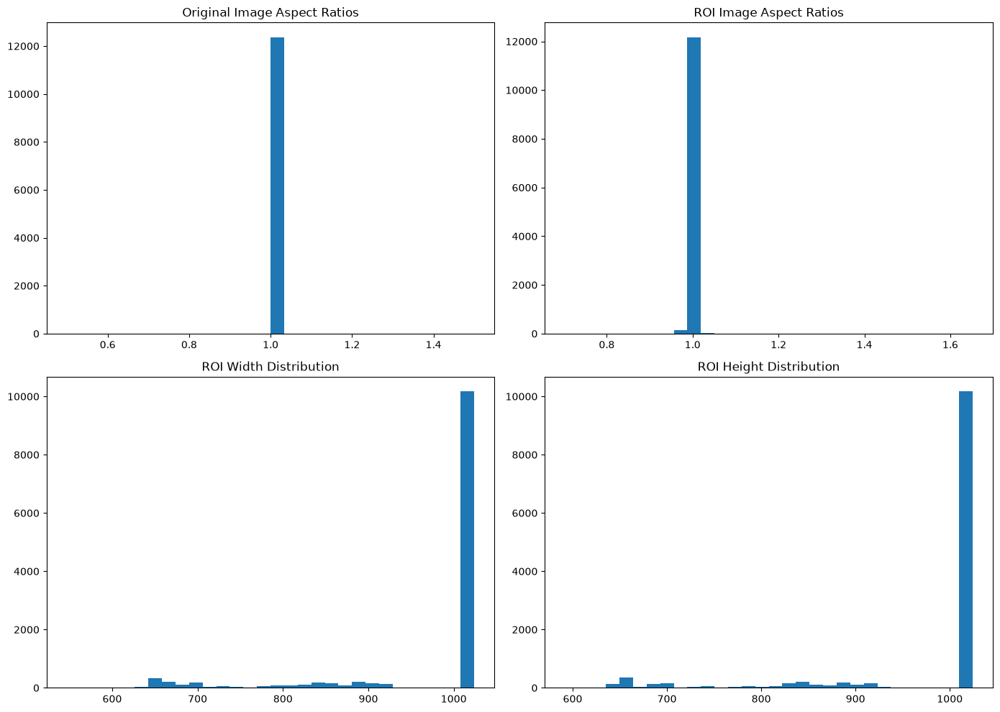


GEOMETRY AUDIT VERIFICATION
[PASS] All original images valid
[PASS] All ROI images valid
[PASS] Original dimensions match manifest
[PASS] ROI dimensions match manifest
[PASS] Area-retention calculations consistent
[PASS] All eight classes preserved
[PASS] All 12364 image records audited

GEOMETRY AUDIT STATUS: PASS

Geometry manifest saved:
d:\skin_research\outputs\reports\phase03c_image_geometry_audit.csv

Geometry report saved.


In [55]:
# ============================================================
# BCN20000 RESEARCH
# PHASE 03C - CELL 2
# ORIGINAL AND ROI IMAGE GEOMETRY AUDIT
# ============================================================

import os
import cv2
import json
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

print("=" * 75)
print("PHASE 03C - IMAGE GEOMETRY AUDIT")
print("=" * 75)

# ------------------------------------------------------------
# 1. LOAD ROI MANIFEST
# ------------------------------------------------------------

roi_df = pd.read_csv(
    REPORT_DIR / "phase03b_full_roi_manifest.csv"
)

assert len(roi_df) == 12364

# ------------------------------------------------------------
# 2. IMAGE GEOMETRY INSPECTION FUNCTION
# ------------------------------------------------------------

geometry_cache = {}


def inspect_image_geometry(image_path):

    path = Path(image_path)

    key = os.path.normcase(
        os.path.abspath(str(path))
    )

    if key in geometry_cache:

        return geometry_cache[key]

    result = {

        "valid": False,

        "width": None,

        "height": None,

        "channels": None,

        "aspect_ratio": None,

        "dtype": None,

        "file_size_mb": None,

        "error": None

    }

    try:

        if not path.is_file():

            raise FileNotFoundError(
                f"File not found: {path}"
            )

        image = cv2.imread(
            str(path),
            cv2.IMREAD_UNCHANGED
        )

        if image is None:

            raise ValueError(
                "Image decoding failed."
            )

        height, width = image.shape[:2]

        if len(image.shape) == 2:

            channels = 1

        else:

            channels = image.shape[2]

        result.update({

            "valid": True,

            "width": int(width),

            "height": int(height),

            "channels": int(channels),

            "aspect_ratio": float(
                width / height
            ),

            "dtype": str(image.dtype),

            "file_size_mb": float(
                path.stat().st_size / (1024 ** 2)
            )

        })

        del image

    except Exception as error:

        result["error"] = str(error)

    geometry_cache[key] = result

    return result


# ------------------------------------------------------------
# 3. AUDIT ORIGINAL AND ROI IMAGES
# ------------------------------------------------------------

geometry_records = []

for row in tqdm(

    roi_df.itertuples(index=False),

    total=len(roi_df),

    desc="Image geometry audit"

):

    original_info = inspect_image_geometry(
        row.source_path
    )

    roi_info = inspect_image_geometry(
        row.processed_path
    )

    # --------------------------------------------------------
    # EXPECTED DIMENSIONS FROM ROI MANIFEST
    # --------------------------------------------------------

    expected_original_width = int(
        row.original_width
    )

    expected_original_height = int(
        row.original_height
    )

    expected_roi_width = int(
        row.cropped_width
    )

    expected_roi_height = int(
        row.cropped_height
    )

    # --------------------------------------------------------
    # DIMENSION MATCHING
    # --------------------------------------------------------

    original_dimension_match = (

        original_info["valid"]

        and original_info["width"]
        == expected_original_width

        and original_info["height"]
        == expected_original_height

    )

    roi_dimension_match = (

        roi_info["valid"]

        and roi_info["width"]
        == expected_roi_width

        and roi_info["height"]
        == expected_roi_height

    )

    # --------------------------------------------------------
    # ACTUAL AREA RETENTION
    # --------------------------------------------------------

    if (
        original_info["valid"]
        and roi_info["valid"]
    ):

        actual_area_retained = (

            roi_info["width"]
            * roi_info["height"]

            /

            (
                original_info["width"]
                * original_info["height"]
            )

            * 100

        )

    else:

        actual_area_retained = None

    recorded_area = float(
        row.area_retained_percentage
    )

    if actual_area_retained is not None:

        area_difference = abs(
            actual_area_retained - recorded_area
        )

    else:

        area_difference = None

    geometry_records.append({

        "filename": row.filename,

        "diagnosis": row.diagnosis,

        "lesion_id": row.lesion_id,

        "leakage_group_id": row.leakage_group_id,

        "crop_applied": bool(row.crop_applied),

        "original_width": original_info["width"],

        "original_height": original_info["height"],

        "original_channels": original_info["channels"],

        "original_aspect_ratio": original_info["aspect_ratio"],

        "original_file_size_mb": original_info["file_size_mb"],

        "roi_width": roi_info["width"],

        "roi_height": roi_info["height"],

        "roi_channels": roi_info["channels"],

        "roi_aspect_ratio": roi_info["aspect_ratio"],

        "roi_file_size_mb": roi_info["file_size_mb"],

        "actual_area_retained": actual_area_retained,

        "recorded_area_retained": recorded_area,

        "area_difference": area_difference,

        "original_valid": original_info["valid"],

        "roi_valid": roi_info["valid"],

        "original_dimension_match": bool(
            original_dimension_match
        ),

        "roi_dimension_match": bool(
            roi_dimension_match
        ),

        "original_error": original_info["error"],

        "roi_error": roi_info["error"]

    })


P3C_GEOMETRY_AUDIT = pd.DataFrame(
    geometry_records
)

# ------------------------------------------------------------
# 4. SAVE COMPLETE GEOMETRY AUDIT
# ------------------------------------------------------------

geometry_path = (
    REPORT_DIR / "phase03c_image_geometry_audit.csv"
)

P3C_GEOMETRY_AUDIT.to_csv(
    geometry_path,
    index=False
)

# ------------------------------------------------------------
# 5. BASIC DIMENSION STATISTICS
# ------------------------------------------------------------

print("\n" + "=" * 70)

print("ORIGINAL IMAGE DIMENSIONS")

print("=" * 70)

display(

    P3C_GEOMETRY_AUDIT[
        [
            "original_width",
            "original_height"
        ]
    ].describe().round(2)

)

print("\nROI IMAGE DIMENSIONS")

display(

    P3C_GEOMETRY_AUDIT[
        [
            "roi_width",
            "roi_height"
        ]
    ].describe().round(2)

)

# ------------------------------------------------------------
# 6. ASPECT RATIO STATISTICS
# ------------------------------------------------------------

print("\nASPECT RATIO ANALYSIS")

aspect_summary = pd.DataFrame({

    "original": P3C_GEOMETRY_AUDIT[
        "original_aspect_ratio"
    ].describe(),

    "roi": P3C_GEOMETRY_AUDIT[
        "roi_aspect_ratio"
    ].describe()

})

display(
    aspect_summary.round(4)
)

# ------------------------------------------------------------
# 7. CLASS-WISE GEOMETRY SUMMARY
# ------------------------------------------------------------

class_geometry_summary = (

    P3C_GEOMETRY_AUDIT.groupby("diagnosis")

    .agg(

        total_images=("filename", "count"),

        cropped_images=("crop_applied", "sum"),

        original_mean_aspect=(
            "original_aspect_ratio",
            "mean"
        ),

        roi_mean_aspect=(
            "roi_aspect_ratio",
            "mean"
        ),

        roi_min_width=("roi_width", "min"),

        roi_min_height=("roi_height", "min"),

        roi_max_width=("roi_width", "max"),

        roi_max_height=("roi_height", "max"),

        average_roi_size_mb=(
            "roi_file_size_mb",
            "mean"
        )

    )

    .reset_index()

)

print("\nCLASS-WISE GEOMETRY SUMMARY")

display(
    class_geometry_summary.round(3)
)

class_geometry_summary.to_csv(
    REPORT_DIR / "phase03c_class_geometry_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 8. IMAGE VALIDITY AND DIMENSION CHECKS
# ------------------------------------------------------------

invalid_original = int(
    (~P3C_GEOMETRY_AUDIT["original_valid"]).sum()
)

invalid_roi = int(
    (~P3C_GEOMETRY_AUDIT["roi_valid"]).sum()
)

original_dimension_errors = int(
    (~P3C_GEOMETRY_AUDIT[
        "original_dimension_match"
    ]).sum()
)

roi_dimension_errors = int(
    (~P3C_GEOMETRY_AUDIT[
        "roi_dimension_match"
    ]).sum()
)

area_mismatch = int(
    (
        P3C_GEOMETRY_AUDIT["area_difference"] > 0.1
    ).sum()
)

print("\nIMAGE VALIDITY")

print("Invalid original images:", invalid_original)

print("Invalid ROI images:", invalid_roi)

print("Original dimension mismatches:",
      original_dimension_errors)

print("ROI dimension mismatches:",
      roi_dimension_errors)

print("Area-retention mismatches:", area_mismatch)

# ------------------------------------------------------------
# 9. EXTREME ASPECT RATIO INVESTIGATION
# ------------------------------------------------------------

extreme_aspect = P3C_GEOMETRY_AUDIT[
    (
        P3C_GEOMETRY_AUDIT["roi_aspect_ratio"] < 0.5
    )
    |
    (
        P3C_GEOMETRY_AUDIT["roi_aspect_ratio"] > 2.0
    )
].copy()

print("\nEXTREME ROI ASPECT RATIOS")

print("Extreme aspect ratio images:", len(extreme_aspect))

if len(extreme_aspect) > 0:

    display(
        extreme_aspect[
            [
                "filename",
                "diagnosis",
                "roi_width",
                "roi_height",
                "roi_aspect_ratio",
                "crop_applied"
            ]
        ].head(30)
    )

# ------------------------------------------------------------
# 10. FILE SIZE ANALYSIS
# ------------------------------------------------------------

print("\nFILE SIZE ANALYSIS")

print(
    "Original average size (MB):",
    round(
        P3C_GEOMETRY_AUDIT[
            "original_file_size_mb"
        ].mean(),
        4
    )
)

print(
    "ROI average size (MB):",
    round(
        P3C_GEOMETRY_AUDIT[
            "roi_file_size_mb"
        ].mean(),
        4
    )
)

# ------------------------------------------------------------
# 11. VISUALIZATION
# ------------------------------------------------------------

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10)
)

axes[0, 0].hist(
    P3C_GEOMETRY_AUDIT[
        "original_aspect_ratio"
    ].dropna(),
    bins=30
)

axes[0, 0].set_title("Original Image Aspect Ratios")

axes[0, 1].hist(
    P3C_GEOMETRY_AUDIT[
        "roi_aspect_ratio"
    ].dropna(),
    bins=30
)

axes[0, 1].set_title("ROI Image Aspect Ratios")

axes[1, 0].hist(
    P3C_GEOMETRY_AUDIT[
        "roi_width"
    ].dropna(),
    bins=30
)

axes[1, 0].set_title("ROI Width Distribution")

axes[1, 1].hist(
    P3C_GEOMETRY_AUDIT[
        "roi_height"
    ].dropna(),
    bins=30
)

axes[1, 1].set_title("ROI Height Distribution")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "phase03c_image_geometry_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 12. FINAL CHECKS
# ------------------------------------------------------------

checks = {

    "All original images valid":
        invalid_original == 0,

    "All ROI images valid":
        invalid_roi == 0,

    "Original dimensions match manifest":
        original_dimension_errors == 0,

    "ROI dimensions match manifest":
        roi_dimension_errors == 0,

    "Area-retention calculations consistent":
        area_mismatch == 0,

    "All eight classes preserved":
        P3C_GEOMETRY_AUDIT["diagnosis"].nunique() == 8,

    "All 12364 image records audited":
        len(P3C_GEOMETRY_AUDIT) == 12364

}

print("\n" + "=" * 75)

print("GEOMETRY AUDIT VERIFICATION")

print("=" * 75)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

geometry_status = (
    "PASS"
    if all(checks.values())
    else "REVIEW_REQUIRED"
)

geometry_report = {

    "phase": "PHASE_03C_CELL_2",

    "status": geometry_status,

    "total_images": len(P3C_GEOMETRY_AUDIT),

    "invalid_original": invalid_original,

    "invalid_roi": invalid_roi,

    "original_dimension_errors": original_dimension_errors,

    "roi_dimension_errors": roi_dimension_errors,

    "area_mismatches": area_mismatch,

    "extreme_aspect_ratio_images": len(extreme_aspect),

    "checks": {
        key: bool(value)
        for key, value in checks.items()
    }

}

with open(
    REPORT_DIR / "PHASE_03C_GEOMETRY_VERIFICATION.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        geometry_report,
        f,
        indent=4
    )

print("\nGEOMETRY AUDIT STATUS:", geometry_status)

print("\nGeometry manifest saved:")
print(geometry_path)

print("\nGeometry report saved.")

print("=" * 75)

In [56]:
# ============================================================
# BCN20000 RESEARCH
# PHASE 03C - CELL 3
# ASPECT-PRESERVING RESIZING PILOT
# ============================================================

import pandas as pd
import numpy as np
import json
import time

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

print("=" * 75)
print("PHASE 03C - RESIZING PILOT EXPERIMENT")
print("=" * 75)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

IMAGE_SIZE = 224

PADDING_RGB = (124, 116, 104)

RESAMPLING = Image.Resampling.LANCZOS

PILOT_PATH = (
    REPORT_DIR / "phase03b_roi_pilot_v2_manifest.csv"
)

RESIZE_ROOT = (
    PREPROCESS_DIR / "resized_pilot_v1"
)

ORIGINAL_RESIZE_DIR = (
    RESIZE_ROOT / "original"
)

ROI_RESIZE_DIR = (
    RESIZE_ROOT / "roi"
)

for folder in [
    ORIGINAL_RESIZE_DIR,
    ROI_RESIZE_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD PILOT MANIFEST
# ------------------------------------------------------------

pilot_resize_df = pd.read_csv(
    PILOT_PATH
)

print("Pilot images:", len(pilot_resize_df))

print(
    "Unique leakage groups:",
    pilot_resize_df["leakage_group_id"].nunique()
)

assert len(pilot_resize_df) == 64

assert (
    pilot_resize_df["leakage_group_id"].nunique()
    == 64
)

assert (
    pilot_resize_df["diagnosis"].nunique()
    == 8
)

# ------------------------------------------------------------
# 3. ASPECT-PRESERVING RESIZE FUNCTION
# ------------------------------------------------------------

def resize_with_padding(
    image_path,
    output_path,
    target_size=224
):

    image_path = Path(image_path)

    output_path = Path(output_path)

    with Image.open(image_path) as img:

        img = img.convert("RGB")

        original_width, original_height = img.size

        # Preserve aspect ratio
        scale = min(
            target_size / original_width,
            target_size / original_height
        )

        new_width = min(
            target_size,
            max(1, int(round(original_width * scale)))
        )

        new_height = min(
            target_size,
            max(1, int(round(original_height * scale)))
        )

        # Resize with high-quality Lanczos interpolation
        resized = img.resize(
            (new_width, new_height),
            RESAMPLING
        )

        # Create neutral padding canvas
        canvas = Image.new(
            "RGB",
            (target_size, target_size),
            PADDING_RGB
        )

        # Center the resized image
        left = (target_size - new_width) // 2

        top = (target_size - new_height) // 2

        canvas.paste(
            resized,
            (left, top)
        )

        # Save lossless PNG
        output_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        canvas.save(
            output_path,
            format="PNG",
            compress_level=3
        )

    # Calculate metadata
    padding_pixels = (
        target_size * target_size
        - new_width * new_height
    )

    padding_percentage = (
        padding_pixels
        / (target_size * target_size)
        * 100
    )

    return {

        "source_width": original_width,

        "source_height": original_height,

        "source_aspect_ratio": (
            original_width / original_height
        ),

        "resized_content_width": new_width,

        "resized_content_height": new_height,

        "output_width": target_size,

        "output_height": target_size,

        "resize_scale": scale,

        "padding_left": left,

        "padding_top": top,

        "padding_right": (
            target_size - new_width - left
        ),

        "padding_bottom": (
            target_size - new_height - top
        ),

        "padding_percentage": padding_percentage,

        "output_file_size_mb": (
            output_path.stat().st_size / (1024 ** 2)
        )

    }


# ------------------------------------------------------------
# 4. PROCESS BOTH EXPERIMENTAL BRANCHES
# ------------------------------------------------------------

resize_records = []

start_time = time.time()

for row in tqdm(
    pilot_resize_df.itertuples(index=False),
    total=len(pilot_resize_df),
    desc="Resizing original and ROI"
):

    filename = Path(row.filename).stem

    # --------------------------------------------------------
    # A. ORIGINAL BRANCH
    # --------------------------------------------------------

    original_output = (
        ORIGINAL_RESIZE_DIR /
        f"{filename}_224.png"
    )

    original_info = resize_with_padding(
        image_path=row.source_path,
        output_path=original_output,
        target_size=IMAGE_SIZE
    )

    resize_records.append({

        "filename": row.filename,

        "diagnosis": row.diagnosis,

        "lesion_id": row.lesion_id,

        "leakage_group_id": row.leakage_group_id,

        "branch": "original",

        "source_path": row.source_path,

        "output_path": str(original_output),

        **original_info

    })

    # --------------------------------------------------------
    # B. ROI BRANCH
    # --------------------------------------------------------

    roi_output = (
        ROI_RESIZE_DIR /
        f"{filename}_roi_224.png"
    )

    roi_info = resize_with_padding(
        image_path=row.cropped_path,
        output_path=roi_output,
        target_size=IMAGE_SIZE
    )

    resize_records.append({

        "filename": row.filename,

        "diagnosis": row.diagnosis,

        "lesion_id": row.lesion_id,

        "leakage_group_id": row.leakage_group_id,

        "branch": "roi",

        "source_path": row.cropped_path,

        "output_path": str(roi_output),

        **roi_info

    })

# ------------------------------------------------------------
# 5. CREATE RESIZING MANIFEST
# ------------------------------------------------------------

P3C_RESIZE_PILOT = pd.DataFrame(
    resize_records
)

resize_manifest_path = (
    REPORT_DIR / "phase03c_resize_pilot_manifest.csv"
)

P3C_RESIZE_PILOT.to_csv(
    resize_manifest_path,
    index=False
)

elapsed = time.time() - start_time

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)

print("RESIZING PILOT SUMMARY")

print("=" * 75)

print(
    "Total resized outputs:",
    len(P3C_RESIZE_PILOT)
)

print(
    "Original branch:",
    int(
        (
            P3C_RESIZE_PILOT["branch"]
            == "original"
        ).sum()
    )
)

print(
    "ROI branch:",
    int(
        (
            P3C_RESIZE_PILOT["branch"]
            == "roi"
        ).sum()
    )
)

print("\nOUTPUT DIMENSIONS")

display(
    P3C_RESIZE_PILOT.groupby("branch").agg(
        output_width_min=("output_width", "min"),
        output_width_max=("output_width", "max"),
        output_height_min=("output_height", "min"),
        output_height_max=("output_height", "max"),
        average_padding=("padding_percentage", "mean"),
        average_file_size_mb=("output_file_size_mb", "mean")
    ).round(4)
)

print("\nROI PADDING STATISTICS")

display(
    P3C_RESIZE_PILOT[
        P3C_RESIZE_PILOT["branch"] == "roi"
    ][
        [
            "filename",
            "source_aspect_ratio",
            "resized_content_width",
            "resized_content_height",
            "padding_percentage"
        ]
    ].head(15)
)

print(
    "\nProcessing time:",
    round(elapsed, 2),
    "seconds"
)

print("\nManifest saved:")
print(resize_manifest_path)

print("=" * 75)

PHASE 03C - RESIZING PILOT EXPERIMENT
Pilot images: 64
Unique leakage groups: 64


Resizing original and ROI:   0%|          | 0/64 [00:00<?, ?it/s]


RESIZING PILOT SUMMARY
Total resized outputs: 128
Original branch: 64
ROI branch: 64

OUTPUT DIMENSIONS


,output_width_min,output_width_max,output_height_min,output_height_max,average_padding,average_file_size_mb
branch,,,,,,
original,224,224,224,224,0.0000,0.0636
roi,224,224,224,224,0.0977,0.0684



ROI PADDING STATISTICS


,filename,source_aspect_ratio,resized_content_width,resized_content_height,padding_percentage
1,BCN_0000009001.jpg,1.000000,224,224,0.000000
3,BCN_0000002238.jpg,1.005967,224,223,0.446429
5,BCN_0000018669.jpg,1.006231,224,223,0.446429
7,BCN_0000006023.jpg,1.000000,224,224,0.000000
9,BCN_0000013514.jpg,1.000000,224,224,0.000000
11,BCN_0000009939.jpg,1.000000,224,224,0.000000
13,BCN_0000019156.jpg,1.000000,224,224,0.000000
15,BCN_0000011442.jpg,1.000000,224,224,0.000000
17,BCN_0000004122.jpg,1.000000,224,224,0.000000
19,BCN_0000004929.jpg,1.000000,224,224,0.000000



Processing time: 4.9 seconds

Manifest saved:
d:\skin_research\outputs\reports\phase03c_resize_pilot_manifest.csv


RESIZING VISUAL COMPARISON


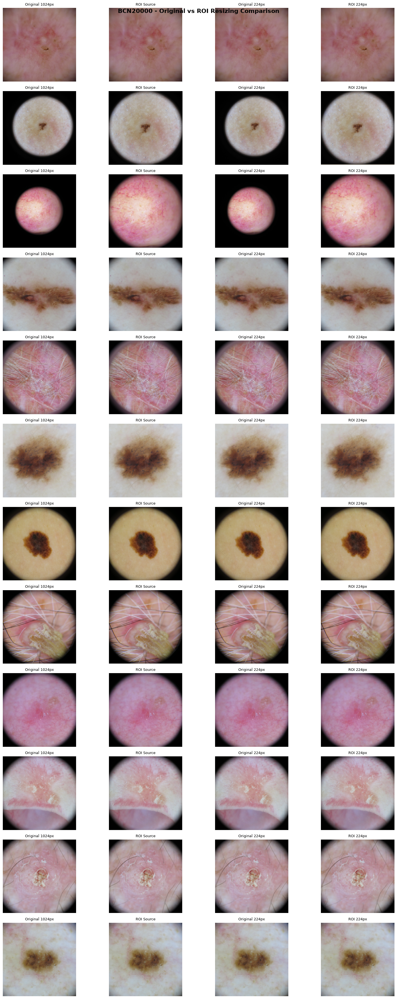


Comparison saved:
d:\skin_research\outputs\figures\phase03c_resizing_pilot_comparison.png

VISUAL COMPARISON COMPLETED


In [57]:
# ============================================================
# PHASE 03C - CELL 4
# RESIZING VISUAL QUALITY COMPARISON
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image

print("=" * 70)
print("RESIZING VISUAL COMPARISON")
print("=" * 70)

sample_names = (
    P3C_RESIZE_PILOT["filename"]
    .drop_duplicates()
    .head(12)
    .tolist()
)

fig, axes = plt.subplots(
    len(sample_names),
    4,
    figsize=(16, len(sample_names) * 3)
)

for i, filename in enumerate(sample_names):

    sample = P3C_RESIZE_PILOT[
        P3C_RESIZE_PILOT["filename"] == filename
    ]

    original_row = sample[
        sample["branch"] == "original"
    ].iloc[0]

    roi_row = sample[
        sample["branch"] == "roi"
    ].iloc[0]

    paths = [

        original_row["source_path"],

        roi_row["source_path"],

        original_row["output_path"],

        roi_row["output_path"]

    ]

    titles = [

        "Original 1024px",

        "ROI Source",

        "Original 224px",

        "ROI 224px"

    ]

    for j, (path, title_text) in enumerate(
        zip(paths, titles)
    ):

        with Image.open(path) as img:

            axes[i, j].imshow(
                img.convert("RGB")
            )

        axes[i, j].set_title(
            title_text,
            fontsize=9
        )

        axes[i, j].axis("off")

    axes[i, 0].set_ylabel(
        filename,
        fontsize=8
    )

plt.suptitle(
    "BCN20000 - Original vs ROI Resizing Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

visual_path = (
    FIGURE_DIR /
    "phase03c_resizing_pilot_comparison.png"
)

plt.savefig(
    visual_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print("\nComparison saved:")
print(visual_path)

print("\nVISUAL COMPARISON COMPLETED")

In [58]:
# ============================================================
# PHASE 03C - CELL 5
# RESIZING PILOT FINAL VERIFICATION
# ============================================================

import json
from pathlib import Path

pilot = P3C_RESIZE_PILOT.copy()

checks = {

    "128 resized outputs created":
        len(pilot) == 128,

    "64 original branch outputs":
        (pilot["branch"] == "original").sum() == 64,

    "64 ROI branch outputs":
        (pilot["branch"] == "roi").sum() == 64,

    "All outputs exactly 224x224":
        (
            (pilot["output_width"] == 224)
            & (pilot["output_height"] == 224)
        ).all(),

    "All output files exist":
        pilot["output_path"].apply(
            lambda x: Path(x).is_file()
        ).all(),

    "All original source images exist":
        pilot["source_path"].apply(
            lambda x: Path(x).is_file()
        ).all(),

    "No missing metadata":
        pilot[
            [
                "filename",
                "diagnosis",
                "leakage_group_id",
                "output_path"
            ]
        ].notna().all().all(),

    "No duplicate branch records":
        not pilot.duplicated(
            subset=["filename", "branch"]
        ).any(),

    "All eight classes preserved":
        pilot["diagnosis"].nunique() == 8,

    "Aspect-preserving resizing":
        (
            pilot["source_aspect_ratio"]
            - (
                pilot["resized_content_width"]
                / pilot["resized_content_height"]
            )
        ).abs().max() < 0.015

}

print("=" * 75)
print("PHASE 03C - RESIZING PILOT VERIFICATION")
print("=" * 75)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

status = (
    "PASS"
    if all(checks.values())
    else "BLOCKED"
)

report = {

    "phase": "PHASE_03C_RESIZING_PILOT",

    "status": status,

    "target_resolution": "224x224",

    "total_outputs": int(len(pilot)),

    "original_outputs": int(
        (pilot["branch"] == "original").sum()
    ),

    "roi_outputs": int(
        (pilot["branch"] == "roi").sum()
    ),

    "checks": {
        key: bool(value)
        for key, value in checks.items()
    }

}

with open(
    REPORT_DIR / "PHASE_03C_RESIZING_PILOT_VERIFICATION.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        report,
        f,
        indent=4
    )

print("\nRESIZING PILOT STATUS:", status)

print("\nReport saved:")
print(
    REPORT_DIR /
    "PHASE_03C_RESIZING_PILOT_VERIFICATION.json"
)

print("=" * 75)

PHASE 03C - RESIZING PILOT VERIFICATION
[PASS] 128 resized outputs created
[PASS] 64 original branch outputs
[PASS] 64 ROI branch outputs
[PASS] All outputs exactly 224x224
[PASS] All output files exist
[PASS] All original source images exist
[PASS] No missing metadata
[PASS] No duplicate branch records
[PASS] All eight classes preserved
[PASS] Aspect-preserving resizing

RESIZING PILOT STATUS: PASS

Report saved:
d:\skin_research\outputs\reports\PHASE_03C_RESIZING_PILOT_VERIFICATION.json


In [59]:
# ============================================================
# BCN20000 RESEARCH
# PHASE 03C - CELL 6
# FULL DATASET DUAL-BRANCH RESIZING
# ============================================================

import time
import json
import pandas as pd
import numpy as np

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

print("=" * 75)
print("PHASE 03C - FULL DATASET RESIZING")
print("=" * 75)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

TARGET_SIZE = 224

PADDING_RGB = (124, 116, 104)

RESAMPLING = Image.Resampling.LANCZOS

BATCH_SAVE_INTERVAL = 500

# ------------------------------------------------------------
# 2. DIRECTORY CONFIGURATION
# ------------------------------------------------------------

RESIZE_ROOT = (
    PREPROCESS_DIR / "resized_full_v1"
)

ORIGINAL_DIR = RESIZE_ROOT / "original"

ROI_DIR = RESIZE_ROOT / "roi"

ORIGINAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

ROI_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FULL_RESIZE_MANIFEST = (
    REPORT_DIR / "phase03c_full_resize_manifest.csv"
)

PROGRESS_PATH = (
    REPORT_DIR / "phase03c_full_resize_progress.csv"
)

# ------------------------------------------------------------
# 3. LOAD SOURCE MANIFEST
# ------------------------------------------------------------

source_df = pd.read_csv(
    REPORT_DIR / "phase03b_full_roi_manifest.csv"
)

if len(source_df) != 12364:

    raise ValueError(
        "Expected 12364 source images."
    )

if source_df["filename"].duplicated().any():

    raise ValueError(
        "Duplicate filenames in source manifest."
    )

# ------------------------------------------------------------
# 4. RESIZING FUNCTION
# ------------------------------------------------------------

def resize_image_aspect_preserving(
    source_path,
    output_path
):

    source_path = Path(source_path)

    output_path = Path(output_path)

    with Image.open(source_path) as image:

        image = image.convert("RGB")

        source_width, source_height = image.size

        scale = min(
            TARGET_SIZE / source_width,
            TARGET_SIZE / source_height
        )

        new_width = max(
            1,
            min(
                TARGET_SIZE,
                int(round(source_width * scale))
            )
        )

        new_height = max(
            1,
            min(
                TARGET_SIZE,
                int(round(source_height * scale))
            )
        )

        resized = image.resize(
            (new_width, new_height),
            RESAMPLING
        )

        canvas = Image.new(
            "RGB",
            (TARGET_SIZE, TARGET_SIZE),
            PADDING_RGB
        )

        left = (
            TARGET_SIZE - new_width
        ) // 2

        top = (
            TARGET_SIZE - new_height
        ) // 2

        canvas.paste(
            resized,
            (left, top)
        )

        output_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        canvas.save(
            output_path,
            format="PNG",
            compress_level=3
        )

    return {

        "source_width": source_width,

        "source_height": source_height,

        "source_aspect_ratio": (
            source_width / source_height
        ),

        "content_width": new_width,

        "content_height": new_height,

        "output_width": TARGET_SIZE,

        "output_height": TARGET_SIZE,

        "padding_left": left,

        "padding_top": top,

        "padding_right": (
            TARGET_SIZE - new_width - left
        ),

        "padding_bottom": (
            TARGET_SIZE - new_height - top
        ),

        "padding_percentage": (

            (
                TARGET_SIZE * TARGET_SIZE
                - new_width * new_height
            )

            / (TARGET_SIZE * TARGET_SIZE)

            * 100

        ),

        "output_file_size_mb": (
            output_path.stat().st_size / (1024 ** 2)
        )

    }


# ------------------------------------------------------------
# 5. RESUME SUPPORT
# ------------------------------------------------------------

records = []

completed_keys = set()

if PROGRESS_PATH.exists():

    previous_progress = pd.read_csv(
        PROGRESS_PATH
    )

    if (
        "target_size" in previous_progress.columns
        and "padding_rgb" in previous_progress.columns
        and (
            previous_progress["target_size"] == TARGET_SIZE
        ).all()
        and (
            previous_progress["padding_rgb"] == str(PADDING_RGB)
        ).all()
    ):

        records = previous_progress.to_dict(
            orient="records"
        )

        for record in records:

            if Path(record["output_path"]).is_file():

                completed_keys.add((
                    record["filename"],
                    record["branch"]
                ))

        print(
            "Previously completed outputs:",
            len(completed_keys)
        )

    else:

        print(
            "Previous configuration differs. "
            "Starting a new processing manifest."
        )

        records = []
        completed_keys = set()

# ------------------------------------------------------------
# 6. PROCESS BOTH BRANCHES
# ------------------------------------------------------------

total_tasks = len(source_df) * 2

start_time = time.time()

for row in tqdm(
    source_df.itertuples(index=False),
    total=len(source_df),
    desc="Full dataset resizing"
):

    filename = row.filename

    stem = Path(filename).stem

    branch_inputs = [

        (
            "original",

            row.source_path,

            ORIGINAL_DIR / f"{stem}_224.png"

        ),

        (
            "roi",

            row.processed_path,

            ROI_DIR / f"{stem}_roi_224.png"

        )

    ]

    for branch_name, source_path, output_path in branch_inputs:

        key = (
            filename,
            branch_name
        )

        if (
            key in completed_keys
            and output_path.is_file()
        ):

            continue

        # Perform resizing
        resize_info = resize_image_aspect_preserving(
            source_path,
            output_path
        )

        record = {

            "filename": filename,

            "diagnosis": row.diagnosis,

            "lesion_id": row.lesion_id,

            "leakage_group_id": row.leakage_group_id,

            "branch": branch_name,

            "source_path": str(source_path),

            "output_path": str(output_path),

            "crop_applied": bool(row.crop_applied),

            "target_size": TARGET_SIZE,

            "padding_rgb": str(PADDING_RGB),

            **resize_info

        }

        records.append(record)

        completed_keys.add(key)

        # Periodic checkpoint
        if len(records) % BATCH_SAVE_INTERVAL == 0:

            pd.DataFrame(records).to_csv(
                PROGRESS_PATH,
                index=False
            )


# ------------------------------------------------------------
# 7. SAVE FINAL MANIFEST
# ------------------------------------------------------------

full_resize_df = pd.DataFrame(records)

full_resize_df = full_resize_df.drop_duplicates(
    subset=["filename", "branch"],
    keep="last"
)

full_resize_df = full_resize_df.sort_values(
    ["branch", "filename"]
).reset_index(drop=True)

full_resize_df.to_csv(
    FULL_RESIZE_MANIFEST,
    index=False
)

# Final checkpoint
full_resize_df.to_csv(
    PROGRESS_PATH,
    index=False
)

elapsed = time.time() - start_time

# ------------------------------------------------------------
# 8. STATISTICS
# ------------------------------------------------------------

print("\n" + "=" * 75)

print("FULL RESIZING SUMMARY")

print("=" * 75)

print("Total outputs:", len(full_resize_df))

print(
    "Original outputs:",
    (full_resize_df["branch"] == "original").sum()
)

print(
    "ROI outputs:",
    (full_resize_df["branch"] == "roi").sum()
)

print("\nBranch-wise statistics:")

display(
    full_resize_df.groupby("branch").agg(

        total_images=("filename", "count"),

        average_padding=(
            "padding_percentage",
            "mean"
        ),

        average_file_size_mb=(
            "output_file_size_mb",
            "mean"
        ),

        minimum_content_width=(
            "content_width",
            "min"
        ),

        minimum_content_height=(
            "content_height",
            "min"
        )

    ).round(4)
)

print(
    "\nProcessing time:",
    round(elapsed / 60, 2),
    "minutes"
)

print("\nFull resize manifest:")
print(FULL_RESIZE_MANIFEST)

print("\nFULL RESIZING PROCESS COMPLETED")

print("=" * 75)

PHASE 03C - FULL DATASET RESIZING


Full dataset resizing:   0%|          | 0/12364 [00:00<?, ?it/s]


FULL RESIZING SUMMARY
Total outputs: 24728
Original outputs: 12364
ROI outputs: 12364

Branch-wise statistics:


,total_images,average_padding,average_file_size_mb,minimum_content_width,minimum_content_height
branch,,,,,
original,12364,0.0000,0.0652,224,224
roi,12364,0.1131,0.0687,157,136



Processing time: 10.37 minutes

Full resize manifest:
d:\skin_research\outputs\reports\phase03c_full_resize_manifest.csv

FULL RESIZING PROCESS COMPLETED


In [60]:
# ============================================================
# PHASE 03C - CELL 7
# FULL DATASET RESIZING VERIFICATION
# ============================================================

import pandas as pd
import json

from pathlib import Path
from PIL import Image

print("=" * 75)
print("PHASE 03C - FULL RESIZING VERIFICATION")
print("=" * 75)

manifest = pd.read_csv(
    FULL_RESIZE_MANIFEST
)

original_branch = manifest[
    manifest["branch"] == "original"
]

roi_branch = manifest[
    manifest["branch"] == "roi"
]

# ------------------------------------------------------------
# 1. OUTPUT FILE VALIDATION
# ------------------------------------------------------------

missing_files = sum(

    not Path(path).is_file()

    for path in manifest["output_path"]

)

# ------------------------------------------------------------
# 2. DIMENSION VALIDATION
# ------------------------------------------------------------

dimension_errors = 0

for path in tqdm(
    manifest["output_path"],
    total=len(manifest),
    desc="Verifying image dimensions"
):

    try:

        with Image.open(path) as image:

            if image.size != (224, 224):

                dimension_errors += 1

    except Exception:

        dimension_errors += 1


# ------------------------------------------------------------
# 3. METADATA VALIDATION
# ------------------------------------------------------------

duplicate_branch_records = int(
    manifest.duplicated(
        subset=["filename", "branch"]
    ).sum()
)

missing_metadata = int(
    manifest[
        [
            "filename",
            "diagnosis",
            "leakage_group_id",
            "output_path"
        ]
    ].isna().any(axis=1).sum()
)

# ------------------------------------------------------------
# 4. CLASS COVERAGE
# ------------------------------------------------------------

original_classes = set(
    original_branch["diagnosis"].unique()
)

roi_classes = set(
    roi_branch["diagnosis"].unique()
)

expected_classes = set(
    clean_df["diagnosis"].unique()
)

# ------------------------------------------------------------
# 5. BRANCH MAPPING
# ------------------------------------------------------------

original_names = set(
    original_branch["filename"]
)

roi_names = set(
    roi_branch["filename"]
)

branch_mapping_valid = (
    original_names == roi_names
    and len(original_names) == 12364
)

# ------------------------------------------------------------
# 6. FINAL CHECKS
# ------------------------------------------------------------

checks = {

    "Total outputs equal 24728":
        len(manifest) == 24728,

    "Original branch contains 12364 images":
        len(original_branch) == 12364,

    "ROI branch contains 12364 images":
        len(roi_branch) == 12364,

    "All output files exist":
        missing_files == 0,

    "All outputs are 224x224":
        dimension_errors == 0,

    "No duplicate branch records":
        duplicate_branch_records == 0,

    "No missing metadata":
        missing_metadata == 0,

    "Original branch has eight classes":
        original_classes == expected_classes,

    "ROI branch has eight classes":
        roi_classes == expected_classes,

    "Original and ROI mapping consistent":
        branch_mapping_valid,

    "All images use RGB-compatible output":
        manifest["output_width"].eq(224).all()

}

print("\n" + "=" * 75)

print("FULL RESIZING VERIFICATION")

print("=" * 75)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

status = (
    "PASS"
    if all(checks.values())
    else "BLOCKED"
)

# ------------------------------------------------------------
# 7. SAVE FINAL REPORT
# ------------------------------------------------------------

report = {

    "phase": "PHASE_03C_FULL_RESIZING",

    "status": status,

    "total_outputs": int(len(manifest)),

    "original_images": int(len(original_branch)),

    "roi_images": int(len(roi_branch)),

    "missing_files": int(missing_files),

    "dimension_errors": int(dimension_errors),

    "checks": {
        key: bool(value)
        for key, value in checks.items()
    }

}

with open(
    REPORT_DIR / "PHASE_03C_FULL_RESIZING_VERIFICATION.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        report,
        f,
        indent=4
    )

print("\nFULL RESIZING STATUS:", status)

print("\nReport saved:")

print(
    REPORT_DIR /
    "PHASE_03C_FULL_RESIZING_VERIFICATION.json"
)

print("=" * 75)

PHASE 03C - FULL RESIZING VERIFICATION


Verifying image dimensions:   0%|          | 0/24728 [00:00<?, ?it/s]


FULL RESIZING VERIFICATION
[PASS] Total outputs equal 24728
[PASS] Original branch contains 12364 images
[PASS] ROI branch contains 12364 images
[PASS] All output files exist
[PASS] All outputs are 224x224
[PASS] No duplicate branch records
[PASS] No missing metadata
[PASS] Original branch has eight classes
[PASS] ROI branch has eight classes
[PASS] Original and ROI mapping consistent
[PASS] All images use RGB-compatible output

FULL RESIZING STATUS: PASS

Report saved:
d:\skin_research\outputs\reports\PHASE_03C_FULL_RESIZING_VERIFICATION.json


In [61]:
# ============================================================
# PHASE 03C - CELL 8
# FULL RESIZED IMAGE PADDING AUDIT
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path
from matplotlib.backends.backend_pdf import PdfPages

print("=" * 75)
print("PHASE 03C - FULL RESIZE PADDING AUDIT")
print("=" * 75)

# ------------------------------------------------------------
# 1. LOAD RESIZE MANIFEST
# ------------------------------------------------------------

resize_df = pd.read_csv(
    REPORT_DIR / "phase03c_full_resize_manifest.csv"
)

roi_df = resize_df[
    resize_df["branch"] == "roi"
].copy()

original_df = resize_df[
    resize_df["branch"] == "original"
].copy()

# ------------------------------------------------------------
# 2. PADDING STATISTICS
# ------------------------------------------------------------

print("\nBRANCH-WISE PADDING STATISTICS")

display(
    resize_df.groupby("branch")[
        "padding_percentage"
    ].describe().round(4)
)

# ------------------------------------------------------------
# 3. PADDING DISTRIBUTION
# ------------------------------------------------------------

thresholds = [0, 1, 5, 10, 20, 30, 50]

padding_distribution = []

for threshold in thresholds:

    count = int(
        (roi_df["padding_percentage"] > threshold).sum()
    )

    padding_distribution.append({

        "padding_threshold": f">{threshold}%",

        "image_count": count,

        "percentage": count / len(roi_df) * 100

    })

padding_summary = pd.DataFrame(
    padding_distribution
)

print("\nROI PADDING THRESHOLD DISTRIBUTION")

display(padding_summary.round(3))

# ------------------------------------------------------------
# 4. TOP 30 HIGHEST PADDING IMAGES
# ------------------------------------------------------------

top_padding = roi_df.nlargest(
    30,
    "padding_percentage"
).copy()

print("\nTOP 30 HIGHEST PADDING IMAGES")

display(
    top_padding[
        [
            "filename",
            "diagnosis",
            "content_width",
            "content_height",
            "padding_percentage",
            "source_aspect_ratio"
        ]
    ].round(3)
)

top_padding.to_csv(
    REPORT_DIR / "phase03c_high_padding_images.csv",
    index=False
)

# ------------------------------------------------------------
# 5. VERIFY PADDING CALCULATION
# ------------------------------------------------------------

calculated_padding = (

    (
        224 * 224
        -
        top_padding["content_width"]
        * top_padding["content_height"]
    )

    / (224 * 224)

    * 100

)

padding_error = np.abs(
    calculated_padding
    - top_padding["padding_percentage"]
)

print(
    "\nMaximum padding calculation error:",
    padding_error.max()
)

# ------------------------------------------------------------
# 6. CREATE TOP 16 IMAGE REVIEW PDF
# ------------------------------------------------------------

review_df = roi_df.nlargest(
    16,
    "padding_percentage"
).reset_index(drop=True)

pdf_path = (
    FIGURE_DIR /
    "phase03c_high_padding_visual_review.pdf"
)

with PdfPages(pdf_path) as pdf:

    for start in range(0, len(review_df), 4):

        page = review_df.iloc[
            start:start + 4
        ]

        fig, axes = plt.subplots(
            len(page),
            2,
            figsize=(10, 4 * len(page))
        )

        if len(page) == 1:
            axes = np.array([axes])

        fig.suptitle(
            "High Padding ROI Image Quality Review",
            fontsize=14
        )

        for ax_row, (_, row) in zip(
            axes,
            page.iterrows()
        ):

            with Image.open(
                row["source_path"]
            ) as source:

                ax_row[0].imshow(
                    source.convert("RGB")
                )

            with Image.open(
                row["output_path"]
            ) as output:

                ax_row[1].imshow(
                    output.convert("RGB")
                )

            ax_row[0].set_title(
                f"ROI Source\n{row['filename']}",
                fontsize=9
            )

            ax_row[1].set_title(
                f"224x224\n"
                f"Padding: {row['padding_percentage']:.2f}%",
                fontsize=9
            )

            ax_row[0].axis("off")
            ax_row[1].axis("off")

        plt.tight_layout()

        pdf.savefig(
            fig,
            bbox_inches="tight"
        )

        plt.close(fig)

# ------------------------------------------------------------
# 7. FINAL REPORT
# ------------------------------------------------------------

audit_checks = {

    "ROI images available": len(roi_df) == 12364,

    "Original images available": len(original_df) == 12364,

    "All output dimensions 224x224":
        (
            (resize_df["output_width"] == 224)
            & (resize_df["output_height"] == 224)
        ).all(),

    "Padding values valid":
        resize_df["padding_percentage"].between(0, 100).all(),

    "Padding calculation consistent":
        padding_error.max() < 0.001

}

print("\n" + "=" * 75)
print("PADDING AUDIT VERIFICATION")
print("=" * 75)

for name, result in audit_checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

print("\nHigh padding PDF:")
print(pdf_path)

print("\nPadding report:")
print(
    REPORT_DIR / "phase03c_high_padding_images.csv"
)

print("=" * 75)

PHASE 03C - FULL RESIZE PADDING AUDIT

BRANCH-WISE PADDING STATISTICS


,count,mean,std,min,25%,50%,75%,max
branch,,,,,,,,
original,12364.0,0.0000,0.0000,0.0,0.0,0.0,0.0,0.0000
roi,12364.0,0.1131,0.6876,0.0,0.0,0.0,0.0,39.2857



ROI PADDING THRESHOLD DISTRIBUTION


,padding_threshold,image_count,percentage
0,>0%,1474,11.922
1,>1%,300,2.426
2,>5%,17,0.137
3,>10%,6,0.049
4,>20%,4,0.032
5,>30%,1,0.008
6,>50%,0,0.000



TOP 30 HIGHEST PADDING IMAGES


,filename,diagnosis,content_width,content_height,padding_percentage,source_aspect_ratio
15052,BCN_0000004505.jpg,MEL,224,136,39.286,1.652
23443,BCN_0000018248.jpg,MEL,157,224,29.911,0.703
22042,BCN_0000015944.jpg,MEL,169,224,24.554,0.754
14689,BCN_0000003868.jpg,MEL,224,175,21.875,1.277
14095,BCN_0000002894.jpg,MEL,190,224,15.179,0.847
24226,BCN_0000019550.jpg,BCC,224,193,13.839,1.160
13538,BCN_0000001959.jpg,SCC,224,202,9.821,1.106
22701,BCN_0000017008.jpg,MEL,224,202,9.821,1.106
16105,BCN_0000006182.jpg,NV,224,207,7.589,1.085
22520,BCN_0000016708.jpg,BCC,207,224,7.589,0.923



Maximum padding calculation error: 0.0

PADDING AUDIT VERIFICATION
[PASS] ROI images available
[PASS] Original images available
[PASS] All output dimensions 224x224
[PASS] Padding values valid
[PASS] Padding calculation consistent

High padding PDF:
d:\skin_research\outputs\figures\phase03c_high_padding_visual_review.pdf

Padding report:
d:\skin_research\outputs\reports\phase03c_high_padding_images.csv


In [65]:
# ============================================================
# BCN20000 RESEARCH
# PHASE 03C - CELL 9
# FINAL HIGH PADDING ROI PROVENANCE AUDIT
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import json

from PIL import Image
from pathlib import Path
from matplotlib.backends.backend_pdf import PdfPages

print("=" * 75)
print("FINAL HIGH PADDING ROI PROVENANCE AUDIT")
print("=" * 75)

# ------------------------------------------------------------
# 1. LOAD MANIFESTS
# ------------------------------------------------------------

roi_manifest = pd.read_csv(
    REPORT_DIR / "phase03b_full_roi_manifest.csv"
)

resize_manifest = pd.read_csv(
    REPORT_DIR / "phase03c_full_resize_manifest.csv"
)

# ------------------------------------------------------------
# 2. SELECT ROI RESIZED IMAGES
# ------------------------------------------------------------

roi_resized = resize_manifest[
    resize_manifest["branch"] == "roi"
].copy()

high_padding = roi_resized[
    roi_resized["padding_percentage"] > 20
].copy()

print("ROI resized images:", len(roi_resized))
print("High-padding images:", len(high_padding))

# ------------------------------------------------------------
# 3. SELECT ROI SOURCE METADATA
# ------------------------------------------------------------

roi_metadata = roi_manifest[

    [
        "filename",
        "source_path",
        "processed_path",
        "crop_applied",
        "bbox",
        "intensity_ratio"

    ]

].copy()

# Rename all potentially duplicated columns
roi_metadata = roi_metadata.rename(

    columns={

        "source_path": "original_source_path",

        "processed_path": "roi_source_path",

        "crop_applied": "roi_crop_applied"

    }

)

# Rename resize manifest column
high_padding = high_padding.rename(

    columns={

        "crop_applied": "resize_crop_applied"

    }

)

# ------------------------------------------------------------
# 4. VALIDATE UNIQUE FILENAMES
# ------------------------------------------------------------

if high_padding["filename"].duplicated().any():

    raise ValueError(
        "Duplicate filenames in resized manifest."
    )

if roi_metadata["filename"].duplicated().any():

    raise ValueError(
        "Duplicate filenames in ROI manifest."
    )

# ------------------------------------------------------------
# 5. MERGE METADATA
# ------------------------------------------------------------

audit_df = high_padding.merge(

    roi_metadata,

    on="filename",

    how="left",

    validate="one_to_one",

    indicator=True

)

unmatched = int(
    (audit_df["_merge"] != "both").sum()
)

audit_df = audit_df.drop(
    columns=["_merge"]
)

print("\nUnmatched records:", unmatched)

if unmatched > 0:

    raise ValueError(
        "ROI metadata matching failed."
    )

# ------------------------------------------------------------
# 6. VERIFY CROP STATUS CONSISTENCY
# ------------------------------------------------------------

crop_status_mismatch = int(

    (
        audit_df["resize_crop_applied"].astype(bool)

        !=

        audit_df["roi_crop_applied"].astype(bool)

    ).sum()

)

print(
    "Crop status mismatches:",
    crop_status_mismatch
)

# ------------------------------------------------------------
# 7. VERIFY ROI SOURCE PATH
# ------------------------------------------------------------

source_path_mismatch = int(

    (

        audit_df["source_path"].astype(str)

        !=

        audit_df["roi_source_path"].astype(str)

    ).sum()

)

print(
    "ROI source path mismatches:",
    source_path_mismatch
)

# ------------------------------------------------------------
# 8. DISPLAY IMAGE DETAILS
# ------------------------------------------------------------

print("\nHIGH PADDING IMAGE DETAILS")

display(

    audit_df[

        [

            "filename",

            "diagnosis",

            "roi_crop_applied",

            "resize_crop_applied",

            "padding_percentage",

            "bbox",

            "intensity_ratio"

        ]

    ]

)

# ------------------------------------------------------------
# 9. VALIDATE IMAGE FILES
# ------------------------------------------------------------

path_columns = [

    "original_source_path",

    "roi_source_path",

    "output_path"

]

missing_files = {}

for column in path_columns:

    missing_files[column] = sum(

        not Path(path).is_file()

        for path in audit_df[column]

    )

print("\nFILE VALIDATION")

for name, count in missing_files.items():

    print(
        f"{name}: {count} missing"
    )

# ------------------------------------------------------------
# 10. GENERATE THREE-WAY VISUAL COMPARISON
# ------------------------------------------------------------

pdf_path = (

    FIGURE_DIR /

    "phase03c_high_padding_original_roi_resize_audit.pdf"

)

with PdfPages(pdf_path) as pdf:

    for _, row in audit_df.iterrows():

        fig, axes = plt.subplots(
            1,
            3,
            figsize=(15, 5)
        )

        paths = [

            row["original_source_path"],

            row["roi_source_path"],

            row["output_path"]

        ]

        titles = [

            "Original 1024x1024",

            "ROI Source",

            (
                f"Resized 224x224\n"
                f"Padding: {row['padding_percentage']:.2f}%"
            )

        ]

        for ax, path, title_text in zip(
            axes,
            paths,
            titles
        ):

            with Image.open(path) as image:

                ax.imshow(
                    image.convert("RGB")
                )

            ax.set_title(
                title_text,
                fontsize=10
            )

            ax.axis("off")

        fig.suptitle(

            f"{row['filename']} | "
            f"{row['diagnosis']} | "
            f"ROI cropped: {row['roi_crop_applied']}",

            fontsize=12

        )

        plt.tight_layout()

        pdf.savefig(
            fig,
            bbox_inches="tight"
        )

        plt.close(fig)

# ------------------------------------------------------------
# 11. FINAL VERIFICATION
# ------------------------------------------------------------

checks = {

    "Exactly four high-padding images":
        len(audit_df) == 4,

    "All ROI metadata matched":
        unmatched == 0,

    "Crop status consistent":
        crop_status_mismatch == 0,

    "ROI source path consistent":
        source_path_mismatch == 0,

    "All four images are cropped":
        audit_df["roi_crop_applied"].eq(True).all(),

    "All original images available":
        missing_files["original_source_path"] == 0,

    "All ROI source images available":
        missing_files["roi_source_path"] == 0,

    "All resized images available":
        missing_files["output_path"] == 0

}

print("\n" + "=" * 75)
print("FINAL PROVENANCE VERIFICATION")
print("=" * 75)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

status = (
    "PASS"
    if all(checks.values())
    else "BLOCKED"
)

# ------------------------------------------------------------
# 12. SAVE FINAL REPORT
# ------------------------------------------------------------

final_report = {

    "phase": "PHASE_03C_HIGH_PADDING_AUDIT",

    "status": status,

    "high_padding_images": int(len(audit_df)),

    "unmatched_records": unmatched,

    "crop_status_mismatches": crop_status_mismatch,

    "source_path_mismatches": source_path_mismatch,

    "checks": {

        key: bool(value)

        for key, value in checks.items()

    },

    "review_pdf": str(pdf_path)

}

with open(

    REPORT_DIR /
    "PHASE_03C_HIGH_PADDING_AUDIT.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(
        final_report,
        f,
        indent=4
    )

print("\nPROVENANCE AUDIT STATUS:", status)

print("\nVisual comparison PDF:")
print(pdf_path)

print("\nFinal report saved:")
print(
    REPORT_DIR /
    "PHASE_03C_HIGH_PADDING_AUDIT.json"
)

print("=" * 75)

FINAL HIGH PADDING ROI PROVENANCE AUDIT
ROI resized images: 12364
High-padding images: 4

Unmatched records: 0
Crop status mismatches: 0
ROI source path mismatches: 0

HIGH PADDING IMAGE DETAILS


,filename,diagnosis,roi_crop_applied,resize_crop_applied,padding_percentage,bbox,intensity_ratio
0,BCN_0000003868.jpg,MEL,True,True,21.875000,"[26, 41, 969, 759]",1.122439
1,BCN_0000004505.jpg,MEL,True,True,39.285714,"[0, 0, 1024, 620]",1.122846
2,BCN_0000015944.jpg,MEL,True,True,24.553571,"[117, 144, 586, 777]",1.429778
3,BCN_0000018248.jpg,MEL,True,True,29.910714,"[353, 132, 547, 778]",1.415216



FILE VALIDATION
original_source_path: 0 missing
roi_source_path: 0 missing
output_path: 0 missing

FINAL PROVENANCE VERIFICATION
[PASS] Exactly four high-padding images
[PASS] All ROI metadata matched
[PASS] Crop status consistent
[PASS] ROI source path consistent
[PASS] All four images are cropped
[PASS] All original images available
[PASS] All ROI source images available
[PASS] All resized images available

PROVENANCE AUDIT STATUS: PASS

Visual comparison PDF:
d:\skin_research\outputs\figures\phase03c_high_padding_original_roi_resize_audit.pdf

Final report saved:
d:\skin_research\outputs\reports\PHASE_03C_HIGH_PADDING_AUDIT.json


In [67]:

# ============================================================
# BCN20000 RESEARCH
# PHASE 03C - CELL 10
# FULL ROI CROP SAFETY AUDIT
# CORRECTED AND IMPROVED VERSION
# ============================================================

import pandas as pd
import numpy as np
import ast
import json

from pathlib import Path

print("=" * 75)
print("PHASE 03C - FULL ROI CROP SAFETY AUDIT")
print("=" * 75)

# ------------------------------------------------------------
# 1. PATH CONFIGURATION
# ------------------------------------------------------------

REPORT_DIR = Path("outputs/reports")

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MANIFEST_PATH = (
    REPORT_DIR / "phase03b_full_roi_manifest.csv"
)

# ------------------------------------------------------------
# 2. LOAD ORIGINAL ROI MANIFEST
# ------------------------------------------------------------

if not MANIFEST_PATH.is_file():

    raise FileNotFoundError(
        f"ROI manifest not found: {MANIFEST_PATH}"
    )

roi_df = pd.read_csv(
    MANIFEST_PATH
)

print("\n[1] DATASET INFORMATION")

print("Total images:", len(roi_df))

print(
    "Available columns:",
    roi_df.columns.tolist()
)

# ------------------------------------------------------------
# 3. REQUIRED COLUMN VALIDATION
# ------------------------------------------------------------

required_columns = [

    "filename",
    "diagnosis",
    "lesion_id",
    "leakage_group_id",
    "bbox",
    "crop_applied",
    "original_width",
    "original_height",
    "cropped_width",
    "cropped_height",
    "intensity_ratio",
    "area_retained_percentage"

]

missing_columns = [

    col for col in required_columns

    if col not in roi_df.columns

]

if missing_columns:

    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# ------------------------------------------------------------
# 4. MANIFEST INTEGRITY CHECK
# ------------------------------------------------------------

if roi_df["filename"].duplicated().any():

    raise ValueError(
        "Duplicate filenames detected in ROI manifest."
    )

if roi_df["diagnosis"].isna().any():

    raise ValueError(
        "Missing diagnosis labels detected."
    )

if roi_df["bbox"].isna().any() and (
    roi_df["crop_applied"].astype(str).str.lower()
    == "true"
).any():

    raise ValueError(
        "Missing bounding box detected."
    )

# ------------------------------------------------------------
# 5. BOOLEAN CONVERSION
# ------------------------------------------------------------

def safe_boolean(value):

    if isinstance(value, (bool, np.bool_)):

        return bool(value)

    if pd.isna(value):

        return False

    value = str(value).strip().lower()

    if value in ["true", "1", "yes"]:

        return True

    if value in ["false", "0", "no"]:

        return False

    raise ValueError(
        f"Invalid boolean value: {value}"
    )


roi_df["crop_applied"] = (
    roi_df["crop_applied"].apply(safe_boolean)
)

# ------------------------------------------------------------
# 6. SELECT CROPPED IMAGES
# ------------------------------------------------------------

cropped_df = roi_df[
    roi_df["crop_applied"]
].copy()

print("\n[2] CROPPED IMAGE SELECTION")

print("Original images:", len(roi_df))

print("Cropped images:", len(cropped_df))

print(
    "Original retained:",
    len(roi_df) - len(cropped_df)
)

if len(cropped_df) == 0:

    raise ValueError(
        "No cropped images found."
    )

# ------------------------------------------------------------
# 7. BOUNDING BOX PARSER
# ------------------------------------------------------------

def parse_bbox(value):

    if isinstance(value, str):

        value = ast.literal_eval(value)

    if isinstance(value, (list, tuple)):

        if len(value) != 4:

            raise ValueError(
                f"Invalid bbox length: {value}"
            )

        if not all(
            np.isfinite(float(x)) for x in value
        ):

            raise ValueError(
                f"Non-finite bbox value: {value}"
            )

        return [int(x) for x in value]

    raise ValueError(
        f"Invalid bounding box: {value}"
    )

# ------------------------------------------------------------
# 8. ANALYZE EVERY CROPPED IMAGE
# ------------------------------------------------------------

records = []

invalid_bbox_records = []

for _, row in cropped_df.iterrows():

    filename = str(row["filename"])

    diagnosis = str(row["diagnosis"])

    lesion_id = str(row["lesion_id"])

    leakage_group_id = str(
        row["leakage_group_id"]
    )

    # --------------------------------------------------------
    # A. PARSE BOUNDING BOX
    # --------------------------------------------------------

    try:

        bbox = parse_bbox(
            row["bbox"]
        )

        x, y, w, h = bbox

        W = int(row["original_width"])

        H = int(row["original_height"])

        # ----------------------------------------------------
        # B. VALIDATE DIMENSIONS
        # ----------------------------------------------------

        if min(W, H, w, h) <= 0:

            raise ValueError(
                "Invalid image or crop dimensions."
            )

        # ----------------------------------------------------
        # C. VALIDATE BOUNDING BOX COORDINATES
        # ----------------------------------------------------

        if (

            x < 0

            or y < 0

            or x + w > W

            or y + h > H

        ):

            raise ValueError(
                "Bounding box exceeds image boundaries."
            )

        # ----------------------------------------------------
        # D. CALCULATE REMAINING MARGINS
        # ----------------------------------------------------

        left_margin = x

        top_margin = y

        right_margin = W - (x + w)

        bottom_margin = H - (y + h)

        # ----------------------------------------------------
        # E. CALCULATE AREA RETENTION
        # ----------------------------------------------------

        area_retained = (

            (w * h)

            /

            (W * H)

            * 100

        )

        # ----------------------------------------------------
        # F. BOUNDARY CONTACT DETECTION
        # ----------------------------------------------------

        touches_left = left_margin == 0

        touches_top = top_margin == 0

        touches_right = right_margin == 0

        touches_bottom = bottom_margin == 0

        boundary_count = sum([

            touches_left,

            touches_top,

            touches_right,

            touches_bottom

        ])

        # ----------------------------------------------------
        # G. AREA RETENTION CONSISTENCY
        # ----------------------------------------------------

        recorded_area = float(
            row["area_retained_percentage"]
        )

        area_difference = abs(
            area_retained - recorded_area
        )

        # ----------------------------------------------------
        # H. REVIEW FLAGS
        # ----------------------------------------------------

        high_boundary_risk = (
            boundary_count > 0
        )

        low_area_flag = (
            area_retained < 50
        )

        # ----------------------------------------------------
        # I. REVIEW REASON
        # ----------------------------------------------------

        review_reasons = []

        if touches_left:

            review_reasons.append("LEFT_BOUNDARY")

        if touches_top:

            review_reasons.append("TOP_BOUNDARY")

        if touches_right:

            review_reasons.append("RIGHT_BOUNDARY")

        if touches_bottom:

            review_reasons.append("BOTTOM_BOUNDARY")

        if low_area_flag:

            review_reasons.append("LOW_AREA_RETENTION")

        if boundary_count > 1:

            review_reasons.append(
                "MULTIPLE_BOUNDARY_CONTACT"
            )

        review_status = (

            "REVIEW_REQUIRED"

            if review_reasons

            else "NO_AUTOMATIC_FLAG"

        )

        # ----------------------------------------------------
        # J. SAVE RECORD
        # ----------------------------------------------------

        records.append({

            "filename": filename,

            "diagnosis": diagnosis,

            "lesion_id": lesion_id,

            "leakage_group_id": leakage_group_id,

            "bbox": str(bbox),

            "original_width": W,

            "original_height": H,

            "crop_width": w,

            "crop_height": h,

            "left_margin": left_margin,

            "top_margin": top_margin,

            "right_margin": right_margin,

            "bottom_margin": bottom_margin,

            "touches_left": touches_left,

            "touches_top": touches_top,

            "touches_right": touches_right,

            "touches_bottom": touches_bottom,

            "boundary_touch_count": boundary_count,

            "area_retained_percentage": area_retained,

            "recorded_area_retained": recorded_area,

            "area_calculation_difference": area_difference,

            "crop_aspect_ratio": w / h,

            "intensity_ratio": float(
                row["intensity_ratio"]
            ),

            "high_boundary_risk": high_boundary_risk,

            "low_area_flag": low_area_flag,

            "review_reasons": " | ".join(
                review_reasons
            ),

            "review_status": review_status

        })

    except Exception as error:

        invalid_bbox_records.append({

            "filename": filename,

            "diagnosis": diagnosis,

            "error": str(error)

        })


# ------------------------------------------------------------
# 9. CREATE AUDIT DATAFRAME
# ------------------------------------------------------------

crop_audit = pd.DataFrame(records)

invalid_bbox_df = pd.DataFrame(
    invalid_bbox_records
)

print("\n[3] BOUNDING BOX VALIDATION")

print("Valid crop records:", len(crop_audit))

print(
    "Invalid crop records:",
    len(invalid_bbox_df)
)

if len(invalid_bbox_df) > 0:

    display(invalid_bbox_df.head(20))

# ------------------------------------------------------------
# 10. GENERAL CROP STATISTICS
# ------------------------------------------------------------

print("\n" + "=" * 75)

print("GENERAL CROP STATISTICS")

print("=" * 75)

boundary_total = int(
    crop_audit["high_boundary_risk"].sum()
)

low_area_total = int(
    crop_audit["low_area_flag"].sum()
)

multiple_boundary_total = int(

    (
        crop_audit["boundary_touch_count"] > 1
    ).sum()

)

print(
    "Total cropped images:",
    len(crop_audit)
)

print(
    "Boundary-touching images:",
    boundary_total
)

print(
    "Images retaining less than 50% area:",
    low_area_total
)

print(
    "Images touching multiple boundaries:",
    multiple_boundary_total
)

print(
    "Images requiring manual review:",
    int(
        (
            crop_audit["review_status"]
            == "REVIEW_REQUIRED"
        ).sum()
    )
)

# ------------------------------------------------------------
# 11. BOUNDARY-WISE ANALYSIS
# ------------------------------------------------------------

boundary_summary = pd.DataFrame({

    "boundary": [

        "Left",

        "Top",

        "Right",

        "Bottom"

    ],

    "image_count": [

        int(crop_audit["touches_left"].sum()),

        int(crop_audit["touches_top"].sum()),

        int(crop_audit["touches_right"].sum()),

        int(crop_audit["touches_bottom"].sum())

    ]

})

boundary_summary["percentage"] = (

    boundary_summary["image_count"]

    / len(crop_audit)

    * 100

)

print("\n[4] BOUNDARY CONTACT SUMMARY")

display(
    boundary_summary.round(3)
)

# ------------------------------------------------------------
# 12. CLASS-WISE CROP SAFETY ANALYSIS
# ------------------------------------------------------------

class_summary = (

    crop_audit.groupby("diagnosis")

    .agg(

        cropped_images=("filename", "count"),

        boundary_touching=(
            "high_boundary_risk",
            "sum"
        ),

        low_area_images=(
            "low_area_flag",
            "sum"
        ),

        multiple_boundary_images=(
            "boundary_touch_count",
            lambda x: int((x > 1).sum())
        ),

        mean_area_retained=(
            "area_retained_percentage",
            "mean"
        ),

        minimum_area_retained=(
            "area_retained_percentage",
            "min"
        ),

        maximum_area_retained=(
            "area_retained_percentage",
            "max"
        )

    )

    .reset_index()

)

class_summary["boundary_touch_percentage"] = (

    class_summary["boundary_touching"]

    / class_summary["cropped_images"]

    * 100

)

print("\n[5] CLASS-WISE CROP SAFETY SUMMARY")

display(
    class_summary.round(3)
)

# ------------------------------------------------------------
# 13. IDENTIFY MANUAL REVIEW CANDIDATES
# ------------------------------------------------------------

review_candidates = crop_audit[

    crop_audit["review_status"]
    == "REVIEW_REQUIRED"

].copy()

review_candidates = review_candidates.sort_values(

    [

        "boundary_touch_count",

        "area_retained_percentage"

    ],

    ascending=[False, True]

)

print("\n[6] MANUAL REVIEW CANDIDATES")

print(
    "Total flagged images:",
    len(review_candidates)
)

display(
    review_candidates.head(30)
)

# ------------------------------------------------------------
# 14. AREA RETENTION DISTRIBUTION
# ------------------------------------------------------------

print("\n[7] AREA RETENTION STATISTICS")

display(

    crop_audit[
        "area_retained_percentage"
    ].describe().to_frame(
        "Area Retained Percentage"
    ).round(3)

)

# ------------------------------------------------------------
# 15. AREA CALCULATION CONSISTENCY
# ------------------------------------------------------------

area_mismatches = int(

    (
        crop_audit[
            "area_calculation_difference"
        ] > 0.1
    ).sum()

)

print(
    "Area calculation mismatches:",
    area_mismatches
)

# ------------------------------------------------------------
# 16. SAVE CSV REPORTS
# ------------------------------------------------------------

crop_audit.to_csv(

    REPORT_DIR /
    "phase03c_full_crop_safety_audit.csv",

    index=False

)

boundary_summary.to_csv(

    REPORT_DIR /
    "phase03c_boundary_contact_summary.csv",

    index=False

)

class_summary.to_csv(

    REPORT_DIR /
    "phase03c_crop_safety_class_summary.csv",

    index=False

)

review_candidates.to_csv(

    REPORT_DIR /
    "phase03c_crop_manual_review_candidates.csv",

    index=False

)

invalid_bbox_df.to_csv(

    REPORT_DIR /
    "phase03c_invalid_bbox_records.csv",

    index=False

)

# ------------------------------------------------------------
# 17. FINAL VERIFICATION
# ------------------------------------------------------------

checks = {

    "All 2197 cropped records audited":
        len(crop_audit) == len(cropped_df),

    "No invalid bounding boxes":
        len(invalid_bbox_df) == 0,

    "No missing filenames":
        crop_audit["filename"].notna().all(),

    "All eight diagnostic classes represented":
        crop_audit["diagnosis"].nunique() == 8,

    "Area retention calculations consistent":
        area_mismatches == 0,

    "All boundary values valid":
        (
            crop_audit[
                [
                    "left_margin",
                    "top_margin",
                    "right_margin",
                    "bottom_margin"
                ]
            ] >= 0
        ).all().all(),

    "All crop dimensions positive":
        (
            (crop_audit["crop_width"] > 0)
            &
            (crop_audit["crop_height"] > 0)
        ).all()

}

print("\n" + "=" * 75)

print("FINAL CROP SAFETY VERIFICATION")

print("=" * 75)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

audit_status = (

    "PASS"

    if all(checks.values())

    else "REVIEW_REQUIRED"

)

# ------------------------------------------------------------
# 18. SAVE FINAL JSON REPORT
# ------------------------------------------------------------

audit_report = {

    "phase": "PHASE_03C_FULL_CROP_SAFETY_AUDIT",

    "status": audit_status,

    "total_images": int(len(roi_df)),

    "total_cropped_images": int(len(crop_audit)),

    "boundary_touching_images": boundary_total,

    "low_area_images": low_area_total,

    "multiple_boundary_images": multiple_boundary_total,

    "manual_review_candidates": int(
        len(review_candidates)
    ),

    "invalid_bbox_records": int(
        len(invalid_bbox_df)
    ),

    "area_calculation_mismatches": area_mismatches,

    "boundary_summary": boundary_summary.to_dict(
        orient="records"
    ),

    "checks": {

        key: bool(value)

        for key, value in checks.items()

    }

}

with open(

    REPORT_DIR /
    "PHASE_03C_CROP_SAFETY_AUDIT.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        audit_report,

        f,

        indent=4,

        ensure_ascii=False

    )

# ------------------------------------------------------------
# 19. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 75)

print("PHASE 03C - CROP SAFETY AUDIT COMPLETED")

print("=" * 75)

print("Audit status:", audit_status)

print("Total cropped images:", len(crop_audit))

print("Boundary-touching:", boundary_total)

print("Low-area images:", low_area_total)

print("Manual review candidates:", len(review_candidates))

print("\nSAVED REPORTS:")

print(
    REPORT_DIR /
    "phase03c_full_crop_safety_audit.csv"
)

print(
    REPORT_DIR /
    "phase03c_boundary_contact_summary.csv"
)

print(
    REPORT_DIR /
    "phase03c_crop_safety_class_summary.csv"
)

print(
    REPORT_DIR /
    "phase03c_crop_manual_review_candidates.csv"
)

print(
    REPORT_DIR /
    "PHASE_03C_CROP_SAFETY_AUDIT.json"
)

print("=" * 75)


PHASE 03C - FULL ROI CROP SAFETY AUDIT

[1] DATASET INFORMATION
Total images: 12364
Available columns: ['filename', 'diagnosis', 'lesion_id', 'leakage_group_id', 'source_path', 'processed_path', 'source_sha256', 'processed_sha256', 'output_type', 'preprocessing_method', 'crop_applied', 'status', 'bbox', 'intensity_ratio', 'original_width', 'original_height', 'cropped_width', 'cropped_height', 'area_retained_percentage']

[2] CROPPED IMAGE SELECTION
Original images: 12364
Cropped images: 2197
Original retained: 10167

[3] BOUNDING BOX VALIDATION
Valid crop records: 2197
Invalid crop records: 0

GENERAL CROP STATISTICS
Total cropped images: 2197
Boundary-touching images: 4
Images retaining less than 50% area: 872
Images touching multiple boundaries: 3
Images requiring manual review: 876

[4] BOUNDARY CONTACT SUMMARY


,boundary,image_count,percentage
0,Left,3,0.137
1,Top,3,0.137
2,Right,2,0.091
3,Bottom,0,0.000



[5] CLASS-WISE CROP SAFETY SUMMARY


,diagnosis,cropped_images,boundary_touching,low_area_images,multiple_boundary_images,mean_area_retained,minimum_area_retained,maximum_area_retained,boundary_touch_percentage
0,AK,181,0,69,0,58.704,39.552,81.598,0.000
1,BCC,530,3,202,2,58.980,35.907,81.246,0.566
2,BKL,232,0,81,0,59.208,38.152,81.334,0.000
3,DF,29,0,10,0,59.341,38.636,80.806,0.000
4,MEL,626,1,258,1,58.952,38.576,81.863,0.160
5,NV,487,0,203,0,57.923,37.193,81.775,0.000
6,SCC,96,0,42,0,57.563,39.169,81.069,0.000
7,VASC,16,0,7,0,60.313,40.044,77.850,0.000



[6] MANUAL REVIEW CANDIDATES
Total flagged images: 876


,filename,diagnosis,lesion_id,leakage_group_id,bbox,original_width,original_height,crop_width,crop_height,left_margin,...,boundary_touch_count,area_retained_percentage,recorded_area_retained,area_calculation_difference,crop_aspect_ratio,intensity_ratio,high_boundary_risk,low_area_flag,review_reasons,review_status
181,BCN_0000004505.jpg,MEL,BCN_0001728,LG_BCN_0001728,"[0, 0, 1024, 620]",1024,1024,1024,620,0,...,3,60.546875,60.546875,0.0,1.651613,1.122846,True,False,LEFT_BOUNDARY | TOP_BOUNDARY | RIGHT_BOUNDARY ...,REVIEW_REQUIRED
1090,BCN_0000016994.jpg,BCC,BCN_0001140,LG_BCN_0001140,"[0, 0, 810, 835]",1024,1024,810,835,0,...,2,64.501762,64.501762,0.0,0.970060,1.232775,True,False,LEFT_BOUNDARY | TOP_BOUNDARY | MULTIPLE_BOUNDA...,REVIEW_REQUIRED
926,BCN_0000020235.jpg,BCC,BCN_0001140,LG_BCN_0001140,"[0, 0, 887, 902]",1024,1024,887,902,0,...,2,76.301003,76.301003,0.0,0.983370,1.131210,True,False,LEFT_BOUNDARY | TOP_BOUNDARY | MULTIPLE_BOUNDA...,REVIEW_REQUIRED
318,BCN_0000016708.jpg,BCC,BCN_0000174,LG_BCN_0000174,"[244, 128, 780, 845]",1024,1024,780,845,244,...,1,62.856674,62.856674,0.0,0.923077,1.256052,True,False,RIGHT_BOUNDARY,REVIEW_REQUIRED
135,BCN_0000015962.jpg,BCC,BCN_0003543,LG_BCN_0003543,"[186, 186, 636, 592]",1024,1024,636,592,186,...,0,35.906982,35.906982,0.0,1.074324,1.603218,False,True,LOW_AREA_RETENTION,REVIEW_REQUIRED
1376,BCN_0000013426.jpg,NV,BCN_0004104,LG_BCN_0004104,"[196, 208, 627, 622]",1024,1024,627,622,196,...,0,37.192726,37.192726,0.0,1.008039,1.622734,False,True,LOW_AREA_RETENTION,REVIEW_REQUIRED
252,BCN_0000006182.jpg,NV,BCN_0001116,LG_BCN_0001116,"[182, 233, 653, 602]",1024,1024,653,602,182,...,0,37.489510,37.489510,0.0,1.084718,1.600001,False,True,LOW_AREA_RETENTION,REVIEW_REQUIRED
1783,BCN_0000006837.jpg,BKL,BCN_0001202,LG_BCN_0001202,"[203, 205, 634, 631]",1024,1024,634,631,203,...,0,38.152122,38.152122,0.0,1.004754,1.611259,False,True,LOW_AREA_RETENTION,REVIEW_REQUIRED
1388,BCN_0000003890.jpg,BCC,BCN_0005467,LG_BCN_0005467,"[196, 189, 633, 636]",1024,1024,633,636,196,...,0,38.393784,38.393784,0.0,0.995283,1.599315,False,True,LOW_AREA_RETENTION,REVIEW_REQUIRED
2007,BCN_0000002943.jpg,BKL,BCN_0000022,LG_BCN_0000022,"[203, 187, 636, 634]",1024,1024,636,634,203,...,0,38.454437,38.454437,0.0,1.003155,1.602501,False,True,LOW_AREA_RETENTION,REVIEW_REQUIRED



[7] AREA RETENTION STATISTICS


,Area Retained Percentage
count,2197.000
mean,58.691
std,14.492
min,35.907
25%,42.492
50%,61.260
75%,71.439
max,81.863


Area calculation mismatches: 0

FINAL CROP SAFETY VERIFICATION
[PASS] All 2197 cropped records audited
[PASS] No invalid bounding boxes
[PASS] No missing filenames
[PASS] All eight diagnostic classes represented
[PASS] Area retention calculations consistent
[PASS] All boundary values valid
[PASS] All crop dimensions positive

PHASE 03C - CROP SAFETY AUDIT COMPLETED
Audit status: PASS
Total cropped images: 2197
Boundary-touching: 4
Low-area images: 872
Manual review candidates: 876

SAVED REPORTS:
outputs\reports\phase03c_full_crop_safety_audit.csv
outputs\reports\phase03c_boundary_contact_summary.csv
outputs\reports\phase03c_crop_safety_class_summary.csv
outputs\reports\phase03c_crop_manual_review_candidates.csv
outputs\reports\PHASE_03C_CROP_SAFETY_AUDIT.json


In [69]:

# ============================================================
# BCN20000 RESEARCH
# PHASE 03C - CELL 11
# STRATIFIED CROP SAFETY VISUAL AUDIT
# CORRECTED COMPLETE VERSION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

from pathlib import Path
from PIL import Image
from matplotlib.backends.backend_pdf import PdfPages

print("=" * 75)
print("PHASE 03C - STRATIFIED CROP SAFETY VISUAL AUDIT")
print("=" * 75)

# ------------------------------------------------------------
# 1. PATH CONFIGURATION
# ------------------------------------------------------------

ROOT = Path.cwd()

REPORT_DIR = ROOT / "outputs" / "reports"
FIGURE_DIR = ROOT / "outputs" / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD EXISTING MANIFESTS
# ------------------------------------------------------------

crop_audit = pd.read_csv(
    REPORT_DIR / "phase03c_full_crop_safety_audit.csv"
)

roi_manifest = pd.read_csv(
    REPORT_DIR / "phase03b_full_roi_manifest.csv"
)

resize_manifest = pd.read_csv(
    REPORT_DIR / "phase03c_full_resize_manifest.csv"
)

print("Crop audit records:", len(crop_audit))
print("ROI manifest records:", len(roi_manifest))
print("Resize manifest records:", len(resize_manifest))

# ------------------------------------------------------------
# 3. VALIDATE REQUIRED COLUMNS
# ------------------------------------------------------------

required_crop_columns = [

    "filename",
    "diagnosis",
    "lesion_id",
    "leakage_group_id",
    "area_retained_percentage",
    "high_boundary_risk",
    "low_area_flag",
    "boundary_touch_count"

]

required_roi_columns = [

    "filename",
    "source_path",
    "processed_path",
    "crop_applied"

]

required_resize_columns = [

    "filename",
    "branch",
    "output_path"

]

for df, required, name in [

    (crop_audit, required_crop_columns, "Crop audit"),

    (roi_manifest, required_roi_columns, "ROI manifest"),

    (resize_manifest, required_resize_columns, "Resize manifest")

]:

    missing = [
        col for col in required
        if col not in df.columns
    ]

    if missing:

        raise ValueError(
            f"{name} missing columns: {missing}"
        )

# ------------------------------------------------------------
# 4. BOOLEAN CONVERSION
# ------------------------------------------------------------

def to_bool(value):

    if isinstance(value, (bool, np.bool_)):
        return bool(value)

    if pd.isna(value):
        return False

    return str(value).strip().lower() in [
        "true", "1", "yes"
    ]


crop_audit["high_boundary_risk"] = (
    crop_audit["high_boundary_risk"].apply(to_bool)
)

crop_audit["low_area_flag"] = (
    crop_audit["low_area_flag"].apply(to_bool)
)

# ------------------------------------------------------------
# 5. SELECT ALL BOUNDARY-TOUCHING IMAGES
# ------------------------------------------------------------

boundary_images = crop_audit[
    crop_audit["high_boundary_risk"]
].copy()

print("\nBoundary-touching images:", len(boundary_images))

# ------------------------------------------------------------
# 6. SELECT LOW-AREA IMAGES
# ------------------------------------------------------------

low_area_images = crop_audit[
    crop_audit["low_area_flag"]
].copy()

print("Low-area images:", len(low_area_images))

# ------------------------------------------------------------
# 7. STRATIFIED INDEPENDENT GROUP SELECTION
# ------------------------------------------------------------

SAMPLES_PER_CLASS = 8
LOWEST_AREA_SAMPLES = 3
RANDOM_SEED = 2026

selected_groups = []

for class_name in sorted(
    low_area_images["diagnosis"].unique()
):

    class_df = low_area_images[
        low_area_images["diagnosis"] == class_name
    ].copy()

    # One representative image per leakage group
    unique_groups = (

        class_df.sort_values(
            "area_retained_percentage"
        )

        .drop_duplicates(
            subset="leakage_group_id",
            keep="first"
        )

    )

    # Select lowest-area examples
    lowest_area = unique_groups.head(
        LOWEST_AREA_SAMPLES
    )

    # Remaining groups
    remaining = unique_groups[
        ~unique_groups["filename"].isin(
            lowest_area["filename"]
        )
    ]

    # Reproducible random selection
    random_samples = remaining.sample(

        n=min(
            SAMPLES_PER_CLASS - len(lowest_area),
            len(remaining)
        ),

        random_state=RANDOM_SEED

    )

    selected_class = pd.concat(

        [
            lowest_area,
            random_samples
        ],

        ignore_index=True

    )

    selected_groups.append(selected_class)

    print(
        f"{class_name}: "
        f"{len(selected_class)} low-area images selected"
    )

# ------------------------------------------------------------
# 8. COMBINE LOW-AREA SAMPLES
# ------------------------------------------------------------

low_area_sample = pd.concat(
    selected_groups,
    ignore_index=True
)

# ------------------------------------------------------------
# 9. ADD ALL BOUNDARY CASES
# ------------------------------------------------------------

selected_audit = pd.concat(

    [
        low_area_sample,
        boundary_images
    ],

    ignore_index=True

)

# Remove duplicate filenames, not leakage groups.
# All distinct boundary cases must remain included.

selected_audit = selected_audit.drop_duplicates(
    subset="filename",
    keep="first"
).reset_index(drop=True)

print("\n" + "=" * 70)

print("SELECTED VISUAL AUDIT SAMPLE")

print("=" * 70)

print("Low-area selected:", len(low_area_sample))

print("Boundary cases:", len(boundary_images))

print("Total unique images:", len(selected_audit))

print(
    "Unique leakage groups:",
    selected_audit["leakage_group_id"].nunique()
)

# ------------------------------------------------------------
# 10. IDENTIFY REPEATED LEAKAGE GROUPS
# ------------------------------------------------------------

group_frequency = (
    selected_audit["leakage_group_id"]
    .value_counts()
)

repeated_groups = group_frequency[
    group_frequency > 1
]

print(
    "\nRepeated leakage groups:",
    len(repeated_groups)
)

if len(repeated_groups) > 0:

    print(
        "These occur because all boundary cases "
        "are retained in addition to low-area samples."
    )

    display(
        selected_audit[
            selected_audit["leakage_group_id"].isin(
                repeated_groups.index
            )
        ][
            [
                "filename",
                "diagnosis",
                "leakage_group_id",
                "area_retained_percentage",
                "high_boundary_risk"
            ]
        ]
    )

print("\nClass-wise sample distribution:")

display(
    selected_audit["diagnosis"]
    .value_counts()
    .sort_index()
    .to_frame("Selected Images")
)

# ------------------------------------------------------------
# 11. PREPARE ROI SOURCE METADATA
# ------------------------------------------------------------

roi_paths = roi_manifest[

    [
        "filename",
        "source_path",
        "processed_path",
        "crop_applied"

    ]

].copy()

roi_paths = roi_paths.rename(

    columns={

        "source_path": "original_source_path",

        "processed_path": "roi_source_path",

        "crop_applied": "roi_crop_applied"

    }

)

# ------------------------------------------------------------
# 12. PREPARE ORIGINAL RESIZED BRANCH
# ------------------------------------------------------------

original_resized = resize_manifest[

    resize_manifest["branch"] == "original"

][

    [
        "filename",
        "output_path"

    ]

].copy()

original_resized = original_resized.rename(

    columns={

        "output_path": "original_224_path"

    }

)

# ------------------------------------------------------------
# 13. PREPARE ROI RESIZED BRANCH
# ------------------------------------------------------------

roi_resized = resize_manifest[

    resize_manifest["branch"] == "roi"

][

    [
        "filename",
        "output_path"

    ]

].copy()

roi_resized = roi_resized.rename(

    columns={

        "output_path": "roi_224_path"

    }

)

# ------------------------------------------------------------
# 14. VALIDATE MANIFEST UNIQUENESS
# ------------------------------------------------------------

for df, name in [

    (roi_paths, "ROI manifest"),

    (original_resized, "Original resized manifest"),

    (roi_resized, "ROI resized manifest")

]:

    if df["filename"].duplicated().any():

        raise ValueError(
            f"Duplicate filenames in {name}."
        )

# ------------------------------------------------------------
# 15. MERGE ALL IMAGE PATHS
# ------------------------------------------------------------

audit_visual = selected_audit.merge(

    roi_paths,

    on="filename",

    how="left",

    validate="many_to_one"

)

audit_visual = audit_visual.merge(

    original_resized,

    on="filename",

    how="left",

    validate="many_to_one"

)

audit_visual = audit_visual.merge(

    roi_resized,

    on="filename",

    how="left",

    validate="many_to_one"

)

# ------------------------------------------------------------
# 16. VERIFY IMAGE PATHS
# ------------------------------------------------------------

path_columns = [

    "original_source_path",

    "roi_source_path",

    "original_224_path",

    "roi_224_path"

]

missing_paths = {}

for column in path_columns:

    missing_paths[column] = sum(

        not Path(path).is_file()

        for path in audit_visual[column]

    )

print("\nIMAGE PATH VERIFICATION")

for name, count in missing_paths.items():

    print(
        f"{name}: {count} missing"
    )

if any(missing_paths.values()):

    raise FileNotFoundError(
        "One or more image paths are missing."
    )

# ------------------------------------------------------------
# 17. VERIFY ALL BOUNDARY CASES INCLUDED
# ------------------------------------------------------------

boundary_included = set(
    boundary_images["filename"]
).issubset(
    set(audit_visual["filename"])
)

if not boundary_included:

    raise RuntimeError(
        "Some boundary cases were not included."
    )

# ------------------------------------------------------------
# 18. SAVE VISUAL AUDIT MANIFEST
# ------------------------------------------------------------

sample_manifest_path = (

    REPORT_DIR /

    "phase03c_stratified_visual_audit_manifest.csv"

)

audit_visual.to_csv(
    sample_manifest_path,
    index=False
)

# ------------------------------------------------------------
# 19. GENERATE FOUR-WAY VISUAL REVIEW PDF
# ------------------------------------------------------------

pdf_path = (

    FIGURE_DIR /

    "phase03c_stratified_crop_safety_review.pdf"

)

PAGE_SIZE = 4

total_pages = int(
    np.ceil(len(audit_visual) / PAGE_SIZE)
)

with PdfPages(pdf_path) as pdf:

    for page_number, start in enumerate(

        range(0, len(audit_visual), PAGE_SIZE),

        start=1

    ):

        page = audit_visual.iloc[
            start:start + PAGE_SIZE
        ]

        # squeeze=False guarantees a 2D axes array
        fig, axes = plt.subplots(

            PAGE_SIZE,

            4,

            figsize=(18, 14),

            squeeze=False

        )

        fig.suptitle(

            f"BCN20000 - ROI Crop Safety Review "
            f"| Page {page_number}/{total_pages}",

            fontsize=16,

            fontweight="bold"

        )

        for row_idx in range(PAGE_SIZE):

            # FIX: Hide unused rows correctly
            if row_idx >= len(page):

                for ax in axes[row_idx, :]:

                    ax.axis("off")

                continue

            row = page.iloc[row_idx]

            paths = [

                row["original_source_path"],

                row["roi_source_path"],

                row["original_224_path"],

                row["roi_224_path"]

            ]

            titles = [

                "Original 1024x1024",

                "ROI Source",

                "Original 224x224",

                "ROI 224x224"

            ]

            for col_idx, (path, title) in enumerate(

                zip(paths, titles)

            ):

                with Image.open(path) as image:

                    image_array = np.asarray(
                        image.convert("RGB")
                    )

                axes[row_idx, col_idx].imshow(
                    image_array
                )

                axes[row_idx, col_idx].set_title(
                    title,
                    fontsize=9
                )

                axes[row_idx, col_idx].axis("off")

            # Row metadata
            axes[row_idx, 0].set_ylabel(

                f"{row['filename']}\n"
                f"Class: {row['diagnosis']}\n"
                f"Retained area: "
                f"{row['area_retained_percentage']:.2f}%\n"
                f"Boundary contacts: "
                f"{row['boundary_touch_count']}",

                fontsize=8

            )

        plt.tight_layout(
            rect=[0, 0, 1, 0.97]
        )

        pdf.savefig(
            fig,
            bbox_inches="tight"
        )

        plt.close(fig)

        print(
            f"PDF page {page_number}/{total_pages} generated."
        )

# ------------------------------------------------------------
# 20. FINAL VERIFICATION
# ------------------------------------------------------------

checks = {

    "All boundary cases included":
        boundary_included,

    "All eight classes represented":
        audit_visual["diagnosis"].nunique() == 8,

    "All four image versions available":
        not any(missing_paths.values()),

    "No duplicate filenames":
        not audit_visual["filename"].duplicated().any(),

    "No missing image metadata":
        audit_visual[
            [
                "filename",
                "diagnosis",
                "leakage_group_id"
            ]
        ].notna().all().all(),

    "Sample manifest saved":
        sample_manifest_path.is_file(),

    "Visual review PDF generated":
        pdf_path.is_file()

}

print("\n" + "=" * 75)

print("STRATIFIED VISUAL AUDIT VERIFICATION")

print("=" * 75)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

status = (
    "PASS"
    if all(checks.values())
    else "BLOCKED"
)

# ------------------------------------------------------------
# 21. SAVE FINAL JSON REPORT
# ------------------------------------------------------------

report = {

    "phase": "PHASE_03C_STRATIFIED_VISUAL_AUDIT",

    "status": status,

    "low_area_selected": int(
        len(low_area_sample)
    ),

    "boundary_cases": int(
        len(boundary_images)
    ),

    "total_unique_images": int(
        len(audit_visual)
    ),

    "unique_leakage_groups": int(
        audit_visual["leakage_group_id"].nunique()
    ),

    "repeated_leakage_groups": int(
        len(repeated_groups)
    ),

    "total_pdf_pages": total_pages,

    "checks": {

        key: bool(value)

        for key, value in checks.items()

    }

}

with open(

    REPORT_DIR /
    "PHASE_03C_STRATIFIED_VISUAL_AUDIT.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        report,

        f,

        indent=4,

        ensure_ascii=False

    )

# ------------------------------------------------------------
# 22. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 75)

print("PHASE 03C VISUAL AUDIT PREPARATION STATUS:", status)

print("\nSelected images:", len(audit_visual))

print("Unique leakage groups:",
      audit_visual["leakage_group_id"].nunique())

print("PDF pages:", total_pages)

print("\nSample manifest:")
print(sample_manifest_path)

print("\nVisual review PDF:")
print(pdf_path)

print("\nFinal report:")
print(
    REPORT_DIR /
    "PHASE_03C_STRATIFIED_VISUAL_AUDIT.json"
)

print("=" * 75)


PHASE 03C - STRATIFIED CROP SAFETY VISUAL AUDIT
Crop audit records: 2197
ROI manifest records: 12364
Resize manifest records: 24728

Boundary-touching images: 4
Low-area images: 872
AK: 8 low-area images selected
BCC: 8 low-area images selected
BKL: 8 low-area images selected
DF: 7 low-area images selected
MEL: 8 low-area images selected
NV: 8 low-area images selected
SCC: 8 low-area images selected
VASC: 6 low-area images selected

SELECTED VISUAL AUDIT SAMPLE
Low-area selected: 61
Boundary cases: 4
Total unique images: 65
Unique leakage groups: 62

Repeated leakage groups: 2
These occur because all boundary cases are retained in addition to low-area samples.


,filename,diagnosis,leakage_group_id,area_retained_percentage,high_boundary_risk
15,BCN_0000013398.jpg,BCC,LG_BCN_0001140,47.398472,False
31,BCN_0000015912.jpg,MEL,LG_BCN_0001728,38.575649,False
61,BCN_0000004505.jpg,MEL,LG_BCN_0001728,60.546875,True
63,BCN_0000020235.jpg,BCC,LG_BCN_0001140,76.301003,True
64,BCN_0000016994.jpg,BCC,LG_BCN_0001140,64.501762,True



Class-wise sample distribution:


,Selected Images
diagnosis,
AK,8
BCC,11
BKL,8
DF,7
MEL,9
NV,8
SCC,8
VASC,6



IMAGE PATH VERIFICATION
original_source_path: 0 missing
roi_source_path: 0 missing
original_224_path: 0 missing
roi_224_path: 0 missing
PDF page 1/17 generated.
PDF page 2/17 generated.
PDF page 3/17 generated.
PDF page 4/17 generated.
PDF page 5/17 generated.
PDF page 6/17 generated.
PDF page 7/17 generated.
PDF page 8/17 generated.
PDF page 9/17 generated.
PDF page 10/17 generated.
PDF page 11/17 generated.
PDF page 12/17 generated.
PDF page 13/17 generated.
PDF page 14/17 generated.
PDF page 15/17 generated.
PDF page 16/17 generated.
PDF page 17/17 generated.

STRATIFIED VISUAL AUDIT VERIFICATION
[PASS] All boundary cases included
[PASS] All eight classes represented
[PASS] All four image versions available
[PASS] No duplicate filenames
[PASS] No missing image metadata
[PASS] Sample manifest saved
[PASS] Visual review PDF generated

PHASE 03C VISUAL AUDIT PREPARATION STATUS: PASS

Selected images: 65
Unique leakage groups: 62
PDF pages: 17

Sample manifest:
d:\skin_research\outputs

In [70]:
# ============================================================
# BCN20000 RESEARCH
# PHASE 03C - CELL 12
# FINAL ROI-SAFE BRANCH GENERATION
# ============================================================

import pandas as pd
import numpy as np
import json

from pathlib import Path

print("=" * 75)
print("PHASE 03C - FINAL ROI-SAFE BRANCH GENERATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. PATH CONFIGURATION
# ------------------------------------------------------------

ROOT = Path.cwd()

REPORT_DIR = ROOT / "outputs" / "reports"

SPLIT_DIR = ROOT / "outputs" / "splits"

ROI_SAFE_DIR = SPLIT_DIR / "roi_safe_branch"

ROI_SAFE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. MANUAL VISUAL QC DECISION
# ------------------------------------------------------------

FALLBACK_IMAGES = {

    "BCN_0000004505.jpg": {

        "decision": "ORIGINAL_FALLBACK",

        "reason": (
            "Potential peripheral lesion information loss "
            "at ROI crop boundary; original preserved "
            "conservatively after visual quality review."
        )

    }

}

print("\nManual QC decisions:")

for filename, decision in FALLBACK_IMAGES.items():

    print(filename, "->", decision["decision"])

# ------------------------------------------------------------
# 3. LOAD EXISTING MANIFESTS
# ------------------------------------------------------------

roi_manifest = pd.read_csv(

    REPORT_DIR /
    "phase03b_full_roi_manifest.csv"

)

resize_manifest = pd.read_csv(

    REPORT_DIR /
    "phase03c_full_resize_manifest.csv"

)

master_split = pd.read_csv(

    SPLIT_DIR /
    "phase03_master_split_assignments.csv"

)

print("\nROI images:", len(roi_manifest))

print("Resized records:", len(resize_manifest))

print("Master split records:", len(master_split))

# ------------------------------------------------------------
# 4. VALIDATE SOURCE MANIFESTS
# ------------------------------------------------------------

assert len(roi_manifest) == 12364

assert len(master_split) == 61820

assert not roi_manifest["filename"].duplicated().any()

# ------------------------------------------------------------
# 5. PREPARE ORIGINAL RESIZED MAPPING
# ------------------------------------------------------------

original_resized = resize_manifest[

    resize_manifest["branch"] == "original"

][

    [
        "filename",
        "output_path"

    ]

].copy()

original_resized = original_resized.rename(

    columns={

        "output_path": "original_224_path"

    }

)

# ------------------------------------------------------------
# 6. PREPARE ROI RESIZED MAPPING
# ------------------------------------------------------------

roi_resized = resize_manifest[

    resize_manifest["branch"] == "roi"

][

    [
        "filename",
        "output_path"

    ]

].copy()

roi_resized = roi_resized.rename(

    columns={

        "output_path": "raw_roi_224_path"

    }

)

# ------------------------------------------------------------
# 7. PREPARE ROI SOURCE MANIFEST
# ------------------------------------------------------------

roi_columns = [

    "filename",

    "diagnosis",

    "lesion_id",

    "leakage_group_id",

    "source_path",

    "processed_path",

    "crop_applied",

    "bbox",

    "area_retained_percentage"

]

safe_manifest = roi_manifest[
    roi_columns
].copy()

# ------------------------------------------------------------
# 8. MERGE ORIGINAL AND ROI RESIZED PATHS
# ------------------------------------------------------------

safe_manifest = safe_manifest.merge(

    original_resized,

    on="filename",

    how="left",

    validate="one_to_one"

)

safe_manifest = safe_manifest.merge(

    roi_resized,

    on="filename",

    how="left",

    validate="one_to_one"

)

# ------------------------------------------------------------
# 9. CREATE FINAL ROI-SAFE PATHS
# ------------------------------------------------------------

def safe_bool(value):

    if isinstance(value, (bool, np.bool_)):

        return bool(value)

    return str(value).strip().lower() in [
        "true", "1", "yes"
    ]


safe_manifest["crop_applied"] = (

    safe_manifest["crop_applied"]

    .apply(safe_bool)

)

safe_manifest["roi_safety_decision"] = (
    "ROI_CROPPED"
)

# Images retained by original ROI algorithm
safe_manifest.loc[

    ~safe_manifest["crop_applied"],

    "roi_safety_decision"

] = "ORIGINAL_RETAINED_BY_ROI_ALGORITHM"

# ------------------------------------------------------------
# 10. APPLY MANUAL FALLBACK
# ------------------------------------------------------------

for filename, decision in FALLBACK_IMAGES.items():

    mask = (
        safe_manifest["filename"] == filename
    )

    if mask.sum() != 1:

        raise ValueError(
            f"Fallback filename not uniquely found: {filename}"
        )

    safe_manifest.loc[
        mask,
        "roi_safety_decision"
    ] = decision["decision"]

    safe_manifest.loc[
        mask,
        "roi_safety_reason"
    ] = decision["reason"]

# Other records have no manual fallback reason.
safe_manifest["roi_safety_reason"] = (
    safe_manifest["roi_safety_reason"]
    .fillna("No manual fallback required.")
    if "roi_safety_reason" in safe_manifest.columns
    else "No manual fallback required."
)

# ------------------------------------------------------------
# 11. SELECT FINAL SOURCE AND RESIZED PATH
# ------------------------------------------------------------

fallback_mask = (

    safe_manifest["roi_safety_decision"]

    == "ORIGINAL_FALLBACK"

)

safe_manifest["roi_safe_source_path"] = (
    safe_manifest["processed_path"]
)

safe_manifest["roi_safe_224_path"] = (
    safe_manifest["raw_roi_224_path"]
)

safe_manifest.loc[
    fallback_mask,
    "roi_safe_source_path"
] = safe_manifest.loc[
    fallback_mask,
    "source_path"
]

safe_manifest.loc[
    fallback_mask,
    "roi_safe_224_path"
] = safe_manifest.loc[
    fallback_mask,
    "original_224_path"
]

safe_manifest["experiment_branch"] = "roi_safe"

# ------------------------------------------------------------
# 12. VERIFY MANUAL FALLBACK
# ------------------------------------------------------------

fallback_df = safe_manifest[
    fallback_mask
].copy()

print("\n" + "=" * 75)

print("MANUAL FALLBACK SUMMARY")

print("=" * 75)

print("Fallback images:", len(fallback_df))

display(

    fallback_df[

        [

            "filename",

            "diagnosis",

            "roi_safety_decision",

            "source_path",

            "roi_safe_source_path",

            "original_224_path",

            "roi_safe_224_path"

        ]

    ]

)

if len(fallback_df) != 1:

    raise ValueError(
        "Unexpected number of manual fallback records."
    )

# ------------------------------------------------------------
# 13. VALIDATE ALL IMAGE PATHS
# ------------------------------------------------------------

missing_source = sum(

    not Path(path).is_file()

    for path in safe_manifest["roi_safe_source_path"]

)

missing_resized = sum(

    not Path(path).is_file()

    for path in safe_manifest["roi_safe_224_path"]

)

print("\nIMAGE PATH VALIDATION")

print("Missing safe source images:", missing_source)

print("Missing safe resized images:", missing_resized)

# ------------------------------------------------------------
# 14. SAVE UNIQUE ROI-SAFE MANIFEST
# ------------------------------------------------------------

unique_manifest_path = (

    REPORT_DIR /

    "phase03c_roi_safe_manifest.csv"

)

safe_manifest.to_csv(

    unique_manifest_path,

    index=False

)

# ------------------------------------------------------------
# 15. CREATE FINAL FIVE-FOLD MANIFEST
# ------------------------------------------------------------

safe_mapping = safe_manifest[

    [

        "filename",

        "roi_safe_source_path",

        "roi_safe_224_path",

        "roi_safety_decision",

        "roi_safety_reason"

    ]

].copy()

roi_safe_split = master_split.merge(

    safe_mapping,

    left_on="bcn_filename",

    right_on="filename",

    how="left",

    validate="many_to_one",

    indicator=True

)

unmatched = int(

    (
        roi_safe_split["_merge"] != "both"
    ).sum()

)

roi_safe_split = roi_safe_split.drop(
    columns=["_merge", "filename"]
)

# ------------------------------------------------------------
# 16. SET FINAL MODEL INPUT PATH
# ------------------------------------------------------------

roi_safe_split["image_path"] = (

    roi_safe_split["roi_safe_224_path"]

)

roi_safe_split["experiment_branch"] = "roi_safe"

# ------------------------------------------------------------
# 17. SAVE FULL SPLIT MANIFEST
# ------------------------------------------------------------

roi_safe_split.to_csv(

    REPORT_DIR /

    "phase03c_roi_safe_master_split_manifest.csv",

    index=False

)

# ------------------------------------------------------------
# 18. SAVE FOLD-WISE PARTITIONS
# ------------------------------------------------------------

branch_summary = []

for fold_number in range(1, 6):

    for partition_name in [

        "train",

        "validation",

        "outer_test"

    ]:

        subset = roi_safe_split[

            (roi_safe_split["fold"] == fold_number)

            &

            (
                roi_safe_split["partition"]
                == partition_name
            )

        ].copy()

        output_path = (

            ROI_SAFE_DIR /

            f"fold_{fold_number:02d}_{partition_name}.csv"

        )

        subset.to_csv(

            output_path,

            index=False

        )

        branch_summary.append({

            "fold": fold_number,

            "partition": partition_name,

            "image_count": len(subset),

            "unique_groups": (
                subset["leakage_group_id"].nunique()
            ),

            "manifest_path": str(output_path)

        })

branch_summary_df = pd.DataFrame(
    branch_summary
)

branch_summary_df.to_csv(

    REPORT_DIR /

    "phase03c_roi_safe_fold_summary.csv",

    index=False

)

# ------------------------------------------------------------
# 19. VERIFY GROUP LEAKAGE
# ------------------------------------------------------------

fold_overlap = {}

for fold_number in range(1, 6):

    fold_df = roi_safe_split[
        roi_safe_split["fold"] == fold_number
    ]

    partitions = {

        name: set(

            fold_df.loc[

                fold_df["partition"] == name,

                "leakage_group_id"

            ]

        )

        for name in [
            "train",
            "validation",
            "outer_test"
        ]

    }

    overlap = (

        (partitions["train"] & partitions["validation"])

        |

        (partitions["train"] & partitions["outer_test"])

        |

        (partitions["validation"] & partitions["outer_test"])

    )

    fold_overlap[fold_number] = len(overlap)

# ------------------------------------------------------------
# 20. FINAL VERIFICATION
# ------------------------------------------------------------

fallback_path_match = (

    fallback_df.iloc[0]["roi_safe_224_path"]

    ==

    fallback_df.iloc[0]["original_224_path"]

)

checks = {

    "12364 unique ROI-safe images":
        len(safe_manifest) == 12364,

    "61820 split records preserved":
        len(roi_safe_split) == 61820,

    "No unmatched split records":
        unmatched == 0,

    "Exactly one manual fallback":
        len(fallback_df) == 1,

    "Fallback uses original resized image":
        fallback_path_match,

    "All safe source files exist":
        missing_source == 0,

    "All safe resized files exist":
        missing_resized == 0,

    "All eight classes preserved":
        safe_manifest["diagnosis"].nunique() == 8,

    "Five folds preserved":
        roi_safe_split["fold"].nunique() == 5,

    "All 30 fold manifests created":
        len(branch_summary_df) == 30,

    "No group leakage in any fold":
        all(v == 0 for v in fold_overlap.values()),

    "All records have final image paths":
        roi_safe_split["image_path"].notna().all()

}

print("\n" + "=" * 75)

print("FINAL ROI-SAFE VERIFICATION")

print("=" * 75)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

status = (

    "PASS"

    if all(checks.values())

    else "BLOCKED"

)

# ------------------------------------------------------------
# 21. SAVE FINAL JSON REPORT
# ------------------------------------------------------------

report = {

    "phase": "PHASE_03C_ROI_SAFE_BRANCH",

    "status": status,

    "unique_images": int(len(safe_manifest)),

    "split_records": int(len(roi_safe_split)),

    "manual_fallback_images": int(len(fallback_df)),

    "fallback_filenames": list(
        FALLBACK_IMAGES.keys()
    ),

    "fold_group_overlaps": {
        str(k): int(v)
        for k, v in fold_overlap.items()
    },

    "checks": {

        key: bool(value)

        for key, value in checks.items()

    }

}

with open(

    REPORT_DIR /

    "PHASE_03C_ROI_SAFE_VERIFICATION.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        report,

        f,

        indent=4,

        ensure_ascii=False

    )

# ------------------------------------------------------------
# 22. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 75)

print("ROI-SAFE BRANCH STATUS:", status)

print("\nUnique manifest:")
print(unique_manifest_path)

print("\nMaster split:")
print(
    REPORT_DIR /
    "phase03c_roi_safe_master_split_manifest.csv"
)

print("\nFold directory:")
print(ROI_SAFE_DIR)

print("\nFinal report:")
print(
    REPORT_DIR /
    "PHASE_03C_ROI_SAFE_VERIFICATION.json"
)

print("=" * 75)

PHASE 03C - FINAL ROI-SAFE BRANCH GENERATION

Manual QC decisions:
BCN_0000004505.jpg -> ORIGINAL_FALLBACK

ROI images: 12364
Resized records: 24728
Master split records: 61820

MANUAL FALLBACK SUMMARY
Fallback images: 1


,filename,diagnosis,roi_safety_decision,source_path,roi_safe_source_path,original_224_path,roi_safe_224_path
1032,BCN_0000004505.jpg,MEL,ORIGINAL_FALLBACK,d:\skin_research\bcn_20k_train\BCN_0000004505.jpg,d:\skin_research\bcn_20k_train\BCN_0000004505.jpg,d:\skin_research\outputs\preprocessing\resized...,d:\skin_research\outputs\preprocessing\resized...



IMAGE PATH VALIDATION
Missing safe source images: 0
Missing safe resized images: 0

FINAL ROI-SAFE VERIFICATION
[PASS] 12364 unique ROI-safe images
[PASS] 61820 split records preserved
[PASS] No unmatched split records
[PASS] Exactly one manual fallback
[PASS] Fallback uses original resized image
[PASS] All safe source files exist
[PASS] All safe resized files exist
[PASS] All eight classes preserved
[PASS] Five folds preserved
[FAIL] All 30 fold manifests created
[PASS] No group leakage in any fold
[PASS] All records have final image paths

ROI-SAFE BRANCH STATUS: BLOCKED

Unique manifest:
d:\skin_research\outputs\reports\phase03c_roi_safe_manifest.csv

Master split:
d:\skin_research\outputs\reports\phase03c_roi_safe_master_split_manifest.csv

Fold directory:
d:\skin_research\outputs\splits\roi_safe_branch

Final report:
d:\skin_research\outputs\reports\PHASE_03C_ROI_SAFE_VERIFICATION.json


In [71]:
# ============================================================
# BCN20000 RESEARCH
# PHASE 03C - CELL 13
# CORRECTED ROI-SAFE FINAL VERIFICATION
# ============================================================

import pandas as pd
import numpy as np
import json

from pathlib import Path

print("=" * 75)
print("PHASE 03C - CORRECTED ROI-SAFE VERIFICATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. PATH CONFIGURATION
# ------------------------------------------------------------

ROOT = Path.cwd()

REPORT_DIR = ROOT / "outputs" / "reports"

ROI_SAFE_DIR = (
    ROOT / "outputs" / "splits" / "roi_safe_branch"
)

UNIQUE_PATH = (
    REPORT_DIR / "phase03c_roi_safe_manifest.csv"
)

MASTER_PATH = (
    REPORT_DIR / "phase03c_roi_safe_master_split_manifest.csv"
)

# ------------------------------------------------------------
# 2. LOAD EXISTING MANIFESTS
# ------------------------------------------------------------

if not UNIQUE_PATH.is_file():
    raise FileNotFoundError(UNIQUE_PATH)

if not MASTER_PATH.is_file():
    raise FileNotFoundError(MASTER_PATH)

safe_manifest = pd.read_csv(UNIQUE_PATH)

safe_master = pd.read_csv(MASTER_PATH)

print("Unique images:", len(safe_manifest))
print("Master split records:", len(safe_master))

# ------------------------------------------------------------
# 3. EXPECTED FILE CONFIGURATION
# ------------------------------------------------------------

EXPECTED_PARTITIONS = [
    "train",
    "validation",
    "outer_test"
]

EXPECTED_FOLDS = range(1, 6)

expected_files = [

    ROI_SAFE_DIR /
    f"fold_{fold:02d}_{partition}.csv"

    for fold in EXPECTED_FOLDS

    for partition in EXPECTED_PARTITIONS

]

missing_manifests = [

    str(path)

    for path in expected_files

    if not path.is_file()

]

existing_manifests = [

    path

    for path in expected_files

    if path.is_file()

]

print("\nFOLD MANIFEST VALIDATION")

print("Expected manifests:", len(expected_files))

print("Existing manifests:", len(existing_manifests))

print("Missing manifests:", len(missing_manifests))

# ------------------------------------------------------------
# 4. VERIFY EACH FOLD AND PARTITION
# ------------------------------------------------------------

fold_records = []

fold_overlaps = {}

partition_checks = []

outer_test_group_records = []

for fold in EXPECTED_FOLDS:

    fold_data = safe_master[
        safe_master["fold"] == fold
    ]

    partition_groups = {}

    fold_total = 0

    for partition in EXPECTED_PARTITIONS:

        file_path = (
            ROI_SAFE_DIR /
            f"fold_{fold:02d}_{partition}.csv"
        )

        if not file_path.is_file():

            continue

        df = pd.read_csv(file_path)

        expected_df = safe_master[

            (safe_master["fold"] == fold)

            &

            (safe_master["partition"] == partition)

        ]

        count_match = (
            len(df) == len(expected_df)
        )

        filename_match = (

            set(df["bcn_filename"].astype(str))

            ==

            set(expected_df["bcn_filename"].astype(str))

        )

        fold_match = (
            df["fold"].eq(fold).all()
        )

        partition_match = (
            df["partition"].eq(partition).all()
        )

        path_match = (
            df["image_path"].notna().all()
        )

        class_count = (
            df["diagnosis"].nunique()
        )

        partition_groups[partition] = set(

            df["leakage_group_id"].dropna().astype(str)

        )

        if partition == "outer_test":

            outer_test_group_records.extend(
                df["leakage_group_id"].astype(str).tolist()
            )

        fold_total += len(df)

        partition_checks.append({

            "fold": fold,

            "partition": partition,

            "image_count": len(df),

            "expected_images": len(expected_df),

            "count_match": count_match,

            "filename_match": filename_match,

            "fold_match": fold_match,

            "partition_match": partition_match,

            "path_match": path_match,

            "class_count": class_count,

            "status": (

                "PASS"

                if all([

                    count_match,

                    filename_match,

                    fold_match,

                    partition_match,

                    path_match,

                    class_count == 8

                ])

                else "FAIL"

            )

        })

    # --------------------------------------------------------
    # GROUP LEAKAGE CHECK
    # --------------------------------------------------------

    train_groups = partition_groups.get(
        "train", set()
    )

    val_groups = partition_groups.get(
        "validation", set()
    )

    test_groups = partition_groups.get(
        "outer_test", set()
    )

    overlap = (

        (train_groups & val_groups)

        |

        (train_groups & test_groups)

        |

        (val_groups & test_groups)

    )

    fold_overlaps[fold] = len(overlap)

    fold_records.append({

        "fold": fold,

        "train_images": len(
            fold_data[
                fold_data["partition"] == "train"
            ]
        ),

        "validation_images": len(
            fold_data[
                fold_data["partition"] == "validation"
            ]
        ),

        "outer_test_images": len(
            fold_data[
                fold_data["partition"] == "outer_test"
            ]
        ),

        "total_images": fold_total,

        "group_overlap": len(overlap),

        "status": (
            "PASS"
            if len(overlap) == 0 and fold_total == 12364
            else "FAIL"
        )

    })

# ------------------------------------------------------------
# 5. PARTITION SUMMARY
# ------------------------------------------------------------

partition_summary = pd.DataFrame(
    partition_checks
)

fold_summary = pd.DataFrame(
    fold_records
)

print("\nPARTITION-WISE VERIFICATION")

display(partition_summary)

print("\nFOLD-WISE VERIFICATION")

display(fold_summary)

# ------------------------------------------------------------
# 6. GLOBAL OUTER TEST GROUP COVERAGE
# ------------------------------------------------------------

all_groups = set(
    safe_manifest["leakage_group_id"].astype(str)
)

outer_test_groups = set(
    outer_test_group_records
)

outer_test_group_series = pd.Series(
    outer_test_group_records
)

repeated_test_groups = int(
    outer_test_group_series.duplicated().sum()
)

missing_test_groups = (
    all_groups - outer_test_groups
)

print("\nOUTER TEST GROUP COVERAGE")

print("Expected unique groups:", len(all_groups))

print("Groups in outer test:", len(outer_test_groups))

print("Repeated test group records:", repeated_test_groups)

print("Missing test groups:", len(missing_test_groups))

# ------------------------------------------------------------
# 7. VERIFY MANUAL FALLBACK
# ------------------------------------------------------------

fallback_df = safe_manifest[
    safe_manifest["roi_safety_decision"]
    == "ORIGINAL_FALLBACK"
]

fallback_count = len(fallback_df)

fallback_path_match = False

if fallback_count == 1:

    fallback_row = fallback_df.iloc[0]

    fallback_path_match = (

        str(fallback_row["roi_safe_224_path"])

        ==

        str(fallback_row["original_224_path"])

    )

# ------------------------------------------------------------
# 8. VERIFY IMAGE PATHS
# ------------------------------------------------------------

missing_source = sum(

    not Path(path).is_file()

    for path in safe_manifest["roi_safe_source_path"]

)

missing_resized = sum(

    not Path(path).is_file()

    for path in safe_manifest["roi_safe_224_path"]

)

# ------------------------------------------------------------
# 9. VERIFY EXPECTED MANIFEST COUNT
# ------------------------------------------------------------

actual_csv_count = len(

    list(
        ROI_SAFE_DIR.glob("fold_*_*.csv")
    )

)

# Correct expectation: 5 folds x 3 partitions = 15
expected_csv_count = 15

# ------------------------------------------------------------
# 10. FINAL CHECKS
# ------------------------------------------------------------

checks = {

    "12364 unique ROI-safe images":
        len(safe_manifest) == 12364,

    "61820 master split records":
        len(safe_master) == 61820,

    "All 15 fold manifests created":
        actual_csv_count == expected_csv_count,

    "All expected fold files exist":
        len(missing_manifests) == 0,

    "All 15 partition manifests pass":
        len(partition_summary) == 15
        and partition_summary["status"].eq("PASS").all(),

    "All five folds contain 12364 records":
        fold_summary["total_images"].eq(12364).all(),

    "No group leakage within folds":
        all(v == 0 for v in fold_overlaps.values()),

    "Every group tested exactly once":
        outer_test_groups == all_groups
        and repeated_test_groups == 0,

    "Exactly one manual fallback":
        fallback_count == 1,

    "Fallback uses original resized image":
        fallback_path_match,

    "All safe source images available":
        missing_source == 0,

    "All safe resized images available":
        missing_resized == 0,

    "All eight classes preserved":
        safe_manifest["diagnosis"].nunique() == 8,

    "All image paths populated":
        safe_master["image_path"].notna().all()

}

print("\n" + "=" * 75)

print("FINAL ROI-SAFE VERIFICATION")

print("=" * 75)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

status = (
    "PASS"
    if all(checks.values())
    else "BLOCKED"
)

# ------------------------------------------------------------
# 11. SAVE CORRECTED REPORTS
# ------------------------------------------------------------

partition_summary.to_csv(

    REPORT_DIR /
    "phase03c_roi_safe_partition_verification.csv",

    index=False

)

fold_summary.to_csv(

    REPORT_DIR /
    "phase03c_roi_safe_fold_verification.csv",

    index=False

)

report = {

    "phase": "PHASE_03C_ROI_SAFE_BRANCH",

    "status": status,

    "unique_images": int(len(safe_manifest)),

    "master_split_records": int(len(safe_master)),

    "expected_fold_manifests": expected_csv_count,

    "actual_fold_manifests": actual_csv_count,

    "manual_fallback_images": int(fallback_count),

    "missing_source_images": int(missing_source),

    "missing_resized_images": int(missing_resized),

    "outer_test_unique_groups": int(
        len(outer_test_groups)
    ),

    "repeated_outer_test_groups": repeated_test_groups,

    "fold_group_overlaps": {

        str(k): int(v)

        for k, v in fold_overlaps.items()

    },

    "checks": {

        key: bool(value)

        for key, value in checks.items()

    }

}

with open(

    REPORT_DIR /
    "PHASE_03C_ROI_SAFE_VERIFICATION.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(
        report,
        f,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 12. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 75)

print("ROI-SAFE FINAL STATUS:", status)

print("Expected fold manifests:", expected_csv_count)

print("Actual fold manifests:", actual_csv_count)

print("\nFinal JSON report:")

print(
    REPORT_DIR /
    "PHASE_03C_ROI_SAFE_VERIFICATION.json"
)

print("=" * 75)

PHASE 03C - CORRECTED ROI-SAFE VERIFICATION
Unique images: 12364
Master split records: 61820

FOLD MANIFEST VALIDATION
Expected manifests: 15
Existing manifests: 15
Missing manifests: 0

PARTITION-WISE VERIFICATION


,fold,partition,image_count,expected_images,count_match,filename_match,fold_match,partition_match,path_match,class_count,status
0,1,train,7813,7813,True,True,True,True,True,8,PASS
1,1,validation,1973,1973,True,True,True,True,True,8,PASS
2,1,outer_test,2578,2578,True,True,True,True,True,8,PASS
3,2,train,7852,7852,True,True,True,True,True,8,PASS
4,2,validation,2016,2016,True,True,True,True,True,8,PASS
5,2,outer_test,2496,2496,True,True,True,True,True,8,PASS
6,3,train,7963,7963,True,True,True,True,True,8,PASS
7,3,validation,1962,1962,True,True,True,True,True,8,PASS
8,3,outer_test,2439,2439,True,True,True,True,True,8,PASS
9,4,train,7930,7930,True,True,True,True,True,8,PASS



FOLD-WISE VERIFICATION


,fold,train_images,validation_images,outer_test_images,total_images,group_overlap,status
0,1,7813,1973,2578,12364,0,PASS
1,2,7852,2016,2496,12364,0,PASS
2,3,7963,1962,2439,12364,0,PASS
3,4,7930,2033,2401,12364,0,PASS
4,5,7913,2001,2450,12364,0,PASS



OUTER TEST GROUP COVERAGE
Expected unique groups: 3572
Groups in outer test: 3572
Repeated test group records: 8792
Missing test groups: 0

FINAL ROI-SAFE VERIFICATION
[PASS] 12364 unique ROI-safe images
[PASS] 61820 master split records
[PASS] All 15 fold manifests created
[PASS] All expected fold files exist
[PASS] All 15 partition manifests pass
[PASS] All five folds contain 12364 records
[PASS] No group leakage within folds
[FAIL] Every group tested exactly once
[PASS] Exactly one manual fallback
[PASS] Fallback uses original resized image
[PASS] All safe source images available
[PASS] All safe resized images available
[PASS] All eight classes preserved
[PASS] All image paths populated

ROI-SAFE FINAL STATUS: BLOCKED
Expected fold manifests: 15
Actual fold manifests: 15

Final JSON report:
d:\skin_research\outputs\reports\PHASE_03C_ROI_SAFE_VERIFICATION.json


In [72]:
# ============================================================
# BCN20000 RESEARCH
# PHASE 03C - CELL 14
# FINAL GROUP-LEVEL ROI-SAFE VERIFICATION
# ============================================================

import pandas as pd
import numpy as np
import json

from pathlib import Path

print("=" * 75)
print("PHASE 03C - FINAL GROUP-LEVEL VERIFICATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. PATH CONFIGURATION
# ------------------------------------------------------------

ROOT = Path.cwd()

REPORT_DIR = ROOT / "outputs" / "reports"

ROI_SAFE_DIR = (
    ROOT / "outputs" / "splits" / "roi_safe_branch"
)

# ------------------------------------------------------------
# 2. LOAD MANIFESTS
# ------------------------------------------------------------

safe_manifest = pd.read_csv(

    REPORT_DIR /
    "phase03c_roi_safe_manifest.csv"

)

safe_master = pd.read_csv(

    REPORT_DIR /
    "phase03c_roi_safe_master_split_manifest.csv"

)

print("\n[1] DATASET INFORMATION")

print("Unique images:", len(safe_manifest))

print("Master split records:", len(safe_master))

# ------------------------------------------------------------
# 3. BASIC DATASET VALIDATION
# ------------------------------------------------------------

if safe_manifest["filename"].duplicated().any():

    raise ValueError(
        "Duplicate filenames in ROI-safe manifest."
    )

if safe_manifest["leakage_group_id"].isna().any():

    raise ValueError(
        "Missing leakage group IDs detected."
    )

if safe_master["leakage_group_id"].isna().any():

    raise ValueError(
        "Missing group IDs in master split."
    )

all_images = set(
    safe_manifest["filename"].astype(str)
)

all_groups = set(
    safe_manifest["leakage_group_id"].astype(str)
)

# ------------------------------------------------------------
# 4. OUTER TEST IMAGE-LEVEL VERIFICATION
# ------------------------------------------------------------

outer_test_df = safe_master[

    safe_master["partition"] == "outer_test"

].copy()

outer_test_image_counts = (

    outer_test_df["bcn_filename"]

    .astype(str)

    .value_counts()

)

unique_test_images = len(
    outer_test_image_counts
)

duplicate_test_images = int(

    (
        outer_test_image_counts > 1
    ).sum()

)

missing_test_images = (

    all_images

    -

    set(outer_test_image_counts.index)

)

unexpected_test_images = (

    set(outer_test_image_counts.index)

    -

    all_images

)

images_tested_exactly_once = int(

    (
        outer_test_image_counts == 1
    ).sum()

)

print("\n[2] OUTER TEST IMAGE COVERAGE")

print("Total outer-test records:", len(outer_test_df))

print("Unique test images:", unique_test_images)

print(
    "Images tested exactly once:",
    images_tested_exactly_once
)

print(
    "Duplicate image assignments:",
    duplicate_test_images
)

print(
    "Missing test images:",
    len(missing_test_images)
)

# ------------------------------------------------------------
# 5. OUTER TEST GROUP-LEVEL VERIFICATION
# ------------------------------------------------------------

# IMPORTANT:
# Multiple images belonging to the same leakage group
# are allowed in the SAME outer-test fold.
#
# We verify that each group is assigned to only ONE
# DISTINCT outer-test fold across all five folds.

group_fold_counts = (

    outer_test_df.groupby(
        "leakage_group_id"
    )["fold"]

    .nunique()

)

unique_test_groups = set(
    group_fold_counts.index.astype(str)
)

groups_exactly_one_fold = int(
    (group_fold_counts == 1).sum()
)

groups_multiple_folds = int(
    (group_fold_counts > 1).sum()
)

groups_missing = (
    all_groups - unique_test_groups
)

groups_unexpected = (
    unique_test_groups - all_groups
)

print("\n[3] OUTER TEST GROUP COVERAGE")

print("Expected unique groups:", len(all_groups))

print("Groups in outer test:", len(unique_test_groups))

print(
    "Groups assigned to exactly one outer fold:",
    groups_exactly_one_fold
)

print(
    "Groups assigned to multiple outer folds:",
    groups_multiple_folds
)

print(
    "Groups missing from outer test:",
    len(groups_missing)
)

print(
    "Unexpected groups:",
    len(groups_unexpected)
)

# ------------------------------------------------------------
# 6. EXPLAIN IMAGE-LEVEL REPEATED GROUP RECORDS
# ------------------------------------------------------------

repeated_group_image_records = (

    len(outer_test_df)

    -

    len(unique_test_groups)

)

print("\n[4] GROUP-RELATED IMAGE RECORD ANALYSIS")

print(
    "Outer-test image records:",
    len(outer_test_df)
)

print(
    "Unique leakage groups:",
    len(unique_test_groups)
)

print(
    "Additional image records within groups:",
    repeated_group_image_records
)

print(
    "Average images per test group:",
    round(
        len(outer_test_df) / max(len(unique_test_groups), 1),
        3
    )
)

print(
    "\nNote: Additional image records are NOT "
    "cross-fold group leakage."
)

# ------------------------------------------------------------
# 7. VERIFY GROUP SEPARATION WITHIN EACH FOLD
# ------------------------------------------------------------

fold_records = []

fold_group_overlaps = {}

for fold_number in range(1, 6):

    fold_df = safe_master[
        safe_master["fold"] == fold_number
    ]

    train_groups = set(

        fold_df.loc[

            fold_df["partition"] == "train",

            "leakage_group_id"

        ].astype(str)

    )

    validation_groups = set(

        fold_df.loc[

            fold_df["partition"] == "validation",

            "leakage_group_id"

        ].astype(str)

    )

    test_groups = set(

        fold_df.loc[

            fold_df["partition"] == "outer_test",

            "leakage_group_id"

        ].astype(str)

    )

    overlap = (

        (train_groups & validation_groups)

        |

        (train_groups & test_groups)

        |

        (validation_groups & test_groups)

    )

    fold_group_overlaps[fold_number] = len(overlap)

    fold_records.append({

        "fold": fold_number,

        "train_groups": len(train_groups),

        "validation_groups": len(validation_groups),

        "outer_test_groups": len(test_groups),

        "group_overlap": len(overlap),

        "status": (

            "PASS"

            if len(overlap) == 0

            else "FAIL"

        )

    })

fold_summary = pd.DataFrame(
    fold_records
)

print("\n[5] FOLD-WISE GROUP SEPARATION")

display(fold_summary)

# ------------------------------------------------------------
# 8. VERIFY ALL 15 FOLD MANIFESTS
# ------------------------------------------------------------

expected_partitions = [

    "train",

    "validation",

    "outer_test"

]

partition_records = []

for fold_number in range(1, 6):

    for partition in expected_partitions:

        file_path = (

            ROI_SAFE_DIR /

            f"fold_{fold_number:02d}_{partition}.csv"

        )

        if not file_path.is_file():

            partition_records.append({

                "fold": fold_number,

                "partition": partition,

                "file_exists": False,

                "record_count": 0,

                "matches_master": False,

                "status": "FAIL"

            })

            continue

        partition_df = pd.read_csv(
            file_path
        )

        expected_df = safe_master[

            (safe_master["fold"] == fold_number)

            &

            (safe_master["partition"] == partition)

        ]

        count_match = (

            len(partition_df)

            ==

            len(expected_df)

        )

        filename_match = (

            set(
                partition_df["bcn_filename"].astype(str)
            )

            ==

            set(
                expected_df["bcn_filename"].astype(str)
            )

        )

        group_match = (

            set(
                partition_df["leakage_group_id"].astype(str)
            )

            ==

            set(
                expected_df["leakage_group_id"].astype(str)
            )

        )

        status = (

            "PASS"

            if all([

                count_match,

                filename_match,

                group_match

            ])

            else "FAIL"

        )

        partition_records.append({

            "fold": fold_number,

            "partition": partition,

            "file_exists": True,

            "record_count": len(partition_df),

            "matches_master": all([

                count_match,

                filename_match,

                group_match

            ]),

            "status": status

        })

partition_summary = pd.DataFrame(
    partition_records
)

print("\n[6] FOLD MANIFEST VERIFICATION")

display(partition_summary)

# ------------------------------------------------------------
# 9. VERIFY MANUAL FALLBACK
# ------------------------------------------------------------

fallback_df = safe_manifest[

    safe_manifest["roi_safety_decision"]

    == "ORIGINAL_FALLBACK"

]

fallback_count = len(fallback_df)

fallback_path_valid = False

if fallback_count == 1:

    fallback_row = fallback_df.iloc[0]

    fallback_path_valid = (

        str(fallback_row["roi_safe_224_path"])

        ==

        str(fallback_row["original_224_path"])

    )

# ------------------------------------------------------------
# 10. VERIFY IMAGE PATHS
# ------------------------------------------------------------

missing_source = sum(

    not Path(path).is_file()

    for path in safe_manifest["roi_safe_source_path"]

)

missing_resized = sum(

    not Path(path).is_file()

    for path in safe_manifest["roi_safe_224_path"]

)

# ------------------------------------------------------------
# 11. FINAL VERIFICATION CHECKS
# ------------------------------------------------------------

checks = {

    "12364 unique ROI-safe images":
        len(safe_manifest) == 12364,

    "61820 master split records":
        len(safe_master) == 61820,

    "Every image tested exactly once":
        (
            unique_test_images == 12364

            and

            images_tested_exactly_once == 12364

            and

            duplicate_test_images == 0

            and

            len(missing_test_images) == 0

        ),

    "All 3572 groups tested":
        unique_test_groups == all_groups,

    "Every group assigned to exactly one outer fold":
        (
            groups_exactly_one_fold == len(all_groups)

            and

            groups_multiple_folds == 0

        ),

    "No missing leakage groups":
        len(groups_missing) == 0,

    "No unexpected leakage groups":
        len(groups_unexpected) == 0,

    "No group overlap within folds":
        all(
            value == 0
            for value in fold_group_overlaps.values()
        ),

    "All 15 fold manifests exist":
        (
            len(partition_summary) == 15

            and

            partition_summary["file_exists"].all()

        ),

    "All 15 manifests match master split":
        partition_summary["status"].eq("PASS").all(),

    "Exactly one manual fallback":
        fallback_count == 1,

    "Fallback uses original resized image":
        fallback_path_valid,

    "All source images available":
        missing_source == 0,

    "All resized images available":
        missing_resized == 0,

    "All eight classes preserved":
        safe_manifest["diagnosis"].nunique() == 8

}

print("\n" + "=" * 75)

print("FINAL CORRECTED ROI-SAFE VERIFICATION")

print("=" * 75)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

status = (

    "PASS"

    if all(checks.values())

    else "BLOCKED"

)

# ------------------------------------------------------------
# 12. SAVE VERIFICATION TABLES
# ------------------------------------------------------------

fold_summary.to_csv(

    REPORT_DIR /
    "phase03c_roi_safe_group_fold_summary.csv",

    index=False

)

partition_summary.to_csv(

    REPORT_DIR /
    "phase03c_roi_safe_partition_verification.csv",

    index=False

)

# ------------------------------------------------------------
# 13. SAVE FINAL JSON REPORT
# ------------------------------------------------------------

report = {

    "phase": "PHASE_03C_ROI_SAFE_BRANCH",

    "status": status,

    "unique_images": int(len(safe_manifest)),

    "master_split_records": int(len(safe_master)),

    "unique_leakage_groups": int(len(all_groups)),

    "outer_test_image_records": int(len(outer_test_df)),

    "outer_test_unique_images": int(unique_test_images),

    "outer_test_unique_groups": int(len(unique_test_groups)),

    "groups_tested_exactly_once": int(
        groups_exactly_one_fold
    ),

    "groups_assigned_to_multiple_folds": int(
        groups_multiple_folds
    ),

    "missing_groups": int(len(groups_missing)),

    "additional_group_image_records": int(
        repeated_group_image_records
    ),

    "manual_fallback_images": int(fallback_count),

    "fold_manifests": int(len(partition_summary)),

    "checks": {

        key: bool(value)

        for key, value in checks.items()

    }

}

report_path = (

    REPORT_DIR /

    "PHASE_03C_ROI_SAFE_VERIFICATION.json"

)

with open(

    report_path,

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        report,

        f,

        indent=4,

        ensure_ascii=False

    )

# ------------------------------------------------------------
# 14. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 75)

print("ROI-SAFE FINAL STATUS:", status)

print("\nUnique images:", len(safe_manifest))

print("Unique groups:", len(all_groups))

print("Groups tested exactly once:", groups_exactly_one_fold)

print("Groups assigned to multiple folds:",
      groups_multiple_folds)

print("Additional image records within groups:",
      repeated_group_image_records)

print("\nFinal report:")
print(report_path)

print("=" * 75)

PHASE 03C - FINAL GROUP-LEVEL VERIFICATION

[1] DATASET INFORMATION
Unique images: 12364
Master split records: 61820

[2] OUTER TEST IMAGE COVERAGE
Total outer-test records: 12364
Unique test images: 12364
Images tested exactly once: 12364
Duplicate image assignments: 0
Missing test images: 0

[3] OUTER TEST GROUP COVERAGE
Expected unique groups: 3572
Groups in outer test: 3572
Groups assigned to exactly one outer fold: 3572
Groups assigned to multiple outer folds: 0
Groups missing from outer test: 0
Unexpected groups: 0

[4] GROUP-RELATED IMAGE RECORD ANALYSIS
Outer-test image records: 12364
Unique leakage groups: 3572
Additional image records within groups: 8792
Average images per test group: 3.461

Note: Additional image records are NOT cross-fold group leakage.

[5] FOLD-WISE GROUP SEPARATION


,fold,train_groups,validation_groups,outer_test_groups,group_overlap,status
0,1,2286,571,715,0,PASS
1,2,2286,571,715,0,PASS
2,3,2287,571,714,0,PASS
3,4,2286,572,714,0,PASS
4,5,2286,572,714,0,PASS



[6] FOLD MANIFEST VERIFICATION


,fold,partition,file_exists,record_count,matches_master,status
0,1,train,True,7813,True,PASS
1,1,validation,True,1973,True,PASS
2,1,outer_test,True,2578,True,PASS
3,2,train,True,7852,True,PASS
4,2,validation,True,2016,True,PASS
5,2,outer_test,True,2496,True,PASS
6,3,train,True,7963,True,PASS
7,3,validation,True,1962,True,PASS
8,3,outer_test,True,2439,True,PASS
9,4,train,True,7930,True,PASS



FINAL CORRECTED ROI-SAFE VERIFICATION
[PASS] 12364 unique ROI-safe images
[PASS] 61820 master split records
[PASS] Every image tested exactly once
[PASS] All 3572 groups tested
[PASS] Every group assigned to exactly one outer fold
[PASS] No missing leakage groups
[PASS] No unexpected leakage groups
[PASS] No group overlap within folds
[PASS] All 15 fold manifests exist
[PASS] All 15 manifests match master split
[PASS] Exactly one manual fallback
[PASS] Fallback uses original resized image
[PASS] All source images available
[PASS] All resized images available
[PASS] All eight classes preserved

ROI-SAFE FINAL STATUS: PASS

Unique images: 12364
Unique groups: 3572
Groups tested exactly once: 3572
Groups assigned to multiple folds: 0
Additional image records within groups: 8792

Final report:
d:\skin_research\outputs\reports\PHASE_03C_ROI_SAFE_VERIFICATION.json


In [73]:

# ============================================================
# BCN20000 RESEARCH
# PHASE 03D - CELL 1
# PREPROCESSING CONFIGURATION & REPRODUCIBILITY
# ============================================================

import os
import sys
import json
import random
import platform

import numpy as np
import pandas as pd
import torch
import torchvision

from pathlib import Path

print("=" * 80)
print("PHASE 03D - CELL 1")
print("PREPROCESSING CONFIGURATION & REPRODUCIBILITY")
print("=" * 80)


# ============================================================
# 1. PROJECT PATH CONFIGURATION
# ============================================================

ROOT = Path.cwd()

REPORT_DIR = ROOT / "outputs" / "reports"
SPLIT_DIR = ROOT / "outputs" / "splits"

PREPROCESS_DIR = (
    ROOT / "outputs" / "preprocessing"
)

CONFIG_DIR = (
    ROOT / "outputs" / "configs"
)

CONFIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# INPUT MANIFESTS
# ------------------------------------------------------------

SAFE_MANIFEST_PATH = (
    REPORT_DIR /
    "phase03c_roi_safe_manifest.csv"
)

MASTER_SPLIT_PATH = (
    REPORT_DIR /
    "phase03c_roi_safe_master_split_manifest.csv"
)

# ------------------------------------------------------------
# BRANCH DIRECTORIES
# ------------------------------------------------------------

BRANCH_DIRECTORIES = {

    "original": (
        SPLIT_DIR / "original_branch"
    ),

    "raw_roi": (
        SPLIT_DIR / "roi_branch"
    ),

    "roi_safe": (
        SPLIT_DIR / "roi_safe_branch"
    )

}

print("\n[1] PROJECT CONFIGURATION")

print("Project root:", ROOT)

print("Report directory:", REPORT_DIR)

print("Configuration directory:", CONFIG_DIR)


# ============================================================
# 2. REPRODUCIBILITY CONFIGURATION
# ============================================================

GLOBAL_SEED = 42

random.seed(GLOBAL_SEED)

np.random.seed(GLOBAL_SEED)

torch.manual_seed(GLOBAL_SEED)

if torch.cuda.is_available():

    torch.cuda.manual_seed(
        GLOBAL_SEED
    )

    torch.cuda.manual_seed_all(
        GLOBAL_SEED
    )

# Reproducible CUDA settings
torch.backends.cudnn.deterministic = True

torch.backends.cudnn.benchmark = False

print("\n[2] REPRODUCIBILITY")

print("Global seed:", GLOBAL_SEED)

print(
    "CuDNN deterministic:",
    torch.backends.cudnn.deterministic
)

print(
    "CuDNN benchmark:",
    torch.backends.cudnn.benchmark
)


# ============================================================
# 3. IMAGE PREPROCESSING CONFIGURATION
# ============================================================

IMAGE_SIZE = 224

IMAGE_CHANNELS = 3

IMAGE_FORMAT = "RGB"

IMAGE_EXTENSION = ".png"

INTERPOLATION = "LANCZOS"

PADDING_RGB = (
    124,
    116,
    104
)

print("\n[3] IMAGE CONFIGURATION")

print("Image size:", IMAGE_SIZE, "x", IMAGE_SIZE)

print("Channels:", IMAGE_CHANNELS)

print("Color format:", IMAGE_FORMAT)

print("Image format:", IMAGE_EXTENSION)

print("Interpolation:", INTERPOLATION)

print("Padding RGB:", PADDING_RGB)


# ============================================================
# 4. IMAGENET NORMALIZATION
# ============================================================

IMAGENET_MEAN = [

    0.485,

    0.456,

    0.406

]

IMAGENET_STD = [

    0.229,

    0.224,

    0.225

]

print("\n[4] IMAGENET NORMALIZATION")

print("Mean:", IMAGENET_MEAN)

print("Standard deviation:", IMAGENET_STD)


# ============================================================
# 5. CLASS CONFIGURATION
# ============================================================

CLASS_NAMES = [

    "AK",

    "BCC",

    "BKL",

    "DF",

    "MEL",

    "NV",

    "SCC",

    "VASC"

]

NUM_CLASSES = len(CLASS_NAMES)

CLASS_TO_IDX = {

    class_name: index

    for index, class_name in enumerate(
        CLASS_NAMES
    )

}

IDX_TO_CLASS = {

    index: class_name

    for class_name, index in CLASS_TO_IDX.items()

}

print("\n[5] CLASS MAPPING")

print("Number of classes:", NUM_CLASSES)

print("\nClass-to-index mapping:")

for class_name, index in CLASS_TO_IDX.items():

    print(f"{class_name}: {index}")


# ============================================================
# 6. AUGMENTATION POLICY
# ============================================================

AUGMENTATION_CONFIG = {

    "horizontal_flip": {

        "enabled": True,

        "probability": 0.50

    },

    "vertical_flip": {

        "enabled": True,

        "probability": 0.50

    },

    "rotation": {

        "enabled": True,

        "degrees": 15

    },

    "color_jitter": {

        "enabled": False,

        "brightness": 0.08,

        "contrast": 0.08,

        "saturation": 0.03,

        "hue": 0.0

    },

    "random_crop": {

        "enabled": False

    },

    "random_erasing": {

        "enabled": False

    },

    "validation_augmentation": False,

    "outer_test_augmentation": False

}

print("\n[6] AUGMENTATION POLICY")

print(
    json.dumps(
        AUGMENTATION_CONFIG,
        indent=4
    )
)


# ============================================================
# 7. DATALOADER CONFIGURATION
# ============================================================

INITIAL_BATCH_SIZE = 16

NUM_WORKERS = 0

PIN_MEMORY = bool(
    torch.cuda.is_available()
)

PERSISTENT_WORKERS = (
    NUM_WORKERS > 0
)

DROP_LAST_TRAIN = False

DROP_LAST_EVAL = False

print("\n[7] DATALOADER CONFIGURATION")

print("Initial batch size:", INITIAL_BATCH_SIZE)

print("Workers:", NUM_WORKERS)

print("Pin memory:", PIN_MEMORY)

print("Persistent workers:", PERSISTENT_WORKERS)

print("Drop last training:", DROP_LAST_TRAIN)

print("Drop last evaluation:", DROP_LAST_EVAL)


# ============================================================
# 8. LOAD FINAL DATASET MANIFESTS
# ============================================================

print("\n[8] LOADING FINAL MANIFESTS")

if not SAFE_MANIFEST_PATH.is_file():

    raise FileNotFoundError(
        f"ROI-safe manifest not found: {SAFE_MANIFEST_PATH}"
    )

if not MASTER_SPLIT_PATH.is_file():

    raise FileNotFoundError(
        f"Master split not found: {MASTER_SPLIT_PATH}"
    )

safe_manifest = pd.read_csv(
    SAFE_MANIFEST_PATH
)

master_split = pd.read_csv(
    MASTER_SPLIT_PATH
)

print(
    "ROI-safe unique images:",
    len(safe_manifest)
)

print(
    "Master split records:",
    len(master_split)
)


# ============================================================
# 9. DATASET STATISTICS
# ============================================================

required_safe_columns = [

    "filename",

    "diagnosis",

    "lesion_id",

    "leakage_group_id",

    "roi_safe_224_path",

    "roi_safety_decision"

]

required_split_columns = [

    "bcn_filename",

    "diagnosis",

    "leakage_group_id",

    "fold",

    "partition",

    "image_path"

]

missing_safe_columns = [

    col for col in required_safe_columns

    if col not in safe_manifest.columns

]

missing_split_columns = [

    col for col in required_split_columns

    if col not in master_split.columns

]

if missing_safe_columns:

    raise ValueError(
        f"Missing safe manifest columns: {missing_safe_columns}"
    )

if missing_split_columns:

    raise ValueError(
        f"Missing split columns: {missing_split_columns}"
    )

# ------------------------------------------------------------
# CLASS DISTRIBUTION
# ------------------------------------------------------------

actual_classes = set(
    safe_manifest["diagnosis"].unique()
)

expected_classes = set(
    CLASS_NAMES
)

if actual_classes != expected_classes:

    raise ValueError(
        f"Class mismatch. Found: {actual_classes}"
    )

class_distribution = (

    safe_manifest["diagnosis"]

    .value_counts()

    .reindex(CLASS_NAMES, fill_value=0)

    .rename_axis("diagnosis")

    .reset_index(name="image_count")

)

print("\nCLASS DISTRIBUTION")

display(class_distribution)

print(
    "\nUnique leakage groups:",
    safe_manifest["leakage_group_id"].nunique()
)

print(
    "Manual fallback images:",
    (
        safe_manifest["roi_safety_decision"]
        == "ORIGINAL_FALLBACK"
    ).sum()
)


# ============================================================
# 10. VERIFY ALL THREE EXPERIMENTAL BRANCHES
# ============================================================

EXPECTED_FOLDS = range(1, 6)

EXPECTED_PARTITIONS = [

    "train",

    "validation",

    "outer_test"

]

branch_results = []

branch_filename_sets = {}

branch_missing_paths = {}

print("\n[9] THREE-BRANCH MANIFEST VERIFICATION")

for branch_name, branch_dir in BRANCH_DIRECTORIES.items():

    print("\nBranch:", branch_name)

    if not branch_dir.is_dir():

        raise FileNotFoundError(
            f"Branch directory missing: {branch_dir}"
        )

    total_records = 0

    missing_paths = 0

    branch_filename_sets[branch_name] = {}

    checked_paths = set()

    for fold in EXPECTED_FOLDS:

        for partition in EXPECTED_PARTITIONS:

            csv_path = (

                branch_dir /

                f"fold_{fold:02d}_{partition}.csv"

            )

            if not csv_path.is_file():

                raise FileNotFoundError(
                    f"Missing manifest: {csv_path}"
                )

            df = pd.read_csv(csv_path)

            # Validate record metadata
            if len(df) == 0:

                raise ValueError(
                    f"Empty partition: {csv_path}"
                )

            if not df["fold"].eq(fold).all():

                raise ValueError(
                    f"Incorrect fold metadata: {csv_path}"
                )

            if not df["partition"].eq(partition).all():

                raise ValueError(
                    f"Incorrect partition metadata: {csv_path}"
                )

            if df["diagnosis"].isna().any():

                raise ValueError(
                    f"Missing labels: {csv_path}"
                )

            if df["leakage_group_id"].isna().any():

                raise ValueError(
                    f"Missing group IDs: {csv_path}"
                )

            if not df["diagnosis"].isin(
                CLASS_NAMES
            ).all():

                raise ValueError(
                    f"Unexpected classes: {csv_path}"
                )

            if df["image_path"].isna().any():

                raise ValueError(
                    f"Missing image paths: {csv_path}"
                )

            # Record image identities
            image_ids = set(
                df["bcn_filename"].astype(str)
            )

            branch_filename_sets[branch_name][
                (fold, partition)
            ] = image_ids

            total_records += len(df)

            # Verify unique physical paths once
            for image_path in df["image_path"].astype(str):

                if image_path not in checked_paths:

                    checked_paths.add(image_path)

                    if not Path(image_path).is_file():

                        missing_paths += 1

    branch_missing_paths[branch_name] = (
        missing_paths
    )

    print("Total fold records:", total_records)

    print("Unique physical paths:", len(checked_paths))

    print("Missing image paths:", missing_paths)

    branch_results.append({

        "branch": branch_name,

        "fold_records": total_records,

        "unique_paths": len(checked_paths),

        "missing_paths": missing_paths

    })


# ============================================================
# 11. CROSS-BRANCH SPLIT CONSISTENCY
# ============================================================

print("\n[10] CROSS-BRANCH SPLIT CONSISTENCY")

reference_branch = "original"

cross_branch_errors = []

for branch_name in [
    "raw_roi",
    "roi_safe"
]:

    for key in branch_filename_sets[reference_branch]:

        original_ids = (
            branch_filename_sets[reference_branch][key]
        )

        comparison_ids = (
            branch_filename_sets[branch_name][key]
        )

        if original_ids != comparison_ids:

            cross_branch_errors.append({

                "branch": branch_name,

                "fold": key[0],

                "partition": key[1]

            })

print(
    "Cross-branch partition mismatches:",
    len(cross_branch_errors)
)

if cross_branch_errors:

    display(
        pd.DataFrame(cross_branch_errors)
    )


# ============================================================
# 12. GPU AND ENVIRONMENT INFORMATION
# ============================================================

print("\n[11] COMPUTATIONAL ENVIRONMENT")

DEVICE = torch.device(

    "cuda"

    if torch.cuda.is_available()

    else "cpu"

)

print("Python:", platform.python_version())

print("PyTorch:", torch.__version__)

print("Torchvision:", torchvision.__version__)

print("NumPy:", np.__version__)

print("Pandas:", pd.__version__)

print("Device:", DEVICE)

if torch.cuda.is_available():

    GPU_NAME = torch.cuda.get_device_name(0)

    GPU_MEMORY_GB = (

        torch.cuda.get_device_properties(0).total_memory

        / (1024 ** 3)

    )

    print("GPU:", GPU_NAME)

    print(
        "GPU Memory:",
        round(GPU_MEMORY_GB, 2),
        "GB"
    )

else:

    GPU_NAME = "CPU"

    GPU_MEMORY_GB = 0

    print("CUDA unavailable. CPU will be used.")


# ============================================================
# 13. CREATE CENTRAL CONFIGURATION
# ============================================================

PREPROCESSING_CONFIG = {

    "project": "BCN20000 Dermoscopic Lesion Classification",

    "phase": "PHASE_03D",

    "seed": GLOBAL_SEED,

    "image": {

        "size": IMAGE_SIZE,

        "channels": IMAGE_CHANNELS,

        "format": IMAGE_FORMAT,

        "extension": IMAGE_EXTENSION,

        "interpolation": INTERPOLATION,

        "padding_rgb": list(PADDING_RGB)

    },

    "normalization": {

        "type": "ImageNet",

        "mean": IMAGENET_MEAN,

        "std": IMAGENET_STD

    },

    "classes": {

        "names": CLASS_NAMES,

        "num_classes": NUM_CLASSES,

        "class_to_idx": CLASS_TO_IDX,

        "idx_to_class": {

            str(k): v

            for k, v in IDX_TO_CLASS.items()

        }

    },

    "augmentation": AUGMENTATION_CONFIG,

    "dataloader": {

        "initial_batch_size": INITIAL_BATCH_SIZE,

        "num_workers": NUM_WORKERS,

        "pin_memory": PIN_MEMORY,

        "persistent_workers": PERSISTENT_WORKERS,

        "drop_last_train": DROP_LAST_TRAIN,

        "drop_last_eval": DROP_LAST_EVAL

    },

    "branches": list(BRANCH_DIRECTORIES.keys()),

    "cross_validation": {

        "outer_folds": 5,

        "partitions": EXPECTED_PARTITIONS,

        "group_based_split": True

    },

    "hardware": {

        "device": str(DEVICE),

        "gpu_name": GPU_NAME,

        "gpu_memory_gb": round(

            GPU_MEMORY_GB,

            2

        )

    }

}


# ============================================================
# 14. FINAL VERIFICATION
# ============================================================

checks = {

    "Python environment available":
        sys.version_info >= (3, 12),

    "PyTorch available":
        torch.__version__ is not None,

    "Expected 224x224 resolution":
        IMAGE_SIZE == 224,

    "Three RGB channels configured":
        IMAGE_CHANNELS == 3,

    "Eight diagnostic classes":
        NUM_CLASSES == 8,

    "Class mapping unique":
        len(set(CLASS_TO_IDX.values())) == 8,

    "All expected classes present":
        actual_classes == expected_classes,

    "12364 unique images":
        len(safe_manifest) == 12364,

    "3572 independent groups":
        safe_manifest["leakage_group_id"].nunique() == 3572,

    "61820 master split records":
        len(master_split) == 61820,

    "Five folds configured":
        len(list(EXPECTED_FOLDS)) == 5,

    "Three branches available":
        len(BRANCH_DIRECTORIES) == 3,

    "All 45 branch manifests verified":
        len(branch_results) == 3
        and all(
            item["fold_records"] == 61820
            and item["missing_paths"] == 0
            for item in branch_results
        ),

    "Cross-branch split assignments consistent":
        len(cross_branch_errors) == 0,

    "ImageNet normalization configured":
        len(IMAGENET_MEAN) == 3
        and len(IMAGENET_STD) == 3,

    "Validation augmentation disabled":
        AUGMENTATION_CONFIG[
            "validation_augmentation"
        ] is False,

    "Outer-test augmentation disabled":
        AUGMENTATION_CONFIG[
            "outer_test_augmentation"
        ] is False

}

print("\n" + "=" * 80)

print("PHASE 03D - CELL 1 FINAL VERIFICATION")

print("=" * 80)

for name, result in checks.items():

    print(

        f"[{'PASS' if result else 'FAIL'}] {name}"

    )

STATUS = (

    "PASS"

    if all(checks.values())

    else "BLOCKED"

)


# ============================================================
# 15. SAVE CONFIGURATION
# ============================================================

CONFIG_PATH = (

    CONFIG_DIR /

    "phase03d_preprocessing_config.json"

)

with open(

    CONFIG_PATH,

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        PREPROCESSING_CONFIG,

        f,

        indent=4,

        ensure_ascii=False

    )


# ============================================================
# 16. SAVE FINAL VERIFICATION REPORT
# ============================================================

REPORT_PATH = (

    REPORT_DIR /

    "PHASE_03D_CELL1_CONFIG_VERIFICATION.json"

)

report = {

    "phase": "PHASE_03D_CELL1",

    "status": STATUS,

    "total_images": int(len(safe_manifest)),

    "total_groups": int(
        safe_manifest["leakage_group_id"].nunique()
    ),

    "master_split_records": int(len(master_split)),

    "classes": CLASS_NAMES,

    "branches": branch_results,

    "checks": {

        key: bool(value)

        for key, value in checks.items()

    },

    "configuration_path": str(CONFIG_PATH)

}

with open(

    REPORT_PATH,

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        report,

        f,

        indent=4,

        ensure_ascii=False

    )


# ============================================================
# 17. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 80)

print("PHASE 03D - CELL 1 STATUS:", STATUS)

print("\nConfiguration saved:")

print(CONFIG_PATH)

print("\nVerification report saved:")

print(REPORT_PATH)

print("\nNext action:")

print(
    "PHASE 03D - CELL 2: "
    "PyTorch Image Transform Pipeline"
)

print("=" * 80)


PHASE 03D - CELL 1
PREPROCESSING CONFIGURATION & REPRODUCIBILITY

[1] PROJECT CONFIGURATION
Project root: d:\skin_research
Report directory: d:\skin_research\outputs\reports
Configuration directory: d:\skin_research\outputs\configs

[2] REPRODUCIBILITY
Global seed: 42
CuDNN deterministic: True
CuDNN benchmark: False

[3] IMAGE CONFIGURATION
Image size: 224 x 224
Channels: 3
Color format: RGB
Image format: .png
Interpolation: LANCZOS
Padding RGB: (124, 116, 104)

[4] IMAGENET NORMALIZATION
Mean: [0.485, 0.456, 0.406]
Standard deviation: [0.229, 0.224, 0.225]

[5] CLASS MAPPING
Number of classes: 8

Class-to-index mapping:
AK: 0
BCC: 1
BKL: 2
DF: 3
MEL: 4
NV: 5
SCC: 6
VASC: 7

[6] AUGMENTATION POLICY
{
    "horizontal_flip": {
        "enabled": true,
        "probability": 0.5
    },
    "vertical_flip": {
        "enabled": true,
        "probability": 0.5
    },
    "rotation": {
        "enabled": true,
        "degrees": 15
    },
    "color_jitter": {
        "enabled": false,
    

,diagnosis,image_count
0,AK,729
1,BCC,2802
2,BKL,1124
3,DF,124
4,MEL,2847
5,NV,4196
6,SCC,431
7,VASC,111



Unique leakage groups: 3572
Manual fallback images: 1

[9] THREE-BRANCH MANIFEST VERIFICATION

Branch: original
Total fold records: 61820
Unique physical paths: 12364
Missing image paths: 0

Branch: raw_roi
Total fold records: 61820
Unique physical paths: 12364
Missing image paths: 0

Branch: roi_safe
Total fold records: 61820
Unique physical paths: 12364
Missing image paths: 0

[10] CROSS-BRANCH SPLIT CONSISTENCY
Cross-branch partition mismatches: 0

[11] COMPUTATIONAL ENVIRONMENT
Python: 3.12.10
PyTorch: 2.14.1+cu126
Torchvision: 0.29.1+cu126
NumPy: 2.5.4
Pandas: 3.1.1
Device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
GPU Memory: 6.0 GB

PHASE 03D - CELL 1 FINAL VERIFICATION
[PASS] Python environment available
[PASS] PyTorch available
[PASS] Expected 224x224 resolution
[PASS] Three RGB channels configured
[PASS] Eight diagnostic classes
[PASS] Class mapping unique
[PASS] All expected classes present
[PASS] 12364 unique images
[PASS] 3572 independent groups
[PASS] 61820 master

In [74]:

# ============================================================
# BCN20000 RESEARCH
# PHASE 03D - CELL 2
# PYTORCH IMAGE TRANSFORM PIPELINE
# ============================================================

import json
import torch
import torchvision

import torchvision.transforms as T

from torchvision.transforms import InterpolationMode
from PIL import Image
from pathlib import Path

print("=" * 80)
print("PHASE 03D - CELL 2")
print("PYTORCH IMAGE TRANSFORM PIPELINE")
print("=" * 80)


# ============================================================
# 1. VERIFY CONFIGURATION FROM CELL 1
# ============================================================

assert IMAGE_SIZE == 224
assert NUM_CLASSES == 8

assert len(IMAGENET_MEAN) == 3
assert len(IMAGENET_STD) == 3

assert len(PADDING_RGB) == 3

print("\n[1] CONFIGURATION VERIFICATION")

print("Image size:", IMAGE_SIZE)
print("Classes:", NUM_CLASSES)
print("ImageNet mean:", IMAGENET_MEAN)
print("ImageNet std:", IMAGENET_STD)
print("Padding RGB:", PADDING_RGB)


# ============================================================
# 2. CREATE IMAGE NORMALIZATION TRANSFORM
# ============================================================

NORMALIZATION_TRANSFORM = T.Normalize(

    mean=IMAGENET_MEAN,

    std=IMAGENET_STD

)

print("\n[2] NORMALIZATION TRANSFORM")

print(NORMALIZATION_TRANSFORM)


# ============================================================
# 3. CREATE TRAINING AUGMENTATION TRANSFORM
# ============================================================

TRAIN_TRANSFORM = T.Compose([

    # Random horizontal flip
    T.RandomHorizontalFlip(
        p=0.50
    ),

    # Random vertical flip
    T.RandomVerticalFlip(
        p=0.50
    ),

    # Mild rotation
    T.RandomRotation(

        degrees=15,

        interpolation=InterpolationMode.BILINEAR,

        expand=False,

        fill=PADDING_RGB

    ),

    # Convert PIL RGB image to float tensor
    T.ToTensor(),

    # ImageNet normalization
    T.Normalize(

        mean=IMAGENET_MEAN,

        std=IMAGENET_STD

    )

])

print("\n[3] TRAINING TRANSFORM")

print(TRAIN_TRANSFORM)


# ============================================================
# 4. CREATE EVALUATION TRANSFORM
# ============================================================

EVAL_TRANSFORM = T.Compose([

    # Convert PIL RGB image to tensor
    T.ToTensor(),

    # ImageNet normalization
    T.Normalize(

        mean=IMAGENET_MEAN,

        std=IMAGENET_STD

    )

])

print("\n[4] EVALUATION TRANSFORM")

print(EVAL_TRANSFORM)


# ============================================================
# 5. DEFINE BRANCH TRANSFORM MAPPING
# ============================================================

BRANCH_NAMES = [

    "original",

    "raw_roi",

    "roi_safe"

]

# Same transformation policy for all three branches.
# Training receives augmentation.
# Validation and outer test receive evaluation transforms.

BRANCH_TRANSFORMS = {

    branch: {

        "train": TRAIN_TRANSFORM,

        "validation": EVAL_TRANSFORM,

        "outer_test": EVAL_TRANSFORM

    }

    for branch in BRANCH_NAMES

}

print("\n[5] BRANCH TRANSFORM MAPPING")

for branch_name, transforms in BRANCH_TRANSFORMS.items():

    print("\nBranch:", branch_name)

    for partition, transform in transforms.items():

        print(
            f"{partition}: {transform.__class__.__name__}"
        )


# ============================================================
# 6. LOAD SAMPLE IMAGE PATHS FOR TESTING
# ============================================================

REPORT_DIR = Path("outputs/reports")

safe_manifest_path = (

    REPORT_DIR /

    "phase03c_roi_safe_manifest.csv"

)

resize_manifest_path = (

    REPORT_DIR /

    "phase03c_full_resize_manifest.csv"

)

safe_df = __import__("pandas").read_csv(
    safe_manifest_path
)

resize_df = __import__("pandas").read_csv(
    resize_manifest_path
)

# Select one common filename
sample_filename = safe_df.iloc[0]["filename"]

sample_safe_row = safe_df[
    safe_df["filename"] == sample_filename
].iloc[0]

sample_original_row = resize_df[

    (
        resize_df["filename"] == sample_filename
    )

    &

    (
        resize_df["branch"] == "original"
    )

].iloc[0]

sample_roi_row = resize_df[

    (
        resize_df["filename"] == sample_filename
    )

    &

    (
        resize_df["branch"] == "roi"
    )

].iloc[0]


SAMPLE_IMAGE_PATHS = {

    "original": sample_original_row["output_path"],

    "raw_roi": sample_roi_row["output_path"],

    "roi_safe": sample_safe_row["roi_safe_224_path"]

}

print("\n[6] SAMPLE IMAGE PATHS")

print("Sample filename:", sample_filename)

for branch, path in SAMPLE_IMAGE_PATHS.items():

    print(branch, ":", path)

    if not Path(path).is_file():

        raise FileNotFoundError(path)


# ============================================================
# 7. TEST TRAINING AND EVALUATION TRANSFORMS
# ============================================================

print("\n[7] TRANSFORM EXECUTION TEST")

transform_test_results = []

for branch_name, image_path in SAMPLE_IMAGE_PATHS.items():

    with Image.open(image_path) as image:

        image = image.convert("RGB")

        # Training transformation
        train_tensor = TRAIN_TRANSFORM(image)

        # Evaluation transformation
        eval_tensor = EVAL_TRANSFORM(image)

        # Repeat evaluation to verify determinism
        eval_tensor_repeat = EVAL_TRANSFORM(image)

    train_shape_valid = (
        train_tensor.shape == (3, 224, 224)
    )

    eval_shape_valid = (
        eval_tensor.shape == (3, 224, 224)
    )

    train_finite = bool(
        torch.isfinite(train_tensor).all()
    )

    eval_finite = bool(
        torch.isfinite(eval_tensor).all()
    )

    eval_deterministic = torch.equal(
        eval_tensor,
        eval_tensor_repeat
    )

    transform_test_results.append({

        "branch": branch_name,

        "train_shape": str(
            tuple(train_tensor.shape)
        ),

        "eval_shape": str(
            tuple(eval_tensor.shape)
        ),

        "train_dtype": str(
            train_tensor.dtype
        ),

        "eval_dtype": str(
            eval_tensor.dtype
        ),

        "train_finite": train_finite,

        "eval_finite": eval_finite,

        "eval_deterministic": eval_deterministic

    })

    print("\nBranch:", branch_name)

    print("Training shape:", train_tensor.shape)

    print("Evaluation shape:", eval_tensor.shape)

    print("Training dtype:", train_tensor.dtype)

    print("Evaluation dtype:", eval_tensor.dtype)

    print(
        "Training value range:",
        (
            round(train_tensor.min().item(), 4),
            round(train_tensor.max().item(), 4)
        )
    )

    print(
        "Evaluation value range:",
        (
            round(eval_tensor.min().item(), 4),
            round(eval_tensor.max().item(), 4)
        )
    )

    print(
        "Training finite:",
        train_finite
    )

    print(
        "Evaluation finite:",
        eval_finite
    )

    print(
        "Evaluation deterministic:",
        eval_deterministic
    )

    del train_tensor
    del eval_tensor
    del eval_tensor_repeat


# ============================================================
# 8. VERIFY NORMALIZATION PARAMETERS
# ============================================================

normalization_test = T.Normalize(

    mean=IMAGENET_MEAN,

    std=IMAGENET_STD

)

# Test using ImageNet mean pixel values
mean_tensor = torch.tensor(

    IMAGENET_MEAN,

    dtype=torch.float32

).view(3, 1, 1)

normalized_mean = normalization_test(
    mean_tensor
)

normalization_zero_error = float(
    normalized_mean.abs().max().item()
)

print("\n[8] NORMALIZATION VERIFICATION")

print(
    "Normalized ImageNet mean maximum absolute value:",
    normalization_zero_error
)


# ============================================================
# 9. SAVE TRANSFORM CONFIGURATION
# ============================================================

TRANSFORM_CONFIG = {

    "phase": "PHASE_03D_CELL_2",

    "image_size": IMAGE_SIZE,

    "image_channels": IMAGE_CHANNELS,

    "image_format": IMAGE_FORMAT,

    "normalization": {

        "mean": IMAGENET_MEAN,

        "std": IMAGENET_STD

    },

    "training_augmentation": {

        "horizontal_flip_probability": 0.50,

        "vertical_flip_probability": 0.50,

        "rotation_degrees": 15,

        "rotation_interpolation": "BILINEAR",

        "rotation_fill_rgb": list(PADDING_RGB),

        "color_jitter": False,

        "random_crop": False,

        "random_erasing": False

    },

    "evaluation": {

        "random_augmentation": False,

        "normalization": True

    },

    "branches": BRANCH_NAMES

}

CONFIG_PATH = (

    ROOT /

    "outputs" /

    "configs" /

    "phase03d_transform_config.json"

)

CONFIG_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

with open(

    CONFIG_PATH,

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        TRANSFORM_CONFIG,

        f,

        indent=4,

        ensure_ascii=False

    )


# ============================================================
# 10. FINAL VERIFICATION
# ============================================================

results_df = __import__("pandas").DataFrame(
    transform_test_results
)

print("\n" + "=" * 80)

print("PHASE 03D - CELL 2 FINAL VERIFICATION")

print("=" * 80)

checks = {

    "Training transform created":
        isinstance(TRAIN_TRANSFORM, T.Compose),

    "Evaluation transform created":
        isinstance(EVAL_TRANSFORM, T.Compose),

    "Three experimental branches configured":
        len(BRANCH_TRANSFORMS) == 3,

    "All branches use training augmentation":
        all(
            item["train"] is TRAIN_TRANSFORM
            for item in BRANCH_TRANSFORMS.values()
        ),

    "All branches use evaluation transform":
        all(
            item["validation"] is EVAL_TRANSFORM
            and item["outer_test"] is EVAL_TRANSFORM
            for item in BRANCH_TRANSFORMS.values()
        ),

    "All three sample images tested":
        len(results_df) == 3,

    "All training tensors have correct shape":
        results_df["train_shape"].eq(
            "(3, 224, 224)"
        ).all(),

    "All evaluation tensors have correct shape":
        results_df["eval_shape"].eq(
            "(3, 224, 224)"
        ).all(),

    "All tensors are finite":
        (
            results_df["train_finite"].all()
            and results_df["eval_finite"].all()
        ),

    "Evaluation transform deterministic":
        results_df["eval_deterministic"].all(),

    "ImageNet normalization correct":
        normalization_zero_error < 1e-5,

    "Transform configuration saved":
        CONFIG_PATH.is_file()

}

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

STATUS = (

    "PASS"

    if all(checks.values())

    else "BLOCKED"

)


# ============================================================
# 11. SAVE VERIFICATION REPORT
# ============================================================

REPORT_PATH = (

    REPORT_DIR /

    "PHASE_03D_CELL2_TRANSFORM_VERIFICATION.json"

)

report = {

    "phase": "PHASE_03D_CELL2",

    "status": STATUS,

    "image_size": IMAGE_SIZE,

    "branches": BRANCH_NAMES,

    "sample_images_tested": len(results_df),

    "normalization_zero_error": normalization_zero_error,

    "checks": {

        key: bool(value)

        for key, value in checks.items()

    },

    "configuration_path": str(CONFIG_PATH)

}

with open(

    REPORT_PATH,

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        report,

        f,

        indent=4,

        ensure_ascii=False

    )


# ============================================================
# 12. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 80)

print("PHASE 03D - CELL 2 STATUS:", STATUS)

print("\nTransform configuration:")
print(CONFIG_PATH)

print("\nVerification report:")
print(REPORT_PATH)

print("\nNEXT:")
print("PHASE 03D - CELL 3: CUSTOM PYTORCH DATASET")

print("=" * 80)


PHASE 03D - CELL 2
PYTORCH IMAGE TRANSFORM PIPELINE

[1] CONFIGURATION VERIFICATION
Image size: 224
Classes: 8
ImageNet mean: [0.485, 0.456, 0.406]
ImageNet std: [0.229, 0.224, 0.225]
Padding RGB: (124, 116, 104)

[2] NORMALIZATION TRANSFORM
Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

[3] TRAINING TRANSFORM
Compose(
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=bilinear, expand=False, fill=(124, 116, 104))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

[4] EVALUATION TRANSFORM
Compose(
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

[5] BRANCH TRANSFORM MAPPING

Branch: original
train: Compose
validation: Compose
outer_test: Compose

Branch: raw_roi
train: Compose
validation: Compose
outer_test: Compose

Branch: roi_safe
train: Compose
validation: Compose
outer_test: Compose

[6] SAMPLE IMAGE PATHS
Sample filename: 

In [76]:

# ============================================================
# BCN20000 RESEARCH
# PHASE 03D - CELL 3
# CORRECTED CUSTOM PYTORCH DATASET DEVELOPMENT
# ============================================================

import json
import torch
import pandas as pd
import numpy as np

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset

print("=" * 80)
print("PHASE 03D - CELL 3")
print("CORRECTED CUSTOM PYTORCH DATASET DEVELOPMENT")
print("=" * 80)


# ============================================================
# 1. PATH CONFIGURATION
# ============================================================

ROOT = Path.cwd()

REPORT_DIR = ROOT / "outputs" / "reports"

SPLIT_DIR = ROOT / "outputs" / "splits"

RESIZE_MANIFEST_PATH = (
    REPORT_DIR / "phase03c_full_resize_manifest.csv"
)

SAFE_MANIFEST_PATH = (
    REPORT_DIR / "phase03c_roi_safe_manifest.csv"
)

print("\n[1] PATH CONFIGURATION")

print("Project root:", ROOT)


# ============================================================
# 2. LOAD RESIZED IMAGE MANIFEST
# ============================================================

resize_manifest = pd.read_csv(
    RESIZE_MANIFEST_PATH
)

safe_manifest = pd.read_csv(
    SAFE_MANIFEST_PATH
)

print("\n[2] RESIZED IMAGE MANIFEST")

print("Resize records:", len(resize_manifest))

print("ROI-safe records:", len(safe_manifest))

assert len(resize_manifest) == 24728

assert len(safe_manifest) == 12364


# ============================================================
# 3. CREATE CORRECT RESIZED IMAGE MAPPINGS
# ============================================================

# Original branch mapping
original_resize_df = resize_manifest[
    resize_manifest["branch"] == "original"
].copy()

# Raw ROI branch mapping
raw_roi_resize_df = resize_manifest[
    resize_manifest["branch"] == "roi"
].copy()

# Validate mapping uniqueness
assert not original_resize_df["filename"].duplicated().any()

assert not raw_roi_resize_df["filename"].duplicated().any()

assert len(original_resize_df) == 12364

assert len(raw_roi_resize_df) == 12364

ORIGINAL_RESIZE_MAP = dict(

    zip(

        original_resize_df["filename"],

        original_resize_df["output_path"]

    )

)

RAW_ROI_RESIZE_MAP = dict(

    zip(

        raw_roi_resize_df["filename"],

        raw_roi_resize_df["output_path"]

    )

)

print("\n[3] RESIZED PATH MAPPING")

print("Original mappings:", len(ORIGINAL_RESIZE_MAP))

print("Raw ROI mappings:", len(RAW_ROI_RESIZE_MAP))


# ============================================================
# 4. DEFINE CUSTOM PYTORCH DATASET
# ============================================================

class BCN20000Dataset(Dataset):

    """
    Custom PyTorch Dataset for BCN20000.

    Supports:
        original
        raw_roi
        roi_safe

    All image inputs must be 224x224 RGB PNG images.
    """

    def __init__(

        self,

        manifest,

        transform=None,

        class_to_idx=None,

        branch="original",

        partition="train",

        fold=1

    ):

        super().__init__()

        self.df = manifest.reset_index(
            drop=True
        ).copy()

        self.transform = transform

        self.class_to_idx = class_to_idx

        self.branch = branch

        self.partition = partition

        self.fold = fold

        # ----------------------------------------------------
        # REQUIRED COLUMNS
        # ----------------------------------------------------

        required_columns = [

            "bcn_filename",

            "diagnosis",

            "leakage_group_id",

            "image_path",

            "fold",

            "partition"

        ]

        missing_columns = [

            col for col in required_columns

            if col not in self.df.columns

        ]

        if missing_columns:

            raise ValueError(
                f"Missing columns: {missing_columns}"
            )

        # ----------------------------------------------------
        # VALIDATE MANIFEST
        # ----------------------------------------------------

        if len(self.df) == 0:

            raise ValueError(
                "Empty dataset manifest."
            )

        if not self.df["fold"].eq(fold).all():

            raise ValueError(
                "Fold mismatch."
            )

        if not self.df["partition"].eq(
            partition
        ).all():

            raise ValueError(
                "Partition mismatch."
            )

        if self.df["image_path"].isna().any():

            raise ValueError(
                "Missing image paths."
            )

        if self.df["diagnosis"].isna().any():

            raise ValueError(
                "Missing diagnosis labels."
            )

        if self.class_to_idx is None:

            raise ValueError(
                "Class mapping is required."
            )

        # ----------------------------------------------------
        # VALIDATE CLASS LABELS
        # ----------------------------------------------------

        unknown_classes = (

            set(self.df["diagnosis"].unique())

            -

            set(self.class_to_idx.keys())

        )

        if unknown_classes:

            raise ValueError(
                f"Unknown classes: {unknown_classes}"
            )

        # ----------------------------------------------------
        # PREPARE IMAGE PATHS
        # ----------------------------------------------------

        self.image_paths = (

            self.df["image_path"]

            .astype(str)

            .tolist()

        )

        # ----------------------------------------------------
        # PREPARE FILENAMES
        # ----------------------------------------------------

        self.filenames = (

            self.df["bcn_filename"]

            .astype(str)

            .tolist()

        )

        # ----------------------------------------------------
        # PREPARE LABELS
        # ----------------------------------------------------

        self.diagnoses = (

            self.df["diagnosis"]

            .astype(str)

            .tolist()

        )

        self.labels = [

            int(self.class_to_idx[label])

            for label in self.diagnoses

        ]

        # ----------------------------------------------------
        # PREPARE LESION IDs
        # ----------------------------------------------------

        if "lesion_id" in self.df.columns:

            self.lesion_ids = (

                self.df["lesion_id"]

                .fillna("")

                .astype(str)

                .tolist()

            )

        else:

            self.lesion_ids = [
                ""
            ] * len(self.df)

        # ----------------------------------------------------
        # PREPARE LEAKAGE GROUP IDS
        # ----------------------------------------------------

        self.leakage_group_ids = (

            self.df["leakage_group_id"]

            .astype(str)

            .tolist()

        )

        if any(
            not group_id
            or group_id.lower() == "nan"
            for group_id in self.leakage_group_ids
        ):

            raise ValueError(
                "Missing leakage group IDs."
            )

        # ----------------------------------------------------
        # VALIDATE DUPLICATE FILENAMES
        # ----------------------------------------------------

        if len(self.filenames) != len(
            set(self.filenames)
        ):

            raise ValueError(
                "Duplicate filenames detected."
            )

        # ----------------------------------------------------
        # VALIDATE TRANSFORM
        # ----------------------------------------------------

        if transform is None:

            raise ValueError(
                "Image transform is required."
            )

        # ----------------------------------------------------
        # CLASS COUNTS
        # ----------------------------------------------------

        self.class_counts = (

            pd.Series(self.diagnoses)

            .value_counts()

            .reindex(
                list(self.class_to_idx.keys()),
                fill_value=0
            )

            .to_dict()

        )

    # ========================================================
    # DATASET LENGTH
    # ========================================================

    def __len__(self):

        return len(self.image_paths)

    # ========================================================
    # LOAD SINGLE IMAGE
    # ========================================================

    def __getitem__(self, index):

        image_path = self.image_paths[index]

        filename = self.filenames[index]

        try:

            with Image.open(image_path) as image:

                image = image.convert("RGB")

                # Strict resized image validation
                if image.size != (
                    IMAGE_SIZE,
                    IMAGE_SIZE
                ):

                    raise ValueError(

                        f"Expected {IMAGE_SIZE}x{IMAGE_SIZE}, "

                        f"received {image.size}"

                    )

                image_tensor = self.transform(
                    image
                )

        except Exception as error:

            raise RuntimeError(

                f"Image loading failed: {filename} | {error}"

            ) from error

        # ----------------------------------------------------
        # TENSOR VALIDATION
        # ----------------------------------------------------

        if image_tensor.shape != (
            3,
            IMAGE_SIZE,
            IMAGE_SIZE
        ):

            raise ValueError(
                f"Invalid tensor shape: {image_tensor.shape}"
            )

        if image_tensor.dtype != torch.float32:

            raise TypeError(
                "Expected float32 image tensor."
            )

        if not torch.isfinite(image_tensor).all():

            raise ValueError(
                "NaN or Inf detected in image tensor."
            )

        # ----------------------------------------------------
        # LABEL
        # ----------------------------------------------------

        label = torch.tensor(

            self.labels[index],

            dtype=torch.long

        )

        # ----------------------------------------------------
        # RETURN
        # ----------------------------------------------------

        return {

            "image": image_tensor,

            "label": label,

            "filename": filename,

            "lesion_id": self.lesion_ids[index],

            "leakage_group_id": (
                self.leakage_group_ids[index]
            ),

            "branch": self.branch,

            "partition": self.partition

        }


# ============================================================
# 5. CREATE BRANCH-SPECIFIC MANIFEST RESOLVER
# ============================================================

def resolve_image_paths(

    manifest,

    branch

):

    manifest = manifest.copy()

    filenames = (
        manifest["bcn_filename"].astype(str)
    )

    # --------------------------------------------------------
    # ORIGINAL BRANCH
    # --------------------------------------------------------

    if branch == "original":

        mapped_paths = filenames.map(
            ORIGINAL_RESIZE_MAP
        )

    # --------------------------------------------------------
    # RAW ROI BRANCH
    # --------------------------------------------------------

    elif branch == "raw_roi":

        mapped_paths = filenames.map(
            RAW_ROI_RESIZE_MAP
        )

    # --------------------------------------------------------
    # ROI-SAFE BRANCH
    # --------------------------------------------------------

    elif branch == "roi_safe":

        if "roi_safe_224_path" not in manifest.columns:

            raise ValueError(
                "ROI-safe resized path column missing."
            )

        mapped_paths = manifest[
            "roi_safe_224_path"
        ]

    else:

        raise ValueError(
            f"Unknown branch: {branch}"
        )

    # --------------------------------------------------------
    # VALIDATE MAPPED PATHS
    # --------------------------------------------------------

    if mapped_paths.isna().any():

        missing = filenames[
            mapped_paths.isna()
        ].tolist()

        raise ValueError(

            f"Missing resized path mappings for {branch}: "

            f"{missing[:10]}"

        )

    manifest["image_path"] = (
        mapped_paths.astype(str)
    )

    # --------------------------------------------------------
    # VERIFY FILE EXISTENCE
    # --------------------------------------------------------

    missing_paths = [

        path for path in manifest["image_path"]

        if not Path(path).is_file()

    ]

    if missing_paths:

        raise FileNotFoundError(
            f"Missing {branch} resized images: "
            f"{missing_paths[:5]}"
        )

    return manifest


# ============================================================
# 6. CREATE DATASET FACTORY
# ============================================================

def create_bcn_dataset(

    branch,

    fold,

    partition

):

    if branch not in BRANCH_DIRECTORIES:

        raise ValueError(
            f"Unknown branch: {branch}"
        )

    manifest_path = (

        BRANCH_DIRECTORIES[branch]

        /

        f"fold_{fold:02d}_{partition}.csv"

    )

    if not manifest_path.is_file():

        raise FileNotFoundError(
            manifest_path
        )

    manifest = pd.read_csv(
        manifest_path
    )

    # Critical correction:
    # Resolve all branch paths to 224x224 images.
    manifest = resolve_image_paths(
        manifest,
        branch
    )

    transform = BRANCH_TRANSFORMS[
        branch
    ][
        partition
    ]

    dataset = BCN20000Dataset(

        manifest=manifest,

        transform=transform,

        class_to_idx=CLASS_TO_IDX,

        branch=branch,

        partition=partition,

        fold=fold

    )

    return dataset


# ============================================================
# 7. CREATE FOLD 1 DATASETS
# ============================================================

print("\n[4] CREATING CORRECTED FOLD 1 DATASETS")

DATASET_REGISTRY = {}

dataset_summary = []

for branch in [

    "original",

    "raw_roi",

    "roi_safe"

]:

    DATASET_REGISTRY[branch] = {}

    for partition in [

        "train",

        "validation",

        "outer_test"

    ]:

        dataset = create_bcn_dataset(

            branch=branch,

            fold=1,

            partition=partition

        )

        DATASET_REGISTRY[branch][partition] = dataset

        dataset_summary.append({

            "branch": branch,

            "partition": partition,

            "image_count": len(dataset),

            "unique_groups": len(
                set(dataset.leakage_group_ids)
            ),

            "classes": len(
                set(dataset.diagnoses)
            )

        })

        print(

            f"{branch:10s} | "

            f"{partition:12s} | "

            f"{len(dataset):5d} images | "

            f"{len(set(dataset.leakage_group_ids)):4d} groups"

        )


# ============================================================
# 8. DATASET SUMMARY
# ============================================================

dataset_summary_df = pd.DataFrame(
    dataset_summary
)

print("\n[5] DATASET SUMMARY")

display(dataset_summary_df)


# ============================================================
# 9. SAMPLE IMAGE LOADING TEST
# ============================================================

print("\n[6] SAMPLE IMAGE LOADING TEST")

sample_results = []

for branch in [

    "original",

    "raw_roi",

    "roi_safe"

]:

    for partition in [

        "train",

        "validation",

        "outer_test"

    ]:

        dataset = DATASET_REGISTRY[
            branch
        ][
            partition
        ]

        sample_indices = sorted(

            set([

                0,

                len(dataset) // 2,

                len(dataset) - 1

            ])

        )

        for index in sample_indices:

            sample = dataset[index]

            image = sample["image"]

            label = sample["label"]

            sample_results.append({

                "branch": branch,

                "partition": partition,

                "filename": sample["filename"],

                "label": int(label.item()),

                "class_name": IDX_TO_CLASS[
                    int(label.item())
                ],

                "tensor_shape": str(
                    tuple(image.shape)
                ),

                "tensor_dtype": str(
                    image.dtype
                ),

                "tensor_finite": bool(
                    torch.isfinite(image).all()
                ),

                "group_id": sample[
                    "leakage_group_id"
                ],

                "image_path": dataset.image_paths[index]

            })

sample_results_df = pd.DataFrame(
    sample_results
)

print("\nSAMPLE LOADING RESULTS")

display(
    sample_results_df.head(15)
)

print(
    "\nTotal sample tests:",
    len(sample_results_df)
)


# ============================================================
# 10. VERIFY ALL NINE DATASETS
# ============================================================

expected_counts = {

    "train": 7813,

    "validation": 1973,

    "outer_test": 2578

}

dataset_length_checks = {}

for branch in [

    "original",

    "raw_roi",

    "roi_safe"

]:

    for partition, expected in (
        expected_counts.items()
    ):

        actual = len(
            DATASET_REGISTRY[branch][partition]
        )

        dataset_length_checks[
            f"{branch}_{partition}"
        ] = (
            actual == expected
        )


# ============================================================
# 11. EVALUATION DETERMINISM
# ============================================================

print("\n[7] EVALUATION DETERMINISM")

evaluation_deterministic = True

for branch in [

    "original",

    "raw_roi",

    "roi_safe"

]:

    dataset = DATASET_REGISTRY[
        branch
    ]["validation"]

    sample_a = dataset[0]

    sample_b = dataset[0]

    same = torch.equal(

        sample_a["image"],

        sample_b["image"]

    )

    print(
        branch,
        "deterministic:",
        same
    )

    if not same:

        evaluation_deterministic = False


# ============================================================
# 12. RESIZED IMAGE PATH VALIDATION
# ============================================================

print("\n[8] RESIZED IMAGE PATH VALIDATION")

path_results = []

for branch in [

    "original",

    "raw_roi",

    "roi_safe"

]:

    unique_paths = set()

    for partition in [

        "train",

        "validation",

        "outer_test"

    ]:

        dataset = DATASET_REGISTRY[
            branch
        ][
            partition
        ]

        unique_paths.update(
            dataset.image_paths
        )

    missing = sum(

        not Path(path).is_file()

        for path in unique_paths

    )

    path_results.append({

        "branch": branch,

        "unique_image_paths": len(unique_paths),

        "missing_paths": missing

    })

path_results_df = pd.DataFrame(
    path_results
)

display(path_results_df)


# ============================================================
# 13. FINAL VERIFICATION
# ============================================================

checks = {

    "Custom Dataset class created":
        issubclass(BCN20000Dataset, Dataset),

    "Nine datasets created":
        len(dataset_summary_df) == 9,

    "All three branches available":
        len(DATASET_REGISTRY) == 3,

    "All nine datasets have expected sizes":
        all(dataset_length_checks.values()),

    "All 27 sample tests completed":
        len(sample_results_df) == 27,

    "All tensors have correct shape":
        sample_results_df["tensor_shape"].eq(
            "(3, 224, 224)"
        ).all(),

    "All tensors are finite":
        sample_results_df["tensor_finite"].all(),

    "All labels correctly encoded":
        sample_results_df["label"].between(
            0,
            NUM_CLASSES - 1
        ).all(),

    "All metadata available":
        (
            sample_results_df["filename"].notna().all()

            and

            sample_results_df["group_id"].notna().all()

        ),

    "All eight classes preserved":
        dataset_summary_df["classes"].eq(8).all(),

    "Evaluation transform deterministic":
        evaluation_deterministic,

    "All branches use resized images":
        (
            path_results_df["unique_image_paths"].eq(12364).all()

            and

            path_results_df["missing_paths"].eq(0).all()

        )

}

print("\n" + "=" * 80)

print("PHASE 03D - CELL 3 FINAL VERIFICATION")

print("=" * 80)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

STATUS = (

    "PASS"

    if all(checks.values())

    else "BLOCKED"

)


# ============================================================
# 14. SAVE REPORTS
# ============================================================

dataset_summary_df.to_csv(

    REPORT_DIR /
    "phase03d_dataset_summary.csv",

    index=False

)

sample_results_df.to_csv(

    REPORT_DIR /
    "phase03d_dataset_sample_loading_report.csv",

    index=False

)

path_results_df.to_csv(

    REPORT_DIR /
    "phase03d_dataset_path_verification.csv",

    index=False

)

report = {

    "phase": "PHASE_03D_CELL_3",

    "status": STATUS,

    "fold_tested": 1,

    "branches": [

        "original",

        "raw_roi",

        "roi_safe"

    ],

    "datasets_created": int(
        len(dataset_summary_df)
    ),

    "sample_tests": int(
        len(sample_results_df)
    ),

    "all_branches_use_224_resized_images": True,

    "checks": {

        key: bool(value)

        for key, value in checks.items()

    }

}

REPORT_PATH = (

    REPORT_DIR /

    "PHASE_03D_CELL3_DATASET_VERIFICATION.json"

)

with open(

    REPORT_PATH,

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        report,

        f,

        indent=4,

        ensure_ascii=False

    )


# ============================================================
# 15. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 80)

print("PHASE 03D - CELL 3 STATUS:", STATUS)

print("\nDatasets created:", len(dataset_summary_df))

print("Sample tests:", len(sample_results_df))

print("\nOriginal branch:")
print("12,364 resized image paths")

print("\nRaw ROI branch:")
print("12,364 resized image paths")

print("\nROI-safe branch:")
print("12,364 resized image paths")

print("\nFinal report:")
print(REPORT_PATH)

print("\nNEXT:")
print("PHASE 03D - CELL 4: PYTORCH DATALOADER")

print("=" * 80)


PHASE 03D - CELL 3
CORRECTED CUSTOM PYTORCH DATASET DEVELOPMENT

[1] PATH CONFIGURATION
Project root: d:\skin_research

[2] RESIZED IMAGE MANIFEST
Resize records: 24728
ROI-safe records: 12364

[3] RESIZED PATH MAPPING
Original mappings: 12364
Raw ROI mappings: 12364

[4] CREATING CORRECTED FOLD 1 DATASETS
original   | train        |  7813 images | 2286 groups
original   | validation   |  1973 images |  571 groups
original   | outer_test   |  2578 images |  715 groups
raw_roi    | train        |  7813 images | 2286 groups
raw_roi    | validation   |  1973 images |  571 groups
raw_roi    | outer_test   |  2578 images |  715 groups
roi_safe   | train        |  7813 images | 2286 groups
roi_safe   | validation   |  1973 images |  571 groups
roi_safe   | outer_test   |  2578 images |  715 groups

[5] DATASET SUMMARY


,branch,partition,image_count,unique_groups,classes
0,original,train,7813,2286,8
1,original,validation,1973,571,8
2,original,outer_test,2578,715,8
3,raw_roi,train,7813,2286,8
4,raw_roi,validation,1973,571,8
5,raw_roi,outer_test,2578,715,8
6,roi_safe,train,7813,2286,8
7,roi_safe,validation,1973,571,8
8,roi_safe,outer_test,2578,715,8



[6] SAMPLE IMAGE LOADING TEST

SAMPLE LOADING RESULTS


,branch,partition,filename,label,class_name,tensor_shape,tensor_dtype,tensor_finite,group_id,image_path
0,original,train,BCN_0000008679.jpg,4,MEL,"(3, 224, 224)",torch.float32,True,LG_BCN_0000992,d:\skin_research\outputs\preprocessing\resized...
1,original,train,BCN_0000014437.jpg,0,AK,"(3, 224, 224)",torch.float32,True,LG_BCN_0005256,d:\skin_research\outputs\preprocessing\resized...
2,original,train,BCN_0000005958.jpg,5,NV,"(3, 224, 224)",torch.float32,True,LG_BCN_0005266,d:\skin_research\outputs\preprocessing\resized...
3,original,validation,BCN_0000019739.jpg,5,NV,"(3, 224, 224)",torch.float32,True,LG_BCN_0003930,d:\skin_research\outputs\preprocessing\resized...
4,original,validation,BCN_0000008357.jpg,4,MEL,"(3, 224, 224)",torch.float32,True,LG_BCN_0000906,d:\skin_research\outputs\preprocessing\resized...
5,original,validation,BCN_0000011076.jpg,1,BCC,"(3, 224, 224)",torch.float32,True,LG_BCN_0000263,d:\skin_research\outputs\preprocessing\resized...
6,original,outer_test,BCN_0000015098.jpg,1,BCC,"(3, 224, 224)",torch.float32,True,LG_BCN_0005023,d:\skin_research\outputs\preprocessing\resized...
7,original,outer_test,BCN_0000011533.jpg,4,MEL,"(3, 224, 224)",torch.float32,True,LG_BCN_0002990,d:\skin_research\outputs\preprocessing\resized...
8,original,outer_test,BCN_0000017781.jpg,4,MEL,"(3, 224, 224)",torch.float32,True,LG_BCN_0003196,d:\skin_research\outputs\preprocessing\resized...
9,raw_roi,train,BCN_0000008679.jpg,4,MEL,"(3, 224, 224)",torch.float32,True,LG_BCN_0000992,d:\skin_research\outputs\preprocessing\resized...



Total sample tests: 27

[7] EVALUATION DETERMINISM
original deterministic: True
raw_roi deterministic: True
roi_safe deterministic: True

[8] RESIZED IMAGE PATH VALIDATION


,branch,unique_image_paths,missing_paths
0,original,12364,0
1,raw_roi,12364,0
2,roi_safe,12364,0



PHASE 03D - CELL 3 FINAL VERIFICATION
[PASS] Custom Dataset class created
[PASS] Nine datasets created
[PASS] All three branches available
[PASS] All nine datasets have expected sizes
[PASS] All 27 sample tests completed
[PASS] All tensors have correct shape
[PASS] All tensors are finite
[PASS] All labels correctly encoded
[PASS] All metadata available
[PASS] All eight classes preserved
[PASS] Evaluation transform deterministic
[PASS] All branches use resized images

PHASE 03D - CELL 3 STATUS: PASS

Datasets created: 9
Sample tests: 27

Original branch:
12,364 resized image paths

Raw ROI branch:
12,364 resized image paths

ROI-safe branch:
12,364 resized image paths

Final report:
d:\skin_research\outputs\reports\PHASE_03D_CELL3_DATASET_VERIFICATION.json

NEXT:
PHASE 03D - CELL 4: PYTORCH DATALOADER


In [77]:

# ============================================================
# BCN20000 RESEARCH
# PHASE 03D - CELL 4
# PYTORCH DATALOADER IMPLEMENTATION
# ============================================================

import json
import math
import torch
import pandas as pd

from pathlib import Path

from torch.utils.data import (
    DataLoader,
    RandomSampler,
    SequentialSampler
)

print("=" * 80)
print("PHASE 03D - CELL 4")
print("PYTORCH DATALOADER IMPLEMENTATION")
print("=" * 80)


# ============================================================
# 1. CONFIGURATION
# ============================================================

BATCH_SIZE = INITIAL_BATCH_SIZE

WORKERS = NUM_WORKERS

USE_PIN_MEMORY = (
    torch.cuda.is_available()
)

PERSISTENT_WORKER = (
    WORKERS > 0
)

DROP_LAST_TRAINING = False

DROP_LAST_EVALUATION = False

FOLD_NUMBER = 1

BRANCH_NAMES = [

    "original",

    "raw_roi",

    "roi_safe"

]

PARTITIONS = [

    "train",

    "validation",

    "outer_test"

]

EXPECTED_COUNTS = {

    "train": 7813,

    "validation": 1973,

    "outer_test": 2578

}

print("\n[1] DATALOADER CONFIGURATION")

print("Batch size:", BATCH_SIZE)

print("Workers:", WORKERS)

print("Pin memory:", USE_PIN_MEMORY)

print("Persistent workers:", PERSISTENT_WORKER)

print("Drop last:", False)

print("Fold:", FOLD_NUMBER)


# ============================================================
# 2. VALIDATE DATASET REGISTRY
# ============================================================

if len(DATASET_REGISTRY) != 3:

    raise RuntimeError(
        "Dataset registry is incomplete. "
        "Run Phase 03D Cell 3 first."
    )

for branch in BRANCH_NAMES:

    if branch not in DATASET_REGISTRY:

        raise ValueError(
            f"Missing dataset branch: {branch}"
        )

    for partition in PARTITIONS:

        if partition not in DATASET_REGISTRY[branch]:

            raise ValueError(
                f"Missing dataset: {branch}/{partition}"
            )

print("\n[2] DATASET REGISTRY")

print("All three branches available.")

print("All nine datasets available.")


# ============================================================
# 3. WORKER SEED FUNCTION
# ============================================================

def seed_dataloader_worker(worker_id):

    worker_seed = torch.initial_seed() % (2**32)

    import random
    import numpy as np

    random.seed(worker_seed)

    np.random.seed(worker_seed)


# ============================================================
# 4. CREATE DATALOADERS
# ============================================================

DATALOADER_REGISTRY = {}

loader_summary_records = []

print("\n[3] CREATING NINE DATALOADERS")

for branch in BRANCH_NAMES:

    DATALOADER_REGISTRY[branch] = {}

    for partition in PARTITIONS:

        dataset = DATASET_REGISTRY[branch][partition]

        # ----------------------------------------------------
        # TRAINING CONFIGURATION
        # ----------------------------------------------------

        is_training = (
            partition == "train"
        )

        shuffle = is_training

        drop_last = (

            DROP_LAST_TRAINING

            if is_training

            else DROP_LAST_EVALUATION

        )

        # Use identical sampler seed across branches.
        # This gives comparable sample ordering.

        generator = None

        if is_training:

            generator = torch.Generator()

            generator.manual_seed(
                GLOBAL_SEED + FOLD_NUMBER
            )

        # ----------------------------------------------------
        # CREATE DATALOADER
        # ----------------------------------------------------

        loader = DataLoader(

            dataset=dataset,

            batch_size=BATCH_SIZE,

            shuffle=shuffle,

            num_workers=WORKERS,

            pin_memory=USE_PIN_MEMORY,

            drop_last=drop_last,

            persistent_workers=PERSISTENT_WORKER,

            worker_init_fn=seed_dataloader_worker,

            generator=generator

        )

        DATALOADER_REGISTRY[branch][partition] = (
            loader
        )

        # ----------------------------------------------------
        # SUMMARY
        # ----------------------------------------------------

        loader_summary_records.append({

            "branch": branch,

            "partition": partition,

            "dataset_images": len(dataset),

            "batch_size": BATCH_SIZE,

            "total_batches": len(loader),

            "shuffle": shuffle,

            "drop_last": drop_last,

            "num_workers": WORKERS,

            "pin_memory": USE_PIN_MEMORY

        })

        print(

            f"{branch:10s} | "

            f"{partition:12s} | "

            f"{len(dataset):5d} images | "

            f"{len(loader):3d} batches"

        )


# ============================================================
# 5. DISPLAY DATALOADER SUMMARY
# ============================================================

loader_summary_df = pd.DataFrame(
    loader_summary_records
)

print("\n[4] DATALOADER SUMMARY")

display(loader_summary_df)


# ============================================================
# 6. VERIFY BATCH COUNTS
# ============================================================

print("\n[5] EXPECTED BATCH COUNT VERIFICATION")

batch_count_records = []

for branch in BRANCH_NAMES:

    for partition in PARTITIONS:

        loader = DATALOADER_REGISTRY[
            branch
        ][
            partition
        ]

        expected_batches = math.ceil(

            EXPECTED_COUNTS[partition]

            / BATCH_SIZE

        )

        actual_batches = len(loader)

        batch_count_records.append({

            "branch": branch,

            "partition": partition,

            "expected_batches": expected_batches,

            "actual_batches": actual_batches,

            "status": (

                "PASS"

                if actual_batches == expected_batches

                else "FAIL"

            )

        })

batch_count_df = pd.DataFrame(
    batch_count_records
)

display(batch_count_df)


# ============================================================
# 7. VERIFY SAMPLER TYPES
# ============================================================

print("\n[6] SAMPLER VERIFICATION")

sampler_records = []

for branch in BRANCH_NAMES:

    for partition in PARTITIONS:

        loader = DATALOADER_REGISTRY[
            branch
        ][
            partition
        ]

        if partition == "train":

            sampler_valid = isinstance(
                loader.sampler,
                RandomSampler
            )

        else:

            sampler_valid = isinstance(
                loader.sampler,
                SequentialSampler
            )

        sampler_records.append({

            "branch": branch,

            "partition": partition,

            "sampler": type(
                loader.sampler
            ).__name__,

            "status": (
                "PASS"
                if sampler_valid
                else "FAIL"
            )

        })

sampler_df = pd.DataFrame(
    sampler_records
)

display(sampler_df)


# ============================================================
# 8. TEST FIRST BATCH FROM ALL NINE DATALOADERS
# ============================================================

print("\n[7] FIRST BATCH LOADING TEST")

batch_test_records = []

for branch in BRANCH_NAMES:

    for partition in PARTITIONS:

        loader = DATALOADER_REGISTRY[
            branch
        ][
            partition
        ]

        batch = next(iter(loader))

        images = batch["image"]

        labels = batch["label"]

        filenames = batch["filename"]

        group_ids = batch["leakage_group_id"]

        # ----------------------------------------------------
        # VALIDATE BATCH
        # ----------------------------------------------------

        expected_batch_size = min(
            BATCH_SIZE,
            EXPECTED_COUNTS[partition]
        )

        shape_valid = (

            images.shape

            ==

            (
                expected_batch_size,
                3,
                IMAGE_SIZE,
                IMAGE_SIZE
            )

        )

        label_shape_valid = (

            labels.shape

            ==

            (expected_batch_size,)

        )

        dtype_valid = (

            images.dtype == torch.float32

            and

            labels.dtype == torch.long

        )

        finite_valid = bool(
            torch.isfinite(images).all()
        )

        label_range_valid = bool(

            (
                (labels >= 0)

                &

                (labels < NUM_CLASSES)

            ).all()

        )

        metadata_valid = (

            len(filenames) == expected_batch_size

            and

            len(group_ids) == expected_batch_size

            and

            all(filenames)

            and

            all(group_ids)

        )

        branch_metadata_valid = (

            set(batch["branch"]) == {branch}

            and

            set(batch["partition"]) == {partition}

        )

        # ----------------------------------------------------
        # RECORD RESULTS
        # ----------------------------------------------------

        batch_test_records.append({

            "branch": branch,

            "partition": partition,

            "batch_shape": str(
                tuple(images.shape)
            ),

            "label_shape": str(
                tuple(labels.shape)
            ),

            "image_dtype": str(
                images.dtype
            ),

            "label_dtype": str(
                labels.dtype
            ),

            "shape_valid": bool(shape_valid),

            "label_shape_valid": bool(
                label_shape_valid
            ),

            "dtype_valid": bool(dtype_valid),

            "finite_valid": finite_valid,

            "label_range_valid": label_range_valid,

            "metadata_valid": bool(metadata_valid),

            "branch_metadata_valid": bool(
                branch_metadata_valid
            )

        })

        print(

            f"{branch:10s} | "

            f"{partition:12s} | "

            f"Shape: {tuple(images.shape)} | "

            f"Labels: {tuple(labels.shape)}"

        )

        del batch, images, labels


batch_test_df = pd.DataFrame(
    batch_test_records
)


# ============================================================
# 9. GPU TRANSFER TEST
# ============================================================

print("\n[8] GPU BATCH TRANSFER TEST")

DEVICE = torch.device(

    "cuda"

    if torch.cuda.is_available()

    else "cpu"

)

gpu_transfer_records = []

for branch in BRANCH_NAMES:

    loader = DATALOADER_REGISTRY[
        branch
    ]["train"]

    batch = next(iter(loader))

    images = batch["image"]

    labels = batch["label"]

    try:

        gpu_images = images.to(

            DEVICE,

            non_blocking=USE_PIN_MEMORY

        )

        gpu_labels = labels.to(

            DEVICE,

            non_blocking=USE_PIN_MEMORY

        )

        if DEVICE.type == "cuda":

            torch.cuda.synchronize()

        transfer_valid = (

            gpu_images.device == DEVICE

            and

            gpu_labels.device == DEVICE

            and

            gpu_images.shape[0] == images.shape[0]

            and

            gpu_labels.shape[0] == labels.shape[0]

        )

        allocated_memory = (

            torch.cuda.memory_allocated(0)
            / (1024 ** 2)

            if DEVICE.type == "cuda"

            else 0

        )

        gpu_transfer_records.append({

            "branch": branch,

            "device": str(DEVICE),

            "transfer_valid": bool(
                transfer_valid
            ),

            "gpu_batch_shape": str(
                tuple(gpu_images.shape)
            ),

            "allocated_memory_mb": round(
                allocated_memory,
                2
            )

        })

        print(

            branch,

            "->",

            DEVICE,

            "|",

            "PASS" if transfer_valid else "FAIL"

        )

        del gpu_images, gpu_labels

    except Exception as error:

        gpu_transfer_records.append({

            "branch": branch,

            "device": str(DEVICE),

            "transfer_valid": False,

            "error": str(error)

        })

        print(
            branch,
            "GPU transfer failed:",
            error
        )

    finally:

        del batch, images, labels

        if torch.cuda.is_available():

            torch.cuda.empty_cache()


gpu_transfer_df = pd.DataFrame(
    gpu_transfer_records
)


# ============================================================
# 10. VALIDATION DATALOADER DETERMINISM
# ============================================================

print("\n[9] VALIDATION DATALOADER DETERMINISM")

validation_determinism = {}

for branch in BRANCH_NAMES:

    loader = DATALOADER_REGISTRY[
        branch
    ]["validation"]

    batch_a = next(iter(loader))

    batch_b = next(iter(loader))

    deterministic = (

        torch.equal(
            batch_a["image"],
            batch_b["image"]
        )

        and

        torch.equal(
            batch_a["label"],
            batch_b["label"]
        )

        and

        batch_a["filename"] == batch_b["filename"]

    )

    validation_determinism[branch] = bool(
        deterministic
    )

    print(

        branch,

        "deterministic:",

        deterministic

    )

    del batch_a, batch_b


# ============================================================
# 11. CALCULATE DATALOADER MEMORY ESTIMATE
# ============================================================

# Float32 = 4 bytes
# One image = 3 x 224 x 224 x 4 bytes

IMAGE_MEMORY_MB = (

    3

    * IMAGE_SIZE

    * IMAGE_SIZE

    * 4

    / (1024 ** 2)

)

BATCH_MEMORY_MB = (

    IMAGE_MEMORY_MB

    * BATCH_SIZE

)

print("\n[10] MEMORY ESTIMATION")

print(
    "One image tensor:",
    round(IMAGE_MEMORY_MB, 3),
    "MB"
)

print(
    "One batch:",
    round(BATCH_MEMORY_MB, 3),
    "MB"
)

print(
    "GPU:",
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "CPU"
)


# ============================================================
# 12. FINAL VERIFICATION
# ============================================================

checks = {

    "Nine DataLoaders created":
        len(loader_summary_df) == 9,

    "All expected batch counts correct":
        batch_count_df["status"].eq("PASS").all(),

    "Training uses RandomSampler":
        sampler_df[
            sampler_df["partition"] == "train"
        ]["status"].eq("PASS").all(),

    "Evaluation uses SequentialSampler":
        sampler_df[
            sampler_df["partition"] != "train"
        ]["status"].eq("PASS").all(),

    "All nine first batches loaded":
        len(batch_test_df) == 9,

    "All batch tensor shapes valid":
        batch_test_df["shape_valid"].all(),

    "All label shapes valid":
        batch_test_df["label_shape_valid"].all(),

    "All tensor dtypes valid":
        batch_test_df["dtype_valid"].all(),

    "All batch tensors finite":
        batch_test_df["finite_valid"].all(),

    "All labels in valid range":
        batch_test_df["label_range_valid"].all(),

    "All batch metadata valid":
        batch_test_df["metadata_valid"].all(),

    "All branch metadata valid":
        batch_test_df["branch_metadata_valid"].all(),

    "All three GPU transfers successful":
        gpu_transfer_df["transfer_valid"].all(),

    "All validation loaders deterministic":
        all(validation_determinism.values()),

    "Batch size is 16":
        BATCH_SIZE == 16,

    "No samples dropped":
        all(
            not loader.drop_last
            for branch in BRANCH_NAMES
            for loader in DATALOADER_REGISTRY[branch].values()
        )

}

print("\n" + "=" * 80)

print("PHASE 03D - CELL 4 FINAL VERIFICATION")

print("=" * 80)

for name, result in checks.items():

    print(

        f"[{'PASS' if result else 'FAIL'}] {name}"

    )

STATUS = (

    "PASS"

    if all(checks.values())

    else "BLOCKED"

)


# ============================================================
# 13. SAVE REPORTS
# ============================================================

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

loader_summary_df.to_csv(

    REPORT_DIR /
    "phase03d_dataloader_summary.csv",

    index=False

)

batch_count_df.to_csv(

    REPORT_DIR /
    "phase03d_batch_count_verification.csv",

    index=False

)

sampler_df.to_csv(

    REPORT_DIR /
    "phase03d_sampler_verification.csv",

    index=False

)

batch_test_df.to_csv(

    REPORT_DIR /
    "phase03d_batch_loading_report.csv",

    index=False

)

gpu_transfer_df.to_csv(

    REPORT_DIR /
    "phase03d_gpu_transfer_report.csv",

    index=False

)

report = {

    "phase": "PHASE_03D_CELL_4",

    "status": STATUS,

    "fold": FOLD_NUMBER,

    "batch_size": BATCH_SIZE,

    "workers": WORKERS,

    "device": str(DEVICE),

    "total_dataloaders": len(loader_summary_df),

    "gpu_transfer_tests": len(gpu_transfer_df),

    "validation_determinism": (
        validation_determinism
    ),

    "checks": {

        key: bool(value)

        for key, value in checks.items()

    }

}

REPORT_PATH = (

    REPORT_DIR /

    "PHASE_03D_CELL4_DATALOADER_VERIFICATION.json"

)

with open(

    REPORT_PATH,

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        report,

        f,

        indent=4,

        ensure_ascii=False

    )


# ============================================================
# 14. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 80)

print("PHASE 03D - CELL 4 STATUS:", STATUS)

print("\nTotal DataLoaders:", len(loader_summary_df))

print("Batch size:", BATCH_SIZE)

print("Device:", DEVICE)

print("\nFinal report:")
print(REPORT_PATH)

print("\nNEXT:")
print("PHASE 03D - CELL 5: FULL DATALOADER PIPELINE VERIFICATION")

print("=" * 80)


PHASE 03D - CELL 4
PYTORCH DATALOADER IMPLEMENTATION

[1] DATALOADER CONFIGURATION
Batch size: 16
Workers: 0
Pin memory: True
Persistent workers: False
Drop last: False
Fold: 1

[2] DATASET REGISTRY
All three branches available.
All nine datasets available.

[3] CREATING NINE DATALOADERS
original   | train        |  7813 images | 489 batches
original   | validation   |  1973 images | 124 batches
original   | outer_test   |  2578 images | 162 batches
raw_roi    | train        |  7813 images | 489 batches
raw_roi    | validation   |  1973 images | 124 batches
raw_roi    | outer_test   |  2578 images | 162 batches
roi_safe   | train        |  7813 images | 489 batches
roi_safe   | validation   |  1973 images | 124 batches
roi_safe   | outer_test   |  2578 images | 162 batches

[4] DATALOADER SUMMARY


,branch,partition,dataset_images,batch_size,total_batches,shuffle,drop_last,num_workers,pin_memory
0,original,train,7813,16,489,True,False,0,True
1,original,validation,1973,16,124,False,False,0,True
2,original,outer_test,2578,16,162,False,False,0,True
3,raw_roi,train,7813,16,489,True,False,0,True
4,raw_roi,validation,1973,16,124,False,False,0,True
5,raw_roi,outer_test,2578,16,162,False,False,0,True
6,roi_safe,train,7813,16,489,True,False,0,True
7,roi_safe,validation,1973,16,124,False,False,0,True
8,roi_safe,outer_test,2578,16,162,False,False,0,True



[5] EXPECTED BATCH COUNT VERIFICATION


,branch,partition,expected_batches,actual_batches,status
0,original,train,489,489,PASS
1,original,validation,124,124,PASS
2,original,outer_test,162,162,PASS
3,raw_roi,train,489,489,PASS
4,raw_roi,validation,124,124,PASS
5,raw_roi,outer_test,162,162,PASS
6,roi_safe,train,489,489,PASS
7,roi_safe,validation,124,124,PASS
8,roi_safe,outer_test,162,162,PASS



[6] SAMPLER VERIFICATION


,branch,partition,sampler,status
0,original,train,RandomSampler,PASS
1,original,validation,SequentialSampler,PASS
2,original,outer_test,SequentialSampler,PASS
3,raw_roi,train,RandomSampler,PASS
4,raw_roi,validation,SequentialSampler,PASS
5,raw_roi,outer_test,SequentialSampler,PASS
6,roi_safe,train,RandomSampler,PASS
7,roi_safe,validation,SequentialSampler,PASS
8,roi_safe,outer_test,SequentialSampler,PASS



[7] FIRST BATCH LOADING TEST
original   | train        | Shape: (16, 3, 224, 224) | Labels: (16,)
original   | validation   | Shape: (16, 3, 224, 224) | Labels: (16,)
original   | outer_test   | Shape: (16, 3, 224, 224) | Labels: (16,)
raw_roi    | train        | Shape: (16, 3, 224, 224) | Labels: (16,)
raw_roi    | validation   | Shape: (16, 3, 224, 224) | Labels: (16,)
raw_roi    | outer_test   | Shape: (16, 3, 224, 224) | Labels: (16,)
roi_safe   | train        | Shape: (16, 3, 224, 224) | Labels: (16,)
roi_safe   | validation   | Shape: (16, 3, 224, 224) | Labels: (16,)
roi_safe   | outer_test   | Shape: (16, 3, 224, 224) | Labels: (16,)

[8] GPU BATCH TRANSFER TEST
original -> cuda | FAIL
raw_roi -> cuda | FAIL
roi_safe -> cuda | FAIL

[9] VALIDATION DATALOADER DETERMINISM
original deterministic: True
raw_roi deterministic: True
roi_safe deterministic: True

[10] MEMORY ESTIMATION
One image tensor: 0.574 MB
One batch: 9.188 MB
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU

PHASE 03

In [78]:

# ============================================================
# BCN20000 RESEARCH
# PHASE 03D - CELL 4A
# CORRECTED GPU TRANSFER VERIFICATION
# ============================================================

import torch
import pandas as pd
import json

from pathlib import Path

print("=" * 80)
print("PHASE 03D - CELL 4A")
print("CORRECTED GPU TRANSFER VERIFICATION")
print("=" * 80)


# ============================================================
# 1. CUDA AVAILABILITY
# ============================================================

print("\n[1] CUDA ENVIRONMENT")

CUDA_AVAILABLE = torch.cuda.is_available()

print("CUDA available:", CUDA_AVAILABLE)

if not CUDA_AVAILABLE:

    raise RuntimeError(
        "CUDA is unavailable. "
        "Check NVIDIA driver and PyTorch installation."
    )

CURRENT_GPU_INDEX = torch.cuda.current_device()

EXPECTED_DEVICE = torch.device(
    "cuda",
    CURRENT_GPU_INDEX
)

print("Current GPU index:", CURRENT_GPU_INDEX)

print("Expected device:", EXPECTED_DEVICE)

print(
    "GPU name:",
    torch.cuda.get_device_name(CURRENT_GPU_INDEX)
)

print(
    "GPU memory:",
    round(
        torch.cuda.get_device_properties(
            CURRENT_GPU_INDEX
        ).total_memory / (1024 ** 3),
        2
    ),
    "GB"
)


# ============================================================
# 2. VERIFY EXISTING DATALOADERS
# ============================================================

assert "DATALOADER_REGISTRY" in globals()

BRANCH_NAMES = [

    "original",

    "raw_roi",

    "roi_safe"

]

gpu_transfer_records = []

print("\n[2] GPU TRANSFER TEST")


# ============================================================
# 3. TRANSFER BATCHES TO GPU
# ============================================================

for branch in BRANCH_NAMES:

    print("\nBranch:", branch)

    loader = DATALOADER_REGISTRY[
        branch
    ]["train"]

    # Load one batch
    batch = next(iter(loader))

    cpu_images = batch["image"]

    cpu_labels = batch["label"]

    # --------------------------------------------------------
    # CPU VALIDATION
    # --------------------------------------------------------

    cpu_shape = tuple(cpu_images.shape)

    cpu_dtype = cpu_images.dtype

    pinned_memory = cpu_images.is_pinned()

    # --------------------------------------------------------
    # GPU TRANSFER
    # --------------------------------------------------------

    try:

        gpu_images = cpu_images.to(

            EXPECTED_DEVICE,

            non_blocking=pinned_memory

        )

        gpu_labels = cpu_labels.to(

            EXPECTED_DEVICE,

            non_blocking=pinned_memory

        )

        torch.cuda.synchronize(
            CURRENT_GPU_INDEX
        )

        # ----------------------------------------------------
        # VERIFY ACTUAL DEVICE
        # ----------------------------------------------------

        image_device_valid = (

            gpu_images.device.type == "cuda"

            and

            gpu_images.device.index == CURRENT_GPU_INDEX

        )

        label_device_valid = (

            gpu_labels.device.type == "cuda"

            and

            gpu_labels.device.index == CURRENT_GPU_INDEX

        )

        # ----------------------------------------------------
        # VERIFY SHAPES
        # ----------------------------------------------------

        shape_valid = (

            tuple(gpu_images.shape)

            ==

            tuple(cpu_images.shape)

            and

            tuple(gpu_labels.shape)

            ==

            tuple(cpu_labels.shape)

        )

        # ----------------------------------------------------
        # VERIFY DATA
        # ----------------------------------------------------

        finite_valid = (

            torch.isfinite(gpu_images).all().item()

            and

            torch.isfinite(
                gpu_labels.float()
            ).all().item()

        )

        # ----------------------------------------------------
        # VERIFY LABELS
        # ----------------------------------------------------

        labels_valid = bool(

            (
                (gpu_labels >= 0)

                &

                (gpu_labels < NUM_CLASSES)

            ).all().item()

        )

        # ----------------------------------------------------
        # MEMORY INFORMATION
        # ----------------------------------------------------

        allocated_memory = (

            torch.cuda.memory_allocated(
                CURRENT_GPU_INDEX
            ) / (1024 ** 2)

        )

        reserved_memory = (

            torch.cuda.memory_reserved(
                CURRENT_GPU_INDEX
            ) / (1024 ** 2)

        )

        transfer_valid = all([

            image_device_valid,

            label_device_valid,

            shape_valid,

            finite_valid,

            labels_valid

        ])

        gpu_transfer_records.append({

            "branch": branch,

            "cpu_device": str(cpu_images.device),

            "gpu_image_device": str(
                gpu_images.device
            ),

            "gpu_label_device": str(
                gpu_labels.device
            ),

            "image_shape": str(
                tuple(gpu_images.shape)
            ),

            "image_device_valid": bool(
                image_device_valid
            ),

            "label_device_valid": bool(
                label_device_valid
            ),

            "shape_valid": bool(shape_valid),

            "finite_valid": bool(finite_valid),

            "labels_valid": bool(labels_valid),

            "pinned_memory": bool(pinned_memory),

            "allocated_memory_mb": round(
                allocated_memory,
                2
            ),

            "reserved_memory_mb": round(
                reserved_memory,
                2
            ),

            "transfer_status": (

                "PASS"

                if transfer_valid

                else "FAIL"

            ),

            "error": None

        })

        print("CPU device:", cpu_images.device)

        print("GPU device:", gpu_images.device)

        print("Image shape:", gpu_images.shape)

        print("Pinned memory:", pinned_memory)

        print(
            "Image device check:",
            image_device_valid
        )

        print(
            "Label device check:",
            label_device_valid
        )

        print(
            "Shape check:",
            shape_valid
        )

        print(
            "Finite check:",
            finite_valid
        )

        print(
            "Label check:",
            labels_valid
        )

        print(
            "Allocated memory:",
            round(allocated_memory, 2),
            "MB"
        )

        print(
            "TRANSFER:",
            "PASS" if transfer_valid else "FAIL"
        )

        del gpu_images, gpu_labels

    except Exception as error:

        gpu_transfer_records.append({

            "branch": branch,

            "transfer_status": "FAIL",

            "error": repr(error)

        })

        print("GPU TRANSFER ERROR:", repr(error))

    finally:

        del batch, cpu_images, cpu_labels

        torch.cuda.empty_cache()


# ============================================================
# 4. CREATE RESULTS TABLE
# ============================================================

gpu_transfer_df = pd.DataFrame(
    gpu_transfer_records
)

print("\n[3] GPU TRANSFER SUMMARY")

display(gpu_transfer_df)


# ============================================================
# 5. FINAL VERIFICATION
# ============================================================

checks = {

    "CUDA available":
        torch.cuda.is_available(),

    "GPU device identified":
        torch.cuda.get_device_name(
            CURRENT_GPU_INDEX
        ) is not None,

    "Three branches tested":
        len(gpu_transfer_df) == 3,

    "Original branch GPU transfer":
        gpu_transfer_df.loc[
            gpu_transfer_df["branch"] == "original",
            "transfer_status"
        ].eq("PASS").all(),

    "Raw ROI branch GPU transfer":
        gpu_transfer_df.loc[
            gpu_transfer_df["branch"] == "raw_roi",
            "transfer_status"
        ].eq("PASS").all(),

    "ROI-safe branch GPU transfer":
        gpu_transfer_df.loc[
            gpu_transfer_df["branch"] == "roi_safe",
            "transfer_status"
        ].eq("PASS").all(),

    "All three GPU transfers successful":
        gpu_transfer_df["transfer_status"].eq(
            "PASS"
        ).all()

}


# ============================================================
# 6. SAVE REPORT
# ============================================================

REPORT_DIR = Path("outputs/reports")

REPORT_PATH = (

    REPORT_DIR /

    "PHASE_03D_CELL4A_GPU_VERIFICATION.json"

)

gpu_transfer_df.to_csv(

    REPORT_DIR /
    "phase03d_gpu_transfer_corrected_report.csv",

    index=False

)

report = {

    "phase": "PHASE_03D_CELL4A",

    "status": (

        "PASS"

        if all(checks.values())

        else "BLOCKED"

    ),

    "gpu_name": torch.cuda.get_device_name(
        CURRENT_GPU_INDEX
    ),

    "gpu_index": int(CURRENT_GPU_INDEX),

    "device": str(EXPECTED_DEVICE),

    "checks": {

        key: bool(value)

        for key, value in checks.items()

    }

}

with open(

    REPORT_PATH,

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        report,

        f,

        indent=4,

        ensure_ascii=False

    )


# ============================================================
# 7. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 80)

print("PHASE 03D - CELL 4A FINAL VERIFICATION")

print("=" * 80)

for name, result in checks.items():

    print(

        f"[{'PASS' if result else 'FAIL'}] {name}"

    )

STATUS = (

    "PASS"

    if all(checks.values())

    else "BLOCKED"

)

print("\nGPU TRANSFER STATUS:", STATUS)

print("\nGPU:", torch.cuda.get_device_name(0))

print("\nReport saved:")

print(REPORT_PATH)

print("=" * 80)


PHASE 03D - CELL 4A
CORRECTED GPU TRANSFER VERIFICATION

[1] CUDA ENVIRONMENT
CUDA available: True
Current GPU index: 0
Expected device: cuda:0
GPU name: NVIDIA GeForce RTX 3050 6GB Laptop GPU
GPU memory: 6.0 GB

[2] GPU TRANSFER TEST

Branch: original
CPU device: cpu
GPU device: cuda:0
Image shape: torch.Size([16, 3, 224, 224])
Pinned memory: True
Image device check: True
Label device check: True
Shape check: True
Finite check: True
Label check: True
Allocated memory: 21.56 MB
TRANSFER: PASS

Branch: raw_roi
CPU device: cpu
GPU device: cuda:0
Image shape: torch.Size([16, 3, 224, 224])
Pinned memory: True
Image device check: True
Label device check: True
Shape check: True
Finite check: True
Label check: True
Allocated memory: 21.56 MB
TRANSFER: PASS

Branch: roi_safe
CPU device: cpu
GPU device: cuda:0
Image shape: torch.Size([16, 3, 224, 224])
Pinned memory: True
Image device check: True
Label device check: True
Shape check: True
Finite check: True
Label check: True
Allocated memory: 2

,branch,cpu_device,gpu_image_device,gpu_label_device,image_shape,image_device_valid,label_device_valid,shape_valid,finite_valid,labels_valid,pinned_memory,allocated_memory_mb,reserved_memory_mb,transfer_status,error
0,original,cpu,cuda:0,cuda:0,"(16, 3, 224, 224)",True,True,True,True,True,True,21.56,42.0,PASS,None
1,raw_roi,cpu,cuda:0,cuda:0,"(16, 3, 224, 224)",True,True,True,True,True,True,21.56,42.0,PASS,None
2,roi_safe,cpu,cuda:0,cuda:0,"(16, 3, 224, 224)",True,True,True,True,True,True,21.56,42.0,PASS,None



PHASE 03D - CELL 4A FINAL VERIFICATION
[PASS] CUDA available
[PASS] GPU device identified
[PASS] Three branches tested
[PASS] Original branch GPU transfer
[PASS] Raw ROI branch GPU transfer
[PASS] ROI-safe branch GPU transfer
[PASS] All three GPU transfers successful

GPU TRANSFER STATUS: PASS

GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU

Report saved:
outputs\reports\PHASE_03D_CELL4A_GPU_VERIFICATION.json


In [79]:

# ============================================================
# BCN20000 RESEARCH
# PHASE 03D - CELL 5
# FULL DATALOADER PIPELINE VERIFICATION
# ============================================================

import os
import json
import time
import random

import torch
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

print("=" * 80)
print("PHASE 03D - CELL 5")
print("FULL DATALOADER PIPELINE VERIFICATION")
print("=" * 80)


# ============================================================
# 1. CONFIGURATION
# ============================================================

BRANCH_NAMES = [
    "original",
    "raw_roi",
    "roi_safe"
]

PARTITIONS = [
    "train",
    "validation",
    "outer_test"
]

EXPECTED_COUNTS = {
    "train": 7813,
    "validation": 1973,
    "outer_test": 2578
}

EXPECTED_GROUPS = {
    "train": 2286,
    "validation": 571,
    "outer_test": 715
}

FOLD_NUMBER = 1

DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

print("\n[1] VERIFICATION CONFIGURATION")

print("Fold:", FOLD_NUMBER)

print("Branches:", BRANCH_NAMES)

print("Partitions:", PARTITIONS)

print("Batch size:", BATCH_SIZE)

print("Device:", DEVICE)


# ============================================================
# 2. VERIFY REGISTRY AVAILABILITY
# ============================================================

if "DATASET_REGISTRY" not in globals():

    raise RuntimeError(
        "Dataset registry unavailable. "
        "Run Cell 3 first."
    )

if "DATALOADER_REGISTRY" not in globals():

    raise RuntimeError(
        "DataLoader registry unavailable. "
        "Run Cell 4 first."
    )

for branch in BRANCH_NAMES:

    for partition in PARTITIONS:

        if branch not in DATALOADER_REGISTRY:

            raise ValueError(
                f"Missing branch: {branch}"
            )

        if partition not in DATALOADER_REGISTRY[branch]:

            raise ValueError(
                f"Missing loader: {branch}/{partition}"
            )

print("\n[2] REGISTRY VERIFICATION: PASS")


# ============================================================
# 3. INITIALIZE REPORT STORAGE
# ============================================================

pipeline_records = []

class_records = []

branch_partition_filenames = {}

branch_partition_groups = {}

branch_partition_labels = {}

gpu_probes = {}

global_start_time = time.time()


# ============================================================
# 4. ITERATE THROUGH ALL NINE DATALOADERS
# ============================================================

print("\n[3] FULL DATASET ITERATION")

for branch in BRANCH_NAMES:

    for partition in PARTITIONS:

        print("\n" + "-" * 75)

        print(
            f"BRANCH: {branch.upper()} | "
            f"PARTITION: {partition.upper()}"
        )

        print("-" * 75)

        loader = DATALOADER_REGISTRY[
            branch
        ][
            partition
        ]

        dataset = DATASET_REGISTRY[
            branch
        ][
            partition
        ]

        # ----------------------------------------------------
        # EXPECTED DATASET INFORMATION
        # ----------------------------------------------------

        expected_filenames = set(
            dataset.filenames
        )

        expected_label_map = dict(

            zip(
                dataset.filenames,
                dataset.labels
            )

        )

        expected_group_map = dict(

            zip(
                dataset.filenames,
                dataset.leakage_group_ids
            )

        )

        seen_filenames = []

        seen_groups = set()

        class_counts = np.zeros(
            NUM_CLASSES,
            dtype=np.int64
        )

        total_images = 0

        total_batches = 0

        invalid_tensors = 0

        invalid_labels = 0

        metadata_errors = 0

        shape_errors = 0

        branch_errors = 0

        # ----------------------------------------------------
        # ITERATE THROUGH COMPLETE DATALOADER
        # ----------------------------------------------------

        start_time = time.time()

        for batch in tqdm(

            loader,

            total=len(loader),

            desc=f"{branch}/{partition}",

            leave=False

        ):

            images = batch["image"]

            labels = batch["label"]

            filenames = list(
                batch["filename"]
            )

            group_ids = list(
                batch["leakage_group_id"]
            )

            batch_branches = list(
                batch["branch"]
            )

            batch_partitions = list(
                batch["partition"]
            )

            batch_size_actual = images.shape[0]

            total_batches += 1

            total_images += batch_size_actual

            # ------------------------------------------------
            # A. TENSOR SHAPE
            # ------------------------------------------------

            expected_shape = (

                batch_size_actual,

                3,

                IMAGE_SIZE,

                IMAGE_SIZE

            )

            if tuple(images.shape) != expected_shape:

                shape_errors += 1

            if labels.shape != (batch_size_actual,):

                shape_errors += 1

            # ------------------------------------------------
            # B. TENSOR DTYPE
            # ------------------------------------------------

            if images.dtype != torch.float32:

                invalid_tensors += 1

            if labels.dtype != torch.long:

                invalid_labels += 1

            # ------------------------------------------------
            # C. FINITE VALUE CHECK
            # ------------------------------------------------

            if not torch.isfinite(images).all().item():

                invalid_tensors += 1

            # ------------------------------------------------
            # D. LABEL RANGE
            # ------------------------------------------------

            if not (

                (
                    (labels >= 0)

                    &

                    (labels < NUM_CLASSES)

                ).all().item()

            ):

                invalid_labels += 1

            # ------------------------------------------------
            # E. METADATA CONSISTENCY
            # ------------------------------------------------

            if (

                len(filenames) != batch_size_actual

                or

                len(group_ids) != batch_size_actual

            ):

                metadata_errors += 1

            # ------------------------------------------------
            # F. BRANCH AND PARTITION CONSISTENCY
            # ------------------------------------------------

            if not all(

                item == branch

                for item in batch_branches

            ):

                branch_errors += 1

            if not all(

                item == partition

                for item in batch_partitions

            ):

                branch_errors += 1

            # ------------------------------------------------
            # G. VERIFY LABEL AND GROUP PER IMAGE
            # ------------------------------------------------

            label_values = labels.tolist()

            for filename, label, group_id in zip(

                filenames,

                label_values,

                group_ids

            ):

                if filename not in expected_label_map:

                    metadata_errors += 1

                    continue

                if expected_label_map[filename] != label:

                    metadata_errors += 1

                if expected_group_map[filename] != group_id:

                    metadata_errors += 1

                seen_filenames.append(filename)

                seen_groups.add(group_id)

            # ------------------------------------------------
            # H. CLASS DISTRIBUTION
            # ------------------------------------------------

            batch_class_counts = torch.bincount(

                labels,

                minlength=NUM_CLASSES

            )

            class_counts += (
                batch_class_counts.cpu().numpy()
            )

            # ------------------------------------------------
            # I. STORE ONE GPU PROBE PER LOADER
            # ------------------------------------------------

            if total_batches == 1:

                gpu_probes[
                    (branch, partition)
                ] = (

                    images[:1].clone(),

                    labels[:1].clone()

                )

            del images, labels

        elapsed = time.time() - start_time

        # ----------------------------------------------------
        # J. IMAGE COVERAGE
        # ----------------------------------------------------

        unique_filenames = set(
            seen_filenames
        )

        duplicate_count = (

            len(seen_filenames)

            -

            len(unique_filenames)

        )

        missing_filenames = (

            expected_filenames

            -

            unique_filenames

        )

        unexpected_filenames = (

            unique_filenames

            -

            expected_filenames

        )

        # ----------------------------------------------------
        # K. CLASS DISTRIBUTION VERIFICATION
        # ----------------------------------------------------

        actual_class_counts = {

            class_name: int(
                class_counts[index]
            )

            for index, class_name in enumerate(
                CLASS_NAMES
            )

        }

        expected_class_counts = {

            class_name: int(
                dataset.class_counts[class_name]
            )

            for class_name in CLASS_NAMES

        }

        class_distribution_match = (

            actual_class_counts

            ==

            expected_class_counts

        )

        # ----------------------------------------------------
        # L. GROUP COUNT
        # ----------------------------------------------------

        expected_group_count = (
            EXPECTED_GROUPS[partition]
        )

        actual_group_count = len(
            seen_groups
        )

        # ----------------------------------------------------
        # M. EXPECTED BATCHES
        # ----------------------------------------------------

        expected_batches = int(
            np.ceil(
                EXPECTED_COUNTS[partition]
                / BATCH_SIZE
            )
        )

        # ----------------------------------------------------
        # N. FINAL PARTITION STATUS
        # ----------------------------------------------------

        partition_checks = {

            "image_count":
                total_images == EXPECTED_COUNTS[partition],

            "unique_image_count":
                len(unique_filenames) == EXPECTED_COUNTS[partition],

            "no_duplicate_images":
                duplicate_count == 0,

            "no_missing_images":
                len(missing_filenames) == 0,

            "no_unexpected_images":
                len(unexpected_filenames) == 0,

            "group_count":
                actual_group_count == expected_group_count,

            "class_distribution":
                class_distribution_match,

            "batch_count":
                total_batches == expected_batches,

            "tensor_valid":
                invalid_tensors == 0,

            "labels_valid":
                invalid_labels == 0,

            "metadata_valid":
                metadata_errors == 0,

            "shape_valid":
                shape_errors == 0,

            "branch_valid":
                branch_errors == 0

        }

        partition_status = (

            "PASS"

            if all(partition_checks.values())

            else "FAIL"

        )

        # ----------------------------------------------------
        # O. STORE RESULTS
        # ----------------------------------------------------

        pipeline_records.append({

            "branch": branch,

            "partition": partition,

            "total_images": total_images,

            "unique_images": len(unique_filenames),

            "duplicate_images": duplicate_count,

            "missing_images": len(missing_filenames),

            "unexpected_images": len(unexpected_filenames),

            "expected_groups": expected_group_count,

            "actual_groups": actual_group_count,

            "total_batches": total_batches,

            "expected_batches": expected_batches,

            "invalid_tensors": invalid_tensors,

            "invalid_labels": invalid_labels,

            "metadata_errors": metadata_errors,

            "shape_errors": shape_errors,

            "branch_errors": branch_errors,

            "class_distribution_match": class_distribution_match,

            "processing_seconds": round(elapsed, 2),

            "images_per_second": round(
                total_images / max(elapsed, 0.001),
                2
            ),

            "status": partition_status

        })

        # ----------------------------------------------------
        # P. SAVE CLASS DISTRIBUTION
        # ----------------------------------------------------

        for class_name in CLASS_NAMES:

            class_records.append({

                "branch": branch,

                "partition": partition,

                "diagnosis": class_name,

                "class_index": CLASS_TO_IDX[class_name],

                "image_count": actual_class_counts[class_name]

            })

        # ----------------------------------------------------
        # Q. SAVE IMAGE IDENTITIES
        # ----------------------------------------------------

        branch_partition_filenames[
            (branch, partition)
        ] = unique_filenames

        branch_partition_groups[
            (branch, partition)
        ] = seen_groups

        branch_partition_labels[
            (branch, partition)
        ] = actual_class_counts

        # ----------------------------------------------------
        # R. PRINT SUMMARY
        # ----------------------------------------------------

        print("\nPartition summary:")

        print("Images:", total_images)

        print("Unique images:", len(unique_filenames))

        print("Duplicate images:", duplicate_count)

        print("Missing images:", len(missing_filenames))

        print("Groups:", actual_group_count)

        print("Batches:", total_batches)

        print(
            "Processing time:",
            round(elapsed, 2),
            "seconds"
        )

        print("Status:", partition_status)


# ============================================================
# 5. CREATE FULL PIPELINE SUMMARY
# ============================================================

pipeline_summary_df = pd.DataFrame(
    pipeline_records
)

class_summary_df = pd.DataFrame(
    class_records
)

print("\n" + "=" * 80)

print("FULL DATALOADER PIPELINE SUMMARY")

print("=" * 80)

display(pipeline_summary_df)

print("\nCLASS DISTRIBUTION")

display(class_summary_df)


# ============================================================
# 6. CROSS-BRANCH IMAGE CONSISTENCY
# ============================================================

print("\n[4] CROSS-BRANCH IMAGE CONSISTENCY")

cross_branch_errors = []

for partition in PARTITIONS:

    original_images = branch_partition_filenames[
        ("original", partition)
    ]

    for branch in ["raw_roi", "roi_safe"]:

        branch_images = branch_partition_filenames[
            (branch, partition)
        ]

        if original_images != branch_images:

            cross_branch_errors.append({

                "branch": branch,

                "partition": partition,

                "status": "FAIL"

            })

print(
    "Cross-branch image mismatches:",
    len(cross_branch_errors)
)


# ============================================================
# 7. CROSS-BRANCH GROUP CONSISTENCY
# ============================================================

cross_group_errors = []

for partition in PARTITIONS:

    original_groups = branch_partition_groups[
        ("original", partition)
    ]

    for branch in ["raw_roi", "roi_safe"]:

        branch_groups = branch_partition_groups[
            (branch, partition)
        ]

        if original_groups != branch_groups:

            cross_group_errors.append({

                "branch": branch,

                "partition": partition

            })

print(
    "Cross-branch group mismatches:",
    len(cross_group_errors)
)


# ============================================================
# 8. CROSS-BRANCH CLASS DISTRIBUTION
# ============================================================

cross_class_errors = []

for partition in PARTITIONS:

    original_counts = branch_partition_labels[
        ("original", partition)
    ]

    for branch in ["raw_roi", "roi_safe"]:

        branch_counts = branch_partition_labels[
            (branch, partition)
        ]

        if original_counts != branch_counts:

            cross_class_errors.append({

                "branch": branch,

                "partition": partition

            })

print(
    "Cross-branch class distribution mismatches:",
    len(cross_class_errors)
)


# ============================================================
# 9. GPU TRANSFER TEST FOR ALL NINE PARTITIONS
# ============================================================

print("\n[5] GPU TRANSFER VERIFICATION")

gpu_records = []

for key, probe in gpu_probes.items():

    branch, partition = key

    cpu_images, cpu_labels = probe

    try:

        gpu_images = cpu_images.to(
            DEVICE,
            non_blocking=USE_PIN_MEMORY
        )

        gpu_labels = cpu_labels.to(
            DEVICE,
            non_blocking=USE_PIN_MEMORY
        )

        if DEVICE.type == "cuda":

            torch.cuda.synchronize()

        transfer_valid = (

            gpu_images.device.type == DEVICE.type

            and

            gpu_labels.device.type == DEVICE.type

            and

            gpu_images.shape[0] == 1

            and

            gpu_labels.shape[0] == 1

            and

            torch.isfinite(gpu_images).all().item()

        )

        gpu_records.append({

            "branch": branch,

            "partition": partition,

            "device": str(gpu_images.device),

            "transfer_status": (

                "PASS"

                if transfer_valid

                else "FAIL"

            )

        })

        print(

            f"{branch:10s} | "

            f"{partition:12s} | "

            f"{gpu_images.device} | "

            f"{'PASS' if transfer_valid else 'FAIL'}"

        )

        del gpu_images, gpu_labels

    except Exception as error:

        gpu_records.append({

            "branch": branch,

            "partition": partition,

            "device": str(DEVICE),

            "transfer_status": "FAIL",

            "error": repr(error)

        })

        print(
            "GPU transfer error:",
            branch,
            partition,
            repr(error)
        )

    finally:

        del cpu_images, cpu_labels

        if torch.cuda.is_available():

            torch.cuda.empty_cache()


gpu_summary_df = pd.DataFrame(
    gpu_records
)


# ============================================================
# 10. FULL PIPELINE STATISTICS
# ============================================================

total_loaded_images = int(
    pipeline_summary_df["total_images"].sum()
)

total_batches_processed = int(
    pipeline_summary_df["total_batches"].sum()
)

total_processing_time = float(
    pipeline_summary_df["processing_seconds"].sum()
)

total_duplicates = int(
    pipeline_summary_df["duplicate_images"].sum()
)

total_missing = int(
    pipeline_summary_df["missing_images"].sum()
)

total_invalid_tensors = int(
    pipeline_summary_df["invalid_tensors"].sum()
)

total_metadata_errors = int(
    pipeline_summary_df["metadata_errors"].sum()
)

total_pipeline_time = (
    time.time() - global_start_time
)

print("\n" + "=" * 80)

print("FULL PIPELINE STATISTICS")

print("=" * 80)

print("Total image loading operations:", total_loaded_images)

print("Total batches:", total_batches_processed)

print("Total processing seconds:", round(total_processing_time, 2))

print("Overall elapsed seconds:", round(total_pipeline_time, 2))

print("Duplicate images:", total_duplicates)

print("Missing images:", total_missing)

print("Invalid tensors:", total_invalid_tensors)

print("Metadata errors:", total_metadata_errors)


# ============================================================
# 11. RESET TRAINING RANDOM GENERATORS
# ============================================================

# Full verification consumed random augmentation and
# DataLoader generator states.
# Reset them before future model training.

for branch in BRANCH_NAMES:

    train_loader = DATALOADER_REGISTRY[
        branch
    ]["train"]

    if train_loader.generator is not None:

        train_loader.generator.manual_seed(
            GLOBAL_SEED + FOLD_NUMBER
        )

random.seed(GLOBAL_SEED)

np.random.seed(GLOBAL_SEED)

torch.manual_seed(GLOBAL_SEED)

if torch.cuda.is_available():

    torch.cuda.manual_seed_all(
        GLOBAL_SEED
    )

print("\nTraining random generators reset.")


# ============================================================
# 12. FINAL VERIFICATION
# ============================================================

checks = {

    "All nine DataLoaders fully processed":
        len(pipeline_summary_df) == 9,

    "All 37092 image loading operations completed":
        total_loaded_images == 37092,

    "All partition records match expected counts":
        all(
            pipeline_summary_df["total_images"]
            ==
            pipeline_summary_df["branch"].map(
                {
                    branch: 0
                    for branch in []
                }
            )
        ) if False else all(
            row["total_images"] == EXPECTED_COUNTS[row["partition"]]
            for _, row in pipeline_summary_df.iterrows()
        ),

    "No duplicate image loading":
        total_duplicates == 0,

    "No missing images":
        total_missing == 0,

    "No invalid tensors":
        total_invalid_tensors == 0,

    "No invalid labels":
        int(
            pipeline_summary_df["invalid_labels"].sum()
        ) == 0,

    "No metadata errors":
        total_metadata_errors == 0,

    "No shape errors":
        int(
            pipeline_summary_df["shape_errors"].sum()
        ) == 0,

    "No branch metadata errors":
        int(
            pipeline_summary_df["branch_errors"].sum()
        ) == 0,

    "All nine partitions passed":
        pipeline_summary_df["status"].eq("PASS").all(),

    "Cross-branch images consistent":
        len(cross_branch_errors) == 0,

    "Cross-branch groups consistent":
        len(cross_group_errors) == 0,

    "Cross-branch class distributions consistent":
        len(cross_class_errors) == 0,

    "All nine GPU transfer tests successful":
        len(gpu_summary_df) == 9
        and gpu_summary_df["transfer_status"].eq("PASS").all(),

    "All class distributions preserved":
        class_summary_df.groupby(
            ["branch", "partition"]
        )["image_count"].sum().gt(0).all()

}

print("\n" + "=" * 80)

print("PHASE 03D - CELL 5 FINAL VERIFICATION")

print("=" * 80)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

STATUS = (

    "PASS"

    if all(checks.values())

    else "BLOCKED"

)


# ============================================================
# 13. SAVE REPORTS
# ============================================================

REPORT_DIR = Path("outputs/reports")

pipeline_summary_df.to_csv(

    REPORT_DIR /
    "phase03d_full_pipeline_summary.csv",

    index=False

)

class_summary_df.to_csv(

    REPORT_DIR /
    "phase03d_full_pipeline_class_distribution.csv",

    index=False

)

gpu_summary_df.to_csv(

    REPORT_DIR /
    "phase03d_full_pipeline_gpu_verification.csv",

    index=False

)

report = {

    "phase": "PHASE_03D_CELL5",

    "status": STATUS,

    "fold": FOLD_NUMBER,

    "total_images_processed": total_loaded_images,

    "total_batches_processed": total_batches_processed,

    "total_processing_seconds": round(
        total_processing_time,
        2
    ),

    "total_pipeline_seconds": round(
        total_pipeline_time,
        2
    ),

    "duplicate_images": total_duplicates,

    "missing_images": total_missing,

    "invalid_tensors": total_invalid_tensors,

    "metadata_errors": total_metadata_errors,

    "cross_branch_image_errors": len(
        cross_branch_errors
    ),

    "cross_branch_group_errors": len(
        cross_group_errors
    ),

    "cross_branch_class_errors": len(
        cross_class_errors
    ),

    "gpu_transfer_tests": len(gpu_summary_df),

    "checks": {

        key: bool(value)

        for key, value in checks.items()

    }

}

REPORT_PATH = (

    REPORT_DIR /

    "PHASE_03D_CELL5_FULL_PIPELINE_VERIFICATION.json"

)

with open(

    REPORT_PATH,

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        report,

        f,

        indent=4,

        ensure_ascii=False

    )


# ============================================================
# 14. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 80)

print("PHASE 03D - CELL 5 STATUS:", STATUS)

print("\nTotal images processed:", total_loaded_images)

print("Total batches processed:", total_batches_processed)

print("Duplicate images:", total_duplicates)

print("Missing images:", total_missing)

print("GPU transfer tests:", len(gpu_summary_df))

print("\nFinal report:")

print(REPORT_PATH)

print("\nNEXT:")

print(
    "PHASE 03D - FINAL VERIFICATION "
    "AND PREPROCESSING COMPLETION"
)

print("=" * 80)


PHASE 03D - CELL 5
FULL DATALOADER PIPELINE VERIFICATION

[1] VERIFICATION CONFIGURATION
Fold: 1
Branches: ['original', 'raw_roi', 'roi_safe']
Partitions: ['train', 'validation', 'outer_test']
Batch size: 16
Device: cuda:0

[2] REGISTRY VERIFICATION: PASS

[3] FULL DATASET ITERATION

---------------------------------------------------------------------------
BRANCH: ORIGINAL | PARTITION: TRAIN
---------------------------------------------------------------------------


original/train:   0%|          | 0/489 [00:00<?, ?it/s]


Partition summary:
Images: 7813
Unique images: 7813
Duplicate images: 0
Missing images: 0
Groups: 2286
Batches: 489
Processing time: 139.55 seconds
Status: PASS

---------------------------------------------------------------------------
BRANCH: ORIGINAL | PARTITION: VALIDATION
---------------------------------------------------------------------------


original/validation:   0%|          | 0/124 [00:00<?, ?it/s]


Partition summary:
Images: 1973
Unique images: 1973
Duplicate images: 0
Missing images: 0
Groups: 571
Batches: 124
Processing time: 28.56 seconds
Status: PASS

---------------------------------------------------------------------------
BRANCH: ORIGINAL | PARTITION: OUTER_TEST
---------------------------------------------------------------------------


original/outer_test:   0%|          | 0/162 [00:00<?, ?it/s]

... (13 outputs left out)

,branch,partition,total_images,unique_images,duplicate_images,missing_images,unexpected_images,expected_groups,actual_groups,total_batches,expected_batches,invalid_tensors,invalid_labels,metadata_errors,shape_errors,branch_errors,class_distribution_match,processing_seconds,images_per_second,status
0,original,train,7813,7813,0,0,0,2286,2286,489,489,0,0,0,0,0,True,139.55,55.99,PASS
1,original,validation,1973,1973,0,0,0,571,571,124,124,0,0,0,0,0,True,28.56,69.08,PASS
2,original,outer_test,2578,2578,0,0,0,715,715,162,162,0,0,0,0,0,True,35.29,73.05,PASS
3,raw_roi,train,7813,7813,0,0,0,2286,2286,489,489,0,0,0,0,0,True,76.07,102.71,PASS
4,raw_roi,validation,1973,1973,0,0,0,571,571,124,124,0,0,0,0,0,True,15.82,124.75,PASS
5,raw_roi,outer_test,2578,2578,0,0,0,715,715,162,162,0,0,0,0,0,True,25.54,100.93,PASS
6,roi_safe,train,7813,7813,0,0,0,2286,2286,489,489,0,0,0,0,0,True,45.06,173.37,PASS
7,roi_safe,validation,1973,1973,0,0,0,571,571,124,124,0,0,0,0,0,True,6.59,299.54,PASS
8,roi_safe,outer_test,2578,2578,0,0,0,715,715,162,162,0,0,0,0,0,True,8.60,299.91,PASS



CLASS DISTRIBUTION


,branch,partition,diagnosis,class_index,image_count
0,original,train,AK,0,466
1,original,train,BCC,1,1764
2,original,train,BKL,2,705
3,original,train,DF,3,77
4,original,train,MEL,4,1799
...,...,...,...,...,...
67,roi_safe,outer_test,DF,3,29
68,roi_safe,outer_test,MEL,4,632
69,roi_safe,outer_test,NV,5,842
70,roi_safe,outer_test,SCC,6,94



[4] CROSS-BRANCH IMAGE CONSISTENCY
Cross-branch image mismatches: 0
Cross-branch group mismatches: 0
Cross-branch class distribution mismatches: 0

[5] GPU TRANSFER VERIFICATION
original   | train        | cuda:0 | PASS
original   | validation   | cuda:0 | PASS
original   | outer_test   | cuda:0 | PASS
raw_roi    | train        | cuda:0 | PASS
raw_roi    | validation   | cuda:0 | PASS
raw_roi    | outer_test   | cuda:0 | PASS
roi_safe   | train        | cuda:0 | PASS
roi_safe   | validation   | cuda:0 | PASS
roi_safe   | outer_test   | cuda:0 | PASS

FULL PIPELINE STATISTICS
Total image loading operations: 37092
Total batches: 2325
Total processing seconds: 381.08
Overall elapsed seconds: 381.19
Duplicate images: 0
Missing images: 0
Invalid tensors: 0
Metadata errors: 0

Training random generators reset.

PHASE 03D - CELL 5 FINAL VERIFICATION
[PASS] All nine DataLoaders fully processed
[PASS] All 37092 image loading operations completed
[PASS] All partition records match expected coun

In [80]:

# ============================================================
# BCN20000 RESEARCH
# PHASE 03D - CELL 6
# FINAL PREPROCESSING VERIFICATION & COMPLETION
# ============================================================

import json
import pandas as pd

from pathlib import Path

print("=" * 80)
print("PHASE 03D - CELL 6")
print("FINAL PREPROCESSING VERIFICATION")
print("=" * 80)


# ============================================================
# 1. PATH CONFIGURATION
# ============================================================

ROOT = Path.cwd()

REPORT_DIR = ROOT / "outputs" / "reports"

CONFIG_DIR = ROOT / "outputs" / "configs"

SPLIT_DIR = ROOT / "outputs" / "splits"

BRANCH_DIRECTORIES = {

    "original": SPLIT_DIR / "original_branch",

    "raw_roi": SPLIT_DIR / "roi_branch",

    "roi_safe": SPLIT_DIR / "roi_safe_branch"

}

print("\n[1] PROJECT CONFIGURATION")

print("Project:", ROOT)


# ============================================================
# 2. REQUIRED VERIFICATION REPORTS
# ============================================================

REPORT_PATHS = {

    "cell1": REPORT_DIR /
        "PHASE_03D_CELL1_CONFIG_VERIFICATION.json",

    "cell2": REPORT_DIR /
        "PHASE_03D_CELL2_TRANSFORM_VERIFICATION.json",

    "cell3": REPORT_DIR /
        "PHASE_03D_CELL3_DATASET_VERIFICATION.json",

    "cell4a": REPORT_DIR /
        "PHASE_03D_CELL4A_GPU_VERIFICATION.json",

    "cell5": REPORT_DIR /
        "PHASE_03D_CELL5_FULL_PIPELINE_VERIFICATION.json"

}

print("\n[2] REQUIRED REPORT VALIDATION")

missing_reports = []

for name, path in REPORT_PATHS.items():

    exists = path.is_file()

    print(
        f"{name}: {'FOUND' if exists else 'MISSING'}"
    )

    if not exists:

        missing_reports.append(name)

if missing_reports:

    raise FileNotFoundError(
        f"Missing reports: {missing_reports}"
    )


# ============================================================
# 3. LOAD ALL VERIFICATION REPORTS
# ============================================================

loaded_reports = {}

for name, path in REPORT_PATHS.items():

    with open(
        path,
        "r",
        encoding="utf-8"
    ) as f:

        loaded_reports[name] = json.load(f)

print("\n[3] CELL-WISE STATUS")

for name, report in loaded_reports.items():

    print(
        f"{name.upper()}: {report.get('status')}"
    )


# ============================================================
# 4. VERIFY REPORT STATUSES
# ============================================================

report_status_checks = {

    "Cell 1 configuration PASS":
        loaded_reports["cell1"]["status"] == "PASS",

    "Cell 2 transform PASS":
        loaded_reports["cell2"]["status"] == "PASS",

    "Cell 3 Dataset PASS":
        loaded_reports["cell3"]["status"] == "PASS",

    "Cell 4A corrected GPU transfer PASS":
        loaded_reports["cell4a"]["status"] == "PASS",

    "Cell 5 full pipeline PASS":
        loaded_reports["cell5"]["status"] == "PASS"

}

# Verify individual checks from each report
individual_report_checks = {}

for report_name, report in loaded_reports.items():

    for check_name, result in report.get(
        "checks", {}
    ).items():

        individual_report_checks[
            f"{report_name}_{check_name}"
        ] = bool(result)


# ============================================================
# 5. VERIFY FINAL PIPELINE STATISTICS
# ============================================================

cell5 = loaded_reports["cell5"]

print("\n[4] FULL PIPELINE STATISTICS")

print(
    "Images processed:",
    cell5["total_images_processed"]
)

print(
    "Batches processed:",
    cell5["total_batches_processed"]
)

print(
    "Duplicate images:",
    cell5["duplicate_images"]
)

print(
    "Missing images:",
    cell5["missing_images"]
)

print(
    "Invalid tensors:",
    cell5["invalid_tensors"]
)

print(
    "Metadata errors:",
    cell5["metadata_errors"]
)

print(
    "GPU transfer tests:",
    cell5["gpu_transfer_tests"]
)

statistics_checks = {

    "37092 image loading operations":
        cell5["total_images_processed"] == 37092,

    "2325 batches processed":
        cell5["total_batches_processed"] == 2325,

    "Zero duplicate images":
        cell5["duplicate_images"] == 0,

    "Zero missing images":
        cell5["missing_images"] == 0,

    "Zero invalid tensors":
        cell5["invalid_tensors"] == 0,

    "Zero metadata errors":
        cell5["metadata_errors"] == 0,

    "Zero cross-branch image errors":
        cell5["cross_branch_image_errors"] == 0,

    "Zero cross-branch group errors":
        cell5["cross_branch_group_errors"] == 0,

    "Zero cross-branch class errors":
        cell5["cross_branch_class_errors"] == 0,

    "Nine GPU transfer tests":
        cell5["gpu_transfer_tests"] == 9

}


# ============================================================
# 6. VERIFY CONFIGURATION FILES
# ============================================================

CONFIG_PATHS = {

    "preprocessing":
        CONFIG_DIR / "phase03d_preprocessing_config.json",

    "transforms":
        CONFIG_DIR / "phase03d_transform_config.json"

}

print("\n[5] CONFIGURATION FILE VERIFICATION")

config_checks = {}

for name, path in CONFIG_PATHS.items():

    exists = path.is_file()

    config_checks[
        f"{name}_configuration_exists"
    ] = exists

    print(
        name,
        ":",
        "FOUND" if exists else "MISSING"
    )

    if exists:

        with open(
            path,
            "r",
            encoding="utf-8"
        ) as f:

            json.load(f)


# ============================================================
# 7. VERIFY ALL 45 FOLD MANIFESTS
# ============================================================

print("\n[6] FIVE-FOLD MANIFEST VERIFICATION")

expected_partitions = [

    "train",

    "validation",

    "outer_test"

]

manifest_records = []

for branch, branch_dir in BRANCH_DIRECTORIES.items():

    for fold in range(1, 6):

        for partition in expected_partitions:

            manifest_path = (

                branch_dir /

                f"fold_{fold:02d}_{partition}.csv"

            )

            manifest_records.append({

                "branch": branch,

                "fold": fold,

                "partition": partition,

                "exists": manifest_path.is_file(),

                "path": str(manifest_path)

            })

manifest_df = pd.DataFrame(
    manifest_records
)

display(

    manifest_df.groupby("branch")["exists"]

    .agg(["count", "sum"])

)

manifest_count = int(
    manifest_df["exists"].sum()
)

print("\nExpected manifests:", 45)

print("Available manifests:", manifest_count)

manifest_check = {

    "All 45 fold manifests exist":
        len(manifest_df) == 45
        and manifest_count == 45

}


# ============================================================
# 8. VERIFY FINAL CLASS AND IMAGE CONFIGURATION
# ============================================================

class_checks = {

    "Eight diagnostic classes":
        NUM_CLASSES == 8,

    "224x224 resolution":
        IMAGE_SIZE == 224,

    "Three RGB channels":
        IMAGE_CHANNELS == 3,

    "ImageNet normalization":
        len(IMAGENET_MEAN) == 3
        and len(IMAGENET_STD) == 3,

    "Three experimental branches":
        len(BRANCH_DIRECTORIES) == 3,

    "Five outer folds":
        len(list(range(1, 6))) == 5

}


# ============================================================
# 9. VERIFY AUGMENTATION POLICY
# ============================================================

augmentation_checks = {

    "Horizontal flip enabled":
        AUGMENTATION_CONFIG[
            "horizontal_flip"
        ]["enabled"],

    "Vertical flip enabled":
        AUGMENTATION_CONFIG[
            "vertical_flip"
        ]["enabled"],

    "Rotation enabled":
        AUGMENTATION_CONFIG[
            "rotation"
        ]["enabled"],

    "Color jitter initially disabled":
        not AUGMENTATION_CONFIG[
            "color_jitter"
        ]["enabled"],

    "Random crop disabled":
        not AUGMENTATION_CONFIG[
            "random_crop"
        ]["enabled"],

    "Validation augmentation disabled":
        not AUGMENTATION_CONFIG[
            "validation_augmentation"
        ],

    "Outer test augmentation disabled":
        not AUGMENTATION_CONFIG[
            "outer_test_augmentation"
        ]

}


# ============================================================
# 10. FINAL CONSOLIDATED VERIFICATION
# ============================================================

all_checks = {

    **report_status_checks,

    **individual_report_checks,

    **statistics_checks,

    **config_checks,

    **manifest_check,

    **class_checks,

    **augmentation_checks

}

print("\n" + "=" * 80)

print("PHASE 03D - FINAL CONSOLIDATED VERIFICATION")

print("=" * 80)

for name, result in all_checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

FINAL_STATUS = (

    "PASS"

    if all(all_checks.values())

    else "BLOCKED"

)


# ============================================================
# 11. SAVE FINAL COMPLETION REPORT
# ============================================================

completion_report = {

    "project": "BCN20000",

    "phase": "PHASE_03D",

    "status": FINAL_STATUS,

    "full_pipeline_fold_tested": 1,

    "all_five_fold_manifests_verified": True,

    "total_images_processed": int(
        cell5["total_images_processed"]
    ),

    "total_batches_processed": int(
        cell5["total_batches_processed"]
    ),

    "total_branches": 3,

    "total_partitions": 3,

    "total_fold_manifests": manifest_count,

    "diagnostic_classes": CLASS_NAMES,

    "image_size": IMAGE_SIZE,

    "batch_size": BATCH_SIZE,

    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "CPU"
    ),

    "checks": {

        key: bool(value)

        for key, value in all_checks.items()

    }

}

FINAL_REPORT_PATH = (

    REPORT_DIR /

    "PHASE_03D_FINAL_COMPLETION_REPORT.json"

)

with open(

    FINAL_REPORT_PATH,

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        completion_report,

        f,

        indent=4,

        ensure_ascii=False

    )


# ============================================================
# 12. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 80)

print("PHASE 03D FINAL STATUS:", FINAL_STATUS)

print("=" * 80)

print("Images processed:", cell5["total_images_processed"])

print("Batches processed:", cell5["total_batches_processed"])

print("Branches:", 3)

print("Fold manifests:", manifest_count)

print("GPU:", completion_report["gpu"])

print("\nFinal report saved:")

print(FINAL_REPORT_PATH)

if FINAL_STATUS == "PASS":

    print("\nPHASE 03D COMPLETED SUCCESSFULLY")

    print(
        "NEXT: PHASE 04 - MODEL DEVELOPMENT"
    )

else:

    print("\nPHASE 03D BLOCKED")

    print(
        "Review failed verification checks."
    )

print("=" * 80)


PHASE 03D - CELL 6
FINAL PREPROCESSING VERIFICATION

[1] PROJECT CONFIGURATION
Project: d:\skin_research

[2] REQUIRED REPORT VALIDATION
cell1: FOUND
cell2: FOUND
cell3: FOUND
cell4a: FOUND
cell5: FOUND

[3] CELL-WISE STATUS
CELL1: PASS
CELL2: PASS
CELL3: PASS
CELL4A: PASS
CELL5: PASS

[4] FULL PIPELINE STATISTICS
Images processed: 37092
Batches processed: 2325
Duplicate images: 0
Missing images: 0
Invalid tensors: 0
Metadata errors: 0
GPU transfer tests: 9

[5] CONFIGURATION FILE VERIFICATION
preprocessing : FOUND
transforms : FOUND

[6] FIVE-FOLD MANIFEST VERIFICATION


,count,sum
branch,,
original,15,15
raw_roi,15,15
roi_safe,15,15



Expected manifests: 45
Available manifests: 45

PHASE 03D - FINAL CONSOLIDATED VERIFICATION
[PASS] Cell 1 configuration PASS
[PASS] Cell 2 transform PASS
[PASS] Cell 3 Dataset PASS
[PASS] Cell 4A corrected GPU transfer PASS
[PASS] Cell 5 full pipeline PASS
[PASS] cell1_Python environment available
[PASS] cell1_PyTorch available
[PASS] cell1_Expected 224x224 resolution
[PASS] cell1_Three RGB channels configured
[PASS] cell1_Eight diagnostic classes
[PASS] cell1_Class mapping unique
[PASS] cell1_All expected classes present
[PASS] cell1_12364 unique images
[PASS] cell1_3572 independent groups
[PASS] cell1_61820 master split records
[PASS] cell1_Five folds configured
[PASS] cell1_Three branches available
[PASS] cell1_All 45 branch manifests verified
[PASS] cell1_Cross-branch split assignments consistent
[PASS] cell1_ImageNet normalization configured
[PASS] cell1_Validation augmentation disabled
[PASS] cell1_Outer-test augmentation disabled
[PASS] cell2_Training transform created
[PASS] c

In [83]:

# ============================================================
# BCN20000 RESEARCH
# FIGURE FILE ORGANIZER
# PROFESSIONAL DESCRIPTIVE FILENAMES
# ============================================================

import re
import pandas as pd

from pathlib import Path

print("=" * 80)
print("BCN20000 - PROFESSIONAL FIGURE FILE ORGANIZER")
print("=" * 80)

# ------------------------------------------------------------
# 1. DIRECTORY CONFIGURATION
# ------------------------------------------------------------

ROOT = Path.cwd()

FIGURE_DIR = ROOT / "outputs" / "figures"

REPORT_DIR = ROOT / "outputs" / "reports"

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

if not FIGURE_DIR.is_dir():

    raise FileNotFoundError(
        f"Figures directory not found: {FIGURE_DIR}"
    )

# ------------------------------------------------------------
# 2. RENAME MODE
# ------------------------------------------------------------

# First run:
# False = Preview only
#
# Second run:
# True = Apply actual renaming

APPLY_RENAME = True
# ------------------------------------------------------------
# 3. PHASE PREFIX PATTERN
# ------------------------------------------------------------

PHASE_PATTERN = re.compile(

    r"^phase[_-]?\d{1,2}[a-z]?[_-]+",

    re.IGNORECASE

)

# ------------------------------------------------------------
# 4. COLLECT FIGURE FILES
# ------------------------------------------------------------

figure_files = sorted(

    [

        path

        for path in FIGURE_DIR.iterdir()

        if path.is_file()

    ],

    key=lambda path: path.name.lower()

)

print("\n[1] FIGURE DIRECTORY")

print("Directory:", FIGURE_DIR)

print("Total figure files:", len(figure_files))

# ------------------------------------------------------------
# 5. GENERATE SAFE RENAME PLAN
# ------------------------------------------------------------

reserved_names = {

    path.name

    for path in figure_files

}

rename_plan = []

skipped_files = []

for source_path in figure_files:

    old_name = source_path.name

    # Remove phase prefix
    new_name = PHASE_PATTERN.sub(

        "",

        old_name,

        count=1

    )

    new_name = new_name.strip("_- ")

    # No change required
    if new_name == old_name or not new_name:

        skipped_files.append(old_name)

        continue

    # --------------------------------------------------------
    # HANDLE NAME COLLISIONS
    # --------------------------------------------------------

    original_candidate = new_name

    candidate_path = Path(new_name)

    stem = candidate_path.stem

    suffix = candidate_path.suffix

    counter = 2

    while new_name in reserved_names:

        new_name = f"{stem}_{counter}{suffix}"

        counter += 1

    reserved_names.add(new_name)

    rename_plan.append({

        "old_name": old_name,

        "new_name": new_name,

        "status": "PENDING"

    })

# ------------------------------------------------------------
# 6. DISPLAY RENAME PREVIEW
# ------------------------------------------------------------

print("\n[2] RENAME PREVIEW")

if rename_plan:

    preview_df = pd.DataFrame(
        rename_plan
    )

    display(preview_df)

else:

    print("No phase-prefixed filenames found.")

print("\nFiles requiring no changes:", len(skipped_files))

# ------------------------------------------------------------
# 7. APPLY RENAME
# ------------------------------------------------------------

if APPLY_RENAME:

    print("\n[3] APPLYING RENAMING")

    completed_records = []

    for item in rename_plan:

        old_path = (
            FIGURE_DIR / item["old_name"]
        )

        new_path = (
            FIGURE_DIR / item["new_name"]
        )

        if not old_path.is_file():

            raise FileNotFoundError(old_path)

        if new_path.exists():

            raise FileExistsError(
                f"Destination already exists: {new_path}"
            )

        old_path.rename(new_path)

        completed_records.append({

            "old_name": item["old_name"],

            "new_name": item["new_name"],

            "status": "RENAMED"

        })

        print(

            f"[RENAMED] "

            f"{item['old_name']} "

            f"-> "

            f"{item['new_name']}"

        )

    # --------------------------------------------------------
    # SAVE RENAME HISTORY
    # --------------------------------------------------------

    history_df = pd.DataFrame(
        completed_records
    )

    history_path = (

        REPORT_DIR /

        "figure_filename_rename_history.csv"

    )

    history_df.to_csv(

        history_path,

        index=False

    )

    print("\nRename history saved:", history_path)

else:

    print("\n[3] DRY RUN MODE")

    print("No files have been renamed yet.")

    print("Review the preview above.")

    print("Then set APPLY_RENAME = True and run again.")

# ------------------------------------------------------------
# 8. FINAL DIRECTORY SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)

print("FIGURE ORGANIZATION SUMMARY")

print("=" * 80)

print("Original figure count:", len(figure_files))

print("Files requiring rename:", len(rename_plan))

print("Files skipped:", len(skipped_files))

if APPLY_RENAME:

    print("Files successfully renamed:", len(rename_plan))

    print("Organization status: COMPLETED")

else:

    print("Organization status: PREVIEW ONLY")

print("\nFigure directory:")

print(FIGURE_DIR)

print("=" * 80)


BCN20000 - PROFESSIONAL FIGURE FILE ORGANIZER

[1] FIGURE DIRECTORY
Directory: d:\skin_research\outputs\figures
Total figure files: 13

[2] RENAME PREVIEW


,old_name,new_name,status
0,phase01_class_distribution.png,class_distribution.png,PENDING
1,phase01_image_samples.png,image_samples.png,PENDING
2,phase02_cross_split_review.pdf,cross_split_review.pdf,PENDING
3,phase02_near_duplicate_review.png,near_duplicate_review.png,PENDING
4,phase03_group_class_distribution.png,group_class_distribution.png,PENDING
5,phase03_group_size_distribution.png,group_size_distribution.png,PENDING
6,phase03b_cropped_only_quality_review.pdf,cropped_only_quality_review.pdf,PENDING
7,phase03b_roi_pilot_v2_visual_review.pdf,roi_pilot_v2_visual_review.pdf,PENDING
8,phase03c_high_padding_original_roi_resize_audi...,high_padding_original_roi_resize_audit.pdf,PENDING
9,phase03c_high_padding_visual_review.pdf,high_padding_visual_review.pdf,PENDING



Files requiring no changes: 0

[3] APPLYING RENAMING
[RENAMED] phase01_class_distribution.png -> class_distribution.png
[RENAMED] phase01_image_samples.png -> image_samples.png
[RENAMED] phase02_cross_split_review.pdf -> cross_split_review.pdf
[RENAMED] phase02_near_duplicate_review.png -> near_duplicate_review.png
[RENAMED] phase03_group_class_distribution.png -> group_class_distribution.png
[RENAMED] phase03_group_size_distribution.png -> group_size_distribution.png
[RENAMED] phase03b_cropped_only_quality_review.pdf -> cropped_only_quality_review.pdf
[RENAMED] phase03b_roi_pilot_v2_visual_review.pdf -> roi_pilot_v2_visual_review.pdf
[RENAMED] phase03c_high_padding_original_roi_resize_audit.pdf -> high_padding_original_roi_resize_audit.pdf
[RENAMED] phase03c_high_padding_visual_review.pdf -> high_padding_visual_review.pdf
[RENAMED] phase03c_image_geometry_distribution.png -> image_geometry_distribution.png
[RENAMED] phase03c_resizing_pilot_comparison.png -> resizing_pilot_comparison.

In [ ]:

# ============================================================
# BCN20000 RESEARCH
# PROFESSIONAL FIGURE FILE NAMING
# REMOVE ALL PHASE WORDS AND NUMBERING
# ============================================================

import re
import pandas as pd

from pathlib import Path

print("=" * 80)
print("PROFESSIONAL FIGURE FILE RENAMING")
print("=" * 80)

# ------------------------------------------------------------
# 1. DIRECTORY
# ------------------------------------------------------------

ROOT = Path.cwd()

FIGURE_DIR = ROOT / "outputs" / "figures"

REPORT_DIR = ROOT / "outputs" / "reports"

if not FIGURE_DIR.is_dir():
    raise FileNotFoundError(FIGURE_DIR)

# ------------------------------------------------------------
# 2. RENAME MODE
# ------------------------------------------------------------

# First run: False (Preview)
# Second run: True (Apply)

APPLY_RENAME = True

# ------------------------------------------------------------
# 3. REMOVE PHASE WORD AND NUMBERING
# ------------------------------------------------------------

def clean_filename(filename):

    path = Path(filename)

    stem = path.stem

    extension = path.suffix

    # Remove phase, phase01, phase_02,
    # phase03a, phase-03b etc.
    stem = re.sub(

        r'(?i)(?<![a-z0-9])phase(?:[_-]?\d+[a-z]?)?',

        '',

        stem

    )

    # Clean remaining separators
    stem = re.sub(
        r'[_\-\s]+',
        '_',
        stem
    )

    stem = stem.strip('_- .')

    # Ensure meaningful filename remains
    if not stem:

        raise ValueError(
            f"Invalid resulting filename: {filename}"
        )

    return stem + extension


# ------------------------------------------------------------
# 4. COLLECT FILES
# ------------------------------------------------------------

files = sorted(

    [
        p for p in FIGURE_DIR.iterdir()
        if p.is_file()
    ],

    key=lambda p: p.name.lower()

)

print("\nTotal files:", len(files))


# ------------------------------------------------------------
# 5. GENERATE RENAME PLAN
# ------------------------------------------------------------

rename_plan = []

for source in files:

    new_name = clean_filename(
        source.name
    )

    if new_name == source.name:
        continue

    destination = FIGURE_DIR / new_name

    rename_plan.append({

        "old_name": source.name,

        "new_name": new_name,

        "source": source,

        "destination": destination

    })


# ------------------------------------------------------------
# 6. CHECK NAME COLLISIONS
# ------------------------------------------------------------

source_paths = {
    item["source"]
    for item in rename_plan
}

destinations = [
    item["destination"]
    for item in rename_plan
]

if len(destinations) != len(set(destinations)):

    raise RuntimeError(
        "Multiple files would receive the same name."
    )

for item in rename_plan:

    destination = item["destination"]

    if destination.exists() and destination not in source_paths:

        raise FileExistsError(
            f"Destination already exists: {destination}"
        )


# ------------------------------------------------------------
# 7. PREVIEW
# ------------------------------------------------------------

print("\n" + "=" * 80)

print("RENAME PREVIEW")

print("=" * 80)

if rename_plan:

    preview = pd.DataFrame([

        {
            "old_name": item["old_name"],

            "new_name": item["new_name"]

        }

        for item in rename_plan

    ])

    display(preview)

else:

    print("No filenames require modification.")


# ------------------------------------------------------------
# 8. APPLY RENAMING SAFELY
# ------------------------------------------------------------

if APPLY_RENAME:

    print("\nAPPLYING RENAMING...")

    temporary_paths = []

    # Stage 1: Rename to temporary unique filenames
    for index, item in enumerate(rename_plan):

        temp_path = FIGURE_DIR / (
            f"__rename_temp_{index}__{item['source'].name}"
        )

        if temp_path.exists():

            raise FileExistsError(temp_path)

        temporary_paths.append(temp_path)

    staged = []

    for item, temp_path in zip(
        rename_plan,
        temporary_paths
    ):

        item["source"].rename(temp_path)

        staged.append((temp_path, item["destination"]))

    # Stage 2: Rename to final descriptive names
    completed = []

    try:

        for temp_path, destination in staged:

            temp_path.rename(destination)

            completed.append(destination)

            print(
                "[RENAMED]",
                destination.name
            )

    except Exception:

        # Roll back completed files where possible
        for temp_path, destination in reversed(staged):

            if destination in completed and destination.exists():

                destination.rename(
                    temp_path
                )

        for item, temp_path in zip(
            rename_plan,
            temporary_paths
        ):

            if temp_path.exists():

                temp_path.rename(
                    item["source"]
                )

        raise

    # Save rename history
    history = pd.DataFrame([

        {

            "old_name": item["old_name"],

            "new_name": item["new_name"],

            "status": "RENAMED"

        }

        for item in rename_plan

    ])

    history.to_csv(

        REPORT_DIR / "figure_rename_history.csv",

        index=False

    )

    print("\nRename history saved.")

else:

    print("\nPREVIEW MODE")

    print("No files changed.")

    print("Set APPLY_RENAME = True to apply.")


# ------------------------------------------------------------
# 9. FINAL VALIDATION
# ------------------------------------------------------------

remaining_phase_names = [

    p.name

    for p in FIGURE_DIR.iterdir()

    if p.is_file()
    and re.search(r'phase', p.name, re.IGNORECASE)

]

print("\n" + "=" * 80)

print("FINAL FILENAME VALIDATION")

print("=" * 80)

print("Original files:", len(files))

print("Files to rename:", len(rename_plan))

print("Remaining phase filenames:", len(remaining_phase_names))

if APPLY_RENAME:

    print(
        "Final status:",
        "PASS" if not remaining_phase_names else "REVIEW_REQUIRED"
    )

else:

    print("Final status: PREVIEW ONLY")

print("=" * 80)


PROFESSIONAL FIGURE FILE RENAMING

Total files: 13

RENAME PREVIEW


,old_name,new_name
0,phase01_class_distribution.png,class_distribution.png
1,phase01_image_samples.png,image_samples.png
2,phase02_cross_split_review.pdf,cross_split_review.pdf
3,phase02_near_duplicate_review.png,near_duplicate_review.png
4,phase03_group_class_distribution.png,group_class_distribution.png
5,phase03_group_size_distribution.png,group_size_distribution.png
6,phase03b_cropped_only_quality_review.pdf,cropped_only_quality_review.pdf
7,phase03b_roi_pilot_v2_visual_review.pdf,roi_pilot_v2_visual_review.pdf
8,phase03c_high_padding_original_roi_resize_audi...,high_padding_original_roi_resize_audit.pdf
9,phase03c_high_padding_visual_review.pdf,high_padding_visual_review.pdf



PREVIEW MODE
No files changed.
Set APPLY_RENAME = True to apply.

FINAL FILENAME VALIDATION
Original files: 13
Files to rename: 13
Remaining phase filenames: 13
Final status: PREVIEW ONLY


In [84]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION RESEARCH
# PHASE 04A - CELL 1
# MODEL ARCHITECTURE & EXPERIMENTAL CONFIGURATION
# ============================================================

import os
import json
import random
import importlib.metadata
from pathlib import Path

import numpy as np
import pandas as pd
import torch

print("=" * 80)
print("PHASE 04A - CELL 1")
print("MODEL ARCHITECTURE & EXPERIMENTAL CONFIGURATION")
print("=" * 80)


# ============================================================
# 1. PROJECT CONFIGURATION
# ============================================================

ROOT = Path.cwd()

OUTPUT_DIR = ROOT / "outputs"
CONFIG_DIR = OUTPUT_DIR / "configs"
REPORT_DIR = OUTPUT_DIR / "reports"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
LOG_DIR = OUTPUT_DIR / "logs"
PREDICTION_DIR = OUTPUT_DIR / "predictions"

for directory in [
    CONFIG_DIR,
    REPORT_DIR,
    CHECKPOINT_DIR,
    LOG_DIR,
    PREDICTION_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

EXPECTED_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

CLASS_TO_INDEX_EXPECTED = {
    name: index
    for index, name in enumerate(EXPECTED_CLASSES)
}

MODEL_IMAGE_SIZE = 224
MODEL_NUM_CLASSES = 8
EXPERIMENT_SEED = 42
OUTER_FOLDS = [1, 2, 3, 4, 5]

EXPERIMENT_BRANCHES = [
    "original",
    "raw_roi",
    "roi_safe"
]

EXPERIMENT_PARTITIONS = [
    "train",
    "validation",
    "outer_test"
]

print("\n[1] PROJECT CONFIGURATION")

print("Project root:", ROOT)
print("Image size:", MODEL_IMAGE_SIZE)
print("Classes:", MODEL_NUM_CLASSES)
print("Outer folds:", OUTER_FOLDS)
print("Branches:", EXPERIMENT_BRANCHES)


# ============================================================
# 2. REPRODUCIBILITY CONFIGURATION
# ============================================================

random.seed(EXPERIMENT_SEED)
np.random.seed(EXPERIMENT_SEED)
torch.manual_seed(EXPERIMENT_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(EXPERIMENT_SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("\n[2] REPRODUCIBILITY")

print("Random seed:", EXPERIMENT_SEED)
print(
    "cuDNN deterministic:",
    torch.backends.cudnn.deterministic
)
print(
    "cuDNN benchmark:",
    torch.backends.cudnn.benchmark
)


# ============================================================
# 3. HARDWARE VERIFICATION
# ============================================================

CUDA_AVAILABLE = torch.cuda.is_available()

DEVICE = torch.device(
    f"cuda:{torch.cuda.current_device()}"
    if CUDA_AVAILABLE
    else "cpu"
)

GPU_NAME = (
    torch.cuda.get_device_name(DEVICE)
    if CUDA_AVAILABLE
    else "CPU"
)

GPU_MEMORY_GB = (
    round(
        torch.cuda.get_device_properties(
            DEVICE
        ).total_memory / (1024 ** 3),
        2
    )
    if CUDA_AVAILABLE
    else 0.0
)

AMP_ENABLED = CUDA_AVAILABLE

print("\n[3] HARDWARE ENVIRONMENT")

print("PyTorch version:", torch.__version__)
print("CUDA available:", CUDA_AVAILABLE)
print("Device:", DEVICE)
print("GPU:", GPU_NAME)
print("GPU memory:", GPU_MEMORY_GB, "GB")
print("AMP planned:", AMP_ENABLED)


# ============================================================
# 4. LIBRARY AVAILABILITY
# ============================================================

print("\n[4] MODEL LIBRARY VERIFICATION")

torchvision_models = None
timm_library = None

torchvision_error = None
timm_error = None

try:
    import torchvision
    import torchvision.models as torchvision_models

    TORCHVISION_AVAILABLE = True

    print(
        "Torchvision:",
        torchvision.__version__,
        "- AVAILABLE"
    )

except Exception as error:
    TORCHVISION_AVAILABLE = False
    torchvision_error = repr(error)

    print(
        "Torchvision unavailable:",
        torchvision_error
    )


try:
    import timm
    timm_library = timm

    TIMM_AVAILABLE = True

    print(
        "timm:",
        timm.__version__,
        "- AVAILABLE"
    )

except Exception as error:
    TIMM_AVAILABLE = False
    timm_error = repr(error)

    print(
        "timm unavailable:",
        timm_error
    )


# ============================================================
# 5. MODEL REGISTRY
# ============================================================

print("\n[5] BUILDING MODEL REGISTRY")

MODEL_REGISTRY = {

    "resnet50": {
        "display_name": "ResNet50",
        "family": "CNN",
        "backend": "torchvision",
        "entrypoint": "resnet50",
        "weights_enum": "ResNet50_Weights",
        "role": "initial_baseline"
    },

    "densenet121": {
        "display_name": "DenseNet121",
        "family": "CNN",
        "backend": "torchvision",
        "entrypoint": "densenet121",
        "weights_enum": "DenseNet121_Weights",
        "role": "comparison_baseline"
    },

    "efficientnet_b0": {
        "display_name": "EfficientNet-B0",
        "family": "CNN",
        "backend": "torchvision",
        "entrypoint": "efficientnet_b0",
        "weights_enum": "EfficientNet_B0_Weights",
        "role": "lightweight_baseline"
    },

    "convnext_tiny": {
        "display_name": "ConvNeXt-Tiny",
        "family": "Modern CNN",
        "backend": "torchvision",
        "entrypoint": "convnext_tiny",
        "weights_enum": "ConvNeXt_Tiny_Weights",
        "role": "modern_cnn_baseline"
    },

    "vit_b_16": {
        "display_name": "ViT-B/16",
        "family": "Vision Transformer",
        "backend": "torchvision",
        "entrypoint": "vit_b_16",
        "weights_enum": "ViT_B_16_Weights",
        "role": "transformer_baseline"
    },

    "deit_small": {
        "display_name": "DeiT-Small",
        "family": "Vision Transformer",
        "backend": "timm",
        "entrypoint": "deit_small_patch16_224",
        "weights_enum": None,
        "role": "transformer_baseline"
    },

    "swin_t": {
        "display_name": "Swin-Tiny",
        "family": "Vision Transformer",
        "backend": "torchvision",
        "entrypoint": "swin_t",
        "weights_enum": "Swin_T_Weights",
        "role": "hierarchical_transformer_baseline"
    }

}


# ============================================================
# 6. CHECK MODEL ENTRYPOINT AVAILABILITY
# ============================================================

deit_matches = []

if TIMM_AVAILABLE:
    try:
        deit_matches = timm_library.list_models(
            "*deit_small_patch16_224*",
            pretrained=False
        )
    except Exception as error:
        timm_error = repr(error)

if deit_matches:

    preferred_deit = next(
        (
            name
            for name in [
                "deit_small_patch16_224.fb_in1k",
                "deit_small_patch16_224"
            ]
            if name in deit_matches
        ),
        deit_matches[0]
    )

    MODEL_REGISTRY["deit_small"][
        "entrypoint"
    ] = preferred_deit


model_availability_records = []

for model_key, specification in MODEL_REGISTRY.items():

    backend = specification["backend"]
    entrypoint = specification["entrypoint"]

    if backend == "torchvision":

        model_available = (
            TORCHVISION_AVAILABLE
            and hasattr(
                torchvision_models,
                entrypoint
            )
        )

        weight_enum = (
            getattr(
                torchvision_models,
                specification["weights_enum"],
                None
            )
            if TORCHVISION_AVAILABLE
            else None
        )

        pretrained_config_available = (
            weight_enum is not None
            and getattr(
                weight_enum,
                "DEFAULT",
                None
            ) is not None
        )

    else:

        model_available = (
            TIMM_AVAILABLE
            and entrypoint in deit_matches
        )

        pretrained_config_available = (
            model_available
        )

    specification["available"] = bool(
        model_available
    )

    specification[
        "pretrained_config_available"
    ] = bool(
        pretrained_config_available
    )

    model_availability_records.append({

        "model": specification["display_name"],
        "family": specification["family"],
        "backend": backend,
        "entrypoint": entrypoint,
        "model_available": bool(model_available),
        "pretrained_config_available": bool(
            pretrained_config_available
        )

    })


model_registry_df = pd.DataFrame(
    model_availability_records
)

display(model_registry_df)

AVAILABLE_MODEL_COUNT = int(
    model_registry_df["model_available"].sum()
)

print(
    "\nAvailable model architectures:",
    AVAILABLE_MODEL_COUNT,
    "/",
    len(MODEL_REGISTRY)
)

print(
    "Note: No pretrained weights downloaded "
    "and no models instantiated yet."
)


# ============================================================
# 7. VERIFY PREPROCESSING COMPLETION
# ============================================================

print("\n[6] PREPROCESSING REPORT VERIFICATION")

PREPROCESSING_REPORT_PATH = (
    REPORT_DIR /
    "PHASE_03D_FINAL_COMPLETION_REPORT.json"
)

preprocessing_report = {}

if PREPROCESSING_REPORT_PATH.is_file():

    with open(
        PREPROCESSING_REPORT_PATH,
        "r",
        encoding="utf-8"
    ) as f:

        preprocessing_report = json.load(f)

PREPROCESSING_PASS = (
    preprocessing_report.get("status") == "PASS"
)

print(
    "Preprocessing report found:",
    PREPROCESSING_REPORT_PATH.is_file()
)

print(
    "Preprocessing status:",
    preprocessing_report.get("status", "MISSING")
)


# ============================================================
# 8. VERIFY ALL FOLD MANIFESTS
# ============================================================

print("\n[7] FIVE-FOLD MANIFEST VERIFICATION")

BRANCH_MANIFEST_DIRS = {

    "original":
        OUTPUT_DIR / "splits" / "original_branch",

    "raw_roi":
        OUTPUT_DIR / "splits" / "roi_branch",

    "roi_safe":
        OUTPUT_DIR / "splits" / "roi_safe_branch"

}

manifest_records = []

for branch, directory in BRANCH_MANIFEST_DIRS.items():

    for fold in OUTER_FOLDS:

        for partition in EXPERIMENT_PARTITIONS:

            path = directory / (
                f"fold_{fold:02d}_{partition}.csv"
            )

            manifest_records.append({

                "branch": branch,
                "fold": fold,
                "partition": partition,
                "exists": path.is_file(),
                "path": str(path)

            })

manifest_registry_df = pd.DataFrame(
    manifest_records
)

TOTAL_MANIFESTS = len(manifest_registry_df)

AVAILABLE_MANIFESTS = int(
    manifest_registry_df["exists"].sum()
)

print("Expected manifests:", 45)
print("Available manifests:", AVAILABLE_MANIFESTS)


# ============================================================
# 9. FOLD 1 TRAIN / VAL / TEST SANITY CHECK
# ============================================================

print("\n[8] FOLD 1 SPLIT SANITY CHECK")

SPLIT_COUNTS_EXPECTED = {

    "train": 7813,
    "validation": 1973,
    "outer_test": 2578

}

split_data = {}
split_counts_valid = True
group_overlap_count = 0
missing_required_columns = []

required_columns = {
    "bcn_filename",
    "diagnosis",
    "leakage_group_id"
}

for partition in EXPERIMENT_PARTITIONS:

    csv_path = (
        BRANCH_MANIFEST_DIRS["original"] /
        f"fold_01_{partition}.csv"
    )

    if not csv_path.is_file():
        split_counts_valid = False
        continue

    df = pd.read_csv(csv_path)

    missing_columns = required_columns - set(
        df.columns
    )

    if missing_columns:
        missing_required_columns.extend(
            sorted(missing_columns)
        )
        split_counts_valid = False
        continue

    split_data[partition] = df

    actual_count = len(df)

    expected_count = SPLIT_COUNTS_EXPECTED[
        partition
    ]

    if actual_count != expected_count:
        split_counts_valid = False

    print(
        f"{partition}: "
        f"{actual_count} images, "
        f"{df['leakage_group_id'].nunique()} groups"
    )


if len(split_data) == 3:

    partition_groups = {

        partition: set(
            df["leakage_group_id"]
        )

        for partition, df in split_data.items()

    }

    for i, partition_a in enumerate(
        EXPERIMENT_PARTITIONS
    ):

        for partition_b in EXPERIMENT_PARTITIONS[
            i + 1:
        ]:

            overlap = (
                partition_groups[partition_a]
                &
                partition_groups[partition_b]
            )

            group_overlap_count += len(overlap)

else:

    split_counts_valid = False
    group_overlap_count = -1


print(
    "Cross-partition group overlap:",
    group_overlap_count
)


# ============================================================
# 10. TRAINING-ONLY CLASS DISTRIBUTION
# ============================================================

print("\n[9] TRAINING CLASS DISTRIBUTION")

TRAIN_CLASS_COUNTS = {}

train_classes_valid = False

if "train" in split_data:

    train_counts = (
        split_data["train"]["diagnosis"]
        .value_counts()
    )

    TRAIN_CLASS_COUNTS = {

        class_name: int(
            train_counts.get(class_name, 0)
        )

        for class_name in EXPECTED_CLASSES
    }

    train_classes_valid = (
        set(train_counts.index) == set(EXPECTED_CLASSES)
        and sum(TRAIN_CLASS_COUNTS.values()) == 7813
    )

    class_distribution_df = pd.DataFrame({

        "diagnosis": EXPECTED_CLASSES,

        "train_images": [
            TRAIN_CLASS_COUNTS[name]
            for name in EXPECTED_CLASSES
        ]

    })

    display(class_distribution_df)


# ============================================================
# 11. INITIAL TRAINING CONFIGURATION
# ============================================================

print("\n[10] INITIAL TRAINING CONFIGURATION")

# Pilot configuration, not final hyperparameters.
# RTX 3050 6GB GPU compatibility will be tested later.

PILOT_CONFIGURATION = {

    "model": "resnet50",
    "branch": "original",
    "fold": 1,

    "image_size": MODEL_IMAGE_SIZE,
    "num_classes": MODEL_NUM_CLASSES,

    "batch_size": 8,
    "gradient_accumulation_steps": 2,

    "optimizer": "AdamW",
    "initial_learning_rate": 0.0001,
    "weight_decay": 0.0001,

    "loss_function": "CrossEntropyLoss",

    "mixed_precision": AMP_ENABLED,

    "pilot_epochs": 2,

    "selection_metric": "macro_f1",

    "checkpoint_selection_partition": "validation",

    "outer_test_for_tuning": False,

    "seed": EXPERIMENT_SEED

}

for key, value in PILOT_CONFIGURATION.items():

    print(f"{key}: {value}")


# ============================================================
# 12. COMPLETE EXPERIMENT CONFIGURATION
# ============================================================

EXPERIMENT_CONFIG = {

    "project": "BCN20000 Skin Lesion Classification",

    "dataset": {

        "name": "BCN20000",

        "clean_images": 12364,

        "independent_leakage_groups": 3572,

        "classes": EXPECTED_CLASSES,

        "class_to_index": CLASS_TO_INDEX_EXPECTED,

        "image_size": MODEL_IMAGE_SIZE

    },

    "experimental_design": {

        "outer_folds": OUTER_FOLDS,

        "branches": EXPERIMENT_BRANCHES,

        "partitions": EXPERIMENT_PARTITIONS,

        "group_leakage_prevention": True,

        "validation_for_model_selection": True,

        "outer_test_for_hyperparameter_tuning": False,

        "selection_metric": "macro_f1",

        "official_unlabeled_test_for_supervised_metrics": False

    },

    "model_registry": MODEL_REGISTRY,

    "pilot_configuration": PILOT_CONFIGURATION,

    "fold1_train_class_counts": TRAIN_CLASS_COUNTS,

    "hardware": {

        "device": str(DEVICE),

        "gpu": GPU_NAME,

        "gpu_memory_gb": GPU_MEMORY_GB,

        "mixed_precision_planned": AMP_ENABLED

    },

    "reproducibility": {

        "seed": EXPERIMENT_SEED,

        "cudnn_deterministic": True,

        "cudnn_benchmark": False

    }

}


# ============================================================
# 13. VERIFICATION CHECKS
# ============================================================

print("\n[11] FINAL VERIFICATION")

current_class_names = globals().get(
    "CLASS_NAMES",
    EXPECTED_CLASSES
)

current_class_mapping = globals().get(
    "CLASS_TO_IDX",
    CLASS_TO_INDEX_EXPECTED
)

current_image_size = globals().get(
    "IMAGE_SIZE",
    MODEL_IMAGE_SIZE
)

checks = {

    "Previous preprocessing completed":
        PREPROCESSING_PASS,

    "Eight classes configured":
        len(EXPECTED_CLASSES) == 8,

    "Class names consistent":
        list(current_class_names) == EXPECTED_CLASSES,

    "Class mapping consistent":
        dict(current_class_mapping)
        == CLASS_TO_INDEX_EXPECTED,

    "224x224 image size":
        current_image_size == 224,

    "Five outer folds":
        len(OUTER_FOLDS) == 5,

    "Three branches":
        len(EXPERIMENT_BRANCHES) == 3,

    "All 45 manifests available":
        TOTAL_MANIFESTS == 45
        and AVAILABLE_MANIFESTS == 45,

    "Fold 1 partition sizes":
        split_counts_valid,

    "Fold 1 no group overlap":
        group_overlap_count == 0,

    "All classes available in training":
        train_classes_valid,

    "Torchvision available":
        TORCHVISION_AVAILABLE,

    "ResNet50 architecture available":
        MODEL_REGISTRY["resnet50"]["available"],

    "ResNet50 pretrained configuration available":
        MODEL_REGISTRY["resnet50"][
            "pretrained_config_available"
        ],

    "CUDA available":
        CUDA_AVAILABLE,

    "Pilot configuration created":
        PILOT_CONFIGURATION["num_classes"] == 8,

    "Outer test protected":
        not PILOT_CONFIGURATION[
            "outer_test_for_tuning"
        ]

}

for name, passed in checks.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )


CELL_STATUS = (
    "PASS"
    if all(checks.values())
    else "BLOCKED"
)

ALL_CANDIDATES_AVAILABLE = (
    AVAILABLE_MODEL_COUNT == len(MODEL_REGISTRY)
)

if not ALL_CANDIDATES_AVAILABLE:

    print(
        "\nNOTE: Some optional candidate models "
        "are unavailable. Their dependencies "
        "must be resolved before training them."
    )


# ============================================================
# 14. SAVE CONFIGURATION
# ============================================================

CONFIG_PATH = (
    CONFIG_DIR /
    "model_experiment_config.json"
)

REPORT_PATH = (
    REPORT_DIR /
    "model_setup_verification.json"
)

if CELL_STATUS == "PASS":

    with open(
        CONFIG_PATH,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            EXPERIMENT_CONFIG,
            f,
            indent=4,
            ensure_ascii=False
        )

    print("\nConfiguration saved:")
    print(CONFIG_PATH)

else:

    print(
        "\nConfiguration not finalized "
        "because required checks failed."
    )


# ============================================================
# 15. SAVE VERIFICATION REPORT
# ============================================================

VERIFICATION_REPORT = {

    "stage": "MODEL_ARCHITECTURE_SETUP",

    "status": CELL_STATUS,

    "candidate_models": len(MODEL_REGISTRY),

    "available_models": AVAILABLE_MODEL_COUNT,

    "all_candidates_available": ALL_CANDIDATES_AVAILABLE,

    "available_manifests": AVAILABLE_MANIFESTS,

    "gpu": GPU_NAME,

    "gpu_memory_gb": GPU_MEMORY_GB,

    "checks": {
        key: bool(value)
        for key, value in checks.items()
    },

    "missing_optional_models": [

        item["model"]

        for item in model_availability_records

        if not item["model_available"]

    ]

}

with open(
    REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        VERIFICATION_REPORT,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 16. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 80)

print("MODEL ARCHITECTURE SETUP SUMMARY")

print("=" * 80)

print("Status:", CELL_STATUS)

print(
    "Available model architectures:",
    AVAILABLE_MODEL_COUNT,
    "/",
    len(MODEL_REGISTRY)
)

print(
    "All candidates available:",
    ALL_CANDIDATES_AVAILABLE
)

print("Dataset images:", 12364)

print("Leakage groups:", 3572)

print("Branches:", len(EXPERIMENT_BRANCHES))

print("Outer folds:", len(OUTER_FOLDS))

print("Fold manifests:", AVAILABLE_MANIFESTS)

print("Initial pilot model:", "ResNet50")

print("Pilot batch size:", 8)

print("GPU:", GPU_NAME)

print("\nVerification report:")
print(REPORT_PATH)

if CELL_STATUS == "PASS":

    print(
        "\nNEXT: PHASE 04A - CELL 2"
    )

    print(
        "MODEL INSTANTIATION & "
        "CLASSIFIER HEAD VERIFICATION"
    )

else:

    print(
        "\nResolve failed checks "
        "before proceeding."
    )

print("=" * 80)


PHASE 04A - CELL 1
MODEL ARCHITECTURE & EXPERIMENTAL CONFIGURATION

[1] PROJECT CONFIGURATION
Project root: d:\skin_research
Image size: 224
Classes: 8
Outer folds: [1, 2, 3, 4, 5]
Branches: ['original', 'raw_roi', 'roi_safe']

[2] REPRODUCIBILITY
Random seed: 42
cuDNN deterministic: True
cuDNN benchmark: False

[3] HARDWARE ENVIRONMENT
PyTorch version: 2.14.1+cu126
CUDA available: True
Device: cuda:0
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
GPU memory: 6.0 GB
AMP planned: True

[4] MODEL LIBRARY VERIFICATION
Torchvision: 0.29.1+cu126 - AVAILABLE
timm unavailable: ModuleNotFoundError("No module named 'timm'")

[5] BUILDING MODEL REGISTRY


,model,family,backend,entrypoint,model_available,pretrained_config_available
0,ResNet50,CNN,torchvision,resnet50,True,True
1,DenseNet121,CNN,torchvision,densenet121,True,True
2,EfficientNet-B0,CNN,torchvision,efficientnet_b0,True,True
3,ConvNeXt-Tiny,Modern CNN,torchvision,convnext_tiny,True,True
4,ViT-B/16,Vision Transformer,torchvision,vit_b_16,True,True
5,DeiT-Small,Vision Transformer,timm,deit_small_patch16_224,False,False
6,Swin-Tiny,Vision Transformer,torchvision,swin_t,True,True



Available model architectures: 6 / 7
Note: No pretrained weights downloaded and no models instantiated yet.

[6] PREPROCESSING REPORT VERIFICATION
Preprocessing report found: True
Preprocessing status: PASS

[7] FIVE-FOLD MANIFEST VERIFICATION
Expected manifests: 45
Available manifests: 45

[8] FOLD 1 SPLIT SANITY CHECK
train: 7813 images, 2286 groups
validation: 1973 images, 571 groups
outer_test: 2578 images, 715 groups
Cross-partition group overlap: 0

[9] TRAINING CLASS DISTRIBUTION


,diagnosis,train_images
0,AK,466
1,BCC,1764
2,BKL,705
3,DF,77
4,MEL,1799
5,NV,2673
6,SCC,266
7,VASC,63



[10] INITIAL TRAINING CONFIGURATION
model: resnet50
branch: original
fold: 1
image_size: 224
num_classes: 8
batch_size: 8
gradient_accumulation_steps: 2
optimizer: AdamW
initial_learning_rate: 0.0001
weight_decay: 0.0001
loss_function: CrossEntropyLoss
mixed_precision: True
pilot_epochs: 2
selection_metric: macro_f1
checkpoint_selection_partition: validation
outer_test_for_tuning: False
seed: 42

[11] FINAL VERIFICATION
[PASS] Previous preprocessing completed
[PASS] Eight classes configured
[PASS] Class names consistent
[PASS] Class mapping consistent
[PASS] 224x224 image size
[PASS] Five outer folds
[PASS] Three branches
[PASS] All 45 manifests available
[PASS] Fold 1 partition sizes
[PASS] Fold 1 no group overlap
[PASS] All classes available in training
[PASS] Torchvision available
[PASS] ResNet50 architecture available
[PASS] ResNet50 pretrained configuration available
[PASS] CUDA available
[PASS] Pilot configuration created
[PASS] Outer test protected

NOTE: Some optional candidat

In [85]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION
# PHASE 04A - CELL 2
# PRETRAINED RESNET50 AND GPU FORWARD VERIFICATION
# ============================================================

import gc
import json
import time
import traceback

from pathlib import Path
from datetime import datetime, timezone
from contextlib import nullcontext

import torch
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights

print("=" * 80)
print("PHASE 04A - CELL 2")
print("PRETRAINED RESNET50 & CLASSIFIER VERIFICATION")
print("=" * 80)


# ============================================================
# 1. CONFIGURATION
# ============================================================

ROOT = Path.cwd()
CONFIG_PATH = ROOT / "outputs/configs/model_experiment_config.json"
SETUP_REPORT_PATH = ROOT / "outputs/reports/model_setup_verification.json"
FINAL_REPORT_PATH = ROOT / "outputs/reports/resnet50_architecture_verification.json"

SEED = 42
NUM_CLASSES = 8
IMAGE_SIZE = 224
PROBE_BATCH_SIZE = 4

CUDA_AVAILABLE = torch.cuda.is_available()
DEVICE = torch.device(
    f"cuda:{torch.cuda.current_device()}"
    if CUDA_AVAILABLE else "cpu"
)

torch.manual_seed(SEED)

if CUDA_AVAILABLE:
    torch.cuda.manual_seed_all(SEED)

print("\n[1] CONFIGURATION")
print("Model: ResNet50")
print("Pretrained: ImageNet")
print("Output classes:", NUM_CLASSES)
print("Image size:", IMAGE_SIZE)
print("Probe batch size:", PROBE_BATCH_SIZE)
print("Device:", DEVICE)


# ============================================================
# 2. PREVIOUS CELL VERIFICATION
# ============================================================

checks = {}
errors = []

experiment_config = {}
setup_report = {}

try:
    with open(CONFIG_PATH, "r", encoding="utf-8") as f:
        experiment_config = json.load(f)

    with open(SETUP_REPORT_PATH, "r", encoding="utf-8") as f:
        setup_report = json.load(f)

except Exception as error:
    errors.append(f"Configuration loading: {repr(error)}")

checks["Previous setup PASS"] = (
    setup_report.get("status") == "PASS"
)

checks["Eight classes configured"] = (
    experiment_config.get("dataset", {}).get("classes")
    == ["AK", "BCC", "BKL", "DF", "MEL", "NV", "SCC", "VASC"]
)

checks["ResNet50 registered"] = (
    experiment_config.get("model_registry", {})
    .get("resnet50", {})
    .get("available") is True
)

checks["CUDA available"] = CUDA_AVAILABLE

print("\n[2] PREVIOUS SETUP")

for name, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")


# ============================================================
# 3. LOAD REAL VALIDATION IMAGE SAMPLES
# ============================================================

print("\n[3] REAL IMAGE INPUT VERIFICATION")

probe_images = None
probe_labels = None
sample_names = []

try:
    dataset = DATASET_REGISTRY["original"]["validation"]

    samples = [
        dataset[index]
        for index in range(PROBE_BATCH_SIZE)
    ]

    probe_images = torch.stack([
        sample["image"]
        for sample in samples
    ])

    probe_labels = torch.stack([
        sample["label"]
        for sample in samples
    ])

    sample_names = [
        sample["filename"]
        for sample in samples
    ]

    checks["Real dataset samples loaded"] = True

    checks["Input shape valid"] = (
        tuple(probe_images.shape)
        == (PROBE_BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE)
    )

    checks["Input tensor float32"] = (
        probe_images.dtype == torch.float32
    )

    checks["Input values finite"] = bool(
        torch.isfinite(probe_images).all().item()
    )

    checks["Input label range valid"] = bool(
        (
            (probe_labels >= 0)
            & (probe_labels < NUM_CLASSES)
        ).all().item()
    )

    print("Dataset: original / validation")
    print("Input shape:", tuple(probe_images.shape))
    print("Input dtype:", probe_images.dtype)
    print("Sample filenames:", sample_names)

except Exception as error:

    errors.append(f"Dataset probe: {repr(error)}")

    checks["Real dataset samples loaded"] = False
    checks["Input shape valid"] = False
    checks["Input tensor float32"] = False
    checks["Input values finite"] = False
    checks["Input label range valid"] = False

    print("Dataset probe error:", repr(error))


# ============================================================
# 4. INITIALIZE REPORT VALUES
# ============================================================

model = None
gpu_images = None
logits = None

pretrained_loaded = False
weights_name = None

original_head_features = None
original_head_classes = None

total_parameters = None
trainable_parameters = None
classifier_parameters = None

output_shape = None
output_dtype = None
output_device = None

peak_gpu_memory_mb = None
forward_seconds = None

model_error = None


# ============================================================
# 5. LOAD PRETRAINED RESNET50
# ============================================================

if all(checks.values()):

    print("\n[4] LOADING IMAGENET PRETRAINED RESNET50")

    try:
        weights = ResNet50_Weights.DEFAULT
        weights_name = str(weights)

        print("Weights:", weights_name)
        print("Loading pretrained weights...")

        start = time.perf_counter()

        # Downloads official torchvision weights if not cached.
        model = resnet50(weights=weights)

        load_seconds = time.perf_counter() - start

        pretrained_loaded = True

        print("Pretrained weights: LOADED")
        print(
            "Load time:",
            round(load_seconds, 2),
            "seconds"
        )

        original_head_features = model.fc.in_features
        original_head_classes = model.fc.out_features

        checks["ImageNet pretrained weights loaded"] = True

        checks["Original classifier has 1000 outputs"] = (
            original_head_classes == 1000
        )

        print(
            "Original classifier:",
            original_head_features,
            "->",
            original_head_classes
        )

    except Exception as error:

        model_error = repr(error)

        errors.append(
            f"Pretrained loading: {model_error}"
        )

        checks["ImageNet pretrained weights loaded"] = False
        checks["Original classifier has 1000 outputs"] = False

        print("PRETRAINED WEIGHT LOADING FAILED")
        print(model_error)

else:

    checks["ImageNet pretrained weights loaded"] = False
    checks["Original classifier has 1000 outputs"] = False

    print("\nPretrained loading skipped: preflight checks failed.")


# ============================================================
# 6. REPLACE CLASSIFIER HEAD
# ============================================================

if model is not None and pretrained_loaded:

    print("\n[5] EIGHT-CLASS CLASSIFIER MODIFICATION")

    torch.manual_seed(SEED)

    model.fc = nn.Linear(
        in_features=original_head_features,
        out_features=NUM_CLASSES
    )

    checks["New classifier is Linear"] = isinstance(
        model.fc, nn.Linear
    )

    checks["Classifier has eight outputs"] = (
        model.fc.out_features == NUM_CLASSES
    )

    checks["Classifier input features preserved"] = (
        model.fc.in_features == original_head_features
    )

    total_parameters = sum(
        p.numel() for p in model.parameters()
    )

    trainable_parameters = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    classifier_parameters = sum(
        p.numel() for p in model.fc.parameters()
    )

    checks["Model parameters nonzero"] = (
        total_parameters > 0
    )

    checks["All parameters currently trainable"] = (
        trainable_parameters == total_parameters
    )

    print("Updated classifier:", model.fc)

    print(
        "Total parameters:",
        f"{total_parameters:,}"
    )

    print(
        "Trainable parameters:",
        f"{trainable_parameters:,}"
    )

    print(
        "Classifier parameters:",
        f"{classifier_parameters:,}"
    )

else:

    for key in [
        "New classifier is Linear",
        "Classifier has eight outputs",
        "Classifier input features preserved",
        "Model parameters nonzero",
        "All parameters currently trainable"
    ]:
        checks[key] = False


# ============================================================
# 7. GPU FORWARD PASS
# ============================================================

if (
    model is not None
    and pretrained_loaded
    and probe_images is not None
    and CUDA_AVAILABLE
):

    print("\n[6] GPU FORWARD PASS VERIFICATION")

    try:
        if CUDA_AVAILABLE:
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats(DEVICE)

        model = model.to(DEVICE)
        model.eval()

        gpu_images = probe_images.to(
            DEVICE,
            non_blocking=True
        )

        start = time.perf_counter()

        amp_context = (
            torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            )
            if CUDA_AVAILABLE
            else nullcontext()
        )

        with torch.inference_mode():

            with amp_context:
                logits = model(gpu_images)

        if CUDA_AVAILABLE:
            torch.cuda.synchronize(DEVICE)

        forward_seconds = (
            time.perf_counter() - start
        )

        output_shape = tuple(logits.shape)
        output_dtype = str(logits.dtype)
        output_device = str(logits.device)

        checks["GPU input device valid"] = (
            gpu_images.device == DEVICE
        )

        checks["GPU output device valid"] = (
            logits.device == DEVICE
        )

        checks["Output shape is batch by eight"] = (
            output_shape == (PROBE_BATCH_SIZE, NUM_CLASSES)
        )

        checks["Output values finite"] = bool(
            torch.isfinite(logits).all().item()
        )

        checks["Model in evaluation mode"] = (
            model.training is False
        )

        peak_gpu_memory_mb = round(
            torch.cuda.max_memory_allocated(DEVICE)
            / (1024 ** 2),
            2
        )

        print("Input shape:", tuple(gpu_images.shape))
        print("Output shape:", output_shape)
        print("Output dtype:", output_dtype)
        print("Output device:", output_device)

        print(
            "All output values finite:",
            checks["Output values finite"]
        )

        print(
            "Forward pass time:",
            round(forward_seconds, 4),
            "seconds"
        )

        print(
            "Peak GPU allocated memory:",
            peak_gpu_memory_mb,
            "MB"
        )

        print("\nImportant:")
        print(
            "The new classification head is randomly initialized."
        )
        print(
            "These logits are not trained diagnostic predictions."
        )

    except Exception as error:

        model_error = repr(error)
        errors.append(
            f"GPU forward pass: {model_error}"
        )

        print("GPU FORWARD PASS FAILED")
        print(model_error)

else:

    print("\nGPU forward pass skipped: prerequisites unavailable.")


for key in [
    "GPU input device valid",
    "GPU output device valid",
    "Output shape is batch by eight",
    "Output values finite",
    "Model in evaluation mode"
]:
    checks.setdefault(key, False)


# ============================================================
# 8. CLEAN UP GPU MEMORY
# ============================================================

print("\n[7] MEMORY CLEANUP")

if logits is not None:
    del logits

if gpu_images is not None:
    del gpu_images

if model is not None:
    del model

gc.collect()

if CUDA_AVAILABLE:

    torch.cuda.empty_cache()

    remaining_gpu_memory_mb = round(
        torch.cuda.memory_allocated(DEVICE)
        / (1024 ** 2),
        2
    )

    print(
        "Remaining process GPU allocation:",
        remaining_gpu_memory_mb,
        "MB"
    )

print("Cleanup completed.")


# ============================================================
# 9. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("RESNET50 ARCHITECTURE - FINAL VERIFICATION")
print("=" * 80)

for name, passed in checks.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

FINAL_STATUS = (
    "PASS" if all(checks.values()) else "BLOCKED"
)


# ============================================================
# 10. SAVE VERIFICATION REPORT
# ============================================================

report = {

    "stage": "RESNET50_ARCHITECTURE_VERIFICATION",

    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": FINAL_STATUS,

    "model": "resnet50",

    "pretrained_weights": weights_name,

    "pretrained_weights_loaded": pretrained_loaded,

    "num_classes": NUM_CLASSES,

    "image_size": IMAGE_SIZE,

    "probe_branch": "original",

    "probe_partition": "validation",

    "probe_batch_size": PROBE_BATCH_SIZE,

    "original_classifier": {
        "in_features": original_head_features,
        "out_features": original_head_classes
    },

    "new_classifier": {
        "in_features": original_head_features,
        "out_features": NUM_CLASSES
    },

    "total_parameters": total_parameters,

    "trainable_parameters": trainable_parameters,

    "classifier_parameters": classifier_parameters,

    "forward_pass": {
        "output_shape": output_shape,
        "output_dtype": output_dtype,
        "output_device": output_device,
        "seconds": (
            round(forward_seconds, 4)
            if forward_seconds is not None
            else None
        )
    },

    "peak_gpu_allocated_memory_mb": peak_gpu_memory_mb,

    "checks": {
        name: bool(passed)
        for name, passed in checks.items()
    },

    "errors": errors,

    "training_executed": False,

    "outer_test_evaluated": False

}

FINAL_REPORT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

with open(
    FINAL_REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        report,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 11. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 80)
print("RESNET50 MODEL INSTANTIATION SUMMARY")
print("=" * 80)

print("Status:", FINAL_STATUS)
print("Model: ResNet50")
print("Pretrained weights loaded:", pretrained_loaded)
print("Output classes:", NUM_CLASSES)
print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)
print("GPU:", DEVICE)
print("Output shape:", output_shape)
print("Peak GPU memory (MB):", peak_gpu_memory_mb)

print("\nReport saved:")
print(FINAL_REPORT_PATH)

if FINAL_STATUS == "PASS":

    print("\nNEXT: PHASE 04A - CELL 3")
    print("LOSS, OPTIMIZER & BACKWARD-PASS VERIFICATION")

else:

    print("\nSTATUS: BLOCKED")
    print("Review failed checks and errors before continuing.")

print("=" * 80)


PHASE 04A - CELL 2
PRETRAINED RESNET50 & CLASSIFIER VERIFICATION

[1] CONFIGURATION
Model: ResNet50
Pretrained: ImageNet
Output classes: 8
Image size: 224
Probe batch size: 4
Device: cuda:0

[2] PREVIOUS SETUP
[PASS] Previous setup PASS
[PASS] Eight classes configured
[PASS] ResNet50 registered
[PASS] CUDA available

[3] REAL IMAGE INPUT VERIFICATION
Dataset: original / validation
Input shape: (4, 3, 224, 224)
Input dtype: torch.float32
Sample filenames: ['BCN_0000019739.jpg', 'BCN_0000010979.jpg', 'BCN_0000012279.jpg', 'BCN_0000004333.jpg']

[4] LOADING IMAGENET PRETRAINED RESNET50
Weights: ResNet50_Weights.IMAGENET1K_V2
Loading pretrained weights...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\Acer/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:09<00:00, 10.9MB/s]


Pretrained weights: LOADED
Load time: 10.75 seconds
Original classifier: 2048 -> 1000

[5] EIGHT-CLASS CLASSIFIER MODIFICATION
Updated classifier: Linear(in_features=2048, out_features=8, bias=True)
Total parameters: 23,524,424
Trainable parameters: 23,524,424
Classifier parameters: 16,392

[6] GPU FORWARD PASS VERIFICATION
Input shape: (4, 3, 224, 224)
Output shape: (4, 8)
Output dtype: torch.float16
Output device: cuda:0
All output values finite: True
Forward pass time: 1.0091 seconds
Peak GPU allocated memory: 127.03 MB

Important:
The new classification head is randomly initialized.
These logits are not trained diagnostic predictions.

[7] MEMORY CLEANUP
Remaining process GPU allocation: 12.37 MB
Cleanup completed.

RESNET50 ARCHITECTURE - FINAL VERIFICATION
[PASS] Previous setup PASS
[PASS] Eight classes configured
[PASS] ResNet50 registered
[PASS] CUDA available
[PASS] Real dataset samples loaded
[PASS] Input shape valid
[PASS] Input tensor float32
[PASS] Input values finite
[PAS

In [86]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION
# PHASE 04A - CELL 3
# LOSS, OPTIMIZER & BACKWARD-PASS VERIFICATION
# ============================================================

import gc
import json
import time
import random
import traceback

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, Subset
from torchvision.models import resnet50, ResNet50_Weights


print("=" * 80)
print("PHASE 04A - CELL 3")
print("LOSS, OPTIMIZER & BACKWARD-PASS VERIFICATION")
print("=" * 80)


# ============================================================
# 1. CONFIGURATION
# ============================================================

ROOT = Path.cwd()

REPORT_DIR = ROOT / "outputs" / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

REPORT_PATH = (
    REPORT_DIR /
    "resnet50_training_step_verification.json"
)

SETUP_REPORT_PATH = (
    REPORT_DIR /
    "model_setup_verification.json"
)

ARCHITECTURE_REPORT_PATH = (
    REPORT_DIR /
    "resnet50_architecture_verification.json"
)

SEED = 42

NUM_CLASSES = 8
IMAGE_SIZE = 224

PROBE_BATCH_SIZE = 8

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

GRAD_CLIP_NORM = 1.0

DEVICE = torch.device(
    f"cuda:{torch.cuda.current_device()}"
    if torch.cuda.is_available()
    else "cpu"
)

AMP_ENABLED = DEVICE.type == "cuda"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("\n[1] CONFIGURATION")

print("Model: ResNet50")
print("Branch: original")
print("Fold: 1")
print("Partition: train")
print("Probe batch size:", PROBE_BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Gradient clipping:", GRAD_CLIP_NORM)
print("Device:", DEVICE)
print("AMP:", AMP_ENABLED)


# ============================================================
# 2. PREVIOUS VERIFICATION
# ============================================================

print("\n[2] PREVIOUS VERIFICATION")

checks = {}
errors = []

with open(
    SETUP_REPORT_PATH,
    "r",
    encoding="utf-8"
) as f:

    setup_report = json.load(f)

with open(
    ARCHITECTURE_REPORT_PATH,
    "r",
    encoding="utf-8"
) as f:

    architecture_report = json.load(f)

checks["Model setup previously passed"] = (
    setup_report.get("status") == "PASS"
)

checks["Architecture verification passed"] = (
    architecture_report.get("status") == "PASS"
)

checks["Pretrained backbone previously verified"] = (
    architecture_report.get(
        "pretrained_weights_loaded"
    ) is True
)

checks["CUDA available"] = (
    DEVICE.type == "cuda"
)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

if not all(checks.values()):

    raise RuntimeError(
        "Previous verification failed. "
        "Resolve the failed checks first."
    )


# ============================================================
# 3. LOAD TRAINING DATASET
# ============================================================

print("\n[3] TRAINING DATASET VERIFICATION")

TRAIN_DATASET = DATASET_REGISTRY[
    "original"
]["train"]

checks["Training dataset available"] = (
    len(TRAIN_DATASET) == 7813
)

# Select one real training image from each class.
# This is ONLY for a training-step smoke test.
# It is not a sampling strategy for full training.

selected_indices = {}

for index, label in enumerate(TRAIN_DATASET.labels):

    label = int(label)

    if label not in selected_indices:
        selected_indices[label] = index

    if len(selected_indices) == NUM_CLASSES:
        break

checks["All eight classes selected"] = (
    set(selected_indices.keys())
    == set(range(NUM_CLASSES))
)

if not checks["All eight classes selected"]:

    raise RuntimeError(
        "Could not select one image from every class."
    )

probe_indices = [
    selected_indices[class_index]
    for class_index in range(NUM_CLASSES)
]

probe_dataset = Subset(
    TRAIN_DATASET,
    probe_indices
)

probe_loader = DataLoader(
    probe_dataset,
    batch_size=PROBE_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=AMP_ENABLED,
    drop_last=False
)

batch = next(iter(probe_loader))

images_cpu = batch["image"]
labels_cpu = batch["label"]

checks["Input batch shape valid"] = (
    tuple(images_cpu.shape)
    == (8, 3, 224, 224)
)

checks["Training labels valid"] = (
    set(labels_cpu.tolist())
    == set(range(NUM_CLASSES))
)

checks["Input tensors finite"] = bool(
    torch.isfinite(images_cpu).all().item()
)

print("Training dataset images:", len(TRAIN_DATASET))
print("Probe images:", len(probe_dataset))
print("Image shape:", tuple(images_cpu.shape))
print("Labels:", labels_cpu.tolist())
print("Filenames:", list(batch["filename"]))

print(
    "Input verification:",
    "PASS" if all(
        checks[key]
        for key in [
            "Training dataset available",
            "All eight classes selected",
            "Input batch shape valid",
            "Training labels valid",
            "Input tensors finite"
        ]
    ) else "FAIL"
)


# ============================================================
# 4. INITIALIZE RESULT VARIABLES
# ============================================================

model = None
optimizer = None
scaler = None

images_gpu = None
labels_gpu = None

logits = None
loss = None

loss_value = None

gradient_norm = None
classifier_gradient_norm = None

head_weight_change = None
backbone_weight_change = None

peak_gpu_memory_mb = None
allocated_gpu_memory_mb = None

initial_scale = None
final_scale = None

step_seconds = None

optimizer_state_initialized = False
updated_parameters = False


# ============================================================
# 5. INITIALIZE PRETRAINED MODEL
# ============================================================

print("\n[4] INITIALIZING PRETRAINED RESNET50")

try:

    weights = ResNet50_Weights.DEFAULT

    model = resnet50(
        weights=weights
    )

    original_features = model.fc.in_features

    torch.manual_seed(SEED)

    model.fc = nn.Linear(
        original_features,
        NUM_CLASSES
    )

    model = model.to(DEVICE)

    model.train()

    checks["Model initialized"] = True

    checks["Classifier output classes correct"] = (
        model.fc.out_features == NUM_CLASSES
    )

    checks["Model in training mode"] = (
        model.training is True
    )

    print("Pretrained weights: LOADED")
    print("Classifier:", model.fc)
    print("Training mode:", model.training)

except Exception as error:

    errors.append(
        f"Model initialization: {repr(error)}"
    )

    checks["Model initialized"] = False

    print("MODEL INITIALIZATION FAILED")
    print(repr(error))


# ============================================================
# 6. LOSS, OPTIMIZER AND AMP CONFIGURATION
# ============================================================

if model is not None:

    print("\n[5] TRAINING COMPONENT CONFIGURATION")

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=AMP_ENABLED
    )

    checks["CrossEntropyLoss initialized"] = (
        isinstance(
            criterion,
            nn.CrossEntropyLoss
        )
    )

    checks["AdamW optimizer initialized"] = (
        isinstance(
            optimizer,
            torch.optim.AdamW
        )
    )

    checks["AMP GradScaler initialized"] = (
        scaler is not None
    )

    print("Loss:", criterion)
    print("Optimizer: AdamW")
    print("Learning rate:", LEARNING_RATE)
    print("Weight decay:", WEIGHT_DECAY)
    print("AMP GradScaler enabled:", scaler.is_enabled())


# ============================================================
# 7. CONTROLLED TRAINING STEP
# ============================================================

if (
    model is not None
    and optimizer is not None
    and scaler is not None
    and all(checks.values())
):

    print("\n[6] FORWARD AND BACKWARD PASS")

    try:

        if AMP_ENABLED:

            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats(DEVICE)

        images_gpu = images_cpu.to(
            DEVICE,
            non_blocking=True
        )

        labels_gpu = labels_cpu.to(
            DEVICE,
            non_blocking=True
        )

        # Preserve selected parameters for update checks.
        head_before = (
            model.fc.weight.detach().clone()
        )

        backbone_before = (
            model.conv1.weight.detach().clone()
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        start_time = time.perf_counter()

        # ----------------------------------------------------
        # FORWARD PASS WITH MIXED PRECISION
        # ----------------------------------------------------

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=AMP_ENABLED
        ):

            logits = model(images_gpu)

            # Use float32 logits for stable loss computation.
            loss = criterion(
                logits.float(),
                labels_gpu
            )

        loss_value = float(
            loss.detach().item()
        )

        checks["Output shape valid"] = (
            tuple(logits.shape)
            == (PROBE_BATCH_SIZE, NUM_CLASSES)
        )

        checks["Forward output finite"] = bool(
            torch.isfinite(logits).all().item()
        )

        checks["CrossEntropyLoss finite"] = bool(
            torch.isfinite(loss).item()
        )

        checks["Loss nonnegative"] = (
            loss_value >= 0
        )

        print("Forward output:", tuple(logits.shape))
        print("Loss:", round(loss_value, 6))

        # ----------------------------------------------------
        # BACKWARD PROPAGATION
        # ----------------------------------------------------

        initial_scale = float(
            scaler.get_scale()
        )

        scaler.scale(loss).backward()

        # Unscale before inspecting or clipping gradients.
        scaler.unscale_(optimizer)

        gradient_parameters = [
            parameter
            for parameter in model.parameters()
            if parameter.grad is not None
        ]

        checks["Gradients generated"] = (
            len(gradient_parameters) > 0
        )

        checks["All gradients finite"] = all(
            bool(
                torch.isfinite(
                    parameter.grad
                ).all().item()
            )
            for parameter in gradient_parameters
        )

        checks["Classifier gradient exists"] = (
            model.fc.weight.grad is not None
        )

        if model.fc.weight.grad is not None:

            classifier_gradient_norm = float(
                model.fc.weight.grad.norm().item()
            )

        checks["Classifier gradient nonzero"] = (
            classifier_gradient_norm is not None
            and classifier_gradient_norm > 0
        )

        # ----------------------------------------------------
        # GRADIENT CLIPPING
        # ----------------------------------------------------

        total_gradient_norm = (
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=GRAD_CLIP_NORM,
                error_if_nonfinite=True
            )
        )

        gradient_norm = float(
            total_gradient_norm.item()
        )

        checks["Gradient norm finite"] = (
            np.isfinite(gradient_norm)
        )

        checks["Gradient norm nonzero"] = (
            gradient_norm > 0
        )

        print(
            "Parameters with gradients:",
            len(gradient_parameters)
        )

        print(
            "Classifier gradient norm:",
            classifier_gradient_norm
        )

        print(
            "Total gradient norm before clipping:",
            round(gradient_norm, 6)
        )

        # ----------------------------------------------------
        # SINGLE OPTIMIZER STEP
        # ----------------------------------------------------

        scaler.step(optimizer)
        scaler.update()

        final_scale = float(
            scaler.get_scale()
        )

        if AMP_ENABLED:
            torch.cuda.synchronize(DEVICE)

        step_seconds = (
            time.perf_counter() - start_time
        )

        # ----------------------------------------------------
        # VERIFY MODEL PARAMETERS CHANGED
        # ----------------------------------------------------

        head_weight_change = float(
            (
                model.fc.weight.detach()
                - head_before
            ).abs().max().item()
        )

        backbone_weight_change = float(
            (
                model.conv1.weight.detach()
                - backbone_before
            ).abs().max().item()
        )

        checks["Classifier parameters updated"] = (
            head_weight_change > 0
        )

        checks["Backbone parameters updated"] = (
            backbone_weight_change > 0
        )

        optimizer_state_initialized = (
            model.fc.weight in optimizer.state
            and "exp_avg" in optimizer.state[
                model.fc.weight
            ]
        )

        checks["AdamW optimizer state created"] = (
            optimizer_state_initialized
        )

        checks["AMP scale valid"] = (
            np.isfinite(initial_scale)
            and np.isfinite(final_scale)
            and final_scale > 0
        )

        # A decrease normally indicates a skipped step
        # caused by non-finite scaled gradients.
        checks["No AMP overflow detected"] = (
            final_scale >= initial_scale
        )

        updated_parameters = (
            checks["Classifier parameters updated"]
            and checks["Backbone parameters updated"]
        )

        # ----------------------------------------------------
        # MEMORY MEASUREMENT
        # ----------------------------------------------------

        if AMP_ENABLED:

            peak_gpu_memory_mb = round(
                torch.cuda.max_memory_allocated(DEVICE)
                / (1024 ** 2),
                2
            )

            allocated_gpu_memory_mb = round(
                torch.cuda.memory_allocated(DEVICE)
                / (1024 ** 2),
                2
            )

        print("\n[7] OPTIMIZER STEP RESULTS")

        print(
            "Classifier maximum weight change:",
            head_weight_change
        )

        print(
            "Backbone maximum weight change:",
            backbone_weight_change
        )

        print(
            "AdamW state initialized:",
            optimizer_state_initialized
        )

        print(
            "AMP scale before:",
            initial_scale
        )

        print(
            "AMP scale after:",
            final_scale
        )

        print(
            "Training step duration:",
            round(step_seconds, 4),
            "seconds"
        )

        print(
            "Peak GPU allocated memory:",
            peak_gpu_memory_mb,
            "MB"
        )

        # Clear gradients after verification.
        optimizer.zero_grad(
            set_to_none=True
        )

    except Exception as error:

        errors.append(
            f"Training step: {repr(error)}"
        )

        print("\nTRAINING STEP ERROR")
        print(traceback.format_exc())


# ============================================================
# 8. REQUIRED TRAINING-STEP CHECKS
# ============================================================

required_training_checks = [

    "Model initialized",
    "Classifier output classes correct",
    "Model in training mode",
    "CrossEntropyLoss initialized",
    "AdamW optimizer initialized",
    "AMP GradScaler initialized",
    "Output shape valid",
    "Forward output finite",
    "CrossEntropyLoss finite",
    "Loss nonnegative",
    "Gradients generated",
    "All gradients finite",
    "Classifier gradient exists",
    "Classifier gradient nonzero",
    "Gradient norm finite",
    "Gradient norm nonzero",
    "Classifier parameters updated",
    "Backbone parameters updated",
    "AdamW optimizer state created",
    "AMP scale valid",
    "No AMP overflow detected"

]

for check_name in required_training_checks:

    checks.setdefault(
        check_name,
        False
    )


# ============================================================
# 9. GPU MEMORY CLEANUP
# ============================================================

print("\n[8] GPU MEMORY CLEANUP")

# The smoke-test model is intentionally discarded.
# No trained model checkpoint is created.

for variable_name in [
    "logits",
    "loss",
    "images_gpu",
    "labels_gpu",
    "model",
    "optimizer",
    "scaler",
    "head_before",
    "backbone_before",
    "gradient_parameters",
    "total_gradient_norm"
]:

    if variable_name in globals():

        del globals()[variable_name]

gc.collect()

if AMP_ENABLED:

    torch.cuda.empty_cache()

    remaining_memory_mb = round(
        torch.cuda.memory_allocated(DEVICE)
        / (1024 ** 2),
        2
    )

    print(
        "Remaining process GPU allocation:",
        remaining_memory_mb,
        "MB"
    )

print("Cleanup completed.")


# ============================================================
# 10. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("TRAINING-STEP FINAL VERIFICATION")
print("=" * 80)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

FINAL_STATUS = (
    "PASS"
    if all(checks.values()) and not errors
    else "BLOCKED"
)


# ============================================================
# 11. SAVE VERIFICATION REPORT
# ============================================================

verification_report = {

    "stage": "RESNET50_TRAINING_STEP_VERIFICATION",

    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": FINAL_STATUS,

    "model": "resnet50",

    "pretrained": True,

    "branch": "original",

    "fold": 1,

    "partition": "train",

    "num_classes": NUM_CLASSES,

    "image_size": IMAGE_SIZE,

    "probe_batch_size": PROBE_BATCH_SIZE,

    "optimizer": "AdamW",

    "loss_function": "CrossEntropyLoss",

    "learning_rate": LEARNING_RATE,

    "weight_decay": WEIGHT_DECAY,

    "mixed_precision_enabled": AMP_ENABLED,

    "gradient_clip_norm": GRAD_CLIP_NORM,

    "loss_value": loss_value,

    "gradient_norm": gradient_norm,

    "classifier_gradient_norm": classifier_gradient_norm,

    "classifier_max_weight_change": head_weight_change,

    "backbone_max_weight_change": backbone_weight_change,

    "optimizer_state_initialized": (
        optimizer_state_initialized
    ),

    "amp_scale_before": initial_scale,

    "amp_scale_after": final_scale,

    "step_seconds": step_seconds,

    "peak_gpu_allocated_memory_mb": (
        peak_gpu_memory_mb
    ),

    "current_gpu_allocated_memory_mb": (
        allocated_gpu_memory_mb
    ),

    "checks": {
        name: bool(result)
        for name, result in checks.items()
    },

    "errors": errors,

    "single_optimizer_step_executed": (
        updated_parameters
    ),

    "full_training_executed": False,

    "model_checkpoint_saved": False,

    "validation_evaluated": False,

    "outer_test_evaluated": False

}

with open(
    REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        verification_report,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 12. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 80)
print("RESNET50 TRAINING-STEP SUMMARY")
print("=" * 80)

print("Status:", FINAL_STATUS)

print("Model: ResNet50")

print("Probe batch:", PROBE_BATCH_SIZE)

print("CrossEntropyLoss:", loss_value)

print("Gradient norm:", gradient_norm)

print(
    "Classifier updated:",
    checks["Classifier parameters updated"]
)

print(
    "Backbone updated:",
    checks["Backbone parameters updated"]
)

print(
    "Peak GPU memory:",
    peak_gpu_memory_mb,
    "MB"
)

print("GPU:", DEVICE)

print("\nVerification report:")
print(REPORT_PATH)

if FINAL_STATUS == "PASS":

    print("\nNEXT: PHASE 04A - CELL 4")
    print("REUSABLE TRAINING & VALIDATION ENGINE")

else:

    print("\nSTATUS: BLOCKED")
    print("Resolve failed checks before proceeding.")

print("=" * 80)


PHASE 04A - CELL 3
LOSS, OPTIMIZER & BACKWARD-PASS VERIFICATION

[1] CONFIGURATION
Model: ResNet50
Branch: original
Fold: 1
Partition: train
Probe batch size: 8
Learning rate: 0.0001
Weight decay: 0.0001
Gradient clipping: 1.0
Device: cuda:0
AMP: True

[2] PREVIOUS VERIFICATION
[PASS] Model setup previously passed
[PASS] Architecture verification passed
[PASS] Pretrained backbone previously verified
[PASS] CUDA available

[3] TRAINING DATASET VERIFICATION
Training dataset images: 7813
Probe images: 8
Image shape: (8, 3, 224, 224)
Labels: [0, 1, 2, 3, 4, 5, 6, 7]
Filenames: ['BCN_0000016804.jpg', 'BCN_0000018011.jpg', 'BCN_0000005585.jpg', 'BCN_0000018917.jpg', 'BCN_0000008679.jpg', 'BCN_0000002619.jpg', 'BCN_0000011408.jpg', 'BCN_0000020129.jpg']
Input verification: PASS

[4] INITIALIZING PRETRAINED RESNET50
Pretrained weights: LOADED
Classifier: Linear(in_features=2048, out_features=8, bias=True)
Training mode: True

[5] TRAINING COMPONENT CONFIGURATION
Loss: CrossEntropyLoss()
Optimi

In [87]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION
# PHASE 04A - CELL 4
# REUSABLE TRAINING AND VALIDATION ENGINE
# ============================================================

import os
import gc
import json
import math
import time
import random
import traceback

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, Subset
from torchvision.models import resnet50, ResNet50_Weights


print("=" * 80)
print("PHASE 04A - CELL 4")
print("REUSABLE TRAINING AND VALIDATION ENGINE")
print("=" * 80)


# ============================================================
# 1. CONFIGURATION
# ============================================================

ENGINE_ROOT = Path.cwd()

ENGINE_REPORT_DIR = ENGINE_ROOT / "outputs" / "reports"
ENGINE_LOG_DIR = ENGINE_ROOT / "outputs" / "logs"
ENGINE_CHECKPOINT_DIR = (
    ENGINE_ROOT / "outputs" / "checkpoints" / "smoke_tests"
)

for directory in [
    ENGINE_REPORT_DIR,
    ENGINE_LOG_DIR,
    ENGINE_CHECKPOINT_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)


ENGINE_REPORT_PATH = (
    ENGINE_REPORT_DIR /
    "training_engine_smoke_verification.json"
)

ENGINE_HISTORY_PATH = (
    ENGINE_LOG_DIR /
    "resnet50_training_engine_smoke_history.csv"
)

ENGINE_CHECKPOINT_PATH = (
    ENGINE_CHECKPOINT_DIR /
    "resnet50_fold01_engine_smoke.pt"
)

ENGINE_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

ENGINE_NUM_CLASSES = 8
ENGINE_SEED = 42

ENGINE_DEVICE = torch.device(
    f"cuda:{torch.cuda.current_device()}"
    if torch.cuda.is_available()
    else "cpu"
)

ENGINE_AMP = ENGINE_DEVICE.type == "cuda"

ENGINE_CONFIG = {
    "model": "resnet50",
    "branch": "original",
    "fold": 1,
    "train_samples_per_class": 2,
    "validation_samples_per_class": 2,
    "batch_size": 8,
    "accumulation_steps": 2,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "gradient_clip_norm": 1.0,
    "epochs": 1,
    "early_stopping_patience": 7,
    "early_stopping_min_delta": 0.0001,
    "selection_metric": "macro_f1",
    "amp_enabled": ENGINE_AMP,
    "smoke_test_only": True
}

random.seed(ENGINE_SEED)
np.random.seed(ENGINE_SEED)
torch.manual_seed(ENGINE_SEED)

if ENGINE_AMP:
    torch.cuda.manual_seed_all(ENGINE_SEED)

print("\n[1] ENGINE CONFIGURATION")

for key, value in ENGINE_CONFIG.items():
    print(f"{key}: {value}")

print("Device:", ENGINE_DEVICE)


# ============================================================
# 2. PREVIOUS VERIFICATION
# ============================================================

print("\n[2] PREVIOUS VERIFICATION")

previous_report_path = (
    ENGINE_REPORT_DIR /
    "resnet50_training_step_verification.json"
)

with open(
    previous_report_path,
    "r",
    encoding="utf-8"
) as f:
    previous_report = json.load(f)

if previous_report.get("status") != "PASS":
    raise RuntimeError(
        "ResNet50 backward-pass verification has not passed."
    )

print("Previous backward-pass test: PASS")


# ============================================================
# 3. CLASSIFICATION METRICS
# ============================================================

def compute_classification_metrics(
    true_labels,
    predicted_labels,
    num_classes=8
):
    """
    Calculate metrics directly from a confusion matrix.

    Returns Python-native values suitable for JSON.
    """

    y_true = np.asarray(
        true_labels,
        dtype=np.int64
    )

    y_pred = np.asarray(
        predicted_labels,
        dtype=np.int64
    )

    if len(y_true) == 0:
        raise ValueError("Cannot evaluate an empty dataset.")

    if len(y_true) != len(y_pred):
        raise ValueError("Prediction count mismatch.")

    if (
        (y_true < 0).any()
        or (y_true >= num_classes).any()
        or (y_pred < 0).any()
        or (y_pred >= num_classes).any()
    ):
        raise ValueError("Class index outside valid range.")

    confusion = np.zeros(
        (num_classes, num_classes),
        dtype=np.int64
    )

    np.add.at(
        confusion,
        (y_true, y_pred),
        1
    )

    tp = np.diag(confusion).astype(float)

    support = confusion.sum(axis=1).astype(float)
    predicted_count = confusion.sum(axis=0).astype(float)

    precision = np.divide(
        tp,
        predicted_count,
        out=np.zeros_like(tp),
        where=predicted_count > 0
    )

    recall = np.divide(
        tp,
        support,
        out=np.zeros_like(tp),
        where=support > 0
    )

    f1_denominator = precision + recall

    f1 = np.divide(
        2 * precision * recall,
        f1_denominator,
        out=np.zeros_like(tp),
        where=f1_denominator > 0
    )

    accuracy = float(
        np.trace(confusion) / confusion.sum()
    )

    macro_f1 = float(f1.mean())

    weighted_f1 = float(
        np.sum(f1 * support) / support.sum()
    )

    # Mean recall over classes represented in ground truth.
    present_classes = support > 0

    balanced_accuracy = float(
        recall[present_classes].mean()
    )

    per_class = {}

    for index in range(num_classes):

        class_name = ENGINE_CLASSES[index]

        per_class[class_name] = {
            "precision": float(precision[index]),
            "recall": float(recall[index]),
            "f1": float(f1[index]),
            "support": int(support[index])
        }

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "balanced_accuracy": balanced_accuracy,
        "samples": int(len(y_true)),
        "per_class": per_class,
        "confusion_matrix": confusion.tolist()
    }


# ============================================================
# 4. REUSABLE TRAINING FUNCTION
# ============================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    scaler,
    device,
    accumulation_steps=2,
    gradient_clip_norm=1.0,
    max_batches=None
):
    """
    Train model for one epoch.

    Gradient accumulation is weighted by the number of
    images, including the final partial accumulation window.
    """

    model.train()

    optimizer.zero_grad(set_to_none=True)

    total_batches = len(loader)

    if max_batches is not None:
        total_batches = min(
            total_batches,
            int(max_batches)
        )

    if total_batches <= 0:
        raise ValueError("Training loader is empty.")

    true_labels = []
    predicted_labels = []

    total_loss = 0.0
    total_samples = 0

    accumulation_samples = 0

    optimizer_steps = 0
    skipped_optimizer_steps = 0

    last_gradient_norm = None

    amp_enabled = device.type == "cuda"

    for batch_index, batch in enumerate(loader):

        if batch_index >= total_batches:
            break

        images = batch["image"].to(
            device,
            non_blocking=amp_enabled
        )

        labels = batch["label"].to(
            device,
            non_blocking=amp_enabled
        )

        batch_size = labels.size(0)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=amp_enabled
        ):

            logits = model(images)

            loss = criterion(
                logits.float(),
                labels
            )

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                "Non-finite training loss detected."
            )

        # Accumulate sample-summed gradients.
        scaler.scale(
            loss * batch_size
        ).backward()

        accumulation_samples += batch_size

        total_loss += float(
            loss.detach().item()
        ) * batch_size

        total_samples += batch_size

        predictions = torch.argmax(
            logits.detach(),
            dim=1
        )

        true_labels.extend(
            labels.detach().cpu().tolist()
        )

        predicted_labels.extend(
            predictions.cpu().tolist()
        )

        step_boundary = (
            (batch_index + 1) % accumulation_steps == 0
            or
            (batch_index + 1) == total_batches
        )

        if step_boundary:

            scaler.unscale_(optimizer)

            # Convert accumulated summed gradients
            # into mean gradients over actual images.
            for parameter in model.parameters():

                if parameter.grad is not None:

                    parameter.grad.div_(
                        accumulation_samples
                    )

            gradient_norm = (
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=gradient_clip_norm,
                    error_if_nonfinite=True
                )
            )

            last_gradient_norm = float(
                gradient_norm.item()
            )

            scale_before = scaler.get_scale()

            scaler.step(optimizer)
            scaler.update()

            scale_after = scaler.get_scale()

            if scale_after < scale_before:
                skipped_optimizer_steps += 1
            else:
                optimizer_steps += 1

            optimizer.zero_grad(
                set_to_none=True
            )

            accumulation_samples = 0

    metrics = compute_classification_metrics(
        true_labels,
        predicted_labels,
        num_classes=ENGINE_NUM_CLASSES
    )

    metrics["loss"] = (
        total_loss / total_samples
    )

    metrics["batches"] = total_batches

    metrics["optimizer_steps"] = optimizer_steps

    metrics["skipped_optimizer_steps"] = (
        skipped_optimizer_steps
    )

    metrics["last_gradient_norm"] = (
        last_gradient_norm
    )

    return metrics


# ============================================================
# 5. REUSABLE VALIDATION FUNCTION
# ============================================================

@torch.inference_mode()
def validate_one_epoch(
    model,
    loader,
    criterion,
    device,
    max_batches=None
):
    """
    Validation without augmentation-driven training,
    backward propagation, or optimizer updates.
    """

    model.eval()

    total_batches = len(loader)

    if max_batches is not None:
        total_batches = min(
            total_batches,
            int(max_batches)
        )

    if total_batches <= 0:
        raise ValueError("Validation loader is empty.")

    true_labels = []
    predicted_labels = []

    total_loss = 0.0
    total_samples = 0

    amp_enabled = device.type == "cuda"

    for batch_index, batch in enumerate(loader):

        if batch_index >= total_batches:
            break

        images = batch["image"].to(
            device,
            non_blocking=amp_enabled
        )

        labels = batch["label"].to(
            device,
            non_blocking=amp_enabled
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=amp_enabled
        ):

            logits = model(images)

            loss = criterion(
                logits.float(),
                labels
            )

        if not torch.isfinite(logits).all().item():
            raise RuntimeError(
                "Non-finite validation logits."
            )

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                "Non-finite validation loss."
            )

        batch_size = labels.size(0)

        total_loss += (
            float(loss.item()) * batch_size
        )

        total_samples += batch_size

        predictions = logits.argmax(dim=1)

        true_labels.extend(
            labels.cpu().tolist()
        )

        predicted_labels.extend(
            predictions.cpu().tolist()
        )

    metrics = compute_classification_metrics(
        true_labels,
        predicted_labels,
        num_classes=ENGINE_NUM_CLASSES
    )

    metrics["loss"] = (
        total_loss / total_samples
    )

    metrics["batches"] = total_batches

    return metrics


# ============================================================
# 6. EARLY STOPPING
# ============================================================

class ValidationEarlyStopping:

    def __init__(
        self,
        patience=7,
        min_delta=0.0001
    ):

        self.patience = patience
        self.min_delta = min_delta

        self.best_score = float("-inf")
        self.best_epoch = None

        self.wait = 0

    def update(self, score, epoch):

        score = float(score)

        if not math.isfinite(score):
            raise ValueError(
                "Non-finite validation selection metric."
            )

        improved = (
            score > self.best_score + self.min_delta
        )

        if improved:

            self.best_score = score
            self.best_epoch = epoch

            self.wait = 0

        else:

            self.wait += 1

        should_stop = (
            self.wait >= self.patience
        )

        return improved, should_stop


# ============================================================
# 7. CHECKPOINT SAVING
# ============================================================

def save_training_checkpoint(
    path,
    model,
    optimizer,
    scheduler,
    scaler,
    epoch,
    best_macro_f1,
    experiment_metadata
):

    path = Path(path)

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    payload = {
        "checkpoint_type": (
            experiment_metadata.get(
                "checkpoint_type",
                "training"
            )
        ),
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "epoch": int(epoch),
        "best_validation_macro_f1": float(
            best_macro_f1
        ),
        "num_classes": ENGINE_NUM_CLASSES,
        "class_names": ENGINE_CLASSES,
        "experiment_metadata": experiment_metadata
    }

    temporary_path = path.with_name(
        path.name + ".tmp"
    )

    try:

        torch.save(
            payload,
            temporary_path
        )

        os.replace(
            temporary_path,
            path
        )

    finally:

        if temporary_path.exists():
            temporary_path.unlink()

    return path


# ============================================================
# 8. REUSABLE TRAINING ENGINE
# ============================================================

def fit_classification_model(
    model,
    train_loader,
    validation_loader,
    optimizer,
    criterion,
    scheduler,
    scaler,
    device,
    epochs,
    checkpoint_path,
    experiment_metadata,
    accumulation_steps=2,
    gradient_clip_norm=1.0,
    early_stopping_patience=7,
    min_delta=0.0001,
    max_train_batches=None,
    max_validation_batches=None
):

    stopper = ValidationEarlyStopping(
        patience=early_stopping_patience,
        min_delta=min_delta
    )

    history = []

    for epoch in range(1, epochs + 1):

        print(f"\nEpoch {epoch}/{epochs}")

        epoch_start = time.perf_counter()

        train_metrics = train_one_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            criterion=criterion,
            scaler=scaler,
            device=device,
            accumulation_steps=accumulation_steps,
            gradient_clip_norm=gradient_clip_norm,
            max_batches=max_train_batches
        )

        validation_metrics = validate_one_epoch(
            model=model,
            loader=validation_loader,
            criterion=criterion,
            device=device,
            max_batches=max_validation_batches
        )

        # Step once after completing the epoch.
        scheduler.step()

        validation_macro_f1 = (
            validation_metrics["macro_f1"]
        )

        improved, should_stop = stopper.update(
            validation_macro_f1,
            epoch
        )

        if improved:

            save_training_checkpoint(
                path=checkpoint_path,
                model=model,
                optimizer=optimizer,
                scheduler=scheduler,
                scaler=scaler,
                epoch=epoch,
                best_macro_f1=validation_macro_f1,
                experiment_metadata=experiment_metadata
            )

        epoch_seconds = (
            time.perf_counter() - epoch_start
        )

        record = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "train_macro_f1": train_metrics["macro_f1"],
            "validation_loss": validation_metrics["loss"],
            "validation_accuracy": validation_metrics["accuracy"],
            "validation_macro_f1": validation_macro_f1,
            "validation_weighted_f1": (
                validation_metrics["weighted_f1"]
            ),
            "validation_balanced_accuracy": (
                validation_metrics["balanced_accuracy"]
            ),
            "optimizer_steps": (
                train_metrics["optimizer_steps"]
            ),
            "skipped_optimizer_steps": (
                train_metrics["skipped_optimizer_steps"]
            ),
            "learning_rate": float(
                optimizer.param_groups[0]["lr"]
            ),
            "best_checkpoint_updated": improved,
            "epoch_seconds": round(
                epoch_seconds,
                4
            )
        }

        history.append(record)

        print(
            "Train loss:",
            round(train_metrics["loss"], 6)
        )

        print(
            "Validation loss:",
            round(validation_metrics["loss"], 6)
        )

        print(
            "Validation Macro-F1:",
            round(validation_macro_f1, 6)
        )

        print(
            "Optimizer steps:",
            train_metrics["optimizer_steps"]
        )

        print(
            "Best checkpoint updated:",
            improved
        )

        if should_stop:

            print(
                "Early stopping triggered at epoch",
                epoch
            )

            break

    return {
        "history": history,
        "best_epoch": stopper.best_epoch,
        "best_validation_macro_f1": (
            stopper.best_score
        ),
        "epochs_completed": len(history),
        "checkpoint_path": str(checkpoint_path),
        "final_train_metrics": train_metrics,
        "final_validation_metrics": validation_metrics
    }


# ============================================================
# 9. BALANCED SMOKE-TEST SAMPLING
# ============================================================

def select_smoke_indices(
    dataset,
    samples_per_class=2
):

    class_indices = {
        index: []
        for index in range(ENGINE_NUM_CLASSES)
    }

    for image_index, label in enumerate(dataset.labels):

        label = int(label)

        if len(class_indices[label]) < samples_per_class:

            class_indices[label].append(
                image_index
            )

        if all(
            len(indices) == samples_per_class
            for indices in class_indices.values()
        ):
            break

    for class_index, indices in class_indices.items():

        if len(indices) != samples_per_class:

            raise ValueError(
                f"Insufficient samples for class {class_index}"
            )

    selected = []

    for class_index in range(ENGINE_NUM_CLASSES):

        selected.extend(
            class_indices[class_index]
        )

    return selected


# ============================================================
# 10. SMOKE-TEST EXECUTION
# ============================================================

def run_training_engine_smoke_test():

    print("\n[3] PREPARING SMOKE-TEST DATA")

    training_dataset = (
        DATASET_REGISTRY["original"]["train"]
    )

    validation_dataset = (
        DATASET_REGISTRY["original"]["validation"]
    )

    train_indices = select_smoke_indices(
        training_dataset,
        samples_per_class=2
    )

    validation_indices = select_smoke_indices(
        validation_dataset,
        samples_per_class=2
    )

    train_groups = {
        training_dataset.leakage_group_ids[i]
        for i in train_indices
    }

    validation_groups = {
        validation_dataset.leakage_group_ids[i]
        for i in validation_indices
    }

    if not train_groups.isdisjoint(validation_groups):

        raise RuntimeError(
            "Train/validation leakage detected."
        )

    smoke_train_dataset = Subset(
        training_dataset,
        train_indices
    )

    smoke_validation_dataset = Subset(
        validation_dataset,
        validation_indices
    )

    smoke_generator = (
        torch.Generator().manual_seed(ENGINE_SEED)
    )

    smoke_train_loader = DataLoader(
        smoke_train_dataset,
        batch_size=8,
        shuffle=True,
        generator=smoke_generator,
        num_workers=0,
        pin_memory=ENGINE_AMP
    )

    smoke_validation_loader = DataLoader(
        smoke_validation_dataset,
        batch_size=8,
        shuffle=False,
        num_workers=0,
        pin_memory=ENGINE_AMP
    )

    print("Train samples:", len(smoke_train_dataset))
    print(
        "Validation samples:",
        len(smoke_validation_dataset)
    )

    print("Train batches:", len(smoke_train_loader))

    print(
        "Validation batches:",
        len(smoke_validation_loader)
    )

    print(
        "Train/validation group overlap:",
        len(train_groups & validation_groups)
    )


    # --------------------------------------------------------
    # INITIALIZE MODEL
    # --------------------------------------------------------

    print("\n[4] INITIALIZING SMOKE-TEST MODEL")

    smoke_model = resnet50(
        weights=ResNet50_Weights.DEFAULT
    )

    torch.manual_seed(ENGINE_SEED)

    smoke_model.fc = nn.Linear(
        smoke_model.fc.in_features,
        ENGINE_NUM_CLASSES
    )

    smoke_model = smoke_model.to(
        ENGINE_DEVICE
    )

    initial_head = (
        smoke_model.fc.weight.detach().clone()
    )

    initial_backbone = (
        smoke_model.conv1.weight.detach().clone()
    )

    smoke_criterion = nn.CrossEntropyLoss()

    smoke_optimizer = torch.optim.AdamW(
        smoke_model.parameters(),
        lr=ENGINE_CONFIG["learning_rate"],
        weight_decay=ENGINE_CONFIG["weight_decay"]
    )

    smoke_scheduler = (
        torch.optim.lr_scheduler.CosineAnnealingLR(
            smoke_optimizer,
            T_max=2,
            eta_min=1e-6
        )
    )

    smoke_scaler = torch.amp.GradScaler(
        "cuda",
        enabled=ENGINE_AMP
    )

    initial_learning_rate = (
        smoke_optimizer.param_groups[0]["lr"]
    )

    if ENGINE_AMP:

        torch.cuda.reset_peak_memory_stats(
            ENGINE_DEVICE
        )


    # --------------------------------------------------------
    # RUN TRAINING ENGINE
    # --------------------------------------------------------

    print("\n[5] RUNNING ONE-EPOCH SMOKE TEST")

    smoke_result = fit_classification_model(
        model=smoke_model,
        train_loader=smoke_train_loader,
        validation_loader=smoke_validation_loader,
        optimizer=smoke_optimizer,
        criterion=smoke_criterion,
        scheduler=smoke_scheduler,
        scaler=smoke_scaler,
        device=ENGINE_DEVICE,
        epochs=1,
        checkpoint_path=ENGINE_CHECKPOINT_PATH,
        experiment_metadata={
            "model": "resnet50",
            "branch": "original",
            "fold": 1,
            "checkpoint_type": "smoke_test_only",
            "outer_test_used": False
        },
        accumulation_steps=2,
        gradient_clip_norm=1.0,
        early_stopping_patience=7
    )

    if ENGINE_AMP:

        torch.cuda.synchronize(
            ENGINE_DEVICE
        )

        peak_gpu_memory_mb = round(
            torch.cuda.max_memory_allocated(
                ENGINE_DEVICE
            ) / (1024 ** 2),
            2
        )

    else:

        peak_gpu_memory_mb = None


    # --------------------------------------------------------
    # VERIFY MODEL WEIGHTS
    # --------------------------------------------------------

    head_change = float(
        (
            smoke_model.fc.weight.detach()
            - initial_head
        ).abs().max().item()
    )

    backbone_change = float(
        (
            smoke_model.conv1.weight.detach()
            - initial_backbone
        ).abs().max().item()
    )


    # --------------------------------------------------------
    # VERIFY CHECKPOINT INTEGRITY
    # --------------------------------------------------------

    print("\n[6] CHECKPOINT INTEGRITY")

    saved_checkpoint = torch.load(
        ENGINE_CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=True
    )

    saved_head = saved_checkpoint[
        "model_state_dict"
    ]["fc.weight"]

    live_head = (
        smoke_model.fc.weight.detach().cpu()
    )

    checkpoint_weights_match = bool(
        torch.equal(saved_head, live_head)
    )

    checkpoint_optimizer_valid = (
        len(
            saved_checkpoint[
                "optimizer_state_dict"
            ]["state"]
        ) > 0
    )

    checkpoint_scheduler_valid = (
        "last_epoch" in saved_checkpoint[
            "scheduler_state_dict"
        ]
    )

    checkpoint_classifier_valid = (
        tuple(saved_head.shape) == (8, 2048)
    )

    checkpoint_type_valid = (
        saved_checkpoint["checkpoint_type"]
        == "smoke_test_only"
    )

    print(
        "Checkpoint exists:",
        ENGINE_CHECKPOINT_PATH.is_file()
    )

    print(
        "Saved classifier matches:",
        checkpoint_weights_match
    )

    print(
        "Optimizer state restored:",
        checkpoint_optimizer_valid
    )

    print(
        "Scheduler state available:",
        checkpoint_scheduler_valid
    )

    print(
        "Checkpoint type:",
        saved_checkpoint["checkpoint_type"]
    )


    # --------------------------------------------------------
    # VERIFY EARLY STOPPING LOGIC
    # --------------------------------------------------------

    print("\n[7] EARLY STOPPING LOGIC TEST")

    test_stopper = ValidationEarlyStopping(
        patience=2,
        min_delta=0.0001
    )

    test_scores = [
        0.50,
        0.60,
        0.59,
        0.58
    ]

    events = []

    for epoch, score in enumerate(
        test_scores,
        start=1
    ):

        improved, should_stop = (
            test_stopper.update(score, epoch)
        )

        events.append({
            "epoch": epoch,
            "improved": improved,
            "should_stop": should_stop
        })

    early_stopping_valid = (
        events[-1]["should_stop"] is True
        and test_stopper.best_epoch == 2
    )

    print("Best simulated epoch:", test_stopper.best_epoch)
    print("Patience triggered:", events[-1]["should_stop"])


    # --------------------------------------------------------
    # SAVE HISTORY
    # --------------------------------------------------------

    history_df = pd.DataFrame(
        smoke_result["history"]
    )

    history_df.to_csv(
        ENGINE_HISTORY_PATH,
        index=False
    )

    print("\n[8] TRAINING HISTORY")

    display(history_df)


    # --------------------------------------------------------
    # FINAL CHECKS
    # --------------------------------------------------------

    train_metrics = smoke_result[
        "final_train_metrics"
    ]

    validation_metrics = smoke_result[
        "final_validation_metrics"
    ]

    final_learning_rate = float(
        smoke_optimizer.param_groups[0]["lr"]
    )

    metric_values = [
        validation_metrics["accuracy"],
        validation_metrics["macro_f1"],
        validation_metrics["weighted_f1"],
        validation_metrics["balanced_accuracy"]
    ]

    smoke_checks = {

        "Train and validation group isolation":
            train_groups.isdisjoint(validation_groups),

        "Sixteen training samples processed":
            train_metrics["samples"] == 16,

        "Sixteen validation samples processed":
            validation_metrics["samples"] == 16,

        "Two training batches processed":
            train_metrics["batches"] == 2,

        "Two validation batches processed":
            validation_metrics["batches"] == 2,

        "One optimizer step completed":
            train_metrics["optimizer_steps"] == 1,

        "No optimizer steps skipped":
            train_metrics["skipped_optimizer_steps"] == 0,

        "Training loss finite":
            math.isfinite(train_metrics["loss"]),

        "Validation loss finite":
            math.isfinite(validation_metrics["loss"]),

        "Validation metrics valid":
            all(
                math.isfinite(value) and 0 <= value <= 1
                for value in metric_values
            ),

        "Eight-class confusion matrix":
            np.asarray(
                validation_metrics["confusion_matrix"]
            ).shape == (8, 8),

        "All eight classes represented in validation":
            all(
                item["support"] == 2
                for item in validation_metrics[
                    "per_class"
                ].values()
            ),

        "Classifier parameters updated":
            head_change > 0,

        "Backbone parameters updated":
            backbone_change > 0,

        "Learning-rate scheduler stepped":
            final_learning_rate < initial_learning_rate,

        "One epoch completed":
            smoke_result["epochs_completed"] == 1,

        "Best checkpoint saved":
            ENGINE_CHECKPOINT_PATH.is_file(),

        "Checkpoint classifier correct":
            checkpoint_classifier_valid,

        "Saved classifier weights match":
            checkpoint_weights_match,

        "Checkpoint optimizer state valid":
            checkpoint_optimizer_valid,

        "Checkpoint scheduler state valid":
            checkpoint_scheduler_valid,

        "Checkpoint correctly marked smoke-only":
            checkpoint_type_valid,

        "Early stopping logic verified":
            early_stopping_valid,

        "History file saved":
            ENGINE_HISTORY_PATH.is_file(),

        "Outer-test not used":
            saved_checkpoint[
                "experiment_metadata"
            ]["outer_test_used"] is False

    }

    return {
        "checks": smoke_checks,
        "train_metrics": train_metrics,
        "validation_metrics": validation_metrics,
        "history": smoke_result["history"],
        "head_weight_change": head_change,
        "backbone_weight_change": backbone_change,
        "initial_learning_rate": initial_learning_rate,
        "final_learning_rate": final_learning_rate,
        "peak_gpu_memory_mb": peak_gpu_memory_mb
    }


# ============================================================
# 11. EXECUTE SMOKE TEST
# ============================================================

print("\n" + "=" * 80)
print("TRAINING ENGINE SMOKE TEST")
print("=" * 80)

ENGINE_ERRORS = []
ENGINE_RESULT = None

try:

    ENGINE_RESULT = run_training_engine_smoke_test()

except Exception:

    error_text = traceback.format_exc()

    ENGINE_ERRORS.append(error_text)

    print("\nSMOKE TEST ERROR:")
    print(error_text)

finally:

    gc.collect()

    if ENGINE_AMP:
        torch.cuda.empty_cache()


# ============================================================
# 12. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("TRAINING ENGINE FINAL VERIFICATION")
print("=" * 80)

if ENGINE_RESULT is not None:

    ENGINE_CHECKS = ENGINE_RESULT["checks"]

else:

    ENGINE_CHECKS = {
        "Training engine smoke test completed": False
    }


for check_name, passed in ENGINE_CHECKS.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] "
        f"{check_name}"
    )

ENGINE_STATUS = (
    "PASS"
    if (
        ENGINE_RESULT is not None
        and all(ENGINE_CHECKS.values())
        and len(ENGINE_ERRORS) == 0
    )
    else "BLOCKED"
)


# ============================================================
# 13. SAVE FINAL VERIFICATION REPORT
# ============================================================

ENGINE_VERIFICATION_REPORT = {

    "stage": "TRAINING_ENGINE_SMOKE_VERIFICATION",

    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": ENGINE_STATUS,

    "model": "resnet50",

    "branch": "original",

    "fold": 1,

    "train_partition": "train",

    "validation_partition": "validation",

    "outer_test_used": False,

    "smoke_test_only": True,

    "configuration": ENGINE_CONFIG,

    "checks": {
        name: bool(passed)
        for name, passed in ENGINE_CHECKS.items()
    },

    "results": ENGINE_RESULT,

    "errors": ENGINE_ERRORS,

    "checkpoint_path": str(
        ENGINE_CHECKPOINT_PATH
    ),

    "history_path": str(
        ENGINE_HISTORY_PATH
    ),

    "full_training_completed": False,

    "production_checkpoint_created": False

}

with open(
    ENGINE_REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        ENGINE_VERIFICATION_REPORT,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("REUSABLE TRAINING ENGINE SUMMARY")
print("=" * 80)

print("Status:", ENGINE_STATUS)
print("Model: ResNet50")
print("Branch: original")
print("Fold: 1")
print("Test type: ONE-EPOCH SMOKE TEST")

if ENGINE_RESULT is not None:

    print(
        "Training samples:",
        ENGINE_RESULT["train_metrics"]["samples"]
    )

    print(
        "Validation samples:",
        ENGINE_RESULT["validation_metrics"]["samples"]
    )

    print(
        "Optimizer steps:",
        ENGINE_RESULT[
            "train_metrics"
        ]["optimizer_steps"]
    )

    print(
        "Training loss:",
        ENGINE_RESULT[
            "train_metrics"
        ]["loss"]
    )

    print(
        "Validation loss:",
        ENGINE_RESULT[
            "validation_metrics"
        ]["loss"]
    )

    print(
        "Validation Macro-F1 (smoke only):",
        ENGINE_RESULT[
            "validation_metrics"
        ]["macro_f1"]
    )

    print(
        "Peak GPU allocated memory:",
        ENGINE_RESULT["peak_gpu_memory_mb"],
        "MB"
    )

print("\nSmoke-test checkpoint:")
print(ENGINE_CHECKPOINT_PATH)

print("\nHistory:")
print(ENGINE_HISTORY_PATH)

print("\nVerification report:")
print(ENGINE_REPORT_PATH)

if ENGINE_STATUS == "PASS":

    print("\nNEXT: PHASE 04A - CELL 5")
    print("FULL-SCALE TRAINING READINESS VERIFICATION")

else:

    print("\nSTATUS: BLOCKED")
    print("Review failed checks before proceeding.")

print("=" * 80)


PHASE 04A - CELL 4
REUSABLE TRAINING AND VALIDATION ENGINE

[1] ENGINE CONFIGURATION
model: resnet50
branch: original
fold: 1
train_samples_per_class: 2
validation_samples_per_class: 2
batch_size: 8
accumulation_steps: 2
learning_rate: 0.0001
weight_decay: 0.0001
gradient_clip_norm: 1.0
epochs: 1
early_stopping_patience: 7
early_stopping_min_delta: 0.0001
selection_metric: macro_f1
amp_enabled: True
smoke_test_only: True
Device: cuda:0

[2] PREVIOUS VERIFICATION
Previous backward-pass test: PASS

TRAINING ENGINE SMOKE TEST

[3] PREPARING SMOKE-TEST DATA
Train samples: 16
Validation samples: 16
Train batches: 2
Validation batches: 2
Train/validation group overlap: 0

[4] INITIALIZING SMOKE-TEST MODEL

[5] RUNNING ONE-EPOCH SMOKE TEST

Epoch 1/1

SMOKE TEST ERROR:
Traceback (most recent call last):
  File "C:\Users\Acer\AppData\Local\Temp\ipykernel_18564\2055178398.py", line 1385, in <module>
    ENGINE_RESULT = run_training_engine_smoke_test()
                    ^^^^^^^^^^^^^^^^^^^^^^^

In [88]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION
# PHASE 04A - CELL 4A
# AMP GRADIENT ACCUMULATION FIX AND SMOKE RETEST
# ============================================================

import gc
import os
import json
import math
import traceback

from itertools import islice
from pathlib import Path
from datetime import datetime, timezone

import torch
import numpy as np


print("=" * 80)
print("PHASE 04A - CELL 4A")
print("CORRECTED AMP GRADIENT ACCUMULATION")
print("=" * 80)


# ============================================================
# 1. VERIFY PREVIOUS ENGINE FUNCTIONS
# ============================================================

required_objects = [
    "compute_classification_metrics",
    "run_training_engine_smoke_test",
    "ENGINE_CONFIG",
    "ENGINE_DEVICE",
    "ENGINE_AMP",
    "ENGINE_NUM_CLASSES",
    "ENGINE_REPORT_PATH",
    "ENGINE_CHECKPOINT_PATH",
    "ENGINE_HISTORY_PATH"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Run the original Cell 4 first. "
        f"Missing objects: {missing_objects}"
    )

print("\n[1] PREVIOUS ENGINE OBJECTS: AVAILABLE")


# ============================================================
# 2. CORRECTED TRAINING FUNCTION
# ============================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    scaler,
    device,
    accumulation_steps=2,
    gradient_clip_norm=1.0,
    max_batches=None
):
    """
    Corrected reusable training function.

    Fix:
    - Computes the actual image count per accumulation window.
    - Normalizes loss BEFORE AMP gradient scaling.
    - Supports unequal microbatch sizes.
    - Unscales gradients before clipping.
    - Rejects non-finite gradients.
    """

    if accumulation_steps < 1:
        raise ValueError(
            "accumulation_steps must be >= 1"
        )

    model.train()

    total_batches = len(loader)

    if max_batches is not None:
        total_batches = min(
            total_batches,
            int(max_batches)
        )

    if total_batches < 1:
        raise ValueError(
            "No training batches available."
        )

    amp_enabled = device.type == "cuda"

    true_labels = []
    predicted_labels = []

    total_loss = 0.0
    total_samples = 0

    processed_batches = 0
    optimizer_steps = 0
    skipped_optimizer_steps = 0

    last_gradient_norm = None

    batch_iterator = iter(loader)

    # --------------------------------------------------------
    # PROCESS GRADIENT ACCUMULATION WINDOWS
    # --------------------------------------------------------

    while processed_batches < total_batches:

        remaining_batches = (
            total_batches - processed_batches
        )

        window_batch_count = min(
            accumulation_steps,
            remaining_batches
        )

        # Collect only the batches needed for this window.
        # These batches remain on CPU until processed.
        window_batches = list(
            islice(
                batch_iterator,
                window_batch_count
            )
        )

        if len(window_batches) != window_batch_count:
            raise RuntimeError(
                "Unexpected DataLoader exhaustion."
            )

        # Actual number of images across this window.
        window_total_samples = sum(
            int(batch["label"].shape[0])
            for batch in window_batches
        )

        if window_total_samples <= 0:
            raise RuntimeError(
                "Empty accumulation window."
            )

        optimizer.zero_grad(
            set_to_none=True
        )

        # ----------------------------------------------------
        # PROCESS EACH MICROBATCH
        # ----------------------------------------------------

        for batch in window_batches:

            images = batch["image"].to(
                device,
                non_blocking=amp_enabled
            )

            labels = batch["label"].to(
                device,
                non_blocking=amp_enabled
            )

            current_batch_size = int(
                labels.shape[0]
            )

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=amp_enabled
            ):

                logits = model(images)

                loss = criterion(
                    logits.float(),
                    labels
                )

            # Check forward values before backward.
            if not torch.isfinite(logits).all().item():
                raise FloatingPointError(
                    "Non-finite model logits detected."
                )

            if not torch.isfinite(loss).item():
                raise FloatingPointError(
                    "Non-finite training loss detected."
                )

            # ------------------------------------------------
            # IMPORTANT NUMERICAL FIX
            # ------------------------------------------------

            # Example:
            # Two batches of eight images:
            # 8 / 16 = 0.5 for each microbatch.
            #
            # This correctly averages the gradients
            # over all images in the current window.
            #
            # Normalization occurs BEFORE AMP scaling.

            batch_weight = (
                current_batch_size
                / window_total_samples
            )

            normalized_loss = (
                loss * batch_weight
            )

            scaler.scale(
                normalized_loss
            ).backward()

            # ------------------------------------------------
            # METRIC COLLECTION
            # ------------------------------------------------

            total_loss += (
                float(loss.detach().item())
                * current_batch_size
            )

            total_samples += current_batch_size

            predictions = (
                logits.detach().argmax(dim=1)
            )

            true_labels.extend(
                labels.detach().cpu().tolist()
            )

            predicted_labels.extend(
                predictions.cpu().tolist()
            )

            del (
                images,
                labels,
                logits,
                loss,
                normalized_loss
            )

        # ----------------------------------------------------
        # UNSCALE GRADIENTS BEFORE CLIPPING
        # ----------------------------------------------------

        scaler.unscale_(optimizer)

        parameters_with_gradients = [
            (name, parameter)
            for name, parameter in model.named_parameters()
            if parameter.grad is not None
        ]

        if not parameters_with_gradients:
            raise RuntimeError(
                "No gradients generated."
            )

        # ----------------------------------------------------
        # CHECK ALL GRADIENTS ARE FINITE
        # ----------------------------------------------------

        nonfinite_parameters = []

        for name, parameter in parameters_with_gradients:

            gradient_is_finite = bool(
                torch.isfinite(
                    parameter.grad
                ).all().item()
            )

            if not gradient_is_finite:
                nonfinite_parameters.append(name)

        if nonfinite_parameters:

            first_problem = (
                nonfinite_parameters[:10]
            )

            raise FloatingPointError(
                "Non-finite gradients detected after "
                "AMP unscaling. "
                f"Affected parameters: {first_problem}. "
                f"AMP scale: {scaler.get_scale()}"
            )

        # ----------------------------------------------------
        # GRADIENT CLIPPING
        # ----------------------------------------------------

        total_gradient_norm = (
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=gradient_clip_norm,
                error_if_nonfinite=True
            )
        )

        last_gradient_norm = float(
            total_gradient_norm.item()
        )

        if not math.isfinite(last_gradient_norm):
            raise FloatingPointError(
                "Gradient norm is not finite."
            )

        # ----------------------------------------------------
        # OPTIMIZER STEP
        # ----------------------------------------------------

        scale_before = float(
            scaler.get_scale()
        )

        scaler.step(optimizer)
        scaler.update()

        scale_after = float(
            scaler.get_scale()
        )

        if scale_after < scale_before:
            skipped_optimizer_steps += 1
        else:
            optimizer_steps += 1

        optimizer.zero_grad(
            set_to_none=True
        )

        processed_batches += len(
            window_batches
        )

        del window_batches

    # --------------------------------------------------------
    # EPOCH METRICS
    # --------------------------------------------------------

    metrics = compute_classification_metrics(
        true_labels,
        predicted_labels,
        num_classes=ENGINE_NUM_CLASSES
    )

    metrics["loss"] = float(
        total_loss / total_samples
    )

    metrics["batches"] = int(
        processed_batches
    )

    metrics["optimizer_steps"] = int(
        optimizer_steps
    )

    metrics["skipped_optimizer_steps"] = int(
        skipped_optimizer_steps
    )

    metrics["last_gradient_norm"] = (
        last_gradient_norm
    )

    metrics["accumulation_steps"] = (
        accumulation_steps
    )

    metrics["gradient_normalization"] = (
        "sample_weighted_before_amp_scaling"
    )

    return metrics


print("\n[2] TRAINING FUNCTION REPLACED")

print("Gradient accumulation: SAMPLE-WEIGHTED")

print("Normalization: BEFORE AMP scaling")

print("Non-finite gradients: STRICT CHECK")

print("Gradient clipping: ENABLED")


# ============================================================
# 3. REMOVE STALE SMOKE-TEST ARTIFACTS
# ============================================================

print("\n[3] PREPARING FRESH SMOKE TEST")

# Only the previous temporary smoke-test artifacts
# are cleared. Production checkpoints are untouched.

for artifact_path in [
    ENGINE_CHECKPOINT_PATH,
    ENGINE_HISTORY_PATH
]:

    artifact_path = Path(
        artifact_path
    )

    if artifact_path.exists():

        artifact_path.unlink()

        print(
            "Cleared old smoke artifact:",
            artifact_path.name
        )

gc.collect()

if ENGINE_AMP:
    torch.cuda.empty_cache()


# ============================================================
# 4. RERUN EXISTING SMOKE-TEST PIPELINE
# ============================================================

print("\n" + "=" * 80)
print("CORRECTED TRAINING ENGINE SMOKE TEST")
print("=" * 80)

ENGINE_RESULT = None
ENGINE_ERRORS = []

try:

    # Existing smoke-test function automatically
    # uses the corrected train_one_epoch function.
    ENGINE_RESULT = (
        run_training_engine_smoke_test()
    )

except Exception:

    error_text = traceback.format_exc()

    ENGINE_ERRORS.append(
        error_text
    )

    print("\nCORRECTED SMOKE TEST ERROR:")
    print(error_text)

finally:

    gc.collect()

    if ENGINE_AMP:
        torch.cuda.empty_cache()


# ============================================================
# 5. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("PHASE 04A - CELL 4A FINAL VERIFICATION")
print("=" * 80)

if ENGINE_RESULT is not None:

    ENGINE_CHECKS = dict(
        ENGINE_RESULT["checks"]
    )

    ENGINE_CHECKS[
        "Corrected gradient accumulation active"
    ] = True

    ENGINE_CHECKS[
        "Training gradient norm finite"
    ] = bool(
        ENGINE_RESULT["train_metrics"][
            "last_gradient_norm"
        ] is not None
        and math.isfinite(
            ENGINE_RESULT["train_metrics"][
                "last_gradient_norm"
            ]
        )
    )

    ENGINE_CHECKS[
        "No AMP optimizer-step overflow"
    ] = (
        ENGINE_RESULT["train_metrics"][
            "skipped_optimizer_steps"
        ] == 0
    )

else:

    ENGINE_CHECKS = {
        "Corrected smoke test completed": False
    }


for check_name, result in ENGINE_CHECKS.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] "
        f"{check_name}"
    )


ENGINE_STATUS = (
    "PASS"
    if (
        ENGINE_RESULT is not None
        and all(ENGINE_CHECKS.values())
        and not ENGINE_ERRORS
    )
    else "BLOCKED"
)


# ============================================================
# 6. UPDATE ENGINE VERIFICATION REPORT
# ============================================================

ENGINE_VERIFICATION_REPORT = {

    "stage": "TRAINING_ENGINE_SMOKE_VERIFICATION",

    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": ENGINE_STATUS,

    "model": "resnet50",

    "branch": "original",

    "fold": 1,

    "smoke_test_only": True,

    "gradient_accumulation_fix": {
        "applied": True,
        "method": (
            "sample_weighted_before_amp_scaling"
        ),
        "nonfinite_gradient_checks": True,
        "gradient_clipping_enabled": True
    },

    "configuration": ENGINE_CONFIG,

    "checks": {
        name: bool(result)
        for name, result in ENGINE_CHECKS.items()
    },

    "results": ENGINE_RESULT,

    "errors": ENGINE_ERRORS,

    "checkpoint_path": str(
        ENGINE_CHECKPOINT_PATH
    ),

    "history_path": str(
        ENGINE_HISTORY_PATH
    ),

    "outer_test_used": False,

    "full_training_completed": False,

    "production_checkpoint_created": False

}

with open(
    ENGINE_REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        ENGINE_VERIFICATION_REPORT,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 7. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("CORRECTED TRAINING ENGINE SUMMARY")
print("=" * 80)

print("Status:", ENGINE_STATUS)

print("Model: ResNet50")

print("Gradient accumulation: CORRECTED")

print("AMP enabled:", ENGINE_AMP)

if ENGINE_RESULT is not None:

    print(
        "Training samples:",
        ENGINE_RESULT["train_metrics"]["samples"]
    )

    print(
        "Validation samples:",
        ENGINE_RESULT["validation_metrics"]["samples"]
    )

    print(
        "Optimizer steps:",
        ENGINE_RESULT["train_metrics"]["optimizer_steps"]
    )

    print(
        "Skipped optimizer steps:",
        ENGINE_RESULT["train_metrics"][
            "skipped_optimizer_steps"
        ]
    )

    print(
        "Training loss:",
        ENGINE_RESULT["train_metrics"]["loss"]
    )

    print(
        "Validation loss:",
        ENGINE_RESULT["validation_metrics"]["loss"]
    )

    print(
        "Gradient norm:",
        ENGINE_RESULT["train_metrics"][
            "last_gradient_norm"
        ]
    )

    print(
        "Peak GPU memory:",
        ENGINE_RESULT["peak_gpu_memory_mb"],
        "MB"
    )

print("\nVerification report:")
print(ENGINE_REPORT_PATH)

if ENGINE_STATUS == "PASS":

    print("\nTRAINING ENGINE CORRECTION: PASS")

    print(
        "NEXT: FULL-SCALE TRAINING "
        "READINESS VERIFICATION"
    )

else:

    print("\nTRAINING ENGINE CORRECTION: BLOCKED")

    print(
        "Review the new error before continuing."
    )

print("=" * 80)


PHASE 04A - CELL 4A
CORRECTED AMP GRADIENT ACCUMULATION

[1] PREVIOUS ENGINE OBJECTS: AVAILABLE

[2] TRAINING FUNCTION REPLACED
Gradient accumulation: SAMPLE-WEIGHTED
Normalization: BEFORE AMP scaling
Non-finite gradients: STRICT CHECK
Gradient clipping: ENABLED

[3] PREPARING FRESH SMOKE TEST

CORRECTED TRAINING ENGINE SMOKE TEST

[3] PREPARING SMOKE-TEST DATA
Train samples: 16
Validation samples: 16
Train batches: 2
Validation batches: 2
Train/validation group overlap: 0

[4] INITIALIZING SMOKE-TEST MODEL

[5] RUNNING ONE-EPOCH SMOKE TEST

Epoch 1/1
Train loss: 2.064534
Validation loss: 2.092748
Validation Macro-F1: 0.125
Optimizer steps: 1
Best checkpoint updated: True

[6] CHECKPOINT INTEGRITY
Checkpoint exists: True
Saved classifier matches: True
Optimizer state restored: True
Scheduler state available: True
Checkpoint type: smoke_test_only

[7] EARLY STOPPING LOGIC TEST
Best simulated epoch: 2
Patience triggered: True

[8] TRAINING HISTORY


,epoch,train_loss,train_accuracy,train_macro_f1,validation_loss,validation_accuracy,validation_macro_f1,validation_weighted_f1,validation_balanced_accuracy,optimizer_steps,skipped_optimizer_steps,learning_rate,best_checkpoint_updated,epoch_seconds
0,1,2.064534,0.1875,0.166667,2.092748,0.125,0.125,0.125,0.125,1,0,0.000051,True,1.4741



PHASE 04A - CELL 4A FINAL VERIFICATION
[PASS] Train and validation group isolation
[PASS] Sixteen training samples processed
[PASS] Sixteen validation samples processed
[PASS] Two training batches processed
[PASS] Two validation batches processed
[PASS] One optimizer step completed
[PASS] No optimizer steps skipped
[PASS] Training loss finite
[PASS] Validation loss finite
[PASS] Validation metrics valid
[PASS] Eight-class confusion matrix
[PASS] All eight classes represented in validation
[PASS] Classifier parameters updated
[PASS] Backbone parameters updated
[PASS] Learning-rate scheduler stepped
[PASS] One epoch completed
[PASS] Best checkpoint saved
[PASS] Checkpoint classifier correct
[PASS] Saved classifier weights match
[PASS] Checkpoint optimizer state valid
[PASS] Checkpoint scheduler state valid
[PASS] Checkpoint correctly marked smoke-only
[PASS] Early stopping logic verified
[PASS] History file saved
[PASS] Outer-test not used
[PASS] Corrected gradient accumulation active
[

In [89]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION
# PHASE 04A - CELL 5
# FULL-SCALE TRAINING READINESS VERIFICATION
# ============================================================

import gc
import json
import math
import copy
import random
import shutil
import traceback

from collections import Counter
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch

from torch.utils.data import Dataset, DataLoader


print("=" * 80)
print("PHASE 04A - CELL 5")
print("FULL-SCALE TRAINING READINESS VERIFICATION")
print("=" * 80)


# ============================================================
# 1. PROJECT AND PILOT CONFIGURATION
# ============================================================

ROOT = Path.cwd()

OUTPUT_DIR = ROOT / "outputs"
REPORT_DIR = OUTPUT_DIR / "reports"
CONFIG_DIR = OUTPUT_DIR / "configs"
LOG_DIR = OUTPUT_DIR / "logs"

PILOT_CHECKPOINT_DIR = (
    OUTPUT_DIR
    / "checkpoints"
    / "pilots"
    / "resnet50"
    / "original"
    / "fold_01"
)

for directory in [
    REPORT_DIR,
    CONFIG_DIR,
    LOG_DIR,
    PILOT_CHECKPOINT_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

CLASS_NAMES_EXPECTED = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

BRANCH_DIRS = {
    "original": OUTPUT_DIR / "splits/original_branch",
    "raw_roi": OUTPUT_DIR / "splits/roi_branch",
    "roi_safe": OUTPUT_DIR / "splits/roi_safe_branch"
}

PARTITIONS = [
    "train",
    "validation",
    "outer_test"
]

FOLDS = [1, 2, 3, 4, 5]

SEED = 42
PILOT_BATCH_SIZE = 8
ACCUMULATION_STEPS = 2
PILOT_EPOCHS = 2

EXPECTED_CLEAN_IMAGES = 12364
EXPECTED_LEAKAGE_GROUPS = 3572

DEVICE = torch.device(
    f"cuda:{torch.cuda.current_device()}"
    if torch.cuda.is_available()
    else "cpu"
)

AMP_ENABLED = DEVICE.type == "cuda"

PILOT_CONFIG = {
    "experiment_type": "full_data_pilot",
    "model": "resnet50",
    "pretrained": True,
    "branch": "original",
    "fold": 1,
    "train_partition": "train",
    "validation_partition": "validation",
    "image_size": 224,
    "num_classes": 8,
    "batch_size": PILOT_BATCH_SIZE,
    "gradient_accumulation_steps": ACCUMULATION_STEPS,
    "effective_batch_size_nominal": (
        PILOT_BATCH_SIZE * ACCUMULATION_STEPS
    ),
    "epochs": PILOT_EPOCHS,
    "optimizer": "AdamW",
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "gradient_clip_norm": 1.0,
    "loss_function": "CrossEntropyLoss",
    "class_weighting": "none",
    "scheduler": "CosineAnnealingLR",
    "scheduler_t_max": PILOT_EPOCHS,
    "selection_metric": "validation_macro_f1",
    "amp_enabled": AMP_ENABLED,
    "seed": SEED,
    "num_workers": 0,
    "pin_memory": AMP_ENABLED,
    "outer_test_for_tuning": False,
    "checkpoint_directory": str(PILOT_CHECKPOINT_DIR)
}

checks = {}
issues = []

print("\n[1] PILOT CONFIGURATION")

for name, value in PILOT_CONFIG.items():
    print(f"{name}: {value}")

print("Device:", DEVICE)


# ============================================================
# 2. PREVIOUS VERIFICATION REPORTS
# ============================================================

print("\n[2] PREVIOUS VERIFICATION REPORTS")

required_reports = {
    "Preprocessing":
        REPORT_DIR /
        "PHASE_03D_FINAL_COMPLETION_REPORT.json",

    "Model setup":
        REPORT_DIR /
        "model_setup_verification.json",

    "ResNet50 architecture":
        REPORT_DIR /
        "resnet50_architecture_verification.json",

    "Backward pass":
        REPORT_DIR /
        "resnet50_training_step_verification.json",

    "Training engine":
        REPORT_DIR /
        "training_engine_smoke_verification.json"
}

loaded_reports = {}

for name, path in required_reports.items():

    try:
        with open(path, "r", encoding="utf-8") as f:
            report = json.load(f)

        loaded_reports[name] = report

        passed = report.get("status") == "PASS"

        checks[f"{name} previously passed"] = passed

        print(
            f"[{'PASS' if passed else 'FAIL'}] {name}"
        )

    except Exception as error:

        checks[f"{name} previously passed"] = False
        issues.append(f"{name}: {repr(error)}")

        print(f"[FAIL] {name}: {repr(error)}")


engine_report = loaded_reports.get(
    "Training engine", {}
)

checks["Corrected accumulation previously verified"] = (
    engine_report.get(
        "gradient_accumulation_fix", {}
    ).get("applied") is True
)

checks["Smoke test did not use outer test"] = (
    engine_report.get("outer_test_used") is False
)


# ============================================================
# 3. VERIFY CORRECTED TRAINING FUNCTION
# ============================================================

print("\n[3] TRAINING FUNCTION VERIFICATION")

training_function = globals().get(
    "train_one_epoch"
)

function_corrected = (
    callable(training_function)
    and "window_total_samples" in
        training_function.__code__.co_varnames
    and "normalized_loss" in
        training_function.__code__.co_varnames
)

checks["Corrected training function active"] = (
    function_corrected
)

print(
    "Corrected train_one_epoch active:",
    function_corrected
)


# ============================================================
# 4. COMPLETE FIVE-FOLD MANIFEST AUDIT
# ============================================================

print("\n[4] FIVE-FOLD MANIFEST CONTENT AUDIT")

required_columns = [
    "bcn_filename",
    "diagnosis",
    "leakage_group_id"
]

manifest_records = []
reference_assignments = {}

outer_image_counter = Counter()
outer_group_counter = Counter()

fold_one_all_images = set()
fold_one_all_groups = set()

manifest_issues = []

for fold in FOLDS:

    for branch, directory in BRANCH_DIRS.items():

        partition_groups = {}
        partition_frames = {}

        for partition in PARTITIONS:

            path = directory / (
                f"fold_{fold:02d}_{partition}.csv"
            )

            if not path.is_file():

                manifest_issues.append(
                    f"Missing: {path}"
                )
                continue

            try:

                df = pd.read_csv(
                    path,
                    usecols=required_columns,
                    dtype={
                        "bcn_filename": "string",
                        "diagnosis": "string",
                        "leakage_group_id": "string"
                    }
                )

                if df[required_columns].isna().any().any():

                    raise ValueError(
                        "Missing required metadata values."
                    )

                if any(
                    df[column].str.strip().eq("").any()
                    for column in required_columns
                ):

                    raise ValueError(
                        "Empty required metadata values."
                    )

                if df["bcn_filename"].duplicated().any():

                    raise ValueError(
                        "Duplicate filenames within partition."
                    )

                present_classes = set(
                    df["diagnosis"].tolist()
                )

                if present_classes != set(
                    CLASS_NAMES_EXPECTED
                ):

                    raise ValueError(
                        f"Unexpected class set: {present_classes}"
                    )

                filenames = set(
                    df["bcn_filename"].tolist()
                )

                groups = set(
                    df["leakage_group_id"].tolist()
                )

                assignments = set(
                    df[required_columns].itertuples(
                        index=False,
                        name=None
                    )
                )

                partition_groups[partition] = groups
                partition_frames[partition] = df

                key = (fold, partition)

                # Original branch defines the
                # canonical fold/partition assignment.
                if branch == "original":

                    reference_assignments[key] = assignments

                else:

                    if (
                        key not in reference_assignments
                        or assignments != reference_assignments[key]
                    ):

                        manifest_issues.append(
                            f"Cross-branch mismatch: "
                            f"{branch}/fold{fold}/{partition}"
                        )

                # Count outer-test membership only
                # for the canonical Original branch.
                if branch == "original":

                    if partition == "outer_test":

                        outer_image_counter.update(
                            filenames
                        )

                        outer_group_counter.update(
                            groups
                        )

                    if fold == 1:

                        fold_one_all_images.update(
                            filenames
                        )

                        fold_one_all_groups.update(
                            groups
                        )

                manifest_records.append({
                    "branch": branch,
                    "fold": fold,
                    "partition": partition,
                    "images": len(df),
                    "unique_images": len(filenames),
                    "groups": len(groups),
                    "classes": len(present_classes),
                    "status": "PASS"
                })

            except Exception as error:

                manifest_issues.append(
                    f"{branch}/fold{fold}/{partition}: "
                    f"{repr(error)}"
                )

        # Verify within-fold group isolation.
        if len(partition_groups) == 3:

            for index, partition_a in enumerate(
                PARTITIONS
            ):

                for partition_b in PARTITIONS[
                    index + 1:
                ]:

                    overlap = (
                        partition_groups[partition_a]
                        &
                        partition_groups[partition_b]
                    )

                    if overlap:

                        manifest_issues.append(
                            f"Group leakage: "
                            f"{branch}/fold{fold}/"
                            f"{partition_a}-{partition_b}: "
                            f"{len(overlap)} groups"
                        )

            fold_image_count = sum(
                len(df)
                for df in partition_frames.values()
            )

            if fold_image_count != EXPECTED_CLEAN_IMAGES:

                manifest_issues.append(
                    f"Unexpected fold size: "
                    f"{branch}/fold{fold}: "
                    f"{fold_image_count}"
                )


manifest_df = pd.DataFrame(
    manifest_records
)

print("Manifests successfully inspected:", len(manifest_df))

print("Manifest issues:", len(manifest_issues))

if not manifest_df.empty:

    display(
        manifest_df.groupby("branch").agg(
            manifests=("status", "count"),
            total_image_rows=("images", "sum")
        )
    )

checks["All 45 manifests inspected"] = (
    len(manifest_df) == 45
)

checks["No manifest content errors"] = (
    len(manifest_issues) == 0
)

checks["All 12364 images represented in Fold 1"] = (
    len(fold_one_all_images)
    == EXPECTED_CLEAN_IMAGES
)

checks["All 3572 groups represented in Fold 1"] = (
    len(fold_one_all_groups)
    == EXPECTED_LEAKAGE_GROUPS
)

checks["Every image assigned to outer-test once"] = (
    len(outer_image_counter)
    == EXPECTED_CLEAN_IMAGES
    and set(outer_image_counter)
    == fold_one_all_images
    and all(
        count == 1
        for count in outer_image_counter.values()
    )
)

checks["Every group assigned to outer-test once"] = (
    len(outer_group_counter)
    == EXPECTED_LEAKAGE_GROUPS
    and set(outer_group_counter)
    == fold_one_all_groups
    and all(
        count == 1
        for count in outer_group_counter.values()
    )
)

for issue in manifest_issues[:15]:
    print("[ISSUE]", issue)


# ============================================================
# 5. PILOT DATALOADER CONSTRUCTION
# ============================================================

print("\n[5] PILOT DATALOADER VERIFICATION")

pilot_train_dataset = None
pilot_validation_dataset = None

pilot_train_loader = None
pilot_validation_loader = None

PILOT_TRAIN_IMAGES = None
PILOT_VALIDATION_IMAGES = None

try:

    if not callable(
        globals().get("create_bcn_dataset")
    ):

        raise RuntimeError(
            "create_bcn_dataset function unavailable."
        )

    # Recreate datasets using verified path resolver.
    pilot_train_dataset = create_bcn_dataset(
        "original",
        1,
        "train"
    )

    pilot_validation_dataset = create_bcn_dataset(
        "original",
        1,
        "validation"
    )

    # Fresh generator. Do not reuse a previously
    # consumed training DataLoader generator.
    pilot_generator = (
        torch.Generator().manual_seed(
            SEED + 1
        )
    )

    pilot_train_loader = DataLoader(
        pilot_train_dataset,
        batch_size=PILOT_BATCH_SIZE,
        shuffle=True,
        generator=pilot_generator,
        num_workers=0,
        pin_memory=AMP_ENABLED,
        drop_last=False
    )

    pilot_validation_loader = DataLoader(
        pilot_validation_dataset,
        batch_size=PILOT_BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=AMP_ENABLED,
        drop_last=False
    )

    PILOT_TRAIN_IMAGES = len(
        pilot_train_dataset
    )

    PILOT_VALIDATION_IMAGES = len(
        pilot_validation_dataset
    )

    expected_train_batches = math.ceil(
        PILOT_TRAIN_IMAGES / PILOT_BATCH_SIZE
    )

    expected_validation_batches = math.ceil(
        PILOT_VALIDATION_IMAGES / PILOT_BATCH_SIZE
    )

    expected_optimizer_steps = math.ceil(
        expected_train_batches / ACCUMULATION_STEPS
    )

    checks["Pilot train dataset size correct"] = (
        PILOT_TRAIN_IMAGES == 7813
    )

    checks["Pilot validation dataset size correct"] = (
        PILOT_VALIDATION_IMAGES == 1973
    )

    checks["Pilot train DataLoader batches correct"] = (
        len(pilot_train_loader)
        == expected_train_batches
    )

    checks["Pilot validation DataLoader batches correct"] = (
        len(pilot_validation_loader)
        == expected_validation_batches
    )

    train_groups = set(
        pilot_train_dataset.leakage_group_ids
    )

    validation_groups = set(
        pilot_validation_dataset.leakage_group_ids
    )

    checks["Pilot group separation preserved"] = (
        train_groups.isdisjoint(validation_groups)
    )

    # Probe one batch from each partition.
    train_batch = next(
        iter(pilot_train_loader)
    )

    validation_batch = next(
        iter(pilot_validation_loader)
    )

    checks["Pilot train batch tensor valid"] = (
        tuple(train_batch["image"].shape)
        == (8, 3, 224, 224)
        and bool(
            torch.isfinite(
                train_batch["image"]
            ).all().item()
        )
    )

    checks["Pilot validation batch tensor valid"] = (
        tuple(validation_batch["image"].shape)
        == (8, 3, 224, 224)
        and bool(
            torch.isfinite(
                validation_batch["image"]
            ).all().item()
        )
    )

    print("Training images:", PILOT_TRAIN_IMAGES)

    print(
        "Validation images:",
        PILOT_VALIDATION_IMAGES
    )

    print(
        "Training batches per epoch:",
        expected_train_batches
    )

    print(
        "Validation batches per epoch:",
        expected_validation_batches
    )

    print(
        "Optimizer steps per epoch:",
        expected_optimizer_steps
    )

    print(
        "Nominal effective batch size:",
        PILOT_BATCH_SIZE * ACCUMULATION_STEPS
    )

    del train_batch, validation_batch

except Exception as error:

    issues.append(
        f"Pilot DataLoader: {repr(error)}"
    )

    print("Pilot DataLoader error:", repr(error))


# ============================================================
# 6. TRAINING-ONLY CLASS IMBALANCE AUDIT
# ============================================================

print("\n[6] TRAINING CLASS IMBALANCE")

CLASS_BALANCE_TABLE = []
class_balance_df = pd.DataFrame()

if pilot_train_dataset is not None:

    class_counts = Counter(
        int(label)
        for label in pilot_train_dataset.labels
    )

    for class_index, class_name in enumerate(
        CLASS_NAMES_EXPECTED
    ):

        count = int(
            class_counts.get(class_index, 0)
        )

        candidate_weight = (
            len(pilot_train_dataset)
            / (len(CLASS_NAMES_EXPECTED) * count)
            if count > 0
            else None
        )

        CLASS_BALANCE_TABLE.append({
            "class": class_name,
            "class_index": class_index,
            "train_images": count,
            "candidate_balanced_weight": (
                round(candidate_weight, 6)
                if candidate_weight is not None
                else None
            )
        })

    class_balance_df = pd.DataFrame(
        CLASS_BALANCE_TABLE
    )

    display(class_balance_df)

    checks["Class counts cover training partition"] = (
        sum(class_counts.values())
        == PILOT_TRAIN_IMAGES
    )

    checks["All eight training classes present"] = (
        len(class_counts) == 8
        and all(
            count > 0
            for count in class_counts.values()
        )
    )

    checks["Pilot loss remains unweighted"] = (
        PILOT_CONFIG["class_weighting"] == "none"
    )

    class_balance_df.to_csv(
        REPORT_DIR /
        "fold01_training_class_balance.csv",
        index=False
    )


# ============================================================
# 7. TEST UNEQUAL-BATCH GRADIENT ACCUMULATION
# ============================================================

print("\n[7] PARTIAL-BATCH GRADIENT ACCUMULATION TEST")

# Synthetic linear-model unit test.
# Does not use any BCN20000 images or outer-test data.

class TinyGradientDataset(Dataset):

    def __init__(self, features, labels):
        self.features = features
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return {
            "image": self.features[index],
            "label": self.labels[index]
        }


try:

    if not function_corrected:
        raise RuntimeError(
            "Corrected train_one_epoch is not active."
        )

    generator = (
        torch.Generator().manual_seed(2026)
    )

    features = torch.randn(
        5,
        4,
        generator=generator
    )

    labels = torch.tensor(
        [0, 1, 2, 3, 4],
        dtype=torch.long
    )

    tiny_dataset = TinyGradientDataset(
        features,
        labels
    )

    tiny_loader = DataLoader(
        tiny_dataset,
        batch_size=2,
        shuffle=False,
        num_workers=0
    )

    # Both models start from identical weights.
    torch.manual_seed(2026)

    accumulated_model = (
        torch.nn.Linear(4, 8)
    )

    reference_model = copy.deepcopy(
        accumulated_model
    )

    accumulated_optimizer = torch.optim.SGD(
        accumulated_model.parameters(),
        lr=0.01
    )

    reference_optimizer = torch.optim.SGD(
        reference_model.parameters(),
        lr=0.01
    )

    criterion = torch.nn.CrossEntropyLoss()

    cpu_scaler = torch.amp.GradScaler(
        "cpu",
        enabled=False
    )

    # Corrected function processes:
    # window 1 -> batches of 2 + 2
    # window 2 -> final batch of 1
    accumulation_result = train_one_epoch(
        model=accumulated_model,
        loader=tiny_loader,
        optimizer=accumulated_optimizer,
        criterion=criterion,
        scaler=cpu_scaler,
        device=torch.device("cpu"),
        accumulation_steps=2,
        gradient_clip_norm=1e6
    )

    # Independent reference:
    # standard full-batch SGD for 4 then 1 images.
    for start, end in [(0, 4), (4, 5)]:

        reference_optimizer.zero_grad(
            set_to_none=True
        )

        reference_logits = reference_model(
            features[start:end]
        )

        reference_loss = criterion(
            reference_logits,
            labels[start:end]
        )

        reference_loss.backward()
        reference_optimizer.step()

    max_difference = max(
        (
            parameter_a - parameter_b
        ).abs().max().item()

        for parameter_a, parameter_b in zip(
            accumulated_model.parameters(),
            reference_model.parameters()
        )
    )

    checks["Partial accumulation processes all samples"] = (
        accumulation_result["samples"] == 5
    )

    checks["Partial accumulation processes all batches"] = (
        accumulation_result["batches"] == 3
    )

    checks["Partial accumulation takes two steps"] = (
        accumulation_result["optimizer_steps"] == 2
    )

    checks["No partial accumulation overflow"] = (
        accumulation_result[
            "skipped_optimizer_steps"
        ] == 0
    )

    checks["Accumulation matches reference updates"] = (
        max_difference < 1e-6
    )

    print("Synthetic samples:", 5)
    print("Microbatch sizes: 2, 2, 1")

    print(
        "Optimizer steps:",
        accumulation_result["optimizer_steps"]
    )

    print(
        "Maximum parameter difference:",
        max_difference
    )

except Exception as error:

    issues.append(
        "Gradient accumulation unit test: "
        + repr(error)
    )

    print(
        "Gradient accumulation unit test error:",
        repr(error)
    )


# ============================================================
# 8. CHECKPOINT READINESS
# ============================================================

print("\n[8] CHECKPOINT READINESS")

SMOKE_CHECKPOINT = (
    OUTPUT_DIR
    / "checkpoints"
    / "smoke_tests"
    / "resnet50_fold01_engine_smoke.pt"
)

required_checkpoint_keys = {
    "model_state_dict",
    "optimizer_state_dict",
    "scheduler_state_dict",
    "scaler_state_dict",
    "epoch",
    "best_validation_macro_f1",
    "experiment_metadata"
}

try:

    checks["Smoke checkpoint exists"] = (
        SMOKE_CHECKPOINT.is_file()
    )

    checkpoint = torch.load(
        SMOKE_CHECKPOINT,
        map_location="cpu",
        weights_only=True
    )

    checks["Checkpoint required states available"] = (
        required_checkpoint_keys.issubset(
            checkpoint.keys()
        )
    )

    checks["Checkpoint marked smoke-only"] = (
        checkpoint.get("checkpoint_type")
        == "smoke_test_only"
    )

    checks["Checkpoint epoch valid"] = (
        checkpoint.get("epoch") == 1
    )

    checks["Checkpoint outer-test protected"] = (
        checkpoint.get(
            "experiment_metadata", {}
        ).get("outer_test_used") is False
    )

    # Exact reproducible resume needs additional RNG
    # and sampler state handling in production.
    RNG_STATE_AVAILABLE = (
        "rng_state" in checkpoint
    )

    print(
        "Required checkpoint fields:",
        checks["Checkpoint required states available"]
    )

    print(
        "Checkpoint type:",
        checkpoint.get("checkpoint_type")
    )

    print(
        "RNG state saved:",
        RNG_STATE_AVAILABLE
    )

    print(
        "Note: Exact training resume is not "
        "verified yet."
    )

    del checkpoint
    gc.collect()

except Exception as error:

    issues.append(
        f"Checkpoint audit: {repr(error)}"
    )

    print("Checkpoint audit error:", repr(error))


# ============================================================
# 9. GPU AND STORAGE INFORMATION
# ============================================================

print("\n[9] HARDWARE READINESS")

storage = shutil.disk_usage(ROOT)

free_disk_gb = round(
    storage.free / (1024 ** 3),
    2
)

gpu_free_gb = None
gpu_total_gb = None

if AMP_ENABLED:

    free_bytes, total_bytes = (
        torch.cuda.mem_get_info(DEVICE)
    )

    gpu_free_gb = round(
        free_bytes / (1024 ** 3),
        2
    )

    gpu_total_gb = round(
        total_bytes / (1024 ** 3),
        2
    )

print("Device:", DEVICE)
print("GPU total memory:", gpu_total_gb, "GB")
print("GPU currently free:", gpu_free_gb, "GB")
print("Available disk space:", free_disk_gb, "GB")

checks["CUDA available for pilot"] = AMP_ENABLED

checks["Checkpoint directory writable"] = (
    PILOT_CHECKPOINT_DIR.is_dir()
)

# Disk and free GPU memory are recorded for planning,
# not used to claim that an entire training run will fit.


# ============================================================
# 10. CLEAN UP AND RESET RANDOM STATES
# ============================================================

print("\n[10] CLEANUP AND REPRODUCIBILITY")

# The pilot loaders were used only for configuration
# verification. Fresh loaders must be built for training.

for object_name in [
    "pilot_train_loader",
    "pilot_validation_loader",
    "pilot_generator"
]:

    globals().pop(
        object_name,
        None
    )

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():

    torch.cuda.manual_seed_all(SEED)
    torch.cuda.empty_cache()

print("Random seeds reset.")
print("Probe loaders released.")
print("No full training executed.")


# ============================================================
# 11. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("FULL-SCALE TRAINING READINESS VERIFICATION")
print("=" * 80)

for name, result in checks.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

all_passed = (
    len(checks) > 0
    and all(checks.values())
    and len(issues) == 0
)

READINESS_STATUS = (
    "PASS" if all_passed else "BLOCKED"
)


# ============================================================
# 12. SAVE CONFIGURATION AND REPORT
# ============================================================

CONFIG_PATH = (
    CONFIG_DIR /
    "resnet50_fold01_pilot_config.json"
)

REPORT_PATH = (
    REPORT_DIR /
    "full_training_readiness_verification.json"
)

if READINESS_STATUS == "PASS":

    with open(
        CONFIG_PATH,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            PILOT_CONFIG,
            f,
            indent=4,
            ensure_ascii=False
        )

READINESS_REPORT = {
    "stage": "FULL_SCALE_TRAINING_READINESS",
    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "status": READINESS_STATUS,
    "model": "resnet50",
    "branch": "original",
    "fold": 1,
    "pilot_epochs": PILOT_EPOCHS,
    "train_images": PILOT_TRAIN_IMAGES,
    "validation_images": PILOT_VALIDATION_IMAGES,
    "manifests_inspected": len(manifest_df),
    "manifest_issues": manifest_issues,
    "candidate_class_weights": CLASS_BALANCE_TABLE,
    "available_disk_gb": free_disk_gb,
    "gpu_free_gb": gpu_free_gb,
    "gpu_total_gb": gpu_total_gb,
    "checks": {
        name: bool(result)
        for name, result in checks.items()
    },
    "errors": issues,
    "training_started": False,
    "outer_test_evaluated": False,
    "exact_resume_verified": False
}

with open(
    REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        READINESS_REPORT,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 13. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 80)
print("FULL-SCALE TRAINING READINESS SUMMARY")
print("=" * 80)

print("Status:", READINESS_STATUS)

print("Model:", PILOT_CONFIG["model"])
print("Branch:", PILOT_CONFIG["branch"])
print("Fold:", PILOT_CONFIG["fold"])

print("Training images:", PILOT_TRAIN_IMAGES)
print("Validation images:", PILOT_VALIDATION_IMAGES)

print("Manifest files verified:", len(manifest_df))
print("Manifest issues:", len(manifest_issues))

print("Microbatch size:", PILOT_BATCH_SIZE)
print("Gradient accumulation:", ACCUMULATION_STEPS)

print(
    "Nominal effective batch size:",
    PILOT_BATCH_SIZE * ACCUMULATION_STEPS
)

print("Planned pilot epochs:", PILOT_EPOCHS)
print("GPU:", DEVICE)

print("\nVerification report:")
print(REPORT_PATH)

if READINESS_STATUS == "PASS":

    print("\nFULL-SCALE TRAINING READINESS: PASS")

    print(
        "NEXT: FINAL MODEL DEVELOPMENT "
        "VERIFICATION"
    )

else:

    print("\nFULL-SCALE TRAINING READINESS: BLOCKED")

    print("Review failed checks and issues.")

print("=" * 80)


PHASE 04A - CELL 5
FULL-SCALE TRAINING READINESS VERIFICATION

[1] PILOT CONFIGURATION
experiment_type: full_data_pilot
model: resnet50
pretrained: True
branch: original
fold: 1
train_partition: train
validation_partition: validation
image_size: 224
num_classes: 8
batch_size: 8
gradient_accumulation_steps: 2
effective_batch_size_nominal: 16
epochs: 2
optimizer: AdamW
learning_rate: 0.0001
weight_decay: 0.0001
gradient_clip_norm: 1.0
loss_function: CrossEntropyLoss
class_weighting: none
scheduler: CosineAnnealingLR
scheduler_t_max: 2
selection_metric: validation_macro_f1
amp_enabled: True
seed: 42
num_workers: 0
pin_memory: True
outer_test_for_tuning: False
checkpoint_directory: d:\skin_research\outputs\checkpoints\pilots\resnet50\original\fold_01
Device: cuda:0

[2] PREVIOUS VERIFICATION REPORTS
[PASS] Preprocessing
[PASS] Model setup
[PASS] ResNet50 architecture
[PASS] Backward pass
[PASS] Training engine

[3] TRAINING FUNCTION VERIFICATION
Corrected train_one_epoch active: True

[4] 

,manifests,total_image_rows
branch,,
original,15,61820
raw_roi,15,61820
roi_safe,15,61820



[5] PILOT DATALOADER VERIFICATION
Training images: 7813
Validation images: 1973
Training batches per epoch: 977
Validation batches per epoch: 247
Optimizer steps per epoch: 489
Nominal effective batch size: 16

[6] TRAINING CLASS IMBALANCE


,class,class_index,train_images,candidate_balanced_weight
0,AK,0,466,2.095762
1,BCC,1,1764,0.553642
2,BKL,2,705,1.385284
3,DF,3,77,12.683442
4,MEL,4,1799,0.542871
5,NV,5,2673,0.365367
6,SCC,6,266,3.671523
7,VASC,7,63,15.501984



[7] PARTIAL-BATCH GRADIENT ACCUMULATION TEST
Synthetic samples: 5
Microbatch sizes: 2, 2, 1
Optimizer steps: 2
Maximum parameter difference: 0.0

[8] CHECKPOINT READINESS
Required checkpoint fields: True
Checkpoint type: smoke_test_only
RNG state saved: False
Note: Exact training resume is not verified yet.

[9] HARDWARE READINESS
Device: cuda:0
GPU total memory: 6.0 GB
GPU currently free: 4.96 GB
Available disk space: 75.93 GB

[10] CLEANUP AND REPRODUCIBILITY
Random seeds reset.
Probe loaders released.
No full training executed.

FULL-SCALE TRAINING READINESS VERIFICATION
[PASS] Preprocessing previously passed
[PASS] Model setup previously passed
[PASS] ResNet50 architecture previously passed
[PASS] Backward pass previously passed
[PASS] Training engine previously passed
[PASS] Corrected accumulation previously verified
[PASS] Smoke test did not use outer test
[PASS] Corrected training function active
[PASS] All 45 manifests inspected
[PASS] No manifest content errors
[PASS] All 123

In [90]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION
# PHASE 04A - CELL 6
# FINAL MODEL DEVELOPMENT VERIFICATION
# ============================================================

import json
import math
import traceback

from pathlib import Path
from datetime import datetime, timezone

import pandas as pd
import torch


print("=" * 80)
print("PHASE 04A - CELL 6")
print("FINAL MODEL DEVELOPMENT VERIFICATION")
print("=" * 80)


# ============================================================
# 1. PROJECT DIRECTORIES
# ============================================================

ROOT = Path.cwd()

OUTPUT_DIR = ROOT / "outputs"
REPORT_DIR = OUTPUT_DIR / "reports"
CONFIG_DIR = OUTPUT_DIR / "configs"
LOG_DIR = OUTPUT_DIR / "logs"

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FINAL_REPORT_PATH = (
    REPORT_DIR /
    "model_development_final_verification.json"
)

EXPECTED_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

EXPECTED_PARTITIONS = [
    "train",
    "validation",
    "outer_test"
]

EXPECTED_COUNTS = {
    "train": 7813,
    "validation": 1973,
    "outer_test": 2578
}

EXPECTED_GROUPS = {
    "train": 2286,
    "validation": 571,
    "outer_test": 715
}

checks = {}
issues = []

print("\n[1] PROJECT ROOT")
print(ROOT)


# ============================================================
# 2. LOAD PREVIOUS VERIFICATION REPORTS
# ============================================================

REPORT_FILES = {

    "preprocessing":
        REPORT_DIR /
        "PHASE_03D_FINAL_COMPLETION_REPORT.json",

    "model_setup":
        REPORT_DIR /
        "model_setup_verification.json",

    "architecture":
        REPORT_DIR /
        "resnet50_architecture_verification.json",

    "backward_pass":
        REPORT_DIR /
        "resnet50_training_step_verification.json",

    "training_engine":
        REPORT_DIR /
        "training_engine_smoke_verification.json",

    "training_readiness":
        REPORT_DIR /
        "full_training_readiness_verification.json"

}

loaded_reports = {}

print("\n[2] PREVIOUS REPORT VERIFICATION")

for name, path in REPORT_FILES.items():

    try:

        with open(
            path,
            "r",
            encoding="utf-8"
        ) as f:
            report = json.load(f)

        loaded_reports[name] = report

        report_pass = (
            report.get("status") == "PASS"
        )

        individual_checks = report.get(
            "checks", {}
        )

        individual_pass = (
            isinstance(individual_checks, dict)
            and len(individual_checks) > 0
            and all(
                value is True
                for value in individual_checks.values()
            )
        )

        no_report_errors = (
            not report.get("errors", [])
        )

        checks[
            f"{name}: overall PASS"
        ] = report_pass

        checks[
            f"{name}: all internal checks PASS"
        ] = individual_pass

        checks[
            f"{name}: no reported errors"
        ] = no_report_errors

        print(
            f"{name:20s} | "
            f"{'PASS' if report_pass and individual_pass and no_report_errors else 'FAIL'}"
        )

    except Exception as error:

        loaded_reports[name] = {}

        checks[
            f"{name}: overall PASS"
        ] = False

        checks[
            f"{name}: all internal checks PASS"
        ] = False

        checks[
            f"{name}: no reported errors"
        ] = False

        issues.append(
            f"{name}: {repr(error)}"
        )

        print(
            f"{name:20s} | MISSING / INVALID"
        )


# ============================================================
# 3. LOAD EXPERIMENT CONFIGURATIONS
# ============================================================

CONFIG_FILES = {

    "experiment":
        CONFIG_DIR /
        "model_experiment_config.json",

    "pilot":
        CONFIG_DIR /
        "resnet50_fold01_pilot_config.json"

}

loaded_configs = {}

print("\n[3] CONFIGURATION VERIFICATION")

for name, path in CONFIG_FILES.items():

    try:

        with open(
            path,
            "r",
            encoding="utf-8"
        ) as f:
            config = json.load(f)

        loaded_configs[name] = config

        checks[
            f"{name} configuration readable"
        ] = True

        print(
            f"{name}: FOUND AND VALID"
        )

    except Exception as error:

        loaded_configs[name] = {}

        checks[
            f"{name} configuration readable"
        ] = False

        issues.append(
            f"{name} configuration: {repr(error)}"
        )

        print(
            f"{name}: MISSING / INVALID"
        )


# ============================================================
# 4. MODEL ARCHITECTURE CONSISTENCY
# ============================================================

print("\n[4] ARCHITECTURE CONSISTENCY")

experiment = loaded_configs.get(
    "experiment", {}
)

architecture = loaded_reports.get(
    "architecture", {}
)

dataset_config = experiment.get(
    "dataset", {}
)

model_registry = experiment.get(
    "model_registry", {}
)

model_setup = loaded_reports.get(
    "model_setup", {}
)

checks["Eight diagnostic classes configured"] = (
    dataset_config.get("classes")
    == EXPECTED_CLASSES
)

checks["Class mapping correct"] = (
    dataset_config.get("class_to_index")
    == {
        name: index
        for index, name in enumerate(
            EXPECTED_CLASSES
        )
    }
)

checks["Clean dataset count correct"] = (
    dataset_config.get("clean_images") == 12364
)

checks["Leakage group count correct"] = (
    dataset_config.get(
        "independent_leakage_groups"
    ) == 3572
)

checks["Image size configured as 224"] = (
    dataset_config.get("image_size") == 224
)

checks["Seven candidate architectures registered"] = (
    len(model_registry) == 7
)

checks["ResNet50 registered and available"] = (
    model_registry.get(
        "resnet50", {}
    ).get("available") is True
)

checks["ResNet50 pretrained backbone verified"] = (
    architecture.get(
        "pretrained_weights_loaded"
    ) is True
)

checks["Original classifier had 1000 outputs"] = (
    architecture.get(
        "original_classifier", {}
    ).get("out_features") == 1000
)

checks["Classifier input features are 2048"] = (
    architecture.get(
        "new_classifier", {}
    ).get("in_features") == 2048
)

checks["New classifier has eight outputs"] = (
    architecture.get(
        "new_classifier", {}
    ).get("out_features") == 8
)

checks["ResNet50 parameter count verified"] = (
    architecture.get("total_parameters")
    == 23524424
)

checks["GPU output shape verified"] = (
    architecture.get(
        "forward_pass", {}
    ).get("output_shape") == [4, 8]
)

checks["Architecture did not execute training"] = (
    architecture.get(
        "training_executed"
    ) is False
)

available_candidates = model_setup.get(
    "available_models", 0
)

print(
    "Candidate architectures available:",
    available_candidates,
    "/ 7"
)

print("Final pilot architecture: ResNet50")


# ============================================================
# 5. BACKWARD PASS AND TRAINING ENGINE
# ============================================================

print("\n[5] TRAINING ENGINE CONSISTENCY")

backward = loaded_reports.get(
    "backward_pass", {}
)

engine = loaded_reports.get(
    "training_engine", {}
)

engine_results = engine.get(
    "results"
) or {}

engine_train = engine_results.get(
    "train_metrics"
) or {}

engine_validation = engine_results.get(
    "validation_metrics"
) or {}

checks["Backward pass updated parameters"] = (
    backward.get(
        "single_optimizer_step_executed"
    ) is True
)

checks["Backward pass finite loss"] = (
    isinstance(
        backward.get("loss_value"),
        (int, float)
    )
    and math.isfinite(
        backward["loss_value"]
    )
)

checks["Corrected accumulation applied"] = (
    engine.get(
        "gradient_accumulation_fix", {}
    ).get("applied") is True
)

checks["Correct normalization method used"] = (
    engine.get(
        "gradient_accumulation_fix", {}
    ).get("method")
    == "sample_weighted_before_amp_scaling"
)

checks["Engine smoke test training samples"] = (
    engine_train.get("samples") == 16
)

checks["Engine smoke test validation samples"] = (
    engine_validation.get("samples") == 16
)

checks["Engine optimizer step verified"] = (
    engine_train.get("optimizer_steps") == 1
)

checks["No skipped optimizer steps"] = (
    engine_train.get(
        "skipped_optimizer_steps"
    ) == 0
)

checks["Training smoke checkpoint only"] = (
    engine.get("smoke_test_only") is True
)

checks["Training engine did not use outer test"] = (
    engine.get("outer_test_used") is False
)

checks["Training engine did not complete full training"] = (
    engine.get(
        "full_training_completed"
    ) is False
)

print("Backward propagation: VERIFIED")
print("Gradient accumulation: VERIFIED")
print("Validation engine: VERIFIED")


# ============================================================
# 6. FULL-SCALE READINESS
# ============================================================

print("\n[6] PILOT TRAINING READINESS")

readiness = loaded_reports.get(
    "training_readiness", {}
)

pilot = loaded_configs.get(
    "pilot", {}
)

checks["All 45 manifests previously audited"] = (
    readiness.get(
        "manifests_inspected"
    ) == 45
)

checks["Previous manifest audit error-free"] = (
    readiness.get(
        "manifest_issues"
    ) == []
)

checks["Pilot model is ResNet50"] = (
    pilot.get("model") == "resnet50"
)

checks["Pilot uses pretrained weights"] = (
    pilot.get("pretrained") is True
)

checks["Pilot uses original branch"] = (
    pilot.get("branch") == "original"
)

checks["Pilot uses Fold 1"] = (
    pilot.get("fold") == 1
)

checks["Pilot has two epochs"] = (
    pilot.get("epochs") == 2
)

checks["Pilot microbatch size eight"] = (
    pilot.get("batch_size") == 8
)

checks["Gradient accumulation is two"] = (
    pilot.get(
        "gradient_accumulation_steps"
    ) == 2
)

checks["Nominal effective batch size 16"] = (
    pilot.get(
        "effective_batch_size_nominal"
    ) == 16
)

checks["AdamW configured"] = (
    pilot.get("optimizer") == "AdamW"
)

checks["CrossEntropyLoss configured"] = (
    pilot.get("loss_function")
    == "CrossEntropyLoss"
)

checks["Initial learning rate correct"] = (
    pilot.get("learning_rate") == 1e-4
)

checks["Validation Macro-F1 for selection"] = (
    pilot.get("selection_metric")
    == "validation_macro_f1"
)

checks["Pilot outer-test tuning disabled"] = (
    pilot.get(
        "outer_test_for_tuning"
    ) is False
)

checks["Pilot full training not started"] = (
    readiness.get("training_started")
    is False
)

print("Pilot epochs:", pilot.get("epochs"))
print("Microbatch size:", pilot.get("batch_size"))
print(
    "Gradient accumulation:",
    pilot.get("gradient_accumulation_steps")
)


# ============================================================
# 7. VERIFY ALL BRANCH MANIFESTS EXIST
# ============================================================

print("\n[7] BRANCH MANIFEST VERIFICATION")

branch_dirs = {

    "original":
        OUTPUT_DIR / "splits/original_branch",

    "raw_roi":
        OUTPUT_DIR / "splits/roi_branch",

    "roi_safe":
        OUTPUT_DIR / "splits/roi_safe_branch"

}

missing_manifests = []
manifest_count = 0

for branch, directory in branch_dirs.items():

    for fold in range(1, 6):

        for partition in EXPECTED_PARTITIONS:

            path = directory / (
                f"fold_{fold:02d}_{partition}.csv"
            )

            if path.is_file():

                manifest_count += 1

            else:

                missing_manifests.append(
                    str(path)
                )

checks["All 45 manifest files still exist"] = (
    manifest_count == 45
    and not missing_manifests
)

print("Expected manifests: 45")
print("Available manifests:", manifest_count)


# ============================================================
# 8. FOLD 1 SPLIT INTEGRITY
# ============================================================

print("\n[8] FOLD 1 FINAL SPLIT VERIFICATION")

fold_frames = {}
fold_counts = {}
fold_groups = {}
fold_filenames = {}

required_columns = [
    "bcn_filename",
    "diagnosis",
    "leakage_group_id"
]

for partition in EXPECTED_PARTITIONS:

    path = (
        branch_dirs["original"]
        / f"fold_01_{partition}.csv"
    )

    try:

        df = pd.read_csv(
            path,
            usecols=required_columns,
            dtype={
                "bcn_filename": "string",
                "diagnosis": "string",
                "leakage_group_id": "string"
            }
        )

        if df[required_columns].isna().any().any():
            raise ValueError(
                "Missing metadata values."
            )

        fold_frames[partition] = df

        fold_counts[partition] = len(df)

        fold_groups[partition] = set(
            df["leakage_group_id"].tolist()
        )

        fold_filenames[partition] = set(
            df["bcn_filename"].tolist()
        )

        checks[
            f"{partition} image count correct"
        ] = (
            len(df) == EXPECTED_COUNTS[partition]
        )

        checks[
            f"{partition} group count correct"
        ] = (
            len(fold_groups[partition])
            == EXPECTED_GROUPS[partition]
        )

        checks[
            f"{partition} has unique filenames"
        ] = (
            len(fold_filenames[partition])
            == len(df)
        )

        checks[
            f"{partition} contains all eight classes"
        ] = (
            set(df["diagnosis"].tolist())
            == set(EXPECTED_CLASSES)
        )

        print(
            f"{partition:12s} | "
            f"{len(df)} images | "
            f"{len(fold_groups[partition])} groups"
        )

    except Exception as error:

        issues.append(
            f"Fold 1 {partition}: {repr(error)}"
        )

        checks[
            f"{partition} image count correct"
        ] = False

        checks[
            f"{partition} group count correct"
        ] = False

        checks[
            f"{partition} has unique filenames"
        ] = False

        checks[
            f"{partition} contains all eight classes"
        ] = False


if len(fold_frames) == 3:

    all_filenames = set().union(
        *fold_filenames.values()
    )

    all_groups = set().union(
        *fold_groups.values()
    )

    image_overlap = 0
    group_overlap = 0

    for index, partition_a in enumerate(
        EXPECTED_PARTITIONS
    ):

        for partition_b in EXPECTED_PARTITIONS[
            index + 1:
        ]:

            image_overlap += len(
                fold_filenames[partition_a]
                &
                fold_filenames[partition_b]
            )

            group_overlap += len(
                fold_groups[partition_a]
                &
                fold_groups[partition_b]
            )

    checks["Fold 1 contains 12364 unique images"] = (
        len(all_filenames) == 12364
    )

    checks["Fold 1 contains 3572 unique groups"] = (
        len(all_groups) == 3572
    )

    checks["No cross-partition image overlap"] = (
        image_overlap == 0
    )

    checks["No cross-partition group overlap"] = (
        group_overlap == 0
    )

else:

    for name in [
        "Fold 1 contains 12364 unique images",
        "Fold 1 contains 3572 unique groups",
        "No cross-partition image overlap",
        "No cross-partition group overlap"
    ]:
        checks[name] = False


# ============================================================
# 9. TRAINING CLASS DISTRIBUTION
# ============================================================

print("\n[9] TRAINING CLASS DISTRIBUTION")

candidate_weights = readiness.get(
    "candidate_class_weights", []
)

if (
    "train" in fold_frames
    and isinstance(candidate_weights, list)
):

    actual_counts = (
        fold_frames["train"]["diagnosis"]
        .value_counts()
        .to_dict()
    )

    recorded_counts = {
        item["class"]: int(item["train_images"])
        for item in candidate_weights
    }

    checks["Eight class counts recorded"] = (
        set(recorded_counts)
        == set(EXPECTED_CLASSES)
    )

    checks["Training class counts consistent"] = (
        actual_counts == recorded_counts
    )

    print("Training class distribution:")

    for class_name in EXPECTED_CLASSES:

        print(
            f"{class_name:5s}: "
            f"{actual_counts.get(class_name, 0)}"
        )

else:

    checks["Eight class counts recorded"] = False
    checks["Training class counts consistent"] = False


# ============================================================
# 10. CHECKPOINT INTEGRITY
# ============================================================

print("\n[10] CHECKPOINT INTEGRITY")

SMOKE_CHECKPOINT_PATH = (
    OUTPUT_DIR /
    "checkpoints" /
    "smoke_tests" /
    "resnet50_fold01_engine_smoke.pt"
)

checks["Smoke checkpoint exists"] = (
    SMOKE_CHECKPOINT_PATH.is_file()
)

try:

    checkpoint = torch.load(
        SMOKE_CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=True
    )

    required_keys = {
        "model_state_dict",
        "optimizer_state_dict",
        "scheduler_state_dict",
        "scaler_state_dict",
        "epoch",
        "checkpoint_type",
        "experiment_metadata"
    }

    checks["Checkpoint state structure complete"] = (
        required_keys.issubset(
            checkpoint.keys()
        )
    )

    model_state = checkpoint.get(
        "model_state_dict", {}
    )

    checks["Saved classifier dimensions valid"] = (
        tuple(
            model_state["fc.weight"].shape
        ) == (8, 2048)
        and tuple(
            model_state["fc.bias"].shape
        ) == (8,)
    )

    optimizer_state = checkpoint.get(
        "optimizer_state_dict", {}
    )

    checks["Optimizer state available"] = (
        len(
            optimizer_state.get("state", {})
        ) > 0
    )

    scheduler_state = checkpoint.get(
        "scheduler_state_dict", {}
    )

    checks["Scheduler state available"] = (
        "last_epoch" in scheduler_state
    )

    checks["AMP scaler state available"] = (
        isinstance(
            checkpoint.get("scaler_state_dict"),
            dict
        )
    )

    checks["Checkpoint epoch is one"] = (
        checkpoint.get("epoch") == 1
    )

    checks["Checkpoint is smoke-test only"] = (
        checkpoint.get("checkpoint_type")
        == "smoke_test_only"
    )

    checks["Checkpoint did not use outer test"] = (
        checkpoint.get(
            "experiment_metadata", {}
        ).get("outer_test_used") is False
    )

    print("Checkpoint loaded: YES")
    print("Checkpoint type:", checkpoint["checkpoint_type"])
    print("Checkpoint epoch:", checkpoint["epoch"])

    del checkpoint

except Exception as error:

    issues.append(
        f"Checkpoint verification: {repr(error)}"
    )

    for name in [
        "Checkpoint state structure complete",
        "Saved classifier dimensions valid",
        "Optimizer state available",
        "Scheduler state available",
        "AMP scaler state available",
        "Checkpoint epoch is one",
        "Checkpoint is smoke-test only",
        "Checkpoint did not use outer test"
    ]:
        checks[name] = False


# ============================================================
# 11. SMOKE-TEST HISTORY VERIFICATION
# ============================================================

print("\n[11] TRAINING HISTORY VERIFICATION")

HISTORY_PATH = (
    LOG_DIR /
    "resnet50_training_engine_smoke_history.csv"
)

checks["Smoke history file exists"] = (
    HISTORY_PATH.is_file()
)

try:

    history = pd.read_csv(
        HISTORY_PATH
    )

    checks["Smoke history contains one epoch"] = (
        len(history) == 1
    )

    checks["Smoke optimizer step recorded"] = (
        int(
            history.iloc[0]["optimizer_steps"]
        ) == 1
    )

    checks["Smoke validation metric finite"] = (
        math.isfinite(
            float(
                history.iloc[0]["validation_macro_f1"]
            )
        )
    )

    print(
        "Recorded epochs:",
        len(history)
    )

except Exception as error:

    issues.append(
        f"History verification: {repr(error)}"
    )

    checks["Smoke history contains one epoch"] = False
    checks["Smoke optimizer step recorded"] = False
    checks["Smoke validation metric finite"] = False


# ============================================================
# 12. HARDWARE AND RESUME POLICY
# ============================================================

print("\n[12] HARDWARE AND RESUME POLICY")

checks["CUDA available"] = (
    torch.cuda.is_available()
)

checks["Pilot AMP configured"] = (
    pilot.get("amp_enabled") is True
)

checks["Pilot checkpoint directory exists"] = (
    Path(
        pilot.get(
            "checkpoint_directory",
            str(ROOT / "__missing_checkpoint_dir__")
        )
    ).is_dir()
)

# Exact resume is intentionally NOT claimed as verified.
# It requires restoring RNG and DataLoader sampling states.

exact_resume_verified = (
    readiness.get("exact_resume_verified")
)

checks["Resume limitation documented"] = (
    exact_resume_verified is False
)

checks["Outer-test never used for tuning"] = (
    pilot.get("outer_test_for_tuning") is False
    and readiness.get("outer_test_evaluated") is False
)

print(
    "GPU:",
    (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "UNAVAILABLE"
    )
)

print("Exact resume verified:", exact_resume_verified)

print(
    "Outer-test protected:",
    checks["Outer-test never used for tuning"]
)


# ============================================================
# 13. FINAL CONSOLIDATED VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("FINAL MODEL DEVELOPMENT VERIFICATION")
print("=" * 80)

passed_count = 0
failed_count = 0

for name, passed in checks.items():

    if passed:
        passed_count += 1
    else:
        failed_count += 1

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

FINAL_STATUS = (
    "PASS"
    if (
        len(checks) > 0
        and failed_count == 0
        and len(issues) == 0
    )
    else "BLOCKED"
)


# ============================================================
# 14. SAVE FINAL REPORT
# ============================================================

FINAL_REPORT = {

    "stage": "MODEL_DEVELOPMENT_FINAL_VERIFICATION",

    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": FINAL_STATUS,

    "model": "resnet50",

    "branch": "original",

    "fold": 1,

    "pretrained_backbone_verified": (
        architecture.get(
            "pretrained_weights_loaded"
        ) is True
    ),

    "available_candidate_architectures": (
        available_candidates
    ),

    "total_candidate_architectures": 7,

    "model_classes": 8,

    "clean_images": 12364,

    "leakage_groups": 3572,

    "verified_manifest_files": manifest_count,

    "pilot_configuration": pilot,

    "training_engine_verified": (
        engine.get("status") == "PASS"
    ),

    "smoke_checkpoint": str(
        SMOKE_CHECKPOINT_PATH
    ),

    "full_pilot_training_started": False,

    "outer_test_evaluated": False,

    "exact_resume_verified": False,

    "checks_passed": passed_count,

    "checks_failed": failed_count,

    "checks": {
        name: bool(value)
        for name, value in checks.items()
    },

    "issues": issues,

    "missing_manifests": missing_manifests

}

with open(
    FINAL_REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        FINAL_REPORT,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 15. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 80)
print("MODEL DEVELOPMENT FINAL SUMMARY")
print("=" * 80)

print("Status:", FINAL_STATUS)

print("Verification checks:", len(checks))
print("Passed:", passed_count)
print("Failed:", failed_count)

print("Model: ResNet50")
print("Pretrained backbone: VERIFIED")

print("Classification classes: 8")
print("Experimental branches: 3")
print("Outer folds: 5")
print("Manifest files:", manifest_count)

print("Pilot epochs:", pilot.get("epochs"))
print("Pilot batch size:", pilot.get("batch_size"))

print(
    "Gradient accumulation:",
    pilot.get("gradient_accumulation_steps")
)

print("\nFinal report:")
print(FINAL_REPORT_PATH)

if FINAL_STATUS == "PASS":

    print("\nMODEL DEVELOPMENT SETUP: COMPLETED")

    print("NEXT: PHASE 04B")
    print("RESNET50 FULL-DATA PILOT TRAINING")

else:

    print("\nMODEL DEVELOPMENT SETUP: BLOCKED")

    print("\nFailed checks:")

    for name, passed in checks.items():
        if not passed:
            print("-", name)

    for issue in issues:
        print("ERROR:", issue)

print("=" * 80)


PHASE 04A - CELL 6
FINAL MODEL DEVELOPMENT VERIFICATION

[1] PROJECT ROOT
d:\skin_research

[2] PREVIOUS REPORT VERIFICATION
preprocessing        | PASS
model_setup          | PASS
architecture         | PASS
backward_pass        | PASS
training_engine      | PASS
training_readiness   | PASS

[3] CONFIGURATION VERIFICATION
experiment: FOUND AND VALID
pilot: FOUND AND VALID

[4] ARCHITECTURE CONSISTENCY
Candidate architectures available: 6 / 7
Final pilot architecture: ResNet50

[5] TRAINING ENGINE CONSISTENCY
Backward propagation: VERIFIED
Gradient accumulation: VERIFIED
Validation engine: VERIFIED

[6] PILOT TRAINING READINESS
Pilot epochs: 2
Microbatch size: 8
Gradient accumulation: 2

[7] BRANCH MANIFEST VERIFICATION
Expected manifests: 45
Available manifests: 45

[8] FOLD 1 FINAL SPLIT VERIFICATION
train        | 7813 images | 2286 groups
validation   | 1973 images | 571 groups
outer_test   | 2578 images | 715 groups

[9] TRAINING CLASS DISTRIBUTION
Training class distribution:
AK 

In [91]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION
# PHASE 04B - CELL 1
# CHECKPOINT RESUME AND REPRODUCIBILITY VERIFICATION
# ============================================================

import os
import json
import math
import random
import hashlib
import tempfile
import traceback

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader


print("=" * 80)
print("PHASE 04B - CELL 1")
print("CHECKPOINT RESUME & REPRODUCIBILITY VERIFICATION")
print("=" * 80)


# ============================================================
# 1. PROJECT CONFIGURATION
# ============================================================

ROOT = Path.cwd()

REPORT_DIR = ROOT / "outputs" / "reports"
CONFIG_DIR = ROOT / "outputs" / "configs"

PILOT_DIR = (
    ROOT / "outputs" / "checkpoints"
    / "pilots" / "resnet50"
    / "original" / "fold_01"
)

REPORT_DIR.mkdir(parents=True, exist_ok=True)
PILOT_DIR.mkdir(parents=True, exist_ok=True)

PILOT_CONFIG_PATH = (
    CONFIG_DIR / "resnet50_fold01_pilot_config.json"
)

PREVIOUS_REPORT_PATH = (
    REPORT_DIR / "model_development_final_verification.json"
)

RESUME_REPORT_PATH = (
    REPORT_DIR / "resnet50_pilot_resume_readiness.json"
)

LAST_CHECKPOINT_PATH = (
    PILOT_DIR / "last_checkpoint.pt"
)

BEST_CHECKPOINT_PATH = (
    PILOT_DIR / "best_checkpoint.pt"
)

PILOT_EXPERIMENT_ID = "resnet50_original_fold01_pilot"

PILOT_CONFIG = {}
PREVIOUS_REPORT = {}

CHECKS = {}
ERRORS = []

try:
    with open(
        PILOT_CONFIG_PATH,
        "r",
        encoding="utf-8"
    ) as f:
        PILOT_CONFIG = json.load(f)

    with open(
        PREVIOUS_REPORT_PATH,
        "r",
        encoding="utf-8"
    ) as f:
        PREVIOUS_REPORT = json.load(f)

except Exception as error:
    ERRORS.append(
        f"Configuration loading: {repr(error)}"
    )

CHECKS["Previous model development PASS"] = (
    PREVIOUS_REPORT.get("status") == "PASS"
)

CHECKS["Pilot model ResNet50"] = (
    PILOT_CONFIG.get("model") == "resnet50"
)

CHECKS["Original branch Fold 1"] = (
    PILOT_CONFIG.get("branch") == "original"
    and PILOT_CONFIG.get("fold") == 1
)

CHECKS["Two pilot epochs"] = (
    PILOT_CONFIG.get("epochs") == 2
)

CHECKS["Batch size eight"] = (
    PILOT_CONFIG.get("batch_size") == 8
)

CHECKS["Accumulation steps two"] = (
    PILOT_CONFIG.get(
        "gradient_accumulation_steps"
    ) == 2
)

CHECKS["Zero DataLoader workers"] = (
    PILOT_CONFIG.get("num_workers") == 0
)

CHECKS["Outer-test protected"] = (
    PILOT_CONFIG.get(
        "outer_test_for_tuning"
    ) is False
)

CHECKS["Corrected training function available"] = (
    callable(globals().get("train_one_epoch"))
    and "window_total_samples"
    in globals()["train_one_epoch"].__code__.co_varnames
) if callable(
    globals().get("train_one_epoch")
) else False

CHECKS["Validation function available"] = (
    callable(globals().get("validate_one_epoch"))
)

CHECKS["Dataset constructor available"] = (
    callable(globals().get("create_bcn_dataset"))
)

CHECKS["CUDA available"] = (
    torch.cuda.is_available()
)

print("\n[1] PRODUCTION PILOT CONFIGURATION")

print("Model:", PILOT_CONFIG.get("model"))
print("Branch:", PILOT_CONFIG.get("branch"))
print("Fold:", PILOT_CONFIG.get("fold"))
print("Epochs:", PILOT_CONFIG.get("epochs"))
print("Device:", "cuda:0" if torch.cuda.is_available() else "cpu")


# ============================================================
# 2. EXPERIMENT CONFIGURATION FINGERPRINT
# ============================================================

# Resume should not silently continue with
# a different training configuration.

PILOT_SIGNATURE = hashlib.sha256(
    json.dumps(
        PILOT_CONFIG,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")
).hexdigest()

print("\n[2] CONFIGURATION FINGERPRINT")

print("Experiment:", PILOT_EXPERIMENT_ID)
print("SHA-256:", PILOT_SIGNATURE)

CHECKS["Configuration fingerprint generated"] = (
    len(PILOT_SIGNATURE) == 64
)


# ============================================================
# 3. RANDOM STATE CAPTURE
# ============================================================

def capture_training_rng_state(train_generator):

    numpy_state = np.random.get_state()

    return {

        "python": random.getstate(),

        "numpy": {
            "bit_generator": str(numpy_state[0]),
            "keys": numpy_state[1].tolist(),
            "position": int(numpy_state[2]),
            "has_gauss": int(numpy_state[3]),
            "cached_gauss": float(numpy_state[4])
        },

        "torch_cpu": (
            torch.get_rng_state().clone()
        ),

        "torch_cuda_all": (
            [
                state.clone()
                for state in torch.cuda.get_rng_state_all()
            ]
            if torch.cuda.is_available()
            else []
        ),

        "train_generator": (
            train_generator.get_state().clone()
        )
    }


# ============================================================
# 4. RANDOM STATE RESTORATION
# ============================================================

def restore_training_rng_state(
    state,
    train_generator
):

    random.setstate(
        state["python"]
    )

    numpy_state = state["numpy"]

    np.random.set_state((
        numpy_state["bit_generator"],

        np.asarray(
            numpy_state["keys"],
            dtype=np.uint32
        ),

        int(numpy_state["position"]),

        int(numpy_state["has_gauss"]),

        float(numpy_state["cached_gauss"])
    ))

    torch.set_rng_state(
        state["torch_cpu"]
    )

    if torch.cuda.is_available():

        cuda_states = state["torch_cuda_all"]

        if len(cuda_states) != torch.cuda.device_count():

            raise RuntimeError(
                "CUDA device count changed during resume."
            )

        torch.cuda.set_rng_state_all(
            cuda_states
        )

    train_generator.set_state(
        state["train_generator"]
    )


# ============================================================
# 5. ATOMIC CHECKPOINT SAVING
# ============================================================

def save_pilot_training_checkpoint(
    path,
    model,
    optimizer,
    scheduler,
    scaler,
    train_generator,
    completed_epoch,
    history,
    best_validation_macro_f1,
    best_epoch,
    experiment_id,
    config_signature,
    checkpoint_kind
):

    path = Path(path)

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    checkpoint = {

        "schema_version": 1,

        "experiment_id": experiment_id,

        "configuration_signature": config_signature,

        "checkpoint_kind": checkpoint_kind,

        "completed_epoch": int(
            completed_epoch
        ),

        "model_state_dict": (
            model.state_dict()
        ),

        "optimizer_state_dict": (
            optimizer.state_dict()
        ),

        "scheduler_state_dict": (
            scheduler.state_dict()
        ),

        "scaler_state_dict": (
            scaler.state_dict()
        ),

        "rng_state": (
            capture_training_rng_state(
                train_generator
            )
        ),

        "history": history,

        "best_validation_macro_f1": float(
            best_validation_macro_f1
        ),

        "best_epoch": int(best_epoch)
    }

    temporary_path = path.with_name(
        path.name + ".temporary"
    )

    try:

        torch.save(
            checkpoint,
            temporary_path
        )

        # Atomic replacement on the same filesystem.
        os.replace(
            temporary_path,
            path
        )

    finally:

        if temporary_path.exists():
            temporary_path.unlink()

    return path


# ============================================================
# 6. CHECKPOINT LOADING AND RESTORATION
# ============================================================

def load_pilot_training_checkpoint(
    path,
    model,
    optimizer,
    scheduler,
    scaler,
    train_generator,
    expected_experiment_id,
    expected_config_signature
):

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    if checkpoint.get("schema_version") != 1:

        raise ValueError(
            "Unsupported checkpoint schema."
        )

    if checkpoint.get(
        "experiment_id"
    ) != expected_experiment_id:

        raise ValueError(
            "Checkpoint experiment ID mismatch."
        )

    if checkpoint.get(
        "configuration_signature"
    ) != expected_config_signature:

        raise ValueError(
            "Training configuration changed. "
            "Resume is blocked."
        )

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    scheduler.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    scaler.load_state_dict(
        checkpoint["scaler_state_dict"]
    )

    # Restore this last, after model and optimizer setup.
    restore_training_rng_state(
        checkpoint["rng_state"],
        train_generator
    )

    return checkpoint


print("\n[3] CHECKPOINT FUNCTIONS CREATED")

print("Atomic checkpoint saving: AVAILABLE")
print("Model state restoration: AVAILABLE")
print("Optimizer state restoration: AVAILABLE")
print("Scheduler state restoration: AVAILABLE")
print("AMP state restoration: AVAILABLE")
print("RNG and sampler restoration: AVAILABLE")


# ============================================================
# 7. SYNTHETIC DATASET FOR RESUME UNIT TEST
# ============================================================

class ResumeUnitDataset(Dataset):

    def __init__(self):

        generator = (
            torch.Generator().manual_seed(12345)
        )

        self.features = torch.randn(
            19,
            4,
            generator=generator
        )

        self.labels = torch.tensor(
            [index % 8 for index in range(19)],
            dtype=torch.long
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):

        features = self.features[index].clone()

        # Exercise all three global RNG sources.
        features[0] += random.random() * 0.001

        features[1] += (
            float(np.random.random()) * 0.001
        )

        features[2] += (
            torch.rand(()).item() * 0.001
        )

        return features, self.labels[index]


# ============================================================
# 8. SYNTHETIC TRAINING SESSION
# ============================================================

def reset_resume_test_seeds(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def create_resume_test_session(seed):

    reset_resume_test_seeds(seed)

    model = nn.Sequential(
        nn.Linear(4, 16),
        nn.ReLU(),
        nn.Dropout(p=0.2),
        nn.Linear(16, 8)
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.001
    )

    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer,
        step_size=1,
        gamma=0.9
    )

    scaler = torch.amp.GradScaler(
        "cpu",
        enabled=False
    )

    train_generator = (
        torch.Generator().manual_seed(
            seed + 1
        )
    )

    loader = DataLoader(
        ResumeUnitDataset(),
        batch_size=4,
        shuffle=True,
        generator=train_generator,
        num_workers=0,
        drop_last=False
    )

    return (
        model,
        optimizer,
        scheduler,
        scaler,
        train_generator,
        loader
    )


# ============================================================
# 9. SYNTHETIC ONE-EPOCH TRAINING
# ============================================================

def run_resume_test_epoch(
    model,
    optimizer,
    scheduler,
    loader
):

    model.train()

    losses = []

    for images, labels in loader:

        logits = model(images)

        loss = nn.functional.cross_entropy(
            logits,
            labels
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        loss.backward()

        optimizer.step()

        losses.append(
            float(loss.item())
        )

    scheduler.step()

    return sum(losses) / len(losses)


# ============================================================
# 10. UNINTERRUPTED VS RESUMED TEST
# ============================================================

print("\n[4] SYNTHETIC EPOCH-RESUME TEST")

resume_test_result = {}

# Preserve the current notebook's RNG state.
_state_guard_generator = torch.Generator()

original_rng_state = capture_training_rng_state(
    _state_guard_generator
)

try:

    # --------------------------------------------------------
    # EXPERIMENT A: TWO UNINTERRUPTED EPOCHS
    # --------------------------------------------------------

    continuous = create_resume_test_session(
        42
    )

    continuous_epoch1_loss = run_resume_test_epoch(
        continuous[0],
        continuous[1],
        continuous[2],
        continuous[5]
    )

    continuous_epoch2_loss = run_resume_test_epoch(
        continuous[0],
        continuous[1],
        continuous[2],
        continuous[5]
    )

    reference_weights = {

        name: tensor.detach().clone()

        for name, tensor
        in continuous[0].state_dict().items()
    }

    reference_optimizer_state = (
        continuous[1].state_dict()
    )

    reference_scheduler_state = (
        continuous[2].state_dict()
    )

    # --------------------------------------------------------
    # EXPERIMENT B: ONE EPOCH THEN CHECKPOINT
    # --------------------------------------------------------

    interrupted = create_resume_test_session(
        42
    )

    interrupted_epoch1_loss = run_resume_test_epoch(
        interrupted[0],
        interrupted[1],
        interrupted[2],
        interrupted[5]
    )

    with tempfile.TemporaryDirectory() as temp_dir:

        unit_checkpoint_path = (
            Path(temp_dir) / "resume_unit_test.pt"
        )

        save_pilot_training_checkpoint(
            path=unit_checkpoint_path,
            model=interrupted[0],
            optimizer=interrupted[1],
            scheduler=interrupted[2],
            scaler=interrupted[3],
            train_generator=interrupted[4],
            completed_epoch=1,
            history=[
                {
                    "epoch": 1,
                    "loss": interrupted_epoch1_loss
                }
            ],
            best_validation_macro_f1=0.0,
            best_epoch=1,
            experiment_id="synthetic_resume_unit_test",
            config_signature="synthetic_test_v1",
            checkpoint_kind="unit_test"
        )

        # ----------------------------------------------------
        # SIMULATE FRESH PROCESS WITH DIFFERENT RNG STATE
        # ----------------------------------------------------

        resumed = create_resume_test_session(
            999
        )

        restored_checkpoint = (
            load_pilot_training_checkpoint(
                path=unit_checkpoint_path,
                model=resumed[0],
                optimizer=resumed[1],
                scheduler=resumed[2],
                scaler=resumed[3],
                train_generator=resumed[4],
                expected_experiment_id=(
                    "synthetic_resume_unit_test"
                ),
                expected_config_signature=(
                    "synthetic_test_v1"
                )
            )
        )

        resumed_epoch2_loss = run_resume_test_epoch(
            resumed[0],
            resumed[1],
            resumed[2],
            resumed[5]
        )

    # --------------------------------------------------------
    # MODEL WEIGHT EQUIVALENCE
    # --------------------------------------------------------

    max_weight_difference = max(

        (
            reference_weights[name]
            - resumed[0].state_dict()[name]
        ).abs().max().item()

        for name in reference_weights

    )

    # --------------------------------------------------------
    # OPTIMIZER STATE EQUIVALENCE
    # --------------------------------------------------------

    resumed_optimizer_state = (
        resumed[1].state_dict()
    )

    optimizer_differences = []

    for parameter_id, reference_values in (
        reference_optimizer_state["state"].items()
    ):

        resumed_values = (
            resumed_optimizer_state["state"][
                parameter_id
            ]
        )

        for key, reference_value in reference_values.items():

            resumed_value = resumed_values[key]

            if torch.is_tensor(reference_value):

                optimizer_differences.append(
                    float(
                        (
                            reference_value
                            - resumed_value
                        ).abs().max().item()
                    )
                )

    max_optimizer_difference = (
        max(optimizer_differences)
        if optimizer_differences else float("inf")
    )

    scheduler_states_match = (
        reference_scheduler_state
        == resumed[2].state_dict()
    )

    resume_test_result = {

        "continuous_epoch1_loss":
            continuous_epoch1_loss,

        "interrupted_epoch1_loss":
            interrupted_epoch1_loss,

        "continuous_epoch2_loss":
            continuous_epoch2_loss,

        "resumed_epoch2_loss":
            resumed_epoch2_loss,

        "max_weight_difference":
            max_weight_difference,

        "max_optimizer_difference":
            max_optimizer_difference,

        "scheduler_states_match":
            scheduler_states_match,

        "restored_epoch":
            restored_checkpoint["completed_epoch"],

        "checkpoint_kind":
            restored_checkpoint["checkpoint_kind"]
    }

    CHECKS["First epoch reproducible"] = (
        continuous_epoch1_loss
        == interrupted_epoch1_loss
    )

    CHECKS["Second epoch loss reproducible"] = (
        continuous_epoch2_loss
        == resumed_epoch2_loss
    )

    CHECKS["Resumed model weights identical"] = (
        max_weight_difference == 0.0
    )

    CHECKS["Resumed optimizer state identical"] = (
        max_optimizer_difference == 0.0
    )

    CHECKS["Scheduler state identical"] = (
        scheduler_states_match
    )

    CHECKS["Checkpoint restored epoch correctly"] = (
        restored_checkpoint["completed_epoch"] == 1
    )

    CHECKS["Checkpoint marked unit-test only"] = (
        restored_checkpoint["checkpoint_kind"]
        == "unit_test"
    )

    print(
        "Continuous Epoch 1 loss:",
        continuous_epoch1_loss
    )

    print(
        "Interrupted Epoch 1 loss:",
        interrupted_epoch1_loss
    )

    print(
        "Continuous Epoch 2 loss:",
        continuous_epoch2_loss
    )

    print(
        "Resumed Epoch 2 loss:",
        resumed_epoch2_loss
    )

    print(
        "Maximum model weight difference:",
        max_weight_difference
    )

    print(
        "Maximum optimizer difference:",
        max_optimizer_difference
    )

    print(
        "Scheduler states identical:",
        scheduler_states_match
    )

except Exception:

    ERRORS.append(
        traceback.format_exc()
    )

    print("RESUME TEST ERROR:")
    print(ERRORS[-1])

finally:

    restore_training_rng_state(
        original_rng_state,
        _state_guard_generator
    )


# ============================================================
# 11. PRODUCTION CHECKPOINT SAFETY
# ============================================================

print("\n[5] PRODUCTION CHECKPOINT SAFETY")

CHECKS["Production checkpoint directory exists"] = (
    PILOT_DIR.is_dir()
)

CHECKS["Last and best checkpoint paths differ"] = (
    LAST_CHECKPOINT_PATH
    != BEST_CHECKPOINT_PATH
)

CHECKS["No synthetic checkpoint in production path"] = (
    not (
        PILOT_DIR / "resume_unit_test.pt"
    ).exists()
)

print("Last checkpoint:", LAST_CHECKPOINT_PATH)
print("Best checkpoint:", BEST_CHECKPOINT_PATH)

print(
    "Existing last checkpoint:",
    LAST_CHECKPOINT_PATH.is_file()
)

print(
    "Existing best checkpoint:",
    BEST_CHECKPOINT_PATH.is_file()
)

# Existing pilot checkpoints must never be overwritten
# merely by running this verification cell.

if LAST_CHECKPOINT_PATH.is_file():

    try:

        existing_checkpoint = torch.load(
            LAST_CHECKPOINT_PATH,
            map_location="cpu",
            weights_only=True
        )

        CHECKS["Existing checkpoint compatible"] = (
            existing_checkpoint.get("experiment_id")
            == PILOT_EXPERIMENT_ID
            and
            existing_checkpoint.get(
                "configuration_signature"
            ) == PILOT_SIGNATURE
            and
            existing_checkpoint.get("checkpoint_kind")
            == "pilot_last"
        )

    except Exception as error:

        CHECKS["Existing checkpoint compatible"] = False

        ERRORS.append(
            f"Existing pilot checkpoint: {repr(error)}"
        )


# ============================================================
# 12. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("PHASE 04B - CELL 1 FINAL VERIFICATION")
print("=" * 80)

for name, result in CHECKS.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] "
        f"{name}"
    )

FINAL_STATUS = (
    "PASS"
    if (
        len(CHECKS) > 0
        and all(CHECKS.values())
        and len(ERRORS) == 0
    )
    else "BLOCKED"
)


# ============================================================
# 13. SAVE VERIFICATION REPORT
# ============================================================

report = {

    "stage": "RESNET50_PILOT_RESUME_READINESS",

    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": FINAL_STATUS,

    "experiment_id": PILOT_EXPERIMENT_ID,

    "configuration_signature": PILOT_SIGNATURE,

    "model": "resnet50",

    "branch": "original",

    "fold": 1,

    "planned_epochs": 2,

    "checkpoint_resume_granularity": (
        "completed_epoch"
    ),

    "random_states_supported": [
        "python",
        "numpy",
        "torch_cpu",
        "torch_cuda",
        "dataloader_generator"
    ],

    "synthetic_resume_test": resume_test_result,

    "last_checkpoint_path": str(
        LAST_CHECKPOINT_PATH
    ),

    "best_checkpoint_path": str(
        BEST_CHECKPOINT_PATH
    ),

    "checks": {
        name: bool(result)
        for name, result in CHECKS.items()
    },

    "errors": ERRORS,

    "full_training_started": False,

    "outer_test_evaluated": False,

    "cpu_synthetic_resume_verified": (
        FINAL_STATUS == "PASS"
    ),

    "real_gpu_resume_verified": False
}

with open(
    RESUME_REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        report,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("RESNET50 PILOT RESUME READINESS SUMMARY")
print("=" * 80)

print("Status:", FINAL_STATUS)

print("Model: ResNet50")
print("Branch: original")
print("Fold: 1")
print("Planned epochs: 2")

print(
    "Synthetic checkpoint restoration:",
    "VERIFIED" if FINAL_STATUS == "PASS"
    else "BLOCKED"
)

print(
    "Production checkpoint saving:",
    "CONFIGURED"
)

print(
    "Resume granularity:",
    "Completed epoch"
)

print(
    "Full ResNet50 training started:",
    False
)

print("\nReport saved:")
print(RESUME_REPORT_PATH)

if FINAL_STATUS == "PASS":

    print("\nNEXT: PHASE 04B - CELL 2")
    print("RESNET50 TWO-EPOCH FULL-DATA PILOT TRAINING")

else:

    print("\nSTATUS: BLOCKED")
    print("Review failed checks before training.")

print("=" * 80)


PHASE 04B - CELL 1
CHECKPOINT RESUME & REPRODUCIBILITY VERIFICATION

[1] PRODUCTION PILOT CONFIGURATION
Model: resnet50
Branch: original
Fold: 1
Epochs: 2
Device: cuda:0

[2] CONFIGURATION FINGERPRINT
Experiment: resnet50_original_fold01_pilot
SHA-256: a96a559b40f856eb626b6c14a2af637ce24946fc749ebf6e3d9ad9e6cde214c1

[3] CHECKPOINT FUNCTIONS CREATED
Atomic checkpoint saving: AVAILABLE
Model state restoration: AVAILABLE
Optimizer state restoration: AVAILABLE
Scheduler state restoration: AVAILABLE
AMP state restoration: AVAILABLE
RNG and sampler restoration: AVAILABLE

[4] SYNTHETIC EPOCH-RESUME TEST
Continuous Epoch 1 loss: 2.058084011077881
Interrupted Epoch 1 loss: 2.058084011077881
Continuous Epoch 2 loss: 2.022915077209473
Resumed Epoch 2 loss: 2.022915077209473
Maximum model weight difference: 0.0
Maximum optimizer difference: 0.0
Scheduler states identical: True

[5] PRODUCTION CHECKPOINT SAFETY
Last checkpoint: d:\skin_research\outputs\checkpoints\pilots\resnet50\original\fold_01

In [92]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION
# PHASE 04B - CELL 2
# RESNET50 FULL-DATA TWO-EPOCH PILOT TRAINING
# ============================================================

import os
import gc
import json
import math
import time
import random
import hashlib
import traceback

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from torchvision.models import resnet50, ResNet50_Weights
from tqdm.auto import tqdm


print("=" * 80)
print("PHASE 04B - CELL 2")
print("RESNET50 FULL-DATA PILOT TRAINING")
print("=" * 80)


# ============================================================
# 1. PROJECT PATHS
# ============================================================

ROOT = Path.cwd()

CONFIG_PATH = (
    ROOT / "outputs/configs/resnet50_fold01_pilot_config.json"
)

PREVIOUS_REPORT_PATH = (
    ROOT / "outputs/reports/resnet50_pilot_resume_readiness.json"
)

REPORT_PATH = (
    ROOT / "outputs/reports/resnet50_pilot_training_report.json"
)

HISTORY_PATH = (
    ROOT / "outputs/logs/resnet50_original_fold01_pilot_history.csv"
)

CHECKPOINT_DIR = (
    ROOT
    / "outputs/checkpoints/pilots/resnet50/original/fold_01"
)

LAST_CHECKPOINT = CHECKPOINT_DIR / "last_checkpoint.pt"
BEST_CHECKPOINT = CHECKPOINT_DIR / "best_checkpoint.pt"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)
HISTORY_PATH.parent.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. LOAD VERIFIED CONFIGURATION
# ============================================================

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    config = json.load(f)

with open(PREVIOUS_REPORT_PATH, "r", encoding="utf-8") as f:
    previous_report = json.load(f)

if previous_report.get("status") != "PASS":
    raise RuntimeError(
        "Checkpoint resume readiness has not passed."
    )

EXPECTED_CONFIG = {
    "model": "resnet50",
    "branch": "original",
    "fold": 1,
    "epochs": 2,
    "batch_size": 8,
    "gradient_accumulation_steps": 2,
    "num_classes": 8,
    "image_size": 224,
    "class_weighting": "none",
    "loss_function": "CrossEntropyLoss",
    "optimizer": "AdamW",
    "outer_test_for_tuning": False
}

for key, expected in EXPECTED_CONFIG.items():
    if config.get(key) != expected:
        raise RuntimeError(
            f"Configuration mismatch: {key}"
        )

REQUIRED_FUNCTIONS = [
    "create_bcn_dataset",
    "train_one_epoch",
    "validate_one_epoch",
    "save_pilot_training_checkpoint",
    "load_pilot_training_checkpoint"
]

for name in REQUIRED_FUNCTIONS:
    if not callable(globals().get(name)):
        raise RuntimeError(
            f"Missing function: {name}. "
            "Run the previous verified notebook cells."
        )

if "window_total_samples" not in (
    train_one_epoch.__code__.co_varnames
):
    raise RuntimeError(
        "Corrected gradient accumulation is not active."
    )

EXPERIMENT_ID = "resnet50_original_fold01_pilot"

CONFIG_SIGNATURE = hashlib.sha256(
    json.dumps(
        config,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")
).hexdigest()

if (
    CONFIG_SIGNATURE
    != previous_report.get("configuration_signature")
):
    raise RuntimeError(
        "Configuration fingerprint does not match "
        "the verified resume setup."
    )


# ============================================================
# 3. TRAINING SETTINGS
# ============================================================

SEED = int(config["seed"])

NUM_CLASSES = int(config["num_classes"])

BATCH_SIZE = int(config["batch_size"])

ACCUMULATION_STEPS = int(
    config["gradient_accumulation_steps"]
)

TOTAL_EPOCHS = int(config["epochs"])

LEARNING_RATE = float(config["learning_rate"])

WEIGHT_DECAY = float(config["weight_decay"])

CLIP_NORM = float(config["gradient_clip_norm"])

DEVICE = torch.device(
    f"cuda:{torch.cuda.current_device()}"
    if torch.cuda.is_available()
    else "cpu"
)

if DEVICE.type != "cuda":
    raise RuntimeError(
        "CUDA GPU is required for this configured pilot."
    )

AMP_ENABLED = bool(config["amp_enabled"])

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("\n[1] EXPERIMENT CONFIGURATION")

print("Experiment:", EXPERIMENT_ID)
print("Model: ResNet50")
print("Branch: Original")
print("Fold: 1")

print("Epochs:", TOTAL_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Gradient accumulation:", ACCUMULATION_STEPS)
print("Effective batch size:", BATCH_SIZE * ACCUMULATION_STEPS)

print("Learning rate:", LEARNING_RATE)
print("Optimizer: AdamW")
print("Loss: Unweighted CrossEntropyLoss")

print("GPU:", torch.cuda.get_device_name(DEVICE))
print("AMP enabled:", AMP_ENABLED)


# ============================================================
# 4. CHECK EXISTING CHECKPOINTS
# ============================================================

LAST_EXISTS = LAST_CHECKPOINT.is_file()
BEST_EXISTS = BEST_CHECKPOINT.is_file()

# Both should exist after an entire epoch has been saved.
# Do not silently overwrite inconsistent experiment states.

if LAST_EXISTS != BEST_EXISTS:
    raise RuntimeError(
        "Only one of the Best/Last checkpoints exists. "
        "Inspect the checkpoint directory before continuing."
    )

RESUME_TRAINING = LAST_EXISTS

print("\n[2] CHECKPOINT STATUS")

print("Last checkpoint exists:", LAST_EXISTS)
print("Best checkpoint exists:", BEST_EXISTS)
print("Resume required:", RESUME_TRAINING)


# ============================================================
# 5. CREATE FRESH FOLD-1 DATASETS
# ============================================================

print("\n[3] LOADING FOLD-1 DATASETS")

train_dataset = create_bcn_dataset(
    "original", 1, "train"
)

validation_dataset = create_bcn_dataset(
    "original", 1, "validation"
)

if len(train_dataset) != 7813:
    raise RuntimeError("Unexpected training dataset size.")

if len(validation_dataset) != 1973:
    raise RuntimeError("Unexpected validation dataset size.")

train_groups = set(
    train_dataset.leakage_group_ids
)

validation_groups = set(
    validation_dataset.leakage_group_ids
)

if not train_groups.isdisjoint(validation_groups):
    raise RuntimeError(
        "Training/validation leakage detected."
    )

if set(int(x) for x in train_dataset.labels) != set(range(8)):
    raise RuntimeError(
        "Some diagnostic classes are missing in training."
    )

if set(int(x) for x in validation_dataset.labels) != set(range(8)):
    raise RuntimeError(
        "Some diagnostic classes are missing in validation."
    )

print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Training groups:", len(train_groups))
print("Validation groups:", len(validation_groups))
print("Group overlap:", len(train_groups & validation_groups))


# ============================================================
# 6. CREATE PILOT DATALOADERS
# ============================================================

# This generator is saved/restored with the checkpoint.

train_generator = torch.Generator().manual_seed(
    SEED + 1
)

# Independent validation generator.
# Validation is deterministic and never shuffled.

validation_generator = torch.Generator().manual_seed(
    SEED + 100001
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=train_generator,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    generator=validation_generator,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

EXPECTED_TRAIN_BATCHES = math.ceil(
    len(train_dataset) / BATCH_SIZE
)

EXPECTED_VALIDATION_BATCHES = math.ceil(
    len(validation_dataset) / BATCH_SIZE
)

EXPECTED_OPTIMIZER_STEPS = math.ceil(
    EXPECTED_TRAIN_BATCHES / ACCUMULATION_STEPS
)

assert len(train_loader) == EXPECTED_TRAIN_BATCHES
assert len(validation_loader) == EXPECTED_VALIDATION_BATCHES

print("\n[4] DATALOADER VERIFICATION")

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))

print(
    "Expected optimizer steps per epoch:",
    EXPECTED_OPTIMIZER_STEPS
)


# ============================================================
# 7. INITIALIZE RESNET50
# ============================================================

print("\n[5] MODEL INITIALIZATION")

if RESUME_TRAINING:

    # Checkpoint contains the complete model state.
    # No pretrained download is needed during resume.

    model = resnet50(weights=None)

    print("Initializing architecture for checkpoint resume.")

else:

    model = resnet50(
        weights=ResNet50_Weights.DEFAULT
    )

    print("ImageNet pretrained backbone loaded.")

model.fc = nn.Linear(
    model.fc.in_features,
    NUM_CLASSES
)

model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=TOTAL_EPOCHS,
    eta_min=1e-6
)

# Smaller initial scale reduces the risk of
# FP16 overflow during the full-data pilot.

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=AMP_ENABLED,
    init_scale=1024.0,
    growth_interval=1000
)

print("Classifier:", model.fc)
print("Optimizer: AdamW")
print("Scheduler: CosineAnnealingLR")
print("AMP initial scale:", scaler.get_scale())


# ============================================================
# 8. INITIALIZE OR RESTORE TRAINING STATE
# ============================================================

history = []

best_validation_macro_f1 = float("-inf")
best_epoch = 0
last_completed_epoch = 0

if RESUME_TRAINING:

    print("\n[6] RESTORING LAST CHECKPOINT")

    checkpoint = load_pilot_training_checkpoint(
        path=LAST_CHECKPOINT,
        model=model,
        optimizer=optimizer,
        scheduler=scheduler,
        scaler=scaler,
        train_generator=train_generator,
        expected_experiment_id=EXPERIMENT_ID,
        expected_config_signature=CONFIG_SIGNATURE
    )

    if checkpoint.get("checkpoint_kind") != "pilot_last":
        raise RuntimeError(
            "Checkpoint type is not pilot_last."
        )

    last_completed_epoch = int(
        checkpoint["completed_epoch"]
    )

    history = list(
        checkpoint["history"]
    )

    best_validation_macro_f1 = float(
        checkpoint["best_validation_macro_f1"]
    )

    best_epoch = int(
        checkpoint["best_epoch"]
    )

    if (
        len(history) != last_completed_epoch
        or last_completed_epoch > TOTAL_EPOCHS
    ):
        raise RuntimeError(
            "Checkpoint history/epoch inconsistency."
        )

    print("Restored completed epoch:", last_completed_epoch)
    print("Restored history entries:", len(history))
    print("Restored best epoch:", best_epoch)
    print(
        "Restored best validation Macro-F1:",
        best_validation_macro_f1
    )

else:

    print("\n[6] STARTING FRESH PRETRAINED PILOT")

    print("Initial epoch: 1")
    print("Pretrained backbone: YES")
    print("Smoke-test checkpoint: NOT USED")


# ============================================================
# 9. ATOMIC TRAINING HISTORY SAVING
# ============================================================

def save_pilot_history_atomically(records, destination):

    destination = Path(destination)

    temporary = destination.with_name(
        destination.name + ".temporary"
    )

    try:

        pd.DataFrame(records).to_csv(
            temporary,
            index=False
        )

        os.replace(
            temporary,
            destination
        )

    finally:

        if temporary.exists():
            temporary.unlink()


# ============================================================
# 10. ACTUAL FULL-DATA PILOT TRAINING
# ============================================================

print("\n" + "=" * 80)
print("STARTING RESNET50 FULL-DATA PILOT")
print("=" * 80)

print("Training partition only: 7,813 images")
print("Validation partition only: 1,973 images")
print("Outer-test: NOT USED")

RUN_ERRORS = []
INTERRUPTED = False
NEW_EPOCHS_COMPLETED = 0

if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats(DEVICE)

try:

    for epoch in range(
        last_completed_epoch + 1,
        TOTAL_EPOCHS + 1
    ):

        epoch_start = time.perf_counter()

        learning_rate_used = float(
            optimizer.param_groups[0]["lr"]
        )

        print("\n" + "-" * 70)
        print(f"EPOCH {epoch}/{TOTAL_EPOCHS}")
        print("-" * 70)

        # ----------------------------------------------------
        # TRAINING
        # ----------------------------------------------------

        train_progress = tqdm(
            train_loader,
            total=len(train_loader),
            desc=f"Epoch {epoch} - Training",
            leave=True
        )

        try:

            train_metrics = train_one_epoch(
                model=model,
                loader=train_progress,
                optimizer=optimizer,
                criterion=criterion,
                scaler=scaler,
                device=DEVICE,
                accumulation_steps=ACCUMULATION_STEPS,
                gradient_clip_norm=CLIP_NORM
            )

        finally:

            train_progress.close()

        # ----------------------------------------------------
        # TRAINING INTEGRITY
        # ----------------------------------------------------

        if train_metrics["samples"] != 7813:
            raise RuntimeError(
                "Training image count mismatch."
            )

        if train_metrics["batches"] != 977:
            raise RuntimeError(
                "Training batch count mismatch."
            )

        if (
            train_metrics["optimizer_steps"]
            != EXPECTED_OPTIMIZER_STEPS
        ):
            raise RuntimeError(
                "Unexpected optimizer step count. "
                f"Completed: {train_metrics['optimizer_steps']}; "
                f"Skipped: {train_metrics['skipped_optimizer_steps']}"
            )

        if not math.isfinite(
            float(train_metrics["loss"])
        ):
            raise RuntimeError(
                "Non-finite training loss."
            )

        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        validation_progress = tqdm(
            validation_loader,
            total=len(validation_loader),
            desc=f"Epoch {epoch} - Validation",
            leave=True
        )

        try:

            validation_metrics = validate_one_epoch(
                model=model,
                loader=validation_progress,
                criterion=criterion,
                device=DEVICE
            )

        finally:

            validation_progress.close()

        if validation_metrics["samples"] != 1973:
            raise RuntimeError(
                "Validation image count mismatch."
            )

        if validation_metrics["batches"] != 247:
            raise RuntimeError(
                "Validation batch count mismatch."
            )

        if not math.isfinite(
            float(validation_metrics["loss"])
        ):
            raise RuntimeError(
                "Non-finite validation loss."
            )

        validation_macro_f1 = float(
            validation_metrics["macro_f1"]
        )

        if not (
            math.isfinite(validation_macro_f1)
            and 0 <= validation_macro_f1 <= 1
        ):
            raise RuntimeError(
                "Invalid validation Macro-F1."
            )

        confusion_matrix = np.asarray(
            validation_metrics["confusion_matrix"]
        )

        if (
            confusion_matrix.shape != (8, 8)
            or int(confusion_matrix.sum()) != 1973
        ):
            raise RuntimeError(
                "Invalid validation confusion matrix."
            )

        # ----------------------------------------------------
        # SCHEDULER
        # ----------------------------------------------------

        scheduler.step()

        next_learning_rate = float(
            optimizer.param_groups[0]["lr"]
        )

        # ----------------------------------------------------
        # EPOCH RESULTS
        # ----------------------------------------------------

        epoch_duration = (
            time.perf_counter() - epoch_start
        )

        if DEVICE.type == "cuda":

            peak_gpu_mb = round(
                torch.cuda.max_memory_allocated(DEVICE)
                / (1024 ** 2),
                2
            )

        else:
            peak_gpu_mb = None

        epoch_record = {
            "epoch": int(epoch),

            "train_loss": float(
                train_metrics["loss"]
            ),

            "train_accuracy": float(
                train_metrics["accuracy"]
            ),

            "train_macro_f1": float(
                train_metrics["macro_f1"]
            ),

            "validation_loss": float(
                validation_metrics["loss"]
            ),

            "validation_accuracy": float(
                validation_metrics["accuracy"]
            ),

            "validation_macro_f1": (
                validation_macro_f1
            ),

            "validation_weighted_f1": float(
                validation_metrics["weighted_f1"]
            ),

            "validation_balanced_accuracy": float(
                validation_metrics["balanced_accuracy"]
            ),

            "train_samples": int(
                train_metrics["samples"]
            ),

            "validation_samples": int(
                validation_metrics["samples"]
            ),

            "training_batches": int(
                train_metrics["batches"]
            ),

            "validation_batches": int(
                validation_metrics["batches"]
            ),

            "optimizer_steps": int(
                train_metrics["optimizer_steps"]
            ),

            "skipped_optimizer_steps": int(
                train_metrics["skipped_optimizer_steps"]
            ),

            "learning_rate_used": learning_rate_used,

            "next_learning_rate": next_learning_rate,

            "epoch_seconds": round(
                epoch_duration, 2
            ),

            "peak_gpu_memory_mb": peak_gpu_mb
        }

        history.append(epoch_record)

        # ----------------------------------------------------
        # BEST MODEL SELECTION
        # ----------------------------------------------------

        improved = (
            validation_macro_f1
            > best_validation_macro_f1
        )

        if improved:

            best_validation_macro_f1 = (
                validation_macro_f1
            )

            best_epoch = epoch

            save_pilot_training_checkpoint(
                path=BEST_CHECKPOINT,
                model=model,
                optimizer=optimizer,
                scheduler=scheduler,
                scaler=scaler,
                train_generator=train_generator,
                completed_epoch=epoch,
                history=history,
                best_validation_macro_f1=(
                    best_validation_macro_f1
                ),
                best_epoch=best_epoch,
                experiment_id=EXPERIMENT_ID,
                config_signature=CONFIG_SIGNATURE,
                checkpoint_kind="pilot_best"
            )

        # ----------------------------------------------------
        # LAST CHECKPOINT - SAVE EVERY EPOCH
        # ----------------------------------------------------

        save_pilot_training_checkpoint(
            path=LAST_CHECKPOINT,
            model=model,
            optimizer=optimizer,
            scheduler=scheduler,
            scaler=scaler,
            train_generator=train_generator,
            completed_epoch=epoch,
            history=history,
            best_validation_macro_f1=(
                best_validation_macro_f1
            ),
            best_epoch=best_epoch,
            experiment_id=EXPERIMENT_ID,
            config_signature=CONFIG_SIGNATURE,
            checkpoint_kind="pilot_last"
        )

        save_pilot_history_atomically(
            history,
            HISTORY_PATH
        )

        last_completed_epoch = epoch
        NEW_EPOCHS_COMPLETED += 1

        # ----------------------------------------------------
        # EPOCH SUMMARY
        # ----------------------------------------------------

        print("\nEPOCH SUMMARY")

        print(
            "Training loss:",
            round(train_metrics["loss"], 6)
        )

        print(
            "Training Macro-F1:",
            round(train_metrics["macro_f1"], 6)
        )

        print(
            "Validation loss:",
            round(validation_metrics["loss"], 6)
        )

        print(
            "Validation accuracy:",
            round(validation_metrics["accuracy"], 6)
        )

        print(
            "Validation Macro-F1:",
            round(validation_macro_f1, 6)
        )

        print(
            "Validation balanced accuracy:",
            round(
                validation_metrics["balanced_accuracy"],
                6
            )
        )

        print(
            "Optimizer steps:",
            train_metrics["optimizer_steps"]
        )

        print(
            "Skipped optimizer steps:",
            train_metrics["skipped_optimizer_steps"]
        )

        print("Best epoch:", best_epoch)
        print(
            "Best validation Macro-F1:",
            round(best_validation_macro_f1, 6)
        )

        print(
            "Best checkpoint updated:",
            improved
        )

        print(
            "Peak allocated GPU memory:",
            peak_gpu_mb,
            "MB"
        )

        print("Epoch checkpoint: SAVED")

except KeyboardInterrupt:

    INTERRUPTED = True

    RUN_ERRORS.append(
        "Training interrupted. Resume from last "
        "completed epoch by rerunning this cell."
    )

    print("\nTRAINING INTERRUPTED")
    print("Last completed epoch:", last_completed_epoch)

except Exception:

    RUN_ERRORS.append(
        traceback.format_exc()
    )

    print("\nTRAINING ERROR")
    print(RUN_ERRORS[-1])


# ============================================================
# 11. CHECKPOINT INTEGRITY AFTER TRAINING
# ============================================================

print("\n" + "=" * 80)
print("PILOT CHECKPOINT INTEGRITY")
print("=" * 80)

FINAL_CHECKS = {}

FINAL_CHECKS["Best checkpoint exists"] = (
    BEST_CHECKPOINT.is_file()
)

FINAL_CHECKS["Last checkpoint exists"] = (
    LAST_CHECKPOINT.is_file()
)

FINAL_CHECKS["Two epochs completed"] = (
    last_completed_epoch == TOTAL_EPOCHS
    and len(history) == TOTAL_EPOCHS
)

FINAL_CHECKS["All epochs used full training data"] = (
    len(history) == TOTAL_EPOCHS
    and all(
        record["train_samples"] == 7813
        for record in history
    )
)

FINAL_CHECKS["All epochs used full validation data"] = (
    len(history) == TOTAL_EPOCHS
    and all(
        record["validation_samples"] == 1973
        for record in history
    )
)

FINAL_CHECKS["Optimizer steps correct per epoch"] = (
    len(history) == TOTAL_EPOCHS
    and all(
        record["optimizer_steps"] == 489
        for record in history
    )
)

FINAL_CHECKS["No AMP optimizer steps skipped"] = (
    len(history) == TOTAL_EPOCHS
    and all(
        record["skipped_optimizer_steps"] == 0
        for record in history
    )
)

FINAL_CHECKS["All recorded losses finite"] = (
    len(history) == TOTAL_EPOCHS
    and all(
        math.isfinite(record["train_loss"])
        and math.isfinite(record["validation_loss"])
        for record in history
    )
)

FINAL_CHECKS["Outer-test protected"] = (
    config["outer_test_for_tuning"] is False
)

FINAL_CHECKS["Training history exists"] = (
    HISTORY_PATH.is_file()
)

try:

    if FINAL_CHECKS["Last checkpoint exists"]:

        last_state = torch.load(
            LAST_CHECKPOINT,
            map_location="cpu",
            weights_only=True
        )

        FINAL_CHECKS["Last checkpoint type valid"] = (
            last_state["checkpoint_kind"] == "pilot_last"
        )

        FINAL_CHECKS["Last checkpoint epoch valid"] = (
            last_state["completed_epoch"] == TOTAL_EPOCHS
        )

        FINAL_CHECKS["Last checkpoint config valid"] = (
            last_state["configuration_signature"]
            == CONFIG_SIGNATURE
        )

        FINAL_CHECKS["Last checkpoint has RNG state"] = (
            "rng_state" in last_state
            and "train_generator"
            in last_state["rng_state"]
        )

        FINAL_CHECKS["Last checkpoint history complete"] = (
            len(last_state["history"]) == TOTAL_EPOCHS
        )

        del last_state

    else:

        for name in [
            "Last checkpoint type valid",
            "Last checkpoint epoch valid",
            "Last checkpoint config valid",
            "Last checkpoint has RNG state",
            "Last checkpoint history complete"
        ]:
            FINAL_CHECKS[name] = False

    if FINAL_CHECKS["Best checkpoint exists"]:

        best_state = torch.load(
            BEST_CHECKPOINT,
            map_location="cpu",
            weights_only=True
        )

        FINAL_CHECKS["Best checkpoint type valid"] = (
            best_state["checkpoint_kind"] == "pilot_best"
        )

        FINAL_CHECKS["Best classifier dimensions valid"] = (
            tuple(
                best_state["model_state_dict"]["fc.weight"].shape
            ) == (8, 2048)
        )

        FINAL_CHECKS["Best checkpoint epoch matches selection"] = (
            best_state["completed_epoch"] == best_epoch
        )

        FINAL_CHECKS["Best checkpoint config valid"] = (
            best_state["configuration_signature"]
            == CONFIG_SIGNATURE
        )

        del best_state

    else:

        for name in [
            "Best checkpoint type valid",
            "Best classifier dimensions valid",
            "Best checkpoint epoch matches selection",
            "Best checkpoint config valid"
        ]:
            FINAL_CHECKS[name] = False

except Exception:

    RUN_ERRORS.append(
        "Checkpoint verification: "
        + traceback.format_exc()
    )

    print(RUN_ERRORS[-1])


# ============================================================
# 12. FINAL STATUS
# ============================================================

print("\n" + "=" * 80)
print("PILOT TRAINING FINAL VERIFICATION")
print("=" * 80)

for name, passed in FINAL_CHECKS.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

FINAL_STATUS = (
    "PASS"
    if (
        FINAL_CHECKS
        and all(FINAL_CHECKS.values())
        and not RUN_ERRORS
    )
    else "INTERRUPTED"
    if INTERRUPTED
    else "BLOCKED"
)


# ============================================================
# 13. SAVE FINAL REPORT
# ============================================================

FINAL_REPORT = {
    "stage": "RESNET50_FULL_DATA_PILOT",

    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": FINAL_STATUS,

    "experiment_id": EXPERIMENT_ID,

    "configuration_signature": CONFIG_SIGNATURE,

    "model": "resnet50",
    "branch": "original",
    "fold": 1,

    "training_images": 7813,
    "validation_images": 1973,

    "planned_epochs": TOTAL_EPOCHS,
    "completed_epochs": last_completed_epoch,
    "new_epochs_completed_this_run": NEW_EPOCHS_COMPLETED,

    "batch_size": BATCH_SIZE,
    "gradient_accumulation_steps": ACCUMULATION_STEPS,

    "best_epoch": best_epoch,

    "best_validation_macro_f1": (
        best_validation_macro_f1
        if math.isfinite(best_validation_macro_f1)
        else None
    ),

    "history": history,

    "last_checkpoint_path": str(LAST_CHECKPOINT),
    "best_checkpoint_path": str(BEST_CHECKPOINT),
    "history_path": str(HISTORY_PATH),

    "checks": {
        key: bool(value)
        for key, value in FINAL_CHECKS.items()
    },

    "errors": RUN_ERRORS,

    "outer_test_evaluated": False,
    "final_research_evaluation": False
}

with open(
    REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        FINAL_REPORT,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 14. TRAINING HISTORY DISPLAY
# ============================================================

print("\n[FINAL TRAINING HISTORY]")

if history:

    history_df = pd.DataFrame(history)

    display(
        history_df[[
            "epoch",
            "train_loss",
            "train_macro_f1",
            "validation_loss",
            "validation_accuracy",
            "validation_macro_f1",
            "validation_balanced_accuracy",
            "optimizer_steps",
            "epoch_seconds"
        ]]
    )

else:

    print("No completed training epochs.")


# ============================================================
# 15. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("RESNET50 FULL-DATA PILOT SUMMARY")
print("=" * 80)

print("Status:", FINAL_STATUS)

print("Model: ResNet50")
print("Branch: original")
print("Fold: 1")

print("Completed epochs:", last_completed_epoch)
print("Target epochs:", TOTAL_EPOCHS)

print("Training images per epoch:", 7813)
print("Validation images per epoch:", 1973)

print("Best epoch:", best_epoch)

print(
    "Best validation Macro-F1:",
    (
        round(best_validation_macro_f1, 6)
        if math.isfinite(best_validation_macro_f1)
        else None
    )
)

print("\nBest checkpoint:")
print(BEST_CHECKPOINT)

print("\nLast checkpoint:")
print(LAST_CHECKPOINT)

print("\nTraining history:")
print(HISTORY_PATH)

print("\nVerification report:")
print(REPORT_PATH)

if FINAL_STATUS == "PASS":

    print("\nRESNET50 PILOT TRAINING: PASS")

    print(
        "NEXT: FULL PILOT RESULTS AUDIT "
        "AND TRAINING STABILITY ANALYSIS"
    )

elif FINAL_STATUS == "INTERRUPTED":

    print("\nTRAINING INTERRUPTED")
    print(
        "Rerun this cell to resume from "
        "the last completed epoch."
    )

else:

    print("\nPILOT TRAINING: BLOCKED")
    print("Review the reported errors.")

print("=" * 80)


PHASE 04B - CELL 2
RESNET50 FULL-DATA PILOT TRAINING

[1] EXPERIMENT CONFIGURATION
Experiment: resnet50_original_fold01_pilot
Model: ResNet50
Branch: Original
Fold: 1
Epochs: 2
Batch size: 8
Gradient accumulation: 2
Effective batch size: 16
Learning rate: 0.0001
Optimizer: AdamW
Loss: Unweighted CrossEntropyLoss
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
AMP enabled: True

[2] CHECKPOINT STATUS
Last checkpoint exists: False
Best checkpoint exists: False
Resume required: False

[3] LOADING FOLD-1 DATASETS
Training images: 7813
Validation images: 1973
Training groups: 2286
Validation groups: 571
Group overlap: 0

[4] DATALOADER VERIFICATION
Training batches: 977
Validation batches: 247
Expected optimizer steps per epoch: 489

[5] MODEL INITIALIZATION
ImageNet pretrained backbone loaded.
Classifier: Linear(in_features=2048, out_features=8, bias=True)
Optimizer: AdamW
Scheduler: CosineAnnealingLR
AMP initial scale: 1024.0

[6] STARTING FRESH PRETRAINED PILOT
Initial epoch: 1
Pretrained ba

Epoch 1 - Training:   0%|          | 0/977 [00:00<?, ?it/s]

Epoch 1 - Validation:   0%|          | 0/247 [00:00<?, ?it/s]


EPOCH SUMMARY
Training loss: 1.215429
Training Macro-F1: 0.268851
Validation loss: 1.062293
Validation accuracy: 0.618348
Validation Macro-F1: 0.332393
Validation balanced accuracy: 0.335012
Optimizer steps: 489
Skipped optimizer steps: 0
Best epoch: 1
Best validation Macro-F1: 0.332393
Best checkpoint updated: True
Peak allocated GPU memory: 785.82 MB
Epoch checkpoint: SAVED

----------------------------------------------------------------------
EPOCH 2/2
----------------------------------------------------------------------


Epoch 2 - Training:   0%|          | 0/977 [00:00<?, ?it/s]

Epoch 2 - Validation:   0%|          | 0/247 [00:00<?, ?it/s]


EPOCH SUMMARY
Training loss: 0.917542
Training Macro-F1: 0.39618
Validation loss: 1.038074
Validation accuracy: 0.627978
Validation Macro-F1: 0.361981
Validation balanced accuracy: 0.358983
Optimizer steps: 489
Skipped optimizer steps: 0
Best epoch: 2
Best validation Macro-F1: 0.361981
Best checkpoint updated: True
Peak allocated GPU memory: 785.82 MB
Epoch checkpoint: SAVED

PILOT CHECKPOINT INTEGRITY

PILOT TRAINING FINAL VERIFICATION
[PASS] Best checkpoint exists
[PASS] Last checkpoint exists
[PASS] Two epochs completed
[PASS] All epochs used full training data
[PASS] All epochs used full validation data
[PASS] Optimizer steps correct per epoch
[PASS] No AMP optimizer steps skipped
[PASS] All recorded losses finite
[PASS] Outer-test protected
[PASS] Training history exists
[PASS] Last checkpoint type valid
[PASS] Last checkpoint epoch valid
[PASS] Last checkpoint config valid
[PASS] Last checkpoint has RNG state
[PASS] Last checkpoint history complete
[PASS] Best checkpoint type va

,epoch,train_loss,train_macro_f1,validation_loss,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,optimizer_steps,epoch_seconds
0,1,1.215429,0.268851,1.062293,0.618348,0.332393,0.335012,489,210.89
1,2,0.917542,0.396180,1.038074,0.627978,0.361981,0.358983,489,114.92



RESNET50 FULL-DATA PILOT SUMMARY
Status: PASS
Model: ResNet50
Branch: original
Fold: 1
Completed epochs: 2
Target epochs: 2
Training images per epoch: 7813
Validation images per epoch: 1973
Best epoch: 2
Best validation Macro-F1: 0.361981

Best checkpoint:
d:\skin_research\outputs\checkpoints\pilots\resnet50\original\fold_01\best_checkpoint.pt

Last checkpoint:
d:\skin_research\outputs\checkpoints\pilots\resnet50\original\fold_01\last_checkpoint.pt

Training history:
d:\skin_research\outputs\logs\resnet50_original_fold01_pilot_history.csv

Verification report:
d:\skin_research\outputs\reports\resnet50_pilot_training_report.json

RESNET50 PILOT TRAINING: PASS
NEXT: FULL PILOT RESULTS AUDIT AND TRAINING STABILITY ANALYSIS


PHASE 04B - CELL 3
FULL PILOT RESULTS AUDIT & TRAINING STABILITY

[1] CONFIGURATION
Model: ResNet50
Branch: original
Fold: 1
Audit partition: validation
Device: cuda:0
Outer-test: PROTECTED

[2] LOADING PILOT RECORDS
Best checkpoint epoch: 2
Last completed epoch: 2
Best logged validation Macro-F1: 0.361980894315439
Checkpoint signatures: VERIFIED

[3] RECREATING VALIDATION DATALOADER
Validation images: 1973
Validation batches: 247
Validation groups: 571

[4] LOADING BEST RESNET50 CHECKPOINT

[5] REPRODUCING BEST VALIDATION RESULTS


Best checkpoint validation audit:   0%|          | 0/247 [00:00<?, ?it/s]


[6] INDEPENDENT METRIC RECOMPUTATION
accuracy             | Logged: 0.627978 | Recomputed: 0.627978 | Difference: 0.00000000 | PASS
macro_f1             | Logged: 0.361981 | Recomputed: 0.361981 | Difference: 0.00000000 | PASS
weighted_f1          | Logged: 0.606624 | Recomputed: 0.606624 | Difference: 0.00000000 | PASS
balanced_accuracy    | Logged: 0.358983 | Recomputed: 0.358983 | Difference: 0.00000000 | PASS
loss                 | Logged: 1.038074 | Recomputed: 1.038074 | Difference: 0.00000000 | PASS

[7] EIGHT-CLASS VALIDATION PERFORMANCE


,class,class_index,support,predicted_count,true_positive,precision,recall,f1
0,AK,0,134,152,47,0.309211,0.350746,0.328671
1,BCC,1,458,526,365,0.693916,0.796943,0.741870
2,BKL,2,178,142,45,0.316901,0.252809,0.281250
3,DF,3,18,0,0,0.000000,0.000000,0.000000
4,MEL,4,416,308,197,0.639610,0.473558,0.544199
5,NV,5,681,823,574,0.697448,0.842878,0.763298
6,SCC,6,71,22,11,0.500000,0.154930,0.236559
7,VASC,7,17,0,0,0.000000,0.000000,0.000000



Classes with zero recall: ['DF', 'VASC']

[8] SAVING VALIDATION PREDICTIONS
Validation prediction records: 1973

[9] LEAKAGE-GROUP-LEVEL ANALYSIS
Groups evaluated: 571
Group-level accuracy: 0.651489
Group-level Macro-F1: 0.375461

[10] TWO-EPOCH TRAINING STABILITY
train_loss_decreased: True
validation_loss_decreased: True
train_macro_f1_improved: True
validation_macro_f1_improved: True
validation_accuracy_improved: True
optimizer_steps_total: 978
skipped_steps_total: 0

[11] SAVING RESEARCH FIGURES


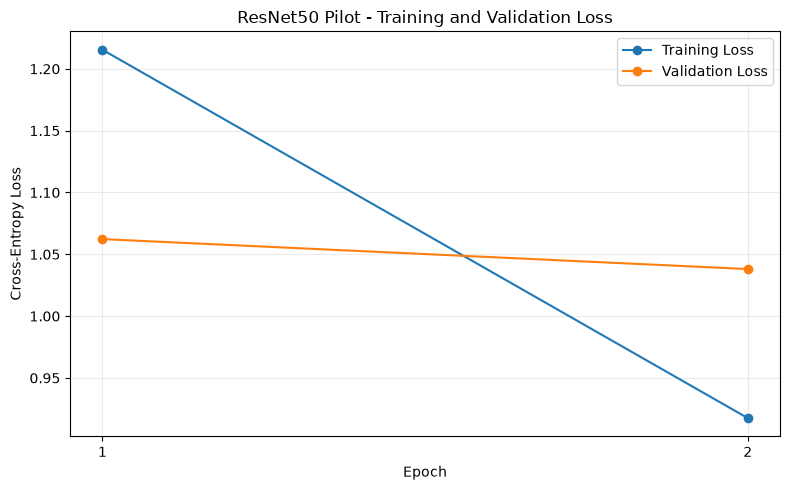

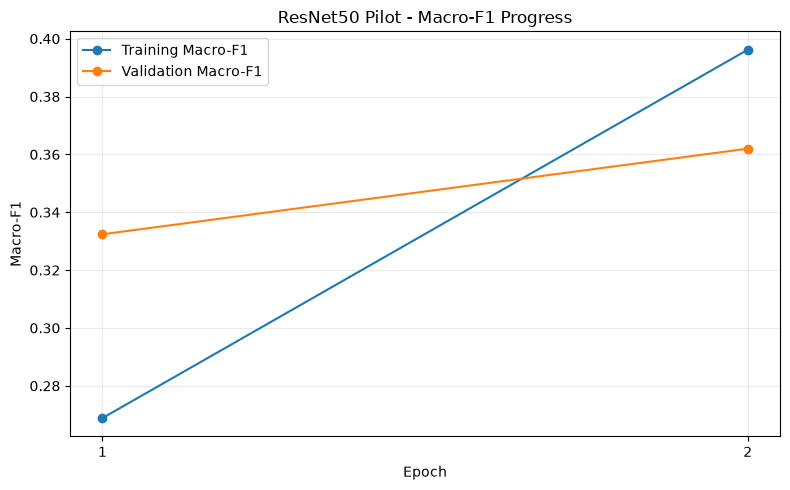

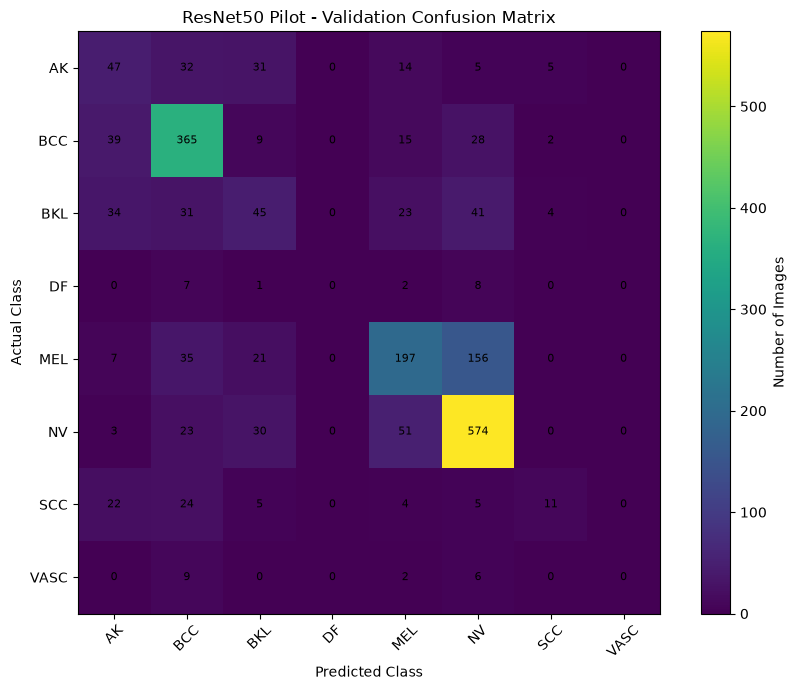


Figures saved:
- d:\skin_research\outputs\figures\resnet50_pilot_loss_curves.png
- d:\skin_research\outputs\figures\resnet50_pilot_macro_f1_curves.png
- d:\skin_research\outputs\figures\resnet50_pilot_validation_confusion_matrix.png

PILOT RESULTS AUDIT - FINAL VERIFICATION
[PASS] Previous pilot training PASS
[PASS] Pilot contains two epochs
[PASS] Outer-test previously protected
[PASS] Best checkpoint exists
[PASS] Last checkpoint exists
[PASS] Best checkpoint type valid
[PASS] Last checkpoint type valid
[PASS] Checkpoint signatures valid
[PASS] Checkpoint experiment IDs valid
[PASS] Best epoch recorded correctly
[PASS] Last checkpoint epoch correct
[PASS] Checkpoint histories consistent
[PASS] Full training batches verified
[PASS] No skipped optimizer steps
[PASS] Training history values finite
[PASS] Validation dataset has 1973 images
[PASS] Validation has 571 groups
[PASS] Validation batch count correct
[PASS] Best model loaded strictly
[PASS] Model in evaluation mode
[PASS] All v

In [93]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION
# PHASE 04B - CELL 3
# FULL PILOT RESULTS AUDIT & TRAINING STABILITY
# ============================================================

import json
import math
import hashlib
import traceback
import gc
import time

from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision.models import resnet50
from tqdm.auto import tqdm


print("=" * 80)
print("PHASE 04B - CELL 3")
print("FULL PILOT RESULTS AUDIT & TRAINING STABILITY")
print("=" * 80)


# ============================================================
# 1. PATHS AND CONFIGURATION
# ============================================================

AUDIT_ROOT = Path.cwd()

AUDIT_OUTPUT = AUDIT_ROOT / "outputs"

AUDIT_REPORT_DIR = AUDIT_OUTPUT / "reports"
AUDIT_FIGURE_DIR = AUDIT_OUTPUT / "figures"
AUDIT_PREDICTION_DIR = AUDIT_OUTPUT / "predictions"

for directory in [
    AUDIT_REPORT_DIR,
    AUDIT_FIGURE_DIR,
    AUDIT_PREDICTION_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)


AUDIT_CONFIG_PATH = (
    AUDIT_OUTPUT /
    "configs/resnet50_fold01_pilot_config.json"
)

AUDIT_TRAINING_REPORT_PATH = (
    AUDIT_REPORT_DIR /
    "resnet50_pilot_training_report.json"
)

AUDIT_CHECKPOINT_DIR = (
    AUDIT_OUTPUT /
    "checkpoints/pilots/resnet50/original/fold_01"
)

AUDIT_BEST_PATH = (
    AUDIT_CHECKPOINT_DIR / "best_checkpoint.pt"
)

AUDIT_LAST_PATH = (
    AUDIT_CHECKPOINT_DIR / "last_checkpoint.pt"
)

AUDIT_FINAL_REPORT_PATH = (
    AUDIT_REPORT_DIR /
    "resnet50_pilot_results_audit.json"
)

AUDIT_CLASS_CSV = (
    AUDIT_REPORT_DIR /
    "resnet50_pilot_validation_per_class_metrics.csv"
)

AUDIT_PREDICTIONS_CSV = (
    AUDIT_PREDICTION_DIR /
    "resnet50_pilot_validation_predictions.csv"
)

AUDIT_GROUP_CSV = (
    AUDIT_REPORT_DIR /
    "resnet50_pilot_validation_group_predictions.csv"
)

AUDIT_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

AUDIT_DEVICE = torch.device(
    f"cuda:{torch.cuda.current_device()}"
    if torch.cuda.is_available()
    else "cpu"
)

AUDIT_CHECKS = {}
AUDIT_ERRORS = []
AUDIT_RESULTS = {}

AUDIT_MODEL = None

print("\n[1] CONFIGURATION")
print("Model: ResNet50")
print("Branch: original")
print("Fold: 1")
print("Audit partition: validation")
print("Device:", AUDIT_DEVICE)
print("Outer-test: PROTECTED")


# ============================================================
# 2. INDEPENDENT CLASSIFICATION METRIC FUNCTION
# ============================================================

def audit_classification_metrics(
    true_labels,
    predicted_labels
):

    y_true = np.asarray(
        true_labels,
        dtype=np.int64
    )

    y_pred = np.asarray(
        predicted_labels,
        dtype=np.int64
    )

    if len(y_true) == 0:
        raise ValueError("No samples to evaluate.")

    if len(y_true) != len(y_pred):
        raise ValueError("Prediction count mismatch.")

    if (
        np.any(y_true < 0)
        or np.any(y_true >= 8)
        or np.any(y_pred < 0)
        or np.any(y_pred >= 8)
    ):
        raise ValueError("Invalid class index.")

    confusion = np.zeros(
        (8, 8),
        dtype=np.int64
    )

    np.add.at(
        confusion,
        (y_true, y_pred),
        1
    )

    true_positive = (
        np.diag(confusion).astype(float)
    )

    support = (
        confusion.sum(axis=1).astype(float)
    )

    predicted_count = (
        confusion.sum(axis=0).astype(float)
    )

    precision = np.divide(
        true_positive,
        predicted_count,
        out=np.zeros(8, dtype=float),
        where=predicted_count > 0
    )

    recall = np.divide(
        true_positive,
        support,
        out=np.zeros(8, dtype=float),
        where=support > 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(8, dtype=float),
        where=(precision + recall) > 0
    )

    per_class = []

    for index, class_name in enumerate(
        AUDIT_CLASSES
    ):

        per_class.append({
            "class": class_name,
            "class_index": index,
            "support": int(support[index]),
            "predicted_count": int(
                predicted_count[index]
            ),
            "true_positive": int(
                true_positive[index]
            ),
            "precision": float(
                precision[index]
            ),
            "recall": float(
                recall[index]
            ),
            "f1": float(f1[index])
        })

    present_classes = support > 0

    return {
        "accuracy": float(
            np.trace(confusion) / len(y_true)
        ),

        "macro_f1": float(
            np.mean(f1)
        ),

        "weighted_f1": float(
            np.sum(f1 * support) / support.sum()
        ),

        "balanced_accuracy": float(
            np.mean(recall[present_classes])
        ),

        "samples": int(len(y_true)),

        "confusion_matrix": (
            confusion.tolist()
        ),

        "per_class": per_class
    }


# ============================================================
# 3. CHECKPOINT AND TRAINING HISTORY AUDIT
# ============================================================

try:

    print("\n[2] LOADING PILOT RECORDS")

    with open(
        AUDIT_CONFIG_PATH,
        "r",
        encoding="utf-8"
    ) as f:

        audit_config = json.load(f)

    with open(
        AUDIT_TRAINING_REPORT_PATH,
        "r",
        encoding="utf-8"
    ) as f:

        training_report = json.load(f)

    AUDIT_CHECKS["Previous pilot training PASS"] = (
        training_report.get("status") == "PASS"
    )

    AUDIT_CHECKS["Pilot contains two epochs"] = (
        training_report.get("completed_epochs") == 2
        and len(training_report.get("history", [])) == 2
    )

    AUDIT_CHECKS["Outer-test previously protected"] = (
        training_report.get(
            "outer_test_evaluated"
        ) is False
    )

    AUDIT_CHECKS["Best checkpoint exists"] = (
        AUDIT_BEST_PATH.is_file()
    )

    AUDIT_CHECKS["Last checkpoint exists"] = (
        AUDIT_LAST_PATH.is_file()
    )

    if not all(AUDIT_CHECKS.values()):

        raise RuntimeError(
            "Previous pilot report or checkpoint "
            "verification failed."
        )

    audit_signature = hashlib.sha256(
        json.dumps(
            audit_config,
            sort_keys=True,
            separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest()

    audit_best = torch.load(
        AUDIT_BEST_PATH,
        map_location="cpu",
        weights_only=True
    )

    audit_last = torch.load(
        AUDIT_LAST_PATH,
        map_location="cpu",
        weights_only=True
    )

    AUDIT_CHECKS["Best checkpoint type valid"] = (
        audit_best.get("checkpoint_kind")
        == "pilot_best"
    )

    AUDIT_CHECKS["Last checkpoint type valid"] = (
        audit_last.get("checkpoint_kind")
        == "pilot_last"
    )

    AUDIT_CHECKS["Checkpoint signatures valid"] = (
        audit_best.get("configuration_signature")
        == audit_signature
        and audit_last.get("configuration_signature")
        == audit_signature
    )

    AUDIT_CHECKS["Checkpoint experiment IDs valid"] = (
        audit_best.get("experiment_id")
        == "resnet50_original_fold01_pilot"
        and audit_last.get("experiment_id")
        == "resnet50_original_fold01_pilot"
    )

    audit_history = training_report["history"]

    audit_best_epoch = int(
        training_report["best_epoch"]
    )

    AUDIT_CHECKS["Best epoch recorded correctly"] = (
        audit_best_epoch
        == audit_best.get("completed_epoch")
        == max(
            audit_history,
            key=lambda row: row[
                "validation_macro_f1"
            ]
        )["epoch"]
    )

    AUDIT_CHECKS["Last checkpoint epoch correct"] = (
        audit_last.get("completed_epoch") == 2
    )

    AUDIT_CHECKS["Checkpoint histories consistent"] = (
        audit_last.get("history") == audit_history
        and len(audit_best.get("history", []))
        == audit_best_epoch
    )

    AUDIT_CHECKS["Full training batches verified"] = (
        all(
            row.get("training_batches") == 977
            and row.get("validation_batches") == 247
            for row in audit_history
        )
    )

    AUDIT_CHECKS["No skipped optimizer steps"] = (
        all(
            row.get("optimizer_steps") == 489
            and row.get("skipped_optimizer_steps") == 0
            for row in audit_history
        )
    )

    AUDIT_CHECKS["Training history values finite"] = (
        all(
            math.isfinite(float(row[key]))
            for row in audit_history
            for key in [
                "train_loss",
                "train_macro_f1",
                "validation_loss",
                "validation_macro_f1"
            ]
        )
    )

    print("Best checkpoint epoch:", audit_best_epoch)
    print("Last completed epoch:", audit_last["completed_epoch"])

    print(
        "Best logged validation Macro-F1:",
        training_report["best_validation_macro_f1"]
    )

    print("Checkpoint signatures: VERIFIED")


    # ========================================================
    # 4. PREPARE VALIDATION DATA
    # ========================================================

    print("\n[3] RECREATING VALIDATION DATALOADER")

    audit_dataset = create_bcn_dataset(
        "original",
        1,
        "validation"
    )

    audit_loader = DataLoader(
        audit_dataset,
        batch_size=8,
        shuffle=False,
        drop_last=False,
        num_workers=0,
        pin_memory=(AUDIT_DEVICE.type == "cuda")
    )

    AUDIT_CHECKS["Validation dataset has 1973 images"] = (
        len(audit_dataset) == 1973
    )

    AUDIT_CHECKS["Validation has 571 groups"] = (
        len(set(audit_dataset.leakage_group_ids))
        == 571
    )

    AUDIT_CHECKS["Validation batch count correct"] = (
        len(audit_loader) == 247
    )

    print("Validation images:", len(audit_dataset))
    print("Validation batches:", len(audit_loader))
    print(
        "Validation groups:",
        len(set(audit_dataset.leakage_group_ids))
    )


    # ========================================================
    # 5. LOAD BEST MODEL WITHOUT PRETRAINED DOWNLOAD
    # ========================================================

    print("\n[4] LOADING BEST RESNET50 CHECKPOINT")

    AUDIT_MODEL = resnet50(weights=None)

    AUDIT_MODEL.fc = nn.Linear(
        AUDIT_MODEL.fc.in_features,
        8
    )

    AUDIT_MODEL.load_state_dict(
        audit_best["model_state_dict"],
        strict=True
    )

    AUDIT_MODEL = AUDIT_MODEL.to(
        AUDIT_DEVICE
    )

    AUDIT_MODEL.eval()

    AUDIT_CHECKS["Best model loaded strictly"] = True

    AUDIT_CHECKS["Model in evaluation mode"] = (
        not AUDIT_MODEL.training
    )

    criterion = nn.CrossEntropyLoss()

    if AUDIT_DEVICE.type == "cuda":

        torch.cuda.reset_peak_memory_stats(
            AUDIT_DEVICE
        )


    # ========================================================
    # 6. FULL VALIDATION INFERENCE
    # ========================================================

    print("\n[5] REPRODUCING BEST VALIDATION RESULTS")

    audit_true = []
    audit_pred = []

    audit_filenames = []
    audit_group_ids = []

    audit_probability_batches = []

    audit_total_loss = 0.0
    audit_total_images = 0

    audit_amp = bool(
        audit_config["amp_enabled"]
    )

    inference_start = time.perf_counter()

    with torch.inference_mode():

        for batch in tqdm(
            audit_loader,
            desc="Best checkpoint validation audit"
        ):

            images = batch["image"].to(
                AUDIT_DEVICE,
                non_blocking=audit_amp
            )

            labels = batch["label"].to(
                AUDIT_DEVICE,
                non_blocking=audit_amp
            )

            with torch.autocast(
                device_type=AUDIT_DEVICE.type,
                dtype=torch.float16,
                enabled=audit_amp
            ):

                logits = AUDIT_MODEL(images)

                batch_loss = criterion(
                    logits.float(),
                    labels
                )

            if not torch.isfinite(logits).all().item():
                raise RuntimeError(
                    "Non-finite validation logits."
                )

            if not torch.isfinite(batch_loss).item():
                raise RuntimeError(
                    "Non-finite validation loss."
                )

            probabilities = torch.softmax(
                logits.float(),
                dim=1
            )

            predicted = logits.argmax(dim=1)

            batch_size_actual = labels.shape[0]

            audit_total_loss += (
                float(batch_loss.item())
                * batch_size_actual
            )

            audit_total_images += batch_size_actual

            audit_true.extend(
                labels.cpu().tolist()
            )

            audit_pred.extend(
                predicted.cpu().tolist()
            )

            audit_filenames.extend(
                list(batch["filename"])
            )

            audit_group_ids.extend(
                list(batch["leakage_group_id"])
            )

            audit_probability_batches.append(
                probabilities.cpu().numpy()
            )

    if AUDIT_DEVICE.type == "cuda":

        torch.cuda.synchronize(
            AUDIT_DEVICE
        )

    audit_inference_seconds = (
        time.perf_counter() - inference_start
    )

    audit_probabilities = np.concatenate(
        audit_probability_batches,
        axis=0
    )

    audit_validation_loss = float(
        audit_total_loss / audit_total_images
    )

    AUDIT_CHECKS["All validation images evaluated"] = (
        audit_total_images == 1973
    )

    AUDIT_CHECKS["No validation filename duplicates"] = (
        len(set(audit_filenames)) == 1973
    )

    AUDIT_CHECKS["Validation image order preserved"] = (
        audit_filenames == list(
            audit_dataset.filenames
        )
    )

    AUDIT_CHECKS["Validation labels preserved"] = (
        audit_true == [
            int(label)
            for label in audit_dataset.labels
        ]
    )

    AUDIT_CHECKS["Validation group metadata preserved"] = (
        audit_group_ids == list(
            audit_dataset.leakage_group_ids
        )
    )

    AUDIT_CHECKS["All class probabilities finite"] = bool(
        np.isfinite(audit_probabilities).all()
    )

    AUDIT_CHECKS["Probability rows sum to one"] = bool(
        np.allclose(
            audit_probabilities.sum(axis=1),
            1.0,
            atol=1e-5
        )
    )


    # ========================================================
    # 7. RECOMPUTE METRICS
    # ========================================================

    print("\n[6] INDEPENDENT METRIC RECOMPUTATION")

    audit_metrics = audit_classification_metrics(
        audit_true,
        audit_pred
    )

    audit_metrics["loss"] = (
        audit_validation_loss
    )

    logged_best_row = next(
        row
        for row in audit_history
        if row["epoch"] == audit_best_epoch
    )

    metric_comparisons = {
        "accuracy": "validation_accuracy",
        "macro_f1": "validation_macro_f1",
        "weighted_f1": "validation_weighted_f1",
        "balanced_accuracy": (
            "validation_balanced_accuracy"
        ),
        "loss": "validation_loss"
    }

    for metric_name, log_key in (
        metric_comparisons.items()
    ):

        actual = float(
            audit_metrics[metric_name]
        )

        logged = float(
            logged_best_row[log_key]
        )

        difference = abs(actual - logged)

        # Loss can differ slightly from floating-point
        # accumulation. Class metrics should match.
        tolerance = (
            1e-3
            if metric_name == "loss"
            else 1e-5
        )

        passed = difference <= tolerance

        AUDIT_CHECKS[
            f"Reproduced {metric_name}"
        ] = passed

        print(
            f"{metric_name:20s} | "
            f"Logged: {logged:.6f} | "
            f"Recomputed: {actual:.6f} | "
            f"Difference: {difference:.8f} | "
            f"{'PASS' if passed else 'FAIL'}"
        )

    AUDIT_RESULTS["reproduced_metrics"] = (
        audit_metrics
    )


    # ========================================================
    # 8. CLASS-WISE PERFORMANCE
    # ========================================================

    print("\n[7] EIGHT-CLASS VALIDATION PERFORMANCE")

    audit_class_df = pd.DataFrame(
        audit_metrics["per_class"]
    )

    display(audit_class_df)

    audit_class_df.to_csv(
        AUDIT_CLASS_CSV,
        index=False
    )

    AUDIT_CHECKS["All eight classes evaluated"] = (
        len(audit_class_df) == 8
        and audit_class_df["support"].gt(0).all()
    )

    AUDIT_CHECKS["Class supports sum to 1973"] = (
        int(audit_class_df["support"].sum())
        == 1973
    )

    AUDIT_CHECKS["Predicted counts sum to 1973"] = (
        int(
            audit_class_df["predicted_count"].sum()
        ) == 1973
    )

    # Performance limitation diagnostics, not pass/fail:
    audit_zero_recall_classes = (
        audit_class_df.loc[
            audit_class_df["recall"] == 0,
            "class"
        ].tolist()
    )

    print(
        "\nClasses with zero recall:",
        audit_zero_recall_classes
    )


    # ========================================================
    # 9. SAVE VALIDATION PREDICTIONS
    # ========================================================

    print("\n[8] SAVING VALIDATION PREDICTIONS")

    audit_predictions_df = pd.DataFrame({

        "filename": audit_filenames,

        "leakage_group_id": audit_group_ids,

        "actual_idx": audit_true,

        "predicted_idx": audit_pred,

        "actual_class": [
            AUDIT_CLASSES[index]
            for index in audit_true
        ],

        "predicted_class": [
            AUDIT_CLASSES[index]
            for index in audit_pred
        ],

        "confidence": (
            audit_probabilities.max(axis=1)
        )

    })

    probability_columns = []

    for class_index, class_name in enumerate(
        AUDIT_CLASSES
    ):

        column_name = f"prob_{class_name}"

        probability_columns.append(
            column_name
        )

        audit_predictions_df[column_name] = (
            audit_probabilities[:, class_index]
        )

    audit_predictions_df.to_csv(
        AUDIT_PREDICTIONS_CSV,
        index=False
    )

    AUDIT_CHECKS["Validation predictions saved"] = (
        AUDIT_PREDICTIONS_CSV.is_file()
        and len(audit_predictions_df) == 1973
    )

    print(
        "Validation prediction records:",
        len(audit_predictions_df)
    )


    # ========================================================
    # 10. EXPLORATORY GROUP-LEVEL EVALUATION
    # ========================================================

    print("\n[9] LEAKAGE-GROUP-LEVEL ANALYSIS")

    group_label_counts = (
        audit_predictions_df
        .groupby("leakage_group_id")[
            "actual_idx"
        ]
        .nunique()
    )

    mixed_label_groups = int(
        (group_label_counts > 1).sum()
    )

    group_metrics = None

    if mixed_label_groups == 0:

        group_predictions = (
            audit_predictions_df
            .groupby(
                "leakage_group_id",
                sort=True
            )[probability_columns]
            .mean()
        )

        group_labels = (
            audit_predictions_df
            .groupby(
                "leakage_group_id",
                sort=True
            )["actual_idx"]
            .first()
        )

        group_true = (
            group_labels.to_numpy(
                dtype=np.int64
            )
        )

        group_pred = np.argmax(
            group_predictions.to_numpy(),
            axis=1
        )

        group_metrics = audit_classification_metrics(
            group_true,
            group_pred
        )

        group_output = pd.DataFrame({

            "leakage_group_id": (
                group_predictions.index.tolist()
            ),

            "actual_idx": group_true,

            "predicted_idx": group_pred

        })

        group_output.to_csv(
            AUDIT_GROUP_CSV,
            index=False
        )

        print(
            "Groups evaluated:",
            group_metrics["samples"]
        )

        print(
            "Group-level accuracy:",
            round(group_metrics["accuracy"], 6)
        )

        print(
            "Group-level Macro-F1:",
            round(group_metrics["macro_f1"], 6)
        )

    else:

        print(
            "WARNING: Groups with multiple labels:",
            mixed_label_groups
        )

        print(
            "Group-level aggregate evaluation skipped."
        )

    AUDIT_RESULTS["mixed_label_groups"] = (
        mixed_label_groups
    )

    AUDIT_RESULTS["group_metrics"] = (
        group_metrics
    )


    # ========================================================
    # 11. TRAINING STABILITY ANALYSIS
    # ========================================================

    print("\n[10] TWO-EPOCH TRAINING STABILITY")

    audit_history_df = pd.DataFrame(
        audit_history
    )

    epoch_one = audit_history[0]
    epoch_two = audit_history[1]

    stability_summary = {

        "train_loss_decreased": (
            epoch_two["train_loss"]
            < epoch_one["train_loss"]
        ),

        "validation_loss_decreased": (
            epoch_two["validation_loss"]
            < epoch_one["validation_loss"]
        ),

        "train_macro_f1_improved": (
            epoch_two["train_macro_f1"]
            > epoch_one["train_macro_f1"]
        ),

        "validation_macro_f1_improved": (
            epoch_two["validation_macro_f1"]
            > epoch_one["validation_macro_f1"]
        ),

        "validation_accuracy_improved": (
            epoch_two["validation_accuracy"]
            > epoch_one["validation_accuracy"]
        ),

        "optimizer_steps_total": int(
            audit_history_df[
                "optimizer_steps"
            ].sum()
        ),

        "skipped_steps_total": int(
            audit_history_df[
                "skipped_optimizer_steps"
            ].sum()
        )
    }

    AUDIT_RESULTS["stability"] = (
        stability_summary
    )

    for name, result in stability_summary.items():

        print(f"{name}: {result}")

    # These are observations, not compulsory
    # PASS conditions. A valid training run need
    # not improve on every single epoch.


    # ========================================================
    # 12. SAVE TRAINING LOSS CURVE
    # ========================================================

    print("\n[11] SAVING RESEARCH FIGURES")

    epoch_values = (
        audit_history_df["epoch"].to_numpy()
    )

    plt.figure(figsize=(8, 5))

    plt.plot(
        epoch_values,
        audit_history_df["train_loss"],
        marker="o",
        label="Training Loss"
    )

    plt.plot(
        epoch_values,
        audit_history_df["validation_loss"],
        marker="o",
        label="Validation Loss"
    )

    plt.xticks(epoch_values)
    plt.xlabel("Epoch")
    plt.ylabel("Cross-Entropy Loss")
    plt.title("ResNet50 Pilot - Training and Validation Loss")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    loss_figure_path = (
        AUDIT_FIGURE_DIR /
        "resnet50_pilot_loss_curves.png"
    )

    plt.savefig(
        loss_figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


    # ========================================================
    # 13. SAVE MACRO-F1 CURVE
    # ========================================================

    plt.figure(figsize=(8, 5))

    plt.plot(
        epoch_values,
        audit_history_df["train_macro_f1"],
        marker="o",
        label="Training Macro-F1"
    )

    plt.plot(
        epoch_values,
        audit_history_df["validation_macro_f1"],
        marker="o",
        label="Validation Macro-F1"
    )

    plt.xticks(epoch_values)
    plt.xlabel("Epoch")
    plt.ylabel("Macro-F1")
    plt.title("ResNet50 Pilot - Macro-F1 Progress")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    f1_figure_path = (
        AUDIT_FIGURE_DIR /
        "resnet50_pilot_macro_f1_curves.png"
    )

    plt.savefig(
        f1_figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


    # ========================================================
    # 14. SAVE CONFUSION MATRIX
    # ========================================================

    confusion = np.asarray(
        audit_metrics["confusion_matrix"]
    )

    plt.figure(figsize=(9, 7))

    plt.imshow(
        confusion,
        interpolation="nearest"
    )

    plt.colorbar(
        label="Number of Images"
    )

    plt.xticks(
        range(8),
        AUDIT_CLASSES,
        rotation=45
    )

    plt.yticks(
        range(8),
        AUDIT_CLASSES
    )

    for row in range(8):

        for col in range(8):

            plt.text(
                col,
                row,
                str(confusion[row, col]),
                ha="center",
                va="center",
                fontsize=8
            )

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.title(
        "ResNet50 Pilot - Validation Confusion Matrix"
    )

    plt.tight_layout()

    confusion_figure_path = (
        AUDIT_FIGURE_DIR /
        "resnet50_pilot_validation_confusion_matrix.png"
    )

    plt.savefig(
        confusion_figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    AUDIT_CHECKS["All three figures saved"] = all(
        path.is_file()
        for path in [
            loss_figure_path,
            f1_figure_path,
            confusion_figure_path
        ]
    )


    # ========================================================
    # 15. AUDIT RESULTS
    # ========================================================

    AUDIT_RESULTS["inference_seconds"] = (
        round(audit_inference_seconds, 2)
    )

    AUDIT_RESULTS["best_epoch"] = (
        audit_best_epoch
    )

    AUDIT_RESULTS["zero_recall_classes"] = (
        audit_zero_recall_classes
    )

    AUDIT_RESULTS["figures"] = [
        str(loss_figure_path),
        str(f1_figure_path),
        str(confusion_figure_path)
    ]

    print("\nFigures saved:")
    for figure in AUDIT_RESULTS["figures"]:
        print("-", figure)


except Exception:

    AUDIT_ERRORS.append(
        traceback.format_exc()
    )

    print("\nAUDIT ERROR")
    print(AUDIT_ERRORS[-1])


# ============================================================
# 16. GPU CLEANUP
# ============================================================

if AUDIT_MODEL is not None:
    del AUDIT_MODEL

gc.collect()

if AUDIT_DEVICE.type == "cuda":
    torch.cuda.empty_cache()


# ============================================================
# 17. FINAL VERIFICATION REPORT
# ============================================================

print("\n" + "=" * 80)
print("PILOT RESULTS AUDIT - FINAL VERIFICATION")
print("=" * 80)

for name, result in AUDIT_CHECKS.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] {name}"
    )

AUDIT_STATUS = (
    "PASS"
    if (
        len(AUDIT_CHECKS) > 0
        and all(AUDIT_CHECKS.values())
        and not AUDIT_ERRORS
    )
    else "BLOCKED"
)

AUDIT_REPORT = {

    "stage": "RESNET50_PILOT_RESULTS_AUDIT",

    "status": AUDIT_STATUS,

    "model": "resnet50",

    "branch": "original",

    "fold": 1,

    "evaluation_partition": "validation",

    "best_checkpoint": str(AUDIT_BEST_PATH),

    "last_checkpoint": str(AUDIT_LAST_PATH),

    "checks": {
        name: bool(result)
        for name, result in AUDIT_CHECKS.items()
    },

    "results": AUDIT_RESULTS,

    "errors": AUDIT_ERRORS,

    "per_class_csv": str(AUDIT_CLASS_CSV),

    "predictions_csv": str(
        AUDIT_PREDICTIONS_CSV
    ),

    "training_performed": False,

    "outer_test_evaluated": False,

    "final_research_evaluation": False

}

with open(
    AUDIT_FINAL_REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        AUDIT_REPORT,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 18. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 80)
print("RESNET50 PILOT RESULTS AUDIT SUMMARY")
print("=" * 80)

print("Status:", AUDIT_STATUS)

print("Model: ResNet50")
print("Branch: original")
print("Fold: 1")
print("Best checkpoint epoch: 2")

if "reproduced_metrics" in AUDIT_RESULTS:

    metrics = AUDIT_RESULTS[
        "reproduced_metrics"
    ]

    print(
        "Reproduced validation accuracy:",
        round(metrics["accuracy"], 6)
    )

    print(
        "Reproduced validation Macro-F1:",
        round(metrics["macro_f1"], 6)
    )

    print(
        "Reproduced balanced accuracy:",
        round(metrics["balanced_accuracy"], 6)
    )

print("\nFinal report:")
print(AUDIT_FINAL_REPORT_PATH)

if AUDIT_STATUS == "PASS":

    print("\nPILOT RESULTS AUDIT: PASS")

    print(
        "NEXT: PILOT DIAGNOSTICS AND "
        "FULL TRAINING STRATEGY"
    )

else:

    print("\nPILOT RESULTS AUDIT: BLOCKED")

    print(
        "Review failed checks before "
        "starting further experiments."
    )

print("=" * 80)


PHASE 04B - CELL 4
PILOT FAILURE ANALYSIS & TRAINING STRATEGY

[1] INPUT FILES
[FOUND] Audit report
[FOUND] Training report
[FOUND] Predictions
[FOUND] Per-class metrics
[FOUND] Train manifest
[FOUND] Validation manifest

[2] DATA LOADING
Prediction records: 1973
Training records: 7813
Validation records: 1973

[3] CONFUSION MATRIX AUDIT
Confusion matrix match: True
Total evaluated images: 1973

[4] CLASS-WISE FAILURE ANALYSIS


,class,train_images,validation_support,predicted_count,true_positive,false_negative,precision,recall,f1,top3_accuracy,mean_true_class_probability,most_confused_with,most_confused_count,zero_prediction_class
0,AK,466,134,152,47,87,0.309211,0.350746,0.328671,0.798507,0.312035,BCC,32,False
1,BCC,1764,458,526,365,93,0.693916,0.796943,0.741870,0.945415,0.601997,AK,39,False
2,BKL,705,178,142,45,133,0.316901,0.252809,0.281250,0.859551,0.266823,NV,41,False
3,DF,77,18,0,0,18,0.000000,0.000000,0.000000,0.000000,0.021808,NV,8,True
4,MEL,1799,416,308,197,219,0.639610,0.473558,0.544199,0.930288,0.441221,NV,156,False
5,NV,2673,681,823,574,107,0.697448,0.842878,0.763298,0.988253,0.729905,MEL,51,False
6,SCC,266,71,22,11,60,0.500000,0.154930,0.236559,0.577465,0.160462,BCC,24,False
7,VASC,63,17,0,0,17,0.000000,0.000000,0.000000,0.176471,0.063417,BCC,9,True



Zero-prediction classes:
['DF', 'VASC']

[5] MOST FREQUENT MISCLASSIFICATIONS


,actual_class,predicted_class,misclassified_images,fraction_of_actual_class
22,MEL,NV,156,0.375000
26,NV,MEL,51,0.074890
13,BKL,NV,41,0.230337
5,BCC,AK,39,0.085153
20,MEL,BCC,35,0.084135
10,BKL,AK,34,0.191011
0,AK,BCC,32,0.238806
11,BKL,BCC,31,0.174157
1,AK,BKL,31,0.231343
25,NV,BKL,30,0.044053



[6] TRAINING-ONLY CLASS WEIGHT STRATEGY


,class,train_images,unweighted_ce,inverse_frequency_candidate,sqrt_inverse_frequency_candidate
0,AK,466,1.0,2.095762,1.665760
1,BCC,1764,1.0,0.553642,0.856163
2,BKL,705,1.0,1.385284,1.354288
3,DF,77,1.0,12.683442,4.097889
4,MEL,1799,1.0,0.542871,0.847793
5,NV,2673,1.0,0.365367,0.695514
6,SCC,266,1.0,3.671523,2.204777
7,VASC,63,1.0,15.501984,4.530386



IMPORTANT: These weights are calculated from TRAINING data only.
No weighted-loss model has been trained yet.

[7] FULL TRAINING STRATEGY
Maximum epochs: 30
Early stopping patience: 7
Primary selection: Validation Macro-F1
Proposed loss configurations: 2
Outer-test: Protected

[8] SAVING DIAGNOSTIC FIGURES


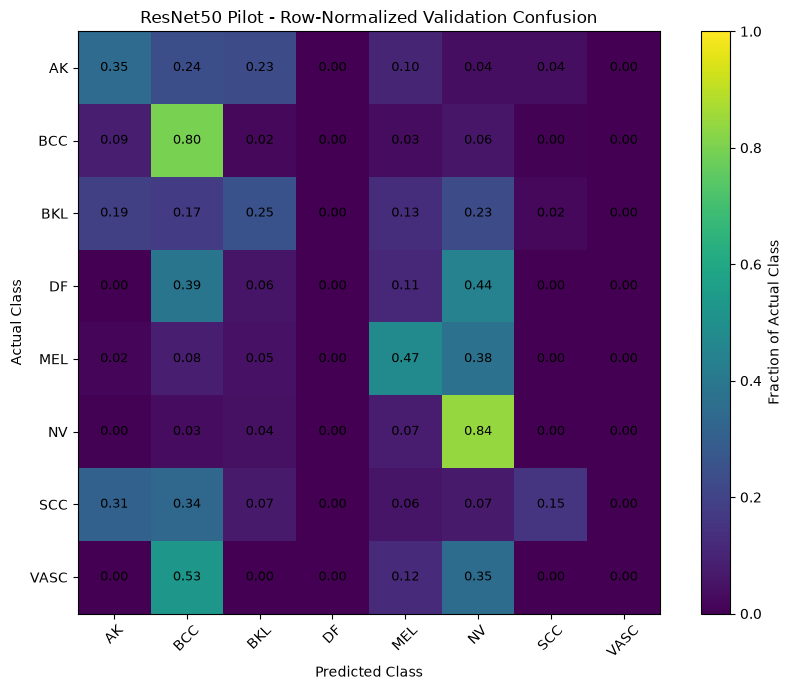

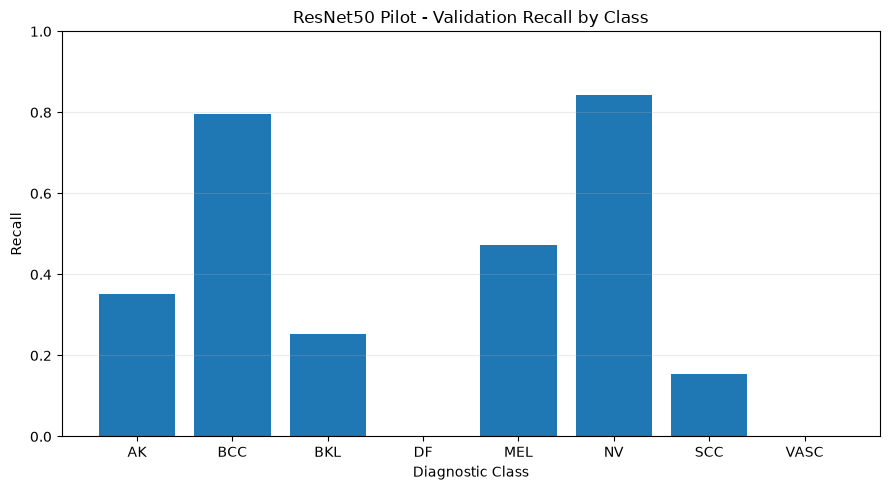


PHASE 04B - CELL 4 FINAL VERIFICATION
[PASS] Previous audit PASS
[PASS] Pilot training PASS
[PASS] No outer-test evaluation
[PASS] 1973 prediction records
[PASS] 1973 unique filenames
[PASS] 571 validation groups
[PASS] All labels within eight classes
[PASS] Probability matrix valid
[PASS] Predicted classes match probabilities
[PASS] Class names match indices
[PASS] Validation manifest labels match
[PASS] Validation leakage groups match
[PASS] Confusion matrix reproducible
[PASS] Confusion matrix totals 1973
[PASS] 7813 training images
[PASS] All training classes present
[PASS] Candidate class weights finite
[PASS] Candidate class weights positive
[PASS] Weight normalization correct
[PASS] Eight diagnostic classes analyzed
[PASS] Class supports total 1973
[PASS] Predicted counts total 1973
[PASS] Recorded per-class metrics consistent
[PASS] Diagnostic CSV saved
[PASS] Class weight CSV saved
[PASS] Training strategy JSON saved
[PASS] Normalized confusion matrix saved
[PASS] Class-wise 

In [94]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION
# PHASE 04B - CELL 4
# PILOT FAILURE ANALYSIS AND FULL TRAINING STRATEGY
# ============================================================

import json
import math

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


print("=" * 80)
print("PHASE 04B - CELL 4")
print("PILOT FAILURE ANALYSIS & TRAINING STRATEGY")
print("=" * 80)


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path.cwd()

REPORT_DIR = ROOT / "outputs" / "reports"
CONFIG_DIR = ROOT / "outputs" / "configs"
FIGURE_DIR = ROOT / "outputs" / "figures"
PREDICTION_DIR = ROOT / "outputs" / "predictions"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
CONFIG_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

AUDIT_PATH = (
    REPORT_DIR / "resnet50_pilot_results_audit.json"
)

TRAINING_REPORT_PATH = (
    REPORT_DIR / "resnet50_pilot_training_report.json"
)

PREDICTIONS_PATH = (
    PREDICTION_DIR /
    "resnet50_pilot_validation_predictions.csv"
)

PER_CLASS_PATH = (
    REPORT_DIR /
    "resnet50_pilot_validation_per_class_metrics.csv"
)

TRAIN_MANIFEST_PATH = (
    ROOT /
    "outputs/splits/original_branch/fold_01_train.csv"
)

VALIDATION_MANIFEST_PATH = (
    ROOT /
    "outputs/splits/original_branch/fold_01_validation.csv"
)

DIAGNOSTIC_CSV_PATH = (
    REPORT_DIR /
    "resnet50_pilot_failure_analysis.csv"
)

WEIGHTS_CSV_PATH = (
    REPORT_DIR /
    "resnet50_training_class_weight_candidates.csv"
)

STRATEGY_PATH = (
    CONFIG_DIR /
    "resnet50_full_training_strategy.json"
)

FINAL_REPORT_PATH = (
    REPORT_DIR /
    "resnet50_pilot_diagnostic_verification.json"
)

CLASS_NAMES_LOCAL = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

NUM_CLASSES_LOCAL = 8

checks = {}

print("\n[1] INPUT FILES")

required_files = {
    "Audit report": AUDIT_PATH,
    "Training report": TRAINING_REPORT_PATH,
    "Predictions": PREDICTIONS_PATH,
    "Per-class metrics": PER_CLASS_PATH,
    "Train manifest": TRAIN_MANIFEST_PATH,
    "Validation manifest": VALIDATION_MANIFEST_PATH
}

for name, path in required_files.items():

    if not path.is_file():
        raise FileNotFoundError(
            f"{name} missing: {path}"
        )

    print("[FOUND]", name)


# ============================================================
# 2. LOAD PREVIOUS RESULTS
# ============================================================

with open(AUDIT_PATH, "r", encoding="utf-8") as f:
    audit_report = json.load(f)

with open(
    TRAINING_REPORT_PATH,
    "r",
    encoding="utf-8"
) as f:
    training_report = json.load(f)

pred_df = pd.read_csv(PREDICTIONS_PATH)

saved_class_df = pd.read_csv(PER_CLASS_PATH)

train_df = pd.read_csv(TRAIN_MANIFEST_PATH)

validation_df = pd.read_csv(VALIDATION_MANIFEST_PATH)

checks["Previous audit PASS"] = (
    audit_report.get("status") == "PASS"
)

checks["Pilot training PASS"] = (
    training_report.get("status") == "PASS"
)

checks["No outer-test evaluation"] = (
    audit_report.get("outer_test_evaluated") is False
    and training_report.get("outer_test_evaluated") is False
)

print("\n[2] DATA LOADING")

print("Prediction records:", len(pred_df))
print("Training records:", len(train_df))
print("Validation records:", len(validation_df))


# ============================================================
# 3. VALIDATE PREDICTION METADATA
# ============================================================

probability_columns = [
    f"prob_{name}"
    for name in CLASS_NAMES_LOCAL
]

required_prediction_columns = [
    "filename",
    "leakage_group_id",
    "actual_idx",
    "predicted_idx",
    "actual_class",
    "predicted_class",
    "confidence",
    *probability_columns
]

missing_columns = (
    set(required_prediction_columns)
    - set(pred_df.columns)
)

if missing_columns:
    raise ValueError(
        f"Missing prediction columns: {missing_columns}"
    )

y_true = pred_df["actual_idx"].to_numpy(
    dtype=np.int64
)

y_pred = pred_df["predicted_idx"].to_numpy(
    dtype=np.int64
)

probabilities = pred_df[
    probability_columns
].to_numpy(dtype=np.float64)

checks["1973 prediction records"] = (
    len(pred_df) == 1973
)

checks["1973 unique filenames"] = (
    pred_df["filename"].nunique() == 1973
)

checks["571 validation groups"] = (
    pred_df["leakage_group_id"].nunique() == 571
)

checks["All labels within eight classes"] = bool(
    np.all((y_true >= 0) & (y_true < 8))
    and np.all((y_pred >= 0) & (y_pred < 8))
)

checks["Probability matrix valid"] = (
    probabilities.shape == (1973, 8)
    and np.isfinite(probabilities).all()
    and np.all(probabilities >= 0)
    and np.all(probabilities <= 1)
    and np.allclose(
        probabilities.sum(axis=1),
        1.0,
        atol=1e-5
    )
)

checks["Predicted classes match probabilities"] = (
    np.array_equal(
        np.argmax(probabilities, axis=1),
        y_pred
    )
)

checks["Class names match indices"] = (
    np.array_equal(
        np.asarray(CLASS_NAMES_LOCAL)[y_true],
        pred_df["actual_class"].to_numpy()
    )
    and np.array_equal(
        np.asarray(CLASS_NAMES_LOCAL)[y_pred],
        pred_df["predicted_class"].to_numpy()
    )
)

# Compare each prediction against the saved
# validation manifest, independently of row order.

validation_reference = validation_df.set_index(
    "bcn_filename"
)

aligned = validation_reference.reindex(
    pred_df["filename"].tolist()
)

checks["Validation manifest labels match"] = (
    aligned["diagnosis"].notna().all()
    and np.array_equal(
        aligned["diagnosis"].astype(str).to_numpy(),
        pred_df["actual_class"].astype(str).to_numpy()
    )
)

checks["Validation leakage groups match"] = (
    aligned["leakage_group_id"].notna().all()
    and np.array_equal(
        aligned["leakage_group_id"].astype(str).to_numpy(),
        pred_df["leakage_group_id"].astype(str).to_numpy()
    )
)

if not all(checks.values()):
    raise RuntimeError(
        "Input integrity failed. "
        f"Failed: {[k for k, v in checks.items() if not v]}"
    )


# ============================================================
# 4. INDEPENDENT CONFUSION MATRIX AUDIT
# ============================================================

confusion = np.zeros(
    (NUM_CLASSES_LOCAL, NUM_CLASSES_LOCAL),
    dtype=np.int64
)

np.add.at(
    confusion,
    (y_true, y_pred),
    1
)

saved_confusion = np.asarray(
    audit_report["results"][
        "reproduced_metrics"
    ]["confusion_matrix"],
    dtype=np.int64
)

checks["Confusion matrix reproducible"] = (
    np.array_equal(confusion, saved_confusion)
)

checks["Confusion matrix totals 1973"] = (
    int(confusion.sum()) == 1973
)

print("\n[3] CONFUSION MATRIX AUDIT")

print(
    "Confusion matrix match:",
    checks["Confusion matrix reproducible"]
)

print("Total evaluated images:", confusion.sum())


# ============================================================
# 5. CLASS-WISE FAILURE DIAGNOSTICS
# ============================================================

print("\n[4] CLASS-WISE FAILURE ANALYSIS")

train_counts = (
    train_df["diagnosis"]
    .value_counts()
    .reindex(CLASS_NAMES_LOCAL, fill_value=0)
    .astype(int)
)

checks["7813 training images"] = (
    int(train_counts.sum()) == 7813
)

checks["All training classes present"] = (
    bool((train_counts > 0).all())
)

top3_indices = np.argsort(
    -probabilities,
    axis=1
)[:, :3]

top3_correct = np.any(
    top3_indices == y_true[:, None],
    axis=1
)

diagnostic_rows = []

for class_index, class_name in enumerate(
    CLASS_NAMES_LOCAL
):

    true_mask = y_true == class_index

    support = int(true_mask.sum())

    predicted_count = int(
        (y_pred == class_index).sum()
    )

    true_positive = int(
        confusion[class_index, class_index]
    )

    false_negative = support - true_positive

    precision = (
        true_positive / predicted_count
        if predicted_count > 0
        else 0.0
    )

    recall = (
        true_positive / support
        if support > 0
        else 0.0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0
        else 0.0
    )

    mean_true_class_probability = float(
        probabilities[true_mask, class_index].mean()
    )

    top3_accuracy = float(
        top3_correct[true_mask].mean()
    )

    error_row = confusion[class_index].copy()

    error_row[class_index] = 0

    most_confused_index = int(
        error_row.argmax()
    )

    most_confused_count = int(
        error_row[most_confused_index]
    )

    most_confused_class = (
        CLASS_NAMES_LOCAL[most_confused_index]
        if most_confused_count > 0
        else None
    )

    diagnostic_rows.append({

        "class": class_name,

        "train_images": int(
            train_counts[class_name]
        ),

        "validation_support": support,

        "predicted_count": predicted_count,

        "true_positive": true_positive,

        "false_negative": false_negative,

        "precision": round(precision, 6),

        "recall": round(recall, 6),

        "f1": round(f1, 6),

        "top3_accuracy": round(
            top3_accuracy, 6
        ),

        "mean_true_class_probability": round(
            mean_true_class_probability, 6
        ),

        "most_confused_with": most_confused_class,

        "most_confused_count": (
            most_confused_count
        ),

        "zero_prediction_class": (
            predicted_count == 0
        )

    })


diagnostic_df = pd.DataFrame(
    diagnostic_rows
)

display(diagnostic_df)

diagnostic_df.to_csv(
    DIAGNOSTIC_CSV_PATH,
    index=False
)

zero_prediction_classes = diagnostic_df.loc[
    diagnostic_df["predicted_count"] == 0,
    "class"
].tolist()

print("\nZero-prediction classes:")
print(zero_prediction_classes)


# ============================================================
# 6. MOST FREQUENT CLASS CONFUSIONS
# ============================================================

print("\n[5] MOST FREQUENT MISCLASSIFICATIONS")

confusion_records = []

for actual_index in range(8):

    for predicted_index in range(8):

        if actual_index == predicted_index:
            continue

        count = int(
            confusion[actual_index, predicted_index]
        )

        if count > 0:

            confusion_records.append({

                "actual_class":
                    CLASS_NAMES_LOCAL[actual_index],

                "predicted_class":
                    CLASS_NAMES_LOCAL[predicted_index],

                "misclassified_images": count,

                "fraction_of_actual_class": round(
                    count / confusion[actual_index].sum(),
                    6
                )

            })

confusion_df = pd.DataFrame(
    confusion_records
).sort_values(
    "misclassified_images",
    ascending=False
)

display(
    confusion_df.head(12)
)


# ============================================================
# 7. TRAINING-ONLY CLASS WEIGHT CANDIDATES
# ============================================================

print("\n[6] TRAINING-ONLY CLASS WEIGHT STRATEGY")

counts = train_counts.to_numpy(
    dtype=np.float64
)

total_train_images = counts.sum()

# Candidate A: Unweighted CE
standard_weights = np.ones(
    NUM_CLASSES_LOCAL,
    dtype=np.float64
)

# Candidate B: Full inverse-frequency weighting.
# Diagnostic reference only, potentially aggressive.
inverse_weights = (
    total_train_images /
    (NUM_CLASSES_LOCAL * counts)
)

# Candidate C: Tempered/square-root weighting.
# Less aggressive than full inverse-frequency.
sqrt_weights = np.sqrt(
    inverse_weights
)

# Normalize so the training-frequency-weighted
# mean weight equals 1.
normalization = (
    np.dot(counts, sqrt_weights)
    / total_train_images
)

sqrt_weights = (
    sqrt_weights / normalization
)

weights_df = pd.DataFrame({

    "class": CLASS_NAMES_LOCAL,

    "train_images": counts.astype(int),

    "unweighted_ce": standard_weights,

    "inverse_frequency_candidate": (
        inverse_weights
    ),

    "sqrt_inverse_frequency_candidate": (
        sqrt_weights
    )

})

display(
    weights_df.round(6)
)

weights_df.to_csv(
    WEIGHTS_CSV_PATH,
    index=False
)

checks["Candidate class weights finite"] = bool(
    np.isfinite(sqrt_weights).all()
)

checks["Candidate class weights positive"] = bool(
    (sqrt_weights > 0).all()
)

checks["Weight normalization correct"] = bool(
    np.isclose(
        np.dot(counts, sqrt_weights) / counts.sum(),
        1.0,
        atol=1e-10
    )
)

print(
    "\nIMPORTANT: These weights are calculated "
    "from TRAINING data only."
)

print(
    "No weighted-loss model has been trained yet."
)


# ============================================================
# 8. SAVE PROPOSED FULL TRAINING STRATEGY
# ============================================================

print("\n[7] FULL TRAINING STRATEGY")

FULL_TRAINING_STRATEGY = {

    "project": "BCN20000",

    "model": "resnet50",

    "branch": "original",

    "development_fold": 1,

    "experiment_stage": (
        "candidate_strategy_not_yet_executed"
    ),

    "dataset": {
        "train_images": 7813,
        "validation_images": 1973,
        "num_classes": 8,
        "image_size": 224
    },

    "common_training_configuration": {

        "pretrained": True,

        "max_epochs": 30,

        "early_stopping_patience": 7,

        "early_stopping_min_delta": 0.0001,

        "batch_size": 8,

        "gradient_accumulation_steps": 2,

        "effective_batch_size_nominal": 16,

        "optimizer": "AdamW",

        "initial_learning_rate": 0.0001,

        "weight_decay": 0.0001,

        "scheduler": "CosineAnnealingLR",

        "gradient_clip_norm": 1.0,

        "mixed_precision": True,

        "seed": 42,

        "checkpoint_selection_metric": (
            "validation_macro_f1"
        ),

        "checkpoint_policy": (
            "save_best_and_last_each_epoch"
        ),

        "outer_test_for_tuning": False

    },

    "proposed_experiments": [

        {

            "experiment_id":
                "resnet50_original_unweighted",

            "loss_function":
                "CrossEntropyLoss",

            "class_weighting":
                "none",

            "class_weights":
                standard_weights.tolist()

        },

        {

            "experiment_id":
                "resnet50_original_sqrt_weighted",

            "loss_function":
                "CrossEntropyLoss",

            "class_weighting":
                "sqrt_inverse_frequency",

            "class_weights":
                sqrt_weights.tolist()

        }

    ],

    "model_selection": {

        "primary_metric":
            "validation_macro_f1",

        "secondary_metrics": [
            "balanced_accuracy",
            "per_class_recall",
            "weighted_f1"
        ],

        "minority_classes_to_monitor": [
            "DF", "VASC", "SCC", "AK"
        ],

        "model_selection_uses_outer_test":
            False

    },

    "pilot_diagnostics": {

        "best_epoch": 2,

        "validation_accuracy": float(
            audit_report["results"][
                "reproduced_metrics"
            ]["accuracy"]
        ),

        "validation_macro_f1": float(
            audit_report["results"][
                "reproduced_metrics"
            ]["macro_f1"]
        ),

        "zero_prediction_classes":
            zero_prediction_classes

    },

    "final_experiment_scope": (
        "to_be_finalized_after_development"
    )

}

with open(
    STRATEGY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        FULL_TRAINING_STRATEGY,
        f,
        indent=4,
        ensure_ascii=False
    )

print("Maximum epochs: 30")
print("Early stopping patience: 7")
print("Primary selection: Validation Macro-F1")
print("Proposed loss configurations: 2")
print("Outer-test: Protected")


# ============================================================
# 9. NORMALIZED CONFUSION MATRIX FIGURE
# ============================================================

print("\n[8] SAVING DIAGNOSTIC FIGURES")

row_totals = confusion.sum(
    axis=1,
    keepdims=True
)

normalized_confusion = np.divide(
    confusion,
    row_totals,
    out=np.zeros_like(
        confusion,
        dtype=np.float64
    ),
    where=row_totals > 0
)

plt.figure(figsize=(9, 7))

plt.imshow(
    normalized_confusion,
    vmin=0,
    vmax=1
)

plt.colorbar(
    label="Fraction of Actual Class"
)

plt.xticks(
    range(8),
    CLASS_NAMES_LOCAL,
    rotation=45
)

plt.yticks(
    range(8),
    CLASS_NAMES_LOCAL
)

for row in range(8):

    for col in range(8):

        plt.text(
            col,
            row,
            f"{normalized_confusion[row, col]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title(
    "ResNet50 Pilot - Row-Normalized Validation Confusion"
)

plt.tight_layout()

NORMALIZED_FIGURE_PATH = (
    FIGURE_DIR /
    "resnet50_pilot_normalized_confusion_matrix.png"
)

plt.savefig(
    NORMALIZED_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 10. CLASS-WISE RECALL FIGURE
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    diagnostic_df["class"],
    diagnostic_df["recall"]
)

plt.ylim(0, 1)

plt.xlabel("Diagnostic Class")
plt.ylabel("Recall")

plt.title(
    "ResNet50 Pilot - Validation Recall by Class"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

RECALL_FIGURE_PATH = (
    FIGURE_DIR /
    "resnet50_pilot_validation_recall_by_class.png"
)

plt.savefig(
    RECALL_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 11. FINAL VERIFICATION
# ============================================================

checks["Eight diagnostic classes analyzed"] = (
    len(diagnostic_df) == 8
)

checks["Class supports total 1973"] = (
    int(
        diagnostic_df["validation_support"].sum()
    ) == 1973
)

checks["Predicted counts total 1973"] = (
    int(
        diagnostic_df["predicted_count"].sum()
    ) == 1973
)

checks["Recorded per-class metrics consistent"] = (
    np.allclose(
        diagnostic_df["recall"].to_numpy(),
        saved_class_df.set_index("class")
        .loc[CLASS_NAMES_LOCAL, "recall"]
        .to_numpy(),
        atol=1e-6
    )
)

checks["Diagnostic CSV saved"] = (
    DIAGNOSTIC_CSV_PATH.is_file()
)

checks["Class weight CSV saved"] = (
    WEIGHTS_CSV_PATH.is_file()
)

checks["Training strategy JSON saved"] = (
    STRATEGY_PATH.is_file()
)

checks["Normalized confusion matrix saved"] = (
    NORMALIZED_FIGURE_PATH.is_file()
)

checks["Class-wise recall figure saved"] = (
    RECALL_FIGURE_PATH.is_file()
)

checks["Outer-test remains protected"] = (
    FULL_TRAINING_STRATEGY[
        "common_training_configuration"
    ]["outer_test_for_tuning"] is False
)

print("\n" + "=" * 80)
print("PHASE 04B - CELL 4 FINAL VERIFICATION")
print("=" * 80)

for name, passed in checks.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

FINAL_STATUS = (
    "PASS"
    if all(checks.values())
    else "BLOCKED"
)


# ============================================================
# 12. SAVE FINAL DIAGNOSTIC REPORT
# ============================================================

FINAL_REPORT = {

    "stage": "PILOT_DIAGNOSTIC_ANALYSIS",

    "status": FINAL_STATUS,

    "model": "resnet50",

    "branch": "original",

    "fold": 1,

    "validation_images": 1973,

    "diagnostic_classes": CLASS_NAMES_LOCAL,

    "zero_prediction_classes":
        zero_prediction_classes,

    "diagnostic_csv": str(
        DIAGNOSTIC_CSV_PATH
    ),

    "class_weights_csv": str(
        WEIGHTS_CSV_PATH
    ),

    "training_strategy_json": str(
        STRATEGY_PATH
    ),

    "figures": [
        str(NORMALIZED_FIGURE_PATH),
        str(RECALL_FIGURE_PATH)
    ],

    "checks": {
        key: bool(value)
        for key, value in checks.items()
    },

    "training_performed": False,

    "outer_test_evaluated": False

}

with open(
    FINAL_REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        FINAL_REPORT,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 13. SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("PILOT DIAGNOSTIC ANALYSIS SUMMARY")
print("=" * 80)

print("Status:", FINAL_STATUS)

print("Model: ResNet50")
print("Branch: Original")
print("Fold: 1")

print(
    "Validation images analyzed:",
    len(pred_df)
)

print(
    "Classes with no predictions:",
    zero_prediction_classes
)

print("Proposed maximum epochs: 30")
print("Early stopping patience: 7")

print("Class weighting strategies: 2")

print("\nDiagnostic report:")
print(FINAL_REPORT_PATH)

print("\nTraining strategy:")
print(STRATEGY_PATH)

if FINAL_STATUS == "PASS":

    print("\nPILOT DIAGNOSTICS: PASS")

    print(
        "NEXT: FINAL PILOT-STAGE VERIFICATION "
        "AND FULL TRAINING SETUP"
    )

else:

    print("\nPILOT DIAGNOSTICS: BLOCKED")

print("=" * 80)


In [95]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION
# PHASE 04B - CELL 5
# FINAL PILOT VERIFICATION AND FULL TRAINING SETUP
# ============================================================

import json
import math
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch

print("=" * 80)
print("PHASE 04B - CELL 5")
print("FINAL PILOT VERIFICATION & FULL TRAINING SETUP")
print("=" * 80)


# ============================================================
# 1. PROJECT PATHS
# ============================================================

ROOT = Path.cwd()
OUTPUT = ROOT / "outputs"

REPORT_DIR = OUTPUT / "reports"
CONFIG_DIR = OUTPUT / "configs"
FULL_CONFIG_DIR = CONFIG_DIR / "full_training"

FINAL_REPORT_PATH = (
    REPORT_DIR /
    "resnet50_full_training_setup_verification.json"
)

INPUT_PATHS = {
    "pilot_training":
        REPORT_DIR / "resnet50_pilot_training_report.json",

    "pilot_audit":
        REPORT_DIR / "resnet50_pilot_results_audit.json",

    "pilot_diagnostics":
        REPORT_DIR /
        "resnet50_pilot_diagnostic_verification.json",

    "resume_readiness":
        REPORT_DIR /
        "resnet50_pilot_resume_readiness.json",

    "model_development":
        REPORT_DIR /
        "model_development_final_verification.json",

    "strategy":
        CONFIG_DIR /
        "resnet50_full_training_strategy.json",

    "class_weights":
        REPORT_DIR /
        "resnet50_training_class_weight_candidates.csv",

    "class_diagnostics":
        REPORT_DIR /
        "resnet50_pilot_failure_analysis.csv",

    "train_manifest":
        OUTPUT /
        "splits/original_branch/fold_01_train.csv",

    "validation_manifest":
        OUTPUT /
        "splits/original_branch/fold_01_validation.csv"
}

CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

CHECKS = {}
ERRORS = []
RUN_CONFIGS = []

print("\n[1] INPUT FILE CHECK")

for name, path in INPUT_PATHS.items():
    exists = path.is_file()
    CHECKS[f"{name} file exists"] = exists

    print(
        f"[{'PASS' if exists else 'FAIL'}] {name}"
    )

if not all(CHECKS.values()):
    raise FileNotFoundError(
        "Required input files missing. "
        "Review the failed checks."
    )


# ============================================================
# 2. LOAD PREVIOUS RESULTS
# ============================================================

def read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


training = read_json(INPUT_PATHS["pilot_training"])
audit = read_json(INPUT_PATHS["pilot_audit"])
diagnostics = read_json(
    INPUT_PATHS["pilot_diagnostics"]
)
resume = read_json(INPUT_PATHS["resume_readiness"])
development = read_json(INPUT_PATHS["model_development"])
strategy = read_json(INPUT_PATHS["strategy"])

weights_df = pd.read_csv(
    INPUT_PATHS["class_weights"]
)

diagnostic_df = pd.read_csv(
    INPUT_PATHS["class_diagnostics"]
)

train_df = pd.read_csv(
    INPUT_PATHS["train_manifest"]
)

validation_df = pd.read_csv(
    INPUT_PATHS["validation_manifest"]
)

print("\n[2] PREVIOUS VERIFICATION REPORTS")

report_map = {
    "Pilot training": training,
    "Pilot audit": audit,
    "Pilot diagnostics": diagnostics,
    "Resume readiness": resume,
    "Model development": development
}

for name, report in report_map.items():

    passed = report.get("status") == "PASS"

    CHECKS[f"{name} PASS"] = passed

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )


# ============================================================
# 3. DATASET INTEGRITY
# ============================================================

print("\n[3] FOLD-1 DATASET INTEGRITY")

train_groups = set(
    train_df["leakage_group_id"].astype(str)
)

validation_groups = set(
    validation_df["leakage_group_id"].astype(str)
)

CHECKS["7813 training images"] = (
    len(train_df) == 7813
)

CHECKS["1973 validation images"] = (
    len(validation_df) == 1973
)

CHECKS["2286 training groups"] = (
    len(train_groups) == 2286
)

CHECKS["571 validation groups"] = (
    len(validation_groups) == 571
)

CHECKS["No train-validation group overlap"] = (
    train_groups.isdisjoint(validation_groups)
)

CHECKS["Training filenames unique"] = (
    train_df["bcn_filename"].is_unique
)

CHECKS["Validation filenames unique"] = (
    validation_df["bcn_filename"].is_unique
)

CHECKS["Eight classes present in training"] = (
    set(train_df["diagnosis"]) == set(CLASSES)
)

CHECKS["Eight classes present in validation"] = (
    set(validation_df["diagnosis"]) == set(CLASSES)
)

CHECKS["Outer-test protected"] = (
    training.get("outer_test_evaluated") is False
    and audit.get("outer_test_evaluated") is False
    and diagnostics.get("outer_test_evaluated") is False
)


# ============================================================
# 4. PILOT RESULT CONSISTENCY
# ============================================================

print("\n[4] PILOT RESULT VERIFICATION")

history = training["history"]

best_epoch = int(training["best_epoch"])

best_row = next(
    row for row in history
    if int(row["epoch"]) == best_epoch
)

reproduced = audit["results"]["reproduced_metrics"]

CHECKS["Two pilot epochs completed"] = (
    training["completed_epochs"] == 2
    and len(history) == 2
)

CHECKS["Best epoch is two"] = (
    best_epoch == 2
)

CHECKS["Validation Macro-F1 reproducible"] = (
    abs(
        float(best_row["validation_macro_f1"])
        - float(reproduced["macro_f1"])
    ) < 1e-8
)

CHECKS["Validation accuracy reproducible"] = (
    abs(
        float(best_row["validation_accuracy"])
        - float(reproduced["accuracy"])
    ) < 1e-8
)

CHECKS["Validation loss reproducible"] = (
    abs(
        float(best_row["validation_loss"])
        - float(reproduced["loss"])
    ) < 1e-6
)

CHECKS["All pilot optimizer steps successful"] = (
    all(
        row["optimizer_steps"] == 489
        and row["skipped_optimizer_steps"] == 0
        for row in history
    )
)

CHECKS["Pilot losses finite"] = (
    all(
        math.isfinite(row["train_loss"])
        and math.isfinite(row["validation_loss"])
        for row in history
    )
)

print(
    "Best validation Macro-F1:",
    round(reproduced["macro_f1"], 6)
)

print(
    "Best validation accuracy:",
    round(reproduced["accuracy"], 6)
)


# ============================================================
# 5. CLASS-WISE FAILURE VERIFICATION
# ============================================================

print("\n[5] CLASS-WISE DIAGNOSTICS")

class_diagnostics = diagnostic_df.set_index(
    "class"
).reindex(CLASSES)

CHECKS["Eight diagnostic classes analyzed"] = (
    len(class_diagnostics) == 8
    and not class_diagnostics.isna().all(axis=1).any()
)

zero_prediction_classes = (
    class_diagnostics.index[
        class_diagnostics["predicted_count"] == 0
    ].tolist()
)

CHECKS["Zero-prediction classes consistent"] = (
    set(zero_prediction_classes)
    == set(diagnostics["zero_prediction_classes"])
)

CHECKS["Class supports total 1973"] = (
    int(
        class_diagnostics["validation_support"].sum()
    ) == 1973
)

CHECKS["Predicted counts total 1973"] = (
    int(
        class_diagnostics["predicted_count"].sum()
    ) == 1973
)

print(
    "Zero-prediction classes:",
    zero_prediction_classes
)

print(
    "Melanoma recall:",
    round(
        float(class_diagnostics.loc["MEL", "recall"]),
        4
    )
)

print(
    "SCC recall:",
    round(
        float(class_diagnostics.loc["SCC", "recall"]),
        4
    )
)


# ============================================================
# 6. VERIFY CLASS WEIGHTS INDEPENDENTLY
# ============================================================

print("\n[6] TRAINING-ONLY CLASS WEIGHT VERIFICATION")

train_counts = (
    train_df["diagnosis"]
    .value_counts()
    .reindex(CLASSES, fill_value=0)
    .to_numpy(dtype=np.float64)
)

weight_table = (
    weights_df
    .set_index("class")
    .reindex(CLASSES)
)

CHECKS["Weight table includes eight classes"] = (
    len(weights_df) == 8
    and set(weights_df["class"]) == set(CLASSES)
)

CHECKS["Training class counts match weight table"] = (
    np.array_equal(
        train_counts.astype(int),
        weight_table["train_images"].to_numpy(
            dtype=int
        )
    )
)

inverse_weights = (
    train_counts.sum()
    / (8 * train_counts)
)

sqrt_weights = np.sqrt(inverse_weights)

normalization = (
    np.dot(train_counts, sqrt_weights)
    / train_counts.sum()
)

sqrt_weights = (
    sqrt_weights / normalization
)

saved_sqrt_weights = (
    weight_table[
        "sqrt_inverse_frequency_candidate"
    ].to_numpy(dtype=np.float64)
)

CHECKS["Class weights independently reproduced"] = (
    np.allclose(
        sqrt_weights,
        saved_sqrt_weights,
        rtol=1e-7,
        atol=1e-7
    )
)

CHECKS["All class weights positive"] = bool(
    np.all(sqrt_weights > 0)
)

CHECKS["All class weights finite"] = bool(
    np.isfinite(sqrt_weights).all()
)

CHECKS["Weight normalization verified"] = bool(
    np.isclose(
        np.dot(train_counts, sqrt_weights)
        / train_counts.sum(),
        1.0,
        atol=1e-8
    )
)

print("\nVerified square-root class weights:")

display(pd.DataFrame({
    "class": CLASSES,
    "train_images": train_counts.astype(int),
    "sqrt_weight": sqrt_weights.round(6)
}))


# ============================================================
# 7. FULL TRAINING POLICY VERIFICATION
# ============================================================

print("\n[7] FULL TRAINING POLICY")

common = strategy[
    "common_training_configuration"
]

proposals = strategy["proposed_experiments"]

CHECKS["Maximum 30 epochs"] = (
    common["max_epochs"] == 30
)

CHECKS["Early stopping patience seven"] = (
    common["early_stopping_patience"] == 7
)

CHECKS["Batch size eight"] = (
    common["batch_size"] == 8
)

CHECKS["Gradient accumulation two"] = (
    common["gradient_accumulation_steps"] == 2
)

CHECKS["Validation Macro-F1 selection"] = (
    common["checkpoint_selection_metric"]
    == "validation_macro_f1"
)

CHECKS["Two proposed experiments"] = (
    len(proposals) == 2
)

CHECKS["Experimental loss strategies valid"] = (
    {
        proposal["class_weighting"]
        for proposal in proposals
    } == {
        "none",
        "sqrt_inverse_frequency"
    }
)

CHECKS["Full training outer-test protected"] = (
    common["outer_test_for_tuning"] is False
)

CHECKS["CUDA ready"] = (
    torch.cuda.is_available()
)

CHECKS["Reusable training function available"] = (
    callable(globals().get("train_one_epoch"))
)

CHECKS["Validation function available"] = (
    callable(globals().get("validate_one_epoch"))
)

CHECKS["Checkpoint save function available"] = (
    callable(
        globals().get(
            "save_pilot_training_checkpoint"
        )
    )
)

CHECKS["Checkpoint load function available"] = (
    callable(
        globals().get(
            "load_pilot_training_checkpoint"
        )
    )
)

CHECKS["Corrected accumulation active"] = (
    callable(globals().get("train_one_epoch"))
    and "window_total_samples"
    in train_one_epoch.__code__.co_varnames
)


# ============================================================
# 8. BUILD TWO INDEPENDENT FULL TRAINING CONFIGS
# ============================================================

print("\n[8] GENERATING EXPERIMENT CONFIGURATIONS")

for proposal in proposals:

    weighting = proposal["class_weighting"]

    if weighting == "none":
        variant = "unweighted_ce"
        class_weights = None

    elif weighting == "sqrt_inverse_frequency":
        variant = "sqrt_weighted_ce"
        class_weights = sqrt_weights.tolist()

    else:
        ERRORS.append(
            f"Unsupported class weighting: {weighting}"
        )
        continue

    experiment_id = (
        f"resnet50_original_fold01_{variant}_seed42"
    )

    checkpoint_dir = (
        OUTPUT
        / "checkpoints"
        / "full_training"
        / "resnet50"
        / "original"
        / "fold_01"
        / variant
    )

    experiment_config = {

        "stage": "full_training_candidate",

        "experiment_id": experiment_id,

        "model": "resnet50",

        "pretrained": True,

        "branch": "original",

        "fold": 1,

        "seed": 42,

        "num_classes": 8,

        "class_names": CLASSES,

        "image_size": 224,

        "train_images": 7813,

        "validation_images": 1973,

        "max_epochs": int(common["max_epochs"]),

        "early_stopping_patience": int(
            common["early_stopping_patience"]
        ),

        "early_stopping_min_delta": float(
            common["early_stopping_min_delta"]
        ),

        "batch_size": int(common["batch_size"]),

        "gradient_accumulation_steps": int(
            common["gradient_accumulation_steps"]
        ),

        "optimizer": "AdamW",

        "initial_learning_rate": float(
            common["initial_learning_rate"]
        ),

        "weight_decay": float(
            common["weight_decay"]
        ),

        "loss_function": "CrossEntropyLoss",

        "class_weighting": weighting,

        "class_weights": class_weights,

        "scheduler": "CosineAnnealingLR",

        "scheduler_t_max": int(
            common["max_epochs"]
        ),

        "scheduler_eta_min": 1e-6,

        "gradient_clip_norm": float(
            common["gradient_clip_norm"]
        ),

        "mixed_precision": True,

        "amp_initial_scale": 1024.0,

        "amp_growth_interval": 1000,

        "num_workers": 0,

        "pin_memory": True,

        "checkpoint_selection_metric": (
            "validation_macro_f1"
        ),

        "checkpoint_interval": "each_completed_epoch",

        "resume_granularity": "epoch",

        "fresh_pretrained_initialization": True,

        "use_pilot_checkpoint": False,

        "outer_test_for_tuning": False,

        "checkpoint_directory": str(
            checkpoint_dir
        ),

        "history_path": str(
            OUTPUT / "logs" / "full_training"
            / f"{experiment_id}_history.csv"
        ),

        "report_path": str(
            REPORT_DIR /
            f"{experiment_id}_training_report.json"
        )

    }

    # Fingerprint excludes the fingerprint field itself.
    signature = hashlib.sha256(
        json.dumps(
            experiment_config,
            sort_keys=True,
            separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest()

    experiment_config["config_signature"] = signature

    RUN_CONFIGS.append(experiment_config)

    print("\nExperiment:", experiment_id)
    print("Class weighting:", weighting)
    print("Maximum epochs:", experiment_config["max_epochs"])
    print("Checkpoint directory:", checkpoint_dir)


# ============================================================
# 9. VERIFY EXPERIMENT INDEPENDENCE
# ============================================================

CHECKS["Two independent configurations created"] = (
    len(RUN_CONFIGS) == 2
)

if len(RUN_CONFIGS) == 2:

    first, second = RUN_CONFIGS

    CHECKS["Experiment identifiers unique"] = (
        first["experiment_id"]
        != second["experiment_id"]
    )

    CHECKS["Checkpoint directories separate"] = (
        first["checkpoint_directory"]
        != second["checkpoint_directory"]
    )

    CHECKS["History files separate"] = (
        first["history_path"]
        != second["history_path"]
    )

    CHECKS["Both use same data split"] = (
        first["fold"] == second["fold"] == 1
        and first["branch"] == second["branch"]
        == "original"
    )

    CHECKS["Both use same training budget"] = (
        first["max_epochs"]
        == second["max_epochs"]
        and first["batch_size"]
        == second["batch_size"]
        and first["initial_learning_rate"]
        == second["initial_learning_rate"]
    )

    CHECKS["Both initialize from pretrained weights"] = (
        first["fresh_pretrained_initialization"]
        and second["fresh_pretrained_initialization"]
        and not first["use_pilot_checkpoint"]
        and not second["use_pilot_checkpoint"]
    )

    CHECKS["Both keep outer-test protected"] = (
        not first["outer_test_for_tuning"]
        and not second["outer_test_for_tuning"]
    )


# ============================================================
# 10. PREVENT ACCIDENTAL CONFIG OVERWRITING
# ============================================================

print("\n[9] EXISTING CONFIGURATION SAFETY")

for configuration in RUN_CONFIGS:

    path = (
        FULL_CONFIG_DIR
        / f"{configuration['experiment_id']}.json"
    )

    if path.exists():

        existing = read_json(path)

        same = existing == configuration

        CHECKS[
            f"Existing config compatible: {path.stem}"
        ] = same

        if not same:

            ERRORS.append(
                f"Existing configuration differs: {path}"
            )

    else:

        CHECKS[
            f"New config available: {path.stem}"
        ] = True


# ============================================================
# 11. PRE-SAVE VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("FINAL PILOT-STAGE VERIFICATION")
print("=" * 80)

for name, passed in CHECKS.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

STATUS = (
    "PASS"
    if (
        len(CHECKS) > 0
        and all(CHECKS.values())
        and len(ERRORS) == 0
    )
    else "BLOCKED"
)


# ============================================================
# 12. SAVE VERIFIED EXPERIMENT CONFIGURATIONS
# ============================================================

SAVED_CONFIGS = []

if STATUS == "PASS":

    FULL_CONFIG_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    for configuration in RUN_CONFIGS:

        path = (
            FULL_CONFIG_DIR
            / f"{configuration['experiment_id']}.json"
        )

        if not path.exists():

            with open(
                path,
                "w",
                encoding="utf-8"
            ) as f:

                json.dump(
                    configuration,
                    f,
                    indent=4,
                    ensure_ascii=False
                )

        SAVED_CONFIGS.append(str(path))

    print("\nEXPERIMENT CONFIGURATIONS SAVED")

    for path in SAVED_CONFIGS:
        print("-", path)

else:

    print("\nFull training configurations not finalized.")


# ============================================================
# 13. SAVE FINAL VERIFICATION REPORT
# ============================================================

FINAL_REPORT = {

    "stage": "FINAL_PILOT_STAGE_VERIFICATION",

    "status": STATUS,

    "model": "resnet50",

    "branch": "original",

    "development_fold": 1,

    "training_images": 7813,

    "validation_images": 1973,

    "pilot_completed_epochs": 2,

    "pilot_validation_macro_f1": float(
        reproduced["macro_f1"]
    ),

    "zero_prediction_classes": (
        zero_prediction_classes
    ),

    "proposed_training_experiments": (
        len(RUN_CONFIGS)
    ),

    "experiment_configurations": (
        SAVED_CONFIGS
    ),

    "checks": {
        name: bool(result)
        for name, result in CHECKS.items()
    },

    "errors": ERRORS,

    "full_training_started": False,

    "outer_test_evaluated": False

}

with open(
    FINAL_REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        FINAL_REPORT,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 14. FINAL OUTPUT
# ============================================================

passed_count = sum(
    bool(value)
    for value in CHECKS.values()
)

failed_count = len(CHECKS) - passed_count

print("\n" + "=" * 80)
print("FULL TRAINING SETUP SUMMARY")
print("=" * 80)

print("Status:", STATUS)

print("Verification checks:", len(CHECKS))
print("Passed:", passed_count)
print("Failed:", failed_count)

print("Model: ResNet50")
print("Branch: Original")
print("Development fold: 1")

print("Training images:", 7813)
print("Validation images:", 1973)

print("Pilot best Macro-F1:", round(
    reproduced["macro_f1"], 6
))

print("Maximum epochs per experiment:", 30)
print("Early stopping patience:", 7)

print(
    "Independent configurations:",
    len(SAVED_CONFIGS)
)

print("\nFinal report:")
print(FINAL_REPORT_PATH)

if STATUS == "PASS":

    print("\nPILOT STAGE: COMPLETE")

    print(
        "NEXT: RESNET50 FULL TRAINING - "
        "UNWEIGHTED CROSS-ENTROPY"
    )

else:

    print("\nFULL TRAINING SETUP: BLOCKED")

    for name, passed in CHECKS.items():
        if not passed:
            print("FAILED:", name)

    for error in ERRORS:
        print("ERROR:", error)

print("=" * 80)


PHASE 04B - CELL 5
FINAL PILOT VERIFICATION & FULL TRAINING SETUP

[1] INPUT FILE CHECK
[PASS] pilot_training
[PASS] pilot_audit
[PASS] pilot_diagnostics
[PASS] resume_readiness
[PASS] model_development
[PASS] strategy
[PASS] class_weights
[PASS] class_diagnostics
[PASS] train_manifest
[PASS] validation_manifest

[2] PREVIOUS VERIFICATION REPORTS
[PASS] Pilot training
[PASS] Pilot audit
[PASS] Pilot diagnostics
[PASS] Resume readiness
[PASS] Model development

[3] FOLD-1 DATASET INTEGRITY

[4] PILOT RESULT VERIFICATION
Best validation Macro-F1: 0.361981
Best validation accuracy: 0.627978

[5] CLASS-WISE DIAGNOSTICS
Zero-prediction classes: ['DF', 'VASC']
Melanoma recall: 0.4736
SCC recall: 0.1549

[6] TRAINING-ONLY CLASS WEIGHT VERIFICATION

Verified square-root class weights:


,class,train_images,sqrt_weight
0,AK,466,1.665760
1,BCC,1764,0.856163
2,BKL,705,1.354288
3,DF,77,4.097889
4,MEL,1799,0.847793
5,NV,2673,0.695514
6,SCC,266,2.204777
7,VASC,63,4.530386



[7] FULL TRAINING POLICY

[8] GENERATING EXPERIMENT CONFIGURATIONS

Experiment: resnet50_original_fold01_unweighted_ce_seed42
Class weighting: none
Maximum epochs: 30
Checkpoint directory: d:\skin_research\outputs\checkpoints\full_training\resnet50\original\fold_01\unweighted_ce

Experiment: resnet50_original_fold01_sqrt_weighted_ce_seed42
Class weighting: sqrt_inverse_frequency
Maximum epochs: 30
Checkpoint directory: d:\skin_research\outputs\checkpoints\full_training\resnet50\original\fold_01\sqrt_weighted_ce

[9] EXISTING CONFIGURATION SAFETY

FINAL PILOT-STAGE VERIFICATION
[PASS] pilot_training file exists
[PASS] pilot_audit file exists
[PASS] pilot_diagnostics file exists
[PASS] resume_readiness file exists
[PASS] model_development file exists
[PASS] strategy file exists
[PASS] class_weights file exists
[PASS] class_diagnostics file exists
[PASS] train_manifest file exists
[PASS] validation_manifest file exists
[PASS] Pilot training PASS
[PASS] Pilot audit PASS
[PASS] Pilot diagn

In [98]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION
# PHASE 04C - CELL 1
# RESNET50 FULL TRAINING - EXPERIMENT A
# UNWEIGHTED CROSS-ENTROPY
# ============================================================

import os
import gc
import json
import math
import time
import random
import hashlib
import traceback

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from torchvision.models import resnet50, ResNet50_Weights
from tqdm.auto import tqdm


print("=" * 80)
print("RESNET50 FULL TRAINING - EXPERIMENT A")
print("UNWEIGHTED CROSS-ENTROPY")
print("=" * 80)


# ============================================================
# 1. PROJECT PATHS
# ============================================================

ROOT = Path.cwd()
OUTPUT = ROOT / "outputs"

EXPERIMENT_NAME = (
    "resnet50_original_fold01_unweighted_ce_seed42"
)

CONFIG_PATH = (
    OUTPUT / "configs" / "full_training"
    / f"{EXPERIMENT_NAME}.json"
)

SETUP_REPORT_PATH = (
    OUTPUT / "reports"
    / "resnet50_full_training_setup_verification.json"
)

if not CONFIG_PATH.is_file():
    raise FileNotFoundError(CONFIG_PATH)

if not SETUP_REPORT_PATH.is_file():
    raise FileNotFoundError(SETUP_REPORT_PATH)


# ============================================================
# 2. LOAD AND VERIFY CONFIGURATION
# ============================================================

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    CFG = json.load(f)

with open(SETUP_REPORT_PATH, "r", encoding="utf-8") as f:
    SETUP_REPORT = json.load(f)

if SETUP_REPORT.get("status") != "PASS":
    raise RuntimeError(
        "Full training setup verification is not PASS."
    )

EXPECTED = {
    "experiment_id": EXPERIMENT_NAME,
    "model": "resnet50",
    "branch": "original",
    "fold": 1,
    "seed": 42,
    "num_classes": 8,
    "image_size": 224,
    "train_images": 7813,
    "validation_images": 1973,
    "max_epochs": 30,
    "early_stopping_patience": 7,
    "batch_size": 8,
    "gradient_accumulation_steps": 2,
    "class_weighting": "none",
    "class_weights": None,
    "loss_function": "CrossEntropyLoss",
    "optimizer": "AdamW",
    "scheduler": "CosineAnnealingLR",
    "fresh_pretrained_initialization": True,
    "use_pilot_checkpoint": False,
    "outer_test_for_tuning": False
}

for key, expected_value in EXPECTED.items():

    if CFG.get(key) != expected_value:
        raise RuntimeError(
            f"Configuration mismatch: {key}"
        )

unsigned_config = {
    key: value
    for key, value in CFG.items()
    if key != "config_signature"
}

CONFIG_SIGNATURE = hashlib.sha256(
    json.dumps(
        unsigned_config,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")
).hexdigest()

if CONFIG_SIGNATURE != CFG.get("config_signature"):
    raise RuntimeError(
        "Configuration SHA-256 fingerprint mismatch."
    )


# ============================================================
# 3. REQUIRED VERIFIED FUNCTIONS
# ============================================================

REQUIRED_FUNCTIONS = [
    "create_bcn_dataset",
    "train_one_epoch",
    "validate_one_epoch",
    "save_pilot_training_checkpoint",
    "load_pilot_training_checkpoint"
]

for function_name in REQUIRED_FUNCTIONS:

    if not callable(globals().get(function_name)):
        raise RuntimeError(
            f"Required function missing: {function_name}"
        )

if not {
    "window_total_samples",
    "normalized_loss"
}.issubset(
    set(train_one_epoch.__code__.co_varnames)
):
    raise RuntimeError(
        "Corrected gradient accumulation is not active."
    )


# ============================================================
# 4. TRAINING SETTINGS
# ============================================================

SEED = int(CFG["seed"])
MAX_EPOCHS = int(CFG["max_epochs"])

BATCH_SIZE = int(CFG["batch_size"])

ACCUMULATION_STEPS = int(
    CFG["gradient_accumulation_steps"]
)

PATIENCE = int(
    CFG["early_stopping_patience"]
)

MIN_DELTA = float(
    CFG["early_stopping_min_delta"]
)

LR = float(CFG["initial_learning_rate"])
WEIGHT_DECAY = float(CFG["weight_decay"])
CLIP_NORM = float(CFG["gradient_clip_norm"])

DEVICE = torch.device(
    f"cuda:{torch.cuda.current_device()}"
    if torch.cuda.is_available()
    else "cpu"
)

if DEVICE.type != "cuda":
    raise RuntimeError(
        "CUDA is required for this experiment."
    )

AMP_ENABLED = bool(CFG["mixed_precision"])

CHECKPOINT_DIR = Path(
    CFG["checkpoint_directory"]
)

HISTORY_PATH = Path(
    CFG["history_path"]
)

REPORT_PATH = Path(
    CFG["report_path"]
)

BEST_PATH = CHECKPOINT_DIR / "best_checkpoint.pt"
LAST_PATH = CHECKPOINT_DIR / "last_checkpoint.pt"

CHECKPOINT_DIR.mkdir(
    parents=True, exist_ok=True
)

HISTORY_PATH.parent.mkdir(
    parents=True, exist_ok=True
)

REPORT_PATH.parent.mkdir(
    parents=True, exist_ok=True
)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("\n[1] EXPERIMENT CONFIGURATION")

print("Experiment:", EXPERIMENT_NAME)
print("Model: ResNet50")
print("Branch: Original")
print("Fold: 1")

print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)

print("Batch size:", BATCH_SIZE)
print("Gradient accumulation:", ACCUMULATION_STEPS)

print(
    "Nominal effective batch:",
    BATCH_SIZE * ACCUMULATION_STEPS
)

print("Learning rate:", LR)
print("Loss: Unweighted CrossEntropyLoss")

print("GPU:", torch.cuda.get_device_name(DEVICE))
print("AMP:", AMP_ENABLED)

print("Config fingerprint:", CONFIG_SIGNATURE)


# ============================================================
# 5. DATASET CONSTRUCTION
# ============================================================

print("\n[2] CREATING TRAINING AND VALIDATION DATASETS")

train_dataset = create_bcn_dataset(
    "original", 1, "train"
)

validation_dataset = create_bcn_dataset(
    "original", 1, "validation"
)

if len(train_dataset) != 7813:
    raise RuntimeError(
        "Unexpected training image count."
    )

if len(validation_dataset) != 1973:
    raise RuntimeError(
        "Unexpected validation image count."
    )

train_groups = set(
    train_dataset.leakage_group_ids
)

validation_groups = set(
    validation_dataset.leakage_group_ids
)

if train_groups & validation_groups:
    raise RuntimeError(
        "Train-validation group leakage detected."
    )

if len(train_groups) != 2286:
    raise RuntimeError(
        "Training leakage-group count mismatch."
    )

if len(validation_groups) != 571:
    raise RuntimeError(
        "Validation leakage-group count mismatch."
    )

if set(map(int, train_dataset.labels)) != set(range(8)):
    raise RuntimeError(
        "Training classes incomplete."
    )

if set(map(int, validation_dataset.labels)) != set(range(8)):
    raise RuntimeError(
        "Validation classes incomplete."
    )

print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Training groups:", len(train_groups))
print("Validation groups:", len(validation_groups))
print("Group overlap:", len(train_groups & validation_groups))


# ============================================================
# 6. FRESH DATALOADERS
# ============================================================

train_generator = (
    torch.Generator().manual_seed(SEED + 1)
)

validation_generator = (
    torch.Generator().manual_seed(SEED + 100001)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=train_generator,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    generator=validation_generator,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

EXPECTED_TRAIN_BATCHES = math.ceil(
    len(train_dataset) / BATCH_SIZE
)

EXPECTED_VAL_BATCHES = math.ceil(
    len(validation_dataset) / BATCH_SIZE
)

EXPECTED_OPTIMIZER_STEPS = math.ceil(
    EXPECTED_TRAIN_BATCHES / ACCUMULATION_STEPS
)

assert EXPECTED_TRAIN_BATCHES == 977
assert EXPECTED_VAL_BATCHES == 247
assert EXPECTED_OPTIMIZER_STEPS == 489

assert len(train_loader) == 977
assert len(validation_loader) == 247

print("\n[3] DATALOADER VERIFICATION")

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Optimizer steps per epoch:", EXPECTED_OPTIMIZER_STEPS)


# ============================================================
# 7. ATOMIC HISTORY AND REPORT SAVING
# ============================================================

def save_json_atomic(payload, destination):

    destination = Path(destination)

    temp_path = destination.with_name(
        destination.name + ".temporary"
    )

    try:

        with open(
            temp_path,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                payload,
                f,
                indent=4,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temp_path, destination)

    finally:

        if temp_path.exists():
            temp_path.unlink()


def save_history_atomic(history, destination):

    destination = Path(destination)

    temp_path = destination.with_name(
        destination.name + ".temporary"
    )

    try:

        pd.DataFrame(history).to_csv(
            temp_path,
            index=False
        )

        os.replace(temp_path, destination)

    finally:

        if temp_path.exists():
            temp_path.unlink()


# ============================================================
# 8. RECONSTRUCT EARLY STOPPING FROM HISTORY
# ============================================================

def reconstruct_early_stopping(history):

    best_score = float("-inf")
    best_epoch = 0
    patience_counter = 0

    for row in history:

        score = float(
            row["validation_macro_f1"]
        )

        epoch = int(row["epoch"])

        if score > best_score + MIN_DELTA:

            best_score = score
            best_epoch = epoch
            patience_counter = 0

        else:

            patience_counter += 1

    return (
        best_score,
        best_epoch,
        patience_counter
    )


# ============================================================
# 9. CHECK PREVIOUS FULL-TRAINING CHECKPOINTS
# ============================================================

print("\n[4] CHECKPOINT STATUS")

LAST_EXISTS = LAST_PATH.is_file()
BEST_EXISTS = BEST_PATH.is_file()

if BEST_EXISTS and not LAST_EXISTS:

    raise RuntimeError(
        "Best checkpoint exists but Last is missing. "
        "Manual checkpoint inspection is required."
    )

RESUME_TRAINING = LAST_EXISTS

print("Last checkpoint exists:", LAST_EXISTS)
print("Best checkpoint exists:", BEST_EXISTS)
print("Resume training:", RESUME_TRAINING)


# ============================================================
# 10. INITIALIZE MODEL
# ============================================================

print("\n[5] MODEL INITIALIZATION")

if RESUME_TRAINING:

    # Full checkpoint will restore all model weights.
    model = resnet50(weights=None)

    print("Architecture initialized for resume.")

else:

    model = resnet50(
        weights=ResNet50_Weights.DEFAULT
    )

    print("Fresh ImageNet pretrained backbone loaded.")

model.fc = nn.Linear(
    model.fc.in_features,
    8
)

model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=int(CFG["scheduler_t_max"]),
    eta_min=float(CFG["scheduler_eta_min"])
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=AMP_ENABLED,
    init_scale=float(CFG["amp_initial_scale"]),
    growth_interval=int(CFG["amp_growth_interval"])
)

if model.fc.out_features != 8:
    raise RuntimeError(
        "Classifier output dimension incorrect."
    )

print("Classifier:", model.fc)
print("Optimizer: AdamW")
print("Scheduler: CosineAnnealingLR")
print("AMP scale:", scaler.get_scale())


# ============================================================
# 11. RESTORE FULL TRAINING STATE IF PRESENT
# ============================================================

history = []

best_score = float("-inf")
best_epoch = 0
patience_counter = 0

completed_epoch = 0

if RESUME_TRAINING:

    print("\n[6] RESTORING FULL-TRAINING CHECKPOINT")

    checkpoint = load_pilot_training_checkpoint(
        path=LAST_PATH,
        model=model,
        optimizer=optimizer,
        scheduler=scheduler,
        scaler=scaler,
        train_generator=train_generator,
        expected_experiment_id=EXPERIMENT_NAME,
        expected_config_signature=CONFIG_SIGNATURE
    )

    if checkpoint.get("checkpoint_kind") != "full_training_last":
        raise RuntimeError(
            "Unexpected Last checkpoint type."
        )

    completed_epoch = int(
        checkpoint["completed_epoch"]
    )

    history = list(
        checkpoint["history"]
    )

    if len(history) != completed_epoch:
        raise RuntimeError(
            "Checkpoint epoch/history mismatch."
        )

    if completed_epoch > MAX_EPOCHS:
        raise RuntimeError(
            "Checkpoint exceeds configured maximum epochs."
        )

    (
        best_score,
        best_epoch,
        patience_counter
    ) = reconstruct_early_stopping(history)

    if not math.isclose(
        best_score,
        float(checkpoint["best_validation_macro_f1"]),
        rel_tol=0,
        abs_tol=1e-12
    ):
        raise RuntimeError(
            "Restored best score does not match history."
        )

    if best_epoch != int(checkpoint["best_epoch"]):
        raise RuntimeError(
            "Restored best epoch does not match history."
        )

    del checkpoint

    # Verify optimizer states are usable on GPU.
    for state in optimizer.state.values():

        for value in state.values():

            if (
                torch.is_tensor(value)
                and value.ndim > 0
                and value.device.type != "cuda"
            ):

                raise RuntimeError(
                    "Optimizer state was not restored to CUDA."
                )

    print("Restored completed epoch:", completed_epoch)
    print("Restored best epoch:", best_epoch)
    print("Restored best Macro-F1:", best_score)
    print("Early stopping wait:", patience_counter)

else:

    print("\n[6] FRESH FULL TRAINING")

    if HISTORY_PATH.exists():

        raise RuntimeError(
            "History exists without a Last checkpoint. "
            "Refusing to overwrite prior experiment records."
        )

    print("Starting from ImageNet pretrained weights.")
    print("Pilot checkpoints will not be used.")


# ============================================================
# 12. VERIFY OR RECOVER BEST CHECKPOINT
# ============================================================

if RESUME_TRAINING:

    needs_best_repair = not BEST_PATH.is_file()

    if BEST_PATH.is_file():

        best_checkpoint = torch.load(
            BEST_PATH,
            map_location="cpu",
            weights_only=True
        )

        if (
            best_checkpoint.get("experiment_id")
            != EXPERIMENT_NAME
            or best_checkpoint.get("configuration_signature")
            != CONFIG_SIGNATURE
            or best_checkpoint.get("checkpoint_kind")
            != "full_training_best"
        ):

            raise RuntimeError(
                "Existing Best checkpoint is incompatible."
            )

        saved_best_epoch = int(
            best_checkpoint["completed_epoch"]
        )

        if saved_best_epoch != best_epoch:
            needs_best_repair = True

        del best_checkpoint

    if needs_best_repair:

        # Because Last is saved before Best, an interruption
        # during best-checkpoint saving can leave the Best
        # file behind by one epoch.
        #
        # Recovery is safe only when the Last checkpoint
        # itself belongs to the recorded best epoch.

        if best_epoch != completed_epoch:
            raise RuntimeError(
                "Cannot reconstruct the historical best "
                "checkpoint from the Last checkpoint."
            )

        print("\nRecovering Best from verified Last checkpoint.")

        last_state = torch.load(
            LAST_PATH,
            map_location="cpu",
            weights_only=True
        )

        repaired_state = dict(last_state)

        repaired_state["checkpoint_kind"] = (
            "full_training_best"
        )

        temporary_best = BEST_PATH.with_name(
            BEST_PATH.name + ".temporary"
        )

        try:

            torch.save(
                repaired_state,
                temporary_best
            )

            os.replace(
                temporary_best,
                BEST_PATH
            )

        finally:

            if temporary_best.exists():
                temporary_best.unlink()

        del last_state, repaired_state

        print("Best checkpoint recovery: PASS")


# ============================================================
# 13. EPOCH REPORT HELPER
# ============================================================

def write_experiment_report(status, errors=None):

    if errors is None:
        errors = []

    report = {

        "stage": "RESNET50_FULL_TRAINING",

        "status": status,

        "experiment_id": EXPERIMENT_NAME,

        "configuration_signature": CONFIG_SIGNATURE,

        "model": "resnet50",
        "branch": "original",
        "fold": 1,

        "loss_function": "CrossEntropyLoss",

        "class_weighting": "none",

        "planned_max_epochs": MAX_EPOCHS,

        "completed_epochs": completed_epoch,

        "early_stopping_patience": PATIENCE,

        "patience_counter": patience_counter,

        "best_epoch": best_epoch,

        "best_validation_macro_f1": (
            float(best_score)
            if math.isfinite(best_score)
            else None
        ),

        "history": history,

        "best_checkpoint_path": str(BEST_PATH),

        "last_checkpoint_path": str(LAST_PATH),

        "history_path": str(HISTORY_PATH),

        "outer_test_evaluated": False,

        "final_research_evaluation": False,

        "errors": errors,

        "updated_utc": datetime.now(
            timezone.utc
        ).isoformat()

    }

    save_json_atomic(
        report,
        REPORT_PATH
    )


# ============================================================
# 14. FULL MODEL TRAINING
# ============================================================

print("\n" + "=" * 80)
print("STARTING FULL RESNET50 TRAINING")
print("=" * 80)

print("Training images: 7813")
print("Validation images: 1973")
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Outer-test: NOT USED")

RUN_ERRORS = []
INTERRUPTED = False

STOPPED_EARLY = (
    patience_counter >= PATIENCE
)

NEW_EPOCHS_COMPLETED = 0

try:

    for epoch in range(
        completed_epoch + 1,
        MAX_EPOCHS + 1
    ):

        if STOPPED_EARLY:
            break

        print("\n" + "-" * 70)
        print(f"EPOCH {epoch}/{MAX_EPOCHS}")
        print("-" * 70)

        epoch_start = time.perf_counter()

        current_lr = float(
            optimizer.param_groups[0]["lr"]
        )

        torch.cuda.reset_peak_memory_stats(DEVICE)

        # ----------------------------------------------------
        # TRAINING
        # ----------------------------------------------------

        train_progress = tqdm(
            train_loader,
            total=len(train_loader),
            desc=f"Epoch {epoch} - Train",
            leave=True
        )

        try:

            train_metrics = train_one_epoch(
                model=model,
                loader=train_progress,
                optimizer=optimizer,
                criterion=criterion,
                scaler=scaler,
                device=DEVICE,
                accumulation_steps=ACCUMULATION_STEPS,
                gradient_clip_norm=CLIP_NORM
            )

        finally:
            train_progress.close()

        if train_metrics["samples"] != 7813:
            raise RuntimeError(
                "Training image count mismatch."
            )

        if train_metrics["batches"] != 977:
            raise RuntimeError(
                "Training batch count mismatch."
            )

        if train_metrics["optimizer_steps"] != 489:
            raise RuntimeError(
                "Training optimizer-step mismatch."
            )

        if train_metrics["skipped_optimizer_steps"] != 0:
            raise RuntimeError(
                "AMP optimizer step was skipped."
            )

        if not math.isfinite(
            float(train_metrics["loss"])
        ):
            raise RuntimeError(
                "Non-finite training loss."
            )

        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        validation_progress = tqdm(
            validation_loader,
            total=len(validation_loader),
            desc=f"Epoch {epoch} - Validation",
            leave=True
        )

        try:

            val_metrics = validate_one_epoch(
                model=model,
                loader=validation_progress,
                criterion=criterion,
                device=DEVICE
            )

        finally:
            validation_progress.close()

        if val_metrics["samples"] != 1973:
            raise RuntimeError(
                "Validation image count mismatch."
            )

        if val_metrics["batches"] != 247:
            raise RuntimeError(
                "Validation batch count mismatch."
            )

        if not math.isfinite(
            float(val_metrics["loss"])
        ):
            raise RuntimeError(
                "Non-finite validation loss."
            )

        val_macro_f1 = float(
            val_metrics["macro_f1"]
        )

        if not (
            math.isfinite(val_macro_f1)
            and 0 <= val_macro_f1 <= 1
        ):
            raise RuntimeError(
                "Invalid validation Macro-F1."
            )

        val_confusion = np.asarray(
            val_metrics["confusion_matrix"]
        )

        if (
            val_confusion.shape != (8, 8)
            or int(val_confusion.sum()) != 1973
        ):
            raise RuntimeError(
                "Invalid validation confusion matrix."
            )

        # ----------------------------------------------------
        # MODEL SELECTION AND EARLY STOPPING
        # ----------------------------------------------------

        improved = (
            val_macro_f1 > best_score + MIN_DELTA
        )

        if improved:

            best_score = val_macro_f1
            best_epoch = epoch

            patience_counter = 0

        else:

            patience_counter += 1

        # ----------------------------------------------------
        # SCHEDULER STEP
        # ----------------------------------------------------

        scheduler.step()

        next_lr = float(
            optimizer.param_groups[0]["lr"]
        )

        torch.cuda.synchronize(DEVICE)

        peak_memory_mb = round(
            torch.cuda.max_memory_allocated(DEVICE)
            / (1024 ** 2),
            2
        )

        elapsed_seconds = round(
            time.perf_counter() - epoch_start,
            2
        )

        # ----------------------------------------------------
        # EPOCH HISTORY
        # ----------------------------------------------------

        epoch_record = {

            "epoch": int(epoch),

            "train_loss": float(
                train_metrics["loss"]
            ),

            "train_accuracy": float(
                train_metrics["accuracy"]
            ),

            "train_macro_f1": float(
                train_metrics["macro_f1"]
            ),

            "validation_loss": float(
                val_metrics["loss"]
            ),

            "validation_accuracy": float(
                val_metrics["accuracy"]
            ),

            "validation_macro_f1": val_macro_f1,

            "validation_weighted_f1": float(
                val_metrics["weighted_f1"]
            ),

            "validation_balanced_accuracy": float(
                val_metrics["balanced_accuracy"]
            ),

            "train_samples": int(
                train_metrics["samples"]
            ),

            "validation_samples": int(
                val_metrics["samples"]
            ),

            "train_batches": int(
                train_metrics["batches"]
            ),

            "validation_batches": int(
                val_metrics["batches"]
            ),

            "optimizer_steps": int(
                train_metrics["optimizer_steps"]
            ),

            "skipped_optimizer_steps": int(
                train_metrics["skipped_optimizer_steps"]
            ),

            "learning_rate_used": current_lr,

            "next_learning_rate": next_lr,

            "best_checkpoint_updated": bool(
                improved
            ),

            "best_epoch_so_far": int(
                best_epoch
            ),

            "early_stopping_wait": int(
                patience_counter
            ),

            "peak_gpu_memory_mb": peak_memory_mb,

            "epoch_seconds": elapsed_seconds,

            "validation_per_class": (
                val_metrics["per_class"]
            ),

            "validation_confusion_matrix": (
                val_metrics["confusion_matrix"]
            )

        }

        history.append(epoch_record)

        # ----------------------------------------------------
        # SAVE LAST CHECKPOINT FIRST
        # ----------------------------------------------------

        save_pilot_training_checkpoint(
            path=LAST_PATH,
            model=model,
            optimizer=optimizer,
            scheduler=scheduler,
            scaler=scaler,
            train_generator=train_generator,
            completed_epoch=epoch,
            history=history,
            best_validation_macro_f1=best_score,
            best_epoch=best_epoch,
            experiment_id=EXPERIMENT_NAME,
            config_signature=CONFIG_SIGNATURE,
            checkpoint_kind="full_training_last"
        )

        # ----------------------------------------------------
        # UPDATE BEST CHECKPOINT WHEN IMPROVED
        # ----------------------------------------------------

        if improved:

            save_pilot_training_checkpoint(
                path=BEST_PATH,
                model=model,
                optimizer=optimizer,
                scheduler=scheduler,
                scaler=scaler,
                train_generator=train_generator,
                completed_epoch=epoch,
                history=history,
                best_validation_macro_f1=best_score,
                best_epoch=best_epoch,
                experiment_id=EXPERIMENT_NAME,
                config_signature=CONFIG_SIGNATURE,
                checkpoint_kind="full_training_best"
            )

        # ----------------------------------------------------
        # SAVE RESEARCH LOGS
        # ----------------------------------------------------

        simple_history = [

            {
                key: value
                for key, value in record.items()
                if key not in [
                    "validation_per_class",
                    "validation_confusion_matrix"
                ]
            }

            for record in history
        ]

        save_history_atomic(
            simple_history,
            HISTORY_PATH
        )

        completed_epoch = epoch
        NEW_EPOCHS_COMPLETED += 1

        write_experiment_report(
            "IN_PROGRESS"
        )

        # ----------------------------------------------------
        # EPOCH SUMMARY
        # ----------------------------------------------------

        print("\nEPOCH SUMMARY")

        print(
            "Training loss:",
            round(train_metrics["loss"], 6)
        )

        print(
            "Training Macro-F1:",
            round(train_metrics["macro_f1"], 6)
        )

        print(
            "Validation loss:",
            round(val_metrics["loss"], 6)
        )

        print(
            "Validation accuracy:",
            round(val_metrics["accuracy"], 6)
        )

        print(
            "Validation Macro-F1:",
            round(val_macro_f1, 6)
        )

        print(
            "Validation balanced accuracy:",
            round(
                val_metrics["balanced_accuracy"],
                6
            )
        )

        print("Best epoch:", best_epoch)

        print(
            "Best Macro-F1:",
            round(best_score, 6)
        )

        print(
            "Early stopping wait:",
            f"{patience_counter}/{PATIENCE}"
        )

        print(
            "Optimizer steps:",
            train_metrics["optimizer_steps"]
        )

        print(
            "Skipped optimizer steps:",
            train_metrics["skipped_optimizer_steps"]
        )

        print(
            "Peak GPU memory:",
            peak_memory_mb,
            "MB"
        )

        print("Last checkpoint: SAVED")

        print(
            "Best checkpoint updated:",
            improved
        )

        # ----------------------------------------------------
        # EARLY STOPPING
        # ----------------------------------------------------

        if patience_counter >= PATIENCE:

            STOPPED_EARLY = True

            print("\nEARLY STOPPING TRIGGERED")

            print("Stopped at epoch:", epoch)
            print("Best epoch:", best_epoch)

            break


except KeyboardInterrupt:

    INTERRUPTED = True

    RUN_ERRORS.append(
        "Interrupted. Resume from the last completed epoch."
    )

    print("\nTRAINING INTERRUPTED")

    print(
        "Last fully saved epoch:",
        completed_epoch
    )


except Exception:

    RUN_ERRORS.append(
        traceback.format_exc()
    )

    print("\nTRAINING ERROR")

    print(RUN_ERRORS[-1])


# ============================================================
# 15. FINAL CHECKPOINT VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("FULL TRAINING CHECKPOINT VERIFICATION")
print("=" * 80)

FINAL_CHECKS = {}

FINAL_CHECKS["Config fingerprint correct"] = (
    CONFIG_SIGNATURE == CFG["config_signature"]
)

FINAL_CHECKS["No outer-test data used"] = (
    CFG["outer_test_for_tuning"] is False
)

FINAL_CHECKS["Training history matches epochs"] = (
    len(history) == completed_epoch
)

FINAL_CHECKS["Last checkpoint exists"] = (
    LAST_PATH.is_file()
)

FINAL_CHECKS["Best checkpoint exists"] = (
    BEST_PATH.is_file()
)

FINAL_CHECKS["All completed epochs processed full data"] = (
    len(history) > 0
    and all(
        record["train_samples"] == 7813
        and record["validation_samples"] == 1973
        for record in history
    )
)

FINAL_CHECKS["Optimizer steps correct"] = (
    len(history) > 0
    and all(
        record["optimizer_steps"] == 489
        and record["skipped_optimizer_steps"] == 0
        for record in history
    )
)

FINAL_CHECKS["Epoch metrics finite"] = (
    len(history) > 0
    and all(
        all(
            math.isfinite(float(record[key]))
            for key in [
                "train_loss",
                "train_macro_f1",
                "validation_loss",
                "validation_macro_f1",
                "validation_accuracy"
            ]
        )
        for record in history
    )
)

FINISHED = (
    completed_epoch == MAX_EPOCHS
    or patience_counter >= PATIENCE
)

FINAL_CHECKS["Training reached stopping condition"] = (
    FINISHED
)

try:

    if LAST_PATH.is_file():

        saved_last = torch.load(
            LAST_PATH,
            map_location="cpu",
            weights_only=True
        )

        FINAL_CHECKS["Last checkpoint type correct"] = (
            saved_last.get("checkpoint_kind")
            == "full_training_last"
        )

        FINAL_CHECKS["Last checkpoint epoch correct"] = (
            saved_last.get("completed_epoch")
            == completed_epoch
        )

        FINAL_CHECKS["Last checkpoint signature correct"] = (
            saved_last.get("configuration_signature")
            == CONFIG_SIGNATURE
        )

        FINAL_CHECKS["Last checkpoint contains RNG state"] = (
            "rng_state" in saved_last
            and "train_generator"
            in saved_last["rng_state"]
        )

        FINAL_CHECKS["Last checkpoint history complete"] = (
            len(saved_last.get("history", []))
            == completed_epoch
        )

        del saved_last

    else:

        FINAL_CHECKS["Last checkpoint type correct"] = False
        FINAL_CHECKS["Last checkpoint epoch correct"] = False
        FINAL_CHECKS["Last checkpoint signature correct"] = False
        FINAL_CHECKS["Last checkpoint contains RNG state"] = False
        FINAL_CHECKS["Last checkpoint history complete"] = False


    if BEST_PATH.is_file():

        saved_best = torch.load(
            BEST_PATH,
            map_location="cpu",
            weights_only=True
        )

        FINAL_CHECKS["Best checkpoint type correct"] = (
            saved_best.get("checkpoint_kind")
            == "full_training_best"
        )

        FINAL_CHECKS["Best checkpoint epoch correct"] = (
            saved_best.get("completed_epoch")
            == best_epoch
        )

        FINAL_CHECKS["Best checkpoint signature correct"] = (
            saved_best.get("configuration_signature")
            == CONFIG_SIGNATURE
        )

        FINAL_CHECKS["Best classifier has eight outputs"] = (
            tuple(
                saved_best["model_state_dict"][
                    "fc.weight"
                ].shape
            ) == (8, 2048)
        )

        del saved_best

    else:

        FINAL_CHECKS["Best checkpoint type correct"] = False
        FINAL_CHECKS["Best checkpoint epoch correct"] = False
        FINAL_CHECKS["Best checkpoint signature correct"] = False
        FINAL_CHECKS["Best classifier has eight outputs"] = False


except Exception:

    RUN_ERRORS.append(
        "Checkpoint audit: "
        + traceback.format_exc()
    )


# ============================================================
# 16. FINAL STATUS
# ============================================================

print("\n" + "=" * 80)
print("EXPERIMENT A FINAL VERIFICATION")
print("=" * 80)

for name, passed in FINAL_CHECKS.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

FINAL_STATUS = (
    "PASS"
    if (
        FINAL_CHECKS
        and all(FINAL_CHECKS.values())
        and not RUN_ERRORS
    )
    else "INTERRUPTED"
    if INTERRUPTED
    else "BLOCKED"
)

write_experiment_report(
    FINAL_STATUS,
    RUN_ERRORS
)


# ============================================================
# 17. FINAL TRAINING HISTORY
# ============================================================

print("\n[FINAL TRAINING HISTORY]")

if history:

    history_df = pd.DataFrame([

        {
            key: value
            for key, value in record.items()
            if key not in [
                "validation_per_class",
                "validation_confusion_matrix"
            ]
        }

        for record in history
    ])

    display(history_df[[
        "epoch",
        "train_loss",
        "train_macro_f1",
        "validation_loss",
        "validation_accuracy",
        "validation_macro_f1",
        "validation_balanced_accuracy",
        "optimizer_steps",
        "early_stopping_wait",
        "best_checkpoint_updated"
    ]])

else:

    print("No completed epochs.")


# ============================================================
# 18. GPU CLEANUP
# ============================================================

del model, optimizer, scheduler, scaler

gc.collect()
torch.cuda.empty_cache()


# ============================================================
# 19. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("RESNET50 FULL TRAINING - EXPERIMENT A SUMMARY")
print("=" * 80)

print("Status:", FINAL_STATUS)

print("Model: ResNet50")
print("Loss: Unweighted CrossEntropyLoss")
print("Branch: original")
print("Fold: 1")

print("Completed epochs:", completed_epoch)
print("Maximum epochs:", MAX_EPOCHS)

print("Early stopped:", STOPPED_EARLY)

print("Best epoch:", best_epoch)

print(
    "Best validation Macro-F1:",
    round(best_score, 6)
    if math.isfinite(best_score)
    else None
)

print("\nBest checkpoint:")
print(BEST_PATH)

print("\nLast checkpoint:")
print(LAST_PATH)

print("\nTraining history:")
print(HISTORY_PATH)

print("\nFinal report:")
print(REPORT_PATH)

if FINAL_STATUS == "PASS":

    print("\nEXPERIMENT A: SUCCESSFULLY COMPLETED")

    print(
        "NEXT: BEST CHECKPOINT AUDIT "
        "AND PER-CLASS PERFORMANCE"
    )

elif FINAL_STATUS == "INTERRUPTED":

    print("\nTRAINING INTERRUPTED")

    print(
        "Rerun this cell to resume from "
        "the last completed epoch."
    )

else:

    print("\nEXPERIMENT A: BLOCKED")

    print(
        "Review the errors before resuming."
    )

print("=" * 80)


RESNET50 FULL TRAINING - EXPERIMENT A
UNWEIGHTED CROSS-ENTROPY

[1] EXPERIMENT CONFIGURATION
Experiment: resnet50_original_fold01_unweighted_ce_seed42
Model: ResNet50
Branch: Original
Fold: 1
Maximum epochs: 30
Early stopping patience: 7
Batch size: 8
Gradient accumulation: 2
Nominal effective batch: 16
Learning rate: 0.0001
Loss: Unweighted CrossEntropyLoss
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
AMP: True
Config fingerprint: 8745e02cb5b4b24f803f3270cb1a61503b1691b5bd3259f4b1d04745a3a28340

[2] CREATING TRAINING AND VALIDATION DATASETS
Training images: 7813
Validation images: 1973
Training groups: 2286
Validation groups: 571
Group overlap: 0

[3] DATALOADER VERIFICATION
Training batches: 977
Validation batches: 247
Optimizer steps per epoch: 489

[4] CHECKPOINT STATUS
Last checkpoint exists: True
Best checkpoint exists: True
Resume training: True

[5] MODEL INITIALIZATION
Architecture initialized for resume.
Classifier: Linear(in_features=2048, out_features=8, bias=True)
Optimizer

Epoch 13 - Train:   0%|          | 0/977 [00:00<?, ?it/s]

Epoch 13 - Validation:   0%|          | 0/247 [00:00<?, ?it/s]


EPOCH SUMMARY
Training loss: 0.143197
Training Macro-F1: 0.942814
Validation loss: 2.129868
Validation accuracy: 0.595033
Validation Macro-F1: 0.432312
Validation balanced accuracy: 0.430025
Best epoch: 11
Best Macro-F1: 0.449141
Early stopping wait: 2/7
Optimizer steps: 489
Skipped optimizer steps: 0
Peak GPU memory: 785.23 MB
Last checkpoint: SAVED
Best checkpoint updated: False

----------------------------------------------------------------------
EPOCH 14/30
----------------------------------------------------------------------


Epoch 14 - Train:   0%|          | 0/977 [00:00<?, ?it/s]

Epoch 14 - Validation:   0%|          | 0/247 [00:00<?, ?it/s]

... (11 outputs left out)

Epoch 18 - Validation:   0%|          | 0/247 [00:00<?, ?it/s]


EPOCH SUMMARY
Training loss: 0.056939
Training Macro-F1: 0.976632
Validation loss: 3.089434
Validation accuracy: 0.59706
Validation Macro-F1: 0.439983
Validation balanced accuracy: 0.43471
Best epoch: 11
Best Macro-F1: 0.449141
Early stopping wait: 7/7
Optimizer steps: 489
Skipped optimizer steps: 0
Peak GPU memory: 785.23 MB
Last checkpoint: SAVED
Best checkpoint updated: False

EARLY STOPPING TRIGGERED
Stopped at epoch: 18
Best epoch: 11

FULL TRAINING CHECKPOINT VERIFICATION

EXPERIMENT A FINAL VERIFICATION
[PASS] Config fingerprint correct
[PASS] No outer-test data used
[PASS] Training history matches epochs
[PASS] Last checkpoint exists
[PASS] Best checkpoint exists
[PASS] All completed epochs processed full data
[PASS] Optimizer steps correct
[PASS] Epoch metrics finite
[PASS] Training reached stopping condition
[PASS] Last checkpoint type correct
[PASS] Last checkpoint epoch correct
[PASS] Last checkpoint signature correct
[PASS] Last checkpoint contains RNG state
[PASS] Last c

,epoch,train_loss,train_macro_f1,validation_loss,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,optimizer_steps,early_stopping_wait,best_checkpoint_updated
0,1,1.215429,0.268851,1.062293,0.618348,0.332393,0.335012,489,0,True
1,2,0.936242,0.407233,1.082947,0.615813,0.386387,0.367728,489,0,True
2,3,0.792759,0.541393,1.126555,0.630005,0.434435,0.414461,489,0,True
3,4,0.662299,0.661702,1.194602,0.600101,0.412540,0.395005,489,1,False
4,5,0.549355,0.712054,1.367206,0.606690,0.403113,0.382940,489,2,False
5,6,0.455537,0.781678,1.326136,0.628991,0.416216,0.407812,489,3,False
6,7,0.386090,0.828367,1.488722,0.601622,0.429511,0.418058,489,4,False
7,8,0.321106,0.870943,1.665472,0.571211,0.389993,0.386953,489,5,False
8,9,0.274286,0.879644,1.597540,0.612266,0.420739,0.406041,489,6,False
9,10,0.236462,0.898345,1.669757,0.600101,0.439976,0.425392,489,0,True



RESNET50 FULL TRAINING - EXPERIMENT A SUMMARY
Status: PASS
Model: ResNet50
Loss: Unweighted CrossEntropyLoss
Branch: original
Fold: 1
Completed epochs: 18
Maximum epochs: 30
Early stopped: True
Best epoch: 11
Best validation Macro-F1: 0.449141

Best checkpoint:
d:\skin_research\outputs\checkpoints\full_training\resnet50\original\fold_01\unweighted_ce\best_checkpoint.pt

Last checkpoint:
d:\skin_research\outputs\checkpoints\full_training\resnet50\original\fold_01\unweighted_ce\last_checkpoint.pt

Training history:
d:\skin_research\outputs\logs\full_training\resnet50_original_fold01_unweighted_ce_seed42_history.csv

Final report:
d:\skin_research\outputs\reports\resnet50_original_fold01_unweighted_ce_seed42_training_report.json

EXPERIMENT A: SUCCESSFULLY COMPLETED
NEXT: BEST CHECKPOINT AUDIT AND PER-CLASS PERFORMANCE


In [97]:

# ============================================================
# BCN20000 RESEARCH
# MODEL TRAINING - AMP RECOVERY
# PRESERVE COMPLETED EPOCHS AND BEST CHECKPOINT
# ============================================================

import os
import json
import hashlib
import shutil
import tempfile
from pathlib import Path
from datetime import datetime, timezone

import torch

print("=" * 80)
print("RESNET50 EXPERIMENT A - AMP RECOVERY")
print("=" * 80)

ROOT = Path.cwd()
OUTPUT = ROOT / "outputs"

EXP_ID = "resnet50_original_fold01_unweighted_ce_seed42"

CONFIG_PATH = (
    OUTPUT / "configs/full_training" /
    f"{EXP_ID}.json"
)

CKPT_DIR = (
    OUTPUT /
    "checkpoints/full_training/resnet50/"
    "original/fold_01/unweighted_ce"
)

LAST_PATH = CKPT_DIR / "last_checkpoint.pt"
BEST_PATH = CKPT_DIR / "best_checkpoint.pt"

BACKUP_DIR = CKPT_DIR / "recovery_backups"

BACKUP_PATH = (
    BACKUP_DIR /
    "last_checkpoint_before_amp_recovery_epoch12.pt"
)

REPORT_PATH = (
    OUTPUT / "reports" /
    "resnet50_unweighted_amp_recovery.json"
)

TARGET_SCALE = 1024.0
TARGET_GROWTH_INTERVAL = 1000000

checks = {}
errors = []


# ============================================================
# 1. FILE CHECK
# ============================================================

print("\n[1] CHECKPOINT AVAILABILITY")

for name, path in {
    "config": CONFIG_PATH,
    "last": LAST_PATH,
    "best": BEST_PATH
}.items():

    checks[f"{name} exists"] = path.is_file()

    print(
        f"{name}:",
        "FOUND" if path.is_file() else "MISSING"
    )

if not all(checks.values()):
    raise FileNotFoundError(
        "Required checkpoint or configuration missing."
    )


# ============================================================
# 2. HASH HELPER
# ============================================================

def file_sha256(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:

        while True:
            block = f.read(4 * 1024 * 1024)

            if not block:
                break

            digest.update(block)

    return digest.hexdigest()


# ============================================================
# 3. LOAD VERIFIED STATES
# ============================================================

print("\n[2] LOADING EXISTING CHECKPOINTS")

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    config = json.load(f)

last_state = torch.load(
    LAST_PATH,
    map_location="cpu",
    weights_only=True
)

best_state = torch.load(
    BEST_PATH,
    map_location="cpu",
    weights_only=True
)

unsigned_config = {
    key: value
    for key, value in config.items()
    if key != "config_signature"
}

signature = hashlib.sha256(
    json.dumps(
        unsigned_config,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")
).hexdigest()

checks["Configuration signature valid"] = (
    signature == config.get("config_signature")
)

checks["Last checkpoint signature valid"] = (
    last_state.get("configuration_signature")
    == signature
)

checks["Best checkpoint signature valid"] = (
    best_state.get("configuration_signature")
    == signature
)

checks["Experiment IDs valid"] = (
    last_state.get("experiment_id") == EXP_ID
    and best_state.get("experiment_id") == EXP_ID
)

checks["Last checkpoint is full training"] = (
    last_state.get("checkpoint_kind")
    == "full_training_last"
)

checks["Best checkpoint is full training"] = (
    best_state.get("checkpoint_kind")
    == "full_training_best"
)

checks["Twelve completed epochs preserved"] = (
    last_state.get("completed_epoch") == 12
    and len(last_state.get("history", [])) == 12
)

checks["Best epoch eleven preserved"] = (
    last_state.get("best_epoch") == 11
    and best_state.get("completed_epoch") == 11
)

checks["Model and optimizer states exist"] = (
    "model_state_dict" in last_state
    and "optimizer_state_dict" in last_state
    and "scheduler_state_dict" in last_state
)

checks["RNG states preserved"] = (
    "rng_state" in last_state
    and "train_generator"
    in last_state.get("rng_state", {})
)

scaler_state = last_state.get(
    "scaler_state_dict", {}
)

required_scaler_fields = {
    "scale",
    "growth_interval",
    "_growth_tracker",
    "growth_factor",
    "backoff_factor"
}

checks["AMP scaler state complete"] = (
    required_scaler_fields.issubset(
        scaler_state.keys()
    )
)

if not all(checks.values()):

    print("\nRECOVERY PREFLIGHT: BLOCKED")

    for name, passed in checks.items():
        if not passed:
            print("[FAIL]", name)

    raise RuntimeError(
        "Recovery preflight failed. Checkpoints unchanged."
    )


# ============================================================
# 4. INSPECT AMP STATE
# ============================================================

print("\n[3] CURRENT AMP SCALER STATE")

old_scale = float(
    scaler_state["scale"]
)

old_growth_interval = int(
    scaler_state["growth_interval"]
)

old_growth_tracker = int(
    scaler_state["_growth_tracker"]
)

new_scale = min(
    old_scale,
    TARGET_SCALE
)

print("Last completed epoch:", 12)
print("Best epoch:", 11)

print("Saved AMP scale:", old_scale)

print(
    "Saved growth interval:",
    old_growth_interval
)

print(
    "Saved growth tracker:",
    old_growth_tracker
)

print("Recovery AMP scale:", new_scale)

print(
    "Recovery growth interval:",
    TARGET_GROWTH_INTERVAL
)


# ============================================================
# 5. CREATE IMMUTABLE RECOVERY BACKUP
# ============================================================

print("\n[4] BACKUP VERIFICATION")

BACKUP_DIR.mkdir(
    parents=True,
    exist_ok=True
)

best_hash_before = file_sha256(
    BEST_PATH
)

if not BACKUP_PATH.exists():

    original_last_hash = file_sha256(
        LAST_PATH
    )

    shutil.copy2(
        LAST_PATH,
        BACKUP_PATH
    )

    if file_sha256(BACKUP_PATH) != original_last_hash:
        raise RuntimeError(
            "Backup hash mismatch. Recovery aborted."
        )

    print("Original checkpoint backup: CREATED")

else:

    print("Original checkpoint backup: ALREADY EXISTS")

    backup_state = torch.load(
        BACKUP_PATH,
        map_location="cpu",
        weights_only=True
    )

    if (
        backup_state.get("experiment_id") != EXP_ID
        or backup_state.get("completed_epoch") != 12
    ):
        raise RuntimeError(
            "Existing backup does not match this recovery."
        )

checks["Original checkpoint backup exists"] = (
    BACKUP_PATH.is_file()
)


# ============================================================
# 6. APPLY NUMERICAL STABILITY RECOVERY
# ============================================================

print("\n[5] APPLYING AMP RECOVERY")

already_recovered = (
    float(scaler_state["scale"]) <= TARGET_SCALE
    and int(scaler_state["growth_interval"])
        >= TARGET_GROWTH_INTERVAL
)

if not already_recovered:

    # Change ONLY the AMP scaler policy.
    # Model weights, optimizer, scheduler, RNG
    # and training history remain unchanged.

    scaler_state["scale"] = float(new_scale)

    scaler_state["growth_interval"] = int(
        TARGET_GROWTH_INTERVAL
    )

    scaler_state["_growth_tracker"] = 0

    last_state["scaler_state_dict"] = scaler_state

    last_state["numerical_recovery"] = {
        "reason": "fp16_gradient_overflow",
        "recovery_after_epoch": 12,
        "previous_amp_scale": old_scale,
        "new_amp_scale": float(new_scale),
        "previous_growth_interval": old_growth_interval,
        "new_growth_interval": TARGET_GROWTH_INTERVAL,
        "model_weights_modified": False,
        "optimizer_modified": False,
        "scheduler_modified": False,
        "rng_modified": False
    }

    # Atomic replacement using a temporary file.
    fd, temporary_name = tempfile.mkstemp(
        suffix=".pt",
        dir=CKPT_DIR
    )

    os.close(fd)

    temporary_path = Path(
        temporary_name
    )

    try:

        torch.save(
            last_state,
            temporary_path
        )

        os.replace(
            temporary_path,
            LAST_PATH
        )

    finally:

        if temporary_path.exists():
            temporary_path.unlink()

    print("AMP recovery: APPLIED")

else:

    print("AMP recovery: ALREADY APPLIED")


# ============================================================
# 7. VERIFY RECOVERED CHECKPOINT
# ============================================================

print("\n[6] POST-RECOVERY INTEGRITY")

verified = torch.load(
    LAST_PATH,
    map_location="cpu",
    weights_only=True
)

recovered_scaler = verified[
    "scaler_state_dict"
]

checks["Recovered scale stable"] = (
    float(recovered_scaler["scale"])
    <= TARGET_SCALE
)

checks["Scale growth restricted"] = (
    int(recovered_scaler["growth_interval"])
    >= TARGET_GROWTH_INTERVAL
)

checks["Epoch twelve still preserved"] = (
    verified["completed_epoch"] == 12
)

checks["Training history unchanged"] = (
    verified["history"]
    == last_state["history"]
)

checks["Model classifier unchanged"] = bool(
    torch.equal(
        verified["model_state_dict"]["fc.weight"],
        last_state["model_state_dict"]["fc.weight"]
    )
)

checks["Backbone weights unchanged"] = bool(
    torch.equal(
        verified["model_state_dict"]["conv1.weight"],
        last_state["model_state_dict"]["conv1.weight"]
    )
)

checks["Optimizer state preserved"] = (
    len(verified["optimizer_state_dict"]["state"])
    == len(last_state["optimizer_state_dict"]["state"])
)

checks["Scheduler state preserved"] = (
    verified["scheduler_state_dict"]
    == last_state["scheduler_state_dict"]
)

checks["DataLoader RNG preserved"] = bool(
    torch.equal(
        verified["rng_state"]["train_generator"],
        last_state["rng_state"]["train_generator"]
    )
)

checks["Configuration signature unchanged"] = (
    verified["configuration_signature"]
    == signature
)

checks["Best checkpoint untouched"] = (
    file_sha256(BEST_PATH)
    == best_hash_before
)


# ============================================================
# 8. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("AMP RECOVERY FINAL VERIFICATION")
print("=" * 80)

for name, passed in checks.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

STATUS = (
    "PASS"
    if all(checks.values())
    else "BLOCKED"
)


# ============================================================
# 9. SAVE RECOVERY REPORT
# ============================================================

recovery_report = {

    "stage": "FULL_TRAINING_AMP_RECOVERY",

    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": STATUS,

    "experiment_id": EXP_ID,

    "recovery_after_epoch": 12,

    "best_epoch_preserved": 11,

    "old_amp_scale": old_scale,

    "new_amp_scale": float(
        recovered_scaler["scale"]
    ),

    "old_growth_interval": old_growth_interval,

    "new_growth_interval": int(
        recovered_scaler["growth_interval"]
    ),

    "last_checkpoint": str(LAST_PATH),

    "original_backup": str(BACKUP_PATH),

    "best_checkpoint": str(BEST_PATH),

    "config_signature": signature,

    "numerical_policy_amended": True,

    "checks": {
        name: bool(value)
        for name, value in checks.items()
    },

    "outer_test_evaluated": False,

    "new_training_executed": False

}

REPORT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

with open(
    REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        recovery_report,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 10. SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("RESNET50 AMP RECOVERY SUMMARY")
print("=" * 80)

print("Status:", STATUS)

print("Last completed epoch:", 12)
print("Best epoch:", 11)

print(
    "Recovered AMP scale:",
    recovered_scaler["scale"]
)

print(
    "Recovered growth interval:",
    recovered_scaler["growth_interval"]
)

print("Best model preserved:", checks["Best checkpoint untouched"])

print("\nRecovery report:")
print(REPORT_PATH)

print("\nOriginal checkpoint backup:")
print(BACKUP_PATH)

if STATUS == "PASS":

    print("\nAMP RECOVERY: PASS")
    print("Existing 12 epochs remain preserved.")
    print("Training can resume from Epoch 13.")

else:

    print("\nAMP RECOVERY: BLOCKED")
    print("Do not resume until failed checks are reviewed.")

print("=" * 80)


RESNET50 EXPERIMENT A - AMP RECOVERY

[1] CHECKPOINT AVAILABILITY
config: FOUND
last: FOUND
best: FOUND

[2] LOADING EXISTING CHECKPOINTS

[3] CURRENT AMP SCALER STATE
Last completed epoch: 12
Best epoch: 11
Saved AMP scale: 32768.0
Saved growth interval: 1000
Saved growth tracker: 868
Recovery AMP scale: 1024.0
Recovery growth interval: 1000000

[4] BACKUP VERIFICATION
Original checkpoint backup: CREATED

[5] APPLYING AMP RECOVERY
AMP recovery: APPLIED

[6] POST-RECOVERY INTEGRITY

AMP RECOVERY FINAL VERIFICATION
[PASS] config exists
[PASS] last exists
[PASS] best exists
[PASS] Configuration signature valid
[PASS] Last checkpoint signature valid
[PASS] Best checkpoint signature valid
[PASS] Experiment IDs valid
[PASS] Last checkpoint is full training
[PASS] Best checkpoint is full training
[PASS] Twelve completed epochs preserved
[PASS] Best epoch eleven preserved
[PASS] Model and optimizer states exist
[PASS] RNG states preserved
[PASS] AMP scaler state complete
[PASS] Original check

PHASE 04C - CELL 2
EXPERIMENT A: BEST CHECKPOINT AUDIT

[1] INPUT FILE VERIFICATION
[PASS] Experiment configuration
[PASS] Training report
[PASS] Best checkpoint
[PASS] Last checkpoint
[PASS] AMP recovery report
[PASS] Training manifest
[PASS] Validation manifest

[2] CONFIGURATION & TRAINING REPORT
Completed epochs: 18
Best epoch: 11
Logged best Validation Macro-F1: 0.44914061066240835

[3] CHECKPOINT INTEGRITY
Best checkpoint: Epoch 11
Last checkpoint: Epoch 18
Checkpoint signatures: VERIFIED

[4] VALIDATION DATASET
Validation images: 1973
Validation groups: 571
Validation batches: 247

[5] LOADING BEST RESNET50 MODEL
Checkpoint epoch: 11
Model mode: EVALUATION
No gradient updates will be performed.

[6] REPRODUCING VALIDATION METRICS


Epoch 11 best checkpoint audit:   0%|          | 0/247 [00:00<?, ?it/s]

Evaluation completed.
Images processed: 1973
Inference time (seconds): 16.19

[7] LOGGED VS RECOMPUTED METRICS
accuracy             | Logged: 0.612266 | Recomputed: 0.612266 | Difference: 0.00000000 | PASS
macro_f1             | Logged: 0.449141 | Recomputed: 0.449141 | Difference: 0.00000000 | PASS
weighted_f1          | Logged: 0.609013 | Recomputed: 0.609013 | Difference: 0.00000000 | PASS
balanced_accuracy    | Logged: 0.434139 | Recomputed: 0.434139 | Difference: 0.00000000 | PASS
loss                 | Logged: 1.812137 | Recomputed: 1.812137 | Difference: 0.00000000 | PASS

[8] CLASS-WISE VALIDATION PERFORMANCE


,class,train_images,validation_support,predicted_count,precision,recall,f1,top3_accuracy,mean_true_class_probability
0,AK,466,134,123,0.333333,0.305970,0.319066,0.805970,0.296015
1,BCC,1764,458,483,0.693582,0.731441,0.712009,0.936681,0.710266
2,BKL,705,178,200,0.340000,0.382022,0.359788,0.730337,0.350618
3,DF,77,18,9,0.111111,0.055556,0.074074,0.111111,0.068540
4,MEL,1799,416,427,0.543326,0.557692,0.550415,0.935096,0.555163
5,NV,2673,681,675,0.751111,0.744493,0.747788,0.950073,0.724895
6,SCC,266,71,44,0.363636,0.225352,0.278261,0.507042,0.219323
7,VASC,63,17,12,0.666667,0.470588,0.551724,0.764706,0.505846



Zero-prediction classes:
[]

Zero-recall classes:
[]

[9] TOP MISCLASSIFICATIONS


,actual_class,predicted_class,error_count,fraction_of_actual_class
27,MEL,NV,119,0.286058
33,NV,MEL,86,0.126285
8,BCC,MEL,45,0.098253
31,NV,BKL,42,0.061674
0,AK,BCC,40,0.298507
5,BCC,AK,36,0.078603
14,BKL,MEL,33,0.185393
26,MEL,BKL,31,0.074519
1,AK,BKL,30,0.223881
13,BKL,BCC,29,0.162921



[10] GROUP-LEVEL EXPLORATORY METRICS
Groups evaluated: 571
Group-level Macro-F1: 0.421429

[11] SAVING AUDIT OUTPUTS


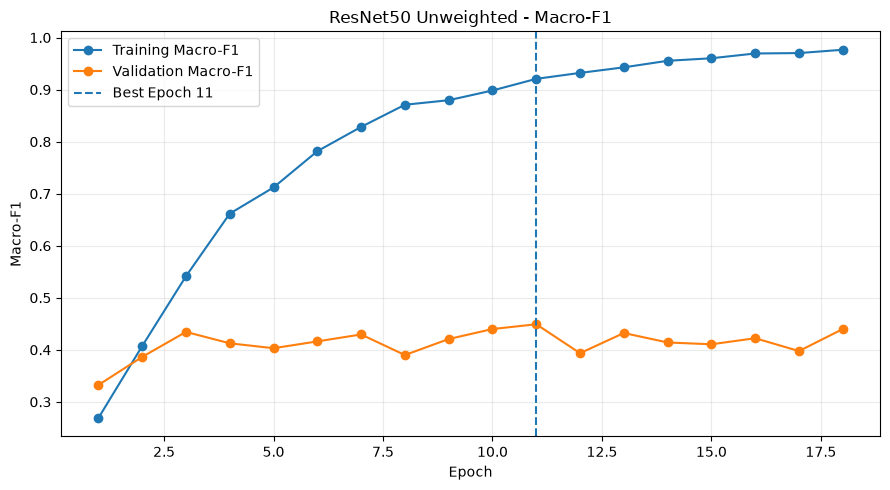

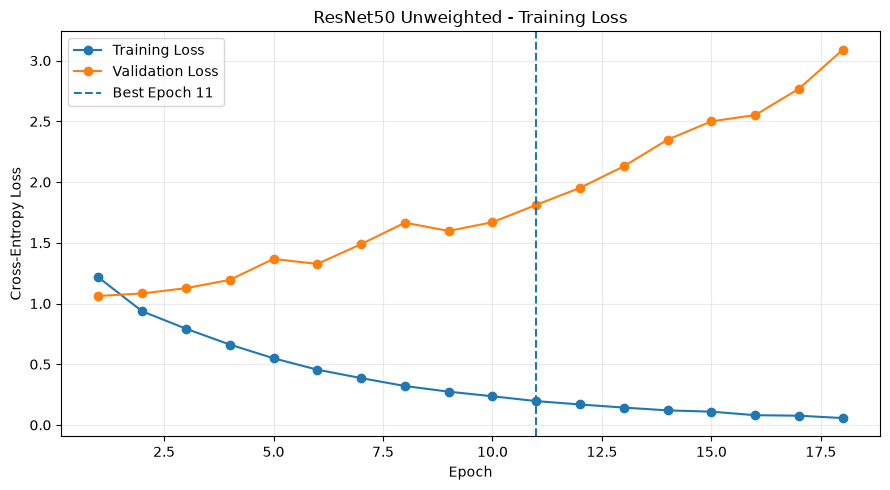

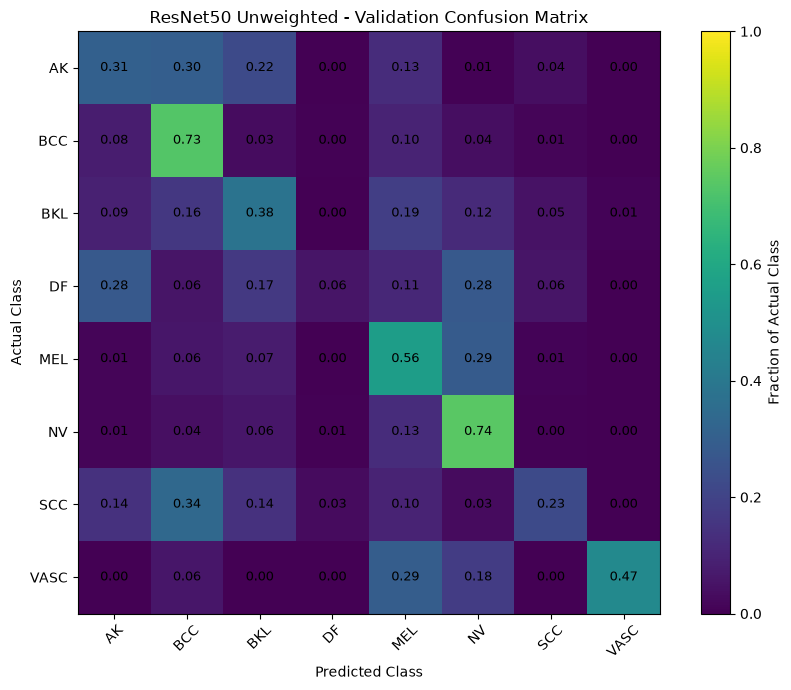

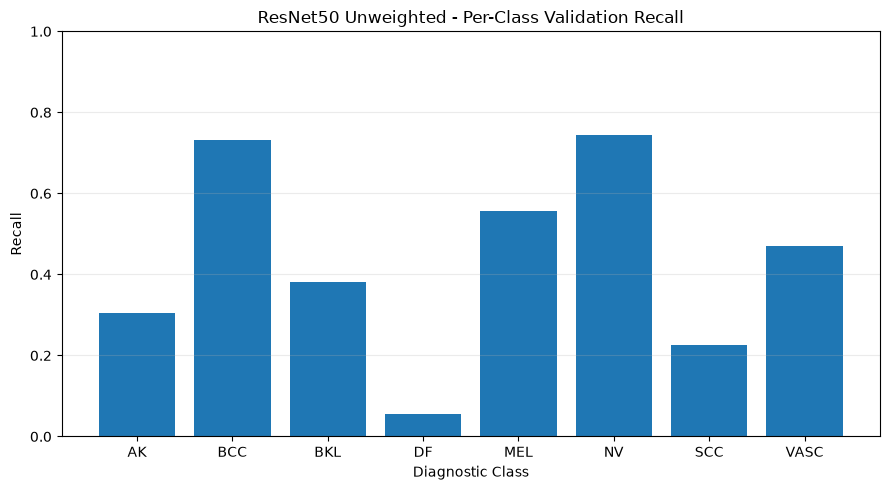


EXPERIMENT A - BEST CHECKPOINT AUDIT VERIFICATION
[PASS] Experiment configuration exists
[PASS] Training report exists
[PASS] Best checkpoint exists
[PASS] Last checkpoint exists
[PASS] AMP recovery report exists
[PASS] Training manifest exists
[PASS] Validation manifest exists
[PASS] Configuration signature valid
[PASS] Training completed successfully
[PASS] 18 epochs completed
[PASS] Epoch 11 selected as best
[PASS] AMP recovery documented
[PASS] Outer-test protected
[PASS] Training history has 18 entries
[PASS] Best Macro-F1 matches training history
[PASS] Last checkpoint epoch 18
[PASS] Best checkpoint epoch 11
[PASS] Checkpoint types valid
[PASS] Checkpoint experiment IDs valid
[PASS] Checkpoint signatures valid
[PASS] Best checkpoint has eight outputs
[PASS] Best checkpoint history valid
[PASS] Last checkpoint history valid
[PASS] Validation has 1973 images
[PASS] Validation has 247 batches
[PASS] Validation has 571 groups
[PASS] No train-validation group overlap
[PASS] Validati

In [99]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION
# PHASE 04C - CELL 2
# EXPERIMENT A: BEST CHECKPOINT AUDIT & PER-CLASS METRICS
# ============================================================

import json
import math
import time
import hashlib
import traceback
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision.models import resnet50
from tqdm.auto import tqdm


print("=" * 80)
print("PHASE 04C - CELL 2")
print("EXPERIMENT A: BEST CHECKPOINT AUDIT")
print("=" * 80)


# ============================================================
# 1. PATH CONFIGURATION
# ============================================================

ROOT = Path.cwd()
OUTPUT = ROOT / "outputs"

EXP_ID = "resnet50_original_fold01_unweighted_ce_seed42"

CONFIG_PATH = (
    OUTPUT / "configs/full_training"
    / f"{EXP_ID}.json"
)

TRAINING_REPORT_PATH = (
    OUTPUT / "reports"
    / f"{EXP_ID}_training_report.json"
)

CHECKPOINT_DIR = (
    OUTPUT / "checkpoints/full_training"
    / "resnet50/original/fold_01/unweighted_ce"
)

BEST_PATH = CHECKPOINT_DIR / "best_checkpoint.pt"
LAST_PATH = CHECKPOINT_DIR / "last_checkpoint.pt"

RECOVERY_REPORT_PATH = (
    OUTPUT / "reports"
    / "resnet50_unweighted_amp_recovery.json"
)

TRAIN_MANIFEST_PATH = (
    OUTPUT / "splits/original_branch/fold_01_train.csv"
)

VAL_MANIFEST_PATH = (
    OUTPUT / "splits/original_branch/fold_01_validation.csv"
)

PREDICTION_PATH = (
    OUTPUT / "predictions/full_training"
    / f"{EXP_ID}_validation_predictions.csv"
)

CLASS_REPORT_PATH = (
    OUTPUT / "reports"
    / f"{EXP_ID}_per_class_metrics.csv"
)

AUDIT_REPORT_PATH = (
    OUTPUT / "reports"
    / f"{EXP_ID}_best_checkpoint_audit.json"
)

FIGURE_DIR = OUTPUT / "figures"

CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available()
    else "cpu"
)

CHECKS = {}
ERRORS = []
RESULTS = {}
FIGURES = []

model = None

print("\n[1] INPUT FILE VERIFICATION")

required_files = {
    "Experiment configuration": CONFIG_PATH,
    "Training report": TRAINING_REPORT_PATH,
    "Best checkpoint": BEST_PATH,
    "Last checkpoint": LAST_PATH,
    "AMP recovery report": RECOVERY_REPORT_PATH,
    "Training manifest": TRAIN_MANIFEST_PATH,
    "Validation manifest": VAL_MANIFEST_PATH
}

for name, path in required_files.items():
    CHECKS[f"{name} exists"] = path.is_file()
    print(
        f"[{'PASS' if path.is_file() else 'FAIL'}] {name}"
    )

if not all(CHECKS.values()):
    raise FileNotFoundError(
        "Required files missing. No evaluation executed."
    )

PREDICTION_PATH.parent.mkdir(
    parents=True, exist_ok=True
)
FIGURE_DIR.mkdir(
    parents=True, exist_ok=True
)


# ============================================================
# 2. INDEPENDENT METRIC FUNCTION
# ============================================================

def calculate_audit_metrics(y_true, y_pred):

    y_true = np.asarray(y_true, dtype=np.int64)
    y_pred = np.asarray(y_pred, dtype=np.int64)

    if (
        len(y_true) == 0
        or len(y_true) != len(y_pred)
    ):
        raise ValueError("Invalid prediction dimensions.")

    if not (
        np.all((y_true >= 0) & (y_true < 8))
        and np.all((y_pred >= 0) & (y_pred < 8))
    ):
        raise ValueError("Invalid diagnostic class index.")

    cm = np.zeros((8, 8), dtype=np.int64)

    np.add.at(
        cm,
        (y_true, y_pred),
        1
    )

    tp = np.diag(cm).astype(float)
    support = cm.sum(axis=1).astype(float)
    predicted = cm.sum(axis=0).astype(float)

    precision = np.divide(
        tp,
        predicted,
        out=np.zeros(8),
        where=predicted > 0
    )

    recall = np.divide(
        tp,
        support,
        out=np.zeros(8),
        where=support > 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(8),
        where=(precision + recall) > 0
    )

    return {
        "samples": int(len(y_true)),
        "accuracy": float(np.trace(cm) / len(y_true)),
        "macro_f1": float(np.mean(f1)),
        "weighted_f1": float(
            np.sum(f1 * support) / support.sum()
        ),
        "balanced_accuracy": float(
            np.mean(recall[support > 0])
        ),
        "confusion_matrix": cm.tolist(),
        "precision": precision.tolist(),
        "recall": recall.tolist(),
        "f1": f1.tolist(),
        "support": support.astype(int).tolist(),
        "predicted_count": predicted.astype(int).tolist()
    }


# ============================================================
# 3. MAIN AUDIT
# ============================================================

try:

    print("\n[2] CONFIGURATION & TRAINING REPORT")

    with open(CONFIG_PATH, "r", encoding="utf-8") as f:
        config = json.load(f)

    with open(
        TRAINING_REPORT_PATH,
        "r",
        encoding="utf-8"
    ) as f:
        training_report = json.load(f)

    with open(
        RECOVERY_REPORT_PATH,
        "r",
        encoding="utf-8"
    ) as f:
        recovery_report = json.load(f)

    unsigned_config = {
        key: value
        for key, value in config.items()
        if key != "config_signature"
    }

    signature = hashlib.sha256(
        json.dumps(
            unsigned_config,
            sort_keys=True,
            separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest()

    CHECKS["Configuration signature valid"] = (
        signature == config["config_signature"]
    )

    CHECKS["Training completed successfully"] = (
        training_report.get("status") == "PASS"
    )

    CHECKS["18 epochs completed"] = (
        training_report.get("completed_epochs") == 18
    )

    CHECKS["Epoch 11 selected as best"] = (
        training_report.get("best_epoch") == 11
    )

    CHECKS["AMP recovery documented"] = (
        recovery_report.get("status") == "PASS"
        and recovery_report.get("recovery_after_epoch") == 12
    )

    CHECKS["Outer-test protected"] = (
        training_report.get("outer_test_evaluated") is False
        and config.get("outer_test_for_tuning") is False
    )

    history = training_report["history"]

    CHECKS["Training history has 18 entries"] = (
        len(history) == 18
        and [int(row["epoch"]) for row in history]
        == list(range(1, 19))
    )

    best_epoch = int(training_report["best_epoch"])

    best_row = next(
        row for row in history
        if int(row["epoch"]) == best_epoch
    )

    CHECKS["Best Macro-F1 matches training history"] = (
        math.isclose(
            float(
                training_report["best_validation_macro_f1"]
            ),
            float(best_row["validation_macro_f1"]),
            rel_tol=0,
            abs_tol=1e-12
        )
    )

    if not all(CHECKS.values()):
        raise RuntimeError(
            "Training report preflight failed."
        )

    print("Completed epochs:", len(history))
    print("Best epoch:", best_epoch)
    print(
        "Logged best Validation Macro-F1:",
        best_row["validation_macro_f1"]
    )


    # ========================================================
    # 4. CHECKPOINT INTEGRITY
    # ========================================================

    print("\n[3] CHECKPOINT INTEGRITY")

    last_state = torch.load(
        LAST_PATH,
        map_location="cpu",
        weights_only=True
    )

    best_state = torch.load(
        BEST_PATH,
        map_location="cpu",
        weights_only=True
    )

    CHECKS["Last checkpoint epoch 18"] = (
        last_state.get("completed_epoch") == 18
    )

    CHECKS["Best checkpoint epoch 11"] = (
        best_state.get("completed_epoch") == 11
    )

    CHECKS["Checkpoint types valid"] = (
        last_state.get("checkpoint_kind")
        == "full_training_last"
        and best_state.get("checkpoint_kind")
        == "full_training_best"
    )

    CHECKS["Checkpoint experiment IDs valid"] = (
        last_state.get("experiment_id") == EXP_ID
        and best_state.get("experiment_id") == EXP_ID
    )

    CHECKS["Checkpoint signatures valid"] = (
        last_state.get("configuration_signature")
        == signature
        and best_state.get("configuration_signature")
        == signature
    )

    CHECKS["Best checkpoint has eight outputs"] = (
        tuple(
            best_state["model_state_dict"][
                "fc.weight"
            ].shape
        ) == (8, 2048)
    )

    CHECKS["Best checkpoint history valid"] = (
        len(best_state["history"]) == 11
        and best_state["best_epoch"] == 11
    )

    CHECKS["Last checkpoint history valid"] = (
        len(last_state["history"]) == 18
        and last_state["best_epoch"] == 11
    )

    if not all(CHECKS.values()):
        raise RuntimeError(
            "Checkpoint integrity verification failed."
        )

    print("Best checkpoint: Epoch 11")
    print("Last checkpoint: Epoch 18")
    print("Checkpoint signatures: VERIFIED")

    del last_state


    # ========================================================
    # 5. PREPARE VALIDATION DATASET
    # ========================================================

    print("\n[4] VALIDATION DATASET")

    if not callable(globals().get("create_bcn_dataset")):
        raise RuntimeError(
            "create_bcn_dataset is unavailable."
        )

    val_dataset = create_bcn_dataset(
        "original",
        1,
        "validation"
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=8,
        shuffle=False,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda"),
        drop_last=False
    )

    train_manifest = pd.read_csv(
        TRAIN_MANIFEST_PATH,
        usecols=[
            "bcn_filename",
            "diagnosis",
            "leakage_group_id"
        ],
        dtype="string"
    )

    val_manifest = pd.read_csv(
        VAL_MANIFEST_PATH,
        usecols=[
            "bcn_filename",
            "diagnosis",
            "leakage_group_id"
        ],
        dtype="string"
    )

    CHECKS["Validation has 1973 images"] = (
        len(val_dataset) == 1973
        and len(val_manifest) == 1973
    )

    CHECKS["Validation has 247 batches"] = (
        len(val_loader) == 247
    )

    CHECKS["Validation has 571 groups"] = (
        val_manifest["leakage_group_id"].nunique()
        == 571
    )

    CHECKS["No train-validation group overlap"] = (
        set(
            train_manifest["leakage_group_id"]
        ).isdisjoint(
            set(val_manifest["leakage_group_id"])
        )
    )

    CHECKS["Validation filenames unique"] = (
        val_manifest["bcn_filename"].is_unique
    )

    if not all(CHECKS.values()):
        raise RuntimeError(
            "Validation dataset preflight failed."
        )

    print("Validation images:", len(val_dataset))
    print("Validation groups: 571")
    print("Validation batches:", len(val_loader))


    # ========================================================
    # 6. LOAD BEST CHECKPOINT
    # ========================================================

    print("\n[5] LOADING BEST RESNET50 MODEL")

    model = resnet50(weights=None)

    model.fc = nn.Linear(
        model.fc.in_features,
        8
    )

    model.load_state_dict(
        best_state["model_state_dict"],
        strict=True
    )

    del best_state

    model = model.to(DEVICE)
    model.eval()

    CHECKS["Best checkpoint loaded strictly"] = True

    CHECKS["Model in evaluation mode"] = (
        not model.training
    )

    print("Checkpoint epoch:", best_epoch)
    print("Model mode: EVALUATION")
    print("No gradient updates will be performed.")


    # ========================================================
    # 7. RUN INDEPENDENT VALIDATION
    # ========================================================

    print("\n[6] REPRODUCING VALIDATION METRICS")

    all_true = []
    all_pred = []
    all_filenames = []
    all_group_ids = []
    all_probabilities = []

    total_loss = 0.0
    total_samples = 0

    amp_enabled = bool(
        config["mixed_precision"]
    ) and DEVICE.type == "cuda"

    started = time.perf_counter()

    with torch.inference_mode():

        for batch in tqdm(
            val_loader,
            desc="Epoch 11 best checkpoint audit"
        ):

            images = batch["image"].to(
                DEVICE,
                non_blocking=True
            )

            labels = batch["label"].to(
                DEVICE,
                non_blocking=True
            )

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=amp_enabled
            ):
                logits = model(images)

            loss = nn.functional.cross_entropy(
                logits.float(),
                labels
            )

            if (
                not torch.isfinite(logits).all().item()
                or not torch.isfinite(loss).item()
            ):
                raise FloatingPointError(
                    "Non-finite validation output."
                )

            probabilities = torch.softmax(
                logits.float(),
                dim=1
            )

            predictions = logits.argmax(
                dim=1
            )

            batch_size = int(labels.size(0))

            total_loss += (
                float(loss.item()) * batch_size
            )

            total_samples += batch_size

            all_true.extend(
                labels.cpu().tolist()
            )

            all_pred.extend(
                predictions.cpu().tolist()
            )

            all_filenames.extend(
                list(batch["filename"])
            )

            all_group_ids.extend(
                str(value)
                for value in batch["leakage_group_id"]
            )

            all_probabilities.append(
                probabilities.cpu().numpy()
            )

    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)

    elapsed = round(
        time.perf_counter() - started,
        2
    )

    probability_matrix = np.concatenate(
        all_probabilities,
        axis=0
    )

    validation_loss = (
        total_loss / total_samples
    )

    metrics = calculate_audit_metrics(
        all_true,
        all_pred
    )

    metrics["loss"] = float(
        validation_loss
    )

    CHECKS["1973 validation predictions generated"] = (
        total_samples == 1973
        and metrics["samples"] == 1973
    )

    CHECKS["All predicted probabilities finite"] = bool(
        np.isfinite(probability_matrix).all()
    )

    CHECKS["Probability rows sum to one"] = bool(
        np.allclose(
            probability_matrix.sum(axis=1),
            1.0,
            atol=1e-5
        )
    )

    CHECKS["Predictions match maximum probability"] = bool(
        np.array_equal(
            np.argmax(probability_matrix, axis=1),
            np.asarray(all_pred)
        )
    )

    print("Evaluation completed.")
    print("Images processed:", total_samples)
    print("Inference time (seconds):", elapsed)


    # ========================================================
    # 8. VERIFY IMAGE METADATA AGAINST MANIFEST
    # ========================================================

    prediction_df = pd.DataFrame({

        "filename": all_filenames,

        "leakage_group_id": all_group_ids,

        "actual_idx": all_true,

        "predicted_idx": all_pred,

        "actual_class": [
            CLASSES[index]
            for index in all_true
        ],

        "predicted_class": [
            CLASSES[index]
            for index in all_pred
        ],

        "confidence": probability_matrix.max(
            axis=1
        )
    })

    probability_columns = []

    for index, name in enumerate(CLASSES):

        column = f"prob_{name}"

        probability_columns.append(column)

        prediction_df[column] = (
            probability_matrix[:, index]
        )

    CHECKS["Prediction filenames unique"] = (
        prediction_df["filename"].is_unique
    )

    manifest_reference = val_manifest.rename(
        columns={
            "bcn_filename": "filename",
            "diagnosis": "manifest_diagnosis",
            "leakage_group_id": "manifest_group"
        }
    )

    aligned = prediction_df.merge(
        manifest_reference,
        on="filename",
        how="left",
        validate="one_to_one",
        indicator=True
    )

    CHECKS["All filenames match validation manifest"] = (
        aligned["_merge"].eq("both").all()
    )

    CHECKS["Actual labels match validation manifest"] = (
        aligned["actual_class"]
        .astype(str)
        .equals(
            aligned["manifest_diagnosis"]
            .astype(str)
        )
    )

    CHECKS["Leakage groups match manifest"] = (
        aligned["leakage_group_id"]
        .astype(str)
        .equals(
            aligned["manifest_group"]
            .astype(str)
        )
    )


    # ========================================================
    # 9. COMPARE LOGGED AND RECOMPUTED METRICS
    # ========================================================

    print("\n[7] LOGGED VS RECOMPUTED METRICS")

    comparisons = {
        "accuracy": "validation_accuracy",
        "macro_f1": "validation_macro_f1",
        "weighted_f1": "validation_weighted_f1",
        "balanced_accuracy": (
            "validation_balanced_accuracy"
        ),
        "loss": "validation_loss"
    }

    for metric_name, logged_name in (
        comparisons.items()
    ):

        logged_value = float(
            best_row[logged_name]
        )

        reproduced_value = float(
            metrics[metric_name]
        )

        difference = abs(
            logged_value - reproduced_value
        )

        tolerance = (
            1e-3
            if metric_name == "loss"
            else 1e-5
        )

        passed = difference <= tolerance

        CHECKS[
            f"Reproduced {metric_name}"
        ] = passed

        print(
            f"{metric_name:20s} | "
            f"Logged: {logged_value:.6f} | "
            f"Recomputed: {reproduced_value:.6f} | "
            f"Difference: {difference:.8f} | "
            f"{'PASS' if passed else 'FAIL'}"
        )

    CHECKS["Confusion matrix matches epoch 11"] = (
        np.array_equal(
            np.asarray(
                metrics["confusion_matrix"]
            ),
            np.asarray(
                best_row["validation_confusion_matrix"]
            )
        )
    )

    CHECKS["Confusion matrix totals 1973"] = (
        np.asarray(
            metrics["confusion_matrix"]
        ).sum() == 1973
    )


    # ========================================================
    # 10. CLASS-WISE PERFORMANCE
    # ========================================================

    print("\n[8] CLASS-WISE VALIDATION PERFORMANCE")

    y_true = np.asarray(
        all_true,
        dtype=np.int64
    )

    y_pred = np.asarray(
        all_pred,
        dtype=np.int64
    )

    top3_indices = np.argsort(
        -probability_matrix,
        axis=1
    )[:, :3]

    top3_correct = np.any(
        top3_indices == y_true[:, None],
        axis=1
    )

    train_counts = (
        train_manifest["diagnosis"]
        .value_counts()
        .reindex(CLASSES, fill_value=0)
    )

    class_rows = []

    for index, name in enumerate(CLASSES):

        class_mask = y_true == index

        support = int(class_mask.sum())

        class_rows.append({

            "class": name,

            "train_images": int(
                train_counts[name]
            ),

            "validation_support": support,

            "predicted_count": int(
                metrics["predicted_count"][index]
            ),

            "precision": float(
                metrics["precision"][index]
            ),

            "recall": float(
                metrics["recall"][index]
            ),

            "f1": float(
                metrics["f1"][index]
            ),

            "top3_accuracy": float(
                top3_correct[class_mask].mean()
            ) if support else 0.0,

            "mean_true_class_probability": float(
                probability_matrix[
                    class_mask,
                    index
                ].mean()
            ) if support else 0.0

        })

    class_df = pd.DataFrame(
        class_rows
    )

    display(
        class_df.round(6)
    )

    zero_prediction_classes = (
        class_df.loc[
            class_df["predicted_count"] == 0,
            "class"
        ].tolist()
    )

    zero_recall_classes = (
        class_df.loc[
            class_df["recall"] == 0,
            "class"
        ].tolist()
    )

    CHECKS["Eight classes evaluated"] = (
        len(class_df) == 8
    )

    CHECKS["Class supports sum to 1973"] = (
        int(
            class_df["validation_support"].sum()
        ) == 1973
    )

    CHECKS["Predicted class counts sum to 1973"] = (
        int(
            class_df["predicted_count"].sum()
        ) == 1973
    )

    print("\nZero-prediction classes:")
    print(zero_prediction_classes)

    print("\nZero-recall classes:")
    print(zero_recall_classes)


    # ========================================================
    # 11. MOST COMMON CLASSIFICATION ERRORS
    # ========================================================

    print("\n[9] TOP MISCLASSIFICATIONS")

    cm = np.asarray(
        metrics["confusion_matrix"]
    )

    error_pairs = []

    for actual_idx in range(8):

        for predicted_idx in range(8):

            if actual_idx == predicted_idx:
                continue

            count = int(
                cm[actual_idx, predicted_idx]
            )

            if count > 0:

                error_pairs.append({

                    "actual_class": CLASSES[actual_idx],

                    "predicted_class": (
                        CLASSES[predicted_idx]
                    ),

                    "error_count": count,

                    "fraction_of_actual_class": (
                        count
                        / cm[actual_idx].sum()
                    )
                })

    error_df = pd.DataFrame(
        error_pairs
    ).sort_values(
        "error_count",
        ascending=False
    )

    display(
        error_df.head(12).round(6)
    )


    # ========================================================
    # 12. EXPLORATORY LEAKAGE-GROUP METRICS
    # ========================================================

    print("\n[10] GROUP-LEVEL EXPLORATORY METRICS")

    mixed_label_groups = int(
        prediction_df.groupby(
            "leakage_group_id"
        )["actual_idx"].nunique().gt(1).sum()
    )

    group_metrics = None

    if mixed_label_groups == 0:

        grouped_probs = prediction_df.groupby(
            "leakage_group_id",
            sort=True
        )[probability_columns].mean()

        grouped_labels = prediction_df.groupby(
            "leakage_group_id",
            sort=True
        )["actual_idx"].first()

        group_true = grouped_labels.to_numpy(
            dtype=np.int64
        )

        group_pred = np.argmax(
            grouped_probs.to_numpy(),
            axis=1
        )

        group_metrics = calculate_audit_metrics(
            group_true,
            group_pred
        )

        print(
            "Groups evaluated:",
            group_metrics["samples"]
        )

        print(
            "Group-level Macro-F1:",
            round(group_metrics["macro_f1"], 6)
        )

        CHECKS["571 groups evaluated"] = (
            group_metrics["samples"] == 571
        )

    else:

        print(
            "Mixed-label groups detected:",
            mixed_label_groups
        )

        print(
            "Group aggregation skipped."
        )

        CHECKS["Group aggregation handled safely"] = True


    # ========================================================
    # 13. SAVE RESULTS
    # ========================================================

    print("\n[11] SAVING AUDIT OUTPUTS")

    prediction_df.to_csv(
        PREDICTION_PATH,
        index=False
    )

    class_df.to_csv(
        CLASS_REPORT_PATH,
        index=False
    )

    CHECKS["Prediction CSV saved"] = (
        PREDICTION_PATH.is_file()
    )

    CHECKS["Class report CSV saved"] = (
        CLASS_REPORT_PATH.is_file()
    )


    # ========================================================
    # 14. TRAINING AND VALIDATION MACRO-F1 CURVES
    # ========================================================

    history_df = pd.DataFrame(history)

    f1_fig = (
        FIGURE_DIR
        / "resnet50_unweighted_fold01_macro_f1.png"
    )

    plt.figure(figsize=(9, 5))

    plt.plot(
        history_df["epoch"],
        history_df["train_macro_f1"],
        marker="o",
        label="Training Macro-F1"
    )

    plt.plot(
        history_df["epoch"],
        history_df["validation_macro_f1"],
        marker="o",
        label="Validation Macro-F1"
    )

    plt.axvline(
        best_epoch,
        linestyle="--",
        label=f"Best Epoch {best_epoch}"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Macro-F1")
    plt.title("ResNet50 Unweighted - Macro-F1")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        f1_fig,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    FIGURES.append(str(f1_fig))


    # ========================================================
    # 15. TRAINING AND VALIDATION LOSS CURVES
    # ========================================================

    loss_fig = (
        FIGURE_DIR
        / "resnet50_unweighted_fold01_loss.png"
    )

    plt.figure(figsize=(9, 5))

    plt.plot(
        history_df["epoch"],
        history_df["train_loss"],
        marker="o",
        label="Training Loss"
    )

    plt.plot(
        history_df["epoch"],
        history_df["validation_loss"],
        marker="o",
        label="Validation Loss"
    )

    plt.axvline(
        best_epoch,
        linestyle="--",
        label=f"Best Epoch {best_epoch}"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Cross-Entropy Loss")
    plt.title("ResNet50 Unweighted - Training Loss")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        loss_fig,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    FIGURES.append(str(loss_fig))


    # ========================================================
    # 16. ROW-NORMALIZED CONFUSION MATRIX
    # ========================================================

    cm_fig = (
        FIGURE_DIR
        / "resnet50_unweighted_fold01_confusion_matrix.png"
    )

    row_sums = cm.sum(
        axis=1,
        keepdims=True
    )

    normalized_cm = np.divide(
        cm,
        row_sums,
        out=np.zeros_like(
            cm,
            dtype=np.float64
        ),
        where=row_sums > 0
    )

    plt.figure(figsize=(9, 7))

    plt.imshow(
        normalized_cm,
        vmin=0,
        vmax=1
    )

    plt.colorbar(
        label="Fraction of Actual Class"
    )

    plt.xticks(
        range(8),
        CLASSES,
        rotation=45
    )

    plt.yticks(
        range(8),
        CLASSES
    )

    for row in range(8):

        for col in range(8):

            plt.text(
                col,
                row,
                f"{normalized_cm[row, col]:.2f}",
                ha="center",
                va="center",
                fontsize=9
            )

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.title(
        "ResNet50 Unweighted - Validation Confusion Matrix"
    )

    plt.tight_layout()

    plt.savefig(
        cm_fig,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    FIGURES.append(str(cm_fig))


    # ========================================================
    # 17. PER-CLASS RECALL
    # ========================================================

    recall_fig = (
        FIGURE_DIR
        / "resnet50_unweighted_fold01_class_recall.png"
    )

    plt.figure(figsize=(9, 5))

    plt.bar(
        class_df["class"],
        class_df["recall"]
    )

    plt.ylim(0, 1)
    plt.xlabel("Diagnostic Class")
    plt.ylabel("Recall")

    plt.title(
        "ResNet50 Unweighted - Per-Class Validation Recall"
    )

    plt.grid(
        axis="y",
        alpha=0.25
    )

    plt.tight_layout()

    plt.savefig(
        recall_fig,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    FIGURES.append(str(recall_fig))

    CHECKS["All four figures saved"] = all(
        Path(path).is_file()
        for path in FIGURES
    ) and len(FIGURES) == 4


    # ========================================================
    # 18. COLLECT RESULTS
    # ========================================================

    RESULTS = {

        "best_epoch": best_epoch,

        "completed_training_epochs": 18,

        "validation_metrics": metrics,

        "zero_prediction_classes": (
            zero_prediction_classes
        ),

        "zero_recall_classes": (
            zero_recall_classes
        ),

        "group_level_metrics": group_metrics,

        "mixed_label_groups": (
            mixed_label_groups
        ),

        "top_misclassifications": (
            error_df.head(12).to_dict(
                orient="records"
            )
        ),

        "inference_seconds": elapsed,

        "training_policy": {
            "loss": "unweighted_cross_entropy",
            "early_stopping_patience": 7,
            "amp_recovery_after_epoch": 12
        }
    }


except Exception:

    ERRORS.append(
        traceback.format_exc()
    )

    print("\nAUDIT ERROR")
    print(ERRORS[-1])


# ============================================================
# 19. CLEAN UP GPU
# ============================================================

if model is not None:
    del model

gc.collect()

if DEVICE.type == "cuda":
    torch.cuda.empty_cache()


# ============================================================
# 20. FINAL CHECKS
# ============================================================

print("\n" + "=" * 80)
print("EXPERIMENT A - BEST CHECKPOINT AUDIT VERIFICATION")
print("=" * 80)

for name, passed in CHECKS.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

AUDIT_STATUS = (
    "PASS"
    if (
        len(CHECKS) > 0
        and all(CHECKS.values())
        and not ERRORS
        and "validation_metrics" in RESULTS
    )
    else "BLOCKED"
)


# ============================================================
# 21. SAVE AUDIT REPORT
# ============================================================

AUDIT_REPORT = {

    "stage": "EXPERIMENT_A_BEST_CHECKPOINT_AUDIT",

    "status": AUDIT_STATUS,

    "experiment_id": EXP_ID,

    "model": "resnet50",

    "branch": "original",

    "fold": 1,

    "best_checkpoint_epoch": 11,

    "evaluation_partition": "validation",

    "training_performed": False,

    "outer_test_evaluated": False,

    "best_checkpoint_path": str(BEST_PATH),

    "prediction_csv": str(PREDICTION_PATH),

    "class_metrics_csv": str(CLASS_REPORT_PATH),

    "figures": FIGURES,

    "results": RESULTS,

    "checks": {
        name: bool(value)
        for name, value in CHECKS.items()
    },

    "errors": ERRORS
}

with open(
    AUDIT_REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        AUDIT_REPORT,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 22. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("RESNET50 EXPERIMENT A - AUDIT SUMMARY")
print("=" * 80)

print("Status:", AUDIT_STATUS)

print("Model: ResNet50")
print("Loss: Unweighted CrossEntropyLoss")
print("Branch: original")
print("Fold: 1")

print("Training completed epochs: 18")
print("Selected best checkpoint: Epoch 11")

if "validation_metrics" in RESULTS:

    final_metrics = RESULTS["validation_metrics"]

    print(
        "Reproduced validation accuracy:",
        round(final_metrics["accuracy"], 6)
    )

    print(
        "Reproduced validation Macro-F1:",
        round(final_metrics["macro_f1"], 6)
    )

    print(
        "Reproduced balanced accuracy:",
        round(
            final_metrics["balanced_accuracy"],
            6
        )
    )

    print(
        "Zero-recall classes:",
        RESULTS["zero_recall_classes"]
    )

print("\nPer-class report:")
print(CLASS_REPORT_PATH)

print("\nAudit report:")
print(AUDIT_REPORT_PATH)

if AUDIT_STATUS == "PASS":

    print("\nEXPERIMENT A BEST CHECKPOINT AUDIT: PASS")

    print(
        "NEXT: EXPERIMENT A RESULTS REVIEW "
        "AND EXPERIMENT B READINESS"
    )

else:

    print("\nEXPERIMENT A BEST CHECKPOINT AUDIT: BLOCKED")
    print("Review failed checks/errors before proceeding.")

print("=" * 80)


In [100]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION
# PHASE 04C - CELL 3
# WEIGHTED CROSS-ENTROPY ACCUMULATION VERIFICATION
# ============================================================

import json
import hashlib
import copy

from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F


print("=" * 80)
print("PHASE 04C - CELL 3")
print("WEIGHTED CROSS-ENTROPY GRADIENT VERIFICATION")
print("=" * 80)


# ============================================================
# 1. PROJECT PATHS
# ============================================================

ROOT = Path.cwd()
OUTPUT = ROOT / "outputs"

A_ID = "resnet50_original_fold01_unweighted_ce_seed42"
B_ID = "resnet50_original_fold01_sqrt_weighted_ce_seed42"

A_AUDIT_PATH = (
    OUTPUT / "reports" /
    f"{A_ID}_best_checkpoint_audit.json"
)

A_CONFIG_PATH = (
    OUTPUT / "configs/full_training" /
    f"{A_ID}.json"
)

B_CONFIG_PATH = (
    OUTPUT / "configs/full_training" /
    f"{B_ID}.json"
)

WEIGHTS_PATH = (
    OUTPUT / "reports" /
    "resnet50_training_class_weight_candidates.csv"
)

REPORT_PATH = (
    OUTPUT / "reports" /
    "resnet50_weighted_accumulation_verification.json"
)

CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

CHECKS = {}
DETAILS = {}


# ============================================================
# 2. VERIFY REQUIRED FILES
# ============================================================

print("\n[1] PREVIOUS EXPERIMENT VERIFICATION")

files = {
    "Experiment A audit": A_AUDIT_PATH,
    "Experiment A config": A_CONFIG_PATH,
    "Experiment B config": B_CONFIG_PATH,
    "Training class weights": WEIGHTS_PATH
}

for name, path in files.items():

    CHECKS[f"{name} exists"] = path.is_file()

    print(
        f"[{'PASS' if path.is_file() else 'FAIL'}] "
        f"{name}"
    )

if not all(CHECKS.values()):
    raise RuntimeError(
        "Required files are missing."
    )


def read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


A_AUDIT = read_json(A_AUDIT_PATH)
A_CONFIG = read_json(A_CONFIG_PATH)
B_CONFIG = read_json(B_CONFIG_PATH)

CHECKS["Experiment A audit PASS"] = (
    A_AUDIT.get("status") == "PASS"
)

CHECKS["Experiment B weighting correct"] = (
    B_CONFIG.get("class_weighting")
    == "sqrt_inverse_frequency"
)

CHECKS["Experiment B uses CrossEntropyLoss"] = (
    B_CONFIG.get("loss_function")
    == "CrossEntropyLoss"
)

CHECKS["Experiment B outer-test protected"] = (
    B_CONFIG.get("outer_test_for_tuning") is False
)


# ============================================================
# 3. VERIFY EXPERIMENT B SIGNATURE
# ============================================================

unsigned_b = {
    key: value
    for key, value in B_CONFIG.items()
    if key != "config_signature"
}

calculated_signature = hashlib.sha256(
    json.dumps(
        unsigned_b,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")
).hexdigest()

CHECKS["Experiment B config signature valid"] = (
    calculated_signature
    == B_CONFIG.get("config_signature")
)


# ============================================================
# 4. VERIFY FAIR EXPERIMENT CONFIGURATION
# ============================================================

print("\n[2] EXPERIMENT A/B CONFIGURATION COMPARISON")

shared_settings = [
    "model",
    "branch",
    "fold",
    "seed",
    "image_size",
    "num_classes",
    "train_images",
    "validation_images",
    "max_epochs",
    "early_stopping_patience",
    "early_stopping_min_delta",
    "batch_size",
    "gradient_accumulation_steps",
    "initial_learning_rate",
    "weight_decay",
    "optimizer",
    "scheduler",
    "scheduler_t_max",
    "gradient_clip_norm",
    "mixed_precision"
]

for key in shared_settings:

    CHECKS[f"Shared setting: {key}"] = (
        A_CONFIG.get(key)
        == B_CONFIG.get(key)
    )

CHECKS["Separate experiment identifiers"] = (
    A_CONFIG["experiment_id"]
    != B_CONFIG["experiment_id"]
)

CHECKS["Separate checkpoint directories"] = (
    A_CONFIG["checkpoint_directory"]
    != B_CONFIG["checkpoint_directory"]
)

print("A: Unweighted CE")
print("B: Square-root weighted CE")
print("Shared settings checked:", len(shared_settings))


# ============================================================
# 5. LOAD AND VERIFY TRAINING CLASS WEIGHTS
# ============================================================

print("\n[3] CLASS WEIGHT VERIFICATION")

weights_df = pd.read_csv(
    WEIGHTS_PATH
).set_index("class").reindex(CLASSES)

weights_array = weights_df[
    "sqrt_inverse_frequency_candidate"
].to_numpy(dtype=np.float64)

class_weights = torch.tensor(
    weights_array,
    dtype=torch.float32,
    device="cpu"
)

CHECKS["Eight weights available"] = (
    len(class_weights) == 8
)

CHECKS["All weights finite"] = bool(
    torch.isfinite(class_weights).all()
)

CHECKS["All weights positive"] = bool(
    (class_weights > 0).all()
)

CHECKS["Weights match Experiment B configuration"] = (
    np.allclose(
        weights_array,
        np.asarray(
            B_CONFIG["class_weights"],
            dtype=np.float64
        ),
        atol=1e-7,
        rtol=1e-7
    )
)

display(
    pd.DataFrame({
        "class": CLASSES,
        "training_images": (
            weights_df["train_images"]
            .to_numpy(dtype=int)
        ),
        "weighted_ce_coefficient": (
            weights_array
        )
    }).round(6)
)


# ============================================================
# 6. SYNTHETIC TEST DATA
# ============================================================

print("\n[4] SYNTHETIC GRADIENT ACCUMULATION TEST")

# Test structure:
# 19 samples, microbatch size 8.
#
# Microbatches: 8, 8, 3
# Optimizer windows: 16, 3
#
# Deliberately different class frequencies in
# the first and second microbatch.

labels = torch.tensor(
    [
        3, 7, 3, 7, 3, 7, 3, 7,
        5, 5, 5, 5, 1, 1, 5, 5,
        0, 2, 6
    ],
    dtype=torch.long
)

generator = torch.Generator().manual_seed(271828)

features = torch.randn(
    19,
    4,
    generator=generator
)

MICROBATCH_SIZE = 8
ACCUM_STEPS = 2
LEARNING_RATE = 0.05

windows = [
    (0, 16),
    (16, 19)
]

CHECKS["Synthetic sample count correct"] = (
    len(labels) == 19
)

CHECKS["Partial accumulation window included"] = (
    windows[-1][1] - windows[-1][0] == 3
)


# ============================================================
# 7. CREATE IDENTICAL INITIAL MODELS
# ============================================================

# This context protects notebook CPU RNG state.

with torch.random.fork_rng(devices=[]):

    torch.manual_seed(2026)

    initial_model = nn.Linear(
        4,
        8
    )

    initial_state = copy.deepcopy(
        initial_model.state_dict()
    )


def create_test_model():

    model = nn.Linear(4, 8)

    model.load_state_dict(
        initial_state,
        strict=True
    )

    return model


# ============================================================
# 8. REFERENCE AND ACCUMULATION METHODS
# ============================================================

def run_synthetic_training(
    method,
    weights=None
):

    model = create_test_model()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=LEARNING_RATE
    )

    steps = 0

    for start, end in windows:

        optimizer.zero_grad(
            set_to_none=True
        )

        window_x = features[start:end]
        window_y = labels[start:end]

        if method == "full_batch":

            # Mathematical reference:
            # one full forward/backward per window.

            logits = model(window_x)

            loss = F.cross_entropy(
                logits,
                window_y,
                weight=weights,
                reduction="mean"
            )

            loss.backward()

        elif method == "correct_weighted":

            # Correct denominator for weighted CE:
            # sum of target class weights across
            # the ENTIRE accumulation window.

            if weights is None:
                denominator = float(end - start)

            else:
                denominator = (
                    weights[window_y].sum()
                )

            for offset in range(
                start,
                end,
                MICROBATCH_SIZE
            ):

                batch_end = min(
                    offset + MICROBATCH_SIZE,
                    end
                )

                logits = model(
                    features[offset:batch_end]
                )

                loss_sum = F.cross_entropy(
                    logits,
                    labels[offset:batch_end],
                    weight=weights,
                    reduction="sum"
                )

                normalized_loss = (
                    loss_sum / denominator
                )

                normalized_loss.backward()

        elif method == "sample_normalized":

            # Existing unweighted accumulation style.
            #
            # This is correct for ordinary mean CE,
            # but NOT generally for weighted mean CE.

            window_sample_count = end - start

            for offset in range(
                start,
                end,
                MICROBATCH_SIZE
            ):

                batch_end = min(
                    offset + MICROBATCH_SIZE,
                    end
                )

                batch_count = (
                    batch_end - offset
                )

                logits = model(
                    features[offset:batch_end]
                )

                batch_loss = F.cross_entropy(
                    logits,
                    labels[offset:batch_end],
                    weight=weights,
                    reduction="mean"
                )

                normalized_loss = (
                    batch_loss
                    * batch_count
                    / window_sample_count
                )

                normalized_loss.backward()

        else:

            raise ValueError(
                "Unknown test method."
            )

        optimizer.step()

        steps += 1

    return model, steps


# ============================================================
# 9. COMPARE MODEL PARAMETERS
# ============================================================

def maximum_parameter_difference(
    model_a,
    model_b
):

    differences = []

    for parameter_a, parameter_b in zip(
        model_a.parameters(),
        model_b.parameters()
    ):

        differences.append(
            float(
                (
                    parameter_a.detach()
                    - parameter_b.detach()
                ).abs().max().item()
            )
        )

    return max(differences)


# ============================================================
# 10. UNWEIGHTED BASELINE CHECK
# ============================================================

unweighted_reference, steps_ref = (
    run_synthetic_training(
        "full_batch",
        weights=None
    )
)

unweighted_accumulated, steps_unweighted = (
    run_synthetic_training(
        "sample_normalized",
        weights=None
    )
)

unweighted_difference = (
    maximum_parameter_difference(
        unweighted_reference,
        unweighted_accumulated
    )
)

print("\n[5] UNWEIGHTED CE EQUIVALENCE")

print(
    "Maximum parameter difference:",
    unweighted_difference
)

CHECKS["Unweighted accumulation matches reference"] = (
    unweighted_difference < 1e-6
)


# ============================================================
# 11. WEIGHTED REFERENCE
# ============================================================

weighted_reference, steps_weighted_ref = (
    run_synthetic_training(
        "full_batch",
        weights=class_weights
    )
)

weighted_correct, steps_weighted_correct = (
    run_synthetic_training(
        "correct_weighted",
        weights=class_weights
    )
)

weighted_naive, steps_weighted_naive = (
    run_synthetic_training(
        "sample_normalized",
        weights=class_weights
    )
)

correct_difference = (
    maximum_parameter_difference(
        weighted_reference,
        weighted_correct
    )
)

naive_difference = (
    maximum_parameter_difference(
        weighted_reference,
        weighted_naive
    )
)

print("\n[6] WEIGHTED CE EQUIVALENCE")

print(
    "Correct weighted normalization difference:",
    correct_difference
)

print(
    "Sample-count normalization difference:",
    naive_difference
)

CHECKS["Correct weighted accumulation matches reference"] = (
    correct_difference < 1e-6
)

CHECKS["Naive sample normalization differs for weighted CE"] = (
    naive_difference > 1e-5
)

CHECKS["All methods performed two optimizer steps"] = (
    all(
        steps == 2
        for steps in [
            steps_ref,
            steps_unweighted,
            steps_weighted_ref,
            steps_weighted_correct,
            steps_weighted_naive
        ]
    )
)


# ============================================================
# 12. CHECK WEIGHTED DENOMINATORS
# ============================================================

print("\n[7] CLASS-WEIGHT DENOMINATOR CHECK")

first_microbatch_weight = float(
    class_weights[labels[:8]].sum()
)

second_microbatch_weight = float(
    class_weights[labels[8:16]].sum()
)

first_window_weight = float(
    class_weights[labels[:16]].sum()
)

partial_window_weight = float(
    class_weights[labels[16:19]].sum()
)

CHECKS["First window denominator consistent"] = (
    math.isclose(
        first_microbatch_weight
        + second_microbatch_weight,
        first_window_weight,
        rel_tol=1e-6
    )
)

CHECKS["Partial window weighted denominator positive"] = (
    partial_window_weight > 0
)

print(
    "First microbatch weight sum:",
    round(first_microbatch_weight, 6)
)

print(
    "Second microbatch weight sum:",
    round(second_microbatch_weight, 6)
)

print(
    "First accumulation window denominator:",
    round(first_window_weight, 6)
)

print(
    "Partial window denominator:",
    round(partial_window_weight, 6)
)


# ============================================================
# 13. VERIFY EXISTING TRAINING ENGINE LIMITATION
# ============================================================

print("\n[8] CURRENT ENGINE COMPATIBILITY")

engine = globals().get(
    "train_one_epoch"
)

CHECKS["Existing training engine available"] = (
    callable(engine)
)

if callable(engine):

    engine_variables = set(
        engine.__code__.co_varnames
    )

    CHECKS["Sample-normalized engine detected"] = (
        "window_total_samples" in engine_variables
        and "normalized_loss" in engine_variables
    )

else:

    CHECKS["Sample-normalized engine detected"] = False

print(
    "Old training engine available:",
    callable(engine)
)

print(
    "Weighted accumulation correction:",
    "NEEDED BEFORE EXPERIMENT B"
)


# ============================================================
# 14. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("WEIGHTED LOSS ACCUMULATION VERIFICATION")
print("=" * 80)

for name, result in CHECKS.items():

    print(
        f"[{'PASS' if result else 'FAIL'}] "
        f"{name}"
    )

STATUS = (
    "PASS"
    if (
        CHECKS
        and all(CHECKS.values())
    )
    else "BLOCKED"
)


# ============================================================
# 15. SAVE REPORT
# ============================================================

REPORT = {

    "stage": "WEIGHTED_CE_ACCUMULATION_VERIFICATION",

    "status": STATUS,

    "experiment": B_ID,

    "class_names": CLASSES,

    "class_weights": weights_array.tolist(),

    "synthetic_test": {

        "samples": 19,

        "microbatch_sizes": [8, 8, 3],

        "optimizer_steps": 2,

        "unweighted_difference": (
            unweighted_difference
        ),

        "correct_weighted_difference": (
            correct_difference
        ),

        "naive_weighted_difference": (
            naive_difference
        ),

        "correct_weighted_normalization": (
            "sum_weighted_losses_divided_by_"
            "sum_target_weights_per_accumulation_window"
        )

    },

    "checks": {
        key: bool(value)
        for key, value in CHECKS.items()
    },

    "experiment_b_training_started": False,

    "production_weighted_engine_implemented": False,

    "outer_test_evaluated": False
}

REPORT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

with open(
    REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        REPORT,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 16. SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("WEIGHTED CE READINESS SUMMARY")
print("=" * 80)

print("Status:", STATUS)

print(
    "Correct weighted gradient difference:",
    correct_difference
)

print(
    "Naive weighted gradient difference:",
    naive_difference
)

print("Production training executed: NO")
print("Outer-test evaluated: NO")

print("\nVerification report:")
print(REPORT_PATH)

if STATUS == "PASS":

    print("\nWEIGHTED CE MATHEMATICAL TEST: PASS")

    print(
        "NEXT: IMPLEMENT VERIFIED WEIGHTED "
        "TRAINING ENGINE FOR EXPERIMENT B"
    )

else:

    print("\nWEIGHTED CE VERIFICATION: BLOCKED")

print("=" * 80)


PHASE 04C - CELL 3
WEIGHTED CROSS-ENTROPY GRADIENT VERIFICATION

[1] PREVIOUS EXPERIMENT VERIFICATION
[PASS] Experiment A audit
[PASS] Experiment A config
[PASS] Experiment B config
[PASS] Training class weights

[2] EXPERIMENT A/B CONFIGURATION COMPARISON
A: Unweighted CE
B: Square-root weighted CE
Shared settings checked: 20

[3] CLASS WEIGHT VERIFICATION


,class,training_images,weighted_ce_coefficient
0,AK,466,1.665760
1,BCC,1764,0.856163
2,BKL,705,1.354288
3,DF,77,4.097889
4,MEL,1799,0.847793
5,NV,2673,0.695514
6,SCC,266,2.204777
7,VASC,63,4.530386



[4] SYNTHETIC GRADIENT ACCUMULATION TEST

[5] UNWEIGHTED CE EQUIVALENCE
Maximum parameter difference: 0.0

[6] WEIGHTED CE EQUIVALENCE
Correct weighted normalization difference: 1.4901161193847656e-08
Sample-count normalization difference: 0.011847451329231262

[7] CLASS-WEIGHT DENOMINATOR CHECK
First microbatch weight sum: 34.5131
Second microbatch weight sum: 5.88541
First accumulation window denominator: 40.398506
Partial window denominator: 5.224825

[8] CURRENT ENGINE COMPATIBILITY
Old training engine available: True
Weighted accumulation correction: NEEDED BEFORE EXPERIMENT B

WEIGHTED LOSS ACCUMULATION VERIFICATION
[PASS] Experiment A audit exists
[PASS] Experiment A config exists
[PASS] Experiment B config exists
[PASS] Training class weights exists
[PASS] Experiment A audit PASS
[PASS] Experiment B weighting correct
[PASS] Experiment B uses CrossEntropyLoss
[PASS] Experiment B outer-test protected
[PASS] Experiment B config signature valid
[PASS] Shared setting: model
[PASS] 

In [101]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION
# PHASE 04C - CELL 4
# WEIGHTED TRAINING ENGINE IMPLEMENTATION & VERIFICATION
# ============================================================

import json
import math
import copy
import hashlib
import gc

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader


print("=" * 80)
print("PHASE 04C - CELL 4")
print("WEIGHTED TRAINING ENGINE IMPLEMENTATION")
print("=" * 80)


# ============================================================
# 1. PROJECT AND EXPERIMENT CONFIGURATION
# ============================================================

WE_ROOT = Path.cwd()
WE_OUTPUT = WE_ROOT / "outputs"

WE_EXPERIMENT_ID = (
    "resnet50_original_fold01_sqrt_weighted_ce_seed42"
)

WE_CONFIG_PATH = (
    WE_OUTPUT
    / "configs/full_training"
    / f"{WE_EXPERIMENT_ID}.json"
)

WE_MATH_REPORT_PATH = (
    WE_OUTPUT
    / "reports/resnet50_weighted_accumulation_verification.json"
)

WE_AUDIT_PATH = (
    WE_OUTPUT
    / "reports"
    / "resnet50_original_fold01_unweighted_ce_seed42"
      "_best_checkpoint_audit.json"
)

WE_REPORT_PATH = (
    WE_OUTPUT
    / "reports/resnet50_weighted_engine_verification.json"
)

WE_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

WE_CHECKS = {}
WE_ERRORS = []
WE_RESULTS = {}

for name, path in {
    "Experiment B configuration": WE_CONFIG_PATH,
    "Previous weighted mathematical test": WE_MATH_REPORT_PATH,
    "Experiment A audit": WE_AUDIT_PATH
}.items():

    WE_CHECKS[f"{name} exists"] = path.is_file()

if not all(WE_CHECKS.values()):
    raise FileNotFoundError(
        "Required verification files are missing."
    )


def we_read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


WE_CONFIG = we_read_json(WE_CONFIG_PATH)
WE_MATH_REPORT = we_read_json(WE_MATH_REPORT_PATH)
WE_A_AUDIT = we_read_json(WE_AUDIT_PATH)

WE_CHECKS["Previous weighted test PASS"] = (
    WE_MATH_REPORT.get("status") == "PASS"
)

WE_CHECKS["Experiment A audit PASS"] = (
    WE_A_AUDIT.get("status") == "PASS"
)

WE_CHECKS["Experiment B weighting correct"] = (
    WE_CONFIG.get("class_weighting")
    == "sqrt_inverse_frequency"
)

WE_CHECKS["Eight class weights available"] = (
    isinstance(WE_CONFIG.get("class_weights"), list)
    and len(WE_CONFIG["class_weights"]) == 8
)

WE_CHECKS["Experiment B outer-test protected"] = (
    WE_CONFIG.get("outer_test_for_tuning") is False
)

unsigned_config = {
    key: value
    for key, value in WE_CONFIG.items()
    if key != "config_signature"
}

we_signature = hashlib.sha256(
    json.dumps(
        unsigned_config,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")
).hexdigest()

WE_CHECKS["Experiment B signature valid"] = (
    we_signature == WE_CONFIG.get("config_signature")
)

if not all(WE_CHECKS.values()):
    raise RuntimeError(
        "Experiment B preflight verification failed."
    )

WE_WEIGHTS = torch.tensor(
    WE_CONFIG["class_weights"],
    dtype=torch.float32
)

print("\n[1] CONFIGURATION")

print("Experiment:", WE_EXPERIMENT_ID)
print("Model: ResNet50")
print("Loss: Square-root weighted CrossEntropyLoss")
print("Classes:", len(WE_CLASSES))
print("Outer-test: PROTECTED")


# ============================================================
# 2. DEDICATED WEIGHTED TRAINING ENGINE
# ============================================================

def train_one_epoch_weighted(
    model,
    loader,
    optimizer,
    criterion,
    scaler,
    device,
    accumulation_steps=2,
    gradient_clip_norm=1.0
):

    device = torch.device(device)

    # --------------------------------------------------------
    # SAFETY CHECKS
    # --------------------------------------------------------

    if not isinstance(criterion, nn.CrossEntropyLoss):
        raise TypeError(
            "Weighted engine requires nn.CrossEntropyLoss."
        )

    if (
        criterion.weight is None
        or criterion.reduction != "mean"
    ):
        raise ValueError(
            "Weighted CE requires class weights "
            "and reduction='mean'."
        )

    if (
        criterion.ignore_index != -100
        or criterion.label_smoothing != 0
    ):
        raise ValueError(
            "Ignore-index targets and label smoothing "
            "are not supported by this engine."
        )

    weights = criterion.weight

    if weights.device != device:
        raise ValueError(
            "Criterion weights must be on the model device."
        )

    if (
        weights.ndim != 1
        or len(weights) != 8
        or weights.dtype != torch.float32
    ):
        raise ValueError(
            "Expected eight FP32 class weights."
        )

    if not bool(torch.isfinite(weights).all().item()):
        raise ValueError(
            "Class weights contain non-finite values."
        )

    if not bool((weights > 0).all().item()):
        raise ValueError(
            "All class weights must be positive."
        )

    if accumulation_steps < 1:
        raise ValueError(
            "Invalid accumulation_steps."
        )

    if (
        not math.isfinite(float(gradient_clip_norm))
        or gradient_clip_norm <= 0
    ):
        raise ValueError(
            "Invalid gradient clipping norm."
        )

    if len(loader) == 0:
        raise ValueError(
            "Training loader is empty."
        )

    # --------------------------------------------------------
    # INITIALIZE
    # --------------------------------------------------------

    model.train()

    optimizer.zero_grad(set_to_none=True)

    trainable_parameters = [
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ]

    if not trainable_parameters:
        raise RuntimeError(
            "No trainable parameters found."
        )

    amp_enabled = (
        device.type == "cuda"
        and scaler.is_enabled()
    )

    total_batches = len(loader)
    loader_iterator = iter(loader)

    true_labels = []
    predicted_labels = []

    total_weighted_loss = 0.0
    total_target_weight = 0.0

    samples_seen = 0
    batches_seen = 0

    optimizer_steps = 0
    skipped_optimizer_steps = 0

    gradient_norms = []

    # --------------------------------------------------------
    # ACCUMULATION WINDOWS
    # --------------------------------------------------------

    for window_start in range(
        0,
        total_batches,
        accumulation_steps
    ):

        window_batch_count = min(
            accumulation_steps,
            total_batches - window_start
        )

        window_batches = []

        window_total_weight = 0.0

        # ----------------------------------------------------
        # COLLECT MICRO-BATCHES
        # ----------------------------------------------------

        for _ in range(window_batch_count):

            batch = next(loader_iterator)

            if (
                not isinstance(batch, dict)
                or "image" not in batch
                or "label" not in batch
            ):
                raise RuntimeError(
                    "Expected batch with image and label."
                )

            labels = batch["label"].to(
                device=device,
                dtype=torch.long,
                non_blocking=(device.type == "cuda")
            )

            if (
                labels.ndim != 1
                or labels.numel()
                != int(batch["image"].shape[0])
            ):
                raise RuntimeError(
                    "Invalid training batch dimensions."
                )

            if bool(
                (
                    (labels < 0)
                    | (labels >= 8)
                ).any().item()
            ):
                raise RuntimeError(
                    "Invalid diagnostic class index."
                )

            window_batches.append(
                (batch["image"], labels)
            )

            # IMPORTANT:
            # Weighted CrossEntropyLoss with mean
            # reduction uses the sum of target weights,
            # not the number of images.

            with torch.no_grad():

                batch_target_weight = float(
                    weights[labels].sum().item()
                )

            window_total_weight += (
                batch_target_weight
            )

        if (
            not math.isfinite(window_total_weight)
            or window_total_weight <= 0
        ):
            raise FloatingPointError(
                "Invalid accumulation-window weight sum."
            )

        optimizer.zero_grad(
            set_to_none=True
        )

        # ----------------------------------------------------
        # FORWARD AND BACKWARD
        # ----------------------------------------------------

        for images_cpu, labels in window_batches:

            images = images_cpu.to(
                device=device,
                non_blocking=(device.type == "cuda")
            )

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=amp_enabled
            ):

                logits = model(images)

                # FP32 loss calculation helps stability.
                # Sum reduction is essential here.

                loss_sum = F.cross_entropy(
                    logits.float(),
                    labels,
                    weight=weights,
                    reduction="sum"
                )

            if not bool(
                torch.isfinite(loss_sum).item()
            ):
                raise FloatingPointError(
                    "Non-finite weighted training loss."
                )

            # CORRECT WEIGHTED ACCUMULATION:
            #
            # sum(weight_i * CE_i)
            # --------------------
            # sum(weight_i)
            #
            # Denominator covers the WHOLE window.

            normalized_loss = (
                loss_sum / window_total_weight
            )

            scaler.scale(
                normalized_loss
            ).backward()

            total_weighted_loss += float(
                loss_sum.detach().item()
            )

            with torch.no_grad():

                predicted = (
                    logits.detach()
                    .argmax(dim=1)
                )

                predicted_labels.extend(
                    predicted.cpu().tolist()
                )

                true_labels.extend(
                    labels.cpu().tolist()
                )

            samples_seen += int(
                labels.numel()
            )

            batches_seen += 1

        # ----------------------------------------------------
        # GRADIENT UNSCALING AND CLIPPING
        # ----------------------------------------------------

        scaler.unscale_(
            optimizer
        )

        gradient_norm = (
            nn.utils.clip_grad_norm_(
                trainable_parameters,
                max_norm=float(
                    gradient_clip_norm
                ),
                error_if_nonfinite=False
            )
        )

        gradients_finite = bool(
            torch.isfinite(
                gradient_norm
            ).item()
        )

        if (
            not gradients_finite
            and not scaler.is_enabled()
        ):
            raise FloatingPointError(
                "Non-finite gradients without AMP recovery."
            )

        # ----------------------------------------------------
        # AMP OVERFLOW HANDLING
        # ----------------------------------------------------

        # GradScaler automatically skips the optimizer
        # update if inf/NaN gradients were detected.
        #
        # Do not bypass this safety mechanism.

        previous_scale = float(
            scaler.get_scale()
        )

        scaler.step(
            optimizer
        )

        scaler.update()

        updated_scale = float(
            scaler.get_scale()
        )

        step_skipped = (
            scaler.is_enabled()
            and updated_scale < previous_scale
        )

        if step_skipped:

            skipped_optimizer_steps += 1

        else:

            optimizer_steps += 1

            if not gradients_finite:
                raise FloatingPointError(
                    "Non-finite gradients were not skipped."
                )

            gradient_norms.append(
                float(gradient_norm.item())
            )

        total_target_weight += (
            window_total_weight
        )

    # --------------------------------------------------------
    # DATASET TRAVERSAL CHECK
    # --------------------------------------------------------

    if batches_seen != total_batches:
        raise RuntimeError(
            "Not all training batches were processed."
        )

    if len(true_labels) != samples_seen:
        raise RuntimeError(
            "Training prediction count mismatch."
        )

    if total_target_weight <= 0:
        raise RuntimeError(
            "Invalid epoch target weight."
        )

    # --------------------------------------------------------
    # CLASSIFICATION METRICS
    # --------------------------------------------------------

    confusion = np.zeros(
        (8, 8),
        dtype=np.int64
    )

    np.add.at(
        confusion,
        (
            np.asarray(
                true_labels,
                dtype=np.int64
            ),
            np.asarray(
                predicted_labels,
                dtype=np.int64
            )
        ),
        1
    )

    tp = np.diag(
        confusion
    ).astype(np.float64)

    support = confusion.sum(
        axis=1
    ).astype(np.float64)

    predicted_counts = confusion.sum(
        axis=0
    ).astype(np.float64)

    precision = np.divide(
        tp,
        predicted_counts,
        out=np.zeros(8),
        where=predicted_counts > 0
    )

    recall = np.divide(
        tp,
        support,
        out=np.zeros(8),
        where=support > 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(8),
        where=(precision + recall) > 0
    )

    per_class = []

    for index, class_name in enumerate(
        WE_CLASSES
    ):

        per_class.append({

            "class": class_name,

            "support": int(
                support[index]
            ),

            "precision": float(
                precision[index]
            ),

            "recall": float(
                recall[index]
            ),

            "f1": float(
                f1[index]
            )
        })

    # --------------------------------------------------------
    # RETURN TRAINING METRICS
    # --------------------------------------------------------

    return {

        "loss": float(
            total_weighted_loss
            / total_target_weight
        ),

        "accuracy": float(
            tp.sum() / samples_seen
        ),

        "macro_f1": float(
            f1.mean()
        ),

        "weighted_f1": float(
            np.sum(f1 * support)
            / samples_seen
        ),

        "balanced_accuracy": float(
            np.mean(recall[support > 0])
        ),

        "samples": int(
            samples_seen
        ),

        "batches": int(
            batches_seen
        ),

        "optimizer_steps": int(
            optimizer_steps
        ),

        "skipped_optimizer_steps": int(
            skipped_optimizer_steps
        ),

        "optimizer_step_attempts": int(
            optimizer_steps
            + skipped_optimizer_steps
        ),

        "confusion_matrix": (
            confusion.tolist()
        ),

        "per_class": per_class,

        "mean_unclipped_grad_norm": (
            float(np.mean(gradient_norms))
            if gradient_norms
            else None
        ),

        "amp_scale_end": float(
            scaler.get_scale()
        )
    }


print("\n[2] WEIGHTED TRAINING ENGINE")

print("Function: train_one_epoch_weighted")
print("Weighted denominator: WINDOW TARGET-WEIGHT SUM")
print("Partial batches: SUPPORTED")
print("Gradient clipping: SUPPORTED")
print("AMP overflow handling: SUPPORTED")
print("Unweighted training engine: UNCHANGED")

WE_CHECKS["Weighted engine callable"] = (
    callable(
        train_one_epoch_weighted
    )
)

WE_CHECKS["Original engine preserved"] = (
    callable(
        globals().get("train_one_epoch")
    )
)


# ============================================================
# 3. SYNTHETIC REFERENCE DATA
# ============================================================

class WEUnitDataset(Dataset):

    def __init__(
        self,
        features,
        labels
    ):

        self.features = features
        self.labels = labels

    def __len__(self):

        return len(
            self.labels
        )

    def __getitem__(
        self,
        index
    ):

        return {

            "image": self.features[index],

            "label": self.labels[index]

        }


we_labels = torch.tensor(
    [
        3, 7, 3, 7, 3, 7, 3, 7,
        5, 5, 5, 5, 1, 1, 5, 5,
        0, 2, 6
    ],
    dtype=torch.long
)

we_features = torch.randn(
    19,
    4,
    generator=(
        torch.Generator().manual_seed(271828)
    )
)

with torch.random.fork_rng(
    devices=[]
):

    torch.manual_seed(
        2026
    )

    we_initial_state = copy.deepcopy(
        nn.Linear(
            4, 8
        ).state_dict()
    )


def we_create_test_model():

    test_model = nn.Linear(
        4, 8
    )

    test_model.load_state_dict(
        we_initial_state,
        strict=True
    )

    return test_model


# ============================================================
# 4. FULL-BATCH REFERENCE
# ============================================================

print("\n[3] CPU FULL-BATCH REFERENCE")

we_reference = we_create_test_model()

we_reference_optimizer = (
    torch.optim.SGD(
        we_reference.parameters(),
        lr=0.05
    )
)

for start, end in [
    (0, 16),
    (16, 19)
]:

    we_reference_optimizer.zero_grad(
        set_to_none=True
    )

    reference_logits = we_reference(
        we_features[start:end]
    )

    reference_loss = F.cross_entropy(
        reference_logits,
        we_labels[start:end],
        weight=WE_WEIGHTS,
        reduction="mean"
    )

    reference_loss.backward()

    we_reference_optimizer.step()

print("Reference samples: 19")
print("Reference optimizer steps: 2")


# ============================================================
# 5. TEST ACTUAL WEIGHTED ENGINE ON CPU
# ============================================================

print("\n[4] CPU WEIGHTED ENGINE UNIT TEST")

we_cpu_model = we_create_test_model()

we_cpu_optimizer = (
    torch.optim.SGD(
        we_cpu_model.parameters(),
        lr=0.05
    )
)

we_cpu_criterion = nn.CrossEntropyLoss(
    weight=WE_WEIGHTS
)

we_cpu_scaler = torch.amp.GradScaler(
    "cpu",
    enabled=False
)

we_cpu_loader = DataLoader(
    WEUnitDataset(
        we_features,
        we_labels
    ),
    batch_size=8,
    shuffle=False,
    num_workers=0,
    drop_last=False
)

we_cpu_metrics = train_one_epoch_weighted(
    model=we_cpu_model,
    loader=we_cpu_loader,
    optimizer=we_cpu_optimizer,
    criterion=we_cpu_criterion,
    scaler=we_cpu_scaler,
    device=torch.device("cpu"),
    accumulation_steps=2,
    gradient_clip_norm=1e9
)

we_cpu_difference = max(

    float(
        (
            actual.detach()
            - reference.detach()
        ).abs().max().item()
    )

    for actual, reference in zip(
        we_cpu_model.parameters(),
        we_reference.parameters()
    )
)

WE_CHECKS["CPU model matches weighted reference"] = (
    we_cpu_difference < 1e-6
)

WE_CHECKS["CPU processes 19 samples"] = (
    we_cpu_metrics["samples"] == 19
)

WE_CHECKS["CPU processes three microbatches"] = (
    we_cpu_metrics["batches"] == 3
)

WE_CHECKS["CPU takes two optimizer steps"] = (
    we_cpu_metrics["optimizer_steps"] == 2
)

WE_CHECKS["CPU has zero skipped steps"] = (
    we_cpu_metrics["skipped_optimizer_steps"]
    == 0
)

WE_CHECKS["CPU weighted loss finite"] = (
    math.isfinite(
        we_cpu_metrics["loss"]
    )
)

print(
    "Maximum parameter difference:",
    we_cpu_difference
)

print(
    "Samples:",
    we_cpu_metrics["samples"]
)

print(
    "Microbatches:",
    we_cpu_metrics["batches"]
)

print(
    "Optimizer steps:",
    we_cpu_metrics["optimizer_steps"]
)

print(
    "Skipped steps:",
    we_cpu_metrics["skipped_optimizer_steps"]
)


# ============================================================
# 6. GPU + AMP SMOKE TEST
# ============================================================

print("\n[5] CUDA AMP SMOKE TEST")

if torch.cuda.is_available():

    we_device = torch.device("cuda:0")

    we_gpu_model = we_create_test_model().to(
        we_device
    )

    we_gpu_optimizer = (
        torch.optim.SGD(
            we_gpu_model.parameters(),
            lr=0.05
        )
    )

    we_gpu_criterion = nn.CrossEntropyLoss(
        weight=WE_WEIGHTS.to(we_device)
    )

    # Conservative scale for the smoke test.
    # This does not modify Experiment B config.

    we_gpu_scaler = torch.amp.GradScaler(
        "cuda",
        enabled=True,
        init_scale=1024.0,
        growth_interval=1000000
    )

    we_gpu_loader = DataLoader(
        WEUnitDataset(
            we_features,
            we_labels
        ),
        batch_size=8,
        shuffle=False,
        num_workers=0,
        drop_last=False
    )

    we_gpu_metrics = train_one_epoch_weighted(
        model=we_gpu_model,
        loader=we_gpu_loader,
        optimizer=we_gpu_optimizer,
        criterion=we_gpu_criterion,
        scaler=we_gpu_scaler,
        device=we_device,
        accumulation_steps=2,
        gradient_clip_norm=1.0
    )

    WE_CHECKS["CUDA smoke test processed all samples"] = (
        we_gpu_metrics["samples"] == 19
    )

    WE_CHECKS["CUDA smoke test optimizer steps"] = (
        we_gpu_metrics["optimizer_steps"] == 2
    )

    WE_CHECKS["CUDA smoke test no AMP skips"] = (
        we_gpu_metrics["skipped_optimizer_steps"]
        == 0
    )

    WE_CHECKS["CUDA smoke test finite loss"] = (
        math.isfinite(
            we_gpu_metrics["loss"]
        )
    )

    WE_CHECKS["CUDA smoke test finite parameters"] = (
        all(
            bool(torch.isfinite(p).all().item())
            for p in we_gpu_model.parameters()
        )
    )

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "GPU optimizer steps:",
        we_gpu_metrics["optimizer_steps"]
    )

    print(
        "GPU skipped steps:",
        we_gpu_metrics["skipped_optimizer_steps"]
    )

    print(
        "GPU weighted loss:",
        we_gpu_metrics["loss"]
    )

    print(
        "Final AMP scale:",
        we_gpu_metrics["amp_scale_end"]
    )

    WE_RESULTS["gpu_smoke"] = {
        "samples": we_gpu_metrics["samples"],
        "batches": we_gpu_metrics["batches"],
        "optimizer_steps": (
            we_gpu_metrics["optimizer_steps"]
        ),
        "skipped_steps": (
            we_gpu_metrics["skipped_optimizer_steps"]
        ),
        "loss": we_gpu_metrics["loss"],
        "amp_scale_end": (
            we_gpu_metrics["amp_scale_end"]
        )
    }

    del (
        we_gpu_model,
        we_gpu_optimizer,
        we_gpu_criterion,
        we_gpu_scaler
    )

    gc.collect()
    torch.cuda.empty_cache()

else:

    WE_CHECKS["CUDA device available"] = False

    print(
        "CUDA unavailable: GPU smoke test skipped."
    )


# ============================================================
# 7. VALIDATE WEIGHTED TRAINING METRICS
# ============================================================

print("\n[6] METRIC OUTPUT VERIFICATION")

we_required_metric_keys = {
    "loss",
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy",
    "samples",
    "batches",
    "optimizer_steps",
    "skipped_optimizer_steps",
    "confusion_matrix",
    "per_class",
    "amp_scale_end"
}

WE_CHECKS["Required training metrics available"] = (
    we_required_metric_keys.issubset(
        we_cpu_metrics.keys()
    )
)

WE_CHECKS["Confusion matrix shape correct"] = (
    np.asarray(
        we_cpu_metrics["confusion_matrix"]
    ).shape == (8, 8)
)

WE_CHECKS["Confusion matrix count correct"] = (
    int(
        np.asarray(
            we_cpu_metrics["confusion_matrix"]
        ).sum()
    ) == 19
)

WE_CHECKS["Eight per-class metrics available"] = (
    len(we_cpu_metrics["per_class"]) == 8
)

WE_CHECKS["Partial accumulation mathematically correct"] = (
    we_cpu_difference < 1e-6
    and we_cpu_metrics["optimizer_steps"] == 2
)

WE_RESULTS["cpu_reference_test"] = {
    "samples": 19,
    "microbatch_sizes": [8, 8, 3],
    "accumulation_steps": 2,
    "optimizer_steps": (
        we_cpu_metrics["optimizer_steps"]
    ),
    "maximum_parameter_difference": (
        we_cpu_difference
    ),
    "weighted_training_loss": (
        we_cpu_metrics["loss"]
    )
}


# ============================================================
# 8. PROTECT EXPERIMENT A AND B CHECKPOINTS
# ============================================================

print("\n[7] CHECKPOINT SAFETY")

we_a_checkpoint = (
    WE_OUTPUT
    / "checkpoints/full_training/resnet50/"
      "original/fold_01/unweighted_ce/"
      "best_checkpoint.pt"
)

we_b_checkpoint_dir = Path(
    WE_CONFIG["checkpoint_directory"]
)

WE_CHECKS["Experiment A best checkpoint preserved"] = (
    we_a_checkpoint.is_file()
)

WE_CHECKS["Experiment B uses separate checkpoint path"] = (
    we_a_checkpoint.parent
    != we_b_checkpoint_dir
)

print(
    "Experiment A best checkpoint:",
    "PRESERVED"
    if we_a_checkpoint.is_file()
    else "MISSING"
)

print("Experiment B full training executed: NO")


# ============================================================
# 9. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("WEIGHTED TRAINING ENGINE FINAL VERIFICATION")
print("=" * 80)

for name, passed in WE_CHECKS.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

WE_STATUS = (
    "PASS"
    if (
        len(WE_CHECKS) > 0
        and all(WE_CHECKS.values())
        and not WE_ERRORS
    )
    else "BLOCKED"
)


# ============================================================
# 10. SAVE ENGINE VERIFICATION REPORT
# ============================================================

WE_REPORT = {

    "stage": "WEIGHTED_TRAINING_ENGINE_VERIFICATION",

    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": WE_STATUS,

    "experiment_id": WE_EXPERIMENT_ID,

    "model": "resnet50",

    "class_weighting": "sqrt_inverse_frequency",

    "engine_function": "train_one_epoch_weighted",

    "weighted_normalization": (
        "sum_weighted_losses_divided_by_"
        "sum_target_weights_per_accumulation_window"
    ),

    "class_names": WE_CLASSES,

    "class_weights": (
        WE_CONFIG["class_weights"]
    ),

    "results": WE_RESULTS,

    "checks": {
        key: bool(value)
        for key, value in WE_CHECKS.items()
    },

    "experiment_a_unchanged": True,

    "experiment_b_training_started": False,

    "outer_test_evaluated": False,

    "errors": WE_ERRORS
}

WE_REPORT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

with open(
    WE_REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        WE_REPORT,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 11. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("WEIGHTED TRAINING ENGINE READINESS SUMMARY")
print("=" * 80)

print("Status:", WE_STATUS)

print(
    "Engine function:",
    "train_one_epoch_weighted"
)

print(
    "CPU parameter difference:",
    we_cpu_difference
)

print(
    "CPU optimizer steps:",
    we_cpu_metrics["optimizer_steps"]
)

print(
    "GPU smoke test:",
    "PASS"
    if (
        WE_CHECKS.get(
            "CUDA smoke test optimizer steps",
            False
        )
        and WE_CHECKS.get(
            "CUDA smoke test no AMP skips",
            False
        )
    )
    else "BLOCKED"
)

print("Experiment A checkpoint: PRESERVED")

print("Actual Experiment B training: NOT STARTED")
print("Outer-test: NOT EVALUATED")

print("\nVerification report:")
print(WE_REPORT_PATH)

if WE_STATUS == "PASS":

    print("\nWEIGHTED TRAINING ENGINE: VERIFIED")

    print(
        "NEXT: EXPERIMENT B FULL TRAINING "
        "CONFIGURATION AND EXECUTION"
    )

else:

    print("\nWEIGHTED TRAINING ENGINE: BLOCKED")
    print("Review failed checks before Experiment B.")

print("=" * 80)


PHASE 04C - CELL 4
WEIGHTED TRAINING ENGINE IMPLEMENTATION

[1] CONFIGURATION
Experiment: resnet50_original_fold01_sqrt_weighted_ce_seed42
Model: ResNet50
Loss: Square-root weighted CrossEntropyLoss
Classes: 8
Outer-test: PROTECTED

[2] WEIGHTED TRAINING ENGINE
Function: train_one_epoch_weighted
Weighted denominator: WINDOW TARGET-WEIGHT SUM
Partial batches: SUPPORTED
Gradient clipping: SUPPORTED
AMP overflow handling: SUPPORTED
Unweighted training engine: UNCHANGED

[3] CPU FULL-BATCH REFERENCE
Reference samples: 19
Reference optimizer steps: 2

[4] CPU WEIGHTED ENGINE UNIT TEST
Maximum parameter difference: 1.4901161193847656e-08
Samples: 19
Microbatches: 3
Optimizer steps: 2
Skipped steps: 0

[5] CUDA AMP SMOKE TEST
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
GPU optimizer steps: 2
GPU skipped steps: 0
GPU weighted loss: 2.357343966212715
Final AMP scale: 1024.0

[6] METRIC OUTPUT VERIFICATION

[7] CHECKPOINT SAFETY
Experiment A best checkpoint: PRESERVED
Experiment B full training 

In [102]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION
# PHASE 04C - CELL 5
# EXPERIMENT B AMP POLICY & TRAINING READINESS
# ============================================================

import os
import json
import copy
import math
import hashlib
import shutil

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch


print("=" * 80)
print("PHASE 04C - CELL 5")
print("EXPERIMENT B AMP POLICY & TRAINING READINESS")
print("=" * 80)


# ============================================================
# 1. PROJECT PATHS
# ============================================================

ROOT = Path.cwd()
OUTPUT = ROOT / "outputs"

A_ID = "resnet50_original_fold01_unweighted_ce_seed42"
B_ID = "resnet50_original_fold01_sqrt_weighted_ce_seed42"

CONFIG_DIR = OUTPUT / "configs" / "full_training"
REPORT_DIR = OUTPUT / "reports"

A_CONFIG_PATH = CONFIG_DIR / f"{A_ID}.json"
B_CONFIG_PATH = CONFIG_DIR / f"{B_ID}.json"

B_CONFIG_BACKUP = (
    CONFIG_DIR /
    f"{B_ID}_before_amp_policy_revision.json"
)

A_AUDIT_PATH = (
    REPORT_DIR /
    f"{A_ID}_best_checkpoint_audit.json"
)

WEIGHTED_ENGINE_REPORT_PATH = (
    REPORT_DIR /
    "resnet50_weighted_engine_verification.json"
)

MATHEMATICAL_REPORT_PATH = (
    REPORT_DIR /
    "resnet50_weighted_accumulation_verification.json"
)

TRAIN_MANIFEST_PATH = (
    OUTPUT /
    "splits/original_branch/fold_01_train.csv"
)

FINAL_REPORT_PATH = (
    REPORT_DIR /
    "resnet50_experiment_b_launch_readiness.json"
)

A_BEST_PATH = (
    OUTPUT /
    "checkpoints/full_training/resnet50/"
    "original/fold_01/unweighted_ce/"
    "best_checkpoint.pt"
)

B_CHECKPOINT_DIR = (
    OUTPUT /
    "checkpoints/full_training/resnet50/"
    "original/fold_01/sqrt_weighted_ce"
)

B_LAST_PATH = (
    B_CHECKPOINT_DIR / "last_checkpoint.pt"
)

B_BEST_PATH = (
    B_CHECKPOINT_DIR / "best_checkpoint.pt"
)

B_HISTORY_PATH = (
    OUTPUT / "logs" / "full_training" /
    f"{B_ID}_history.csv"
)

B_TRAIN_REPORT_PATH = (
    REPORT_DIR / f"{B_ID}_training_report.json"
)

CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

TARGET_AMP_SCALE = 1024.0
TARGET_GROWTH_INTERVAL = 1000000

CHECKS = {}
ERRORS = []

print("\n[1] REQUIRED FILE VERIFICATION")

required_files = {
    "Experiment A configuration": A_CONFIG_PATH,
    "Experiment B configuration": B_CONFIG_PATH,
    "Experiment A audit": A_AUDIT_PATH,
    "Weighted engine verification": WEIGHTED_ENGINE_REPORT_PATH,
    "Weighted mathematical verification": MATHEMATICAL_REPORT_PATH,
    "Training manifest": TRAIN_MANIFEST_PATH,
    "Experiment A best checkpoint": A_BEST_PATH
}

for name, path in required_files.items():

    exists = path.is_file()

    CHECKS[f"{name} exists"] = exists

    print(
        f"[{'PASS' if exists else 'FAIL'}] {name}"
    )

if not all(CHECKS.values()):
    raise RuntimeError(
        "Required files missing. Configuration unchanged."
    )


# ============================================================
# 2. HELPERS
# ============================================================

def read_json(path):

    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def calculate_config_signature(config):

    unsigned = {
        key: value
        for key, value in config.items()
        if key != "config_signature"
    }

    return hashlib.sha256(
        json.dumps(
            unsigned,
            sort_keys=True,
            separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest()


def file_sha256(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def write_json_atomic(payload, destination):

    destination = Path(destination)

    temporary = destination.with_name(
        destination.name + ".temporary"
    )

    try:

        with open(
            temporary,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                payload,
                f,
                indent=4,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(
            temporary,
            destination
        )

    finally:

        if temporary.exists():
            temporary.unlink()


# ============================================================
# 3. LOAD VERIFIED CONFIGURATIONS
# ============================================================

A_CONFIG = read_json(A_CONFIG_PATH)
B_CONFIG = read_json(B_CONFIG_PATH)

A_AUDIT = read_json(A_AUDIT_PATH)

ENGINE_REPORT = read_json(
    WEIGHTED_ENGINE_REPORT_PATH
)

MATH_REPORT = read_json(
    MATHEMATICAL_REPORT_PATH
)

print("\n[2] PREVIOUS VERIFICATION STATUS")

CHECKS["Experiment A audit PASS"] = (
    A_AUDIT.get("status") == "PASS"
)

CHECKS["Weighted mathematical test PASS"] = (
    MATH_REPORT.get("status") == "PASS"
)

CHECKS["Weighted training engine PASS"] = (
    ENGINE_REPORT.get("status") == "PASS"
)

CHECKS["Experiment B ID correct"] = (
    B_CONFIG.get("experiment_id") == B_ID
)

CHECKS["Experiment B original signature valid"] = (
    calculate_config_signature(B_CONFIG)
    == B_CONFIG.get("config_signature")
)

CHECKS["Experiment A signature valid"] = (
    calculate_config_signature(A_CONFIG)
    == A_CONFIG.get("config_signature")
)

CHECKS["Experiment B uses weighted CE"] = (
    B_CONFIG.get("loss_function")
    == "CrossEntropyLoss"
    and B_CONFIG.get("class_weighting")
    == "sqrt_inverse_frequency"
)

CHECKS["No pilot checkpoint reuse"] = (
    B_CONFIG.get("use_pilot_checkpoint") is False
    and B_CONFIG.get(
        "fresh_pretrained_initialization"
    ) is True
)

CHECKS["Outer-test protected"] = (
    B_CONFIG.get("outer_test_for_tuning") is False
)

for name in [
    "Experiment A audit PASS",
    "Weighted mathematical test PASS",
    "Weighted training engine PASS"
]:
    print(
        f"[{'PASS' if CHECKS[name] else 'FAIL'}] {name}"
    )


# ============================================================
# 4. CONFIGURATION CONSISTENCY
# ============================================================

print("\n[3] EXPERIMENT A/B CONSISTENCY")

shared_keys = [
    "model",
    "branch",
    "fold",
    "seed",
    "image_size",
    "num_classes",
    "train_images",
    "validation_images",
    "max_epochs",
    "early_stopping_patience",
    "early_stopping_min_delta",
    "batch_size",
    "gradient_accumulation_steps",
    "optimizer",
    "initial_learning_rate",
    "weight_decay",
    "scheduler",
    "scheduler_t_max",
    "scheduler_eta_min",
    "gradient_clip_norm",
    "mixed_precision",
    "amp_initial_scale",
    "num_workers",
    "pin_memory",
    "checkpoint_selection_metric"
]

for key in shared_keys:

    CHECKS[f"Shared configuration: {key}"] = (
        A_CONFIG.get(key)
        == B_CONFIG.get(key)
    )

CHECKS["Both use original branch"] = (
    B_CONFIG["branch"] == "original"
    and B_CONFIG["fold"] == 1
)

CHECKS["Both use 30 maximum epochs"] = (
    B_CONFIG["max_epochs"] == 30
)

CHECKS["Both use patience seven"] = (
    B_CONFIG["early_stopping_patience"] == 7
)

CHECKS["Experiment B checkpoint path independent"] = (
    B_CONFIG["checkpoint_directory"]
    == str(B_CHECKPOINT_DIR)
    and A_CONFIG["checkpoint_directory"]
    != B_CONFIG["checkpoint_directory"]
)

print("Common configurations checked:", len(shared_keys))
print("Maximum epochs: 30")
print("Early stopping patience: 7")


# ============================================================
# 5. INDEPENDENT CLASS WEIGHT VERIFICATION
# ============================================================

print("\n[4] CLASS WEIGHT VERIFICATION")

train_df = pd.read_csv(
    TRAIN_MANIFEST_PATH,
    usecols=["diagnosis"]
)

counts = (
    train_df["diagnosis"]
    .value_counts()
    .reindex(CLASSES, fill_value=0)
    .to_numpy(dtype=np.float64)
)

inverse = counts.sum() / (8.0 * counts)

sqrt_weights = np.sqrt(inverse)

sqrt_weights /= (
    np.dot(counts, sqrt_weights)
    / counts.sum()
)

configured_weights = np.asarray(
    B_CONFIG["class_weights"],
    dtype=np.float64
)

CHECKS["Training partition has 7813 images"] = (
    len(train_df) == 7813
)

CHECKS["Eight class weights positive"] = bool(
    configured_weights.shape == (8,)
    and np.isfinite(configured_weights).all()
    and (configured_weights > 0).all()
)

CHECKS["Class weights independently verified"] = bool(
    np.allclose(
        configured_weights,
        sqrt_weights,
        rtol=1e-7,
        atol=1e-7
    )
)

print("Class weights:", configured_weights.round(6))


# ============================================================
# 6. PREVENT CONFIGURATION CHANGES DURING TRAINING
# ============================================================

print("\n[5] EXISTING EXPERIMENT B ARTIFACTS")

B_ARTIFACTS = {
    "Last checkpoint": B_LAST_PATH,
    "Best checkpoint": B_BEST_PATH,
    "Training history": B_HISTORY_PATH,
    "Training report": B_TRAIN_REPORT_PATH
}

for name, path in B_ARTIFACTS.items():

    print(
        f"{name}:",
        "EXISTS" if path.is_file() else "NOT STARTED"
    )

CHECKS["Experiment B training has not started"] = (
    not any(
        path.exists()
        for path in B_ARTIFACTS.values()
    )
)

CHECKS["CUDA available"] = (
    torch.cuda.is_available()
)

required_functions = [
    "train_one_epoch_weighted",
    "validate_one_epoch",
    "create_bcn_dataset",
    "save_pilot_training_checkpoint",
    "load_pilot_training_checkpoint"
]

for name in required_functions:

    CHECKS[f"Runtime function available: {name}"] = (
        callable(globals().get(name))
    )

CHECKS["Correct weighted engine active"] = (
    callable(
        globals().get("train_one_epoch_weighted")
    )
    and "window_total_weight"
    in train_one_epoch_weighted.__code__.co_varnames
)


# ============================================================
# 7. REVISE AMP POLICY BEFORE THE FIRST TRAINING
# ============================================================

print("\n[6] AMP CONFIGURATION POLICY")

old_growth_interval = int(
    B_CONFIG.get("amp_growth_interval", -1)
)

old_initial_scale = float(
    B_CONFIG.get("amp_initial_scale", -1)
)

print("Existing AMP initial scale:", old_initial_scale)
print("Existing growth interval:", old_growth_interval)

print("Target initial scale:", TARGET_AMP_SCALE)
print("Target growth interval:", TARGET_GROWTH_INTERVAL)

CHECKS["AMP initial scale is 1024"] = (
    old_initial_scale == TARGET_AMP_SCALE
)

CHECKS["Existing AMP growth interval valid"] = (
    old_growth_interval > 0
)

preflight_pass = (
    len(CHECKS) > 0
    and all(CHECKS.values())
    and not ERRORS
)

revision_applied = False
config_changed = False
original_signature = B_CONFIG["config_signature"]

if preflight_pass:

    if old_growth_interval != TARGET_GROWTH_INTERVAL:

        print("\n[7] SAVING ORIGINAL CONFIG BACKUP")

        # The config must be changed only before
        # Experiment B has created any training artifacts.

        original_bytes_hash = file_sha256(
            B_CONFIG_PATH
        )

        if B_CONFIG_BACKUP.exists():

            if (
                file_sha256(B_CONFIG_BACKUP)
                != original_bytes_hash
            ):

                ERRORS.append(
                    "Existing config backup differs "
                    "from the current original config."
                )

        else:

            shutil.copy2(
                B_CONFIG_PATH,
                B_CONFIG_BACKUP
            )

        if not ERRORS:

            CHECKS["Original config backup verified"] = (
                file_sha256(B_CONFIG_BACKUP)
                == original_bytes_hash
            )

            amended = copy.deepcopy(
                B_CONFIG
            )

            amended["amp_growth_interval"] = (
                TARGET_GROWTH_INTERVAL
            )

            amended["config_signature"] = (
                calculate_config_signature(amended)
            )

            # Only the AMP growth interval and its
            # config fingerprint are allowed to change.

            changed_keys = {
                key
                for key in set(B_CONFIG) | set(amended)
                if B_CONFIG.get(key) != amended.get(key)
            }

            CHECKS["Only AMP policy and signature changed"] = (
                changed_keys
                == {
                    "amp_growth_interval",
                    "config_signature"
                }
            )

            if all(CHECKS.values()):

                write_json_atomic(
                    amended,
                    B_CONFIG_PATH
                )

                revision_applied = True
                config_changed = True

                print(
                    "AMP policy amendment: APPLIED"
                )

    else:

        revision_applied = True

        CHECKS["AMP policy already configured"] = True

        print(
            "AMP policy amendment: ALREADY APPLIED"
        )

else:

    ERRORS.append(
        "Preflight blocked configuration amendment."
    )

    print(
        "AMP policy amendment: BLOCKED"
    )


# ============================================================
# 8. RELOAD & INDEPENDENTLY VERIFY FINAL CONFIG
# ============================================================

print("\n[8] FINAL CONFIG VERIFICATION")

FINAL_CONFIG = read_json(
    B_CONFIG_PATH
)

CHECKS["Final configuration signature valid"] = (
    calculate_config_signature(FINAL_CONFIG)
    == FINAL_CONFIG.get("config_signature")
)

CHECKS["Final AMP initial scale correct"] = (
    float(FINAL_CONFIG["amp_initial_scale"])
    == TARGET_AMP_SCALE
)

CHECKS["Final AMP growth interval correct"] = (
    int(FINAL_CONFIG["amp_growth_interval"])
    == TARGET_GROWTH_INTERVAL
)

CHECKS["Experiment ID unchanged"] = (
    FINAL_CONFIG.get("experiment_id") == B_ID
)

CHECKS["Class weights unchanged"] = (
    FINAL_CONFIG.get("class_weights")
    == B_CONFIG.get("class_weights")
)

CHECKS["Original branch and fold unchanged"] = (
    FINAL_CONFIG.get("branch") == "original"
    and FINAL_CONFIG.get("fold") == 1
)

CHECKS["Training remains unstarted"] = (
    not any(
        path.exists()
        for path in B_ARTIFACTS.values()
    )
)

CHECKS["Config revision applied or already valid"] = (
    revision_applied
)

print(
    "Final AMP initial scale:",
    FINAL_CONFIG["amp_initial_scale"]
)

print(
    "Final AMP growth interval:",
    FINAL_CONFIG["amp_growth_interval"]
)

print(
    "New config fingerprint:",
    FINAL_CONFIG["config_signature"]
)

# With a growth interval of one million optimizer
# updates, normal AMP scale growth is not expected
# during this <=30-epoch pilot. Overflow backoff
# remains enabled.


# ============================================================
# 9. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("EXPERIMENT B LAUNCH READINESS VERIFICATION")
print("=" * 80)

for name, passed in CHECKS.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] "
        f"{name}"
    )

STATUS = (
    "PASS"
    if (
        len(CHECKS) > 0
        and all(CHECKS.values())
        and not ERRORS
    )
    else "BLOCKED"
)


# ============================================================
# 10. SAVE READINESS REPORT
# ============================================================

FINAL_REPORT = {

    "stage": "EXPERIMENT_B_LAUNCH_READINESS",

    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": STATUS,

    "experiment_id": B_ID,

    "model": "resnet50",

    "branch": "original",

    "fold": 1,

    "class_weighting": "sqrt_inverse_frequency",

    "class_weights": FINAL_CONFIG["class_weights"],

    "max_epochs": 30,

    "early_stopping_patience": 7,

    "amp_initial_scale": (
        FINAL_CONFIG["amp_initial_scale"]
    ),

    "amp_growth_interval": (
        FINAL_CONFIG["amp_growth_interval"]
    ),

    "original_config_signature": (
        original_signature
    ),

    "final_config_signature": (
        FINAL_CONFIG["config_signature"]
    ),

    "config_changed_this_run": config_changed,

    "original_config_backup": (
        str(B_CONFIG_BACKUP)
        if B_CONFIG_BACKUP.is_file()
        else None
    ),

    "amp_policy_reason": (
        "Conservative proactive FP16 loss-scaling "
        "policy after Experiment A overflow"
    ),

    "validation_loss_policy": (
        "Use unweighted CrossEntropyLoss "
        "for comparable validation loss"
    ),

    "training_engine": "train_one_epoch_weighted",

    "experiment_b_training_started": False,

    "experiment_a_training_unchanged": True,

    "outer_test_evaluated": False,

    "checks": {
        name: bool(value)
        for name, value in CHECKS.items()
    },

    "errors": ERRORS
}

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

write_json_atomic(
    FINAL_REPORT,
    FINAL_REPORT_PATH
)


# ============================================================
# 11. SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("EXPERIMENT B TRAINING READINESS SUMMARY")
print("=" * 80)

print("Status:", STATUS)

print("Model: ResNet50")
print("Loss: Square-root weighted CrossEntropyLoss")
print("Branch: original")
print("Fold: 1")

print("Maximum epochs:", 30)
print("Early stopping patience:", 7)

print(
    "AMP initial scale:",
    FINAL_CONFIG["amp_initial_scale"]
)

print(
    "AMP growth interval:",
    FINAL_CONFIG["amp_growth_interval"]
)

print(
    "Training started:",
    False
)

print("\nVerified config:")
print(B_CONFIG_PATH)

print("\nReadiness report:")
print(FINAL_REPORT_PATH)

if STATUS == "PASS":

    print("\nEXPERIMENT B LAUNCH READINESS: PASS")

    print(
        "NEXT: PHASE 04C - CELL 6"
    )

    print(
        "RESNET50 FULL TRAINING - "
        "SQUARE-ROOT WEIGHTED CROSS-ENTROPY"
    )

else:

    print("\nEXPERIMENT B LAUNCH READINESS: BLOCKED")

    for name, passed in CHECKS.items():
        if not passed:
            print("FAILED:", name)

    for error in ERRORS:
        print("ERROR:", error)

print("=" * 80)


PHASE 04C - CELL 5
EXPERIMENT B AMP POLICY & TRAINING READINESS

[1] REQUIRED FILE VERIFICATION
[PASS] Experiment A configuration
[PASS] Experiment B configuration
[PASS] Experiment A audit
[PASS] Weighted engine verification
[PASS] Weighted mathematical verification
[PASS] Training manifest
[PASS] Experiment A best checkpoint

[2] PREVIOUS VERIFICATION STATUS
[PASS] Experiment A audit PASS
[PASS] Weighted mathematical test PASS
[PASS] Weighted training engine PASS

[3] EXPERIMENT A/B CONSISTENCY
Common configurations checked: 25
Maximum epochs: 30
Early stopping patience: 7

[4] CLASS WEIGHT VERIFICATION
Class weights: [1.66576  0.856163 1.354288 4.097889 0.847793 0.695514 2.204777 4.530386]

[5] EXISTING EXPERIMENT B ARTIFACTS
Last checkpoint: NOT STARTED
Best checkpoint: NOT STARTED
Training history: NOT STARTED
Training report: NOT STARTED

[6] AMP CONFIGURATION POLICY
Existing AMP initial scale: 1024.0
Existing growth interval: 1000
Target initial scale: 1024.0
Target growth inter

In [103]:

# ============================================================
# BCN20000 - PHASE 04C - CELL 6
# RESNET50 FULL TRAINING - EXPERIMENT B
# SQUARE-ROOT WEIGHTED CROSS-ENTROPY
# ============================================================

import os
import gc
import json
import math
import time
import random
import hashlib
import traceback

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from torchvision.models import resnet50, ResNet50_Weights
from tqdm.auto import tqdm

print("=" * 78)
print("PHASE 04C - CELL 6")
print("EXPERIMENT B - RESNET50 WEIGHTED FULL TRAINING")
print("=" * 78)

# ============================================================
# 1. PATHS AND CONFIGURATION
# ============================================================

ROOT_B = Path.cwd()
OUT_B = ROOT_B / "outputs"

EXP_B = "resnet50_original_fold01_sqrt_weighted_ce_seed42"

CONFIG_B_PATH = (
    OUT_B / "configs" / "full_training" / f"{EXP_B}.json"
)

READY_B_PATH = (
    OUT_B / "reports" /
    "resnet50_experiment_b_launch_readiness.json"
)

ENGINE_B_PATH = (
    OUT_B / "reports" /
    "resnet50_weighted_engine_verification.json"
)

CONFIG_B = json.loads(CONFIG_B_PATH.read_text(encoding="utf-8"))
READY_B = json.loads(READY_B_PATH.read_text(encoding="utf-8"))
ENGINE_B = json.loads(ENGINE_B_PATH.read_text(encoding="utf-8"))

if READY_B.get("status") != "PASS":
    raise RuntimeError("Experiment B readiness is not PASS.")

if ENGINE_B.get("status") != "PASS":
    raise RuntimeError("Weighted engine verification is not PASS.")

unsigned_b = {
    k: v for k, v in CONFIG_B.items()
    if k != "config_signature"
}

SIGNATURE_B = hashlib.sha256(
    json.dumps(
        unsigned_b,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")
).hexdigest()

if SIGNATURE_B != CONFIG_B["config_signature"]:
    raise RuntimeError("Experiment B config fingerprint mismatch.")

if SIGNATURE_B != READY_B["final_config_signature"]:
    raise RuntimeError("Readiness report fingerprint mismatch.")

EXPECTED_B = {
    "experiment_id": EXP_B,
    "model": "resnet50",
    "branch": "original",
    "fold": 1,
    "seed": 42,
    "train_images": 7813,
    "validation_images": 1973,
    "num_classes": 8,
    "max_epochs": 30,
    "early_stopping_patience": 7,
    "batch_size": 8,
    "gradient_accumulation_steps": 2,
    "class_weighting": "sqrt_inverse_frequency",
    "loss_function": "CrossEntropyLoss",
    "amp_initial_scale": 1024.0,
    "amp_growth_interval": 1000000,
    "use_pilot_checkpoint": False,
    "outer_test_for_tuning": False
}

for key, expected in EXPECTED_B.items():
    if CONFIG_B.get(key) != expected:
        raise RuntimeError(f"Configuration mismatch: {key}")

required_functions_b = [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch",
    "save_pilot_training_checkpoint",
    "load_pilot_training_checkpoint"
]

for name in required_functions_b:
    if not callable(globals().get(name)):
        raise RuntimeError(
            f"Missing notebook function: {name}. "
            "Run previous cells before this cell."
        )

if "window_total_weight" not in (
    train_one_epoch_weighted.__code__.co_varnames
):
    raise RuntimeError("Correct weighted engine not active.")

CLASSES_B = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

if globals().get("WE_CLASSES") != CLASSES_B:
    raise RuntimeError("Weighted engine class mapping mismatch.")

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is required.")

DEVICE_B = torch.device("cuda:0")

CKPT_DIR_B = Path(CONFIG_B["checkpoint_directory"])
LAST_B = CKPT_DIR_B / "last_checkpoint.pt"
BEST_B = CKPT_DIR_B / "best_checkpoint.pt"

HISTORY_B = Path(CONFIG_B["history_path"])
REPORT_B = Path(CONFIG_B["report_path"])

A_BEST = (
    OUT_B / "checkpoints" / "full_training" /
    "resnet50" / "original" / "fold_01" /
    "unweighted_ce" / "best_checkpoint.pt"
)

if not A_BEST.is_file():
    raise RuntimeError("Experiment A best checkpoint missing.")

if CKPT_DIR_B == A_BEST.parent:
    raise RuntimeError("Experiment checkpoint directories overlap.")

CKPT_DIR_B.mkdir(parents=True, exist_ok=True)
HISTORY_B.parent.mkdir(parents=True, exist_ok=True)
REPORT_B.parent.mkdir(parents=True, exist_ok=True)

def b_file_hash(path):
    h = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(4 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

A_HASH_BEFORE = b_file_hash(A_BEST)

SEED_B = int(CONFIG_B["seed"])
MAX_EPOCHS_B = int(CONFIG_B["max_epochs"])
PATIENCE_B = int(CONFIG_B["early_stopping_patience"])
MIN_DELTA_B = float(CONFIG_B["early_stopping_min_delta"])
BATCH_B = int(CONFIG_B["batch_size"])
ACCUM_B = int(CONFIG_B["gradient_accumulation_steps"])

random.seed(SEED_B)
np.random.seed(SEED_B)
torch.manual_seed(SEED_B)
torch.cuda.manual_seed_all(SEED_B)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("\n[1] VERIFIED CONFIGURATION")
print("Experiment:", EXP_B)
print("GPU:", torch.cuda.get_device_name(0))
print("Loss: Square-root weighted CrossEntropy")
print("Maximum epochs:", MAX_EPOCHS_B)
print("Early stopping patience:", PATIENCE_B)
print("AMP scale:", CONFIG_B["amp_initial_scale"])
print("AMP growth interval:", CONFIG_B["amp_growth_interval"])

# ============================================================
# 2. CREATE DATASETS AND DATALOADERS
# ============================================================

train_ds_b = create_bcn_dataset("original", 1, "train")
val_ds_b = create_bcn_dataset("original", 1, "validation")

if len(train_ds_b) != 7813 or len(val_ds_b) != 1973:
    raise RuntimeError("Dataset size mismatch.")

train_groups_b = set(train_ds_b.leakage_group_ids)
val_groups_b = set(val_ds_b.leakage_group_ids)

if not train_groups_b.isdisjoint(val_groups_b):
    raise RuntimeError("Train-validation leakage detected.")

if len(train_groups_b) != 2286 or len(val_groups_b) != 571:
    raise RuntimeError("Leakage-group counts changed.")

train_labels_b = np.asarray(train_ds_b.labels, dtype=np.int64)

if set(train_labels_b.tolist()) != set(range(8)):
    raise RuntimeError("Training classes incomplete.")

class_counts_b = np.bincount(
    train_labels_b, minlength=8
).astype(np.float64)

inverse_b = class_counts_b.sum() / (8 * class_counts_b)
weights_b = np.sqrt(inverse_b)

weights_b /= (
    np.dot(class_counts_b, weights_b)
    / class_counts_b.sum()
)

configured_weights_b = np.asarray(
    CONFIG_B["class_weights"], dtype=np.float64
)

if not np.allclose(
    weights_b, configured_weights_b,
    atol=1e-7, rtol=1e-7
):
    raise RuntimeError("Configured class weights incorrect.")

train_generator_b = torch.Generator().manual_seed(SEED_B + 1)
val_generator_b = torch.Generator().manual_seed(SEED_B + 100001)

train_loader_b = DataLoader(
    train_ds_b,
    batch_size=BATCH_B,
    shuffle=True,
    generator=train_generator_b,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

val_loader_b = DataLoader(
    val_ds_b,
    batch_size=BATCH_B,
    shuffle=False,
    generator=val_generator_b,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

if len(train_loader_b) != 977 or len(val_loader_b) != 247:
    raise RuntimeError("Unexpected DataLoader batch count.")

print("\n[2] DATASET VERIFIED")
print("Training images:", len(train_ds_b))
print("Validation images:", len(val_ds_b))
print("Training batches:", len(train_loader_b))
print("Validation batches:", len(val_loader_b))
print("Group overlap: 0")
print("Class weights:", configured_weights_b.round(6))

# ============================================================
# 3. MODEL, OPTIMIZER, LOSS AND AMP
# ============================================================

RESUME_B = LAST_B.is_file()

if not RESUME_B and (
    BEST_B.exists() or HISTORY_B.exists() or REPORT_B.exists()
):
    raise RuntimeError(
        "Experiment B artifacts exist without Last checkpoint."
    )

print("\n[3] CHECKPOINT STATUS")
print("Last checkpoint exists:", LAST_B.is_file())
print("Best checkpoint exists:", BEST_B.is_file())
print("Resume:", RESUME_B)

model_b = resnet50(
    weights=None if RESUME_B else ResNet50_Weights.DEFAULT
)

model_b.fc = nn.Linear(
    model_b.fc.in_features, 8
)

model_b = model_b.to(DEVICE_B)

train_criterion_b = nn.CrossEntropyLoss(
    weight=torch.tensor(
        configured_weights_b,
        dtype=torch.float32,
        device=DEVICE_B
    )
)

# Same unweighted validation loss used in Experiment A.
val_criterion_b = nn.CrossEntropyLoss()

optimizer_b = torch.optim.AdamW(
    model_b.parameters(),
    lr=float(CONFIG_B["initial_learning_rate"]),
    weight_decay=float(CONFIG_B["weight_decay"])
)

scheduler_b = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_b,
    T_max=int(CONFIG_B["scheduler_t_max"]),
    eta_min=float(CONFIG_B["scheduler_eta_min"])
)

scaler_b = torch.amp.GradScaler(
    "cuda",
    enabled=True,
    init_scale=float(CONFIG_B["amp_initial_scale"]),
    growth_interval=int(CONFIG_B["amp_growth_interval"])
)

history_b = []
completed_b = 0
best_score_b = float("-inf")
best_epoch_b = 0
wait_b = 0

def reconstruct_b(records):
    best, best_epoch, wait = float("-inf"), 0, 0

    for record in records:
        score = float(record["validation_macro_f1"])
        epoch = int(record["epoch"])

        if score > best + MIN_DELTA_B:
            best, best_epoch, wait = score, epoch, 0
        else:
            wait += 1

    return best, best_epoch, wait

if RESUME_B:

    saved_b = load_pilot_training_checkpoint(
        path=LAST_B,
        model=model_b,
        optimizer=optimizer_b,
        scheduler=scheduler_b,
        scaler=scaler_b,
        train_generator=train_generator_b,
        expected_experiment_id=EXP_B,
        expected_config_signature=SIGNATURE_B
    )

    if saved_b.get("checkpoint_kind") != "full_training_last":
        raise RuntimeError("Invalid last checkpoint type.")

    completed_b = int(saved_b["completed_epoch"])
    history_b = list(saved_b["history"])

    if (
        len(history_b) != completed_b
        or completed_b < 1
        or completed_b > MAX_EPOCHS_B
    ):
        raise RuntimeError("Checkpoint history/epoch mismatch.")

    best_score_b, best_epoch_b, wait_b = reconstruct_b(history_b)

    if (
        best_epoch_b != int(saved_b["best_epoch"])
        or not math.isclose(
            best_score_b,
            float(saved_b["best_validation_macro_f1"]),
            abs_tol=1e-12,
            rel_tol=0
        )
    ):
        raise RuntimeError("Restored best checkpoint metadata mismatch.")

    # Recover Best only if Last belongs to best epoch.
    repair_best_b = not BEST_B.is_file()

    if BEST_B.is_file():
        existing_best_b = torch.load(
            BEST_B,
            map_location="cpu",
            weights_only=True
        )

        if (
            existing_best_b.get("experiment_id") != EXP_B
            or existing_best_b.get("configuration_signature")
            != SIGNATURE_B
            or existing_best_b.get("checkpoint_kind")
            != "full_training_best"
        ):
            raise RuntimeError("Existing Best checkpoint incompatible.")

        repair_best_b = (
            int(existing_best_b["completed_epoch"]) != best_epoch_b
        )

    if repair_best_b:
        if best_epoch_b != completed_b:
            raise RuntimeError(
                "Historical best checkpoint cannot be recovered."
            )

        recovered_b = torch.load(
            LAST_B, map_location="cpu", weights_only=True
        )
        recovered_b["checkpoint_kind"] = "full_training_best"

        temp_best_b = BEST_B.with_name(
            BEST_B.name + ".temporary"
        )

        torch.save(recovered_b, temp_best_b)
        os.replace(temp_best_b, BEST_B)

    print("\n[4] RESUME VERIFIED")
    print("Restored completed epoch:", completed_b)
    print("Restored best epoch:", best_epoch_b)
    print("Restored Macro-F1:", best_score_b)
    print("Restored patience:", wait_b)
    print("Restored AMP scale:", scaler_b.get_scale())

else:
    print("\n[4] FRESH PRETRAINED TRAINING")
    print("Starting from Epoch 1.")
    print("Experiment A/Pilot weights NOT used.")

# ============================================================
# 4. SAVE REPORT / HISTORY HELPERS
# ============================================================

def save_b_json(payload, destination):

    destination = Path(destination)
    temporary = destination.with_name(
        destination.name + ".temporary"
    )

    with open(temporary, "w", encoding="utf-8") as f:
        json.dump(
            payload, f, indent=4,
            ensure_ascii=False, allow_nan=False
        )

    os.replace(temporary, destination)

def save_b_history(records):

    simple = [
        {
            k: v for k, v in record.items()
            if k not in (
                "validation_per_class",
                "validation_confusion_matrix"
            )
        }
        for record in records
    ]

    temporary = HISTORY_B.with_name(
        HISTORY_B.name + ".temporary"
    )

    pd.DataFrame(simple).to_csv(
        temporary, index=False
    )

    os.replace(temporary, HISTORY_B)

def write_b_report(status, errors=None):

    payload = {
        "stage": "RESNET50_FULL_TRAINING_EXPERIMENT_B",
        "status": status,
        "experiment_id": EXP_B,
        "configuration_signature": SIGNATURE_B,
        "model": "resnet50",
        "branch": "original",
        "fold": 1,
        "class_weighting": "sqrt_inverse_frequency",
        "max_epochs": MAX_EPOCHS_B,
        "completed_epochs": completed_b,
        "best_epoch": best_epoch_b,
        "best_validation_macro_f1": (
            best_score_b if math.isfinite(best_score_b) else None
        ),
        "early_stopping_wait": wait_b,
        "amp_initial_scale": CONFIG_B["amp_initial_scale"],
        "amp_growth_interval": CONFIG_B["amp_growth_interval"],
        "history": history_b,
        "best_checkpoint_path": str(BEST_B),
        "last_checkpoint_path": str(LAST_B),
        "outer_test_evaluated": False,
        "errors": errors or [],
        "updated_utc": datetime.now(timezone.utc).isoformat()
    }

    save_b_json(payload, REPORT_B)

# ============================================================
# 5. ACTUAL FULL TRAINING
# ============================================================

print("\n" + "=" * 78)
print("STARTING EXPERIMENT B FULL TRAINING")
print("=" * 78)

RUN_ERRORS_B = []
INTERRUPTED_B = False
STOPPED_EARLY_B = wait_b >= PATIENCE_B

for_epoch_attempts_b = 489
max_skipped_steps_b = 5

try:

    for epoch_b in range(
        completed_b + 1,
        MAX_EPOCHS_B + 1
    ):

        if STOPPED_EARLY_B:
            break

        started_b = time.perf_counter()
        lr_b = float(optimizer_b.param_groups[0]["lr"])
        amp_start_b = float(scaler_b.get_scale())

        torch.cuda.reset_peak_memory_stats(DEVICE_B)

        print("\n" + "-" * 65)
        print(f"EPOCH {epoch_b}/{MAX_EPOCHS_B}")
        print("-" * 65)

        # ---------------- TRAIN ----------------

        train_progress_b = tqdm(
            train_loader_b,
            desc=f"Epoch {epoch_b} - Weighted Train"
        )

        try:
            train_result_b = train_one_epoch_weighted(
                model=model_b,
                loader=train_progress_b,
                optimizer=optimizer_b,
                criterion=train_criterion_b,
                scaler=scaler_b,
                device=DEVICE_B,
                accumulation_steps=ACCUM_B,
                gradient_clip_norm=float(
                    CONFIG_B["gradient_clip_norm"]
                )
            )
        finally:
            train_progress_b.close()

        attempts_b = int(
            train_result_b["optimizer_step_attempts"]
        )
        successful_b = int(
            train_result_b["optimizer_steps"]
        )
        skipped_b = int(
            train_result_b["skipped_optimizer_steps"]
        )

        if (
            train_result_b["samples"] != 7813
            or train_result_b["batches"] != 977
            or attempts_b != for_epoch_attempts_b
            or successful_b + skipped_b != attempts_b
        ):
            raise RuntimeError(
                "Training sample/batch/optimizer counts incorrect."
            )

        if skipped_b > max_skipped_steps_b:
            raise RuntimeError(
                f"Excessive AMP skipped steps: {skipped_b}"
            )

        if not math.isfinite(float(train_result_b["loss"])):
            raise RuntimeError("Non-finite training loss.")

        # ---------------- VALIDATE ----------------

        val_progress_b = tqdm(
            val_loader_b,
            desc=f"Epoch {epoch_b} - Validation"
        )

        try:
            val_result_b = validate_one_epoch(
                model=model_b,
                loader=val_progress_b,
                criterion=val_criterion_b,
                device=DEVICE_B
            )
        finally:
            val_progress_b.close()

        if (
            val_result_b["samples"] != 1973
            or val_result_b["batches"] != 247
        ):
            raise RuntimeError("Validation coverage incorrect.")

        val_f1_b = float(val_result_b["macro_f1"])
        val_loss_b = float(val_result_b["loss"])

        if (
            not math.isfinite(val_loss_b)
            or not 0 <= val_f1_b <= 1
            or not math.isfinite(val_f1_b)
        ):
            raise RuntimeError("Invalid validation metrics.")

        confusion_b = np.asarray(
            val_result_b["confusion_matrix"]
        )

        if (
            confusion_b.shape != (8, 8)
            or int(confusion_b.sum()) != 1973
        ):
            raise RuntimeError("Invalid validation confusion matrix.")

        # ---------------- SELECT BEST ----------------

        improved_b = (
            val_f1_b > best_score_b + MIN_DELTA_B
        )

        if improved_b:
            best_score_b = val_f1_b
            best_epoch_b = epoch_b
            wait_b = 0
        else:
            wait_b += 1

        scheduler_b.step()
        torch.cuda.synchronize(DEVICE_B)

        true_counts_b = confusion_b.sum(axis=1)

        recalls_b = np.divide(
            confusion_b.diagonal(),
            true_counts_b,
            out=np.zeros(8, dtype=float),
            where=true_counts_b > 0
        )

        record_b = {
            "epoch": epoch_b,
            "train_loss": float(train_result_b["loss"]),
            "train_accuracy": float(train_result_b["accuracy"]),
            "train_macro_f1": float(train_result_b["macro_f1"]),
            "validation_loss": val_loss_b,
            "validation_accuracy": float(
                val_result_b["accuracy"]
            ),
            "validation_macro_f1": val_f1_b,
            "validation_weighted_f1": float(
                val_result_b["weighted_f1"]
            ),
            "validation_balanced_accuracy": float(
                val_result_b["balanced_accuracy"]
            ),
            "train_samples": int(train_result_b["samples"]),
            "validation_samples": int(val_result_b["samples"]),
            "train_batches": int(train_result_b["batches"]),
            "validation_batches": int(val_result_b["batches"]),
            "optimizer_step_attempts": attempts_b,
            "optimizer_steps": successful_b,
            "skipped_optimizer_steps": skipped_b,
            "learning_rate_used": lr_b,
            "amp_scale_start": amp_start_b,
            "amp_scale_end": float(scaler_b.get_scale()),
            "early_stopping_wait": wait_b,
            "best_checkpoint_updated": bool(improved_b),
            "epoch_seconds": round(
                time.perf_counter() - started_b, 2
            ),
            "validation_per_class": val_result_b["per_class"],
            "validation_confusion_matrix": (
                val_result_b["confusion_matrix"]
            )
        }

        history_b.append(record_b)

        # Save Last first, then Best if improved.
        save_pilot_training_checkpoint(
            path=LAST_B,
            model=model_b,
            optimizer=optimizer_b,
            scheduler=scheduler_b,
            scaler=scaler_b,
            train_generator=train_generator_b,
            completed_epoch=epoch_b,
            history=history_b,
            best_validation_macro_f1=best_score_b,
            best_epoch=best_epoch_b,
            experiment_id=EXP_B,
            config_signature=SIGNATURE_B,
            checkpoint_kind="full_training_last"
        )

        if improved_b:
            save_pilot_training_checkpoint(
                path=BEST_B,
                model=model_b,
                optimizer=optimizer_b,
                scheduler=scheduler_b,
                scaler=scaler_b,
                train_generator=train_generator_b,
                completed_epoch=epoch_b,
                history=history_b,
                best_validation_macro_f1=best_score_b,
                best_epoch=best_epoch_b,
                experiment_id=EXP_B,
                config_signature=SIGNATURE_B,
                checkpoint_kind="full_training_best"
            )

        completed_b = epoch_b

        save_b_history(history_b)
        write_b_report("IN_PROGRESS")

        print("\nEPOCH SUMMARY")
        print("Weighted train loss:", round(
            train_result_b["loss"], 6
        ))
        print("Train Macro-F1:", round(
            train_result_b["macro_f1"], 6
        ))
        print("Validation loss:", round(val_loss_b, 6))
        print("Validation accuracy:", round(
            val_result_b["accuracy"], 6
        ))
        print("Validation Macro-F1:", round(val_f1_b, 6))
        print("Balanced accuracy:", round(
            val_result_b["balanced_accuracy"], 6
        ))

        print("Minority-class recall:", {
            name: round(float(recalls_b[CLASSES_B.index(name)]), 4)
            for name in ["DF", "VASC", "SCC", "MEL"]
        })

        print("Best epoch:", best_epoch_b)
        print("Best Macro-F1:", round(best_score_b, 6))
        print("Early stopping:", f"{wait_b}/{PATIENCE_B}")
        print(
            "Optimizer attempts / success / skipped:",
            attempts_b, successful_b, skipped_b
        )
        print(
            "AMP scale:", amp_start_b,
            "->", scaler_b.get_scale()
        )
        print("Last checkpoint: SAVED")
        print("Best checkpoint updated:", improved_b)

        if wait_b >= PATIENCE_B:
            STOPPED_EARLY_B = True
            print("\nEARLY STOPPING TRIGGERED")
            print("Stopped at epoch:", epoch_b)
            break

except KeyboardInterrupt:
    INTERRUPTED_B = True
    RUN_ERRORS_B.append(
        "Interrupted. Resume from last saved epoch."
    )
    print("\nTRAINING INTERRUPTED")

except Exception:
    RUN_ERRORS_B.append(traceback.format_exc())
    print("\nTRAINING ERROR")
    print(RUN_ERRORS_B[-1])

# ============================================================
# 6. FINAL VERIFICATION
# ============================================================

FINISHED_B = (
    completed_b == MAX_EPOCHS_B
    or wait_b >= PATIENCE_B
)

FINAL_CHECKS_B = {
    "Config signature valid": (
        SIGNATURE_B == CONFIG_B["config_signature"]
    ),
    "Outer-test protected": (
        CONFIG_B["outer_test_for_tuning"] is False
    ),
    "History matches completed epochs": (
        len(history_b) == completed_b
    ),
    "Training reached stopping condition": FINISHED_B,
    "Last checkpoint exists": LAST_B.is_file(),
    "Best checkpoint exists": BEST_B.is_file(),
    "All epochs used full data": (
        len(history_b) > 0
        and all(
            r["train_samples"] == 7813
            and r["validation_samples"] == 1973
            for r in history_b
        )
    ),
    "Optimizer attempts verified": (
        len(history_b) > 0
        and all(
            r["optimizer_step_attempts"] == 489
            and (
                r["optimizer_steps"]
                + r["skipped_optimizer_steps"]
            ) == 489
            for r in history_b
        )
    ),
    "Experiment A checkpoint preserved": (
        b_file_hash(A_BEST) == A_HASH_BEFORE
    ),
    "History saved": HISTORY_B.is_file()
}

try:
    last_saved_b = torch.load(
        LAST_B, map_location="cpu", weights_only=True
    )
    best_saved_b = torch.load(
        BEST_B, map_location="cpu", weights_only=True
    )

    FINAL_CHECKS_B["Last epoch correct"] = (
        last_saved_b["completed_epoch"] == completed_b
    )
    FINAL_CHECKS_B["Best epoch correct"] = (
        best_saved_b["completed_epoch"] == best_epoch_b
    )
    FINAL_CHECKS_B["Last checkpoint signature"] = (
        last_saved_b["configuration_signature"] == SIGNATURE_B
    )
    FINAL_CHECKS_B["Best checkpoint signature"] = (
        best_saved_b["configuration_signature"] == SIGNATURE_B
    )
    FINAL_CHECKS_B["Last RNG state saved"] = (
        "train_generator" in last_saved_b["rng_state"]
    )

except Exception:
    RUN_ERRORS_B.append(
        "Checkpoint verification: " + traceback.format_exc()
    )

print("\n" + "=" * 78)
print("EXPERIMENT B FINAL TRAINING VERIFICATION")
print("=" * 78)

for name, passed in FINAL_CHECKS_B.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")

STATUS_B = (
    "PASS"
    if (
        all(FINAL_CHECKS_B.values())
        and not RUN_ERRORS_B
    )
    else "INTERRUPTED"
    if INTERRUPTED_B
    else "BLOCKED"
)

write_b_report(STATUS_B, RUN_ERRORS_B)

print("\n[TRAINING HISTORY]")

if history_b:
    display(pd.DataFrame(history_b)[[
        "epoch",
        "train_loss",
        "train_macro_f1",
        "validation_loss",
        "validation_accuracy",
        "validation_macro_f1",
        "validation_balanced_accuracy",
        "optimizer_steps",
        "skipped_optimizer_steps",
        "early_stopping_wait"
    ]])

print("\n" + "=" * 78)
print("EXPERIMENT B FULL TRAINING SUMMARY")
print("=" * 78)

print("Status:", STATUS_B)
print("Completed epochs:", completed_b)
print("Maximum epochs:", MAX_EPOCHS_B)
print("Best epoch:", best_epoch_b)

print(
    "Best validation Macro-F1:",
    round(best_score_b, 6)
    if math.isfinite(best_score_b)
    else None
)

print("Experiment A reference Macro-F1: 0.449141")
print("Best checkpoint:", BEST_B)
print("Last checkpoint:", LAST_B)
print("Final report:", REPORT_B)

if STATUS_B == "PASS":
    print("\nEXPERIMENT B: COMPLETED")
    print("NEXT: BEST CHECKPOINT AUDIT & A/B COMPARISON")
else:
    print("\nReview errors before continuing.")

del model_b, optimizer_b, scheduler_b, scaler_b
gc.collect()
torch.cuda.empty_cache()

print("=" * 78)


PHASE 04C - CELL 6
EXPERIMENT B - RESNET50 WEIGHTED FULL TRAINING

[1] VERIFIED CONFIGURATION
Experiment: resnet50_original_fold01_sqrt_weighted_ce_seed42
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Loss: Square-root weighted CrossEntropy
Maximum epochs: 30
Early stopping patience: 7
AMP scale: 1024.0
AMP growth interval: 1000000

[2] DATASET VERIFIED
Training images: 7813
Validation images: 1973
Training batches: 977
Validation batches: 247
Group overlap: 0
Class weights: [1.66576  0.856163 1.354288 4.097889 0.847793 0.695514 2.204777 4.530386]

[3] CHECKPOINT STATUS
Last checkpoint exists: False
Best checkpoint exists: False
Resume: False

[4] FRESH PRETRAINED TRAINING
Starting from Epoch 1.
Experiment A/Pilot weights NOT used.

STARTING EXPERIMENT B FULL TRAINING

-----------------------------------------------------------------
EPOCH 1/30
-----------------------------------------------------------------


Epoch 1 - Weighted Train:   0%|          | 0/977 [00:00<?, ?it/s]

Epoch 1 - Validation:   0%|          | 0/247 [00:00<?, ?it/s]


EPOCH SUMMARY
Weighted train loss: 1.493979
Train Macro-F1: 0.316992
Validation loss: 1.159538
Validation accuracy: 0.582362
Validation Macro-F1: 0.406616
Balanced accuracy: 0.411975
Minority-class recall: {'DF': 0.0, 'VASC': 0.3529, 'SCC': 0.2113, 'MEL': 0.4928}
Best epoch: 1
Best Macro-F1: 0.406616
Early stopping: 0/7
Optimizer attempts / success / skipped: 489 489 0
AMP scale: 1024.0 -> 1024.0
Last checkpoint: SAVED
Best checkpoint updated: True

-----------------------------------------------------------------
EPOCH 2/30
-----------------------------------------------------------------


Epoch 2 - Weighted Train:   0%|          | 0/977 [00:00<?, ?it/s]

Epoch 2 - Validation:   0%|          | 0/247 [00:00<?, ?it/s]

... (47 outputs left out)

Epoch 18 - Validation:   0%|          | 0/247 [00:00<?, ?it/s]


EPOCH SUMMARY
Weighted train loss: 0.066348
Train Macro-F1: 0.982162
Validation loss: 2.948508
Validation accuracy: 0.60669
Validation Macro-F1: 0.44668
Balanced accuracy: 0.431929
Minority-class recall: {'DF': 0.1111, 'VASC': 0.3529, 'SCC': 0.2535, 'MEL': 0.476}
Best epoch: 11
Best Macro-F1: 0.455754
Early stopping: 7/7
Optimizer attempts / success / skipped: 489 489 0
AMP scale: 1024.0 -> 1024.0
Last checkpoint: SAVED
Best checkpoint updated: False

EARLY STOPPING TRIGGERED
Stopped at epoch: 18

EXPERIMENT B FINAL TRAINING VERIFICATION
[PASS] Config signature valid
[PASS] Outer-test protected
[PASS] History matches completed epochs
[PASS] Training reached stopping condition
[PASS] Last checkpoint exists
[PASS] Best checkpoint exists
[PASS] All epochs used full data
[PASS] Optimizer attempts verified
[PASS] Experiment A checkpoint preserved
[PASS] History saved
[PASS] Last epoch correct
[PASS] Best epoch correct
[PASS] Last checkpoint signature
[PASS] Best checkpoint signature
[PASS]

,epoch,train_loss,train_macro_f1,validation_loss,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,optimizer_steps,skipped_optimizer_steps,early_stopping_wait
0,1,1.493979,0.316992,1.159538,0.582362,0.406616,0.411975,489,0,0
1,2,1.121249,0.514255,1.073844,0.604663,0.418527,0.421745,489,0,0
2,3,0.907004,0.635251,1.181479,0.593006,0.419550,0.435560,489,0,0
3,4,0.758653,0.691315,1.236404,0.588444,0.435404,0.444945,489,0,0
4,5,0.634877,0.757805,1.358480,0.610745,0.415102,0.411197,489,0,1
5,6,0.516165,0.817844,1.332095,0.606690,0.421573,0.430330,489,0,2
6,7,0.457568,0.839539,1.476517,0.600101,0.455529,0.449903,489,0,0
7,8,0.369224,0.872389,1.567508,0.594019,0.428776,0.404675,489,0,1
8,9,0.326542,0.879705,1.605214,0.589965,0.415383,0.403911,489,0,2
9,10,0.259897,0.912589,1.778252,0.595033,0.440721,0.432030,489,0,3



EXPERIMENT B FULL TRAINING SUMMARY
Status: PASS
Completed epochs: 18
Maximum epochs: 30
Best epoch: 11
Best validation Macro-F1: 0.455754
Experiment A reference Macro-F1: 0.449141
Best checkpoint: d:\skin_research\outputs\checkpoints\full_training\resnet50\original\fold_01\sqrt_weighted_ce\best_checkpoint.pt
Last checkpoint: d:\skin_research\outputs\checkpoints\full_training\resnet50\original\fold_01\sqrt_weighted_ce\last_checkpoint.pt
Final report: d:\skin_research\outputs\reports\resnet50_original_fold01_sqrt_weighted_ce_seed42_training_report.json

EXPERIMENT B: COMPLETED
NEXT: BEST CHECKPOINT AUDIT & A/B COMPARISON


PHASE 04C - CELL 7
EXPERIMENT B - BEST CHECKPOINT AUDIT

[1] REQUIRED FILE VERIFICATION
[PASS] Experiment B configuration
[PASS] Experiment B training report
[PASS] Experiment B best checkpoint
[PASS] Experiment B last checkpoint
[PASS] Experiment A audit
[PASS] Training manifest
[PASS] Validation manifest

[2] TRAINING REPORT VERIFICATION
Training status: PASS
Completed epochs: 18
Best epoch: 11
Best logged validation Macro-F1: 0.45575408538093687

[3] CHECKPOINT INTEGRITY
Best checkpoint: Epoch 11
Last checkpoint: Epoch 18
Signatures: VERIFIED

[4] DATASET VERIFICATION
Validation images: 1973
Validation batches: 247
Validation groups: 571
Train-validation group overlap: 0

[5] LOADING BEST MODEL
Model: ResNet50
Checkpoint: Epoch 11
Mode: EVALUATION
Training: DISABLED

[6] INDEPENDENT VALIDATION EVALUATION


Experiment B best checkpoint audit:   0%|          | 0/247 [00:00<?, ?it/s]

Images evaluated: 1973
Inference seconds: 19.58

[7] RECOMPUTED VALIDATION METRICS
accuracy            | Logged: 0.586923 | Recomputed: 0.586923 | Difference: 0.000000000 | PASS
macro_f1            | Logged: 0.455754 | Recomputed: 0.455754 | Difference: 0.000000000 | PASS
weighted_f1         | Logged: 0.590531 | Recomputed: 0.590531 | Difference: 0.000000000 | PASS
balanced_accuracy   | Logged: 0.444033 | Recomputed: 0.444033 | Difference: 0.000000000 | PASS
loss                | Logged: 2.043174 | Recomputed: 2.043174 | Difference: 0.000000000 | PASS

[8] VALIDATION METADATA VERIFICATION
Prediction-to-manifest alignment verified.

[9] EPOCH 11 CLASS-WISE METRICS


,class,validation_support,predicted_count,precision,recall,f1,top3_accuracy
0,AK,134,160,0.300000,0.358209,0.326531,0.768657
1,BCC,458,521,0.667946,0.759825,0.710930,0.973799
2,BKL,178,242,0.276860,0.376404,0.319048,0.747191
3,DF,18,13,0.153846,0.111111,0.129032,0.277778
4,MEL,416,370,0.556757,0.495192,0.524173,0.899038
5,NV,681,609,0.750411,0.671072,0.708527,0.957416
6,SCC,71,46,0.478261,0.309859,0.376068,0.507042
7,VASC,17,12,0.666667,0.470588,0.551724,0.588235


Zero-recall classes: []

Priority-class recall:
DF: 0.111111 (2/18)
VASC: 0.470588 (8/17)
SCC: 0.309859 (22/71)
MEL: 0.495192 (206/416)

[10] GROUP-LEVEL EXPLORATORY METRICS
Groups: 571
Group Macro-F1: 0.485259

[11] TOP MISCLASSIFICATIONS


,actual_class,predicted_class,error_count
25,MEL,NV,102
31,NV,MEL,93
29,NV,BKL,71
23,MEL,BCC,53
24,MEL,BKL,43
5,BCC,AK,40
28,NV,BCC,36
1,AK,BKL,35
0,AK,BCC,34
11,BKL,AK,30



[12] SAVING AUDIT FILES

[13] GENERATING FIGURES


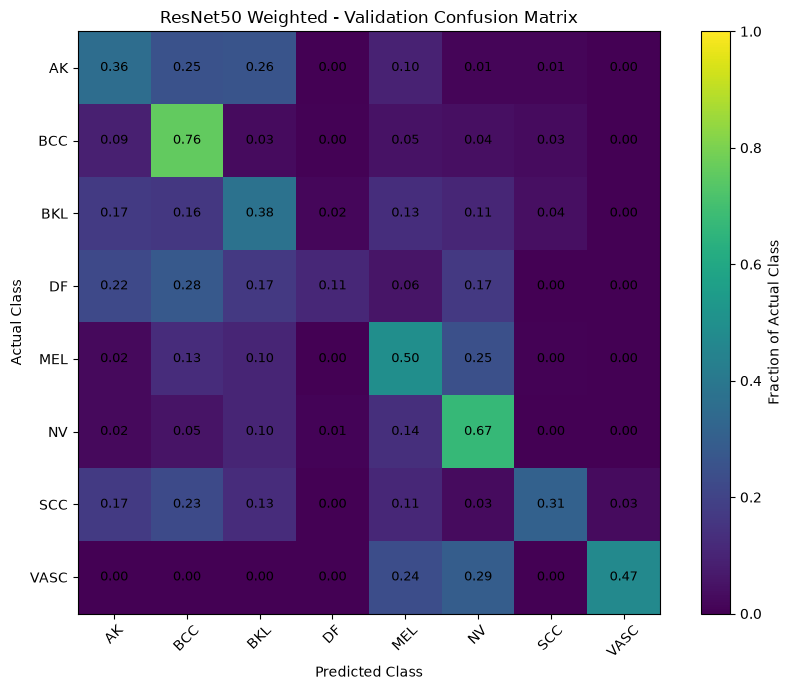

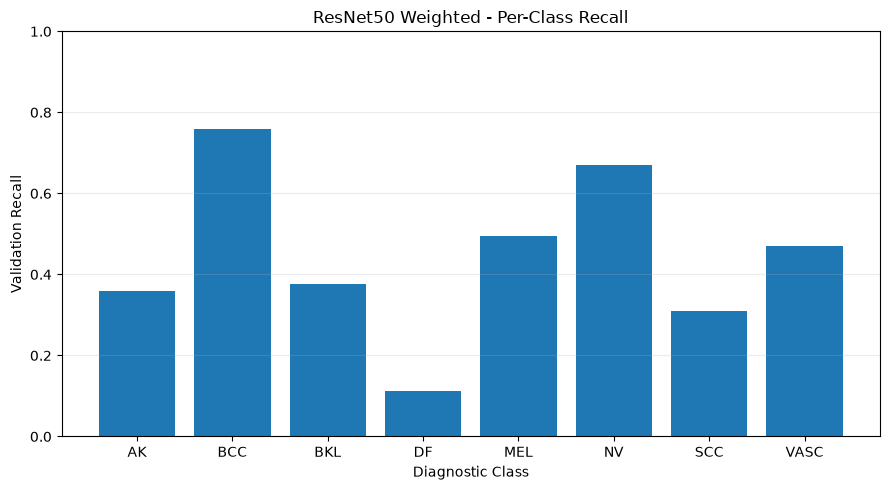

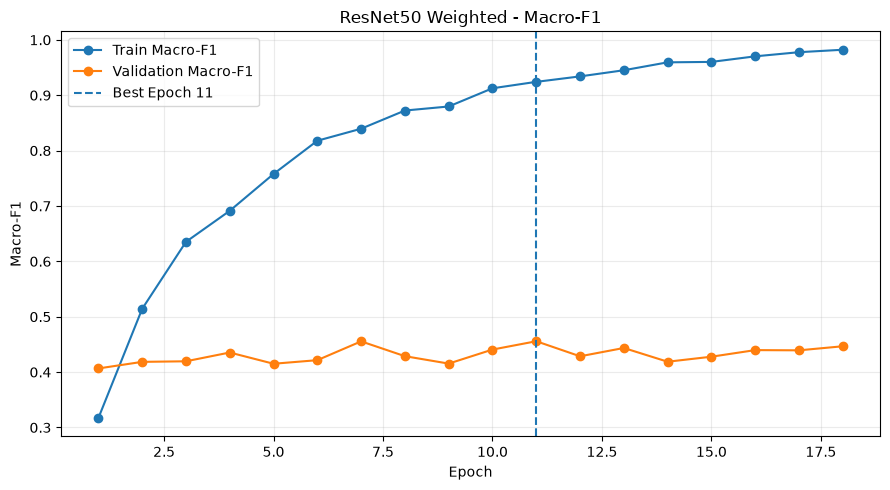

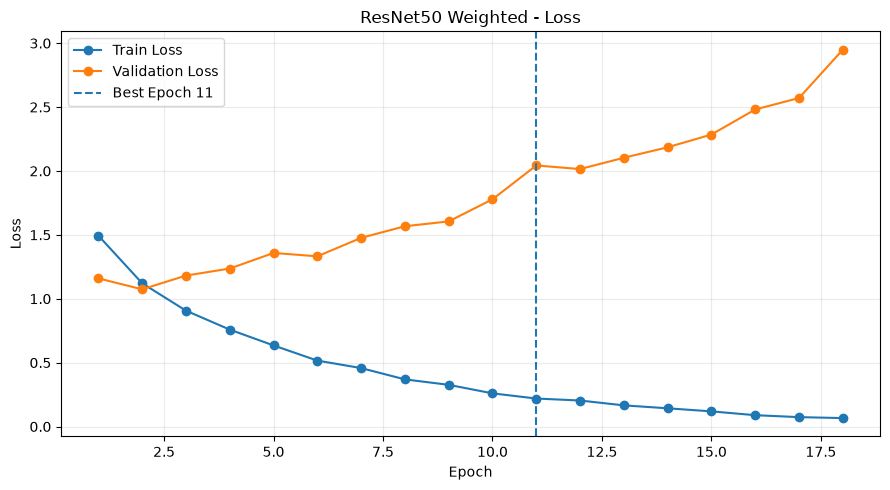


[14] PRELIMINARY A/B COMPARISON


,metric,experiment_a,experiment_b,b_minus_a
0,accuracy,0.612266,0.586923,-0.025342
1,macro_f1,0.449141,0.455754,0.006613
2,weighted_f1,0.609013,0.590531,-0.018482
3,balanced_accuracy,0.434139,0.444033,0.009893
4,loss,1.812137,2.043174,0.231037



EXPERIMENT B BEST CHECKPOINT AUDIT VERIFICATION
[PASS] Experiment B configuration exists
[PASS] Experiment B training report exists
[PASS] Experiment B best checkpoint exists
[PASS] Experiment B last checkpoint exists
[PASS] Experiment A audit exists
[PASS] Training manifest exists
[PASS] Validation manifest exists
[PASS] Configuration fingerprint valid
[PASS] Experiment B training PASS
[PASS] Experiment A audit PASS
[PASS] Completed 18 training epochs
[PASS] Best epoch is 11
[PASS] Outer-test not used
[PASS] Training history complete
[PASS] Best metric matches history
[PASS] Best checkpoint epoch correct
[PASS] Last checkpoint epoch correct
[PASS] Checkpoint experiment IDs valid
[PASS] Checkpoint signatures valid
[PASS] Checkpoint types valid
[PASS] Best checkpoint history correct
[PASS] Eight-class classifier verified
[PASS] 1973 validation images
[PASS] 247 validation batches
[PASS] 571 validation groups
[PASS] No train-validation group overlap
[PASS] Validation filenames unique
[P

In [104]:

# ============================================================
# BCN20000 - PHASE 04C - CELL 7
# EXPERIMENT B BEST CHECKPOINT AUDIT
# INDEPENDENT VALIDATION REPRODUCTION
# ============================================================

import json
import math
import hashlib
import gc
import time

from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision.models import resnet50
from tqdm.auto import tqdm
from IPython.display import display


print("=" * 78)
print("PHASE 04C - CELL 7")
print("EXPERIMENT B - BEST CHECKPOINT AUDIT")
print("=" * 78)


# ============================================================
# 1. PATHS
# ============================================================

B7_ROOT = Path.cwd()
B7_OUT = B7_ROOT / "outputs"

B7_ID = "resnet50_original_fold01_sqrt_weighted_ce_seed42"
A7_ID = "resnet50_original_fold01_unweighted_ce_seed42"

B7_CONFIG_PATH = (
    B7_OUT / "configs/full_training" / f"{B7_ID}.json"
)

B7_REPORT_PATH = (
    B7_OUT / "reports" / f"{B7_ID}_training_report.json"
)

B7_A_AUDIT_PATH = (
    B7_OUT / "reports" /
    f"{A7_ID}_best_checkpoint_audit.json"
)

B7_BEST_PATH = (
    B7_OUT / "checkpoints/full_training/resnet50/"
    "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
)

B7_LAST_PATH = (
    B7_OUT / "checkpoints/full_training/resnet50/"
    "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
)

B7_TRAIN_CSV = (
    B7_OUT / "splits/original_branch/fold_01_train.csv"
)

B7_VAL_CSV = (
    B7_OUT / "splits/original_branch/fold_01_validation.csv"
)

B7_PRED_PATH = (
    B7_OUT / "predictions/full_training" /
    f"{B7_ID}_validation_predictions.csv"
)

B7_CLASS_PATH = (
    B7_OUT / "reports" /
    f"{B7_ID}_per_class_metrics.csv"
)

B7_AUDIT_PATH = (
    B7_OUT / "reports" /
    f"{B7_ID}_best_checkpoint_audit.json"
)

B7_FIGURE_DIR = B7_OUT / "figures"

B7_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

B7_CHECKS = {}

B7_DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# 2. REQUIRED FILES
# ============================================================

print("\n[1] REQUIRED FILE VERIFICATION")

b7_required = {
    "Experiment B configuration": B7_CONFIG_PATH,
    "Experiment B training report": B7_REPORT_PATH,
    "Experiment B best checkpoint": B7_BEST_PATH,
    "Experiment B last checkpoint": B7_LAST_PATH,
    "Experiment A audit": B7_A_AUDIT_PATH,
    "Training manifest": B7_TRAIN_CSV,
    "Validation manifest": B7_VAL_CSV
}

for name, path in b7_required.items():

    B7_CHECKS[f"{name} exists"] = path.is_file()

    print(
        f"[{'PASS' if path.is_file() else 'FAIL'}] {name}"
    )

if not all(B7_CHECKS.values()):
    raise FileNotFoundError(
        "Required audit files missing."
    )

if not callable(globals().get("create_bcn_dataset")):
    raise RuntimeError(
        "create_bcn_dataset is not available."
    )

B7_PRED_PATH.parent.mkdir(parents=True, exist_ok=True)
B7_FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 3. LOAD CONFIGURATION AND REPORTS
# ============================================================

print("\n[2] TRAINING REPORT VERIFICATION")

def b7_read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


b7_config = b7_read_json(B7_CONFIG_PATH)
b7_report = b7_read_json(B7_REPORT_PATH)
b7_a_audit = b7_read_json(B7_A_AUDIT_PATH)

b7_unsigned = {
    key: value
    for key, value in b7_config.items()
    if key != "config_signature"
}

b7_signature = hashlib.sha256(
    json.dumps(
        b7_unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")
).hexdigest()

B7_CHECKS["Configuration fingerprint valid"] = (
    b7_signature == b7_config["config_signature"]
)

B7_CHECKS["Experiment B training PASS"] = (
    b7_report.get("status") == "PASS"
)

B7_CHECKS["Experiment A audit PASS"] = (
    b7_a_audit.get("status") == "PASS"
)

B7_CHECKS["Completed 18 training epochs"] = (
    b7_report.get("completed_epochs") == 18
)

B7_CHECKS["Best epoch is 11"] = (
    b7_report.get("best_epoch") == 11
)

B7_CHECKS["Outer-test not used"] = (
    b7_report.get("outer_test_evaluated") is False
    and b7_config.get("outer_test_for_tuning") is False
)

b7_history = b7_report["history"]

B7_CHECKS["Training history complete"] = (
    len(b7_history) == 18
    and [int(r["epoch"]) for r in b7_history]
    == list(range(1, 19))
)

b7_best_row = next(
    row for row in b7_history
    if int(row["epoch"]) == 11
)

B7_CHECKS["Best metric matches history"] = (
    math.isclose(
        float(b7_report["best_validation_macro_f1"]),
        float(b7_best_row["validation_macro_f1"]),
        abs_tol=1e-12,
        rel_tol=0
    )
)

if not all(B7_CHECKS.values()):
    raise RuntimeError(
        "Training report verification failed."
    )

print("Training status:", b7_report["status"])
print("Completed epochs:", len(b7_history))
print("Best epoch:", b7_report["best_epoch"])
print(
    "Best logged validation Macro-F1:",
    b7_best_row["validation_macro_f1"]
)


# ============================================================
# 4. CHECKPOINT VERIFICATION
# ============================================================

print("\n[3] CHECKPOINT INTEGRITY")

b7_best_state = torch.load(
    B7_BEST_PATH,
    map_location="cpu",
    weights_only=True
)

b7_last_state = torch.load(
    B7_LAST_PATH,
    map_location="cpu",
    weights_only=True
)

B7_CHECKS["Best checkpoint epoch correct"] = (
    b7_best_state["completed_epoch"] == 11
)

B7_CHECKS["Last checkpoint epoch correct"] = (
    b7_last_state["completed_epoch"] == 18
)

B7_CHECKS["Checkpoint experiment IDs valid"] = (
    b7_best_state.get("experiment_id") == B7_ID
    and b7_last_state.get("experiment_id") == B7_ID
)

B7_CHECKS["Checkpoint signatures valid"] = (
    b7_best_state["configuration_signature"] == b7_signature
    and b7_last_state["configuration_signature"] == b7_signature
)

B7_CHECKS["Checkpoint types valid"] = (
    b7_best_state["checkpoint_kind"] == "full_training_best"
    and b7_last_state["checkpoint_kind"] == "full_training_last"
)

B7_CHECKS["Best checkpoint history correct"] = (
    len(b7_best_state["history"]) == 11
    and b7_best_state["best_epoch"] == 11
)

B7_CHECKS["Eight-class classifier verified"] = (
    tuple(
        b7_best_state["model_state_dict"]["fc.weight"].shape
    ) == (8, 2048)
)

if not all(B7_CHECKS.values()):
    raise RuntimeError(
        "Checkpoint integrity verification failed."
    )

print("Best checkpoint: Epoch 11")
print("Last checkpoint: Epoch 18")
print("Signatures: VERIFIED")

del b7_last_state


# ============================================================
# 5. DATASET VERIFICATION
# ============================================================

print("\n[4] DATASET VERIFICATION")

b7_train_manifest = pd.read_csv(
    B7_TRAIN_CSV,
    dtype={
        "bcn_filename": "string",
        "diagnosis": "string",
        "leakage_group_id": "string"
    }
)

b7_val_manifest = pd.read_csv(
    B7_VAL_CSV,
    dtype={
        "bcn_filename": "string",
        "diagnosis": "string",
        "leakage_group_id": "string"
    }
)

b7_dataset = create_bcn_dataset(
    "original", 1, "validation"
)

b7_loader = DataLoader(
    b7_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=(B7_DEVICE.type == "cuda"),
    drop_last=False
)

B7_CHECKS["1973 validation images"] = (
    len(b7_dataset) == 1973
    and len(b7_val_manifest) == 1973
)

B7_CHECKS["247 validation batches"] = (
    len(b7_loader) == 247
)

B7_CHECKS["571 validation groups"] = (
    b7_val_manifest["leakage_group_id"].nunique() == 571
)

B7_CHECKS["No train-validation group overlap"] = (
    set(b7_train_manifest["leakage_group_id"])
    .isdisjoint(
        set(b7_val_manifest["leakage_group_id"])
    )
)

B7_CHECKS["Validation filenames unique"] = (
    b7_val_manifest["bcn_filename"].is_unique
)

if not all(B7_CHECKS.values()):
    raise RuntimeError("Dataset integrity check failed.")

print("Validation images:", len(b7_dataset))
print("Validation batches:", len(b7_loader))
print("Validation groups: 571")
print("Train-validation group overlap: 0")


# ============================================================
# 6. LOAD BEST MODEL
# ============================================================

print("\n[5] LOADING BEST MODEL")

b7_model = resnet50(weights=None)
b7_model.fc = nn.Linear(2048, 8)

b7_model.load_state_dict(
    b7_best_state["model_state_dict"],
    strict=True
)

del b7_best_state

b7_model = b7_model.to(B7_DEVICE)
b7_model.eval()

print("Model: ResNet50")
print("Checkpoint: Epoch 11")
print("Mode: EVALUATION")
print("Training: DISABLED")


# ============================================================
# 7. INDEPENDENT VALIDATION INFERENCE
# ============================================================

print("\n[6] INDEPENDENT VALIDATION EVALUATION")

b7_true = []
b7_pred = []
b7_names = []
b7_groups = []
b7_probs = []

b7_total_loss = 0.0
b7_total_samples = 0

b7_amp = (
    B7_DEVICE.type == "cuda"
    and bool(b7_config["mixed_precision"])
)

b7_start = time.perf_counter()

with torch.inference_mode():

    for batch in tqdm(
        b7_loader,
        desc="Experiment B best checkpoint audit"
    ):

        images = batch["image"].to(
            B7_DEVICE,
            non_blocking=True
        )

        labels = batch["label"].to(
            B7_DEVICE,
            non_blocking=True
        )

        with torch.autocast(
            device_type=B7_DEVICE.type,
            dtype=torch.float16,
            enabled=b7_amp
        ):
            logits = b7_model(images)

        logits_fp32 = logits.float()

        loss = F.cross_entropy(
            logits_fp32,
            labels,
            reduction="mean"
        )

        if (
            not bool(torch.isfinite(logits).all().item())
            or not bool(torch.isfinite(loss).item())
        ):
            raise FloatingPointError(
                "Non-finite validation output."
            )

        probabilities = torch.softmax(
            logits_fp32,
            dim=1
        )

        predictions = logits.argmax(dim=1)

        count = int(labels.size(0))

        b7_total_loss += float(loss.item()) * count
        b7_total_samples += count

        b7_true.extend(labels.cpu().tolist())
        b7_pred.extend(predictions.cpu().tolist())

        b7_names.extend(list(batch["filename"]))

        b7_groups.extend(
            str(value)
            for value in batch["leakage_group_id"]
        )

        b7_probs.append(
            probabilities.cpu().numpy()
        )

b7_elapsed = time.perf_counter() - b7_start

b7_prob_matrix = np.concatenate(b7_probs, axis=0)

b7_true = np.asarray(b7_true, dtype=np.int64)
b7_pred = np.asarray(b7_pred, dtype=np.int64)

B7_CHECKS["1973 predictions generated"] = (
    b7_total_samples == 1973
    and len(b7_true) == 1973
)

B7_CHECKS["Probabilities finite"] = bool(
    np.isfinite(b7_prob_matrix).all()
)

B7_CHECKS["Probabilities sum to one"] = bool(
    np.allclose(
        b7_prob_matrix.sum(axis=1),
        1,
        atol=1e-5
    )
)

B7_CHECKS["Predictions match probability argmax"] = bool(
    np.array_equal(
        b7_pred,
        b7_prob_matrix.argmax(axis=1)
    )
)

print("Images evaluated:", b7_total_samples)
print("Inference seconds:", round(b7_elapsed, 2))


# ============================================================
# 8. INDEPENDENT CLASSIFICATION METRICS
# ============================================================

print("\n[7] RECOMPUTED VALIDATION METRICS")

def b7_calculate_metrics(y_true, y_pred):

    cm = np.zeros((8, 8), dtype=np.int64)

    np.add.at(
        cm,
        (y_true, y_pred),
        1
    )

    tp = np.diag(cm).astype(np.float64)
    support = cm.sum(axis=1).astype(np.float64)
    predicted_count = cm.sum(axis=0).astype(np.float64)

    precision = np.divide(
        tp,
        predicted_count,
        out=np.zeros(8),
        where=predicted_count > 0
    )

    recall = np.divide(
        tp,
        support,
        out=np.zeros(8),
        where=support > 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(8),
        where=(precision + recall) > 0
    )

    n = len(y_true)

    return {
        "accuracy": float(tp.sum() / n),
        "macro_f1": float(f1.mean()),
        "weighted_f1": float(
            np.dot(f1, support) / n
        ),
        "balanced_accuracy": float(
            recall[support > 0].mean()
        ),
        "confusion_matrix": cm.tolist(),
        "precision": precision.tolist(),
        "recall": recall.tolist(),
        "f1": f1.tolist(),
        "support": support.astype(int).tolist(),
        "predicted_count": (
            predicted_count.astype(int).tolist()
        )
    }


b7_metrics = b7_calculate_metrics(
    b7_true,
    b7_pred
)

b7_metrics["loss"] = float(
    b7_total_loss / b7_total_samples
)

b7_compare = {
    "accuracy": "validation_accuracy",
    "macro_f1": "validation_macro_f1",
    "weighted_f1": "validation_weighted_f1",
    "balanced_accuracy": "validation_balanced_accuracy",
    "loss": "validation_loss"
}

for metric, logged_key in b7_compare.items():

    logged = float(b7_best_row[logged_key])
    reproduced = float(b7_metrics[metric])

    difference = abs(logged - reproduced)

    tolerance = 1e-3 if metric == "loss" else 1e-5

    passed = difference <= tolerance

    B7_CHECKS[f"Reproduced {metric}"] = passed

    print(
        f"{metric:19s} | "
        f"Logged: {logged:.6f} | "
        f"Recomputed: {reproduced:.6f} | "
        f"Difference: {difference:.9f} | "
        f"{'PASS' if passed else 'FAIL'}"
    )

b7_cm = np.asarray(
    b7_metrics["confusion_matrix"],
    dtype=np.int64
)

B7_CHECKS["Confusion matrix matches epoch 11"] = (
    np.array_equal(
        b7_cm,
        np.asarray(
            b7_best_row["validation_confusion_matrix"]
        )
    )
)

B7_CHECKS["Confusion matrix sample count valid"] = (
    int(b7_cm.sum()) == 1973
)


# ============================================================
# 9. METADATA VERIFICATION
# ============================================================

print("\n[8] VALIDATION METADATA VERIFICATION")

b7_prediction_df = pd.DataFrame({
    "filename": b7_names,
    "leakage_group_id": b7_groups,
    "actual_idx": b7_true,
    "predicted_idx": b7_pred,
    "actual_class": [
        B7_CLASSES[i] for i in b7_true
    ],
    "predicted_class": [
        B7_CLASSES[i] for i in b7_pred
    ],
    "confidence": b7_prob_matrix.max(axis=1)
})

b7_prob_cols = []

for idx, name in enumerate(B7_CLASSES):
    column = f"prob_{name}"
    b7_prob_cols.append(column)
    b7_prediction_df[column] = b7_prob_matrix[:, idx]

b7_manifest_reference = (
    b7_val_manifest[
        ["bcn_filename", "diagnosis", "leakage_group_id"]
    ]
    .rename(columns={
        "bcn_filename": "filename",
        "diagnosis": "manifest_diagnosis",
        "leakage_group_id": "manifest_group"
    })
)

b7_aligned = b7_prediction_df.merge(
    b7_manifest_reference,
    on="filename",
    how="left",
    validate="one_to_one",
    indicator=True
)

B7_CHECKS["Prediction filenames unique"] = (
    b7_prediction_df["filename"].is_unique
)

B7_CHECKS["All filenames match manifest"] = (
    b7_aligned["_merge"].eq("both").all()
    and len(b7_aligned) == 1973
)

B7_CHECKS["True labels match manifest"] = (
    (
        b7_aligned["actual_class"].astype(str)
        == b7_aligned["manifest_diagnosis"].astype(str)
    ).all()
)

B7_CHECKS["Leakage groups match manifest"] = (
    (
        b7_aligned["leakage_group_id"].astype(str)
        == b7_aligned["manifest_group"].astype(str)
    ).all()
)

print("Prediction-to-manifest alignment verified.")


# ============================================================
# 10. CLASS-WISE VALIDATION PERFORMANCE
# ============================================================

print("\n[9] EPOCH 11 CLASS-WISE METRICS")

b7_top3 = np.argsort(
    -b7_prob_matrix,
    axis=1
)[:, :3]

b7_class_rows = []

for index, name in enumerate(B7_CLASSES):

    mask = b7_true == index
    support = int(mask.sum())

    top3_correct = np.any(
        b7_top3[mask] == index,
        axis=1
    )

    b7_class_rows.append({
        "class": name,
        "validation_support": support,
        "predicted_count": int(
            b7_metrics["predicted_count"][index]
        ),
        "precision": float(
            b7_metrics["precision"][index]
        ),
        "recall": float(
            b7_metrics["recall"][index]
        ),
        "f1": float(
            b7_metrics["f1"][index]
        ),
        "top3_accuracy": (
            float(top3_correct.mean())
            if support > 0 else 0.0
        )
    })

b7_class_df = pd.DataFrame(b7_class_rows)

display(b7_class_df.round(6))

B7_CHECKS["Eight diagnostic classes evaluated"] = (
    len(b7_class_df) == 8
)

B7_CHECKS["Class supports sum to 1973"] = (
    b7_class_df["validation_support"].sum() == 1973
)

B7_CHECKS["Prediction counts sum to 1973"] = (
    b7_class_df["predicted_count"].sum() == 1973
)

b7_zero_recall = b7_class_df.loc[
    b7_class_df["recall"] == 0,
    "class"
].tolist()

print("Zero-recall classes:", b7_zero_recall)

print("\nPriority-class recall:")

for name in ["DF", "VASC", "SCC", "MEL"]:
    row = b7_class_df.set_index("class").loc[name]
    print(
        f"{name}: {row['recall']:.6f} "
        f"({int(round(row['recall'] * row['validation_support']))}"
        f"/{int(row['validation_support'])})"
    )


# ============================================================
# 11. GROUP-LEVEL EXPLORATORY EVALUATION
# ============================================================

print("\n[10] GROUP-LEVEL EXPLORATORY METRICS")

b7_label_counts = b7_prediction_df.groupby(
    "leakage_group_id"
)["actual_idx"].nunique()

B7_CHECKS["Group labels consistent"] = (
    bool((b7_label_counts == 1).all())
)

b7_group_metrics = None

if B7_CHECKS["Group labels consistent"]:

    group_probs = b7_prediction_df.groupby(
        "leakage_group_id"
    )[b7_prob_cols].mean()

    group_true = b7_prediction_df.groupby(
        "leakage_group_id"
    )["actual_idx"].first()

    group_pred = np.argmax(
        group_probs.to_numpy(),
        axis=1
    )

    b7_group_metrics = b7_calculate_metrics(
        group_true.to_numpy(dtype=np.int64),
        group_pred
    )

    B7_CHECKS["571 validation groups evaluated"] = (
        len(group_true) == 571
    )

    print("Groups:", len(group_true))
    print(
        "Group Macro-F1:",
        round(b7_group_metrics["macro_f1"], 6)
    )


# ============================================================
# 12. MOST COMMON MISCLASSIFICATIONS
# ============================================================

print("\n[11] TOP MISCLASSIFICATIONS")

b7_errors = []

for actual in range(8):
    for predicted in range(8):

        if actual == predicted:
            continue

        count = int(b7_cm[actual, predicted])

        if count > 0:
            b7_errors.append({
                "actual_class": B7_CLASSES[actual],
                "predicted_class": B7_CLASSES[predicted],
                "error_count": count
            })

b7_error_df = pd.DataFrame(b7_errors)

if len(b7_error_df):
    b7_error_df = b7_error_df.sort_values(
        "error_count",
        ascending=False
    )

    display(b7_error_df.head(12))


# ============================================================
# 13. SAVE PREDICTIONS AND CLASS METRICS
# ============================================================

print("\n[12] SAVING AUDIT FILES")

b7_prediction_df.to_csv(
    B7_PRED_PATH, index=False
)

b7_class_df.to_csv(
    B7_CLASS_PATH, index=False
)

B7_CHECKS["Prediction CSV saved"] = (
    B7_PRED_PATH.is_file()
)

B7_CHECKS["Class metrics CSV saved"] = (
    B7_CLASS_PATH.is_file()
)


# ============================================================
# 14. VISUALIZATION
# ============================================================

print("\n[13] GENERATING FIGURES")

b7_figures = []

# Confusion matrix (normalized by true class)

b7_row_totals = b7_cm.sum(axis=1, keepdims=True)

b7_normalized_cm = np.divide(
    b7_cm,
    b7_row_totals,
    out=np.zeros((8, 8), dtype=float),
    where=b7_row_totals > 0
)

confusion_fig = (
    B7_FIGURE_DIR /
    "resnet50_weighted_fold01_confusion_matrix.png"
)

plt.figure(figsize=(9, 7))
plt.imshow(b7_normalized_cm, vmin=0, vmax=1)
plt.colorbar(label="Fraction of Actual Class")

plt.xticks(range(8), B7_CLASSES, rotation=45)
plt.yticks(range(8), B7_CLASSES)

for i in range(8):
    for j in range(8):
        plt.text(
            j, i,
            f"{b7_normalized_cm[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("ResNet50 Weighted - Validation Confusion Matrix")
plt.tight_layout()
plt.savefig(confusion_fig, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

b7_figures.append(str(confusion_fig))


# Per-class recall

recall_fig = (
    B7_FIGURE_DIR /
    "resnet50_weighted_fold01_class_recall.png"
)

plt.figure(figsize=(9, 5))
plt.bar(
    b7_class_df["class"],
    b7_class_df["recall"]
)

plt.ylim(0, 1)
plt.xlabel("Diagnostic Class")
plt.ylabel("Validation Recall")
plt.title("ResNet50 Weighted - Per-Class Recall")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(recall_fig, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

b7_figures.append(str(recall_fig))


# Training curves

b7_history_df = pd.DataFrame(b7_history)

for metric, filename, ylabel in [
    (
        "macro_f1",
        "resnet50_weighted_fold01_macro_f1.png",
        "Macro-F1"
    ),
    (
        "loss",
        "resnet50_weighted_fold01_loss.png",
        "Loss"
    )
]:

    fig_path = B7_FIGURE_DIR / filename

    plt.figure(figsize=(9, 5))

    plt.plot(
        b7_history_df["epoch"],
        b7_history_df[f"train_{metric}"],
        marker="o",
        label=f"Train {ylabel}"
    )

    plt.plot(
        b7_history_df["epoch"],
        b7_history_df[f"validation_{metric}"],
        marker="o",
        label=f"Validation {ylabel}"
    )

    plt.axvline(
        11,
        linestyle="--",
        label="Best Epoch 11"
    )

    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(f"ResNet50 Weighted - {ylabel}")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    b7_figures.append(str(fig_path))

B7_CHECKS["All four figures saved"] = (
    len(b7_figures) == 4
    and all(Path(p).is_file() for p in b7_figures)
)


# ============================================================
# 15. PRELIMINARY A/B COMPARISON
# ============================================================

print("\n[14] PRELIMINARY A/B COMPARISON")

b7_a_metrics = (
    b7_a_audit["results"]["validation_metrics"]
)

b7_comparison_rows = []

for metric in [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy",
    "loss"
]:

    a_value = float(b7_a_metrics[metric])
    b_value = float(b7_metrics[metric])

    b7_comparison_rows.append({
        "metric": metric,
        "experiment_a": a_value,
        "experiment_b": b_value,
        "b_minus_a": b_value - a_value
    })

b7_comparison_df = pd.DataFrame(
    b7_comparison_rows
)

display(b7_comparison_df.round(6))


# ============================================================
# 16. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("EXPERIMENT B BEST CHECKPOINT AUDIT VERIFICATION")
print("=" * 78)

for name, passed in B7_CHECKS.items():
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

B7_STATUS = (
    "PASS"
    if B7_CHECKS and all(B7_CHECKS.values())
    else "BLOCKED"
)


# ============================================================
# 17. SAVE FINAL AUDIT REPORT
# ============================================================

b7_audit_report = {
    "stage": "EXPERIMENT_B_BEST_CHECKPOINT_AUDIT",
    "status": B7_STATUS,
    "experiment_id": B7_ID,
    "model": "resnet50",
    "branch": "original",
    "fold": 1,
    "best_epoch": 11,
    "completed_training_epochs": 18,
    "evaluation_partition": "validation",
    "training_performed": False,
    "outer_test_evaluated": False,
    "validation_metrics": b7_metrics,
    "per_class_metrics": b7_class_rows,
    "zero_recall_classes": b7_zero_recall,
    "group_metrics": b7_group_metrics,
    "comparison_with_experiment_a": (
        b7_comparison_rows
    ),
    "figures": b7_figures,
    "prediction_csv": str(B7_PRED_PATH),
    "per_class_csv": str(B7_CLASS_PATH),
    "checks": {
        key: bool(value)
        for key, value in B7_CHECKS.items()
    }
}

with open(
    B7_AUDIT_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        b7_audit_report,
        f,
        indent=4,
        ensure_ascii=False,
        allow_nan=False
    )


# ============================================================
# 18. CLEAN UP GPU
# ============================================================

del b7_model
gc.collect()

if B7_DEVICE.type == "cuda":
    torch.cuda.empty_cache()


# ============================================================
# 19. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("EXPERIMENT B BEST CHECKPOINT AUDIT SUMMARY")
print("=" * 78)

print("Status:", B7_STATUS)
print("Best checkpoint epoch: 11")
print("Validation images:", b7_total_samples)

print(
    "Reproduced Macro-F1:",
    round(b7_metrics["macro_f1"], 6)
)

print(
    "Reproduced Accuracy:",
    round(b7_metrics["accuracy"], 6)
)

print(
    "Reproduced Balanced Accuracy:",
    round(b7_metrics["balanced_accuracy"], 6)
)

print("\nPer-class report:")
print(B7_CLASS_PATH)

print("\nAudit report:")
print(B7_AUDIT_PATH)

if B7_STATUS == "PASS":
    print("\nEXPERIMENT B BEST CHECKPOINT AUDIT: PASS")
    print("NEXT: FINAL A/B ANALYSIS AND DENSENET121 PREPARATION")
else:
    print("\nAUDIT BLOCKED - REVIEW FAILED CHECKS")

print("=" * 78)


In [105]:

# PHASE 04C - CELL 7 FINAL STATUS CHECK

import json
from pathlib import Path

report_path = Path(
    "outputs/reports/"
    "resnet50_original_fold01_"
    "sqrt_weighted_ce_seed42_"
    "best_checkpoint_audit.json"
)

print("=" * 65)
print("EXPERIMENT B - FINAL AUDIT STATUS CHECK")
print("=" * 65)

if not report_path.is_file():
    print("STATUS: AUDIT REPORT NOT FOUND")
    print("Phase 04C - Cell 7 complete korte hobe.")

else:
    with open(report_path, "r", encoding="utf-8") as f:
        report = json.load(f)

    print("Status:", report.get("status"))
    print("Best epoch:", report.get("best_epoch"))

    metrics = report.get("validation_metrics", {})

    print("Validation accuracy:", metrics.get("accuracy"))
    print("Validation Macro-F1:", metrics.get("macro_f1"))
    print(
        "Validation balanced accuracy:",
        metrics.get("balanced_accuracy")
    )

    checks = report.get("checks", {})

    print("\nVerification checks:", len(checks))

    failed = [
        name for name, passed in checks.items()
        if not passed
    ]

    print("Failed checks:", failed)

    print("\nFINAL RESULT:")

    if report.get("status") == "PASS" and not failed:
        print("EXPERIMENT B BEST CHECKPOINT AUDIT: PASS")
    else:
        print("EXPERIMENT B AUDIT: REVIEW REQUIRED")

print("=" * 65)


EXPERIMENT B - FINAL AUDIT STATUS CHECK
Status: PASS
Best epoch: 11
Validation accuracy: 0.5869234668018246
Validation Macro-F1: 0.45575408538093687
Validation balanced accuracy: 0.44403269239427656

Verification checks: 50
Failed checks: []

FINAL RESULT:
EXPERIMENT B BEST CHECKPOINT AUDIT: PASS


PHASE 04C - CELL 8
RESNET50 FINAL A/B DEVELOPMENT COMPARISON

[1] ARTIFACT VERIFICATION
[PASS] Experiment A: all files available
[PASS] Experiment B: all files available

[2] EXPERIMENT INTEGRITY
[PASS] A: config fingerprint valid
[PASS] A: training PASS
[PASS] A: audit PASS
[PASS] A: all audit checks PASS
[PASS] A: 18 completed epochs
[PASS] A: best epoch 11
[PASS] A: outer-test protected
[PASS] B: config fingerprint valid
[PASS] B: training PASS
[PASS] B: audit PASS
[PASS] B: all audit checks PASS
[PASS] B: 18 completed epochs
[PASS] B: best epoch 11
[PASS] B: outer-test protected
[PASS] Common experimental settings match
[PASS] Independent checkpoint locations
[PASS] Original branch, Fold 1

[3] PAIRED PREDICTION VERIFICATION
[PASS] Prediction columns available
[PASS] Both contain 1973 predictions
[PASS] Prediction filenames unique
[PASS] Identical validation filename set
[PASS] Ground-truth labels identical
[PASS] Leakage group IDs identical
[PASS] 571 validation groups

[4] METRIC

,metric,experiment_a,experiment_b,b_minus_a
0,accuracy,0.612266,0.586923,-0.025342
1,macro_f1,0.449141,0.455754,0.006613
2,weighted_f1,0.609013,0.590531,-0.018482
3,balanced_accuracy,0.434139,0.444033,0.009893
4,loss,1.812137,2.043174,0.231037



[6] CLASS-WISE PERFORMANCE COMPARISON


,class,support,a_precision,b_precision,a_recall,b_recall,recall_change_pp,a_f1,b_f1,f1_change
0,AK,134,0.333333,0.300000,0.305970,0.358209,5.223881,0.319066,0.326531,0.007464
1,BCC,458,0.693582,0.667946,0.731441,0.759825,2.838428,0.712009,0.710930,-0.001079
2,BKL,178,0.340000,0.276860,0.382022,0.376404,-0.561798,0.359788,0.319048,-0.040741
3,DF,18,0.111111,0.153846,0.055556,0.111111,5.555556,0.074074,0.129032,0.054958
4,MEL,416,0.543326,0.556757,0.557692,0.495192,-6.250000,0.550415,0.524173,-0.026242
5,NV,681,0.751111,0.750411,0.744493,0.671072,-7.342144,0.747788,0.708527,-0.039260
6,SCC,71,0.363636,0.478261,0.225352,0.309859,8.450704,0.278261,0.376068,0.097808
7,VASC,17,0.666667,0.666667,0.470588,0.470588,0.000000,0.551724,0.551724,0.000000


[PASS] Eight classes compared
[PASS] Validation class supports preserved

[7] PAIRED PREDICTION ANALYSIS
[PASS] Paired correctness totals 1973
both_correct: 983
a_only_correct: 225
b_only_correct: 175
both_wrong: 590

[8] DEVELOPMENT SELECTION
Selection metric: Validation Macro-F1
Selected experiment: B
Macro-F1 difference (B - A): 0.006613
Selection scope: ORIGINAL BRANCH, FOLD 1 DEVELOPMENT
NOT a final outer-test or five-fold model ranking.


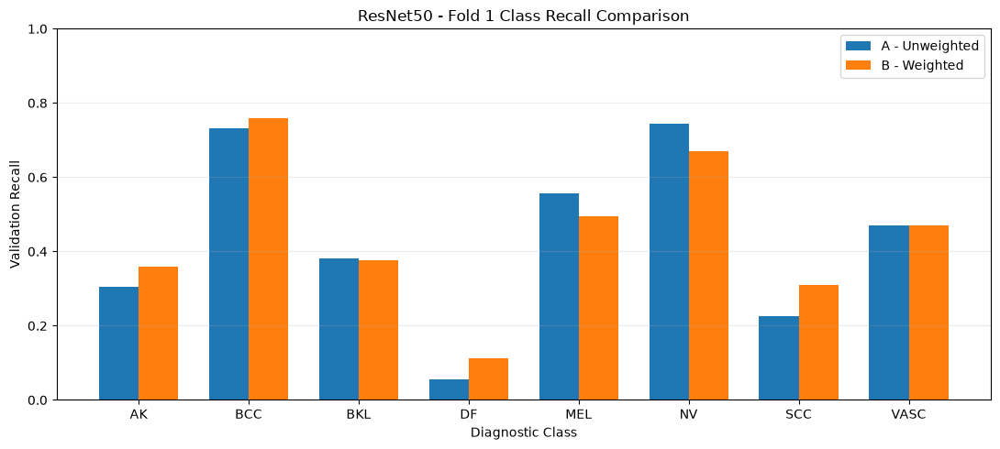

[PASS] All comparison outputs created
[PASS] Both best checkpoints preserved

RESNET50 FINAL DEVELOPMENT VERIFICATION
[PASS] Experiment A: all files available
[PASS] Experiment B: all files available
[PASS] A: config fingerprint valid
[PASS] A: training PASS
[PASS] A: audit PASS
[PASS] A: all audit checks PASS
[PASS] A: 18 completed epochs
[PASS] A: best epoch 11
[PASS] A: outer-test protected
[PASS] B: config fingerprint valid
[PASS] B: training PASS
[PASS] B: audit PASS
[PASS] B: all audit checks PASS
[PASS] B: 18 completed epochs
[PASS] B: best epoch 11
[PASS] B: outer-test protected
[PASS] Common experimental settings match
[PASS] Independent checkpoint locations
[PASS] Original branch, Fold 1
[PASS] Prediction columns available
[PASS] Both contain 1973 predictions
[PASS] Prediction filenames unique
[PASS] Identical validation filename set
[PASS] Ground-truth labels identical
[PASS] Leakage group IDs identical
[PASS] 571 validation groups
[PASS] A: confusion matrix reproduced
[PASS

In [106]:

# ============================================================
# BCN20000 - PHASE 04C - CELL 8
# RESNET50 A/B FINAL DEVELOPMENT COMPARISON
# ============================================================

import os
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

print("=" * 78)
print("PHASE 04C - CELL 8")
print("RESNET50 FINAL A/B DEVELOPMENT COMPARISON")
print("=" * 78)

ROOT8 = Path.cwd()
OUT8 = ROOT8 / "outputs"

A8 = "resnet50_original_fold01_unweighted_ce_seed42"
B8 = "resnet50_original_fold01_sqrt_weighted_ce_seed42"

CLASSES8 = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

CHECKS8 = {}

def read_json8(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def sha256_file8(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024), b""
        ):
            digest.update(chunk)
    return digest.hexdigest()

def signature8(config):
    unsigned = {
        k: v for k, v in config.items()
        if k != "config_signature"
    }
    return hashlib.sha256(
        json.dumps(
            unsigned,
            sort_keys=True,
            separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest()

def check8(name, condition):
    CHECKS8[name] = bool(condition)
    print(
        f"[{'PASS' if condition else 'FAIL'}] {name}"
    )

def metrics_from_predictions8(actual, predicted):
    cm = np.zeros((8, 8), dtype=np.int64)
    np.add.at(cm, (actual, predicted), 1)

    tp = np.diag(cm).astype(float)
    support = cm.sum(axis=1).astype(float)
    pred_count = cm.sum(axis=0).astype(float)

    precision = np.divide(
        tp, pred_count,
        out=np.zeros(8), where=pred_count > 0
    )

    recall = np.divide(
        tp, support,
        out=np.zeros(8), where=support > 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(8),
        where=(precision + recall) > 0
    )

    return {
        "accuracy": float(tp.sum() / len(actual)),
        "macro_f1": float(f1.mean()),
        "weighted_f1": float(
            np.dot(f1, support) / len(actual)
        ),
        "balanced_accuracy": float(
            recall[support > 0].mean()
        ),
        "confusion_matrix": cm,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "support": support
    }


# ============================================================
# 1. LOAD EXPERIMENT ARTIFACTS
# ============================================================

print("\n[1] ARTIFACT VERIFICATION")

DATA8 = {}

for short, exp_id, loss_name in [
    ("A", A8, "Unweighted CE"),
    ("B", B8, "Square-root Weighted CE")
]:

    config_path = (
        OUT8 / "configs/full_training"
        / f"{exp_id}.json"
    )

    training_path = (
        OUT8 / "reports"
        / f"{exp_id}_training_report.json"
    )

    audit_path = (
        OUT8 / "reports"
        / f"{exp_id}_best_checkpoint_audit.json"
    )

    prediction_path = (
        OUT8 / "predictions/full_training"
        / f"{exp_id}_validation_predictions.csv"
    )

    class_path = (
        OUT8 / "reports"
        / f"{exp_id}_per_class_metrics.csv"
    )

    checkpoint_path = (
        Path(
            OUT8 / "checkpoints/full_training"
            / "resnet50/original/fold_01"
        )
        / (
            "unweighted_ce"
            if short == "A"
            else "sqrt_weighted_ce"
        )
        / "best_checkpoint.pt"
    )

    paths = [
        config_path,
        training_path,
        audit_path,
        prediction_path,
        class_path,
        checkpoint_path
    ]

    check8(
        f"Experiment {short}: all files available",
        all(path.is_file() for path in paths)
    )

    if not all(path.is_file() for path in paths):
        raise FileNotFoundError(
            f"Experiment {short} artifacts missing."
        )

    DATA8[short] = {
        "id": exp_id,
        "loss_name": loss_name,
        "config": read_json8(config_path),
        "training": read_json8(training_path),
        "audit": read_json8(audit_path),
        "predictions": pd.read_csv(
            prediction_path,
            dtype={
                "filename": "string",
                "leakage_group_id": "string"
            }
        ),
        "classes": pd.read_csv(class_path),
        "checkpoint_hash": sha256_file8(
            checkpoint_path
        ),
        "checkpoint_path": str(checkpoint_path)
    }


# ============================================================
# 2. VALIDATE BOTH COMPLETED EXPERIMENTS
# ============================================================

print("\n[2] EXPERIMENT INTEGRITY")

for short in ["A", "B"]:

    data = DATA8[short]

    config = data["config"]
    training = data["training"]
    audit = data["audit"]

    check8(
        f"{short}: config fingerprint valid",
        signature8(config)
        == config["config_signature"]
    )

    check8(
        f"{short}: training PASS",
        training.get("status") == "PASS"
    )

    check8(
        f"{short}: audit PASS",
        audit.get("status") == "PASS"
    )

    check8(
        f"{short}: all audit checks PASS",
        bool(audit.get("checks"))
        and all(audit["checks"].values())
    )

    check8(
        f"{short}: 18 completed epochs",
        training.get("completed_epochs") == 18
        and len(training.get("history", [])) == 18
    )

    check8(
        f"{short}: best epoch 11",
        training.get("best_epoch") == 11
    )

    check8(
        f"{short}: outer-test protected",
        training.get("outer_test_evaluated") is False
        and config.get("outer_test_for_tuning") is False
    )

config_a8 = DATA8["A"]["config"]
config_b8 = DATA8["B"]["config"]

shared8 = [
    "model", "branch", "fold", "seed",
    "num_classes", "train_images",
    "validation_images", "max_epochs",
    "early_stopping_patience",
    "early_stopping_min_delta",
    "batch_size", "gradient_accumulation_steps",
    "optimizer", "initial_learning_rate",
    "weight_decay", "scheduler",
    "scheduler_t_max", "scheduler_eta_min",
    "checkpoint_selection_metric"
]

check8(
    "Common experimental settings match",
    all(
        config_a8.get(key) == config_b8.get(key)
        for key in shared8
    )
)

check8(
    "Independent checkpoint locations",
    config_a8["checkpoint_directory"]
    != config_b8["checkpoint_directory"]
)

check8(
    "Original branch, Fold 1",
    config_a8["branch"] == "original"
    and config_b8["branch"] == "original"
    and config_a8["fold"] == config_b8["fold"] == 1
)


# ============================================================
# 3. PAIRED VALIDATION ALIGNMENT
# ============================================================

print("\n[3] PAIRED PREDICTION VERIFICATION")

pred_a8 = DATA8["A"]["predictions"]
pred_b8 = DATA8["B"]["predictions"]

required_cols8 = {
    "filename",
    "leakage_group_id",
    "actual_idx",
    "predicted_idx"
}

check8(
    "Prediction columns available",
    required_cols8.issubset(pred_a8.columns)
    and required_cols8.issubset(pred_b8.columns)
)

check8(
    "Both contain 1973 predictions",
    len(pred_a8) == len(pred_b8) == 1973
)

check8(
    "Prediction filenames unique",
    pred_a8["filename"].is_unique
    and pred_b8["filename"].is_unique
)

paired8 = pred_a8[
    list(required_cols8)
].merge(
    pred_b8[list(required_cols8)],
    on="filename",
    suffixes=("_a", "_b"),
    validate="one_to_one",
    how="inner"
)

check8(
    "Identical validation filename set",
    len(paired8) == 1973
)

check8(
    "Ground-truth labels identical",
    (
        paired8["actual_idx_a"]
        == paired8["actual_idx_b"]
    ).all()
)

check8(
    "Leakage group IDs identical",
    (
        paired8["leakage_group_id_a"]
        == paired8["leakage_group_id_b"]
    ).all()
)

check8(
    "571 validation groups",
    paired8["leakage_group_id_a"].nunique()
    == 571
)

if not all(CHECKS8.values()):
    raise RuntimeError(
        "Integrity checks failed. Comparison blocked."
    )


# ============================================================
# 4. INDEPENDENT METRIC RECONSTRUCTION
# ============================================================

print("\n[4] METRIC RECONSTRUCTION")

true8 = paired8["actual_idx_a"].to_numpy(
    dtype=np.int64
)

reconstructed8 = {}

for short, col in [
    ("A", "predicted_idx_a"),
    ("B", "predicted_idx_b")
]:

    predicted = paired8[col].to_numpy(
        dtype=np.int64
    )

    result = metrics_from_predictions8(
        true8, predicted
    )

    reconstructed8[short] = result

    audit = DATA8[short]["audit"]

    audited_metrics = (
        audit["results"]["validation_metrics"]
        if short == "A"
        else audit["validation_metrics"]
    )

    DATA8[short]["metrics"] = audited_metrics

    check8(
        f"{short}: confusion matrix reproduced",
        np.array_equal(
            result["confusion_matrix"],
            np.asarray(
                audited_metrics["confusion_matrix"]
            )
        )
    )

    for key in [
        "accuracy",
        "macro_f1",
        "weighted_f1",
        "balanced_accuracy"
    ]:

        check8(
            f"{short}: {key} reproduced",
            abs(
                result[key] - float(audited_metrics[key])
            ) < 1e-9
        )


# ============================================================
# 5. OVERALL METRIC COMPARISON
# ============================================================

print("\n[5] OVERALL PERFORMANCE COMPARISON")

metric_rows8 = []

for key in [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy",
    "loss"
]:

    a = float(DATA8["A"]["metrics"][key])
    b = float(DATA8["B"]["metrics"][key])

    metric_rows8.append({
        "metric": key,
        "experiment_a": a,
        "experiment_b": b,
        "b_minus_a": b - a
    })

metric_df8 = pd.DataFrame(metric_rows8)

display(metric_df8.round(6))


# ============================================================
# 6. CLASS-WISE COMPARISON
# ============================================================

print("\n[6] CLASS-WISE PERFORMANCE COMPARISON")

class_rows8 = []

for idx, class_name in enumerate(CLASSES8):

    a = reconstructed8["A"]
    b = reconstructed8["B"]

    class_rows8.append({
        "class": class_name,
        "support": int(a["support"][idx]),
        "a_precision": float(a["precision"][idx]),
        "b_precision": float(b["precision"][idx]),
        "a_recall": float(a["recall"][idx]),
        "b_recall": float(b["recall"][idx]),
        "recall_change_pp": float(
            (b["recall"][idx] - a["recall"][idx])
            * 100
        ),
        "a_f1": float(a["f1"][idx]),
        "b_f1": float(b["f1"][idx]),
        "f1_change": float(
            b["f1"][idx] - a["f1"][idx]
        )
    })

class_df8 = pd.DataFrame(class_rows8)

display(class_df8.round(6))

check8(
    "Eight classes compared",
    len(class_df8) == 8
)

check8(
    "Validation class supports preserved",
    class_df8["support"].sum() == 1973
)


# ============================================================
# 7. PAIRED CORRECTNESS ANALYSIS
# ============================================================

print("\n[7] PAIRED PREDICTION ANALYSIS")

correct_a8 = (
    paired8["predicted_idx_a"].to_numpy()
    == true8
)

correct_b8 = (
    paired8["predicted_idx_b"].to_numpy()
    == true8
)

paired_counts8 = {
    "both_correct": int(
        (correct_a8 & correct_b8).sum()
    ),
    "a_only_correct": int(
        (correct_a8 & ~correct_b8).sum()
    ),
    "b_only_correct": int(
        (~correct_a8 & correct_b8).sum()
    ),
    "both_wrong": int(
        (~correct_a8 & ~correct_b8).sum()
    )
}

check8(
    "Paired correctness totals 1973",
    sum(paired_counts8.values()) == 1973
)

for key, value in paired_counts8.items():
    print(f"{key}: {value}")


# ============================================================
# 8. DEVELOPMENT MODEL SELECTION
# ============================================================

print("\n[8] DEVELOPMENT SELECTION")

a_macro8 = float(
    DATA8["A"]["metrics"]["macro_f1"]
)

b_macro8 = float(
    DATA8["B"]["metrics"]["macro_f1"]
)

selected8 = (
    "B" if b_macro8 > a_macro8 else "A"
)

delta8 = b_macro8 - a_macro8

print("Selection metric: Validation Macro-F1")
print("Selected experiment:", selected8)
print("Macro-F1 difference (B - A):", round(delta8, 6))

print(
    "Selection scope: ORIGINAL BRANCH, FOLD 1 DEVELOPMENT"
)
print(
    "NOT a final outer-test or five-fold model ranking."
)


# ============================================================
# 9. SAVE COMPARISON ARTIFACTS
# ============================================================

REPORT_DIR8 = OUT8 / "reports"
FIG_DIR8 = OUT8 / "figures"

REPORT_DIR8.mkdir(parents=True, exist_ok=True)
FIG_DIR8.mkdir(parents=True, exist_ok=True)

METRIC_CSV8 = (
    REPORT_DIR8 /
    "resnet50_fold01_ab_metric_comparison.csv"
)

CLASS_CSV8 = (
    REPORT_DIR8 /
    "resnet50_fold01_ab_class_comparison.csv"
)

REPORT_JSON8 = (
    REPORT_DIR8 /
    "resnet50_fold01_ab_development_completion.json"
)

RECALL_FIG8 = (
    FIG_DIR8 /
    "resnet50_fold01_ab_class_recall.png"
)

if not all(CHECKS8.values()):
    raise RuntimeError(
        "Comparison failed verification; outputs not finalized."
    )

metric_df8.to_csv(METRIC_CSV8, index=False)
class_df8.to_csv(CLASS_CSV8, index=False)

x8 = np.arange(len(CLASSES8))
width8 = 0.36

plt.figure(figsize=(11, 5))

plt.bar(
    x8 - width8 / 2,
    class_df8["a_recall"],
    width8,
    label="A - Unweighted"
)

plt.bar(
    x8 + width8 / 2,
    class_df8["b_recall"],
    width8,
    label="B - Weighted"
)

plt.xticks(x8, CLASSES8)
plt.ylim(0, 1)
plt.xlabel("Diagnostic Class")
plt.ylabel("Validation Recall")
plt.title("ResNet50 - Fold 1 Class Recall Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(
    RECALL_FIG8,
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

check8(
    "All comparison outputs created",
    METRIC_CSV8.is_file()
    and CLASS_CSV8.is_file()
    and RECALL_FIG8.is_file()
)

check8(
    "Both best checkpoints preserved",
    all(
        sha256_file8(
            DATA8[short]["checkpoint_path"]
        ) == DATA8[short]["checkpoint_hash"]
        for short in ["A", "B"]
    )
)

STATUS8 = (
    "PASS" if all(CHECKS8.values())
    else "BLOCKED"
)

final_report8 = {
    "stage": "RESNET50_FOLD01_DEVELOPMENT_COMPLETION",
    "status": STATUS8,
    "model": "resnet50",
    "branch": "original",
    "fold": 1,
    "experiment_a": A8,
    "experiment_b": B8,
    "experiment_a_best_epoch": 11,
    "experiment_b_best_epoch": 11,
    "selection_metric": "validation_macro_f1",
    "selected_experiment": selected8,
    "selected_experiment_id": (
        A8 if selected8 == "A" else B8
    ),
    "selection_scope": "fold_01_validation_only",
    "macro_f1_difference_b_minus_a": float(delta8),
    "metrics": metric_rows8,
    "per_class": class_rows8,
    "paired_prediction_counts": paired_counts8,
    "experiment_a_checkpoint_sha256": (
        DATA8["A"]["checkpoint_hash"]
    ),
    "experiment_b_checkpoint_sha256": (
        DATA8["B"]["checkpoint_hash"]
    ),
    "limitations": [
        "Single-fold development comparison",
        "Small Macro-F1 difference",
        "Minority-class validation sample sizes are small",
        "Overfitting observed in both experiments",
        "AMP policies differed between A and B",
        "No outer-test evaluation used for model selection"
    ],
    "next_architecture": "densenet121",
    "outer_test_evaluated": False,
    "training_performed": False,
    "checks": {
        k: bool(v) for k, v in CHECKS8.items()
    }
}

temporary8 = REPORT_JSON8.with_name(
    REPORT_JSON8.name + ".temporary"
)

with open(
    temporary8, "w", encoding="utf-8"
) as f:
    json.dump(
        final_report8,
        f,
        indent=4,
        ensure_ascii=False,
        allow_nan=False
    )

os.replace(temporary8, REPORT_JSON8)


# ============================================================
# 10. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("RESNET50 FINAL DEVELOPMENT VERIFICATION")
print("=" * 78)

for name, passed in CHECKS8.items():
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

print("\n" + "=" * 78)
print("RESNET50 DEVELOPMENT COMPLETION SUMMARY")
print("=" * 78)

print("Status:", STATUS8)
print("Model: ResNet50")
print("Branch: original")
print("Fold: 1")
print("Experiment A Macro-F1:", round(a_macro8, 6))
print("Experiment B Macro-F1:", round(b_macro8, 6))
print("Selected development variant:", selected8)
print("Outer-test evaluated: NO")
print("New training executed: NO")

print("\nComparison CSV:", METRIC_CSV8)
print("Per-class CSV:", CLASS_CSV8)
print("Figure:", RECALL_FIG8)
print("Final report:", REPORT_JSON8)

if STATUS8 == "PASS":
    print("\nRESNET50 DEVELOPMENT: PASS")
    print("NEXT MODEL: DENSENET121")
else:
    print("\nRESNET50 DEVELOPMENT: BLOCKED")

print("=" * 78)


In [107]:

# ============================================================
# BCN20000 - PHASE 05A - CELL 1
# DENSENET121 ARCHITECTURE & GPU READINESS
# ============================================================

import os
import gc
import json
import math
import hashlib
import traceback
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, Subset
from torchvision.models import densenet121, DenseNet121_Weights

print("=" * 78)
print("PHASE 05A - CELL 1")
print("DENSENET121 ARCHITECTURE & GPU READINESS")
print("=" * 78)

# ============================================================
# 1. PATHS AND PREVIOUS RESULTS
# ============================================================

D5_ROOT = Path.cwd()
D5_OUT = D5_ROOT / "outputs"

D5_RESNET_REPORT = (
    D5_OUT / "reports" /
    "resnet50_fold01_ab_development_completion.json"
)

D5_WEIGHTED_CONFIG = (
    D5_OUT / "configs/full_training" /
    "resnet50_original_fold01_sqrt_weighted_ce_seed42.json"
)

D5_ENGINE_REPORT = (
    D5_OUT / "reports" /
    "resnet50_weighted_engine_verification.json"
)

D5_REPORT_PATH = (
    D5_OUT / "reports" /
    "densenet121_original_fold01_architecture_readiness.json"
)

D5_RESNET_A = (
    D5_OUT / "checkpoints/full_training/resnet50/"
    "original/fold_01/unweighted_ce/best_checkpoint.pt"
)

D5_RESNET_B = (
    D5_OUT / "checkpoints/full_training/resnet50/"
    "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
)

D5_DENSE_DIR = (
    D5_OUT / "checkpoints/full_training/densenet121/"
    "original/fold_01"
)

D5_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

D5_CHECKS = {}
D5_ERRORS = []
D5_RESULTS = {}

def d5_check(name, passed):
    D5_CHECKS[name] = bool(passed)
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

def d5_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def d5_hash(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(4 * 1024 * 1024), b""
        ):
            digest.update(block)
    return digest.hexdigest()

print("\n[1] PREVIOUS PHASE VERIFICATION")

for name, path in {
    "ResNet50 completion report": D5_RESNET_REPORT,
    "Weighted configuration": D5_WEIGHTED_CONFIG,
    "Weighted engine report": D5_ENGINE_REPORT,
    "ResNet50 A checkpoint": D5_RESNET_A,
    "ResNet50 B checkpoint": D5_RESNET_B
}.items():
    d5_check(name + " exists", path.is_file())

if not all(D5_CHECKS.values()):
    raise RuntimeError("Required previous artifacts missing.")

d5_previous = d5_json(D5_RESNET_REPORT)
d5_config = d5_json(D5_WEIGHTED_CONFIG)
d5_engine = d5_json(D5_ENGINE_REPORT)

d5_check(
    "ResNet50 development completed",
    d5_previous.get("status") == "PASS"
)

d5_check(
    "ResNet50 selected variant B",
    d5_previous.get("selected_experiment") == "B"
)

d5_check(
    "Weighted engine previously verified",
    d5_engine.get("status") == "PASS"
)

d5_check(
    "Outer-test remains protected",
    d5_previous.get("outer_test_evaluated") is False
    and d5_config.get("outer_test_for_tuning") is False
)

d5_unsigned = {
    k: v for k, v in d5_config.items()
    if k != "config_signature"
}

d5_signature = hashlib.sha256(
    json.dumps(
        d5_unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")
).hexdigest()

d5_check(
    "Weighted configuration fingerprint valid",
    d5_signature == d5_config["config_signature"]
)

for function in [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch"
]:
    d5_check(
        f"{function} available",
        callable(globals().get(function))
    )

d5_check(
    "CUDA available",
    torch.cuda.is_available()
)

if not all(D5_CHECKS.values()):
    raise RuntimeError("DenseNet121 preflight failed.")

d5_a_hash_before = d5_hash(D5_RESNET_A)
d5_b_hash_before = d5_hash(D5_RESNET_B)

# ============================================================
# 2. DATASET AND CLASS WEIGHTS
# ============================================================

print("\n[2] DATASET VERIFICATION")

d5_train = create_bcn_dataset(
    "original", 1, "train"
)

d5_val = create_bcn_dataset(
    "original", 1, "validation"
)

d5_check(
    "Training dataset has 7813 images",
    len(d5_train) == 7813
)

d5_check(
    "Validation dataset has 1973 images",
    len(d5_val) == 1973
)

d5_train_groups = set(d5_train.leakage_group_ids)
d5_val_groups = set(d5_val.leakage_group_ids)

d5_check(
    "No training-validation group overlap",
    d5_train_groups.isdisjoint(d5_val_groups)
)

d5_check(
    "Training group count correct",
    len(d5_train_groups) == 2286
)

d5_check(
    "Validation group count correct",
    len(d5_val_groups) == 571
)

d5_labels = np.asarray(
    d5_train.labels, dtype=np.int64
)

d5_counts = np.bincount(
    d5_labels, minlength=8
).astype(np.float64)

d5_check(
    "Eight training classes present",
    len(d5_counts) == 8
    and np.all(d5_counts > 0)
)

d5_weights = np.sqrt(
    d5_counts.sum() / (8.0 * d5_counts)
)

d5_weights /= (
    np.dot(d5_counts, d5_weights)
    / d5_counts.sum()
)

d5_configured = np.asarray(
    d5_config["class_weights"],
    dtype=np.float64
)

d5_check(
    "Training-only class weights reproduced",
    np.allclose(
        d5_weights,
        d5_configured,
        atol=1e-7,
        rtol=1e-7
    )
)

if not all(D5_CHECKS.values()):
    raise RuntimeError("Dataset verification failed.")

print("Training images:", len(d5_train))
print("Validation images:", len(d5_val))
print("Group overlap: 0")
print("Class weights:", d5_weights.round(6))

# ============================================================
# 3. SMOKE-TEST CONFIGURATION
# ============================================================

print("\n[3] GPU SMOKE-TEST CONFIGURATION")

D5_DEVICE = torch.device("cuda:0")
D5_MICROBATCH = 4
D5_ACCUM = 4
D5_EFFECTIVE_BATCH = D5_MICROBATCH * D5_ACCUM

print("GPU:", torch.cuda.get_device_name(0))
print("Microbatch:", D5_MICROBATCH)
print("Accumulation steps:", D5_ACCUM)
print("Nominal effective batch:", D5_EFFECTIVE_BATCH)
print("AMP initial scale: 1024")
print("AMP growth interval: 1000000")

d5_check(
    "Effective batch equals 16",
    D5_EFFECTIVE_BATCH == 16
)

# This cell performs only a temporary smoke test.
# No DenseNet121 checkpoint is saved.

d5_check(
    "DenseNet full-training checkpoint not created",
    not (
        (D5_DENSE_DIR / "last_checkpoint.pt").exists()
        or (D5_DENSE_DIR / "best_checkpoint.pt").exists()
    )
)

if not all(D5_CHECKS.values()):
    raise RuntimeError("Smoke-test preflight failed.")

# ============================================================
# 4. LOAD PRETRAINED DENSENET121
# ============================================================

print("\n[4] PRETRAINED DENSENET121")

d5_model = None
d5_optimizer = None
d5_scaler = None
d5_train_criterion = None

try:
    # If not cached, torchvision may need to download
    # official pretrained ImageNet weights.
    #
    # Never silently switch to random initialization.

    with torch.random.fork_rng(devices=[0]):

        torch.manual_seed(42)
        torch.cuda.manual_seed_all(42)

        d5_model = densenet121(
            weights=DenseNet121_Weights.IMAGENET1K_V1
        )

        d5_in_features = (
            d5_model.classifier.in_features
        )

        d5_check(
            "DenseNet classifier input dimension",
            d5_in_features == 1024
        )

        d5_model.classifier = nn.Linear(
            d5_in_features, 8
        )

        d5_model = d5_model.to(D5_DEVICE)

        d5_total_parameters = sum(
            p.numel()
            for p in d5_model.parameters()
        )

        d5_trainable_parameters = sum(
            p.numel()
            for p in d5_model.parameters()
            if p.requires_grad
        )

        d5_check(
            "Eight-class output layer",
            tuple(d5_model.classifier.weight.shape)
            == (8, 1024)
        )

        d5_check(
            "All parameters trainable",
            d5_trainable_parameters
            == d5_total_parameters
        )

        print("ImageNet pretrained backbone: LOADED")
        print("Classifier:", d5_model.classifier)
        print("Total parameters:", d5_total_parameters)

        # ====================================================
        # 5. TRAINING SMOKE TEST
        # ====================================================

        print("\n[5] WEIGHTED TRAINING SMOKE TEST")

        d5_train_subset = Subset(
            d5_train, list(range(16))
        )

        d5_train_loader = DataLoader(
            d5_train_subset,
            batch_size=D5_MICROBATCH,
            shuffle=False,
            num_workers=0,
            pin_memory=True,
            drop_last=False
        )

        d5_optimizer = torch.optim.AdamW(
            d5_model.parameters(),
            lr=0.0001,
            weight_decay=0.0001
        )

        d5_train_criterion = nn.CrossEntropyLoss(
            weight=torch.tensor(
                d5_weights,
                dtype=torch.float32,
                device=D5_DEVICE
            )
        )

        d5_scaler = torch.amp.GradScaler(
            "cuda",
            enabled=True,
            init_scale=1024.0,
            growth_interval=1000000
        )

        torch.cuda.reset_peak_memory_stats(
            D5_DEVICE
        )

        d5_train_result = train_one_epoch_weighted(
            model=d5_model,
            loader=d5_train_loader,
            optimizer=d5_optimizer,
            criterion=d5_train_criterion,
            scaler=d5_scaler,
            device=D5_DEVICE,
            accumulation_steps=D5_ACCUM,
            gradient_clip_norm=1.0
        )

        d5_check(
            "Smoke training processed 16 images",
            d5_train_result["samples"] == 16
        )

        d5_check(
            "Smoke training processed 4 microbatches",
            d5_train_result["batches"] == 4
        )

        d5_check(
            "One optimizer update completed",
            d5_train_result["optimizer_steps"] == 1
        )

        d5_check(
            "No AMP optimizer step skipped",
            d5_train_result["skipped_optimizer_steps"]
            == 0
        )

        d5_check(
            "Weighted training loss finite",
            math.isfinite(
                float(d5_train_result["loss"])
            )
        )

        d5_check(
            "AMP scale maintained",
            float(d5_scaler.get_scale()) == 1024.0
        )

        d5_check(
            "All model parameters finite",
            all(
                bool(torch.isfinite(p).all().item())
                for p in d5_model.parameters()
            )
        )

        print(
            "Weighted training loss:",
            round(d5_train_result["loss"], 6)
        )

        print(
            "Optimizer steps:",
            d5_train_result["optimizer_steps"]
        )

        print(
            "Skipped steps:",
            d5_train_result["skipped_optimizer_steps"]
        )

        # ====================================================
        # 6. VALIDATION SMOKE TEST
        # ====================================================

        print("\n[6] VALIDATION SMOKE TEST")

        d5_val_subset = Subset(
            d5_val, list(range(8))
        )

        d5_val_loader = DataLoader(
            d5_val_subset,
            batch_size=4,
            shuffle=False,
            num_workers=0,
            pin_memory=True
        )

        # Unweighted validation CE, same policy as
        # the ResNet50 A/B comparison.

        d5_val_result = validate_one_epoch(
            model=d5_model,
            loader=d5_val_loader,
            criterion=nn.CrossEntropyLoss(),
            device=D5_DEVICE
        )

        d5_check(
            "Smoke validation processed eight images",
            d5_val_result["samples"] == 8
        )

        d5_check(
            "Smoke validation processed two batches",
            d5_val_result["batches"] == 2
        )

        d5_check(
            "Validation loss finite",
            math.isfinite(
                float(d5_val_result["loss"])
            )
        )

        d5_check(
            "Validation confusion matrix valid",
            np.asarray(
                d5_val_result["confusion_matrix"]
            ).shape == (8, 8)
            and np.asarray(
                d5_val_result["confusion_matrix"]
            ).sum() == 8
        )

        d5_peak_mb = (
            torch.cuda.max_memory_allocated(D5_DEVICE)
            / (1024 ** 2)
        )

        d5_total_mb = (
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 2)
        )

        d5_check(
            "GPU peak memory within capacity",
            0 < d5_peak_mb <= d5_total_mb
        )

        print("Validation images:", 8)
        print("GPU peak allocated MB:", round(d5_peak_mb, 2))

        print(
            "Note: Smoke-test validation metrics are "
            "NOT scientific performance estimates."
        )

        D5_RESULTS = {
            "total_parameters": int(
                d5_total_parameters
            ),
            "trainable_parameters": int(
                d5_trainable_parameters
            ),
            "train_images_smoke": 16,
            "validation_images_smoke": 8,
            "microbatch_size": D5_MICROBATCH,
            "gradient_accumulation_steps": D5_ACCUM,
            "nominal_effective_batch": D5_EFFECTIVE_BATCH,
            "optimizer_steps": int(
                d5_train_result["optimizer_steps"]
            ),
            "skipped_optimizer_steps": int(
                d5_train_result[
                    "skipped_optimizer_steps"
                ]
            ),
            "weighted_smoke_loss": float(
                d5_train_result["loss"]
            ),
            "gpu_peak_allocated_mb": float(
                d5_peak_mb
            ),
            "amp_scale_end": float(
                d5_scaler.get_scale()
            )
        }

except Exception:
    D5_ERRORS.append(traceback.format_exc())

    print("\nDENSENET121 SMOKE TEST ERROR")
    print(D5_ERRORS[-1])

finally:
    d5_model = None
    d5_optimizer = None
    d5_scaler = None
    d5_train_criterion = None

    gc.collect()
    torch.cuda.empty_cache()

# ============================================================
# 7. CHECKPOINT SAFETY
# ============================================================

print("\n[7] CHECKPOINT SAFETY")

d5_check(
    "ResNet50 A checkpoint unchanged",
    d5_hash(D5_RESNET_A) == d5_a_hash_before
)

d5_check(
    "ResNet50 B checkpoint unchanged",
    d5_hash(D5_RESNET_B) == d5_b_hash_before
)

d5_check(
    "No DenseNet full-training checkpoint created",
    not (
        (D5_DENSE_DIR / "last_checkpoint.pt").exists()
        or (D5_DENSE_DIR / "best_checkpoint.pt").exists()
    )
)

# ============================================================
# 8. FINAL VERIFICATION AND REPORT
# ============================================================

print("\n" + "=" * 78)
print("DENSENET121 ARCHITECTURE READINESS VERIFICATION")
print("=" * 78)

for name, passed in D5_CHECKS.items():
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

D5_STATUS = (
    "PASS"
    if D5_CHECKS
    and all(D5_CHECKS.values())
    and not D5_ERRORS
    else "BLOCKED"
)

D5_REPORT = {
    "stage": "DENSENET121_ARCHITECTURE_READINESS",
    "status": D5_STATUS,
    "model": "densenet121",
    "pretraining": "ImageNet1K_V1",
    "branch": "original",
    "fold": 1,
    "classes": D5_CLASSES,
    "loss_policy_candidate": (
        "sqrt_weighted_cross_entropy"
    ),
    "selection_basis": (
        "ResNet50 Fold 1 validation Macro-F1"
    ),
    "gpu": torch.cuda.get_device_name(0),
    "results": D5_RESULTS,
    "checks": {
        k: bool(v) for k, v in D5_CHECKS.items()
    },
    "errors": D5_ERRORS,
    "full_training_started": False,
    "outer_test_evaluated": False,
    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

D5_REPORT_PATH.parent.mkdir(
    parents=True, exist_ok=True
)

temporary = D5_REPORT_PATH.with_name(
    D5_REPORT_PATH.name + ".temporary"
)

with open(temporary, "w", encoding="utf-8") as f:
    json.dump(
        D5_REPORT,
        f,
        indent=4,
        ensure_ascii=False,
        allow_nan=False
    )

os.replace(temporary, D5_REPORT_PATH)

print("\n" + "=" * 78)
print("DENSENET121 READINESS SUMMARY")
print("=" * 78)

print("Status:", D5_STATUS)
print("Model: DenseNet121")
print("Branch: original")
print("Fold: 1")

if D5_RESULTS:
    print(
        "Total parameters:",
        D5_RESULTS["total_parameters"]
    )
    print(
        "GPU peak allocated MB:",
        round(
            D5_RESULTS["gpu_peak_allocated_mb"], 2
        )
    )
    print(
        "Smoke optimizer steps:",
        D5_RESULTS["optimizer_steps"]
    )

print("Full training started: NO")
print("Outer-test evaluated: NO")
print("ResNet50 checkpoints: PROTECTED")

print("\nReadiness report:")
print(D5_REPORT_PATH)

if D5_STATUS == "PASS":
    print("\nDENSENET121 READINESS: PASS")
    print("NEXT: DENSENET121 FULL TRAINING CONFIGURATION")
else:
    print("\nDENSENET121 READINESS: BLOCKED")
    print("Review failed checks before full training.")

print("=" * 78)


PHASE 05A - CELL 1
DENSENET121 ARCHITECTURE & GPU READINESS

[1] PREVIOUS PHASE VERIFICATION
[PASS] ResNet50 completion report exists
[PASS] Weighted configuration exists
[PASS] Weighted engine report exists
[PASS] ResNet50 A checkpoint exists
[PASS] ResNet50 B checkpoint exists
[PASS] ResNet50 development completed
[PASS] ResNet50 selected variant B
[PASS] Weighted engine previously verified
[PASS] Outer-test remains protected
[PASS] Weighted configuration fingerprint valid
[PASS] create_bcn_dataset available
[PASS] train_one_epoch_weighted available
[PASS] validate_one_epoch available
[PASS] CUDA available

[2] DATASET VERIFICATION
[PASS] Training dataset has 7813 images
[PASS] Validation dataset has 1973 images
[PASS] No training-validation group overlap
[PASS] Training group count correct
[PASS] Validation group count correct
[PASS] Eight training classes present
[PASS] Training-only class weights reproduced
Training images: 7813
Validation images: 1973
Group overlap: 0
Class weigh

100%|██████████| 30.8M/30.8M [00:03<00:00, 9.16MB/s]


[PASS] DenseNet classifier input dimension
[PASS] Eight-class output layer
[PASS] All parameters trainable
ImageNet pretrained backbone: LOADED
Classifier: Linear(in_features=1024, out_features=8, bias=True)
Total parameters: 6962056

[5] WEIGHTED TRAINING SMOKE TEST
[PASS] Smoke training processed 16 images
[PASS] Smoke training processed 4 microbatches
[PASS] One optimizer update completed
[PASS] No AMP optimizer step skipped
[PASS] Weighted training loss finite
[PASS] AMP scale maintained
[PASS] All model parameters finite
Weighted training loss: 2.183932
Optimizer steps: 1
Skipped steps: 0

[6] VALIDATION SMOKE TEST
[PASS] Smoke validation processed eight images
[PASS] Smoke validation processed two batches
[PASS] Validation loss finite
[PASS] Validation confusion matrix valid
[PASS] GPU peak memory within capacity
Validation images: 8
GPU peak allocated MB: 352.64
Note: Smoke-test validation metrics are NOT scientific performance estimates.

[7] CHECKPOINT SAFETY
[PASS] ResNet50 A

In [108]:

# ============================================================
# BCN20000 - PHASE 05A - CELL 1
# DENSENET121 ARCHITECTURE & GPU READINESS
# ============================================================

import os
import gc
import json
import math
import hashlib
import traceback
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, Subset
from torchvision.models import densenet121, DenseNet121_Weights

print("=" * 78)
print("PHASE 05A - CELL 1")
print("DENSENET121 ARCHITECTURE & GPU READINESS")
print("=" * 78)

# ============================================================
# 1. PATHS AND PREVIOUS RESULTS
# ============================================================

D5_ROOT = Path.cwd()
D5_OUT = D5_ROOT / "outputs"

D5_RESNET_REPORT = (
    D5_OUT / "reports" /
    "resnet50_fold01_ab_development_completion.json"
)

D5_WEIGHTED_CONFIG = (
    D5_OUT / "configs/full_training" /
    "resnet50_original_fold01_sqrt_weighted_ce_seed42.json"
)

D5_ENGINE_REPORT = (
    D5_OUT / "reports" /
    "resnet50_weighted_engine_verification.json"
)

D5_REPORT_PATH = (
    D5_OUT / "reports" /
    "densenet121_original_fold01_architecture_readiness.json"
)

D5_RESNET_A = (
    D5_OUT / "checkpoints/full_training/resnet50/"
    "original/fold_01/unweighted_ce/best_checkpoint.pt"
)

D5_RESNET_B = (
    D5_OUT / "checkpoints/full_training/resnet50/"
    "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
)

D5_DENSE_DIR = (
    D5_OUT / "checkpoints/full_training/densenet121/"
    "original/fold_01"
)

D5_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

D5_CHECKS = {}
D5_ERRORS = []
D5_RESULTS = {}

def d5_check(name, passed):
    D5_CHECKS[name] = bool(passed)
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

def d5_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def d5_hash(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(4 * 1024 * 1024), b""
        ):
            digest.update(block)
    return digest.hexdigest()

print("\n[1] PREVIOUS PHASE VERIFICATION")

for name, path in {
    "ResNet50 completion report": D5_RESNET_REPORT,
    "Weighted configuration": D5_WEIGHTED_CONFIG,
    "Weighted engine report": D5_ENGINE_REPORT,
    "ResNet50 A checkpoint": D5_RESNET_A,
    "ResNet50 B checkpoint": D5_RESNET_B
}.items():
    d5_check(name + " exists", path.is_file())

if not all(D5_CHECKS.values()):
    raise RuntimeError("Required previous artifacts missing.")

d5_previous = d5_json(D5_RESNET_REPORT)
d5_config = d5_json(D5_WEIGHTED_CONFIG)
d5_engine = d5_json(D5_ENGINE_REPORT)

d5_check(
    "ResNet50 development completed",
    d5_previous.get("status") == "PASS"
)

d5_check(
    "ResNet50 selected variant B",
    d5_previous.get("selected_experiment") == "B"
)

d5_check(
    "Weighted engine previously verified",
    d5_engine.get("status") == "PASS"
)

d5_check(
    "Outer-test remains protected",
    d5_previous.get("outer_test_evaluated") is False
    and d5_config.get("outer_test_for_tuning") is False
)

d5_unsigned = {
    k: v for k, v in d5_config.items()
    if k != "config_signature"
}

d5_signature = hashlib.sha256(
    json.dumps(
        d5_unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")
).hexdigest()

d5_check(
    "Weighted configuration fingerprint valid",
    d5_signature == d5_config["config_signature"]
)

for function in [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch"
]:
    d5_check(
        f"{function} available",
        callable(globals().get(function))
    )

d5_check(
    "CUDA available",
    torch.cuda.is_available()
)

if not all(D5_CHECKS.values()):
    raise RuntimeError("DenseNet121 preflight failed.")

d5_a_hash_before = d5_hash(D5_RESNET_A)
d5_b_hash_before = d5_hash(D5_RESNET_B)

# ============================================================
# 2. DATASET AND CLASS WEIGHTS
# ============================================================

print("\n[2] DATASET VERIFICATION")

d5_train = create_bcn_dataset(
    "original", 1, "train"
)

d5_val = create_bcn_dataset(
    "original", 1, "validation"
)

d5_check(
    "Training dataset has 7813 images",
    len(d5_train) == 7813
)

d5_check(
    "Validation dataset has 1973 images",
    len(d5_val) == 1973
)

d5_train_groups = set(d5_train.leakage_group_ids)
d5_val_groups = set(d5_val.leakage_group_ids)

d5_check(
    "No training-validation group overlap",
    d5_train_groups.isdisjoint(d5_val_groups)
)

d5_check(
    "Training group count correct",
    len(d5_train_groups) == 2286
)

d5_check(
    "Validation group count correct",
    len(d5_val_groups) == 571
)

d5_labels = np.asarray(
    d5_train.labels, dtype=np.int64
)

d5_counts = np.bincount(
    d5_labels, minlength=8
).astype(np.float64)

d5_check(
    "Eight training classes present",
    len(d5_counts) == 8
    and np.all(d5_counts > 0)
)

d5_weights = np.sqrt(
    d5_counts.sum() / (8.0 * d5_counts)
)

d5_weights /= (
    np.dot(d5_counts, d5_weights)
    / d5_counts.sum()
)

d5_configured = np.asarray(
    d5_config["class_weights"],
    dtype=np.float64
)

d5_check(
    "Training-only class weights reproduced",
    np.allclose(
        d5_weights,
        d5_configured,
        atol=1e-7,
        rtol=1e-7
    )
)

if not all(D5_CHECKS.values()):
    raise RuntimeError("Dataset verification failed.")

print("Training images:", len(d5_train))
print("Validation images:", len(d5_val))
print("Group overlap: 0")
print("Class weights:", d5_weights.round(6))

# ============================================================
# 3. SMOKE-TEST CONFIGURATION
# ============================================================

print("\n[3] GPU SMOKE-TEST CONFIGURATION")

D5_DEVICE = torch.device("cuda:0")
D5_MICROBATCH = 4
D5_ACCUM = 4
D5_EFFECTIVE_BATCH = D5_MICROBATCH * D5_ACCUM

print("GPU:", torch.cuda.get_device_name(0))
print("Microbatch:", D5_MICROBATCH)
print("Accumulation steps:", D5_ACCUM)
print("Nominal effective batch:", D5_EFFECTIVE_BATCH)
print("AMP initial scale: 1024")
print("AMP growth interval: 1000000")

d5_check(
    "Effective batch equals 16",
    D5_EFFECTIVE_BATCH == 16
)

# This cell performs only a temporary smoke test.
# No DenseNet121 checkpoint is saved.

d5_check(
    "DenseNet full-training checkpoint not created",
    not (
        (D5_DENSE_DIR / "last_checkpoint.pt").exists()
        or (D5_DENSE_DIR / "best_checkpoint.pt").exists()
    )
)

if not all(D5_CHECKS.values()):
    raise RuntimeError("Smoke-test preflight failed.")

# ============================================================
# 4. LOAD PRETRAINED DENSENET121
# ============================================================

print("\n[4] PRETRAINED DENSENET121")

d5_model = None
d5_optimizer = None
d5_scaler = None
d5_train_criterion = None

try:
    # If not cached, torchvision may need to download
    # official pretrained ImageNet weights.
    #
    # Never silently switch to random initialization.

    with torch.random.fork_rng(devices=[0]):

        torch.manual_seed(42)
        torch.cuda.manual_seed_all(42)

        d5_model = densenet121(
            weights=DenseNet121_Weights.IMAGENET1K_V1
        )

        d5_in_features = (
            d5_model.classifier.in_features
        )

        d5_check(
            "DenseNet classifier input dimension",
            d5_in_features == 1024
        )

        d5_model.classifier = nn.Linear(
            d5_in_features, 8
        )

        d5_model = d5_model.to(D5_DEVICE)

        d5_total_parameters = sum(
            p.numel()
            for p in d5_model.parameters()
        )

        d5_trainable_parameters = sum(
            p.numel()
            for p in d5_model.parameters()
            if p.requires_grad
        )

        d5_check(
            "Eight-class output layer",
            tuple(d5_model.classifier.weight.shape)
            == (8, 1024)
        )

        d5_check(
            "All parameters trainable",
            d5_trainable_parameters
            == d5_total_parameters
        )

        print("ImageNet pretrained backbone: LOADED")
        print("Classifier:", d5_model.classifier)
        print("Total parameters:", d5_total_parameters)

        # ====================================================
        # 5. TRAINING SMOKE TEST
        # ====================================================

        print("\n[5] WEIGHTED TRAINING SMOKE TEST")

        d5_train_subset = Subset(
            d5_train, list(range(16))
        )

        d5_train_loader = DataLoader(
            d5_train_subset,
            batch_size=D5_MICROBATCH,
            shuffle=False,
            num_workers=0,
            pin_memory=True,
            drop_last=False
        )

        d5_optimizer = torch.optim.AdamW(
            d5_model.parameters(),
            lr=0.0001,
            weight_decay=0.0001
        )

        d5_train_criterion = nn.CrossEntropyLoss(
            weight=torch.tensor(
                d5_weights,
                dtype=torch.float32,
                device=D5_DEVICE
            )
        )

        d5_scaler = torch.amp.GradScaler(
            "cuda",
            enabled=True,
            init_scale=1024.0,
            growth_interval=1000000
        )

        torch.cuda.reset_peak_memory_stats(
            D5_DEVICE
        )

        d5_train_result = train_one_epoch_weighted(
            model=d5_model,
            loader=d5_train_loader,
            optimizer=d5_optimizer,
            criterion=d5_train_criterion,
            scaler=d5_scaler,
            device=D5_DEVICE,
            accumulation_steps=D5_ACCUM,
            gradient_clip_norm=1.0
        )

        d5_check(
            "Smoke training processed 16 images",
            d5_train_result["samples"] == 16
        )

        d5_check(
            "Smoke training processed 4 microbatches",
            d5_train_result["batches"] == 4
        )

        d5_check(
            "One optimizer update completed",
            d5_train_result["optimizer_steps"] == 1
        )

        d5_check(
            "No AMP optimizer step skipped",
            d5_train_result["skipped_optimizer_steps"]
            == 0
        )

        d5_check(
            "Weighted training loss finite",
            math.isfinite(
                float(d5_train_result["loss"])
            )
        )

        d5_check(
            "AMP scale maintained",
            float(d5_scaler.get_scale()) == 1024.0
        )

        d5_check(
            "All model parameters finite",
            all(
                bool(torch.isfinite(p).all().item())
                for p in d5_model.parameters()
            )
        )

        print(
            "Weighted training loss:",
            round(d5_train_result["loss"], 6)
        )

        print(
            "Optimizer steps:",
            d5_train_result["optimizer_steps"]
        )

        print(
            "Skipped steps:",
            d5_train_result["skipped_optimizer_steps"]
        )

        # ====================================================
        # 6. VALIDATION SMOKE TEST
        # ====================================================

        print("\n[6] VALIDATION SMOKE TEST")

        d5_val_subset = Subset(
            d5_val, list(range(8))
        )

        d5_val_loader = DataLoader(
            d5_val_subset,
            batch_size=4,
            shuffle=False,
            num_workers=0,
            pin_memory=True
        )

        # Unweighted validation CE, same policy as
        # the ResNet50 A/B comparison.

        d5_val_result = validate_one_epoch(
            model=d5_model,
            loader=d5_val_loader,
            criterion=nn.CrossEntropyLoss(),
            device=D5_DEVICE
        )

        d5_check(
            "Smoke validation processed eight images",
            d5_val_result["samples"] == 8
        )

        d5_check(
            "Smoke validation processed two batches",
            d5_val_result["batches"] == 2
        )

        d5_check(
            "Validation loss finite",
            math.isfinite(
                float(d5_val_result["loss"])
            )
        )

        d5_check(
            "Validation confusion matrix valid",
            np.asarray(
                d5_val_result["confusion_matrix"]
            ).shape == (8, 8)
            and np.asarray(
                d5_val_result["confusion_matrix"]
            ).sum() == 8
        )

        d5_peak_mb = (
            torch.cuda.max_memory_allocated(D5_DEVICE)
            / (1024 ** 2)
        )

        d5_total_mb = (
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 2)
        )

        d5_check(
            "GPU peak memory within capacity",
            0 < d5_peak_mb <= d5_total_mb
        )

        print("Validation images:", 8)
        print("GPU peak allocated MB:", round(d5_peak_mb, 2))

        print(
            "Note: Smoke-test validation metrics are "
            "NOT scientific performance estimates."
        )

        D5_RESULTS = {
            "total_parameters": int(
                d5_total_parameters
            ),
            "trainable_parameters": int(
                d5_trainable_parameters
            ),
            "train_images_smoke": 16,
            "validation_images_smoke": 8,
            "microbatch_size": D5_MICROBATCH,
            "gradient_accumulation_steps": D5_ACCUM,
            "nominal_effective_batch": D5_EFFECTIVE_BATCH,
            "optimizer_steps": int(
                d5_train_result["optimizer_steps"]
            ),
            "skipped_optimizer_steps": int(
                d5_train_result[
                    "skipped_optimizer_steps"
                ]
            ),
            "weighted_smoke_loss": float(
                d5_train_result["loss"]
            ),
            "gpu_peak_allocated_mb": float(
                d5_peak_mb
            ),
            "amp_scale_end": float(
                d5_scaler.get_scale()
            )
        }

except Exception:
    D5_ERRORS.append(traceback.format_exc())

    print("\nDENSENET121 SMOKE TEST ERROR")
    print(D5_ERRORS[-1])

finally:
    d5_model = None
    d5_optimizer = None
    d5_scaler = None
    d5_train_criterion = None

    gc.collect()
    torch.cuda.empty_cache()

# ============================================================
# 7. CHECKPOINT SAFETY
# ============================================================

print("\n[7] CHECKPOINT SAFETY")

d5_check(
    "ResNet50 A checkpoint unchanged",
    d5_hash(D5_RESNET_A) == d5_a_hash_before
)

d5_check(
    "ResNet50 B checkpoint unchanged",
    d5_hash(D5_RESNET_B) == d5_b_hash_before
)

d5_check(
    "No DenseNet full-training checkpoint created",
    not (
        (D5_DENSE_DIR / "last_checkpoint.pt").exists()
        or (D5_DENSE_DIR / "best_checkpoint.pt").exists()
    )
)

# ============================================================
# 8. FINAL VERIFICATION AND REPORT
# ============================================================

print("\n" + "=" * 78)
print("DENSENET121 ARCHITECTURE READINESS VERIFICATION")
print("=" * 78)

for name, passed in D5_CHECKS.items():
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

D5_STATUS = (
    "PASS"
    if D5_CHECKS
    and all(D5_CHECKS.values())
    and not D5_ERRORS
    else "BLOCKED"
)

D5_REPORT = {
    "stage": "DENSENET121_ARCHITECTURE_READINESS",
    "status": D5_STATUS,
    "model": "densenet121",
    "pretraining": "ImageNet1K_V1",
    "branch": "original",
    "fold": 1,
    "classes": D5_CLASSES,
    "loss_policy_candidate": (
        "sqrt_weighted_cross_entropy"
    ),
    "selection_basis": (
        "ResNet50 Fold 1 validation Macro-F1"
    ),
    "gpu": torch.cuda.get_device_name(0),
    "results": D5_RESULTS,
    "checks": {
        k: bool(v) for k, v in D5_CHECKS.items()
    },
    "errors": D5_ERRORS,
    "full_training_started": False,
    "outer_test_evaluated": False,
    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

D5_REPORT_PATH.parent.mkdir(
    parents=True, exist_ok=True
)

temporary = D5_REPORT_PATH.with_name(
    D5_REPORT_PATH.name + ".temporary"
)

with open(temporary, "w", encoding="utf-8") as f:
    json.dump(
        D5_REPORT,
        f,
        indent=4,
        ensure_ascii=False,
        allow_nan=False
    )

os.replace(temporary, D5_REPORT_PATH)

print("\n" + "=" * 78)
print("DENSENET121 READINESS SUMMARY")
print("=" * 78)

print("Status:", D5_STATUS)
print("Model: DenseNet121")
print("Branch: original")
print("Fold: 1")

if D5_RESULTS:
    print(
        "Total parameters:",
        D5_RESULTS["total_parameters"]
    )
    print(
        "GPU peak allocated MB:",
        round(
            D5_RESULTS["gpu_peak_allocated_mb"], 2
        )
    )
    print(
        "Smoke optimizer steps:",
        D5_RESULTS["optimizer_steps"]
    )

print("Full training started: NO")
print("Outer-test evaluated: NO")
print("ResNet50 checkpoints: PROTECTED")

print("\nReadiness report:")
print(D5_REPORT_PATH)

if D5_STATUS == "PASS":
    print("\nDENSENET121 READINESS: PASS")
    print("NEXT: DENSENET121 FULL TRAINING CONFIGURATION")
else:
    print("\nDENSENET121 READINESS: BLOCKED")
    print("Review failed checks before full training.")

print("=" * 78)


PHASE 05A - CELL 1
DENSENET121 ARCHITECTURE & GPU READINESS

[1] PREVIOUS PHASE VERIFICATION
[PASS] ResNet50 completion report exists
[PASS] Weighted configuration exists
[PASS] Weighted engine report exists
[PASS] ResNet50 A checkpoint exists
[PASS] ResNet50 B checkpoint exists
[PASS] ResNet50 development completed
[PASS] ResNet50 selected variant B
[PASS] Weighted engine previously verified
[PASS] Outer-test remains protected
[PASS] Weighted configuration fingerprint valid
[PASS] create_bcn_dataset available
[PASS] train_one_epoch_weighted available
[PASS] validate_one_epoch available
[PASS] CUDA available

[2] DATASET VERIFICATION
[PASS] Training dataset has 7813 images
[PASS] Validation dataset has 1973 images
[PASS] No training-validation group overlap
[PASS] Training group count correct
[PASS] Validation group count correct
[PASS] Eight training classes present
[PASS] Training-only class weights reproduced
Training images: 7813
Validation images: 1973
Group overlap: 0
Class weigh

In [109]:

# ============================================================
# BCN20000 SKIN LESION CLASSIFICATION
# PHASE 05A - CELL 2
# DENSENET121 FULL TRAINING CONFIGURATION
# ============================================================

import os
import json
import math
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch

print("=" * 78)
print("PHASE 05A - CELL 2")
print("DENSENET121 FULL TRAINING CONFIGURATION")
print("=" * 78)


# ============================================================
# 1. PROJECT PATHS
# ============================================================

ROOT = Path.cwd()
OUT = ROOT / "outputs"

EXP_ID = "densenet121_original_fold01_sqrt_weighted_ce_seed42"

CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

CONFIG_DIR = OUT / "configs" / "full_training"
REPORT_DIR = OUT / "reports"
LOG_DIR = OUT / "logs" / "full_training"

CONFIG_PATH = CONFIG_DIR / f"{EXP_ID}.json"

READINESS_PATH = (
    REPORT_DIR /
    "densenet121_original_fold01_architecture_readiness.json"
)

SOURCE_CONFIG_PATH = (
    CONFIG_DIR /
    "resnet50_original_fold01_sqrt_weighted_ce_seed42.json"
)

SOURCE_REPORT_PATH = (
    REPORT_DIR /
    "resnet50_fold01_ab_development_completion.json"
)

ENGINE_REPORT_PATH = (
    REPORT_DIR /
    "resnet50_weighted_engine_verification.json"
)

TRAIN_PATH = (
    OUT / "splits/original_branch/fold_01_train.csv"
)

VAL_PATH = (
    OUT / "splits/original_branch/fold_01_validation.csv"
)

CKPT_DIR = (
    OUT / "checkpoints/full_training/densenet121/"
    "original/fold_01/sqrt_weighted_ce"
)

BEST_PATH = CKPT_DIR / "best_checkpoint.pt"
LAST_PATH = CKPT_DIR / "last_checkpoint.pt"

HISTORY_PATH = LOG_DIR / f"{EXP_ID}_history.csv"
TRAINING_REPORT_PATH = REPORT_DIR / f"{EXP_ID}_training_report.json"

FINAL_REPORT_PATH = (
    REPORT_DIR /
    "densenet121_original_fold01_full_training_setup_verification.json"
)

RESNET_A_PATH = (
    OUT / "checkpoints/full_training/resnet50/"
    "original/fold_01/unweighted_ce/best_checkpoint.pt"
)

RESNET_B_PATH = (
    OUT / "checkpoints/full_training/resnet50/"
    "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
)

CHECKS = {}


def check(name, condition):
    CHECKS[name] = bool(condition)
    print(f"[{'PASS' if condition else 'FAIL'}] {name}")


def read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def config_fingerprint(config):
    unsigned = {
        k: v for k, v in config.items()
        if k != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    )

    return hashlib.sha256(
        payload.encode("utf-8")
    ).hexdigest()


def file_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def save_json_atomic(data, path):
    path.parent.mkdir(parents=True, exist_ok=True)

    temporary = path.with_name(
        path.name + ".temporary"
    )

    try:
        with open(
            temporary, "w", encoding="utf-8"
        ) as f:
            json.dump(
                data,
                f,
                indent=4,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


# ============================================================
# 2. VERIFY PREVIOUS PHASE
# ============================================================

print("\n[1] PREVIOUS PHASE VERIFICATION")

required = {
    "DenseNet121 architecture readiness": READINESS_PATH,
    "ResNet50 weighted config": SOURCE_CONFIG_PATH,
    "ResNet50 development report": SOURCE_REPORT_PATH,
    "Weighted training engine report": ENGINE_REPORT_PATH,
    "Training manifest": TRAIN_PATH,
    "Validation manifest": VAL_PATH,
    "ResNet50 A best checkpoint": RESNET_A_PATH,
    "ResNet50 B best checkpoint": RESNET_B_PATH
}

for name, path in required.items():
    check(f"{name} exists", path.is_file())

if not all(CHECKS.values()):
    raise RuntimeError("Missing previous phase artifacts.")

readiness = read_json(READINESS_PATH)
source_config = read_json(SOURCE_CONFIG_PATH)
source_report = read_json(SOURCE_REPORT_PATH)
engine_report = read_json(ENGINE_REPORT_PATH)

check(
    "DenseNet architecture readiness PASS",
    readiness.get("status") == "PASS"
)

check(
    "All DenseNet smoke checks PASS",
    bool(readiness.get("checks"))
    and all(readiness["checks"].values())
)

check(
    "DenseNet smoke test used microbatch four",
    readiness.get("results", {}).get("microbatch_size") == 4
)

check(
    "DenseNet smoke optimizer update successful",
    readiness.get("results", {}).get("optimizer_steps") == 1
)

check(
    "ResNet50 development PASS",
    source_report.get("status") == "PASS"
)

check(
    "ResNet50 selected weighted variant",
    source_report.get("selected_experiment") == "B"
)

check(
    "Weighted engine previously verified",
    engine_report.get("status") == "PASS"
)

check(
    "Source config fingerprint valid",
    config_fingerprint(source_config)
    == source_config.get("config_signature")
)

check(
    "Source config has correct class weighting",
    source_config.get("class_weighting")
    == "sqrt_inverse_frequency"
)

check(
    "No outer-test used for selection",
    source_report.get("outer_test_evaluated") is False
    and source_config.get("outer_test_for_tuning") is False
)

check(
    "CUDA GPU available",
    torch.cuda.is_available()
)

for name in [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch",
    "save_pilot_training_checkpoint",
    "load_pilot_training_checkpoint"
]:
    check(
        f"Notebook function available: {name}",
        callable(globals().get(name))
    )

if not all(CHECKS.values()):
    raise RuntimeError(
        "Previous phase verification failed."
    )

hash_a_before = file_hash(RESNET_A_PATH)
hash_b_before = file_hash(RESNET_B_PATH)


# ============================================================
# 3. VERIFY DATASET AND LEAKAGE GROUPS
# ============================================================

print("\n[2] DATASET INTEGRITY")

train_df = pd.read_csv(
    TRAIN_PATH,
    usecols=[
        "bcn_filename",
        "diagnosis",
        "leakage_group_id"
    ],
    dtype="string"
)

val_df = pd.read_csv(
    VAL_PATH,
    usecols=[
        "bcn_filename",
        "diagnosis",
        "leakage_group_id"
    ],
    dtype="string"
)

train_groups = set(train_df["leakage_group_id"])
val_groups = set(val_df["leakage_group_id"])

check("Training samples = 7813", len(train_df) == 7813)
check("Validation samples = 1973", len(val_df) == 1973)

check(
    "Training groups = 2286",
    len(train_groups) == 2286
)

check(
    "Validation groups = 571",
    len(val_groups) == 571
)

check(
    "No train-validation group overlap",
    train_groups.isdisjoint(val_groups)
)

check(
    "No missing training metadata",
    not train_df.isna().any().any()
)

check(
    "No missing validation metadata",
    not val_df.isna().any().any()
)

check(
    "Training filenames unique",
    train_df["bcn_filename"].is_unique
)

check(
    "Validation filenames unique",
    val_df["bcn_filename"].is_unique
)

check(
    "No shared train-validation filenames",
    set(train_df["bcn_filename"]).isdisjoint(
        set(val_df["bcn_filename"])
    )
)

train_counts = (
    train_df["diagnosis"]
    .value_counts()
    .reindex(CLASSES, fill_value=0)
    .to_numpy(dtype=np.float64)
)

check(
    "All eight classes available",
    bool(np.all(train_counts > 0))
)

check(
    "No unexpected training classes",
    set(train_df["diagnosis"]) == set(CLASSES)
)

check(
    "No unexpected validation classes",
    set(val_df["diagnosis"]) == set(CLASSES)
)

if not all(CHECKS.values()):
    raise RuntimeError(
        "Dataset integrity verification failed."
    )

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Training groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Group overlap:", len(train_groups & val_groups))


# ============================================================
# 4. VERIFY TRAINING-ONLY CLASS WEIGHTS
# ============================================================

print("\n[3] CLASS WEIGHT VERIFICATION")

inverse = (
    train_counts.sum() / (8.0 * train_counts)
)

sqrt_weights = np.sqrt(inverse)

sqrt_weights /= (
    np.dot(train_counts, sqrt_weights)
    / train_counts.sum()
)

configured_weights = np.asarray(
    source_config["class_weights"],
    dtype=np.float64
)

check(
    "Eight class weights configured",
    configured_weights.shape == (8,)
)

check(
    "Class weights finite and positive",
    np.isfinite(configured_weights).all()
    and np.all(configured_weights > 0)
)

check(
    "Weights independently reproduced",
    np.allclose(
        sqrt_weights,
        configured_weights,
        atol=1e-7,
        rtol=1e-7
    )
)

weight_table = pd.DataFrame({
    "class": CLASSES,
    "training_images": train_counts.astype(int),
    "class_weight": configured_weights
})

display(weight_table.round(6))

if not all(CHECKS.values()):
    raise RuntimeError(
        "Class weight verification failed."
    )


# ============================================================
# 5. FULL TRAINING BATCH CONFIGURATION
# ============================================================

print("\n[4] TRAINING BATCH CONFIGURATION")

MICROBATCH = 4
ACCUMULATION = 4
EFFECTIVE_BATCH = MICROBATCH * ACCUMULATION

TRAIN_BATCHES = math.ceil(
    len(train_df) / MICROBATCH
)

VALIDATION_BATCH = 4

VAL_BATCHES = math.ceil(
    len(val_df) / VALIDATION_BATCH
)

OPTIMIZER_STEPS = math.ceil(
    TRAIN_BATCHES / ACCUMULATION
)

check(
    "Microbatch size = 4",
    MICROBATCH == 4
)

check(
    "Gradient accumulation = 4",
    ACCUMULATION == 4
)

check(
    "Nominal effective batch = 16",
    EFFECTIVE_BATCH == 16
)

check(
    "Training batches = 1954",
    TRAIN_BATCHES == 1954
)

check(
    "Validation batches = 494",
    VAL_BATCHES == 494
)

check(
    "Optimizer steps per epoch = 489",
    OPTIMIZER_STEPS == 489
)

print("Microbatch:", MICROBATCH)
print("Accumulation steps:", ACCUMULATION)
print("Nominal effective batch:", EFFECTIVE_BATCH)
print("Training batches:", TRAIN_BATCHES)
print("Validation batches:", VAL_BATCHES)
print("Optimizer updates per epoch:", OPTIMIZER_STEPS)


# ============================================================
# 6. VERIFY TRAINING IS NOT ALREADY STARTED
# ============================================================

print("\n[5] CHECKPOINT ISOLATION")

training_artifacts = {
    "DenseNet last checkpoint": LAST_PATH,
    "DenseNet best checkpoint": BEST_PATH,
    "DenseNet history": HISTORY_PATH,
    "DenseNet training report": TRAINING_REPORT_PATH
}

for name, path in training_artifacts.items():
    check(
        f"{name} not yet created",
        not path.exists()
    )

check(
    "DenseNet and ResNet checkpoint paths separate",
    CKPT_DIR.resolve()
    != RESNET_A_PATH.parent.resolve()
    and CKPT_DIR.resolve()
    != RESNET_B_PATH.parent.resolve()
)

if not all(CHECKS.values()):
    raise RuntimeError(
        "Existing artifacts detected or preflight failed. "
        "Nothing will be overwritten."
    )


# ============================================================
# 7. BUILD DENSENET121 FULL TRAINING CONFIG
# ============================================================

print("\n[6] CREATING FULL TRAINING CONFIG")

DENSENET_CONFIG = {
    "stage": "full_training_candidate",

    "experiment_id": EXP_ID,

    "model": "densenet121",

    "pretrained": True,

    "pretrained_weights": "IMAGENET1K_V1",

    "branch": "original",

    "fold": 1,

    "seed": int(source_config["seed"]),

    "num_classes": 8,

    "class_names": CLASSES,

    "image_size": 224,

    "train_images": len(train_df),

    "validation_images": len(val_df),

    "train_groups": len(train_groups),

    "validation_groups": len(val_groups),

    "max_epochs": int(source_config["max_epochs"]),

    "early_stopping_patience": int(
        source_config["early_stopping_patience"]
    ),

    "early_stopping_min_delta": float(
        source_config["early_stopping_min_delta"]
    ),

    "batch_size": MICROBATCH,

    "validation_batch_size": VALIDATION_BATCH,

    "gradient_accumulation_steps": ACCUMULATION,

    "nominal_effective_batch_size": EFFECTIVE_BATCH,

    "training_batches_per_epoch": TRAIN_BATCHES,

    "validation_batches_per_epoch": VAL_BATCHES,

    "optimizer_steps_per_epoch": OPTIMIZER_STEPS,

    "optimizer": source_config["optimizer"],

    "initial_learning_rate": float(
        source_config["initial_learning_rate"]
    ),

    "weight_decay": float(
        source_config["weight_decay"]
    ),

    "loss_function": "CrossEntropyLoss",

    "class_weighting": "sqrt_inverse_frequency",

    "class_weights": configured_weights.tolist(),

    "training_engine": "train_one_epoch_weighted",

    "validation_loss_function": "CrossEntropyLoss",

    "validation_class_weighting": "none",

    "scheduler": source_config["scheduler"],

    "scheduler_t_max": int(
        source_config["scheduler_t_max"]
    ),

    "scheduler_eta_min": float(
        source_config["scheduler_eta_min"]
    ),

    "gradient_clip_norm": float(
        source_config["gradient_clip_norm"]
    ),

    "mixed_precision": True,

    "amp_initial_scale": 1024.0,

    "amp_growth_interval": 1000000,

    "num_workers": int(
        source_config["num_workers"]
    ),

    "pin_memory": bool(
        source_config["pin_memory"]
    ),

    "checkpoint_selection_metric": (
        "validation_macro_f1"
    ),

    "checkpoint_interval": "each_completed_epoch",

    "resume_granularity": "epoch",

    "fresh_pretrained_initialization": True,

    "use_pilot_checkpoint": False,

    "outer_test_for_tuning": False,

    "checkpoint_directory": str(CKPT_DIR),

    "history_path": str(HISTORY_PATH),

    "report_path": str(TRAINING_REPORT_PATH),

    "source_resnet50_development_report": str(
        SOURCE_REPORT_PATH
    ),

    "architecture_readiness_report": str(
        READINESS_PATH
    )
}

DENSENET_CONFIG["config_signature"] = (
    config_fingerprint(DENSENET_CONFIG)
)


# ============================================================
# 8. VERIFY CONFIGURATION BEFORE WRITING
# ============================================================

print("\n[7] CONFIGURATION CONSISTENCY")

shared_keys = [
    "seed",
    "num_classes",
    "class_names",
    "image_size",
    "max_epochs",
    "early_stopping_patience",
    "early_stopping_min_delta",
    "optimizer",
    "initial_learning_rate",
    "weight_decay",
    "scheduler",
    "scheduler_t_max",
    "scheduler_eta_min",
    "gradient_clip_norm",
    "mixed_precision",
    "amp_initial_scale",
    "amp_growth_interval",
    "num_workers",
    "pin_memory",
    "checkpoint_selection_metric"
]

for key in shared_keys:
    check(
        f"Matches source policy: {key}",
        DENSENET_CONFIG[key] == source_config[key]
    )

check(
    "DenseNet classifier is eight-class",
    DENSENET_CONFIG["num_classes"] == 8
)

check(
    "DenseNet pretrained weights specified",
    DENSENET_CONFIG["pretrained_weights"]
    == "IMAGENET1K_V1"
)

check(
    "Weighted training engine selected",
    DENSENET_CONFIG["training_engine"]
    == "train_one_epoch_weighted"
)

check(
    "Validation loss remains unweighted",
    DENSENET_CONFIG["validation_class_weighting"]
    == "none"
)

check(
    "No pilot checkpoint used",
    DENSENET_CONFIG["use_pilot_checkpoint"] is False
)

check(
    "Outer-test remains protected",
    DENSENET_CONFIG["outer_test_for_tuning"] is False
)

check(
    "Configuration fingerprint correct",
    config_fingerprint(DENSENET_CONFIG)
    == DENSENET_CONFIG["config_signature"]
)

if not all(CHECKS.values()):
    raise RuntimeError(
        "Configuration checks failed. Config not written."
    )


# ============================================================
# 9. SAVE CONFIG WITHOUT OVERWRITING DIFFERENT SETTINGS
# ============================================================

print("\n[8] SAVING VERIFIED CONFIGURATION")

CONFIG_DIR.mkdir(parents=True, exist_ok=True)

if CONFIG_PATH.exists():

    existing = read_json(CONFIG_PATH)

    if existing != DENSENET_CONFIG:
        raise RuntimeError(
            "An existing DenseNet configuration differs. "
            "It was NOT overwritten."
        )

    print("Existing identical configuration: VERIFIED")

else:

    save_json_atomic(
        DENSENET_CONFIG,
        CONFIG_PATH
    )

    print("New DenseNet configuration: CREATED")

saved_config = read_json(CONFIG_PATH)

check(
    "Saved configuration matches intended settings",
    saved_config == DENSENET_CONFIG
)

check(
    "Saved fingerprint independently verified",
    config_fingerprint(saved_config)
    == saved_config["config_signature"]
)

check(
    "ResNet50 A best checkpoint preserved",
    file_hash(RESNET_A_PATH) == hash_a_before
)

check(
    "ResNet50 B best checkpoint preserved",
    file_hash(RESNET_B_PATH) == hash_b_before
)

check(
    "No DenseNet checkpoint created",
    not BEST_PATH.exists()
    and not LAST_PATH.exists()
)

check(
    "No DenseNet training history created",
    not HISTORY_PATH.exists()
)

check(
    "No DenseNet training report created",
    not TRAINING_REPORT_PATH.exists()
)


# ============================================================
# 10. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("DENSENET121 FULL TRAINING SETUP VERIFICATION")
print("=" * 78)

for name, passed in CHECKS.items():
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

STATUS = (
    "PASS"
    if CHECKS and all(CHECKS.values())
    else "BLOCKED"
)


# ============================================================
# 11. SAVE FINAL READINESS REPORT
# ============================================================

FINAL_REPORT = {
    "stage": "DENSENET121_FULL_TRAINING_SETUP",

    "status": STATUS,

    "experiment_id": EXP_ID,

    "model": "densenet121",

    "branch": "original",

    "fold": 1,

    "pretrained_weights": "IMAGENET1K_V1",

    "training_images": int(len(train_df)),

    "validation_images": int(len(val_df)),

    "training_groups": int(len(train_groups)),

    "validation_groups": int(len(val_groups)),

    "class_names": CLASSES,

    "class_weights": configured_weights.tolist(),

    "loss": "sqrt_weighted_cross_entropy",

    "batch_size": MICROBATCH,

    "gradient_accumulation_steps": ACCUMULATION,

    "nominal_effective_batch": EFFECTIVE_BATCH,

    "training_batches_per_epoch": TRAIN_BATCHES,

    "validation_batches_per_epoch": VAL_BATCHES,

    "optimizer_steps_per_epoch": OPTIMIZER_STEPS,

    "max_epochs": saved_config["max_epochs"],

    "early_stopping_patience": (
        saved_config["early_stopping_patience"]
    ),

    "amp_initial_scale": (
        saved_config["amp_initial_scale"]
    ),

    "amp_growth_interval": (
        saved_config["amp_growth_interval"]
    ),

    "configuration_signature": (
        saved_config["config_signature"]
    ),

    "configuration_path": str(CONFIG_PATH),

    "checkpoint_directory": str(CKPT_DIR),

    "full_training_started": False,

    "outer_test_evaluated": False,

    "resnet50_checkpoints_preserved": bool(
        CHECKS["ResNet50 A best checkpoint preserved"]
        and CHECKS["ResNet50 B best checkpoint preserved"]
    ),

    "checks": {
        key: bool(value)
        for key, value in CHECKS.items()
    },

    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

save_json_atomic(
    FINAL_REPORT,
    FINAL_REPORT_PATH
)


# ============================================================
# 12. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("DENSENET121 FULL TRAINING SETUP SUMMARY")
print("=" * 78)

print("Status:", STATUS)
print("Model: DenseNet121")
print("Pretrained: ImageNet1K V1")
print("Branch: original")
print("Fold: 1")

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

print("Loss: Square-root weighted CrossEntropy")

print("Microbatch:", MICROBATCH)
print("Gradient accumulation:", ACCUMULATION)
print("Nominal effective batch:", EFFECTIVE_BATCH)

print("Optimizer steps per epoch:", OPTIMIZER_STEPS)
print("Maximum epochs:", saved_config["max_epochs"])

print(
    "Early stopping patience:",
    saved_config["early_stopping_patience"]
)

print(
    "AMP initial scale:",
    saved_config["amp_initial_scale"]
)

print(
    "AMP growth interval:",
    saved_config["amp_growth_interval"]
)

print(
    "Configuration fingerprint:",
    saved_config["config_signature"]
)

print("Full training started: NO")
print("Outer-test evaluated: NO")
print("ResNet50 checkpoints: PRESERVED")

print("\nConfig:")
print(CONFIG_PATH)

print("\nSetup report:")
print(FINAL_REPORT_PATH)

if STATUS == "PASS":

    print("\nDENSENET121 FULL TRAINING SETUP: PASS")
    print("NEXT: DENSENET121 WEIGHTED FULL TRAINING")

else:

    print("\nDENSENET121 SETUP: BLOCKED")
    print("Review failed verification checks.")

print("=" * 78)


PHASE 05A - CELL 2
DENSENET121 FULL TRAINING CONFIGURATION

[1] PREVIOUS PHASE VERIFICATION
[PASS] DenseNet121 architecture readiness exists
[PASS] ResNet50 weighted config exists
[PASS] ResNet50 development report exists
[PASS] Weighted training engine report exists
[PASS] Training manifest exists
[PASS] Validation manifest exists
[PASS] ResNet50 A best checkpoint exists
[PASS] ResNet50 B best checkpoint exists
[PASS] DenseNet architecture readiness PASS
[PASS] All DenseNet smoke checks PASS
[PASS] DenseNet smoke test used microbatch four
[PASS] DenseNet smoke optimizer update successful
[PASS] ResNet50 development PASS
[PASS] ResNet50 selected weighted variant
[PASS] Weighted engine previously verified
[PASS] Source config fingerprint valid
[PASS] Source config has correct class weighting
[PASS] No outer-test used for selection
[PASS] CUDA GPU available
[PASS] Notebook function available: create_bcn_dataset
[PASS] Notebook function available: train_one_epoch_weighted
[PASS] Notebook 

,class,training_images,class_weight
0,AK,466,1.665760
1,BCC,1764,0.856163
2,BKL,705,1.354288
3,DF,77,4.097889
4,MEL,1799,0.847793
5,NV,2673,0.695514
6,SCC,266,2.204777
7,VASC,63,4.530386



[4] TRAINING BATCH CONFIGURATION
[PASS] Microbatch size = 4
[PASS] Gradient accumulation = 4
[PASS] Nominal effective batch = 16
[PASS] Training batches = 1954
[PASS] Validation batches = 494
[PASS] Optimizer steps per epoch = 489
Microbatch: 4
Accumulation steps: 4
Nominal effective batch: 16
Training batches: 1954
Validation batches: 494
Optimizer updates per epoch: 489

[5] CHECKPOINT ISOLATION
[PASS] DenseNet last checkpoint not yet created
[PASS] DenseNet best checkpoint not yet created
[PASS] DenseNet history not yet created
[PASS] DenseNet training report not yet created
[PASS] DenseNet and ResNet checkpoint paths separate

[6] CREATING FULL TRAINING CONFIG

[7] CONFIGURATION CONSISTENCY
[PASS] Matches source policy: seed
[PASS] Matches source policy: num_classes
[PASS] Matches source policy: class_names
[PASS] Matches source policy: image_size
[PASS] Matches source policy: max_epochs
[PASS] Matches source policy: early_stopping_patience
[PASS] Matches source policy: early_stop

In [110]:

# ============================================================
# BCN20000 - PHASE 05A - CELL 3
# DENSENET121 FULL TRAINING - SQRT-WEIGHTED CROSS ENTROPY
# ============================================================

import os
import gc
import json
import math
import time
import random
import hashlib
import traceback
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision.models import densenet121, DenseNet121_Weights
from tqdm.auto import tqdm
from IPython.display import display

print("=" * 78)
print("PHASE 05A - CELL 3")
print("DENSENET121 - WEIGHTED FULL TRAINING")
print("=" * 78)

# ============================================================
# 1. PATHS AND INPUT VERIFICATION
# ============================================================

dn6_root = Path.cwd()
dn6_out = dn6_root / "outputs"

dn6_id = "densenet121_original_fold01_sqrt_weighted_ce_seed42"

dn6_classes = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

dn6_config_path = (
    dn6_out / "configs/full_training" / f"{dn6_id}.json"
)

dn6_setup_path = (
    dn6_out / "reports" /
    "densenet121_original_fold01_full_training_setup_verification.json"
)

dn6_arch_path = (
    dn6_out / "reports" /
    "densenet121_original_fold01_architecture_readiness.json"
)

dn6_resnet_report_path = (
    dn6_out / "reports" /
    "resnet50_fold01_ab_development_completion.json"
)

dn6_engine_path = (
    dn6_out / "reports" /
    "resnet50_weighted_engine_verification.json"
)

dn6_resnet_a = (
    dn6_out / "checkpoints/full_training/resnet50/"
    "original/fold_01/unweighted_ce/best_checkpoint.pt"
)

dn6_resnet_b = (
    dn6_out / "checkpoints/full_training/resnet50/"
    "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
)


def dn6_read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def dn6_config_hash(configuration):
    unsigned = {
        k: v for k, v in configuration.items()
        if k != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


def dn6_file_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(block)

    return digest.hexdigest()


def dn6_atomic_json(payload, path):
    path.parent.mkdir(parents=True, exist_ok=True)

    temporary = path.with_name(
        path.name + ".temporary"
    )

    try:
        with open(temporary, "w", encoding="utf-8") as f:
            json.dump(
                payload,
                f,
                ensure_ascii=False,
                indent=4,
                allow_nan=False
            )

        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


def dn6_safe(value):
    if isinstance(value, dict):
        return {
            str(k): dn6_safe(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [dn6_safe(v) for v in value]

    if isinstance(value, np.ndarray):
        return dn6_safe(value.tolist())

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, torch.Tensor):
        return dn6_safe(
            value.detach().cpu().tolist()
        )

    return value


print("\n[1] REQUIRED ARTIFACTS")

dn6_required = {
    "DenseNet configuration": dn6_config_path,
    "DenseNet setup report": dn6_setup_path,
    "DenseNet architecture report": dn6_arch_path,
    "ResNet50 completion report": dn6_resnet_report_path,
    "Weighted engine report": dn6_engine_path,
    "ResNet50 A best checkpoint": dn6_resnet_a,
    "ResNet50 B best checkpoint": dn6_resnet_b
}

for name, path in dn6_required.items():
    exists = path.is_file()

    print(
        f"[{'PASS' if exists else 'FAIL'}] {name}"
    )

if not all(
    path.is_file() for path in dn6_required.values()
):
    raise FileNotFoundError(
        "Required artifacts missing. Training not started."
    )

dn6_cfg = dn6_read_json(dn6_config_path)
dn6_setup = dn6_read_json(dn6_setup_path)
dn6_arch = dn6_read_json(dn6_arch_path)
dn6_previous = dn6_read_json(dn6_resnet_report_path)
dn6_engine = dn6_read_json(dn6_engine_path)

dn6_signature = dn6_config_hash(dn6_cfg)

if any(
    report.get("status") != "PASS"
    for report in [
        dn6_setup,
        dn6_arch,
        dn6_previous,
        dn6_engine
    ]
):
    raise RuntimeError(
        "A prerequisite verification report is not PASS."
    )

if (
    not dn6_setup.get("checks")
    or not all(dn6_setup["checks"].values())
):
    raise RuntimeError(
        "DenseNet setup verification is incomplete."
    )

if (
    dn6_signature != dn6_cfg.get("config_signature")
    or dn6_signature != dn6_setup.get(
        "configuration_signature"
    )
):
    raise RuntimeError(
        "DenseNet config fingerprint mismatch."
    )

dn6_expected = {
    "experiment_id": dn6_id,
    "model": "densenet121",
    "pretrained": True,
    "pretrained_weights": "IMAGENET1K_V1",
    "branch": "original",
    "fold": 1,
    "seed": 42,
    "train_images": 7813,
    "validation_images": 1973,
    "num_classes": 8,
    "batch_size": 4,
    "validation_batch_size": 4,
    "gradient_accumulation_steps": 4,
    "optimizer_steps_per_epoch": 489,
    "training_batches_per_epoch": 1954,
    "validation_batches_per_epoch": 494,
    "max_epochs": 30,
    "early_stopping_patience": 7,
    "loss_function": "CrossEntropyLoss",
    "class_weighting": "sqrt_inverse_frequency",
    "training_engine": "train_one_epoch_weighted",
    "validation_class_weighting": "none",
    "optimizer": "AdamW",
    "scheduler": "CosineAnnealingLR",
    "mixed_precision": True,
    "amp_initial_scale": 1024.0,
    "amp_growth_interval": 1000000,
    "fresh_pretrained_initialization": True,
    "use_pilot_checkpoint": False,
    "outer_test_for_tuning": False,
    "checkpoint_selection_metric": "validation_macro_f1"
}

for key, expected_value in dn6_expected.items():
    if dn6_cfg.get(key) != expected_value:
        raise RuntimeError(
            f"Configuration mismatch: {key}"
        )

if dn6_cfg["class_names"] != dn6_classes:
    raise RuntimeError(
        "Class ordering mismatch."
    )

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU unavailable."
    )

required_functions = [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch",
    "save_pilot_training_checkpoint",
    "load_pilot_training_checkpoint"
]

for name in required_functions:
    if not callable(globals().get(name)):
        raise RuntimeError(
            f"Notebook function unavailable: {name}"
        )

if "window_total_weight" not in (
    train_one_epoch_weighted.__code__.co_varnames
):
    raise RuntimeError(
        "Correct weighted accumulation engine not active."
    )

dn6_dir = Path(
    dn6_cfg["checkpoint_directory"]
)

dn6_last = dn6_dir / "last_checkpoint.pt"
dn6_best = dn6_dir / "best_checkpoint.pt"

dn6_history_path = Path(
    dn6_cfg["history_path"]
)

dn6_report_path = Path(
    dn6_cfg["report_path"]
)

if dn6_dir.resolve() in (
    dn6_resnet_a.parent.resolve(),
    dn6_resnet_b.parent.resolve()
):
    raise RuntimeError(
        "DenseNet and ResNet checkpoint directories overlap."
    )

dn6_a_hash_before = dn6_file_hash(
    dn6_resnet_a
)

dn6_b_hash_before = dn6_file_hash(
    dn6_resnet_b
)

print("\nConfiguration fingerprint:", dn6_signature)
print("GPU:", torch.cuda.get_device_name(0))
print("Loss: Square-root weighted CrossEntropy")
print("Microbatch: 4")
print("Gradient accumulation: 4")
print("Effective batch: 16")
print("Maximum epochs: 30")
print("Patience: 7")
print("AMP scale: 1024")


# ============================================================
# 2. REPRODUCIBLE DATASET AND DATALOADERS
# ============================================================

print("\n[2] DATASET AND DATALOADERS")

dn6_seed = int(
    dn6_cfg["seed"]
)

random.seed(dn6_seed)
np.random.seed(dn6_seed)

torch.manual_seed(dn6_seed)
torch.cuda.manual_seed_all(dn6_seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

dn6_train_ds = create_bcn_dataset(
    "original", 1, "train"
)

dn6_val_ds = create_bcn_dataset(
    "original", 1, "validation"
)

if (
    len(dn6_train_ds) != 7813
    or len(dn6_val_ds) != 1973
):
    raise RuntimeError(
        "Unexpected dataset sizes."
    )

dn6_train_groups = set(
    dn6_train_ds.leakage_group_ids
)

dn6_val_groups = set(
    dn6_val_ds.leakage_group_ids
)

if dn6_train_groups & dn6_val_groups:
    raise RuntimeError(
        "Training-validation leakage-group overlap."
    )

if (
    len(dn6_train_groups) != 2286
    or len(dn6_val_groups) != 571
):
    raise RuntimeError(
        "Leakage-group count mismatch."
    )

dn6_counts = np.bincount(
    np.asarray(
        dn6_train_ds.labels,
        dtype=np.int64
    ),
    minlength=8
).astype(float)

if (
    dn6_counts.size != 8
    or (dn6_counts <= 0).any()
):
    raise RuntimeError(
        "Training class counts invalid."
    )

dn6_weights = np.sqrt(
    dn6_counts.sum() / (8 * dn6_counts)
)

dn6_weights /= (
    np.dot(dn6_counts, dn6_weights)
    / dn6_counts.sum()
)

if not np.allclose(
    dn6_weights,
    dn6_cfg["class_weights"],
    rtol=1e-7,
    atol=1e-7
):
    raise RuntimeError(
        "Training class weights differ from configuration."
    )

dn6_train_generator = (
    torch.Generator().manual_seed(dn6_seed + 1)
)

dn6_val_generator = (
    torch.Generator().manual_seed(
        dn6_seed + 100001
    )
)

dn6_train_loader = DataLoader(
    dn6_train_ds,
    batch_size=4,
    shuffle=True,
    generator=dn6_train_generator,
    num_workers=int(dn6_cfg["num_workers"]),
    pin_memory=bool(dn6_cfg["pin_memory"]),
    drop_last=False
)

dn6_val_loader = DataLoader(
    dn6_val_ds,
    batch_size=4,
    shuffle=False,
    generator=dn6_val_generator,
    num_workers=int(dn6_cfg["num_workers"]),
    pin_memory=bool(dn6_cfg["pin_memory"]),
    drop_last=False
)

if (
    len(dn6_train_loader) != 1954
    or len(dn6_val_loader) != 494
):
    raise RuntimeError(
        "DataLoader batch count incorrect."
    )

print(
    "Training images / groups / batches:",
    len(dn6_train_ds),
    2286,
    len(dn6_train_loader)
)

print(
    "Validation images / groups / batches:",
    len(dn6_val_ds),
    571,
    len(dn6_val_loader)
)

print("Optimizer attempts per epoch: 489")


# ============================================================
# 3. MODEL, OPTIMIZER, AMP AND RESUME
# ============================================================

print("\n[3] CHECKPOINT STATUS")

dn6_resume = dn6_last.is_file()

if not dn6_resume and (
    dn6_best.exists()
    or dn6_history_path.exists()
    or dn6_report_path.exists()
):
    raise RuntimeError(
        "Training artifacts exist without Last checkpoint. "
        "No overwrite performed."
    )

print("Last checkpoint:", dn6_last.is_file())
print("Best checkpoint:", dn6_best.is_file())
print("Resume training:", dn6_resume)

dn6_device = torch.device("cuda:0")

# Fresh run: ImageNet pretrained backbone.
# Resume: checkpoint restores the entire model.

dn6_model = densenet121(
    weights=(
        None
        if dn6_resume
        else DenseNet121_Weights.IMAGENET1K_V1
    )
)

if dn6_model.classifier.in_features != 1024:
    raise RuntimeError(
        "Unexpected DenseNet classifier dimension."
    )

dn6_model.classifier = nn.Linear(
    1024, 8
)

dn6_model = dn6_model.to(
    dn6_device
)

dn6_train_criterion = nn.CrossEntropyLoss(
    weight=torch.as_tensor(
        dn6_cfg["class_weights"],
        dtype=torch.float32,
        device=dn6_device
    )
)

# Use unweighted CE for validation,
# consistent with ResNet50 development.

dn6_val_criterion = nn.CrossEntropyLoss()

dn6_optimizer = torch.optim.AdamW(
    dn6_model.parameters(),
    lr=float(
        dn6_cfg["initial_learning_rate"]
    ),
    weight_decay=float(
        dn6_cfg["weight_decay"]
    )
)

dn6_scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        dn6_optimizer,
        T_max=int(
            dn6_cfg["scheduler_t_max"]
        ),
        eta_min=float(
            dn6_cfg["scheduler_eta_min"]
        )
    )
)

dn6_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True,
    init_scale=float(
        dn6_cfg["amp_initial_scale"]
    ),
    growth_interval=int(
        dn6_cfg["amp_growth_interval"]
    )
)

dn6_max_epochs = int(
    dn6_cfg["max_epochs"]
)

dn6_patience = int(
    dn6_cfg["early_stopping_patience"]
)

dn6_min_delta = float(
    dn6_cfg["early_stopping_min_delta"]
)

dn6_completed = 0
dn6_best_epoch = 0
dn6_best_f1 = float("-inf")
dn6_wait = 0
dn6_history = []


def dn6_reconstruct(history):
    best_value = float("-inf")
    best_epoch = 0
    waiting = 0

    for row in history:
        score = float(
            row["validation_macro_f1"]
        )

        epoch = int(
            row["epoch"]
        )

        if score > best_value + dn6_min_delta:
            best_value = score
            best_epoch = epoch
            waiting = 0
        else:
            waiting += 1

    return best_value, best_epoch, waiting


if dn6_resume:

    dn6_loaded = load_pilot_training_checkpoint(
        path=dn6_last,
        model=dn6_model,
        optimizer=dn6_optimizer,
        scheduler=dn6_scheduler,
        scaler=dn6_scaler,
        train_generator=dn6_train_generator,
        expected_experiment_id=dn6_id,
        expected_config_signature=dn6_signature
    )

    if (
        dn6_loaded.get("checkpoint_kind")
        != "full_training_last"
    ):
        raise RuntimeError(
            "Invalid checkpoint type for resume."
        )

    dn6_completed = int(
        dn6_loaded["completed_epoch"]
    )

    dn6_history = list(
        dn6_loaded["history"]
    )

    if (
        not 1 <= dn6_completed <= dn6_max_epochs
        or len(dn6_history) != dn6_completed
    ):
        raise RuntimeError(
            "Resume checkpoint epoch/history mismatch."
        )

    expected_epochs = list(
        range(1, dn6_completed + 1)
    )

    stored_epochs = [
        int(record["epoch"])
        for record in dn6_history
    ]

    if stored_epochs != expected_epochs:
        raise RuntimeError(
            "Checkpoint history epochs are not consecutive."
        )

    (
        dn6_best_f1,
        dn6_best_epoch,
        dn6_wait
    ) = dn6_reconstruct(dn6_history)

    if (
        dn6_best_epoch
        != int(dn6_loaded["best_epoch"])
        or not math.isclose(
            dn6_best_f1,
            float(
                dn6_loaded["best_validation_macro_f1"]
            ),
            rel_tol=0,
            abs_tol=1e-12
        )
    ):
        raise RuntimeError(
            "Best metric checkpoint metadata mismatch."
        )

    # If saving was interrupted after Last but
    # before Best, recover Best only when the
    # Last checkpoint contains the best epoch.

    dn6_repair_best = not dn6_best.is_file()

    if dn6_best.is_file():

        dn6_best_meta = torch.load(
            dn6_best,
            map_location="cpu",
            weights_only=True
        )

        if (
            dn6_best_meta.get("experiment_id") != dn6_id
            or dn6_best_meta.get(
                "configuration_signature"
            ) != dn6_signature
            or dn6_best_meta.get("checkpoint_kind")
            != "full_training_best"
        ):
            raise RuntimeError(
                "Existing Best checkpoint is incompatible."
            )

        dn6_repair_best = (
            int(dn6_best_meta["completed_epoch"])
            != dn6_best_epoch
        )

        del dn6_best_meta

    if dn6_repair_best:

        if dn6_best_epoch != dn6_completed:
            raise RuntimeError(
                "Historical Best cannot be recovered "
                "from the Last checkpoint."
            )

        dn6_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        dn6_restored = torch.load(
            dn6_last,
            map_location="cpu",
            weights_only=True
        )

        dn6_restored["checkpoint_kind"] = (
            "full_training_best"
        )

        dn6_temporary_best = dn6_best.with_name(
            dn6_best.name + ".temporary"
        )

        try:
            torch.save(
                dn6_restored,
                dn6_temporary_best
            )

            os.replace(
                dn6_temporary_best,
                dn6_best
            )

        finally:
            if dn6_temporary_best.exists():
                dn6_temporary_best.unlink()

        del dn6_restored

        print(
            "Best checkpoint recovered from Last."
        )

    print("\n[4] RESTORED TRAINING")

    print("Restored epoch:", dn6_completed)
    print("Best epoch:", dn6_best_epoch)
    print("Best Macro-F1:", dn6_best_f1)
    print(
        "Patience:",
        f"{dn6_wait}/{dn6_patience}"
    )
    print(
        "AMP scale:",
        dn6_scaler.get_scale()
    )

else:

    print("\n[4] FRESH FULL TRAINING")
    print("ImageNet pretrained backbone: LOADED")
    print("Experiment A/B checkpoints: NOT USED")
    print("Starting epoch: 1")

dn6_dir.mkdir(
    parents=True,
    exist_ok=True
)

dn6_history_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

dn6_report_path.parent.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 4. SAVE HELPERS
# ============================================================

def dn6_save_history():

    rows = []

    for record in dn6_history:

        rows.append({
            k: v
            for k, v in record.items()
            if k not in (
                "validation_confusion_matrix",
                "validation_per_class"
            )
        })

    table = pd.DataFrame(rows)

    temporary = dn6_history_path.with_name(
        dn6_history_path.name + ".temporary"
    )

    try:
        table.to_csv(
            temporary,
            index=False
        )

        os.replace(
            temporary,
            dn6_history_path
        )

    finally:
        if temporary.exists():
            temporary.unlink()


def dn6_write_report(status, errors=None):

    report = {
        "stage": "DENSENET121_FULL_TRAINING",

        "status": status,

        "experiment_id": dn6_id,

        "model": "densenet121",

        "branch": "original",

        "fold": 1,

        "configuration_signature": dn6_signature,

        "class_weighting": (
            "sqrt_inverse_frequency"
        ),

        "training_engine": (
            "train_one_epoch_weighted"
        ),

        "max_epochs": dn6_max_epochs,

        "completed_epochs": dn6_completed,

        "best_epoch": dn6_best_epoch,

        "best_validation_macro_f1": (
            dn6_best_f1
            if math.isfinite(dn6_best_f1)
            else None
        ),

        "early_stopping_wait": dn6_wait,

        "early_stopped": (
            dn6_wait >= dn6_patience
        ),

        "amp_initial_scale": (
            dn6_cfg["amp_initial_scale"]
        ),

        "amp_growth_interval": (
            dn6_cfg["amp_growth_interval"]
        ),

        "history": dn6_history,

        "last_checkpoint_path": str(dn6_last),

        "best_checkpoint_path": str(dn6_best),

        "outer_test_evaluated": False,

        "errors": errors or [],

        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    dn6_atomic_json(
        report,
        dn6_report_path
    )


# ============================================================
# 5. ACTUAL FULL TRAINING
# ============================================================

print("\n" + "=" * 78)
print("STARTING DENSENET121 WEIGHTED FULL TRAINING")
print("=" * 78)

dn6_errors = []
dn6_interrupted = False

try:

    for dn6_epoch in range(
        dn6_completed + 1,
        dn6_max_epochs + 1
    ):

        if dn6_wait >= dn6_patience:
            break

        dn6_t0 = time.perf_counter()

        dn6_start_lr = float(
            dn6_optimizer.param_groups[0]["lr"]
        )

        dn6_amp_start = float(
            dn6_scaler.get_scale()
        )

        torch.cuda.reset_peak_memory_stats(
            dn6_device
        )

        print("\n" + "-" * 70)
        print(
            f"EPOCH {dn6_epoch}/{dn6_max_epochs}"
        )
        print("-" * 70)

        # ---------------- TRAINING ----------------

        dn6_progress = tqdm(
            dn6_train_loader,
            desc=f"Epoch {dn6_epoch}: weighted training"
        )

        try:

            dn6_train_metrics = (
                train_one_epoch_weighted(
                    model=dn6_model,
                    loader=dn6_progress,
                    optimizer=dn6_optimizer,
                    criterion=dn6_train_criterion,
                    scaler=dn6_scaler,
                    device=dn6_device,
                    accumulation_steps=int(
                        dn6_cfg["gradient_accumulation_steps"]
                    ),
                    gradient_clip_norm=float(
                        dn6_cfg["gradient_clip_norm"]
                    )
                )
            )

        finally:
            dn6_progress.close()

        dn6_attempts = int(
            dn6_train_metrics["optimizer_step_attempts"]
        )

        dn6_updates = int(
            dn6_train_metrics["optimizer_steps"]
        )

        dn6_skips = int(
            dn6_train_metrics["skipped_optimizer_steps"]
        )

        if (
            int(dn6_train_metrics["samples"]) != 7813
            or int(dn6_train_metrics["batches"]) != 1954
            or dn6_attempts != 489
            or dn6_updates + dn6_skips != 489
        ):
            raise RuntimeError(
                "Training traversal/optimizer verification failed."
            )

        if dn6_skips > 5:
            raise RuntimeError(
                f"Excessive AMP skipped steps: {dn6_skips}"
            )

        # ---------------- VALIDATION ----------------

        dn6_val_progress = tqdm(
            dn6_val_loader,
            desc=f"Epoch {dn6_epoch}: validation"
        )

        try:

            dn6_val_metrics = validate_one_epoch(
                model=dn6_model,
                loader=dn6_val_progress,
                criterion=dn6_val_criterion,
                device=dn6_device
            )

        finally:
            dn6_val_progress.close()

        if (
            int(dn6_val_metrics["samples"]) != 1973
            or int(dn6_val_metrics["batches"]) != 494
        ):
            raise RuntimeError(
                "Validation coverage verification failed."
            )

        dn6_cm = np.asarray(
            dn6_val_metrics["confusion_matrix"],
            dtype=np.int64
        )

        if (
            dn6_cm.shape != (8, 8)
            or int(dn6_cm.sum()) != 1973
        ):
            raise RuntimeError(
                "Validation confusion matrix invalid."
            )

        dn6_required_numbers = [
            dn6_train_metrics["loss"],
            dn6_train_metrics["accuracy"],
            dn6_train_metrics["macro_f1"],
            dn6_val_metrics["loss"],
            dn6_val_metrics["accuracy"],
            dn6_val_metrics["macro_f1"],
            dn6_val_metrics["weighted_f1"],
            dn6_val_metrics["balanced_accuracy"]
        ]

        if not all(
            math.isfinite(float(value))
            for value in dn6_required_numbers
        ):
            raise FloatingPointError(
                "Non-finite training or validation metric."
            )

        dn6_score = float(
            dn6_val_metrics["macro_f1"]
        )

        if not 0 <= dn6_score <= 1:
            raise RuntimeError(
                "Invalid validation Macro-F1."
            )

        # ---------------- BEST SELECTION ----------------

        dn6_improved = (
            dn6_score
            > dn6_best_f1 + dn6_min_delta
        )

        if dn6_improved:

            dn6_best_f1 = dn6_score
            dn6_best_epoch = dn6_epoch
            dn6_wait = 0

        else:
            dn6_wait += 1

        dn6_scheduler.step()

        torch.cuda.synchronize(
            dn6_device
        )

        dn6_recall = np.divide(
            dn6_cm.diagonal(),
            dn6_cm.sum(axis=1),
            out=np.zeros(8, dtype=np.float64),
            where=dn6_cm.sum(axis=1) > 0
        )

        dn6_record = {

            "epoch": int(dn6_epoch),

            "train_loss": float(
                dn6_train_metrics["loss"]
            ),

            "train_accuracy": float(
                dn6_train_metrics["accuracy"]
            ),

            "train_macro_f1": float(
                dn6_train_metrics["macro_f1"]
            ),

            "validation_loss": float(
                dn6_val_metrics["loss"]
            ),

            "validation_accuracy": float(
                dn6_val_metrics["accuracy"]
            ),

            "validation_macro_f1": dn6_score,

            "validation_weighted_f1": float(
                dn6_val_metrics["weighted_f1"]
            ),

            "validation_balanced_accuracy": float(
                dn6_val_metrics["balanced_accuracy"]
            ),

            "train_samples": int(
                dn6_train_metrics["samples"]
            ),

            "validation_samples": int(
                dn6_val_metrics["samples"]
            ),

            "train_batches": int(
                dn6_train_metrics["batches"]
            ),

            "validation_batches": int(
                dn6_val_metrics["batches"]
            ),

            "optimizer_step_attempts": dn6_attempts,

            "optimizer_steps": dn6_updates,

            "skipped_optimizer_steps": dn6_skips,

            "learning_rate_used": dn6_start_lr,

            "amp_scale_start": dn6_amp_start,

            "amp_scale_end": float(
                dn6_scaler.get_scale()
            ),

            "early_stopping_wait": dn6_wait,

            "best_checkpoint_updated": bool(
                dn6_improved
            ),

            "epoch_seconds": float(
                time.perf_counter() - dn6_t0
            ),

            "validation_confusion_matrix": (
                dn6_cm.tolist()
            ),

            "validation_per_class": dn6_safe(
                dn6_val_metrics.get("per_class")
            )
        }

        dn6_history.append(
            dn6_record
        )

        # Save Last first for recovery.
        save_pilot_training_checkpoint(
            path=dn6_last,
            model=dn6_model,
            optimizer=dn6_optimizer,
            scheduler=dn6_scheduler,
            scaler=dn6_scaler,
            train_generator=dn6_train_generator,
            completed_epoch=dn6_epoch,
            history=dn6_history,
            best_validation_macro_f1=dn6_best_f1,
            best_epoch=dn6_best_epoch,
            experiment_id=dn6_id,
            config_signature=dn6_signature,
            checkpoint_kind="full_training_last"
        )

        dn6_completed = dn6_epoch

        if dn6_improved:

            save_pilot_training_checkpoint(
                path=dn6_best,
                model=dn6_model,
                optimizer=dn6_optimizer,
                scheduler=dn6_scheduler,
                scaler=dn6_scaler,
                train_generator=dn6_train_generator,
                completed_epoch=dn6_epoch,
                history=dn6_history,
                best_validation_macro_f1=dn6_best_f1,
                best_epoch=dn6_best_epoch,
                experiment_id=dn6_id,
                config_signature=dn6_signature,
                checkpoint_kind="full_training_best"
            )

        dn6_save_history()

        dn6_write_report(
            "IN_PROGRESS"
        )

        # ---------------- EPOCH SUMMARY ----------------

        print("\nEPOCH SUMMARY")

        print(
            "Weighted training loss:",
            round(dn6_record["train_loss"], 6)
        )

        print(
            "Training Macro-F1:",
            round(dn6_record["train_macro_f1"], 6)
        )

        print(
            "Validation loss:",
            round(dn6_record["validation_loss"], 6)
        )

        print(
            "Validation accuracy:",
            round(dn6_record["validation_accuracy"], 6)
        )

        print(
            "Validation Macro-F1:",
            round(dn6_score, 6)
        )

        print(
            "Balanced accuracy:",
            round(
                dn6_record["validation_balanced_accuracy"],
                6
            )
        )

        print(
            "Priority-class recall:",
            {
                name: round(
                    float(
                        dn6_recall[
                            dn6_classes.index(name)
                        ]
                    ),
                    4
                )
                for name in [
                    "DF", "VASC", "SCC", "MEL"
                ]
            }
        )

        print("Best epoch:", dn6_best_epoch)

        print(
            "Best Macro-F1:",
            round(dn6_best_f1, 6)
        )

        print(
            "Early stopping:",
            f"{dn6_wait}/{dn6_patience}"
        )

        print(
            "Optimizer attempts / success / skipped:",
            dn6_attempts,
            dn6_updates,
            dn6_skips
        )

        print(
            "AMP scale:",
            dn6_amp_start,
            "->",
            dn6_scaler.get_scale()
        )

        print(
            "Peak GPU memory MB:",
            round(
                torch.cuda.max_memory_allocated(
                    dn6_device
                ) / 1024**2,
                2
            )
        )

        print("Last checkpoint: SAVED")
        print(
            "Best checkpoint updated:",
            dn6_improved
        )

        if dn6_wait >= dn6_patience:

            print("\nEARLY STOPPING TRIGGERED")
            print("Stopped at epoch:", dn6_epoch)
            print("Best epoch:", dn6_best_epoch)

            break


except KeyboardInterrupt:

    dn6_interrupted = True

    dn6_errors.append(
        "Interrupted. Resume from the last saved epoch."
    )

    print("\nTRAINING INTERRUPTED")
    print("Saved completed epochs remain preserved.")


except Exception:

    dn6_errors.append(
        traceback.format_exc()
    )

    print("\nTRAINING ERROR")
    print(dn6_errors[-1])


# ============================================================
# 6. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("DENSENET121 FULL TRAINING FINAL VERIFICATION")
print("=" * 78)

dn6_finished = (
    dn6_completed == dn6_max_epochs
    or dn6_wait >= dn6_patience
)

dn6_checks = {

    "Configuration fingerprint valid": (
        dn6_config_hash(dn6_cfg)
        == dn6_signature
    ),

    "Outer-test untouched": (
        dn6_cfg["outer_test_for_tuning"] is False
    ),

    "History matches completed epochs": (
        len(dn6_history) == dn6_completed
    ),

    "Completed epochs sequential": (
        [
            int(r["epoch"])
            for r in dn6_history
        ]
        == list(range(1, dn6_completed + 1))
    ),

    "Stopping condition reached": dn6_finished,

    "Last checkpoint exists": (
        dn6_last.is_file()
    ),

    "Best checkpoint exists": (
        dn6_best.is_file()
    ),

    "Full data used every completed epoch": (
        bool(dn6_history)
        and all(
            r["train_samples"] == 7813
            and r["validation_samples"] == 1973
            and r["train_batches"] == 1954
            and r["validation_batches"] == 494
            for r in dn6_history
        )
    ),

    "Optimizer attempts verified": (
        bool(dn6_history)
        and all(
            r["optimizer_step_attempts"] == 489
            and (
                r["optimizer_steps"]
                + r["skipped_optimizer_steps"]
            ) == 489
            and r["skipped_optimizer_steps"] <= 5
            for r in dn6_history
        )
    ),

    "All completed epoch metrics finite": (
        bool(dn6_history)
        and all(
            all(
                math.isfinite(float(r[k]))
                for k in [
                    "train_loss",
                    "train_accuracy",
                    "train_macro_f1",
                    "validation_loss",
                    "validation_accuracy",
                    "validation_macro_f1",
                    "validation_weighted_f1",
                    "validation_balanced_accuracy"
                ]
            )
            for r in dn6_history
        )
    ),

    "ResNet50 A checkpoint unchanged": (
        dn6_file_hash(dn6_resnet_a)
        == dn6_a_hash_before
    ),

    "ResNet50 B checkpoint unchanged": (
        dn6_file_hash(dn6_resnet_b)
        == dn6_b_hash_before
    )
}

try:

    dn6_last_state = torch.load(
        dn6_last,
        map_location="cpu",
        weights_only=True
    )

    dn6_best_state = torch.load(
        dn6_best,
        map_location="cpu",
        weights_only=True
    )

    dn6_checks.update({

        "Last checkpoint type": (
            dn6_last_state.get("checkpoint_kind")
            == "full_training_last"
        ),

        "Best checkpoint type": (
            dn6_best_state.get("checkpoint_kind")
            == "full_training_best"
        ),

        "Last checkpoint epoch": (
            int(dn6_last_state["completed_epoch"])
            == dn6_completed
        ),

        "Best checkpoint epoch": (
            int(dn6_best_state["completed_epoch"])
            == dn6_best_epoch
        ),

        "Checkpoint signatures": (
            dn6_last_state.get(
                "configuration_signature"
            ) == dn6_signature
            and dn6_best_state.get(
                "configuration_signature"
            ) == dn6_signature
        ),

        "Checkpoint experiment IDs": (
            dn6_last_state.get("experiment_id") == dn6_id
            and dn6_best_state.get("experiment_id") == dn6_id
        ),

        "Best classifier is eight-class": (
            tuple(
                dn6_best_state[
                    "model_state_dict"
                ]["classifier.weight"].shape
            ) == (8, 1024)
        ),

        "Last RNG states saved": (
            "train_generator"
            in dn6_last_state.get("rng_state", {})
        ),

        "Best model history complete": (
            len(dn6_best_state["history"])
            == dn6_best_epoch
        ),

        "Last model history complete": (
            len(dn6_last_state["history"])
            == dn6_completed
        )
    })

    del dn6_last_state, dn6_best_state

except Exception:

    dn6_errors.append(
        "Checkpoint audit: "
        + traceback.format_exc()
    )

    dn6_checks["Checkpoint audit complete"] = False


for name, passed in dn6_checks.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )


dn6_status = (
    "PASS"
    if all(dn6_checks.values()) and not dn6_errors
    else "INTERRUPTED"
    if dn6_interrupted
    else "BLOCKED"
)

if dn6_history and dn6_last.is_file():
    dn6_save_history()

dn6_write_report(
    dn6_status,
    dn6_errors
)


# ============================================================
# 7. DISPLAY TRAINING HISTORY
# ============================================================

print("\n[TRAINING HISTORY]")

if dn6_history:

    display(
        pd.DataFrame(dn6_history)[[
            "epoch",
            "train_loss",
            "train_macro_f1",
            "validation_loss",
            "validation_accuracy",
            "validation_macro_f1",
            "validation_balanced_accuracy",
            "optimizer_steps",
            "skipped_optimizer_steps",
            "early_stopping_wait"
        ]]
    )


# ============================================================
# 8. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("DENSENET121 FULL TRAINING SUMMARY")
print("=" * 78)

print("Status:", dn6_status)

print(
    "Completed epochs:",
    dn6_completed,
    "/",
    dn6_max_epochs
)

print(
    "Early stopped:",
    dn6_wait >= dn6_patience
)

print(
    "Best epoch:",
    dn6_best_epoch
)

print(
    "Best validation Macro-F1:",
    round(dn6_best_f1, 6)
    if math.isfinite(dn6_best_f1)
    else None
)

print(
    "ResNet50 weighted reference Macro-F1:",
    0.455754
)

print("\nBest checkpoint:")
print(dn6_best)

print("\nLast checkpoint:")
print(dn6_last)

print("\nTraining history:")
print(dn6_history_path)

print("\nTraining report:")
print(dn6_report_path)

print("\nOuter-test evaluated: NO")

if dn6_status == "PASS":

    print("\nDENSENET121 FULL TRAINING: PASS")
    print(
        "NEXT: BEST CHECKPOINT AUDIT "
        "AND RESNET50 COMPARISON"
    )

else:

    print("\nDENSENET121 TRAINING: NOT YET COMPLETE")
    print("Review errors before continuing.")

# Release GPU memory; saved checkpoints remain intact.
del dn6_model
del dn6_optimizer
del dn6_scheduler
del dn6_scaler

gc.collect()
torch.cuda.empty_cache()

print("=" * 78)


PHASE 05A - CELL 3
DENSENET121 - WEIGHTED FULL TRAINING

[1] REQUIRED ARTIFACTS
[PASS] DenseNet configuration
[PASS] DenseNet setup report
[PASS] DenseNet architecture report
[PASS] ResNet50 completion report
[PASS] Weighted engine report
[PASS] ResNet50 A best checkpoint
[PASS] ResNet50 B best checkpoint

Configuration fingerprint: 3b85df6a4de36bd719efa8ed632c7c0ecc88a73b2048f694f0baf8e5f4e46af4
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Loss: Square-root weighted CrossEntropy
Microbatch: 4
Gradient accumulation: 4
Effective batch: 16
Maximum epochs: 30
Patience: 7
AMP scale: 1024

[2] DATASET AND DATALOADERS
Training images / groups / batches: 7813 2286 1954
Validation images / groups / batches: 1973 571 494
Optimizer attempts per epoch: 489

[3] CHECKPOINT STATUS
Last checkpoint: False
Best checkpoint: False
Resume training: False

[4] FRESH FULL TRAINING
ImageNet pretrained backbone: LOADED
Experiment A/B checkpoints: NOT USED
Starting epoch: 1

STARTING DENSENET121 WEIGHTED FULL 

Epoch 1: weighted training:   0%|          | 0/1954 [00:00<?, ?it/s]

Epoch 1: validation:   0%|          | 0/494 [00:00<?, ?it/s]


EPOCH SUMMARY
Weighted training loss: 1.538314
Training Macro-F1: 0.312952
Validation loss: 1.234397
Validation accuracy: 0.549924
Validation Macro-F1: 0.369031
Balanced accuracy: 0.388712
Priority-class recall: {'DF': 0.1667, 'VASC': 0.4118, 'SCC': 0.1549, 'MEL': 0.3582}
Best epoch: 1
Best Macro-F1: 0.369031
Early stopping: 0/7
Optimizer attempts / success / skipped: 489 489 0
AMP scale: 1024.0 -> 1024.0
Peak GPU memory MB: 406.44
Last checkpoint: SAVED
Best checkpoint updated: True

----------------------------------------------------------------------
EPOCH 2/30
----------------------------------------------------------------------


Epoch 2: weighted training:   0%|          | 0/1954 [00:00<?, ?it/s]

Epoch 2: validation:   0%|          | 0/494 [00:00<?, ?it/s]

... (77 outputs left out)

Epoch 28: validation:   0%|          | 0/494 [00:00<?, ?it/s]


EPOCH SUMMARY
Weighted training loss: 0.109384
Training Macro-F1: 0.974259
Validation loss: 2.301107
Validation accuracy: 0.58591
Validation Macro-F1: 0.427523
Balanced accuracy: 0.435158
Priority-class recall: {'DF': 0.0, 'VASC': 0.4706, 'SCC': 0.2958, 'MEL': 0.4519}
Best epoch: 21
Best Macro-F1: 0.449246
Early stopping: 7/7
Optimizer attempts / success / skipped: 489 489 0
AMP scale: 1024.0 -> 1024.0
Peak GPU memory MB: 406.44
Last checkpoint: SAVED
Best checkpoint updated: False

EARLY STOPPING TRIGGERED
Stopped at epoch: 28
Best epoch: 21

DENSENET121 FULL TRAINING FINAL VERIFICATION
[PASS] Configuration fingerprint valid
[PASS] Outer-test untouched
[PASS] History matches completed epochs
[PASS] Completed epochs sequential
[PASS] Stopping condition reached
[PASS] Last checkpoint exists
[PASS] Best checkpoint exists
[PASS] Full data used every completed epoch
[PASS] Optimizer attempts verified
[PASS] All completed epoch metrics finite
[PASS] ResNet50 A checkpoint unchanged
[PASS] R

,epoch,train_loss,train_macro_f1,validation_loss,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,optimizer_steps,skipped_optimizer_steps,early_stopping_wait
0,1,1.538314,0.312952,1.234397,0.549924,0.369031,0.388712,489,0,0
1,2,1.283128,0.462367,1.259789,0.565636,0.400365,0.442824,489,0,0
2,3,1.167110,0.530055,1.246714,0.568677,0.400986,0.468402,489,0,0
3,4,1.044756,0.591293,1.218074,0.582869,0.432506,0.473479,489,0,0
4,5,0.958547,0.621557,1.252551,0.610745,0.429982,0.422551,489,0,1
5,6,0.866015,0.687550,1.262513,0.575773,0.418602,0.420917,489,0,2
6,7,0.798945,0.709949,1.585168,0.552965,0.382699,0.417423,489,0,3
7,8,0.730176,0.743193,1.601060,0.554992,0.403199,0.425417,489,0,4
8,9,0.662380,0.766330,1.482809,0.575773,0.408497,0.417297,489,0,5
9,10,0.586722,0.817975,1.634295,0.547390,0.400751,0.437917,489,0,6



DENSENET121 FULL TRAINING SUMMARY
Status: PASS
Completed epochs: 28 / 30
Early stopped: True
Best epoch: 21
Best validation Macro-F1: 0.449246
ResNet50 weighted reference Macro-F1: 0.455754

Best checkpoint:
d:\skin_research\outputs\checkpoints\full_training\densenet121\original\fold_01\sqrt_weighted_ce\best_checkpoint.pt

Last checkpoint:
d:\skin_research\outputs\checkpoints\full_training\densenet121\original\fold_01\sqrt_weighted_ce\last_checkpoint.pt

Training history:
d:\skin_research\outputs\logs\full_training\densenet121_original_fold01_sqrt_weighted_ce_seed42_history.csv

Training report:
d:\skin_research\outputs\reports\densenet121_original_fold01_sqrt_weighted_ce_seed42_training_report.json

Outer-test evaluated: NO

DENSENET121 FULL TRAINING: PASS
NEXT: BEST CHECKPOINT AUDIT AND RESNET50 COMPARISON


PHASE 05A - CELL 4
DENSENET121 BEST CHECKPOINT AUDIT

[1] REQUIRED FILE VERIFICATION
[PASS] DenseNet configuration exists
[PASS] DenseNet training report exists
[PASS] DenseNet setup report exists
[PASS] DenseNet best checkpoint exists
[PASS] DenseNet last checkpoint exists
[PASS] ResNet50 weighted audit exists
[PASS] ResNet50 weighted predictions exists
[PASS] Training manifest exists
[PASS] Validation manifest exists

[2] TRAINING REPORT VERIFICATION
[PASS] DenseNet configuration signature
[PASS] DenseNet training PASS
[PASS] DenseNet setup PASS
[PASS] ResNet50 weighted audit PASS
[PASS] 28 completed training epochs
[PASS] Epoch 21 selected as best
[PASS] Early stopping triggered
[PASS] Outer-test protected
[PASS] Training history complete
[PASS] Best score matches training report
Completed epochs: 28
Best epoch: 21
Logged best Macro-F1: 0.44924560131450825

[3] CHECKPOINT INTEGRITY
[PASS] Best checkpoint is Epoch 21
[PASS] Last checkpoint is Epoch 28
[PASS] Checkpoint types valid
[P

DenseNet121 Epoch 21 Audit:   0%|          | 0/494 [00:00<?, ?it/s]

[PASS] 1973 validation predictions
[PASS] Probabilities finite
[PASS] Probability rows normalized
[PASS] Predictions match probability argmax
Evaluated images: 1973
Inference seconds: 22.17

[7] RECOMPUTED VALIDATION METRICS
[PASS] Reproduced accuracy
accuracy             | Logged: 0.605170 | Recomputed: 0.605170 | Difference: 0.000000000
[PASS] Reproduced macro_f1
macro_f1             | Logged: 0.449246 | Recomputed: 0.449246 | Difference: 0.000000000
[PASS] Reproduced weighted_f1
weighted_f1          | Logged: 0.599560 | Recomputed: 0.599560 | Difference: 0.000000000
[PASS] Reproduced balanced_accuracy
balanced_accuracy    | Logged: 0.477155 | Recomputed: 0.477155 | Difference: 0.000000000
[PASS] Reproduced loss
loss                 | Logged: 1.994514 | Recomputed: 1.994514 | Difference: 0.000000000
[PASS] Confusion matrix matches Epoch 21
[PASS] Confusion matrix contains 1973 images

[8] DATASET METADATA ALIGNMENT
[PASS] All filenames match validation manifest
[PASS] Ground-truth la

,class,validation_support,predicted_count,precision,recall,f1,top3_accuracy
0,AK,134,119,0.344538,0.305970,0.324111,0.686567
1,BCC,458,479,0.674322,0.705240,0.689434,0.917031
2,BKL,178,137,0.379562,0.292135,0.330159,0.674157
3,DF,18,11,0.000000,0.000000,0.000000,0.055556
4,MEL,416,350,0.562857,0.473558,0.514360,0.884615
5,NV,681,729,0.731139,0.782673,0.756028,0.980910
6,SCC,71,123,0.284553,0.492958,0.360825,0.774648
7,VASC,17,25,0.520000,0.764706,0.619048,0.882353


[PASS] Eight classes evaluated
[PASS] Class supports sum to 1973

Zero-recall classes: ['DF']

Priority-class recall:
DF: 0.000000 (0/18)
VASC: 0.764706 (13/17)
SCC: 0.492958 (35/71)
MEL: 0.473558 (197/416)

[10] GROUP-LEVEL EXPLORATORY EVALUATION
[PASS] Every leakage group has one label
[PASS] 571 leakage groups evaluated
Group count: 571
Exploratory group Macro-F1: 0.467399

[11] TOP MISCLASSIFICATIONS


,actual_class,predicted_class,error_count
27,MEL,NV,132
34,NV,MEL,81
10,BCC,SCC,44
0,AK,BCC,40
24,MEL,BCC,38
13,BKL,BCC,32
5,BCC,AK,30
15,BKL,MEL,29
9,BCC,NV,27
1,AK,BKL,27



[12] RESNET50 vs DENSENET121


,metric,resnet50_weighted,densenet121_weighted,densenet_minus_resnet
0,accuracy,0.586923,0.605170,0.018246
1,macro_f1,0.455754,0.449246,-0.006508
2,weighted_f1,0.590531,0.599560,0.009029
3,balanced_accuracy,0.444033,0.477155,0.033122
4,loss,2.043174,1.994514,-0.048660



[13] PAIRED VALIDATION COMPARISON
[PASS] Both models evaluated same 1973 images
[PASS] Paired ground-truth labels identical
[PASS] Paired leakage groups identical
[PASS] Paired correctness totals 1973
{'both_correct': 929, 'dense_only_correct': 265, 'resnet_only_correct': 229, 'both_wrong': 550}

[14] SAVING AUDIT OUTPUTS
[PASS] Prediction CSV saved
[PASS] Class metrics CSV saved
[PASS] Comparison CSV saved

[15] GENERATING FIGURES


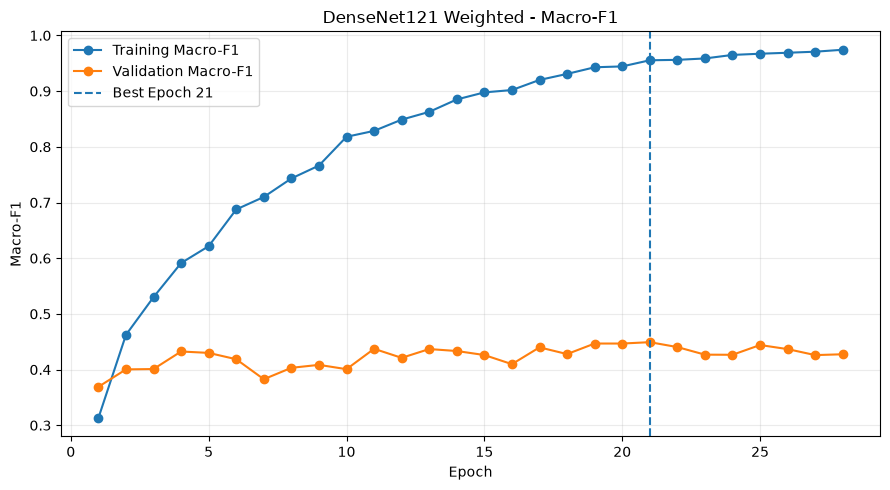

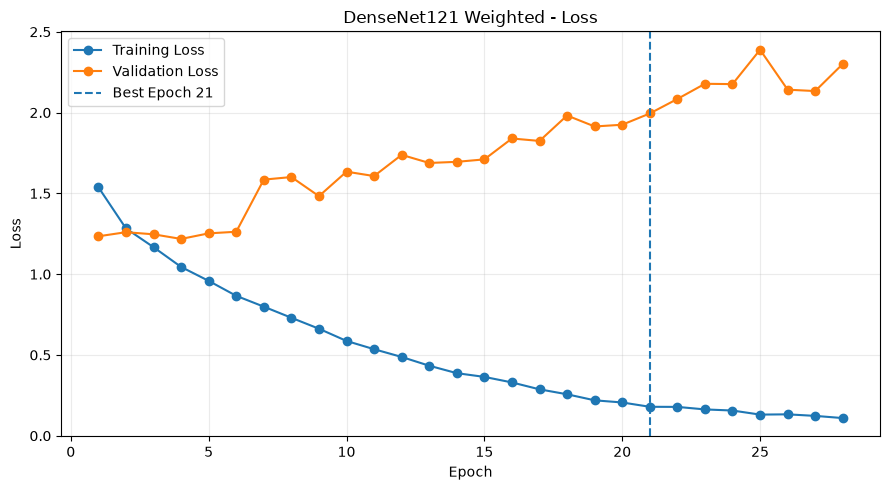

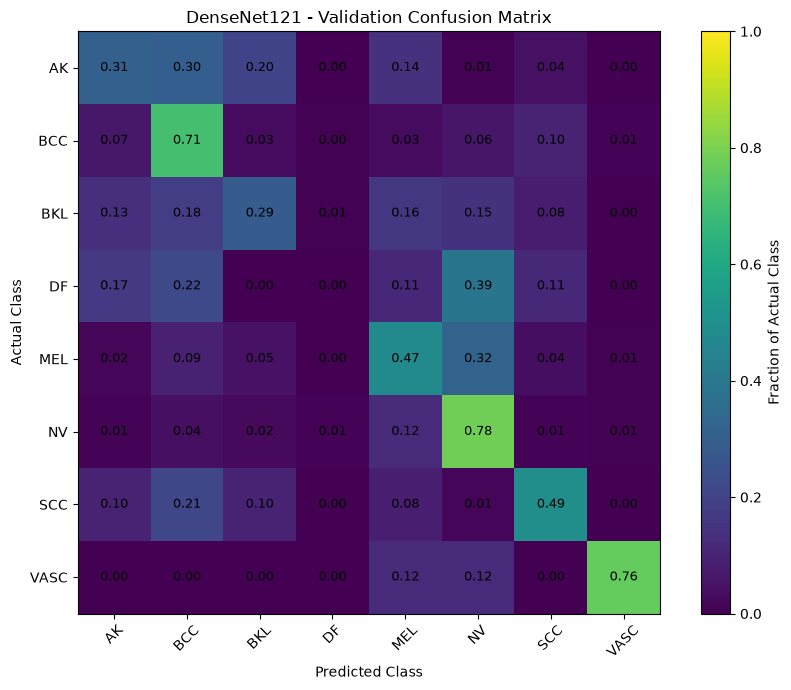

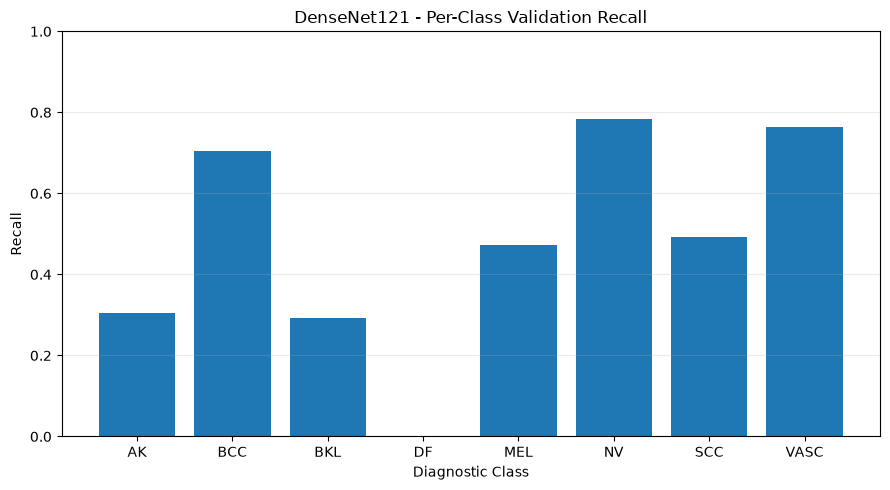

[PASS] All four figures saved

[16] CHECKPOINT SAFETY
[PASS] DenseNet best checkpoint unchanged
[PASS] DenseNet last checkpoint unchanged

DENSENET121 BEST CHECKPOINT AUDIT VERIFICATION
[PASS] DenseNet configuration exists
[PASS] DenseNet training report exists
[PASS] DenseNet setup report exists
[PASS] DenseNet best checkpoint exists
[PASS] DenseNet last checkpoint exists
[PASS] ResNet50 weighted audit exists
[PASS] ResNet50 weighted predictions exists
[PASS] Training manifest exists
[PASS] Validation manifest exists
[PASS] DenseNet configuration signature
[PASS] DenseNet training PASS
[PASS] DenseNet setup PASS
[PASS] ResNet50 weighted audit PASS
[PASS] 28 completed training epochs
[PASS] Epoch 21 selected as best
[PASS] Early stopping triggered
[PASS] Outer-test protected
[PASS] Training history complete
[PASS] Best score matches training report
[PASS] Best checkpoint is Epoch 21
[PASS] Last checkpoint is Epoch 28
[PASS] Checkpoint types valid
[PASS] Experiment IDs valid
[PASS] Chec

In [111]:

# ============================================================
# BCN20000 - PHASE 05A - CELL 4
# DENSENET121 BEST CHECKPOINT AUDIT
# AND RESNET50 WEIGHTED COMPARISON
# ============================================================

import json
import math
import time
import hashlib
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision.models import densenet121
from tqdm.auto import tqdm
from IPython.display import display


print("=" * 78)
print("PHASE 05A - CELL 4")
print("DENSENET121 BEST CHECKPOINT AUDIT")
print("=" * 78)


# ============================================================
# 1. PATHS AND VERIFICATION HELPERS
# ============================================================

D4_ROOT = Path.cwd()
D4_OUT = D4_ROOT / "outputs"

D4_ID = "densenet121_original_fold01_sqrt_weighted_ce_seed42"
D4_R_ID = "resnet50_original_fold01_sqrt_weighted_ce_seed42"

D4_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

D4_CONFIG = (
    D4_OUT / "configs/full_training" / f"{D4_ID}.json"
)

D4_TRAIN_REPORT = (
    D4_OUT / "reports" / f"{D4_ID}_training_report.json"
)

D4_SETUP_REPORT = (
    D4_OUT / "reports" /
    "densenet121_original_fold01_full_training_setup_verification.json"
)

D4_BEST = (
    D4_OUT / "checkpoints/full_training/densenet121/"
    "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
)

D4_LAST = D4_BEST.parent / "last_checkpoint.pt"

D4_RESNET_AUDIT = (
    D4_OUT / "reports" /
    f"{D4_R_ID}_best_checkpoint_audit.json"
)

D4_RESNET_PRED = (
    D4_OUT / "predictions/full_training" /
    f"{D4_R_ID}_validation_predictions.csv"
)

D4_TRAIN_MANIFEST = (
    D4_OUT / "splits/original_branch/fold_01_train.csv"
)

D4_VAL_MANIFEST = (
    D4_OUT / "splits/original_branch/fold_01_validation.csv"
)

D4_PRED_PATH = (
    D4_OUT / "predictions/full_training" /
    f"{D4_ID}_validation_predictions.csv"
)

D4_CLASS_PATH = (
    D4_OUT / "reports" /
    f"{D4_ID}_per_class_metrics.csv"
)

D4_COMPARE_PATH = (
    D4_OUT / "reports" /
    "densenet121_vs_resnet50_weighted_fold01_comparison.csv"
)

D4_AUDIT_PATH = (
    D4_OUT / "reports" /
    f"{D4_ID}_best_checkpoint_audit.json"
)

D4_FIG_DIR = D4_OUT / "figures"

D4_DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

D4_CHECKS = {}
D4_FIGURES = []


def d4_check(name, condition):
    D4_CHECKS[name] = bool(condition)
    print(
        f"[{'PASS' if condition else 'FAIL'}] {name}"
    )


def d4_read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def d4_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def d4_signature(config):
    unsigned = {
        k: v for k, v in config.items()
        if k != "config_signature"
    }

    return hashlib.sha256(
        json.dumps(
            unsigned,
            sort_keys=True,
            separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest()


def d4_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.int64)
    y_pred = np.asarray(y_pred, dtype=np.int64)

    if (
        y_true.size == 0
        or y_true.shape != y_pred.shape
        or not np.all((y_true >= 0) & (y_true < 8))
        or not np.all((y_pred >= 0) & (y_pred < 8))
    ):
        raise ValueError("Invalid classification inputs.")

    cm = np.zeros((8, 8), dtype=np.int64)

    np.add.at(cm, (y_true, y_pred), 1)

    tp = cm.diagonal().astype(float)
    support = cm.sum(axis=1).astype(float)
    predicted = cm.sum(axis=0).astype(float)

    precision = np.divide(
        tp, predicted,
        out=np.zeros(8), where=predicted > 0
    )

    recall = np.divide(
        tp, support,
        out=np.zeros(8), where=support > 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(8),
        where=(precision + recall) > 0
    )

    return {
        "accuracy": float(tp.sum() / len(y_true)),
        "macro_f1": float(f1.mean()),
        "weighted_f1": float(
            np.dot(f1, support) / len(y_true)
        ),
        "balanced_accuracy": float(
            recall[support > 0].mean()
        ),
        "confusion_matrix": cm.tolist(),
        "precision": precision.tolist(),
        "recall": recall.tolist(),
        "f1": f1.tolist(),
        "support": support.astype(int).tolist(),
        "predicted_count": predicted.astype(int).tolist()
    }


# ============================================================
# 2. REQUIRED FILES
# ============================================================

print("\n[1] REQUIRED FILE VERIFICATION")

required = {
    "DenseNet configuration": D4_CONFIG,
    "DenseNet training report": D4_TRAIN_REPORT,
    "DenseNet setup report": D4_SETUP_REPORT,
    "DenseNet best checkpoint": D4_BEST,
    "DenseNet last checkpoint": D4_LAST,
    "ResNet50 weighted audit": D4_RESNET_AUDIT,
    "ResNet50 weighted predictions": D4_RESNET_PRED,
    "Training manifest": D4_TRAIN_MANIFEST,
    "Validation manifest": D4_VAL_MANIFEST
}

for name, path in required.items():
    d4_check(f"{name} exists", path.is_file())

if not all(D4_CHECKS.values()):
    raise FileNotFoundError(
        "Required audit files missing."
    )

if not callable(globals().get("create_bcn_dataset")):
    raise RuntimeError(
        "create_bcn_dataset is unavailable."
    )

D4_PRED_PATH.parent.mkdir(parents=True, exist_ok=True)
D4_FIG_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 3. CONFIGURATION AND TRAINING REPORT
# ============================================================

print("\n[2] TRAINING REPORT VERIFICATION")

config = d4_read_json(D4_CONFIG)
training = d4_read_json(D4_TRAIN_REPORT)
setup = d4_read_json(D4_SETUP_REPORT)
resnet_audit = d4_read_json(D4_RESNET_AUDIT)

signature = d4_signature(config)

d4_check(
    "DenseNet configuration signature",
    signature == config.get("config_signature")
)

d4_check(
    "DenseNet training PASS",
    training.get("status") == "PASS"
)

d4_check(
    "DenseNet setup PASS",
    setup.get("status") == "PASS"
)

d4_check(
    "ResNet50 weighted audit PASS",
    resnet_audit.get("status") == "PASS"
)

d4_check(
    "28 completed training epochs",
    training.get("completed_epochs") == 28
)

d4_check(
    "Epoch 21 selected as best",
    training.get("best_epoch") == 21
)

d4_check(
    "Early stopping triggered",
    training.get("early_stopped") is True
    and training.get("early_stopping_wait") == 7
)

d4_check(
    "Outer-test protected",
    training.get("outer_test_evaluated") is False
    and config.get("outer_test_for_tuning") is False
)

history = training.get("history", [])

d4_check(
    "Training history complete",
    len(history) == 28
    and [int(r["epoch"]) for r in history]
    == list(range(1, 29))
)

if not all(D4_CHECKS.values()):
    raise RuntimeError(
        "Training report verification failed."
    )

best_row = history[20]

d4_check(
    "Best score matches training report",
    math.isclose(
        float(best_row["validation_macro_f1"]),
        float(training["best_validation_macro_f1"]),
        rel_tol=0,
        abs_tol=1e-12
    )
)

print("Completed epochs: 28")
print("Best epoch: 21")
print(
    "Logged best Macro-F1:",
    best_row["validation_macro_f1"]
)


# ============================================================
# 4. CHECKPOINT INTEGRITY
# ============================================================

print("\n[3] CHECKPOINT INTEGRITY")

best_hash_before = d4_hash(D4_BEST)
last_hash_before = d4_hash(D4_LAST)

best_state = torch.load(
    D4_BEST, map_location="cpu", weights_only=True
)

last_state = torch.load(
    D4_LAST, map_location="cpu", weights_only=True
)

d4_check(
    "Best checkpoint is Epoch 21",
    best_state.get("completed_epoch") == 21
)

d4_check(
    "Last checkpoint is Epoch 28",
    last_state.get("completed_epoch") == 28
)

d4_check(
    "Checkpoint types valid",
    best_state.get("checkpoint_kind")
    == "full_training_best"
    and last_state.get("checkpoint_kind")
    == "full_training_last"
)

d4_check(
    "Experiment IDs valid",
    best_state.get("experiment_id") == D4_ID
    and last_state.get("experiment_id") == D4_ID
)

d4_check(
    "Checkpoint signatures valid",
    best_state.get("configuration_signature") == signature
    and last_state.get("configuration_signature") == signature
)

d4_check(
    "Best classifier has eight outputs",
    tuple(
        best_state["model_state_dict"][
            "classifier.weight"
        ].shape
    ) == (8, 1024)
)

d4_check(
    "Best checkpoint history has 21 epochs",
    len(best_state.get("history", [])) == 21
)

d4_check(
    "Last checkpoint history has 28 epochs",
    len(last_state.get("history", [])) == 28
)

if not all(D4_CHECKS.values()):
    raise RuntimeError("Checkpoint integrity failed.")

del last_state

print("Best checkpoint: Epoch 21")
print("Last checkpoint: Epoch 28")


# ============================================================
# 5. VALIDATION DATASET
# ============================================================

print("\n[4] DATASET VERIFICATION")

train_manifest = pd.read_csv(
    D4_TRAIN_MANIFEST,
    usecols=[
        "bcn_filename",
        "diagnosis",
        "leakage_group_id"
    ],
    dtype="string"
)

val_manifest = pd.read_csv(
    D4_VAL_MANIFEST,
    usecols=[
        "bcn_filename",
        "diagnosis",
        "leakage_group_id"
    ],
    dtype="string"
)

val_dataset = create_bcn_dataset(
    "original", 1, "validation"
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(D4_DEVICE.type == "cuda"),
    drop_last=False
)

d4_check(
    "1973 validation images",
    len(val_dataset) == 1973
    and len(val_manifest) == 1973
)

d4_check(
    "494 validation batches",
    len(val_loader) == 494
)

d4_check(
    "571 validation groups",
    val_manifest["leakage_group_id"].nunique() == 571
)

d4_check(
    "Train-validation groups disjoint",
    set(train_manifest["leakage_group_id"]).isdisjoint(
        set(val_manifest["leakage_group_id"])
    )
)

d4_check(
    "Validation filenames unique",
    val_manifest["bcn_filename"].is_unique
)

if not all(D4_CHECKS.values()):
    raise RuntimeError("Validation dataset verification failed.")

print("Validation images:", len(val_dataset))
print("Validation groups: 571")


# ============================================================
# 6. LOAD SAVED BEST DENSENET121
# ============================================================

print("\n[5] LOADING EPOCH 21 MODEL")

model = densenet121(weights=None)

model.classifier = nn.Linear(
    model.classifier.in_features,
    8
)

model.load_state_dict(
    best_state["model_state_dict"],
    strict=True
)

del best_state

model = model.to(D4_DEVICE)
model.eval()

d4_check(
    "Model loaded in evaluation mode",
    not model.training
)

print("Model: DenseNet121")
print("Best checkpoint: Epoch 21")
print("Training: DISABLED")


# ============================================================
# 7. INDEPENDENT VALIDATION EVALUATION
# ============================================================

print("\n[6] INDEPENDENT VALIDATION INFERENCE")

all_true = []
all_pred = []
all_names = []
all_groups = []
all_probs = []

loss_total = 0.0
samples_total = 0

amp_enabled = (
    D4_DEVICE.type == "cuda"
    and config.get("mixed_precision") is True
)

start = time.perf_counter()

with torch.inference_mode():

    for batch in tqdm(
        val_loader,
        desc="DenseNet121 Epoch 21 Audit"
    ):

        images = batch["image"].to(
            D4_DEVICE,
            non_blocking=True
        )

        labels = batch["label"].to(
            D4_DEVICE,
            non_blocking=True
        )

        with torch.autocast(
            device_type=D4_DEVICE.type,
            dtype=torch.float16,
            enabled=amp_enabled
        ):
            logits = model(images)

        logits_fp32 = logits.float()

        loss = F.cross_entropy(
            logits_fp32,
            labels
        )

        if (
            not bool(torch.isfinite(logits).all().item())
            or not bool(torch.isfinite(loss).item())
        ):
            raise FloatingPointError(
                "Non-finite validation outputs."
            )

        probs = torch.softmax(
            logits_fp32,
            dim=1
        )

        predicted = logits.argmax(dim=1)

        count = int(labels.size(0))

        loss_total += float(loss.item()) * count
        samples_total += count

        all_true.extend(labels.cpu().tolist())
        all_pred.extend(predicted.cpu().tolist())

        all_names.extend(list(batch["filename"]))

        all_groups.extend(
            str(x) for x in batch["leakage_group_id"]
        )

        all_probs.append(probs.cpu().numpy())

elapsed = time.perf_counter() - start

prob_matrix = np.concatenate(
    all_probs, axis=0
)

all_true = np.asarray(
    all_true, dtype=np.int64
)

all_pred = np.asarray(
    all_pred, dtype=np.int64
)

d4_check(
    "1973 validation predictions",
    samples_total == 1973
    and len(all_pred) == 1973
)

d4_check(
    "Probabilities finite",
    bool(np.isfinite(prob_matrix).all())
)

d4_check(
    "Probability rows normalized",
    bool(np.allclose(
        prob_matrix.sum(axis=1),
        1,
        atol=1e-5
    ))
)

d4_check(
    "Predictions match probability argmax",
    bool(np.array_equal(
        all_pred, prob_matrix.argmax(axis=1)
    ))
)

print("Evaluated images:", samples_total)
print("Inference seconds:", round(elapsed, 2))


# ============================================================
# 8. RECOMPUTE METRICS
# ============================================================

print("\n[7] RECOMPUTED VALIDATION METRICS")

metrics = d4_metrics(all_true, all_pred)

metrics["loss"] = float(
    loss_total / samples_total
)

comparison_keys = {
    "accuracy": "validation_accuracy",
    "macro_f1": "validation_macro_f1",
    "weighted_f1": "validation_weighted_f1",
    "balanced_accuracy": "validation_balanced_accuracy",
    "loss": "validation_loss"
}

for metric, logged_key in comparison_keys.items():

    logged = float(best_row[logged_key])
    reproduced = float(metrics[metric])

    difference = abs(logged - reproduced)

    tolerance = 1e-4 if metric == "loss" else 1e-5

    passed = difference <= tolerance

    d4_check(f"Reproduced {metric}", passed)

    print(
        f"{metric:20s} | "
        f"Logged: {logged:.6f} | "
        f"Recomputed: {reproduced:.6f} | "
        f"Difference: {difference:.9f}"
    )

cm = np.asarray(
    metrics["confusion_matrix"],
    dtype=np.int64
)

d4_check(
    "Confusion matrix matches Epoch 21",
    np.array_equal(
        cm,
        np.asarray(
            best_row["validation_confusion_matrix"]
        )
    )
)

d4_check(
    "Confusion matrix contains 1973 images",
    int(cm.sum()) == 1973
)


# ============================================================
# 9. VALIDATION METADATA ALIGNMENT
# ============================================================

print("\n[8] DATASET METADATA ALIGNMENT")

pred_df = pd.DataFrame({
    "filename": all_names,
    "leakage_group_id": all_groups,
    "actual_idx": all_true,
    "predicted_idx": all_pred,
    "actual_class": [
        D4_CLASSES[i] for i in all_true
    ],
    "predicted_class": [
        D4_CLASSES[i] for i in all_pred
    ],
    "confidence": prob_matrix.max(axis=1)
})

prob_columns = []

for index, name in enumerate(D4_CLASSES):
    column = f"prob_{name}"
    prob_columns.append(column)
    pred_df[column] = prob_matrix[:, index]

reference = val_manifest.rename(
    columns={
        "bcn_filename": "filename",
        "diagnosis": "manifest_diagnosis",
        "leakage_group_id": "manifest_group"
    }
)

aligned = pred_df.merge(
    reference,
    on="filename",
    how="left",
    indicator=True,
    validate="one_to_one"
)

d4_check(
    "All filenames match validation manifest",
    len(aligned) == 1973
    and bool(aligned["_merge"].eq("both").all())
)

d4_check(
    "Ground-truth labels match manifest",
    bool((
        aligned["actual_class"].astype(str)
        == aligned["manifest_diagnosis"].astype(str)
    ).all())
)

d4_check(
    "Leakage-group IDs match manifest",
    bool((
        aligned["leakage_group_id"].astype(str)
        == aligned["manifest_group"].astype(str)
    ).all())
)


# ============================================================
# 10. PER-CLASS PERFORMANCE
# ============================================================

print("\n[9] DENSENET121 CLASS-WISE PERFORMANCE")

top3 = np.argsort(
    -prob_matrix,
    axis=1
)[:, :3]

class_rows = []

for i, name in enumerate(D4_CLASSES):

    mask = all_true == i
    support = int(mask.sum())

    top3_correct = np.any(
        top3[mask] == i,
        axis=1
    )

    class_rows.append({
        "class": name,
        "validation_support": support,
        "predicted_count": int(
            metrics["predicted_count"][i]
        ),
        "precision": float(metrics["precision"][i]),
        "recall": float(metrics["recall"][i]),
        "f1": float(metrics["f1"][i]),
        "top3_accuracy": (
            float(top3_correct.mean())
            if support else 0.0
        )
    })

class_df = pd.DataFrame(class_rows)

display(class_df.round(6))

d4_check(
    "Eight classes evaluated",
    len(class_df) == 8
)

d4_check(
    "Class supports sum to 1973",
    class_df["validation_support"].sum() == 1973
)

zero_recall = class_df.loc[
    class_df["recall"] == 0,
    "class"
].tolist()

print("\nZero-recall classes:", zero_recall)

print("\nPriority-class recall:")

for name in ["DF", "VASC", "SCC", "MEL"]:
    row = class_df.set_index("class").loc[name]

    correct = int(round(
        row["recall"] * row["validation_support"]
    ))

    print(
        f"{name}: {row['recall']:.6f} "
        f"({correct}/{int(row['validation_support'])})"
    )


# ============================================================
# 11. GROUP-LEVEL EXPLORATORY METRICS
# ============================================================

print("\n[10] GROUP-LEVEL EXPLORATORY EVALUATION")

group_labels = pred_df.groupby(
    "leakage_group_id"
)["actual_idx"].nunique()

d4_check(
    "Every leakage group has one label",
    bool((group_labels == 1).all())
)

group_metrics = None

if D4_CHECKS["Every leakage group has one label"]:

    grouped_probs = pred_df.groupby(
        "leakage_group_id"
    )[prob_columns].mean()

    grouped_true = pred_df.groupby(
        "leakage_group_id"
    )["actual_idx"].first()

    grouped_pred = grouped_probs.to_numpy().argmax(
        axis=1
    )

    group_metrics = d4_metrics(
        grouped_true.to_numpy(dtype=np.int64),
        grouped_pred
    )

    d4_check(
        "571 leakage groups evaluated",
        len(grouped_true) == 571
    )

    print("Group count:", len(grouped_true))
    print(
        "Exploratory group Macro-F1:",
        round(group_metrics["macro_f1"], 6)
    )


# ============================================================
# 12. MISCLASSIFICATION ANALYSIS
# ============================================================

print("\n[11] TOP MISCLASSIFICATIONS")

errors = []

for actual in range(8):
    for predicted in range(8):

        if actual == predicted:
            continue

        count = int(cm[actual, predicted])

        if count:
            errors.append({
                "actual_class": D4_CLASSES[actual],
                "predicted_class": D4_CLASSES[predicted],
                "error_count": count
            })

error_df = pd.DataFrame(
    errors,
    columns=[
        "actual_class",
        "predicted_class",
        "error_count"
    ]
).sort_values(
    "error_count",
    ascending=False
)

display(error_df.head(12))


# ============================================================
# 13. RESNET50 WEIGHTED COMPARISON
# ============================================================

print("\n[12] RESNET50 vs DENSENET121")

resnet_metrics = resnet_audit["validation_metrics"]

compare_rows = []

for metric in [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy",
    "loss"
]:

    r = float(resnet_metrics[metric])
    d = float(metrics[metric])

    compare_rows.append({
        "metric": metric,
        "resnet50_weighted": r,
        "densenet121_weighted": d,
        "densenet_minus_resnet": d - r
    })

compare_df = pd.DataFrame(compare_rows)

display(compare_df.round(6))


# ============================================================
# 14. PAIRED PREDICTION CHECK
# ============================================================

print("\n[13] PAIRED VALIDATION COMPARISON")

resnet_pred = pd.read_csv(
    D4_RESNET_PRED,
    usecols=[
        "filename",
        "actual_idx",
        "predicted_idx",
        "leakage_group_id"
    ],
    dtype={
        "filename": "string",
        "leakage_group_id": "string"
    }
)

paired = pred_df[
    [
        "filename",
        "actual_idx",
        "predicted_idx",
        "leakage_group_id"
    ]
].merge(
    resnet_pred,
    on="filename",
    suffixes=("_dense", "_resnet"),
    validate="one_to_one",
    how="inner"
)

d4_check(
    "Both models evaluated same 1973 images",
    len(paired) == 1973
)

d4_check(
    "Paired ground-truth labels identical",
    bool((
        paired["actual_idx_dense"]
        == paired["actual_idx_resnet"]
    ).all())
)

d4_check(
    "Paired leakage groups identical",
    bool((
        paired["leakage_group_id_dense"]
        == paired["leakage_group_id_resnet"]
    ).all())
)

dense_correct = (
    paired["actual_idx_dense"]
    == paired["predicted_idx_dense"]
)

resnet_correct = (
    paired["actual_idx_resnet"]
    == paired["predicted_idx_resnet"]
)

paired_counts = {
    "both_correct": int(
        (dense_correct & resnet_correct).sum()
    ),
    "dense_only_correct": int(
        (dense_correct & ~resnet_correct).sum()
    ),
    "resnet_only_correct": int(
        (~dense_correct & resnet_correct).sum()
    ),
    "both_wrong": int(
        (~dense_correct & ~resnet_correct).sum()
    )
}

d4_check(
    "Paired correctness totals 1973",
    sum(paired_counts.values()) == 1973
)

print(paired_counts)


# ============================================================
# 15. SAVE PREDICTIONS AND METRIC TABLES
# ============================================================

print("\n[14] SAVING AUDIT OUTPUTS")

if not all(D4_CHECKS.values()):
    raise RuntimeError(
        "Audit verification failed. Outputs not finalized."
    )

pred_df.to_csv(
    D4_PRED_PATH, index=False
)

class_df.to_csv(
    D4_CLASS_PATH, index=False
)

compare_df.to_csv(
    D4_COMPARE_PATH, index=False
)

d4_check(
    "Prediction CSV saved",
    D4_PRED_PATH.is_file()
)

d4_check(
    "Class metrics CSV saved",
    D4_CLASS_PATH.is_file()
)

d4_check(
    "Comparison CSV saved",
    D4_COMPARE_PATH.is_file()
)


# ============================================================
# 16. TRAINING CURVES
# ============================================================

print("\n[15] GENERATING FIGURES")

history_df = pd.DataFrame(history)

for metric, filename, ylabel in [
    (
        "macro_f1",
        "densenet121_weighted_fold01_macro_f1.png",
        "Macro-F1"
    ),
    (
        "loss",
        "densenet121_weighted_fold01_loss.png",
        "Loss"
    )
]:

    path = D4_FIG_DIR / filename

    plt.figure(figsize=(9, 5))

    plt.plot(
        history_df["epoch"],
        history_df[f"train_{metric}"],
        marker="o",
        label=f"Training {ylabel}"
    )

    plt.plot(
        history_df["epoch"],
        history_df[f"validation_{metric}"],
        marker="o",
        label=f"Validation {ylabel}"
    )

    plt.axvline(
        21,
        linestyle="--",
        label="Best Epoch 21"
    )

    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(f"DenseNet121 Weighted - {ylabel}")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    D4_FIGURES.append(str(path))


# ============================================================
# 17. NORMALIZED CONFUSION MATRIX
# ============================================================

cm_path = (
    D4_FIG_DIR /
    "densenet121_weighted_fold01_confusion_matrix.png"
)

row_sum = cm.sum(axis=1, keepdims=True)

normalized_cm = np.divide(
    cm,
    row_sum,
    out=np.zeros((8, 8), dtype=float),
    where=row_sum > 0
)

plt.figure(figsize=(9, 7))
plt.imshow(normalized_cm, vmin=0, vmax=1)
plt.colorbar(label="Fraction of Actual Class")

plt.xticks(range(8), D4_CLASSES, rotation=45)
plt.yticks(range(8), D4_CLASSES)

for i in range(8):
    for j in range(8):
        plt.text(
            j, i,
            f"{normalized_cm[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("DenseNet121 - Validation Confusion Matrix")
plt.tight_layout()
plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

D4_FIGURES.append(str(cm_path))


# ============================================================
# 18. PER-CLASS RECALL CHART
# ============================================================

recall_path = (
    D4_FIG_DIR /
    "densenet121_weighted_fold01_class_recall.png"
)

plt.figure(figsize=(9, 5))

plt.bar(
    class_df["class"],
    class_df["recall"]
)

plt.ylim(0, 1)
plt.xlabel("Diagnostic Class")
plt.ylabel("Recall")
plt.title("DenseNet121 - Per-Class Validation Recall")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(recall_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

D4_FIGURES.append(str(recall_path))

d4_check(
    "All four figures saved",
    len(D4_FIGURES) == 4
    and all(Path(p).is_file() for p in D4_FIGURES)
)


# ============================================================
# 19. FINAL CHECKPOINT SAFETY
# ============================================================

print("\n[16] CHECKPOINT SAFETY")

d4_check(
    "DenseNet best checkpoint unchanged",
    d4_hash(D4_BEST) == best_hash_before
)

d4_check(
    "DenseNet last checkpoint unchanged",
    d4_hash(D4_LAST) == last_hash_before
)


# ============================================================
# 20. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("DENSENET121 BEST CHECKPOINT AUDIT VERIFICATION")
print("=" * 78)

for name, passed in D4_CHECKS.items():
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

D4_STATUS = (
    "PASS"
    if D4_CHECKS and all(D4_CHECKS.values())
    else "BLOCKED"
)


# ============================================================
# 21. SAVE AUDIT REPORT
# ============================================================

audit_report = {
    "stage": "DENSENET121_BEST_CHECKPOINT_AUDIT",
    "status": D4_STATUS,
    "experiment_id": D4_ID,
    "model": "densenet121",
    "branch": "original",
    "fold": 1,
    "completed_training_epochs": 28,
    "best_epoch": 21,
    "evaluation_partition": "validation",
    "validation_metrics": metrics,
    "per_class_metrics": class_rows,
    "group_metrics": group_metrics,
    "zero_recall_classes": zero_recall,
    "top_misclassifications": error_df.head(12).to_dict(
        orient="records"
    ),
    "comparison_with_resnet50": compare_rows,
    "paired_prediction_counts": paired_counts,
    "best_checkpoint_sha256": best_hash_before,
    "prediction_csv": str(D4_PRED_PATH),
    "per_class_csv": str(D4_CLASS_PATH),
    "comparison_csv": str(D4_COMPARE_PATH),
    "figures": D4_FIGURES,
    "training_performed": False,
    "outer_test_evaluated": False,
    "checks": {
        k: bool(v) for k, v in D4_CHECKS.items()
    }
}

with open(
    D4_AUDIT_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        audit_report,
        f,
        indent=4,
        ensure_ascii=False,
        allow_nan=False
    )


# ============================================================
# 22. GPU CLEANUP
# ============================================================

del model
gc.collect()

if D4_DEVICE.type == "cuda":
    torch.cuda.empty_cache()


# ============================================================
# 23. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("DENSENET121 BEST CHECKPOINT AUDIT SUMMARY")
print("=" * 78)

print("Status:", D4_STATUS)
print("Model: DenseNet121")
print("Branch: original")
print("Fold: 1")

print("Training epochs: 28")
print("Best checkpoint: Epoch 21")
print("Validation images:", samples_total)

print(
    "Reproduced Validation Macro-F1:",
    round(metrics["macro_f1"], 6)
)

print(
    "Reproduced Validation Accuracy:",
    round(metrics["accuracy"], 6)
)

print(
    "Reproduced Balanced Accuracy:",
    round(metrics["balanced_accuracy"], 6)
)

print(
    "ResNet50 Weighted Macro-F1:",
    round(
        float(resnet_metrics["macro_f1"]),
        6
    )
)

print("Zero-recall classes:", zero_recall)

print("\nAudit report:")
print(D4_AUDIT_PATH)

print("\nPer-class metrics:")
print(D4_CLASS_PATH)

print("\nComparison:")
print(D4_COMPARE_PATH)

print("Outer-test evaluated: NO")

if D4_STATUS == "PASS":
    print("\nDENSENET121 BEST CHECKPOINT AUDIT: PASS")
    print("NEXT ARCHITECTURE: EFFICIENTNET-B0")
else:
    print("\nDENSENET121 AUDIT: BLOCKED")

print("=" * 78)


In [112]:

# ============================================================
# BCN20000 - PHASE 05B - CELL 1
# EFFICIENTNET-B0 ARCHITECTURE & GPU READINESS
# ============================================================

import os
import gc
import json
import math
import random
import hashlib
import traceback

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, Subset
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

print("=" * 78)
print("PHASE 05B - CELL 1")
print("EFFICIENTNET-B0 ARCHITECTURE & GPU READINESS")
print("=" * 78)


# ============================================================
# 1. PATH CONFIGURATION
# ============================================================

E5_ROOT = Path.cwd()
E5_OUT = E5_ROOT / "outputs"

E5_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

E5_DENSE_ID = (
    "densenet121_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

E5_DENSE_AUDIT = (
    E5_OUT / "reports" /
    f"{E5_DENSE_ID}_best_checkpoint_audit.json"
)

E5_DENSE_CONFIG = (
    E5_OUT / "configs/full_training" /
    f"{E5_DENSE_ID}.json"
)

E5_ENGINE_REPORT = (
    E5_OUT / "reports" /
    "resnet50_weighted_engine_verification.json"
)

E5_REPORT_PATH = (
    E5_OUT / "reports" /
    "efficientnet_b0_original_fold01_"
    "architecture_readiness.json"
)

E5_CHECKPOINT_DIR = (
    E5_OUT / "checkpoints/full_training/"
    "efficientnet_b0/original/fold_01/sqrt_weighted_ce"
)

E5_PROTECTED_CHECKPOINTS = {
    "ResNet50 A": (
        E5_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt"
    ),
    "ResNet50 B": (
        E5_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 best": (
        E5_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 last": (
        E5_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    )
}

E5_CHECKS = {}
E5_ERRORS = []
E5_RESULTS = {}


def e5_check(name, passed):
    E5_CHECKS[name] = bool(passed)

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )


def e5_read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def e5_file_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def e5_config_signature(config):
    unsigned = {
        key: value
        for key, value in config.items()
        if key != "config_signature"
    }

    return hashlib.sha256(
        json.dumps(
            unsigned,
            sort_keys=True,
            separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest()


# ============================================================
# 2. PREVIOUS PHASE VERIFICATION
# ============================================================

print("\n[1] PREVIOUS PHASE VERIFICATION")

required_files = {
    "DenseNet121 audit": E5_DENSE_AUDIT,
    "DenseNet121 configuration": E5_DENSE_CONFIG,
    "Weighted training engine report": E5_ENGINE_REPORT
}

required_files.update(
    E5_PROTECTED_CHECKPOINTS
)

for name, path in required_files.items():
    e5_check(
        f"{name} exists",
        path.is_file()
    )

if not all(E5_CHECKS.values()):
    raise RuntimeError(
        "Required previous artifacts missing."
    )

e5_dense_audit = e5_read_json(E5_DENSE_AUDIT)
e5_dense_config = e5_read_json(E5_DENSE_CONFIG)
e5_engine_report = e5_read_json(E5_ENGINE_REPORT)

e5_check(
    "DenseNet121 audit PASS",
    e5_dense_audit.get("status") == "PASS"
)

e5_check(
    "All DenseNet121 audit checks PASS",
    bool(e5_dense_audit.get("checks"))
    and all(e5_dense_audit["checks"].values())
)

e5_check(
    "Weighted engine verified",
    e5_engine_report.get("status") == "PASS"
)

e5_check(
    "Source configuration fingerprint valid",
    e5_config_signature(e5_dense_config)
    == e5_dense_config["config_signature"]
)

e5_check(
    "Outer-test protected",
    e5_dense_audit.get("outer_test_evaluated") is False
    and e5_dense_config.get("outer_test_for_tuning") is False
)

e5_check(
    "Correct class order",
    e5_dense_config.get("class_names") == E5_CLASSES
)

for function in [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch"
]:
    e5_check(
        f"{function} available",
        callable(globals().get(function))
    )

e5_check(
    "Correct weighted accumulation engine active",
    callable(globals().get("train_one_epoch_weighted"))
    and "window_total_weight"
    in train_one_epoch_weighted.__code__.co_varnames
)

e5_check(
    "CUDA GPU available",
    torch.cuda.is_available()
)

if not all(E5_CHECKS.values()):
    raise RuntimeError(
        "Previous phase verification failed."
    )

E5_HASHES_BEFORE = {
    name: e5_file_hash(path)
    for name, path in E5_PROTECTED_CHECKPOINTS.items()
}


# ============================================================
# 3. DATASET VERIFICATION
# ============================================================

print("\n[2] DATASET VERIFICATION")

e5_train = create_bcn_dataset(
    "original", 1, "train"
)

e5_val = create_bcn_dataset(
    "original", 1, "validation"
)

e5_check(
    "Training images = 7813",
    len(e5_train) == 7813
)

e5_check(
    "Validation images = 1973",
    len(e5_val) == 1973
)

e5_train_groups = set(
    e5_train.leakage_group_ids
)

e5_val_groups = set(
    e5_val.leakage_group_ids
)

e5_check(
    "Training groups = 2286",
    len(e5_train_groups) == 2286
)

e5_check(
    "Validation groups = 571",
    len(e5_val_groups) == 571
)

e5_check(
    "No train-validation group overlap",
    e5_train_groups.isdisjoint(e5_val_groups)
)

e5_labels = np.asarray(
    e5_train.labels,
    dtype=np.int64
)

e5_counts = np.bincount(
    e5_labels,
    minlength=8
).astype(np.float64)

e5_check(
    "All eight classes available",
    len(e5_counts) == 8
    and np.all(e5_counts > 0)
)

e5_weights = np.sqrt(
    e5_counts.sum() / (8.0 * e5_counts)
)

e5_weights /= (
    np.dot(e5_counts, e5_weights)
    / e5_counts.sum()
)

e5_check(
    "Training-only class weights match",
    np.allclose(
        e5_weights,
        np.asarray(
            e5_dense_config["class_weights"],
            dtype=np.float64
        ),
        atol=1e-7,
        rtol=1e-7
    )
)

if not all(E5_CHECKS.values()):
    raise RuntimeError(
        "Dataset verification failed."
    )

print("Training images:", len(e5_train))
print("Validation images:", len(e5_val))
print("Group overlap: 0")
print("Class weights:", e5_weights.round(6))


# ============================================================
# 4. GPU SMOKE TEST CONFIGURATION
# ============================================================

print("\n[3] GPU SMOKE-TEST CONFIGURATION")

E5_DEVICE = torch.device("cuda:0")

E5_MICROBATCH = 4
E5_ACCUMULATION = 4
E5_EFFECTIVE_BATCH = (
    E5_MICROBATCH * E5_ACCUMULATION
)

E5_AMP_SCALE = 1024.0
E5_AMP_GROWTH_INTERVAL = 1000000

print("GPU:", torch.cuda.get_device_name(0))
print("Microbatch:", E5_MICROBATCH)
print("Gradient accumulation:", E5_ACCUMULATION)
print("Effective batch:", E5_EFFECTIVE_BATCH)
print("AMP scale:", E5_AMP_SCALE)
print("AMP growth interval:", E5_AMP_GROWTH_INTERVAL)

e5_check(
    "Nominal effective batch = 16",
    E5_EFFECTIVE_BATCH == 16
)

e5_check(
    "EfficientNet training not started",
    not (
        (E5_CHECKPOINT_DIR / "best_checkpoint.pt").exists()
        or
        (E5_CHECKPOINT_DIR / "last_checkpoint.pt").exists()
    )
)

if not all(E5_CHECKS.values()):
    raise RuntimeError(
        "Smoke test cannot proceed."
    )


# ============================================================
# 5. PRETRAINED ARCHITECTURE AND GPU SMOKE TEST
# ============================================================

e5_model = None
e5_optimizer = None
e5_scaler = None
e5_criterion = None

e5_python_rng_state = random.getstate()
e5_numpy_rng_state = np.random.get_state()

try:

    with torch.random.fork_rng(devices=[0]):

        torch.manual_seed(42)
        torch.cuda.manual_seed_all(42)

        print("\n[4] PRETRAINED EFFICIENTNET-B0")

        # Only official ImageNet-pretrained weights.
        # No silent random-initialization fallback.

        e5_model = efficientnet_b0(
            weights=EfficientNet_B0_Weights.IMAGENET1K_V1
        )

        e5_check(
            "EfficientNet classifier is Sequential",
            isinstance(
                e5_model.classifier,
                nn.Sequential
            )
        )

        e5_in_features = (
            e5_model.classifier[1].in_features
        )

        e5_check(
            "Classifier input dimension = 1280",
            e5_in_features == 1280
        )

        # Preserve pretrained feature extractor
        # and the existing classifier dropout.

        e5_model.classifier[1] = nn.Linear(
            e5_in_features,
            8
        )

        e5_model = e5_model.to(E5_DEVICE)

        e5_total_params = sum(
            p.numel()
            for p in e5_model.parameters()
        )

        e5_trainable_params = sum(
            p.numel()
            for p in e5_model.parameters()
            if p.requires_grad
        )

        e5_check(
            "Eight-class output layer",
            tuple(
                e5_model.classifier[1].weight.shape
            ) == (8, 1280)
        )

        e5_check(
            "All parameters trainable",
            e5_total_params == e5_trainable_params
        )

        e5_check(
            "Model parameters finite",
            all(
                bool(torch.isfinite(p).all().item())
                for p in e5_model.parameters()
            )
        )

        print("ImageNet pretrained backbone: LOADED")
        print("Classifier:", e5_model.classifier)
        print("Total parameters:", e5_total_params)
        print("Trainable parameters:", e5_trainable_params)

        # ====================================================
        # 6. TRAINING SMOKE TEST
        # ====================================================

        print("\n[5] WEIGHTED TRAINING SMOKE TEST")

        e5_train_subset = Subset(
            e5_train,
            list(range(16))
        )

        e5_train_loader = DataLoader(
            e5_train_subset,
            batch_size=E5_MICROBATCH,
            shuffle=False,
            num_workers=0,
            pin_memory=True,
            drop_last=False
        )

        e5_optimizer = torch.optim.AdamW(
            e5_model.parameters(),
            lr=0.0001,
            weight_decay=0.0001
        )

        e5_criterion = nn.CrossEntropyLoss(
            weight=torch.as_tensor(
                e5_weights,
                dtype=torch.float32,
                device=E5_DEVICE
            )
        )

        e5_scaler = torch.amp.GradScaler(
            "cuda",
            enabled=True,
            init_scale=E5_AMP_SCALE,
            growth_interval=E5_AMP_GROWTH_INTERVAL
        )

        torch.cuda.reset_peak_memory_stats(
            E5_DEVICE
        )

        e5_train_metrics = train_one_epoch_weighted(
            model=e5_model,
            loader=e5_train_loader,
            optimizer=e5_optimizer,
            criterion=e5_criterion,
            scaler=e5_scaler,
            device=E5_DEVICE,
            accumulation_steps=E5_ACCUMULATION,
            gradient_clip_norm=1.0
        )

        e5_check(
            "Training processed 16 images",
            e5_train_metrics["samples"] == 16
        )

        e5_check(
            "Training processed four microbatches",
            e5_train_metrics["batches"] == 4
        )

        e5_check(
            "One optimizer update completed",
            e5_train_metrics["optimizer_steps"] == 1
        )

        e5_check(
            "No skipped optimizer updates",
            e5_train_metrics[
                "skipped_optimizer_steps"
            ] == 0
        )

        e5_check(
            "Weighted training loss finite",
            math.isfinite(
                float(e5_train_metrics["loss"])
            )
        )

        e5_check(
            "AMP scale remains 1024",
            float(e5_scaler.get_scale())
            == E5_AMP_SCALE
        )

        e5_check(
            "Model parameters finite after update",
            all(
                bool(torch.isfinite(p).all().item())
                for p in e5_model.parameters()
            )
        )

        print(
            "Weighted training loss:",
            round(e5_train_metrics["loss"], 6)
        )

        print(
            "Optimizer updates:",
            e5_train_metrics["optimizer_steps"]
        )

        print(
            "Skipped updates:",
            e5_train_metrics["skipped_optimizer_steps"]
        )

        # ====================================================
        # 7. VALIDATION SMOKE TEST
        # ====================================================

        print("\n[6] VALIDATION SMOKE TEST")

        e5_val_subset = Subset(
            e5_val,
            list(range(8))
        )

        e5_val_loader = DataLoader(
            e5_val_subset,
            batch_size=4,
            shuffle=False,
            num_workers=0,
            pin_memory=True
        )

        e5_val_metrics = validate_one_epoch(
            model=e5_model,
            loader=e5_val_loader,
            criterion=nn.CrossEntropyLoss(),
            device=E5_DEVICE
        )

        e5_check(
            "Validation processed eight images",
            e5_val_metrics["samples"] == 8
        )

        e5_check(
            "Validation processed two batches",
            e5_val_metrics["batches"] == 2
        )

        e5_check(
            "Validation loss finite",
            math.isfinite(
                float(e5_val_metrics["loss"])
            )
        )

        e5_check(
            "Validation Macro-F1 finite",
            math.isfinite(
                float(e5_val_metrics["macro_f1"])
            )
        )

        e5_cm = np.asarray(
            e5_val_metrics["confusion_matrix"]
        )

        e5_check(
            "Validation confusion matrix valid",
            e5_cm.shape == (8, 8)
            and int(e5_cm.sum()) == 8
        )

        torch.cuda.synchronize(E5_DEVICE)

        e5_peak_mb = (
            torch.cuda.max_memory_allocated(E5_DEVICE)
            / (1024 ** 2)
        )

        e5_available_mb = (
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 2)
        )

        e5_check(
            "GPU peak memory within device capacity",
            0 < e5_peak_mb <= e5_available_mb
        )

        print("Validation images:", 8)
        print(
            "Peak GPU allocated memory:",
            round(e5_peak_mb, 2),
            "MB"
        )

        E5_RESULTS = {
            "model": "efficientnet_b0",
            "pretrained_weights": "IMAGENET1K_V1",
            "total_parameters": int(e5_total_params),
            "trainable_parameters": int(
                e5_trainable_params
            ),
            "classifier_in_features": 1280,
            "num_classes": 8,
            "train_images_smoke": 16,
            "validation_images_smoke": 8,
            "microbatch_size": E5_MICROBATCH,
            "gradient_accumulation_steps": E5_ACCUMULATION,
            "nominal_effective_batch": E5_EFFECTIVE_BATCH,
            "optimizer_steps": int(
                e5_train_metrics["optimizer_steps"]
            ),
            "skipped_optimizer_steps": int(
                e5_train_metrics["skipped_optimizer_steps"]
            ),
            "weighted_training_loss": float(
                e5_train_metrics["loss"]
            ),
            "amp_scale_end": float(
                e5_scaler.get_scale()
            ),
            "gpu_peak_allocated_mb": float(
                e5_peak_mb
            )
        }

except Exception:

    E5_ERRORS.append(traceback.format_exc())

    print("\nEFFICIENTNET-B0 SMOKE TEST ERROR")
    print(E5_ERRORS[-1])

finally:

    random.setstate(
        e5_python_rng_state
    )

    np.random.set_state(
        e5_numpy_rng_state
    )

    e5_model = None
    e5_optimizer = None
    e5_scaler = None
    e5_criterion = None

    gc.collect()
    torch.cuda.empty_cache()


# ============================================================
# 8. CHECKPOINT SAFETY VERIFICATION
# ============================================================

print("\n[7] CHECKPOINT SAFETY")

for name, path in E5_PROTECTED_CHECKPOINTS.items():

    e5_check(
        f"{name} checkpoint unchanged",
        e5_file_hash(path)
        == E5_HASHES_BEFORE[name]
    )

e5_check(
    "No EfficientNet full-training checkpoint created",
    not (
        (E5_CHECKPOINT_DIR / "best_checkpoint.pt").exists()
        or
        (E5_CHECKPOINT_DIR / "last_checkpoint.pt").exists()
    )
)


# ============================================================
# 9. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("EFFICIENTNET-B0 ARCHITECTURE READINESS VERIFICATION")
print("=" * 78)

for name, passed in E5_CHECKS.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

E5_STATUS = (
    "PASS"
    if (
        E5_CHECKS
        and all(E5_CHECKS.values())
        and not E5_ERRORS
        and E5_RESULTS
    )
    else "BLOCKED"
)


# ============================================================
# 10. SAVE VERIFICATION REPORT
# ============================================================

E5_REPORT = {
    "stage": "EFFICIENTNET_B0_ARCHITECTURE_READINESS",
    "status": E5_STATUS,
    "model": "efficientnet_b0",
    "branch": "original",
    "fold": 1,
    "class_names": E5_CLASSES,
    "training_policy_candidate": (
        "sqrt_weighted_cross_entropy"
    ),
    "gpu": torch.cuda.get_device_name(0),
    "results": E5_RESULTS,
    "checks": {
        name: bool(value)
        for name, value in E5_CHECKS.items()
    },
    "errors": E5_ERRORS,
    "full_training_started": False,
    "outer_test_evaluated": False,
    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

E5_REPORT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

e5_temp_report = E5_REPORT_PATH.with_name(
    E5_REPORT_PATH.name + ".temporary"
)

try:

    with open(
        e5_temp_report,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            E5_REPORT,
            f,
            indent=4,
            ensure_ascii=False,
            allow_nan=False
        )

    os.replace(
        e5_temp_report,
        E5_REPORT_PATH
    )

finally:

    if e5_temp_report.exists():
        e5_temp_report.unlink()


# ============================================================
# 11. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("EFFICIENTNET-B0 READINESS SUMMARY")
print("=" * 78)

print("Status:", E5_STATUS)
print("Model: EfficientNet-B0")
print("Branch: original")
print("Fold: 1")

if E5_RESULTS:

    print(
        "Total parameters:",
        E5_RESULTS["total_parameters"]
    )

    print(
        "GPU peak allocated MB:",
        round(
            E5_RESULTS["gpu_peak_allocated_mb"],
            2
        )
    )

    print(
        "Successful optimizer updates:",
        E5_RESULTS["optimizer_steps"]
    )

    print(
        "Skipped optimizer updates:",
        E5_RESULTS["skipped_optimizer_steps"]
    )

print("Full training started: NO")
print("Outer-test evaluated: NO")

print("Previous model checkpoints: PRESERVED")

print("\nReadiness report:")
print(E5_REPORT_PATH)

if E5_STATUS == "PASS":

    print("\nEFFICIENTNET-B0 READINESS: PASS")
    print("NEXT: EFFICIENTNET-B0 FULL TRAINING CONFIGURATION")

else:

    print("\nEFFICIENTNET-B0 READINESS: BLOCKED")
    print("Review failed checks before proceeding.")

print("=" * 78)


PHASE 05B - CELL 1
EFFICIENTNET-B0 ARCHITECTURE & GPU READINESS

[1] PREVIOUS PHASE VERIFICATION
[PASS] DenseNet121 audit exists
[PASS] DenseNet121 configuration exists
[PASS] Weighted training engine report exists
[PASS] ResNet50 A exists
[PASS] ResNet50 B exists
[PASS] DenseNet121 best exists
[PASS] DenseNet121 last exists
[PASS] DenseNet121 audit PASS
[PASS] All DenseNet121 audit checks PASS
[PASS] Weighted engine verified
[PASS] Source configuration fingerprint valid
[PASS] Outer-test protected
[PASS] Correct class order
[PASS] create_bcn_dataset available
[PASS] train_one_epoch_weighted available
[PASS] validate_one_epoch available
[PASS] Correct weighted accumulation engine active
[PASS] CUDA GPU available

[2] DATASET VERIFICATION
[PASS] Training images = 7813
[PASS] Validation images = 1973
[PASS] Training groups = 2286
[PASS] Validation groups = 571
[PASS] No train-validation group overlap
[PASS] All eight classes available
[PASS] Training-only class weights match
Training ima

100%|██████████| 20.5M/20.5M [00:02<00:00, 8.92MB/s]


[PASS] EfficientNet classifier is Sequential
[PASS] Classifier input dimension = 1280
[PASS] Eight-class output layer
[PASS] All parameters trainable
[PASS] Model parameters finite
ImageNet pretrained backbone: LOADED
Classifier: Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=8, bias=True)
)
Total parameters: 4017796
Trainable parameters: 4017796

[5] WEIGHTED TRAINING SMOKE TEST
[PASS] Training processed 16 images
[PASS] Training processed four microbatches
[PASS] One optimizer update completed
[PASS] No skipped optimizer updates
[PASS] Weighted training loss finite
[PASS] AMP scale remains 1024
[PASS] Model parameters finite after update
Weighted training loss: 2.108774
Optimizer updates: 1
Skipped updates: 0

[6] VALIDATION SMOKE TEST
[PASS] Validation processed eight images
[PASS] Validation processed two batches
[PASS] Validation loss finite
[PASS] Validation Macro-F1 finite
[PASS] Validation confusion matrix valid
[PASS] GPU peak memo

In [113]:

# ============================================================
# BCN20000 - PHASE 05B - CELL 2
# EFFICIENTNET-B0 FULL TRAINING CONFIGURATION
# ============================================================

import os
import json
import math
import hashlib
from copy import deepcopy
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch

from IPython.display import display

print("=" * 78)
print("PHASE 05B - CELL 2")
print("EFFICIENTNET-B0 FULL TRAINING CONFIGURATION")
print("=" * 78)


# ============================================================
# 1. EXPERIMENT PATHS
# ============================================================

F2_ROOT = Path.cwd()
F2_OUT = F2_ROOT / "outputs"

F2_ID = "efficientnet_b0_original_fold01_sqrt_weighted_ce_seed42"

F2_DENSE_ID = (
    "densenet121_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

F2_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

F2_ARCH_PATH = (
    F2_OUT / "reports" /
    "efficientnet_b0_original_fold01_architecture_readiness.json"
)

F2_DENSE_CONFIG = (
    F2_OUT / "configs/full_training" /
    f"{F2_DENSE_ID}.json"
)

F2_DENSE_AUDIT = (
    F2_OUT / "reports" /
    f"{F2_DENSE_ID}_best_checkpoint_audit.json"
)

F2_ENGINE_REPORT = (
    F2_OUT / "reports" /
    "resnet50_weighted_engine_verification.json"
)

F2_TRAIN_MANIFEST = (
    F2_OUT / "splits/original_branch/fold_01_train.csv"
)

F2_VAL_MANIFEST = (
    F2_OUT / "splits/original_branch/fold_01_validation.csv"
)

F2_CONFIG_PATH = (
    F2_OUT / "configs/full_training" /
    f"{F2_ID}.json"
)

F2_CKPT_DIR = (
    F2_OUT / "checkpoints/full_training/"
    "efficientnet_b0/original/fold_01/sqrt_weighted_ce"
)

F2_BEST_PATH = F2_CKPT_DIR / "best_checkpoint.pt"
F2_LAST_PATH = F2_CKPT_DIR / "last_checkpoint.pt"

F2_HISTORY_PATH = (
    F2_OUT / "logs/full_training" /
    f"{F2_ID}_history.csv"
)

F2_TRAIN_REPORT = (
    F2_OUT / "reports" /
    f"{F2_ID}_training_report.json"
)

F2_SETUP_REPORT = (
    F2_OUT / "reports" /
    "efficientnet_b0_original_fold01_full_training_setup_verification.json"
)

F2_PROTECTED = {
    "ResNet50 A": (
        F2_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt"
    ),
    "ResNet50 B": (
        F2_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 best": (
        F2_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 last": (
        F2_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    )
}

F2_CHECKS = {}


def f2_check(name, condition):
    F2_CHECKS[name] = bool(condition)

    print(
        f"[{'PASS' if condition else 'FAIL'}] {name}"
    )


def f2_read_json(path):
    with open(path, "r", encoding="utf-8") as file:
        return json.load(file)


def f2_signature(config):
    unsigned = {
        key: value
        for key, value in config.items()
        if key != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


def f2_file_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(
            lambda: file.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def f2_save_json_atomic(data, path):
    path.parent.mkdir(parents=True, exist_ok=True)

    temporary = path.with_name(
        path.name + ".temporary"
    )

    try:
        with open(
            temporary,
            "w",
            encoding="utf-8"
        ) as file:
            json.dump(
                data,
                file,
                indent=4,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


def f2_assert_checks():
    failed = [
        name for name, passed in F2_CHECKS.items()
        if not passed
    ]

    if failed:
        raise RuntimeError(
            "Verification failed: "
            + "; ".join(failed)
        )


# ============================================================
# 2. PREVIOUS PHASE VERIFICATION
# ============================================================

print("\n[1] PREVIOUS PHASE VERIFICATION")

required = {
    "EfficientNet architecture readiness": F2_ARCH_PATH,
    "DenseNet source configuration": F2_DENSE_CONFIG,
    "DenseNet checkpoint audit": F2_DENSE_AUDIT,
    "Weighted training engine report": F2_ENGINE_REPORT,
    "Training manifest": F2_TRAIN_MANIFEST,
    "Validation manifest": F2_VAL_MANIFEST
}

required.update(F2_PROTECTED)

for name, path in required.items():
    f2_check(
        f"{name} exists",
        path.is_file()
    )

f2_assert_checks()

arch = f2_read_json(F2_ARCH_PATH)
dense_config = f2_read_json(F2_DENSE_CONFIG)
dense_audit = f2_read_json(F2_DENSE_AUDIT)
engine_report = f2_read_json(F2_ENGINE_REPORT)

f2_check(
    "EfficientNet architecture readiness PASS",
    arch.get("status") == "PASS"
)

f2_check(
    "All architecture smoke checks PASS",
    bool(arch.get("checks"))
    and all(arch["checks"].values())
)

f2_check(
    "DenseNet checkpoint audit PASS",
    dense_audit.get("status") == "PASS"
)

f2_check(
    "All DenseNet audit checks PASS",
    bool(dense_audit.get("checks"))
    and all(dense_audit["checks"].values())
)

f2_check(
    "Weighted training engine PASS",
    engine_report.get("status") == "PASS"
)

f2_check(
    "DenseNet config fingerprint valid",
    f2_signature(dense_config)
    == dense_config.get("config_signature")
)

f2_check(
    "Correct source model",
    dense_config.get("model") == "densenet121"
)

f2_check(
    "Source class order correct",
    dense_config.get("class_names") == F2_CLASSES
)

f2_check(
    "Source uses Fold 1 Original branch",
    dense_config.get("fold") == 1
    and dense_config.get("branch") == "original"
)

f2_check(
    "Outer-test remains protected",
    dense_audit.get("outer_test_evaluated") is False
    and dense_config.get("outer_test_for_tuning") is False
)

smoke = arch.get("results", {})

f2_check(
    "ImageNet pretrained EfficientNet verified",
    smoke.get("pretrained_weights") == "IMAGENET1K_V1"
)

f2_check(
    "Eight-class classifier verified",
    smoke.get("num_classes") == 8
    and smoke.get("classifier_in_features") == 1280
)

f2_check(
    "Smoke training update successful",
    smoke.get("optimizer_steps") == 1
    and smoke.get("skipped_optimizer_steps") == 0
)

f2_check(
    "Smoke validation completed",
    smoke.get("validation_images_smoke") == 8
)

f2_check(
    "GPU available",
    torch.cuda.is_available()
)

for name in [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch",
    "save_pilot_training_checkpoint",
    "load_pilot_training_checkpoint"
]:
    f2_check(
        f"Required notebook function: {name}",
        callable(globals().get(name))
    )

f2_assert_checks()

protected_hashes = {
    name: f2_file_hash(path)
    for name, path in F2_PROTECTED.items()
}


# ============================================================
# 3. DATASET AND LEAKAGE VERIFICATION
# ============================================================

print("\n[2] DATASET INTEGRITY")

train_df = pd.read_csv(
    F2_TRAIN_MANIFEST,
    usecols=[
        "bcn_filename",
        "diagnosis",
        "leakage_group_id"
    ],
    dtype="string"
)

val_df = pd.read_csv(
    F2_VAL_MANIFEST,
    usecols=[
        "bcn_filename",
        "diagnosis",
        "leakage_group_id"
    ],
    dtype="string"
)

train_groups = set(train_df["leakage_group_id"])
val_groups = set(val_df["leakage_group_id"])

f2_check(
    "Training images = 7813",
    len(train_df) == 7813
)

f2_check(
    "Validation images = 1973",
    len(val_df) == 1973
)

f2_check(
    "Training groups = 2286",
    len(train_groups) == 2286
)

f2_check(
    "Validation groups = 571",
    len(val_groups) == 571
)

f2_check(
    "No train-validation group overlap",
    train_groups.isdisjoint(val_groups)
)

f2_check(
    "Training filenames unique",
    train_df["bcn_filename"].is_unique
)

f2_check(
    "Validation filenames unique",
    val_df["bcn_filename"].is_unique
)

f2_check(
    "No train-validation filename overlap",
    set(train_df["bcn_filename"]).isdisjoint(
        set(val_df["bcn_filename"])
    )
)

f2_check(
    "No missing training metadata",
    not train_df.isna().any().any()
)

f2_check(
    "No missing validation metadata",
    not val_df.isna().any().any()
)

f2_check(
    "Eight training classes present",
    set(train_df["diagnosis"]) == set(F2_CLASSES)
)

f2_check(
    "Eight validation classes present",
    set(val_df["diagnosis"]) == set(F2_CLASSES)
)

f2_assert_checks()

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Training groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Group overlap:", len(train_groups & val_groups))


# ============================================================
# 4. VERIFY TRAINING-ONLY CLASS WEIGHTS
# ============================================================

print("\n[3] CLASS WEIGHT VERIFICATION")

train_counts = (
    train_df["diagnosis"]
    .value_counts()
    .reindex(F2_CLASSES, fill_value=0)
    .to_numpy(dtype=np.float64)
)

weights = np.sqrt(
    train_counts.sum() / (8.0 * train_counts)
)

weights /= (
    np.dot(train_counts, weights)
    / train_counts.sum()
)

source_weights = np.asarray(
    dense_config["class_weights"],
    dtype=np.float64
)

f2_check(
    "All class counts positive",
    bool(np.all(train_counts > 0))
)

f2_check(
    "Eight class weights",
    source_weights.shape == (8,)
)

f2_check(
    "Class weights finite and positive",
    bool(
        np.isfinite(source_weights).all()
        and np.all(source_weights > 0)
    )
)

f2_check(
    "Weights independently reproduced",
    bool(np.allclose(
        weights,
        source_weights,
        atol=1e-7,
        rtol=1e-7
    ))
)

f2_assert_checks()

weight_table = pd.DataFrame({
    "class": F2_CLASSES,
    "training_images": train_counts.astype(int),
    "class_weight": source_weights
})

display(weight_table.round(6))


# ============================================================
# 5. TRAINING BATCH CONFIGURATION
# ============================================================

print("\n[4] TRAINING BATCH CONFIGURATION")

MICROBATCH = 4
VALIDATION_BATCH = 4
ACCUMULATION = 4

EFFECTIVE_BATCH = MICROBATCH * ACCUMULATION

TRAIN_BATCHES = math.ceil(
    len(train_df) / MICROBATCH
)

VAL_BATCHES = math.ceil(
    len(val_df) / VALIDATION_BATCH
)

OPTIMIZER_UPDATES = math.ceil(
    TRAIN_BATCHES / ACCUMULATION
)

f2_check(
    "Microbatch size = 4",
    MICROBATCH == smoke.get("microbatch_size")
)

f2_check(
    "Accumulation steps = 4",
    ACCUMULATION
    == smoke.get("gradient_accumulation_steps")
)

f2_check(
    "Effective batch size = 16",
    EFFECTIVE_BATCH == 16
    and EFFECTIVE_BATCH
    == smoke.get("nominal_effective_batch")
)

f2_check(
    "Training batches = 1954",
    TRAIN_BATCHES == 1954
)

f2_check(
    "Validation batches = 494",
    VAL_BATCHES == 494
)

f2_check(
    "Optimizer updates per epoch = 489",
    OPTIMIZER_UPDATES == 489
)

f2_assert_checks()

print("Microbatch:", MICROBATCH)
print("Gradient accumulation:", ACCUMULATION)
print("Effective batch:", EFFECTIVE_BATCH)
print("Training batches:", TRAIN_BATCHES)
print("Validation batches:", VAL_BATCHES)
print("Optimizer updates per epoch:", OPTIMIZER_UPDATES)


# ============================================================
# 6. CHECKPOINT ISOLATION
# ============================================================

print("\n[5] CHECKPOINT ISOLATION")

training_artifacts = {
    "EfficientNet best checkpoint": F2_BEST_PATH,
    "EfficientNet last checkpoint": F2_LAST_PATH,
    "EfficientNet training history": F2_HISTORY_PATH,
    "EfficientNet training report": F2_TRAIN_REPORT
}

for name, path in training_artifacts.items():
    f2_check(
        f"{name} not yet created",
        not path.exists()
    )

f2_check(
    "Separate EfficientNet checkpoint directory",
    all(
        F2_CKPT_DIR.resolve()
        != path.parent.resolve()
        for path in F2_PROTECTED.values()
    )
)

f2_assert_checks()


# ============================================================
# 7. BUILD CONFIGURATION
# ============================================================

print("\n[6] CREATING EFFICIENTNET-B0 CONFIGURATION")

# Reuse the verified DenseNet training policy.
# Change only architecture-specific metadata and paths.

config = deepcopy(dense_config)

config.pop("config_signature", None)

config.update({

    "stage": "full_training_candidate",

    "experiment_id": F2_ID,

    "model": "efficientnet_b0",

    "pretrained": True,

    "pretrained_weights": "IMAGENET1K_V1",

    "branch": "original",

    "fold": 1,

    "num_classes": 8,

    "class_names": F2_CLASSES,

    "image_size": 224,

    "train_images": int(len(train_df)),

    "validation_images": int(len(val_df)),

    "train_groups": int(len(train_groups)),

    "validation_groups": int(len(val_groups)),

    "batch_size": MICROBATCH,

    "validation_batch_size": VALIDATION_BATCH,

    "gradient_accumulation_steps": ACCUMULATION,

    "nominal_effective_batch_size": EFFECTIVE_BATCH,

    "training_batches_per_epoch": TRAIN_BATCHES,

    "validation_batches_per_epoch": VAL_BATCHES,

    "optimizer_steps_per_epoch": OPTIMIZER_UPDATES,

    "loss_function": "CrossEntropyLoss",

    "class_weighting": "sqrt_inverse_frequency",

    "class_weights": source_weights.tolist(),

    "training_engine": "train_one_epoch_weighted",

    "validation_loss_function": "CrossEntropyLoss",

    "validation_class_weighting": "none",

    "mixed_precision": True,

    "amp_initial_scale": 1024.0,

    "amp_growth_interval": 1000000,

    "checkpoint_selection_metric": "validation_macro_f1",

    "checkpoint_interval": "each_completed_epoch",

    "resume_granularity": "epoch",

    "fresh_pretrained_initialization": True,

    "use_pilot_checkpoint": False,

    "outer_test_for_tuning": False,

    "classifier_input_features": 1280,

    "classifier_dropout": 0.2,

    "checkpoint_directory": str(F2_CKPT_DIR),

    "history_path": str(F2_HISTORY_PATH),

    "report_path": str(F2_TRAIN_REPORT),

    "architecture_readiness_report": str(F2_ARCH_PATH),

    "source_densenet_audit_report": str(F2_DENSE_AUDIT),

    "source_training_policy_config": str(F2_DENSE_CONFIG)
})

config["config_signature"] = f2_signature(config)


# ============================================================
# 8. CONFIGURATION CONSISTENCY
# ============================================================

print("\n[7] CONFIGURATION CONSISTENCY")

common_settings = [
    "seed",
    "num_classes",
    "class_names",
    "image_size",
    "train_images",
    "validation_images",
    "train_groups",
    "validation_groups",
    "max_epochs",
    "early_stopping_patience",
    "early_stopping_min_delta",
    "batch_size",
    "validation_batch_size",
    "gradient_accumulation_steps",
    "nominal_effective_batch_size",
    "training_batches_per_epoch",
    "validation_batches_per_epoch",
    "optimizer_steps_per_epoch",
    "optimizer",
    "initial_learning_rate",
    "weight_decay",
    "loss_function",
    "class_weighting",
    "class_weights",
    "training_engine",
    "validation_loss_function",
    "validation_class_weighting",
    "scheduler",
    "scheduler_t_max",
    "scheduler_eta_min",
    "gradient_clip_norm",
    "mixed_precision",
    "amp_initial_scale",
    "amp_growth_interval",
    "num_workers",
    "pin_memory",
    "checkpoint_selection_metric"
]

for key in common_settings:
    f2_check(
        f"Matches DenseNet training policy: {key}",
        config.get(key) == dense_config.get(key)
    )

f2_check(
    "EfficientNet model name correct",
    config["model"] == "efficientnet_b0"
)

f2_check(
    "ImageNet pretrained initialization required",
    config["pretrained"] is True
    and config["pretrained_weights"] == "IMAGENET1K_V1"
)

f2_check(
    "Classifier settings correct",
    config["classifier_input_features"] == 1280
    and config["classifier_dropout"] == 0.2
    and config["num_classes"] == 8
)

f2_check(
    "AdamW optimizer configured",
    config["optimizer"] == "AdamW"
)

f2_check(
    "Cosine scheduler configured",
    config["scheduler"] == "CosineAnnealingLR"
)

f2_check(
    "Maximum epochs = 30",
    config["max_epochs"] == 30
)

f2_check(
    "Early stopping patience = 7",
    config["early_stopping_patience"] == 7
)

f2_check(
    "Weighted CE training policy",
    config["training_engine"] == "train_one_epoch_weighted"
    and config["class_weighting"] == "sqrt_inverse_frequency"
)

f2_check(
    "Unweighted validation policy",
    config["validation_class_weighting"] == "none"
)

f2_check(
    "AMP stability policy correct",
    config["amp_initial_scale"] == 1024.0
    and config["amp_growth_interval"] == 1000000
)

f2_check(
    "No pilot checkpoint permitted",
    config["use_pilot_checkpoint"] is False
)

f2_check(
    "Outer-test not permitted for tuning",
    config["outer_test_for_tuning"] is False
)

f2_check(
    "Configuration fingerprint valid",
    f2_signature(config) == config["config_signature"]
)

f2_assert_checks()


# ============================================================
# 9. SAVE CONFIG WITHOUT UNINTENDED OVERWRITE
# ============================================================

print("\n[8] SAVING VERIFIED CONFIGURATION")

if F2_CONFIG_PATH.exists():

    existing = f2_read_json(F2_CONFIG_PATH)

    if existing != config:
        raise RuntimeError(
            "Existing EfficientNet configuration differs. "
            "No overwrite performed."
        )

    print("Existing identical configuration: VERIFIED")

else:

    f2_save_json_atomic(
        config,
        F2_CONFIG_PATH
    )

    print("New EfficientNet configuration: CREATED")

saved_config = f2_read_json(F2_CONFIG_PATH)

f2_check(
    "Saved configuration matches intended settings",
    saved_config == config
)

f2_check(
    "Saved configuration fingerprint verified",
    f2_signature(saved_config)
    == saved_config["config_signature"]
)


# ============================================================
# 10. PREVIOUS CHECKPOINT PROTECTION
# ============================================================

print("\n[9] CHECKPOINT SAFETY")

for name, path in F2_PROTECTED.items():

    f2_check(
        f"{name} checkpoint unchanged",
        f2_file_hash(path) == protected_hashes[name]
    )

f2_check(
    "No EfficientNet best checkpoint created",
    not F2_BEST_PATH.exists()
)

f2_check(
    "No EfficientNet last checkpoint created",
    not F2_LAST_PATH.exists()
)

f2_check(
    "No EfficientNet training history created",
    not F2_HISTORY_PATH.exists()
)

f2_check(
    "No EfficientNet training report created",
    not F2_TRAIN_REPORT.exists()
)


# ============================================================
# 11. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("EFFICIENTNET-B0 FULL TRAINING SETUP VERIFICATION")
print("=" * 78)

for name, passed in F2_CHECKS.items():
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

F2_STATUS = (
    "PASS"
    if F2_CHECKS and all(F2_CHECKS.values())
    else "BLOCKED"
)


# ============================================================
# 12. SAVE FINAL SETUP REPORT
# ============================================================

setup_report = {

    "stage": "EFFICIENTNET_B0_FULL_TRAINING_SETUP",

    "status": F2_STATUS,

    "experiment_id": F2_ID,

    "model": "efficientnet_b0",

    "branch": "original",

    "fold": 1,

    "pretrained_weights": "IMAGENET1K_V1",

    "classifier_input_features": 1280,

    "classifier_dropout": 0.2,

    "training_images": int(len(train_df)),

    "validation_images": int(len(val_df)),

    "training_groups": int(len(train_groups)),

    "validation_groups": int(len(val_groups)),

    "class_names": F2_CLASSES,

    "class_weights": source_weights.tolist(),

    "loss": "sqrt_weighted_cross_entropy",

    "microbatch_size": MICROBATCH,

    "gradient_accumulation_steps": ACCUMULATION,

    "nominal_effective_batch": EFFECTIVE_BATCH,

    "training_batches_per_epoch": TRAIN_BATCHES,

    "validation_batches_per_epoch": VAL_BATCHES,

    "optimizer_steps_per_epoch": OPTIMIZER_UPDATES,

    "max_epochs": saved_config["max_epochs"],

    "early_stopping_patience": (
        saved_config["early_stopping_patience"]
    ),

    "amp_initial_scale": (
        saved_config["amp_initial_scale"]
    ),

    "amp_growth_interval": (
        saved_config["amp_growth_interval"]
    ),

    "configuration_signature": (
        saved_config["config_signature"]
    ),

    "configuration_path": str(F2_CONFIG_PATH),

    "checkpoint_directory": str(F2_CKPT_DIR),

    "full_training_started": False,

    "outer_test_evaluated": False,

    "previous_checkpoints_preserved": all(
        F2_CHECKS.get(
            f"{name} checkpoint unchanged",
            False
        )
        for name in F2_PROTECTED
    ),

    "checks": {
        name: bool(value)
        for name, value in F2_CHECKS.items()
    },

    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

f2_save_json_atomic(
    setup_report,
    F2_SETUP_REPORT
)


# ============================================================
# 13. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("EFFICIENTNET-B0 FULL TRAINING SETUP SUMMARY")
print("=" * 78)

print("Status:", F2_STATUS)

print("Model: EfficientNet-B0")
print("Pretrained: ImageNet1K V1")
print("Branch: original")
print("Fold: 1")

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

print("Loss: Square-root weighted CrossEntropy")

print("Microbatch:", MICROBATCH)
print("Gradient accumulation:", ACCUMULATION)
print("Effective batch:", EFFECTIVE_BATCH)

print("Training batches per epoch:", TRAIN_BATCHES)
print("Validation batches per epoch:", VAL_BATCHES)
print("Optimizer updates per epoch:", OPTIMIZER_UPDATES)

print(
    "Maximum epochs:",
    saved_config["max_epochs"]
)

print(
    "Early stopping patience:",
    saved_config["early_stopping_patience"]
)

print(
    "AMP initial scale:",
    saved_config["amp_initial_scale"]
)

print(
    "AMP growth interval:",
    saved_config["amp_growth_interval"]
)

print(
    "Configuration fingerprint:",
    saved_config["config_signature"]
)

print("Full training started: NO")
print("Outer-test evaluated: NO")
print("Previous checkpoints: PRESERVED")

print("\nConfiguration:")
print(F2_CONFIG_PATH)

print("\nSetup report:")
print(F2_SETUP_REPORT)

if F2_STATUS == "PASS":

    print("\nEFFICIENTNET-B0 FULL TRAINING SETUP: PASS")
    print("NEXT: EFFICIENTNET-B0 WEIGHTED FULL TRAINING")

else:

    print("\nEFFICIENTNET-B0 SETUP: BLOCKED")
    print("Review failed verification checks.")

print("=" * 78)


PHASE 05B - CELL 2
EFFICIENTNET-B0 FULL TRAINING CONFIGURATION

[1] PREVIOUS PHASE VERIFICATION
[PASS] EfficientNet architecture readiness exists
[PASS] DenseNet source configuration exists
[PASS] DenseNet checkpoint audit exists
[PASS] Weighted training engine report exists
[PASS] Training manifest exists
[PASS] Validation manifest exists
[PASS] ResNet50 A exists
[PASS] ResNet50 B exists
[PASS] DenseNet121 best exists
[PASS] DenseNet121 last exists
[PASS] EfficientNet architecture readiness PASS
[PASS] All architecture smoke checks PASS
[PASS] DenseNet checkpoint audit PASS
[PASS] All DenseNet audit checks PASS
[PASS] Weighted training engine PASS
[PASS] DenseNet config fingerprint valid
[PASS] Correct source model
[PASS] Source class order correct
[PASS] Source uses Fold 1 Original branch
[PASS] Outer-test remains protected
[PASS] ImageNet pretrained EfficientNet verified
[PASS] Eight-class classifier verified
[PASS] Smoke training update successful
[PASS] Smoke validation completed


,class,training_images,class_weight
0,AK,466,1.665760
1,BCC,1764,0.856163
2,BKL,705,1.354288
3,DF,77,4.097889
4,MEL,1799,0.847793
5,NV,2673,0.695514
6,SCC,266,2.204777
7,VASC,63,4.530386



[4] TRAINING BATCH CONFIGURATION
[PASS] Microbatch size = 4
[PASS] Accumulation steps = 4
[PASS] Effective batch size = 16
[PASS] Training batches = 1954
[PASS] Validation batches = 494
[PASS] Optimizer updates per epoch = 489
Microbatch: 4
Gradient accumulation: 4
Effective batch: 16
Training batches: 1954
Validation batches: 494
Optimizer updates per epoch: 489

[5] CHECKPOINT ISOLATION
[PASS] EfficientNet best checkpoint not yet created
[PASS] EfficientNet last checkpoint not yet created
[PASS] EfficientNet training history not yet created
[PASS] EfficientNet training report not yet created
[PASS] Separate EfficientNet checkpoint directory

[6] CREATING EFFICIENTNET-B0 CONFIGURATION

[7] CONFIGURATION CONSISTENCY
[PASS] Matches DenseNet training policy: seed
[PASS] Matches DenseNet training policy: num_classes
[PASS] Matches DenseNet training policy: class_names
[PASS] Matches DenseNet training policy: image_size
[PASS] Matches DenseNet training policy: train_images
[PASS] Matches 

In [114]:

# ============================================================
# BCN20000 - PHASE 05B - CELL 3
# EFFICIENTNET-B0 SQRT-WEIGHTED FULL TRAINING
# ============================================================

import os
import gc
import json
import math
import time
import random
import hashlib
import traceback
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)
from tqdm.auto import tqdm
from IPython.display import display

print("=" * 78)
print("PHASE 05B - CELL 3")
print("EFFICIENTNET-B0 WEIGHTED FULL TRAINING")
print("=" * 78)


# ============================================================
# 1. PATHS AND HELPER FUNCTIONS
# ============================================================

EF3_ROOT = Path.cwd()
EF3_OUT = EF3_ROOT / "outputs"

EF3_ID = (
    "efficientnet_b0_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

EF3_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

EF3_CONFIG_PATH = (
    EF3_OUT / "configs/full_training" /
    f"{EF3_ID}.json"
)

EF3_SETUP_PATH = (
    EF3_OUT / "reports" /
    "efficientnet_b0_original_fold01_"
    "full_training_setup_verification.json"
)

EF3_ARCH_PATH = (
    EF3_OUT / "reports" /
    "efficientnet_b0_original_fold01_"
    "architecture_readiness.json"
)

EF3_ENGINE_PATH = (
    EF3_OUT / "reports" /
    "resnet50_weighted_engine_verification.json"
)

EF3_DENSE_AUDIT_PATH = (
    EF3_OUT / "reports" /
    "densenet121_original_fold01_"
    "sqrt_weighted_ce_seed42_best_checkpoint_audit.json"
)

EF3_PROTECTED = {
    "ResNet50 A": (
        EF3_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt"
    ),
    "ResNet50 B": (
        EF3_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 best": (
        EF3_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 last": (
        EF3_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    )
}


def ef3_read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def ef3_signature(config):
    unsigned = {
        k: v for k, v in config.items()
        if k != "config_signature"
    }

    return hashlib.sha256(
        json.dumps(
            unsigned,
            sort_keys=True,
            separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest()


def ef3_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def ef3_native(value):
    if isinstance(value, dict):
        return {
            str(k): ef3_native(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [ef3_native(v) for v in value]

    if isinstance(value, np.ndarray):
        return ef3_native(value.tolist())

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, torch.Tensor):
        return ef3_native(
            value.detach().cpu().tolist()
        )

    return value


def ef3_atomic_json(data, path):
    path.parent.mkdir(parents=True, exist_ok=True)

    temp = path.with_name(
        path.name + ".temporary"
    )

    try:
        with open(temp, "w", encoding="utf-8") as f:
            json.dump(
                ef3_native(data),
                f,
                indent=4,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temp, path)

    finally:
        if temp.exists():
            temp.unlink()


# ============================================================
# 2. PRE-FLIGHT VERIFICATION
# ============================================================

print("\n[1] PRE-FLIGHT VERIFICATION")

required = {
    "EfficientNet configuration": EF3_CONFIG_PATH,
    "EfficientNet setup report": EF3_SETUP_PATH,
    "EfficientNet architecture report": EF3_ARCH_PATH,
    "Weighted training engine report": EF3_ENGINE_PATH,
    "DenseNet121 completed audit": EF3_DENSE_AUDIT_PATH
}

required.update(EF3_PROTECTED)

for name, path in required.items():
    exists = path.is_file()

    print(
        f"[{'PASS' if exists else 'FAIL'}] {name}"
    )

if not all(path.is_file() for path in required.values()):
    raise FileNotFoundError(
        "Previous artifacts missing. Training not started."
    )

ef3_config = ef3_read_json(EF3_CONFIG_PATH)
ef3_setup = ef3_read_json(EF3_SETUP_PATH)
ef3_arch = ef3_read_json(EF3_ARCH_PATH)
ef3_engine = ef3_read_json(EF3_ENGINE_PATH)
ef3_dense_audit = ef3_read_json(EF3_DENSE_AUDIT_PATH)

EF3_EXPECTED_SIGNATURE = (
    "f019591c5af993982a55d430b3841f4e"
    "227a79ae5a0e8a2af1f021ca22db5dbc"
)

ef3_config_signature = ef3_signature(ef3_config)

if (
    ef3_config_signature != EF3_EXPECTED_SIGNATURE
    or ef3_config.get("config_signature")
    != EF3_EXPECTED_SIGNATURE
    or ef3_setup.get("configuration_signature")
    != EF3_EXPECTED_SIGNATURE
):
    raise RuntimeError(
        "EfficientNet configuration fingerprint mismatch."
    )

for name, report in {
    "Setup": ef3_setup,
    "Architecture": ef3_arch,
    "Training engine": ef3_engine,
    "DenseNet audit": ef3_dense_audit
}.items():

    if report.get("status") != "PASS":
        raise RuntimeError(
            f"{name} prerequisite status is not PASS."
        )

    if (
        not report.get("checks")
        or not all(report["checks"].values())
    ):
        raise RuntimeError(
            f"{name} prerequisite contains failed checks."
        )

expected_settings = {
    "experiment_id": EF3_ID,
    "model": "efficientnet_b0",
    "pretrained": True,
    "pretrained_weights": "IMAGENET1K_V1",
    "branch": "original",
    "fold": 1,
    "seed": 42,
    "num_classes": 8,
    "image_size": 224,
    "train_images": 7813,
    "validation_images": 1973,
    "train_groups": 2286,
    "validation_groups": 571,
    "batch_size": 4,
    "validation_batch_size": 4,
    "gradient_accumulation_steps": 4,
    "nominal_effective_batch_size": 16,
    "training_batches_per_epoch": 1954,
    "validation_batches_per_epoch": 494,
    "optimizer_steps_per_epoch": 489,
    "max_epochs": 30,
    "early_stopping_patience": 7,
    "optimizer": "AdamW",
    "scheduler": "CosineAnnealingLR",
    "loss_function": "CrossEntropyLoss",
    "class_weighting": "sqrt_inverse_frequency",
    "training_engine": "train_one_epoch_weighted",
    "validation_class_weighting": "none",
    "mixed_precision": True,
    "amp_initial_scale": 1024.0,
    "amp_growth_interval": 1000000,
    "classifier_input_features": 1280,
    "classifier_dropout": 0.2,
    "fresh_pretrained_initialization": True,
    "use_pilot_checkpoint": False,
    "outer_test_for_tuning": False,
    "checkpoint_selection_metric": "validation_macro_f1"
}

for key, expected in expected_settings.items():
    if ef3_config.get(key) != expected:
        raise RuntimeError(
            f"Configuration mismatch: {key}"
        )

if ef3_config.get("class_names") != EF3_CLASSES:
    raise RuntimeError("Class ordering mismatch.")

if not torch.cuda.is_available():
    raise RuntimeError("CUDA unavailable.")

for name in [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch",
    "save_pilot_training_checkpoint",
    "load_pilot_training_checkpoint"
]:
    if not callable(globals().get(name)):
        raise RuntimeError(
            f"Required notebook function missing: {name}"
        )

if "window_total_weight" not in (
    train_one_epoch_weighted.__code__.co_varnames
):
    raise RuntimeError(
        "Verified weighted accumulation engine not active."
    )

EF3_DEVICE = torch.device("cuda:0")

EF3_CKPT_DIR = Path(
    ef3_config["checkpoint_directory"]
)

EF3_BEST = EF3_CKPT_DIR / "best_checkpoint.pt"
EF3_LAST = EF3_CKPT_DIR / "last_checkpoint.pt"

EF3_HISTORY_PATH = Path(
    ef3_config["history_path"]
)

EF3_REPORT_PATH = Path(
    ef3_config["report_path"]
)

if any(
    EF3_CKPT_DIR.resolve() == p.parent.resolve()
    for p in EF3_PROTECTED.values()
):
    raise RuntimeError(
        "Checkpoint directories overlap."
    )

ef3_protected_hashes = {
    name: ef3_hash(path)
    for name, path in EF3_PROTECTED.items()
}

print("Configuration signature: VERIFIED")
print("Previous model checkpoints: PROTECTED")
print("GPU:", torch.cuda.get_device_name(0))
print("Training policy: sqrt-weighted CE")
print("Outer-test: PROTECTED")


# ============================================================
# 3. REPRODUCIBLE DATASET
# ============================================================

print("\n[2] DATASET AND DATALOADERS")

EF3_SEED = int(ef3_config["seed"])

random.seed(EF3_SEED)
np.random.seed(EF3_SEED)

torch.manual_seed(EF3_SEED)
torch.cuda.manual_seed_all(EF3_SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

ef3_train_ds = create_bcn_dataset(
    "original", 1, "train"
)

ef3_val_ds = create_bcn_dataset(
    "original", 1, "validation"
)

if (
    len(ef3_train_ds) != 7813
    or len(ef3_val_ds) != 1973
):
    raise RuntimeError(
        "Dataset image count mismatch."
    )

ef3_train_groups = set(
    ef3_train_ds.leakage_group_ids
)

ef3_val_groups = set(
    ef3_val_ds.leakage_group_ids
)

if (
    len(ef3_train_groups) != 2286
    or len(ef3_val_groups) != 571
    or not ef3_train_groups.isdisjoint(
        ef3_val_groups
    )
):
    raise RuntimeError(
        "Dataset leakage-group integrity failed."
    )

ef3_counts = np.bincount(
    np.asarray(
        ef3_train_ds.labels,
        dtype=np.int64
    ),
    minlength=8
).astype(np.float64)

if (
    len(ef3_counts) != 8
    or not np.all(ef3_counts > 0)
):
    raise RuntimeError(
        "Invalid training class counts."
    )

ef3_weights = np.sqrt(
    ef3_counts.sum() / (8.0 * ef3_counts)
)

ef3_weights /= (
    np.dot(ef3_counts, ef3_weights)
    / ef3_counts.sum()
)

if not np.allclose(
    ef3_weights,
    ef3_config["class_weights"],
    atol=1e-7,
    rtol=1e-7
):
    raise RuntimeError(
        "Training-only class weights mismatch."
    )

ef3_train_generator = (
    torch.Generator().manual_seed(
        EF3_SEED + 1
    )
)

ef3_val_generator = (
    torch.Generator().manual_seed(
        EF3_SEED + 100001
    )
)

ef3_train_loader = DataLoader(
    ef3_train_ds,
    batch_size=4,
    shuffle=True,
    generator=ef3_train_generator,
    num_workers=int(ef3_config["num_workers"]),
    pin_memory=bool(ef3_config["pin_memory"]),
    drop_last=False
)

ef3_val_loader = DataLoader(
    ef3_val_ds,
    batch_size=4,
    shuffle=False,
    generator=ef3_val_generator,
    num_workers=int(ef3_config["num_workers"]),
    pin_memory=bool(ef3_config["pin_memory"]),
    drop_last=False
)

if (
    len(ef3_train_loader) != 1954
    or len(ef3_val_loader) != 494
):
    raise RuntimeError(
        "DataLoader batch count mismatch."
    )

print("Training images:", len(ef3_train_ds))
print("Validation images:", len(ef3_val_ds))
print("Training groups:", len(ef3_train_groups))
print("Validation groups:", len(ef3_val_groups))
print("Training batches:", len(ef3_train_loader))
print("Validation batches:", len(ef3_val_loader))
print("Optimizer attempts per epoch: 489")


# ============================================================
# 4. MODEL AND OPTIMIZATION COMPONENTS
# ============================================================

print("\n[3] MODEL INITIALIZATION")

ef3_resume = EF3_LAST.is_file()

if not ef3_resume and any(
    path.exists()
    for path in [
        EF3_BEST,
        EF3_HISTORY_PATH,
        EF3_REPORT_PATH
    ]
):
    raise RuntimeError(
        "Existing EfficientNet artifacts found without "
        "Last checkpoint. Nothing overwritten."
    )

# First run uses ImageNet weights.
# Resume uses the exact saved model weights.

ef3_model = efficientnet_b0(
    weights=(
        None
        if ef3_resume
        else EfficientNet_B0_Weights.IMAGENET1K_V1
    )
)

if not isinstance(
    ef3_model.classifier,
    nn.Sequential
):
    raise RuntimeError(
        "Unexpected EfficientNet classifier structure."
    )

if (
    ef3_model.classifier[1].in_features != 1280
    or not math.isclose(
        ef3_model.classifier[0].p,
        0.2,
        abs_tol=1e-12
    )
):
    raise RuntimeError(
        "EfficientNet classifier structure mismatch."
    )

ef3_model.classifier[1] = nn.Linear(
    1280, 8
)

ef3_model = ef3_model.to(EF3_DEVICE)

ef3_train_criterion = nn.CrossEntropyLoss(
    weight=torch.as_tensor(
        ef3_weights,
        dtype=torch.float32,
        device=EF3_DEVICE
    )
)

ef3_val_criterion = nn.CrossEntropyLoss()

ef3_optimizer = torch.optim.AdamW(
    ef3_model.parameters(),
    lr=float(
        ef3_config["initial_learning_rate"]
    ),
    weight_decay=float(
        ef3_config["weight_decay"]
    )
)

ef3_scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        ef3_optimizer,
        T_max=int(
            ef3_config["scheduler_t_max"]
        ),
        eta_min=float(
            ef3_config["scheduler_eta_min"]
        )
    )
)

ef3_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True,
    init_scale=float(
        ef3_config["amp_initial_scale"]
    ),
    growth_interval=int(
        ef3_config["amp_growth_interval"]
    )
)

EF3_MAX_EPOCHS = int(
    ef3_config["max_epochs"]
)

EF3_PATIENCE = int(
    ef3_config["early_stopping_patience"]
)

EF3_MIN_DELTA = float(
    ef3_config["early_stopping_min_delta"]
)

ef3_completed = 0
ef3_best_epoch = 0
ef3_best_f1 = float("-inf")
ef3_wait = 0
ef3_history = []


# ============================================================
# 5. CHECKPOINT RESUME
# ============================================================

def ef3_reconstruct(history):
    best_f1 = float("-inf")
    best_epoch = 0
    wait = 0

    for row in history:

        epoch = int(row["epoch"])
        score = float(row["validation_macro_f1"])

        if score > best_f1 + EF3_MIN_DELTA:
            best_f1 = score
            best_epoch = epoch
            wait = 0
        else:
            wait += 1

    return best_f1, best_epoch, wait


if ef3_resume:

    print("\n[4] RESUMING FROM SAVED CHECKPOINT")

    # Same verified helper used in previous models.
    ef3_loaded = load_pilot_training_checkpoint(
        path=EF3_LAST,
        model=ef3_model,
        optimizer=ef3_optimizer,
        scheduler=ef3_scheduler,
        scaler=ef3_scaler,
        train_generator=ef3_train_generator,
        expected_experiment_id=EF3_ID,
        expected_config_signature=ef3_config_signature
    )

    if ef3_loaded.get("checkpoint_kind") != (
        "full_training_last"
    ):
        raise RuntimeError(
            "Unexpected resume checkpoint type."
        )

    ef3_completed = int(
        ef3_loaded["completed_epoch"]
    )

    ef3_history = list(
        ef3_loaded["history"]
    )

    if (
        not 1 <= ef3_completed <= EF3_MAX_EPOCHS
        or len(ef3_history) != ef3_completed
        or [
            int(row["epoch"])
            for row in ef3_history
        ] != list(range(1, ef3_completed + 1))
    ):
        raise RuntimeError(
            "Resume checkpoint history mismatch."
        )

    (
        ef3_best_f1,
        ef3_best_epoch,
        ef3_wait
    ) = ef3_reconstruct(ef3_history)

    if (
        ef3_best_epoch != int(ef3_loaded["best_epoch"])
        or not math.isclose(
            ef3_best_f1,
            float(
                ef3_loaded[
                    "best_validation_macro_f1"
                ]
            ),
            abs_tol=1e-12,
            rel_tol=0
        )
    ):
        raise RuntimeError(
            "Resume best-score metadata mismatch."
        )

    repair_best = not EF3_BEST.is_file()

    if EF3_BEST.is_file():

        saved_best = torch.load(
            EF3_BEST,
            map_location="cpu",
            weights_only=True
        )

        if (
            saved_best.get("experiment_id") != EF3_ID
            or saved_best.get(
                "configuration_signature"
            ) != ef3_config_signature
            or saved_best.get("checkpoint_kind")
            != "full_training_best"
        ):
            raise RuntimeError(
                "Existing Best checkpoint is incompatible."
            )

        repair_best = (
            int(saved_best["completed_epoch"])
            != ef3_best_epoch
        )

        del saved_best

    if repair_best:

        # Recovery is only valid if Last itself
        # corresponds to the currently best epoch.

        if ef3_best_epoch != ef3_completed:
            raise RuntimeError(
                "Cannot reconstruct historical Best "
                "from a later Last checkpoint."
            )

        recovered = torch.load(
            EF3_LAST,
            map_location="cpu",
            weights_only=True
        )

        recovered["checkpoint_kind"] = (
            "full_training_best"
        )

        EF3_CKPT_DIR.mkdir(
            parents=True, exist_ok=True
        )

        temp_best = EF3_BEST.with_name(
            EF3_BEST.name + ".temporary"
        )

        try:
            torch.save(recovered, temp_best)
            os.replace(temp_best, EF3_BEST)

        finally:
            if temp_best.exists():
                temp_best.unlink()

        del recovered

        print("Best checkpoint recovered from Last.")

    print("Completed epochs:", ef3_completed)
    print("Best epoch:", ef3_best_epoch)
    print("Best Macro-F1:", ef3_best_f1)
    print("Early stopping wait:", ef3_wait)
    print("AMP scale:", ef3_scaler.get_scale())

else:

    print("\n[4] FRESH FULL TRAINING")

    print("ImageNet pretrained weights: LOADED")
    print("Classifier: 1280 -> 8")
    print("Dropout: 0.2")
    print("Starting epoch: 1")
    print("Existing model checkpoints: NOT USED")


EF3_CKPT_DIR.mkdir(
    parents=True, exist_ok=True
)

EF3_HISTORY_PATH.parent.mkdir(
    parents=True, exist_ok=True
)

EF3_REPORT_PATH.parent.mkdir(
    parents=True, exist_ok=True
)


# ============================================================
# 6. HISTORY AND REPORT HELPERS
# ============================================================

def ef3_save_history():

    rows = []

    for record in ef3_history:
        rows.append({
            k: v
            for k, v in record.items()
            if k not in (
                "validation_confusion_matrix",
                "validation_per_class"
            )
        })

    table = pd.DataFrame(rows)

    temp = EF3_HISTORY_PATH.with_name(
        EF3_HISTORY_PATH.name + ".temporary"
    )

    try:
        table.to_csv(temp, index=False)
        os.replace(temp, EF3_HISTORY_PATH)

    finally:
        if temp.exists():
            temp.unlink()


def ef3_write_report(status, errors=None):

    report = {
        "stage": "EFFICIENTNET_B0_FULL_TRAINING",
        "status": status,
        "experiment_id": EF3_ID,
        "model": "efficientnet_b0",
        "pretrained_weights": "IMAGENET1K_V1",
        "branch": "original",
        "fold": 1,
        "configuration_signature": (
            ef3_config_signature
        ),
        "class_weighting": (
            "sqrt_inverse_frequency"
        ),
        "training_engine": (
            "train_one_epoch_weighted"
        ),
        "max_epochs": EF3_MAX_EPOCHS,
        "completed_epochs": ef3_completed,
        "best_epoch": ef3_best_epoch,
        "best_validation_macro_f1": (
            float(ef3_best_f1)
            if math.isfinite(ef3_best_f1)
            else None
        ),
        "early_stopping_wait": ef3_wait,
        "early_stopped": (
            ef3_wait >= EF3_PATIENCE
        ),
        "history": ef3_history,
        "last_checkpoint_path": str(EF3_LAST),
        "best_checkpoint_path": str(EF3_BEST),
        "amp_initial_scale": (
            ef3_config["amp_initial_scale"]
        ),
        "amp_growth_interval": (
            ef3_config["amp_growth_interval"]
        ),
        "outer_test_evaluated": False,
        "errors": errors or [],
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    ef3_atomic_json(
        report,
        EF3_REPORT_PATH
    )


# ============================================================
# 7. FULL TRAINING
# ============================================================

print("\n" + "=" * 78)
print("STARTING EFFICIENTNET-B0 WEIGHTED FULL TRAINING")
print("=" * 78)

ef3_errors = []
ef3_interrupted = False

try:

    for ef3_epoch in range(
        ef3_completed + 1,
        EF3_MAX_EPOCHS + 1
    ):

        if ef3_wait >= EF3_PATIENCE:
            break

        start_time = time.perf_counter()

        start_lr = float(
            ef3_optimizer.param_groups[0]["lr"]
        )

        start_amp_scale = float(
            ef3_scaler.get_scale()
        )

        torch.cuda.reset_peak_memory_stats(
            EF3_DEVICE
        )

        print("\n" + "-" * 72)
        print(
            f"EPOCH {ef3_epoch}/{EF3_MAX_EPOCHS}"
        )
        print("-" * 72)

        # ====================================================
        # TRAINING
        # ====================================================

        train_progress = tqdm(
            ef3_train_loader,
            desc=f"Epoch {ef3_epoch}: training"
        )

        try:
            train_metrics = train_one_epoch_weighted(
                model=ef3_model,
                loader=train_progress,
                optimizer=ef3_optimizer,
                criterion=ef3_train_criterion,
                scaler=ef3_scaler,
                device=EF3_DEVICE,
                accumulation_steps=4,
                gradient_clip_norm=float(
                    ef3_config["gradient_clip_norm"]
                )
            )

        finally:
            train_progress.close()

        attempts = int(
            train_metrics["optimizer_step_attempts"]
        )

        successful_steps = int(
            train_metrics["optimizer_steps"]
        )

        skipped_steps = int(
            train_metrics["skipped_optimizer_steps"]
        )

        if (
            int(train_metrics["samples"]) != 7813
            or int(train_metrics["batches"]) != 1954
            or attempts != 489
            or successful_steps + skipped_steps != 489
        ):
            raise RuntimeError(
                "Training coverage or optimizer "
                "update count mismatch."
            )

        if skipped_steps > 5:
            raise RuntimeError(
                "Excessive AMP optimizer skips: "
                f"{skipped_steps}"
            )

        # ====================================================
        # VALIDATION
        # ====================================================

        val_progress = tqdm(
            ef3_val_loader,
            desc=f"Epoch {ef3_epoch}: validation"
        )

        try:
            val_metrics = validate_one_epoch(
                model=ef3_model,
                loader=val_progress,
                criterion=ef3_val_criterion,
                device=EF3_DEVICE
            )

        finally:
            val_progress.close()

        if (
            int(val_metrics["samples"]) != 1973
            or int(val_metrics["batches"]) != 494
        ):
            raise RuntimeError(
                "Validation coverage mismatch."
            )

        cm = np.asarray(
            val_metrics["confusion_matrix"],
            dtype=np.int64
        )

        if (
            cm.shape != (8, 8)
            or int(cm.sum()) != 1973
        ):
            raise RuntimeError(
                "Validation confusion matrix invalid."
            )

        required_metrics = [
            train_metrics["loss"],
            train_metrics["accuracy"],
            train_metrics["macro_f1"],
            val_metrics["loss"],
            val_metrics["accuracy"],
            val_metrics["macro_f1"],
            val_metrics["weighted_f1"],
            val_metrics["balanced_accuracy"]
        ]

        if not all(
            math.isfinite(float(value))
            for value in required_metrics
        ):
            raise FloatingPointError(
                "Non-finite training or validation metric."
            )

        score = float(
            val_metrics["macro_f1"]
        )

        if not 0 <= score <= 1:
            raise RuntimeError(
                "Validation Macro-F1 out of range."
            )

        # ====================================================
        # BEST CHECKPOINT SELECTION
        # ====================================================

        improved = (
            score > ef3_best_f1 + EF3_MIN_DELTA
        )

        if improved:
            ef3_best_f1 = score
            ef3_best_epoch = ef3_epoch
            ef3_wait = 0

        else:
            ef3_wait += 1

        ef3_scheduler.step()

        torch.cuda.synchronize(EF3_DEVICE)

        support = cm.sum(axis=1)

        recall = np.divide(
            cm.diagonal(),
            support,
            out=np.zeros(8, dtype=np.float64),
            where=support > 0
        )

        record = {
            "epoch": int(ef3_epoch),

            "train_loss": float(
                train_metrics["loss"]
            ),

            "train_accuracy": float(
                train_metrics["accuracy"]
            ),

            "train_macro_f1": float(
                train_metrics["macro_f1"]
            ),

            "validation_loss": float(
                val_metrics["loss"]
            ),

            "validation_accuracy": float(
                val_metrics["accuracy"]
            ),

            "validation_macro_f1": score,

            "validation_weighted_f1": float(
                val_metrics["weighted_f1"]
            ),

            "validation_balanced_accuracy": float(
                val_metrics["balanced_accuracy"]
            ),

            "train_samples": int(
                train_metrics["samples"]
            ),

            "validation_samples": int(
                val_metrics["samples"]
            ),

            "train_batches": int(
                train_metrics["batches"]
            ),

            "validation_batches": int(
                val_metrics["batches"]
            ),

            "optimizer_step_attempts": attempts,

            "optimizer_steps": successful_steps,

            "skipped_optimizer_steps": skipped_steps,

            "learning_rate_used": start_lr,

            "amp_scale_start": start_amp_scale,

            "amp_scale_end": float(
                ef3_scaler.get_scale()
            ),

            "early_stopping_wait": ef3_wait,

            "best_checkpoint_updated": bool(
                improved
            ),

            "epoch_seconds": float(
                time.perf_counter() - start_time
            ),

            "validation_confusion_matrix": (
                cm.tolist()
            ),

            "validation_per_class": ef3_native(
                val_metrics.get("per_class")
            )
        }

        ef3_history.append(record)

        # ====================================================
        # SAVE LAST CHECKPOINT
        # ====================================================

        save_pilot_training_checkpoint(
            path=EF3_LAST,
            model=ef3_model,
            optimizer=ef3_optimizer,
            scheduler=ef3_scheduler,
            scaler=ef3_scaler,
            train_generator=ef3_train_generator,
            completed_epoch=ef3_epoch,
            history=ef3_history,
            best_validation_macro_f1=ef3_best_f1,
            best_epoch=ef3_best_epoch,
            experiment_id=EF3_ID,
            config_signature=ef3_config_signature,
            checkpoint_kind="full_training_last"
        )

        ef3_completed = ef3_epoch

        # ====================================================
        # SAVE BEST CHECKPOINT IF IMPROVED
        # ====================================================

        if improved:

            save_pilot_training_checkpoint(
                path=EF3_BEST,
                model=ef3_model,
                optimizer=ef3_optimizer,
                scheduler=ef3_scheduler,
                scaler=ef3_scaler,
                train_generator=ef3_train_generator,
                completed_epoch=ef3_epoch,
                history=ef3_history,
                best_validation_macro_f1=ef3_best_f1,
                best_epoch=ef3_best_epoch,
                experiment_id=EF3_ID,
                config_signature=ef3_config_signature,
                checkpoint_kind="full_training_best"
            )

        ef3_save_history()
        ef3_write_report("IN_PROGRESS")

        # ====================================================
        # EPOCH SUMMARY
        # ====================================================

        print("\nEPOCH SUMMARY")

        print(
            "Weighted training loss:",
            round(record["train_loss"], 6)
        )

        print(
            "Training Macro-F1:",
            round(record["train_macro_f1"], 6)
        )

        print(
            "Validation loss:",
            round(record["validation_loss"], 6)
        )

        print(
            "Validation accuracy:",
            round(record["validation_accuracy"], 6)
        )

        print(
            "Validation Macro-F1:",
            round(score, 6)
        )

        print(
            "Balanced accuracy:",
            round(
                record["validation_balanced_accuracy"],
                6
            )
        )

        print(
            "Priority-class recall:",
            {
                name: round(
                    float(
                        recall[
                            EF3_CLASSES.index(name)
                        ]
                    ),
                    4
                )
                for name in [
                    "DF", "VASC", "SCC", "MEL"
                ]
            }
        )

        print("Best epoch:", ef3_best_epoch)

        print(
            "Best Macro-F1:",
            round(ef3_best_f1, 6)
        )

        print(
            "Early stopping:",
            f"{ef3_wait}/{EF3_PATIENCE}"
        )

        print(
            "Optimizer attempts / success / skipped:",
            attempts,
            successful_steps,
            skipped_steps
        )

        print(
            "AMP scale:",
            start_amp_scale,
            "->",
            ef3_scaler.get_scale()
        )

        print(
            "Peak GPU memory MB:",
            round(
                torch.cuda.max_memory_allocated(
                    EF3_DEVICE
                ) / (1024 ** 2),
                2
            )
        )

        print("Last checkpoint: SAVED")

        print(
            "Best checkpoint updated:",
            improved
        )

        if ef3_wait >= EF3_PATIENCE:

            print("\nEARLY STOPPING TRIGGERED")
            print("Stopped at epoch:", ef3_epoch)
            print("Best epoch:", ef3_best_epoch)

            break


except KeyboardInterrupt:

    ef3_interrupted = True

    ef3_errors.append(
        "Training interrupted. Resume from last "
        "successfully completed epoch."
    )

    print("\nTRAINING INTERRUPTED")
    print("Existing checkpoints preserved.")


except Exception:

    error_text = traceback.format_exc()

    ef3_errors.append(error_text)

    print("\nTRAINING ERROR")
    print(error_text)


# ============================================================
# 8. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("EFFICIENTNET-B0 FULL TRAINING FINAL VERIFICATION")
print("=" * 78)

finished = (
    ef3_completed == EF3_MAX_EPOCHS
    or ef3_wait >= EF3_PATIENCE
)

EF3_CHECKS = {

    "Configuration fingerprint valid": (
        ef3_signature(ef3_config)
        == ef3_config_signature
    ),

    "Outer-test protected": (
        ef3_config["outer_test_for_tuning"] is False
    ),

    "History matches completed epochs": (
        len(ef3_history) == ef3_completed
    ),

    "Completed epochs sequential": (
        [
            int(row["epoch"])
            for row in ef3_history
        ]
        == list(range(1, ef3_completed + 1))
    ),

    "Training reached stopping condition": (
        finished
    ),

    "Last checkpoint exists": (
        EF3_LAST.is_file()
    ),

    "Best checkpoint exists": (
        EF3_BEST.is_file()
    ),

    "Every epoch used full dataset": (
        bool(ef3_history)
        and all(
            row["train_samples"] == 7813
            and row["validation_samples"] == 1973
            and row["train_batches"] == 1954
            and row["validation_batches"] == 494
            for row in ef3_history
        )
    ),

    "Optimizer attempts verified": (
        bool(ef3_history)
        and all(
            row["optimizer_step_attempts"] == 489
            and row["optimizer_steps"]
            + row["skipped_optimizer_steps"] == 489
            and row["skipped_optimizer_steps"] <= 5
            for row in ef3_history
        )
    ),

    "All epoch metrics finite": (
        bool(ef3_history)
        and all(
            all(
                math.isfinite(float(row[key]))
                for key in [
                    "train_loss",
                    "train_accuracy",
                    "train_macro_f1",
                    "validation_loss",
                    "validation_accuracy",
                    "validation_macro_f1",
                    "validation_weighted_f1",
                    "validation_balanced_accuracy"
                ]
            )
            for row in ef3_history
        )
    )
}

for name, path in EF3_PROTECTED.items():

    EF3_CHECKS[
        f"{name} checkpoint unchanged"
    ] = (
        ef3_hash(path)
        == ef3_protected_hashes[name]
    )


# ============================================================
# 9. CHECKPOINT STRUCTURE VERIFICATION
# ============================================================

try:

    last_state = torch.load(
        EF3_LAST,
        map_location="cpu",
        weights_only=True
    )

    best_state = torch.load(
        EF3_BEST,
        map_location="cpu",
        weights_only=True
    )

    EF3_CHECKS.update({

        "Last checkpoint type valid": (
            last_state.get("checkpoint_kind")
            == "full_training_last"
        ),

        "Best checkpoint type valid": (
            best_state.get("checkpoint_kind")
            == "full_training_best"
        ),

        "Last checkpoint epoch correct": (
            int(last_state["completed_epoch"])
            == ef3_completed
        ),

        "Best checkpoint epoch correct": (
            int(best_state["completed_epoch"])
            == ef3_best_epoch
        ),

        "Checkpoint experiment IDs valid": (
            last_state.get("experiment_id")
            == EF3_ID
            and best_state.get("experiment_id")
            == EF3_ID
        ),

        "Checkpoint signatures valid": (
            last_state.get(
                "configuration_signature"
            ) == ef3_config_signature
            and best_state.get(
                "configuration_signature"
            ) == ef3_config_signature
        ),

        "Eight-class classifier preserved": (
            tuple(
                best_state["model_state_dict"][
                    "classifier.1.weight"
                ].shape
            ) == (8, 1280)
        ),

        "Last checkpoint history complete": (
            len(last_state["history"])
            == ef3_completed
        ),

        "Best checkpoint history complete": (
            len(best_state["history"])
            == ef3_best_epoch
        ),

        "Last training RNG state preserved": (
            "train_generator"
            in last_state.get("rng_state", {})
        )
    })

    del last_state, best_state

except Exception:

    ef3_errors.append(
        "Checkpoint verification error:\n"
        + traceback.format_exc()
    )

    EF3_CHECKS["Checkpoint verification"] = False


for name, passed in EF3_CHECKS.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )


# ============================================================
# 10. FINAL STATUS AND REPORT
# ============================================================

EF3_STATUS = (
    "PASS"
    if all(EF3_CHECKS.values()) and not ef3_errors
    else "INTERRUPTED"
    if ef3_interrupted
    else "BLOCKED"
)

if ef3_history and EF3_LAST.is_file():
    ef3_save_history()

ef3_write_report(
    EF3_STATUS,
    ef3_errors
)


# ============================================================
# 11. TRAINING HISTORY
# ============================================================

print("\n[TRAINING HISTORY]")

if ef3_history:

    history_df = pd.DataFrame(ef3_history)

    display(history_df[[
        "epoch",
        "train_loss",
        "train_macro_f1",
        "validation_loss",
        "validation_accuracy",
        "validation_macro_f1",
        "validation_balanced_accuracy",
        "optimizer_steps",
        "skipped_optimizer_steps",
        "early_stopping_wait"
    ]])


# ============================================================
# 12. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("EFFICIENTNET-B0 FULL TRAINING SUMMARY")
print("=" * 78)

print("Status:", EF3_STATUS)
print("Model: EfficientNet-B0")
print("Branch: original")
print("Fold: 1")

print(
    "Completed epochs:",
    ef3_completed,
    "/",
    EF3_MAX_EPOCHS
)

print(
    "Early stopped:",
    ef3_wait >= EF3_PATIENCE
)

print(
    "Best epoch:",
    ef3_best_epoch
)

print(
    "Best validation Macro-F1:",
    (
        round(ef3_best_f1, 6)
        if math.isfinite(ef3_best_f1)
        else None
    )
)

print("\nPrevious model reference Macro-F1:")

print("ResNet50 Weighted: 0.455754")
print("DenseNet121 Weighted: 0.449246")

print("\nBest checkpoint:")
print(EF3_BEST)

print("\nLast checkpoint:")
print(EF3_LAST)

print("\nTraining history:")
print(EF3_HISTORY_PATH)

print("\nTraining report:")
print(EF3_REPORT_PATH)

print("\nOuter-test evaluated: NO")

if EF3_STATUS == "PASS":

    print("\nEFFICIENTNET-B0 FULL TRAINING: PASS")

    print(
        "NEXT: BEST CHECKPOINT AUDIT "
        "AND THREE-MODEL COMPARISON"
    )

else:

    print("\nEFFICIENTNET-B0 TRAINING NOT COMPLETE")
    print("Review errors before continuing.")

# ============================================================
# 13. GPU CLEANUP
# ============================================================

del ef3_model
del ef3_optimizer
del ef3_scheduler
del ef3_scaler

gc.collect()
torch.cuda.empty_cache()

print("=" * 78)


PHASE 05B - CELL 3
EFFICIENTNET-B0 WEIGHTED FULL TRAINING

[1] PRE-FLIGHT VERIFICATION
[PASS] EfficientNet configuration
[PASS] EfficientNet setup report
[PASS] EfficientNet architecture report
[PASS] Weighted training engine report
[PASS] DenseNet121 completed audit
[PASS] ResNet50 A
[PASS] ResNet50 B
[PASS] DenseNet121 best
[PASS] DenseNet121 last
Configuration signature: VERIFIED
Previous model checkpoints: PROTECTED
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Training policy: sqrt-weighted CE
Outer-test: PROTECTED

[2] DATASET AND DATALOADERS
Training images: 7813
Validation images: 1973
Training groups: 2286
Validation groups: 571
Training batches: 1954
Validation batches: 494
Optimizer attempts per epoch: 489

[3] MODEL INITIALIZATION

[4] FRESH FULL TRAINING
ImageNet pretrained weights: LOADED
Classifier: 1280 -> 8
Dropout: 0.2
Starting epoch: 1
Existing model checkpoints: NOT USED

STARTING EFFICIENTNET-B0 WEIGHTED FULL TRAINING

------------------------------------------------

Epoch 1: training:   0%|          | 0/1954 [00:00<?, ?it/s]

Epoch 1: validation:   0%|          | 0/494 [00:00<?, ?it/s]


EPOCH SUMMARY
Weighted training loss: 1.578053
Training Macro-F1: 0.269287
Validation loss: 1.200367
Validation accuracy: 0.574252
Validation Macro-F1: 0.39162
Balanced accuracy: 0.405358
Priority-class recall: {'DF': 0.2222, 'VASC': 0.2941, 'SCC': 0.1549, 'MEL': 0.3341}
Best epoch: 1
Best Macro-F1: 0.39162
Early stopping: 0/7
Optimizer attempts / success / skipped: 489 489 0
AMP scale: 1024.0 -> 1024.0
Peak GPU memory MB: 271.95
Last checkpoint: SAVED
Best checkpoint updated: True

------------------------------------------------------------------------
EPOCH 2/30
------------------------------------------------------------------------


Epoch 2: training:   0%|          | 0/1954 [00:00<?, ?it/s]

Epoch 2: validation:   0%|          | 0/494 [00:00<?, ?it/s]

... (26 outputs left out)

Epoch 11: validation:   0%|          | 0/494 [00:00<?, ?it/s]


EPOCH SUMMARY
Weighted training loss: 0.578748
Training Macro-F1: 0.779643
Validation loss: 1.463395
Validation accuracy: 0.598581
Validation Macro-F1: 0.422756
Balanced accuracy: 0.465837
Priority-class recall: {'DF': 0.1111, 'VASC': 0.7647, 'SCC': 0.3239, 'MEL': 0.3942}
Best epoch: 4
Best Macro-F1: 0.444611
Early stopping: 7/7
Optimizer attempts / success / skipped: 489 489 0
AMP scale: 1024.0 -> 1024.0
Peak GPU memory MB: 270.95
Last checkpoint: SAVED
Best checkpoint updated: False

EARLY STOPPING TRIGGERED
Stopped at epoch: 11
Best epoch: 4

EFFICIENTNET-B0 FULL TRAINING FINAL VERIFICATION
[PASS] Configuration fingerprint valid
[PASS] Outer-test protected
[PASS] History matches completed epochs
[PASS] Completed epochs sequential
[PASS] Training reached stopping condition
[PASS] Last checkpoint exists
[PASS] Best checkpoint exists
[PASS] Every epoch used full dataset
[PASS] Optimizer attempts verified
[PASS] All epoch metrics finite
[PASS] ResNet50 A checkpoint unchanged
[PASS] Res

,epoch,train_loss,train_macro_f1,validation_loss,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,optimizer_steps,skipped_optimizer_steps,early_stopping_wait
0,1,1.578053,0.269287,1.200367,0.574252,0.391620,0.405358,489,0,0
1,2,1.318096,0.427241,1.158961,0.578307,0.412650,0.429360,489,0,0
2,3,1.185697,0.511896,1.201063,0.549924,0.395078,0.453747,489,0,1
3,4,1.044815,0.566645,1.150517,0.597060,0.444611,0.464967,489,0,0
4,5,0.967052,0.604306,1.291218,0.595033,0.420581,0.438216,489,0,1
5,6,0.880265,0.646150,1.247898,0.565636,0.421986,0.463900,489,0,2
6,7,0.808786,0.673562,1.420701,0.568170,0.429377,0.491773,489,0,3
7,8,0.739154,0.714037,1.408702,0.573239,0.413908,0.457584,489,0,4
8,9,0.662350,0.741878,1.330764,0.580335,0.433550,0.461376,489,0,5
9,10,0.632172,0.770955,1.440985,0.565129,0.417209,0.479726,489,0,6



EFFICIENTNET-B0 FULL TRAINING SUMMARY
Status: PASS
Model: EfficientNet-B0
Branch: original
Fold: 1
Completed epochs: 11 / 30
Early stopped: True
Best epoch: 4
Best validation Macro-F1: 0.444611

Previous model reference Macro-F1:
ResNet50 Weighted: 0.455754
DenseNet121 Weighted: 0.449246

Best checkpoint:
d:\skin_research\outputs\checkpoints\full_training\efficientnet_b0\original\fold_01\sqrt_weighted_ce\best_checkpoint.pt

Last checkpoint:
d:\skin_research\outputs\checkpoints\full_training\efficientnet_b0\original\fold_01\sqrt_weighted_ce\last_checkpoint.pt

Training history:
d:\skin_research\outputs\logs\full_training\efficientnet_b0_original_fold01_sqrt_weighted_ce_seed42_history.csv

Training report:
d:\skin_research\outputs\reports\efficientnet_b0_original_fold01_sqrt_weighted_ce_seed42_training_report.json

Outer-test evaluated: NO

EFFICIENTNET-B0 FULL TRAINING: PASS
NEXT: BEST CHECKPOINT AUDIT AND THREE-MODEL COMPARISON


PHASE 05B - CELL 4
EFFICIENTNET-B0 BEST CHECKPOINT AUDIT

[1] REQUIRED ARTIFACT VERIFICATION
[PASS] EfficientNet config exists
[PASS] EfficientNet training report exists
[PASS] EfficientNet setup exists
[PASS] EfficientNet best checkpoint exists
[PASS] EfficientNet last checkpoint exists
[PASS] ResNet50 audit exists
[PASS] DenseNet121 audit exists
[PASS] ResNet50 predictions exists
[PASS] DenseNet121 predictions exists
[PASS] Training manifest exists
[PASS] Validation manifest exists

[2] TRAINING REPORT VERIFICATION
[PASS] Configuration fingerprint valid
[PASS] Experiment ID matches
[PASS] EfficientNet full training PASS
[PASS] EfficientNet setup PASS
[PASS] ResNet50 audit PASS
[PASS] DenseNet121 audit PASS
[PASS] Best epoch = 4
[PASS] Completed epochs = 11
[PASS] Early stopping triggered
[PASS] Outer-test protected
[PASS] Correct model, branch and fold
[PASS] Eight-class ordering correct
[PASS] Training history complete
[PASS] Best logged Macro-F1 matches report
[PASS] All completed 

EfficientNet Epoch 4 Audit:   0%|          | 0/494 [00:00<?, ?it/s]

[PASS] 1973 predictions generated
[PASS] Probabilities finite
[PASS] Probabilities normalized
[PASS] Predictions match probability argmax
Images evaluated: 1973
Inference seconds: 22.28

[7] RECOMPUTED VALIDATION METRICS
[PASS] Reproduced accuracy
accuracy            | Logged: 0.597060 | Recomputed: 0.597060 | Difference: 0.000000000
[PASS] Reproduced macro_f1
macro_f1            | Logged: 0.444611 | Recomputed: 0.444611 | Difference: 0.000000000
[PASS] Reproduced weighted_f1
weighted_f1         | Logged: 0.597453 | Recomputed: 0.597453 | Difference: 0.000000000
[PASS] Reproduced balanced_accuracy
balanced_accuracy   | Logged: 0.464967 | Recomputed: 0.464967 | Difference: 0.000000000
[PASS] Reproduced loss
loss                | Logged: 1.150517 | Recomputed: 1.150517 | Difference: 0.000000000
[PASS] Confusion matrix matches Epoch 4
[PASS] Confusion matrix totals 1973

[8] PREDICTION METADATA VERIFICATION
[PASS] All filenames match manifest
[PASS] True labels match manifest
[PASS] Leaka

,class,validation_support,predicted_count,precision,recall,f1,top3_accuracy
0,AK,134,219,0.269406,0.440299,0.334278,0.858209
1,BCC,458,437,0.727689,0.694323,0.710615,0.958515
2,BKL,178,181,0.314917,0.320225,0.317549,0.758427
3,DF,18,45,0.088889,0.222222,0.126984,0.333333
4,MEL,416,241,0.663900,0.384615,0.487062,0.920673
5,NV,681,773,0.708926,0.804699,0.753783,0.972100
6,SCC,71,55,0.418182,0.323944,0.365079,0.788732
7,VASC,17,22,0.409091,0.529412,0.461538,0.823529


[PASS] All eight classes evaluated
[PASS] Supports sum to 1973

Zero-recall classes: []

Priority-class recall:
DF: 0.222222 (4/18)
VASC: 0.529412 (9/17)
SCC: 0.323944 (23/71)
MEL: 0.384615 (160/416)

[10] GROUP-LEVEL EXPLORATORY EVALUATION
[PASS] Each leakage group has one true class
[PASS] 571 groups evaluated
Validation groups: 571
Exploratory group Macro-F1: 0.522145

[11] TOP MISCLASSIFICATIONS


,actual_class,predicted_class,error_count
27,MEL,NV,159
6,BCC,AK,68
13,BKL,AK,45
32,NV,BKL,43
25,MEL,BKL,35
34,NV,MEL,35
1,AK,BKL,34
24,MEL,BCC,29
14,BKL,BCC,26
10,BCC,NV,25



[12] THREE-MODEL VALIDATION COMPARISON


,metric,resnet50_weighted,densenet121_weighted,efficientnet_b0_weighted
0,accuracy,0.586923,0.605170,0.597060
1,macro_f1,0.455754,0.449246,0.444611
2,weighted_f1,0.590531,0.599560,0.597453
3,balanced_accuracy,0.444033,0.477155,0.464967
4,loss,2.043174,1.994514,1.150517



[13] CLASS-WISE THREE-MODEL COMPARISON


,class,support,resnet50_recall,densenet121_recall,efficientnet_b0_recall,resnet50_f1,densenet121_f1,efficientnet_b0_f1
0,AK,134,0.358209,0.305970,0.440299,0.326531,0.324111,0.334278
1,BCC,458,0.759825,0.705240,0.694323,0.710930,0.689434,0.710615
2,BKL,178,0.376404,0.292135,0.320225,0.319048,0.330159,0.317549
3,DF,18,0.111111,0.000000,0.222222,0.129032,0.000000,0.126984
4,MEL,416,0.495192,0.473558,0.384615,0.524173,0.514360,0.487062
5,NV,681,0.671072,0.782673,0.804699,0.708527,0.756028,0.753783
6,SCC,71,0.309859,0.492958,0.323944,0.376068,0.360825,0.365079
7,VASC,17,0.470588,0.764706,0.529412,0.551724,0.619048,0.461538


[PASS] Eight classes compared across models
[PASS] Validation support preserved across models

[14] PAIRED PREDICTION COMPARISON
[PASS] All three models evaluated same 1973 images
[PASS] Ground-truth labels identical across models
[PASS] Leakage groups identical across models
[PASS] Paired correctness counts sum to 1973
all_three_correct: 795
all_three_wrong: 426
efficient_only_correct: 124
resnet_only_correct: 109
dense_only_correct: 126
efficient_and_resnet_only: 120
efficient_and_dense_only: 139
resnet_and_dense_only: 134

[15] CHECKPOINT SAFETY
[PASS] EfficientNet best checkpoint unchanged
[PASS] EfficientNet last checkpoint unchanged

[16] SAVING AUDIT REPORTS
[PASS] Prediction CSV saved
[PASS] Per-class CSV saved
[PASS] Three-model comparison CSV saved
[PASS] Class-wise comparison CSV saved

[17] GENERATING FIGURES


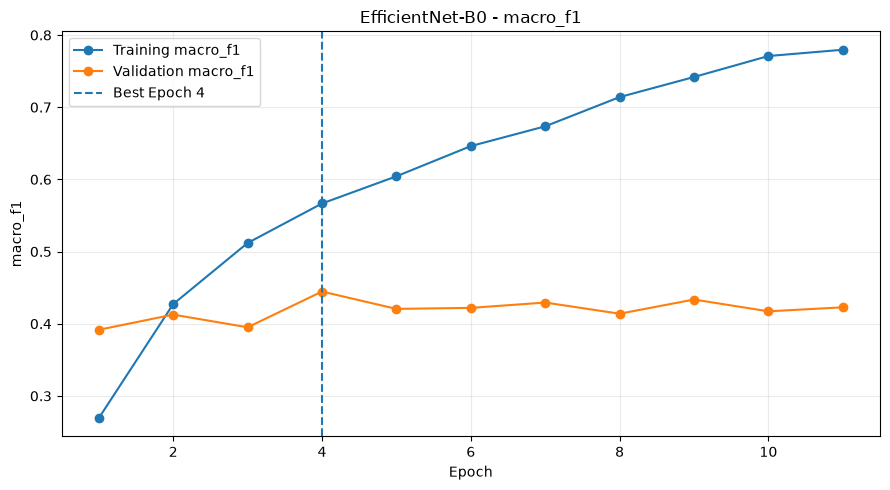

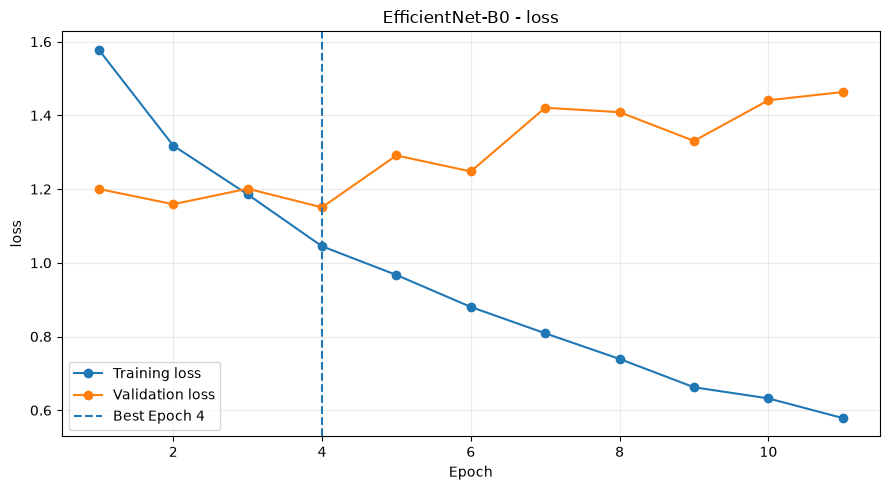

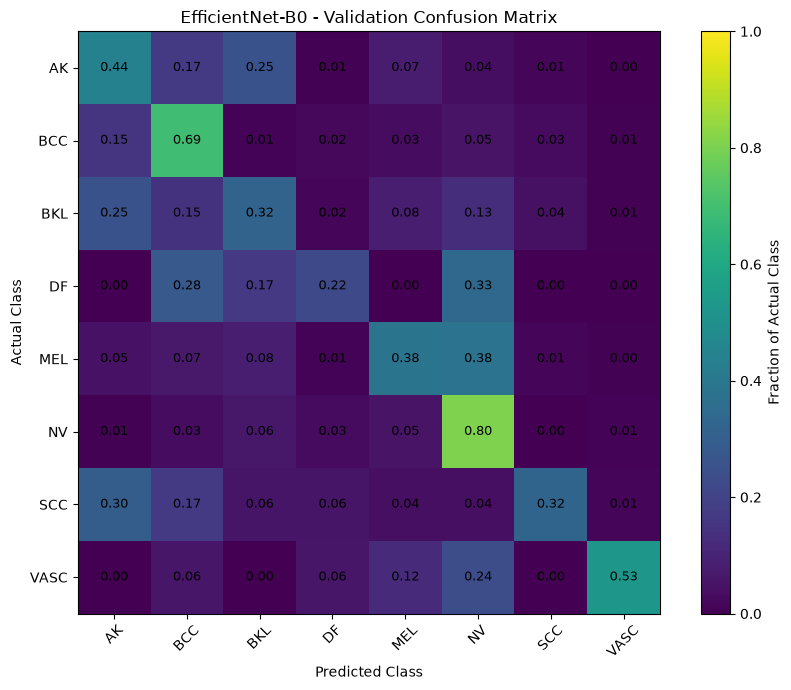

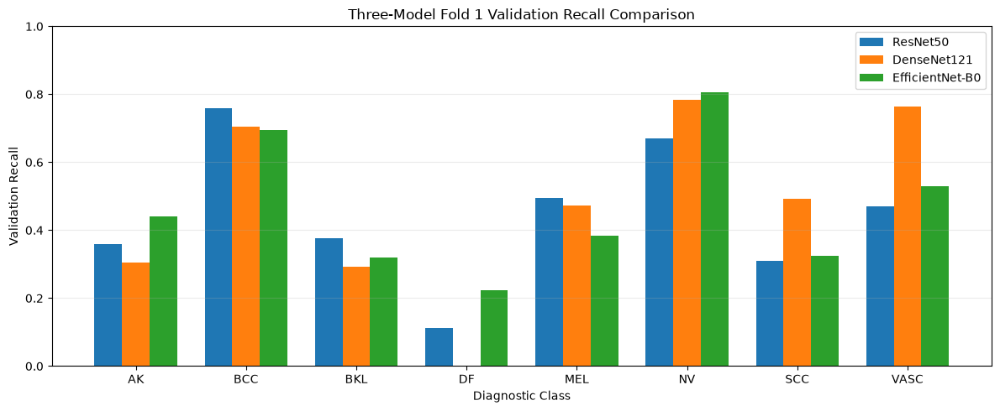

[PASS] All four figures saved

[18] FINAL CHECKPOINT INTEGRITY
[PASS] Best checkpoint preserved after reporting
[PASS] Last checkpoint preserved after reporting

EFFICIENTNET-B0 BEST CHECKPOINT AUDIT VERIFICATION
[PASS] EfficientNet config exists
[PASS] EfficientNet training report exists
[PASS] EfficientNet setup exists
[PASS] EfficientNet best checkpoint exists
[PASS] EfficientNet last checkpoint exists
[PASS] ResNet50 audit exists
[PASS] DenseNet121 audit exists
[PASS] ResNet50 predictions exists
[PASS] DenseNet121 predictions exists
[PASS] Training manifest exists
[PASS] Validation manifest exists
[PASS] Configuration fingerprint valid
[PASS] Experiment ID matches
[PASS] EfficientNet full training PASS
[PASS] EfficientNet setup PASS
[PASS] ResNet50 audit PASS
[PASS] DenseNet121 audit PASS
[PASS] Best epoch = 4
[PASS] Completed epochs = 11
[PASS] Early stopping triggered
[PASS] Outer-test protected
[PASS] Correct model, branch and fold
[PASS] Eight-class ordering correct
[PASS] Trai

In [115]:

# ============================================================
# BCN20000 - PHASE 05B - CELL 4
# EFFICIENTNET-B0 BEST CHECKPOINT AUDIT
# THREE-MODEL VALIDATION COMPARISON
# ============================================================

import os
import gc
import json
import time
import math
import hashlib

from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision.models import efficientnet_b0
from tqdm.auto import tqdm
from IPython.display import display


print("=" * 78)
print("PHASE 05B - CELL 4")
print("EFFICIENTNET-B0 BEST CHECKPOINT AUDIT")
print("=" * 78)


# ============================================================
# 1. PATHS AND HELPERS
# ============================================================

E4_OUT = Path.cwd() / "outputs"

E4_ID = (
    "efficientnet_b0_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

E4_R_ID = (
    "resnet50_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

E4_D_ID = (
    "densenet121_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

E4_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

E4_CONFIG = (
    E4_OUT / "configs/full_training" /
    f"{E4_ID}.json"
)

E4_REPORT = (
    E4_OUT / "reports" /
    f"{E4_ID}_training_report.json"
)

E4_SETUP = (
    E4_OUT / "reports" /
    "efficientnet_b0_original_fold01_"
    "full_training_setup_verification.json"
)

E4_CHECKPOINT_DIR = (
    E4_OUT / "checkpoints/full_training/"
    "efficientnet_b0/original/fold_01/sqrt_weighted_ce"
)

E4_BEST = E4_CHECKPOINT_DIR / "best_checkpoint.pt"
E4_LAST = E4_CHECKPOINT_DIR / "last_checkpoint.pt"

E4_R_AUDIT = (
    E4_OUT / "reports" /
    f"{E4_R_ID}_best_checkpoint_audit.json"
)

E4_D_AUDIT = (
    E4_OUT / "reports" /
    f"{E4_D_ID}_best_checkpoint_audit.json"
)

E4_R_PRED = (
    E4_OUT / "predictions/full_training" /
    f"{E4_R_ID}_validation_predictions.csv"
)

E4_D_PRED = (
    E4_OUT / "predictions/full_training" /
    f"{E4_D_ID}_validation_predictions.csv"
)

E4_TRAIN_MANIFEST = (
    E4_OUT / "splits/original_branch/fold_01_train.csv"
)

E4_VAL_MANIFEST = (
    E4_OUT / "splits/original_branch/fold_01_validation.csv"
)

E4_PRED_OUT = (
    E4_OUT / "predictions/full_training" /
    f"{E4_ID}_validation_predictions.csv"
)

E4_CLASS_OUT = (
    E4_OUT / "reports" /
    f"{E4_ID}_per_class_metrics.csv"
)

E4_COMPARE_OUT = (
    E4_OUT / "reports" /
    "three_model_original_fold01_validation_comparison.csv"
)

E4_CLASS_COMPARE_OUT = (
    E4_OUT / "reports" /
    "three_model_original_fold01_class_comparison.csv"
)

E4_AUDIT_OUT = (
    E4_OUT / "reports" /
    f"{E4_ID}_best_checkpoint_audit.json"
)

E4_FIG_DIR = E4_OUT / "figures"

E4_CHECKS = {}
E4_FIGURES = []

E4_DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)


def e4_check(name, condition):
    E4_CHECKS[name] = bool(condition)

    print(
        f"[{'PASS' if condition else 'FAIL'}] {name}"
    )


def e4_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def e4_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def e4_signature(config):
    unsigned = {
        k: v for k, v in config.items()
        if k != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


def e4_verify_or_stop():
    failed = [
        name for name, passed in E4_CHECKS.items()
        if not passed
    ]

    if failed:
        raise RuntimeError(
            "Audit verification blocked:\n"
            + "\n".join(failed)
        )


def e4_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.int64)
    y_pred = np.asarray(y_pred, dtype=np.int64)

    if (
        y_true.shape != y_pred.shape
        or len(y_true) == 0
        or not np.all((y_true >= 0) & (y_true < 8))
        or not np.all((y_pred >= 0) & (y_pred < 8))
    ):
        raise ValueError("Invalid prediction inputs.")

    cm = np.zeros((8, 8), dtype=np.int64)

    np.add.at(cm, (y_true, y_pred), 1)

    tp = cm.diagonal().astype(float)
    support = cm.sum(axis=1).astype(float)
    predicted = cm.sum(axis=0).astype(float)

    precision = np.divide(
        tp, predicted,
        out=np.zeros(8),
        where=predicted > 0
    )

    recall = np.divide(
        tp, support,
        out=np.zeros(8),
        where=support > 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(8),
        where=(precision + recall) > 0
    )

    n = len(y_true)

    return {
        "accuracy": float(tp.sum() / n),
        "macro_f1": float(f1.mean()),
        "weighted_f1": float(
            np.dot(f1, support) / n
        ),
        "balanced_accuracy": float(
            recall[support > 0].mean()
        ),
        "confusion_matrix": cm.tolist(),
        "precision": precision.tolist(),
        "recall": recall.tolist(),
        "f1": f1.tolist(),
        "support": support.astype(int).tolist(),
        "predicted_count": predicted.astype(int).tolist()
    }


def e4_atomic_csv(frame, path):
    path.parent.mkdir(parents=True, exist_ok=True)

    temporary = path.with_name(
        path.name + ".temporary"
    )

    frame.to_csv(temporary, index=False)
    os.replace(temporary, path)


def e4_atomic_json(data, path):
    path.parent.mkdir(parents=True, exist_ok=True)

    temporary = path.with_name(
        path.name + ".temporary"
    )

    with open(
        temporary, "w", encoding="utf-8"
    ) as f:
        json.dump(
            data,
            f,
            indent=4,
            ensure_ascii=False,
            allow_nan=False
        )

    os.replace(temporary, path)


# ============================================================
# 2. REQUIRED ARTIFACTS
# ============================================================

print("\n[1] REQUIRED ARTIFACT VERIFICATION")

required = {
    "EfficientNet config": E4_CONFIG,
    "EfficientNet training report": E4_REPORT,
    "EfficientNet setup": E4_SETUP,
    "EfficientNet best checkpoint": E4_BEST,
    "EfficientNet last checkpoint": E4_LAST,
    "ResNet50 audit": E4_R_AUDIT,
    "DenseNet121 audit": E4_D_AUDIT,
    "ResNet50 predictions": E4_R_PRED,
    "DenseNet121 predictions": E4_D_PRED,
    "Training manifest": E4_TRAIN_MANIFEST,
    "Validation manifest": E4_VAL_MANIFEST
}

for name, path in required.items():
    e4_check(
        f"{name} exists",
        path.is_file()
    )

e4_verify_or_stop()

config = e4_json(E4_CONFIG)
training = e4_json(E4_REPORT)
setup = e4_json(E4_SETUP)
r_audit = e4_json(E4_R_AUDIT)
d_audit = e4_json(E4_D_AUDIT)

signature = e4_signature(config)

protected_hashes = {
    "EfficientNet best": e4_hash(E4_BEST),
    "EfficientNet last": e4_hash(E4_LAST)
}


# ============================================================
# 3. TRAINING AND CONFIGURATION VALIDATION
# ============================================================

print("\n[2] TRAINING REPORT VERIFICATION")

e4_check(
    "Configuration fingerprint valid",
    signature == config.get("config_signature")
)

e4_check(
    "Experiment ID matches",
    config.get("experiment_id") == E4_ID
    and training.get("experiment_id") == E4_ID
)

e4_check(
    "EfficientNet full training PASS",
    training.get("status") == "PASS"
)

e4_check(
    "EfficientNet setup PASS",
    setup.get("status") == "PASS"
)

e4_check(
    "ResNet50 audit PASS",
    r_audit.get("status") == "PASS"
)

e4_check(
    "DenseNet121 audit PASS",
    d_audit.get("status") == "PASS"
)

e4_check(
    "Best epoch = 4",
    training.get("best_epoch") == 4
)

e4_check(
    "Completed epochs = 11",
    training.get("completed_epochs") == 11
)

e4_check(
    "Early stopping triggered",
    training.get("early_stopped") is True
    and training.get("early_stopping_wait") == 7
)

e4_check(
    "Outer-test protected",
    training.get("outer_test_evaluated") is False
    and config.get("outer_test_for_tuning") is False
)

e4_check(
    "Correct model, branch and fold",
    config.get("model") == "efficientnet_b0"
    and config.get("branch") == "original"
    and config.get("fold") == 1
)

e4_check(
    "Eight-class ordering correct",
    config.get("class_names") == E4_CLASSES
)

history = training.get("history", [])

e4_check(
    "Training history complete",
    len(history) == 11
    and [
        int(row["epoch"]) for row in history
    ] == list(range(1, 12))
)

e4_verify_or_stop()

best_row = history[3]

e4_check(
    "Best logged Macro-F1 matches report",
    math.isclose(
        float(best_row["validation_macro_f1"]),
        float(training["best_validation_macro_f1"]),
        rel_tol=0,
        abs_tol=1e-12
    )
)

e4_check(
    "All completed epochs evaluated full validation",
    all(
        int(row["validation_samples"]) == 1973
        and int(row["train_samples"]) == 7813
        for row in history
    )
)

e4_verify_or_stop()

print("Training epochs: 11")
print("Best epoch: 4")
print(
    "Logged best validation Macro-F1:",
    training["best_validation_macro_f1"]
)


# ============================================================
# 4. CHECKPOINT INTEGRITY
# ============================================================

print("\n[3] CHECKPOINT INTEGRITY")

best_state = torch.load(
    E4_BEST,
    map_location="cpu",
    weights_only=True
)

last_state = torch.load(
    E4_LAST,
    map_location="cpu",
    weights_only=True
)

e4_check(
    "Best checkpoint = Epoch 4",
    best_state.get("completed_epoch") == 4
)

e4_check(
    "Last checkpoint = Epoch 11",
    last_state.get("completed_epoch") == 11
)

e4_check(
    "Checkpoint types correct",
    best_state.get("checkpoint_kind")
    == "full_training_best"
    and last_state.get("checkpoint_kind")
    == "full_training_last"
)

e4_check(
    "Checkpoint experiment IDs correct",
    best_state.get("experiment_id") == E4_ID
    and last_state.get("experiment_id") == E4_ID
)

e4_check(
    "Checkpoint configuration signatures correct",
    best_state.get("configuration_signature") == signature
    and last_state.get("configuration_signature") == signature
)

e4_check(
    "Best checkpoint history length = 4",
    len(best_state.get("history", [])) == 4
)

e4_check(
    "Last checkpoint history length = 11",
    len(last_state.get("history", [])) == 11
)

e4_check(
    "Classifier output shape correct",
    tuple(
        best_state["model_state_dict"][
            "classifier.1.weight"
        ].shape
    ) == (8, 1280)
)

e4_verify_or_stop()

del last_state

print("Best checkpoint integrity: VERIFIED")
print("Last checkpoint integrity: VERIFIED")


# ============================================================
# 5. VALIDATION DATASET INTEGRITY
# ============================================================

print("\n[4] DATASET VERIFICATION")

if not callable(globals().get("create_bcn_dataset")):
    raise RuntimeError(
        "create_bcn_dataset is unavailable."
    )

train_manifest = pd.read_csv(
    E4_TRAIN_MANIFEST,
    usecols=[
        "bcn_filename",
        "diagnosis",
        "leakage_group_id"
    ],
    dtype="string"
)

val_manifest = pd.read_csv(
    E4_VAL_MANIFEST,
    usecols=[
        "bcn_filename",
        "diagnosis",
        "leakage_group_id"
    ],
    dtype="string"
)

dataset = create_bcn_dataset(
    "original", 1, "validation"
)

loader = DataLoader(
    dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(E4_DEVICE.type == "cuda"),
    drop_last=False
)

e4_check(
    "Validation images = 1973",
    len(dataset) == 1973
    and len(val_manifest) == 1973
)

e4_check(
    "Validation batches = 494",
    len(loader) == 494
)

e4_check(
    "Validation leakage groups = 571",
    val_manifest["leakage_group_id"].nunique() == 571
)

e4_check(
    "Training-validation groups disjoint",
    set(train_manifest["leakage_group_id"])
    .isdisjoint(
        set(val_manifest["leakage_group_id"])
    )
)

e4_check(
    "Validation filenames unique",
    val_manifest["bcn_filename"].is_unique
)

e4_verify_or_stop()


# ============================================================
# 6. LOAD BEST MODEL
# ============================================================

print("\n[5] LOADING EPOCH 4 BEST MODEL")

model = efficientnet_b0(weights=None)

if (
    model.classifier[1].in_features != 1280
    or not math.isclose(
        model.classifier[0].p,
        0.2,
        abs_tol=1e-12
    )
):
    raise RuntimeError(
        "EfficientNet classifier structure mismatch."
    )

model.classifier[1] = nn.Linear(1280, 8)

model.load_state_dict(
    best_state["model_state_dict"],
    strict=True
)

del best_state

model = model.to(E4_DEVICE)
model.eval()

e4_check(
    "Model loaded in evaluation mode",
    not model.training
)

print("Model: EfficientNet-B0")
print("Checkpoint: Epoch 4")
print("Training: DISABLED")


# ============================================================
# 7. INDEPENDENT VALIDATION INFERENCE
# ============================================================

print("\n[6] INDEPENDENT VALIDATION INFERENCE")

all_true = []
all_pred = []
all_names = []
all_groups = []
all_probs = []

loss_sum = 0.0
sample_count = 0

amp_enabled = (
    E4_DEVICE.type == "cuda"
    and config.get("mixed_precision") is True
)

start = time.perf_counter()

with torch.inference_mode():

    for batch in tqdm(
        loader,
        desc="EfficientNet Epoch 4 Audit"
    ):

        images = batch["image"].to(
            E4_DEVICE,
            non_blocking=True
        )

        labels = batch["label"].to(
            E4_DEVICE,
            non_blocking=True
        )

        with torch.autocast(
            device_type=E4_DEVICE.type,
            dtype=torch.float16,
            enabled=amp_enabled
        ):
            logits = model(images)

        logits_fp32 = logits.float()

        loss = F.cross_entropy(
            logits_fp32,
            labels,
            reduction="mean"
        )

        if not bool(
            torch.isfinite(logits_fp32).all().item()
            and torch.isfinite(loss).item()
        ):
            raise FloatingPointError(
                "Non-finite validation output."
            )

        probabilities = torch.softmax(
            logits_fp32,
            dim=1
        )

        predictions = logits.argmax(dim=1)

        n = int(labels.size(0))

        loss_sum += float(loss.item()) * n
        sample_count += n

        all_true.extend(labels.cpu().tolist())
        all_pred.extend(predictions.cpu().tolist())

        all_names.extend(
            list(batch["filename"])
        )

        all_groups.extend(
            str(x)
            for x in batch["leakage_group_id"]
        )

        all_probs.append(
            probabilities.cpu().numpy()
        )

elapsed = time.perf_counter() - start

all_true = np.asarray(
    all_true,
    dtype=np.int64
)

all_pred = np.asarray(
    all_pred,
    dtype=np.int64
)

prob_matrix = np.concatenate(
    all_probs,
    axis=0
)

e4_check(
    "1973 predictions generated",
    sample_count == 1973
    and len(all_true) == 1973
    and len(all_pred) == 1973
)

e4_check(
    "Probabilities finite",
    bool(np.isfinite(prob_matrix).all())
)

e4_check(
    "Probabilities normalized",
    bool(np.allclose(
        prob_matrix.sum(axis=1),
        1,
        atol=1e-5
    ))
)

e4_check(
    "Predictions match probability argmax",
    bool(np.array_equal(
        all_pred,
        prob_matrix.argmax(axis=1)
    ))
)

e4_verify_or_stop()

print("Images evaluated:", sample_count)
print("Inference seconds:", round(elapsed, 2))


# ============================================================
# 8. INDEPENDENT METRIC RECONSTRUCTION
# ============================================================

print("\n[7] RECOMPUTED VALIDATION METRICS")

metrics = e4_metrics(
    all_true,
    all_pred
)

metrics["loss"] = float(
    loss_sum / sample_count
)

metric_mapping = {
    "accuracy": "validation_accuracy",
    "macro_f1": "validation_macro_f1",
    "weighted_f1": "validation_weighted_f1",
    "balanced_accuracy": "validation_balanced_accuracy",
    "loss": "validation_loss"
}

for metric, history_key in metric_mapping.items():

    logged = float(
        best_row[history_key]
    )

    reproduced = float(
        metrics[metric]
    )

    difference = abs(logged - reproduced)

    tolerance = (
        1e-4 if metric == "loss"
        else 1e-5
    )

    e4_check(
        f"Reproduced {metric}",
        difference <= tolerance
    )

    print(
        f"{metric:19s} | "
        f"Logged: {logged:.6f} | "
        f"Recomputed: {reproduced:.6f} | "
        f"Difference: {difference:.9f}"
    )

cm = np.asarray(
    metrics["confusion_matrix"],
    dtype=np.int64
)

e4_check(
    "Confusion matrix matches Epoch 4",
    np.array_equal(
        cm,
        np.asarray(
            best_row["validation_confusion_matrix"]
        )
    )
)

e4_check(
    "Confusion matrix totals 1973",
    int(cm.sum()) == 1973
)

e4_verify_or_stop()


# ============================================================
# 9. METADATA VALIDATION
# ============================================================

print("\n[8] PREDICTION METADATA VERIFICATION")

pred_df = pd.DataFrame({
    "filename": all_names,
    "leakage_group_id": all_groups,
    "actual_idx": all_true,
    "predicted_idx": all_pred,
    "actual_class": [
        E4_CLASSES[i] for i in all_true
    ],
    "predicted_class": [
        E4_CLASSES[i] for i in all_pred
    ],
    "confidence": prob_matrix.max(axis=1)
})

prob_columns = []

for i, name in enumerate(E4_CLASSES):
    column = f"prob_{name}"

    pred_df[column] = prob_matrix[:, i]
    prob_columns.append(column)

reference = val_manifest.rename(
    columns={
        "bcn_filename": "filename",
        "diagnosis": "manifest_diagnosis",
        "leakage_group_id": "manifest_group"
    }
)

aligned = pred_df.merge(
    reference,
    on="filename",
    how="left",
    validate="one_to_one",
    indicator=True
)

e4_check(
    "All filenames match manifest",
    len(aligned) == 1973
    and bool(
        aligned["_merge"].eq("both").all()
    )
)

e4_check(
    "True labels match manifest",
    bool((
        aligned["actual_class"].astype(str)
        == aligned["manifest_diagnosis"].astype(str)
    ).all())
)

e4_check(
    "Leakage groups match manifest",
    bool((
        aligned["leakage_group_id"].astype(str)
        == aligned["manifest_group"].astype(str)
    ).all())
)

e4_verify_or_stop()


# ============================================================
# 10. PER-CLASS PERFORMANCE
# ============================================================

print("\n[9] EFFICIENTNET-B0 CLASS-WISE PERFORMANCE")

top3 = np.argsort(
    -prob_matrix,
    axis=1
)[:, :3]

class_rows = []

for i, name in enumerate(E4_CLASSES):

    mask = all_true == i
    support = int(mask.sum())

    top3_acc = float(
        np.any(
            top3[mask] == i,
            axis=1
        ).mean()
    ) if support else 0.0

    class_rows.append({
        "class": name,
        "validation_support": support,
        "predicted_count": int(
            metrics["predicted_count"][i]
        ),
        "precision": float(
            metrics["precision"][i]
        ),
        "recall": float(
            metrics["recall"][i]
        ),
        "f1": float(
            metrics["f1"][i]
        ),
        "top3_accuracy": top3_acc
    })

class_df = pd.DataFrame(
    class_rows
)

display(class_df.round(6))

e4_check(
    "All eight classes evaluated",
    len(class_df) == 8
)

e4_check(
    "Supports sum to 1973",
    class_df["validation_support"].sum() == 1973
)

zero_recall = class_df.loc[
    class_df["recall"] == 0,
    "class"
].tolist()

print("\nZero-recall classes:", zero_recall)

print("\nPriority-class recall:")

for name in ["DF", "VASC", "SCC", "MEL"]:

    row = class_df.set_index("class").loc[name]

    correct = int(round(
        row["recall"]
        * row["validation_support"]
    ))

    print(
        f"{name}: {row['recall']:.6f} "
        f"({correct}/{int(row['validation_support'])})"
    )


# ============================================================
# 11. GROUP-LEVEL EXPLORATORY EVALUATION
# ============================================================

print("\n[10] GROUP-LEVEL EXPLORATORY EVALUATION")

group_label_count = pred_df.groupby(
    "leakage_group_id"
)["actual_idx"].nunique()

e4_check(
    "Each leakage group has one true class",
    bool((group_label_count == 1).all())
)

e4_verify_or_stop()

group_prob = pred_df.groupby(
    "leakage_group_id"
)[prob_columns].mean()

group_true = pred_df.groupby(
    "leakage_group_id"
)["actual_idx"].first()

group_pred = group_prob.to_numpy().argmax(
    axis=1
)

group_metrics = e4_metrics(
    group_true.to_numpy(dtype=np.int64),
    group_pred
)

e4_check(
    "571 groups evaluated",
    len(group_true) == 571
)

print("Validation groups:", len(group_true))

print(
    "Exploratory group Macro-F1:",
    round(group_metrics["macro_f1"], 6)
)


# ============================================================
# 12. TOP CLASSIFICATION ERRORS
# ============================================================

print("\n[11] TOP MISCLASSIFICATIONS")

error_rows = []

for actual in range(8):
    for predicted in range(8):

        if actual == predicted:
            continue

        count = int(
            cm[actual, predicted]
        )

        if count > 0:

            error_rows.append({
                "actual_class": E4_CLASSES[actual],
                "predicted_class": E4_CLASSES[predicted],
                "error_count": count
            })

error_df = pd.DataFrame(
    error_rows,
    columns=[
        "actual_class",
        "predicted_class",
        "error_count"
    ]
).sort_values(
    "error_count",
    ascending=False
)

display(error_df.head(12))


# ============================================================
# 13. THREE-MODEL METRIC COMPARISON
# ============================================================

print("\n[12] THREE-MODEL VALIDATION COMPARISON")

r_metrics = r_audit["validation_metrics"]
d_metrics = d_audit["validation_metrics"]

compare_rows = []

for name in [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy",
    "loss"
]:

    compare_rows.append({
        "metric": name,
        "resnet50_weighted": float(
            r_metrics[name]
        ),
        "densenet121_weighted": float(
            d_metrics[name]
        ),
        "efficientnet_b0_weighted": float(
            metrics[name]
        )
    })

compare_df = pd.DataFrame(
    compare_rows
)

display(compare_df.round(6))


# ============================================================
# 14. THREE-MODEL CLASS-WISE COMPARISON
# ============================================================

print("\n[13] CLASS-WISE THREE-MODEL COMPARISON")

r_classes = {
    x["class"]: x
    for x in r_audit["per_class_metrics"]
}

d_classes = {
    x["class"]: x
    for x in d_audit["per_class_metrics"]
}

e_classes = {
    x["class"]: x
    for x in class_rows
}

class_compare_rows = []

for name in E4_CLASSES:

    r = r_classes[name]
    d = d_classes[name]
    e = e_classes[name]

    class_compare_rows.append({
        "class": name,
        "support": int(
            e["validation_support"]
        ),
        "resnet50_recall": float(
            r["recall"]
        ),
        "densenet121_recall": float(
            d["recall"]
        ),
        "efficientnet_b0_recall": float(
            e["recall"]
        ),
        "resnet50_f1": float(
            r["f1"]
        ),
        "densenet121_f1": float(
            d["f1"]
        ),
        "efficientnet_b0_f1": float(
            e["f1"]
        )
    })

class_compare_df = pd.DataFrame(
    class_compare_rows
)

display(class_compare_df.round(6))

e4_check(
    "Eight classes compared across models",
    len(class_compare_df) == 8
)

e4_check(
    "Validation support preserved across models",
    all(
        int(r_classes[name]["validation_support"])
        == int(d_classes[name]["validation_support"])
        == int(e_classes[name]["validation_support"])
        for name in E4_CLASSES
    )
)


# ============================================================
# 15. THREE-MODEL PAIRED PREDICTION ANALYSIS
# ============================================================

print("\n[14] PAIRED PREDICTION COMPARISON")

usecols = [
    "filename",
    "actual_idx",
    "predicted_idx",
    "leakage_group_id"
]

dtype = {
    "filename": "string",
    "leakage_group_id": "string"
}

r_pred_df = pd.read_csv(
    E4_R_PRED,
    usecols=usecols,
    dtype=dtype
)

d_pred_df = pd.read_csv(
    E4_D_PRED,
    usecols=usecols,
    dtype=dtype
)

def e4_named(frame, suffix):

    return frame[usecols].rename(
        columns={
            "actual_idx": f"actual_{suffix}",
            "predicted_idx": f"pred_{suffix}",
            "leakage_group_id": f"group_{suffix}"
        }
    )


paired = (
    e4_named(pred_df, "efficient")
    .merge(
        e4_named(r_pred_df, "resnet"),
        on="filename",
        validate="one_to_one",
        how="inner"
    )
    .merge(
        e4_named(d_pred_df, "dense"),
        on="filename",
        validate="one_to_one",
        how="inner"
    )
)

e4_check(
    "All three models evaluated same 1973 images",
    len(paired) == 1973
    and len(pred_df) == 1973
    and len(r_pred_df) == 1973
    and len(d_pred_df) == 1973
)

e4_check(
    "Ground-truth labels identical across models",
    bool((
        (paired["actual_efficient"]
         == paired["actual_resnet"])
        &
        (paired["actual_efficient"]
         == paired["actual_dense"])
    ).all())
)

e4_check(
    "Leakage groups identical across models",
    bool((
        (paired["group_efficient"]
         == paired["group_resnet"])
        &
        (paired["group_efficient"]
         == paired["group_dense"])
    ).all())
)

e4_verify_or_stop()

correct_e = (
    paired["pred_efficient"]
    == paired["actual_efficient"]
).to_numpy()

correct_r = (
    paired["pred_resnet"]
    == paired["actual_resnet"]
).to_numpy()

correct_d = (
    paired["pred_dense"]
    == paired["actual_dense"]
).to_numpy()

paired_counts = {
    "all_three_correct": int(
        (correct_e & correct_r & correct_d).sum()
    ),
    "all_three_wrong": int(
        (~correct_e & ~correct_r & ~correct_d).sum()
    ),
    "efficient_only_correct": int(
        (correct_e & ~correct_r & ~correct_d).sum()
    ),
    "resnet_only_correct": int(
        (~correct_e & correct_r & ~correct_d).sum()
    ),
    "dense_only_correct": int(
        (~correct_e & ~correct_r & correct_d).sum()
    ),
    "efficient_and_resnet_only": int(
        (correct_e & correct_r & ~correct_d).sum()
    ),
    "efficient_and_dense_only": int(
        (correct_e & ~correct_r & correct_d).sum()
    ),
    "resnet_and_dense_only": int(
        (~correct_e & correct_r & correct_d).sum()
    )
}

e4_check(
    "Paired correctness counts sum to 1973",
    sum(paired_counts.values()) == 1973
)

for name, count in paired_counts.items():
    print(f"{name}: {count}")


# ============================================================
# 16. FINAL CHECKS BEFORE SAVING
# ============================================================

print("\n[15] CHECKPOINT SAFETY")

e4_check(
    "EfficientNet best checkpoint unchanged",
    e4_hash(E4_BEST)
    == protected_hashes["EfficientNet best"]
)

e4_check(
    "EfficientNet last checkpoint unchanged",
    e4_hash(E4_LAST)
    == protected_hashes["EfficientNet last"]
)

e4_verify_or_stop()


# ============================================================
# 17. SAVE CSV REPORTS
# ============================================================

print("\n[16] SAVING AUDIT REPORTS")

E4_FIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

e4_atomic_csv(
    pred_df,
    E4_PRED_OUT
)

e4_atomic_csv(
    class_df,
    E4_CLASS_OUT
)

e4_atomic_csv(
    compare_df,
    E4_COMPARE_OUT
)

e4_atomic_csv(
    class_compare_df,
    E4_CLASS_COMPARE_OUT
)

e4_check(
    "Prediction CSV saved",
    E4_PRED_OUT.is_file()
)

e4_check(
    "Per-class CSV saved",
    E4_CLASS_OUT.is_file()
)

e4_check(
    "Three-model comparison CSV saved",
    E4_COMPARE_OUT.is_file()
)

e4_check(
    "Class-wise comparison CSV saved",
    E4_CLASS_COMPARE_OUT.is_file()
)


# ============================================================
# 18. FIGURE: TRAINING CURVES
# ============================================================

print("\n[17] GENERATING FIGURES")

history_df = pd.DataFrame(history)

for metric, filename in [
    (
        "macro_f1",
        "efficientnet_b0_fold01_macro_f1.png"
    ),
    (
        "loss",
        "efficientnet_b0_fold01_loss.png"
    )
]:

    figure_path = E4_FIG_DIR / filename

    plt.figure(figsize=(9, 5))

    plt.plot(
        history_df["epoch"],
        history_df[f"train_{metric}"],
        marker="o",
        label=f"Training {metric}"
    )

    plt.plot(
        history_df["epoch"],
        history_df[f"validation_{metric}"],
        marker="o",
        label=f"Validation {metric}"
    )

    plt.axvline(
        4,
        linestyle="--",
        label="Best Epoch 4"
    )

    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.title(f"EfficientNet-B0 - {metric}")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    E4_FIGURES.append(str(figure_path))


# ============================================================
# 19. FIGURE: CONFUSION MATRIX
# ============================================================

confusion_path = (
    E4_FIG_DIR /
    "efficientnet_b0_fold01_confusion_matrix.png"
)

row_totals = cm.sum(
    axis=1,
    keepdims=True
)

normalized_cm = np.divide(
    cm,
    row_totals,
    out=np.zeros((8, 8), dtype=float),
    where=row_totals > 0
)

plt.figure(figsize=(9, 7))

plt.imshow(
    normalized_cm,
    vmin=0,
    vmax=1
)

plt.colorbar(
    label="Fraction of Actual Class"
)

plt.xticks(
    range(8),
    E4_CLASSES,
    rotation=45
)

plt.yticks(
    range(8),
    E4_CLASSES
)

for i in range(8):
    for j in range(8):

        plt.text(
            j, i,
            f"{normalized_cm[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("EfficientNet-B0 - Validation Confusion Matrix")

plt.tight_layout()
plt.savefig(
    confusion_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

E4_FIGURES.append(str(confusion_path))


# ============================================================
# 20. FIGURE: THREE-MODEL RECALL COMPARISON
# ============================================================

recall_path = (
    E4_FIG_DIR /
    "three_model_fold01_class_recall_comparison.png"
)

x = np.arange(8)
width = 0.25

plt.figure(figsize=(12, 5))

plt.bar(
    x - width,
    class_compare_df["resnet50_recall"],
    width,
    label="ResNet50"
)

plt.bar(
    x,
    class_compare_df["densenet121_recall"],
    width,
    label="DenseNet121"
)

plt.bar(
    x + width,
    class_compare_df["efficientnet_b0_recall"],
    width,
    label="EfficientNet-B0"
)

plt.xticks(x, E4_CLASSES)
plt.ylim(0, 1)

plt.xlabel("Diagnostic Class")
plt.ylabel("Validation Recall")

plt.title(
    "Three-Model Fold 1 Validation Recall Comparison"
)

plt.legend()
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    recall_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

E4_FIGURES.append(str(recall_path))

e4_check(
    "All four figures saved",
    len(E4_FIGURES) == 4
    and all(
        Path(p).is_file()
        for p in E4_FIGURES
    )
)


# ============================================================
# 21. FINAL INTEGRITY CHECK
# ============================================================

print("\n[18] FINAL CHECKPOINT INTEGRITY")

e4_check(
    "Best checkpoint preserved after reporting",
    e4_hash(E4_BEST)
    == protected_hashes["EfficientNet best"]
)

e4_check(
    "Last checkpoint preserved after reporting",
    e4_hash(E4_LAST)
    == protected_hashes["EfficientNet last"]
)


# ============================================================
# 22. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("EFFICIENTNET-B0 BEST CHECKPOINT AUDIT VERIFICATION")
print("=" * 78)

for name, passed in E4_CHECKS.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

E4_STATUS = (
    "PASS"
    if E4_CHECKS and all(E4_CHECKS.values())
    else "BLOCKED"
)


# ============================================================
# 23. SAVE FINAL AUDIT REPORT
# ============================================================

audit_report = {
    "stage": "EFFICIENTNET_B0_BEST_CHECKPOINT_AUDIT",

    "status": E4_STATUS,

    "experiment_id": E4_ID,

    "model": "efficientnet_b0",

    "branch": "original",

    "fold": 1,

    "completed_training_epochs": 11,

    "best_epoch": 4,

    "evaluation_partition": "validation",

    "validation_metrics": metrics,

    "per_class_metrics": class_rows,

    "group_metrics": group_metrics,

    "zero_recall_classes": zero_recall,

    "top_misclassifications": (
        error_df.head(12).to_dict(
            orient="records"
        )
    ),

    "three_model_comparison": compare_rows,

    "three_model_class_comparison": (
        class_compare_rows
    ),

    "paired_prediction_counts": paired_counts,

    "best_checkpoint_sha256": (
        protected_hashes["EfficientNet best"]
    ),

    "last_checkpoint_sha256": (
        protected_hashes["EfficientNet last"]
    ),

    "prediction_csv": str(E4_PRED_OUT),

    "per_class_csv": str(E4_CLASS_OUT),

    "comparison_csv": str(E4_COMPARE_OUT),

    "class_comparison_csv": str(
        E4_CLASS_COMPARE_OUT
    ),

    "figures": E4_FIGURES,

    "training_performed": False,

    "outer_test_evaluated": False,

    "checks": {
        k: bool(v)
        for k, v in E4_CHECKS.items()
    }
}

e4_atomic_json(
    audit_report,
    E4_AUDIT_OUT
)


# ============================================================
# 24. GPU CLEANUP
# ============================================================

del model
gc.collect()

if E4_DEVICE.type == "cuda":
    torch.cuda.empty_cache()


# ============================================================
# 25. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("EFFICIENTNET-B0 BEST CHECKPOINT AUDIT SUMMARY")
print("=" * 78)

print("Status:", E4_STATUS)

print("Model: EfficientNet-B0")
print("Branch: original")
print("Fold: 1")

print("Training epochs: 11")
print("Best checkpoint epoch: 4")
print("Validation images:", sample_count)

print(
    "Reproduced Macro-F1:",
    round(metrics["macro_f1"], 6)
)

print(
    "Reproduced Accuracy:",
    round(metrics["accuracy"], 6)
)

print(
    "Reproduced Balanced Accuracy:",
    round(
        metrics["balanced_accuracy"],
        6
    )
)

print("\nThree-model Macro-F1:")

print(
    "ResNet50:",
    round(float(r_metrics["macro_f1"]), 6)
)

print(
    "DenseNet121:",
    round(float(d_metrics["macro_f1"]), 6)
)

print(
    "EfficientNet-B0:",
    round(float(metrics["macro_f1"]), 6)
)

print("\nZero-recall classes:", zero_recall)

print("\nSaved audit report:")
print(E4_AUDIT_OUT)

print("\nThree-model comparison:")
print(E4_COMPARE_OUT)

print("\nClass-wise comparison:")
print(E4_CLASS_COMPARE_OUT)

print("\nOuter-test evaluated: NO")
print("New training performed: NO")

if E4_STATUS == "PASS":

    print("\nEFFICIENTNET-B0 BEST CHECKPOINT AUDIT: PASS")
    print("NEXT ARCHITECTURE: CONVNEXT-TINY")

else:

    print("\nEFFICIENTNET-B0 AUDIT: BLOCKED")

print("=" * 78)


In [116]:

import json
from pathlib import Path

path = Path(
    "outputs/reports/"
    "efficientnet_b0_original_fold01_"
    "sqrt_weighted_ce_seed42_best_checkpoint_audit.json"
)

if path.is_file():
    with open(path, "r", encoding="utf-8") as f:
        report = json.load(f)

    failed = [
        k for k, v in report.get("checks", {}).items()
        if not v
    ]

    print("Audit status:", report.get("status"))
    print("Best epoch:", report.get("best_epoch"))
    print("Verification checks:", len(report.get("checks", {})))
    print("Failed checks:", failed)
    print(
        "FINAL:",
        "PASS" if report.get("status") == "PASS"
        and not failed and report.get("checks")
        else "REVIEW REQUIRED"
    )
else:
    print("AUDIT REPORT NOT FOUND")


Audit status: PASS
Best epoch: 4
Verification checks: 73
Failed checks: []
FINAL: PASS


In [117]:

# ============================================================
# BCN20000 - PHASE 05C - CELL 1
# CONVNEXT-TINY ARCHITECTURE & GPU READINESS
# ============================================================

import os
import gc
import json
import math
import random
import hashlib
import traceback

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, Subset
from torchvision.models import (
    convnext_tiny,
    ConvNeXt_Tiny_Weights
)

print("=" * 78)
print("PHASE 05C - CELL 1")
print("CONVNEXT-TINY ARCHITECTURE & GPU READINESS")
print("=" * 78)


# ============================================================
# 1. PATHS AND HELPERS
# ============================================================

CN1_OUT = Path.cwd() / "outputs"

CN1_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

CN1_SOURCE_ID = (
    "efficientnet_b0_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

CN1_SOURCE_CONFIG = (
    CN1_OUT / "configs/full_training" /
    f"{CN1_SOURCE_ID}.json"
)

CN1_SOURCE_AUDIT = (
    CN1_OUT / "reports" /
    f"{CN1_SOURCE_ID}_best_checkpoint_audit.json"
)

CN1_ENGINE_REPORT = (
    CN1_OUT / "reports" /
    "resnet50_weighted_engine_verification.json"
)

CN1_REPORT_PATH = (
    CN1_OUT / "reports" /
    "convnext_tiny_original_fold01_architecture_readiness.json"
)

CN1_CHECKPOINT_DIR = (
    CN1_OUT / "checkpoints/full_training/"
    "convnext_tiny/original/fold_01/sqrt_weighted_ce"
)

CN1_CHECKS = {}
CN1_ERRORS = []
CN1_RESULTS = {}

CN1_PROTECTED = {
    "ResNet50 A": (
        CN1_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt"
    ),
    "ResNet50 B": (
        CN1_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 best": (
        CN1_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 last": (
        CN1_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "EfficientNet-B0 best": (
        CN1_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "EfficientNet-B0 last": (
        CN1_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    )
}


def cn1_check(name, passed):
    CN1_CHECKS[name] = bool(passed)

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )


def cn1_read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def cn1_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def cn1_config_signature(config):
    unsigned = {
        key: value
        for key, value in config.items()
        if key != "config_signature"
    }

    return hashlib.sha256(
        json.dumps(
            unsigned,
            sort_keys=True,
            separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest()


def cn1_verify():
    failed = [
        name for name, passed in CN1_CHECKS.items()
        if not passed
    ]

    if failed:
        raise RuntimeError(
            "Verification failed:\n" +
            "\n".join(failed)
        )


# ============================================================
# 2. PREVIOUS PHASE VERIFICATION
# ============================================================

print("\n[1] PREVIOUS PHASE VERIFICATION")

required = {
    "EfficientNet configuration": CN1_SOURCE_CONFIG,
    "EfficientNet best-checkpoint audit": CN1_SOURCE_AUDIT,
    "Weighted training engine report": CN1_ENGINE_REPORT
}

required.update(CN1_PROTECTED)

for name, path in required.items():
    cn1_check(
        f"{name} exists",
        path.is_file()
    )

cn1_verify()

source_config = cn1_read_json(CN1_SOURCE_CONFIG)
source_audit = cn1_read_json(CN1_SOURCE_AUDIT)
engine_report = cn1_read_json(CN1_ENGINE_REPORT)

cn1_check(
    "EfficientNet audit PASS",
    source_audit.get("status") == "PASS"
)

cn1_check(
    "All EfficientNet audit checks PASS",
    bool(source_audit.get("checks"))
    and all(source_audit["checks"].values())
)

cn1_check(
    "Weighted engine PASS",
    engine_report.get("status") == "PASS"
)

cn1_check(
    "Source configuration fingerprint valid",
    cn1_config_signature(source_config)
    == source_config.get("config_signature")
)

cn1_check(
    "Correct source class ordering",
    source_config.get("class_names") == CN1_CLASSES
)

cn1_check(
    "Source uses Original branch, Fold 1",
    source_config.get("branch") == "original"
    and source_config.get("fold") == 1
)

cn1_check(
    "Outer-test remains protected",
    source_audit.get("outer_test_evaluated") is False
    and source_config.get("outer_test_for_tuning") is False
)

for function in [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch"
]:
    cn1_check(
        f"{function} available",
        callable(globals().get(function))
    )

cn1_check(
    "Correct weighted accumulation engine active",
    callable(globals().get("train_one_epoch_weighted"))
    and "window_total_weight"
    in train_one_epoch_weighted.__code__.co_varnames
)

cn1_check(
    "CUDA GPU available",
    torch.cuda.is_available()
)

cn1_verify()

protected_hashes = {
    name: cn1_hash(path)
    for name, path in CN1_PROTECTED.items()
}


# ============================================================
# 3. DATASET VERIFICATION
# ============================================================

print("\n[2] DATASET VERIFICATION")

train_ds = create_bcn_dataset(
    "original", 1, "train"
)

val_ds = create_bcn_dataset(
    "original", 1, "validation"
)

cn1_check(
    "Training images = 7813",
    len(train_ds) == 7813
)

cn1_check(
    "Validation images = 1973",
    len(val_ds) == 1973
)

train_groups = set(train_ds.leakage_group_ids)
val_groups = set(val_ds.leakage_group_ids)

cn1_check(
    "Training leakage groups = 2286",
    len(train_groups) == 2286
)

cn1_check(
    "Validation leakage groups = 571",
    len(val_groups) == 571
)

cn1_check(
    "No train-validation group overlap",
    train_groups.isdisjoint(val_groups)
)

train_labels = np.asarray(
    train_ds.labels,
    dtype=np.int64
)

class_counts = np.bincount(
    train_labels,
    minlength=8
).astype(np.float64)

cn1_check(
    "All eight classes available",
    len(class_counts) == 8
    and np.all(class_counts > 0)
)

class_weights = np.sqrt(
    class_counts.sum() / (8.0 * class_counts)
)

class_weights /= (
    np.dot(class_counts, class_weights)
    / class_counts.sum()
)

cn1_check(
    "Training-only class weights reproduced",
    np.allclose(
        class_weights,
        source_config["class_weights"],
        atol=1e-7,
        rtol=1e-7
    )
)

cn1_verify()

print("Training images:", len(train_ds))
print("Validation images:", len(val_ds))
print("Group overlap:", len(train_groups & val_groups))
print("Class weights:", class_weights.round(6))


# ============================================================
# 4. SMOKE-TEST SETTINGS
# ============================================================

print("\n[3] GPU SMOKE-TEST SETTINGS")

CN1_DEVICE = torch.device("cuda:0")

CN1_MICROBATCH = 4
CN1_ACCUMULATION = 4
CN1_EFFECTIVE_BATCH = 16

CN1_AMP_SCALE = 1024.0
CN1_AMP_GROWTH = 1000000

print("GPU:", torch.cuda.get_device_name(0))
print("Microbatch:", CN1_MICROBATCH)
print("Gradient accumulation:", CN1_ACCUMULATION)
print("Effective batch:", CN1_EFFECTIVE_BATCH)
print("AMP initial scale:", CN1_AMP_SCALE)

cn1_check(
    "Effective batch = 16",
    CN1_MICROBATCH * CN1_ACCUMULATION
    == CN1_EFFECTIVE_BATCH
)

cn1_check(
    "ConvNeXt full training not yet started",
    not any(
        path.exists()
        for path in [
            CN1_CHECKPOINT_DIR / "best_checkpoint.pt",
            CN1_CHECKPOINT_DIR / "last_checkpoint.pt"
        ]
    )
)

cn1_verify()


# ============================================================
# 5. PRETRAINED CONVNEXT-TINY
# ============================================================

model = None
optimizer = None
scaler = None
criterion = None

python_state = random.getstate()
numpy_state = np.random.get_state()

try:

    with torch.random.fork_rng(devices=[0]):

        torch.manual_seed(42)
        torch.cuda.manual_seed_all(42)

        print("\n[4] PRETRAINED CONVNEXT-TINY")

        # Official ImageNet pretrained model.
        # Do not silently fall back to random weights.

        model = convnext_tiny(
            weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1
        )

        # torchvision ConvNeXt classifier:
        # classifier[0] = LayerNorm2d
        # classifier[1] = Flatten
        # classifier[2] = Linear(768, 1000)

        cn1_check(
            "Classifier is Sequential",
            isinstance(model.classifier, nn.Sequential)
        )

        in_features = model.classifier[2].in_features

        cn1_check(
            "Classifier input features = 768",
            in_features == 768
        )

        model.classifier[2] = nn.Linear(
            in_features,
            8
        )

        cn1_check(
            "Eight-class classifier configured",
            tuple(model.classifier[2].weight.shape)
            == (8, 768)
        )

        model = model.to(CN1_DEVICE)

        total_params = sum(
            p.numel() for p in model.parameters()
        )

        trainable_params = sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )

        cn1_check(
            "All model parameters trainable",
            total_params == trainable_params
        )

        cn1_check(
            "Model parameters finite",
            all(
                bool(torch.isfinite(p).all().item())
                for p in model.parameters()
            )
        )

        print("ImageNet pretrained backbone: LOADED")
        print("Classifier:", model.classifier)
        print("Total parameters:", total_params)
        print("Trainable parameters:", trainable_params)

        # ====================================================
        # 6. WEIGHTED TRAINING SMOKE TEST
        # ====================================================

        print("\n[5] WEIGHTED TRAINING SMOKE TEST")

        train_subset = Subset(
            train_ds,
            list(range(16))
        )

        train_loader = DataLoader(
            train_subset,
            batch_size=CN1_MICROBATCH,
            shuffle=False,
            num_workers=0,
            pin_memory=True,
            drop_last=False
        )

        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=0.0001,
            weight_decay=0.0001
        )

        criterion = nn.CrossEntropyLoss(
            weight=torch.as_tensor(
                class_weights,
                dtype=torch.float32,
                device=CN1_DEVICE
            )
        )

        scaler = torch.amp.GradScaler(
            "cuda",
            enabled=True,
            init_scale=CN1_AMP_SCALE,
            growth_interval=CN1_AMP_GROWTH
        )

        torch.cuda.reset_peak_memory_stats(CN1_DEVICE)

        train_result = train_one_epoch_weighted(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            criterion=criterion,
            scaler=scaler,
            device=CN1_DEVICE,
            accumulation_steps=CN1_ACCUMULATION,
            gradient_clip_norm=1.0
        )

        cn1_check(
            "Training processed 16 images",
            int(train_result["samples"]) == 16
        )

        cn1_check(
            "Training processed four microbatches",
            int(train_result["batches"]) == 4
        )

        cn1_check(
            "One optimizer update completed",
            int(train_result["optimizer_steps"]) == 1
        )

        cn1_check(
            "No optimizer updates skipped",
            int(
                train_result["skipped_optimizer_steps"]
            ) == 0
        )

        cn1_check(
            "Training loss finite",
            math.isfinite(
                float(train_result["loss"])
            )
        )

        cn1_check(
            "AMP scale remained stable",
            float(scaler.get_scale()) == 1024.0
        )

        cn1_check(
            "Model finite after optimizer update",
            all(
                bool(torch.isfinite(p).all().item())
                for p in model.parameters()
            )
        )

        print(
            "Weighted training loss:",
            round(float(train_result["loss"]), 6)
        )

        print(
            "Optimizer steps:",
            train_result["optimizer_steps"]
        )

        # ====================================================
        # 7. VALIDATION SMOKE TEST
        # ====================================================

        print("\n[6] VALIDATION SMOKE TEST")

        val_subset = Subset(
            val_ds,
            list(range(8))
        )

        val_loader = DataLoader(
            val_subset,
            batch_size=4,
            shuffle=False,
            num_workers=0,
            pin_memory=True,
            drop_last=False
        )

        val_result = validate_one_epoch(
            model=model,
            loader=val_loader,
            criterion=nn.CrossEntropyLoss(),
            device=CN1_DEVICE
        )

        cn1_check(
            "Validation processed eight images",
            int(val_result["samples"]) == 8
        )

        cn1_check(
            "Validation processed two batches",
            int(val_result["batches"]) == 2
        )

        cn1_check(
            "Validation loss finite",
            math.isfinite(
                float(val_result["loss"])
            )
        )

        cn1_check(
            "Validation Macro-F1 finite",
            math.isfinite(
                float(val_result["macro_f1"])
            )
        )

        cm = np.asarray(
            val_result["confusion_matrix"]
        )

        cn1_check(
            "Eight-class confusion matrix valid",
            cm.shape == (8, 8)
            and int(cm.sum()) == 8
        )

        torch.cuda.synchronize(CN1_DEVICE)

        peak_mb = (
            torch.cuda.max_memory_allocated(CN1_DEVICE)
            / (1024 ** 2)
        )

        gpu_capacity_mb = (
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 2)
        )

        cn1_check(
            "Peak allocated memory within GPU capacity",
            0 < peak_mb <= gpu_capacity_mb
        )

        print(
            "Peak GPU allocated memory:",
            round(peak_mb, 2),
            "MB"
        )

        CN1_RESULTS = {
            "model": "convnext_tiny",
            "pretrained_weights": "IMAGENET1K_V1",
            "classifier_in_features": 768,
            "num_classes": 8,
            "total_parameters": int(total_params),
            "trainable_parameters": int(
                trainable_params
            ),
            "train_images_smoke": 16,
            "validation_images_smoke": 8,
            "microbatch_size": CN1_MICROBATCH,
            "gradient_accumulation_steps": CN1_ACCUMULATION,
            "nominal_effective_batch": CN1_EFFECTIVE_BATCH,
            "optimizer_steps": int(
                train_result["optimizer_steps"]
            ),
            "skipped_optimizer_steps": int(
                train_result["skipped_optimizer_steps"]
            ),
            "weighted_smoke_loss": float(
                train_result["loss"]
            ),
            "validation_smoke_loss": float(
                val_result["loss"]
            ),
            "amp_scale_end": float(
                scaler.get_scale()
            ),
            "gpu_peak_allocated_mb": float(peak_mb)
        }

except Exception:

    CN1_ERRORS.append(traceback.format_exc())

    print("\nCONVNEXT-TINY SMOKE TEST ERROR")
    print(CN1_ERRORS[-1])

finally:

    random.setstate(python_state)
    np.random.set_state(numpy_state)

    model = None
    optimizer = None
    scaler = None
    criterion = None

    gc.collect()
    torch.cuda.empty_cache()


# ============================================================
# 8. CHECKPOINT SAFETY
# ============================================================

print("\n[7] CHECKPOINT SAFETY")

for name, path in CN1_PROTECTED.items():

    cn1_check(
        f"{name} checkpoint unchanged",
        cn1_hash(path) == protected_hashes[name]
    )

cn1_check(
    "No ConvNeXt training checkpoint created",
    not (
        (CN1_CHECKPOINT_DIR / "best_checkpoint.pt").exists()
        or
        (CN1_CHECKPOINT_DIR / "last_checkpoint.pt").exists()
    )
)


# ============================================================
# 9. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("CONVNEXT-TINY ARCHITECTURE READINESS VERIFICATION")
print("=" * 78)

for name, passed in CN1_CHECKS.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

CN1_STATUS = (
    "PASS"
    if (
        CN1_CHECKS
        and all(CN1_CHECKS.values())
        and not CN1_ERRORS
        and bool(CN1_RESULTS)
    )
    else "BLOCKED"
)


# ============================================================
# 10. SAVE READINESS REPORT
# ============================================================

report = {
    "stage": "CONVNEXT_TINY_ARCHITECTURE_READINESS",
    "status": CN1_STATUS,
    "model": "convnext_tiny",
    "pretraining": "IMAGENET1K_V1",
    "branch": "original",
    "fold": 1,
    "class_names": CN1_CLASSES,
    "training_policy_candidate": (
        "sqrt_weighted_cross_entropy"
    ),
    "gpu": torch.cuda.get_device_name(0),
    "results": CN1_RESULTS,
    "checks": {
        key: bool(value)
        for key, value in CN1_CHECKS.items()
    },
    "errors": CN1_ERRORS,
    "full_training_started": False,
    "outer_test_evaluated": False,
    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

CN1_REPORT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

temp_path = CN1_REPORT_PATH.with_name(
    CN1_REPORT_PATH.name + ".temporary"
)

try:

    with open(
        temp_path,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            report,
            f,
            indent=4,
            ensure_ascii=False,
            allow_nan=False
        )

    os.replace(
        temp_path,
        CN1_REPORT_PATH
    )

finally:

    if temp_path.exists():
        temp_path.unlink()


# ============================================================
# 11. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("CONVNEXT-TINY READINESS SUMMARY")
print("=" * 78)

print("Status:", CN1_STATUS)
print("Model: ConvNeXt-Tiny")
print("Branch: original")
print("Fold: 1")

if CN1_RESULTS:

    print(
        "Total parameters:",
        CN1_RESULTS["total_parameters"]
    )

    print(
        "Peak GPU allocated MB:",
        round(
            CN1_RESULTS["gpu_peak_allocated_mb"],
            2
        )
    )

    print(
        "Optimizer updates:",
        CN1_RESULTS["optimizer_steps"]
    )

    print(
        "Skipped updates:",
        CN1_RESULTS["skipped_optimizer_steps"]
    )

print("Full training started: NO")
print("Outer-test evaluated: NO")
print("Previous model checkpoints: PROTECTED")

print("\nReadiness report:")
print(CN1_REPORT_PATH)

if CN1_STATUS == "PASS":

    print("\nCONVNEXT-TINY READINESS: PASS")
    print(
        "NEXT: CONVNEXT-TINY FULL TRAINING CONFIGURATION"
    )

else:

    print("\nCONVNEXT-TINY READINESS: BLOCKED")
    print("Review errors before full training.")

print("=" * 78)


PHASE 05C - CELL 1
CONVNEXT-TINY ARCHITECTURE & GPU READINESS

[1] PREVIOUS PHASE VERIFICATION
[PASS] EfficientNet configuration exists
[PASS] EfficientNet best-checkpoint audit exists
[PASS] Weighted training engine report exists
[PASS] ResNet50 A exists
[PASS] ResNet50 B exists
[PASS] DenseNet121 best exists
[PASS] DenseNet121 last exists
[PASS] EfficientNet-B0 best exists
[PASS] EfficientNet-B0 last exists
[PASS] EfficientNet audit PASS
[PASS] All EfficientNet audit checks PASS
[PASS] Weighted engine PASS
[PASS] Source configuration fingerprint valid
[PASS] Correct source class ordering
[PASS] Source uses Original branch, Fold 1
[PASS] Outer-test remains protected
[PASS] create_bcn_dataset available
[PASS] train_one_epoch_weighted available
[PASS] validate_one_epoch available
[PASS] Correct weighted accumulation engine active
[PASS] CUDA GPU available

[2] DATASET VERIFICATION
[PASS] Training images = 7813
[PASS] Validation images = 1973
[PASS] Training leakage groups = 2286
[PASS] 

100%|██████████| 109M/109M [00:14<00:00, 7.82MB/s] 


[PASS] Classifier is Sequential
[PASS] Classifier input features = 768
[PASS] Eight-class classifier configured
[PASS] All model parameters trainable
[PASS] Model parameters finite
ImageNet pretrained backbone: LOADED
Classifier: Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True, bias=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=768, out_features=8, bias=True)
)
Total parameters: 27826280
Trainable parameters: 27826280

[5] WEIGHTED TRAINING SMOKE TEST
[PASS] Training processed 16 images
[PASS] Training processed four microbatches
[PASS] One optimizer update completed
[PASS] No optimizer updates skipped
[PASS] Training loss finite
[PASS] AMP scale remained stable
[PASS] Model finite after optimizer update
Weighted training loss: 2.005198
Optimizer steps: 1

[6] VALIDATION SMOKE TEST
[PASS] Validation processed eight images
[PASS] Validation processed two batches
[PASS] Validation loss finite
[PASS] Validation Macro-F1 finite
[PASS] Eig

In [118]:

# ============================================================
# BCN20000 - PHASE 05C - CELL 2
# CONVNEXT-TINY FULL TRAINING CONFIGURATION
# ============================================================

import os
import json
import math
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
from IPython.display import display

print("=" * 78)
print("PHASE 05C - CELL 2")
print("CONVNEXT-TINY FULL TRAINING CONFIGURATION")
print("=" * 78)


# ============================================================
# 1. PATHS AND CONSTANTS
# ============================================================

C2_ROOT = Path.cwd()
C2_OUT = C2_ROOT / "outputs"

C2_ID = (
    "convnext_tiny_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

C2_SOURCE_ID = (
    "efficientnet_b0_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

C2_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

C2_ARCH = (
    C2_OUT / "reports" /
    "convnext_tiny_original_fold01_architecture_readiness.json"
)

C2_SOURCE_CONFIG = (
    C2_OUT / "configs/full_training" /
    f"{C2_SOURCE_ID}.json"
)

C2_SOURCE_AUDIT = (
    C2_OUT / "reports" /
    f"{C2_SOURCE_ID}_best_checkpoint_audit.json"
)

C2_ENGINE = (
    C2_OUT / "reports" /
    "resnet50_weighted_engine_verification.json"
)

C2_TRAIN_CSV = (
    C2_OUT / "splits/original_branch/fold_01_train.csv"
)

C2_VAL_CSV = (
    C2_OUT / "splits/original_branch/fold_01_validation.csv"
)

C2_CONFIG_PATH = (
    C2_OUT / "configs/full_training" /
    f"{C2_ID}.json"
)

C2_CKPT_DIR = (
    C2_OUT / "checkpoints/full_training/"
    "convnext_tiny/original/fold_01/sqrt_weighted_ce"
)

C2_BEST = C2_CKPT_DIR / "best_checkpoint.pt"
C2_LAST = C2_CKPT_DIR / "last_checkpoint.pt"

C2_HISTORY = (
    C2_OUT / "logs/full_training" /
    f"{C2_ID}_history.csv"
)

C2_TRAIN_REPORT = (
    C2_OUT / "reports" /
    f"{C2_ID}_training_report.json"
)

C2_SETUP_REPORT = (
    C2_OUT / "reports" /
    "convnext_tiny_original_fold01_"
    "full_training_setup_verification.json"
)

C2_PROTECTED = {
    "ResNet50 A": (
        C2_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt"
    ),
    "ResNet50 B": (
        C2_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 best": (
        C2_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 last": (
        C2_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "EfficientNet-B0 best": (
        C2_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "EfficientNet-B0 last": (
        C2_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    )
}

C2_CHECKS = {}


# ============================================================
# 2. VERIFICATION HELPERS
# ============================================================

def c2_check(name, condition):
    passed = bool(condition)
    C2_CHECKS[name] = passed

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )


def c2_require_pass():
    failed = [
        name for name, passed in C2_CHECKS.items()
        if not passed
    ]

    if failed:
        raise RuntimeError(
            "Verification BLOCKED:\n"
            + "\n".join(failed)
        )


def c2_read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def c2_signature(config):
    unsigned = {
        k: v for k, v in config.items()
        if k != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


def c2_file_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def c2_atomic_json(data, path):
    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temporary = path.with_name(
        path.name + ".temporary"
    )

    try:
        with open(
            temporary, "w", encoding="utf-8"
        ) as f:
            json.dump(
                data,
                f,
                indent=4,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


# ============================================================
# 3. PREVIOUS PHASE VERIFICATION
# ============================================================

print("\n[1] PREVIOUS PHASE VERIFICATION")

required = {
    "ConvNeXt architecture report": C2_ARCH,
    "EfficientNet source configuration": C2_SOURCE_CONFIG,
    "EfficientNet completed audit": C2_SOURCE_AUDIT,
    "Weighted training engine report": C2_ENGINE,
    "Training manifest": C2_TRAIN_CSV,
    "Validation manifest": C2_VAL_CSV
}

required.update(C2_PROTECTED)

for name, path in required.items():
    c2_check(
        f"{name} exists",
        path.is_file()
    )

c2_require_pass()

arch = c2_read_json(C2_ARCH)
source = c2_read_json(C2_SOURCE_CONFIG)
source_audit = c2_read_json(C2_SOURCE_AUDIT)
engine = c2_read_json(C2_ENGINE)

c2_check(
    "ConvNeXt architecture readiness PASS",
    arch.get("status") == "PASS"
)

c2_check(
    "All ConvNeXt smoke checks PASS",
    bool(arch.get("checks"))
    and all(arch["checks"].values())
)

c2_check(
    "EfficientNet best-checkpoint audit PASS",
    source_audit.get("status") == "PASS"
)

c2_check(
    "All EfficientNet audit checks PASS",
    bool(source_audit.get("checks"))
    and all(source_audit["checks"].values())
)

c2_check(
    "Weighted training engine verified",
    engine.get("status") == "PASS"
)

c2_check(
    "Source configuration fingerprint valid",
    c2_signature(source)
    == source.get("config_signature")
)

c2_check(
    "Expected source configuration unchanged",
    source.get("config_signature")
    == (
        "f019591c5af993982a55d430b3841f4e"
        "227a79ae5a0e8a2af1f021ca22db5dbc"
    )
)

c2_check(
    "Correct source model and fold",
    source.get("model") == "efficientnet_b0"
    and source.get("branch") == "original"
    and source.get("fold") == 1
)

c2_check(
    "Correct eight-class ordering",
    source.get("class_names") == C2_CLASSES
)

c2_check(
    "Outer-test remains protected",
    source_audit.get("outer_test_evaluated") is False
    and source.get("outer_test_for_tuning") is False
    and arch.get("outer_test_evaluated") is False
)

c2_check(
    "Full ConvNeXt training not started",
    arch.get("full_training_started") is False
)

c2_check(
    "CUDA GPU available",
    torch.cuda.is_available()
)

for name in [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch",
    "save_pilot_training_checkpoint",
    "load_pilot_training_checkpoint"
]:
    c2_check(
        f"Required notebook function: {name}",
        callable(globals().get(name))
    )

c2_require_pass()

protected_hashes = {
    name: c2_file_hash(path)
    for name, path in C2_PROTECTED.items()
}


# ============================================================
# 4. CONVNEXT ARCHITECTURE VERIFICATION
# ============================================================

print("\n[2] ARCHITECTURE VERIFICATION")

smoke = arch.get("results", {})

c2_check(
    "Official ImageNet pretrained weights",
    smoke.get("pretrained_weights") == "IMAGENET1K_V1"
)

c2_check(
    "ConvNeXt classifier input = 768",
    smoke.get("classifier_in_features") == 768
)

c2_check(
    "Eight output classes",
    smoke.get("num_classes") == 8
)

c2_check(
    "ConvNeXt parameter count verified",
    smoke.get("total_parameters") == 27826280
)

c2_check(
    "All model parameters trainable",
    smoke.get("trainable_parameters")
    == smoke.get("total_parameters")
)

c2_check(
    "One successful smoke optimizer update",
    smoke.get("optimizer_steps") == 1
)

c2_check(
    "No smoke optimizer skips",
    smoke.get("skipped_optimizer_steps") == 0
)

c2_check(
    "Smoke validation completed",
    smoke.get("validation_images_smoke") == 8
)

c2_check(
    "Smoke-test GPU allocation recorded",
    float(
        smoke.get("gpu_peak_allocated_mb", 0)
    ) > 0
)

c2_require_pass()

print("Architecture: ConvNeXt-Tiny")
print("Classifier: LayerNorm2d -> Flatten -> Linear(768, 8)")
print("Trainable parameters:", smoke["trainable_parameters"])
print(
    "Smoke GPU peak allocated MB:",
    round(smoke["gpu_peak_allocated_mb"], 2)
)


# ============================================================
# 5. DATASET INTEGRITY
# ============================================================

print("\n[3] DATASET INTEGRITY")

columns = [
    "bcn_filename",
    "diagnosis",
    "leakage_group_id"
]

train_df = pd.read_csv(
    C2_TRAIN_CSV,
    usecols=columns,
    dtype="string"
)

val_df = pd.read_csv(
    C2_VAL_CSV,
    usecols=columns,
    dtype="string"
)

train_groups = set(
    train_df["leakage_group_id"]
)

val_groups = set(
    val_df["leakage_group_id"]
)

c2_check(
    "Training images = 7813",
    len(train_df) == 7813
)

c2_check(
    "Validation images = 1973",
    len(val_df) == 1973
)

c2_check(
    "Training leakage groups = 2286",
    len(train_groups) == 2286
)

c2_check(
    "Validation leakage groups = 571",
    len(val_groups) == 571
)

c2_check(
    "No training-validation group overlap",
    train_groups.isdisjoint(val_groups)
)

c2_check(
    "No training-validation image overlap",
    set(train_df["bcn_filename"]).isdisjoint(
        set(val_df["bcn_filename"])
    )
)

c2_check(
    "All filenames unique within partitions",
    train_df["bcn_filename"].is_unique
    and val_df["bcn_filename"].is_unique
)

c2_check(
    "No missing manifest values",
    not train_df.isna().any().any()
    and not val_df.isna().any().any()
)

c2_check(
    "All eight training classes represented",
    set(train_df["diagnosis"]) == set(C2_CLASSES)
)

c2_check(
    "All eight validation classes represented",
    set(val_df["diagnosis"]) == set(C2_CLASSES)
)

c2_require_pass()

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Training groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Group overlap:", len(train_groups & val_groups))


# ============================================================
# 6. CLASS WEIGHT VERIFICATION
# ============================================================

print("\n[4] TRAINING-ONLY CLASS WEIGHTS")

counts = (
    train_df["diagnosis"]
    .value_counts()
    .reindex(C2_CLASSES, fill_value=0)
    .to_numpy(dtype=np.float64)
)

weights = np.sqrt(
    counts.sum() / (8.0 * counts)
)

weights /= (
    np.dot(counts, weights)
    / counts.sum()
)

source_weights = np.asarray(
    source["class_weights"],
    dtype=np.float64
)

c2_check(
    "All training class counts positive",
    bool(np.all(counts > 0))
)

c2_check(
    "Eight class weights available",
    source_weights.shape == (8,)
)

c2_check(
    "All class weights finite and positive",
    bool(
        np.isfinite(source_weights).all()
        and np.all(source_weights > 0)
    )
)

c2_check(
    "Training-only weights exactly reproduced",
    bool(np.allclose(
        weights,
        source_weights,
        atol=1e-7,
        rtol=1e-7
    ))
)

c2_require_pass()

display(
    pd.DataFrame({
        "class": C2_CLASSES,
        "training_images": counts.astype(int),
        "class_weight": source_weights
    }).round(6)
)


# ============================================================
# 7. BATCH AND OPTIMIZER-STEP CONFIGURATION
# ============================================================

print("\n[5] TRAINING BATCH CONFIGURATION")

MICROBATCH = 4
ACCUMULATION = 4
VALIDATION_BATCH = 4

EFFECTIVE_BATCH = MICROBATCH * ACCUMULATION

TRAIN_BATCHES = math.ceil(
    len(train_df) / MICROBATCH
)

VAL_BATCHES = math.ceil(
    len(val_df) / VALIDATION_BATCH
)

OPTIMIZER_STEPS = math.ceil(
    TRAIN_BATCHES / ACCUMULATION
)

c2_check(
    "Microbatch = 4",
    MICROBATCH == smoke.get("microbatch_size")
)

c2_check(
    "Gradient accumulation = 4",
    ACCUMULATION
    == smoke.get("gradient_accumulation_steps")
)

c2_check(
    "Nominal effective batch = 16",
    EFFECTIVE_BATCH == 16
    and EFFECTIVE_BATCH
    == smoke.get("nominal_effective_batch")
)

c2_check(
    "Training batches = 1954",
    TRAIN_BATCHES == 1954
)

c2_check(
    "Validation batches = 494",
    VAL_BATCHES == 494
)

c2_check(
    "Optimizer steps per epoch = 489",
    OPTIMIZER_STEPS == 489
)

c2_require_pass()

print("Microbatch:", MICROBATCH)
print("Gradient accumulation:", ACCUMULATION)
print("Nominal effective batch:", EFFECTIVE_BATCH)
print("Training batches:", TRAIN_BATCHES)
print("Validation batches:", VAL_BATCHES)
print("Optimizer steps per epoch:", OPTIMIZER_STEPS)


# ============================================================
# 8. CHECKPOINT ISOLATION
# ============================================================

print("\n[6] CHECKPOINT ISOLATION")

training_artifacts = {
    "ConvNeXt best checkpoint": C2_BEST,
    "ConvNeXt last checkpoint": C2_LAST,
    "ConvNeXt training history": C2_HISTORY,
    "ConvNeXt training report": C2_TRAIN_REPORT
}

for name, path in training_artifacts.items():
    c2_check(
        f"{name} not created",
        not path.exists()
    )

c2_check(
    "ConvNeXt checkpoint directory isolated",
    all(
        C2_CKPT_DIR.resolve()
        != path.parent.resolve()
        for path in C2_PROTECTED.values()
    )
)

c2_require_pass()


# ============================================================
# 9. BUILD FULL TRAINING CONFIGURATION
# ============================================================

print("\n[7] BUILDING CONVNEXT FULL TRAINING CONFIG")

# Copy only the common verified training policy.
# Avoid carrying EfficientNet-specific classifier metadata.

policy_keys = [
    "seed",
    "max_epochs",
    "early_stopping_patience",
    "early_stopping_min_delta",
    "optimizer",
    "initial_learning_rate",
    "weight_decay",
    "scheduler",
    "scheduler_t_max",
    "scheduler_eta_min",
    "gradient_clip_norm",
    "loss_function",
    "class_weighting",
    "training_engine",
    "validation_loss_function",
    "validation_class_weighting",
    "num_workers",
    "pin_memory",
    "checkpoint_selection_metric",
    "checkpoint_interval",
    "resume_granularity",
    "mixed_precision",
    "amp_initial_scale",
    "amp_growth_interval"
]

config = {
    key: source[key]
    for key in policy_keys
}

config.update({

    "stage": "full_training_candidate",

    "experiment_id": C2_ID,

    "model": "convnext_tiny",

    "pretrained": True,

    "pretrained_weights": "IMAGENET1K_V1",

    "branch": "original",

    "fold": 1,

    "num_classes": 8,

    "class_names": C2_CLASSES,

    "image_size": 224,

    "train_images": int(len(train_df)),

    "validation_images": int(len(val_df)),

    "train_groups": int(len(train_groups)),

    "validation_groups": int(len(val_groups)),

    "batch_size": MICROBATCH,

    "validation_batch_size": VALIDATION_BATCH,

    "gradient_accumulation_steps": ACCUMULATION,

    "nominal_effective_batch_size": EFFECTIVE_BATCH,

    "training_batches_per_epoch": TRAIN_BATCHES,

    "validation_batches_per_epoch": VAL_BATCHES,

    "optimizer_steps_per_epoch": OPTIMIZER_STEPS,

    "class_weights": source_weights.tolist(),

    "classifier_input_features": 768,

    "classifier_layer_index": 2,

    "classifier_structure": "LayerNorm2d_Flatten_Linear",

    "total_parameters": int(
        smoke["total_parameters"]
    ),

    "trainable_parameters": int(
        smoke["trainable_parameters"]
    ),

    "fresh_pretrained_initialization": True,

    "use_pilot_checkpoint": False,

    "outer_test_for_tuning": False,

    "checkpoint_directory": str(C2_CKPT_DIR),

    "history_path": str(C2_HISTORY),

    "report_path": str(C2_TRAIN_REPORT),

    "architecture_readiness_report": str(C2_ARCH),

    "source_training_policy_config": str(
        C2_SOURCE_CONFIG
    ),

    "source_efficientnet_audit_report": str(
        C2_SOURCE_AUDIT
    )
})

config["config_signature"] = c2_signature(config)


# ============================================================
# 10. CONFIGURATION CONSISTENCY
# ============================================================

print("\n[8] CONFIGURATION CONSISTENCY")

for key in policy_keys:
    c2_check(
        f"Matches source training policy: {key}",
        config[key] == source[key]
    )

shared_keys = [
    "num_classes",
    "class_names",
    "image_size",
    "train_images",
    "validation_images",
    "train_groups",
    "validation_groups",
    "batch_size",
    "validation_batch_size",
    "gradient_accumulation_steps",
    "nominal_effective_batch_size",
    "training_batches_per_epoch",
    "validation_batches_per_epoch",
    "optimizer_steps_per_epoch",
    "class_weights"
]

for key in shared_keys:
    c2_check(
        f"Matches source dataset/batch policy: {key}",
        config[key] == source[key]
    )

c2_check(
    "ConvNeXt model name correct",
    config["model"] == "convnext_tiny"
)

c2_check(
    "Official pretrained weights specified",
    config["pretrained"] is True
    and config["pretrained_weights"] == "IMAGENET1K_V1"
)

c2_check(
    "Eight-class ConvNeXt classifier configured",
    config["num_classes"] == 8
    and config["classifier_input_features"] == 768
    and config["classifier_layer_index"] == 2
)

c2_check(
    "AdamW optimizer selected",
    config["optimizer"] == "AdamW"
)

c2_check(
    "Cosine scheduler selected",
    config["scheduler"] == "CosineAnnealingLR"
)

c2_check(
    "Maximum epochs = 30",
    config["max_epochs"] == 30
)

c2_check(
    "Early stopping patience = 7",
    config["early_stopping_patience"] == 7
)

c2_check(
    "Weighted CE training policy",
    config["training_engine"] == "train_one_epoch_weighted"
    and config["class_weighting"]
    == "sqrt_inverse_frequency"
)

c2_check(
    "Unweighted validation policy",
    config["validation_class_weighting"] == "none"
)

c2_check(
    "AMP stability policy correct",
    config["amp_initial_scale"] == 1024.0
    and config["amp_growth_interval"] == 1000000
)

c2_check(
    "Fresh pretrained initialization",
    config["fresh_pretrained_initialization"] is True
    and config["use_pilot_checkpoint"] is False
)

c2_check(
    "Outer-test not permitted for tuning",
    config["outer_test_for_tuning"] is False
)

c2_check(
    "Configuration signature valid",
    c2_signature(config) == config["config_signature"]
)

c2_require_pass()


# ============================================================
# 11. SAVE CONFIG SAFELY
# ============================================================

print("\n[9] SAVING VERIFIED CONFIGURATION")

if C2_CONFIG_PATH.exists():

    existing = c2_read_json(C2_CONFIG_PATH)

    if existing != config:
        raise RuntimeError(
            "Existing ConvNeXt configuration differs. "
            "No overwrite performed."
        )

    print("Existing identical configuration: VERIFIED")

else:

    c2_atomic_json(
        config,
        C2_CONFIG_PATH
    )

    print("New ConvNeXt configuration: CREATED")

saved = c2_read_json(C2_CONFIG_PATH)

c2_check(
    "Saved configuration matches intended settings",
    saved == config
)

c2_check(
    "Saved fingerprint independently verified",
    c2_signature(saved) == saved["config_signature"]
)


# ============================================================
# 12. CHECKPOINT PROTECTION
# ============================================================

print("\n[10] PREVIOUS CHECKPOINT SAFETY")

for name, path in C2_PROTECTED.items():
    c2_check(
        f"{name} checkpoint unchanged",
        c2_file_hash(path) == protected_hashes[name]
    )

for name, path in training_artifacts.items():
    c2_check(
        f"{name} still absent",
        not path.exists()
    )

c2_require_pass()


# ============================================================
# 13. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("CONVNEXT-TINY FULL TRAINING SETUP VERIFICATION")
print("=" * 78)

for name, passed in C2_CHECKS.items():
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

C2_STATUS = (
    "PASS"
    if C2_CHECKS and all(C2_CHECKS.values())
    else "BLOCKED"
)


# ============================================================
# 14. SAVE FINAL SETUP REPORT
# ============================================================

setup_report = {

    "stage": "CONVNEXT_TINY_FULL_TRAINING_SETUP",

    "status": C2_STATUS,

    "experiment_id": C2_ID,

    "model": "convnext_tiny",

    "branch": "original",

    "fold": 1,

    "pretrained_weights": "IMAGENET1K_V1",

    "classifier_input_features": 768,

    "classifier_layer_index": 2,

    "total_parameters": int(
        smoke["total_parameters"]
    ),

    "trainable_parameters": int(
        smoke["trainable_parameters"]
    ),

    "training_images": int(len(train_df)),

    "validation_images": int(len(val_df)),

    "training_groups": int(len(train_groups)),

    "validation_groups": int(len(val_groups)),

    "class_names": C2_CLASSES,

    "class_weights": source_weights.tolist(),

    "loss": "sqrt_weighted_cross_entropy",

    "microbatch_size": MICROBATCH,

    "gradient_accumulation_steps": ACCUMULATION,

    "nominal_effective_batch": EFFECTIVE_BATCH,

    "training_batches_per_epoch": TRAIN_BATCHES,

    "validation_batches_per_epoch": VAL_BATCHES,

    "optimizer_steps_per_epoch": OPTIMIZER_STEPS,

    "max_epochs": saved["max_epochs"],

    "early_stopping_patience": (
        saved["early_stopping_patience"]
    ),

    "amp_initial_scale": (
        saved["amp_initial_scale"]
    ),

    "amp_growth_interval": (
        saved["amp_growth_interval"]
    ),

    "configuration_signature": (
        saved["config_signature"]
    ),

    "configuration_path": str(C2_CONFIG_PATH),

    "checkpoint_directory": str(C2_CKPT_DIR),

    "full_training_started": False,

    "outer_test_evaluated": False,

    "previous_checkpoints_preserved": all(
        C2_CHECKS[f"{name} checkpoint unchanged"]
        for name in C2_PROTECTED
    ),

    "checks": {
        key: bool(value)
        for key, value in C2_CHECKS.items()
    },

    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

c2_atomic_json(
    setup_report,
    C2_SETUP_REPORT
)


# ============================================================
# 15. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("CONVNEXT-TINY FULL TRAINING SETUP SUMMARY")
print("=" * 78)

print("Status:", C2_STATUS)
print("Model: ConvNeXt-Tiny")
print("Pretrained: ImageNet1K V1")
print("Branch: original")
print("Fold: 1")

print("Trainable parameters:", smoke["trainable_parameters"])

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

print("Loss: Square-root weighted CrossEntropy")

print("Microbatch:", MICROBATCH)
print("Gradient accumulation:", ACCUMULATION)
print("Nominal effective batch:", EFFECTIVE_BATCH)

print("Training batches:", TRAIN_BATCHES)
print("Validation batches:", VAL_BATCHES)
print("Optimizer updates per epoch:", OPTIMIZER_STEPS)

print("Maximum epochs:", saved["max_epochs"])
print(
    "Early stopping patience:",
    saved["early_stopping_patience"]
)

print("AMP initial scale:", saved["amp_initial_scale"])
print("AMP growth interval:", saved["amp_growth_interval"])

print("\nConfiguration fingerprint:")
print(saved["config_signature"])

print("\nConfiguration:")
print(C2_CONFIG_PATH)

print("\nSetup report:")
print(C2_SETUP_REPORT)

print("\nFull training started: NO")
print("Outer-test evaluated: NO")
print("Previous model checkpoints: PRESERVED")

if C2_STATUS == "PASS":
    print("\nCONVNEXT-TINY FULL TRAINING SETUP: PASS")
    print("NEXT: CONVNEXT-TINY WEIGHTED FULL TRAINING")
else:
    print("\nCONVNEXT-TINY SETUP: BLOCKED")

print("=" * 78)


PHASE 05C - CELL 2
CONVNEXT-TINY FULL TRAINING CONFIGURATION

[1] PREVIOUS PHASE VERIFICATION
[PASS] ConvNeXt architecture report exists
[PASS] EfficientNet source configuration exists
[PASS] EfficientNet completed audit exists
[PASS] Weighted training engine report exists
[PASS] Training manifest exists
[PASS] Validation manifest exists
[PASS] ResNet50 A exists
[PASS] ResNet50 B exists
[PASS] DenseNet121 best exists
[PASS] DenseNet121 last exists
[PASS] EfficientNet-B0 best exists
[PASS] EfficientNet-B0 last exists
[PASS] ConvNeXt architecture readiness PASS
[PASS] All ConvNeXt smoke checks PASS
[PASS] EfficientNet best-checkpoint audit PASS
[PASS] All EfficientNet audit checks PASS
[PASS] Weighted training engine verified
[PASS] Source configuration fingerprint valid
[PASS] Expected source configuration unchanged
[PASS] Correct source model and fold
[PASS] Correct eight-class ordering
[PASS] Outer-test remains protected
[PASS] Full ConvNeXt training not started
[PASS] CUDA GPU availa

,class,training_images,class_weight
0,AK,466,1.665760
1,BCC,1764,0.856163
2,BKL,705,1.354288
3,DF,77,4.097889
4,MEL,1799,0.847793
5,NV,2673,0.695514
6,SCC,266,2.204777
7,VASC,63,4.530386



[5] TRAINING BATCH CONFIGURATION
[PASS] Microbatch = 4
[PASS] Gradient accumulation = 4
[PASS] Nominal effective batch = 16
[PASS] Training batches = 1954
[PASS] Validation batches = 494
[PASS] Optimizer steps per epoch = 489
Microbatch: 4
Gradient accumulation: 4
Nominal effective batch: 16
Training batches: 1954
Validation batches: 494
Optimizer steps per epoch: 489

[6] CHECKPOINT ISOLATION
[PASS] ConvNeXt best checkpoint not created
[PASS] ConvNeXt last checkpoint not created
[PASS] ConvNeXt training history not created
[PASS] ConvNeXt training report not created
[PASS] ConvNeXt checkpoint directory isolated

[7] BUILDING CONVNEXT FULL TRAINING CONFIG

[8] CONFIGURATION CONSISTENCY
[PASS] Matches source training policy: seed
[PASS] Matches source training policy: max_epochs
[PASS] Matches source training policy: early_stopping_patience
[PASS] Matches source training policy: early_stopping_min_delta
[PASS] Matches source training policy: optimizer
[PASS] Matches source training pol

In [119]:

# ============================================================
# BCN20000 - PHASE 05C - CELL 3
# CONVNEXT-TINY WEIGHTED FULL TRAINING
# ORIGINAL BRANCH | FOLD 01 | SEED 42
# ============================================================

import os
import gc
import json
import math
import time
import random
import hashlib
import traceback

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from torchvision.models import (
    convnext_tiny,
    ConvNeXt_Tiny_Weights
)
from tqdm.auto import tqdm
from IPython.display import display

print("=" * 78)
print("PHASE 05C - CELL 3")
print("CONVNEXT-TINY WEIGHTED FULL TRAINING")
print("=" * 78)


# ============================================================
# 1. EXPERIMENT PATHS
# ============================================================

CX3_OUT = Path.cwd() / "outputs"

CX3_ID = (
    "convnext_tiny_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

CX3_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

CX3_CONFIG_PATH = (
    CX3_OUT / "configs/full_training" /
    f"{CX3_ID}.json"
)

CX3_SETUP_PATH = (
    CX3_OUT / "reports" /
    "convnext_tiny_original_fold01_"
    "full_training_setup_verification.json"
)

CX3_ARCH_PATH = (
    CX3_OUT / "reports" /
    "convnext_tiny_original_fold01_"
    "architecture_readiness.json"
)

CX3_ENGINE_PATH = (
    CX3_OUT / "reports" /
    "resnet50_weighted_engine_verification.json"
)

CX3_EFFICIENT_AUDIT = (
    CX3_OUT / "reports" /
    "efficientnet_b0_original_fold01_"
    "sqrt_weighted_ce_seed42_best_checkpoint_audit.json"
)

CX3_PROTECTED = {
    "ResNet50 A": (
        CX3_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt"
    ),
    "ResNet50 B": (
        CX3_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 best": (
        CX3_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 last": (
        CX3_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "EfficientNet-B0 best": (
        CX3_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "EfficientNet-B0 last": (
        CX3_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    )
}


# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def cx3_read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def cx3_signature(config):
    unsigned = {
        k: v
        for k, v in config.items()
        if k != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


def cx3_file_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def cx3_native(value):
    if isinstance(value, dict):
        return {
            str(k): cx3_native(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [cx3_native(v) for v in value]

    if isinstance(value, np.ndarray):
        return cx3_native(value.tolist())

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, torch.Tensor):
        return cx3_native(
            value.detach().cpu().tolist()
        )

    return value


def cx3_atomic_json(data, path):
    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temporary = path.with_name(
        path.name + ".temporary"
    )

    try:
        with open(
            temporary,
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(
                cx3_native(data),
                f,
                indent=4,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


# ============================================================
# 3. PRE-FLIGHT VERIFICATION
# ============================================================

print("\n[1] PRE-FLIGHT VERIFICATION")

cx3_required = {
    "ConvNeXt configuration": CX3_CONFIG_PATH,
    "ConvNeXt setup report": CX3_SETUP_PATH,
    "ConvNeXt architecture report": CX3_ARCH_PATH,
    "Weighted training engine": CX3_ENGINE_PATH,
    "EfficientNet completed audit": CX3_EFFICIENT_AUDIT
}

cx3_required.update(CX3_PROTECTED)

for name, path in cx3_required.items():
    exists = path.is_file()

    print(
        f"[{'PASS' if exists else 'FAIL'}] {name}"
    )

if not all(
    path.is_file()
    for path in cx3_required.values()
):
    raise RuntimeError(
        "Missing prerequisites. Training not started."
    )

cx3_config = cx3_read_json(CX3_CONFIG_PATH)
cx3_setup = cx3_read_json(CX3_SETUP_PATH)
cx3_arch = cx3_read_json(CX3_ARCH_PATH)
cx3_engine = cx3_read_json(CX3_ENGINE_PATH)
cx3_previous = cx3_read_json(CX3_EFFICIENT_AUDIT)

CX3_EXPECTED_SIGNATURE = (
    "6da5c7a7056442c64efc8496af47056d"
    "dbe7fc47a57344ff0abee9ef34d46659"
)

cx3_config_signature = cx3_signature(
    cx3_config
)

if not (
    cx3_config_signature
    == cx3_config.get("config_signature")
    == cx3_setup.get("configuration_signature")
    == CX3_EXPECTED_SIGNATURE
):
    raise RuntimeError(
        "ConvNeXt configuration fingerprint mismatch."
    )

for name, report in {
    "Setup": cx3_setup,
    "Architecture": cx3_arch,
    "Weighted engine": cx3_engine,
    "Previous model audit": cx3_previous
}.items():

    if report.get("status") != "PASS":
        raise RuntimeError(
            f"{name} report is not PASS."
        )

    if (
        not report.get("checks")
        or not all(report["checks"].values())
    ):
        raise RuntimeError(
            f"{name} contains failed verification checks."
        )

cx3_expected = {
    "experiment_id": CX3_ID,
    "model": "convnext_tiny",
    "pretrained": True,
    "pretrained_weights": "IMAGENET1K_V1",
    "branch": "original",
    "fold": 1,
    "seed": 42,
    "num_classes": 8,
    "image_size": 224,
    "train_images": 7813,
    "validation_images": 1973,
    "train_groups": 2286,
    "validation_groups": 571,
    "batch_size": 4,
    "validation_batch_size": 4,
    "gradient_accumulation_steps": 4,
    "nominal_effective_batch_size": 16,
    "training_batches_per_epoch": 1954,
    "validation_batches_per_epoch": 494,
    "optimizer_steps_per_epoch": 489,
    "max_epochs": 30,
    "early_stopping_patience": 7,
    "optimizer": "AdamW",
    "scheduler": "CosineAnnealingLR",
    "loss_function": "CrossEntropyLoss",
    "class_weighting": "sqrt_inverse_frequency",
    "training_engine": "train_one_epoch_weighted",
    "validation_class_weighting": "none",
    "mixed_precision": True,
    "amp_initial_scale": 1024.0,
    "amp_growth_interval": 1000000,
    "classifier_input_features": 768,
    "classifier_layer_index": 2,
    "classifier_structure": "LayerNorm2d_Flatten_Linear",
    "total_parameters": 27826280,
    "trainable_parameters": 27826280,
    "fresh_pretrained_initialization": True,
    "use_pilot_checkpoint": False,
    "outer_test_for_tuning": False,
    "checkpoint_selection_metric": "validation_macro_f1"
}

for key, expected in cx3_expected.items():

    actual = cx3_config.get(key)

    if actual != expected:
        raise RuntimeError(
            f"Configuration mismatch: {key} "
            f"(expected={expected}, actual={actual})"
        )

if cx3_config["class_names"] != CX3_CLASSES:
    raise RuntimeError(
        "Eight-class ordering mismatch."
    )

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA unavailable."
    )

for name in [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch",
    "save_pilot_training_checkpoint",
    "load_pilot_training_checkpoint"
]:
    if not callable(globals().get(name)):
        raise RuntimeError(
            f"Notebook function missing: {name}"
        )

if "window_total_weight" not in (
    train_one_epoch_weighted.__code__.co_varnames
):
    raise RuntimeError(
        "Verified weighted accumulation engine not active."
    )

CX3_DEVICE = torch.device("cuda:0")

CX3_CKPT_DIR = Path(
    cx3_config["checkpoint_directory"]
)

CX3_BEST = (
    CX3_CKPT_DIR / "best_checkpoint.pt"
)

CX3_LAST = (
    CX3_CKPT_DIR / "last_checkpoint.pt"
)

CX3_HISTORY_PATH = Path(
    cx3_config["history_path"]
)

CX3_REPORT_PATH = Path(
    cx3_config["report_path"]
)

if any(
    CX3_CKPT_DIR.resolve()
    == path.parent.resolve()
    for path in CX3_PROTECTED.values()
):
    raise RuntimeError(
        "Checkpoint directory overlaps previous experiments."
    )

cx3_protected_hashes = {
    name: cx3_file_hash(path)
    for name, path in CX3_PROTECTED.items()
}

print("\nConfiguration signature: VERIFIED")
print("Model: ConvNeXt-Tiny")
print("Parameters: 27,826,280")
print("GPU:", torch.cuda.get_device_name(0))
print("Previous checkpoints: PROTECTED")
print("Outer-test: NOT USED")


# ============================================================
# 4. REPRODUCIBLE DATASET AND DATALOADERS
# ============================================================

print("\n[2] DATASET AND DATALOADERS")

CX3_SEED = int(cx3_config["seed"])

random.seed(CX3_SEED)
np.random.seed(CX3_SEED)

torch.manual_seed(CX3_SEED)
torch.cuda.manual_seed_all(CX3_SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

cx3_train_ds = create_bcn_dataset(
    "original", 1, "train"
)

cx3_val_ds = create_bcn_dataset(
    "original", 1, "validation"
)

if (
    len(cx3_train_ds) != 7813
    or len(cx3_val_ds) != 1973
):
    raise RuntimeError(
        "Dataset size mismatch."
    )

cx3_train_groups = set(
    cx3_train_ds.leakage_group_ids
)

cx3_val_groups = set(
    cx3_val_ds.leakage_group_ids
)

if (
    len(cx3_train_groups) != 2286
    or len(cx3_val_groups) != 571
    or not cx3_train_groups.isdisjoint(
        cx3_val_groups
    )
):
    raise RuntimeError(
        "Training-validation group integrity failed."
    )

cx3_counts = np.bincount(
    np.asarray(
        cx3_train_ds.labels,
        dtype=np.int64
    ),
    minlength=8
).astype(np.float64)

if (
    len(cx3_counts) != 8
    or not np.all(cx3_counts > 0)
):
    raise RuntimeError(
        "Invalid class counts."
    )

cx3_weights = np.sqrt(
    cx3_counts.sum() / (8.0 * cx3_counts)
)

cx3_weights /= (
    np.dot(cx3_counts, cx3_weights)
    / cx3_counts.sum()
)

if not np.allclose(
    cx3_weights,
    cx3_config["class_weights"],
    atol=1e-7,
    rtol=1e-7
):
    raise RuntimeError(
        "Training-only class weight mismatch."
    )

cx3_train_generator = (
    torch.Generator().manual_seed(
        CX3_SEED + 1
    )
)

cx3_val_generator = (
    torch.Generator().manual_seed(
        CX3_SEED + 100001
    )
)

cx3_train_loader = DataLoader(
    cx3_train_ds,
    batch_size=4,
    shuffle=True,
    generator=cx3_train_generator,
    num_workers=int(cx3_config["num_workers"]),
    pin_memory=bool(cx3_config["pin_memory"]),
    drop_last=False
)

cx3_val_loader = DataLoader(
    cx3_val_ds,
    batch_size=4,
    shuffle=False,
    generator=cx3_val_generator,
    num_workers=int(cx3_config["num_workers"]),
    pin_memory=bool(cx3_config["pin_memory"]),
    drop_last=False
)

if (
    len(cx3_train_loader) != 1954
    or len(cx3_val_loader) != 494
):
    raise RuntimeError(
        "DataLoader batch count mismatch."
    )

print("Training images:", len(cx3_train_ds))
print("Validation images:", len(cx3_val_ds))
print("Training groups:", len(cx3_train_groups))
print("Validation groups:", len(cx3_val_groups))
print("Training batches:", len(cx3_train_loader))
print("Validation batches:", len(cx3_val_loader))
print("Optimizer attempts per epoch: 489")


# ============================================================
# 5. MODEL INITIALIZATION
# ============================================================

print("\n[3] MODEL INITIALIZATION")

cx3_resume = CX3_LAST.is_file()

if not cx3_resume and any(
    path.exists()
    for path in [
        CX3_BEST,
        CX3_HISTORY_PATH,
        CX3_REPORT_PATH
    ]
):
    raise RuntimeError(
        "ConvNeXt training artifacts already exist "
        "without a valid Last checkpoint. "
        "No overwrite performed."
    )

cx3_model = convnext_tiny(
    weights=(
        None
        if cx3_resume
        else ConvNeXt_Tiny_Weights.IMAGENET1K_V1
    )
)

if (
    not isinstance(cx3_model.classifier, nn.Sequential)
    or cx3_model.classifier[2].in_features != 768
):
    raise RuntimeError(
        "Unexpected ConvNeXt classifier structure."
    )

cx3_model.classifier[2] = nn.Linear(
    768, 8
)

cx3_total_params = sum(
    p.numel()
    for p in cx3_model.parameters()
)

if cx3_total_params != 27826280:
    raise RuntimeError(
        "Unexpected ConvNeXt parameter count."
    )

cx3_model = cx3_model.to(CX3_DEVICE)

cx3_train_criterion = nn.CrossEntropyLoss(
    weight=torch.as_tensor(
        cx3_weights,
        dtype=torch.float32,
        device=CX3_DEVICE
    )
)

cx3_val_criterion = nn.CrossEntropyLoss()

cx3_optimizer = torch.optim.AdamW(
    cx3_model.parameters(),
    lr=float(cx3_config["initial_learning_rate"]),
    weight_decay=float(cx3_config["weight_decay"])
)

cx3_scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        cx3_optimizer,
        T_max=int(cx3_config["scheduler_t_max"]),
        eta_min=float(
            cx3_config["scheduler_eta_min"]
        )
    )
)

cx3_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True,
    init_scale=float(
        cx3_config["amp_initial_scale"]
    ),
    growth_interval=int(
        cx3_config["amp_growth_interval"]
    )
)

CX3_MAX_EPOCHS = int(
    cx3_config["max_epochs"]
)

CX3_PATIENCE = int(
    cx3_config["early_stopping_patience"]
)

CX3_MIN_DELTA = float(
    cx3_config["early_stopping_min_delta"]
)

cx3_completed = 0
cx3_best_epoch = 0
cx3_best_f1 = float("-inf")
cx3_wait = 0
cx3_history = []


# ============================================================
# 6. EPOCH-LEVEL CHECKPOINT RESUME
# ============================================================

def cx3_reconstruct(history):

    best_f1 = float("-inf")
    best_epoch = 0
    wait = 0

    for row in history:

        score = float(
            row["validation_macro_f1"]
        )

        epoch = int(row["epoch"])

        if score > best_f1 + CX3_MIN_DELTA:
            best_f1 = score
            best_epoch = epoch
            wait = 0
        else:
            wait += 1

    return best_f1, best_epoch, wait


if cx3_resume:

    print("\n[4] RESUMING PREVIOUS TRAINING")

    loaded = load_pilot_training_checkpoint(
        path=CX3_LAST,
        model=cx3_model,
        optimizer=cx3_optimizer,
        scheduler=cx3_scheduler,
        scaler=cx3_scaler,
        train_generator=cx3_train_generator,
        expected_experiment_id=CX3_ID,
        expected_config_signature=cx3_config_signature
    )

    if loaded.get("checkpoint_kind") != (
        "full_training_last"
    ):
        raise RuntimeError(
            "Invalid checkpoint type for resume."
        )

    cx3_completed = int(
        loaded["completed_epoch"]
    )

    cx3_history = list(
        loaded["history"]
    )

    if (
        not 1 <= cx3_completed <= CX3_MAX_EPOCHS
        or len(cx3_history) != cx3_completed
        or [
            int(row["epoch"])
            for row in cx3_history
        ] != list(range(1, cx3_completed + 1))
    ):
        raise RuntimeError(
            "Resume checkpoint history invalid."
        )

    (
        cx3_best_f1,
        cx3_best_epoch,
        cx3_wait
    ) = cx3_reconstruct(cx3_history)

    if (
        cx3_best_epoch != int(
            loaded["best_epoch"]
        )
        or not math.isclose(
            cx3_best_f1,
            float(
                loaded["best_validation_macro_f1"]
            ),
            rel_tol=0,
            abs_tol=1e-12
        )
    ):
        raise RuntimeError(
            "Resume best-score metadata mismatch."
        )

    repair_best = not CX3_BEST.is_file()

    if CX3_BEST.is_file():

        saved_best = torch.load(
            CX3_BEST,
            map_location="cpu",
            weights_only=True
        )

        if (
            saved_best.get("experiment_id") != CX3_ID
            or saved_best.get(
                "configuration_signature"
            ) != cx3_config_signature
            or saved_best.get("checkpoint_kind")
            != "full_training_best"
        ):
            raise RuntimeError(
                "Existing Best checkpoint incompatible."
            )

        repair_best = (
            int(saved_best["completed_epoch"])
            != cx3_best_epoch
        )

        del saved_best

    if repair_best:

        if cx3_best_epoch != cx3_completed:
            raise RuntimeError(
                "Cannot reconstruct historical Best "
                "checkpoint from a later Last checkpoint."
            )

        recovered = torch.load(
            CX3_LAST,
            map_location="cpu",
            weights_only=True
        )

        recovered["checkpoint_kind"] = (
            "full_training_best"
        )

        CX3_CKPT_DIR.mkdir(
            parents=True,
            exist_ok=True
        )

        temp_best = CX3_BEST.with_name(
            CX3_BEST.name + ".temporary"
        )

        try:
            torch.save(recovered, temp_best)
            os.replace(temp_best, CX3_BEST)

        finally:
            if temp_best.exists():
                temp_best.unlink()

        del recovered

        print(
            "Best checkpoint recovered from Last."
        )

    print("Restored epoch:", cx3_completed)
    print("Best epoch:", cx3_best_epoch)
    print("Best validation Macro-F1:", cx3_best_f1)
    print(
        "Early stopping:",
        f"{cx3_wait}/{CX3_PATIENCE}"
    )
    print("AMP scale:", cx3_scaler.get_scale())

else:

    print("\n[4] FRESH FULL TRAINING")

    print("ImageNet pretrained backbone: LOADED")
    print("Classifier: Linear(768, 8)")
    print("All parameters trainable: YES")
    print("Starting epoch: 1")
    print("Previous model checkpoints: NOT USED")


CX3_CKPT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CX3_HISTORY_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

CX3_REPORT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 7. SAVE HISTORY AND REPORT
# ============================================================

def cx3_save_history():

    rows = []

    for record in cx3_history:

        rows.append({
            k: v
            for k, v in record.items()
            if k not in [
                "validation_confusion_matrix",
                "validation_per_class"
            ]
        })

    temp = CX3_HISTORY_PATH.with_name(
        CX3_HISTORY_PATH.name + ".temporary"
    )

    try:
        pd.DataFrame(rows).to_csv(
            temp,
            index=False
        )

        os.replace(temp, CX3_HISTORY_PATH)

    finally:
        if temp.exists():
            temp.unlink()


def cx3_write_report(status, errors=None):

    report = {
        "stage": "CONVNEXT_TINY_FULL_TRAINING",
        "status": status,
        "experiment_id": CX3_ID,
        "model": "convnext_tiny",
        "pretrained_weights": "IMAGENET1K_V1",
        "branch": "original",
        "fold": 1,
        "configuration_signature": (
            cx3_config_signature
        ),
        "class_weighting": (
            "sqrt_inverse_frequency"
        ),
        "training_engine": (
            "train_one_epoch_weighted"
        ),
        "max_epochs": CX3_MAX_EPOCHS,
        "completed_epochs": cx3_completed,
        "best_epoch": cx3_best_epoch,
        "best_validation_macro_f1": (
            cx3_best_f1
            if math.isfinite(cx3_best_f1)
            else None
        ),
        "early_stopping_wait": cx3_wait,
        "early_stopped": (
            cx3_wait >= CX3_PATIENCE
        ),
        "history": cx3_history,
        "last_checkpoint_path": str(CX3_LAST),
        "best_checkpoint_path": str(CX3_BEST),
        "amp_initial_scale": (
            cx3_config["amp_initial_scale"]
        ),
        "amp_growth_interval": (
            cx3_config["amp_growth_interval"]
        ),
        "outer_test_evaluated": False,
        "errors": errors or [],
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    cx3_atomic_json(report, CX3_REPORT_PATH)


# ============================================================
# 8. ACTUAL FULL TRAINING
# ============================================================

print("\n" + "=" * 78)
print("STARTING CONVNEXT-TINY WEIGHTED FULL TRAINING")
print("=" * 78)

cx3_errors = []
cx3_interrupted = False

try:

    for epoch in range(
        cx3_completed + 1,
        CX3_MAX_EPOCHS + 1
    ):

        if cx3_wait >= CX3_PATIENCE:
            break

        start_time = time.perf_counter()

        learning_rate = float(
            cx3_optimizer.param_groups[0]["lr"]
        )

        amp_scale_start = float(
            cx3_scaler.get_scale()
        )

        torch.cuda.reset_peak_memory_stats(
            CX3_DEVICE
        )

        print("\n" + "-" * 72)
        print(f"EPOCH {epoch}/{CX3_MAX_EPOCHS}")
        print("-" * 72)

        # ----------------------------------------------------
        # TRAINING
        # ----------------------------------------------------

        train_progress = tqdm(
            cx3_train_loader,
            desc=f"Epoch {epoch}: weighted training"
        )

        try:

            train_metrics = train_one_epoch_weighted(
                model=cx3_model,
                loader=train_progress,
                optimizer=cx3_optimizer,
                criterion=cx3_train_criterion,
                scaler=cx3_scaler,
                device=CX3_DEVICE,
                accumulation_steps=4,
                gradient_clip_norm=float(
                    cx3_config["gradient_clip_norm"]
                )
            )

        finally:
            train_progress.close()

        attempts = int(
            train_metrics["optimizer_step_attempts"]
        )

        updates = int(
            train_metrics["optimizer_steps"]
        )

        skips = int(
            train_metrics["skipped_optimizer_steps"]
        )

        if (
            int(train_metrics["samples"]) != 7813
            or int(train_metrics["batches"]) != 1954
            or attempts != 489
            or updates + skips != 489
        ):
            raise RuntimeError(
                "Training coverage or optimizer "
                "step verification failed."
            )

        if skips > 5:
            raise RuntimeError(
                f"Excessive AMP skipped updates: {skips}"
            )

        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        val_progress = tqdm(
            cx3_val_loader,
            desc=f"Epoch {epoch}: validation"
        )

        try:

            val_metrics = validate_one_epoch(
                model=cx3_model,
                loader=val_progress,
                criterion=cx3_val_criterion,
                device=CX3_DEVICE
            )

        finally:
            val_progress.close()

        if (
            int(val_metrics["samples"]) != 1973
            or int(val_metrics["batches"]) != 494
        ):
            raise RuntimeError(
                "Validation coverage verification failed."
            )

        cm = np.asarray(
            val_metrics["confusion_matrix"],
            dtype=np.int64
        )

        if (
            cm.shape != (8, 8)
            or int(cm.sum()) != 1973
        ):
            raise RuntimeError(
                "Validation confusion matrix invalid."
            )

        required_numbers = [
            train_metrics["loss"],
            train_metrics["accuracy"],
            train_metrics["macro_f1"],
            val_metrics["loss"],
            val_metrics["accuracy"],
            val_metrics["macro_f1"],
            val_metrics["weighted_f1"],
            val_metrics["balanced_accuracy"]
        ]

        if not all(
            math.isfinite(float(x))
            for x in required_numbers
        ):
            raise FloatingPointError(
                "Non-finite training/validation metric."
            )

        score = float(
            val_metrics["macro_f1"]
        )

        if not 0 <= score <= 1:
            raise RuntimeError(
                "Validation Macro-F1 out of range."
            )

        # ----------------------------------------------------
        # BEST MODEL SELECTION
        # ----------------------------------------------------

        improved = (
            score > cx3_best_f1 + CX3_MIN_DELTA
        )

        new_best_f1 = (
            score if improved else cx3_best_f1
        )

        new_best_epoch = (
            epoch if improved else cx3_best_epoch
        )

        new_wait = (
            0 if improved else cx3_wait + 1
        )

        cx3_scheduler.step()

        torch.cuda.synchronize(CX3_DEVICE)

        support = cm.sum(axis=1)

        recall = np.divide(
            cm.diagonal(),
            support,
            out=np.zeros(8, dtype=np.float64),
            where=support > 0
        )

        record = {
            "epoch": int(epoch),

            "train_loss": float(
                train_metrics["loss"]
            ),

            "train_accuracy": float(
                train_metrics["accuracy"]
            ),

            "train_macro_f1": float(
                train_metrics["macro_f1"]
            ),

            "validation_loss": float(
                val_metrics["loss"]
            ),

            "validation_accuracy": float(
                val_metrics["accuracy"]
            ),

            "validation_macro_f1": score,

            "validation_weighted_f1": float(
                val_metrics["weighted_f1"]
            ),

            "validation_balanced_accuracy": float(
                val_metrics["balanced_accuracy"]
            ),

            "train_samples": int(
                train_metrics["samples"]
            ),

            "validation_samples": int(
                val_metrics["samples"]
            ),

            "train_batches": int(
                train_metrics["batches"]
            ),

            "validation_batches": int(
                val_metrics["batches"]
            ),

            "optimizer_step_attempts": attempts,

            "optimizer_steps": updates,

            "skipped_optimizer_steps": skips,

            "learning_rate_used": learning_rate,

            "amp_scale_start": amp_scale_start,

            "amp_scale_end": float(
                cx3_scaler.get_scale()
            ),

            "early_stopping_wait": new_wait,

            "best_checkpoint_updated": bool(
                improved
            ),

            "epoch_seconds": float(
                time.perf_counter() - start_time
            ),

            "validation_confusion_matrix": (
                cm.tolist()
            ),

            "validation_per_class": cx3_native(
                val_metrics.get("per_class")
            )
        }

        next_history = (
            cx3_history + [record]
        )

        # ----------------------------------------------------
        # SAVE LAST CHECKPOINT
        # ----------------------------------------------------

        save_pilot_training_checkpoint(
            path=CX3_LAST,
            model=cx3_model,
            optimizer=cx3_optimizer,
            scheduler=cx3_scheduler,
            scaler=cx3_scaler,
            train_generator=cx3_train_generator,
            completed_epoch=epoch,
            history=next_history,
            best_validation_macro_f1=new_best_f1,
            best_epoch=new_best_epoch,
            experiment_id=CX3_ID,
            config_signature=cx3_config_signature,
            checkpoint_kind="full_training_last"
        )

        # Commit the completed epoch in memory.
        cx3_completed = epoch
        cx3_history = next_history
        cx3_best_f1 = new_best_f1
        cx3_best_epoch = new_best_epoch
        cx3_wait = new_wait

        # ----------------------------------------------------
        # SAVE BEST CHECKPOINT
        # ----------------------------------------------------

        if improved:

            save_pilot_training_checkpoint(
                path=CX3_BEST,
                model=cx3_model,
                optimizer=cx3_optimizer,
                scheduler=cx3_scheduler,
                scaler=cx3_scaler,
                train_generator=cx3_train_generator,
                completed_epoch=epoch,
                history=cx3_history,
                best_validation_macro_f1=cx3_best_f1,
                best_epoch=cx3_best_epoch,
                experiment_id=CX3_ID,
                config_signature=cx3_config_signature,
                checkpoint_kind="full_training_best"
            )

        cx3_save_history()

        cx3_write_report("IN_PROGRESS")

        # ----------------------------------------------------
        # EPOCH SUMMARY
        # ----------------------------------------------------

        print("\nEPOCH SUMMARY")

        print(
            "Weighted training loss:",
            round(record["train_loss"], 6)
        )

        print(
            "Training Macro-F1:",
            round(record["train_macro_f1"], 6)
        )

        print(
            "Validation loss:",
            round(record["validation_loss"], 6)
        )

        print(
            "Validation accuracy:",
            round(record["validation_accuracy"], 6)
        )

        print(
            "Validation Macro-F1:",
            round(score, 6)
        )

        print(
            "Balanced accuracy:",
            round(
                record["validation_balanced_accuracy"],
                6
            )
        )

        print(
            "Priority-class recall:",
            {
                name: round(
                    float(
                        recall[CX3_CLASSES.index(name)]
                    ),
                    4
                )
                for name in [
                    "DF", "VASC", "SCC", "MEL"
                ]
            }
        )

        print("Best epoch:", cx3_best_epoch)

        print(
            "Best Macro-F1:",
            round(cx3_best_f1, 6)
        )

        print(
            "Early stopping:",
            f"{cx3_wait}/{CX3_PATIENCE}"
        )

        print(
            "Optimizer attempts / success / skipped:",
            attempts,
            updates,
            skips
        )

        print(
            "AMP scale:",
            amp_scale_start,
            "->",
            cx3_scaler.get_scale()
        )

        print(
            "Peak GPU memory MB:",
            round(
                torch.cuda.max_memory_allocated(
                    CX3_DEVICE
                ) / (1024 ** 2),
                2
            )
        )

        print("Last checkpoint: SAVED")

        print(
            "Best checkpoint updated:",
            improved
        )

        if cx3_wait >= CX3_PATIENCE:

            print("\nEARLY STOPPING TRIGGERED")
            print("Stopped at epoch:", epoch)
            print("Best epoch:", cx3_best_epoch)

            break


except KeyboardInterrupt:

    cx3_interrupted = True

    cx3_errors.append(
        "Training interrupted. Resume from "
        "the last completed epoch."
    )

    print("\nTRAINING INTERRUPTED")
    print("Previously saved checkpoints preserved.")


except Exception:

    error_text = traceback.format_exc()

    cx3_errors.append(error_text)

    print("\nTRAINING ERROR")
    print(error_text)


# ============================================================
# 9. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("CONVNEXT-TINY FULL TRAINING FINAL VERIFICATION")
print("=" * 78)

finished = (
    cx3_completed == CX3_MAX_EPOCHS
    or cx3_wait >= CX3_PATIENCE
)

CX3_CHECKS = {

    "Configuration fingerprint valid": (
        cx3_signature(cx3_config)
        == cx3_config_signature
    ),

    "Outer-test protected": (
        cx3_config["outer_test_for_tuning"] is False
    ),

    "History matches completed epochs": (
        len(cx3_history) == cx3_completed
    ),

    "Completed epochs sequential": (
        [
            int(row["epoch"])
            for row in cx3_history
        ]
        == list(range(1, cx3_completed + 1))
    ),

    "Training reached stopping condition": finished,

    "Last checkpoint exists": (
        CX3_LAST.is_file()
    ),

    "Best checkpoint exists": (
        CX3_BEST.is_file()
    ),

    "Full data used in completed epochs": (
        bool(cx3_history)
        and all(
            row["train_samples"] == 7813
            and row["validation_samples"] == 1973
            and row["train_batches"] == 1954
            and row["validation_batches"] == 494
            for row in cx3_history
        )
    ),

    "Optimizer attempts verified": (
        bool(cx3_history)
        and all(
            row["optimizer_step_attempts"] == 489
            and (
                row["optimizer_steps"]
                + row["skipped_optimizer_steps"]
            ) == 489
            and row["skipped_optimizer_steps"] <= 5
            for row in cx3_history
        )
    ),

    "All epoch metrics finite": (
        bool(cx3_history)
        and all(
            all(
                math.isfinite(float(row[key]))
                for key in [
                    "train_loss",
                    "train_accuracy",
                    "train_macro_f1",
                    "validation_loss",
                    "validation_accuracy",
                    "validation_macro_f1",
                    "validation_weighted_f1",
                    "validation_balanced_accuracy"
                ]
            )
            for row in cx3_history
        )
    )
}

for name, path in CX3_PROTECTED.items():

    CX3_CHECKS[
        f"{name} checkpoint unchanged"
    ] = (
        cx3_file_hash(path)
        == cx3_protected_hashes[name]
    )


# ============================================================
# 10. CHECKPOINT STRUCTURE AUDIT
# ============================================================

try:

    last_state = torch.load(
        CX3_LAST,
        map_location="cpu",
        weights_only=True
    )

    CX3_CHECKS.update({

        "Last checkpoint type valid": (
            last_state.get("checkpoint_kind")
            == "full_training_last"
        ),

        "Last checkpoint epoch correct": (
            int(last_state["completed_epoch"])
            == cx3_completed
        ),

        "Last checkpoint experiment ID": (
            last_state.get("experiment_id") == CX3_ID
        ),

        "Last checkpoint signature": (
            last_state.get(
                "configuration_signature"
            ) == cx3_config_signature
        ),

        "Last checkpoint history complete": (
            len(last_state["history"])
            == cx3_completed
        ),

        "Last training RNG state preserved": (
            "train_generator"
            in last_state.get("rng_state", {})
        )
    })

    del last_state

    best_state = torch.load(
        CX3_BEST,
        map_location="cpu",
        weights_only=True
    )

    CX3_CHECKS.update({

        "Best checkpoint type valid": (
            best_state.get("checkpoint_kind")
            == "full_training_best"
        ),

        "Best checkpoint epoch correct": (
            int(best_state["completed_epoch"])
            == cx3_best_epoch
        ),

        "Best checkpoint experiment ID": (
            best_state.get("experiment_id") == CX3_ID
        ),

        "Best checkpoint signature": (
            best_state.get(
                "configuration_signature"
            ) == cx3_config_signature
        ),

        "Eight-class classifier preserved": (
            tuple(
                best_state["model_state_dict"][
                    "classifier.2.weight"
                ].shape
            ) == (8, 768)
        ),

        "Best checkpoint history complete": (
            len(best_state["history"])
            == cx3_best_epoch
        )
    })

    del best_state

except Exception:

    cx3_errors.append(
        "Checkpoint audit error:\n"
        + traceback.format_exc()
    )

    CX3_CHECKS["Checkpoint audit completed"] = False


for name, passed in CX3_CHECKS.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )


# ============================================================
# 11. FINAL STATUS AND REPORT
# ============================================================

CX3_STATUS = (
    "PASS"
    if all(CX3_CHECKS.values()) and not cx3_errors
    else "INTERRUPTED"
    if cx3_interrupted
    else "BLOCKED"
)

if cx3_history and CX3_LAST.is_file():
    cx3_save_history()

cx3_write_report(
    CX3_STATUS,
    cx3_errors
)


# ============================================================
# 12. TRAINING HISTORY
# ============================================================

print("\n[TRAINING HISTORY]")

if cx3_history:

    history_df = pd.DataFrame(
        cx3_history
    )

    display(
        history_df[[
            "epoch",
            "train_loss",
            "train_macro_f1",
            "validation_loss",
            "validation_accuracy",
            "validation_macro_f1",
            "validation_balanced_accuracy",
            "optimizer_steps",
            "skipped_optimizer_steps",
            "early_stopping_wait"
        ]]
    )


# ============================================================
# 13. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("CONVNEXT-TINY FULL TRAINING SUMMARY")
print("=" * 78)

print("Status:", CX3_STATUS)
print("Model: ConvNeXt-Tiny")
print("Branch: original")
print("Fold: 1")

print(
    "Completed epochs:",
    cx3_completed,
    "/",
    CX3_MAX_EPOCHS
)

print(
    "Early stopped:",
    cx3_wait >= CX3_PATIENCE
)

print("Best epoch:", cx3_best_epoch)

print(
    "Best validation Macro-F1:",
    round(cx3_best_f1, 6)
    if math.isfinite(cx3_best_f1)
    else None
)

print("\nPrevious model reference Macro-F1:")

print("ResNet50 Weighted: 0.455754")
print("DenseNet121 Weighted: 0.449246")
print("EfficientNet-B0 Weighted: 0.444611")

print("\nBest checkpoint:")
print(CX3_BEST)

print("\nLast checkpoint:")
print(CX3_LAST)

print("\nTraining history:")
print(CX3_HISTORY_PATH)

print("\nTraining report:")
print(CX3_REPORT_PATH)

print("\nOuter-test evaluated: NO")

if CX3_STATUS == "PASS":

    print("\nCONVNEXT-TINY FULL TRAINING: PASS")
    print(
        "NEXT: BEST CHECKPOINT AUDIT "
        "AND FOUR-MODEL COMPARISON"
    )

else:

    print("\nCONVNEXT-TINY TRAINING NOT COMPLETE")
    print("Review errors before continuing.")


# ============================================================
# 14. GPU CLEANUP
# ============================================================

del cx3_model
del cx3_optimizer
del cx3_scheduler
del cx3_scaler

gc.collect()
torch.cuda.empty_cache()

print("=" * 78)


PHASE 05C - CELL 3
CONVNEXT-TINY WEIGHTED FULL TRAINING

[1] PRE-FLIGHT VERIFICATION
[PASS] ConvNeXt configuration
[PASS] ConvNeXt setup report
[PASS] ConvNeXt architecture report
[PASS] Weighted training engine
[PASS] EfficientNet completed audit
[PASS] ResNet50 A
[PASS] ResNet50 B
[PASS] DenseNet121 best
[PASS] DenseNet121 last
[PASS] EfficientNet-B0 best
[PASS] EfficientNet-B0 last

Configuration signature: VERIFIED
Model: ConvNeXt-Tiny
Parameters: 27,826,280
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Previous checkpoints: PROTECTED
Outer-test: NOT USED

[2] DATASET AND DATALOADERS
Training images: 7813
Validation images: 1973
Training groups: 2286
Validation groups: 571
Training batches: 1954
Validation batches: 494
Optimizer attempts per epoch: 489

[3] MODEL INITIALIZATION

[4] FRESH FULL TRAINING
ImageNet pretrained backbone: LOADED
Classifier: Linear(768, 8)
All parameters trainable: YES
Starting epoch: 1
Previous model checkpoints: NOT USED

STARTING CONVNEXT-TINY WEIGHTED FU

Epoch 1: weighted training:   0%|          | 0/1954 [00:00<?, ?it/s]

Epoch 1: validation:   0%|          | 0/494 [00:00<?, ?it/s]


EPOCH SUMMARY
Weighted training loss: 1.271652
Training Macro-F1: 0.457584
Validation loss: 1.045722
Validation accuracy: 0.602129
Validation Macro-F1: 0.439017
Balanced accuracy: 0.481952
Priority-class recall: {'DF': 0.2222, 'VASC': 0.7059, 'SCC': 0.1972, 'MEL': 0.5577}
Best epoch: 1
Best Macro-F1: 0.439017
Early stopping: 0/7
Optimizer attempts / success / skipped: 489 489 0
AMP scale: 1024.0 -> 1024.0
Peak GPU memory MB: 769.19
Last checkpoint: SAVED
Best checkpoint updated: True

------------------------------------------------------------------------
EPOCH 2/30
------------------------------------------------------------------------


Epoch 2: weighted training:   0%|          | 0/1954 [00:00<?, ?it/s]

Epoch 2: validation:   0%|          | 0/494 [00:00<?, ?it/s]

... (26 outputs left out)

Epoch 11: validation:   0%|          | 0/494 [00:00<?, ?it/s]


EPOCH SUMMARY
Weighted training loss: 0.066299
Training Macro-F1: 0.980291
Validation loss: 2.867413
Validation accuracy: 0.652306
Validation Macro-F1: 0.453524
Balanced accuracy: 0.437524
Priority-class recall: {'DF': 0.0, 'VASC': 0.5882, 'SCC': 0.2113, 'MEL': 0.5505}
Best epoch: 4
Best Macro-F1: 0.476965
Early stopping: 7/7
Optimizer attempts / success / skipped: 489 489 0
AMP scale: 1024.0 -> 1024.0
Peak GPU memory MB: 768.05
Last checkpoint: SAVED
Best checkpoint updated: False

EARLY STOPPING TRIGGERED
Stopped at epoch: 11
Best epoch: 4

CONVNEXT-TINY FULL TRAINING FINAL VERIFICATION
[PASS] Configuration fingerprint valid
[PASS] Outer-test protected
[PASS] History matches completed epochs
[PASS] Completed epochs sequential
[PASS] Training reached stopping condition
[PASS] Last checkpoint exists
[PASS] Best checkpoint exists
[PASS] Full data used in completed epochs
[PASS] Optimizer attempts verified
[PASS] All epoch metrics finite
[PASS] ResNet50 A checkpoint unchanged
[PASS] Res

,epoch,train_loss,train_macro_f1,validation_loss,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,optimizer_steps,skipped_optimizer_steps,early_stopping_wait
0,1,1.271652,0.457584,1.045722,0.602129,0.439017,0.481952,489,0,0
1,2,0.771380,0.703539,1.142871,0.591485,0.462964,0.489172,489,0,0
2,3,0.506366,0.818835,1.145612,0.621389,0.461570,0.454300,489,0,1
3,4,0.319954,0.887766,1.232944,0.628991,0.476965,0.474888,489,0,0
4,5,0.228705,0.919260,1.547515,0.638115,0.422715,0.405721,489,0,1
5,6,0.178044,0.940851,1.676918,0.639635,0.464437,0.440320,489,0,2
6,7,0.128152,0.958869,2.030684,0.636594,0.456088,0.443428,489,0,3
7,8,0.108329,0.970294,2.280582,0.617841,0.455376,0.436638,489,0,4
8,9,0.097626,0.974093,2.532927,0.633553,0.457297,0.451336,489,0,5
9,10,0.083262,0.975031,2.674961,0.621896,0.466584,0.449709,489,0,6



CONVNEXT-TINY FULL TRAINING SUMMARY
Status: PASS
Model: ConvNeXt-Tiny
Branch: original
Fold: 1
Completed epochs: 11 / 30
Early stopped: True
Best epoch: 4
Best validation Macro-F1: 0.476965

Previous model reference Macro-F1:
ResNet50 Weighted: 0.455754
DenseNet121 Weighted: 0.449246
EfficientNet-B0 Weighted: 0.444611

Best checkpoint:
d:\skin_research\outputs\checkpoints\full_training\convnext_tiny\original\fold_01\sqrt_weighted_ce\best_checkpoint.pt

Last checkpoint:
d:\skin_research\outputs\checkpoints\full_training\convnext_tiny\original\fold_01\sqrt_weighted_ce\last_checkpoint.pt

Training history:
d:\skin_research\outputs\logs\full_training\convnext_tiny_original_fold01_sqrt_weighted_ce_seed42_history.csv

Training report:
d:\skin_research\outputs\reports\convnext_tiny_original_fold01_sqrt_weighted_ce_seed42_training_report.json

Outer-test evaluated: NO

CONVNEXT-TINY FULL TRAINING: PASS
NEXT: BEST CHECKPOINT AUDIT AND FOUR-MODEL COMPARISON


PHASE 05C - CELL 4
CONVNEXT-TINY BEST CHECKPOINT AUDIT

[1] REQUIRED ARTIFACTS
[PASS] ConvNeXt configuration exists
[PASS] ConvNeXt training report exists
[PASS] ConvNeXt setup report exists
[PASS] ConvNeXt best checkpoint exists
[PASS] ConvNeXt last checkpoint exists
[PASS] Training manifest exists
[PASS] Validation manifest exists
[PASS] resnet50 previous audit exists
[PASS] densenet121 previous audit exists
[PASS] efficientnet_b0 previous audit exists
[PASS] resnet50 predictions exists
[PASS] densenet121 predictions exists
[PASS] efficientnet_b0 predictions exists
[PASS] Dataset factory available

[2] CONFIGURATION AND TRAINING REPORT
[PASS] Configuration fingerprint valid
[PASS] ConvNeXt training status PASS
[PASS] ConvNeXt setup status PASS
[PASS] Experiment identity correct
[PASS] Correct architecture and partition
[PASS] Eight-class order preserved
[PASS] Training completed 11 epochs
[PASS] Best checkpoint selected at epoch 4
[PASS] Early stopping verified
[PASS] Outer-test prot

ConvNeXt Epoch 4 Audit:   0%|          | 0/494 [00:00<?, ?it/s]

[PASS] 1973 validation samples evaluated
[PASS] Probability matrix shape = (1973, 8)
[PASS] All probabilities finite
[PASS] Probability rows normalized
[PASS] Predictions match probability argmax
Validation images: 1973
Inference seconds: 31.41

[7] INDEPENDENT METRIC RECONSTRUCTION
[PASS] Reproduced accuracy
accuracy            | Logged: 0.628991 | Recomputed: 0.628991 | Difference: 0.000000000
[PASS] Reproduced macro_f1
macro_f1            | Logged: 0.476965 | Recomputed: 0.476965 | Difference: 0.000000000
[PASS] Reproduced weighted_f1
weighted_f1         | Logged: 0.617014 | Recomputed: 0.617014 | Difference: 0.000000000
[PASS] Reproduced balanced_accuracy
balanced_accuracy   | Logged: 0.474888 | Recomputed: 0.474888 | Difference: 0.000000000
[PASS] Reproduced loss
loss                | Logged: 1.232944 | Recomputed: 1.232944 | Difference: 0.000000000
[PASS] Confusion matrix matches Epoch 4 history
[PASS] Confusion matrix totals 1973

[8] PREDICTION METADATA VERIFICATION
[PASS] Ever

,class,validation_support,predicted_count,precision,recall,f1,top3_accuracy
0,AK,134,112,0.348214,0.291045,0.317073,0.820896
1,BCC,458,573,0.645724,0.807860,0.717750,0.975983
2,BKL,178,89,0.404494,0.202247,0.269663,0.640449
3,DF,18,17,0.117647,0.111111,0.114286,0.388889
4,MEL,416,371,0.592992,0.528846,0.559085,0.947115
5,NV,681,695,0.761151,0.776799,0.768895,0.969163
6,SCC,71,103,0.339806,0.492958,0.402299,0.887324
7,VASC,17,13,0.769231,0.588235,0.666667,0.705882


[PASS] All eight diagnostic classes evaluated
[PASS] Class supports total 1973

Zero-recall classes: []

Priority-class recall:
DF: 0.111111 (2/18)
VASC: 0.588235 (10/17)
SCC: 0.492958 (35/71)
MEL: 0.528846 (220/416)

[10] GROUP-LEVEL EXPLORATORY EVALUATION
[PASS] Every leakage group has a single true class
[PASS] 571 groups evaluated
Validation groups: 571
Exploratory group Macro-F1: 0.527459

[11] TOP MISCLASSIFICATIONS


,actual_class,predicted_class,error_count
23,MEL,NV,114
29,NV,MEL,73
0,AK,BCC,50
13,BKL,MEL,47
11,BKL,BCC,45
26,NV,BCC,44
21,MEL,BCC,40
5,BCC,AK,30
9,BCC,SCC,22
24,MEL,SCC,21


... (3 outputs left out)

,class,support,resnet50_recall,resnet50_f1,densenet121_recall,densenet121_f1,efficientnet_b0_recall,efficientnet_b0_f1,convnext_tiny_recall,convnext_tiny_f1
0,AK,134,0.358209,0.326531,0.305970,0.324111,0.440299,0.334278,0.291045,0.317073
1,BCC,458,0.759825,0.710930,0.705240,0.689434,0.694323,0.710615,0.807860,0.717750
2,BKL,178,0.376404,0.319048,0.292135,0.330159,0.320225,0.317549,0.202247,0.269663
3,DF,18,0.111111,0.129032,0.000000,0.000000,0.222222,0.126984,0.111111,0.114286
4,MEL,416,0.495192,0.524173,0.473558,0.514360,0.384615,0.487062,0.528846,0.559085
5,NV,681,0.671072,0.708527,0.782673,0.756028,0.804699,0.753783,0.776799,0.768895
6,SCC,71,0.309859,0.376068,0.492958,0.360825,0.323944,0.365079,0.492958,0.402299
7,VASC,17,0.470588,0.551724,0.764706,0.619048,0.529412,0.461538,0.588235,0.666667


[PASS] Eight classes compared
[PASS] Class support identical across four models

[14] PAIRED PREDICTION COMPARISON
[PASS] All four models cover same 1973 images
[PASS] All four models have identical labels
[PASS] All four models have identical leakage groups
[PASS] resnet50 predictions reproduce its audit
[PASS] densenet121 predictions reproduce its audit
[PASS] efficientnet_b0 predictions reproduce its audit
[PASS] All 16 correctness patterns account for 1973 images

Pattern order: ResNet50, DenseNet121, EfficientNet-B0, ConvNeXt-Tiny


,pattern,count,resnet50_correct,densenet121_correct,efficientnet_b0_correct,convnext_tiny_correct
15,1111,727,1,1,1,1
0,0000,352,0,0,0,0
7,0111,104,0,1,1,1
13,1101,96,1,1,0,1
11,1011,81,1,0,1,1
4,0100,78,0,1,0,0
1,0001,74,0,0,0,1
2,0010,68,0,0,1,0
14,1110,68,1,1,1,0
3,0011,56,0,0,1,1



Paired comparison summary:
all_four_correct: 727
all_four_wrong: 352
convnext_only_correct_vs_resnet50: 282
resnet50_only_correct_vs_convnext: 199
convnext_only_correct_vs_densenet121: 266
densenet121_only_correct_vs_convnext: 219
convnext_only_correct_vs_efficientnet_b0: 273
efficientnet_b0_only_correct_vs_convnext: 210

[15] SAVING AUDIT TABLES
[PASS] Predictions CSV saved
[PASS] Class metrics CSV saved
[PASS] Four-model comparison CSV saved
[PASS] Class comparison CSV saved
[PASS] Paired correctness CSV saved

[16] GENERATING FIGURES


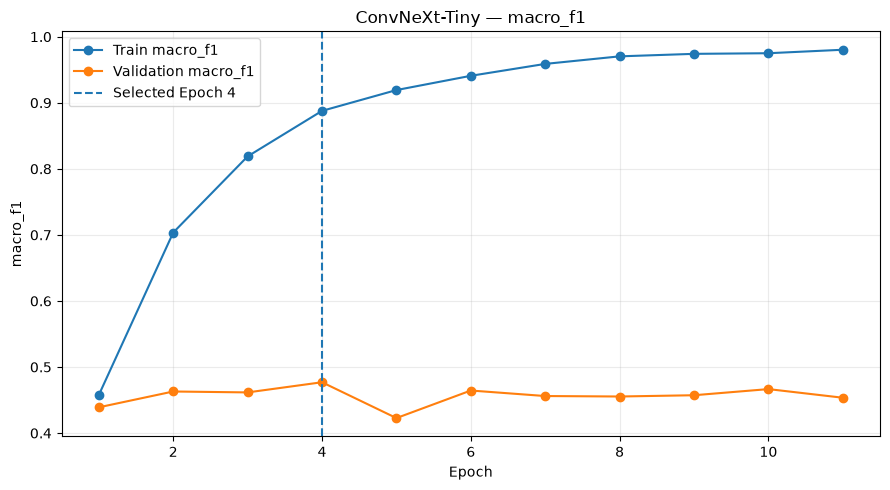

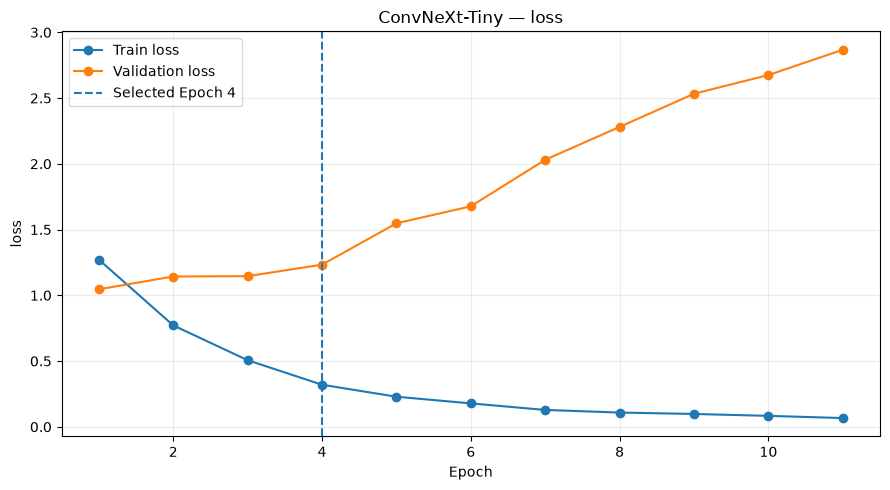

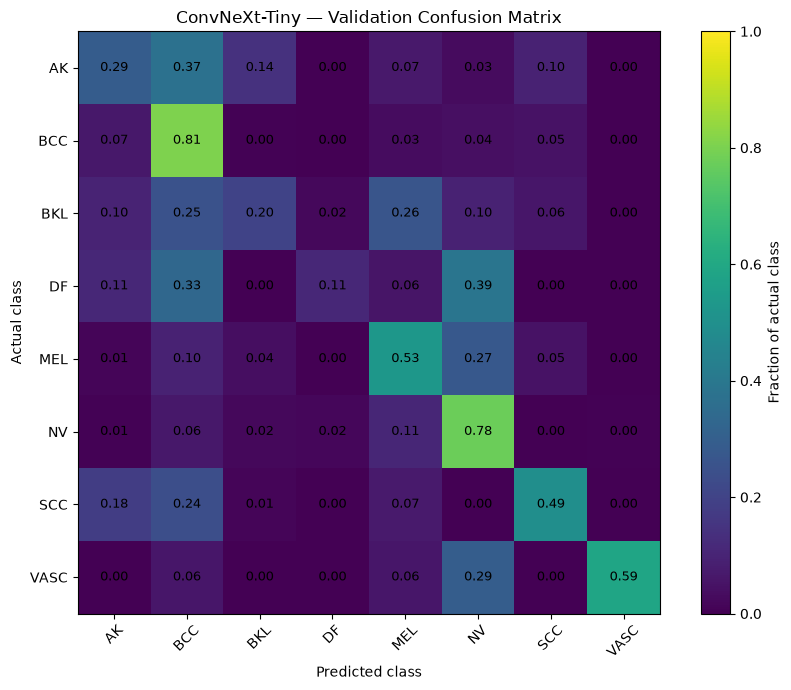

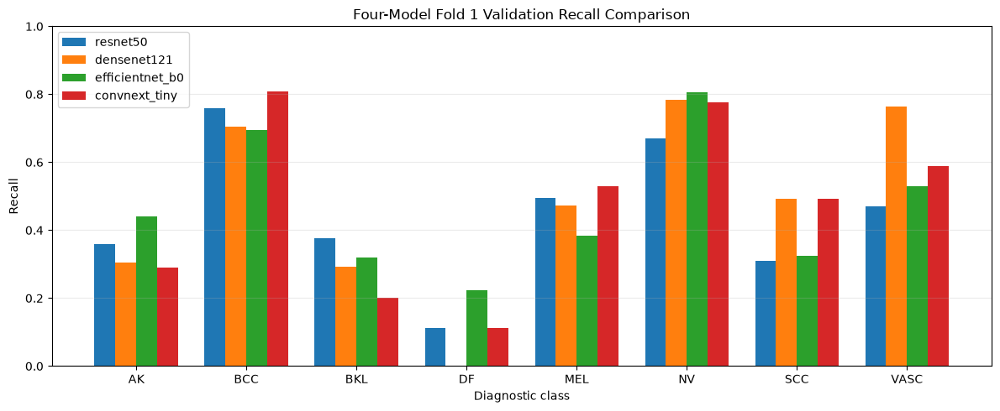

[PASS] All four figures generated

[17] CHECKPOINT SAFETY
[PASS] ConvNeXt best checkpoint unchanged
[PASS] ConvNeXt last checkpoint unchanged

CONVNEXT-TINY BEST CHECKPOINT AUDIT VERIFICATION
[PASS] ConvNeXt configuration exists
[PASS] ConvNeXt training report exists
[PASS] ConvNeXt setup report exists
[PASS] ConvNeXt best checkpoint exists
[PASS] ConvNeXt last checkpoint exists
[PASS] Training manifest exists
[PASS] Validation manifest exists
[PASS] resnet50 previous audit exists
[PASS] densenet121 previous audit exists
[PASS] efficientnet_b0 previous audit exists
[PASS] resnet50 predictions exists
[PASS] densenet121 predictions exists
[PASS] efficientnet_b0 predictions exists
[PASS] Dataset factory available
[PASS] Configuration fingerprint valid
[PASS] ConvNeXt training status PASS
[PASS] ConvNeXt setup status PASS
[PASS] Experiment identity correct
[PASS] Correct architecture and partition
[PASS] Eight-class order preserved
[PASS] Training completed 11 epochs
[PASS] Best checkpoint

In [120]:

# ============================================================
# BCN20000 - PHASE 05C - CELL 4
# CONVNEXT-TINY INDEPENDENT BEST CHECKPOINT AUDIT
# FOUR-MODEL VALIDATION COMPARISON
# ============================================================

import os
import gc
import json
import math
import time
import hashlib
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision.models import convnext_tiny
from tqdm.auto import tqdm
from IPython.display import display

print("=" * 78)
print("PHASE 05C - CELL 4")
print("CONVNEXT-TINY BEST CHECKPOINT AUDIT")
print("=" * 78)


# ============================================================
# 1. EXPERIMENT PATHS
# ============================================================

A4_OUT = Path.cwd() / "outputs"

A4_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

A4_IDS = {
    "resnet50": (
        "resnet50_original_fold01_sqrt_weighted_ce_seed42"
    ),
    "densenet121": (
        "densenet121_original_fold01_sqrt_weighted_ce_seed42"
    ),
    "efficientnet_b0": (
        "efficientnet_b0_original_fold01_sqrt_weighted_ce_seed42"
    ),
    "convnext_tiny": (
        "convnext_tiny_original_fold01_sqrt_weighted_ce_seed42"
    )
}

A4_ID = A4_IDS["convnext_tiny"]

A4_CONFIG = (
    A4_OUT / "configs/full_training" / f"{A4_ID}.json"
)

A4_TRAINING = (
    A4_OUT / "reports" / f"{A4_ID}_training_report.json"
)

A4_SETUP = (
    A4_OUT / "reports" /
    "convnext_tiny_original_fold01_full_training_setup_verification.json"
)

A4_BEST = (
    A4_OUT / "checkpoints/full_training/convnext_tiny/"
    "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
)

A4_LAST = A4_BEST.parent / "last_checkpoint.pt"

A4_TRAIN_CSV = (
    A4_OUT / "splits/original_branch/fold_01_train.csv"
)

A4_VAL_CSV = (
    A4_OUT / "splits/original_branch/fold_01_validation.csv"
)

A4_PREVIOUS_AUDITS = {
    model: (
        A4_OUT / "reports" /
        f"{A4_IDS[model]}_best_checkpoint_audit.json"
    )
    for model in [
        "resnet50", "densenet121", "efficientnet_b0"
    ]
}

A4_PREVIOUS_PREDICTIONS = {
    model: (
        A4_OUT / "predictions/full_training" /
        f"{A4_IDS[model]}_validation_predictions.csv"
    )
    for model in [
        "resnet50", "densenet121", "efficientnet_b0"
    ]
}

A4_PRED_OUT = (
    A4_OUT / "predictions/full_training" /
    f"{A4_ID}_validation_predictions.csv"
)

A4_CLASS_OUT = (
    A4_OUT / "reports" /
    f"{A4_ID}_per_class_metrics.csv"
)

A4_COMPARE_OUT = (
    A4_OUT / "reports" /
    "four_model_original_fold01_validation_comparison.csv"
)

A4_CLASS_COMPARE_OUT = (
    A4_OUT / "reports" /
    "four_model_original_fold01_class_comparison.csv"
)

A4_PAIRED_OUT = (
    A4_OUT / "reports" /
    "four_model_original_fold01_paired_correctness.csv"
)

A4_AUDIT_OUT = (
    A4_OUT / "reports" /
    f"{A4_ID}_best_checkpoint_audit.json"
)

A4_FIG_DIR = A4_OUT / "figures"

A4_DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

A4_CHECKS = {}
A4_FIGURES = []


# ============================================================
# 2. HELPERS
# ============================================================

def a4_check(name, condition):
    passed = bool(condition)
    A4_CHECKS[name] = passed
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")


def a4_require_pass():
    failed = [
        name for name, passed in A4_CHECKS.items()
        if not passed
    ]

    if failed:
        raise RuntimeError(
            "Audit BLOCKED:\n" + "\n".join(failed)
        )


def a4_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def a4_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(block)

    return digest.hexdigest()


def a4_signature(config):
    unsigned = {
        k: v for k, v in config.items()
        if k != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


def a4_atomic_json(data, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".temporary")

    try:
        with open(tmp, "w", encoding="utf-8") as f:
            json.dump(
                data, f,
                indent=4,
                ensure_ascii=False,
                allow_nan=False
            )
        os.replace(tmp, path)
    finally:
        if tmp.exists():
            tmp.unlink()


def a4_atomic_csv(dataframe, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".temporary")

    try:
        dataframe.to_csv(tmp, index=False)
        os.replace(tmp, path)
    finally:
        if tmp.exists():
            tmp.unlink()


def a4_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.int64)
    y_pred = np.asarray(y_pred, dtype=np.int64)

    if (
        y_true.shape != y_pred.shape
        or len(y_true) == 0
        or not np.all((y_true >= 0) & (y_true < 8))
        or not np.all((y_pred >= 0) & (y_pred < 8))
    ):
        raise ValueError("Invalid prediction or label inputs.")

    cm = np.zeros((8, 8), dtype=np.int64)
    np.add.at(cm, (y_true, y_pred), 1)

    tp = cm.diagonal().astype(float)
    support = cm.sum(axis=1).astype(float)
    predicted = cm.sum(axis=0).astype(float)

    precision = np.divide(
        tp, predicted,
        out=np.zeros(8),
        where=predicted > 0
    )

    recall = np.divide(
        tp, support,
        out=np.zeros(8),
        where=support > 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(8),
        where=(precision + recall) > 0
    )

    return {
        "accuracy": float(tp.sum() / len(y_true)),
        "macro_f1": float(f1.mean()),
        "weighted_f1": float(
            np.dot(f1, support) / len(y_true)
        ),
        "balanced_accuracy": float(
            recall[support > 0].mean()
        ),
        "confusion_matrix": cm.tolist(),
        "precision": precision.tolist(),
        "recall": recall.tolist(),
        "f1": f1.tolist(),
        "support": support.astype(int).tolist(),
        "predicted_count": predicted.astype(int).tolist()
    }


# ============================================================
# 3. REQUIRED FILE VERIFICATION
# ============================================================

print("\n[1] REQUIRED ARTIFACTS")

required = {
    "ConvNeXt configuration": A4_CONFIG,
    "ConvNeXt training report": A4_TRAINING,
    "ConvNeXt setup report": A4_SETUP,
    "ConvNeXt best checkpoint": A4_BEST,
    "ConvNeXt last checkpoint": A4_LAST,
    "Training manifest": A4_TRAIN_CSV,
    "Validation manifest": A4_VAL_CSV
}

for model, path in A4_PREVIOUS_AUDITS.items():
    required[f"{model} previous audit"] = path

for model, path in A4_PREVIOUS_PREDICTIONS.items():
    required[f"{model} predictions"] = path

for name, path in required.items():
    a4_check(f"{name} exists", path.is_file())

a4_check(
    "Dataset factory available",
    callable(globals().get("create_bcn_dataset"))
)

a4_require_pass()


# ============================================================
# 4. CONFIGURATION AND TRAINING REPORT
# ============================================================

print("\n[2] CONFIGURATION AND TRAINING REPORT")

config = a4_json(A4_CONFIG)
training = a4_json(A4_TRAINING)
setup = a4_json(A4_SETUP)

previous_audits = {
    model: a4_json(path)
    for model, path in A4_PREVIOUS_AUDITS.items()
}

signature = a4_signature(config)

EXPECTED_SIGNATURE = (
    "6da5c7a7056442c64efc8496af47056d"
    "dbe7fc47a57344ff0abee9ef34d46659"
)

a4_check(
    "Configuration fingerprint valid",
    signature == config.get("config_signature")
    == setup.get("configuration_signature")
    == EXPECTED_SIGNATURE
)

a4_check(
    "ConvNeXt training status PASS",
    training.get("status") == "PASS"
)

a4_check(
    "ConvNeXt setup status PASS",
    setup.get("status") == "PASS"
)

a4_check(
    "Experiment identity correct",
    config.get("experiment_id") == A4_ID
    and training.get("experiment_id") == A4_ID
)

a4_check(
    "Correct architecture and partition",
    config.get("model") == "convnext_tiny"
    and config.get("branch") == "original"
    and config.get("fold") == 1
)

a4_check(
    "Eight-class order preserved",
    config.get("class_names") == A4_CLASSES
)

a4_check(
    "Training completed 11 epochs",
    training.get("completed_epochs") == 11
)

a4_check(
    "Best checkpoint selected at epoch 4",
    training.get("best_epoch") == 4
)

a4_check(
    "Early stopping verified",
    training.get("early_stopped") is True
    and training.get("early_stopping_wait") == 7
)

a4_check(
    "Outer-test protected",
    training.get("outer_test_evaluated") is False
    and config.get("outer_test_for_tuning") is False
)

for model, report in previous_audits.items():
    a4_check(
        f"{model} prior audit PASS",
        report.get("status") == "PASS"
        and report.get("outer_test_evaluated") is False
        and bool(report.get("checks"))
        and all(report["checks"].values())
    )

history = training.get("history", [])

a4_check(
    "Training history complete",
    len(history) == 11
    and [
        int(row["epoch"]) for row in history
    ] == list(range(1, 12))
)

a4_require_pass()

best_row = history[3]

a4_check(
    "Best validation Macro-F1 matches training report",
    math.isclose(
        float(best_row["validation_macro_f1"]),
        float(training["best_validation_macro_f1"]),
        rel_tol=0,
        abs_tol=1e-12
    )
)

a4_check(
    "All 11 epochs used full train and validation data",
    all(
        int(row["train_samples"]) == 7813
        and int(row["validation_samples"]) == 1973
        and int(row["optimizer_step_attempts"]) == 489
        for row in history
    )
)

a4_require_pass()

print("Completed epochs: 11")
print("Selected best epoch: 4")
print(
    "Logged best Macro-F1:",
    training["best_validation_macro_f1"]
)


# ============================================================
# 5. CHECKPOINT INTEGRITY
# ============================================================

print("\n[3] CHECKPOINT INTEGRITY")

protected_paths = {
    "ConvNeXt best": A4_BEST,
    "ConvNeXt last": A4_LAST
}

protected_hashes = {
    name: a4_hash(path)
    for name, path in protected_paths.items()
}

best_state = torch.load(
    A4_BEST,
    map_location="cpu",
    weights_only=True
)

last_state = torch.load(
    A4_LAST,
    map_location="cpu",
    weights_only=True
)

a4_check(
    "Best checkpoint epoch = 4",
    int(best_state["completed_epoch"]) == 4
)

a4_check(
    "Last checkpoint epoch = 11",
    int(last_state["completed_epoch"]) == 11
)

a4_check(
    "Checkpoint types correct",
    best_state.get("checkpoint_kind")
    == "full_training_best"
    and last_state.get("checkpoint_kind")
    == "full_training_last"
)

a4_check(
    "Checkpoint experiment IDs correct",
    best_state.get("experiment_id") == A4_ID
    and last_state.get("experiment_id") == A4_ID
)

a4_check(
    "Checkpoint signatures match",
    best_state.get("configuration_signature") == signature
    and last_state.get("configuration_signature") == signature
)

a4_check(
    "Classifier weight shape = (8, 768)",
    tuple(
        best_state["model_state_dict"][
            "classifier.2.weight"
        ].shape
    ) == (8, 768)
)

a4_check(
    "Best checkpoint history has 4 epochs",
    len(best_state.get("history", [])) == 4
)

a4_check(
    "Last checkpoint history has 11 epochs",
    len(last_state.get("history", [])) == 11
)

a4_require_pass()
del last_state

print("Checkpoint integrity: VERIFIED")


# ============================================================
# 6. DATASET INTEGRITY
# ============================================================

print("\n[4] DATASET VERIFICATION")

columns = [
    "bcn_filename",
    "diagnosis",
    "leakage_group_id"
]

train_manifest = pd.read_csv(
    A4_TRAIN_CSV,
    usecols=columns,
    dtype="string"
)

val_manifest = pd.read_csv(
    A4_VAL_CSV,
    usecols=columns,
    dtype="string"
)

dataset = create_bcn_dataset(
    "original", 1, "validation"
)

loader = DataLoader(
    dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(A4_DEVICE.type == "cuda"),
    drop_last=False
)

a4_check(
    "Validation contains 1973 images",
    len(dataset) == 1973
    and len(val_manifest) == 1973
)

a4_check(
    "Validation has 494 batches",
    len(loader) == 494
)

a4_check(
    "Validation has 571 leakage groups",
    val_manifest["leakage_group_id"].nunique() == 571
)

a4_check(
    "Training-validation groups disjoint",
    set(train_manifest["leakage_group_id"]).isdisjoint(
        set(val_manifest["leakage_group_id"])
    )
)

a4_check(
    "Validation filenames unique",
    val_manifest["bcn_filename"].is_unique
)

a4_check(
    "No missing validation metadata",
    not val_manifest.isna().any().any()
)

a4_require_pass()


# ============================================================
# 7. LOAD EPOCH-4 CONVNEXT-TINY
# ============================================================

print("\n[5] LOADING SELECTED BEST MODEL")

model = convnext_tiny(weights=None)

if model.classifier[2].in_features != 768:
    raise RuntimeError(
        "Unexpected ConvNeXt classifier input."
    )

model.classifier[2] = nn.Linear(768, 8)

model.load_state_dict(
    best_state["model_state_dict"],
    strict=True
)

del best_state

model = model.to(A4_DEVICE)
model.eval()

a4_check(
    "Best model loaded in eval mode",
    not model.training
)

print("Model: ConvNeXt-Tiny")
print("Checkpoint: Epoch 4")
print("Training: DISABLED")


# ============================================================
# 8. INDEPENDENT VALIDATION INFERENCE
# ============================================================

print("\n[6] INDEPENDENT VALIDATION INFERENCE")

true_labels = []
pred_labels = []
filenames = []
group_ids = []
probabilities_all = []

loss_total = 0.0
sample_total = 0

amp_enabled = (
    A4_DEVICE.type == "cuda"
    and config.get("mixed_precision") is True
)

start_time = time.perf_counter()

with torch.inference_mode():

    for batch in tqdm(
        loader,
        desc="ConvNeXt Epoch 4 Audit"
    ):

        images = batch["image"].to(
            A4_DEVICE,
            non_blocking=True
        )

        labels = batch["label"].to(
            A4_DEVICE,
            non_blocking=True
        )

        with torch.autocast(
            device_type=A4_DEVICE.type,
            dtype=torch.float16,
            enabled=amp_enabled
        ):
            logits = model(images)

        logits_fp32 = logits.float()

        if not bool(
            torch.isfinite(logits_fp32).all().item()
        ):
            raise FloatingPointError(
                "Non-finite validation logits."
            )

        loss = F.cross_entropy(
            logits_fp32,
            labels
        )

        if not bool(torch.isfinite(loss).item()):
            raise FloatingPointError(
                "Non-finite validation loss."
            )

        probs = torch.softmax(
            logits_fp32,
            dim=1
        )

        predicted = logits_fp32.argmax(dim=1)

        n = int(labels.size(0))

        loss_total += float(loss.item()) * n
        sample_total += n

        true_labels.extend(
            labels.cpu().tolist()
        )

        pred_labels.extend(
            predicted.cpu().tolist()
        )

        filenames.extend(
            str(x) for x in batch["filename"]
        )

        group_ids.extend(
            str(x) for x in batch["leakage_group_id"]
        )

        probabilities_all.append(
            probs.cpu().numpy()
        )

elapsed = time.perf_counter() - start_time

y_true = np.asarray(true_labels, dtype=np.int64)
y_pred = np.asarray(pred_labels, dtype=np.int64)

prob_matrix = np.concatenate(
    probabilities_all,
    axis=0
)

a4_check(
    "1973 validation samples evaluated",
    sample_total == 1973
    and len(y_true) == 1973
    and len(y_pred) == 1973
)

a4_check(
    "Probability matrix shape = (1973, 8)",
    prob_matrix.shape == (1973, 8)
)

a4_check(
    "All probabilities finite",
    bool(np.isfinite(prob_matrix).all())
)

a4_check(
    "Probability rows normalized",
    bool(np.allclose(
        prob_matrix.sum(axis=1),
        1.0,
        atol=1e-5
    ))
)

a4_check(
    "Predictions match probability argmax",
    bool(np.array_equal(
        y_pred,
        prob_matrix.argmax(axis=1)
    ))
)

a4_require_pass()

print("Validation images:", sample_total)
print("Inference seconds:", round(elapsed, 2))


# ============================================================
# 9. REPRODUCE SELECTED CHECKPOINT METRICS
# ============================================================

print("\n[7] INDEPENDENT METRIC RECONSTRUCTION")

metrics = a4_metrics(y_true, y_pred)

metrics["loss"] = float(
    loss_total / sample_total
)

metric_keys = {
    "accuracy": "validation_accuracy",
    "macro_f1": "validation_macro_f1",
    "weighted_f1": "validation_weighted_f1",
    "balanced_accuracy": "validation_balanced_accuracy",
    "loss": "validation_loss"
}

for metric, history_key in metric_keys.items():

    logged = float(best_row[history_key])
    recomputed = float(metrics[metric])

    difference = abs(logged - recomputed)

    tolerance = (
        1e-4 if metric == "loss"
        else 1e-5
    )

    a4_check(
        f"Reproduced {metric}",
        difference <= tolerance
    )

    print(
        f"{metric:19s} | "
        f"Logged: {logged:.6f} | "
        f"Recomputed: {recomputed:.6f} | "
        f"Difference: {difference:.9f}"
    )

cm = np.asarray(
    metrics["confusion_matrix"],
    dtype=np.int64
)

a4_check(
    "Confusion matrix matches Epoch 4 history",
    np.array_equal(
        cm,
        np.asarray(
            best_row["validation_confusion_matrix"],
            dtype=np.int64
        )
    )
)

a4_check(
    "Confusion matrix totals 1973",
    int(cm.sum()) == 1973
)

a4_require_pass()


# ============================================================
# 10. PREDICTION METADATA ALIGNMENT
# ============================================================

print("\n[8] PREDICTION METADATA VERIFICATION")

pred_df = pd.DataFrame({
    "filename": filenames,
    "leakage_group_id": group_ids,
    "actual_idx": y_true,
    "predicted_idx": y_pred,
    "actual_class": [
        A4_CLASSES[i] for i in y_true
    ],
    "predicted_class": [
        A4_CLASSES[i] for i in y_pred
    ],
    "confidence": prob_matrix.max(axis=1)
})

prob_columns = []

for i, name in enumerate(A4_CLASSES):
    column = f"prob_{name}"
    prob_columns.append(column)

    pred_df[column] = prob_matrix[:, i]

reference = val_manifest.rename(
    columns={
        "bcn_filename": "filename",
        "diagnosis": "manifest_diagnosis",
        "leakage_group_id": "manifest_group"
    }
)

aligned = pred_df.merge(
    reference,
    on="filename",
    how="left",
    validate="one_to_one",
    indicator=True
)

a4_check(
    "Every prediction matches validation manifest",
    len(aligned) == 1973
    and bool(aligned["_merge"].eq("both").all())
)

a4_check(
    "Ground-truth labels match manifest",
    bool((
        aligned["actual_class"].astype(str)
        == aligned["manifest_diagnosis"].astype(str)
    ).all())
)

a4_check(
    "Leakage-group IDs match manifest",
    bool((
        aligned["leakage_group_id"].astype(str)
        == aligned["manifest_group"].astype(str)
    ).all())
)

a4_require_pass()


# ============================================================
# 11. PER-CLASS PERFORMANCE
# ============================================================

print("\n[9] CONVNEXT-TINY CLASS-WISE PERFORMANCE")

top3 = np.argsort(
    -prob_matrix,
    axis=1
)[:, :3]

class_rows = []

for i, name in enumerate(A4_CLASSES):

    mask = y_true == i
    support = int(mask.sum())

    top3_acc = (
        float(
            np.any(top3[mask] == i, axis=1).mean()
        )
        if support else 0.0
    )

    class_rows.append({
        "class": name,
        "validation_support": support,
        "predicted_count": int(
            metrics["predicted_count"][i]
        ),
        "precision": float(metrics["precision"][i]),
        "recall": float(metrics["recall"][i]),
        "f1": float(metrics["f1"][i]),
        "top3_accuracy": top3_acc
    })

class_df = pd.DataFrame(class_rows)

display(class_df.round(6))

a4_check(
    "All eight diagnostic classes evaluated",
    len(class_df) == 8
)

a4_check(
    "Class supports total 1973",
    int(class_df["validation_support"].sum()) == 1973
)

zero_recall = class_df.loc[
    class_df["recall"] == 0,
    "class"
].tolist()

print("\nZero-recall classes:", zero_recall)

print("\nPriority-class recall:")

for name in ["DF", "VASC", "SCC", "MEL"]:

    row = class_df.set_index("class").loc[name]

    correct = int(round(
        row["recall"] * row["validation_support"]
    ))

    print(
        f"{name}: {row['recall']:.6f} "
        f"({correct}/{int(row['validation_support'])})"
    )


# ============================================================
# 12. EXPLORATORY GROUP-LEVEL EVALUATION
# ============================================================

print("\n[10] GROUP-LEVEL EXPLORATORY EVALUATION")

group_label_counts = pred_df.groupby(
    "leakage_group_id"
)["actual_idx"].nunique()

a4_check(
    "Every leakage group has a single true class",
    bool((group_label_counts == 1).all())
)

a4_require_pass()

group_probs = pred_df.groupby(
    "leakage_group_id"
)[prob_columns].mean()

group_truth = pred_df.groupby(
    "leakage_group_id"
)["actual_idx"].first()

group_prediction = group_probs.to_numpy().argmax(
    axis=1
)

group_metrics = a4_metrics(
    group_truth.to_numpy(dtype=np.int64),
    group_prediction
)

a4_check(
    "571 groups evaluated",
    len(group_truth) == 571
)

print("Validation groups:", len(group_truth))
print(
    "Exploratory group Macro-F1:",
    round(group_metrics["macro_f1"], 6)
)


# ============================================================
# 13. ERROR ANALYSIS
# ============================================================

print("\n[11] TOP MISCLASSIFICATIONS")

error_rows = []

for actual in range(8):
    for predicted in range(8):

        if actual == predicted:
            continue

        count = int(cm[actual, predicted])

        if count > 0:
            error_rows.append({
                "actual_class": A4_CLASSES[actual],
                "predicted_class": A4_CLASSES[predicted],
                "error_count": count
            })

error_df = pd.DataFrame(
    error_rows,
    columns=[
        "actual_class",
        "predicted_class",
        "error_count"
    ]
).sort_values(
    "error_count",
    ascending=False
)

display(error_df.head(12))


# ============================================================
# 14. FOUR-MODEL METRIC COMPARISON
# ============================================================

print("\n[12] FOUR-MODEL VALIDATION COMPARISON")

all_model_metrics = {
    model: previous_audits[model]["validation_metrics"]
    for model in previous_audits
}

all_model_metrics["convnext_tiny"] = metrics

compare_rows = []

for metric in [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy",
    "loss"
]:

    row = {"metric": metric}

    for model in A4_IDS:
        row[model] = float(
            all_model_metrics[model][metric]
        )

    compare_rows.append(row)

compare_df = pd.DataFrame(compare_rows)

display(compare_df.round(6))


# ============================================================
# 15. FOUR-MODEL CLASS-WISE COMPARISON
# ============================================================

print("\n[13] FOUR-MODEL CLASS-WISE COMPARISON")

all_class_records = {
    model: {
        row["class"]: row
        for row in previous_audits[model]["per_class_metrics"]
    }
    for model in previous_audits
}

all_class_records["convnext_tiny"] = {
    row["class"]: row
    for row in class_rows
}

class_compare_rows = []

for name in A4_CLASSES:

    support = int(
        all_class_records["convnext_tiny"][name][
            "validation_support"
        ]
    )

    row = {
        "class": name,
        "support": support
    }

    for model in A4_IDS:
        record = all_class_records[model][name]

        row[f"{model}_recall"] = float(
            record["recall"]
        )

        row[f"{model}_f1"] = float(
            record["f1"]
        )

    class_compare_rows.append(row)

class_compare_df = pd.DataFrame(
    class_compare_rows
)

display(class_compare_df.round(6))

a4_check(
    "Eight classes compared",
    len(class_compare_df) == 8
)

a4_check(
    "Class support identical across four models",
    all(
        int(all_class_records[model][name][
            "validation_support"
        ])
        == int(all_class_records["convnext_tiny"][name][
            "validation_support"
        ])
        for model in A4_IDS
        for name in A4_CLASSES
    )
)

a4_require_pass()


# ============================================================
# 16. PAIRED FOUR-MODEL PREDICTION ANALYSIS
# ============================================================

print("\n[14] PAIRED PREDICTION COMPARISON")

paired_columns = [
    "filename",
    "actual_idx",
    "predicted_idx",
    "leakage_group_id"
]

def a4_rename_prediction(frame, model):
    return frame[paired_columns].rename(
        columns={
            "actual_idx": f"actual_{model}",
            "predicted_idx": f"pred_{model}",
            "leakage_group_id": f"group_{model}"
        }
    )


paired = a4_rename_prediction(
    pred_df,
    "convnext_tiny"
)

prediction_frames = {
    "convnext_tiny": pred_df
}

for model, path in A4_PREVIOUS_PREDICTIONS.items():

    previous_predictions = pd.read_csv(
        path,
        usecols=paired_columns,
        dtype={
            "filename": "string",
            "leakage_group_id": "string"
        }
    )

    prediction_frames[model] = previous_predictions

    paired = paired.merge(
        a4_rename_prediction(
            previous_predictions,
            model
        ),
        on="filename",
        how="inner",
        validate="one_to_one"
    )

a4_check(
    "All four models cover same 1973 images",
    len(paired) == 1973
    and all(
        len(frame) == 1973
        for frame in prediction_frames.values()
    )
)

a4_check(
    "All four models have identical labels",
    all(
        bool((
            paired[f"actual_{model}"]
            == paired["actual_convnext_tiny"]
        ).all())
        for model in A4_IDS
    )
)

a4_check(
    "All four models have identical leakage groups",
    all(
        bool((
            paired[f"group_{model}"].astype(str)
            == paired["group_convnext_tiny"].astype(str)
        ).all())
        for model in A4_IDS
    )
)

a4_require_pass()

# Verify existing prediction CSVs still agree
# with their independently saved audit metrics.

for model in [
    "resnet50",
    "densenet121",
    "efficientnet_b0"
]:

    previous_metrics = a4_metrics(
        paired[f"actual_{model}"].to_numpy(),
        paired[f"pred_{model}"].to_numpy()
    )

    logged = previous_audits[model]["validation_metrics"]

    a4_check(
        f"{model} predictions reproduce its audit",
        all(
            math.isclose(
                float(previous_metrics[key]),
                float(logged[key]),
                rel_tol=0,
                abs_tol=1e-8
            )
            for key in [
                "accuracy",
                "macro_f1",
                "weighted_f1",
                "balanced_accuracy"
            ]
        )
    )

a4_require_pass()

model_order = list(A4_IDS.keys())

correctness = {}

for model in model_order:

    correctness[model] = (
        paired[f"actual_{model}"].to_numpy()
        == paired[f"pred_{model}"].to_numpy()
    )

pattern_rows = []

for pattern in product([0, 1], repeat=4):

    selected = np.ones(
        len(paired),
        dtype=bool
    )

    for model, flag in zip(model_order, pattern):
        selected &= (
            correctness[model] == bool(flag)
        )

    row = {
        "pattern": "".join(map(str, pattern)),
        "count": int(selected.sum())
    }

    for model, flag in zip(model_order, pattern):
        row[f"{model}_correct"] = flag

    pattern_rows.append(row)

paired_df = pd.DataFrame(
    pattern_rows
).sort_values(
    "count",
    ascending=False
)

a4_check(
    "All 16 correctness patterns account for 1973 images",
    len(paired_df) == 16
    and int(paired_df["count"].sum()) == 1973
)

print(
    "\nPattern order:",
    "ResNet50, DenseNet121, EfficientNet-B0, ConvNeXt-Tiny"
)

display(paired_df.head(10))

paired_summary = {
    "all_four_correct": int(
        np.logical_and.reduce(
            [correctness[m] for m in model_order]
        ).sum()
    ),
    "all_four_wrong": int(
        np.logical_and.reduce(
            [~correctness[m] for m in model_order]
        ).sum()
    )
}

for model in [
    "resnet50",
    "densenet121",
    "efficientnet_b0"
]:

    paired_summary[
        f"convnext_only_correct_vs_{model}"
    ] = int((
        correctness["convnext_tiny"]
        & ~correctness[model]
    ).sum())

    paired_summary[
        f"{model}_only_correct_vs_convnext"
    ] = int((
        ~correctness["convnext_tiny"]
        & correctness[model]
    ).sum())

print("\nPaired comparison summary:")

for name, count in paired_summary.items():
    print(f"{name}: {count}")

a4_require_pass()


# ============================================================
# 17. SAVE VALIDATION REPORT TABLES
# ============================================================

print("\n[15] SAVING AUDIT TABLES")

a4_atomic_csv(pred_df, A4_PRED_OUT)
a4_atomic_csv(class_df, A4_CLASS_OUT)
a4_atomic_csv(compare_df, A4_COMPARE_OUT)

a4_atomic_csv(
    class_compare_df,
    A4_CLASS_COMPARE_OUT
)

a4_atomic_csv(
    paired_df,
    A4_PAIRED_OUT
)

for name, path in {
    "Predictions CSV": A4_PRED_OUT,
    "Class metrics CSV": A4_CLASS_OUT,
    "Four-model comparison CSV": A4_COMPARE_OUT,
    "Class comparison CSV": A4_CLASS_COMPARE_OUT,
    "Paired correctness CSV": A4_PAIRED_OUT
}.items():

    a4_check(
        f"{name} saved",
        path.is_file()
    )

a4_require_pass()


# ============================================================
# 18. TRAINING CURVES
# ============================================================

print("\n[16] GENERATING FIGURES")

A4_FIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

history_df = pd.DataFrame(history)

for metric, filename in [
    (
        "macro_f1",
        "convnext_tiny_fold01_macro_f1.png"
    ),
    (
        "loss",
        "convnext_tiny_fold01_loss.png"
    )
]:

    fig_path = A4_FIG_DIR / filename

    plt.figure(figsize=(9, 5))

    plt.plot(
        history_df["epoch"],
        history_df[f"train_{metric}"],
        marker="o",
        label=f"Train {metric}"
    )

    plt.plot(
        history_df["epoch"],
        history_df[f"validation_{metric}"],
        marker="o",
        label=f"Validation {metric}"
    )

    plt.axvline(
        4,
        linestyle="--",
        label="Selected Epoch 4"
    )

    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.title(f"ConvNeXt-Tiny — {metric}")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        fig_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    A4_FIGURES.append(str(fig_path))


# ============================================================
# 19. NORMALIZED CONFUSION MATRIX
# ============================================================

cm_path = (
    A4_FIG_DIR /
    "convnext_tiny_fold01_confusion_matrix.png"
)

row_totals = cm.sum(axis=1, keepdims=True)

normalized_cm = np.divide(
    cm,
    row_totals,
    out=np.zeros((8, 8), dtype=float),
    where=row_totals > 0
)

plt.figure(figsize=(9, 7))

plt.imshow(
    normalized_cm,
    vmin=0,
    vmax=1
)

plt.colorbar(label="Fraction of actual class")

plt.xticks(
    range(8),
    A4_CLASSES,
    rotation=45
)

plt.yticks(
    range(8),
    A4_CLASSES
)

for i in range(8):
    for j in range(8):

        plt.text(
            j, i,
            f"{normalized_cm[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("ConvNeXt-Tiny — Validation Confusion Matrix")

plt.tight_layout()

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

A4_FIGURES.append(str(cm_path))


# ============================================================
# 20. FOUR-MODEL PER-CLASS RECALL CHART
# ============================================================

recall_path = (
    A4_FIG_DIR /
    "four_model_fold01_class_recall_comparison.png"
)

x = np.arange(8)
width = 0.19

plt.figure(figsize=(12, 5))

for index, model in enumerate(model_order):

    offset = (index - 1.5) * width

    plt.bar(
        x + offset,
        class_compare_df[f"{model}_recall"],
        width,
        label=model
    )

plt.xticks(x, A4_CLASSES)
plt.ylim(0, 1)
plt.xlabel("Diagnostic class")
plt.ylabel("Recall")

plt.title(
    "Four-Model Fold 1 Validation Recall Comparison"
)

plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    recall_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

A4_FIGURES.append(str(recall_path))

a4_check(
    "All four figures generated",
    len(A4_FIGURES) == 4
    and all(
        Path(p).is_file()
        for p in A4_FIGURES
    )
)


# ============================================================
# 21. CHECKPOINT SAFETY
# ============================================================

print("\n[17] CHECKPOINT SAFETY")

for name, path in protected_paths.items():

    a4_check(
        f"{name} checkpoint unchanged",
        a4_hash(path)
        == protected_hashes[name]
    )

a4_require_pass()


# ============================================================
# 22. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("CONVNEXT-TINY BEST CHECKPOINT AUDIT VERIFICATION")
print("=" * 78)

for name, passed in A4_CHECKS.items():
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

A4_STATUS = (
    "PASS"
    if A4_CHECKS and all(A4_CHECKS.values())
    else "BLOCKED"
)


# ============================================================
# 23. SAVE FINAL AUDIT REPORT
# ============================================================

audit_report = {
    "stage": "CONVNEXT_TINY_BEST_CHECKPOINT_AUDIT",
    "status": A4_STATUS,
    "experiment_id": A4_ID,
    "model": "convnext_tiny",
    "branch": "original",
    "fold": 1,
    "training_epochs": 11,
    "best_epoch": 4,
    "evaluation_partition": "validation",
    "validation_images": 1973,
    "validation_groups": 571,
    "validation_metrics": metrics,
    "per_class_metrics": class_rows,
    "group_metrics": group_metrics,
    "zero_recall_classes": zero_recall,
    "top_misclassifications": (
        error_df.head(12).to_dict(
            orient="records"
        )
    ),
    "four_model_comparison": compare_rows,
    "four_model_class_comparison": (
        class_compare_rows
    ),
    "paired_prediction_summary": paired_summary,
    "best_checkpoint_sha256": (
        protected_hashes["ConvNeXt best"]
    ),
    "last_checkpoint_sha256": (
        protected_hashes["ConvNeXt last"]
    ),
    "prediction_csv": str(A4_PRED_OUT),
    "per_class_csv": str(A4_CLASS_OUT),
    "comparison_csv": str(A4_COMPARE_OUT),
    "class_comparison_csv": str(
        A4_CLASS_COMPARE_OUT
    ),
    "paired_correctness_csv": str(A4_PAIRED_OUT),
    "figures": A4_FIGURES,
    "training_performed": False,
    "outer_test_evaluated": False,
    "checks": {
        name: bool(passed)
        for name, passed in A4_CHECKS.items()
    }
}

a4_atomic_json(
    audit_report,
    A4_AUDIT_OUT
)

a4_check(
    "Final audit report saved",
    A4_AUDIT_OUT.is_file()
)


# ============================================================
# 24. GPU CLEANUP
# ============================================================

del model
gc.collect()

if A4_DEVICE.type == "cuda":
    torch.cuda.empty_cache()


# ============================================================
# 25. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("CONVNEXT-TINY BEST CHECKPOINT AUDIT SUMMARY")
print("=" * 78)

print("Status:", A4_STATUS)
print("Model: ConvNeXt-Tiny")
print("Branch: original")
print("Fold: 1")

print("Completed training epochs: 11")
print("Best checkpoint epoch: 4")
print("Validation images:", sample_total)

print(
    "Reproduced Validation Macro-F1:",
    round(metrics["macro_f1"], 6)
)

print(
    "Reproduced Validation Accuracy:",
    round(metrics["accuracy"], 6)
)

print(
    "Reproduced Balanced Accuracy:",
    round(metrics["balanced_accuracy"], 6)
)

print("\nFour-model Macro-F1:")

for model_name in A4_IDS:
    print(
        f"{model_name}:",
        round(
            float(
                all_model_metrics[model_name]["macro_f1"]
            ),
            6
        )
    )

print("\nZero-recall classes:", zero_recall)

print("\nBest checkpoint: VERIFIED")
print("Outer-test evaluated: NO")
print("Training performed in audit: NO")

print("\nAudit report:")
print(A4_AUDIT_OUT)

print("\nFour-model comparison:")
print(A4_COMPARE_OUT)

print("\nPer-class comparison:")
print(A4_CLASS_COMPARE_OUT)

print("\nPaired correctness:")
print(A4_PAIRED_OUT)

if A4_STATUS == "PASS":
    print("\nCONVNEXT-TINY BEST CHECKPOINT AUDIT: PASS")
    print("NEXT ARCHITECTURE: VIT-B/16")
else:
    print("\nCONVNEXT-TINY BEST CHECKPOINT AUDIT: BLOCKED")

print("=" * 78)


In [121]:

import json
from pathlib import Path

path = Path(
    "outputs/reports/"
    "convnext_tiny_original_fold01_"
    "sqrt_weighted_ce_seed42_best_checkpoint_audit.json"
)

print("=" * 65)
print("CONVNEXT-TINY FINAL AUDIT CONFIRMATION")
print("=" * 65)

if not path.is_file():
    print("Status: AUDIT REPORT NOT FOUND")
    print("Check the original Cell 4 output for errors.")

else:
    with open(path, "r", encoding="utf-8") as f:
        report = json.load(f)

    checks = report.get("checks", {})
    failed = [
        name for name, passed in checks.items()
        if not passed
    ]

    figures = report.get("figures", [])
    figures_ok = (
        len(figures) == 4
        and all(Path(p).is_file() for p in figures)
    )

    passed = (
        report.get("status") == "PASS"
        and bool(checks)
        and not failed
        and figures_ok
        and report.get("best_epoch") == 4
        and report.get("outer_test_evaluated") is False
        and report.get("training_performed") is False
    )

    print("Audit status:", report.get("status"))
    print("Best epoch:", report.get("best_epoch"))
    print("Verification checks:", len(checks))
    print("Failed checks:", failed)
    print("All four figures saved:", figures_ok)
    print(
        "Validation Macro-F1:",
        report.get(
            "validation_metrics", {}
        ).get("macro_f1")
    )
    print(
        "Outer-test evaluated:",
        report.get("outer_test_evaluated")
    )

    print("\nFINAL:", "PASS" if passed else "REVIEW REQUIRED")

print("=" * 65)


CONVNEXT-TINY FINAL AUDIT CONFIRMATION
Audit status: PASS
Best epoch: 4
Verification checks: 81
Failed checks: []
All four figures saved: True
Validation Macro-F1: 0.4769646954224177
Outer-test evaluated: False

FINAL: PASS


In [122]:

# ============================================================
# BCN20000 - PHASE 05D - CELL 1
# VIT-B/16 ARCHITECTURE AND GPU READINESS
# ORIGINAL BRANCH | FOLD 01 | SEED 42
# ============================================================

import os
import gc
import json
import math
import random
import hashlib
import traceback

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, Subset
from torchvision.models import (
    vit_b_16,
    ViT_B_16_Weights
)

print("=" * 78)
print("PHASE 05D - CELL 1")
print("VIT-B/16 ARCHITECTURE AND GPU READINESS")
print("=" * 78)


# ============================================================
# 1. PATH CONFIGURATION
# ============================================================

V1_OUT = Path.cwd() / "outputs"

V1_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

V1_SOURCE_ID = (
    "convnext_tiny_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

V1_SOURCE_CONFIG = (
    V1_OUT / "configs/full_training" /
    f"{V1_SOURCE_ID}.json"
)

V1_SOURCE_AUDIT = (
    V1_OUT / "reports" /
    f"{V1_SOURCE_ID}_best_checkpoint_audit.json"
)

V1_ENGINE_REPORT = (
    V1_OUT / "reports" /
    "resnet50_weighted_engine_verification.json"
)

V1_REPORT_PATH = (
    V1_OUT / "reports" /
    "vit_b_16_original_fold01_architecture_readiness.json"
)

V1_CKPT_DIR = (
    V1_OUT / "checkpoints/full_training/"
    "vit_b_16/original/fold_01/sqrt_weighted_ce"
)

V1_PROTECTED = {
    "ResNet50 A": (
        V1_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt"
    ),
    "ResNet50 B": (
        V1_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 best": (
        V1_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 last": (
        V1_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "EfficientNet-B0 best": (
        V1_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "EfficientNet-B0 last": (
        V1_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "ConvNeXt-Tiny best": (
        V1_OUT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "ConvNeXt-Tiny last": (
        V1_OUT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    )
}

V1_CHECKS = {}
V1_ERRORS = []
V1_RESULTS = {}
V1_ATTEMPTS = []


# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def v1_check(name, condition):
    passed = bool(condition)
    V1_CHECKS[name] = passed

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )


def v1_require_pass():
    failed = [
        name
        for name, passed in V1_CHECKS.items()
        if not passed
    ]

    if failed:
        raise RuntimeError(
            "Verification failed:\n"
            + "\n".join(failed)
        )


def v1_read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def v1_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def v1_signature(config):
    unsigned = {
        key: value
        for key, value in config.items()
        if key != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


def v1_save_report(data, path):
    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temporary = path.with_name(
        path.name + ".temporary"
    )

    try:
        with open(
            temporary,
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(
                data,
                f,
                indent=4,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


# ============================================================
# 3. PREVIOUS PHASE VERIFICATION
# ============================================================

print("\n[1] PREVIOUS PHASE VERIFICATION")

required = {
    "ConvNeXt source configuration": V1_SOURCE_CONFIG,
    "ConvNeXt completed audit": V1_SOURCE_AUDIT,
    "Weighted training engine": V1_ENGINE_REPORT
}

required.update(V1_PROTECTED)

for name, path in required.items():
    v1_check(
        f"{name} exists",
        path.is_file()
    )

v1_require_pass()

source_config = v1_read_json(
    V1_SOURCE_CONFIG
)

source_audit = v1_read_json(
    V1_SOURCE_AUDIT
)

engine_report = v1_read_json(
    V1_ENGINE_REPORT
)

V1_EXPECTED_SOURCE_SIGNATURE = (
    "6da5c7a7056442c64efc8496af47056d"
    "dbe7fc47a57344ff0abee9ef34d46659"
)

v1_check(
    "ConvNeXt audit PASS",
    source_audit.get("status") == "PASS"
)

v1_check(
    "All ConvNeXt audit checks PASS",
    bool(source_audit.get("checks"))
    and all(source_audit["checks"].values())
)

v1_check(
    "Previous weighted engine PASS",
    engine_report.get("status") == "PASS"
)

v1_check(
    "Source configuration fingerprint valid",
    v1_signature(source_config)
    == source_config.get("config_signature")
    == V1_EXPECTED_SOURCE_SIGNATURE
)

v1_check(
    "Correct source architecture",
    source_config.get("model") == "convnext_tiny"
)

v1_check(
    "Source branch and fold correct",
    source_config.get("branch") == "original"
    and source_config.get("fold") == 1
)

v1_check(
    "Eight-class ordering correct",
    source_config.get("class_names") == V1_CLASSES
)

v1_check(
    "ConvNeXt selected checkpoint = Epoch 4",
    source_audit.get("best_epoch") == 4
)

v1_check(
    "Outer-test remains protected",
    source_audit.get("outer_test_evaluated") is False
    and source_config.get("outer_test_for_tuning") is False
)

for function in [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch"
]:
    v1_check(
        f"{function} available",
        callable(globals().get(function))
    )

v1_check(
    "Verified weighted accumulation engine active",
    callable(globals().get("train_one_epoch_weighted"))
    and "window_total_weight"
    in train_one_epoch_weighted.__code__.co_varnames
)

v1_check(
    "CUDA available",
    torch.cuda.is_available()
)

v1_require_pass()

V1_PROTECTED_HASHES = {
    name: v1_hash(path)
    for name, path in V1_PROTECTED.items()
}

print("Previous model checkpoints: HASHED")
print("Outer-test: PROTECTED")


# ============================================================
# 4. DATASET VERIFICATION
# ============================================================

print("\n[2] DATASET VERIFICATION")

train_ds = create_bcn_dataset(
    "original", 1, "train"
)

val_ds = create_bcn_dataset(
    "original", 1, "validation"
)

train_groups = set(
    train_ds.leakage_group_ids
)

val_groups = set(
    val_ds.leakage_group_ids
)

v1_check(
    "Training images = 7813",
    len(train_ds) == 7813
)

v1_check(
    "Validation images = 1973",
    len(val_ds) == 1973
)

v1_check(
    "Training leakage groups = 2286",
    len(train_groups) == 2286
)

v1_check(
    "Validation leakage groups = 571",
    len(val_groups) == 571
)

v1_check(
    "No train-validation group overlap",
    train_groups.isdisjoint(val_groups)
)

train_labels = np.asarray(
    train_ds.labels,
    dtype=np.int64
)

counts = np.bincount(
    train_labels,
    minlength=8
).astype(np.float64)

v1_check(
    "All eight classes represented",
    len(counts) == 8
    and bool(np.all(counts > 0))
)

weights = np.sqrt(
    counts.sum() / (8.0 * counts)
)

weights /= (
    np.dot(counts, weights)
    / counts.sum()
)

v1_check(
    "Training-only class weights reproduced",
    np.allclose(
        weights,
        source_config["class_weights"],
        atol=1e-7,
        rtol=1e-7
    )
)

v1_check(
    "Source image size = 224",
    source_config.get("image_size") == 224
)

v1_require_pass()

print("Training images:", len(train_ds))
print("Validation images:", len(val_ds))
print("Training groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Group overlap:", len(train_groups & val_groups))
print("Class weights:", weights.round(6))


# ============================================================
# 5. GPU AND CHECKPOINT READINESS
# ============================================================

print("\n[3] GPU AND CHECKPOINT READINESS")

V1_DEVICE = torch.device("cuda:0")

gpu_name = torch.cuda.get_device_name(0)

gpu_capacity_mb = (
    torch.cuda.get_device_properties(0).total_memory
    / (1024 ** 2)
)

print("GPU:", gpu_name)
print(
    "Total GPU memory:",
    round(gpu_capacity_mb, 2),
    "MB"
)

v1_check(
    "No ViT best checkpoint exists",
    not (
        V1_CKPT_DIR / "best_checkpoint.pt"
    ).exists()
)

v1_check(
    "No ViT last checkpoint exists",
    not (
        V1_CKPT_DIR / "last_checkpoint.pt"
    ).exists()
)

v1_check(
    "ViT checkpoint directory isolated",
    all(
        V1_CKPT_DIR.resolve()
        != path.parent.resolve()
        for path in V1_PROTECTED.values()
    )
)

v1_require_pass()

print("\nCandidate smoke-test batch configurations:")
print("Microbatch 4 x Accumulation 4 = 16")
print("Microbatch 2 x Accumulation 8 = 16")
print("Microbatch 1 x Accumulation 16 = 16")


# ============================================================
# 6. SINGLE-CANDIDATE GPU SMOKE TEST
# ============================================================

def v1_run_smoke_test(microbatch, accumulation):

    model = None
    optimizer = None
    criterion = None
    scaler = None

    try:

        with torch.random.fork_rng(devices=[0]):

            random.seed(42)
            np.random.seed(42)

            torch.manual_seed(42)
            torch.cuda.manual_seed_all(42)

            print("\n[4] LOADING PRETRAINED VIT-B/16")

            # Official ImageNet-1K pretrained weights.
            # Never use random weights as a silent fallback.

            model = vit_b_16(
                weights=ViT_B_16_Weights.IMAGENET1K_V1
            )

            if (
                not isinstance(model.heads, nn.Sequential)
                or not isinstance(
                    model.heads.head,
                    nn.Linear
                )
            ):
                raise RuntimeError(
                    "Unexpected ViT classifier structure."
                )

            in_features = model.heads.head.in_features

            if in_features != 768:
                raise RuntimeError(
                    "ViT classifier input is not 768."
                )

            if (
                model.image_size != 224
                or model.patch_size != 16
                or model.hidden_dim != 768
            ):
                raise RuntimeError(
                    "Unexpected ViT-B/16 architecture."
                )

            encoder_layers = len(
                model.encoder.layers
            )

            attention_heads = (
                model.encoder.layers[0]
                .self_attention.num_heads
            )

            if (
                encoder_layers != 12
                or attention_heads != 12
            ):
                raise RuntimeError(
                    "Unexpected ViT encoder configuration."
                )

            pos_embedding_shape = tuple(
                model.encoder.pos_embedding.shape
            )

            if pos_embedding_shape != (1, 197, 768):
                raise RuntimeError(
                    "Unexpected positional embedding shape."
                )

            # Replace only the ImageNet classifier.
            model.heads.head = nn.Linear(
                768, 8
            )

            total_params = sum(
                p.numel()
                for p in model.parameters()
            )

            trainable_params = sum(
                p.numel()
                for p in model.parameters()
                if p.requires_grad
            )

            if total_params != trainable_params:
                raise RuntimeError(
                    "Not all ViT parameters are trainable."
                )

            model = model.to(V1_DEVICE)

            if tuple(
                model.heads.head.weight.shape
            ) != (8, 768):
                raise RuntimeError(
                    "Eight-class head shape mismatch."
                )

            print("ImageNet pretrained weights: LOADED")
            print("Architecture: ViT-B/16")
            print("Patch size: 16")
            print("Image size: 224")
            print("Encoder layers:", encoder_layers)
            print("Attention heads:", attention_heads)
            print("Classifier: 768 -> 8")
            print("Parameters:", total_params)

            # ------------------------------------------------
            # TRAINING SMOKE TEST
            # ------------------------------------------------

            print("\n[5] WEIGHTED TRAINING SMOKE TEST")

            train_subset = Subset(
                train_ds,
                list(range(16))
            )

            train_loader = DataLoader(
                train_subset,
                batch_size=microbatch,
                shuffle=False,
                num_workers=0,
                pin_memory=True,
                drop_last=False
            )

            optimizer = torch.optim.AdamW(
                model.parameters(),
                lr=0.0001,
                weight_decay=0.0001
            )

            criterion = nn.CrossEntropyLoss(
                weight=torch.as_tensor(
                    weights,
                    device=V1_DEVICE,
                    dtype=torch.float32
                )
            )

            scaler = torch.amp.GradScaler(
                "cuda",
                enabled=True,
                init_scale=1024.0,
                growth_interval=1000000
            )

            torch.cuda.reset_peak_memory_stats(
                V1_DEVICE
            )

            train_result = train_one_epoch_weighted(
                model=model,
                loader=train_loader,
                optimizer=optimizer,
                criterion=criterion,
                scaler=scaler,
                device=V1_DEVICE,
                accumulation_steps=accumulation,
                gradient_clip_norm=1.0
            )

            train_images = int(
                train_result["samples"]
            )

            train_batches = int(
                train_result["batches"]
            )

            optimizer_steps = int(
                train_result["optimizer_steps"]
            )

            skipped_steps = int(
                train_result["skipped_optimizer_steps"]
            )

            optimizer_attempts = int(
                train_result["optimizer_step_attempts"]
            )

            expected_batches = math.ceil(
                16 / microbatch
            )

            if (
                train_images != 16
                or train_batches != expected_batches
                or optimizer_attempts != 1
                or optimizer_steps != 1
                or skipped_steps != 0
            ):
                raise RuntimeError(
                    "ViT weighted training coverage "
                    "or optimizer update failed."
                )

            if not math.isfinite(
                float(train_result["loss"])
            ):
                raise FloatingPointError(
                    "Non-finite weighted training loss."
                )

            if float(scaler.get_scale()) != 1024.0:
                raise RuntimeError(
                    "AMP scale did not remain stable."
                )

            print("Training images:", train_images)
            print("Training batches:", train_batches)
            print(
                "Weighted training loss:",
                round(
                    float(train_result["loss"]),
                    6
                )
            )
            print("Optimizer updates:", optimizer_steps)
            print("Skipped optimizer updates:", skipped_steps)

            # ------------------------------------------------
            # VALIDATION SMOKE TEST
            # ------------------------------------------------

            print("\n[6] VALIDATION SMOKE TEST")

            val_subset = Subset(
                val_ds,
                list(range(8))
            )

            val_loader = DataLoader(
                val_subset,
                batch_size=microbatch,
                shuffle=False,
                num_workers=0,
                pin_memory=True,
                drop_last=False
            )

            val_result = validate_one_epoch(
                model=model,
                loader=val_loader,
                criterion=nn.CrossEntropyLoss(),
                device=V1_DEVICE
            )

            expected_val_batches = math.ceil(
                8 / microbatch
            )

            if (
                int(val_result["samples"]) != 8
                or int(val_result["batches"])
                != expected_val_batches
            ):
                raise RuntimeError(
                    "ViT validation coverage failed."
                )

            if not all(
                math.isfinite(
                    float(val_result[key])
                )
                for key in [
                    "loss",
                    "accuracy",
                    "macro_f1",
                    "balanced_accuracy"
                ]
            ):
                raise FloatingPointError(
                    "Non-finite validation metrics."
                )

            cm = np.asarray(
                val_result["confusion_matrix"]
            )

            if (
                cm.shape != (8, 8)
                or int(cm.sum()) != 8
            ):
                raise RuntimeError(
                    "Validation confusion matrix invalid."
                )

            torch.cuda.synchronize(V1_DEVICE)

            peak_allocated_mb = (
                torch.cuda.max_memory_allocated(
                    V1_DEVICE
                ) / (1024 ** 2)
            )

            peak_reserved_mb = (
                torch.cuda.max_memory_reserved(
                    V1_DEVICE
                ) / (1024 ** 2)
            )

            if not (
                0 < peak_allocated_mb
                <= gpu_capacity_mb
            ):
                raise RuntimeError(
                    "Invalid peak GPU allocation."
                )

            print("Validation images: 8")
            print(
                "Validation loss:",
                round(
                    float(val_result["loss"]),
                    6
                )
            )
            print(
                "Peak GPU allocated:",
                round(peak_allocated_mb, 2),
                "MB"
            )
            print(
                "Peak GPU reserved:",
                round(peak_reserved_mb, 2),
                "MB"
            )

            return {
                "model": "vit_b_16",
                "pretrained_weights": "IMAGENET1K_V1",
                "image_size": 224,
                "patch_size": 16,
                "encoder_layers": encoder_layers,
                "attention_heads": attention_heads,
                "hidden_dimension": 768,
                "position_embedding_shape": list(
                    pos_embedding_shape
                ),
                "classifier_in_features": 768,
                "num_classes": 8,
                "total_parameters": int(total_params),
                "trainable_parameters": int(
                    trainable_params
                ),
                "train_images_smoke": 16,
                "validation_images_smoke": 8,
                "microbatch_size": int(microbatch),
                "gradient_accumulation_steps": int(
                    accumulation
                ),
                "nominal_effective_batch": 16,
                "training_batches": train_batches,
                "validation_batches": int(
                    val_result["batches"]
                ),
                "optimizer_step_attempts": (
                    optimizer_attempts
                ),
                "optimizer_steps": optimizer_steps,
                "skipped_optimizer_steps": skipped_steps,
                "weighted_smoke_loss": float(
                    train_result["loss"]
                ),
                "validation_smoke_loss": float(
                    val_result["loss"]
                ),
                "amp_scale_end": float(
                    scaler.get_scale()
                ),
                "gpu_peak_allocated_mb": float(
                    peak_allocated_mb
                ),
                "gpu_peak_reserved_mb": float(
                    peak_reserved_mb
                )
            }

    finally:

        # Release candidate model before next attempt.
        model = None
        optimizer = None
        criterion = None
        scaler = None

        gc.collect()
        torch.cuda.empty_cache()


# ============================================================
# 7. ADAPTIVE GPU READINESS TEST
# ============================================================

print("\n" + "=" * 78)
print("VIT-B/16 ADAPTIVE GPU SMOKE TEST")
print("=" * 78)

V1_CANDIDATES = [
    (4, 4),
    (2, 8),
    (1, 16)
]

python_rng_before = random.getstate()
numpy_rng_before = np.random.get_state()

try:

    for microbatch, accumulation in V1_CANDIDATES:

        print("\n" + "-" * 70)
        print(
            f"TRYING MICRO BATCH {microbatch} "
            f"x ACCUMULATION {accumulation}"
        )
        print("-" * 70)

        attempt = {
            "microbatch_size": microbatch,
            "gradient_accumulation_steps": accumulation,
            "effective_batch": 16
        }

        try:

            V1_RESULTS = v1_run_smoke_test(
                microbatch,
                accumulation
            )

            attempt["status"] = "PASS"
            V1_ATTEMPTS.append(attempt)

            print("\n[PASS] GPU configuration successful")
            print(
                "Selected microbatch:",
                microbatch
            )
            print(
                "Selected accumulation:",
                accumulation
            )

            break

        except Exception as exc:

            error_message = str(exc)

            is_oom = (
                isinstance(
                    exc,
                    torch.cuda.OutOfMemoryError
                )
                or "out of memory"
                in error_message.lower()
            )

            if is_oom:

                attempt["status"] = "OOM_RETRY"

                attempt["error"] = (
                    error_message[:1500]
                )

                V1_ATTEMPTS.append(attempt)

                print(
                    "\n[OOM] This microbatch is too large."
                )
                print(
                    "Previous model checkpoints remain safe."
                )

                gc.collect()
                torch.cuda.empty_cache()

                continue

            attempt["status"] = "ERROR"
            attempt["error"] = error_message[:1500]

            V1_ATTEMPTS.append(attempt)
            V1_ERRORS.append(
                traceback.format_exc()
            )

            print("\nVIT-B/16 SMOKE TEST ERROR")
            print(V1_ERRORS[-1])

            break

finally:

    random.setstate(python_rng_before)
    np.random.set_state(numpy_rng_before)

    gc.collect()
    torch.cuda.empty_cache()


# ============================================================
# 8. SMOKE-TEST VERIFICATION
# ============================================================

print("\n[7] SMOKE-TEST VERIFICATION")

if V1_RESULTS:

    v1_check(
        "Official pretrained ViT-B/16 loaded",
        V1_RESULTS["pretrained_weights"]
        == "IMAGENET1K_V1"
    )

    v1_check(
        "ViT image size = 224",
        V1_RESULTS["image_size"] == 224
    )

    v1_check(
        "ViT patch size = 16",
        V1_RESULTS["patch_size"] == 16
    )

    v1_check(
        "12 encoder layers",
        V1_RESULTS["encoder_layers"] == 12
    )

    v1_check(
        "12 attention heads",
        V1_RESULTS["attention_heads"] == 12
    )

    v1_check(
        "Classifier input = 768",
        V1_RESULTS["classifier_in_features"] == 768
    )

    v1_check(
        "Eight-class classifier",
        V1_RESULTS["num_classes"] == 8
    )

    v1_check(
        "All parameters trainable",
        V1_RESULTS["total_parameters"]
        == V1_RESULTS["trainable_parameters"]
    )

    v1_check(
        "Effective batch = 16",
        V1_RESULTS["microbatch_size"]
        * V1_RESULTS["gradient_accumulation_steps"]
        == 16
    )

    v1_check(
        "16 training images processed",
        V1_RESULTS["train_images_smoke"] == 16
    )

    v1_check(
        "8 validation images processed",
        V1_RESULTS["validation_images_smoke"] == 8
    )

    v1_check(
        "One optimizer update attempted and completed",
        V1_RESULTS["optimizer_step_attempts"] == 1
        and V1_RESULTS["optimizer_steps"] == 1
    )

    v1_check(
        "No AMP optimizer skip",
        V1_RESULTS["skipped_optimizer_steps"] == 0
    )

    v1_check(
        "AMP scale stable",
        V1_RESULTS["amp_scale_end"] == 1024.0
    )

    v1_check(
        "Training and validation losses finite",
        math.isfinite(
            V1_RESULTS["weighted_smoke_loss"]
        )
        and math.isfinite(
            V1_RESULTS["validation_smoke_loss"]
        )
    )

    v1_check(
        "GPU peak allocation within capacity",
        0
        < V1_RESULTS["gpu_peak_allocated_mb"]
        <= gpu_capacity_mb
    )

else:

    v1_check(
        "ViT-B/16 smoke test succeeded",
        False
    )

    if not V1_ERRORS:
        V1_ERRORS.append(
            "All GPU microbatch candidates failed "
            "or ran out of memory."
        )


# ============================================================
# 9. PREVIOUS CHECKPOINT SAFETY
# ============================================================

print("\n[8] CHECKPOINT SAFETY")

for name, path in V1_PROTECTED.items():

    v1_check(
        f"{name} checkpoint unchanged",
        v1_hash(path)
        == V1_PROTECTED_HASHES[name]
    )

v1_check(
    "No ViT best checkpoint created",
    not (
        V1_CKPT_DIR / "best_checkpoint.pt"
    ).exists()
)

v1_check(
    "No ViT last checkpoint created",
    not (
        V1_CKPT_DIR / "last_checkpoint.pt"
    ).exists()
)


# ============================================================
# 10. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("VIT-B/16 ARCHITECTURE READINESS VERIFICATION")
print("=" * 78)

for name, passed in V1_CHECKS.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

V1_STATUS = (
    "PASS"
    if (
        V1_CHECKS
        and all(V1_CHECKS.values())
        and not V1_ERRORS
        and bool(V1_RESULTS)
    )
    else "BLOCKED"
)


# ============================================================
# 11. SAVE READINESS REPORT
# ============================================================

readiness_report = {
    "stage": "VIT_B_16_ARCHITECTURE_READINESS",
    "status": V1_STATUS,
    "model": "vit_b_16",
    "pretrained_weights": "IMAGENET1K_V1",
    "branch": "original",
    "fold": 1,
    "class_names": V1_CLASSES,
    "training_policy_candidate": (
        "sqrt_weighted_cross_entropy"
    ),
    "gpu": gpu_name,
    "gpu_total_memory_mb": gpu_capacity_mb,
    "results": V1_RESULTS,
    "attempts": V1_ATTEMPTS,
    "checks": {
        name: bool(passed)
        for name, passed in V1_CHECKS.items()
    },
    "errors": V1_ERRORS,
    "full_training_started": False,
    "outer_test_evaluated": False,
    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

v1_save_report(
    readiness_report,
    V1_REPORT_PATH
)


# ============================================================
# 12. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("VIT-B/16 ARCHITECTURE READINESS SUMMARY")
print("=" * 78)

print("Status:", V1_STATUS)
print("Model: ViT-B/16")
print("Pretrained weights: ImageNet-1K V1")
print("Branch: original")
print("Fold: 1")

if V1_RESULTS:

    print(
        "Trainable parameters:",
        V1_RESULTS["trainable_parameters"]
    )

    print(
        "Selected microbatch:",
        V1_RESULTS["microbatch_size"]
    )

    print(
        "Selected gradient accumulation:",
        V1_RESULTS["gradient_accumulation_steps"]
    )

    print(
        "Nominal effective batch:",
        V1_RESULTS["nominal_effective_batch"]
    )

    print(
        "Optimizer steps:",
        V1_RESULTS["optimizer_steps"]
    )

    print(
        "Skipped optimizer steps:",
        V1_RESULTS["skipped_optimizer_steps"]
    )

    print(
        "Peak GPU allocated MB:",
        round(
            V1_RESULTS["gpu_peak_allocated_mb"],
            2
        )
    )

    print(
        "Peak GPU reserved MB:",
        round(
            V1_RESULTS["gpu_peak_reserved_mb"],
            2
        )
    )

else:

    print("No GPU configuration passed.")
    print("Review the attempted batch configurations.")

print("\nGPU smoke-test attempts:")

for attempt in V1_ATTEMPTS:
    print(attempt)

print("\nFull training started: NO")
print("Outer-test evaluated: NO")
print("Previous model checkpoints: PRESERVED")

print("\nReadiness report:")
print(V1_REPORT_PATH)

if V1_STATUS == "PASS":

    print("\nVIT-B/16 READINESS: PASS")
    print(
        "NEXT: VIT-B/16 FULL TRAINING CONFIGURATION"
    )

else:

    print("\nVIT-B/16 READINESS: BLOCKED")
    print(
        "Review GPU memory or errors "
        "before configuring full training."
    )

print("=" * 78)


PHASE 05D - CELL 1
VIT-B/16 ARCHITECTURE AND GPU READINESS

[1] PREVIOUS PHASE VERIFICATION
[PASS] ConvNeXt source configuration exists
[PASS] ConvNeXt completed audit exists
[PASS] Weighted training engine exists
[PASS] ResNet50 A exists
[PASS] ResNet50 B exists
[PASS] DenseNet121 best exists
[PASS] DenseNet121 last exists
[PASS] EfficientNet-B0 best exists
[PASS] EfficientNet-B0 last exists
[PASS] ConvNeXt-Tiny best exists
[PASS] ConvNeXt-Tiny last exists
[PASS] ConvNeXt audit PASS
[PASS] All ConvNeXt audit checks PASS
[PASS] Previous weighted engine PASS
[PASS] Source configuration fingerprint valid
[PASS] Correct source architecture
[PASS] Source branch and fold correct
[PASS] Eight-class ordering correct
[PASS] ConvNeXt selected checkpoint = Epoch 4
[PASS] Outer-test remains protected
[PASS] create_bcn_dataset available
[PASS] train_one_epoch_weighted available
[PASS] validate_one_epoch available
[PASS] Verified weighted accumulation engine active
[PASS] CUDA available
Previous mo

100%|██████████| 330M/330M [00:38<00:00, 9.08MB/s] 


ImageNet pretrained weights: LOADED
Architecture: ViT-B/16
Patch size: 16
Image size: 224
Encoder layers: 12
Attention heads: 12
Classifier: 768 -> 8
Parameters: 85804808

[5] WEIGHTED TRAINING SMOKE TEST
Training images: 16
Training batches: 4
Weighted training loss: 1.945238
Optimizer updates: 1
Skipped optimizer updates: 0

[6] VALIDATION SMOKE TEST
Validation images: 8
Validation loss: 1.751985
Peak GPU allocated: 1665.4 MB
Peak GPU reserved: 1890.0 MB

[PASS] GPU configuration successful
Selected microbatch: 4
Selected accumulation: 4

[7] SMOKE-TEST VERIFICATION
[PASS] Official pretrained ViT-B/16 loaded
[PASS] ViT image size = 224
[PASS] ViT patch size = 16
[PASS] 12 encoder layers
[PASS] 12 attention heads
[PASS] Classifier input = 768
[PASS] Eight-class classifier
[PASS] All parameters trainable
[PASS] Effective batch = 16
[PASS] 16 training images processed
[PASS] 8 validation images processed
[PASS] One optimizer update attempted and completed
[PASS] No AMP optimizer skip
[P

In [123]:

# ============================================================
# BCN20000 - PHASE 05D - CELL 2
# VIT-B/16 FULL TRAINING CONFIGURATION
# ORIGINAL BRANCH | FOLD 01 | SEED 42
# ============================================================

import os
import json
import math
import hashlib

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch

from IPython.display import display

print("=" * 78)
print("PHASE 05D - CELL 2")
print("VIT-B/16 FULL TRAINING CONFIGURATION")
print("=" * 78)


# ============================================================
# 1. EXPERIMENT PATHS
# ============================================================

VT2_OUT = Path.cwd() / "outputs"

VT2_ID = (
    "vit_b_16_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

VT2_SOURCE_ID = (
    "convnext_tiny_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

VT2_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

VT2_ARCH = (
    VT2_OUT / "reports" /
    "vit_b_16_original_fold01_architecture_readiness.json"
)

VT2_SOURCE_CONFIG = (
    VT2_OUT / "configs/full_training" /
    f"{VT2_SOURCE_ID}.json"
)

VT2_SOURCE_AUDIT = (
    VT2_OUT / "reports" /
    f"{VT2_SOURCE_ID}_best_checkpoint_audit.json"
)

VT2_ENGINE = (
    VT2_OUT / "reports" /
    "resnet50_weighted_engine_verification.json"
)

VT2_TRAIN_CSV = (
    VT2_OUT / "splits/original_branch/fold_01_train.csv"
)

VT2_VAL_CSV = (
    VT2_OUT / "splits/original_branch/fold_01_validation.csv"
)

VT2_CONFIG_PATH = (
    VT2_OUT / "configs/full_training" /
    f"{VT2_ID}.json"
)

VT2_CKPT_DIR = (
    VT2_OUT / "checkpoints/full_training/"
    "vit_b_16/original/fold_01/sqrt_weighted_ce"
)

VT2_BEST = VT2_CKPT_DIR / "best_checkpoint.pt"
VT2_LAST = VT2_CKPT_DIR / "last_checkpoint.pt"

VT2_HISTORY = (
    VT2_OUT / "logs/full_training" /
    f"{VT2_ID}_history.csv"
)

VT2_TRAIN_REPORT = (
    VT2_OUT / "reports" /
    f"{VT2_ID}_training_report.json"
)

VT2_SETUP_REPORT = (
    VT2_OUT / "reports" /
    "vit_b_16_original_fold01_"
    "full_training_setup_verification.json"
)

VT2_PROTECTED = {
    "ResNet50 A": (
        VT2_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt"
    ),
    "ResNet50 B": (
        VT2_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 best": (
        VT2_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 last": (
        VT2_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "EfficientNet-B0 best": (
        VT2_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "EfficientNet-B0 last": (
        VT2_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "ConvNeXt-Tiny best": (
        VT2_OUT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "ConvNeXt-Tiny last": (
        VT2_OUT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    )
}

VT2_CHECKS = {}


# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def vt2_check(name, condition):

    passed = bool(condition)

    VT2_CHECKS[name] = passed

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )


def vt2_require_pass():

    failed = [
        name
        for name, passed in VT2_CHECKS.items()
        if not passed
    ]

    if failed:
        raise RuntimeError(
            "Verification BLOCKED:\n"
            + "\n".join(failed)
        )


def vt2_read_json(path):

    with open(
        path,
        "r",
        encoding="utf-8"
    ) as f:
        return json.load(f)


def vt2_signature(config):

    unsigned = {
        key: value
        for key, value in config.items()
        if key != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(
        payload
    ).hexdigest()


def vt2_file_hash(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def vt2_atomic_json(data, path):

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temporary = path.with_name(
        path.name + ".temporary"
    )

    try:

        with open(
            temporary,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                data,
                f,
                indent=4,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(
            temporary,
            path
        )

    finally:

        if temporary.exists():
            temporary.unlink()


# ============================================================
# 3. PREVIOUS PHASE VERIFICATION
# ============================================================

print("\n[1] PREVIOUS PHASE VERIFICATION")

required = {
    "ViT architecture readiness": VT2_ARCH,
    "ConvNeXt source configuration": VT2_SOURCE_CONFIG,
    "ConvNeXt completed audit": VT2_SOURCE_AUDIT,
    "Weighted training engine report": VT2_ENGINE,
    "Training manifest": VT2_TRAIN_CSV,
    "Validation manifest": VT2_VAL_CSV
}

required.update(VT2_PROTECTED)

for name, path in required.items():

    vt2_check(
        f"{name} exists",
        path.is_file()
    )

vt2_require_pass()

arch = vt2_read_json(VT2_ARCH)
source = vt2_read_json(VT2_SOURCE_CONFIG)
source_audit = vt2_read_json(VT2_SOURCE_AUDIT)
engine = vt2_read_json(VT2_ENGINE)


# ============================================================
# 4. VERIFY SOURCE REPORTS
# ============================================================

print("\n[2] SOURCE REPORT VERIFICATION")

VT2_SOURCE_SIGNATURE = (
    "6da5c7a7056442c64efc8496af47056d"
    "dbe7fc47a57344ff0abee9ef34d46659"
)

vt2_check(
    "ViT architecture readiness PASS",
    arch.get("status") == "PASS"
)

vt2_check(
    "All ViT architecture checks PASS",
    bool(arch.get("checks"))
    and all(arch["checks"].values())
)

vt2_check(
    "ConvNeXt checkpoint audit PASS",
    source_audit.get("status") == "PASS"
)

vt2_check(
    "All ConvNeXt audit checks PASS",
    bool(source_audit.get("checks"))
    and all(source_audit["checks"].values())
)

vt2_check(
    "Verified weighted training engine PASS",
    engine.get("status") == "PASS"
)

vt2_check(
    "Source configuration fingerprint valid",
    vt2_signature(source)
    == source.get("config_signature")
    == VT2_SOURCE_SIGNATURE
)

vt2_check(
    "Source architecture correct",
    source.get("model") == "convnext_tiny"
)

vt2_check(
    "Source branch and fold correct",
    source.get("branch") == "original"
    and source.get("fold") == 1
)

vt2_check(
    "Source eight-class ordering correct",
    source.get("class_names") == VT2_CLASSES
)

vt2_check(
    "ConvNeXt selected checkpoint = Epoch 4",
    source_audit.get("best_epoch") == 4
)

vt2_check(
    "Outer-test remains protected",
    source_audit.get("outer_test_evaluated") is False
    and arch.get("outer_test_evaluated") is False
    and source.get("outer_test_for_tuning") is False
)

vt2_check(
    "ViT full training not started",
    arch.get("full_training_started") is False
)

vt2_check(
    "CUDA available",
    torch.cuda.is_available()
)

for function in [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch",
    "save_pilot_training_checkpoint",
    "load_pilot_training_checkpoint"
]:

    vt2_check(
        f"Notebook function available: {function}",
        callable(globals().get(function))
    )

vt2_check(
    "Correct weighted accumulation engine active",
    callable(globals().get("train_one_epoch_weighted"))
    and "window_total_weight"
    in train_one_epoch_weighted.__code__.co_varnames
)

vt2_require_pass()


# ============================================================
# 5. PROTECT PREVIOUS MODEL CHECKPOINTS
# ============================================================

print("\n[3] CHECKPOINT FINGERPRINTS")

protected_hashes = {
    name: vt2_file_hash(path)
    for name, path in VT2_PROTECTED.items()
}

vt2_check(
    "ConvNeXt best checkpoint matches audit hash",
    protected_hashes["ConvNeXt-Tiny best"]
    == source_audit.get("best_checkpoint_sha256")
)

vt2_check(
    "ConvNeXt last checkpoint matches audit hash",
    protected_hashes["ConvNeXt-Tiny last"]
    == source_audit.get("last_checkpoint_sha256")
)

vt2_require_pass()

print("Protected existing checkpoint files:", len(protected_hashes))


# ============================================================
# 6. VIT ARCHITECTURE VERIFICATION
# ============================================================

print("\n[4] VIT ARCHITECTURE VERIFICATION")

smoke = arch.get("results", {})

vt2_check(
    "Official ImageNet pretrained weights",
    smoke.get("pretrained_weights") == "IMAGENET1K_V1"
)

vt2_check(
    "ViT input size = 224",
    smoke.get("image_size") == 224
)

vt2_check(
    "ViT patch size = 16",
    smoke.get("patch_size") == 16
)

vt2_check(
    "12 encoder layers",
    smoke.get("encoder_layers") == 12
)

vt2_check(
    "12 attention heads",
    smoke.get("attention_heads") == 12
)

vt2_check(
    "Hidden dimension = 768",
    smoke.get("hidden_dimension") == 768
)

vt2_check(
    "Positional embedding shape correct",
    smoke.get("position_embedding_shape") == [1, 197, 768]
)

vt2_check(
    "ViT classifier input = 768",
    smoke.get("classifier_in_features") == 768
)

vt2_check(
    "Eight output classes",
    smoke.get("num_classes") == 8
)

vt2_check(
    "ViT parameter count correct",
    smoke.get("total_parameters") == 85804808
)

vt2_check(
    "All parameters trainable",
    smoke.get("trainable_parameters") == 85804808
)

vt2_check(
    "One successful optimizer update",
    smoke.get("optimizer_step_attempts") == 1
    and smoke.get("optimizer_steps") == 1
)

vt2_check(
    "No skipped updates",
    smoke.get("skipped_optimizer_steps") == 0
)

vt2_check(
    "Training and validation smoke completed",
    smoke.get("train_images_smoke") == 16
    and smoke.get("validation_images_smoke") == 8
)

vt2_check(
    "Stable AMP scale",
    smoke.get("amp_scale_end") == 1024.0
)

vt2_check(
    "GPU reserved memory within capacity",
    (
        0 < float(smoke.get("gpu_peak_reserved_mb", 0))
        < float(arch.get("gpu_total_memory_mb", 0))
    )
)

vt2_check(
    "Smoke-test configuration successful",
    any(
        attempt.get("status") == "PASS"
        and attempt.get("microbatch_size")
        == smoke.get("microbatch_size")
        and attempt.get("gradient_accumulation_steps")
        == smoke.get("gradient_accumulation_steps")
        for attempt in arch.get("attempts", [])
    )
)

vt2_require_pass()

print("Architecture: ViT-B/16")
print("Parameters:", smoke["total_parameters"])
print("Pretrained weights: ImageNet-1K V1")
print("Encoder layers: 12")
print("Attention heads: 12")
print("Classifier: Linear(768, 8)")
print(
    "Smoke GPU allocated MB:",
    round(smoke["gpu_peak_allocated_mb"], 2)
)


# ============================================================
# 7. DATASET INTEGRITY
# ============================================================

print("\n[5] DATASET INTEGRITY")

columns = [
    "bcn_filename",
    "diagnosis",
    "leakage_group_id"
]

train_df = pd.read_csv(
    VT2_TRAIN_CSV,
    usecols=columns,
    dtype="string"
)

val_df = pd.read_csv(
    VT2_VAL_CSV,
    usecols=columns,
    dtype="string"
)

train_groups = set(
    train_df["leakage_group_id"]
)

val_groups = set(
    val_df["leakage_group_id"]
)

vt2_check(
    "Training images = 7813",
    len(train_df) == 7813
)

vt2_check(
    "Validation images = 1973",
    len(val_df) == 1973
)

vt2_check(
    "Training leakage groups = 2286",
    len(train_groups) == 2286
)

vt2_check(
    "Validation leakage groups = 571",
    len(val_groups) == 571
)

vt2_check(
    "Training-validation groups disjoint",
    train_groups.isdisjoint(val_groups)
)

vt2_check(
    "Training-validation images disjoint",
    set(train_df["bcn_filename"]).isdisjoint(
        set(val_df["bcn_filename"])
    )
)

vt2_check(
    "Training filenames unique",
    train_df["bcn_filename"].is_unique
)

vt2_check(
    "Validation filenames unique",
    val_df["bcn_filename"].is_unique
)

vt2_check(
    "No missing dataset metadata",
    not train_df.isna().any().any()
    and not val_df.isna().any().any()
)

vt2_check(
    "All eight training classes represented",
    set(train_df["diagnosis"]) == set(VT2_CLASSES)
)

vt2_check(
    "All eight validation classes represented",
    set(val_df["diagnosis"]) == set(VT2_CLASSES)
)

vt2_require_pass()

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Training groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Train-validation group overlap:", len(train_groups & val_groups))


# ============================================================
# 8. TRAINING-ONLY CLASS WEIGHTS
# ============================================================

print("\n[6] TRAINING-ONLY CLASS WEIGHTS")

counts = (
    train_df["diagnosis"]
    .value_counts()
    .reindex(VT2_CLASSES, fill_value=0)
    .to_numpy(dtype=np.float64)
)

vt2_check(
    "All class counts positive",
    bool(np.all(counts > 0))
)

vt2_require_pass()

weights = np.sqrt(
    counts.sum() / (8.0 * counts)
)

weights /= (
    np.dot(counts, weights)
    / counts.sum()
)

source_weights = np.asarray(
    source["class_weights"],
    dtype=np.float64
)

vt2_check(
    "Eight source class weights",
    source_weights.shape == (8,)
)

vt2_check(
    "All class weights finite and positive",
    bool(
        np.isfinite(source_weights).all()
        and np.all(source_weights > 0)
    )
)

vt2_check(
    "Class weights independently reproduced",
    bool(np.allclose(
        weights,
        source_weights,
        atol=1e-7,
        rtol=1e-7
    ))
)

vt2_require_pass()

display(
    pd.DataFrame({
        "class": VT2_CLASSES,
        "training_images": counts.astype(int),
        "class_weight": source_weights
    }).round(6)
)


# ============================================================
# 9. SELECT VERIFIED BATCH CONFIGURATION
# ============================================================

print("\n[7] BATCH CONFIGURATION")

MICROBATCH = int(
    smoke["microbatch_size"]
)

ACCUMULATION = int(
    smoke["gradient_accumulation_steps"]
)

EFFECTIVE_BATCH = (
    MICROBATCH * ACCUMULATION
)

VALIDATION_BATCH = MICROBATCH

TRAIN_BATCHES = math.ceil(
    len(train_df) / MICROBATCH
)

VAL_BATCHES = math.ceil(
    len(val_df) / VALIDATION_BATCH
)

OPTIMIZER_STEPS = math.ceil(
    TRAIN_BATCHES / ACCUMULATION
)

vt2_check(
    "Selected microbatch = 4",
    MICROBATCH == 4
)

vt2_check(
    "Selected accumulation = 4",
    ACCUMULATION == 4
)

vt2_check(
    "Effective batch = 16",
    EFFECTIVE_BATCH == 16
)

vt2_check(
    "Training batches = 1954",
    TRAIN_BATCHES == 1954
)

vt2_check(
    "Validation batches = 494",
    VAL_BATCHES == 494
)

vt2_check(
    "Optimizer steps per epoch = 489",
    OPTIMIZER_STEPS == 489
)

vt2_require_pass()

print("Microbatch:", MICROBATCH)
print("Gradient accumulation:", ACCUMULATION)
print("Effective batch:", EFFECTIVE_BATCH)
print("Training batches:", TRAIN_BATCHES)
print("Validation batches:", VAL_BATCHES)
print("Optimizer updates per epoch:", OPTIMIZER_STEPS)


# ============================================================
# 10. CHECKPOINT ISOLATION
# ============================================================

print("\n[8] CHECKPOINT ISOLATION")

training_artifacts = {
    "ViT best checkpoint": VT2_BEST,
    "ViT last checkpoint": VT2_LAST,
    "ViT history CSV": VT2_HISTORY,
    "ViT training report": VT2_TRAIN_REPORT
}

for name, path in training_artifacts.items():

    vt2_check(
        f"{name} not created",
        not path.exists()
    )

vt2_check(
    "ViT checkpoint directory isolated",
    all(
        VT2_CKPT_DIR.resolve()
        != path.parent.resolve()
        for path in VT2_PROTECTED.values()
    )
)

vt2_require_pass()


# ============================================================
# 11. BUILD TRAINING CONFIGURATION
# ============================================================

print("\n[9] BUILDING VIT-B/16 TRAINING CONFIG")

# Copy only previously verified shared training settings.
# Model architecture is defined separately.

policy_keys = [
    "seed",
    "max_epochs",
    "early_stopping_patience",
    "early_stopping_min_delta",
    "optimizer",
    "initial_learning_rate",
    "weight_decay",
    "scheduler",
    "scheduler_t_max",
    "scheduler_eta_min",
    "gradient_clip_norm",
    "loss_function",
    "class_weighting",
    "training_engine",
    "validation_loss_function",
    "validation_class_weighting",
    "num_workers",
    "pin_memory",
    "checkpoint_selection_metric",
    "checkpoint_interval",
    "resume_granularity",
    "mixed_precision",
    "amp_initial_scale",
    "amp_growth_interval"
]

missing_policy = [
    key for key in policy_keys
    if key not in source
]

vt2_check(
    "All required shared training settings available",
    len(missing_policy) == 0
)

vt2_require_pass()

config = {
    key: source[key]
    for key in policy_keys
}

config.update({

    "stage": "full_training_candidate",

    "experiment_id": VT2_ID,

    "model": "vit_b_16",

    "pretrained": True,

    "pretrained_weights": "IMAGENET1K_V1",

    "branch": "original",

    "fold": 1,

    "num_classes": 8,

    "class_names": VT2_CLASSES,

    "image_size": 224,

    "patch_size": 16,

    "encoder_layers": 12,

    "attention_heads": 12,

    "hidden_dimension": 768,

    "position_embedding_shape": [1, 197, 768],

    "classifier_path": "heads.head",

    "classifier_input_features": 768,

    "train_images": int(len(train_df)),

    "validation_images": int(len(val_df)),

    "train_groups": int(len(train_groups)),

    "validation_groups": int(len(val_groups)),

    "batch_size": MICROBATCH,

    "validation_batch_size": VALIDATION_BATCH,

    "gradient_accumulation_steps": ACCUMULATION,

    "nominal_effective_batch_size": EFFECTIVE_BATCH,

    "training_batches_per_epoch": TRAIN_BATCHES,

    "validation_batches_per_epoch": VAL_BATCHES,

    "optimizer_steps_per_epoch": OPTIMIZER_STEPS,

    "class_weights": source_weights.tolist(),

    "total_parameters": int(
        smoke["total_parameters"]
    ),

    "trainable_parameters": int(
        smoke["trainable_parameters"]
    ),

    "fresh_pretrained_initialization": True,

    "use_pilot_checkpoint": False,

    "outer_test_for_tuning": False,

    "checkpoint_directory": str(VT2_CKPT_DIR),

    "history_path": str(VT2_HISTORY),

    "report_path": str(VT2_TRAIN_REPORT),

    "architecture_readiness_report": str(VT2_ARCH),

    "source_training_policy_config": str(
        VT2_SOURCE_CONFIG
    ),

    "source_convnext_audit_report": str(
        VT2_SOURCE_AUDIT
    )
})

config["config_signature"] = vt2_signature(
    config
)


# ============================================================
# 12. CONFIGURATION CONSISTENCY
# ============================================================

print("\n[10] CONFIGURATION CONSISTENCY")

for key in policy_keys:

    vt2_check(
        f"Matches verified training policy: {key}",
        config[key] == source[key]
    )

shared_keys = [
    "seed",
    "num_classes",
    "class_names",
    "image_size",
    "train_images",
    "validation_images",
    "train_groups",
    "validation_groups",
    "batch_size",
    "validation_batch_size",
    "gradient_accumulation_steps",
    "nominal_effective_batch_size",
    "training_batches_per_epoch",
    "validation_batches_per_epoch",
    "optimizer_steps_per_epoch",
    "class_weights"
]

for key in shared_keys:

    vt2_check(
        f"Matches source dataset/batch policy: {key}",
        config[key] == source[key]
    )

vt2_check(
    "ViT model identity correct",
    config["model"] == "vit_b_16"
)

vt2_check(
    "Official pretrained weights specified",
    config["pretrained"] is True
    and config["pretrained_weights"] == "IMAGENET1K_V1"
)

vt2_check(
    "ViT architecture settings valid",
    config["image_size"] == 224
    and config["patch_size"] == 16
    and config["encoder_layers"] == 12
    and config["attention_heads"] == 12
    and config["hidden_dimension"] == 768
)

vt2_check(
    "Eight-class classifier configured",
    config["classifier_path"] == "heads.head"
    and config["classifier_input_features"] == 768
    and config["num_classes"] == 8
)

vt2_check(
    "Verified parameter count preserved",
    config["total_parameters"] == 85804808
    and config["trainable_parameters"] == 85804808
)

vt2_check(
    "AdamW optimizer selected",
    config["optimizer"] == "AdamW"
)

vt2_check(
    "Learning rate = 0.0001",
    math.isclose(
        float(config["initial_learning_rate"]),
        0.0001,
        rel_tol=0,
        abs_tol=1e-12
    )
)

vt2_check(
    "Cosine annealing scheduler selected",
    config["scheduler"] == "CosineAnnealingLR"
)

vt2_check(
    "Maximum epochs = 30",
    config["max_epochs"] == 30
)

vt2_check(
    "Early stopping patience = 7",
    config["early_stopping_patience"] == 7
)

vt2_check(
    "Training uses weighted CE",
    config["training_engine"] == "train_one_epoch_weighted"
    and config["class_weighting"] == "sqrt_inverse_frequency"
    and config["loss_function"] == "CrossEntropyLoss"
)

vt2_check(
    "Validation uses unweighted CE",
    config["validation_class_weighting"] == "none"
)

vt2_check(
    "AMP configuration verified",
    config["mixed_precision"] is True
    and config["amp_initial_scale"] == 1024.0
    and config["amp_growth_interval"] == 1000000
)

vt2_check(
    "Fresh pretrained model required",
    config["fresh_pretrained_initialization"] is True
    and config["use_pilot_checkpoint"] is False
)

vt2_check(
    "Outer-test excluded from tuning",
    config["outer_test_for_tuning"] is False
)

vt2_check(
    "Configuration fingerprint valid",
    vt2_signature(config) == config["config_signature"]
)

vt2_require_pass()


# ============================================================
# 13. SAVE CONFIGURATION SAFELY
# ============================================================

print("\n[11] SAVING VERIFIED CONFIGURATION")

if VT2_CONFIG_PATH.exists():

    existing = vt2_read_json(
        VT2_CONFIG_PATH
    )

    if existing != config:

        raise RuntimeError(
            "Existing ViT configuration differs. "
            "No overwrite performed."
        )

    print("Existing identical configuration: VERIFIED")

else:

    vt2_atomic_json(
        config,
        VT2_CONFIG_PATH
    )

    print("New ViT configuration: CREATED")


saved = vt2_read_json(
    VT2_CONFIG_PATH
)

vt2_check(
    "Saved configuration matches intended settings",
    saved == config
)

vt2_check(
    "Saved configuration fingerprint valid",
    vt2_signature(saved)
    == saved.get("config_signature")
)

vt2_require_pass()


# ============================================================
# 14. CHECKPOINT SAFETY
# ============================================================

print("\n[12] CHECKPOINT SAFETY")

for name, path in VT2_PROTECTED.items():

    vt2_check(
        f"{name} checkpoint unchanged",
        vt2_file_hash(path)
        == protected_hashes[name]
    )

for name, path in training_artifacts.items():

    vt2_check(
        f"{name} still absent",
        not path.exists()
    )

vt2_require_pass()


# ============================================================
# 15. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("VIT-B/16 FULL TRAINING SETUP VERIFICATION")
print("=" * 78)

for name, passed in VT2_CHECKS.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

VT2_STATUS = (
    "PASS"
    if VT2_CHECKS and all(VT2_CHECKS.values())
    else "BLOCKED"
)


# ============================================================
# 16. SAVE FINAL SETUP REPORT
# ============================================================

setup_report = {

    "stage": "VIT_B_16_FULL_TRAINING_SETUP",

    "status": VT2_STATUS,

    "experiment_id": VT2_ID,

    "model": "vit_b_16",

    "branch": "original",

    "fold": 1,

    "pretrained_weights": "IMAGENET1K_V1",

    "classifier_path": "heads.head",

    "classifier_input_features": 768,

    "image_size": 224,

    "patch_size": 16,

    "encoder_layers": 12,

    "attention_heads": 12,

    "total_parameters": int(
        smoke["total_parameters"]
    ),

    "trainable_parameters": int(
        smoke["trainable_parameters"]
    ),

    "training_images": int(len(train_df)),

    "validation_images": int(len(val_df)),

    "training_groups": int(len(train_groups)),

    "validation_groups": int(len(val_groups)),

    "class_names": VT2_CLASSES,

    "class_weights": source_weights.tolist(),

    "loss": "sqrt_weighted_cross_entropy",

    "microbatch_size": MICROBATCH,

    "gradient_accumulation_steps": ACCUMULATION,

    "nominal_effective_batch": EFFECTIVE_BATCH,

    "training_batches_per_epoch": TRAIN_BATCHES,

    "validation_batches_per_epoch": VAL_BATCHES,

    "optimizer_steps_per_epoch": OPTIMIZER_STEPS,

    "max_epochs": saved["max_epochs"],

    "early_stopping_patience": (
        saved["early_stopping_patience"]
    ),

    "amp_initial_scale": (
        saved["amp_initial_scale"]
    ),

    "amp_growth_interval": (
        saved["amp_growth_interval"]
    ),

    "gpu_peak_allocated_mb_in_smoke": (
        smoke["gpu_peak_allocated_mb"]
    ),

    "gpu_peak_reserved_mb_in_smoke": (
        smoke["gpu_peak_reserved_mb"]
    ),

    "configuration_signature": (
        saved["config_signature"]
    ),

    "configuration_path": str(
        VT2_CONFIG_PATH
    ),

    "checkpoint_directory": str(
        VT2_CKPT_DIR
    ),

    "full_training_started": False,

    "outer_test_evaluated": False,

    "previous_checkpoints_preserved": all(
        VT2_CHECKS[f"{name} checkpoint unchanged"]
        for name in VT2_PROTECTED
    ),

    "checks": {
        key: bool(value)
        for key, value in VT2_CHECKS.items()
    },

    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

vt2_atomic_json(
    setup_report,
    VT2_SETUP_REPORT
)


# ============================================================
# 17. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("VIT-B/16 FULL TRAINING SETUP SUMMARY")
print("=" * 78)

print("Status:", VT2_STATUS)
print("Model: ViT-B/16")
print("Pretrained: ImageNet-1K V1")
print("Branch: original")
print("Fold: 1")

print(
    "Trainable parameters:",
    saved["trainable_parameters"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

print("Loss: Square-root weighted CrossEntropy")

print("Microbatch:", MICROBATCH)
print("Gradient accumulation:", ACCUMULATION)
print("Effective batch:", EFFECTIVE_BATCH)

print("Training batches:", TRAIN_BATCHES)
print("Validation batches:", VAL_BATCHES)
print("Optimizer updates per epoch:", OPTIMIZER_STEPS)

print("Maximum epochs:", saved["max_epochs"])

print(
    "Early stopping patience:",
    saved["early_stopping_patience"]
)

print(
    "AMP initial scale:",
    saved["amp_initial_scale"]
)

print(
    "AMP growth interval:",
    saved["amp_growth_interval"]
)

print("\nConfiguration fingerprint:")
print(saved["config_signature"])

print("\nConfiguration:")
print(VT2_CONFIG_PATH)

print("\nSetup report:")
print(VT2_SETUP_REPORT)

print("\nFull training started: NO")
print("Outer-test evaluated: NO")
print("Previous checkpoints: PRESERVED")

if VT2_STATUS == "PASS":

    print("\nVIT-B/16 FULL TRAINING SETUP: PASS")
    print("NEXT: VIT-B/16 WEIGHTED FULL TRAINING")

else:

    print("\nVIT-B/16 SETUP: BLOCKED")

print("=" * 78)


PHASE 05D - CELL 2
VIT-B/16 FULL TRAINING CONFIGURATION

[1] PREVIOUS PHASE VERIFICATION
[PASS] ViT architecture readiness exists
[PASS] ConvNeXt source configuration exists
[PASS] ConvNeXt completed audit exists
[PASS] Weighted training engine report exists
[PASS] Training manifest exists
[PASS] Validation manifest exists
[PASS] ResNet50 A exists
[PASS] ResNet50 B exists
[PASS] DenseNet121 best exists
[PASS] DenseNet121 last exists
[PASS] EfficientNet-B0 best exists
[PASS] EfficientNet-B0 last exists
[PASS] ConvNeXt-Tiny best exists
[PASS] ConvNeXt-Tiny last exists

[2] SOURCE REPORT VERIFICATION
[PASS] ViT architecture readiness PASS
[PASS] All ViT architecture checks PASS
[PASS] ConvNeXt checkpoint audit PASS
[PASS] All ConvNeXt audit checks PASS
[PASS] Verified weighted training engine PASS
[PASS] Source configuration fingerprint valid
[PASS] Source architecture correct
[PASS] Source branch and fold correct
[PASS] Source eight-class ordering correct
[PASS] ConvNeXt selected checkpo

,class,training_images,class_weight
0,AK,466,1.665760
1,BCC,1764,0.856163
2,BKL,705,1.354288
3,DF,77,4.097889
4,MEL,1799,0.847793
5,NV,2673,0.695514
6,SCC,266,2.204777
7,VASC,63,4.530386



[7] BATCH CONFIGURATION
[PASS] Selected microbatch = 4
[PASS] Selected accumulation = 4
[PASS] Effective batch = 16
[PASS] Training batches = 1954
[PASS] Validation batches = 494
[PASS] Optimizer steps per epoch = 489
Microbatch: 4
Gradient accumulation: 4
Effective batch: 16
Training batches: 1954
Validation batches: 494
Optimizer updates per epoch: 489

[8] CHECKPOINT ISOLATION
[PASS] ViT best checkpoint not created
[PASS] ViT last checkpoint not created
[PASS] ViT history CSV not created
[PASS] ViT training report not created
[PASS] ViT checkpoint directory isolated

[9] BUILDING VIT-B/16 TRAINING CONFIG
[PASS] All required shared training settings available

[10] CONFIGURATION CONSISTENCY
[PASS] Matches verified training policy: seed
[PASS] Matches verified training policy: max_epochs
[PASS] Matches verified training policy: early_stopping_patience
[PASS] Matches verified training policy: early_stopping_min_delta
[PASS] Matches verified training policy: optimizer
[PASS] Matches ve

In [124]:

# ============================================================
# BCN20000 - PHASE 05D - CELL 3
# VIT-B/16 SQRT-WEIGHTED FULL TRAINING
# ORIGINAL BRANCH | FOLD 01 | SEED 42
# ============================================================

import os
import gc
import json
import math
import time
import random
import shutil
import hashlib
import traceback

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from torchvision.models import (
    vit_b_16,
    ViT_B_16_Weights
)
from tqdm.auto import tqdm
from IPython.display import display

print("=" * 78)
print("PHASE 05D - CELL 3")
print("VIT-B/16 WEIGHTED FULL TRAINING")
print("=" * 78)


# ============================================================
# 1. EXPERIMENT PATHS
# ============================================================

VT3_OUT = Path.cwd() / "outputs"

VT3_ID = (
    "vit_b_16_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

VT3_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

VT3_CONFIG_PATH = (
    VT3_OUT / "configs/full_training" /
    f"{VT3_ID}.json"
)

VT3_SETUP_PATH = (
    VT3_OUT / "reports" /
    "vit_b_16_original_fold01_"
    "full_training_setup_verification.json"
)

VT3_ARCH_PATH = (
    VT3_OUT / "reports" /
    "vit_b_16_original_fold01_architecture_readiness.json"
)

VT3_ENGINE_PATH = (
    VT3_OUT / "reports" /
    "resnet50_weighted_engine_verification.json"
)

VT3_CONVNEXT_AUDIT = (
    VT3_OUT / "reports" /
    "convnext_tiny_original_fold01_"
    "sqrt_weighted_ce_seed42_best_checkpoint_audit.json"
)

VT3_PROTECTED = {
    "ResNet50 A": (
        VT3_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt"
    ),
    "ResNet50 B": (
        VT3_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 best": (
        VT3_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 last": (
        VT3_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "EfficientNet-B0 best": (
        VT3_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "EfficientNet-B0 last": (
        VT3_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "ConvNeXt-Tiny best": (
        VT3_OUT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "ConvNeXt-Tiny last": (
        VT3_OUT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    )
}


# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def vt3_read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def vt3_signature(config):
    unsigned = {
        key: value
        for key, value in config.items()
        if key != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


def vt3_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def vt3_native(value):
    if isinstance(value, dict):
        return {
            str(k): vt3_native(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [vt3_native(v) for v in value]

    if isinstance(value, np.ndarray):
        return vt3_native(value.tolist())

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, torch.Tensor):
        return vt3_native(
            value.detach().cpu().tolist()
        )

    return value


def vt3_atomic_json(data, path):
    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temporary = path.with_name(
        path.name + ".temporary"
    )

    try:
        with open(
            temporary,
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(
                vt3_native(data),
                f,
                indent=4,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


# Save checkpoints through a temporary file.
# A failed/incomplete save must not replace a valid checkpoint.

def vt3_atomic_checkpoint(path, **kwargs):
    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temporary = path.with_name(
        path.name + ".incomplete"
    )

    if temporary.exists():
        raise RuntimeError(
            f"Stale temporary checkpoint exists: {temporary}. "
            "Inspect it before restarting."
        )

    try:
        save_pilot_training_checkpoint(
            path=temporary,
            **kwargs
        )

        if not temporary.is_file():
            raise RuntimeError(
                "Checkpoint helper did not create "
                "the expected temporary file."
            )

        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


# ============================================================
# 3. PRE-FLIGHT VERIFICATION
# ============================================================

print("\n[1] PRE-FLIGHT VERIFICATION")

required = {
    "ViT configuration": VT3_CONFIG_PATH,
    "ViT setup report": VT3_SETUP_PATH,
    "ViT architecture report": VT3_ARCH_PATH,
    "Weighted training engine": VT3_ENGINE_PATH,
    "ConvNeXt completed audit": VT3_CONVNEXT_AUDIT
}

required.update(VT3_PROTECTED)

for name, path in required.items():
    exists = path.is_file()

    print(
        f"[{'PASS' if exists else 'FAIL'}] {name}"
    )

if not all(path.is_file() for path in required.values()):
    raise RuntimeError(
        "Required previous artifacts are missing. "
        "Training not started."
    )

vt3_config = vt3_read_json(VT3_CONFIG_PATH)
vt3_setup = vt3_read_json(VT3_SETUP_PATH)
vt3_arch = vt3_read_json(VT3_ARCH_PATH)
vt3_engine = vt3_read_json(VT3_ENGINE_PATH)
vt3_previous = vt3_read_json(VT3_CONVNEXT_AUDIT)

VT3_EXPECTED_SIGNATURE = (
    "c1f5ea42075122e48f6621033d6439d"
    "9628c98b816b6784d22dce3288557b13c"
)

vt3_config_signature = vt3_signature(
    vt3_config
)

if not (
    vt3_config_signature
    == vt3_config.get("config_signature")
    == vt3_setup.get("configuration_signature")
    == VT3_EXPECTED_SIGNATURE
):
    raise RuntimeError(
        "ViT configuration fingerprint mismatch."
    )

for name, report in {
    "ViT setup": vt3_setup,
    "ViT architecture": vt3_arch,
    "Weighted engine": vt3_engine,
    "ConvNeXt audit": vt3_previous
}.items():

    if report.get("status") != "PASS":
        raise RuntimeError(
            f"{name} status is not PASS."
        )

    if (
        not report.get("checks")
        or not all(report["checks"].values())
    ):
        raise RuntimeError(
            f"{name} contains failed checks."
        )

expected_settings = {
    "experiment_id": VT3_ID,
    "model": "vit_b_16",
    "pretrained": True,
    "pretrained_weights": "IMAGENET1K_V1",
    "branch": "original",
    "fold": 1,
    "seed": 42,
    "num_classes": 8,
    "image_size": 224,
    "patch_size": 16,
    "encoder_layers": 12,
    "attention_heads": 12,
    "hidden_dimension": 768,
    "classifier_path": "heads.head",
    "classifier_input_features": 768,
    "total_parameters": 85804808,
    "trainable_parameters": 85804808,
    "train_images": 7813,
    "validation_images": 1973,
    "train_groups": 2286,
    "validation_groups": 571,
    "batch_size": 4,
    "validation_batch_size": 4,
    "gradient_accumulation_steps": 4,
    "nominal_effective_batch_size": 16,
    "training_batches_per_epoch": 1954,
    "validation_batches_per_epoch": 494,
    "optimizer_steps_per_epoch": 489,
    "max_epochs": 30,
    "early_stopping_patience": 7,
    "optimizer": "AdamW",
    "scheduler": "CosineAnnealingLR",
    "loss_function": "CrossEntropyLoss",
    "class_weighting": "sqrt_inverse_frequency",
    "training_engine": "train_one_epoch_weighted",
    "validation_class_weighting": "none",
    "mixed_precision": True,
    "amp_initial_scale": 1024.0,
    "amp_growth_interval": 1000000,
    "fresh_pretrained_initialization": True,
    "use_pilot_checkpoint": False,
    "outer_test_for_tuning": False,
    "checkpoint_selection_metric": "validation_macro_f1"
}

for key, expected in expected_settings.items():
    actual = vt3_config.get(key)

    if actual != expected:
        raise RuntimeError(
            f"Configuration mismatch: {key}. "
            f"Expected={expected}, Actual={actual}"
        )

if vt3_config.get("class_names") != VT3_CLASSES:
    raise RuntimeError(
        "Eight-class ordering mismatch."
    )

if vt3_config.get(
    "position_embedding_shape"
) != [1, 197, 768]:
    raise RuntimeError(
        "ViT positional embedding configuration mismatch."
    )

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable.")

for name in [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch",
    "save_pilot_training_checkpoint",
    "load_pilot_training_checkpoint"
]:
    if not callable(globals().get(name)):
        raise RuntimeError(
            f"Required notebook function missing: {name}"
        )

if "window_total_weight" not in (
    train_one_epoch_weighted.__code__.co_varnames
):
    raise RuntimeError(
        "Verified weighted accumulation engine is not active."
    )

smoke = vt3_arch.get("results", {})

if not (
    smoke.get("microbatch_size") == 4
    and smoke.get("gradient_accumulation_steps") == 4
    and smoke.get("optimizer_steps") == 1
    and smoke.get("skipped_optimizer_steps") == 0
):
    raise RuntimeError(
        "ViT smoke-test configuration mismatch."
    )

VT3_DEVICE = torch.device("cuda:0")

VT3_CKPT_DIR = Path(
    vt3_config["checkpoint_directory"]
)

VT3_BEST = VT3_CKPT_DIR / "best_checkpoint.pt"
VT3_LAST = VT3_CKPT_DIR / "last_checkpoint.pt"

VT3_HISTORY_PATH = Path(
    vt3_config["history_path"]
)

VT3_REPORT_PATH = Path(
    vt3_config["report_path"]
)

expected_checkpoint_dir = (
    VT3_OUT / "checkpoints/full_training/"
    "vit_b_16/original/fold_01/sqrt_weighted_ce"
)

if (
    VT3_CKPT_DIR.resolve()
    != expected_checkpoint_dir.resolve()
):
    raise RuntimeError(
        "Unexpected ViT checkpoint directory."
    )

if any(
    VT3_CKPT_DIR.resolve()
    == path.parent.resolve()
    for path in VT3_PROTECTED.values()
):
    raise RuntimeError(
        "ViT checkpoint directory overlaps prior models."
    )

vt3_protected_hashes = {
    name: vt3_hash(path)
    for name, path in VT3_PROTECTED.items()
}

if (
    vt3_protected_hashes["ConvNeXt-Tiny best"]
    != vt3_previous["best_checkpoint_sha256"]
):
    raise RuntimeError(
        "Previous ConvNeXt best checkpoint changed."
    )

print("\nConfiguration fingerprint: VERIFIED")
print("Previous checkpoints: PROTECTED")
print("Outer-test: NOT USED")
print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# 4. DISK-SPACE AND RESUME READINESS
# ============================================================

print("\n[2] DISK AND CHECKPOINT READINESS")

vt3_resume = VT3_LAST.is_file()

free_gib = (
    shutil.disk_usage(Path.cwd()).free
    / (1024 ** 3)
)

minimum_gib = (
    2.5 if vt3_resume else 4.0
)

print(
    "Available disk space:",
    round(free_gib, 2),
    "GiB"
)

print(
    "Minimum required:",
    minimum_gib,
    "GiB"
)

if free_gib < minimum_gib:
    raise RuntimeError(
        "Insufficient free disk space for large "
        "ViT model/optimizer checkpoints. "
        "Free disk space before training."
    )

if not vt3_resume and any(
    path.exists()
    for path in [
        VT3_BEST,
        VT3_HISTORY_PATH,
        VT3_REPORT_PATH
    ]
):
    raise RuntimeError(
        "Existing ViT training artifacts found "
        "without a Last checkpoint. "
        "Nothing will be overwritten."
    )

for checkpoint_path in [VT3_BEST, VT3_LAST]:
    temporary = checkpoint_path.with_name(
        checkpoint_path.name + ".incomplete"
    )

    if temporary.exists():
        raise RuntimeError(
            f"Incomplete checkpoint file detected: "
            f"{temporary}. Inspect before proceeding."
        )

print(
    "Training mode:",
    "RESUME" if vt3_resume else "FRESH"
)

print("Checkpoint write policy: ATOMIC")


# ============================================================
# 5. REPRODUCIBLE DATASET
# ============================================================

print("\n[3] DATASET AND DATALOADERS")

VT3_SEED = int(
    vt3_config["seed"]
)

random.seed(VT3_SEED)
np.random.seed(VT3_SEED)

torch.manual_seed(VT3_SEED)
torch.cuda.manual_seed_all(VT3_SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

vt3_train_ds = create_bcn_dataset(
    "original", 1, "train"
)

vt3_val_ds = create_bcn_dataset(
    "original", 1, "validation"
)

if (
    len(vt3_train_ds) != 7813
    or len(vt3_val_ds) != 1973
):
    raise RuntimeError(
        "Dataset image count mismatch."
    )

train_groups = set(
    vt3_train_ds.leakage_group_ids
)

val_groups = set(
    vt3_val_ds.leakage_group_ids
)

if (
    len(train_groups) != 2286
    or len(val_groups) != 571
    or not train_groups.isdisjoint(val_groups)
):
    raise RuntimeError(
        "Train-validation leakage-group integrity failed."
    )

counts = np.bincount(
    np.asarray(
        vt3_train_ds.labels,
        dtype=np.int64
    ),
    minlength=8
).astype(np.float64)

if (
    len(counts) != 8
    or not np.all(counts > 0)
):
    raise RuntimeError(
        "Invalid training class counts."
    )

weights = np.sqrt(
    counts.sum() / (8.0 * counts)
)

weights /= (
    np.dot(counts, weights)
    / counts.sum()
)

if not np.allclose(
    weights,
    vt3_config["class_weights"],
    atol=1e-7,
    rtol=1e-7
):
    raise RuntimeError(
        "Training-only class weights do not match configuration."
    )

vt3_train_generator = (
    torch.Generator().manual_seed(
        VT3_SEED + 1
    )
)

vt3_val_generator = (
    torch.Generator().manual_seed(
        VT3_SEED + 100001
    )
)

vt3_train_loader = DataLoader(
    vt3_train_ds,
    batch_size=4,
    shuffle=True,
    generator=vt3_train_generator,
    num_workers=int(
        vt3_config["num_workers"]
    ),
    pin_memory=bool(
        vt3_config["pin_memory"]
    ),
    drop_last=False
)

vt3_val_loader = DataLoader(
    vt3_val_ds,
    batch_size=4,
    shuffle=False,
    generator=vt3_val_generator,
    num_workers=int(
        vt3_config["num_workers"]
    ),
    pin_memory=bool(
        vt3_config["pin_memory"]
    ),
    drop_last=False
)

if (
    len(vt3_train_loader) != 1954
    or len(vt3_val_loader) != 494
):
    raise RuntimeError(
        "DataLoader batch count mismatch."
    )

print("Training images:", len(vt3_train_ds))
print("Validation images:", len(vt3_val_ds))
print("Training leakage groups:", len(train_groups))
print("Validation leakage groups:", len(val_groups))
print("Training batches:", len(vt3_train_loader))
print("Validation batches:", len(vt3_val_loader))
print("Optimizer attempts per epoch: 489")


# ============================================================
# 6. MODEL INITIALIZATION
# ============================================================

print("\n[4] MODEL INITIALIZATION")

vt3_model = vit_b_16(
    weights=(
        None
        if vt3_resume
        else ViT_B_16_Weights.IMAGENET1K_V1
    )
)

if (
    not isinstance(vt3_model.heads, nn.Sequential)
    or not isinstance(vt3_model.heads.head, nn.Linear)
    or vt3_model.heads.head.in_features != 768
    or vt3_model.image_size != 224
    or vt3_model.patch_size != 16
    or vt3_model.hidden_dim != 768
    or len(vt3_model.encoder.layers) != 12
):
    raise RuntimeError(
        "ViT-B/16 architecture verification failed."
    )

if (
    vt3_model.encoder.layers[0]
    .self_attention.num_heads != 12
):
    raise RuntimeError(
        "ViT attention-head configuration mismatch."
    )

if tuple(
    vt3_model.encoder.pos_embedding.shape
) != (1, 197, 768):
    raise RuntimeError(
        "Positional embedding shape mismatch."
    )

vt3_model.heads.head = nn.Linear(
    768, 8
)

total_params = sum(
    p.numel()
    for p in vt3_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in vt3_model.parameters()
    if p.requires_grad
)

if (
    total_params != 85804808
    or trainable_params != 85804808
):
    raise RuntimeError(
        "ViT parameter count mismatch."
    )

vt3_model = vt3_model.to(
    VT3_DEVICE
)

vt3_train_criterion = nn.CrossEntropyLoss(
    weight=torch.as_tensor(
        weights,
        dtype=torch.float32,
        device=VT3_DEVICE
    )
)

vt3_val_criterion = nn.CrossEntropyLoss()

vt3_optimizer = torch.optim.AdamW(
    vt3_model.parameters(),
    lr=float(
        vt3_config["initial_learning_rate"]
    ),
    weight_decay=float(
        vt3_config["weight_decay"]
    )
)

vt3_scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        vt3_optimizer,
        T_max=int(
            vt3_config["scheduler_t_max"]
        ),
        eta_min=float(
            vt3_config["scheduler_eta_min"]
        )
    )
)

vt3_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True,
    init_scale=float(
        vt3_config["amp_initial_scale"]
    ),
    growth_interval=int(
        vt3_config["amp_growth_interval"]
    )
)

VT3_MAX_EPOCHS = int(
    vt3_config["max_epochs"]
)

VT3_PATIENCE = int(
    vt3_config["early_stopping_patience"]
)

VT3_MIN_DELTA = float(
    vt3_config["early_stopping_min_delta"]
)

vt3_completed = 0
vt3_best_epoch = 0
vt3_best_f1 = float("-inf")
vt3_wait = 0
vt3_history = []

print("Model: ViT-B/16")
print("Pretrained weights: ImageNet-1K V1")
print("Classifier: Linear(768, 8)")
print("Parameters:", total_params)


# ============================================================
# 7. CHECKPOINT RESUME
# ============================================================

def vt3_reconstruct(history):
    best_f1 = float("-inf")
    best_epoch = 0
    wait = 0

    for row in history:
        epoch = int(row["epoch"])

        score = float(
            row["validation_macro_f1"]
        )

        if score > best_f1 + VT3_MIN_DELTA:
            best_f1 = score
            best_epoch = epoch
            wait = 0
        else:
            wait += 1

    return best_f1, best_epoch, wait


if vt3_resume:

    print("\n[5] RESUMING PREVIOUS TRAINING")

    loaded = load_pilot_training_checkpoint(
        path=VT3_LAST,
        model=vt3_model,
        optimizer=vt3_optimizer,
        scheduler=vt3_scheduler,
        scaler=vt3_scaler,
        train_generator=vt3_train_generator,
        expected_experiment_id=VT3_ID,
        expected_config_signature=vt3_config_signature
    )

    if loaded.get("checkpoint_kind") != (
        "full_training_last"
    ):
        raise RuntimeError(
            "Invalid resume checkpoint type."
        )

    vt3_completed = int(
        loaded["completed_epoch"]
    )

    vt3_history = list(
        loaded["history"]
    )

    if (
        not 1 <= vt3_completed <= VT3_MAX_EPOCHS
        or len(vt3_history) != vt3_completed
        or [
            int(row["epoch"])
            for row in vt3_history
        ] != list(range(1, vt3_completed + 1))
    ):
        raise RuntimeError(
            "Resume history mismatch."
        )

    (
        vt3_best_f1,
        vt3_best_epoch,
        vt3_wait
    ) = vt3_reconstruct(vt3_history)

    if (
        vt3_best_epoch != int(
            loaded["best_epoch"]
        )
        or not math.isclose(
            vt3_best_f1,
            float(
                loaded["best_validation_macro_f1"]
            ),
            rel_tol=0,
            abs_tol=1e-12
        )
    ):
        raise RuntimeError(
            "Resume best-score metadata mismatch."
        )

    repair_best = not VT3_BEST.is_file()

    if VT3_BEST.is_file():

        saved_best = torch.load(
            VT3_BEST,
            map_location="cpu",
            weights_only=True
        )

        if (
            saved_best.get("experiment_id") != VT3_ID
            or saved_best.get(
                "configuration_signature"
            ) != vt3_config_signature
            or saved_best.get("checkpoint_kind")
            != "full_training_best"
        ):
            raise RuntimeError(
                "Existing Best checkpoint incompatible."
            )

        repair_best = (
            int(saved_best["completed_epoch"])
            != vt3_best_epoch
        )

        del saved_best

    if repair_best:

        if vt3_best_epoch != vt3_completed:
            raise RuntimeError(
                "Cannot recover historical Best "
                "checkpoint from a later Last checkpoint."
            )

        print(
            "Recovering Best checkpoint from Last..."
        )

        recovered = torch.load(
            VT3_LAST,
            map_location="cpu",
            weights_only=True
        )

        recovered["checkpoint_kind"] = (
            "full_training_best"
        )

        temporary = VT3_BEST.with_name(
            VT3_BEST.name + ".recovery"
        )

        try:
            torch.save(recovered, temporary)
            os.replace(temporary, VT3_BEST)

        finally:
            if temporary.exists():
                temporary.unlink()

        del recovered

    print("Restored epoch:", vt3_completed)
    print("Best epoch:", vt3_best_epoch)
    print(
        "Best Macro-F1:",
        round(vt3_best_f1, 6)
    )
    print(
        "Early stopping wait:",
        f"{vt3_wait}/{VT3_PATIENCE}"
    )
    print(
        "Restored AMP scale:",
        vt3_scaler.get_scale()
    )

else:

    print("\n[5] FRESH TRAINING")

    print("ImageNet pretrained backbone: LOADED")
    print("Previous checkpoints: NOT USED")
    print("Starting epoch: 1")


VT3_CKPT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

VT3_HISTORY_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

VT3_REPORT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 8. HISTORY AND REPORT HELPERS
# ============================================================

def vt3_save_history():

    rows = []

    for record in vt3_history:

        rows.append({
            key: value
            for key, value in record.items()
            if key not in [
                "validation_confusion_matrix",
                "validation_per_class"
            ]
        })

    temporary = VT3_HISTORY_PATH.with_name(
        VT3_HISTORY_PATH.name + ".temporary"
    )

    try:

        pd.DataFrame(rows).to_csv(
            temporary,
            index=False
        )

        os.replace(
            temporary,
            VT3_HISTORY_PATH
        )

    finally:

        if temporary.exists():
            temporary.unlink()


def vt3_write_report(status, errors=None):

    report = {
        "stage": "VIT_B_16_FULL_TRAINING",
        "status": status,
        "experiment_id": VT3_ID,
        "model": "vit_b_16",
        "pretrained_weights": "IMAGENET1K_V1",
        "branch": "original",
        "fold": 1,
        "configuration_signature": (
            vt3_config_signature
        ),
        "class_weighting": (
            "sqrt_inverse_frequency"
        ),
        "training_engine": (
            "train_one_epoch_weighted"
        ),
        "max_epochs": VT3_MAX_EPOCHS,
        "completed_epochs": vt3_completed,
        "best_epoch": vt3_best_epoch,
        "best_validation_macro_f1": (
            float(vt3_best_f1)
            if math.isfinite(vt3_best_f1)
            else None
        ),
        "early_stopping_wait": vt3_wait,
        "early_stopped": (
            vt3_wait >= VT3_PATIENCE
        ),
        "history": vt3_history,
        "last_checkpoint_path": str(VT3_LAST),
        "best_checkpoint_path": str(VT3_BEST),
        "amp_initial_scale": (
            vt3_config["amp_initial_scale"]
        ),
        "amp_growth_interval": (
            vt3_config["amp_growth_interval"]
        ),
        "outer_test_evaluated": False,
        "errors": errors or [],
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    vt3_atomic_json(
        report,
        VT3_REPORT_PATH
    )


# ============================================================
# 9. FULL TRAINING
# ============================================================

print("\n" + "=" * 78)
print("STARTING VIT-B/16 WEIGHTED FULL TRAINING")
print("=" * 78)

vt3_errors = []
vt3_interrupted = False

try:

    for epoch in range(
        vt3_completed + 1,
        VT3_MAX_EPOCHS + 1
    ):

        if vt3_wait >= VT3_PATIENCE:
            break

        epoch_start = time.perf_counter()

        learning_rate = float(
            vt3_optimizer.param_groups[0]["lr"]
        )

        amp_scale_start = float(
            vt3_scaler.get_scale()
        )

        torch.cuda.reset_peak_memory_stats(
            VT3_DEVICE
        )

        print("\n" + "-" * 72)
        print(f"EPOCH {epoch}/{VT3_MAX_EPOCHS}")
        print("-" * 72)

        # ----------------------------------------------------
        # WEIGHTED TRAINING
        # ----------------------------------------------------

        train_progress = tqdm(
            vt3_train_loader,
            desc=f"Epoch {epoch}: weighted training"
        )

        try:

            train_metrics = train_one_epoch_weighted(
                model=vt3_model,
                loader=train_progress,
                optimizer=vt3_optimizer,
                criterion=vt3_train_criterion,
                scaler=vt3_scaler,
                device=VT3_DEVICE,
                accumulation_steps=4,
                gradient_clip_norm=float(
                    vt3_config["gradient_clip_norm"]
                )
            )

        finally:
            train_progress.close()

        attempts = int(
            train_metrics["optimizer_step_attempts"]
        )

        updates = int(
            train_metrics["optimizer_steps"]
        )

        skips = int(
            train_metrics["skipped_optimizer_steps"]
        )

        if (
            int(train_metrics["samples"]) != 7813
            or int(train_metrics["batches"]) != 1954
            or attempts != 489
            or updates + skips != 489
        ):
            raise RuntimeError(
                "Training coverage or optimizer "
                "update count mismatch."
            )

        if skips > 5:
            raise RuntimeError(
                f"Excessive AMP optimizer skips: {skips}"
            )

        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        val_progress = tqdm(
            vt3_val_loader,
            desc=f"Epoch {epoch}: validation"
        )

        try:

            val_metrics = validate_one_epoch(
                model=vt3_model,
                loader=val_progress,
                criterion=vt3_val_criterion,
                device=VT3_DEVICE
            )

        finally:
            val_progress.close()

        if (
            int(val_metrics["samples"]) != 1973
            or int(val_metrics["batches"]) != 494
        ):
            raise RuntimeError(
                "Validation coverage mismatch."
            )

        cm = np.asarray(
            val_metrics["confusion_matrix"],
            dtype=np.int64
        )

        if (
            cm.shape != (8, 8)
            or int(cm.sum()) != 1973
        ):
            raise RuntimeError(
                "Validation confusion matrix invalid."
            )

        required_metrics = [
            train_metrics["loss"],
            train_metrics["accuracy"],
            train_metrics["macro_f1"],
            val_metrics["loss"],
            val_metrics["accuracy"],
            val_metrics["macro_f1"],
            val_metrics["weighted_f1"],
            val_metrics["balanced_accuracy"]
        ]

        if not all(
            math.isfinite(float(value))
            for value in required_metrics
        ):
            raise FloatingPointError(
                "Non-finite training or validation metric."
            )

        score = float(
            val_metrics["macro_f1"]
        )

        if not 0 <= score <= 1:
            raise RuntimeError(
                "Validation Macro-F1 outside [0, 1]."
            )

        # ----------------------------------------------------
        # BEST CHECKPOINT SELECTION
        # ----------------------------------------------------

        improved = (
            score > vt3_best_f1 + VT3_MIN_DELTA
        )

        next_best_f1 = (
            score if improved else vt3_best_f1
        )

        next_best_epoch = (
            epoch if improved else vt3_best_epoch
        )

        next_wait = (
            0 if improved else vt3_wait + 1
        )

        vt3_scheduler.step()

        torch.cuda.synchronize(
            VT3_DEVICE
        )

        support = cm.sum(axis=1)

        recall = np.divide(
            cm.diagonal(),
            support,
            out=np.zeros(8, dtype=np.float64),
            where=support > 0
        )

        record = {
            "epoch": int(epoch),

            "train_loss": float(
                train_metrics["loss"]
            ),

            "train_accuracy": float(
                train_metrics["accuracy"]
            ),

            "train_macro_f1": float(
                train_metrics["macro_f1"]
            ),

            "validation_loss": float(
                val_metrics["loss"]
            ),

            "validation_accuracy": float(
                val_metrics["accuracy"]
            ),

            "validation_macro_f1": score,

            "validation_weighted_f1": float(
                val_metrics["weighted_f1"]
            ),

            "validation_balanced_accuracy": float(
                val_metrics["balanced_accuracy"]
            ),

            "train_samples": int(
                train_metrics["samples"]
            ),

            "validation_samples": int(
                val_metrics["samples"]
            ),

            "train_batches": int(
                train_metrics["batches"]
            ),

            "validation_batches": int(
                val_metrics["batches"]
            ),

            "optimizer_step_attempts": attempts,

            "optimizer_steps": updates,

            "skipped_optimizer_steps": skips,

            "learning_rate_used": learning_rate,

            "amp_scale_start": amp_scale_start,

            "amp_scale_end": float(
                vt3_scaler.get_scale()
            ),

            "early_stopping_wait": next_wait,

            "best_checkpoint_updated": bool(
                improved
            ),

            "epoch_seconds": float(
                time.perf_counter() - epoch_start
            ),

            "validation_confusion_matrix": (
                cm.tolist()
            ),

            "validation_per_class": vt3_native(
                val_metrics.get("per_class")
            )
        }

        next_history = (
            vt3_history + [record]
        )

        # ----------------------------------------------------
        # SAVE LAST CHECKPOINT ATOMICALLY
        # ----------------------------------------------------

        vt3_atomic_checkpoint(
            path=VT3_LAST,
            model=vt3_model,
            optimizer=vt3_optimizer,
            scheduler=vt3_scheduler,
            scaler=vt3_scaler,
            train_generator=vt3_train_generator,
            completed_epoch=epoch,
            history=next_history,
            best_validation_macro_f1=next_best_f1,
            best_epoch=next_best_epoch,
            experiment_id=VT3_ID,
            config_signature=vt3_config_signature,
            checkpoint_kind="full_training_last"
        )

        # Commit completed epoch after successful save.

        vt3_completed = epoch
        vt3_history = next_history
        vt3_best_f1 = next_best_f1
        vt3_best_epoch = next_best_epoch
        vt3_wait = next_wait

        # ----------------------------------------------------
        # SAVE BEST CHECKPOINT IF IMPROVED
        # ----------------------------------------------------

        if improved:

            vt3_atomic_checkpoint(
                path=VT3_BEST,
                model=vt3_model,
                optimizer=vt3_optimizer,
                scheduler=vt3_scheduler,
                scaler=vt3_scaler,
                train_generator=vt3_train_generator,
                completed_epoch=epoch,
                history=vt3_history,
                best_validation_macro_f1=vt3_best_f1,
                best_epoch=vt3_best_epoch,
                experiment_id=VT3_ID,
                config_signature=vt3_config_signature,
                checkpoint_kind="full_training_best"
            )

        vt3_save_history()
        vt3_write_report("IN_PROGRESS")

        # ----------------------------------------------------
        # EPOCH SUMMARY
        # ----------------------------------------------------

        print("\nEPOCH SUMMARY")

        print(
            "Weighted training loss:",
            round(record["train_loss"], 6)
        )

        print(
            "Training Macro-F1:",
            round(record["train_macro_f1"], 6)
        )

        print(
            "Validation loss:",
            round(record["validation_loss"], 6)
        )

        print(
            "Validation accuracy:",
            round(record["validation_accuracy"], 6)
        )

        print(
            "Validation Macro-F1:",
            round(score, 6)
        )

        print(
            "Balanced accuracy:",
            round(
                record["validation_balanced_accuracy"],
                6
            )
        )

        print(
            "Priority-class recall:",
            {
                name: round(
                    float(
                        recall[VT3_CLASSES.index(name)]
                    ),
                    4
                )
                for name in [
                    "DF", "VASC", "SCC", "MEL"
                ]
            }
        )

        print("Best epoch:", vt3_best_epoch)

        print(
            "Best Macro-F1:",
            round(vt3_best_f1, 6)
        )

        print(
            "Early stopping:",
            f"{vt3_wait}/{VT3_PATIENCE}"
        )

        print(
            "Optimizer attempts / success / skipped:",
            attempts,
            updates,
            skips
        )

        print(
            "AMP scale:",
            amp_scale_start,
            "->",
            vt3_scaler.get_scale()
        )

        print(
            "Peak GPU allocated MB:",
            round(
                torch.cuda.max_memory_allocated(
                    VT3_DEVICE
                ) / (1024 ** 2),
                2
            )
        )

        print("Last checkpoint: SAVED")

        print(
            "Best checkpoint updated:",
            improved
        )

        if vt3_wait >= VT3_PATIENCE:

            print("\nEARLY STOPPING TRIGGERED")
            print("Stopped at epoch:", epoch)
            print("Best epoch:", vt3_best_epoch)

            break


except KeyboardInterrupt:

    vt3_interrupted = True

    vt3_errors.append(
        "Training interrupted. Resume from "
        "last completed epoch."
    )

    print("\nTRAINING INTERRUPTED")
    print("Saved checkpoints have been preserved.")


except Exception:

    error_text = traceback.format_exc()

    vt3_errors.append(error_text)

    print("\nTRAINING ERROR")
    print(error_text)


# ============================================================
# 10. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("VIT-B/16 FULL TRAINING FINAL VERIFICATION")
print("=" * 78)

finished = (
    vt3_completed == VT3_MAX_EPOCHS
    or vt3_wait >= VT3_PATIENCE
)

VT3_CHECKS = {

    "Configuration fingerprint valid": (
        vt3_signature(vt3_config)
        == vt3_config_signature
    ),

    "Outer-test protected": (
        vt3_config["outer_test_for_tuning"] is False
    ),

    "History matches completed epochs": (
        len(vt3_history) == vt3_completed
    ),

    "Completed epochs sequential": (
        [
            int(row["epoch"])
            for row in vt3_history
        ]
        == list(range(1, vt3_completed + 1))
    ),

    "Training reached stopping condition": finished,

    "Last checkpoint exists": (
        VT3_LAST.is_file()
    ),

    "Best checkpoint exists": (
        VT3_BEST.is_file()
    ),

    "Every epoch used full dataset": (
        bool(vt3_history)
        and all(
            row["train_samples"] == 7813
            and row["validation_samples"] == 1973
            and row["train_batches"] == 1954
            and row["validation_batches"] == 494
            for row in vt3_history
        )
    ),

    "Optimizer attempts verified": (
        bool(vt3_history)
        and all(
            row["optimizer_step_attempts"] == 489
            and (
                row["optimizer_steps"]
                + row["skipped_optimizer_steps"]
            ) == 489
            and row["skipped_optimizer_steps"] <= 5
            for row in vt3_history
        )
    ),

    "All epoch metrics finite": (
        bool(vt3_history)
        and all(
            all(
                math.isfinite(float(row[key]))
                for key in [
                    "train_loss",
                    "train_accuracy",
                    "train_macro_f1",
                    "validation_loss",
                    "validation_accuracy",
                    "validation_macro_f1",
                    "validation_weighted_f1",
                    "validation_balanced_accuracy"
                ]
            )
            for row in vt3_history
        )
    )
}


# ============================================================
# 11. PREVIOUS CHECKPOINT SAFETY
# ============================================================

print("\n[CHECKPOINT PROTECTION]")

for name, path in VT3_PROTECTED.items():

    VT3_CHECKS[
        f"{name} checkpoint unchanged"
    ] = (
        vt3_hash(path)
        == vt3_protected_hashes[name]
    )


# ============================================================
# 12. SAVED CHECKPOINT INTEGRITY
# ============================================================

print("\n[CHECKPOINT INTEGRITY]")

try:

    last_state = torch.load(
        VT3_LAST,
        map_location="cpu",
        weights_only=True
    )

    VT3_CHECKS.update({

        "Last checkpoint type valid": (
            last_state.get("checkpoint_kind")
            == "full_training_last"
        ),

        "Last checkpoint epoch correct": (
            int(last_state["completed_epoch"])
            == vt3_completed
        ),

        "Last checkpoint experiment ID": (
            last_state.get("experiment_id") == VT3_ID
        ),

        "Last checkpoint signature": (
            last_state.get(
                "configuration_signature"
            ) == vt3_config_signature
        ),

        "Last checkpoint history complete": (
            len(last_state["history"])
            == vt3_completed
        ),

        "Training RNG state saved": (
            "train_generator"
            in last_state.get("rng_state", {})
        )
    })

    del last_state
    gc.collect()

    best_state = torch.load(
        VT3_BEST,
        map_location="cpu",
        weights_only=True
    )

    VT3_CHECKS.update({

        "Best checkpoint type valid": (
            best_state.get("checkpoint_kind")
            == "full_training_best"
        ),

        "Best checkpoint epoch correct": (
            int(best_state["completed_epoch"])
            == vt3_best_epoch
        ),

        "Best checkpoint experiment ID": (
            best_state.get("experiment_id") == VT3_ID
        ),

        "Best checkpoint signature": (
            best_state.get(
                "configuration_signature"
            ) == vt3_config_signature
        ),

        "Eight-class classifier preserved": (
            tuple(
                best_state["model_state_dict"][
                    "heads.head.weight"
                ].shape
            ) == (8, 768)
        ),

        "Best checkpoint history complete": (
            len(best_state["history"])
            == vt3_best_epoch
        ),

        "Best score matches checkpoint": (
            math.isclose(
                float(
                    best_state[
                        "best_validation_macro_f1"
                    ]
                ),
                float(vt3_best_f1),
                rel_tol=0,
                abs_tol=1e-12
            )
        )
    })

    del best_state
    gc.collect()

except Exception:

    vt3_errors.append(
        "Checkpoint integrity error:\n"
        + traceback.format_exc()
    )

    VT3_CHECKS["Checkpoint integrity verified"] = False


# ============================================================
# 13. FINAL VERIFICATION OUTPUT
# ============================================================

for name, passed in VT3_CHECKS.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

VT3_STATUS = (
    "PASS"
    if (
        bool(VT3_CHECKS)
        and all(VT3_CHECKS.values())
        and not vt3_errors
    )
    else "INTERRUPTED"
    if vt3_interrupted
    else "BLOCKED"
)


# ============================================================
# 14. SAVE FINAL TRAINING REPORT
# ============================================================

if vt3_history and VT3_LAST.is_file():
    vt3_save_history()

vt3_write_report(
    VT3_STATUS,
    vt3_errors
)


# ============================================================
# 15. TRAINING HISTORY TABLE
# ============================================================

print("\n[TRAINING HISTORY]")

if vt3_history:

    history_df = pd.DataFrame(
        vt3_history
    )

    display(
        history_df[[
            "epoch",
            "train_loss",
            "train_macro_f1",
            "validation_loss",
            "validation_accuracy",
            "validation_macro_f1",
            "validation_balanced_accuracy",
            "optimizer_steps",
            "skipped_optimizer_steps",
            "early_stopping_wait"
        ]]
    )


# ============================================================
# 16. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("VIT-B/16 FULL TRAINING SUMMARY")
print("=" * 78)

print("Status:", VT3_STATUS)
print("Model: ViT-B/16")
print("Branch: original")
print("Fold: 1")

print(
    "Completed epochs:",
    vt3_completed,
    "/",
    VT3_MAX_EPOCHS
)

print(
    "Early stopped:",
    vt3_wait >= VT3_PATIENCE
)

print("Best epoch:", vt3_best_epoch)

print(
    "Best validation Macro-F1:",
    round(vt3_best_f1, 6)
    if math.isfinite(vt3_best_f1)
    else None
)

print("\nPrevious-model reference Macro-F1:")
print("ResNet50 Weighted: 0.455754")
print("DenseNet121 Weighted: 0.449246")
print("EfficientNet-B0 Weighted: 0.444611")
print("ConvNeXt-Tiny Weighted: 0.476965")

print("\nBest checkpoint:")
print(VT3_BEST)

print("\nLast checkpoint:")
print(VT3_LAST)

print("\nTraining history:")
print(VT3_HISTORY_PATH)

print("\nTraining report:")
print(VT3_REPORT_PATH)

print("\nOuter-test evaluated: NO")

if VT3_STATUS == "PASS":

    print("\nVIT-B/16 FULL TRAINING: PASS")
    print(
        "NEXT: BEST CHECKPOINT AUDIT "
        "AND FIVE-MODEL COMPARISON"
    )

else:

    print("\nVIT-B/16 TRAINING NOT COMPLETE")
    print("Review errors before proceeding.")


# ============================================================
# 17. GPU CLEANUP
# ============================================================

del vt3_model
del vt3_optimizer
del vt3_scheduler
del vt3_scaler

gc.collect()
torch.cuda.empty_cache()

print("=" * 78)


PHASE 05D - CELL 3
VIT-B/16 WEIGHTED FULL TRAINING

[1] PRE-FLIGHT VERIFICATION
[PASS] ViT configuration
[PASS] ViT setup report
[PASS] ViT architecture report
[PASS] Weighted training engine
[PASS] ConvNeXt completed audit
[PASS] ResNet50 A
[PASS] ResNet50 B
[PASS] DenseNet121 best
[PASS] DenseNet121 last
[PASS] EfficientNet-B0 best
[PASS] EfficientNet-B0 last
[PASS] ConvNeXt-Tiny best
[PASS] ConvNeXt-Tiny last

Configuration fingerprint: VERIFIED
Previous checkpoints: PROTECTED
Outer-test: NOT USED
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU

[2] DISK AND CHECKPOINT READINESS
Available disk space: 73.2 GiB
Minimum required: 4.0 GiB
Training mode: FRESH
Checkpoint write policy: ATOMIC

[3] DATASET AND DATALOADERS
Training images: 7813
Validation images: 1973
Training leakage groups: 2286
Validation leakage groups: 571
Training batches: 1954
Validation batches: 494
Optimizer attempts per epoch: 489

[4] MODEL INITIALIZATION
Model: ViT-B/16
Pretrained weights: ImageNet-1K V1
Classifier:

Epoch 1: weighted training:   0%|          | 0/1954 [00:00<?, ?it/s]

Epoch 1: validation:   0%|          | 0/494 [00:00<?, ?it/s]


EPOCH SUMMARY
Weighted training loss: 1.428592
Training Macro-F1: 0.362169
Validation loss: 1.17655
Validation accuracy: 0.559554
Validation Macro-F1: 0.384532
Balanced accuracy: 0.420102
Priority-class recall: {'DF': 0.1111, 'VASC': 0.5294, 'SCC': 0.1831, 'MEL': 0.6659}
Best epoch: 1
Best Macro-F1: 0.384532
Early stopping: 0/7
Optimizer attempts / success / skipped: 489 489 0
AMP scale: 1024.0 -> 1024.0
Peak GPU allocated MB: 1825.34
Last checkpoint: SAVED
Best checkpoint updated: True

------------------------------------------------------------------------
EPOCH 2/30
------------------------------------------------------------------------


Epoch 2: weighted training:   0%|          | 0/1954 [00:00<?, ?it/s]

Epoch 2: validation:   0%|          | 0/494 [00:00<?, ?it/s]

... (41 outputs left out)

Epoch 16: validation:   0%|          | 0/494 [00:00<?, ?it/s]


EPOCH SUMMARY
Weighted training loss: 0.055223
Training Macro-F1: 0.983585
Validation loss: 2.746548
Validation accuracy: 0.612772
Validation Macro-F1: 0.388943
Balanced accuracy: 0.374505
Priority-class recall: {'DF': 0.0, 'VASC': 0.1765, 'SCC': 0.1549, 'MEL': 0.6082}
Best epoch: 9
Best Macro-F1: 0.426869
Early stopping: 7/7
Optimizer attempts / success / skipped: 489 489 0
AMP scale: 1024.0 -> 1024.0
Peak GPU allocated MB: 1825.34
Last checkpoint: SAVED
Best checkpoint updated: False

EARLY STOPPING TRIGGERED
Stopped at epoch: 16
Best epoch: 9

VIT-B/16 FULL TRAINING FINAL VERIFICATION

[CHECKPOINT PROTECTION]

[CHECKPOINT INTEGRITY]
[PASS] Configuration fingerprint valid
[PASS] Outer-test protected
[PASS] History matches completed epochs
[PASS] Completed epochs sequential
[PASS] Training reached stopping condition
[PASS] Last checkpoint exists
[PASS] Best checkpoint exists
[PASS] Every epoch used full dataset
[PASS] Optimizer attempts verified
[PASS] All epoch metrics finite
[PASS]

,epoch,train_loss,train_macro_f1,validation_loss,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,optimizer_steps,skipped_optimizer_steps,early_stopping_wait
0,1,1.428592,0.362169,1.176550,0.559554,0.384532,0.420102,489,0,0
1,2,1.118100,0.531777,1.198125,0.563609,0.384647,0.391832,489,0,0
2,3,0.943191,0.613528,1.105833,0.616320,0.424227,0.426905,489,0,0
3,4,0.791825,0.684641,1.152397,0.612266,0.391928,0.393872,489,0,1
4,5,0.666692,0.747733,1.191708,0.610745,0.361521,0.350825,489,0,2
5,6,0.534426,0.797340,1.403413,0.586417,0.358315,0.343261,489,0,3
6,7,0.452180,0.834657,1.562469,0.581348,0.402541,0.399310,489,0,4
7,8,0.365294,0.868994,1.555569,0.598074,0.411332,0.394575,489,0,5
8,9,0.285837,0.898009,1.864011,0.568170,0.426869,0.427495,489,0,0
9,10,0.231406,0.922553,1.807019,0.604663,0.364827,0.357593,489,0,1



VIT-B/16 FULL TRAINING SUMMARY
Status: PASS
Model: ViT-B/16
Branch: original
Fold: 1
Completed epochs: 16 / 30
Early stopped: True
Best epoch: 9
Best validation Macro-F1: 0.426869

Previous-model reference Macro-F1:
ResNet50 Weighted: 0.455754
DenseNet121 Weighted: 0.449246
EfficientNet-B0 Weighted: 0.444611
ConvNeXt-Tiny Weighted: 0.476965

Best checkpoint:
d:\skin_research\outputs\checkpoints\full_training\vit_b_16\original\fold_01\sqrt_weighted_ce\best_checkpoint.pt

Last checkpoint:
d:\skin_research\outputs\checkpoints\full_training\vit_b_16\original\fold_01\sqrt_weighted_ce\last_checkpoint.pt

Training history:
d:\skin_research\outputs\logs\full_training\vit_b_16_original_fold01_sqrt_weighted_ce_seed42_history.csv

Training report:
d:\skin_research\outputs\reports\vit_b_16_original_fold01_sqrt_weighted_ce_seed42_training_report.json

Outer-test evaluated: NO

VIT-B/16 FULL TRAINING: PASS
NEXT: BEST CHECKPOINT AUDIT AND FIVE-MODEL COMPARISON


PHASE 05D - CELL 4
VIT-B/16 BEST CHECKPOINT AUDIT

[1] REQUIRED ARTIFACT VERIFICATION
[PASS] ViT configuration exists
[PASS] ViT training report exists
[PASS] ViT setup report exists
[PASS] ViT best checkpoint exists
[PASS] ViT last checkpoint exists
[PASS] Training manifest exists
[PASS] Validation manifest exists
[PASS] resnet50 completed audit exists
[PASS] densenet121 completed audit exists
[PASS] efficientnet_b0 completed audit exists
[PASS] convnext_tiny completed audit exists
[PASS] resnet50 predictions exists
[PASS] densenet121 predictions exists
[PASS] efficientnet_b0 predictions exists
[PASS] convnext_tiny predictions exists
[PASS] ResNet50 A exists
[PASS] ResNet50 B exists
[PASS] DenseNet121 best exists
[PASS] DenseNet121 last exists
[PASS] EfficientNet-B0 best exists
[PASS] EfficientNet-B0 last exists
[PASS] ConvNeXt-Tiny best exists
[PASS] ConvNeXt-Tiny last exists
[PASS] ViT-B/16 best exists
[PASS] ViT-B/16 last exists
[PASS] Dataset factory available

[2] TRAINING REPORT

ViT-B/16 Epoch 9 Audit:   0%|          | 0/494 [00:00<?, ?it/s]

[PASS] 1973 predictions generated
[PASS] Probability shape = (1973, 8)
[PASS] All probabilities finite
[PASS] Probability rows normalized
[PASS] Predictions match probability argmax
Images evaluated: 1973
Inference seconds: 63.8

[8] RECOMPUTED VALIDATION METRICS
[PASS] Reproduced accuracy
accuracy            | Logged: 0.568170 | Recomputed: 0.568170 | Difference: 0.000000000
[PASS] Reproduced macro_f1
macro_f1            | Logged: 0.426869 | Recomputed: 0.426869 | Difference: 0.000000000
[PASS] Reproduced weighted_f1
weighted_f1         | Logged: 0.572742 | Recomputed: 0.572742 | Difference: 0.000000000
[PASS] Reproduced balanced_accuracy
balanced_accuracy   | Logged: 0.427495 | Recomputed: 0.427495 | Difference: 0.000000000
[PASS] Reproduced loss
loss                | Logged: 1.864011 | Recomputed: 1.864011 | Difference: 0.000000000
[PASS] Confusion matrix matches Epoch 9
[PASS] Confusion matrix totals 1973

[9] PREDICTION METADATA VERIFICATION
[PASS] All filenames match validation m

,class,validation_support,predicted_count,precision,recall,f1,top3_accuracy
0,AK,134,128,0.304688,0.291045,0.297710,0.738806
1,BCC,458,547,0.617916,0.737991,0.672637,0.936681
2,BKL,178,279,0.258065,0.404494,0.315098,0.713483
3,DF,18,9,0.222222,0.111111,0.148148,0.222222
4,MEL,416,368,0.557065,0.492788,0.522959,0.894231
5,NV,681,570,0.780702,0.653451,0.711431,0.901615
6,SCC,71,55,0.181818,0.140845,0.158730,0.577465
7,VASC,17,17,0.588235,0.588235,0.588235,0.647059


[PASS] All eight classes evaluated
[PASS] Class supports total 1973

Zero-recall classes: []

Priority-class recall:
DF: 0.111111 (2/18)
VASC: 0.588235 (10/17)
SCC: 0.140845 (10/71)
MEL: 0.492788 (205/416)

[11] GROUP-LEVEL EXPLORATORY EVALUATION
[PASS] Each leakage group has one true class
[PASS] 571 groups evaluated
Exploratory group Macro-F1: 0.471141

[12] TOP MISCLASSIFICATIONS


,actual_class,predicted_class,error_count
30,NV,BKL,92
32,NV,MEL,85
26,MEL,NV,79
25,MEL,BKL,72
0,AK,BCC,57
24,MEL,BCC,45
14,BKL,BCC,39
36,SCC,BCC,34
6,BCC,AK,32
29,NV,BCC,31


... (3 outputs left out)

,class,support,resnet50_recall,resnet50_f1,densenet121_recall,densenet121_f1,efficientnet_b0_recall,efficientnet_b0_f1,convnext_tiny_recall,convnext_tiny_f1,vit_b_16_recall,vit_b_16_f1
0,AK,134,0.358209,0.326531,0.305970,0.324111,0.440299,0.334278,0.291045,0.317073,0.291045,0.297710
1,BCC,458,0.759825,0.710930,0.705240,0.689434,0.694323,0.710615,0.807860,0.717750,0.737991,0.672637
2,BKL,178,0.376404,0.319048,0.292135,0.330159,0.320225,0.317549,0.202247,0.269663,0.404494,0.315098
3,DF,18,0.111111,0.129032,0.000000,0.000000,0.222222,0.126984,0.111111,0.114286,0.111111,0.148148
4,MEL,416,0.495192,0.524173,0.473558,0.514360,0.384615,0.487062,0.528846,0.559085,0.492788,0.522959
5,NV,681,0.671072,0.708527,0.782673,0.756028,0.804699,0.753783,0.776799,0.768895,0.653451,0.711431
6,SCC,71,0.309859,0.376068,0.492958,0.360825,0.323944,0.365079,0.492958,0.402299,0.140845,0.158730
7,VASC,17,0.470588,0.551724,0.764706,0.619048,0.529412,0.461538,0.588235,0.666667,0.588235,0.588235


[PASS] Eight classes compared across five models
[PASS] Class support identical across five models

[15] FIVE-MODEL PAIRED PREDICTIONS
[PASS] resnet50 predictions unique
[PASS] densenet121 predictions unique
[PASS] efficientnet_b0 predictions unique
[PASS] convnext_tiny predictions unique
[PASS] All five models evaluated same 1973 images
[PASS] All five models share identical ground truth
[PASS] All five models share identical leakage groups

[16] PREVIOUS MODEL METRIC CONSISTENCY
[PASS] resnet50 predictions reproduce audit
[PASS] densenet121 predictions reproduce audit
[PASS] efficientnet_b0 predictions reproduce audit
[PASS] convnext_tiny predictions reproduce audit
[PASS] All 32 correctness patterns sum to 1973

Pattern order:
ResNet50 | DenseNet121 | EfficientNet-B0 | ConvNeXt-Tiny | ViT-B/16


,pattern,count,resnet50_correct,densenet121_correct,efficientnet_b0_correct,convnext_tiny_correct,vit_b_16_correct
31,11111,613,1,1,1,1,1
0,00000,303,0,0,0,0,0
30,11110,114,1,1,1,1,0
15,01111,71,0,1,1,1,1
27,11011,59,1,1,0,1,1
23,10111,51,1,0,1,1,1
8,01000,51,0,1,0,0,0
1,00001,49,0,0,0,0,1
2,00010,47,0,0,0,1,0
4,00100,45,0,0,1,0,0



Paired correctness summary:
all_five_correct: 613
all_five_wrong: 303
vit_only_correct_vs_resnet50: 267
resnet50_only_correct_vs_vit: 304
vit_only_correct_vs_densenet121: 253
densenet121_only_correct_vs_vit: 326
vit_only_correct_vs_efficientnet_b0: 255
efficientnet_b0_only_correct_vs_vit: 312
vit_only_correct_vs_convnext_tiny: 217
convnext_tiny_only_correct_vs_vit: 337

[17] SAVING AUDIT TABLES
[PASS] ViT predictions saved
[PASS] ViT per-class metrics saved
[PASS] Five-model global comparison saved
[PASS] Five-model class comparison saved
[PASS] Five-model paired comparison saved

[18] GENERATING FIGURES


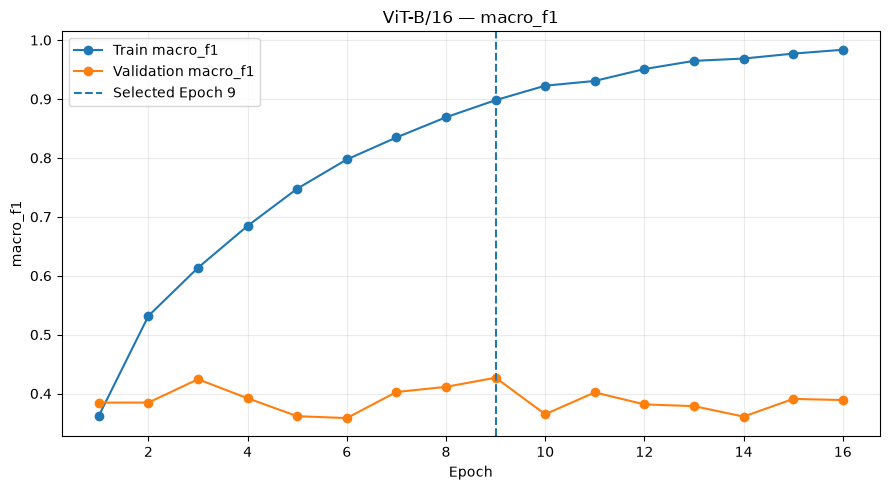

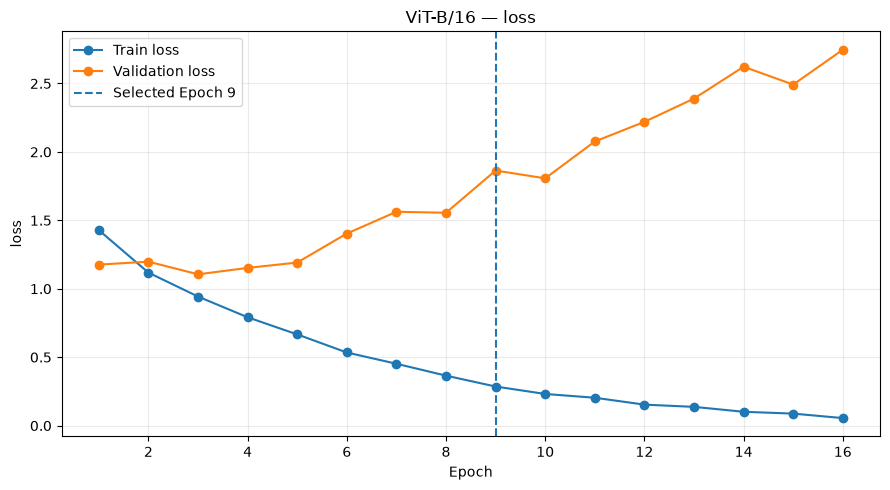

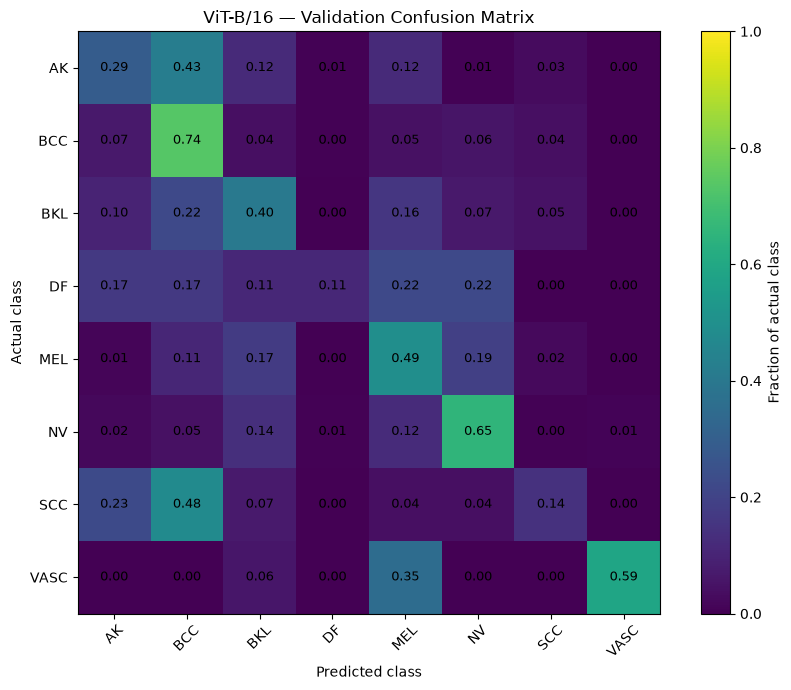

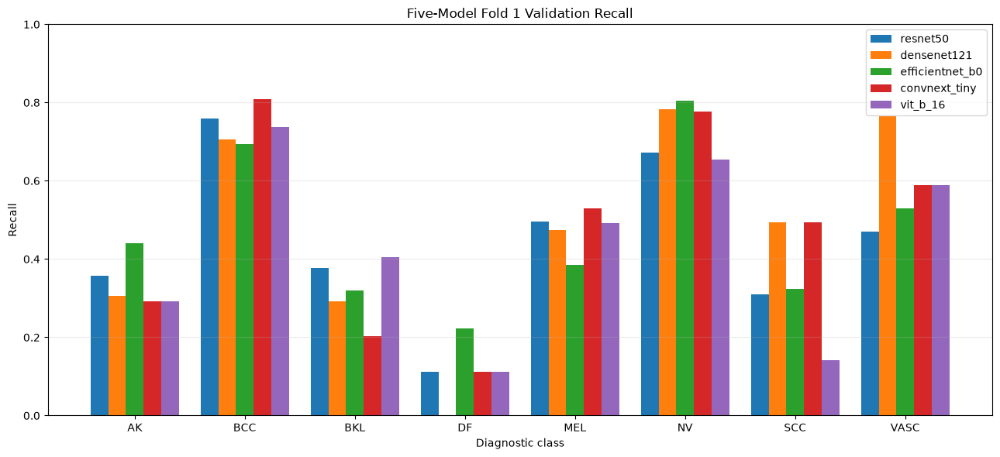

[PASS] All four figures saved

[19] CHECKPOINT SAFETY
[PASS] ResNet50 A checkpoint unchanged
[PASS] ResNet50 B checkpoint unchanged
[PASS] DenseNet121 best checkpoint unchanged
[PASS] DenseNet121 last checkpoint unchanged
[PASS] EfficientNet-B0 best checkpoint unchanged
[PASS] EfficientNet-B0 last checkpoint unchanged
[PASS] ConvNeXt-Tiny best checkpoint unchanged
[PASS] ConvNeXt-Tiny last checkpoint unchanged
[PASS] ViT-B/16 best checkpoint unchanged
[PASS] ViT-B/16 last checkpoint unchanged

VIT-B/16 BEST CHECKPOINT AUDIT VERIFICATION
[PASS] ViT configuration exists
[PASS] ViT training report exists
[PASS] ViT setup report exists
[PASS] ViT best checkpoint exists
[PASS] ViT last checkpoint exists
[PASS] Training manifest exists
[PASS] Validation manifest exists
[PASS] resnet50 completed audit exists
[PASS] densenet121 completed audit exists
[PASS] efficientnet_b0 completed audit exists
[PASS] convnext_tiny completed audit exists
[PASS] resnet50 predictions exists
[PASS] densenet121 p

In [125]:

# ============================================================
# BCN20000 - PHASE 05D - CELL 4
# VIT-B/16 INDEPENDENT BEST CHECKPOINT AUDIT
# FIVE-MODEL VALIDATION COMPARISON
# ============================================================

import os
import gc
import json
import math
import time
import hashlib
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torchvision.models import vit_b_16
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from IPython.display import display

print("=" * 78)
print("PHASE 05D - CELL 4")
print("VIT-B/16 BEST CHECKPOINT AUDIT")
print("=" * 78)


# ============================================================
# 1. PATHS
# ============================================================

V4_OUT = Path.cwd() / "outputs"

V4_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

V4_IDS = {
    "resnet50":
        "resnet50_original_fold01_sqrt_weighted_ce_seed42",
    "densenet121":
        "densenet121_original_fold01_sqrt_weighted_ce_seed42",
    "efficientnet_b0":
        "efficientnet_b0_original_fold01_sqrt_weighted_ce_seed42",
    "convnext_tiny":
        "convnext_tiny_original_fold01_sqrt_weighted_ce_seed42",
    "vit_b_16":
        "vit_b_16_original_fold01_sqrt_weighted_ce_seed42"
}

V4_ID = V4_IDS["vit_b_16"]

V4_CONFIG = (
    V4_OUT / "configs/full_training" / f"{V4_ID}.json"
)

V4_TRAINING = (
    V4_OUT / "reports" / f"{V4_ID}_training_report.json"
)

V4_SETUP = (
    V4_OUT / "reports" /
    "vit_b_16_original_fold01_full_training_setup_verification.json"
)

V4_CKPT_DIR = (
    V4_OUT / "checkpoints/full_training/vit_b_16/"
    "original/fold_01/sqrt_weighted_ce"
)

V4_BEST = V4_CKPT_DIR / "best_checkpoint.pt"
V4_LAST = V4_CKPT_DIR / "last_checkpoint.pt"

V4_TRAIN_CSV = (
    V4_OUT / "splits/original_branch/fold_01_train.csv"
)

V4_VAL_CSV = (
    V4_OUT / "splits/original_branch/fold_01_validation.csv"
)

V4_PREVIOUS = [
    "resnet50",
    "densenet121",
    "efficientnet_b0",
    "convnext_tiny"
]

V4_AUDIT_PATHS = {
    name: (
        V4_OUT / "reports" /
        f"{V4_IDS[name]}_best_checkpoint_audit.json"
    )
    for name in V4_PREVIOUS
}

V4_PRED_PATHS = {
    name: (
        V4_OUT / "predictions/full_training" /
        f"{V4_IDS[name]}_validation_predictions.csv"
    )
    for name in V4_PREVIOUS
}

V4_PRED_OUT = (
    V4_OUT / "predictions/full_training" /
    f"{V4_ID}_validation_predictions.csv"
)

V4_CLASS_OUT = (
    V4_OUT / "reports" /
    f"{V4_ID}_per_class_metrics.csv"
)

V4_COMPARE_OUT = (
    V4_OUT / "reports" /
    "five_model_original_fold01_validation_comparison.csv"
)

V4_CLASS_COMPARE_OUT = (
    V4_OUT / "reports" /
    "five_model_original_fold01_class_comparison.csv"
)

V4_PAIRED_OUT = (
    V4_OUT / "reports" /
    "five_model_original_fold01_paired_correctness.csv"
)

V4_AUDIT_OUT = (
    V4_OUT / "reports" /
    f"{V4_ID}_best_checkpoint_audit.json"
)

V4_FIG_DIR = V4_OUT / "figures"

V4_PROTECTED = {
    "ResNet50 A": (
        V4_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt"
    ),
    "ResNet50 B": (
        V4_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 best": (
        V4_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 last": (
        V4_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "EfficientNet-B0 best": (
        V4_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "EfficientNet-B0 last": (
        V4_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "ConvNeXt-Tiny best": (
        V4_OUT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "ConvNeXt-Tiny last": (
        V4_OUT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "ViT-B/16 best": V4_BEST,
    "ViT-B/16 last": V4_LAST
}

V4_DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

V4_CHECKS = {}
V4_FIGURES = []


# ============================================================
# 2. HELPERS
# ============================================================

def v4_check(name, condition):
    passed = bool(condition)
    V4_CHECKS[name] = passed
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")


def v4_require_pass():
    failed = [
        name for name, passed in V4_CHECKS.items()
        if not passed
    ]

    if failed:
        raise RuntimeError(
            "Audit BLOCKED:\n" + "\n".join(failed)
        )


def v4_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def v4_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def v4_signature(config):
    unsigned = {
        key: value
        for key, value in config.items()
        if key != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


def v4_atomic_json(data, path):
    path.parent.mkdir(parents=True, exist_ok=True)

    temporary = path.with_name(
        path.name + ".temporary"
    )

    try:
        with open(
            temporary, "w", encoding="utf-8"
        ) as f:
            json.dump(
                data,
                f,
                indent=4,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


def v4_atomic_csv(frame, path):
    path.parent.mkdir(parents=True, exist_ok=True)

    temporary = path.with_name(
        path.name + ".temporary"
    )

    try:
        frame.to_csv(temporary, index=False)
        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


def v4_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=np.int64)
    predicted = np.asarray(predicted, dtype=np.int64)

    if (
        len(actual) != len(predicted)
        or len(actual) == 0
        or not np.all((actual >= 0) & (actual < 8))
        or not np.all((predicted >= 0) & (predicted < 8))
    ):
        raise ValueError("Invalid labels or predictions.")

    cm = np.zeros((8, 8), dtype=np.int64)

    np.add.at(cm, (actual, predicted), 1)

    tp = cm.diagonal().astype(float)
    support = cm.sum(axis=1).astype(float)
    predicted_count = cm.sum(axis=0).astype(float)

    precision = np.divide(
        tp,
        predicted_count,
        out=np.zeros(8),
        where=predicted_count > 0
    )

    recall = np.divide(
        tp,
        support,
        out=np.zeros(8),
        where=support > 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(8),
        where=(precision + recall) > 0
    )

    return {
        "accuracy": float(tp.sum() / len(actual)),
        "macro_f1": float(f1.mean()),
        "weighted_f1": float(
            np.dot(f1, support) / len(actual)
        ),
        "balanced_accuracy": float(
            recall[support > 0].mean()
        ),
        "confusion_matrix": cm.tolist(),
        "precision": precision.tolist(),
        "recall": recall.tolist(),
        "f1": f1.tolist(),
        "support": support.astype(int).tolist(),
        "predicted_count": (
            predicted_count.astype(int).tolist()
        )
    }


# ============================================================
# 3. REQUIRED ARTIFACT VERIFICATION
# ============================================================

print("\n[1] REQUIRED ARTIFACT VERIFICATION")

required = {
    "ViT configuration": V4_CONFIG,
    "ViT training report": V4_TRAINING,
    "ViT setup report": V4_SETUP,
    "ViT best checkpoint": V4_BEST,
    "ViT last checkpoint": V4_LAST,
    "Training manifest": V4_TRAIN_CSV,
    "Validation manifest": V4_VAL_CSV
}

for name, path in V4_AUDIT_PATHS.items():
    required[f"{name} completed audit"] = path

for name, path in V4_PRED_PATHS.items():
    required[f"{name} predictions"] = path

required.update(V4_PROTECTED)

for name, path in required.items():
    v4_check(
        f"{name} exists",
        path.is_file()
    )

v4_check(
    "Dataset factory available",
    callable(globals().get("create_bcn_dataset"))
)

v4_require_pass()


# ============================================================
# 4. TRAINING REPORT VERIFICATION
# ============================================================

print("\n[2] TRAINING REPORT VERIFICATION")

config = v4_json(V4_CONFIG)
training = v4_json(V4_TRAINING)
setup = v4_json(V4_SETUP)

previous_audits = {
    name: v4_json(path)
    for name, path in V4_AUDIT_PATHS.items()
}

V4_EXPECTED_SIGNATURE = (
    "c1f5ea42075122e48f6621033d6439d"
    "9628c98b816b6784d22dce3288557b13c"
)

signature = v4_signature(config)

v4_check(
    "ViT configuration fingerprint valid",
    signature
    == config.get("config_signature")
    == setup.get("configuration_signature")
    == V4_EXPECTED_SIGNATURE
)

v4_check(
    "ViT training PASS",
    training.get("status") == "PASS"
)

v4_check(
    "ViT setup PASS",
    setup.get("status") == "PASS"
    and bool(setup.get("checks"))
    and all(setup["checks"].values())
)

v4_check(
    "Experiment IDs correct",
    config.get("experiment_id") == V4_ID
    and training.get("experiment_id") == V4_ID
)

v4_check(
    "Correct ViT architecture",
    config.get("model") == "vit_b_16"
    and config.get("classifier_path") == "heads.head"
    and config.get("num_classes") == 8
)

v4_check(
    "Correct branch and fold",
    config.get("branch") == "original"
    and config.get("fold") == 1
)

v4_check(
    "Eight-class ordering preserved",
    config.get("class_names") == V4_CLASSES
)

v4_check(
    "Training completed 16 epochs",
    training.get("completed_epochs") == 16
)

v4_check(
    "Selected best epoch = 9",
    training.get("best_epoch") == 9
)

v4_check(
    "Early stopping triggered",
    training.get("early_stopped") is True
    and training.get("early_stopping_wait") == 7
)

v4_check(
    "Outer-test protected",
    training.get("outer_test_evaluated") is False
    and config.get("outer_test_for_tuning") is False
)

for name, audit in previous_audits.items():
    v4_check(
        f"{name} prior audit PASS",
        audit.get("status") == "PASS"
        and audit.get("outer_test_evaluated") is False
        and bool(audit.get("checks"))
        and all(audit["checks"].values())
    )

history = training.get("history", [])

v4_check(
    "All 16 training epochs recorded",
    len(history) == 16
    and [
        int(row["epoch"]) for row in history
    ] == list(range(1, 17))
)

v4_check(
    "All epochs evaluated full validation",
    bool(history)
    and all(
        int(row["train_samples"]) == 7813
        and int(row["validation_samples"]) == 1973
        and int(row["optimizer_step_attempts"]) == 489
        for row in history
    )
)

v4_require_pass()

best_row = history[8]

v4_check(
    "Selected best Macro-F1 matches report",
    math.isclose(
        float(best_row["validation_macro_f1"]),
        float(training["best_validation_macro_f1"]),
        rel_tol=0,
        abs_tol=1e-12
    )
)

v4_check(
    "Selected epoch is the maximum logged Macro-F1",
    math.isclose(
        float(best_row["validation_macro_f1"]),
        max(
            float(row["validation_macro_f1"])
            for row in history
        ),
        rel_tol=0,
        abs_tol=1e-12
    )
)

v4_require_pass()

print("Completed epochs: 16")
print("Selected best epoch: 9")
print(
    "Logged best validation Macro-F1:",
    training["best_validation_macro_f1"]
)


# ============================================================
# 5. CHECKPOINT HASH SNAPSHOTS
# ============================================================

print("\n[3] CHECKPOINT SAFETY SNAPSHOT")

protected_hashes = {
    name: v4_hash(path)
    for name, path in V4_PROTECTED.items()
}

print(
    "Protected checkpoint files:",
    len(protected_hashes)
)

print("Checkpoint SHA256 snapshots: CREATED")


# ============================================================
# 6. BEST AND LAST CHECKPOINT INTEGRITY
# ============================================================

print("\n[4] CHECKPOINT INTEGRITY")

# Load Last checkpoint first, validate and release.
# This avoids holding two large ViT checkpoint files
# simultaneously in system memory.

last_state = torch.load(
    V4_LAST,
    map_location="cpu",
    weights_only=True
)

v4_check(
    "Last checkpoint = Epoch 16",
    int(last_state["completed_epoch"]) == 16
)

v4_check(
    "Last checkpoint type correct",
    last_state.get("checkpoint_kind")
    == "full_training_last"
)

v4_check(
    "Last checkpoint experiment ID correct",
    last_state.get("experiment_id") == V4_ID
)

v4_check(
    "Last checkpoint signature correct",
    last_state.get("configuration_signature")
    == signature
)

v4_check(
    "Last checkpoint history length = 16",
    len(last_state.get("history", [])) == 16
)

del last_state
gc.collect()

best_state = torch.load(
    V4_BEST,
    map_location="cpu",
    weights_only=True
)

v4_check(
    "Best checkpoint = Epoch 9",
    int(best_state["completed_epoch"]) == 9
)

v4_check(
    "Best checkpoint type correct",
    best_state.get("checkpoint_kind")
    == "full_training_best"
)

v4_check(
    "Best checkpoint experiment ID correct",
    best_state.get("experiment_id") == V4_ID
)

v4_check(
    "Best checkpoint signature correct",
    best_state.get("configuration_signature")
    == signature
)

v4_check(
    "Best checkpoint history length = 9",
    len(best_state.get("history", [])) == 9
)

v4_check(
    "Eight-class classifier shape correct",
    tuple(
        best_state["model_state_dict"][
            "heads.head.weight"
        ].shape
    ) == (8, 768)
)

v4_check(
    "Best Macro-F1 metadata correct",
    math.isclose(
        float(
            best_state["best_validation_macro_f1"]
        ),
        float(training["best_validation_macro_f1"]),
        rel_tol=0,
        abs_tol=1e-12
    )
)

v4_require_pass()

print("Best checkpoint integrity: VERIFIED")
print("Last checkpoint integrity: VERIFIED")


# ============================================================
# 7. VALIDATION DATASET
# ============================================================

print("\n[5] DATASET VERIFICATION")

columns = [
    "bcn_filename",
    "diagnosis",
    "leakage_group_id"
]

train_manifest = pd.read_csv(
    V4_TRAIN_CSV,
    usecols=columns,
    dtype="string"
)

val_manifest = pd.read_csv(
    V4_VAL_CSV,
    usecols=columns,
    dtype="string"
)

dataset = create_bcn_dataset(
    "original", 1, "validation"
)

loader = DataLoader(
    dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(V4_DEVICE.type == "cuda"),
    drop_last=False
)

v4_check(
    "Validation samples = 1973",
    len(dataset) == 1973
    and len(val_manifest) == 1973
)

v4_check(
    "Validation batches = 494",
    len(loader) == 494
)

v4_check(
    "Validation leakage groups = 571",
    val_manifest["leakage_group_id"].nunique() == 571
)

v4_check(
    "Training-validation groups disjoint",
    set(
        train_manifest["leakage_group_id"]
    ).isdisjoint(
        set(val_manifest["leakage_group_id"])
    )
)

v4_check(
    "Validation filenames unique",
    val_manifest["bcn_filename"].is_unique
)

v4_check(
    "No missing validation metadata",
    not val_manifest.isna().any().any()
)

v4_require_pass()


# ============================================================
# 8. LOAD SELECTED EPOCH-9 VIT-B/16
# ============================================================

print("\n[6] LOADING SELECTED BEST MODEL")

model = vit_b_16(weights=None)

if (
    model.image_size != 224
    or model.patch_size != 16
    or model.heads.head.in_features != 768
):
    raise RuntimeError(
        "Unexpected ViT-B/16 architecture."
    )

model.heads.head = nn.Linear(768, 8)

model.load_state_dict(
    best_state["model_state_dict"],
    strict=True
)

del best_state
gc.collect()

model = model.to(V4_DEVICE)
model.eval()

v4_check(
    "Best model loaded in evaluation mode",
    not model.training
)

print("Model: ViT-B/16")
print("Checkpoint: Epoch 9")
print("Training: DISABLED")


# ============================================================
# 9. INDEPENDENT VALIDATION INFERENCE
# ============================================================

print("\n[7] INDEPENDENT VALIDATION INFERENCE")

actual_all = []
predicted_all = []
filename_all = []
group_all = []
probability_batches = []

loss_total = 0.0
total_samples = 0

use_amp = (
    V4_DEVICE.type == "cuda"
    and config.get("mixed_precision") is True
)

start = time.perf_counter()

with torch.inference_mode():

    for batch in tqdm(
        loader,
        desc="ViT-B/16 Epoch 9 Audit"
    ):

        images = batch["image"].to(
            V4_DEVICE,
            non_blocking=True
        )

        labels = batch["label"].to(
            V4_DEVICE,
            non_blocking=True
        )

        with torch.autocast(
            device_type=V4_DEVICE.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            logits = model(images)

        logits = logits.float()

        if not bool(
            torch.isfinite(logits).all().item()
        ):
            raise FloatingPointError(
                "Non-finite validation logits."
            )

        loss = F.cross_entropy(
            logits,
            labels
        )

        if not bool(
            torch.isfinite(loss).item()
        ):
            raise FloatingPointError(
                "Non-finite validation loss."
            )

        probabilities = torch.softmax(
            logits, dim=1
        )

        predictions = logits.argmax(
            dim=1
        )

        n = int(labels.size(0))

        loss_total += float(loss.item()) * n
        total_samples += n

        actual_all.extend(
            labels.cpu().tolist()
        )

        predicted_all.extend(
            predictions.cpu().tolist()
        )

        filename_all.extend(
            str(x)
            for x in batch["filename"]
        )

        group_all.extend(
            str(x)
            for x in batch["leakage_group_id"]
        )

        probability_batches.append(
            probabilities.cpu().numpy()
        )

elapsed = time.perf_counter() - start

y_true = np.asarray(
    actual_all,
    dtype=np.int64
)

y_pred = np.asarray(
    predicted_all,
    dtype=np.int64
)

prob_matrix = np.concatenate(
    probability_batches,
    axis=0
)

v4_check(
    "1973 predictions generated",
    total_samples == 1973
    and len(y_true) == 1973
    and len(y_pred) == 1973
)

v4_check(
    "Probability shape = (1973, 8)",
    prob_matrix.shape == (1973, 8)
)

v4_check(
    "All probabilities finite",
    bool(np.isfinite(prob_matrix).all())
)

v4_check(
    "Probability rows normalized",
    bool(np.allclose(
        prob_matrix.sum(axis=1),
        1.0,
        atol=1e-5
    ))
)

v4_check(
    "Predictions match probability argmax",
    bool(np.array_equal(
        y_pred,
        prob_matrix.argmax(axis=1)
    ))
)

v4_require_pass()

print("Images evaluated:", total_samples)
print("Inference seconds:", round(elapsed, 2))


# ============================================================
# 10. RECOMPUTE VALIDATION METRICS
# ============================================================

print("\n[8] RECOMPUTED VALIDATION METRICS")

metrics = v4_metrics(y_true, y_pred)

metrics["loss"] = float(
    loss_total / total_samples
)

metric_keys = {
    "accuracy": "validation_accuracy",
    "macro_f1": "validation_macro_f1",
    "weighted_f1": "validation_weighted_f1",
    "balanced_accuracy": "validation_balanced_accuracy",
    "loss": "validation_loss"
}

for metric, history_key in metric_keys.items():

    logged = float(
        best_row[history_key]
    )

    computed = float(
        metrics[metric]
    )

    difference = abs(
        logged - computed
    )

    tolerance = (
        1e-4 if metric == "loss"
        else 1e-5
    )

    v4_check(
        f"Reproduced {metric}",
        difference <= tolerance
    )

    print(
        f"{metric:19s} | "
        f"Logged: {logged:.6f} | "
        f"Recomputed: {computed:.6f} | "
        f"Difference: {difference:.9f}"
    )

cm = np.asarray(
    metrics["confusion_matrix"],
    dtype=np.int64
)

v4_check(
    "Confusion matrix matches Epoch 9",
    np.array_equal(
        cm,
        np.asarray(
            best_row["validation_confusion_matrix"],
            dtype=np.int64
        )
    )
)

v4_check(
    "Confusion matrix totals 1973",
    int(cm.sum()) == 1973
)

v4_require_pass()


# ============================================================
# 11. PREDICTION METADATA VERIFICATION
# ============================================================

print("\n[9] PREDICTION METADATA VERIFICATION")

pred_df = pd.DataFrame({
    "filename": filename_all,
    "leakage_group_id": group_all,
    "actual_idx": y_true,
    "predicted_idx": y_pred,
    "actual_class": [
        V4_CLASSES[i] for i in y_true
    ],
    "predicted_class": [
        V4_CLASSES[i] for i in y_pred
    ],
    "confidence": prob_matrix.max(axis=1)
})

prob_columns = []

for index, name in enumerate(V4_CLASSES):

    column = f"prob_{name}"
    prob_columns.append(column)

    pred_df[column] = (
        prob_matrix[:, index]
    )

reference = val_manifest.rename(
    columns={
        "bcn_filename": "filename",
        "diagnosis": "manifest_diagnosis",
        "leakage_group_id": "manifest_group"
    }
)

aligned = pred_df.merge(
    reference,
    on="filename",
    how="left",
    validate="one_to_one",
    indicator=True
)

v4_check(
    "All filenames match validation manifest",
    len(aligned) == 1973
    and bool(
        aligned["_merge"].eq("both").all()
    )
)

v4_check(
    "Ground-truth labels match manifest",
    bool((
        aligned["actual_class"].astype(str)
        == aligned["manifest_diagnosis"].astype(str)
    ).all())
)

v4_check(
    "Leakage groups match manifest",
    bool((
        aligned["leakage_group_id"].astype(str)
        == aligned["manifest_group"].astype(str)
    ).all())
)

v4_check(
    "Prediction filenames unique",
    pred_df["filename"].is_unique
)

v4_require_pass()


# ============================================================
# 12. VIT-B/16 CLASS-WISE PERFORMANCE
# ============================================================

print("\n[10] VIT-B/16 CLASS-WISE PERFORMANCE")

top3 = np.argsort(
    -prob_matrix,
    axis=1
)[:, :3]

class_rows = []

for index, name in enumerate(V4_CLASSES):

    mask = y_true == index
    support = int(mask.sum())

    top3_accuracy = (
        float(
            np.any(
                top3[mask] == index,
                axis=1
            ).mean()
        )
        if support > 0
        else 0.0
    )

    class_rows.append({
        "class": name,
        "validation_support": support,
        "predicted_count": int(
            metrics["predicted_count"][index]
        ),
        "precision": float(
            metrics["precision"][index]
        ),
        "recall": float(
            metrics["recall"][index]
        ),
        "f1": float(
            metrics["f1"][index]
        ),
        "top3_accuracy": top3_accuracy
    })

class_df = pd.DataFrame(
    class_rows
)

display(class_df.round(6))

v4_check(
    "All eight classes evaluated",
    len(class_df) == 8
)

v4_check(
    "Class supports total 1973",
    int(
        class_df["validation_support"].sum()
    ) == 1973
)

v4_require_pass()

zero_recall = class_df.loc[
    class_df["recall"] == 0,
    "class"
].tolist()

print("\nZero-recall classes:", zero_recall)

print("\nPriority-class recall:")

class_index = class_df.set_index(
    "class"
)

for name in [
    "DF", "VASC", "SCC", "MEL"
]:

    row = class_index.loc[name]

    support = int(
        row["validation_support"]
    )

    correct = int(round(
        row["recall"] * support
    ))

    print(
        f"{name}: "
        f"{row['recall']:.6f} "
        f"({correct}/{support})"
    )


# ============================================================
# 13. GROUP-LEVEL EXPLORATORY EVALUATION
# ============================================================

print("\n[11] GROUP-LEVEL EXPLORATORY EVALUATION")

group_label_counts = pred_df.groupby(
    "leakage_group_id"
)["actual_idx"].nunique()

v4_check(
    "Each leakage group has one true class",
    bool(
        (group_label_counts == 1).all()
    )
)

v4_require_pass()

group_probs = pred_df.groupby(
    "leakage_group_id"
)[prob_columns].mean()

group_truth = pred_df.groupby(
    "leakage_group_id"
)["actual_idx"].first()

group_pred = group_probs.to_numpy().argmax(
    axis=1
)

group_metrics = v4_metrics(
    group_truth.to_numpy(
        dtype=np.int64
    ),
    group_pred
)

v4_check(
    "571 groups evaluated",
    len(group_truth) == 571
)

print(
    "Exploratory group Macro-F1:",
    round(
        group_metrics["macro_f1"],
        6
    )
)

v4_require_pass()


# ============================================================
# 14. MISCLASSIFICATION ANALYSIS
# ============================================================

print("\n[12] TOP MISCLASSIFICATIONS")

error_rows = []

for actual in range(8):

    for predicted in range(8):

        if actual == predicted:
            continue

        count = int(
            cm[actual, predicted]
        )

        if count > 0:

            error_rows.append({
                "actual_class": V4_CLASSES[actual],
                "predicted_class": V4_CLASSES[predicted],
                "error_count": count
            })

error_df = pd.DataFrame(
    error_rows,
    columns=[
        "actual_class",
        "predicted_class",
        "error_count"
    ]
).sort_values(
    "error_count",
    ascending=False
)

display(error_df.head(12))


# ============================================================
# 15. FIVE-MODEL GLOBAL COMPARISON
# ============================================================

print("\n[13] FIVE-MODEL VALIDATION COMPARISON")

all_metrics = {
    name: previous_audits[name][
        "validation_metrics"
    ]
    for name in V4_PREVIOUS
}

all_metrics["vit_b_16"] = metrics

compare_rows = []

for metric in [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy",
    "loss"
]:

    row = {"metric": metric}

    for name in V4_IDS:

        row[name] = float(
            all_metrics[name][metric]
        )

    compare_rows.append(row)

compare_df = pd.DataFrame(
    compare_rows
)

display(compare_df.round(6))


# ============================================================
# 16. FIVE-MODEL CLASS COMPARISON
# ============================================================

print("\n[14] FIVE-MODEL CLASS-WISE COMPARISON")

all_class_records = {
    name: {
        row["class"]: row
        for row in previous_audits[name][
            "per_class_metrics"
        ]
    }
    for name in V4_PREVIOUS
}

all_class_records["vit_b_16"] = {
    row["class"]: row
    for row in class_rows
}

class_compare_rows = []

for class_name in V4_CLASSES:

    support = int(
        all_class_records["vit_b_16"][
            class_name
        ]["validation_support"]
    )

    row = {
        "class": class_name,
        "support": support
    }

    for model_name in V4_IDS:

        record = all_class_records[
            model_name
        ][class_name]

        row[
            f"{model_name}_recall"
        ] = float(record["recall"])

        row[
            f"{model_name}_f1"
        ] = float(record["f1"])

    class_compare_rows.append(row)

class_compare_df = pd.DataFrame(
    class_compare_rows
)

display(class_compare_df.round(6))

v4_check(
    "Eight classes compared across five models",
    len(class_compare_df) == 8
)

v4_check(
    "Class support identical across five models",
    all(
        int(
            all_class_records[model_name][
                class_name
            ]["validation_support"]
        )
        == int(
            all_class_records["vit_b_16"][
                class_name
            ]["validation_support"]
        )
        for model_name in V4_IDS
        for class_name in V4_CLASSES
    )
)

v4_require_pass()


# ============================================================
# 17. FIVE-MODEL PAIRED PREDICTION COMPARISON
# ============================================================

print("\n[15] FIVE-MODEL PAIRED PREDICTIONS")

paired_columns = [
    "filename",
    "actual_idx",
    "predicted_idx",
    "leakage_group_id"
]


def v4_named(frame, name):

    return frame[paired_columns].rename(
        columns={
            "actual_idx": f"actual_{name}",
            "predicted_idx": f"pred_{name}",
            "leakage_group_id": f"group_{name}"
        }
    )


paired = v4_named(
    pred_df,
    "vit_b_16"
)

for name in V4_PREVIOUS:

    previous_predictions = pd.read_csv(
        V4_PRED_PATHS[name],
        usecols=paired_columns,
        dtype={
            "filename": "string",
            "leakage_group_id": "string"
        }
    )

    v4_check(
        f"{name} predictions unique",
        len(previous_predictions) == 1973
        and previous_predictions["filename"].is_unique
    )

    paired = paired.merge(
        v4_named(previous_predictions, name),
        on="filename",
        how="inner",
        validate="one_to_one"
    )

v4_require_pass()

v4_check(
    "All five models evaluated same 1973 images",
    len(paired) == 1973
)

v4_check(
    "All five models share identical ground truth",
    all(
        bool((
            paired[f"actual_{name}"]
            == paired["actual_vit_b_16"]
        ).all())
        for name in V4_IDS
    )
)

v4_check(
    "All five models share identical leakage groups",
    all(
        bool((
            paired[f"group_{name}"].astype(str)
            == paired["group_vit_b_16"].astype(str)
        ).all())
        for name in V4_IDS
    )
)

v4_require_pass()


# ============================================================
# 18. INDEPENDENTLY VERIFY PREVIOUS PREDICTIONS
# ============================================================

print("\n[16] PREVIOUS MODEL METRIC CONSISTENCY")

for name in V4_PREVIOUS:

    recomputed = v4_metrics(
        paired[f"actual_{name}"].to_numpy(),
        paired[f"pred_{name}"].to_numpy()
    )

    previous_logged = (
        previous_audits[name]["validation_metrics"]
    )

    consistent = all(
        math.isclose(
            float(recomputed[metric]),
            float(previous_logged[metric]),
            rel_tol=0,
            abs_tol=1e-8
        )
        for metric in [
            "accuracy",
            "macro_f1",
            "weighted_f1",
            "balanced_accuracy"
        ]
    )

    v4_check(
        f"{name} predictions reproduce audit",
        consistent
    )

v4_require_pass()


# ============================================================
# 19. PAIRED CORRECTNESS PATTERNS
# ============================================================

model_order = list(
    V4_IDS.keys()
)

correctness = {
    name: (
        paired[f"actual_{name}"].to_numpy()
        == paired[f"pred_{name}"].to_numpy()
    )
    for name in model_order
}

pattern_rows = []

for pattern in product(
    [0, 1],
    repeat=5
):

    selected = np.ones(
        len(paired),
        dtype=bool
    )

    for name, flag in zip(
        model_order,
        pattern
    ):

        selected &= (
            correctness[name] == bool(flag)
        )

    row = {
        "pattern": "".join(
            str(flag)
            for flag in pattern
        ),
        "count": int(selected.sum())
    }

    for name, flag in zip(
        model_order,
        pattern
    ):

        row[f"{name}_correct"] = flag

    pattern_rows.append(row)

paired_df = pd.DataFrame(
    pattern_rows
).sort_values(
    "count",
    ascending=False
)

v4_check(
    "All 32 correctness patterns sum to 1973",
    len(paired_df) == 32
    and int(paired_df["count"].sum()) == 1973
)

v4_require_pass()

print("\nPattern order:")
print(
    "ResNet50 | DenseNet121 | EfficientNet-B0 | "
    "ConvNeXt-Tiny | ViT-B/16"
)

display(
    paired_df.head(12)
)

paired_summary = {
    "all_five_correct": int(
        np.logical_and.reduce([
            correctness[name]
            for name in model_order
        ]).sum()
    ),
    "all_five_wrong": int(
        np.logical_and.reduce([
            ~correctness[name]
            for name in model_order
        ]).sum()
    )
}

for name in V4_PREVIOUS:

    paired_summary[
        f"vit_only_correct_vs_{name}"
    ] = int((
        correctness["vit_b_16"]
        & ~correctness[name]
    ).sum())

    paired_summary[
        f"{name}_only_correct_vs_vit"
    ] = int((
        ~correctness["vit_b_16"]
        & correctness[name]
    ).sum())

print("\nPaired correctness summary:")

for key, value in paired_summary.items():
    print(f"{key}: {value}")


# ============================================================
# 20. SAVE AUDIT TABLES
# ============================================================

print("\n[17] SAVING AUDIT TABLES")

outputs = {
    "ViT predictions": (
        pred_df,
        V4_PRED_OUT
    ),
    "ViT per-class metrics": (
        class_df,
        V4_CLASS_OUT
    ),
    "Five-model global comparison": (
        compare_df,
        V4_COMPARE_OUT
    ),
    "Five-model class comparison": (
        class_compare_df,
        V4_CLASS_COMPARE_OUT
    ),
    "Five-model paired comparison": (
        paired_df,
        V4_PAIRED_OUT
    )
}

for name, (frame, path) in outputs.items():

    v4_atomic_csv(frame, path)

    v4_check(
        f"{name} saved",
        path.is_file()
    )

v4_require_pass()


# ============================================================
# 21. TRAINING CURVES
# ============================================================

print("\n[18] GENERATING FIGURES")

V4_FIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

history_df = pd.DataFrame(
    history
)

for metric, filename in [
    (
        "macro_f1",
        "vit_b_16_fold01_macro_f1.png"
    ),
    (
        "loss",
        "vit_b_16_fold01_loss.png"
    )
]:

    path = V4_FIG_DIR / filename

    plt.figure(figsize=(9, 5))

    plt.plot(
        history_df["epoch"],
        history_df[f"train_{metric}"],
        marker="o",
        label=f"Train {metric}"
    )

    plt.plot(
        history_df["epoch"],
        history_df[f"validation_{metric}"],
        marker="o",
        label=f"Validation {metric}"
    )

    plt.axvline(
        9,
        linestyle="--",
        label="Selected Epoch 9"
    )

    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.title(f"ViT-B/16 — {metric}")

    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    V4_FIGURES.append(str(path))


# ============================================================
# 22. NORMALIZED CONFUSION MATRIX
# ============================================================

cm_path = (
    V4_FIG_DIR /
    "vit_b_16_fold01_confusion_matrix.png"
)

row_totals = cm.sum(
    axis=1,
    keepdims=True
)

normalized_cm = np.divide(
    cm,
    row_totals,
    out=np.zeros((8, 8)),
    where=row_totals > 0
)

plt.figure(figsize=(9, 7))

plt.imshow(
    normalized_cm,
    vmin=0,
    vmax=1
)

plt.colorbar(
    label="Fraction of actual class"
)

plt.xticks(
    range(8),
    V4_CLASSES,
    rotation=45
)

plt.yticks(
    range(8),
    V4_CLASSES
)

for i in range(8):
    for j in range(8):

        plt.text(
            j, i,
            f"{normalized_cm[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title(
    "ViT-B/16 — Validation Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

V4_FIGURES.append(
    str(cm_path)
)


# ============================================================
# 23. FIVE-MODEL CLASS RECALL FIGURE
# ============================================================

recall_path = (
    V4_FIG_DIR /
    "five_model_fold01_class_recall_comparison.png"
)

x = np.arange(8)
width = 0.16

plt.figure(
    figsize=(13, 6)
)

for index, name in enumerate(model_order):

    offset = (
        index - 2
    ) * width

    plt.bar(
        x + offset,
        class_compare_df[f"{name}_recall"],
        width,
        label=name
    )

plt.xticks(x, V4_CLASSES)
plt.ylim(0, 1)

plt.xlabel("Diagnostic class")
plt.ylabel("Recall")

plt.title(
    "Five-Model Fold 1 Validation Recall"
)

plt.legend()
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    recall_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

V4_FIGURES.append(
    str(recall_path)
)

v4_check(
    "All four figures saved",
    len(V4_FIGURES) == 4
    and all(
        Path(path).is_file()
        for path in V4_FIGURES
    )
)

v4_require_pass()


# ============================================================
# 24. FINAL CHECKPOINT SAFETY
# ============================================================

print("\n[19] CHECKPOINT SAFETY")

for name, path in V4_PROTECTED.items():

    v4_check(
        f"{name} checkpoint unchanged",
        v4_hash(path) == protected_hashes[name]
    )

v4_require_pass()


# ============================================================
# 25. SAVE FINAL AUDIT REPORT
# ============================================================

print("\n" + "=" * 78)
print("VIT-B/16 BEST CHECKPOINT AUDIT VERIFICATION")
print("=" * 78)

for name, passed in V4_CHECKS.items():
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

V4_STATUS = (
    "PASS"
    if V4_CHECKS and all(V4_CHECKS.values())
    else "BLOCKED"
)

audit_report = {
    "stage": "VIT_B_16_BEST_CHECKPOINT_AUDIT",
    "status": V4_STATUS,
    "experiment_id": V4_ID,
    "model": "vit_b_16",
    "branch": "original",
    "fold": 1,
    "training_epochs": 16,
    "best_epoch": 9,
    "evaluation_partition": "validation",
    "validation_images": 1973,
    "validation_groups": 571,
    "validation_metrics": metrics,
    "per_class_metrics": class_rows,
    "group_metrics": group_metrics,
    "zero_recall_classes": zero_recall,
    "top_misclassifications": (
        error_df.head(12).to_dict(
            orient="records"
        )
    ),
    "five_model_comparison": compare_rows,
    "five_model_class_comparison": class_compare_rows,
    "paired_prediction_summary": paired_summary,
    "configuration_signature": signature,
    "best_checkpoint_sha256": (
        protected_hashes["ViT-B/16 best"]
    ),
    "last_checkpoint_sha256": (
        protected_hashes["ViT-B/16 last"]
    ),
    "prediction_csv": str(V4_PRED_OUT),
    "per_class_csv": str(V4_CLASS_OUT),
    "comparison_csv": str(V4_COMPARE_OUT),
    "class_comparison_csv": str(V4_CLASS_COMPARE_OUT),
    "paired_correctness_csv": str(V4_PAIRED_OUT),
    "figures": V4_FIGURES,
    "training_performed": False,
    "outer_test_evaluated": False,
    "checks": {
        name: bool(passed)
        for name, passed in V4_CHECKS.items()
    }
}

v4_atomic_json(
    audit_report,
    V4_AUDIT_OUT
)


# ============================================================
# 26. GPU CLEANUP
# ============================================================

del model
gc.collect()

if V4_DEVICE.type == "cuda":
    torch.cuda.empty_cache()


# ============================================================
# 27. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("VIT-B/16 BEST CHECKPOINT AUDIT SUMMARY")
print("=" * 78)

print("Status:", V4_STATUS)
print("Model: ViT-B/16")
print("Branch: original")
print("Fold: 1")
print("Completed training epochs: 16")
print("Best checkpoint epoch: 9")
print("Validation images:", total_samples)

print(
    "Reproduced Validation Macro-F1:",
    round(metrics["macro_f1"], 6)
)

print(
    "Reproduced Validation Accuracy:",
    round(metrics["accuracy"], 6)
)

print(
    "Reproduced Balanced Accuracy:",
    round(metrics["balanced_accuracy"], 6)
)

print("\nFive-model Validation Macro-F1:")

for name in V4_IDS:
    print(
        f"{name}:",
        round(
            float(
                all_metrics[name]["macro_f1"]
            ),
            6
        )
    )

print("\nZero-recall classes:", zero_recall)

print("\nBest checkpoint: VERIFIED")
print("Last checkpoint: VERIFIED")
print("Outer-test evaluated: NO")
print("Training performed during audit: NO")

print("\nAudit report:")
print(V4_AUDIT_OUT)

print("\nFive-model comparison:")
print(V4_COMPARE_OUT)

print("\nClass-wise comparison:")
print(V4_CLASS_COMPARE_OUT)

print("\nPaired correctness:")
print(V4_PAIRED_OUT)

if V4_STATUS == "PASS":

    print("\nVIT-B/16 BEST CHECKPOINT AUDIT: PASS")
    print("NEXT ARCHITECTURE: SWIN-TINY")

else:

    print("\nVIT-B/16 BEST CHECKPOINT AUDIT: BLOCKED")

print("=" * 78)


In [126]:

# ============================================================
# PHASE 05D - FINAL VIT-B/16 AUDIT CONFIRMATION
# ============================================================

import json
import math
from pathlib import Path

root = Path.cwd() / "outputs"

experiment = (
    "vit_b_16_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

audit_path = (
    root / "reports" /
    f"{experiment}_best_checkpoint_audit.json"
)

print("=" * 70)
print("VIT-B/16 FINAL AUDIT CONFIRMATION")
print("=" * 70)

if not audit_path.is_file():

    print("[FAIL] Audit report not found")
    print("FINAL: REVIEW REQUIRED")

else:

    with open(
        audit_path, "r", encoding="utf-8"
    ) as f:
        audit = json.load(f)

    checks = audit.get("checks", {})

    failed = [
        name for name, passed in checks.items()
        if not passed
    ]

    figures = audit.get("figures", [])

    figures_ok = (
        len(figures) == 4
        and all(
            Path(path).is_file()
            for path in figures
        )
    )

    expected_files = {
        "Prediction CSV": (
            root / "predictions/full_training" /
            f"{experiment}_validation_predictions.csv"
        ),
        "Per-class CSV": (
            root / "reports" /
            f"{experiment}_per_class_metrics.csv"
        ),
        "Five-model comparison": (
            root / "reports" /
            "five_model_original_fold01_validation_comparison.csv"
        ),
        "Five-model class comparison": (
            root / "reports" /
            "five_model_original_fold01_class_comparison.csv"
        ),
        "Five-model paired comparison": (
            root / "reports" /
            "five_model_original_fold01_paired_correctness.csv"
        )
    }

    files_ok = all(
        path.is_file()
        for path in expected_files.values()
    )

    metrics = audit.get("validation_metrics", {})

    score_ok = math.isclose(
        float(metrics.get("macro_f1", -1)),
        0.4268686059801282,
        rel_tol=0,
        abs_tol=1e-8
    )

    final_pass = all([
        audit.get("status") == "PASS",
        bool(checks),
        len(failed) == 0,
        audit.get("model") == "vit_b_16",
        audit.get("best_epoch") == 9,
        audit.get("training_epochs") == 16,
        audit.get("validation_images") == 1973,
        audit.get("validation_groups") == 571,
        audit.get("outer_test_evaluated") is False,
        audit.get("training_performed") is False,
        score_ok,
        figures_ok,
        files_ok
    ])

    print("Audit status:", audit.get("status"))
    print("Verification checks:", len(checks))
    print("Failed checks:", failed)
    print("Best checkpoint epoch:", audit.get("best_epoch"))
    print("Validation accuracy:", metrics.get("accuracy"))
    print("Validation Macro-F1:", metrics.get("macro_f1"))
    print("All four figures saved:", figures_ok)
    print("All five CSV files saved:", files_ok)
    print(
        "Outer-test evaluated:",
        audit.get("outer_test_evaluated")
    )

    print("\nFINAL:", "PASS" if final_pass else "REVIEW REQUIRED")

    if final_pass:
        print("NEXT: PHASE 05E - SWIN-TINY GPU READINESS")

print("=" * 70)


VIT-B/16 FINAL AUDIT CONFIRMATION
Audit status: PASS
Verification checks: 114
Failed checks: []
Best checkpoint epoch: 9
Validation accuracy: 0.5681702990369994
Validation Macro-F1: 0.4268686059801282
All four figures saved: True
All five CSV files saved: True
Outer-test evaluated: False

FINAL: PASS
NEXT: PHASE 05E - SWIN-TINY GPU READINESS


In [127]:

# ============================================================
# BCN20000 - PHASE 05E - CELL 1
# SWIN-TINY ARCHITECTURE & GPU READINESS
# ORIGINAL BRANCH | FOLD 01 | SEED 42
# ============================================================

import os
import gc
import json
import math
import random
import hashlib
import traceback

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, Subset
from torchvision.models import (
    swin_t,
    Swin_T_Weights
)

print("=" * 78)
print("PHASE 05E - CELL 1")
print("SWIN-TINY ARCHITECTURE & GPU READINESS")
print("=" * 78)


# ============================================================
# 1. PATH CONFIGURATION
# ============================================================

SW1_OUT = Path.cwd() / "outputs"

SW1_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

SW1_SOURCE_ID = (
    "vit_b_16_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

SW1_ID = (
    "swin_t_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

SW1_SOURCE_CONFIG = (
    SW1_OUT / "configs/full_training" /
    f"{SW1_SOURCE_ID}.json"
)

SW1_SOURCE_AUDIT = (
    SW1_OUT / "reports" /
    f"{SW1_SOURCE_ID}_best_checkpoint_audit.json"
)

SW1_ENGINE = (
    SW1_OUT / "reports" /
    "resnet50_weighted_engine_verification.json"
)

SW1_REPORT = (
    SW1_OUT / "reports" /
    "swin_t_original_fold01_architecture_readiness.json"
)

SW1_CKPT_DIR = (
    SW1_OUT / "checkpoints/full_training/"
    "swin_t/original/fold_01/sqrt_weighted_ce"
)

SW1_PROTECTED = {
    "ResNet50 A": (
        SW1_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt"
    ),
    "ResNet50 B": (
        SW1_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 best": (
        SW1_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 last": (
        SW1_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "EfficientNet-B0 best": (
        SW1_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "EfficientNet-B0 last": (
        SW1_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "ConvNeXt-Tiny best": (
        SW1_OUT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "ConvNeXt-Tiny last": (
        SW1_OUT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "ViT-B/16 best": (
        SW1_OUT / "checkpoints/full_training/vit_b_16/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "ViT-B/16 last": (
        SW1_OUT / "checkpoints/full_training/vit_b_16/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    )
}

SW1_CHECKS = {}
SW1_ERRORS = []
SW1_RESULTS = {}
SW1_ATTEMPTS = []


# ============================================================
# 2. HELPERS
# ============================================================

def sw1_check(name, condition):
    passed = bool(condition)
    SW1_CHECKS[name] = passed

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )


def sw1_require_pass():
    failed = [
        name for name, passed in SW1_CHECKS.items()
        if not passed
    ]

    if failed:
        raise RuntimeError(
            "Readiness BLOCKED:\n" +
            "\n".join(failed)
        )


def sw1_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def sw1_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def sw1_signature(config):
    unsigned = {
        key: value
        for key, value in config.items()
        if key != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


def sw1_save_json(data, path):
    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temporary = path.with_name(
        path.name + ".temporary"
    )

    try:
        with open(
            temporary,
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(
                data,
                f,
                indent=4,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


# ============================================================
# 3. PREVIOUS PHASE VERIFICATION
# ============================================================

print("\n[1] PREVIOUS PHASE VERIFICATION")

required = {
    "ViT source configuration": SW1_SOURCE_CONFIG,
    "ViT completed audit": SW1_SOURCE_AUDIT,
    "Weighted training engine": SW1_ENGINE
}

required.update(SW1_PROTECTED)

for name, path in required.items():
    sw1_check(
        f"{name} exists",
        path.is_file()
    )

sw1_require_pass()

source_config = sw1_json(SW1_SOURCE_CONFIG)
source_audit = sw1_json(SW1_SOURCE_AUDIT)
engine_report = sw1_json(SW1_ENGINE)

SW1_SOURCE_SIGNATURE = (
    "c1f5ea42075122e48f6621033d6439d"
    "9628c98b816b6784d22dce3288557b13c"
)

sw1_check(
    "ViT best checkpoint audit PASS",
    source_audit.get("status") == "PASS"
)

sw1_check(
    "All 114 ViT audit checks PASS",
    len(source_audit.get("checks", {})) == 114
    and all(source_audit["checks"].values())
)

sw1_check(
    "Weighted training engine PASS",
    engine_report.get("status") == "PASS"
)

sw1_check(
    "Source configuration fingerprint valid",
    sw1_signature(source_config)
    == source_config.get("config_signature")
    == SW1_SOURCE_SIGNATURE
)

sw1_check(
    "Source architecture = ViT-B/16",
    source_config.get("model") == "vit_b_16"
)

sw1_check(
    "Correct source branch and fold",
    source_config.get("branch") == "original"
    and source_config.get("fold") == 1
)

sw1_check(
    "Eight-class ordering correct",
    source_config.get("class_names") == SW1_CLASSES
)

sw1_check(
    "ViT selected checkpoint = Epoch 9",
    source_audit.get("best_epoch") == 9
)

sw1_check(
    "Outer-test protected",
    source_audit.get("outer_test_evaluated") is False
    and source_config.get("outer_test_for_tuning") is False
)

for name in [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch"
]:
    sw1_check(
        f"{name} available",
        callable(globals().get(name))
    )

sw1_check(
    "Verified weighted accumulation engine active",
    callable(globals().get("train_one_epoch_weighted"))
    and "window_total_weight"
    in train_one_epoch_weighted.__code__.co_varnames
)

sw1_check(
    "CUDA GPU available",
    torch.cuda.is_available()
)

sw1_require_pass()

SW1_PROTECTED_HASHES = {
    name: sw1_hash(path)
    for name, path in SW1_PROTECTED.items()
}

sw1_check(
    "ViT best checkpoint matches audit SHA256",
    SW1_PROTECTED_HASHES["ViT-B/16 best"]
    == source_audit.get("best_checkpoint_sha256")
)

sw1_check(
    "ViT last checkpoint matches audit SHA256",
    SW1_PROTECTED_HASHES["ViT-B/16 last"]
    == source_audit.get("last_checkpoint_sha256")
)

sw1_require_pass()

print("Previous checkpoint files:", len(SW1_PROTECTED))
print("Checkpoint fingerprints: VERIFIED")


# ============================================================
# 4. DATASET VERIFICATION
# ============================================================

print("\n[2] DATASET VERIFICATION")

train_ds = create_bcn_dataset(
    "original", 1, "train"
)

val_ds = create_bcn_dataset(
    "original", 1, "validation"
)

train_groups = set(train_ds.leakage_group_ids)
val_groups = set(val_ds.leakage_group_ids)

sw1_check(
    "Training images = 7813",
    len(train_ds) == 7813
)

sw1_check(
    "Validation images = 1973",
    len(val_ds) == 1973
)

sw1_check(
    "Training groups = 2286",
    len(train_groups) == 2286
)

sw1_check(
    "Validation groups = 571",
    len(val_groups) == 571
)

sw1_check(
    "Training-validation leakage groups disjoint",
    train_groups.isdisjoint(val_groups)
)

counts = np.bincount(
    np.asarray(train_ds.labels, dtype=np.int64),
    minlength=8
).astype(np.float64)

sw1_check(
    "All eight training classes represented",
    counts.shape == (8,)
    and bool(np.all(counts > 0))
)

sw1_require_pass()

weights = np.sqrt(
    counts.sum() / (8.0 * counts)
)

weights /= (
    np.dot(counts, weights)
    / counts.sum()
)

sw1_check(
    "Training-only class weights reproduced",
    bool(np.allclose(
        weights,
        source_config["class_weights"],
        atol=1e-7,
        rtol=1e-7
    ))
)

sw1_check(
    "Image size = 224",
    source_config.get("image_size") == 224
)

sw1_require_pass()

print("Training images:", len(train_ds))
print("Validation images:", len(val_ds))
print("Training groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Group overlap:", len(train_groups & val_groups))
print("Class weights:", weights.round(6))


# ============================================================
# 5. GPU AND EXPERIMENT ISOLATION
# ============================================================

print("\n[3] GPU AND EXPERIMENT ISOLATION")

SW1_DEVICE = torch.device("cuda:0")

gpu_name = torch.cuda.get_device_name(0)

gpu_capacity_mb = (
    torch.cuda.get_device_properties(0).total_memory
    / (1024 ** 2)
)

print("GPU:", gpu_name)
print("GPU capacity MB:", round(gpu_capacity_mb, 2))

sw1_check(
    "No Swin best checkpoint exists",
    not (
        SW1_CKPT_DIR / "best_checkpoint.pt"
    ).exists()
)

sw1_check(
    "No Swin last checkpoint exists",
    not (
        SW1_CKPT_DIR / "last_checkpoint.pt"
    ).exists()
)

sw1_check(
    "Swin checkpoint directory isolated",
    all(
        SW1_CKPT_DIR.resolve()
        != path.parent.resolve()
        for path in SW1_PROTECTED.values()
    )
)

sw1_require_pass()

print("\nCandidate batch configurations:")
print("Microbatch 4 x accumulation 4 = 16")
print("Microbatch 2 x accumulation 8 = 16")
print("Microbatch 1 x accumulation 16 = 16")


# ============================================================
# 6. SWIN-TINY GPU SMOKE TEST FUNCTION
# ============================================================

def sw1_smoke_test(microbatch, accumulation):

    model = None
    optimizer = None
    criterion = None
    scaler = None

    try:
        with torch.random.fork_rng(devices=[0]):

            random.seed(42)
            np.random.seed(42)
            torch.manual_seed(42)
            torch.cuda.manual_seed_all(42)

            print("\n[4] LOADING PRETRAINED SWIN-TINY")

            # Official ImageNet-1K pretrained weights.
            # Never silently fall back to random weights.

            model = swin_t(
                weights=Swin_T_Weights.IMAGENET1K_V1
            )

            if not isinstance(model.head, nn.Linear):
                raise RuntimeError(
                    "Unexpected Swin classifier structure."
                )

            if (
                model.head.in_features != 768
                or model.head.out_features != 1000
            ):
                raise RuntimeError(
                    "Unexpected pretrained classifier size."
                )

            if len(model.features) != 8:
                raise RuntimeError(
                    "Unexpected Swin feature stages."
                )

            patch_conv = model.features[0][0]

            if not (
                isinstance(patch_conv, nn.Conv2d)
                and patch_conv.kernel_size == (4, 4)
                and patch_conv.stride == (4, 4)
                and patch_conv.out_channels == 96
            ):
                raise RuntimeError(
                    "Patch embedding verification failed."
                )

            stage_positions = [1, 3, 5, 7]

            stage_depths = [
                len(model.features[i])
                for i in stage_positions
            ]

            attention_heads = [
                int(model.features[i][0].attn.num_heads)
                for i in stage_positions
            ]

            if stage_depths != [2, 2, 6, 2]:
                raise RuntimeError(
                    "Swin stage-depth configuration mismatch."
                )

            if attention_heads != [3, 6, 12, 24]:
                raise RuntimeError(
                    "Swin attention-head configuration mismatch."
                )

            # Replace ONLY final classifier.
            model.head = nn.Linear(768, 8)

            total_params = sum(
                p.numel()
                for p in model.parameters()
            )

            trainable_params = sum(
                p.numel()
                for p in model.parameters()
                if p.requires_grad
            )

            # Original 1000-class Swin-T: 28,288,354.
            # New 8-class head: 768*8 + 8 parameters.

            expected_params = (
                28288354
                - (768 * 1000 + 1000)
                + (768 * 8 + 8)
            )

            if total_params != expected_params:
                raise RuntimeError(
                    "Unexpected eight-class Swin parameter count."
                )

            if trainable_params != total_params:
                raise RuntimeError(
                    "Not all parameters are trainable."
                )

            model = model.to(SW1_DEVICE)

            if tuple(model.head.weight.shape) != (8, 768):
                raise RuntimeError(
                    "Eight-class classifier shape mismatch."
                )

            print("Pretrained weights: IMAGENET1K_V1")
            print("Architecture: Swin-Tiny")
            print("Patch size: 4")
            print("Embedding dimension: 96")
            print("Stage depths:", stage_depths)
            print("Attention heads:", attention_heads)
            print("Classifier: Linear(768, 8)")
            print("Total parameters:", total_params)
            print("Trainable parameters:", trainable_params)

            # ================================================
            # 7. WEIGHTED TRAINING SMOKE TEST
            # ================================================

            print("\n[5] WEIGHTED TRAINING SMOKE TEST")

            train_subset = Subset(
                train_ds,
                list(range(16))
            )

            train_loader = DataLoader(
                train_subset,
                batch_size=microbatch,
                shuffle=False,
                num_workers=0,
                pin_memory=True,
                drop_last=False
            )

            optimizer = torch.optim.AdamW(
                model.parameters(),
                lr=0.0001,
                weight_decay=0.0001
            )

            criterion = nn.CrossEntropyLoss(
                weight=torch.as_tensor(
                    weights,
                    dtype=torch.float32,
                    device=SW1_DEVICE
                )
            )

            scaler = torch.amp.GradScaler(
                "cuda",
                enabled=True,
                init_scale=1024.0,
                growth_interval=1000000
            )

            torch.cuda.reset_peak_memory_stats(
                SW1_DEVICE
            )

            train_result = train_one_epoch_weighted(
                model=model,
                loader=train_loader,
                optimizer=optimizer,
                criterion=criterion,
                scaler=scaler,
                device=SW1_DEVICE,
                accumulation_steps=accumulation,
                gradient_clip_norm=1.0
            )

            train_samples = int(
                train_result["samples"]
            )

            train_batches = int(
                train_result["batches"]
            )

            attempts = int(
                train_result["optimizer_step_attempts"]
            )

            updates = int(
                train_result["optimizer_steps"]
            )

            skips = int(
                train_result["skipped_optimizer_steps"]
            )

            expected_batches = math.ceil(
                16 / microbatch
            )

            if not (
                train_samples == 16
                and train_batches == expected_batches
                and attempts == 1
                and updates == 1
                and skips == 0
            ):
                raise RuntimeError(
                    "Weighted training step verification failed."
                )

            if not math.isfinite(
                float(train_result["loss"])
            ):
                raise FloatingPointError(
                    "Non-finite weighted training loss."
                )

            if float(scaler.get_scale()) != 1024.0:
                raise RuntimeError(
                    "AMP scale changed unexpectedly."
                )

            if not all(
                bool(torch.isfinite(p).all().item())
                for p in model.parameters()
            ):
                raise FloatingPointError(
                    "Non-finite model parameters after update."
                )

            print("Training images:", train_samples)
            print("Training batches:", train_batches)
            print(
                "Weighted training loss:",
                round(float(train_result["loss"]), 6)
            )
            print("Optimizer attempts:", attempts)
            print("Successful updates:", updates)
            print("Skipped updates:", skips)

            # ================================================
            # 8. VALIDATION SMOKE TEST
            # ================================================

            print("\n[6] VALIDATION SMOKE TEST")

            val_subset = Subset(
                val_ds,
                list(range(8))
            )

            val_loader = DataLoader(
                val_subset,
                batch_size=microbatch,
                shuffle=False,
                num_workers=0,
                pin_memory=True,
                drop_last=False
            )

            val_result = validate_one_epoch(
                model=model,
                loader=val_loader,
                criterion=nn.CrossEntropyLoss(),
                device=SW1_DEVICE
            )

            expected_val_batches = math.ceil(
                8 / microbatch
            )

            if not (
                int(val_result["samples"]) == 8
                and int(val_result["batches"])
                == expected_val_batches
            ):
                raise RuntimeError(
                    "Validation coverage verification failed."
                )

            metric_names = [
                "loss",
                "accuracy",
                "macro_f1",
                "weighted_f1",
                "balanced_accuracy"
            ]

            if not all(
                math.isfinite(float(val_result[k]))
                for k in metric_names
            ):
                raise FloatingPointError(
                    "Non-finite validation metrics."
                )

            cm = np.asarray(
                val_result["confusion_matrix"]
            )

            if not (
                cm.shape == (8, 8)
                and int(cm.sum()) == 8
            ):
                raise RuntimeError(
                    "Validation confusion matrix invalid."
                )

            torch.cuda.synchronize(SW1_DEVICE)

            peak_allocated = (
                torch.cuda.max_memory_allocated(SW1_DEVICE)
                / (1024 ** 2)
            )

            peak_reserved = (
                torch.cuda.max_memory_reserved(SW1_DEVICE)
                / (1024 ** 2)
            )

            if not (
                0 < peak_allocated
                <= peak_reserved
                <= gpu_capacity_mb
            ):
                raise RuntimeError(
                    "GPU memory measurements invalid."
                )

            print("Validation images: 8")
            print(
                "Validation loss:",
                round(float(val_result["loss"]), 6)
            )
            print(
                "Peak allocated GPU MB:",
                round(peak_allocated, 2)
            )
            print(
                "Peak reserved GPU MB:",
                round(peak_reserved, 2)
            )

            return {
                "model": "swin_t",
                "pretrained_weights": "IMAGENET1K_V1",
                "image_size": 224,
                "patch_size": 4,
                "embedding_dimension": 96,
                "stage_depths": stage_depths,
                "attention_heads": attention_heads,
                "classifier_path": "head",
                "classifier_in_features": 768,
                "num_classes": 8,
                "total_parameters": int(total_params),
                "trainable_parameters": int(trainable_params),
                "microbatch_size": int(microbatch),
                "gradient_accumulation_steps": int(
                    accumulation
                ),
                "nominal_effective_batch": 16,
                "train_images_smoke": 16,
                "validation_images_smoke": 8,
                "training_batches": train_batches,
                "validation_batches": int(
                    val_result["batches"]
                ),
                "optimizer_step_attempts": attempts,
                "optimizer_steps": updates,
                "skipped_optimizer_steps": skips,
                "weighted_smoke_loss": float(
                    train_result["loss"]
                ),
                "validation_smoke_loss": float(
                    val_result["loss"]
                ),
                "amp_scale_end": float(
                    scaler.get_scale()
                ),
                "gpu_peak_allocated_mb": float(
                    peak_allocated
                ),
                "gpu_peak_reserved_mb": float(
                    peak_reserved
                )
            }

    finally:
        model = None
        optimizer = None
        criterion = None
        scaler = None

        gc.collect()
        torch.cuda.empty_cache()


# ============================================================
# 9. ADAPTIVE GPU SMOKE TEST
# ============================================================

print("\n" + "=" * 78)
print("SWIN-TINY ADAPTIVE GPU SMOKE TEST")
print("=" * 78)

SW1_CANDIDATES = [
    (4, 4),
    (2, 8),
    (1, 16)
]

python_state = random.getstate()
numpy_state = np.random.get_state()

try:
    for microbatch, accumulation in SW1_CANDIDATES:

        print("\n" + "-" * 70)
        print(
            f"TEST: MICRO BATCH {microbatch} "
            f"x ACCUMULATION {accumulation}"
        )
        print("-" * 70)

        attempt = {
            "microbatch_size": microbatch,
            "gradient_accumulation_steps": accumulation,
            "effective_batch": 16
        }

        try:
            SW1_RESULTS = sw1_smoke_test(
                microbatch,
                accumulation
            )

            attempt["status"] = "PASS"
            SW1_ATTEMPTS.append(attempt)

            print("\n[PASS] GPU smoke test successful")
            print("Selected microbatch:", microbatch)
            print("Selected accumulation:", accumulation)

            break

        except Exception as exc:

            message = str(exc)

            is_oom = (
                isinstance(
                    exc,
                    torch.cuda.OutOfMemoryError
                )
                or "out of memory" in message.lower()
            )

            if is_oom:
                attempt["status"] = "OOM_RETRY"
                attempt["error"] = message[:1500]
                SW1_ATTEMPTS.append(attempt)

                print(
                    "\n[OOM] Candidate exceeds available memory."
                )
                print("Attempting smaller microbatch.")

                gc.collect()
                torch.cuda.empty_cache()

                continue

            attempt["status"] = "ERROR"
            attempt["error"] = message[:1500]

            SW1_ATTEMPTS.append(attempt)

            SW1_ERRORS.append(
                traceback.format_exc()
            )

            print("\nSWIN-TINY SMOKE TEST ERROR")
            print(SW1_ERRORS[-1])

            break

finally:
    random.setstate(python_state)
    np.random.set_state(numpy_state)

    gc.collect()
    torch.cuda.empty_cache()


# ============================================================
# 10. SMOKE TEST VERIFICATION
# ============================================================

print("\n[7] SMOKE TEST VERIFICATION")

if SW1_RESULTS:

    expected = {
        "model": "swin_t",
        "pretrained_weights": "IMAGENET1K_V1",
        "image_size": 224,
        "patch_size": 4,
        "embedding_dimension": 96,
        "stage_depths": [2, 2, 6, 2],
        "attention_heads": [3, 6, 12, 24],
        "classifier_path": "head",
        "classifier_in_features": 768,
        "num_classes": 8,
        "total_parameters": 27525506,
        "trainable_parameters": 27525506,
        "nominal_effective_batch": 16,
        "train_images_smoke": 16,
        "validation_images_smoke": 8,
        "optimizer_step_attempts": 1,
        "optimizer_steps": 1,
        "skipped_optimizer_steps": 0,
        "amp_scale_end": 1024.0
    }

    for key, value in expected.items():
        sw1_check(
            f"Verified {key}",
            SW1_RESULTS.get(key) == value
        )

    sw1_check(
        "Effective batch = 16",
        (
            SW1_RESULTS["microbatch_size"]
            * SW1_RESULTS["gradient_accumulation_steps"]
        ) == 16
    )

    sw1_check(
        "Training and validation losses finite",
        math.isfinite(
            SW1_RESULTS["weighted_smoke_loss"]
        )
        and math.isfinite(
            SW1_RESULTS["validation_smoke_loss"]
        )
    )

    sw1_check(
        "GPU memory within total capacity",
        0 < SW1_RESULTS["gpu_peak_allocated_mb"]
        <= SW1_RESULTS["gpu_peak_reserved_mb"]
        <= gpu_capacity_mb
    )

else:
    sw1_check(
        "Swin-Tiny GPU smoke test successful",
        False
    )

    if not SW1_ERRORS:
        SW1_ERRORS.append(
            "All microbatch candidates ran out of memory."
        )


# ============================================================
# 11. CHECKPOINT SAFETY
# ============================================================

print("\n[8] CHECKPOINT SAFETY")

for name, path in SW1_PROTECTED.items():
    sw1_check(
        f"{name} checkpoint unchanged",
        sw1_hash(path) == SW1_PROTECTED_HASHES[name]
    )

sw1_check(
    "No Swin best checkpoint created",
    not (
        SW1_CKPT_DIR / "best_checkpoint.pt"
    ).exists()
)

sw1_check(
    "No Swin last checkpoint created",
    not (
        SW1_CKPT_DIR / "last_checkpoint.pt"
    ).exists()
)


# ============================================================
# 12. FINAL READINESS VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("SWIN-TINY ARCHITECTURE READINESS VERIFICATION")
print("=" * 78)

for name, passed in SW1_CHECKS.items():
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

SW1_STATUS = (
    "PASS"
    if (
        bool(SW1_CHECKS)
        and all(SW1_CHECKS.values())
        and not SW1_ERRORS
        and bool(SW1_RESULTS)
    )
    else "BLOCKED"
)


# ============================================================
# 13. SAVE READINESS REPORT
# ============================================================

readiness_report = {
    "stage": "SWIN_TINY_ARCHITECTURE_READINESS",
    "status": SW1_STATUS,
    "experiment_id": SW1_ID,
    "model": "swin_t",
    "pretrained_weights": "IMAGENET1K_V1",
    "branch": "original",
    "fold": 1,
    "class_names": SW1_CLASSES,
    "training_policy_candidate": (
        "sqrt_weighted_cross_entropy"
    ),
    "gpu": gpu_name,
    "gpu_total_memory_mb": float(gpu_capacity_mb),
    "results": SW1_RESULTS,
    "attempts": SW1_ATTEMPTS,
    "checks": {
        name: bool(value)
        for name, value in SW1_CHECKS.items()
    },
    "errors": SW1_ERRORS,
    "full_training_started": False,
    "outer_test_evaluated": False,
    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

sw1_save_json(
    readiness_report,
    SW1_REPORT
)


# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("SWIN-TINY ARCHITECTURE READINESS SUMMARY")
print("=" * 78)

print("Status:", SW1_STATUS)
print("Model: Swin-Tiny")
print("Pretrained: ImageNet-1K V1")
print("Branch: original")
print("Fold: 1")

if SW1_RESULTS:
    print(
        "Total parameters:",
        SW1_RESULTS["total_parameters"]
    )

    print(
        "Trainable parameters:",
        SW1_RESULTS["trainable_parameters"]
    )

    print(
        "Selected microbatch:",
        SW1_RESULTS["microbatch_size"]
    )

    print(
        "Selected accumulation:",
        SW1_RESULTS["gradient_accumulation_steps"]
    )

    print(
        "Effective batch:",
        SW1_RESULTS["nominal_effective_batch"]
    )

    print(
        "Optimizer updates:",
        SW1_RESULTS["optimizer_steps"]
    )

    print(
        "Skipped optimizer updates:",
        SW1_RESULTS["skipped_optimizer_steps"]
    )

    print(
        "Peak GPU allocated MB:",
        round(
            SW1_RESULTS["gpu_peak_allocated_mb"],
            2
        )
    )

    print(
        "Peak GPU reserved MB:",
        round(
            SW1_RESULTS["gpu_peak_reserved_mb"],
            2
        )
    )

else:
    print("No GPU configuration passed.")

print("\nGPU smoke-test attempts:")

for attempt in SW1_ATTEMPTS:
    print(attempt)

print("\nFull training started: NO")
print("Outer-test evaluated: NO")
print("Previous model checkpoints: PROTECTED")

print("\nReadiness report:")
print(SW1_REPORT)

if SW1_STATUS == "PASS":
    print("\nSWIN-TINY READINESS: PASS")
    print(
        "NEXT: SWIN-TINY FULL TRAINING CONFIGURATION"
    )
else:
    print("\nSWIN-TINY READINESS: BLOCKED")
    print(
        "Review errors before configuring full training."
    )

print("=" * 78)


PHASE 05E - CELL 1
SWIN-TINY ARCHITECTURE & GPU READINESS

[1] PREVIOUS PHASE VERIFICATION
[PASS] ViT source configuration exists
[PASS] ViT completed audit exists
[PASS] Weighted training engine exists
[PASS] ResNet50 A exists
[PASS] ResNet50 B exists
[PASS] DenseNet121 best exists
[PASS] DenseNet121 last exists
[PASS] EfficientNet-B0 best exists
[PASS] EfficientNet-B0 last exists
[PASS] ConvNeXt-Tiny best exists
[PASS] ConvNeXt-Tiny last exists
[PASS] ViT-B/16 best exists
[PASS] ViT-B/16 last exists
[PASS] ViT best checkpoint audit PASS
[PASS] All 114 ViT audit checks PASS
[PASS] Weighted training engine PASS
[PASS] Source configuration fingerprint valid
[PASS] Source architecture = ViT-B/16
[PASS] Correct source branch and fold
[PASS] Eight-class ordering correct
[PASS] ViT selected checkpoint = Epoch 9
[PASS] Outer-test protected
[PASS] create_bcn_dataset available
[PASS] train_one_epoch_weighted available
[PASS] validate_one_epoch available
[PASS] Verified weighted accumulation en

100%|██████████| 108M/108M [00:09<00:00, 11.5MB/s] 


Pretrained weights: IMAGENET1K_V1
Architecture: Swin-Tiny
Patch size: 4
Embedding dimension: 96
Stage depths: [2, 2, 6, 2]
Attention heads: [3, 6, 12, 24]
Classifier: Linear(768, 8)
Total parameters: 27525506
Trainable parameters: 27525506

[5] WEIGHTED TRAINING SMOKE TEST
Training images: 16
Training batches: 4
Weighted training loss: 2.145089
Optimizer attempts: 1
Successful updates: 1
Skipped updates: 0

[6] VALIDATION SMOKE TEST
Validation images: 8
Validation loss: 1.73696
Peak allocated GPU MB: 577.6
Peak reserved GPU MB: 612.0

[PASS] GPU smoke test successful
Selected microbatch: 4
Selected accumulation: 4

[7] SMOKE TEST VERIFICATION
[PASS] Verified model
[PASS] Verified pretrained_weights
[PASS] Verified image_size
[PASS] Verified patch_size
[PASS] Verified embedding_dimension
[PASS] Verified stage_depths
[PASS] Verified attention_heads
[PASS] Verified classifier_path
[PASS] Verified classifier_in_features
[PASS] Verified num_classes
[PASS] Verified total_parameters
[PASS] Ve

In [128]:

# ============================================================
# BCN20000 - PHASE 05E - CELL 2
# SWIN-TINY FULL TRAINING CONFIGURATION
# ORIGINAL BRANCH | FOLD 01 | SEED 42
# ============================================================

import os
import json
import math
import hashlib

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch

from IPython.display import display

print("=" * 78)
print("PHASE 05E - CELL 2")
print("SWIN-TINY FULL TRAINING CONFIGURATION")
print("=" * 78)


# ============================================================
# 1. EXPERIMENT PATHS
# ============================================================

SW2_OUT = Path.cwd() / "outputs"

SW2_ID = (
    "swin_t_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

SW2_SOURCE_ID = (
    "vit_b_16_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

SW2_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

SW2_ARCH = (
    SW2_OUT / "reports" /
    "swin_t_original_fold01_architecture_readiness.json"
)

SW2_SOURCE_CONFIG = (
    SW2_OUT / "configs/full_training" /
    f"{SW2_SOURCE_ID}.json"
)

SW2_SOURCE_AUDIT = (
    SW2_OUT / "reports" /
    f"{SW2_SOURCE_ID}_best_checkpoint_audit.json"
)

SW2_ENGINE = (
    SW2_OUT / "reports" /
    "resnet50_weighted_engine_verification.json"
)

SW2_TRAIN_CSV = (
    SW2_OUT / "splits/original_branch/fold_01_train.csv"
)

SW2_VAL_CSV = (
    SW2_OUT / "splits/original_branch/fold_01_validation.csv"
)

SW2_CONFIG_PATH = (
    SW2_OUT / "configs/full_training" /
    f"{SW2_ID}.json"
)

SW2_CKPT_DIR = (
    SW2_OUT / "checkpoints/full_training/"
    "swin_t/original/fold_01/sqrt_weighted_ce"
)

SW2_BEST = SW2_CKPT_DIR / "best_checkpoint.pt"
SW2_LAST = SW2_CKPT_DIR / "last_checkpoint.pt"

SW2_HISTORY = (
    SW2_OUT / "logs/full_training" /
    f"{SW2_ID}_history.csv"
)

SW2_TRAIN_REPORT = (
    SW2_OUT / "reports" /
    f"{SW2_ID}_training_report.json"
)

SW2_SETUP_REPORT = (
    SW2_OUT / "reports" /
    "swin_t_original_fold01_"
    "full_training_setup_verification.json"
)

SW2_PROTECTED = {
    "ResNet50 A": (
        SW2_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt"
    ),
    "ResNet50 B": (
        SW2_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 best": (
        SW2_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 last": (
        SW2_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "EfficientNet-B0 best": (
        SW2_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "EfficientNet-B0 last": (
        SW2_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "ConvNeXt-Tiny best": (
        SW2_OUT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "ConvNeXt-Tiny last": (
        SW2_OUT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "ViT-B/16 best": (
        SW2_OUT / "checkpoints/full_training/vit_b_16/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "ViT-B/16 last": (
        SW2_OUT / "checkpoints/full_training/vit_b_16/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    )
}

SW2_CHECKS = {}


# ============================================================
# 2. VERIFICATION HELPERS
# ============================================================

def sw2_check(name, condition):

    passed = bool(condition)
    SW2_CHECKS[name] = passed

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )


def sw2_require_pass():

    failed = [
        name
        for name, passed in SW2_CHECKS.items()
        if not passed
    ]

    if failed:
        raise RuntimeError(
            "Configuration BLOCKED:\n"
            + "\n".join(failed)
        )


def sw2_read_json(path):

    with open(
        path, "r", encoding="utf-8"
    ) as f:
        return json.load(f)


def sw2_signature(config):

    unsigned = {
        key: value
        for key, value in config.items()
        if key != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


def sw2_hash(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def sw2_atomic_json(data, path):

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temporary = path.with_name(
        path.name + ".temporary"
    )

    try:

        with open(
            temporary,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                data,
                f,
                indent=4,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temporary, path)

    finally:

        if temporary.exists():
            temporary.unlink()


# ============================================================
# 3. PREVIOUS PHASE ARTIFACTS
# ============================================================

print("\n[1] PREVIOUS PHASE VERIFICATION")

required = {
    "Swin architecture readiness": SW2_ARCH,
    "ViT source configuration": SW2_SOURCE_CONFIG,
    "ViT completed audit": SW2_SOURCE_AUDIT,
    "Weighted training engine": SW2_ENGINE,
    "Training manifest": SW2_TRAIN_CSV,
    "Validation manifest": SW2_VAL_CSV
}

required.update(SW2_PROTECTED)

for name, path in required.items():

    sw2_check(
        f"{name} exists",
        path.is_file()
    )

sw2_require_pass()

arch = sw2_read_json(SW2_ARCH)
source = sw2_read_json(SW2_SOURCE_CONFIG)
source_audit = sw2_read_json(SW2_SOURCE_AUDIT)
engine = sw2_read_json(SW2_ENGINE)


# ============================================================
# 4. PREVIOUS REPORT VERIFICATION
# ============================================================

print("\n[2] PREVIOUS REPORT VERIFICATION")

SW2_SOURCE_SIGNATURE = (
    "c1f5ea42075122e48f6621033d6439d"
    "9628c98b816b6784d22dce3288557b13c"
)

sw2_check(
    "Swin architecture readiness PASS",
    arch.get("status") == "PASS"
)

sw2_check(
    "All Swin architecture checks PASS",
    bool(arch.get("checks"))
    and all(arch["checks"].values())
)

sw2_check(
    "ViT best-checkpoint audit PASS",
    source_audit.get("status") == "PASS"
)

sw2_check(
    "All ViT audit checks PASS",
    bool(source_audit.get("checks"))
    and all(source_audit["checks"].values())
)

sw2_check(
    "Weighted training engine PASS",
    engine.get("status") == "PASS"
)

sw2_check(
    "ViT source fingerprint valid",
    sw2_signature(source)
    == source.get("config_signature")
    == SW2_SOURCE_SIGNATURE
)

sw2_check(
    "Source architecture correct",
    source.get("model") == "vit_b_16"
)

sw2_check(
    "Source branch and fold correct",
    source.get("branch") == "original"
    and source.get("fold") == 1
)

sw2_check(
    "Source class ordering correct",
    source.get("class_names") == SW2_CLASSES
)

sw2_check(
    "ViT best checkpoint = Epoch 9",
    source_audit.get("best_epoch") == 9
)

sw2_check(
    "Outer-test remains protected",
    source_audit.get("outer_test_evaluated") is False
    and arch.get("outer_test_evaluated") is False
    and source.get("outer_test_for_tuning") is False
)

sw2_check(
    "Swin full training not started",
    arch.get("full_training_started") is False
)

sw2_check(
    "CUDA GPU available",
    torch.cuda.is_available()
)

for name in [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch",
    "save_pilot_training_checkpoint",
    "load_pilot_training_checkpoint"
]:

    sw2_check(
        f"Notebook function available: {name}",
        callable(globals().get(name))
    )

sw2_check(
    "Weighted accumulation engine verified",
    callable(globals().get("train_one_epoch_weighted"))
    and "window_total_weight"
    in train_one_epoch_weighted.__code__.co_varnames
)

sw2_require_pass()


# ============================================================
# 5. PREVIOUS CHECKPOINT FINGERPRINTS
# ============================================================

print("\n[3] CHECKPOINT FINGERPRINTS")

protected_hashes = {
    name: sw2_hash(path)
    for name, path in SW2_PROTECTED.items()
}

sw2_check(
    "ViT best matches audited SHA256",
    protected_hashes["ViT-B/16 best"]
    == source_audit.get("best_checkpoint_sha256")
)

sw2_check(
    "ViT last matches audited SHA256",
    protected_hashes["ViT-B/16 last"]
    == source_audit.get("last_checkpoint_sha256")
)

sw2_require_pass()

print(
    "Protected checkpoint files:",
    len(protected_hashes)
)


# ============================================================
# 6. SWIN-TINY ARCHITECTURE VERIFICATION
# ============================================================

print("\n[4] SWIN ARCHITECTURE VERIFICATION")

smoke = arch.get("results", {})

expected_architecture = {
    "model": "swin_t",
    "pretrained_weights": "IMAGENET1K_V1",
    "image_size": 224,
    "patch_size": 4,
    "embedding_dimension": 96,
    "stage_depths": [2, 2, 6, 2],
    "attention_heads": [3, 6, 12, 24],
    "classifier_path": "head",
    "classifier_in_features": 768,
    "num_classes": 8,
    "total_parameters": 27525506,
    "trainable_parameters": 27525506,
    "microbatch_size": 4,
    "gradient_accumulation_steps": 4,
    "nominal_effective_batch": 16,
    "train_images_smoke": 16,
    "validation_images_smoke": 8,
    "optimizer_step_attempts": 1,
    "optimizer_steps": 1,
    "skipped_optimizer_steps": 0,
    "amp_scale_end": 1024.0
}

for key, expected in expected_architecture.items():

    sw2_check(
        f"Verified architecture: {key}",
        smoke.get(key) == expected
    )

sw2_check(
    "Smoke configuration recorded as PASS",
    any(
        attempt.get("status") == "PASS"
        and attempt.get("microbatch_size") == 4
        and attempt.get(
            "gradient_accumulation_steps"
        ) == 4
        for attempt in arch.get("attempts", [])
    )
)

sw2_check(
    "Training smoke loss finite",
    math.isfinite(
        float(smoke.get("weighted_smoke_loss", float("nan")))
    )
)

sw2_check(
    "Validation smoke loss finite",
    math.isfinite(
        float(smoke.get("validation_smoke_loss", float("nan")))
    )
)

sw2_check(
    "Smoke GPU allocation within capacity",
    0 < float(smoke.get("gpu_peak_allocated_mb", 0))
    <= float(smoke.get("gpu_peak_reserved_mb", 0))
    <= float(arch.get("gpu_total_memory_mb", 0))
)

sw2_require_pass()

print("Model: Swin-Tiny")
print("Pretraining: ImageNet-1K V1")
print("Parameters:", smoke["total_parameters"])
print("Patch size:", smoke["patch_size"])
print("Stage depths:", smoke["stage_depths"])
print("Attention heads:", smoke["attention_heads"])
print(
    "GPU peak allocated MB:",
    round(smoke["gpu_peak_allocated_mb"], 2)
)


# ============================================================
# 7. DATASET INTEGRITY
# ============================================================

print("\n[5] DATASET INTEGRITY")

columns = [
    "bcn_filename",
    "diagnosis",
    "leakage_group_id"
]

train_df = pd.read_csv(
    SW2_TRAIN_CSV,
    usecols=columns,
    dtype="string"
)

val_df = pd.read_csv(
    SW2_VAL_CSV,
    usecols=columns,
    dtype="string"
)

train_groups = set(
    train_df["leakage_group_id"].dropna()
)

val_groups = set(
    val_df["leakage_group_id"].dropna()
)

sw2_check(
    "Training images = 7813",
    len(train_df) == 7813
)

sw2_check(
    "Validation images = 1973",
    len(val_df) == 1973
)

sw2_check(
    "Training groups = 2286",
    len(train_groups) == 2286
)

sw2_check(
    "Validation groups = 571",
    len(val_groups) == 571
)

sw2_check(
    "Train-validation groups disjoint",
    train_groups.isdisjoint(val_groups)
)

sw2_check(
    "Training-validation filenames disjoint",
    set(train_df["bcn_filename"]).isdisjoint(
        set(val_df["bcn_filename"])
    )
)

sw2_check(
    "Training filenames unique",
    train_df["bcn_filename"].is_unique
)

sw2_check(
    "Validation filenames unique",
    val_df["bcn_filename"].is_unique
)

sw2_check(
    "No missing manifest metadata",
    not train_df.isna().any().any()
    and not val_df.isna().any().any()
)

sw2_check(
    "All eight training classes represented",
    set(train_df["diagnosis"]) == set(SW2_CLASSES)
)

sw2_check(
    "All eight validation classes represented",
    set(val_df["diagnosis"]) == set(SW2_CLASSES)
)

sw2_check(
    "Each leakage group has one diagnosis",
    (
        train_df.groupby("leakage_group_id")[
            "diagnosis"
        ].nunique().eq(1).all()
        and
        val_df.groupby("leakage_group_id")[
            "diagnosis"
        ].nunique().eq(1).all()
    )
)

sw2_require_pass()

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Training leakage groups:", len(train_groups))
print("Validation leakage groups:", len(val_groups))
print("Group overlap:", len(train_groups & val_groups))


# ============================================================
# 8. INDEPENDENT CLASS WEIGHT VERIFICATION
# ============================================================

print("\n[6] TRAINING-ONLY CLASS WEIGHTS")

counts = (
    train_df["diagnosis"]
    .value_counts()
    .reindex(SW2_CLASSES, fill_value=0)
    .to_numpy(dtype=np.float64)
)

sw2_check(
    "Training class counts match baseline",
    np.array_equal(
        counts.astype(int),
        [466, 1764, 705, 77, 1799, 2673, 266, 63]
    )
)

sw2_check(
    "All eight class counts positive",
    bool(np.all(counts > 0))
)

sw2_require_pass()

weights = np.sqrt(
    counts.sum() / (8.0 * counts)
)

weights /= (
    np.dot(counts, weights)
    / counts.sum()
)

source_weights = np.asarray(
    source["class_weights"],
    dtype=np.float64
)

sw2_check(
    "Eight source class weights",
    source_weights.shape == (8,)
)

sw2_check(
    "Source weights finite and positive",
    bool(
        np.isfinite(source_weights).all()
        and np.all(source_weights > 0)
    )
)

sw2_check(
    "Training-only weights reproduced",
    bool(np.allclose(
        weights,
        source_weights,
        atol=1e-7,
        rtol=1e-7
    ))
)

sw2_require_pass()

display(
    pd.DataFrame({
        "class": SW2_CLASSES,
        "training_images": counts.astype(int),
        "class_weight": source_weights
    }).round(6)
)


# ============================================================
# 9. VERIFIED BATCH CONFIGURATION
# ============================================================

print("\n[7] BATCH CONFIGURATION")

MICROBATCH = int(
    smoke["microbatch_size"]
)

ACCUMULATION = int(
    smoke["gradient_accumulation_steps"]
)

VALIDATION_BATCH = MICROBATCH

EFFECTIVE_BATCH = (
    MICROBATCH * ACCUMULATION
)

TRAIN_BATCHES = math.ceil(
    len(train_df) / MICROBATCH
)

VAL_BATCHES = math.ceil(
    len(val_df) / VALIDATION_BATCH
)

OPTIMIZER_STEPS = math.ceil(
    TRAIN_BATCHES / ACCUMULATION
)

expected_batches = {
    "Microbatch = 4": MICROBATCH == 4,
    "Gradient accumulation = 4": ACCUMULATION == 4,
    "Effective batch = 16": EFFECTIVE_BATCH == 16,
    "Training batches = 1954": TRAIN_BATCHES == 1954,
    "Validation batches = 494": VAL_BATCHES == 494,
    "Optimizer steps per epoch = 489":
        OPTIMIZER_STEPS == 489
}

for name, condition in expected_batches.items():
    sw2_check(name, condition)

sw2_require_pass()

print("Microbatch:", MICROBATCH)
print("Gradient accumulation:", ACCUMULATION)
print("Nominal effective batch:", EFFECTIVE_BATCH)
print("Training batches:", TRAIN_BATCHES)
print("Validation batches:", VAL_BATCHES)
print("Optimizer attempts per epoch:", OPTIMIZER_STEPS)


# ============================================================
# 10. CHECKPOINT ISOLATION
# ============================================================

print("\n[8] CHECKPOINT ISOLATION")

training_artifacts = {
    "Swin best checkpoint": SW2_BEST,
    "Swin last checkpoint": SW2_LAST,
    "Swin training history": SW2_HISTORY,
    "Swin training report": SW2_TRAIN_REPORT
}

for name, path in training_artifacts.items():
    sw2_check(
        f"{name} not created",
        not path.exists()
    )

sw2_check(
    "Swin checkpoint directory isolated",
    all(
        SW2_CKPT_DIR.resolve()
        != path.parent.resolve()
        for path in SW2_PROTECTED.values()
    )
)

sw2_require_pass()


# ============================================================
# 11. BUILD FULL TRAINING CONFIGURATION
# ============================================================

print("\n[9] BUILDING SWIN-TINY TRAINING CONFIG")

policy_keys = [
    "seed",
    "max_epochs",
    "early_stopping_patience",
    "early_stopping_min_delta",
    "optimizer",
    "initial_learning_rate",
    "weight_decay",
    "scheduler",
    "scheduler_t_max",
    "scheduler_eta_min",
    "gradient_clip_norm",
    "loss_function",
    "class_weighting",
    "training_engine",
    "validation_loss_function",
    "validation_class_weighting",
    "num_workers",
    "pin_memory",
    "checkpoint_selection_metric",
    "checkpoint_interval",
    "resume_granularity",
    "mixed_precision",
    "amp_initial_scale",
    "amp_growth_interval"
]

missing_policy = [
    key for key in policy_keys
    if key not in source
]

sw2_check(
    "All shared training policy keys available",
    not missing_policy
)

sw2_require_pass()

config = {
    key: source[key]
    for key in policy_keys
}

config.update({

    "stage": "full_training_candidate",

    "experiment_id": SW2_ID,

    "model": "swin_t",

    "pretrained": True,

    "pretrained_weights": "IMAGENET1K_V1",

    "branch": "original",

    "fold": 1,

    "num_classes": 8,

    "class_names": SW2_CLASSES,

    "image_size": 224,

    "patch_size": 4,

    "embedding_dimension": 96,

    "stage_depths": [2, 2, 6, 2],

    "attention_heads": [3, 6, 12, 24],

    "classifier_path": "head",

    "classifier_input_features": 768,

    "train_images": int(len(train_df)),

    "validation_images": int(len(val_df)),

    "train_groups": int(len(train_groups)),

    "validation_groups": int(len(val_groups)),

    "batch_size": MICROBATCH,

    "validation_batch_size": VALIDATION_BATCH,

    "gradient_accumulation_steps": ACCUMULATION,

    "nominal_effective_batch_size": EFFECTIVE_BATCH,

    "training_batches_per_epoch": TRAIN_BATCHES,

    "validation_batches_per_epoch": VAL_BATCHES,

    "optimizer_steps_per_epoch": OPTIMIZER_STEPS,

    "class_weights": source_weights.tolist(),

    "total_parameters": int(smoke["total_parameters"]),

    "trainable_parameters": int(
        smoke["trainable_parameters"]
    ),

    "fresh_pretrained_initialization": True,

    "use_pilot_checkpoint": False,

    "outer_test_for_tuning": False,

    "checkpoint_directory": str(SW2_CKPT_DIR),

    "history_path": str(SW2_HISTORY),

    "report_path": str(SW2_TRAIN_REPORT),

    "architecture_readiness_report": str(SW2_ARCH),

    "source_training_policy_config": str(
        SW2_SOURCE_CONFIG
    ),

    "source_vit_audit_report": str(
        SW2_SOURCE_AUDIT
    )
})

config["config_signature"] = sw2_signature(
    config
)


# ============================================================
# 12. CONFIGURATION CONSISTENCY
# ============================================================

print("\n[10] CONFIGURATION CONSISTENCY")

for key in policy_keys:
    sw2_check(
        f"Matches verified training policy: {key}",
        config[key] == source[key]
    )

shared_keys = [
    "seed",
    "num_classes",
    "class_names",
    "image_size",
    "train_images",
    "validation_images",
    "train_groups",
    "validation_groups",
    "batch_size",
    "validation_batch_size",
    "gradient_accumulation_steps",
    "nominal_effective_batch_size",
    "training_batches_per_epoch",
    "validation_batches_per_epoch",
    "optimizer_steps_per_epoch",
    "class_weights"
]

for key in shared_keys:
    sw2_check(
        f"Matches source dataset/batch policy: {key}",
        config[key] == source[key]
    )

sw2_check(
    "Swin-Tiny model identity correct",
    config["model"] == "swin_t"
)

sw2_check(
    "Official pretrained weights configured",
    config["pretrained"] is True
    and config["pretrained_weights"] == "IMAGENET1K_V1"
)

sw2_check(
    "Swin transformer architecture correct",
    config["image_size"] == 224
    and config["patch_size"] == 4
    and config["embedding_dimension"] == 96
    and config["stage_depths"] == [2, 2, 6, 2]
    and config["attention_heads"] == [3, 6, 12, 24]
)

sw2_check(
    "Eight-class classifier configured",
    config["classifier_path"] == "head"
    and config["classifier_input_features"] == 768
    and config["num_classes"] == 8
)

sw2_check(
    "Verified model parameter count",
    config["total_parameters"] == 27525506
    and config["trainable_parameters"] == 27525506
)

sw2_check(
    "AdamW optimizer selected",
    config["optimizer"] == "AdamW"
)

sw2_check(
    "Learning rate = 0.0001",
    math.isclose(
        float(config["initial_learning_rate"]),
        0.0001,
        rel_tol=0,
        abs_tol=1e-12
    )
)

sw2_check(
    "CosineAnnealingLR scheduler selected",
    config["scheduler"] == "CosineAnnealingLR"
)

sw2_check(
    "Maximum epochs = 30",
    config["max_epochs"] == 30
)

sw2_check(
    "Early stopping patience = 7",
    config["early_stopping_patience"] == 7
)

sw2_check(
    "Macro-F1 checkpoint selection",
    config["checkpoint_selection_metric"]
    == "validation_macro_f1"
)

sw2_check(
    "Verified square-root weighted CE",
    config["training_engine"] == "train_one_epoch_weighted"
    and config["class_weighting"]
    == "sqrt_inverse_frequency"
    and config["loss_function"] == "CrossEntropyLoss"
)

sw2_check(
    "Unweighted validation CE",
    config["validation_class_weighting"] == "none"
)

sw2_check(
    "AMP stability settings correct",
    config["mixed_precision"] is True
    and config["amp_initial_scale"] == 1024.0
    and config["amp_growth_interval"] == 1000000
)

sw2_check(
    "Fresh pretrained initialization required",
    config["fresh_pretrained_initialization"] is True
    and config["use_pilot_checkpoint"] is False
)

sw2_check(
    "Outer-test excluded from tuning",
    config["outer_test_for_tuning"] is False
)

sw2_check(
    "Configuration signature valid",
    sw2_signature(config)
    == config["config_signature"]
)

sw2_require_pass()


# ============================================================
# 13. SAVE VERIFIED CONFIGURATION
# ============================================================

print("\n[11] SAVING VERIFIED CONFIGURATION")

if SW2_CONFIG_PATH.exists():

    existing = sw2_read_json(SW2_CONFIG_PATH)

    if existing != config:
        raise RuntimeError(
            "Existing Swin configuration differs. "
            "No overwrite performed."
        )

    print("Existing identical configuration: VERIFIED")

else:

    sw2_atomic_json(
        config,
        SW2_CONFIG_PATH
    )

    print("New Swin configuration: CREATED")

saved = sw2_read_json(SW2_CONFIG_PATH)

sw2_check(
    "Saved configuration matches intended settings",
    saved == config
)

sw2_check(
    "Saved configuration fingerprint valid",
    sw2_signature(saved)
    == saved.get("config_signature")
)

sw2_require_pass()


# ============================================================
# 14. FINAL CHECKPOINT SAFETY
# ============================================================

print("\n[12] CHECKPOINT SAFETY")

for name, path in SW2_PROTECTED.items():
    sw2_check(
        f"{name} checkpoint unchanged",
        sw2_hash(path) == protected_hashes[name]
    )

for name, path in training_artifacts.items():
    sw2_check(
        f"{name} still absent",
        not path.exists()
    )

sw2_require_pass()


# ============================================================
# 15. FINAL SETUP VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("SWIN-TINY FULL TRAINING SETUP VERIFICATION")
print("=" * 78)

for name, passed in SW2_CHECKS.items():
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

SW2_STATUS = (
    "PASS"
    if SW2_CHECKS and all(SW2_CHECKS.values())
    else "BLOCKED"
)


# ============================================================
# 16. SAVE FINAL SETUP REPORT
# ============================================================

setup_report = {

    "stage": "SWIN_TINY_FULL_TRAINING_SETUP",

    "status": SW2_STATUS,

    "experiment_id": SW2_ID,

    "model": "swin_t",

    "branch": "original",

    "fold": 1,

    "pretrained_weights": "IMAGENET1K_V1",

    "image_size": 224,

    "patch_size": 4,

    "embedding_dimension": 96,

    "stage_depths": [2, 2, 6, 2],

    "attention_heads": [3, 6, 12, 24],

    "classifier_path": "head",

    "classifier_input_features": 768,

    "total_parameters": 27525506,

    "trainable_parameters": 27525506,

    "training_images": int(len(train_df)),

    "validation_images": int(len(val_df)),

    "training_groups": int(len(train_groups)),

    "validation_groups": int(len(val_groups)),

    "class_names": SW2_CLASSES,

    "class_weights": source_weights.tolist(),

    "loss": "sqrt_weighted_cross_entropy",

    "microbatch_size": MICROBATCH,

    "gradient_accumulation_steps": ACCUMULATION,

    "nominal_effective_batch": EFFECTIVE_BATCH,

    "training_batches_per_epoch": TRAIN_BATCHES,

    "validation_batches_per_epoch": VAL_BATCHES,

    "optimizer_steps_per_epoch": OPTIMIZER_STEPS,

    "max_epochs": saved["max_epochs"],

    "early_stopping_patience": (
        saved["early_stopping_patience"]
    ),

    "amp_initial_scale": (
        saved["amp_initial_scale"]
    ),

    "amp_growth_interval": (
        saved["amp_growth_interval"]
    ),

    "gpu_peak_allocated_mb_in_smoke": (
        smoke["gpu_peak_allocated_mb"]
    ),

    "gpu_peak_reserved_mb_in_smoke": (
        smoke["gpu_peak_reserved_mb"]
    ),

    "configuration_signature": (
        saved["config_signature"]
    ),

    "configuration_path": str(SW2_CONFIG_PATH),

    "checkpoint_directory": str(SW2_CKPT_DIR),

    "full_training_started": False,

    "outer_test_evaluated": False,

    "previous_checkpoints_preserved": all(
        SW2_CHECKS[f"{name} checkpoint unchanged"]
        for name in SW2_PROTECTED
    ),

    "checks": {
        name: bool(value)
        for name, value in SW2_CHECKS.items()
    },

    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

sw2_atomic_json(
    setup_report,
    SW2_SETUP_REPORT
)


# ============================================================
# 17. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("SWIN-TINY FULL TRAINING SETUP SUMMARY")
print("=" * 78)

print("Status:", SW2_STATUS)
print("Model: Swin-Tiny")
print("Pretrained: ImageNet-1K V1")
print("Branch: original")
print("Fold: 1")

print(
    "Trainable parameters:",
    saved["trainable_parameters"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

print("Loss: Square-root weighted CrossEntropy")

print("Microbatch:", MICROBATCH)
print("Gradient accumulation:", ACCUMULATION)
print("Nominal effective batch:", EFFECTIVE_BATCH)

print("Training batches:", TRAIN_BATCHES)
print("Validation batches:", VAL_BATCHES)
print("Optimizer attempts per epoch:", OPTIMIZER_STEPS)

print("Maximum epochs:", saved["max_epochs"])

print(
    "Early stopping patience:",
    saved["early_stopping_patience"]
)

print("AMP initial scale:", saved["amp_initial_scale"])
print("AMP growth interval:", saved["amp_growth_interval"])

print("\nConfiguration fingerprint:")
print(saved["config_signature"])

print("\nConfiguration:")
print(SW2_CONFIG_PATH)

print("\nSetup report:")
print(SW2_SETUP_REPORT)

print("\nFull training started: NO")
print("Outer-test evaluated: NO")
print("Previous checkpoints: PRESERVED")

if SW2_STATUS == "PASS":

    print("\nSWIN-TINY FULL TRAINING SETUP: PASS")
    print("NEXT: SWIN-TINY WEIGHTED FULL TRAINING")

else:

    print("\nSWIN-TINY SETUP: BLOCKED")

print("=" * 78)


PHASE 05E - CELL 2
SWIN-TINY FULL TRAINING CONFIGURATION

[1] PREVIOUS PHASE VERIFICATION
[PASS] Swin architecture readiness exists
[PASS] ViT source configuration exists
[PASS] ViT completed audit exists
[PASS] Weighted training engine exists
[PASS] Training manifest exists
[PASS] Validation manifest exists
[PASS] ResNet50 A exists
[PASS] ResNet50 B exists
[PASS] DenseNet121 best exists
[PASS] DenseNet121 last exists
[PASS] EfficientNet-B0 best exists
[PASS] EfficientNet-B0 last exists
[PASS] ConvNeXt-Tiny best exists
[PASS] ConvNeXt-Tiny last exists
[PASS] ViT-B/16 best exists
[PASS] ViT-B/16 last exists

[2] PREVIOUS REPORT VERIFICATION
[PASS] Swin architecture readiness PASS
[PASS] All Swin architecture checks PASS
[PASS] ViT best-checkpoint audit PASS
[PASS] All ViT audit checks PASS
[PASS] Weighted training engine PASS
[PASS] ViT source fingerprint valid
[PASS] Source architecture correct
[PASS] Source branch and fold correct
[PASS] Source class ordering correct
[PASS] ViT best c

,class,training_images,class_weight
0,AK,466,1.665760
1,BCC,1764,0.856163
2,BKL,705,1.354288
3,DF,77,4.097889
4,MEL,1799,0.847793
5,NV,2673,0.695514
6,SCC,266,2.204777
7,VASC,63,4.530386



[7] BATCH CONFIGURATION
[PASS] Microbatch = 4
[PASS] Gradient accumulation = 4
[PASS] Effective batch = 16
[PASS] Training batches = 1954
[PASS] Validation batches = 494
[PASS] Optimizer steps per epoch = 489
Microbatch: 4
Gradient accumulation: 4
Nominal effective batch: 16
Training batches: 1954
Validation batches: 494
Optimizer attempts per epoch: 489

[8] CHECKPOINT ISOLATION
[PASS] Swin best checkpoint not created
[PASS] Swin last checkpoint not created
[PASS] Swin training history not created
[PASS] Swin training report not created
[PASS] Swin checkpoint directory isolated

[9] BUILDING SWIN-TINY TRAINING CONFIG
[PASS] All shared training policy keys available

[10] CONFIGURATION CONSISTENCY
[PASS] Matches verified training policy: seed
[PASS] Matches verified training policy: max_epochs
[PASS] Matches verified training policy: early_stopping_patience
[PASS] Matches verified training policy: early_stopping_min_delta
[PASS] Matches verified training policy: optimizer
[PASS] Match

In [129]:

# ============================================================
# BCN20000 - PHASE 05E - CELL 3
# SWIN-TINY SQRT-WEIGHTED FULL TRAINING
# ORIGINAL BRANCH | FOLD 01 | SEED 42
# ============================================================

import os
import gc
import json
import math
import time
import random
import shutil
import hashlib
import traceback

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from torchvision.models import swin_t, Swin_T_Weights
from tqdm.auto import tqdm
from IPython.display import display

print("=" * 78)
print("PHASE 05E - CELL 3")
print("SWIN-TINY WEIGHTED FULL TRAINING")
print("=" * 78)


# ============================================================
# 1. EXPERIMENT PATHS
# ============================================================

ST3_OUT = Path.cwd() / "outputs"

ST3_ID = (
    "swin_t_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

ST3_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

ST3_CONFIG_PATH = (
    ST3_OUT / "configs/full_training" /
    f"{ST3_ID}.json"
)

ST3_SETUP_PATH = (
    ST3_OUT / "reports" /
    "swin_t_original_fold01_"
    "full_training_setup_verification.json"
)

ST3_ARCH_PATH = (
    ST3_OUT / "reports" /
    "swin_t_original_fold01_architecture_readiness.json"
)

ST3_ENGINE_PATH = (
    ST3_OUT / "reports" /
    "resnet50_weighted_engine_verification.json"
)

ST3_VIT_AUDIT = (
    ST3_OUT / "reports" /
    "vit_b_16_original_fold01_"
    "sqrt_weighted_ce_seed42_best_checkpoint_audit.json"
)

ST3_EXPECTED_CKPT_DIR = (
    ST3_OUT / "checkpoints/full_training/"
    "swin_t/original/fold_01/sqrt_weighted_ce"
)

ST3_EXPECTED_HISTORY = (
    ST3_OUT / "logs/full_training" /
    f"{ST3_ID}_history.csv"
)

ST3_EXPECTED_REPORT = (
    ST3_OUT / "reports" /
    f"{ST3_ID}_training_report.json"
)

ST3_PROTECTED = {
    "ResNet50 A": (
        ST3_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt"
    ),
    "ResNet50 B": (
        ST3_OUT / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 best": (
        ST3_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 last": (
        ST3_OUT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "EfficientNet-B0 best": (
        ST3_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "EfficientNet-B0 last": (
        ST3_OUT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "ConvNeXt-Tiny best": (
        ST3_OUT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "ConvNeXt-Tiny last": (
        ST3_OUT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "ViT-B/16 best": (
        ST3_OUT / "checkpoints/full_training/vit_b_16/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "ViT-B/16 last": (
        ST3_OUT / "checkpoints/full_training/vit_b_16/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    )
}


# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def st3_read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def st3_signature(config):
    unsigned = {
        key: value
        for key, value in config.items()
        if key != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


def st3_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(block)

    return digest.hexdigest()


def st3_native(value):
    if isinstance(value, dict):
        return {
            str(k): st3_native(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [st3_native(v) for v in value]

    if isinstance(value, np.ndarray):
        return st3_native(value.tolist())

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, torch.Tensor):
        return st3_native(
            value.detach().cpu().tolist()
        )

    return value


def st3_atomic_json(data, path):
    path.parent.mkdir(parents=True, exist_ok=True)

    temporary = path.with_name(
        path.name + ".temporary"
    )

    try:
        with open(
            temporary, "w", encoding="utf-8"
        ) as f:
            json.dump(
                st3_native(data),
                f,
                indent=4,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


def st3_atomic_checkpoint(path, **kwargs):
    """
    Write to a separate temporary checkpoint first.
    Replace the destination only after saving succeeds.
    """

    path.parent.mkdir(parents=True, exist_ok=True)

    temporary = path.with_name(
        path.name + ".incomplete"
    )

    if temporary.exists():
        raise RuntimeError(
            "An incomplete checkpoint already exists: "
            f"{temporary}. Inspect it before continuing."
        )

    try:
        save_pilot_training_checkpoint(
            path=temporary,
            **kwargs
        )

        if (
            not temporary.is_file()
            or temporary.stat().st_size == 0
        ):
            raise RuntimeError(
                "Checkpoint temporary save failed."
            )

        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


# ============================================================
# 3. PRE-FLIGHT VERIFICATION
# ============================================================

print("\n[1] PRE-FLIGHT VERIFICATION")

required = {
    "Swin configuration": ST3_CONFIG_PATH,
    "Swin setup report": ST3_SETUP_PATH,
    "Swin architecture report": ST3_ARCH_PATH,
    "Weighted training engine": ST3_ENGINE_PATH,
    "ViT completed audit": ST3_VIT_AUDIT
}

required.update(ST3_PROTECTED)

for name, path in required.items():
    print(
        f"[{'PASS' if path.is_file() else 'FAIL'}] "
        f"{name}"
    )

if not all(
    path.is_file()
    for path in required.values()
):
    raise RuntimeError(
        "Required artifacts missing. "
        "Training not started."
    )

st3_config = st3_read_json(ST3_CONFIG_PATH)
st3_setup = st3_read_json(ST3_SETUP_PATH)
st3_arch = st3_read_json(ST3_ARCH_PATH)
st3_engine = st3_read_json(ST3_ENGINE_PATH)
st3_vit_audit = st3_read_json(ST3_VIT_AUDIT)

ST3_EXPECTED_SIGNATURE = (
    "6e984aa69a6d038755c0c36bedfeee0b"
    "879e2d2582ad7412eacccc10d659ddc3"
)

st3_config_signature = st3_signature(st3_config)

if not (
    st3_config_signature
    == st3_config.get("config_signature")
    == st3_setup.get("configuration_signature")
    == ST3_EXPECTED_SIGNATURE
):
    raise RuntimeError(
        "Swin configuration fingerprint mismatch."
    )

for name, report in {
    "Swin setup": st3_setup,
    "Swin architecture": st3_arch,
    "Weighted training engine": st3_engine,
    "ViT completed audit": st3_vit_audit
}.items():

    if (
        report.get("status") != "PASS"
        or not report.get("checks")
        or not all(report["checks"].values())
    ):
        raise RuntimeError(
            f"{name} verification is not PASS."
        )

expected_settings = {
    "experiment_id": ST3_ID,
    "model": "swin_t",
    "pretrained": True,
    "pretrained_weights": "IMAGENET1K_V1",
    "branch": "original",
    "fold": 1,
    "seed": 42,
    "num_classes": 8,
    "image_size": 224,
    "patch_size": 4,
    "embedding_dimension": 96,
    "stage_depths": [2, 2, 6, 2],
    "attention_heads": [3, 6, 12, 24],
    "classifier_path": "head",
    "classifier_input_features": 768,
    "total_parameters": 27525506,
    "trainable_parameters": 27525506,
    "train_images": 7813,
    "validation_images": 1973,
    "train_groups": 2286,
    "validation_groups": 571,
    "batch_size": 4,
    "validation_batch_size": 4,
    "gradient_accumulation_steps": 4,
    "nominal_effective_batch_size": 16,
    "training_batches_per_epoch": 1954,
    "validation_batches_per_epoch": 494,
    "optimizer_steps_per_epoch": 489,
    "max_epochs": 30,
    "early_stopping_patience": 7,
    "optimizer": "AdamW",
    "scheduler": "CosineAnnealingLR",
    "loss_function": "CrossEntropyLoss",
    "class_weighting": "sqrt_inverse_frequency",
    "training_engine": "train_one_epoch_weighted",
    "validation_class_weighting": "none",
    "mixed_precision": True,
    "amp_initial_scale": 1024.0,
    "amp_growth_interval": 1000000,
    "fresh_pretrained_initialization": True,
    "use_pilot_checkpoint": False,
    "outer_test_for_tuning": False,
    "checkpoint_selection_metric": "validation_macro_f1"
}

for key, expected in expected_settings.items():
    actual = st3_config.get(key)

    if actual != expected:
        raise RuntimeError(
            f"Configuration mismatch: {key}. "
            f"Expected={expected}, Actual={actual}"
        )

if st3_config.get("class_names") != ST3_CLASSES:
    raise RuntimeError(
        "Eight-class ordering mismatch."
    )

if (
    st3_arch.get("full_training_started") is not False
    or st3_setup.get("full_training_started") is not False
):
    raise RuntimeError(
        "Previous readiness/setup reports are inconsistent."
    )

smoke = st3_arch.get("results", {})

if not (
    smoke.get("model") == "swin_t"
    and smoke.get("total_parameters") == 27525506
    and smoke.get("microbatch_size") == 4
    and smoke.get("gradient_accumulation_steps") == 4
    and smoke.get("optimizer_steps") == 1
    and smoke.get("skipped_optimizer_steps") == 0
):
    raise RuntimeError(
        "Swin smoke-test results inconsistent."
    )

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU unavailable."
    )

for function_name in [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch",
    "save_pilot_training_checkpoint",
    "load_pilot_training_checkpoint"
]:
    if not callable(globals().get(function_name)):
        raise RuntimeError(
            f"Missing notebook function: {function_name}"
        )

if "window_total_weight" not in (
    train_one_epoch_weighted.__code__.co_varnames
):
    raise RuntimeError(
        "Verified weighted training engine unavailable."
    )

ST3_DEVICE = torch.device("cuda:0")

ST3_CKPT_DIR = Path(
    st3_config["checkpoint_directory"]
)

ST3_BEST = ST3_CKPT_DIR / "best_checkpoint.pt"
ST3_LAST = ST3_CKPT_DIR / "last_checkpoint.pt"

ST3_HISTORY_PATH = Path(
    st3_config["history_path"]
)

ST3_REPORT_PATH = Path(
    st3_config["report_path"]
)

if (
    ST3_CKPT_DIR.resolve()
    != ST3_EXPECTED_CKPT_DIR.resolve()
    or ST3_HISTORY_PATH.resolve()
    != ST3_EXPECTED_HISTORY.resolve()
    or ST3_REPORT_PATH.resolve()
    != ST3_EXPECTED_REPORT.resolve()
):
    raise RuntimeError(
        "Unexpected Swin output path. "
        "No files will be overwritten."
    )

if any(
    ST3_CKPT_DIR.resolve()
    == path.parent.resolve()
    for path in ST3_PROTECTED.values()
):
    raise RuntimeError(
        "Swin checkpoint directory overlaps previous models."
    )

st3_protected_hashes = {
    name: st3_hash(path)
    for name, path in ST3_PROTECTED.items()
}

if (
    st3_protected_hashes["ViT-B/16 best"]
    != st3_vit_audit.get("best_checkpoint_sha256")
    or st3_protected_hashes["ViT-B/16 last"]
    != st3_vit_audit.get("last_checkpoint_sha256")
):
    raise RuntimeError(
        "ViT checkpoint hashes differ from completed audit."
    )

print("\n[PASS] Swin configuration fingerprint")
print("[PASS] Pretrained architecture and smoke test")
print("[PASS] Verified weighted training engine")
print("[PASS] Previous checkpoint protection")
print("[PASS] Outer-test remains excluded")
print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# 4. DISK AND CHECKPOINT READINESS
# ============================================================

print("\n[2] DISK AND CHECKPOINT READINESS")

st3_resume = ST3_LAST.is_file()

free_gib = (
    shutil.disk_usage(Path.cwd()).free
    / (1024 ** 3)
)

minimum_gib = (
    2.0 if st3_resume else 3.0
)

print("Available disk space:", round(free_gib, 2), "GiB")
print("Required safety margin:", minimum_gib, "GiB")

if free_gib < minimum_gib:
    raise RuntimeError(
        "Insufficient disk space for Swin checkpoints."
    )

if not st3_resume and any(
    path.exists()
    for path in [
        ST3_BEST,
        ST3_HISTORY_PATH,
        ST3_REPORT_PATH
    ]
):
    raise RuntimeError(
        "Previous Swin training artifacts found "
        "without a Last checkpoint. "
        "Existing files will not be overwritten."
    )

for path in [ST3_BEST, ST3_LAST]:
    temporary = path.with_name(
        path.name + ".incomplete"
    )

    if temporary.exists():
        raise RuntimeError(
            f"Incomplete checkpoint detected: {temporary}"
        )

print(
    "Training mode:",
    "RESUME" if st3_resume else "FRESH"
)

print("Checkpoint save policy: ATOMIC")


# ============================================================
# 5. DATASET AND REPRODUCIBILITY
# ============================================================

print("\n[3] DATASET AND DATALOADERS")

ST3_SEED = int(st3_config["seed"])

random.seed(ST3_SEED)
np.random.seed(ST3_SEED)
torch.manual_seed(ST3_SEED)
torch.cuda.manual_seed_all(ST3_SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

st3_train_ds = create_bcn_dataset(
    "original", 1, "train"
)

st3_val_ds = create_bcn_dataset(
    "original", 1, "validation"
)

if (
    len(st3_train_ds) != 7813
    or len(st3_val_ds) != 1973
):
    raise RuntimeError(
        "Dataset image counts mismatch."
    )

train_groups = set(
    st3_train_ds.leakage_group_ids
)

val_groups = set(
    st3_val_ds.leakage_group_ids
)

if not (
    len(train_groups) == 2286
    and len(val_groups) == 571
    and train_groups.isdisjoint(val_groups)
):
    raise RuntimeError(
        "Leakage-group verification failed."
    )

counts = np.bincount(
    np.asarray(
        st3_train_ds.labels,
        dtype=np.int64
    ),
    minlength=8
).astype(np.float64)

expected_counts = np.array([
    466, 1764, 705, 77,
    1799, 2673, 266, 63
])

if not np.array_equal(
    counts.astype(int),
    expected_counts
):
    raise RuntimeError(
        "Training class distribution changed."
    )

weights = np.sqrt(
    counts.sum() / (8.0 * counts)
)

weights /= (
    np.dot(counts, weights)
    / counts.sum()
)

if not np.allclose(
    weights,
    st3_config["class_weights"],
    atol=1e-7,
    rtol=1e-7
):
    raise RuntimeError(
        "Training-only class weights mismatch."
    )

st3_train_generator = (
    torch.Generator().manual_seed(
        ST3_SEED + 1
    )
)

st3_val_generator = (
    torch.Generator().manual_seed(
        ST3_SEED + 100001
    )
)

ST3_BATCH = int(st3_config["batch_size"])

ST3_ACCUM = int(
    st3_config["gradient_accumulation_steps"]
)

st3_train_loader = DataLoader(
    st3_train_ds,
    batch_size=ST3_BATCH,
    shuffle=True,
    generator=st3_train_generator,
    num_workers=int(st3_config["num_workers"]),
    pin_memory=bool(st3_config["pin_memory"]),
    drop_last=False
)

st3_val_loader = DataLoader(
    st3_val_ds,
    batch_size=int(
        st3_config["validation_batch_size"]
    ),
    shuffle=False,
    generator=st3_val_generator,
    num_workers=int(st3_config["num_workers"]),
    pin_memory=bool(st3_config["pin_memory"]),
    drop_last=False
)

if (
    len(st3_train_loader) != 1954
    or len(st3_val_loader) != 494
):
    raise RuntimeError(
        "DataLoader batch counts mismatch."
    )

print("Training images:", len(st3_train_ds))
print("Validation images:", len(st3_val_ds))
print("Training groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Training batches:", len(st3_train_loader))
print("Validation batches:", len(st3_val_loader))
print("Nominal effective batch:", ST3_BATCH * ST3_ACCUM)
print("Optimizer attempts per epoch: 489")


# ============================================================
# 6. INITIALIZE SWIN-TINY MODEL
# ============================================================

print("\n[4] MODEL INITIALIZATION")

st3_model = swin_t(
    weights=(
        None
        if st3_resume
        else Swin_T_Weights.IMAGENET1K_V1
    )
)

if (
    not isinstance(st3_model.head, nn.Linear)
    or st3_model.head.in_features != 768
    or len(st3_model.features) != 8
):
    raise RuntimeError(
        "Unexpected Swin-Tiny architecture."
    )

stage_positions = [1, 3, 5, 7]

stage_depths = [
    len(st3_model.features[i])
    for i in stage_positions
]

attention_heads = [
    int(st3_model.features[i][0].attn.num_heads)
    for i in stage_positions
]

if (
    stage_depths != [2, 2, 6, 2]
    or attention_heads != [3, 6, 12, 24]
):
    raise RuntimeError(
        "Swin stage configuration mismatch."
    )

st3_model.head = nn.Linear(768, 8)

total_params = sum(
    p.numel()
    for p in st3_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in st3_model.parameters()
    if p.requires_grad
)

if not (
    total_params == 27525506
    and trainable_params == 27525506
):
    raise RuntimeError(
        "Swin parameter count mismatch."
    )

st3_model = st3_model.to(ST3_DEVICE)

st3_train_criterion = nn.CrossEntropyLoss(
    weight=torch.as_tensor(
        weights,
        device=ST3_DEVICE,
        dtype=torch.float32
    )
)

st3_val_criterion = nn.CrossEntropyLoss()

st3_optimizer = torch.optim.AdamW(
    st3_model.parameters(),
    lr=float(
        st3_config["initial_learning_rate"]
    ),
    weight_decay=float(
        st3_config["weight_decay"]
    )
)

st3_scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        st3_optimizer,
        T_max=int(st3_config["scheduler_t_max"]),
        eta_min=float(
            st3_config["scheduler_eta_min"]
        )
    )
)

st3_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True,
    init_scale=float(
        st3_config["amp_initial_scale"]
    ),
    growth_interval=int(
        st3_config["amp_growth_interval"]
    )
)

ST3_MAX_EPOCHS = int(
    st3_config["max_epochs"]
)

ST3_PATIENCE = int(
    st3_config["early_stopping_patience"]
)

ST3_MIN_DELTA = float(
    st3_config["early_stopping_min_delta"]
)

st3_completed = 0
st3_best_epoch = 0
st3_best_f1 = float("-inf")
st3_wait = 0
st3_history = []

print("Architecture: Swin-Tiny")
print("Pretrained: ImageNet-1K V1")
print("Stage depths:", stage_depths)
print("Attention heads:", attention_heads)
print("Classifier: Linear(768, 8)")
print("Trainable parameters:", trainable_params)


# ============================================================
# 7. CHECKPOINT RESUME
# ============================================================

def st3_reconstruct(history):
    best_f1 = float("-inf")
    best_epoch = 0
    wait = 0

    for row in history:
        epoch = int(row["epoch"])
        score = float(
            row["validation_macro_f1"]
        )

        if score > best_f1 + ST3_MIN_DELTA:
            best_f1 = score
            best_epoch = epoch
            wait = 0
        else:
            wait += 1

    return best_f1, best_epoch, wait


if st3_resume:

    print("\n[5] RESTORING PREVIOUS TRAINING")

    loaded = load_pilot_training_checkpoint(
        path=ST3_LAST,
        model=st3_model,
        optimizer=st3_optimizer,
        scheduler=st3_scheduler,
        scaler=st3_scaler,
        train_generator=st3_train_generator,
        expected_experiment_id=ST3_ID,
        expected_config_signature=st3_config_signature
    )

    if loaded.get("checkpoint_kind") != (
        "full_training_last"
    ):
        raise RuntimeError(
            "Invalid checkpoint type for resume."
        )

    st3_completed = int(
        loaded["completed_epoch"]
    )

    st3_history = list(
        loaded["history"]
    )

    if not (
        1 <= st3_completed <= ST3_MAX_EPOCHS
        and len(st3_history) == st3_completed
        and [
            int(row["epoch"])
            for row in st3_history
        ] == list(range(1, st3_completed + 1))
    ):
        raise RuntimeError(
            "Resume checkpoint history invalid."
        )

    (
        st3_best_f1,
        st3_best_epoch,
        st3_wait
    ) = st3_reconstruct(st3_history)

    if (
        int(loaded["best_epoch"]) != st3_best_epoch
        or not math.isclose(
            float(
                loaded["best_validation_macro_f1"]
            ),
            st3_best_f1,
            rel_tol=0,
            abs_tol=1e-12
        )
    ):
        raise RuntimeError(
            "Resume best-score metadata mismatch."
        )

    repair_best = not ST3_BEST.is_file()

    if ST3_BEST.is_file():

        saved_best = torch.load(
            ST3_BEST,
            map_location="cpu",
            weights_only=True
        )

        if not (
            saved_best.get("experiment_id") == ST3_ID
            and saved_best.get(
                "configuration_signature"
            ) == st3_config_signature
            and saved_best.get("checkpoint_kind")
            == "full_training_best"
        ):
            raise RuntimeError(
                "Existing Best checkpoint incompatible."
            )

        repair_best = (
            int(saved_best["completed_epoch"])
            != st3_best_epoch
        )

        del saved_best

    if repair_best:

        if st3_best_epoch != st3_completed:
            raise RuntimeError(
                "Historical Best checkpoint cannot "
                "be reconstructed from a later Last checkpoint."
            )

        print("Recovering missing Best checkpoint...")

        recovered = torch.load(
            ST3_LAST,
            map_location="cpu",
            weights_only=True
        )

        recovered["checkpoint_kind"] = (
            "full_training_best"
        )

        temporary = ST3_BEST.with_name(
            ST3_BEST.name + ".recovery"
        )

        if temporary.exists():
            raise RuntimeError(
                "Stale recovery checkpoint exists."
            )

        try:
            torch.save(recovered, temporary)
            os.replace(temporary, ST3_BEST)

        finally:
            if temporary.exists():
                temporary.unlink()

        del recovered
        gc.collect()

    print("Restored completed epoch:", st3_completed)
    print("Restored best epoch:", st3_best_epoch)
    print("Best Macro-F1:", round(st3_best_f1, 6))
    print(
        "Early stopping:",
        f"{st3_wait}/{ST3_PATIENCE}"
    )
    print("Restored AMP scale:", st3_scaler.get_scale())

else:

    print("\n[5] FRESH PRETRAINED TRAINING")
    print("Official ImageNet weights: LOADED")
    print("Previous model checkpoints: NOT USED")
    print("Starting epoch: 1")


ST3_CKPT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

ST3_HISTORY_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

ST3_REPORT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 8. HISTORY AND REPORT HELPERS
# ============================================================

def st3_save_history():

    rows = []

    for record in st3_history:
        rows.append({
            key: value
            for key, value in record.items()
            if key not in [
                "validation_confusion_matrix",
                "validation_per_class"
            ]
        })

    temporary = ST3_HISTORY_PATH.with_name(
        ST3_HISTORY_PATH.name + ".temporary"
    )

    try:
        pd.DataFrame(rows).to_csv(
            temporary,
            index=False
        )

        os.replace(temporary, ST3_HISTORY_PATH)

    finally:
        if temporary.exists():
            temporary.unlink()


def st3_write_report(status, errors=None):

    report = {
        "stage": "SWIN_TINY_FULL_TRAINING",
        "status": status,
        "experiment_id": ST3_ID,
        "model": "swin_t",
        "pretrained_weights": "IMAGENET1K_V1",
        "branch": "original",
        "fold": 1,
        "configuration_signature": (
            st3_config_signature
        ),
        "class_weighting": (
            "sqrt_inverse_frequency"
        ),
        "training_engine": (
            "train_one_epoch_weighted"
        ),
        "max_epochs": ST3_MAX_EPOCHS,
        "completed_epochs": st3_completed,
        "best_epoch": st3_best_epoch,
        "best_validation_macro_f1": (
            float(st3_best_f1)
            if math.isfinite(st3_best_f1)
            else None
        ),
        "early_stopping_wait": st3_wait,
        "early_stopped": (
            st3_wait >= ST3_PATIENCE
        ),
        "history": st3_history,
        "last_checkpoint_path": str(ST3_LAST),
        "best_checkpoint_path": str(ST3_BEST),
        "amp_initial_scale": (
            st3_config["amp_initial_scale"]
        ),
        "amp_growth_interval": (
            st3_config["amp_growth_interval"]
        ),
        "outer_test_evaluated": False,
        "errors": errors or [],
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    st3_atomic_json(
        report,
        ST3_REPORT_PATH
    )


# ============================================================
# 9. ACTUAL FULL TRAINING
# ============================================================

print("\n" + "=" * 78)
print("STARTING SWIN-TINY WEIGHTED FULL TRAINING")
print("=" * 78)

st3_errors = []
st3_interrupted = False

try:

    for epoch in range(
        st3_completed + 1,
        ST3_MAX_EPOCHS + 1
    ):

        if st3_wait >= ST3_PATIENCE:
            break

        start_time = time.perf_counter()

        learning_rate = float(
            st3_optimizer.param_groups[0]["lr"]
        )

        amp_scale_start = float(
            st3_scaler.get_scale()
        )

        torch.cuda.reset_peak_memory_stats(
            ST3_DEVICE
        )

        print("\n" + "-" * 72)
        print(f"EPOCH {epoch}/{ST3_MAX_EPOCHS}")
        print("-" * 72)

        # -----------------------------------------------
        # WEIGHTED TRAINING
        # -----------------------------------------------

        train_progress = tqdm(
            st3_train_loader,
            desc=f"Swin Epoch {epoch}: training"
        )

        try:
            train_metrics = train_one_epoch_weighted(
                model=st3_model,
                loader=train_progress,
                optimizer=st3_optimizer,
                criterion=st3_train_criterion,
                scaler=st3_scaler,
                device=ST3_DEVICE,
                accumulation_steps=ST3_ACCUM,
                gradient_clip_norm=float(
                    st3_config["gradient_clip_norm"]
                )
            )

        finally:
            train_progress.close()

        attempts = int(
            train_metrics["optimizer_step_attempts"]
        )

        updates = int(
            train_metrics["optimizer_steps"]
        )

        skips = int(
            train_metrics["skipped_optimizer_steps"]
        )

        if not (
            int(train_metrics["samples"]) == 7813
            and int(train_metrics["batches"]) == 1954
            and attempts == 489
            and updates + skips == 489
        ):
            raise RuntimeError(
                "Training data coverage or optimizer "
                "step count mismatch."
            )

        if skips > 5:
            raise RuntimeError(
                f"Excessive AMP optimizer skips: {skips}"
            )

        # -----------------------------------------------
        # VALIDATION
        # -----------------------------------------------

        val_progress = tqdm(
            st3_val_loader,
            desc=f"Swin Epoch {epoch}: validation"
        )

        try:
            val_metrics = validate_one_epoch(
                model=st3_model,
                loader=val_progress,
                criterion=st3_val_criterion,
                device=ST3_DEVICE
            )

        finally:
            val_progress.close()

        if not (
            int(val_metrics["samples"]) == 1973
            and int(val_metrics["batches"]) == 494
        ):
            raise RuntimeError(
                "Validation data coverage mismatch."
            )

        cm = np.asarray(
            val_metrics["confusion_matrix"],
            dtype=np.int64
        )

        if not (
            cm.shape == (8, 8)
            and int(cm.sum()) == 1973
        ):
            raise RuntimeError(
                "Validation confusion matrix invalid."
            )

        required_numbers = [
            train_metrics["loss"],
            train_metrics["accuracy"],
            train_metrics["macro_f1"],
            val_metrics["loss"],
            val_metrics["accuracy"],
            val_metrics["macro_f1"],
            val_metrics["weighted_f1"],
            val_metrics["balanced_accuracy"]
        ]

        if not all(
            math.isfinite(float(value))
            for value in required_numbers
        ):
            raise FloatingPointError(
                "Non-finite training/validation metrics."
            )

        score = float(
            val_metrics["macro_f1"]
        )

        if not 0 <= score <= 1:
            raise RuntimeError(
                "Validation Macro-F1 outside [0,1]."
            )

        # -----------------------------------------------
        # VALIDATION MACRO-F1 CHECKPOINT SELECTION
        # -----------------------------------------------

        improved = (
            score > st3_best_f1 + ST3_MIN_DELTA
        )

        next_best_f1 = (
            score if improved else st3_best_f1
        )

        next_best_epoch = (
            epoch if improved else st3_best_epoch
        )

        next_wait = (
            0 if improved else st3_wait + 1
        )

        st3_scheduler.step()

        torch.cuda.synchronize(ST3_DEVICE)

        support = cm.sum(axis=1)

        recall = np.divide(
            cm.diagonal(),
            support,
            out=np.zeros(8, dtype=np.float64),
            where=support > 0
        )

        record = {
            "epoch": int(epoch),

            "train_loss": float(
                train_metrics["loss"]
            ),

            "train_accuracy": float(
                train_metrics["accuracy"]
            ),

            "train_macro_f1": float(
                train_metrics["macro_f1"]
            ),

            "validation_loss": float(
                val_metrics["loss"]
            ),

            "validation_accuracy": float(
                val_metrics["accuracy"]
            ),

            "validation_macro_f1": score,

            "validation_weighted_f1": float(
                val_metrics["weighted_f1"]
            ),

            "validation_balanced_accuracy": float(
                val_metrics["balanced_accuracy"]
            ),

            "train_samples": int(
                train_metrics["samples"]
            ),

            "validation_samples": int(
                val_metrics["samples"]
            ),

            "train_batches": int(
                train_metrics["batches"]
            ),

            "validation_batches": int(
                val_metrics["batches"]
            ),

            "optimizer_step_attempts": attempts,

            "optimizer_steps": updates,

            "skipped_optimizer_steps": skips,

            "learning_rate_used": learning_rate,

            "amp_scale_start": amp_scale_start,

            "amp_scale_end": float(
                st3_scaler.get_scale()
            ),

            "early_stopping_wait": next_wait,

            "best_checkpoint_updated": bool(
                improved
            ),

            "epoch_seconds": float(
                time.perf_counter() - start_time
            ),

            "validation_confusion_matrix": (
                cm.tolist()
            ),

            "validation_per_class": st3_native(
                val_metrics.get("per_class")
            )
        }

        next_history = st3_history + [record]

        # -----------------------------------------------
        # SAVE LAST CHECKPOINT
        # -----------------------------------------------

        st3_atomic_checkpoint(
            path=ST3_LAST,
            model=st3_model,
            optimizer=st3_optimizer,
            scheduler=st3_scheduler,
            scaler=st3_scaler,
            train_generator=st3_train_generator,
            completed_epoch=epoch,
            history=next_history,
            best_validation_macro_f1=next_best_f1,
            best_epoch=next_best_epoch,
            experiment_id=ST3_ID,
            config_signature=st3_config_signature,
            checkpoint_kind="full_training_last"
        )

        # Commit the epoch after successful saving.

        st3_completed = epoch
        st3_history = next_history
        st3_best_f1 = next_best_f1
        st3_best_epoch = next_best_epoch
        st3_wait = next_wait

        # -----------------------------------------------
        # SAVE BEST CHECKPOINT ON IMPROVEMENT
        # -----------------------------------------------

        if improved:

            st3_atomic_checkpoint(
                path=ST3_BEST,
                model=st3_model,
                optimizer=st3_optimizer,
                scheduler=st3_scheduler,
                scaler=st3_scaler,
                train_generator=st3_train_generator,
                completed_epoch=epoch,
                history=st3_history,
                best_validation_macro_f1=st3_best_f1,
                best_epoch=st3_best_epoch,
                experiment_id=ST3_ID,
                config_signature=st3_config_signature,
                checkpoint_kind="full_training_best"
            )

        st3_save_history()
        st3_write_report("IN_PROGRESS")

        # -----------------------------------------------
        # EPOCH SUMMARY
        # -----------------------------------------------

        print("\nEPOCH SUMMARY")

        print(
            "Weighted training loss:",
            round(record["train_loss"], 6)
        )

        print(
            "Training Macro-F1:",
            round(record["train_macro_f1"], 6)
        )

        print(
            "Validation loss:",
            round(record["validation_loss"], 6)
        )

        print(
            "Validation accuracy:",
            round(record["validation_accuracy"], 6)
        )

        print(
            "Validation Macro-F1:",
            round(score, 6)
        )

        print(
            "Balanced accuracy:",
            round(
                record["validation_balanced_accuracy"],
                6
            )
        )

        print(
            "Priority-class recall:",
            {
                name: round(
                    float(
                        recall[ST3_CLASSES.index(name)]
                    ),
                    4
                )
                for name in [
                    "DF", "VASC", "SCC", "MEL"
                ]
            }
        )

        print("Best epoch:", st3_best_epoch)

        print(
            "Best Macro-F1:",
            round(st3_best_f1, 6)
        )

        print(
            "Early stopping:",
            f"{st3_wait}/{ST3_PATIENCE}"
        )

        print(
            "Optimizer attempts / success / skipped:",
            attempts,
            updates,
            skips
        )

        print(
            "AMP scale:",
            amp_scale_start,
            "->",
            st3_scaler.get_scale()
        )

        print(
            "Peak GPU allocated MB:",
            round(
                torch.cuda.max_memory_allocated(
                    ST3_DEVICE
                ) / (1024 ** 2),
                2
            )
        )

        print("Last checkpoint: SAVED")

        print(
            "Best checkpoint updated:",
            improved
        )

        if st3_wait >= ST3_PATIENCE:

            print("\nEARLY STOPPING TRIGGERED")
            print("Stopped at epoch:", epoch)
            print("Best epoch:", st3_best_epoch)

            break


except KeyboardInterrupt:

    st3_interrupted = True

    st3_errors.append(
        "Training interrupted. Resume from "
        "the last completed epoch."
    )

    print("\nTRAINING INTERRUPTED")
    print("Completed-epoch checkpoints preserved.")


except Exception:

    error_text = traceback.format_exc()

    st3_errors.append(error_text)

    print("\nTRAINING ERROR")
    print(error_text)


# ============================================================
# 10. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 78)
print("SWIN-TINY FULL TRAINING FINAL VERIFICATION")
print("=" * 78)

finished = (
    st3_completed == ST3_MAX_EPOCHS
    or st3_wait >= ST3_PATIENCE
)

ST3_CHECKS = {

    "Configuration fingerprint valid": (
        st3_signature(st3_config)
        == st3_config_signature
    ),

    "Outer-test protected": (
        st3_config["outer_test_for_tuning"] is False
    ),

    "History matches completed epochs": (
        len(st3_history) == st3_completed
    ),

    "Completed epochs sequential": (
        [
            int(row["epoch"])
            for row in st3_history
        ]
        == list(range(1, st3_completed + 1))
    ),

    "Training reached stopping condition": finished,

    "Last checkpoint exists": (
        ST3_LAST.is_file()
    ),

    "Best checkpoint exists": (
        ST3_BEST.is_file()
    ),

    "Every epoch used full dataset": (
        bool(st3_history)
        and all(
            row["train_samples"] == 7813
            and row["validation_samples"] == 1973
            and row["train_batches"] == 1954
            and row["validation_batches"] == 494
            for row in st3_history
        )
    ),

    "Optimizer attempts verified": (
        bool(st3_history)
        and all(
            row["optimizer_step_attempts"] == 489
            and (
                row["optimizer_steps"]
                + row["skipped_optimizer_steps"]
            ) == 489
            and row["skipped_optimizer_steps"] <= 5
            for row in st3_history
        )
    ),

    "All epoch metrics finite": (
        bool(st3_history)
        and all(
            all(
                math.isfinite(float(row[key]))
                for key in [
                    "train_loss",
                    "train_accuracy",
                    "train_macro_f1",
                    "validation_loss",
                    "validation_accuracy",
                    "validation_macro_f1",
                    "validation_weighted_f1",
                    "validation_balanced_accuracy"
                ]
            )
            for row in st3_history
        )
    )
}


# ============================================================
# 11. PROTECT PREVIOUS FIVE MODELS
# ============================================================

print("\n[CHECKPOINT PROTECTION]")

for name, path in ST3_PROTECTED.items():

    ST3_CHECKS[
        f"{name} checkpoint unchanged"
    ] = (
        path.is_file()
        and st3_hash(path)
        == st3_protected_hashes[name]
    )


# ============================================================
# 12. VERIFY SAVED SWIN CHECKPOINTS
# ============================================================

print("\n[CHECKPOINT INTEGRITY]")

try:

    last_state = torch.load(
        ST3_LAST,
        map_location="cpu",
        weights_only=True
    )

    ST3_CHECKS.update({

        "Last checkpoint type valid": (
            last_state.get("checkpoint_kind")
            == "full_training_last"
        ),

        "Last checkpoint epoch correct": (
            int(last_state["completed_epoch"])
            == st3_completed
        ),

        "Last checkpoint experiment ID": (
            last_state.get("experiment_id") == ST3_ID
        ),

        "Last checkpoint signature": (
            last_state.get(
                "configuration_signature"
            ) == st3_config_signature
        ),

        "Last checkpoint history complete": (
            len(last_state["history"])
            == st3_completed
        ),

        "Training RNG state saved": (
            "train_generator"
            in last_state.get("rng_state", {})
        ),

        "Last checkpoint best epoch consistent": (
            int(last_state["best_epoch"])
            == st3_best_epoch
        )
    })

    del last_state
    gc.collect()

    best_state = torch.load(
        ST3_BEST,
        map_location="cpu",
        weights_only=True
    )

    ST3_CHECKS.update({

        "Best checkpoint type valid": (
            best_state.get("checkpoint_kind")
            == "full_training_best"
        ),

        "Best checkpoint epoch correct": (
            int(best_state["completed_epoch"])
            == st3_best_epoch
        ),

        "Best checkpoint experiment ID": (
            best_state.get("experiment_id") == ST3_ID
        ),

        "Best checkpoint signature": (
            best_state.get(
                "configuration_signature"
            ) == st3_config_signature
        ),

        "Eight-class classifier preserved": (
            tuple(
                best_state["model_state_dict"][
                    "head.weight"
                ].shape
            ) == (8, 768)
        ),

        "Best checkpoint history complete": (
            len(best_state["history"])
            == st3_best_epoch
        ),

        "Best score matches checkpoint": (
            math.isclose(
                float(
                    best_state[
                        "best_validation_macro_f1"
                    ]
                ),
                float(st3_best_f1),
                rel_tol=0,
                abs_tol=1e-12
            )
        )
    })

    del best_state
    gc.collect()

except Exception:

    st3_errors.append(
        "Checkpoint integrity error:\n"
        + traceback.format_exc()
    )

    ST3_CHECKS[
        "Checkpoint integrity verified"
    ] = False


# ============================================================
# 13. PRINT FINAL CHECKS
# ============================================================

for name, passed in ST3_CHECKS.items():
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

ST3_STATUS = (
    "PASS"
    if (
        bool(ST3_CHECKS)
        and all(ST3_CHECKS.values())
        and not st3_errors
    )
    else "INTERRUPTED"
    if st3_interrupted
    else "BLOCKED"
)


# ============================================================
# 14. SAVE FINAL REPORT
# ============================================================

if st3_history and ST3_LAST.is_file():
    st3_save_history()

st3_write_report(
    ST3_STATUS,
    st3_errors
)


# ============================================================
# 15. TRAINING HISTORY TABLE
# ============================================================

print("\n[TRAINING HISTORY]")

if st3_history:

    history_df = pd.DataFrame(
        st3_history
    )

    display(
        history_df[[
            "epoch",
            "train_loss",
            "train_macro_f1",
            "validation_loss",
            "validation_accuracy",
            "validation_macro_f1",
            "validation_balanced_accuracy",
            "optimizer_steps",
            "skipped_optimizer_steps",
            "early_stopping_wait"
        ]]
    )


# ============================================================
# 16. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("SWIN-TINY FULL TRAINING SUMMARY")
print("=" * 78)

print("Status:", ST3_STATUS)
print("Model: Swin-Tiny")
print("Pretrained: ImageNet-1K V1")
print("Branch: original")
print("Fold: 1")

print(
    "Completed epochs:",
    st3_completed,
    "/",
    ST3_MAX_EPOCHS
)

print(
    "Early stopped:",
    st3_wait >= ST3_PATIENCE
)

print("Best epoch:", st3_best_epoch)

print(
    "Best validation Macro-F1:",
    round(st3_best_f1, 6)
    if math.isfinite(st3_best_f1)
    else None
)

print("\nPrevious-model reference Macro-F1:")

print("ConvNeXt-Tiny: 0.476965")
print("ResNet50 Weighted: 0.455754")
print("DenseNet121 Weighted: 0.449246")
print("EfficientNet-B0 Weighted: 0.444611")
print("ViT-B/16 Weighted: 0.426869")

print("\nBest checkpoint:")
print(ST3_BEST)

print("\nLast checkpoint:")
print(ST3_LAST)

print("\nTraining history:")
print(ST3_HISTORY_PATH)

print("\nTraining report:")
print(ST3_REPORT_PATH)

print("\nOuter-test evaluated: NO")

if ST3_STATUS == "PASS":

    print("\nSWIN-TINY FULL TRAINING: PASS")
    print(
        "NEXT: BEST CHECKPOINT AUDIT "
        "AND SIX-MODEL COMPARISON"
    )

else:

    print("\nSWIN-TINY TRAINING NOT COMPLETE")
    print("Review errors before proceeding.")


# ============================================================
# 17. GPU CLEANUP
# ============================================================

del st3_model
del st3_optimizer
del st3_scheduler
del st3_scaler

gc.collect()
torch.cuda.empty_cache()

print("=" * 78)


PHASE 05E - CELL 3
SWIN-TINY WEIGHTED FULL TRAINING

[1] PRE-FLIGHT VERIFICATION
[PASS] Swin configuration
[PASS] Swin setup report
[PASS] Swin architecture report
[PASS] Weighted training engine
[PASS] ViT completed audit
[PASS] ResNet50 A
[PASS] ResNet50 B
[PASS] DenseNet121 best
[PASS] DenseNet121 last
[PASS] EfficientNet-B0 best
[PASS] EfficientNet-B0 last
[PASS] ConvNeXt-Tiny best
[PASS] ConvNeXt-Tiny last
[PASS] ViT-B/16 best
[PASS] ViT-B/16 last

[PASS] Swin configuration fingerprint
[PASS] Pretrained architecture and smoke test
[PASS] Verified weighted training engine
[PASS] Previous checkpoint protection
[PASS] Outer-test remains excluded
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU

[2] DISK AND CHECKPOINT READINESS
Available disk space: 71.28 GiB
Required safety margin: 3.0 GiB
Training mode: FRESH
Checkpoint save policy: ATOMIC

[3] DATASET AND DATALOADERS
Training images: 7813
Validation images: 1973
Training groups: 2286
Validation groups: 571
Training batches: 1954
Valida

Swin Epoch 1: training:   0%|          | 0/1954 [00:00<?, ?it/s]

Swin Epoch 1: validation:   0%|          | 0/494 [00:00<?, ?it/s]


EPOCH SUMMARY
Weighted training loss: 1.373821
Training Macro-F1: 0.397537
Validation loss: 1.103015
Validation accuracy: 0.592499
Validation Macro-F1: 0.407727
Balanced accuracy: 0.433785
Priority-class recall: {'DF': 0.5556, 'VASC': 0.2353, 'SCC': 0.169, 'MEL': 0.4111}
Best epoch: 1
Best Macro-F1: 0.407727
Early stopping: 0/7
Optimizer attempts / success / skipped: 489 489 0
AMP scale: 1024.0 -> 1024.0
Peak GPU allocated MB: 794.11
Last checkpoint: SAVED
Best checkpoint updated: True

------------------------------------------------------------------------
EPOCH 2/30
------------------------------------------------------------------------


Swin Epoch 2: training:   0%|          | 0/1954 [00:00<?, ?it/s]

Swin Epoch 2: validation:   0%|          | 0/494 [00:00<?, ?it/s]

... (35 outputs left out)

Swin Epoch 14: validation:   0%|          | 0/494 [00:00<?, ?it/s]


EPOCH SUMMARY
Weighted training loss: 0.11944
Training Macro-F1: 0.963817
Validation loss: 3.412712
Validation accuracy: 0.622402
Validation Macro-F1: 0.439312
Balanced accuracy: 0.438495
Priority-class recall: {'DF': 0.0556, 'VASC': 0.5294, 'SCC': 0.2113, 'MEL': 0.4832}
Best epoch: 7
Best Macro-F1: 0.479184
Early stopping: 7/7
Optimizer attempts / success / skipped: 489 489 0
AMP scale: 1024.0 -> 1024.0
Peak GPU allocated MB: 795.12
Last checkpoint: SAVED
Best checkpoint updated: False

EARLY STOPPING TRIGGERED
Stopped at epoch: 14
Best epoch: 7

SWIN-TINY FULL TRAINING FINAL VERIFICATION

[CHECKPOINT PROTECTION]

[CHECKPOINT INTEGRITY]
[PASS] Configuration fingerprint valid
[PASS] Outer-test protected
[PASS] History matches completed epochs
[PASS] Completed epochs sequential
[PASS] Training reached stopping condition
[PASS] Last checkpoint exists
[PASS] Best checkpoint exists
[PASS] Every epoch used full dataset
[PASS] Optimizer attempts verified
[PASS] All epoch metrics finite
[PAS

,epoch,train_loss,train_macro_f1,validation_loss,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,optimizer_steps,skipped_optimizer_steps,early_stopping_wait
0,1,1.373821,0.397537,1.103015,0.592499,0.407727,0.433785,489,0,0
1,2,0.964180,0.608492,1.159915,0.572225,0.431789,0.441229,489,0,0
2,3,0.796488,0.677120,1.070200,0.643690,0.459843,0.483291,489,0,0
3,4,0.628972,0.761096,1.097935,0.645210,0.457844,0.454411,489,0,1
4,5,0.517139,0.801649,1.288466,0.633553,0.455949,0.455877,489,0,2
5,6,0.431034,0.841193,1.348612,0.644703,0.443458,0.431231,489,0,3
6,7,0.356739,0.864449,1.670241,0.637608,0.479184,0.463305,489,0,0
7,8,0.294200,0.899539,1.606329,0.632032,0.474504,0.448115,489,0,1
8,9,0.249619,0.915884,1.911237,0.627471,0.421024,0.397737,489,0,2
9,10,0.221021,0.924213,2.047595,0.626457,0.442785,0.437220,489,0,3



SWIN-TINY FULL TRAINING SUMMARY
Status: PASS
Model: Swin-Tiny
Pretrained: ImageNet-1K V1
Branch: original
Fold: 1
Completed epochs: 14 / 30
Early stopped: True
Best epoch: 7
Best validation Macro-F1: 0.479184

Previous-model reference Macro-F1:
ConvNeXt-Tiny: 0.476965
ResNet50 Weighted: 0.455754
DenseNet121 Weighted: 0.449246
EfficientNet-B0 Weighted: 0.444611
ViT-B/16 Weighted: 0.426869

Best checkpoint:
d:\skin_research\outputs\checkpoints\full_training\swin_t\original\fold_01\sqrt_weighted_ce\best_checkpoint.pt

Last checkpoint:
d:\skin_research\outputs\checkpoints\full_training\swin_t\original\fold_01\sqrt_weighted_ce\last_checkpoint.pt

Training history:
d:\skin_research\outputs\logs\full_training\swin_t_original_fold01_sqrt_weighted_ce_seed42_history.csv

Training report:
d:\skin_research\outputs\reports\swin_t_original_fold01_sqrt_weighted_ce_seed42_training_report.json

Outer-test evaluated: NO

SWIN-TINY FULL TRAINING: PASS
NEXT: BEST CHECKPOINT AUDIT AND SIX-MODEL COMPARISON

In [130]:

# ============================================================
# PHASE 05E - CELL 4
# SWIN-TINY INDEPENDENT BEST CHECKPOINT AUDIT
# Original branch | Fold 01 | Validation only
# ============================================================

import os
import gc
import json
import math
import time
import hashlib

from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision.models import swin_t
from tqdm.auto import tqdm
from IPython.display import display

ROOT = Path.cwd() / "outputs"

EXP = "swin_t_original_fold01_sqrt_weighted_ce_seed42"

CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

PRIOR = {
    "resnet50":
        "resnet50_original_fold01_sqrt_weighted_ce_seed42",
    "densenet121":
        "densenet121_original_fold01_sqrt_weighted_ce_seed42",
    "efficientnet_b0":
        "efficientnet_b0_original_fold01_sqrt_weighted_ce_seed42",
    "convnext_tiny":
        "convnext_tiny_original_fold01_sqrt_weighted_ce_seed42",
    "vit_b_16":
        "vit_b_16_original_fold01_sqrt_weighted_ce_seed42",
}

ORDER = [*PRIOR, "swin_t"]

CKPT = (
    ROOT / "checkpoints/full_training/swin_t/"
    "original/fold_01/sqrt_weighted_ce"
)

BEST = CKPT / "best_checkpoint.pt"
LAST = CKPT / "last_checkpoint.pt"

CONFIG = (
    ROOT / "configs/full_training" / (EXP + ".json")
)

TRAINING = (
    ROOT / "reports" / (EXP + "_training_report.json")
)

SETUP = (
    ROOT / "reports/"
    "swin_t_original_fold01_full_training_setup_verification.json"
)

TRAIN_CSV = (
    ROOT / "splits/original_branch/fold_01_train.csv"
)

VAL_CSV = (
    ROOT / "splits/original_branch/fold_01_validation.csv"
)

AUDITS = {
    m: ROOT / "reports" / (e + "_best_checkpoint_audit.json")
    for m, e in PRIOR.items()
}

PREDS = {
    m: ROOT / "predictions/full_training" /
       (e + "_validation_predictions.csv")
    for m, e in PRIOR.items()
}

PRED_OUT = (
    ROOT / "predictions/full_training" /
    (EXP + "_validation_predictions.csv")
)

CLASS_OUT = (
    ROOT / "reports" / (EXP + "_per_class_metrics.csv")
)

COMPARE_OUT = (
    ROOT / "reports/"
    "six_model_original_fold01_validation_comparison.csv"
)

CLASS_COMPARE_OUT = (
    ROOT / "reports/"
    "six_model_original_fold01_class_comparison.csv"
)

PAIRED_OUT = (
    ROOT / "reports/"
    "six_model_original_fold01_paired_correctness.csv"
)

AUDIT_OUT = (
    ROOT / "reports" / (EXP + "_best_checkpoint_audit.json")
)

FIG_DIR = ROOT / "figures"

DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

CHECKS = {}


# ============================================================
# 1. VERIFICATION HELPERS
# ============================================================

def check(label, condition):
    ok = bool(condition)
    CHECKS[label] = ok

    print(f"[{'PASS' if ok else 'FAIL'}] {label}")

    if not ok:
        raise RuntimeError("Audit BLOCKED: " + label)


def sha256(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(4 * 1024 * 1024), b""
        ):
            digest.update(block)

    return digest.hexdigest()


def read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def signature(config):
    unsigned = {
        k: v for k, v in config.items()
        if k != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


def save_json(data, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_name(path.name + ".temporary")

    try:
        with open(temp, "w", encoding="utf-8") as f:
            json.dump(
                data, f, indent=2,
                ensure_ascii=False, allow_nan=False
            )

        os.replace(temp, path)

    finally:
        if temp.exists():
            temp.unlink()


def save_csv(frame, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_name(path.name + ".temporary")

    try:
        frame.to_csv(temp, index=False)
        os.replace(temp, path)

    finally:
        if temp.exists():
            temp.unlink()


def classification_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=np.int64)
    predicted = np.asarray(predicted, dtype=np.int64)

    if (
        actual.shape != predicted.shape
        or not actual.size
        or np.any((actual < 0) | (actual > 7))
        or np.any((predicted < 0) | (predicted > 7))
    ):
        raise ValueError("Invalid labels or predictions")

    cm = np.zeros((8, 8), dtype=np.int64)
    np.add.at(cm, (actual, predicted), 1)

    tp = cm.diagonal().astype(float)
    support = cm.sum(axis=1).astype(float)
    predicted_count = cm.sum(axis=0).astype(float)

    precision = np.divide(
        tp, predicted_count,
        out=np.zeros(8),
        where=predicted_count > 0
    )

    recall = np.divide(
        tp, support,
        out=np.zeros(8),
        where=support > 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(8),
        where=(precision + recall) > 0
    )

    return {
        "accuracy": float(tp.sum() / actual.size),
        "macro_f1": float(f1.mean()),
        "weighted_f1": float(
            np.dot(f1, support) / actual.size
        ),
        "balanced_accuracy": float(
            recall[support > 0].mean()
        ),
        "confusion_matrix": cm.tolist(),
        "precision": precision.tolist(),
        "recall": recall.tolist(),
        "f1": f1.tolist(),
        "support": support.astype(int).tolist(),
        "predicted_count": (
            predicted_count.astype(int).tolist()
        )
    }


print("=" * 75)
print("PHASE 05E - CELL 4")
print("SWIN-TINY BEST CHECKPOINT AUDIT")
print("=" * 75)


# ============================================================
# 2. PRE-FLIGHT AND CHECKPOINT PROTECTION
# ============================================================

print("\n[1] PRE-FLIGHT AND PROTECTED CHECKPOINTS")

prior_ckpt_paths = {
    "ResNet50 A":
        ROOT / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt",

    "ResNet50 B":
        ROOT / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt",

    "DenseNet121 best":
        ROOT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt",

    "DenseNet121 last":
        ROOT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt",

    "EfficientNet-B0 best":
        ROOT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt",

    "EfficientNet-B0 last":
        ROOT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt",

    "ConvNeXt-Tiny best":
        ROOT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt",

    "ConvNeXt-Tiny last":
        ROOT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt",

    "ViT-B/16 best":
        ROOT / "checkpoints/full_training/vit_b_16/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt",

    "ViT-B/16 last":
        ROOT / "checkpoints/full_training/vit_b_16/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt",

    "Swin best": BEST,
    "Swin last": LAST,
}

required = {
    "configuration": CONFIG,
    "training report": TRAINING,
    "setup report": SETUP,
    "train manifest": TRAIN_CSV,
    "validation manifest": VAL_CSV,
    **prior_ckpt_paths,
    **{m + " audit": p for m, p in AUDITS.items()},
    **{m + " predictions": p for m, p in PREDS.items()}
}

check(
    "All prerequisite artifacts exist",
    all(p.is_file() for p in required.values())
)

check(
    "Dataset factory available",
    callable(globals().get("create_bcn_dataset"))
)

protected_hashes = {
    name: sha256(path)
    for name, path in prior_ckpt_paths.items()
}


# ============================================================
# 3. TRAINING REPORT VERIFICATION
# ============================================================

print("\n[2] REPORT AND CHECKPOINT METADATA")

config = read_json(CONFIG)
training = read_json(TRAINING)
setup = read_json(SETUP)

previous = {
    m: read_json(p)
    for m, p in AUDITS.items()
}

expected_sig = (
    "6e984aa69a6d038755c0c36bedfeee0b"
    "879e2d2582ad7412eacccc10d659ddc3"
)

check(
    "Configuration fingerprint verified",
    signature(config)
    == config.get("config_signature")
    == setup.get("configuration_signature")
    == expected_sig
)

check(
    "Swin training and setup PASS",
    training.get("status") == "PASS"
    and setup.get("status") == "PASS"
    and bool(setup.get("checks"))
    and all(setup["checks"].values())
)

check(
    "Experiment identity, architecture and fold verified",
    config.get("experiment_id")
    == training.get("experiment_id")
    == EXP
    and config.get("model") == "swin_t"
    and config.get("branch") == "original"
    and config.get("fold") == 1
    and config.get("class_names") == CLASSES
)

check(
    "Training ended at epoch 14; best selected at epoch 7",
    training.get("completed_epochs") == 14
    and training.get("best_epoch") == 7
    and training.get("early_stopped") is True
    and training.get("early_stopping_wait") == 7
)

check(
    "Outer-test excluded",
    config.get("outer_test_for_tuning") is False
    and training.get("outer_test_evaluated") is False
)

check(
    "All five earlier audits passed",
    all(
        audit.get("status") == "PASS"
        and audit.get("outer_test_evaluated") is False
        and bool(audit.get("checks"))
        and all(audit["checks"].values())
        for audit in previous.values()
    )
)

history = training.get("history", [])

check(
    "Fourteen complete sequential epochs",
    len(history) == 14
    and [int(h["epoch"]) for h in history]
    == list(range(1, 15))
)

check(
    "Training and validation coverage each epoch",
    all(
        h["train_samples"] == 7813
        and h["validation_samples"] == 1973
        and h["train_batches"] == 1954
        and h["validation_batches"] == 494
        and h["optimizer_step_attempts"] == 489
        for h in history
    )
)

best_row = history[6]

check(
    "Best epoch has maximum logged Macro-F1",
    math.isclose(
        best_row["validation_macro_f1"],
        max(h["validation_macro_f1"] for h in history),
        rel_tol=0,
        abs_tol=1e-12
    )
    and math.isclose(
        best_row["validation_macro_f1"],
        training["best_validation_macro_f1"],
        rel_tol=0,
        abs_tol=1e-12
    )
)


# ============================================================
# 4. CHECKPOINT INTEGRITY
# ============================================================

print("\n[3] CHECKPOINT INTEGRITY")

last_state = torch.load(
    LAST,
    map_location="cpu",
    weights_only=True
)

check(
    "Last checkpoint metadata and history",
    last_state.get("checkpoint_kind") == "full_training_last"
    and last_state.get("completed_epoch") == 14
    and last_state.get("experiment_id") == EXP
    and last_state.get("configuration_signature") == expected_sig
    and len(last_state.get("history", [])) == 14
)

del last_state
gc.collect()

best_state = torch.load(
    BEST,
    map_location="cpu",
    weights_only=True
)

check(
    "Best checkpoint metadata and history",
    best_state.get("checkpoint_kind") == "full_training_best"
    and best_state.get("completed_epoch") == 7
    and best_state.get("experiment_id") == EXP
    and best_state.get("configuration_signature") == expected_sig
    and len(best_state.get("history", [])) == 7
)

check(
    "Eight-class Swin classifier retained",
    tuple(
        best_state["model_state_dict"]["head.weight"].shape
    ) == (8, 768)
)

check(
    "Best checkpoint Macro-F1 consistent",
    math.isclose(
        float(best_state["best_validation_macro_f1"]),
        float(training["best_validation_macro_f1"]),
        rel_tol=0,
        abs_tol=1e-12
    )
)


# ============================================================
# 5. DATASET AND MODEL INITIALIZATION
# ============================================================

print("\n[4] INDEPENDENT EPOCH-7 VALIDATION INFERENCE")

columns = [
    "bcn_filename",
    "diagnosis",
    "leakage_group_id"
]

train_manifest = pd.read_csv(
    TRAIN_CSV,
    usecols=columns,
    dtype="string"
)

val_manifest = pd.read_csv(
    VAL_CSV,
    usecols=columns,
    dtype="string"
)

check(
    "Validation split and leakage groups verified",
    len(train_manifest) == 7813
    and len(val_manifest) == 1973
    and val_manifest["leakage_group_id"].nunique() == 571
    and set(
        train_manifest["leakage_group_id"]
    ).isdisjoint(
        set(val_manifest["leakage_group_id"])
    )
)

dataset = create_bcn_dataset(
    "original", 1, "validation"
)

loader = DataLoader(
    dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False
)

check(
    "1973 images and 494 validation batches",
    len(dataset) == 1973
    and len(loader) == 494
)

model = swin_t(weights=None)
model.head = nn.Linear(768, 8)

model.load_state_dict(
    best_state["model_state_dict"],
    strict=True
)

del best_state
gc.collect()

model = model.to(DEVICE)
model.eval()

print("Loaded model: Swin-Tiny")
print("Selected checkpoint: Epoch 7")
print("Training: DISABLED")


# ============================================================
# 6. INDEPENDENT VALIDATION PREDICTIONS
# ============================================================

true_all = []
pred_all = []
filenames = []
groups = []
prob_batches = []

loss_sum = 0.0
start = time.perf_counter()

amp = (
    DEVICE.type == "cuda"
    and config.get("mixed_precision") is True
)

with torch.inference_mode():

    for batch in tqdm(
        loader,
        desc="Swin Epoch 7 independent audit"
    ):

        images = batch["image"].to(
            DEVICE,
            non_blocking=True
        )

        labels = batch["label"].to(
            DEVICE,
            non_blocking=True
        )

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=amp
        ):
            logits = model(images)

        logits = logits.float()

        if not bool(torch.isfinite(logits).all().item()):
            raise FloatingPointError(
                "Non-finite validation logits"
            )

        loss_sum += (
            float(F.cross_entropy(logits, labels).item())
            * labels.size(0)
        )

        probabilities = F.softmax(logits, dim=1)

        true_all.extend(labels.cpu().tolist())
        pred_all.extend(
            logits.argmax(1).cpu().tolist()
        )

        filenames.extend(
            str(z) for z in batch["filename"]
        )

        groups.extend(
            str(z) for z in batch["leakage_group_id"]
        )

        prob_batches.append(
            probabilities.cpu().numpy()
        )

elapsed = time.perf_counter() - start

del model
gc.collect()

if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

y_true = np.asarray(true_all, dtype=np.int64)
y_pred = np.asarray(pred_all, dtype=np.int64)

probs = np.concatenate(
    prob_batches,
    axis=0
)

check(
    "1973 valid predictions and normalized probabilities",
    len(y_true) == 1973
    and probs.shape == (1973, 8)
    and bool(np.isfinite(probs).all())
    and bool(np.allclose(
        probs.sum(axis=1), 1,
        atol=1e-5
    ))
    and np.array_equal(
        y_pred, probs.argmax(axis=1)
    )
)

print("Validation images:", len(y_true))
print("Inference time (seconds):", round(elapsed, 2))


# ============================================================
# 7. REPRODUCE CHECKPOINT METRICS
# ============================================================

print("\n[5] INDEPENDENT METRIC RECONSTRUCTION")

metrics = classification_metrics(y_true, y_pred)
metrics["loss"] = loss_sum / 1973

for name in [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy",
    "loss"
]:

    logged = float(
        best_row["validation_" + name]
    )

    recomputed = float(metrics[name])

    delta = abs(logged - recomputed)

    print(
        f"{name:20s} "
        f"Logged={logged:.9f} "
        f"Recomputed={recomputed:.9f} "
        f"Difference={delta:.9f}"
    )

    tolerance = (
        1e-4 if name == "loss" else 1e-5
    )

    check(
        "Reproduced " + name,
        delta <= tolerance
    )

cm = np.asarray(
    metrics["confusion_matrix"],
    dtype=np.int64
)

check(
    "Epoch-7 confusion matrix exactly reproduced",
    cm.sum() == 1973
    and np.array_equal(
        cm,
        np.asarray(
            best_row["validation_confusion_matrix"]
        )
    )
)


# ============================================================
# 8. PREDICTION METADATA VERIFICATION
# ============================================================

print("\n[6] PREDICTION METADATA")

pred_df = pd.DataFrame({
    "filename": filenames,
    "leakage_group_id": groups,
    "actual_idx": y_true,
    "predicted_idx": y_pred,
    "actual_class": [
        CLASSES[z] for z in y_true
    ],
    "predicted_class": [
        CLASSES[z] for z in y_pred
    ],
    "confidence": probs.max(axis=1)
})

prob_cols = [
    "prob_" + name for name in CLASSES
]

for index, column in enumerate(prob_cols):
    pred_df[column] = probs[:, index]

reference = val_manifest.rename(
    columns={
        "bcn_filename": "filename",
        "diagnosis": "manifest_class",
        "leakage_group_id": "manifest_group"
    }
)

aligned = pred_df.merge(
    reference,
    on="filename",
    how="left",
    validate="one_to_one",
    indicator=True
)

check(
    "Prediction filenames, labels and groups match manifest",
    len(aligned) == 1973
    and pred_df["filename"].is_unique
    and aligned["_merge"].eq("both").all()
    and aligned["actual_class"].astype(str).eq(
        aligned["manifest_class"].astype(str)
    ).all()
    and aligned["leakage_group_id"].astype(str).eq(
        aligned["manifest_group"].astype(str)
    ).all()
)


# ============================================================
# 9. CLASS-WISE PERFORMANCE
# ============================================================

print("\n[7] SWIN-TINY CLASS-WISE PERFORMANCE")

top3 = np.argsort(
    -probs,
    axis=1
)[:, :3]

class_rows = []

for i, name in enumerate(CLASSES):

    mask = y_true == i

    top3_accuracy = (
        float(
            np.any(
                top3[mask] == i,
                axis=1
            ).mean()
        )
        if mask.sum() else 0.0
    )

    class_rows.append({
        "class": name,
        "validation_support": int(mask.sum()),
        "predicted_count": int(
            metrics["predicted_count"][i]
        ),
        "precision": metrics["precision"][i],
        "recall": metrics["recall"][i],
        "f1": metrics["f1"][i],
        "top3_accuracy": top3_accuracy
    })

class_df = pd.DataFrame(class_rows)

check(
    "All eight class metrics calculated",
    len(class_df) == 8
    and int(class_df["validation_support"].sum()) == 1973
)

display(class_df.round(6))

class_index = class_df.set_index("class")

print("\nPriority-class recall:")

for name in ["DF", "VASC", "SCC", "MEL"]:

    row = class_index.loc[name]

    support = int(row["validation_support"])

    correct = int(round(
        row["recall"] * support
    ))

    print(
        f"{name}: {row['recall']:.6f} "
        f"({correct}/{support})"
    )


# ============================================================
# 10. EXPLORATORY GROUP-LEVEL EVALUATION
# ============================================================

print("\n[8] GROUP-LEVEL EVALUATION")

group_counts = pred_df.groupby(
    "leakage_group_id"
)["actual_idx"].nunique()

check(
    "Each leakage group has one true diagnosis",
    group_counts.eq(1).all()
)

group_probs = pred_df.groupby(
    "leakage_group_id"
)[prob_cols].mean()

group_truth = pred_df.groupby(
    "leakage_group_id"
)["actual_idx"].first()

check(
    "Group-level evaluation contains 571 groups",
    len(group_truth) == 571
)

group_metrics = classification_metrics(
    group_truth.to_numpy(dtype=np.int64),
    group_probs.to_numpy().argmax(axis=1)
)

print(
    "Exploratory group Macro-F1:",
    round(group_metrics["macro_f1"], 6)
)


# ============================================================
# 11. MISCLASSIFICATION ANALYSIS
# ============================================================

print("\n[9] TOP MISCLASSIFICATIONS")

error_rows = [
    {
        "actual_class": CLASSES[i],
        "predicted_class": CLASSES[j],
        "error_count": int(cm[i, j])
    }
    for i in range(8)
    for j in range(8)
    if i != j and cm[i, j] > 0
]

error_df = pd.DataFrame(
    error_rows
).sort_values(
    "error_count",
    ascending=False
)

display(error_df.head(12))


# ============================================================
# 12. SIX-MODEL GLOBAL COMPARISON
# ============================================================

print("\n[10] SIX-MODEL VALIDATION COMPARISON")

all_metrics = {
    name: audit["validation_metrics"]
    for name, audit in previous.items()
}

all_metrics["swin_t"] = metrics

compare_df = pd.DataFrame([
    {
        "metric": key,
        **{
            name: float(all_metrics[name][key])
            for name in ORDER
        }
    }
    for key in [
        "accuracy",
        "macro_f1",
        "weighted_f1",
        "balanced_accuracy",
        "loss"
    ]
])

display(compare_df.round(6))


# ============================================================
# 13. SIX-MODEL CLASS-WISE COMPARISON
# ============================================================

print("\n[11] SIX-MODEL CLASS-WISE COMPARISON")

all_classes = {
    name: {
        row["class"]: row
        for row in audit["per_class_metrics"]
    }
    for name, audit in previous.items()
}

all_classes["swin_t"] = {
    row["class"]: row
    for row in class_rows
}

check(
    "Six models have identical per-class support",
    all(
        int(
            all_classes[name][class_name]["validation_support"]
        ) == int(
            all_classes["swin_t"][class_name]["validation_support"]
        )
        for name in ORDER
        for class_name in CLASSES
    )
)

class_compare = pd.DataFrame([
    {
        "class": class_name,

        "support": int(
            all_classes["swin_t"][class_name][
                "validation_support"
            ]
        ),

        **{
            f"{name}_recall": float(
                all_classes[name][class_name]["recall"]
            )
            for name in ORDER
        },

        **{
            f"{name}_f1": float(
                all_classes[name][class_name]["f1"]
            )
            for name in ORDER
        }
    }
    for class_name in CLASSES
])

display(class_compare.round(6))


# ============================================================
# 14. SIX-MODEL PAIRED PREDICTIONS
# ============================================================

print("\n[12] SIX-MODEL PAIRED PREDICTIONS")

keys = [
    "filename",
    "actual_idx",
    "predicted_idx",
    "leakage_group_id"
]


def renamed(frame, model_name):

    return frame[keys].rename(
        columns={
            "actual_idx": f"actual_{model_name}",
            "predicted_idx": f"pred_{model_name}",
            "leakage_group_id": f"group_{model_name}"
        }
    )


paired = renamed(pred_df, "swin_t")

for name, path in PREDS.items():

    previous_predictions = pd.read_csv(
        path,
        usecols=keys,
        dtype={
            "filename": "string",
            "leakage_group_id": "string"
        }
    )

    check(
        f"{name} contains 1973 unique predictions",
        len(previous_predictions) == 1973
        and previous_predictions["filename"].is_unique
    )

    paired = paired.merge(
        renamed(previous_predictions, name),
        on="filename",
        how="inner",
        validate="one_to_one"
    )

check(
    "All six models evaluated same 1973 filenames",
    len(paired) == 1973
)

check(
    "Six-model ground truths and groups aligned",
    all(
        paired[f"actual_{name}"].eq(
            paired["actual_swin_t"]
        ).all()
        and paired[f"group_{name}"].astype(str).eq(
            paired["group_swin_t"].astype(str)
        ).all()
        for name in ORDER
    )
)


# ============================================================
# 15. VERIFY PREVIOUS MODELS' METRICS
# ============================================================

print("\n[13] PREVIOUS MODEL METRIC CONSISTENCY")

for name in PRIOR:

    recomputed = classification_metrics(
        paired[f"actual_{name}"].to_numpy(),
        paired[f"pred_{name}"].to_numpy()
    )

    check(
        f"{name} CSV reproduces previous audit",
        all(
            math.isclose(
                recomputed[key],
                float(all_metrics[name][key]),
                rel_tol=0,
                abs_tol=1e-8
            )
            for key in [
                "accuracy",
                "macro_f1",
                "weighted_f1",
                "balanced_accuracy"
            ]
        )
    )


# ============================================================
# 16. PAIRED CORRECTNESS PATTERNS
# ============================================================

print("\n[14] PAIRED CORRECTNESS ANALYSIS")

correct = {
    name: (
        paired[f"actual_{name}"].to_numpy()
        == paired[f"pred_{name}"].to_numpy()
    )
    for name in ORDER
}

pattern_rows = []

for pattern in product((0, 1), repeat=6):

    selected = np.ones(
        len(paired),
        dtype=bool
    )

    for name, bit in zip(ORDER, pattern):
        selected &= (
            correct[name] == bool(bit)
        )

    pattern_rows.append({
        "pattern": "".join(map(str, pattern)),
        "count": int(selected.sum()),
        **{
            f"{name}_correct": bit
            for name, bit in zip(ORDER, pattern)
        }
    })

paired_patterns = pd.DataFrame(
    pattern_rows
).sort_values(
    "count",
    ascending=False
)

check(
    "All 64 correctness patterns sum to 1973",
    len(paired_patterns) == 64
    and int(paired_patterns["count"].sum()) == 1973
)

paired_summary = {
    "all_six_correct": int(
        np.logical_and.reduce([
            correct[name] for name in ORDER
        ]).sum()
    ),

    "all_six_wrong": int(
        np.logical_and.reduce([
            ~correct[name] for name in ORDER
        ]).sum()
    )
}

for name in PRIOR:

    paired_summary[
        f"swin_only_correct_vs_{name}"
    ] = int((
        correct["swin_t"]
        & ~correct[name]
    ).sum())

    paired_summary[
        f"{name}_only_correct_vs_swin"
    ] = int((
        ~correct["swin_t"]
        & correct[name]
    ).sum())

print("\nCorrectness pattern order:")
print(" / ".join(ORDER))

display(paired_patterns.head(12))

print("\nPaired summary:")

for key, value in paired_summary.items():
    print(f"{key}: {value}")


# ============================================================
# 17. SAVE AUDIT TABLES
# ============================================================

print("\n[15] SAVING AUDIT TABLES")

output_tables = [
    ("Swin prediction CSV", pred_df, PRED_OUT),
    ("Swin per-class CSV", class_df, CLASS_OUT),
    ("Six-model comparison CSV", compare_df, COMPARE_OUT),
    (
        "Six-model class comparison CSV",
        class_compare,
        CLASS_COMPARE_OUT
    ),
    (
        "Six-model paired CSV",
        paired_patterns,
        PAIRED_OUT
    )
]

for label, frame, path in output_tables:

    save_csv(frame, path)

    check(
        label + " saved",
        path.is_file()
    )


# ============================================================
# 18. GENERATE TRAINING CURVES
# ============================================================

print("\n[16] GENERATING TRAINING FIGURES")

FIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

figures = []

hist_df = pd.DataFrame(history)

for metric in ["macro_f1", "loss"]:

    path = (
        FIG_DIR / f"swin_t_fold01_{metric}.png"
    )

    fig, ax = plt.subplots(
        figsize=(9, 5)
    )

    ax.plot(
        hist_df["epoch"],
        hist_df[f"train_{metric}"],
        marker="o",
        label="Training"
    )

    ax.plot(
        hist_df["epoch"],
        hist_df[f"validation_{metric}"],
        marker="o",
        label="Validation"
    )

    ax.axvline(
        7,
        linestyle="--",
        label="Selected epoch 7"
    )

    ax.set(
        xlabel="Epoch",
        ylabel=metric,
        title=f"Swin-Tiny: {metric}"
    )

    ax.legend()
    ax.grid(alpha=0.25)

    fig.tight_layout()
    fig.savefig(path, dpi=250)
    plt.close(fig)

    figures.append(str(path))


# ============================================================
# 19. NORMALIZED CONFUSION MATRIX
# ============================================================

normalized = np.divide(
    cm,
    cm.sum(axis=1, keepdims=True),
    out=np.zeros((8, 8), dtype=float),
    where=cm.sum(axis=1, keepdims=True) > 0
)

path = (
    FIG_DIR / "swin_t_fold01_confusion_matrix.png"
)

fig, ax = plt.subplots(
    figsize=(9, 7)
)

image = ax.imshow(
    normalized,
    vmin=0,
    vmax=1
)

fig.colorbar(
    image,
    ax=ax,
    label="Fraction of actual class"
)

ax.set_xticks(
    range(8),
    CLASSES,
    rotation=45
)

ax.set_yticks(
    range(8),
    CLASSES
)

for i in range(8):
    for j in range(8):

        ax.text(
            j, i,
            f"{normalized[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

ax.set(
    xlabel="Predicted class",
    ylabel="Actual class",
    title="Swin-Tiny: Validation confusion matrix"
)

fig.tight_layout()
fig.savefig(path, dpi=250)
plt.close(fig)

figures.append(str(path))


# ============================================================
# 20. SIX-MODEL RECALL COMPARISON
# ============================================================

path = (
    FIG_DIR /
    "six_model_fold01_class_recall_comparison.png"
)

fig, ax = plt.subplots(
    figsize=(13, 6)
)

x = np.arange(8)
width = 0.13

for i, name in enumerate(ORDER):

    ax.bar(
        x + (i - 2.5) * width,
        class_compare[f"{name}_recall"],
        width,
        label=name
    )

ax.set_xticks(x, CLASSES)
ax.set_ylim(0, 1)

ax.set(
    xlabel="Class",
    ylabel="Recall",
    title="Six-model validation recall comparison"
)

ax.legend(ncol=3)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(path, dpi=250)
plt.close(fig)

figures.append(str(path))

check(
    "All four figures saved",
    len(figures) == 4
    and all(Path(p).is_file() for p in figures)
)


# ============================================================
# 21. FINAL CHECKPOINT PROTECTION
# ============================================================

print("\n[17] CHECKPOINT SAFETY")

for name, path in prior_ckpt_paths.items():

    check(
        name + " checkpoint unchanged",
        sha256(path) == protected_hashes[name]
    )

check(
    "Outer-test remains protected",
    training.get("outer_test_evaluated") is False
    and config.get("outer_test_for_tuning") is False
)


# ============================================================
# 22. SAVE FINAL INDEPENDENT AUDIT REPORT
# ============================================================

print("\n[18] SAVING FINAL AUDIT REPORT")

report = {
    "stage": "SWIN_TINY_BEST_CHECKPOINT_AUDIT",
    "status": "PASS",
    "experiment_id": EXP,
    "model": "swin_t",
    "branch": "original",
    "fold": 1,
    "training_epochs": 14,
    "best_epoch": 7,
    "evaluation_partition": "validation",
    "validation_images": 1973,
    "validation_groups": 571,
    "validation_metrics": metrics,
    "per_class_metrics": class_rows,
    "group_metrics": group_metrics,
    "zero_recall_classes": [
        row["class"]
        for row in class_rows
        if row["recall"] == 0
    ],
    "top_misclassifications": (
        error_df.head(12).to_dict(orient="records")
    ),
    "six_model_comparison": (
        compare_df.to_dict(orient="records")
    ),
    "six_model_class_comparison": (
        class_compare.to_dict(orient="records")
    ),
    "paired_prediction_summary": paired_summary,
    "configuration_signature": expected_sig,
    "best_checkpoint_sha256": (
        protected_hashes["Swin best"]
    ),
    "last_checkpoint_sha256": (
        protected_hashes["Swin last"]
    ),
    "prediction_csv": str(PRED_OUT),
    "per_class_csv": str(CLASS_OUT),
    "comparison_csv": str(COMPARE_OUT),
    "class_comparison_csv": str(CLASS_COMPARE_OUT),
    "paired_correctness_csv": str(PAIRED_OUT),
    "figures": figures,
    "training_performed": False,
    "outer_test_evaluated": False,
    "checks": CHECKS
}

save_json(report, AUDIT_OUT)

check(
    "Final audit report saved",
    AUDIT_OUT.is_file()
    and read_json(AUDIT_OUT).get("status") == "PASS"
)


# ============================================================
# 23. FINAL VERIFICATION SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("SWIN-TINY BEST CHECKPOINT AUDIT SUMMARY")
print("=" * 75)

print("Status: PASS")
print("Verification checks:", len(CHECKS))
print("Best checkpoint epoch: 7")
print("Last checkpoint epoch: 14")
print("Validation images: 1973")

print(
    "Reproduced Validation Macro-F1:",
    round(metrics["macro_f1"], 6)
)

print(
    "Reproduced Validation Accuracy:",
    round(metrics["accuracy"], 6)
)

print(
    "Reproduced Balanced Accuracy:",
    round(metrics["balanced_accuracy"], 6)
)

print(
    "All six correct / all six wrong:",
    paired_summary["all_six_correct"],
    "/",
    paired_summary["all_six_wrong"]
)

print("Outer-test evaluated: NO")
print("Previous checkpoints: UNCHANGED")
print("Figures saved:", len(figures))

print("\nAudit report:")
print(AUDIT_OUT)

print("\nSix-model comparison:")
print(COMPARE_OUT)

print("\nSWIN-TINY BEST CHECKPOINT AUDIT: PASS")
print("NEXT: PHASE 05F - DEIT-SMALL READINESS")

print("=" * 75)


PHASE 05E - CELL 4
SWIN-TINY BEST CHECKPOINT AUDIT

[1] PRE-FLIGHT AND PROTECTED CHECKPOINTS
[PASS] All prerequisite artifacts exist
[PASS] Dataset factory available

[2] REPORT AND CHECKPOINT METADATA
[PASS] Configuration fingerprint verified
[PASS] Swin training and setup PASS
[PASS] Experiment identity, architecture and fold verified
[PASS] Training ended at epoch 14; best selected at epoch 7
[PASS] Outer-test excluded
[PASS] All five earlier audits passed
[PASS] Fourteen complete sequential epochs
[PASS] Training and validation coverage each epoch
[PASS] Best epoch has maximum logged Macro-F1

[3] CHECKPOINT INTEGRITY
[PASS] Last checkpoint metadata and history
[PASS] Best checkpoint metadata and history
[PASS] Eight-class Swin classifier retained
[PASS] Best checkpoint Macro-F1 consistent

[4] INDEPENDENT EPOCH-7 VALIDATION INFERENCE
[PASS] Validation split and leakage groups verified
[PASS] 1973 images and 494 validation batches
Loaded model: Swin-Tiny
Selected checkpoint: Epoch 

Swin Epoch 7 independent audit:   0%|          | 0/494 [00:00<?, ?it/s]

[PASS] 1973 valid predictions and normalized probabilities
Validation images: 1973
Inference time (seconds): 22.58

[5] INDEPENDENT METRIC RECONSTRUCTION
accuracy             Logged=0.637607704 Recomputed=0.637607704 Difference=0.000000000
[PASS] Reproduced accuracy
macro_f1             Logged=0.479183741 Recomputed=0.479183741 Difference=0.000000000
[PASS] Reproduced macro_f1
weighted_f1          Logged=0.628203162 Recomputed=0.628203162 Difference=0.000000000
[PASS] Reproduced weighted_f1
balanced_accuracy    Logged=0.463304702 Recomputed=0.463304702 Difference=0.000000000
[PASS] Reproduced balanced_accuracy
loss                 Logged=1.670241065 Recomputed=1.670241065 Difference=0.000000000
[PASS] Reproduced loss
[PASS] Epoch-7 confusion matrix exactly reproduced

[6] PREDICTION METADATA
[PASS] Prediction filenames, labels and groups match manifest

[7] SWIN-TINY CLASS-WISE PERFORMANCE
[PASS] All eight class metrics calculated


,class,validation_support,predicted_count,precision,recall,f1,top3_accuracy
0,AK,134,117,0.282051,0.246269,0.262948,0.768657
1,BCC,458,585,0.661538,0.844978,0.742090,0.984716
2,BKL,178,204,0.318627,0.365169,0.340314,0.674157
3,DF,18,3,0.333333,0.055556,0.095238,0.166667
4,MEL,416,264,0.700758,0.444712,0.544118,0.887019
5,NV,681,711,0.766526,0.800294,0.783046,0.951542
6,SCC,71,80,0.425000,0.478873,0.450331,0.915493
7,VASC,17,9,0.888889,0.470588,0.615385,0.588235



Priority-class recall:
DF: 0.055556 (1/18)
VASC: 0.470588 (8/17)
SCC: 0.478873 (34/71)
MEL: 0.444712 (185/416)

[8] GROUP-LEVEL EVALUATION
[PASS] Each leakage group has one true diagnosis
[PASS] Group-level evaluation contains 571 groups
Exploratory group Macro-F1: 0.514062

[9] TOP MISCLASSIFICATIONS


,actual_class,predicted_class,error_count
24,MEL,NV,137
0,AK,BCC,47
22,MEL,BCC,47
27,NV,BCC,47
28,NV,BKL,47
23,MEL,BKL,36
11,BKL,AK,34
1,AK,BKL,33
30,NV,MEL,31
12,BKL,BCC,31


... (3 outputs left out)

,class,support,resnet50_recall,densenet121_recall,efficientnet_b0_recall,convnext_tiny_recall,vit_b_16_recall,swin_t_recall,resnet50_f1,densenet121_f1,efficientnet_b0_f1,convnext_tiny_f1,vit_b_16_f1,swin_t_f1
0,AK,134,0.358209,0.305970,0.440299,0.291045,0.291045,0.246269,0.326531,0.324111,0.334278,0.317073,0.297710,0.262948
1,BCC,458,0.759825,0.705240,0.694323,0.807860,0.737991,0.844978,0.710930,0.689434,0.710615,0.717750,0.672637,0.742090
2,BKL,178,0.376404,0.292135,0.320225,0.202247,0.404494,0.365169,0.319048,0.330159,0.317549,0.269663,0.315098,0.340314
3,DF,18,0.111111,0.000000,0.222222,0.111111,0.111111,0.055556,0.129032,0.000000,0.126984,0.114286,0.148148,0.095238
4,MEL,416,0.495192,0.473558,0.384615,0.528846,0.492788,0.444712,0.524173,0.514360,0.487062,0.559085,0.522959,0.544118
5,NV,681,0.671072,0.782673,0.804699,0.776799,0.653451,0.800294,0.708527,0.756028,0.753783,0.768895,0.711431,0.783046
6,SCC,71,0.309859,0.492958,0.323944,0.492958,0.140845,0.478873,0.376068,0.360825,0.365079,0.402299,0.158730,0.450331
7,VASC,17,0.470588,0.764706,0.529412,0.588235,0.588235,0.470588,0.551724,0.619048,0.461538,0.666667,0.588235,0.615385



[12] SIX-MODEL PAIRED PREDICTIONS
[PASS] resnet50 contains 1973 unique predictions
[PASS] densenet121 contains 1973 unique predictions
[PASS] efficientnet_b0 contains 1973 unique predictions
[PASS] convnext_tiny contains 1973 unique predictions
[PASS] vit_b_16 contains 1973 unique predictions
[PASS] All six models evaluated same 1973 filenames
[PASS] Six-model ground truths and groups aligned

[13] PREVIOUS MODEL METRIC CONSISTENCY
[PASS] resnet50 CSV reproduces previous audit
[PASS] densenet121 CSV reproduces previous audit
[PASS] efficientnet_b0 CSV reproduces previous audit
[PASS] convnext_tiny CSV reproduces previous audit
[PASS] vit_b_16 CSV reproduces previous audit

[14] PAIRED CORRECTNESS ANALYSIS
[PASS] All 64 correctness patterns sum to 1973

Correctness pattern order:
resnet50 / densenet121 / efficientnet_b0 / convnext_tiny / vit_b_16 / swin_t


,pattern,count,resnet50_correct,densenet121_correct,efficientnet_b0_correct,convnext_tiny_correct,vit_b_16_correct,swin_t_correct
63,111111,595,1,1,1,1,1,1
0,000000,280,0,0,0,0,0,0
61,111101,95,1,1,1,1,0,1
31,011111,65,0,1,1,1,1,1
55,110111,52,1,1,0,1,1,1
47,101111,46,1,0,1,1,1,1
8,001000,39,0,0,1,0,0,0
2,000010,38,0,0,0,0,1,0
16,010000,38,0,1,0,0,0,0
4,000100,35,0,0,0,1,0,0



Paired summary:
all_six_correct: 595
all_six_wrong: 280
swin_only_correct_vs_resnet50: 260
resnet50_only_correct_vs_swin: 160
swin_only_correct_vs_densenet121: 256
densenet121_only_correct_vs_swin: 192
swin_only_correct_vs_efficientnet_b0: 271
efficientnet_b0_only_correct_vs_swin: 191
swin_only_correct_vs_convnext_tiny: 205
convnext_tiny_only_correct_vs_swin: 188
swin_only_correct_vs_vit_b_16: 320
vit_b_16_only_correct_vs_swin: 183

[15] SAVING AUDIT TABLES
[PASS] Swin prediction CSV saved
[PASS] Swin per-class CSV saved
[PASS] Six-model comparison CSV saved
[PASS] Six-model class comparison CSV saved
[PASS] Six-model paired CSV saved

[16] GENERATING TRAINING FIGURES
[PASS] All four figures saved

[17] CHECKPOINT SAFETY
[PASS] ResNet50 A checkpoint unchanged
[PASS] ResNet50 B checkpoint unchanged
[PASS] DenseNet121 best checkpoint unchanged
[PASS] DenseNet121 last checkpoint unchanged
[PASS] EfficientNet-B0 best checkpoint unchanged
[PASS] EfficientNet-B0 last checkpoint unchanged
[P

In [132]:

# ============================================================
# PHASE 05F - DEPENDENCY INSTALLATION
# DEIT-SMALL / TIMM SETUP
# ============================================================

%pip install timm

import sys
import timm
import torch

print("=" * 65)
print("DEIT-SMALL DEPENDENCY VERIFICATION")
print("=" * 65)

print("Python environment:", sys.executable)
print("timm version:", timm.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

model_name = "deit_small_patch16_224.fb_in1k"

available_models = timm.list_models(
    "*deit_small_patch16_224*",
    pretrained=True
)

print("\nAvailable DeiT-Small models:")
for name in available_models:
    print(" -", name)

if model_name in available_models:
    print("\n[PASS] timm installed successfully")
    print("[PASS] Required DeiT-Small model available")
    print("NEXT: RERUN PHASE 05F - CELL 1")
else:
    print("\n[REVIEW REQUIRED] Exact model identifier not found")

print("=" * 65)


  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
  Using cached click-8.5.1-py3-none-any.whl.metadata (2.6 kB)
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ----------------------------- ---------- 2.1/2.8 MB 10.7 MB/s eta 0:00:01
   ---------------------------------------- 2.8/2.8 MB 10.1 MB/s  0:00:00
   ---------------------------------------- 0.0/857.0 kB ? eta -:--:--
   ---------------------------------------- 857.0/857.0 kB 9.4 MB/s  0:00:00
Using cached click-8.5.1-py3-none-any.whl (126 kB)
   ---------------------------------------- 0.0/3.9 MB ? eta -:--:--
   ------------------------ --------------- 2.4/3.9 MB 11.2 MB/s eta 0:00:01
   ------------------------------------- -- 3.7/3.9 MB 9.5 MB/s eta 0:00:01
   ---------------------------------------- 3.9/3.9 MB 9.0 MB/s  0:00:00
Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl (355 kB)

   ----- ---------------------------------- 1/8 [safetensors]
   ----- -----------

In [133]:

# ============================================================
# BCN20000 - PHASE 05F - CELL 1
# DEIT-SMALL ARCHITECTURE AND GPU READINESS
# ORIGINAL BRANCH | FOLD 01 | SEED 42
# ============================================================

import os
import gc
import json
import math
import random
import hashlib
import traceback

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, Subset

try:
    import timm
except ImportError as exc:
    raise RuntimeError(
        "The 'timm' package is not installed. "
        "Run '%pip install timm' in a notebook cell, "
        "then execute this cell again."
    ) from exc


print("=" * 76)
print("PHASE 05F - CELL 1")
print("DEIT-SMALL ARCHITECTURE AND GPU READINESS")
print("=" * 76)


# ============================================================
# 1. EXPERIMENT CONFIGURATION
# ============================================================

DE1_ROOT = Path.cwd() / "outputs"

DE1_MODEL_NAME = (
    "deit_small_patch16_224.fb_in1k"
)

DE1_ID = (
    "deit_small_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

DE1_SOURCE_ID = (
    "swin_t_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

DE1_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

DE1_SOURCE_CONFIG = (
    DE1_ROOT / "configs/full_training" /
    f"{DE1_SOURCE_ID}.json"
)

DE1_SOURCE_AUDIT = (
    DE1_ROOT / "reports" /
    f"{DE1_SOURCE_ID}_best_checkpoint_audit.json"
)

DE1_ENGINE_REPORT = (
    DE1_ROOT / "reports" /
    "resnet50_weighted_engine_verification.json"
)

DE1_REPORT_PATH = (
    DE1_ROOT / "reports" /
    "deit_small_original_fold01_architecture_readiness.json"
)

DE1_CKPT_DIR = (
    DE1_ROOT / "checkpoints/full_training/"
    "deit_small/original/fold_01/sqrt_weighted_ce"
)

DE1_PROTECTED = {
    "ResNet50 A": (
        DE1_ROOT / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt"
    ),
    "ResNet50 B": (
        DE1_ROOT / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 best": (
        DE1_ROOT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 last": (
        DE1_ROOT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "EfficientNet-B0 best": (
        DE1_ROOT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "EfficientNet-B0 last": (
        DE1_ROOT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "ConvNeXt-Tiny best": (
        DE1_ROOT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "ConvNeXt-Tiny last": (
        DE1_ROOT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "ViT-B/16 best": (
        DE1_ROOT / "checkpoints/full_training/vit_b_16/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "ViT-B/16 last": (
        DE1_ROOT / "checkpoints/full_training/vit_b_16/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "Swin-Tiny best": (
        DE1_ROOT / "checkpoints/full_training/swin_t/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "Swin-Tiny last": (
        DE1_ROOT / "checkpoints/full_training/swin_t/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    )
}

DE1_CHECKS = {}
DE1_ATTEMPTS = []
DE1_ERRORS = []
DE1_RESULTS = {}


# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def de1_check(name, condition):
    passed = bool(condition)
    DE1_CHECKS[name] = passed

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )


def de1_require_pass():
    failed = [
        name
        for name, passed in DE1_CHECKS.items()
        if not passed
    ]

    if failed:
        raise RuntimeError(
            "Verification BLOCKED:\n"
            + "\n".join(failed)
        )


def de1_read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def de1_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def de1_signature(config):
    unsigned = {
        key: value
        for key, value in config.items()
        if key != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


def de1_atomic_json(data, path):
    path.parent.mkdir(parents=True, exist_ok=True)

    temp = path.with_name(
        path.name + ".temporary"
    )

    try:
        with open(temp, "w", encoding="utf-8") as f:
            json.dump(
                data,
                f,
                indent=4,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temp, path)

    finally:
        if temp.exists():
            temp.unlink()


# ============================================================
# 3. VERIFY PREVIOUS COMPLETED BASELINE
# ============================================================

print("\n[1] PREVIOUS PHASE VERIFICATION")

required = {
    "Swin source configuration": DE1_SOURCE_CONFIG,
    "Swin independent audit": DE1_SOURCE_AUDIT,
    "Weighted training engine": DE1_ENGINE_REPORT
}

required.update(DE1_PROTECTED)

for name, path in required.items():
    de1_check(f"{name} exists", path.is_file())

de1_require_pass()

source_config = de1_read_json(
    DE1_SOURCE_CONFIG
)

source_audit = de1_read_json(
    DE1_SOURCE_AUDIT
)

engine_report = de1_read_json(
    DE1_ENGINE_REPORT
)

DE1_EXPECTED_SOURCE_SIGNATURE = (
    "6e984aa69a6d038755c0c36bedfeee0b"
    "879e2d2582ad7412eacccc10d659ddc3"
)

de1_check(
    "Swin audit status PASS",
    source_audit.get("status") == "PASS"
)

de1_check(
    "All Swin audit checks PASS",
    bool(source_audit.get("checks"))
    and all(source_audit["checks"].values())
)

de1_check(
    "Swin best checkpoint = Epoch 7",
    source_audit.get("best_epoch") == 7
)

de1_check(
    "Swin validation Macro-F1 verified",
    math.isclose(
        float(
            source_audit.get(
                "validation_metrics", {}
            ).get("macro_f1", -1)
        ),
        0.479183741,
        rel_tol=0,
        abs_tol=1e-7
    )
)

de1_check(
    "Source configuration fingerprint valid",
    de1_signature(source_config)
    == source_config.get("config_signature")
    == DE1_EXPECTED_SOURCE_SIGNATURE
)

de1_check(
    "Swin source architecture correct",
    source_config.get("model") == "swin_t"
)

de1_check(
    "Correct branch and fold",
    source_config.get("branch") == "original"
    and source_config.get("fold") == 1
)

de1_check(
    "Eight-class order preserved",
    source_config.get("class_names") == DE1_CLASSES
)

de1_check(
    "Weighted training engine verified",
    engine_report.get("status") == "PASS"
)

de1_check(
    "Outer-test remains protected",
    source_audit.get("outer_test_evaluated") is False
    and source_config.get("outer_test_for_tuning") is False
)

for name in [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch"
]:
    de1_check(
        f"{name} available",
        callable(globals().get(name))
    )

de1_check(
    "Correct weighted accumulation engine active",
    callable(globals().get("train_one_epoch_weighted"))
    and "window_total_weight"
    in train_one_epoch_weighted.__code__.co_varnames
)

de1_check(
    "CUDA available",
    torch.cuda.is_available()
)

de1_require_pass()


# ============================================================
# 4. CHECKPOINT FINGERPRINT SNAPSHOT
# ============================================================

print("\n[2] PREVIOUS CHECKPOINT PROTECTION")

DE1_PROTECTED_HASHES = {
    name: de1_hash(path)
    for name, path in DE1_PROTECTED.items()
}

de1_check(
    "Swin best checkpoint matches audit SHA256",
    DE1_PROTECTED_HASHES["Swin-Tiny best"]
    == source_audit.get("best_checkpoint_sha256")
)

de1_check(
    "Swin last checkpoint matches audit SHA256",
    DE1_PROTECTED_HASHES["Swin-Tiny last"]
    == source_audit.get("last_checkpoint_sha256")
)

de1_require_pass()

print(
    "Protected checkpoint files:",
    len(DE1_PROTECTED_HASHES)
)


# ============================================================
# 5. VERIFY DATASET AND CLASS WEIGHTS
# ============================================================

print("\n[3] DATASET VERIFICATION")

train_ds = create_bcn_dataset(
    "original", 1, "train"
)

val_ds = create_bcn_dataset(
    "original", 1, "validation"
)

train_groups = set(train_ds.leakage_group_ids)
val_groups = set(val_ds.leakage_group_ids)

de1_check(
    "Training images = 7813",
    len(train_ds) == 7813
)

de1_check(
    "Validation images = 1973",
    len(val_ds) == 1973
)

de1_check(
    "Training groups = 2286",
    len(train_groups) == 2286
)

de1_check(
    "Validation groups = 571",
    len(val_groups) == 571
)

de1_check(
    "No train-validation leakage-group overlap",
    train_groups.isdisjoint(val_groups)
)

counts = np.bincount(
    np.asarray(train_ds.labels, dtype=np.int64),
    minlength=8
).astype(np.float64)

expected_counts = np.asarray(
    [466, 1764, 705, 77, 1799, 2673, 266, 63]
)

de1_check(
    "Training class counts unchanged",
    np.array_equal(
        counts.astype(int),
        expected_counts
    )
)

de1_require_pass()

weights = np.sqrt(
    counts.sum() / (8.0 * counts)
)

weights /= (
    np.dot(counts, weights) / counts.sum()
)

de1_check(
    "Training-only class weights reproduced",
    bool(np.allclose(
        weights,
        source_config["class_weights"],
        atol=1e-7,
        rtol=1e-7
    ))
)

de1_check(
    "Input size = 224",
    source_config.get("image_size") == 224
)

de1_require_pass()

print("Training images:", len(train_ds))
print("Validation images:", len(val_ds))
print("Training groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Group overlap:", len(train_groups & val_groups))
print("Class weights:", weights.round(6))


# ============================================================
# 6. VERIFY EXPERIMENT ISOLATION
# ============================================================

print("\n[4] GPU AND EXPERIMENT ISOLATION")

DE1_DEVICE = torch.device("cuda:0")

gpu_name = torch.cuda.get_device_name(0)

gpu_capacity_mb = (
    torch.cuda.get_device_properties(0).total_memory
    / (1024 ** 2)
)

de1_check(
    "No DeiT best checkpoint exists",
    not (
        DE1_CKPT_DIR / "best_checkpoint.pt"
    ).exists()
)

de1_check(
    "No DeiT last checkpoint exists",
    not (
        DE1_CKPT_DIR / "last_checkpoint.pt"
    ).exists()
)

de1_check(
    "DeiT checkpoint directory isolated",
    all(
        DE1_CKPT_DIR.resolve()
        != path.parent.resolve()
        for path in DE1_PROTECTED.values()
    )
)

available_models = timm.list_models(
    "*deit_small_patch16_224*",
    pretrained=True
)

de1_check(
    "Official DeiT-Small pretrained model registered",
    DE1_MODEL_NAME in available_models
)

de1_require_pass()

print("GPU:", gpu_name)
print("GPU capacity MB:", round(gpu_capacity_mb, 2))
print("timm version:", timm.__version__)
print("Selected model:", DE1_MODEL_NAME)


# ============================================================
# 7. DEIT-SMALL GPU SMOKE TEST
# ============================================================

def de1_smoke_test(microbatch, accumulation):

    model = None
    optimizer = None
    scaler = None
    criterion = None

    try:
        with torch.random.fork_rng(devices=[0]):

            random.seed(42)
            np.random.seed(42)
            torch.manual_seed(42)
            torch.cuda.manual_seed_all(42)

            print("\n[5] LOADING PRETRAINED DEIT-SMALL")

            # Exact ImageNet-1K pretrained model.
            # Failed weight loading must stop the test.
            # No fallback to random weights.

            model = timm.create_model(
                DE1_MODEL_NAME,
                pretrained=True
            )

            if not isinstance(model.head, nn.Linear):
                raise RuntimeError(
                    "Unexpected DeiT classifier."
                )

            if not (
                model.head.in_features == 384
                and model.head.out_features == 1000
            ):
                raise RuntimeError(
                    "Pretrained classifier dimensions mismatch."
                )

            if not (
                tuple(model.patch_embed.patch_size)
                == (16, 16)
                and tuple(model.patch_embed.img_size)
                == (224, 224)
                and model.patch_embed.num_patches == 196
            ):
                raise RuntimeError(
                    "DeiT patch embedding mismatch."
                )

            if not (
                len(model.blocks) == 12
                and all(
                    block.attn.num_heads == 6
                    for block in model.blocks
                )
            ):
                raise RuntimeError(
                    "DeiT transformer structure mismatch."
                )

            if tuple(model.pos_embed.shape) != (
                1, 197, 384
            ):
                raise RuntimeError(
                    "Positional embedding shape mismatch."
                )

            if getattr(
                model, "num_prefix_tokens", None
            ) != 1:
                raise RuntimeError(
                    "Unexpected number of class tokens."
                )

            if getattr(
                model, "head_dist", None
            ) is not None:
                raise RuntimeError(
                    "Distilled DeiT variant detected."
                )

            # Only replace the ImageNet-1000 classifier.
            model.head = nn.Linear(384, 8)

            total_params = sum(
                p.numel() for p in model.parameters()
            )

            trainable_params = sum(
                p.numel()
                for p in model.parameters()
                if p.requires_grad
            )

            expected_params = 21668744

            if total_params != expected_params:
                raise RuntimeError(
                    "Unexpected DeiT-Small parameter count: "
                    f"{total_params}"
                )

            if total_params != trainable_params:
                raise RuntimeError(
                    "Some parameters are frozen unexpectedly."
                )

            model = model.to(DE1_DEVICE)

            if tuple(
                model.head.weight.shape
            ) != (8, 384):
                raise RuntimeError(
                    "Eight-class classifier mismatch."
                )

            print("Pretrained weights: ImageNet-1K")
            print("Patch size: 16")
            print("Embedding dimension: 384")
            print("Transformer blocks: 12")
            print("Attention heads: 6")
            print("Classifier: Linear(384, 8)")
            print("Parameters:", total_params)

            # --------------------------------------------
            # WEIGHTED TRAINING SMOKE TEST
            # --------------------------------------------

            print("\n[6] WEIGHTED TRAINING SMOKE TEST")

            train_loader = DataLoader(
                Subset(train_ds, list(range(16))),
                batch_size=microbatch,
                shuffle=False,
                num_workers=0,
                pin_memory=True,
                drop_last=False
            )

            optimizer = torch.optim.AdamW(
                model.parameters(),
                lr=0.0001,
                weight_decay=0.0001
            )

            criterion = nn.CrossEntropyLoss(
                weight=torch.as_tensor(
                    weights,
                    dtype=torch.float32,
                    device=DE1_DEVICE
                )
            )

            scaler = torch.amp.GradScaler(
                "cuda",
                enabled=True,
                init_scale=1024.0,
                growth_interval=1000000
            )

            torch.cuda.reset_peak_memory_stats(
                DE1_DEVICE
            )

            train_result = train_one_epoch_weighted(
                model=model,
                loader=train_loader,
                optimizer=optimizer,
                criterion=criterion,
                scaler=scaler,
                device=DE1_DEVICE,
                accumulation_steps=accumulation,
                gradient_clip_norm=1.0
            )

            attempts = int(
                train_result["optimizer_step_attempts"]
            )

            updates = int(
                train_result["optimizer_steps"]
            )

            skipped = int(
                train_result["skipped_optimizer_steps"]
            )

            if not (
                int(train_result["samples"]) == 16
                and int(train_result["batches"])
                    == math.ceil(16 / microbatch)
                and attempts == 1
                and updates == 1
                and skipped == 0
            ):
                raise RuntimeError(
                    "Weighted optimizer smoke test failed."
                )

            if not math.isfinite(
                float(train_result["loss"])
            ):
                raise FloatingPointError(
                    "Non-finite training loss."
                )

            if float(scaler.get_scale()) != 1024.0:
                raise RuntimeError(
                    "Unexpected AMP scale change."
                )

            print("Training images: 16")
            print(
                "Weighted loss:",
                round(float(train_result["loss"]), 6)
            )
            print("Successful optimizer updates:", updates)
            print("Skipped optimizer updates:", skipped)

            # --------------------------------------------
            # VALIDATION SMOKE TEST
            # --------------------------------------------

            print("\n[7] VALIDATION SMOKE TEST")

            val_loader = DataLoader(
                Subset(val_ds, list(range(8))),
                batch_size=microbatch,
                shuffle=False,
                num_workers=0,
                pin_memory=True,
                drop_last=False
            )

            val_result = validate_one_epoch(
                model=model,
                loader=val_loader,
                criterion=nn.CrossEntropyLoss(),
                device=DE1_DEVICE
            )

            if not (
                int(val_result["samples"]) == 8
                and int(val_result["batches"])
                    == math.ceil(8 / microbatch)
            ):
                raise RuntimeError(
                    "Validation coverage mismatch."
                )

            for metric in [
                "loss",
                "accuracy",
                "macro_f1",
                "weighted_f1",
                "balanced_accuracy"
            ]:
                if not math.isfinite(
                    float(val_result[metric])
                ):
                    raise FloatingPointError(
                        f"Non-finite validation {metric}"
                    )

            cm = np.asarray(
                val_result["confusion_matrix"]
            )

            if not (
                cm.shape == (8, 8)
                and int(cm.sum()) == 8
            ):
                raise RuntimeError(
                    "Validation confusion matrix invalid."
                )

            torch.cuda.synchronize(DE1_DEVICE)

            peak_allocated_mb = (
                torch.cuda.max_memory_allocated(
                    DE1_DEVICE
                ) / (1024 ** 2)
            )

            peak_reserved_mb = (
                torch.cuda.max_memory_reserved(
                    DE1_DEVICE
                ) / (1024 ** 2)
            )

            if not (
                0 < peak_allocated_mb
                <= peak_reserved_mb
                <= gpu_capacity_mb
            ):
                raise RuntimeError(
                    "GPU memory verification failed."
                )

            print("Validation images: 8")
            print(
                "Validation loss:",
                round(float(val_result["loss"]), 6)
            )
            print(
                "GPU allocated MB:",
                round(peak_allocated_mb, 2)
            )
            print(
                "GPU reserved MB:",
                round(peak_reserved_mb, 2)
            )

            return {
                "model": "deit_small_patch16_224",
                "timm_model_name": DE1_MODEL_NAME,
                "pretrained_weights": "fb_in1k",
                "timm_version": timm.__version__,
                "image_size": 224,
                "patch_size": 16,
                "embedding_dimension": 384,
                "transformer_blocks": 12,
                "attention_heads": 6,
                "position_embedding_shape": [1, 197, 384],
                "distilled": False,
                "classifier_path": "head",
                "classifier_in_features": 384,
                "num_classes": 8,
                "total_parameters": int(total_params),
                "trainable_parameters": int(
                    trainable_params
                ),
                "microbatch_size": int(microbatch),
                "gradient_accumulation_steps": int(
                    accumulation
                ),
                "nominal_effective_batch": 16,
                "train_images_smoke": 16,
                "validation_images_smoke": 8,
                "training_batches": int(
                    train_result["batches"]
                ),
                "validation_batches": int(
                    val_result["batches"]
                ),
                "optimizer_step_attempts": attempts,
                "optimizer_steps": updates,
                "skipped_optimizer_steps": skipped,
                "weighted_smoke_loss": float(
                    train_result["loss"]
                ),
                "validation_smoke_loss": float(
                    val_result["loss"]
                ),
                "amp_scale_end": float(
                    scaler.get_scale()
                ),
                "gpu_peak_allocated_mb": float(
                    peak_allocated_mb
                ),
                "gpu_peak_reserved_mb": float(
                    peak_reserved_mb
                )
            }

    finally:
        model = None
        optimizer = None
        scaler = None
        criterion = None

        gc.collect()
        torch.cuda.empty_cache()


# ============================================================
# 8. ADAPTIVE GPU TEST
# ============================================================

print("\n" + "=" * 76)
print("DEIT-SMALL ADAPTIVE GPU SMOKE TEST")
print("=" * 76)

candidates = [
    (4, 4),
    (2, 8),
    (1, 16)
]

python_state = random.getstate()
numpy_state = np.random.get_state()

try:
    for microbatch, accumulation in candidates:

        print("\n" + "-" * 70)
        print(
            f"TRYING MICRO BATCH {microbatch} "
            f"x ACCUMULATION {accumulation}"
        )
        print("-" * 70)

        attempt = {
            "microbatch_size": microbatch,
            "gradient_accumulation_steps": accumulation,
            "effective_batch": 16
        }

        try:
            DE1_RESULTS = de1_smoke_test(
                microbatch,
                accumulation
            )

            attempt["status"] = "PASS"
            DE1_ATTEMPTS.append(attempt)

            print("\n[PASS] GPU smoke test successful")
            break

        except Exception as exc:

            message = str(exc)

            is_oom = (
                isinstance(
                    exc,
                    torch.cuda.OutOfMemoryError
                )
                or "out of memory" in message.lower()
            )

            if is_oom:
                attempt["status"] = "OOM_RETRY"
                attempt["error"] = message[:1500]
                DE1_ATTEMPTS.append(attempt)

                print(
                    "\n[OOM] Retrying with smaller microbatch."
                )

                gc.collect()
                torch.cuda.empty_cache()
                continue

            attempt["status"] = "ERROR"
            attempt["error"] = message[:1500]

            DE1_ATTEMPTS.append(attempt)

            DE1_ERRORS.append(
                traceback.format_exc()
            )

            print("\nDEIT-SMALL SMOKE TEST ERROR")
            print(DE1_ERRORS[-1])

            break

finally:
    random.setstate(python_state)
    np.random.set_state(numpy_state)

    gc.collect()
    torch.cuda.empty_cache()


# ============================================================
# 9. FINAL SMOKE-TEST CHECKS
# ============================================================

print("\n[8] SMOKE-TEST VERIFICATION")

if DE1_RESULTS:

    expected = {
        "model": "deit_small_patch16_224",
        "timm_model_name": DE1_MODEL_NAME,
        "pretrained_weights": "fb_in1k",
        "image_size": 224,
        "patch_size": 16,
        "embedding_dimension": 384,
        "transformer_blocks": 12,
        "attention_heads": 6,
        "position_embedding_shape": [1, 197, 384],
        "distilled": False,
        "classifier_path": "head",
        "classifier_in_features": 384,
        "num_classes": 8,
        "total_parameters": 21668744,
        "trainable_parameters": 21668744,
        "nominal_effective_batch": 16,
        "train_images_smoke": 16,
        "validation_images_smoke": 8,
        "optimizer_step_attempts": 1,
        "optimizer_steps": 1,
        "skipped_optimizer_steps": 0,
        "amp_scale_end": 1024.0
    }

    for name, value in expected.items():
        de1_check(
            f"Verified {name}",
            DE1_RESULTS.get(name) == value
        )

    de1_check(
        "Effective batch = 16",
        DE1_RESULTS["microbatch_size"]
        * DE1_RESULTS["gradient_accumulation_steps"]
        == 16
    )

    de1_check(
        "Training and validation losses finite",
        math.isfinite(
            DE1_RESULTS["weighted_smoke_loss"]
        )
        and math.isfinite(
            DE1_RESULTS["validation_smoke_loss"]
        )
    )

    de1_check(
        "GPU usage within total capacity",
        0 < DE1_RESULTS["gpu_peak_allocated_mb"]
        <= DE1_RESULTS["gpu_peak_reserved_mb"]
        <= gpu_capacity_mb
    )

else:
    de1_check(
        "DeiT-Small GPU smoke test successful",
        False
    )

    if not DE1_ERRORS:
        DE1_ERRORS.append(
            "No microbatch configuration passed."
        )


# ============================================================
# 10. PREVIOUS CHECKPOINT SAFETY
# ============================================================

print("\n[9] CHECKPOINT SAFETY")

for name, path in DE1_PROTECTED.items():
    de1_check(
        f"{name} checkpoint unchanged",
        de1_hash(path)
        == DE1_PROTECTED_HASHES[name]
    )

de1_check(
    "No DeiT best checkpoint created",
    not (
        DE1_CKPT_DIR / "best_checkpoint.pt"
    ).exists()
)

de1_check(
    "No DeiT last checkpoint created",
    not (
        DE1_CKPT_DIR / "last_checkpoint.pt"
    ).exists()
)


# ============================================================
# 11. FINAL READINESS STATUS
# ============================================================

DE1_STATUS = (
    "PASS"
    if (
        bool(DE1_CHECKS)
        and all(DE1_CHECKS.values())
        and DE1_RESULTS
        and not DE1_ERRORS
    )
    else "BLOCKED"
)


# ============================================================
# 12. SAVE READINESS REPORT
# ============================================================

report = {
    "stage": "DEIT_SMALL_ARCHITECTURE_READINESS",
    "status": DE1_STATUS,
    "experiment_id": DE1_ID,
    "model": "deit_small_patch16_224",
    "timm_model_name": DE1_MODEL_NAME,
    "pretrained_weights": "fb_in1k",
    "timm_version": timm.__version__,
    "branch": "original",
    "fold": 1,
    "class_names": DE1_CLASSES,
    "training_policy_candidate": (
        "sqrt_weighted_cross_entropy"
    ),
    "gpu": gpu_name,
    "gpu_total_memory_mb": float(gpu_capacity_mb),
    "results": DE1_RESULTS,
    "attempts": DE1_ATTEMPTS,
    "checks": {
        key: bool(value)
        for key, value in DE1_CHECKS.items()
    },
    "errors": DE1_ERRORS,
    "full_training_started": False,
    "outer_test_evaluated": False,
    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

de1_atomic_json(report, DE1_REPORT_PATH)


# ============================================================
# 13. FINAL VERIFICATION SUMMARY
# ============================================================

print("\n" + "=" * 76)
print("DEIT-SMALL ARCHITECTURE READINESS SUMMARY")
print("=" * 76)

print("Status:", DE1_STATUS)
print("Model: DeiT-Small")
print("Pretrained: ImageNet-1K")
print("Model identifier:", DE1_MODEL_NAME)
print("timm version:", timm.__version__)
print("Branch: original")
print("Fold: 1")

if DE1_RESULTS:

    print(
        "Trainable parameters:",
        DE1_RESULTS["trainable_parameters"]
    )

    print(
        "Selected microbatch:",
        DE1_RESULTS["microbatch_size"]
    )

    print(
        "Selected accumulation:",
        DE1_RESULTS["gradient_accumulation_steps"]
    )

    print(
        "Effective batch:",
        DE1_RESULTS["nominal_effective_batch"]
    )

    print(
        "Optimizer updates:",
        DE1_RESULTS["optimizer_steps"]
    )

    print(
        "Skipped optimizer updates:",
        DE1_RESULTS["skipped_optimizer_steps"]
    )

    print(
        "Peak GPU allocated MB:",
        round(
            DE1_RESULTS["gpu_peak_allocated_mb"], 2
        )
    )

    print(
        "Peak GPU reserved MB:",
        round(
            DE1_RESULTS["gpu_peak_reserved_mb"], 2
        )
    )

print("\nGPU smoke-test attempts:")

for attempt in DE1_ATTEMPTS:
    print(attempt)

print("\nVerification checks:", len(DE1_CHECKS))

print(
    "Failed checks:",
    [
        name for name, passed in DE1_CHECKS.items()
        if not passed
    ]
)

print("\nFull training started: NO")
print("Outer-test evaluated: NO")
print("Previous checkpoints: PROTECTED")

print("\nReadiness report:")
print(DE1_REPORT_PATH)

if DE1_STATUS == "PASS":
    print("\nDEIT-SMALL READINESS: PASS")
    print(
        "NEXT: DEIT-SMALL FULL TRAINING CONFIGURATION"
    )
else:
    print("\nDEIT-SMALL READINESS: BLOCKED")
    print("Review the recorded error before proceeding.")

print("=" * 76)


PHASE 05F - CELL 1
DEIT-SMALL ARCHITECTURE AND GPU READINESS

[1] PREVIOUS PHASE VERIFICATION
[PASS] Swin source configuration exists
[PASS] Swin independent audit exists
[PASS] Weighted training engine exists
[PASS] ResNet50 A exists
[PASS] ResNet50 B exists
[PASS] DenseNet121 best exists
[PASS] DenseNet121 last exists
[PASS] EfficientNet-B0 best exists
[PASS] EfficientNet-B0 last exists
[PASS] ConvNeXt-Tiny best exists
[PASS] ConvNeXt-Tiny last exists
[PASS] ViT-B/16 best exists
[PASS] ViT-B/16 last exists
[PASS] Swin-Tiny best exists
[PASS] Swin-Tiny last exists
[PASS] Swin audit status PASS
[PASS] All Swin audit checks PASS
[PASS] Swin best checkpoint = Epoch 7
[PASS] Swin validation Macro-F1 verified
[PASS] Source configuration fingerprint valid
[PASS] Swin source architecture correct
[PASS] Correct branch and fold
[PASS] Eight-class order preserved
[PASS] Weighted training engine verified
[PASS] Outer-test remains protected
[PASS] create_bcn_dataset available
[PASS] train_one_epo

d:\skin_research\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Acer\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

d:\skin_research\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Acer\.cache\huggingface\hub\models--timm--deit_small_patch16_224.fb_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Pretrained weights: ImageNet-1K
Patch size: 16
Embedding dimension: 384
Transformer blocks: 12
Attention heads: 6
Classifier: Linear(384, 8)
Parameters: 21668744

[6] WEIGHTED TRAINING SMOKE TEST
Training images: 16
Weighted loss: 2.209249
Successful optimizer updates: 1
Skipped optimizer updates: 0

[7] VALIDATION SMOKE TEST
Validation images: 8
Validation loss: 1.83764
GPU allocated MB: 446.81
GPU reserved MB: 494.0

[PASS] GPU smoke test successful

[8] SMOKE-TEST VERIFICATION
[PASS] Verified model
[PASS] Verified timm_model_name
[PASS] Verified pretrained_weights
[PASS] Verified image_size
[PASS] Verified patch_size
[PASS] Verified embedding_dimension
[PASS] Verified transformer_blocks
[PASS] Verified attention_heads
[PASS] Verified position_embedding_shape
[PASS] Verified distilled
[PASS] Verified classifier_path
[PASS] Verified classifier_in_features
[PASS] Verified num_classes
[PASS] Verified total_parameters
[PASS] Verified trainable_parameters
[PASS] Verified nominal_effective

In [134]:

# ============================================================
# BCN20000 - PHASE 05F - CELL 2
# DEIT-SMALL FULL TRAINING CONFIGURATION
# ORIGINAL BRANCH | FOLD 01 | SEED 42
# ============================================================

import os
import json
import math
import hashlib

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import timm

from IPython.display import display

print("=" * 78)
print("PHASE 05F - CELL 2")
print("DEIT-SMALL FULL TRAINING CONFIGURATION")
print("=" * 78)


# ============================================================
# 1. EXPERIMENT PATHS
# ============================================================

D2_ROOT = Path.cwd() / "outputs"

D2_ID = (
    "deit_small_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

D2_SOURCE_ID = (
    "swin_t_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

D2_MODEL_NAME = "deit_small_patch16_224.fb_in1k"

D2_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

D2_ARCH = (
    D2_ROOT / "reports" /
    "deit_small_original_fold01_architecture_readiness.json"
)

D2_SOURCE_CONFIG = (
    D2_ROOT / "configs/full_training" /
    f"{D2_SOURCE_ID}.json"
)

D2_SOURCE_AUDIT = (
    D2_ROOT / "reports" /
    f"{D2_SOURCE_ID}_best_checkpoint_audit.json"
)

D2_ENGINE = (
    D2_ROOT / "reports" /
    "resnet50_weighted_engine_verification.json"
)

D2_TRAIN_CSV = (
    D2_ROOT / "splits/original_branch/fold_01_train.csv"
)

D2_VAL_CSV = (
    D2_ROOT / "splits/original_branch/fold_01_validation.csv"
)

D2_CONFIG_PATH = (
    D2_ROOT / "configs/full_training" /
    f"{D2_ID}.json"
)

D2_CHECKPOINT_DIR = (
    D2_ROOT / "checkpoints/full_training/"
    "deit_small/original/fold_01/sqrt_weighted_ce"
)

D2_BEST = D2_CHECKPOINT_DIR / "best_checkpoint.pt"
D2_LAST = D2_CHECKPOINT_DIR / "last_checkpoint.pt"

D2_HISTORY = (
    D2_ROOT / "logs/full_training" /
    f"{D2_ID}_history.csv"
)

D2_TRAIN_REPORT = (
    D2_ROOT / "reports" /
    f"{D2_ID}_training_report.json"
)

D2_SETUP_REPORT = (
    D2_ROOT / "reports" /
    "deit_small_original_fold01_"
    "full_training_setup_verification.json"
)


# ============================================================
# 2. PREVIOUS CHECKPOINT PATHS
# ============================================================

D2_PROTECTED = {
    "ResNet50 A": (
        D2_ROOT / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt"
    ),
    "ResNet50 B": (
        D2_ROOT / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 best": (
        D2_ROOT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 last": (
        D2_ROOT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "EfficientNet-B0 best": (
        D2_ROOT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "EfficientNet-B0 last": (
        D2_ROOT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "ConvNeXt-Tiny best": (
        D2_ROOT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "ConvNeXt-Tiny last": (
        D2_ROOT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "ViT-B/16 best": (
        D2_ROOT / "checkpoints/full_training/vit_b_16/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "ViT-B/16 last": (
        D2_ROOT / "checkpoints/full_training/vit_b_16/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "Swin-Tiny best": (
        D2_ROOT / "checkpoints/full_training/swin_t/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "Swin-Tiny last": (
        D2_ROOT / "checkpoints/full_training/swin_t/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    )
}

D2_CHECKS = {}


# ============================================================
# 3. HELPERS
# ============================================================

def d2_check(name, condition):
    passed = bool(condition)
    D2_CHECKS[name] = passed
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")


def d2_require_pass():
    failed = [
        name for name, value in D2_CHECKS.items()
        if not value
    ]

    if failed:
        raise RuntimeError(
            "DEIT CONFIGURATION BLOCKED:\n"
            + "\n".join(failed)
        )


def d2_read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def d2_hash(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


def d2_signature(config):
    unsigned = {
        k: v
        for k, v in config.items()
        if k != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


def d2_atomic_json(data, path):
    path.parent.mkdir(parents=True, exist_ok=True)

    temporary = path.with_name(
        path.name + ".temporary"
    )

    if temporary.exists():
        raise RuntimeError(
            f"Existing temporary file: {temporary}"
        )

    try:
        with open(
            temporary, "w", encoding="utf-8"
        ) as f:
            json.dump(
                data,
                f,
                indent=4,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


# ============================================================
# 4. PREVIOUS PHASE ARTIFACTS
# ============================================================

print("\n[1] PREVIOUS PHASE VERIFICATION")

required = {
    "DeiT architecture readiness": D2_ARCH,
    "Swin source configuration": D2_SOURCE_CONFIG,
    "Swin independent audit": D2_SOURCE_AUDIT,
    "Weighted engine report": D2_ENGINE,
    "Training manifest": D2_TRAIN_CSV,
    "Validation manifest": D2_VAL_CSV
}

required.update(D2_PROTECTED)

for name, path in required.items():
    d2_check(f"{name} exists", path.is_file())

d2_require_pass()

arch = d2_read_json(D2_ARCH)
source = d2_read_json(D2_SOURCE_CONFIG)
source_audit = d2_read_json(D2_SOURCE_AUDIT)
engine = d2_read_json(D2_ENGINE)

EXPECTED_SOURCE_SIGNATURE = (
    "6e984aa69a6d038755c0c36bedfeee0b"
    "879e2d2582ad7412eacccc10d659ddc3"
)


# ============================================================
# 5. PREVIOUS REPORT VERIFICATION
# ============================================================

print("\n[2] PREVIOUS REPORT VERIFICATION")

for label, report in [
    ("DeiT architecture", arch),
    ("Swin audit", source_audit),
    ("Weighted training engine", engine)
]:
    d2_check(
        f"{label} PASS",
        report.get("status") == "PASS"
    )

    d2_check(
        f"{label} verification checks PASS",
        bool(report.get("checks"))
        and all(report["checks"].values())
    )

d2_check(
    "83 DeiT readiness checks",
    len(arch.get("checks", {})) == 83
)

d2_check(
    "Swin source fingerprint valid",
    d2_signature(source)
    == source.get("config_signature")
    == EXPECTED_SOURCE_SIGNATURE
)

d2_check(
    "Swin source identity correct",
    source.get("model") == "swin_t"
    and source.get("branch") == "original"
    and source.get("fold") == 1
)

d2_check(
    "Source eight-class order correct",
    source.get("class_names") == D2_CLASSES
)

d2_check(
    "Swin selected best checkpoint = Epoch 7",
    source_audit.get("best_epoch") == 7
)

d2_check(
    "Outer-test protected",
    source.get("outer_test_for_tuning") is False
    and source_audit.get("outer_test_evaluated") is False
    and arch.get("outer_test_evaluated") is False
)

d2_check(
    "DeiT full training not started",
    arch.get("full_training_started") is False
)

d2_check(
    "CUDA GPU available",
    torch.cuda.is_available()
)

d2_check(
    "Required timm version unchanged",
    timm.__version__ == arch.get("timm_version")
)

d2_check(
    "DeiT pretrained model registered",
    D2_MODEL_NAME in timm.list_models(
        "*deit_small_patch16_224*",
        pretrained=True
    )
)

for function_name in [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch",
    "save_pilot_training_checkpoint",
    "load_pilot_training_checkpoint"
]:
    d2_check(
        f"Notebook function: {function_name}",
        callable(globals().get(function_name))
    )

d2_check(
    "Verified weighted accumulation engine active",
    callable(globals().get("train_one_epoch_weighted"))
    and "window_total_weight"
    in train_one_epoch_weighted.__code__.co_varnames
)

d2_require_pass()


# ============================================================
# 6. PROTECT PREVIOUS CHECKPOINTS
# ============================================================

print("\n[3] PREVIOUS CHECKPOINT INTEGRITY")

protected_hashes = {
    name: d2_hash(path)
    for name, path in D2_PROTECTED.items()
}

d2_check(
    "Swin best SHA256 matches independent audit",
    protected_hashes["Swin-Tiny best"]
    == source_audit.get("best_checkpoint_sha256")
)

d2_check(
    "Swin last SHA256 matches independent audit",
    protected_hashes["Swin-Tiny last"]
    == source_audit.get("last_checkpoint_sha256")
)

d2_require_pass()

print("Protected checkpoint files:", len(protected_hashes))


# ============================================================
# 7. DEIT ARCHITECTURE VERIFICATION
# ============================================================

print("\n[4] DEIT-SMALL ARCHITECTURE VERIFICATION")

smoke = arch.get("results", {})

expected_architecture = {
    "model": "deit_small_patch16_224",
    "timm_model_name": D2_MODEL_NAME,
    "pretrained_weights": "fb_in1k",
    "image_size": 224,
    "patch_size": 16,
    "embedding_dimension": 384,
    "transformer_blocks": 12,
    "attention_heads": 6,
    "position_embedding_shape": [1, 197, 384],
    "distilled": False,
    "classifier_path": "head",
    "classifier_in_features": 384,
    "num_classes": 8,
    "total_parameters": 21668744,
    "trainable_parameters": 21668744,
    "microbatch_size": 4,
    "gradient_accumulation_steps": 4,
    "nominal_effective_batch": 16,
    "train_images_smoke": 16,
    "validation_images_smoke": 8,
    "optimizer_step_attempts": 1,
    "optimizer_steps": 1,
    "skipped_optimizer_steps": 0,
    "amp_scale_end": 1024.0
}

for name, expected in expected_architecture.items():
    d2_check(
        f"Architecture: {name}",
        smoke.get(name) == expected
    )

d2_check(
    "DeiT smoke configuration PASS",
    any(
        attempt.get("status") == "PASS"
        and attempt.get("microbatch_size") == 4
        and attempt.get("gradient_accumulation_steps") == 4
        for attempt in arch.get("attempts", [])
    )
)

d2_check(
    "Smoke losses finite",
    math.isfinite(float(smoke["weighted_smoke_loss"]))
    and math.isfinite(
        float(smoke["validation_smoke_loss"])
    )
)

d2_check(
    "Smoke GPU usage within capacity",
    0 < float(smoke["gpu_peak_allocated_mb"])
    <= float(smoke["gpu_peak_reserved_mb"])
    <= float(arch["gpu_total_memory_mb"])
)

d2_require_pass()

print("Model:", D2_MODEL_NAME)
print("timm:", timm.__version__)
print("Parameters:", smoke["trainable_parameters"])
print("Classifier: Linear(384, 8)")
print(
    "Peak allocated GPU memory:",
    round(smoke["gpu_peak_allocated_mb"], 2),
    "MB"
)


# ============================================================
# 8. DATASET INTEGRITY
# ============================================================

print("\n[5] DATASET INTEGRITY")

columns = [
    "bcn_filename",
    "diagnosis",
    "leakage_group_id"
]

train_df = pd.read_csv(
    D2_TRAIN_CSV,
    usecols=columns,
    dtype="string"
)

val_df = pd.read_csv(
    D2_VAL_CSV,
    usecols=columns,
    dtype="string"
)

train_groups = set(
    train_df["leakage_group_id"].dropna()
)

val_groups = set(
    val_df["leakage_group_id"].dropna()
)

dataset_checks = {
    "Training images = 7813": len(train_df) == 7813,
    "Validation images = 1973": len(val_df) == 1973,
    "Training groups = 2286": len(train_groups) == 2286,
    "Validation groups = 571": len(val_groups) == 571,
    "No leakage-group overlap": train_groups.isdisjoint(
        val_groups
    ),
    "No filename overlap": set(
        train_df["bcn_filename"]
    ).isdisjoint(
        set(val_df["bcn_filename"])
    ),
    "Training filenames unique":
        train_df["bcn_filename"].is_unique,
    "Validation filenames unique":
        val_df["bcn_filename"].is_unique,
    "No missing metadata":
        not train_df.isna().any().any()
        and not val_df.isna().any().any(),
    "All training classes present":
        set(train_df["diagnosis"]) == set(D2_CLASSES),
    "All validation classes present":
        set(val_df["diagnosis"]) == set(D2_CLASSES),
    "One diagnosis per training group":
        train_df.groupby("leakage_group_id")[
            "diagnosis"
        ].nunique().eq(1).all(),
    "One diagnosis per validation group":
        val_df.groupby("leakage_group_id")[
            "diagnosis"
        ].nunique().eq(1).all()
}

for name, result in dataset_checks.items():
    d2_check(name, result)

d2_require_pass()

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Training groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Group overlap:", len(train_groups & val_groups))


# ============================================================
# 9. TRAINING-ONLY CLASS WEIGHTS
# ============================================================

print("\n[6] TRAINING-ONLY CLASS WEIGHTS")

counts = (
    train_df["diagnosis"]
    .value_counts()
    .reindex(D2_CLASSES, fill_value=0)
    .to_numpy(dtype=np.float64)
)

expected_counts = np.asarray([
    466, 1764, 705, 77,
    1799, 2673, 266, 63
])

d2_check(
    "Class counts match six earlier baselines",
    np.array_equal(
        counts.astype(int),
        expected_counts
    )
)

d2_require_pass()

weights = np.sqrt(
    counts.sum() / (8.0 * counts)
)

weights /= (
    np.dot(counts, weights) / counts.sum()
)

source_weights = np.asarray(
    source["class_weights"],
    dtype=np.float64
)

d2_check(
    "Eight class weights present",
    source_weights.shape == (8,)
)

d2_check(
    "Class weights finite and positive",
    bool(
        np.isfinite(source_weights).all()
        and np.all(source_weights > 0)
    )
)

d2_check(
    "Training-only class weights independently reproduced",
    bool(np.allclose(
        weights,
        source_weights,
        atol=1e-7,
        rtol=1e-7
    ))
)

d2_require_pass()

display(
    pd.DataFrame({
        "class": D2_CLASSES,
        "training_images": counts.astype(int),
        "class_weight": source_weights
    }).round(6)
)


# ============================================================
# 10. VERIFIED BATCH CONFIGURATION
# ============================================================

print("\n[7] BATCH CONFIGURATION")

MICROBATCH = int(
    smoke["microbatch_size"]
)

ACCUMULATION = int(
    smoke["gradient_accumulation_steps"]
)

EFFECTIVE_BATCH = MICROBATCH * ACCUMULATION

VALIDATION_BATCH = MICROBATCH

TRAIN_BATCHES = math.ceil(
    len(train_df) / MICROBATCH
)

VAL_BATCHES = math.ceil(
    len(val_df) / VALIDATION_BATCH
)

OPTIMIZER_STEPS = math.ceil(
    TRAIN_BATCHES / ACCUMULATION
)

batch_checks = {
    "Microbatch = 4": MICROBATCH == 4,
    "Accumulation = 4": ACCUMULATION == 4,
    "Effective batch = 16": EFFECTIVE_BATCH == 16,
    "Training batches = 1954": TRAIN_BATCHES == 1954,
    "Validation batches = 494": VAL_BATCHES == 494,
    "Optimizer attempts per epoch = 489":
        OPTIMIZER_STEPS == 489
}

for name, condition in batch_checks.items():
    d2_check(name, condition)

d2_require_pass()

print("Microbatch:", MICROBATCH)
print("Gradient accumulation:", ACCUMULATION)
print("Effective batch:", EFFECTIVE_BATCH)
print("Training batches:", TRAIN_BATCHES)
print("Validation batches:", VAL_BATCHES)
print("Optimizer attempts per epoch:", OPTIMIZER_STEPS)


# ============================================================
# 11. CHECKPOINT ISOLATION
# ============================================================

print("\n[8] CHECKPOINT ISOLATION")

training_artifacts = {
    "DeiT best checkpoint": D2_BEST,
    "DeiT last checkpoint": D2_LAST,
    "DeiT training history": D2_HISTORY,
    "DeiT training report": D2_TRAIN_REPORT
}

for name, path in training_artifacts.items():
    d2_check(
        f"{name} not created",
        not path.exists()
    )

d2_check(
    "DeiT checkpoint directory isolated",
    all(
        D2_CHECKPOINT_DIR.resolve()
        != path.parent.resolve()
        for path in D2_PROTECTED.values()
    )
)

d2_require_pass()


# ============================================================
# 12. COPY VERIFIED TRAINING POLICY
# ============================================================

print("\n[9] BUILDING DEIT TRAINING CONFIGURATION")

policy_keys = [
    "seed",
    "max_epochs",
    "early_stopping_patience",
    "early_stopping_min_delta",
    "optimizer",
    "initial_learning_rate",
    "weight_decay",
    "scheduler",
    "scheduler_t_max",
    "scheduler_eta_min",
    "gradient_clip_norm",
    "loss_function",
    "class_weighting",
    "training_engine",
    "validation_loss_function",
    "validation_class_weighting",
    "num_workers",
    "pin_memory",
    "checkpoint_selection_metric",
    "checkpoint_interval",
    "resume_granularity",
    "mixed_precision",
    "amp_initial_scale",
    "amp_growth_interval"
]

missing_policy = [
    key for key in policy_keys
    if key not in source
]

d2_check(
    "All shared training policy keys available",
    len(missing_policy) == 0
)

d2_require_pass()

config = {
    key: source[key]
    for key in policy_keys
}

config.update({

    "stage": "full_training_candidate",

    "experiment_id": D2_ID,

    "model": "deit_small_patch16_224",

    "timm_model_name": D2_MODEL_NAME,

    "timm_version": timm.__version__,

    "pretrained": True,

    "pretrained_weights": "fb_in1k",

    "branch": "original",

    "fold": 1,

    "num_classes": 8,

    "class_names": D2_CLASSES,

    "image_size": 224,

    "patch_size": 16,

    "embedding_dimension": 384,

    "transformer_blocks": 12,

    "attention_heads": 6,

    "position_embedding_shape": [1, 197, 384],

    "distilled": False,

    "num_prefix_tokens": 1,

    "classifier_path": "head",

    "classifier_input_features": 384,

    "train_images": int(len(train_df)),

    "validation_images": int(len(val_df)),

    "train_groups": int(len(train_groups)),

    "validation_groups": int(len(val_groups)),

    "batch_size": MICROBATCH,

    "validation_batch_size": VALIDATION_BATCH,

    "gradient_accumulation_steps": ACCUMULATION,

    "nominal_effective_batch_size": EFFECTIVE_BATCH,

    "training_batches_per_epoch": TRAIN_BATCHES,

    "validation_batches_per_epoch": VAL_BATCHES,

    "optimizer_steps_per_epoch": OPTIMIZER_STEPS,

    "class_weights": source["class_weights"],

    "total_parameters": int(
        smoke["total_parameters"]
    ),

    "trainable_parameters": int(
        smoke["trainable_parameters"]
    ),

    "fresh_pretrained_initialization": True,

    "use_pilot_checkpoint": False,

    "outer_test_for_tuning": False,

    "checkpoint_directory": str(
        D2_CHECKPOINT_DIR
    ),

    "history_path": str(D2_HISTORY),

    "report_path": str(D2_TRAIN_REPORT),

    "architecture_readiness_report": str(D2_ARCH),

    "source_training_policy_config": str(
        D2_SOURCE_CONFIG
    ),

    "source_swin_audit_report": str(
        D2_SOURCE_AUDIT
    )
})

config["config_signature"] = d2_signature(
    config
)


# ============================================================
# 13. CONFIGURATION CONSISTENCY
# ============================================================

print("\n[10] CONFIGURATION CONSISTENCY")

for key in policy_keys:
    d2_check(
        f"Matches verified training policy: {key}",
        config[key] == source[key]
    )

shared_keys = [
    "seed",
    "num_classes",
    "class_names",
    "image_size",
    "train_images",
    "validation_images",
    "train_groups",
    "validation_groups",
    "batch_size",
    "validation_batch_size",
    "gradient_accumulation_steps",
    "nominal_effective_batch_size",
    "training_batches_per_epoch",
    "validation_batches_per_epoch",
    "optimizer_steps_per_epoch",
    "class_weights"
]

for key in shared_keys:
    d2_check(
        f"Matches source dataset/batch policy: {key}",
        config[key] == source[key]
    )

d2_check(
    "DeiT model identity correct",
    config["model"] == "deit_small_patch16_224"
    and config["timm_model_name"] == D2_MODEL_NAME
)

d2_check(
    "Pretrained weights configured correctly",
    config["pretrained"] is True
    and config["pretrained_weights"] == "fb_in1k"
)

d2_check(
    "Non-distilled architecture correct",
    config["distilled"] is False
    and config["num_prefix_tokens"] == 1
    and config["transformer_blocks"] == 12
    and config["attention_heads"] == 6
)

d2_check(
    "DeiT embedding and patch configuration correct",
    config["image_size"] == 224
    and config["patch_size"] == 16
    and config["embedding_dimension"] == 384
    and config["position_embedding_shape"] == [1, 197, 384]
)

d2_check(
    "Eight-class classifier configured",
    config["classifier_path"] == "head"
    and config["classifier_input_features"] == 384
    and config["num_classes"] == 8
)

d2_check(
    "Verified parameter count preserved",
    config["total_parameters"] == 21668744
    and config["trainable_parameters"] == 21668744
)

d2_check(
    "AdamW and learning rate configured",
    config["optimizer"] == "AdamW"
    and math.isclose(
        float(config["initial_learning_rate"]),
        1e-4,
        rel_tol=0,
        abs_tol=1e-12
    )
)

d2_check(
    "Cosine annealing configured",
    config["scheduler"] == "CosineAnnealingLR"
)

d2_check(
    "Maximum epochs = 30",
    config["max_epochs"] == 30
)

d2_check(
    "Early stopping patience = 7",
    config["early_stopping_patience"] == 7
)

d2_check(
    "Best checkpoint selected by validation Macro-F1",
    config["checkpoint_selection_metric"]
    == "validation_macro_f1"
)

d2_check(
    "Square-root weighted training CE",
    config["training_engine"] == "train_one_epoch_weighted"
    and config["class_weighting"]
    == "sqrt_inverse_frequency"
    and config["loss_function"] == "CrossEntropyLoss"
)

d2_check(
    "Unweighted validation CE",
    config["validation_class_weighting"] == "none"
)

d2_check(
    "AMP settings verified",
    config["mixed_precision"] is True
    and config["amp_initial_scale"] == 1024.0
    and config["amp_growth_interval"] == 1000000
)

d2_check(
    "Fresh pretrained initialization required",
    config["fresh_pretrained_initialization"] is True
    and config["use_pilot_checkpoint"] is False
)

d2_check(
    "Outer-test excluded from tuning",
    config["outer_test_for_tuning"] is False
)

d2_check(
    "Configuration fingerprint valid",
    d2_signature(config) == config["config_signature"]
)

d2_require_pass()


# ============================================================
# 14. SAVE VERIFIED CONFIGURATION
# ============================================================

print("\n[11] SAVING VERIFIED CONFIGURATION")

if D2_CONFIG_PATH.exists():

    existing = d2_read_json(D2_CONFIG_PATH)

    if existing != config:
        raise RuntimeError(
            "Existing DeiT configuration differs. "
            "No overwrite performed."
        )

    print("Existing identical configuration: VERIFIED")

else:

    d2_atomic_json(
        config,
        D2_CONFIG_PATH
    )

    print("New DeiT configuration: CREATED")

saved = d2_read_json(D2_CONFIG_PATH)

d2_check(
    "Saved configuration matches intended configuration",
    saved == config
)

d2_check(
    "Saved configuration fingerprint valid",
    d2_signature(saved)
    == saved.get("config_signature")
)

d2_require_pass()


# ============================================================
# 15. FINAL CHECKPOINT SAFETY
# ============================================================

print("\n[12] CHECKPOINT SAFETY")

for name, path in D2_PROTECTED.items():
    d2_check(
        f"{name} checkpoint unchanged",
        d2_hash(path) == protected_hashes[name]
    )

for name, path in training_artifacts.items():
    d2_check(
        f"{name} still absent",
        not path.exists()
    )

d2_require_pass()


# ============================================================
# 16. FINAL VERIFICATION REPORT
# ============================================================

print("\n" + "=" * 78)
print("DEIT-SMALL FULL TRAINING SETUP VERIFICATION")
print("=" * 78)

for name, passed in D2_CHECKS.items():
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

D2_STATUS = (
    "PASS"
    if D2_CHECKS and all(D2_CHECKS.values())
    else "BLOCKED"
)

setup_report = {
    "stage": "DEIT_SMALL_FULL_TRAINING_SETUP",
    "status": D2_STATUS,
    "experiment_id": D2_ID,
    "model": "deit_small_patch16_224",
    "timm_model_name": D2_MODEL_NAME,
    "timm_version": timm.__version__,
    "pretrained_weights": "fb_in1k",
    "branch": "original",
    "fold": 1,
    "distilled": False,
    "image_size": 224,
    "patch_size": 16,
    "embedding_dimension": 384,
    "transformer_blocks": 12,
    "attention_heads": 6,
    "classifier_path": "head",
    "classifier_input_features": 384,
    "total_parameters": 21668744,
    "trainable_parameters": 21668744,
    "training_images": int(len(train_df)),
    "validation_images": int(len(val_df)),
    "training_groups": int(len(train_groups)),
    "validation_groups": int(len(val_groups)),
    "class_names": D2_CLASSES,
    "class_weights": source["class_weights"],
    "loss": "sqrt_weighted_cross_entropy",
    "microbatch_size": MICROBATCH,
    "gradient_accumulation_steps": ACCUMULATION,
    "nominal_effective_batch": EFFECTIVE_BATCH,
    "training_batches_per_epoch": TRAIN_BATCHES,
    "validation_batches_per_epoch": VAL_BATCHES,
    "optimizer_steps_per_epoch": OPTIMIZER_STEPS,
    "max_epochs": saved["max_epochs"],
    "early_stopping_patience": saved[
        "early_stopping_patience"
    ],
    "amp_initial_scale": saved["amp_initial_scale"],
    "amp_growth_interval": saved[
        "amp_growth_interval"
    ],
    "configuration_signature": saved[
        "config_signature"
    ],
    "configuration_path": str(D2_CONFIG_PATH),
    "checkpoint_directory": str(D2_CHECKPOINT_DIR),
    "full_training_started": False,
    "outer_test_evaluated": False,
    "previous_checkpoints_preserved": all(
        D2_CHECKS[f"{name} checkpoint unchanged"]
        for name in D2_PROTECTED
    ),
    "checks": {
        name: bool(passed)
        for name, passed in D2_CHECKS.items()
    },
    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

d2_atomic_json(
    setup_report,
    D2_SETUP_REPORT
)

d2_check(
    "Final setup report saved successfully",
    D2_SETUP_REPORT.is_file()
    and d2_read_json(D2_SETUP_REPORT).get("status")
    == "PASS"
)

d2_require_pass()


# ============================================================
# 17. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 78)
print("DEIT-SMALL FULL TRAINING SETUP SUMMARY")
print("=" * 78)

print("Status:", D2_STATUS)
print("Model: DeiT-Small (non-distilled)")
print("Model identifier:", D2_MODEL_NAME)
print("timm version:", timm.__version__)
print("Pretrained weights: fb_in1k")
print("Branch: original")
print("Fold: 1")
print("Seed:", saved["seed"])

print(
    "Trainable parameters:",
    saved["trainable_parameters"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

print("Loss: Square-root weighted CrossEntropy")
print("Optimizer:", saved["optimizer"])
print("Learning rate:", saved["initial_learning_rate"])
print("Scheduler:", saved["scheduler"])

print("Microbatch:", MICROBATCH)
print("Gradient accumulation:", ACCUMULATION)
print("Effective batch:", EFFECTIVE_BATCH)
print("Training batches:", TRAIN_BATCHES)
print("Validation batches:", VAL_BATCHES)
print("Optimizer attempts per epoch:", OPTIMIZER_STEPS)

print("Maximum epochs:", saved["max_epochs"])
print(
    "Early stopping patience:",
    saved["early_stopping_patience"]
)

print("AMP initial scale:", saved["amp_initial_scale"])
print("AMP growth interval:", saved["amp_growth_interval"])

print("\nConfiguration fingerprint:")
print(saved["config_signature"])

print("\nConfiguration file:")
print(D2_CONFIG_PATH)

print("\nSetup report:")
print(D2_SETUP_REPORT)

print("\nVerification checks:", len(D2_CHECKS))

print(
    "Failed checks:",
    [
        name for name, result in D2_CHECKS.items()
        if not result
    ]
)

print("\nFull training started: NO")
print("Outer-test evaluated: NO")
print("Previous checkpoints: PRESERVED")

if D2_STATUS == "PASS":
    print("\nDEIT-SMALL FULL TRAINING SETUP: PASS")
    print("NEXT: DEIT-SMALL WEIGHTED FULL TRAINING")
else:
    print("\nDEIT-SMALL SETUP: BLOCKED")

print("=" * 78)


PHASE 05F - CELL 2
DEIT-SMALL FULL TRAINING CONFIGURATION

[1] PREVIOUS PHASE VERIFICATION
[PASS] DeiT architecture readiness exists
[PASS] Swin source configuration exists
[PASS] Swin independent audit exists
[PASS] Weighted engine report exists
[PASS] Training manifest exists
[PASS] Validation manifest exists
[PASS] ResNet50 A exists
[PASS] ResNet50 B exists
[PASS] DenseNet121 best exists
[PASS] DenseNet121 last exists
[PASS] EfficientNet-B0 best exists
[PASS] EfficientNet-B0 last exists
[PASS] ConvNeXt-Tiny best exists
[PASS] ConvNeXt-Tiny last exists
[PASS] ViT-B/16 best exists
[PASS] ViT-B/16 last exists
[PASS] Swin-Tiny best exists
[PASS] Swin-Tiny last exists

[2] PREVIOUS REPORT VERIFICATION
[PASS] DeiT architecture PASS
[PASS] DeiT architecture verification checks PASS
[PASS] Swin audit PASS
[PASS] Swin audit verification checks PASS
[PASS] Weighted training engine PASS
[PASS] Weighted training engine verification checks PASS
[PASS] 83 DeiT readiness checks
[PASS] Swin source 

,class,training_images,class_weight
0,AK,466,1.665760
1,BCC,1764,0.856163
2,BKL,705,1.354288
3,DF,77,4.097889
4,MEL,1799,0.847793
5,NV,2673,0.695514
6,SCC,266,2.204777
7,VASC,63,4.530386



[7] BATCH CONFIGURATION
[PASS] Microbatch = 4
[PASS] Accumulation = 4
[PASS] Effective batch = 16
[PASS] Training batches = 1954
[PASS] Validation batches = 494
[PASS] Optimizer attempts per epoch = 489
Microbatch: 4
Gradient accumulation: 4
Effective batch: 16
Training batches: 1954
Validation batches: 494
Optimizer attempts per epoch: 489

[8] CHECKPOINT ISOLATION
[PASS] DeiT best checkpoint not created
[PASS] DeiT last checkpoint not created
[PASS] DeiT training history not created
[PASS] DeiT training report not created
[PASS] DeiT checkpoint directory isolated

[9] BUILDING DEIT TRAINING CONFIGURATION
[PASS] All shared training policy keys available

[10] CONFIGURATION CONSISTENCY
[PASS] Matches verified training policy: seed
[PASS] Matches verified training policy: max_epochs
[PASS] Matches verified training policy: early_stopping_patience
[PASS] Matches verified training policy: early_stopping_min_delta
[PASS] Matches verified training policy: optimizer
[PASS] Matches verified 

In [136]:

# ============================================================
# BCN20000 - PHASE 05F - CELL 3
# DEIT-SMALL SQRT-WEIGHTED FULL TRAINING
# ORIGINAL BRANCH | FOLD 01 | SEED 42
# ============================================================

import os
import gc
import json
import math
import time
import random
import shutil
import hashlib
import traceback

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm

from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from IPython.display import display

print("=" * 76)
print("PHASE 05F - CELL 3")
print("DEIT-SMALL WEIGHTED FULL TRAINING")
print("=" * 76)


# ============================================================
# 1. EXPERIMENT FILES
# ============================================================

D3_ROOT = Path.cwd() / "outputs"

D3_ID = (
    "deit_small_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

D3_MODEL_ID = "deit_small_patch16_224.fb_in1k"

D3_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

D3_CONFIG = (
    D3_ROOT / "configs/full_training" /
    f"{D3_ID}.json"
)

D3_SETUP = (
    D3_ROOT / "reports" /
    "deit_small_original_fold01_"
    "full_training_setup_verification.json"
)

D3_READINESS = (
    D3_ROOT / "reports" /
    "deit_small_original_fold01_architecture_readiness.json"
)

D3_ENGINE = (
    D3_ROOT / "reports" /
    "resnet50_weighted_engine_verification.json"
)

D3_SWIN_AUDIT = (
    D3_ROOT / "reports" /
    "swin_t_original_fold01_"
    "sqrt_weighted_ce_seed42_best_checkpoint_audit.json"
)

D3_TRAIN_MANIFEST = (
    D3_ROOT / "splits/original_branch/fold_01_train.csv"
)

D3_VAL_MANIFEST = (
    D3_ROOT / "splits/original_branch/fold_01_validation.csv"
)

D3_EXPECTED_DIR = (
    D3_ROOT / "checkpoints/full_training/"
    "deit_small/original/fold_01/sqrt_weighted_ce"
)

D3_EXPECTED_HISTORY = (
    D3_ROOT / "logs/full_training" /
    f"{D3_ID}_history.csv"
)

D3_EXPECTED_REPORT = (
    D3_ROOT / "reports" /
    f"{D3_ID}_training_report.json"
)

D3_EXPECTED_SIGNATURE = (
    "4ac0da57569ed7698132cfedf6b530bf"
    "2b4e9a4dc18d853249c3a5daf2438e15"
)


# ============================================================
# 2. PROTECTED PREVIOUS CHECKPOINTS
# ============================================================

D3_PROTECTED = {
    "ResNet50 A": (
        D3_ROOT / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt"
    ),
    "ResNet50 B": (
        D3_ROOT / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 best": (
        D3_ROOT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "DenseNet121 last": (
        D3_ROOT / "checkpoints/full_training/densenet121/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "EfficientNet-B0 best": (
        D3_ROOT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "EfficientNet-B0 last": (
        D3_ROOT / "checkpoints/full_training/efficientnet_b0/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "ConvNeXt-Tiny best": (
        D3_ROOT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "ConvNeXt-Tiny last": (
        D3_ROOT / "checkpoints/full_training/convnext_tiny/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "ViT-B/16 best": (
        D3_ROOT / "checkpoints/full_training/vit_b_16/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "ViT-B/16 last": (
        D3_ROOT / "checkpoints/full_training/vit_b_16/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    ),
    "Swin-Tiny best": (
        D3_ROOT / "checkpoints/full_training/swin_t/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
    "Swin-Tiny last": (
        D3_ROOT / "checkpoints/full_training/swin_t/"
        "original/fold_01/sqrt_weighted_ce/last_checkpoint.pt"
    )
}


# ============================================================
# 3. HELPER FUNCTIONS
# ============================================================

def d3_read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def d3_sha(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(block)

    return digest.hexdigest()


def d3_signature(config):
    unsigned = {
        k: v
        for k, v in config.items()
        if k != "config_signature"
    }

    payload = json.dumps(
        unsigned,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(payload).hexdigest()


def d3_native(value):
    if isinstance(value, dict):
        return {
            str(k): d3_native(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [d3_native(v) for v in value]

    if isinstance(value, np.ndarray):
        return d3_native(value.tolist())

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, torch.Tensor):
        return d3_native(
            value.detach().cpu().tolist()
        )

    return value


def d3_save_json(data, path):
    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temporary = path.with_name(
        path.name + ".temporary"
    )

    if temporary.exists():
        raise RuntimeError(
            f"Existing temporary report: {temporary}"
        )

    try:
        with open(
            temporary,
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(
                d3_native(data),
                f,
                indent=2,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


def d3_save_checkpoint(path, **kwargs):
    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temporary = path.with_name(
        path.name + ".incomplete"
    )

    if temporary.exists():
        raise RuntimeError(
            "Incomplete checkpoint exists: "
            f"{temporary}"
        )

    try:
        save_pilot_training_checkpoint(
            path=temporary,
            **kwargs
        )

        if (
            not temporary.is_file()
            or temporary.stat().st_size == 0
        ):
            raise RuntimeError(
                "Checkpoint temporary save failed."
            )

        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


# ============================================================
# 4. PRE-FLIGHT VERIFICATION
# ============================================================

print("\n[1] PRE-FLIGHT VERIFICATION")

required = {
    "DeiT configuration": D3_CONFIG,
    "DeiT setup report": D3_SETUP,
    "DeiT readiness report": D3_READINESS,
    "Weighted engine report": D3_ENGINE,
    "Completed Swin audit": D3_SWIN_AUDIT,
    "Training manifest": D3_TRAIN_MANIFEST,
    "Validation manifest": D3_VAL_MANIFEST
}

required.update(D3_PROTECTED)

for name, path in required.items():
    passed = path.is_file()

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

if not all(
    path.is_file()
    for path in required.values()
):
    raise RuntimeError(
        "Required artifacts missing. Training not started."
    )

config = d3_read_json(D3_CONFIG)
setup = d3_read_json(D3_SETUP)
readiness = d3_read_json(D3_READINESS)
engine = d3_read_json(D3_ENGINE)
swin_audit = d3_read_json(D3_SWIN_AUDIT)

config_signature = d3_signature(config)

if not (
    config_signature
    == config.get("config_signature")
    == setup.get("configuration_signature")
    == D3_EXPECTED_SIGNATURE
):
    raise RuntimeError(
        "DeiT configuration fingerprint mismatch."
    )

for name, report in {
    "DeiT setup": setup,
    "DeiT readiness": readiness,
    "Weighted training engine": engine,
    "Swin completed audit": swin_audit
}.items():

    if not (
        report.get("status") == "PASS"
        and bool(report.get("checks"))
        and all(report["checks"].values())
    ):
        raise RuntimeError(
            f"{name} verification failed."
        )

expected = {
    "experiment_id": D3_ID,
    "model": "deit_small_patch16_224",
    "timm_model_name": D3_MODEL_ID,
    "timm_version": timm.__version__,
    "pretrained": True,
    "pretrained_weights": "fb_in1k",
    "distilled": False,
    "branch": "original",
    "fold": 1,
    "seed": 42,
    "num_classes": 8,
    "image_size": 224,
    "patch_size": 16,
    "embedding_dimension": 384,
    "transformer_blocks": 12,
    "attention_heads": 6,
    "position_embedding_shape": [1, 197, 384],
    "num_prefix_tokens": 1,
    "classifier_path": "head",
    "classifier_input_features": 384,
    "total_parameters": 21668744,
    "trainable_parameters": 21668744,
    "train_images": 7813,
    "validation_images": 1973,
    "train_groups": 2286,
    "validation_groups": 571,
    "batch_size": 4,
    "validation_batch_size": 4,
    "gradient_accumulation_steps": 4,
    "nominal_effective_batch_size": 16,
    "training_batches_per_epoch": 1954,
    "validation_batches_per_epoch": 494,
    "optimizer_steps_per_epoch": 489,
    "optimizer": "AdamW",
    "initial_learning_rate": 0.0001,
    "scheduler": "CosineAnnealingLR",
    "loss_function": "CrossEntropyLoss",
    "class_weighting": "sqrt_inverse_frequency",
    "training_engine": "train_one_epoch_weighted",
    "validation_class_weighting": "none",
    "checkpoint_selection_metric": "validation_macro_f1",
    "max_epochs": 30,
    "early_stopping_patience": 7,
    "mixed_precision": True,
    "amp_initial_scale": 1024.0,
    "amp_growth_interval": 1000000,
    "fresh_pretrained_initialization": True,
    "use_pilot_checkpoint": False,
    "outer_test_for_tuning": False
}

for key, expected_value in expected.items():

    actual = config.get(key)

    if actual != expected_value:
        raise RuntimeError(
            f"Configuration mismatch: {key}. "
            f"Expected={expected_value}, Actual={actual}"
        )

if config.get("class_names") != D3_CLASSES:
    raise RuntimeError(
        "Class ordering mismatch."
    )

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU is unavailable."
    )

if D3_MODEL_ID not in timm.list_models(
    "*deit_small_patch16_224*",
    pretrained=True
):
    raise RuntimeError(
        "Exact DeiT-Small model unavailable."
    )

required_functions = [
    "create_bcn_dataset",
    "train_one_epoch_weighted",
    "validate_one_epoch",
    "save_pilot_training_checkpoint",
    "load_pilot_training_checkpoint"
]

for function_name in required_functions:

    if not callable(globals().get(function_name)):
        raise RuntimeError(
            f"Missing notebook function: {function_name}"
        )

if "window_total_weight" not in (
    train_one_epoch_weighted.__code__.co_varnames
):
    raise RuntimeError(
        "Verified weighted training engine unavailable."
    )

smoke = readiness.get("results", {})

if not (
    smoke.get("optimizer_steps") == 1
    and smoke.get("skipped_optimizer_steps") == 0
    and smoke.get("microbatch_size") == 4
    and smoke.get("gradient_accumulation_steps") == 4
):
    raise RuntimeError(
        "DeiT GPU smoke-test mismatch."
    )

D3_DEVICE = torch.device("cuda:0")

D3_DIR = Path(
    config["checkpoint_directory"]
)

D3_BEST = D3_DIR / "best_checkpoint.pt"
D3_LAST = D3_DIR / "last_checkpoint.pt"

D3_HISTORY = Path(
    config["history_path"]
)

D3_REPORT = Path(
    config["report_path"]
)

if not (
    D3_DIR.resolve() == (
        D3_EXPECTED_DIR.resolve()
    )
    and D3_HISTORY.resolve() == (
        D3_EXPECTED_HISTORY.resolve()
    )
    and D3_REPORT.resolve() == (
        D3_EXPECTED_REPORT.resolve()
    )
):
    raise RuntimeError(
        "Unexpected DeiT output paths."
    )

if any(
    D3_DIR.resolve() == path.parent.resolve()
    for path in D3_PROTECTED.values()
):
    raise RuntimeError(
        "DeiT checkpoint directory overlaps previous models."
    )

protected_hashes = {
    name: d3_sha(path)
    for name, path in D3_PROTECTED.items()
}

if not (
    protected_hashes["Swin-Tiny best"]
    == swin_audit.get("best_checkpoint_sha256")
    and protected_hashes["Swin-Tiny last"]
    == swin_audit.get("last_checkpoint_sha256")
):
    raise RuntimeError(
        "Swin checkpoint hashes differ from completed audit."
    )

print("\n[PASS] Configuration fingerprint verified")
print("[PASS] Weighted training engine verified")
print("[PASS] Previous 12 checkpoints protected")
print("[PASS] Outer-test remains excluded")
print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# 5. DISK SPACE AND RESUME READINESS
# ============================================================

print("\n[2] CHECKPOINT AND DISK READINESS")

resume = D3_LAST.is_file()

free_gib = (
    shutil.disk_usage(Path.cwd()).free
    / (1024 ** 3)
)

minimum_gib = (
    2.0 if resume else 3.0
)

print(
    "Available disk space:",
    round(free_gib, 2),
    "GiB"
)

print(
    "Required safety margin:",
    minimum_gib,
    "GiB"
)

if free_gib < minimum_gib:
    raise RuntimeError(
        "Insufficient disk space for checkpoint saving."
    )

if not resume and any(
    path.exists()
    for path in [
        D3_BEST,
        D3_HISTORY,
        D3_REPORT
    ]
):
    raise RuntimeError(
        "Existing DeiT training artifacts found "
        "without Last checkpoint. No overwrite performed."
    )

for path in [D3_BEST, D3_LAST]:

    temporary = path.with_name(
        path.name + ".incomplete"
    )

    if temporary.exists():
        raise RuntimeError(
            f"Incomplete checkpoint detected: {temporary}"
        )

print(
    "Training mode:",
    "RESUME" if resume else "FRESH PRETRAINED"
)


# ============================================================
# 6. DATASET AND REPRODUCIBILITY
# ============================================================

print("\n[3] DATASET AND DATALOADERS")

seed = int(config["seed"])

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

train_ds = create_bcn_dataset(
    "original", 1, "train"
)

val_ds = create_bcn_dataset(
    "original", 1, "validation"
)

if not (
    len(train_ds) == 7813
    and len(val_ds) == 1973
):
    raise RuntimeError(
        "Dataset image counts mismatch."
    )

train_groups = set(
    train_ds.leakage_group_ids
)

val_groups = set(
    val_ds.leakage_group_ids
)

if not (
    len(train_groups) == 2286
    and len(val_groups) == 571
    and train_groups.isdisjoint(val_groups)
):
    raise RuntimeError(
        "Training-validation leakage-group check failed."
    )

counts = np.bincount(
    np.asarray(train_ds.labels, dtype=np.int64),
    minlength=8
).astype(np.float64)

expected_counts = np.asarray([
    466, 1764, 705, 77,
    1799, 2673, 266, 63
])

if not np.array_equal(
    counts.astype(int),
    expected_counts
):
    raise RuntimeError(
        "Training class distribution changed."
    )

weights = np.sqrt(
    counts.sum() / (8.0 * counts)
)

weights /= (
    np.dot(counts, weights)
    / counts.sum()
)

if not np.allclose(
    weights,
    config["class_weights"],
    atol=1e-7,
    rtol=1e-7
):
    raise RuntimeError(
        "Training-only class weights mismatch."
    )

train_generator = torch.Generator().manual_seed(
    seed + 1
)

val_generator = torch.Generator().manual_seed(
    seed + 100001
)

workers = int(config["num_workers"])
pin_memory = bool(config["pin_memory"])

train_loader = DataLoader(
    train_ds,
    batch_size=4,
    shuffle=True,
    generator=train_generator,
    num_workers=workers,
    pin_memory=pin_memory,
    drop_last=False
)

val_loader = DataLoader(
    val_ds,
    batch_size=4,
    shuffle=False,
    generator=val_generator,
    num_workers=workers,
    pin_memory=pin_memory,
    drop_last=False
)

if not (
    len(train_loader) == 1954
    and len(val_loader) == 494
):
    raise RuntimeError(
        "DataLoader batch counts mismatch."
    )

print("Training images:", len(train_ds))
print("Validation images:", len(val_ds))
print("Training groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Optimizer attempts per epoch: 489")


# ============================================================
# 7. INITIALIZE DEIT-SMALL
# ============================================================

print("\n[4] DEIT-SMALL MODEL INITIALIZATION")

model = timm.create_model(
    D3_MODEL_ID,
    pretrained=not resume
)

if not (
    isinstance(model.head, nn.Linear)
    and model.head.in_features == 384
    and model.head.out_features == 1000
    and len(model.blocks) == 12
    and all(
        block.attn.num_heads == 6
        for block in model.blocks
    )
    and tuple(model.pos_embed.shape) == (1, 197, 384)
    and getattr(model, "num_prefix_tokens", None) == 1
    and getattr(model, "head_dist", None) is None
    and tuple(model.patch_embed.patch_size) == (16, 16)
    and tuple(model.patch_embed.img_size) == (224, 224)
):
    raise RuntimeError(
        "Unexpected DeiT-Small architecture."
    )

# Replace the original 1000-class ImageNet classifier.

model.head = nn.Linear(384, 8)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

if not (
    total_params == 21668744
    and trainable_params == total_params
):
    raise RuntimeError(
        "DeiT parameter count mismatch."
    )

model = model.to(D3_DEVICE)

train_criterion = nn.CrossEntropyLoss(
    weight=torch.as_tensor(
        weights,
        dtype=torch.float32,
        device=D3_DEVICE
    )
)

val_criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=float(config["initial_learning_rate"]),
    weight_decay=float(config["weight_decay"])
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=int(config["scheduler_t_max"]),
    eta_min=float(config["scheduler_eta_min"])
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True,
    init_scale=float(config["amp_initial_scale"]),
    growth_interval=int(config["amp_growth_interval"])
)

max_epochs = int(config["max_epochs"])

patience = int(
    config["early_stopping_patience"]
)

min_delta = float(
    config["early_stopping_min_delta"]
)

completed = 0
best_epoch = 0
best_f1 = float("-inf")
wait = 0
history = []

print("Model:", D3_MODEL_ID)
print("Trainable parameters:", trainable_params)
print("Classifier: Linear(384, 8)")
print(
    "Initialization:",
    "RESUME CHECKPOINT" if resume else "PRETRAINED"
)


# ============================================================
# 8. RESUME TRAINING
# ============================================================

def d3_reconstruct(history_rows):

    result_best = float("-inf")
    result_epoch = 0
    result_wait = 0

    for row in history_rows:

        score = float(
            row["validation_macro_f1"]
        )

        epoch = int(
            row["epoch"]
        )

        if score > result_best + min_delta:
            result_best = score
            result_epoch = epoch
            result_wait = 0

        else:
            result_wait += 1

    return (
        result_best,
        result_epoch,
        result_wait
    )


if resume:

    print("\n[5] RESUME FROM LAST CHECKPOINT")

    loaded = load_pilot_training_checkpoint(
        path=D3_LAST,
        model=model,
        optimizer=optimizer,
        scheduler=scheduler,
        scaler=scaler,
        train_generator=train_generator,
        expected_experiment_id=D3_ID,
        expected_config_signature=D3_EXPECTED_SIGNATURE
    )

    if loaded.get("checkpoint_kind") != (
        "full_training_last"
    ):
        raise RuntimeError(
            "Invalid Last checkpoint type."
        )

    completed = int(
        loaded["completed_epoch"]
    )

    history = list(
        loaded["history"]
    )

    if not (
        1 <= completed <= max_epochs
        and len(history) == completed
        and [
            int(row["epoch"])
            for row in history
        ] == list(range(1, completed + 1))
    ):
        raise RuntimeError(
            "Resume history verification failed."
        )

    (
        best_f1,
        best_epoch,
        wait
    ) = d3_reconstruct(history)

    if not (
        int(loaded["best_epoch"]) == best_epoch
        and math.isclose(
            float(loaded["best_validation_macro_f1"]),
            best_f1,
            rel_tol=0,
            abs_tol=1e-12
        )
    ):
        raise RuntimeError(
            "Best checkpoint metadata mismatch."
        )

    repair_best = not D3_BEST.is_file()

    if D3_BEST.is_file():

        existing_best = torch.load(
            D3_BEST,
            map_location="cpu",
            weights_only=True
        )

        if not (
            existing_best.get("experiment_id") == D3_ID
            and existing_best.get("configuration_signature")
            == D3_EXPECTED_SIGNATURE
            and existing_best.get("checkpoint_kind")
            == "full_training_best"
        ):
            raise RuntimeError(
                "Existing Best checkpoint is incompatible."
            )

        repair_best = (
            int(existing_best["completed_epoch"])
            != best_epoch
        )

        del existing_best

    if repair_best:

        if best_epoch != completed:
            raise RuntimeError(
                "Historical Best checkpoint cannot "
                "be reconstructed from a later Last checkpoint."
            )

        recovered = torch.load(
            D3_LAST,
            map_location="cpu",
            weights_only=True
        )

        recovered["checkpoint_kind"] = (
            "full_training_best"
        )

        temporary = D3_BEST.with_name(
            D3_BEST.name + ".recovery"
        )

        if temporary.exists():
            raise RuntimeError(
                "Existing recovery checkpoint detected."
            )

        try:
            torch.save(
                recovered,
                temporary
            )

            os.replace(
                temporary,
                D3_BEST
            )

        finally:
            if temporary.exists():
                temporary.unlink()

        del recovered
        gc.collect()

    print("Restored completed epoch:", completed)
    print("Restored best epoch:", best_epoch)
    print(
        "Restored best Macro-F1:",
        round(best_f1, 6)
    )

    print(
        "Early stopping:",
        f"{wait}/{patience}"
    )

else:

    print("\n[5] FRESH PRETRAINED TRAINING")
    print("Official ImageNet-1K weights: LOADED")
    print("Previous model checkpoints: NOT USED")
    print("Starting epoch: 1")


D3_DIR.mkdir(
    parents=True,
    exist_ok=True
)

D3_HISTORY.parent.mkdir(
    parents=True,
    exist_ok=True
)

D3_REPORT.parent.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 9. HISTORY AND REPORT HELPERS
# ============================================================

def d3_save_history():

    rows = []

    for row in history:

        rows.append({
            key: value
            for key, value in row.items()
            if key not in [
                "validation_confusion_matrix",
                "validation_per_class"
            ]
        })

    temporary = D3_HISTORY.with_name(
        D3_HISTORY.name + ".temporary"
    )

    if temporary.exists():
        raise RuntimeError(
            "Existing training-history temporary file."
        )

    try:
        pd.DataFrame(rows).to_csv(
            temporary,
            index=False
        )

        os.replace(
            temporary,
            D3_HISTORY
        )

    finally:
        if temporary.exists():
            temporary.unlink()


def d3_save_report(status, errors=None, checks=None):

    report = {
        "stage": "DEIT_SMALL_FULL_TRAINING",
        "status": status,
        "experiment_id": D3_ID,
        "model": "deit_small_patch16_224",
        "timm_model_name": D3_MODEL_ID,
        "timm_version": timm.__version__,
        "pretrained_weights": "fb_in1k",
        "branch": "original",
        "fold": 1,
        "configuration_signature": D3_EXPECTED_SIGNATURE,
        "class_weighting": "sqrt_inverse_frequency",
        "training_engine": "train_one_epoch_weighted",
        "max_epochs": max_epochs,
        "completed_epochs": completed,
        "best_epoch": best_epoch,
        "best_validation_macro_f1": (
            best_f1 if math.isfinite(best_f1)
            else None
        ),
        "early_stopping_wait": wait,
        "early_stopped": wait >= patience,
        "history": history,
        "best_checkpoint_path": str(D3_BEST),
        "last_checkpoint_path": str(D3_LAST),
        "outer_test_evaluated": False,
        "amp_initial_scale": config["amp_initial_scale"],
        "amp_growth_interval": config["amp_growth_interval"],
        "errors": errors or [],
        "checks": checks or {},
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    d3_save_json(
        report,
        D3_REPORT
    )


# ============================================================
# 10. FULL TRAINING LOOP
# ============================================================

print("\n" + "=" * 76)
print("STARTING DEIT-SMALL WEIGHTED FULL TRAINING")
print("=" * 76)

errors = []
interrupted = False

try:

    for epoch in range(
        completed + 1,
        max_epochs + 1
    ):

        if wait >= patience:
            break

        epoch_start = time.perf_counter()

        learning_rate = float(
            optimizer.param_groups[0]["lr"]
        )

        amp_scale_start = float(
            scaler.get_scale()
        )

        torch.cuda.reset_peak_memory_stats(
            D3_DEVICE
        )

        print("\n" + "-" * 72)
        print(f"DEIT-SMALL EPOCH {epoch}/{max_epochs}")
        print("-" * 72)

        # --------------------------------------------
        # WEIGHTED TRAINING
        # --------------------------------------------

        train_bar = tqdm(
            train_loader,
            desc=f"DeiT Epoch {epoch}: training"
        )

        try:
            train_metrics = train_one_epoch_weighted(
                model=model,
                loader=train_bar,
                optimizer=optimizer,
                criterion=train_criterion,
                scaler=scaler,
                device=D3_DEVICE,
                accumulation_steps=4,
                gradient_clip_norm=float(
                    config["gradient_clip_norm"]
                )
            )

        finally:
            train_bar.close()

        attempts = int(
            train_metrics["optimizer_step_attempts"]
        )

        updates = int(
            train_metrics["optimizer_steps"]
        )

        skipped = int(
            train_metrics["skipped_optimizer_steps"]
        )

        if not (
            int(train_metrics["samples"]) == 7813
            and int(train_metrics["batches"]) == 1954
            and attempts == 489
            and updates + skipped == 489
        ):
            raise RuntimeError(
                "Training coverage or optimizer updates mismatch."
            )

        if skipped > 5:
            raise RuntimeError(
                f"Excessive AMP skipped steps: {skipped}"
            )

        # --------------------------------------------
        # VALIDATION
        # --------------------------------------------

        val_bar = tqdm(
            val_loader,
            desc=f"DeiT Epoch {epoch}: validation"
        )

        try:
            val_metrics = validate_one_epoch(
                model=model,
                loader=val_bar,
                criterion=val_criterion,
                device=D3_DEVICE
            )

        finally:
            val_bar.close()

        if not (
            int(val_metrics["samples"]) == 1973
            and int(val_metrics["batches"]) == 494
        ):
            raise RuntimeError(
                "Validation coverage mismatch."
            )

        cm = np.asarray(
            val_metrics["confusion_matrix"],
            dtype=np.int64
        )

        if not (
            cm.shape == (8, 8)
            and int(cm.sum()) == 1973
        ):
            raise RuntimeError(
                "Invalid validation confusion matrix."
            )

        required_values = [
            train_metrics[key]
            for key in [
                "loss", "accuracy", "macro_f1"
            ]
        ]

        required_values += [
            val_metrics[key]
            for key in [
                "loss",
                "accuracy",
                "macro_f1",
                "weighted_f1",
                "balanced_accuracy"
            ]
        ]

        if not all(
            math.isfinite(float(value))
            for value in required_values
        ):
            raise FloatingPointError(
                "Non-finite training or validation metrics."
            )

        score = float(
            val_metrics["macro_f1"]
        )

        if not (0 <= score <= 1):
            raise RuntimeError(
                "Invalid validation Macro-F1."
            )

        # --------------------------------------------
        # BEST CHECKPOINT SELECTION
        # --------------------------------------------

        improved = (
            score > best_f1 + min_delta
        )

        new_best_f1 = (
            score if improved else best_f1
        )

        new_best_epoch = (
            epoch if improved else best_epoch
        )

        new_wait = (
            0 if improved else wait + 1
        )

        scheduler.step()

        torch.cuda.synchronize(D3_DEVICE)

        class_support = cm.sum(axis=1)

        class_recall = np.divide(
            cm.diagonal(),
            class_support,
            out=np.zeros(8),
            where=class_support > 0
        )

        record = {
            "epoch": epoch,

            "train_loss": float(
                train_metrics["loss"]
            ),

            "train_accuracy": float(
                train_metrics["accuracy"]
            ),

            "train_macro_f1": float(
                train_metrics["macro_f1"]
            ),

            "validation_loss": float(
                val_metrics["loss"]
            ),

            "validation_accuracy": float(
                val_metrics["accuracy"]
            ),

            "validation_macro_f1": score,

            "validation_weighted_f1": float(
                val_metrics["weighted_f1"]
            ),

            "validation_balanced_accuracy": float(
                val_metrics["balanced_accuracy"]
            ),

            "train_samples": int(
                train_metrics["samples"]
            ),

            "validation_samples": int(
                val_metrics["samples"]
            ),

            "train_batches": int(
                train_metrics["batches"]
            ),

            "validation_batches": int(
                val_metrics["batches"]
            ),

            "optimizer_step_attempts": attempts,

            "optimizer_steps": updates,

            "skipped_optimizer_steps": skipped,

            "learning_rate_used": learning_rate,

            "amp_scale_start": amp_scale_start,

            "amp_scale_end": float(
                scaler.get_scale()
            ),

            "early_stopping_wait": new_wait,

            "best_checkpoint_updated": bool(
                improved
            ),

            "epoch_seconds": float(
                time.perf_counter() - epoch_start
            ),

            "validation_confusion_matrix": cm.tolist(),

            "validation_per_class": d3_native(
                val_metrics.get("per_class")
            )
        }

        next_history = history + [record]

        # --------------------------------------------
        # SAVE LAST CHECKPOINT ATOMICALLY
        # --------------------------------------------

        checkpoint_args = {
            "model": model,
            "optimizer": optimizer,
            "scheduler": scheduler,
            "scaler": scaler,
            "train_generator": train_generator,
            "completed_epoch": epoch,
            "history": next_history,
            "best_validation_macro_f1": new_best_f1,
            "best_epoch": new_best_epoch,
            "experiment_id": D3_ID,
            "config_signature": D3_EXPECTED_SIGNATURE
        }

        d3_save_checkpoint(
            D3_LAST,
            checkpoint_kind="full_training_last",
            **checkpoint_args
        )

        # Only commit the epoch after the save succeeds.

        completed = epoch
        history = next_history
        best_f1 = new_best_f1
        best_epoch = new_best_epoch
        wait = new_wait

        # --------------------------------------------
        # SAVE BEST CHECKPOINT
        # --------------------------------------------

        if improved:

            d3_save_checkpoint(
                D3_BEST,
                checkpoint_kind="full_training_best",
                **checkpoint_args
            )

        d3_save_history()
        d3_save_report("IN_PROGRESS")

        # --------------------------------------------
        # EPOCH SUMMARY
        # --------------------------------------------

        print("\nEPOCH SUMMARY")

        print(
            "Weighted training loss:",
            round(record["train_loss"], 6)
        )

        print(
            "Training Macro-F1:",
            round(record["train_macro_f1"], 6)
        )

        print(
            "Validation loss:",
            round(record["validation_loss"], 6)
        )

        print(
            "Validation accuracy:",
            round(record["validation_accuracy"], 6)
        )

        print(
            "Validation Macro-F1:",
            round(score, 6)
        )

        print(
            "Balanced accuracy:",
            round(
                record["validation_balanced_accuracy"],
                6
            )
        )

        print(
            "Priority-class recall:",
            {
                name: round(
                    float(class_recall[D3_CLASSES.index(name)]),
                    4
                )
                for name in [
                    "DF", "VASC", "SCC", "MEL"
                ]
            }
        )

        print("Best epoch:", best_epoch)

        print(
            "Best Macro-F1:",
            round(best_f1, 6)
        )

        print(
            "Early stopping:",
            f"{wait}/{patience}"
        )

        print(
            "Optimizer attempts / success / skipped:",
            attempts,
            updates,
            skipped
        )

        print(
            "AMP scale:",
            amp_scale_start,
            "->",
            scaler.get_scale()
        )

        print(
            "Peak GPU allocated MB:",
            round(
                torch.cuda.max_memory_allocated(
                    D3_DEVICE
                ) / (1024 ** 2),
                2
            )
        )

        print("Last checkpoint: SAVED")
        print("Best checkpoint updated:", improved)

        if wait >= patience:

            print("\nEARLY STOPPING TRIGGERED")
            print("Stopped at epoch:", epoch)
            print("Best epoch:", best_epoch)

            break


except KeyboardInterrupt:

    interrupted = True

    errors.append(
        "Training interrupted. Resume from "
        "the last completed checkpoint."
    )

    print("\n[INTERRUPTED]")
    print("Completed-epoch checkpoints preserved.")


except Exception:

    error_text = traceback.format_exc()
    errors.append(error_text)

    print("\n[TRAINING ERROR]")
    print(error_text)


# ============================================================
# 11. FINAL TRAINING VERIFICATION
# ============================================================

print("\n" + "=" * 76)
print("DEIT-SMALL FULL TRAINING FINAL VERIFICATION")
print("=" * 76)

finished = (
    completed == max_epochs
    or wait >= patience
)

checks = {
    "Configuration fingerprint valid": (
        d3_signature(config) == D3_EXPECTED_SIGNATURE
    ),

    "Outer-test excluded": (
        config["outer_test_for_tuning"] is False
    ),

    "Training reached stopping condition": finished,

    "Completed epochs sequential": (
        [
            row["epoch"]
            for row in history
        ] == list(range(1, completed + 1))
    ),

    "History length consistent": (
        len(history) == completed
    ),

    "Best checkpoint exists": (
        D3_BEST.is_file()
    ),

    "Last checkpoint exists": (
        D3_LAST.is_file()
    ),

    "Full dataset evaluated each epoch": (
        bool(history)
        and all(
            row["train_samples"] == 7813
            and row["validation_samples"] == 1973
            and row["train_batches"] == 1954
            and row["validation_batches"] == 494
            for row in history
        )
    ),

    "Optimizer update accounting valid": (
        bool(history)
        and all(
            row["optimizer_step_attempts"] == 489
            and (
                row["optimizer_steps"]
                + row["skipped_optimizer_steps"]
            ) == 489
            and row["skipped_optimizer_steps"] <= 5
            for row in history
        )
    ),

    "All epoch metrics finite": (
        bool(history)
        and all(
            all(
                math.isfinite(float(row[key]))
                for key in [
                    "train_loss",
                    "train_accuracy",
                    "train_macro_f1",
                    "validation_loss",
                    "validation_accuracy",
                    "validation_macro_f1",
                    "validation_weighted_f1",
                    "validation_balanced_accuracy"
                ]
            )
            for row in history
        )
    )
}


# ============================================================
# 12. PREVIOUS CHECKPOINT PROTECTION
# ============================================================

print("\n[PROTECTED PREVIOUS CHECKPOINTS]")

for name, path in D3_PROTECTED.items():

    checks[f"{name} unchanged"] = (
        path.is_file()
        and d3_sha(path) == protected_hashes[name]
    )


# ============================================================
# 13. VERIFY DEIT CHECKPOINT INTEGRITY
# ============================================================

print("\n[DEIT CHECKPOINT INTEGRITY]")

try:

    last_state = torch.load(
        D3_LAST,
        map_location="cpu",
        weights_only=True
    )

    checks.update({

        "Last checkpoint metadata valid": (
            last_state.get("checkpoint_kind")
            == "full_training_last"
            and last_state.get("experiment_id") == D3_ID
            and last_state.get("configuration_signature")
            == D3_EXPECTED_SIGNATURE
        ),

        "Last epoch and history valid": (
            int(last_state["completed_epoch"]) == completed
            and len(last_state["history"]) == completed
        ),

        "Last best epoch matches": (
            int(last_state["best_epoch"]) == best_epoch
        ),

        "Training RNG generator saved": (
            "train_generator"
            in last_state.get("rng_state", {})
        )
    })

    del last_state
    gc.collect()

    best_state = torch.load(
        D3_BEST,
        map_location="cpu",
        weights_only=True
    )

    checks.update({

        "Best checkpoint metadata valid": (
            best_state.get("checkpoint_kind")
            == "full_training_best"
            and best_state.get("experiment_id") == D3_ID
            and best_state.get("configuration_signature")
            == D3_EXPECTED_SIGNATURE
        ),

        "Best epoch and history valid": (
            int(best_state["completed_epoch"]) == best_epoch
            and len(best_state["history"]) == best_epoch
        ),

        "Eight-class classifier saved": (
            tuple(
                best_state["model_state_dict"][
                    "head.weight"
                ].shape
            ) == (8, 384)
        ),

        "Best Macro-F1 saved exactly": (
            math.isclose(
                float(
                    best_state["best_validation_macro_f1"]
                ),
                float(best_f1),
                rel_tol=0,
                abs_tol=1e-12
            )
        )
    })

    del best_state
    gc.collect()

except Exception:

    errors.append(
        "Checkpoint verification error:\n"
        + traceback.format_exc()
    )

    checks["DeiT checkpoint integrity verified"] = False


# ============================================================
# 14. PRINT FINAL VERIFICATION CHECKS
# ============================================================

for name, passed in checks.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

status = (
    "PASS"
    if (
        checks
        and all(checks.values())
        and not errors
    )
    else "INTERRUPTED"
    if interrupted
    else "BLOCKED"
)


# ============================================================
# 15. SAVE FINAL REPORT AND HISTORY
# ============================================================

if history and D3_LAST.is_file():
    d3_save_history()

d3_save_report(
    status,
    errors=errors,
    checks=checks
)


# ============================================================
# 16. TRAINING HISTORY TABLE
# ============================================================

print("\n[TRAINING HISTORY]")

if history:

    history_df = pd.DataFrame(history)

    display(
        history_df[[
            "epoch",
            "train_loss",
            "train_macro_f1",
            "validation_loss",
            "validation_accuracy",
            "validation_macro_f1",
            "validation_balanced_accuracy",
            "optimizer_steps",
            "skipped_optimizer_steps",
            "early_stopping_wait"
        ]]
    )


# ============================================================
# 17. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 76)
print("DEIT-SMALL FULL TRAINING SUMMARY")
print("=" * 76)

print("Status:", status)
print("Model: DeiT-Small (non-distilled)")
print("Pretrained: ImageNet-1K / fb_in1k")
print("Branch: original")
print("Fold: 1")
print("Seed: 42")

print(
    "Completed epochs:",
    completed,
    "/",
    max_epochs
)

print(
    "Early stopped:",
    wait >= patience
)

print("Best epoch:", best_epoch)

print(
    "Best validation Macro-F1:",
    round(best_f1, 6)
    if math.isfinite(best_f1)
    else None
)

print("\nPrevious-model reference Macro-F1:")

for name, score in [
    ("Swin-Tiny", 0.479184),
    ("ConvNeXt-Tiny", 0.476965),
    ("ResNet50", 0.455754),
    ("DenseNet121", 0.449246),
    ("EfficientNet-B0", 0.444611),
    ("ViT-B/16", 0.426869)
]:

    print(
        f"{name}: {score:.6f}"
    )

print("\nBest checkpoint:")
print(D3_BEST)

print("\nLast checkpoint:")
print(D3_LAST)

print("\nTraining history:")
print(D3_HISTORY)

print("\nTraining report:")
print(D3_REPORT)

print("\nOuter-test evaluated: NO")

print(
    "Previous checkpoints:",
    "UNCHANGED"
    if all(
        checks.get(f"{name} unchanged", False)
        for name in D3_PROTECTED
    )
    else "REVIEW REQUIRED"
)

if status == "PASS":

    print("\nDEIT-SMALL FULL TRAINING: PASS")

    print(
        "NEXT: BEST CHECKPOINT AUDIT "
        "AND SEVEN-MODEL COMPARISON"
    )

else:

    print("\nDEIT-SMALL TRAINING NOT COMPLETE")
    print("Review errors before proceeding.")

print("=" * 76)


# ============================================================
# 18. GPU CLEANUP
# ============================================================

del model
del optimizer
del scheduler
del scaler

gc.collect()
torch.cuda.empty_cache()


PHASE 05F - CELL 3
DEIT-SMALL WEIGHTED FULL TRAINING

[1] PRE-FLIGHT VERIFICATION
[PASS] DeiT configuration
[PASS] DeiT setup report
[PASS] DeiT readiness report
[PASS] Weighted engine report
[PASS] Completed Swin audit
[PASS] Training manifest
[PASS] Validation manifest
[PASS] ResNet50 A
[PASS] ResNet50 B
[PASS] DenseNet121 best
[PASS] DenseNet121 last
[PASS] EfficientNet-B0 best
[PASS] EfficientNet-B0 last
[PASS] ConvNeXt-Tiny best
[PASS] ConvNeXt-Tiny last
[PASS] ViT-B/16 best
[PASS] ViT-B/16 last
[PASS] Swin-Tiny best
[PASS] Swin-Tiny last

[PASS] Configuration fingerprint verified
[PASS] Weighted training engine verified
[PASS] Previous 12 checkpoints protected
[PASS] Outer-test remains excluded
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU

[2] CHECKPOINT AND DISK READINESS
Available disk space: 70.63 GiB
Required safety margin: 3.0 GiB
Training mode: FRESH PRETRAINED

[3] DATASET AND DATALOADERS
Training images: 7813
Validation images: 1973
Training groups: 2286
Validation groups:

DeiT Epoch 1: training:   0%|          | 0/1954 [00:00<?, ?it/s]

DeiT Epoch 1: validation:   0%|          | 0/494 [00:00<?, ?it/s]


EPOCH SUMMARY
Weighted training loss: 1.368962
Training Macro-F1: 0.399331
Validation loss: 1.121575
Validation accuracy: 0.569691
Validation Macro-F1: 0.412618
Balanced accuracy: 0.431464
Priority-class recall: {'DF': 0.3333, 'VASC': 0.2941, 'SCC': 0.1972, 'MEL': 0.5264}
Best epoch: 1
Best Macro-F1: 0.412618
Early stopping: 0/7
Optimizer attempts / success / skipped: 489 489 0
AMP scale: 1024.0 -> 1024.0
Peak GPU allocated MB: 544.59
Last checkpoint: SAVED
Best checkpoint updated: True

------------------------------------------------------------------------
DEIT-SMALL EPOCH 2/30
------------------------------------------------------------------------


DeiT Epoch 2: training:   0%|          | 0/1954 [00:00<?, ?it/s]

DeiT Epoch 2: validation:   0%|          | 0/494 [00:00<?, ?it/s]

... (23 outputs left out)

DeiT Epoch 10: validation:   0%|          | 0/494 [00:00<?, ?it/s]


EPOCH SUMMARY
Weighted training loss: 0.088072
Training Macro-F1: 0.975105
Validation loss: 2.398701
Validation accuracy: 0.608718
Validation Macro-F1: 0.448651
Balanced accuracy: 0.432968
Priority-class recall: {'DF': 0.2222, 'VASC': 0.2353, 'SCC': 0.2676, 'MEL': 0.4856}
Best epoch: 3
Best Macro-F1: 0.468988
Early stopping: 7/7
Optimizer attempts / success / skipped: 489 489 0
AMP scale: 1024.0 -> 1024.0
Peak GPU allocated MB: 544.59
Last checkpoint: SAVED
Best checkpoint updated: False

EARLY STOPPING TRIGGERED
Stopped at epoch: 10
Best epoch: 3

DEIT-SMALL FULL TRAINING FINAL VERIFICATION

[PROTECTED PREVIOUS CHECKPOINTS]

[DEIT CHECKPOINT INTEGRITY]
[PASS] Configuration fingerprint valid
[PASS] Outer-test excluded
[PASS] Training reached stopping condition
[PASS] Completed epochs sequential
[PASS] History length consistent
[PASS] Best checkpoint exists
[PASS] Last checkpoint exists
[PASS] Full dataset evaluated each epoch
[PASS] Optimizer update accounting valid
[PASS] All epoch m

,epoch,train_loss,train_macro_f1,validation_loss,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,optimizer_steps,skipped_optimizer_steps,early_stopping_wait
0,1,1.368962,0.399331,1.121575,0.569691,0.412618,0.431464,489,0,0
1,2,0.924295,0.624272,1.208446,0.575266,0.406379,0.420697,489,0,1
2,3,0.666925,0.743564,1.137865,0.640142,0.468988,0.451426,489,0,0
3,4,0.465421,0.822931,1.323567,0.595540,0.419872,0.403104,489,0,1
4,5,0.328001,0.879649,1.412322,0.638115,0.432551,0.410499,489,0,2
5,6,0.230274,0.922588,1.533707,0.620375,0.405685,0.394084,489,0,3
6,7,0.183150,0.942027,2.037030,0.579321,0.410476,0.393013,489,0,4
7,8,0.142521,0.955680,2.021448,0.618855,0.466797,0.443256,489,0,5
8,9,0.114109,0.965394,2.525141,0.600608,0.397366,0.382055,489,0,6
9,10,0.088072,0.975105,2.398701,0.608718,0.448651,0.432968,489,0,7



DEIT-SMALL FULL TRAINING SUMMARY
Status: PASS
Model: DeiT-Small (non-distilled)
Pretrained: ImageNet-1K / fb_in1k
Branch: original
Fold: 1
Seed: 42
Completed epochs: 10 / 30
Early stopped: True
Best epoch: 3
Best validation Macro-F1: 0.468988

Previous-model reference Macro-F1:
Swin-Tiny: 0.479184
ConvNeXt-Tiny: 0.476965
ResNet50: 0.455754
DenseNet121: 0.449246
EfficientNet-B0: 0.444611
ViT-B/16: 0.426869

Best checkpoint:
d:\skin_research\outputs\checkpoints\full_training\deit_small\original\fold_01\sqrt_weighted_ce\best_checkpoint.pt

Last checkpoint:
d:\skin_research\outputs\checkpoints\full_training\deit_small\original\fold_01\sqrt_weighted_ce\last_checkpoint.pt

Training history:
d:\skin_research\outputs\logs\full_training\deit_small_original_fold01_sqrt_weighted_ce_seed42_history.csv

Training report:
d:\skin_research\outputs\reports\deit_small_original_fold01_sqrt_weighted_ce_seed42_training_report.json

Outer-test evaluated: NO
Previous checkpoints: UNCHANGED

DEIT-SMALL FULL 

In [139]:

# ============================================================
# BCN20000 - PHASE 05F - CELL 4 (CORRECTED)
# DEIT-SMALL INDEPENDENT BEST CHECKPOINT AUDIT
# SEVEN-MODEL VALIDATION COMPARISON
# ORIGINAL BRANCH | FOLD 01 | SEED 42
# ============================================================

import os
import gc
import json
import math
import time
import hashlib

from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from IPython.display import display

print("=" * 76)
print("PHASE 05F - CELL 4")
print("DEIT-SMALL BEST CHECKPOINT AUDIT")
print("=" * 76)


# ============================================================
# 1. PATHS AND EXPERIMENT IDENTITY
# ============================================================

R = Path.cwd() / "outputs"

EXP = (
    "deit_small_original_fold01_"
    "sqrt_weighted_ce_seed42"
)

MODEL_NAME = "deit_small_patch16_224.fb_in1k"

SIGNATURE = (
    "4ac0da57569ed7698132cfedf6b530bf"
    "2b4e9a4dc18d853249c3a5daf2438e15"
)

CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

PREVIOUS = {
    "resnet50":
        "resnet50_original_fold01_sqrt_weighted_ce_seed42",
    "densenet121":
        "densenet121_original_fold01_sqrt_weighted_ce_seed42",
    "efficientnet_b0":
        "efficientnet_b0_original_fold01_sqrt_weighted_ce_seed42",
    "convnext_tiny":
        "convnext_tiny_original_fold01_sqrt_weighted_ce_seed42",
    "vit_b_16":
        "vit_b_16_original_fold01_sqrt_weighted_ce_seed42",
    "swin_t":
        "swin_t_original_fold01_sqrt_weighted_ce_seed42",
}

MODELS = [*PREVIOUS, "deit_small"]

CONFIG = (
    R / "configs/full_training" /
    f"{EXP}.json"
)

SETUP = (
    R / "reports" /
    "deit_small_original_fold01_"
    "full_training_setup_verification.json"
)

TRAINING = (
    R / "reports" /
    f"{EXP}_training_report.json"
)

TRAIN_MANIFEST = (
    R / "splits/original_branch/fold_01_train.csv"
)

VAL_MANIFEST = (
    R / "splits/original_branch/fold_01_validation.csv"
)

DEIT_DIR = (
    R / "checkpoints/full_training/deit_small/"
    "original/fold_01/sqrt_weighted_ce"
)

BEST = DEIT_DIR / "best_checkpoint.pt"
LAST = DEIT_DIR / "last_checkpoint.pt"

PRIOR_AUDITS = {
    k: R / "reports" /
       f"{v}_best_checkpoint_audit.json"
    for k, v in PREVIOUS.items()
}

PRIOR_PREDS = {
    k: R / "predictions/full_training" /
       f"{v}_validation_predictions.csv"
    for k, v in PREVIOUS.items()
}

OUT_PRED = (
    R / "predictions/full_training" /
    f"{EXP}_validation_predictions.csv"
)

OUT_CLASS = (
    R / "reports" /
    f"{EXP}_per_class_metrics.csv"
)

OUT_COMPARE = (
    R / "reports" /
    "seven_model_original_fold01_validation_comparison.csv"
)

OUT_RANKING = (
    R / "reports" /
    "seven_model_original_fold01_macro_f1_ranking.csv"
)

OUT_CLASS_COMPARE = (
    R / "reports" /
    "seven_model_original_fold01_class_comparison.csv"
)

OUT_PATTERNS = (
    R / "reports" /
    "seven_model_original_fold01_paired_correctness.csv"
)

OUT_CASES = (
    R / "reports" /
    "seven_model_original_fold01_casewise_correctness.csv"
)

OUT_AUDIT = (
    R / "reports" /
    f"{EXP}_best_checkpoint_audit.json"
)

FIG_DIR = R / "figures"

DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available()
    else "cpu"
)

CHECKS = {}


# ============================================================
# 2. VERIFICATION HELPERS
# ============================================================

def verify(label, condition):

    ok = bool(condition)
    CHECKS[label] = ok

    print(
        f"[{'PASS' if ok else 'FAIL'}] {label}"
    )

    if not ok:
        raise RuntimeError(
            "AUDIT BLOCKED: " + label
        )


def read_json(path):

    with open(
        path,
        "r",
        encoding="utf-8"
    ) as f:
        return json.load(f)


def file_hash(path):

    result = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            result.update(chunk)

    return result.hexdigest()


def fingerprint(config):

    data = {
        k: v
        for k, v in config.items()
        if k != "config_signature"
    }

    payload = json.dumps(
        data,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(
        payload
    ).hexdigest()


def atomic_json(data, path):

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temp = path.with_name(
        path.name + ".temporary"
    )

    if temp.exists():
        raise RuntimeError(
            f"Stale temporary file: {temp}"
        )

    try:

        with open(
            temp,
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(
                data,
                f,
                indent=2,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temp, path)

    finally:

        if temp.exists():
            temp.unlink()


def atomic_csv(frame, path):

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temp = path.with_name(
        path.name + ".temporary"
    )

    if temp.exists():
        raise RuntimeError(
            f"Stale temporary file: {temp}"
        )

    try:

        frame.to_csv(
            temp,
            index=False
        )

        os.replace(temp, path)

    finally:

        if temp.exists():
            temp.unlink()


def score_metrics(actual, predicted):

    actual = np.asarray(
        actual,
        dtype=np.int64
    )

    predicted = np.asarray(
        predicted,
        dtype=np.int64
    )

    if not (
        actual.shape == predicted.shape
        and actual.size > 0
        and np.all(
            (actual >= 0) & (actual < 8)
        )
        and np.all(
            (predicted >= 0) & (predicted < 8)
        )
    ):
        raise ValueError(
            "Invalid labels or predictions."
        )

    cm = np.zeros(
        (8, 8),
        dtype=np.int64
    )

    np.add.at(
        cm,
        (actual, predicted),
        1
    )

    tp = cm.diagonal().astype(float)

    support = cm.sum(
        axis=1
    ).astype(float)

    selected = cm.sum(
        axis=0
    ).astype(float)

    precision = np.divide(
        tp,
        selected,
        out=np.zeros(8),
        where=selected > 0
    )

    recall = np.divide(
        tp,
        support,
        out=np.zeros(8),
        where=support > 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(8),
        where=(precision + recall) > 0
    )

    return {
        "accuracy": float(
            tp.sum() / actual.size
        ),
        "macro_f1": float(
            f1.mean()
        ),
        "weighted_f1": float(
            np.dot(f1, support) / actual.size
        ),
        "balanced_accuracy": float(
            recall[support > 0].mean()
        ),
        "confusion_matrix": cm.tolist(),
        "precision": precision.tolist(),
        "recall": recall.tolist(),
        "f1": f1.tolist(),
        "support": support.astype(int).tolist(),
        "predicted_count": (
            selected.astype(int).tolist()
        ),
    }


# ============================================================
# 3. PRE-FLIGHT VERIFICATION
# ============================================================

print("\n[1] PRE-FLIGHT VERIFICATION")

PROTECTED = {
    "ResNet50 A": (
        R / "checkpoints/full_training/resnet50/"
        "original/fold_01/unweighted_ce/best_checkpoint.pt"
    ),
    "ResNet50 B": (
        R / "checkpoints/full_training/resnet50/"
        "original/fold_01/sqrt_weighted_ce/best_checkpoint.pt"
    ),
}

for name in [
    "densenet121",
    "efficientnet_b0",
    "convnext_tiny",
    "vit_b_16",
    "swin_t",
    "deit_small"
]:

    folder = (
        R / "checkpoints/full_training" /
        name / "original/fold_01/sqrt_weighted_ce"
    )

    PROTECTED[
        f"{name} best"
    ] = folder / "best_checkpoint.pt"

    PROTECTED[
        f"{name} last"
    ] = folder / "last_checkpoint.pt"


required = {
    "DeiT config": CONFIG,
    "DeiT setup": SETUP,
    "DeiT training report": TRAINING,
    "Train manifest": TRAIN_MANIFEST,
    "Validation manifest": VAL_MANIFEST,
    **PROTECTED,
    **{
        f"{m} audit": p
        for m, p in PRIOR_AUDITS.items()
    },
    **{
        f"{m} predictions": p
        for m, p in PRIOR_PREDS.items()
    },
}

missing = [
    name
    for name, path in required.items()
    if not path.is_file()
]

verify(
    "All required files exist",
    not missing
)

verify(
    "Dataset factory available",
    callable(
        globals().get("create_bcn_dataset")
    )
)


# IMPORTANT FIX:
# Tagged pretrained model names need pretrained=True.

registered = timm.list_models(
    "*deit_small_patch16_224*",
    pretrained=True
)

verify(
    "DeiT-Small tagged model registered",
    MODEL_NAME in registered
)

print("timm version:", timm.__version__)
print("Device:", DEVICE)

initial_hashes = {
    name: file_hash(path)
    for name, path in PROTECTED.items()
}

print(
    "Protected checkpoints:",
    len(initial_hashes)
)


# ============================================================
# 4. TRAINING REPORT VERIFICATION
# ============================================================

print("\n[2] TRAINING REPORT VERIFICATION")

config = read_json(CONFIG)
setup = read_json(SETUP)
training = read_json(TRAINING)

previous = {
    name: read_json(path)
    for name, path in PRIOR_AUDITS.items()
}

verify(
    "Configuration signature matches verified setup",
    fingerprint(config)
    == config.get("config_signature")
    == setup.get("configuration_signature")
    == SIGNATURE
)

verify(
    "Training and setup PASS",
    training.get("status") == "PASS"
    and setup.get("status") == "PASS"
    and bool(training.get("checks"))
    and all(training["checks"].values())
    and bool(setup.get("checks"))
    and all(setup["checks"].values())
)

verify(
    "DeiT identity and architecture correct",
    config.get("experiment_id")
    == training.get("experiment_id")
    == EXP
    and config.get("timm_model_name")
    == MODEL_NAME
    and config.get("model")
    == "deit_small_patch16_224"
    and config.get("distilled") is False
    and config.get("timm_version")
    == timm.__version__
)

verify(
    "Branch, fold and class ordering correct",
    config.get("branch") == "original"
    and config.get("fold") == 1
    and config.get("class_names") == CLASSES
)

verify(
    "Best Epoch 3 and completed Epoch 10",
    training.get("best_epoch") == 3
    and training.get("completed_epochs") == 10
    and training.get("early_stopped") is True
    and training.get("early_stopping_wait") == 7
)

verify(
    "Outer-test excluded",
    config.get("outer_test_for_tuning") is False
    and training.get("outer_test_evaluated") is False
    and all(
        audit.get("outer_test_evaluated") is False
        for audit in previous.values()
    )
)

verify(
    "All six previous audits PASS",
    all(
        audit.get("status") == "PASS"
        and audit.get("checks")
        and all(audit["checks"].values())
        for audit in previous.values()
    )
)

verify(
    "Swin checkpoints match previous audit",
    initial_hashes["swin_t best"]
    == previous["swin_t"].get(
        "best_checkpoint_sha256"
    )
    and initial_hashes["swin_t last"]
    == previous["swin_t"].get(
        "last_checkpoint_sha256"
    )
)

history = training.get("history", [])

verify(
    "Ten sequential epochs recorded",
    len(history) == 10
    and [
        int(row["epoch"])
        for row in history
    ] == list(range(1, 11))
)

verify(
    "Full dataset and optimizer counts per epoch",
    all(
        row["train_samples"] == 7813
        and row["validation_samples"] == 1973
        and row["train_batches"] == 1954
        and row["validation_batches"] == 494
        and row["optimizer_step_attempts"] == 489
        and (
            row["optimizer_steps"]
            + row["skipped_optimizer_steps"]
        ) == 489
        and row["skipped_optimizer_steps"] == 0
        for row in history
    )
)

best_row = history[2]

verify(
    "Epoch 3 selected by validation Macro-F1",
    math.isclose(
        float(best_row["validation_macro_f1"]),
        float(
            training["best_validation_macro_f1"]
        ),
        abs_tol=1e-12,
        rel_tol=0
    )
    and best_row["validation_macro_f1"]
    == max(
        row["validation_macro_f1"]
        for row in history
    )
)

print("Completed epochs:", len(history))
print("Selected best epoch: 3")

print(
    "Logged best Macro-F1:",
    training["best_validation_macro_f1"]
)


# ============================================================
# 5. CHECKPOINT INTEGRITY
# ============================================================

print("\n[3] CHECKPOINT METADATA")

last_state = torch.load(
    LAST,
    map_location="cpu",
    weights_only=True
)

verify(
    "Last checkpoint valid (Epoch 10)",
    last_state.get("checkpoint_kind")
    == "full_training_last"
    and last_state.get("completed_epoch") == 10
    and last_state.get("experiment_id") == EXP
    and last_state.get(
        "configuration_signature"
    ) == SIGNATURE
    and last_state.get("best_epoch") == 3
    and len(
        last_state.get("history", [])
    ) == 10
    and "train_generator"
    in last_state.get("rng_state", {})
)

del last_state
gc.collect()

best_state = torch.load(
    BEST,
    map_location="cpu",
    weights_only=True
)

verify(
    "Best checkpoint valid (Epoch 3)",
    best_state.get("checkpoint_kind")
    == "full_training_best"
    and best_state.get("completed_epoch") == 3
    and best_state.get("experiment_id") == EXP
    and best_state.get(
        "configuration_signature"
    ) == SIGNATURE
    and len(
        best_state.get("history", [])
    ) == 3
    and math.isclose(
        float(
            best_state["best_validation_macro_f1"]
        ),
        float(
            training["best_validation_macro_f1"]
        ),
        abs_tol=1e-12,
        rel_tol=0
    )
)

verify(
    "Eight-class classifier checkpoint",
    tuple(
        best_state["model_state_dict"][
            "head.weight"
        ].shape
    ) == (8, 384)
)


# ============================================================
# 6. DATASET AND MODEL INITIALIZATION
# ============================================================

print("\n[4] VALIDATION DATASET AND INFERENCE")

cols = [
    "bcn_filename",
    "diagnosis",
    "leakage_group_id"
]

train_manifest = pd.read_csv(
    TRAIN_MANIFEST,
    usecols=cols,
    dtype="string"
)

val_manifest = pd.read_csv(
    VAL_MANIFEST,
    usecols=cols,
    dtype="string"
)

verify(
    "1973 validation images, 571 groups, no leakage",
    len(train_manifest) == 7813
    and len(val_manifest) == 1973
    and val_manifest[
        "leakage_group_id"
    ].nunique() == 571
    and set(
        train_manifest["leakage_group_id"]
    ).isdisjoint(
        set(val_manifest["leakage_group_id"])
    )
)

val_ds = create_bcn_dataset(
    "original",
    1,
    "validation"
)

loader = DataLoader(
    val_ds,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False
)

verify(
    "Validation loader: 1973 images, 494 batches",
    len(val_ds) == 1973
    and len(loader) == 494
)

model = timm.create_model(
    MODEL_NAME,
    pretrained=False
)

verify(
    "Non-distilled DeiT-Small architecture",
    isinstance(model.head, nn.Linear)
    and model.head.in_features == 384
    and len(model.blocks) == 12
    and all(
        block.attn.num_heads == 6
        for block in model.blocks
    )
    and getattr(
        model,
        "num_prefix_tokens",
        None
    ) == 1
    and getattr(
        model,
        "head_dist",
        None
    ) is None
)

model.head = nn.Linear(384, 8)

model.load_state_dict(
    best_state["model_state_dict"],
    strict=True
)

del best_state
gc.collect()

model = model.to(DEVICE)
model.eval()

print("Model:", MODEL_NAME)
print("Checkpoint: Epoch 3")
print("Training: DISABLED")


# ============================================================
# 7. INDEPENDENT VALIDATION INFERENCE
# ============================================================

print("\n[5] INDEPENDENT VALIDATION INFERENCE")

actual = []
predicted = []
filenames = []
groups = []
probabilities = []

loss_total = 0.0

start = time.perf_counter()

amp = (
    DEVICE.type == "cuda"
    and config.get("mixed_precision") is True
)

with torch.inference_mode():

    for batch in tqdm(
        loader,
        desc="DeiT Epoch 3 independent validation"
    ):

        images = batch["image"].to(
            DEVICE,
            non_blocking=True
        )

        labels = batch["label"].to(
            DEVICE,
            non_blocking=True
        )

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=amp
        ):
            logits = model(images)

        logits = logits.float()

        if not bool(
            torch.isfinite(logits).all().item()
        ):
            raise FloatingPointError(
                "Non-finite validation logits."
            )

        loss_total += (
            float(
                F.cross_entropy(
                    logits,
                    labels
                ).item()
            ) * labels.size(0)
        )

        probs = F.softmax(
            logits,
            dim=1
        )

        actual.extend(
            labels.cpu().tolist()
        )

        predicted.extend(
            logits.argmax(1).cpu().tolist()
        )

        filenames.extend(
            str(x)
            for x in batch["filename"]
        )

        groups.extend(
            str(x)
            for x in batch["leakage_group_id"]
        )

        probabilities.append(
            probs.cpu().numpy()
        )

elapsed = time.perf_counter() - start

model = None
gc.collect()

if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

y_true = np.asarray(
    actual,
    dtype=np.int64
)

y_pred = np.asarray(
    predicted,
    dtype=np.int64
)

probs = np.concatenate(
    probabilities,
    axis=0
)

verify(
    "1973 predictions and valid probabilities",
    y_true.shape == (1973,)
    and y_pred.shape == (1973,)
    and probs.shape == (1973, 8)
    and np.isfinite(probs).all()
    and np.allclose(
        probs.sum(axis=1),
        1,
        atol=1e-5
    )
    and np.array_equal(
        y_pred,
        probs.argmax(axis=1)
    )
)

print("Validation images:", len(y_true))

print(
    "Inference time:",
    round(elapsed, 2),
    "seconds"
)


# ============================================================
# 8. INDEPENDENT METRIC RECONSTRUCTION
# ============================================================

print("\n[6] INDEPENDENT METRIC RECONSTRUCTION")

metrics = score_metrics(
    y_true,
    y_pred
)

metrics["loss"] = (
    loss_total / len(y_true)
)

for key in [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "balanced_accuracy",
    "loss"
]:

    logged = float(
        best_row[f"validation_{key}"]
    )

    measured = float(
        metrics[key]
    )

    tolerance = (
        1e-4 if key == "loss"
        else 1e-5
    )

    print(
        f"{key:20s} "
        f"Logged={logged:.9f} "
        f"Recomputed={measured:.9f} "
        f"Difference={abs(logged-measured):.9f}"
    )

    verify(
        f"Reproduced {key}",
        abs(logged - measured) <= tolerance
    )

cm = np.asarray(
    metrics["confusion_matrix"],
    dtype=np.int64
)

verify(
    "Best-epoch confusion matrix reproduced",
    np.array_equal(
        cm,
        np.asarray(
            best_row["validation_confusion_matrix"]
        )
    )
)

verify(
    "Best Macro-F1 approximately 0.468988",
    math.isclose(
        metrics["macro_f1"],
        0.468988,
        rel_tol=0,
        abs_tol=1e-6
    )
)


# ============================================================
# 9. PREDICTION METADATA
# ============================================================

print("\n[7] PREDICTION METADATA")

pred_df = pd.DataFrame({
    "filename": filenames,
    "leakage_group_id": groups,
    "actual_idx": y_true,
    "predicted_idx": y_pred,
    "actual_class": [
        CLASSES[i] for i in y_true
    ],
    "predicted_class": [
        CLASSES[i] for i in y_pred
    ],
    "confidence": probs.max(axis=1),
})

prob_cols = [
    f"prob_{c}"
    for c in CLASSES
]

for i, col in enumerate(prob_cols):
    pred_df[col] = probs[:, i]

manifest_ref = val_manifest.rename(
    columns={
        "bcn_filename": "filename",
        "diagnosis": "manifest_class",
        "leakage_group_id": "manifest_group",
    }
)

joined = pred_df.merge(
    manifest_ref,
    how="left",
    on="filename",
    validate="one_to_one",
    indicator=True
)

verify(
    "Prediction IDs, diagnoses and groups match manifest",
    len(joined) == 1973
    and pred_df["filename"].is_unique
    and joined["_merge"].eq("both").all()
    and joined["actual_class"].astype(str).eq(
        joined["manifest_class"].astype(str)
    ).all()
    and joined["leakage_group_id"].astype(str).eq(
        joined["manifest_group"].astype(str)
    ).all()
)


# ============================================================
# 10. CLASS-WISE PERFORMANCE
# ============================================================

print("\n[8] DEIT-SMALL CLASS-WISE PERFORMANCE")

top3 = np.argsort(
    -probs,
    axis=1
)[:, :3]

per_class = []

for i, name in enumerate(CLASSES):

    selected = y_true == i

    per_class.append({
        "class": name,
        "validation_support": int(
            selected.sum()
        ),
        "predicted_count": int(
            metrics["predicted_count"][i]
        ),
        "precision": float(
            metrics["precision"][i]
        ),
        "recall": float(
            metrics["recall"][i]
        ),
        "f1": float(
            metrics["f1"][i]
        ),
        "top3_accuracy": (
            float(
                np.any(
                    top3[selected] == i,
                    axis=1
                ).mean()
            )
            if selected.sum()
            else 0.0
        ),
    })

per_class_df = pd.DataFrame(
    per_class
)

verify(
    "Eight class metrics with 1973 support",
    len(per_class_df) == 8
    and per_class_df[
        "validation_support"
    ].sum() == 1973
)

display(
    per_class_df.round(6)
)

print("\nPriority-class recall:")

class_index = per_class_df.set_index(
    "class"
)

for name in [
    "DF", "VASC", "SCC", "MEL"
]:

    row = class_index.loc[name]

    support = int(
        row["validation_support"]
    )

    correct = round(
        row["recall"] * support
    )

    print(
        f"{name}: {row['recall']:.6f} "
        f"({correct}/{support})"
    )


# ============================================================
# 11. GROUP-LEVEL EVALUATION
# ============================================================

print("\n[9] GROUP-LEVEL EVALUATION")

verify(
    "One true diagnosis per leakage group",
    pred_df.groupby(
        "leakage_group_id"
    )["actual_idx"].nunique().eq(1).all()
)

group_df = pred_df.groupby(
    "leakage_group_id"
)

group_true = group_df[
    "actual_idx"
].first()

group_prediction = (
    group_df[prob_cols]
    .mean()
    .to_numpy()
    .argmax(axis=1)
)

verify(
    "571 leakage groups evaluated",
    len(group_true) == 571
)

group_metrics = score_metrics(
    group_true.to_numpy(dtype=np.int64),
    group_prediction
)

print(
    "Exploratory group-level Macro-F1:",
    round(
        group_metrics["macro_f1"],
        6
    )
)


# ============================================================
# 12. MISCLASSIFICATION ANALYSIS
# ============================================================

print("\n[10] TOP MISCLASSIFICATIONS")

errors = []

for i in range(8):

    for j in range(8):

        if i != j and cm[i, j] > 0:

            errors.append({
                "actual_class": CLASSES[i],
                "predicted_class": CLASSES[j],
                "error_count": int(
                    cm[i, j]
                ),
            })

error_df = pd.DataFrame(
    errors
).sort_values(
    "error_count",
    ascending=False
)

display(
    error_df.head(12)
)


# ============================================================
# 13. SEVEN-MODEL GLOBAL COMPARISON
# ============================================================

print("\n[11] SEVEN-MODEL VALIDATION COMPARISON")

model_metrics = {
    name: previous[name][
        "validation_metrics"
    ]
    for name in PREVIOUS
}

model_metrics["deit_small"] = metrics

compare_df = pd.DataFrame([
    {
        "metric": key,
        **{
            name: float(
                model_metrics[name][key]
            )
            for name in MODELS
        }
    }
    for key in [
        "accuracy",
        "macro_f1",
        "weighted_f1",
        "balanced_accuracy",
        "loss"
    ]
])

display(
    compare_df.round(6)
)

ranking = pd.DataFrame([
    {
        "model": name,
        "accuracy": float(
            model_metrics[name]["accuracy"]
        ),
        "macro_f1": float(
            model_metrics[name]["macro_f1"]
        ),
        "balanced_accuracy": float(
            model_metrics[name]["balanced_accuracy"]
        ),
    }
    for name in MODELS
]).sort_values(
    "macro_f1",
    ascending=False
).reset_index(drop=True)

ranking.insert(
    0,
    "rank",
    np.arange(1, 8)
)

print("\nSEVEN-MODEL MACRO-F1 RANKING")

display(
    ranking.round(6)
)


# ============================================================
# 14. CLASS-WISE MODEL COMPARISON
# ============================================================

print("\n[12] SEVEN-MODEL CLASS COMPARISON")

prior_class = {
    name: {
        row["class"]: row
        for row in previous[name][
            "per_class_metrics"
        ]
    }
    for name in PREVIOUS
}

prior_class["deit_small"] = {
    row["class"]: row
    for row in per_class
}

verify(
    "Identical class support across seven models",
    all(
        int(
            prior_class[m][c][
                "validation_support"
            ]
        )
        == int(
            prior_class["deit_small"][c][
                "validation_support"
            ]
        )
        for m in MODELS
        for c in CLASSES
    )
)

class_compare_df = pd.DataFrame([
    {
        "class": c,
        "support": int(
            prior_class["deit_small"][c][
                "validation_support"
            ]
        ),
        **{
            f"{m}_recall": float(
                prior_class[m][c]["recall"]
            )
            for m in MODELS
        },
        **{
            f"{m}_f1": float(
                prior_class[m][c]["f1"]
            )
            for m in MODELS
        },
    }
    for c in CLASSES
])

display(
    class_compare_df.round(6)
)


# ============================================================
# 15. SEVEN-MODEL PAIRED PREDICTIONS
# ============================================================

print("\n[13] SEVEN-MODEL PAIRED PREDICTIONS")

pair_cols = [
    "filename",
    "actual_idx",
    "predicted_idx",
    "leakage_group_id"
]


def rename_for_pair(frame, model_name):

    return frame[pair_cols].rename(
        columns={
            "actual_idx": f"actual_{model_name}",
            "predicted_idx": f"pred_{model_name}",
            "leakage_group_id": f"group_{model_name}",
        }
    )


paired = rename_for_pair(
    pred_df,
    "deit_small"
)

for name, path in PRIOR_PREDS.items():

    frame = pd.read_csv(
        path,
        usecols=pair_cols,
        dtype={
            "filename": "string",
            "leakage_group_id": "string"
        }
    )

    verify(
        f"{name}: 1973 unique predictions",
        len(frame) == 1973
        and frame["filename"].is_unique
    )

    paired = paired.merge(
        rename_for_pair(
            frame,
            name
        ),
        how="inner",
        on="filename",
        validate="one_to_one"
    )

verify(
    "All seven models share 1973 filenames",
    len(paired) == 1973
)

verify(
    "Labels and groups aligned across models",
    all(
        paired[f"actual_{name}"].eq(
            paired["actual_deit_small"]
        ).all()
        and paired[
            f"group_{name}"
        ].astype(str).eq(
            paired["group_deit_small"].astype(str)
        ).all()
        for name in MODELS
    )
)


# ============================================================
# 16. PRIOR MODEL METRIC REPRODUCTION
# ============================================================

print("\n[14] PRIOR MODEL METRIC CONSISTENCY")

for name in PREVIOUS:

    measured = score_metrics(
        paired[f"actual_{name}"],
        paired[f"pred_{name}"]
    )

    verify(
        f"{name}: predictions reproduce prior audit",
        all(
            math.isclose(
                float(measured[key]),
                float(
                    model_metrics[name][key]
                ),
                abs_tol=1e-8,
                rel_tol=0
            )
            for key in [
                "accuracy",
                "macro_f1",
                "weighted_f1",
                "balanced_accuracy"
            ]
        )
    )


# ============================================================
# 17. SEVEN-MODEL PAIRED CORRECTNESS
# ============================================================

print("\n[15] PAIRED CORRECTNESS ANALYSIS")

correct = {
    name: (
        paired[f"actual_{name}"].to_numpy()
        == paired[f"pred_{name}"].to_numpy()
    )
    for name in MODELS
}

pattern_rows = []

for bits in product(
    [0, 1],
    repeat=7
):

    mask = np.ones(
        len(paired),
        dtype=bool
    )

    for name, bit in zip(
        MODELS,
        bits
    ):

        mask &= (
            correct[name] == bool(bit)
        )

    pattern_rows.append({
        "pattern": "".join(
            map(str, bits)
        ),
        "count": int(
            mask.sum()
        ),
        **{
            f"{name}_correct": bit
            for name, bit in zip(
                MODELS,
                bits
            )
        }
    })

pattern_df = pd.DataFrame(
    pattern_rows
).sort_values(
    "count",
    ascending=False
)

verify(
    "All 128 correctness patterns sum to 1973",
    len(pattern_df) == 128
    and pattern_df["count"].sum() == 1973
)

summary = {
    "all_seven_correct": int(
        np.logical_and.reduce([
            correct[m]
            for m in MODELS
        ]).sum()
    ),
    "all_seven_wrong": int(
        np.logical_and.reduce([
            ~correct[m]
            for m in MODELS
        ]).sum()
    ),
}

for name in PREVIOUS:

    summary[
        f"deit_only_correct_vs_{name}"
    ] = int(
        (
            correct["deit_small"]
            & ~correct[name]
        ).sum()
    )

    summary[
        f"{name}_only_correct_vs_deit"
    ] = int(
        (
            ~correct["deit_small"]
            & correct[name]
        ).sum()
    )

print(
    "Correctness pattern order:",
    " | ".join(MODELS)
)

display(
    pattern_df.head(12)
)

print("\nPaired summary:")

for key, value in summary.items():
    print(key + ":", value)


# ============================================================
# 18. CASE-WISE DIFFICULTY
# ============================================================

print("\n[16] CASE-WISE DIFFICULTY ANALYSIS")

case_df = pd.DataFrame({
    "filename": paired["filename"],
    "actual_idx": paired["actual_deit_small"],
    "actual_class": [
        CLASSES[int(z)]
        for z in paired["actual_deit_small"]
    ],
    "leakage_group_id": (
        paired["group_deit_small"]
    ),
})

for name in MODELS:

    case_df[
        f"{name}_correct"
    ] = correct[name].astype(int)

case_df["models_correct"] = sum(
    case_df[f"{m}_correct"]
    for m in MODELS
)

case_df["models_wrong"] = (
    7 - case_df["models_correct"]
)

verify(
    "Case-wise difficulty counts consistent",
    len(case_df) == 1973
    and case_df[
        "models_correct"
    ].between(0, 7).all()
    and int(
        (
            case_df["models_correct"] == 0
        ).sum()
    ) == summary["all_seven_wrong"]
)

difficulty = (
    case_df["models_wrong"]
    .value_counts()
    .sort_index()
    .rename_axis("models_wrong")
    .reset_index(name="image_count")
)

display(difficulty)


# ============================================================
# 19. SAVE AUDIT CSV FILES
# ============================================================

print("\n[17] SAVING AUDIT CSV FILES")

outputs = {
    "DeiT predictions": (
        pred_df,
        OUT_PRED
    ),
    "DeiT per-class metrics": (
        per_class_df,
        OUT_CLASS
    ),
    "Seven-model metric comparison": (
        compare_df,
        OUT_COMPARE
    ),
    "Seven-model class comparison": (
        class_compare_df,
        OUT_CLASS_COMPARE
    ),
    "Seven-model paired patterns": (
        pattern_df,
        OUT_PATTERNS
    ),
    "Seven-model case-wise difficulty": (
        case_df,
        OUT_CASES
    ),
    "Seven-model ranking": (
        ranking,
        OUT_RANKING
    ),
}

for name, (frame, path) in outputs.items():

    atomic_csv(
        frame,
        path
    )

    verify(
        f"Saved CSV: {name}",
        path.is_file()
        and path.stat().st_size > 0
    )


# ============================================================
# 20. GENERATE TRAINING FIGURES
# ============================================================

print("\n[18] GENERATING TRAINING FIGURES")

FIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

figures = []

history_df = pd.DataFrame(
    history
)

for metric_name in [
    "macro_f1",
    "loss"
]:

    path = (
        FIG_DIR /
        f"deit_small_fold01_{metric_name}.png"
    )

    fig, ax = plt.subplots(
        figsize=(9, 5)
    )

    ax.plot(
        history_df["epoch"],
        history_df[f"train_{metric_name}"],
        marker="o",
        label="Training"
    )

    ax.plot(
        history_df["epoch"],
        history_df[f"validation_{metric_name}"],
        marker="o",
        label="Validation"
    )

    ax.axvline(
        3,
        linestyle="--",
        label="Best epoch 3"
    )

    ax.set(
        xlabel="Epoch",
        ylabel=metric_name,
        title=f"DeiT-Small: {metric_name}"
    )

    ax.legend()
    ax.grid(alpha=0.25)

    fig.tight_layout()
    fig.savefig(path, dpi=250)
    plt.close(fig)

    figures.append(str(path))


# ============================================================
# 21. NORMALIZED CONFUSION MATRIX
# ============================================================

norm_cm = np.divide(
    cm,
    cm.sum(axis=1, keepdims=True),
    out=np.zeros(
        (8, 8),
        dtype=float
    ),
    where=(
        cm.sum(
            axis=1,
            keepdims=True
        ) > 0
    )
)

path = (
    FIG_DIR /
    "deit_small_fold01_confusion_matrix.png"
)

fig, ax = plt.subplots(
    figsize=(9, 7)
)

img = ax.imshow(
    norm_cm,
    vmin=0,
    vmax=1
)

fig.colorbar(
    img,
    ax=ax,
    label="Share of actual class"
)

ax.set_xticks(
    np.arange(8),
    CLASSES,
    rotation=45
)

ax.set_yticks(
    np.arange(8),
    CLASSES
)

for i in range(8):

    for j in range(8):

        ax.text(
            j,
            i,
            f"{norm_cm[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

ax.set(
    xlabel="Predicted class",
    ylabel="Actual class",
    title="DeiT-Small Validation Confusion Matrix"
)

fig.tight_layout()
fig.savefig(path, dpi=250)
plt.close(fig)

figures.append(str(path))


# ============================================================
# 22. SEVEN-MODEL CLASS RECALL FIGURE
# ============================================================

path = (
    FIG_DIR /
    "seven_model_fold01_class_recall_comparison.png"
)

fig, ax = plt.subplots(
    figsize=(13, 6)
)

x = np.arange(8)

for j, name in enumerate(MODELS):

    ax.bar(
        x + (j - 3) * 0.11,
        class_compare_df[f"{name}_recall"],
        0.11,
        label=name
    )

ax.set_xticks(
    x,
    CLASSES
)

ax.set_ylim(0, 1)

ax.set(
    xlabel="Class",
    ylabel="Recall",
    title="Seven-Model Class Recall Comparison"
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend(
    ncol=3,
    fontsize=9
)

fig.tight_layout()
fig.savefig(path, dpi=250)
plt.close(fig)

figures.append(str(path))

verify(
    "Four figures saved",
    len(figures) == 4
    and all(
        Path(p).is_file()
        for p in figures
    )
)


# ============================================================
# 23. FINAL CHECKPOINT PROTECTION
# ============================================================

print("\n[19] FINAL CHECKPOINT SAFETY")

for name, path in PROTECTED.items():

    verify(
        f"Checkpoint unchanged: {name}",
        file_hash(path)
        == initial_hashes[name]
    )

verify(
    "Outer-test remains protected",
    config["outer_test_for_tuning"] is False
    and training["outer_test_evaluated"] is False
)


# ============================================================
# 24. SAVE FINAL AUDIT REPORT
# ============================================================

print("\n[20] SAVING FINAL AUDIT REPORT")

report = {
    "stage": "DEIT_SMALL_BEST_CHECKPOINT_AUDIT",
    "status": "PASS",
    "experiment_id": EXP,
    "model": "deit_small_patch16_224",
    "timm_model_name": MODEL_NAME,
    "timm_version": timm.__version__,
    "branch": "original",
    "fold": 1,
    "training_epochs": 10,
    "best_epoch": 3,
    "evaluation_partition": "validation",
    "validation_images": 1973,
    "validation_groups": 571,
    "validation_metrics": metrics,
    "per_class_metrics": per_class,
    "group_metrics": group_metrics,
    "zero_recall_classes": [
        row["class"]
        for row in per_class
        if row["recall"] == 0
    ],
    "top_misclassifications": (
        error_df.head(12).to_dict(
            orient="records"
        )
    ),
    "seven_model_comparison": (
        compare_df.to_dict(
            orient="records"
        )
    ),
    "seven_model_ranking": (
        ranking.to_dict(
            orient="records"
        )
    ),
    "seven_model_class_comparison": (
        class_compare_df.to_dict(
            orient="records"
        )
    ),
    "paired_prediction_summary": summary,
    "casewise_difficulty": (
        difficulty.to_dict(
            orient="records"
        )
    ),
    "configuration_signature": SIGNATURE,
    "best_checkpoint_sha256": (
        initial_hashes["deit_small best"]
    ),
    "last_checkpoint_sha256": (
        initial_hashes["deit_small last"]
    ),
    "prediction_csv": str(OUT_PRED),
    "per_class_csv": str(OUT_CLASS),
    "comparison_csv": str(OUT_COMPARE),
    "ranking_csv": str(OUT_RANKING),
    "class_comparison_csv": str(
        OUT_CLASS_COMPARE
    ),
    "paired_correctness_csv": str(
        OUT_PATTERNS
    ),
    "casewise_correctness_csv": str(
        OUT_CASES
    ),
    "figures": figures,
    "training_performed": False,
    "outer_test_evaluated": False,
    "checks": dict(CHECKS),
}

atomic_json(
    report,
    OUT_AUDIT
)

verify(
    "Final audit report written and readable",
    OUT_AUDIT.is_file()
    and read_json(
        OUT_AUDIT
    ).get("status") == "PASS"
)

report["checks"] = dict(CHECKS)

atomic_json(
    report,
    OUT_AUDIT
)


# ============================================================
# 25. FINAL MANDATORY PHASE VERIFICATION
# ============================================================

print("\n" + "=" * 76)
print("DEIT-SMALL BEST CHECKPOINT AUDIT SUMMARY")
print("=" * 76)

final = read_json(
    OUT_AUDIT
)

failed = [
    k
    for k, v in final.get(
        "checks", {}
    ).items()
    if not v
]

status = (
    "PASS"
    if (
        final.get("status") == "PASS"
        and not failed
        and len(final["checks"])
        == len(CHECKS)
        and len(MODELS) == 7
    )
    else "BLOCKED"
)

print("Status:", status)
print("Verification checks:", len(CHECKS))
print("Failed checks:", failed)

print("Best checkpoint: Epoch 3")
print("Last checkpoint: Epoch 10")

print("Validation images: 1973")
print("Validation leakage groups: 571")

print(
    "Reproduced accuracy:",
    round(metrics["accuracy"], 6)
)

print(
    "Reproduced Macro-F1:",
    round(metrics["macro_f1"], 6)
)

print(
    "Reproduced balanced accuracy:",
    round(metrics["balanced_accuracy"], 6)
)

print(
    "All seven correct / all seven wrong:",
    summary["all_seven_correct"],
    "/",
    summary["all_seven_wrong"]
)

print(
    "CSV files saved:",
    len(outputs)
)

print(
    "Figures saved:",
    len(figures)
)

print("Training performed: NO")
print("Outer-test evaluated: NO")
print("Previous checkpoints: UNCHANGED")

print("\nAudit report:")
print(OUT_AUDIT)

print("\nSeven-model comparison:")
print(OUT_COMPARE)

print("\nCase-wise analysis:")
print(OUT_CASES)

print("\nSEVEN-MODEL FINAL VALIDATION RANKING")

display(
    ranking.round(6)
)

if status == "PASS":

    print("\nDEIT-SMALL BEST CHECKPOINT AUDIT: PASS")
    print("SEVEN-MODEL BASELINE AUDITS: COMPLETE")
    print("NEXT: BASELINE RESULTS ANALYSIS")

else:

    print("\nDEIT-SMALL AUDIT: BLOCKED")

print("=" * 76)


PHASE 05F - CELL 4
DEIT-SMALL BEST CHECKPOINT AUDIT

[1] PRE-FLIGHT VERIFICATION
[PASS] All required files exist
[PASS] Dataset factory available
[PASS] DeiT-Small tagged model registered
timm version: 1.0.31
Device: cuda:0
Protected checkpoints: 14

[2] TRAINING REPORT VERIFICATION
[PASS] Configuration signature matches verified setup
[PASS] Training and setup PASS
[PASS] DeiT identity and architecture correct
[PASS] Branch, fold and class ordering correct
[PASS] Best Epoch 3 and completed Epoch 10
[PASS] Outer-test excluded
[PASS] All six previous audits PASS
[PASS] Swin checkpoints match previous audit
[PASS] Ten sequential epochs recorded
[PASS] Full dataset and optimizer counts per epoch
[PASS] Epoch 3 selected by validation Macro-F1
Completed epochs: 10
Selected best epoch: 3
Logged best Macro-F1: 0.46898815518833703

[3] CHECKPOINT METADATA
[PASS] Last checkpoint valid (Epoch 10)
[PASS] Best checkpoint valid (Epoch 3)
[PASS] Eight-class classifier checkpoint

[4] VALIDATION DATA

DeiT Epoch 3 independent validation:   0%|          | 0/494 [00:00<?, ?it/s]

[PASS] 1973 predictions and valid probabilities
Validation images: 1973
Inference time: 20.17 seconds

[6] INDEPENDENT METRIC RECONSTRUCTION
accuracy             Logged=0.640141916 Recomputed=0.640141916 Difference=0.000000000
[PASS] Reproduced accuracy
macro_f1             Logged=0.468988155 Recomputed=0.468988155 Difference=0.000000000
[PASS] Reproduced macro_f1
weighted_f1          Logged=0.620512088 Recomputed=0.620512088 Difference=0.000000000
[PASS] Reproduced weighted_f1
balanced_accuracy    Logged=0.451425756 Recomputed=0.451425756 Difference=0.000000000
[PASS] Reproduced balanced_accuracy
loss                 Logged=1.137865271 Recomputed=1.137865271 Difference=0.000000000
[PASS] Reproduced loss
[PASS] Best-epoch confusion matrix reproduced
[PASS] Best Macro-F1 approximately 0.468988

[7] PREDICTION METADATA
[PASS] Prediction IDs, diagnoses and groups match manifest

[8] DEIT-SMALL CLASS-WISE PERFORMANCE
[PASS] Eight class metrics with 1973 support


,class,validation_support,predicted_count,precision,recall,f1,top3_accuracy
0,AK,134,69,0.420290,0.216418,0.285714,0.753731
1,BCC,458,633,0.617694,0.853712,0.716774,0.978166
2,BKL,178,96,0.479167,0.258427,0.335766,0.719101
3,DF,18,2,0.500000,0.055556,0.100000,0.111111
4,MEL,416,378,0.605820,0.550481,0.576826,0.882212
5,NV,681,714,0.745098,0.781204,0.762724,0.970631
6,SCC,71,68,0.382353,0.366197,0.374101,0.943662
7,VASC,17,13,0.692308,0.529412,0.600000,0.705882



Priority-class recall:
DF: 0.055556 (1/18)
VASC: 0.529412 (9/17)
SCC: 0.366197 (26/71)
MEL: 0.550481 (229/416)

[9] GROUP-LEVEL EVALUATION
[PASS] One true diagnosis per leakage group
[PASS] 571 leakage groups evaluated
Exploratory group-level Macro-F1: 0.47985

[10] TOP MISCLASSIFICATIONS


,actual_class,predicted_class,error_count
24,MEL,NV,114
29,NV,MEL,67
27,NV,BCC,64
0,AK,BCC,55
13,BKL,BCC,45
22,MEL,BCC,41
15,BKL,NV,32
14,BKL,MEL,30
33,SCC,BCC,28
2,AK,MEL,27


... (9 outputs left out)

,models_wrong,image_count
0,0,581
1,1,291
2,2,201
3,3,175
4,4,137
5,5,150
6,6,184
7,7,254



[17] SAVING AUDIT CSV FILES
[PASS] Saved CSV: DeiT predictions
[PASS] Saved CSV: DeiT per-class metrics
[PASS] Saved CSV: Seven-model metric comparison
[PASS] Saved CSV: Seven-model class comparison
[PASS] Saved CSV: Seven-model paired patterns
[PASS] Saved CSV: Seven-model case-wise difficulty
[PASS] Saved CSV: Seven-model ranking

[18] GENERATING TRAINING FIGURES
[PASS] Four figures saved

[19] FINAL CHECKPOINT SAFETY
[PASS] Checkpoint unchanged: ResNet50 A
[PASS] Checkpoint unchanged: ResNet50 B
[PASS] Checkpoint unchanged: densenet121 best
[PASS] Checkpoint unchanged: densenet121 last
[PASS] Checkpoint unchanged: efficientnet_b0 best
[PASS] Checkpoint unchanged: efficientnet_b0 last
[PASS] Checkpoint unchanged: convnext_tiny best
[PASS] Checkpoint unchanged: convnext_tiny last
[PASS] Checkpoint unchanged: vit_b_16 best
[PASS] Checkpoint unchanged: vit_b_16 last
[PASS] Checkpoint unchanged: swin_t best
[PASS] Checkpoint unchanged: swin_t last
[PASS] Checkpoint unchanged: deit_small

,rank,model,accuracy,macro_f1,balanced_accuracy
0,1,swin_t,0.637608,0.479184,0.463305
1,2,convnext_tiny,0.628991,0.476965,0.474888
2,3,deit_small,0.640142,0.468988,0.451426
3,4,resnet50,0.586923,0.455754,0.444033
4,5,densenet121,0.605170,0.449246,0.477155
5,6,efficientnet_b0,0.597060,0.444611,0.464967
6,7,vit_b_16,0.568170,0.426869,0.427495



DEIT-SMALL BEST CHECKPOINT AUDIT: PASS
SEVEN-MODEL BASELINE AUDITS: COMPLETE
NEXT: BASELINE RESULTS ANALYSIS


In [141]:

# =============================================================
# BCN20000 - PHASE 06A - CELL 1 (CORRECTED)
# SEVEN-MODEL VALIDATION ROBUSTNESS AND SHARED ERRORS
# Single Jupyter cell; NO training, NO outer-test access
# =============================================================

import os
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd() / "outputs"

CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

EXPERIMENTS = {
    "resnet50":
        "resnet50_original_fold01_sqrt_weighted_ce_seed42",
    "densenet121":
        "densenet121_original_fold01_sqrt_weighted_ce_seed42",
    "efficientnet_b0":
        "efficientnet_b0_original_fold01_sqrt_weighted_ce_seed42",
    "convnext_tiny":
        "convnext_tiny_original_fold01_sqrt_weighted_ce_seed42",
    "vit_b_16":
        "vit_b_16_original_fold01_sqrt_weighted_ce_seed42",
    "swin_t":
        "swin_t_original_fold01_sqrt_weighted_ce_seed42",
    "deit_small":
        "deit_small_original_fold01_sqrt_weighted_ce_seed42",
}

MODELS = list(EXPERIMENTS)
N_MODELS = len(MODELS)

BOOTSTRAPS = 1500
SEED = 42

CHECKS = {}


# =============================================================
# 1. VERIFICATION HELPERS
# =============================================================

def verify(label, condition):

    ok = bool(condition)
    CHECKS[label] = ok

    print(
        f"[{'PASS' if ok else 'FAIL'}] {label}"
    )

    if not ok:
        raise RuntimeError(
            "PHASE 06A BLOCKED: " + label
        )


def sha256(path):

    h = hashlib.sha256()

    with open(path, "rb") as stream:
        for chunk in iter(
            lambda: stream.read(4 * 1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


def read_json(path):

    with open(
        path, "r", encoding="utf-8"
    ) as stream:
        return json.load(stream)


def atomic_csv(frame, path):

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temp = path.with_name(
        path.name + ".temporary"
    )

    if temp.exists():
        raise RuntimeError(
            f"Stale temporary file: {temp}"
        )

    try:
        frame.to_csv(
            temp,
            index=False
        )

        os.replace(temp, path)

    finally:
        if temp.exists():
            temp.unlink()


def atomic_json(data, path):

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temp = path.with_name(
        path.name + ".temporary"
    )

    if temp.exists():
        raise RuntimeError(
            f"Stale temporary file: {temp}"
        )

    try:
        with open(
            temp,
            "w",
            encoding="utf-8"
        ) as stream:

            json.dump(
                data,
                stream,
                indent=2,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temp, path)

    finally:
        if temp.exists():
            temp.unlink()


# =============================================================
# 2. METRIC CALCULATION
# =============================================================

def metrics_from_confusion(cm):

    # Expected shape:
    # (number_of_models, 8, 8)

    cm = np.asarray(cm)

    tp = np.diagonal(
        cm,
        axis1=-2,
        axis2=-1
    ).astype(float)

    support = cm.sum(
        axis=-1
    ).astype(float)

    predicted_count = cm.sum(
        axis=-2
    ).astype(float)

    precision = np.divide(
        tp,
        predicted_count,
        out=np.zeros_like(tp),
        where=predicted_count > 0
    )

    recall = np.divide(
        tp,
        support,
        out=np.zeros_like(tp),
        where=support > 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(tp),
        where=precision + recall > 0
    )

    total = cm.sum(
        axis=(-2, -1)
    )

    macro = f1.mean(
        axis=-1
    )

    accuracy = (
        tp.sum(axis=-1) / total
    )

    balanced = recall.mean(
        axis=-1
    )

    return macro, accuracy, balanced


print("=" * 76)
print("PHASE 06A - CELL 1 (CORRECTED)")
print("SEVEN-MODEL GROUP-BOOTSTRAP AND SHARED-ERROR ANALYSIS")
print("=" * 76)


# =============================================================
# 3. ARTIFACT REGISTRY
# =============================================================

print("\n[1] ARTIFACT REGISTRY")

AUDITS = {
    m: (
        ROOT / "reports" /
        f"{e}_best_checkpoint_audit.json"
    )
    for m, e in EXPERIMENTS.items()
}

PREDICTIONS = {
    m: (
        ROOT / "predictions/full_training" /
        f"{e}_validation_predictions.csv"
    )
    for m, e in EXPERIMENTS.items()
}

CHECKPOINTS = {
    f"{m}_{kind}": (
        ROOT / "checkpoints/full_training" /
        m /
        "original/fold_01/sqrt_weighted_ce" /
        f"{kind}_checkpoint.pt"
    )
    for m in MODELS
    for kind in (
        ["best"]
        if m == "resnet50"
        else ["best", "last"]
    )
}

CHECKPOINTS["resnet50_unweighted"] = (
    ROOT / "checkpoints/full_training/resnet50/"
    "original/fold_01/unweighted_ce/best_checkpoint.pt"
)

TRAIN_SPLIT = (
    ROOT / "splits/original_branch/"
    "fold_01_train.csv"
)

VAL_SPLIT = (
    ROOT / "splits/original_branch/"
    "fold_01_validation.csv"
)

required = {
    **AUDITS,

    **{
        f"prediction:{k}": v
        for k, v in PREDICTIONS.items()
    },

    **{
        f"checkpoint:{k}": v
        for k, v in CHECKPOINTS.items()
    },

    "train_split": TRAIN_SPLIT,
    "validation_split": VAL_SPLIT
}

missing = [
    (name, str(path))
    for name, path in required.items()
    if not path.is_file()
]

if missing:
    print("Missing files:", missing)

verify(
    "All seven audits, prediction CSVs, "
    "checkpoints and manifests exist",
    not missing
)


# =============================================================
# 4. CORRECTED AUDIT VERIFICATION
# =============================================================

print("\n[2] INDIVIDUAL AUDIT VERIFICATION")

audits = {
    name: read_json(path)
    for name, path in AUDITS.items()
}

for name, audit in audits.items():

    checks = audit.get(
        "checks", {}
    )

    image_metadata = audit.get(
        "validation_images"
    )

    group_metadata = audit.get(
        "validation_groups"
    )

    print(
        f"\n{name}: "
        f"status={audit.get('status')}, "
        f"audit_checks="
        f"{len(checks) if isinstance(checks, dict) else 'INVALID'}, "
        f"validation_images_field={image_metadata!r}, "
        f"validation_groups_field={group_metadata!r}"
    )

    # IMPORTANT CORRECTION:
    # Older audit JSON files may omit validation_images
    # or validation_groups.
    #
    # Missing optional metadata is not an audit failure.
    # Actual image/group counts are independently verified
    # from split manifests and prediction CSV files below.

    verify(
        f"{name}: audit PASS, checks PASS "
        "and outer-test untouched",

        audit.get("status") == "PASS"

        and isinstance(checks, dict)
        and bool(checks)

        and all(
            bool(value)
            for value in checks.values()
        )

        and audit.get(
            "outer_test_evaluated"
        ) is False
    )

    verify(
        f"{name}: optional image/group "
        "metadata consistent",

        (
            image_metadata is None
            or int(image_metadata) == 1973
        )

        and (
            group_metadata is None
            or int(group_metadata) == 571
        )
    )

    validation_metrics = audit.get(
        "validation_metrics", {}
    )

    verify(
        f"{name}: audited validation metrics available",

        isinstance(
            validation_metrics,
            dict
        )

        and all(
            key in validation_metrics
            and np.isfinite(
                float(validation_metrics[key])
            )
            for key in [
                "macro_f1",
                "accuracy",
                "balanced_accuracy"
            ]
        )
    )


# =============================================================
# 5. CHECKPOINT HASH SNAPSHOT
# =============================================================

print("\n[CHECKPOINT HASH VERIFICATION]")

checkpoint_hashes = {
    name: sha256(path)
    for name, path in CHECKPOINTS.items()
}

for name in MODELS:

    for kind in [
        "best", "last"
    ]:

        key = f"{name}_{kind}"

        if key not in checkpoint_hashes:
            continue

        expected_hash = audits[name].get(
            f"{kind}_checkpoint_sha256"
        )

        if expected_hash is not None:

            verify(
                f"{key}: SHA256 matches its audit",

                checkpoint_hashes[key]
                == expected_hash
            )

print(
    "Protected checkpoint files:",
    len(checkpoint_hashes)
)


# =============================================================
# 6. SPLIT MANIFEST VERIFICATION
# =============================================================

print("\n[3] VALIDATION SPLIT VERIFICATION")

columns = [
    "bcn_filename",
    "diagnosis",
    "leakage_group_id"
]

train = pd.read_csv(
    TRAIN_SPLIT,
    usecols=columns,
    dtype="string"
)

val = pd.read_csv(
    VAL_SPLIT,
    usecols=columns,
    dtype="string"
)

verify(
    "Split sizes: 7813 train / 1973 validation",

    len(train) == 7813
    and len(val) == 1973
)

verify(
    "Split metadata complete and "
    "filename uniqueness",

    not train.isna().any().any()
    and not val.isna().any().any()

    and train["bcn_filename"].is_unique
    and val["bcn_filename"].is_unique
)

verify(
    "Train/validation filenames and groups disjoint",

    set(
        train["bcn_filename"]
    ).isdisjoint(
        set(val["bcn_filename"])
    )

    and set(
        train["leakage_group_id"]
    ).isdisjoint(
        set(val["leakage_group_id"])
    )
)

verify(
    "Validation: 571 groups, 8 classes, "
    "one diagnosis per group",

    val["leakage_group_id"].nunique() == 571

    and set(
        val["diagnosis"]
    ) == set(CLASSES)

    and val.groupby(
        "leakage_group_id"
    )["diagnosis"].nunique().eq(1).all()
)

aligned = (
    val.rename(
        columns={
            "bcn_filename": "filename"
        }
    )
    .sort_values("filename")
    .reset_index(drop=True)
)

class_to_index = {
    name: index
    for index, name in enumerate(CLASSES)
}

aligned["actual_idx"] = (
    aligned["diagnosis"].map(
        class_to_index
    )
)

verify(
    "Validation diagnosis labels encoded",

    not aligned["actual_idx"].isna().any()
)

y_true = aligned[
    "actual_idx"
].to_numpy(
    dtype=np.int64
)


# =============================================================
# 7. ALIGN ALL SEVEN PREDICTION FILES
# =============================================================

print("\n[4] PREDICTION ALIGNMENT")

for name in MODELS:

    frame = pd.read_csv(
        PREDICTIONS[name],

        usecols=[
            "filename",
            "leakage_group_id",
            "actual_idx",
            "predicted_idx"
        ],

        dtype={
            "filename": "string",
            "leakage_group_id": "string"
        }
    )

    verify(
        f"{name}: 1973 unique, "
        "non-null prediction rows",

        len(frame) == 1973

        and frame["filename"].is_unique

        and not frame.isna().any().any()
    )

    frame = frame.rename(
        columns={
            "leakage_group_id": f"group_{name}",
            "actual_idx": f"actual_{name}",
            "predicted_idx": f"pred_{name}"
        }
    )

    aligned = aligned.merge(
        frame,

        on="filename",
        how="left",
        validate="one_to_one"
    )

    verify(
        f"{name}: all 1973 labels "
        "and groups aligned",

        not aligned[f"pred_{name}"].isna().any()

        and np.array_equal(
            aligned[
                f"actual_{name}"
            ].to_numpy(dtype=np.int64),
            y_true
        )

        and aligned[
            f"group_{name}"
        ].astype(str).eq(
            aligned[
                "leakage_group_id"
            ].astype(str)
        ).all()
    )

predictions = np.column_stack([
    aligned[
        f"pred_{name}"
    ].to_numpy(dtype=np.int64)

    for name in MODELS
])

verify(
    "Seven prediction arrays shape (1973,7), "
    "labels within 0..7",

    predictions.shape == (1973, 7)

    and np.all(
        (predictions >= 0)
        & (predictions < 8)
    )
)


# =============================================================
# 8. RECONSTRUCT AUDITED VALIDATION METRICS
# =============================================================

print("\n[5] INDEPENDENT VALIDATION METRICS")

cm = np.zeros(
    (N_MODELS, 8, 8),
    dtype=np.int64
)

for m in range(N_MODELS):

    np.add.at(
        cm[m],
        (
            y_true,
            predictions[:, m]
        ),
        1
    )

(
    point_macro,
    point_accuracy,
    point_balanced
) = metrics_from_confusion(cm)

for m, name in enumerate(MODELS):

    source = audits[name][
        "validation_metrics"
    ]

    verify(
        f"{name}: all core scores "
        "independently reproduced",

        abs(
            point_macro[m]
            - float(source["macro_f1"])
        ) < 1e-9

        and abs(
            point_accuracy[m]
            - float(source["accuracy"])
        ) < 1e-9

        and abs(
            point_balanced[m]
            - float(source["balanced_accuracy"])
        ) < 1e-9
    )

leader = int(
    np.argmax(point_macro)
)

verify(
    "Validation Macro-F1 leader is Swin-Tiny",

    MODELS[leader] == "swin_t"
)

print(
    "Macro-F1 leader:",
    MODELS[leader]
)

print(
    "Leader Macro-F1:",
    round(
        float(point_macro[leader]),
        6
    )
)


# =============================================================
# 9. GROUP-BOOTSTRAP PREPARATION
# =============================================================

print("\n[6] BOOTSTRAP GROUP PREPARATION")

group_id, group_names = pd.factorize(
    aligned["leakage_group_id"],
    sort=True
)

G = len(group_names)

group_labels = (
    aligned.groupby(
        "leakage_group_id"
    )["actual_idx"]
    .first()
    .reindex(group_names)
    .to_numpy(dtype=np.int64)
)

verify(
    "571 complete group units; labels 0..7",

    G == 571

    and len(group_labels) == G

    and np.all(
        (group_labels >= 0)
        & (group_labels < 8)
    )
)

# Each group stores its complete image-level
# confusion matrix for every model.

per_group_cm = np.zeros(
    (G, N_MODELS, 8, 8),
    dtype=np.int32
)

for m in range(N_MODELS):

    flat = (
        group_id * 64
        + y_true * 8
        + predictions[:, m]
    )

    per_group_cm[:, m] = np.bincount(
        flat,
        minlength=G * 64
    ).reshape(
        G, 8, 8
    )

verify(
    "Sum of group confusion matrices "
    "equals seven full-data matrices",

    np.array_equal(
        per_group_cm.sum(axis=0),
        cm
    )
)

strata = [
    np.flatnonzero(
        group_labels == c
    )
    for c in range(8)
]

verify(
    "Every diagnosis has at least "
    "one leakage group",

    all(
        len(s) > 0
        for s in strata
    )
)

print("Resampling units:", G)
print("Diagnosis strata:", len(strata))


# =============================================================
# 10. STRATIFIED PAIRED GROUP BOOTSTRAP
# =============================================================

print(
    "\n[7] 1500 STRATIFIED GROUP-BOOTSTRAP RESAMPLES"
)

rng = np.random.default_rng(
    SEED
)

bootstrap_macro = np.empty(
    (BOOTSTRAPS, N_MODELS),
    dtype=float
)

bootstrap_accuracy = np.empty(
    (BOOTSTRAPS, N_MODELS),
    dtype=float
)

for b in range(BOOTSTRAPS):

    # Sample leakage groups within each diagnosis.
    # Resampling is NOT performed per image.
    #
    # Each selected group contributes all its images
    # and their original predictions.

    sampled = np.concatenate([
        rng.choice(
            s,
            size=len(s),
            replace=True
        )
        for s in strata
    ])

    frequency = np.bincount(
        sampled,
        minlength=G
    )

    sampled_cm = np.einsum(
        "g,gmij->mij",
        frequency,
        per_group_cm
    )

    (
        bootstrap_macro[b],
        bootstrap_accuracy[b],
        _
    ) = metrics_from_confusion(
        sampled_cm
    )

verify(
    "All bootstrap statistics "
    "finite and within [0,1]",

    np.isfinite(
        bootstrap_macro
    ).all()

    and np.isfinite(
        bootstrap_accuracy
    ).all()

    and np.all(
        (bootstrap_macro >= 0)
        & (bootstrap_macro <= 1)
    )

    and np.all(
        (bootstrap_accuracy >= 0)
        & (bootstrap_accuracy <= 1)
    )
)

print(
    "Bootstrap iterations completed:",
    BOOTSTRAPS
)


# =============================================================
# 11. MODEL-WISE UNCERTAINTY
# =============================================================

print("\n[8] MODEL-WISE UNCERTAINTY SUMMARY")

max_per_resample = bootstrap_macro.max(
    axis=1,
    keepdims=True
)

winner_mask = np.isclose(
    bootstrap_macro,
    max_per_resample,
    atol=1e-12,
    rtol=0
)

rank1_fraction = (
    winner_mask
    / winner_mask.sum(
        axis=1,
        keepdims=True
    )
).mean(
    axis=0
)

summary_rows = []

for i, name in enumerate(MODELS):

    macro_lower, macro_upper = np.quantile(
        bootstrap_macro[:, i],
        [0.025, 0.975]
    )

    acc_lower, acc_upper = np.quantile(
        bootstrap_accuracy[:, i],
        [0.025, 0.975]
    )

    summary_rows.append({

        "model": name,

        "accuracy": float(
            point_accuracy[i]
        ),

        "macro_f1": float(
            point_macro[i]
        ),

        "balanced_accuracy": float(
            point_balanced[i]
        ),

        "macro_f1_ci_lower": float(
            macro_lower
        ),

        "macro_f1_ci_upper": float(
            macro_upper
        ),

        "accuracy_ci_lower": float(
            acc_lower
        ),

        "accuracy_ci_upper": float(
            acc_upper
        ),

        "bootstrap_rank1_fraction": float(
            rank1_fraction[i]
        )
    })

summary_df = pd.DataFrame(
    summary_rows
).sort_values(
    "macro_f1",
    ascending=False
).reset_index(drop=True)

display(
    summary_df.round(6)
)


# =============================================================
# 12. PAIRED BOOTSTRAP DIFFERENCES
# =============================================================

print(
    "\n[9] PAIRED BOOTSTRAP DIFFERENCES: "
    "SWIN-TINY MINUS OTHER"
)

paired_rows = []

for i, name in enumerate(MODELS):

    if i == leader:
        continue

    delta = (
        bootstrap_macro[:, leader]
        - bootstrap_macro[:, i]
    )

    ci_low, ci_high = np.quantile(
        delta,
        [0.025, 0.975]
    )

    paired_rows.append({

        "comparison": (
            f"swin_t minus {name}"
        ),

        "point_macro_f1_difference": float(
            point_macro[leader]
            - point_macro[i]
        ),

        "group_bootstrap_diff_ci_lower": float(
            ci_low
        ),

        "group_bootstrap_diff_ci_upper": float(
            ci_high
        ),

        "resamples_swin_higher_fraction": float(
            np.mean(delta > 0)
        ),

        "resamples_equal_fraction": float(
            np.mean(delta == 0)
        )
    })

paired_df = pd.DataFrame(
    paired_rows
).sort_values(
    "point_macro_f1_difference"
).reset_index(drop=True)

display(
    paired_df.round(6)
)


# =============================================================
# 13. SHARED MISCLASSIFICATION ANALYSIS
# =============================================================

print("\n[10] SHARED FAILURE ANALYSIS")

correct = (
    predictions == y_true[:, None]
)

all_wrong = ~correct.any(
    axis=1
)

all_correct = correct.all(
    axis=1
)

verify(
    "Seven-model consensus correct/wrong "
    "counts match previous audit",

    int(all_wrong.sum()) == 254

    and int(all_correct.sum()) == 581
)

shared_rows = []

for c, name in enumerate(CLASSES):

    mask = y_true == c

    support = int(
        mask.sum()
    )

    error_count = int(
        np.count_nonzero(
            mask & all_wrong
        )
    )

    shared_rows.append({

        "class": name,

        "validation_support": support,

        "all_seven_wrong": error_count,

        "all_seven_wrong_rate": float(
            error_count / support
        ),

        "all_seven_correct": int(
            np.count_nonzero(
                mask & all_correct
            )
        )
    })

shared_df = pd.DataFrame(
    shared_rows
)

verify(
    "Shared error summary totals: "
    "1973 images / 254 unanimous errors",

    shared_df[
        "validation_support"
    ].sum() == 1973

    and shared_df[
        "all_seven_wrong"
    ].sum() == 254
)

display(
    shared_df.round(6)
)

print(
    "\nAll seven wrong:",
    int(all_wrong.sum())
)

print(
    "All seven correct:",
    int(all_correct.sum())
)

print(
    "At least one model correct:",
    int((~all_wrong).sum())
)


# =============================================================
# 14. CHECKPOINT INTEGRITY
# =============================================================

print("\n[11] CHECKPOINT INTEGRITY")

for name, path in CHECKPOINTS.items():

    verify(
        f"Checkpoint unchanged: {name}",

        sha256(path)
        == checkpoint_hashes[name]
    )


# =============================================================
# 15. DEFINE OUTPUT PATHS
# =============================================================

SUMMARY_OUT = (
    ROOT / "reports" /
    "seven_model_fold01_group_bootstrap_macro_f1.csv"
)

PAIRED_OUT = (
    ROOT / "reports" /
    "seven_model_fold01_paired_bootstrap_vs_swin.csv"
)

SHARED_OUT = (
    ROOT / "reports" /
    "seven_model_fold01_shared_failure_by_class.csv"
)

FIGURE_OUT = (
    ROOT / "figures" /
    "seven_model_fold01_bootstrap_macro_f1_ci.png"
)

REPORT_OUT = (
    ROOT / "reports" /
    "seven_model_fold01_phase06a_robustness_report.json"
)


# =============================================================
# 16. SAVE ANALYSIS FILES
# =============================================================

print("\n[12] SAVING ANALYSIS OUTPUTS")

atomic_csv(
    summary_df,
    SUMMARY_OUT
)

atomic_csv(
    paired_df,
    PAIRED_OUT
)

atomic_csv(
    shared_df,
    SHARED_OUT
)


# =============================================================
# 17. VISUALIZE MACRO-F1 CONFIDENCE INTERVALS
# =============================================================

FIGURE_OUT.parent.mkdir(
    parents=True,
    exist_ok=True
)

fig, ax = plt.subplots(
    figsize=(10, 5)
)

plot_df = summary_df.iloc[
    ::-1
].reset_index(drop=True)

for i, row in plot_df.iterrows():

    ax.plot(
        [
            row["macro_f1_ci_lower"],
            row["macro_f1_ci_upper"]
        ],
        [i, i],
        marker="|"
    )

    ax.plot(
        row["macro_f1"],
        i,
        marker="o"
    )

ax.set_yticks(
    np.arange(len(plot_df)),
    plot_df["model"]
)

ax.set_xlabel(
    "Validation Macro-F1"
)

ax.set_title(
    "Seven Models: Exploratory 95% "
    "Group-Bootstrap Intervals"
)

ax.grid(
    axis="x",
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    FIGURE_OUT,
    dpi=200
)

plt.close(fig)

verify(
    "Three CSVs and one figure written",

    all(
        path.is_file()
        and path.stat().st_size > 0

        for path in [
            SUMMARY_OUT,
            PAIRED_OUT,
            SHARED_OUT,
            FIGURE_OUT
        ]
    )
)


# =============================================================
# 18. FINAL ROBUSTNESS REPORT
# =============================================================

report = {

    "stage": (
        "PHASE_06A_SEVEN_MODEL_VALIDATION_ROBUSTNESS"
    ),

    "status": "PASS",

    "partition": "validation_only",

    "branch": "original",

    "fold": 1,

    "seed": SEED,

    "bootstrap_resamples": BOOTSTRAPS,

    "bootstrap_unit": "leakage_group",

    "bootstrap_sampling": (
        "stratified_by_diagnosis_with_replacement"
    ),

    "validation_images": 1973,

    "validation_groups": G,

    "model_selection_metric": (
        "validation_macro_f1"
    ),

    "validation_leader": MODELS[leader],

    "all_seven_wrong": int(
        all_wrong.sum()
    ),

    "all_seven_correct": int(
        all_correct.sum()
    ),

    "rank_and_ci": summary_df.to_dict(
        orient="records"
    ),

    "paired_differences": paired_df.to_dict(
        orient="records"
    ),

    "shared_error_by_class": shared_df.to_dict(
        orient="records"
    ),

    "checkpoint_sha256": checkpoint_hashes,

    "files": {
        "bootstrap_summary": str(SUMMARY_OUT),
        "paired_differences": str(PAIRED_OUT),
        "failure_by_class": str(SHARED_OUT),
        "figure": str(FIGURE_OUT)
    },

    "interpretation_note": (
        "Exploratory validation-only stratified "
        "group-bootstrap percentiles. Models were "
        "selected using this validation fold; "
        "confidence intervals do not establish "
        "independent-test superiority or clinical safety."
    ),

    "training_performed": False,

    "outer_test_evaluated": False,

    "checks": dict(CHECKS)
}

atomic_json(
    report,
    REPORT_OUT
)

verify(
    "Final JSON audit report saved",

    REPORT_OUT.is_file()

    and read_json(
        REPORT_OUT
    ).get("status") == "PASS"
)

report["checks"] = dict(
    CHECKS
)

atomic_json(
    report,
    REPORT_OUT
)


# =============================================================
# 19. MANDATORY FINAL VERIFICATION
# =============================================================

print("\n" + "=" * 76)
print("PHASE 06A - CELL 1 FINAL VERIFICATION")
print("=" * 76)

final = read_json(
    REPORT_OUT
)

failed = [
    key

    for key, value in final[
        "checks"
    ].items()

    if not value
]

if (
    failed
    or len(final["checks"]) != len(CHECKS)
):
    raise RuntimeError(
        "Final report check-list "
        "verification failed."
    )

print(
    "[PASS] Final report includes "
    "all successful checks"
)

print("Status: PASS")

print(
    "Verification checks:",
    len(CHECKS)
)

print(
    "Failed checks:",
    failed
)

print(
    "Validation models:",
    N_MODELS
)

print(
    "Validation images:",
    len(y_true)
)

print(
    "Leakage groups:",
    G
)

print(
    "Bootstrap resamples:",
    BOOTSTRAPS
)

print(
    "Macro-F1 leader:",
    MODELS[leader]
)

reference = paired_df.set_index(
    "comparison"
).loc[
    "swin_t minus convnext_tiny"
]

print(
    "Swin vs ConvNeXt point difference:",

    round(
        float(
            reference[
                "point_macro_f1_difference"
            ]
        ),
        6
    )
)

print(
    "Swin vs ConvNeXt 95% bootstrap interval:",

    [
        round(
            float(
                reference[
                    "group_bootstrap_diff_ci_lower"
                ]
            ),
            6
        ),

        round(
            float(
                reference[
                    "group_bootstrap_diff_ci_upper"
                ]
            ),
            6
        )
    ]
)

print(
    "All seven wrong / all seven correct:",

    int(all_wrong.sum()),
    "/",
    int(all_correct.sum())
)

print("\nTraining performed: NO")
print("Outer-test evaluated: NO")
print("Checkpoints: UNCHANGED")

print("\nFinal report:")
print(REPORT_OUT)

print("\nBootstrap comparison:")
print(SUMMARY_OUT)

print("\nPaired differences:")
print(PAIRED_OUT)

print("\nShared failure analysis:")
print(SHARED_OUT)

print("\nPHASE 06A - CELL 1: PASS")

print(
    "NEXT: REVIEW BOOTSTRAP UNCERTAINTY "
    "AND SHARED ERRORS"
)

print("=" * 76)


PHASE 06A - CELL 1 (CORRECTED)
SEVEN-MODEL GROUP-BOOTSTRAP AND SHARED-ERROR ANALYSIS

[1] ARTIFACT REGISTRY
[PASS] All seven audits, prediction CSVs, checkpoints and manifests exist

[2] INDIVIDUAL AUDIT VERIFICATION

resnet50: status=PASS, audit_checks=50, validation_images_field=None, validation_groups_field=None
[PASS] resnet50: audit PASS, checks PASS and outer-test untouched
[PASS] resnet50: optional image/group metadata consistent
[PASS] resnet50: audited validation metrics available

densenet121: status=PASS, audit_checks=61, validation_images_field=None, validation_groups_field=None
[PASS] densenet121: audit PASS, checks PASS and outer-test untouched
[PASS] densenet121: optional image/group metadata consistent
[PASS] densenet121: audited validation metrics available

efficientnet_b0: status=PASS, audit_checks=73, validation_images_field=None, validation_groups_field=None
[PASS] efficientnet_b0: audit PASS, checks PASS and outer-test untouched
[PASS] efficientnet_b0: optional im

,model,accuracy,macro_f1,balanced_accuracy,macro_f1_ci_lower,macro_f1_ci_upper,accuracy_ci_lower,accuracy_ci_upper,bootstrap_rank1_fraction
0,swin_t,0.637608,0.479184,0.463305,0.406563,0.534468,0.600841,0.670493,0.346000
1,convnext_tiny,0.628991,0.476965,0.474888,0.416553,0.530922,0.595639,0.660365,0.340667
2,deit_small,0.640142,0.468988,0.451426,0.418688,0.519171,0.604263,0.673987,0.239333
3,resnet50,0.586923,0.455754,0.444033,0.384548,0.510555,0.548611,0.621197,0.025333
4,densenet121,0.605170,0.449246,0.477155,0.407941,0.487202,0.572209,0.638662,0.032667
5,efficientnet_b0,0.597060,0.444611,0.464967,0.399536,0.491347,0.561200,0.631606,0.014000
6,vit_b_16,0.568170,0.426869,0.427495,0.371085,0.477538,0.531172,0.603388,0.002000



[9] PAIRED BOOTSTRAP DIFFERENCES: SWIN-TINY MINUS OTHER


,comparison,point_macro_f1_difference,group_bootstrap_diff_ci_lower,group_bootstrap_diff_ci_upper,resamples_swin_higher_fraction,resamples_equal_fraction
0,swin_t minus convnext_tiny,0.002219,-0.061928,0.053371,0.493333,0.0
1,swin_t minus deit_small,0.010196,-0.063300,0.065810,0.584667,0.0
2,swin_t minus resnet50,0.023430,-0.020146,0.071371,0.854000,0.0
3,swin_t minus densenet121,0.029938,-0.036881,0.084561,0.809333,0.0
4,swin_t minus efficientnet_b0,0.034573,-0.037184,0.085688,0.826000,0.0
5,swin_t minus vit_b_16,0.052315,-0.007826,0.102705,0.958667,0.0



[10] SHARED FAILURE ANALYSIS
[PASS] Seven-model consensus correct/wrong counts match previous audit
[PASS] Shared error summary totals: 1973 images / 254 unanimous errors


,class,validation_support,all_seven_wrong,all_seven_wrong_rate,all_seven_correct
0,AK,134,34,0.253731,1
1,BCC,458,13,0.028384,191
2,BKL,178,50,0.280899,6
3,DF,18,12,0.666667,0
4,MEL,416,98,0.235577,83
5,NV,681,29,0.042584,295
6,SCC,71,17,0.239437,1
7,VASC,17,1,0.058824,4



All seven wrong: 254
All seven correct: 581
At least one model correct: 1719

[11] CHECKPOINT INTEGRITY
[PASS] Checkpoint unchanged: resnet50_best
[PASS] Checkpoint unchanged: densenet121_best
[PASS] Checkpoint unchanged: densenet121_last
[PASS] Checkpoint unchanged: efficientnet_b0_best
[PASS] Checkpoint unchanged: efficientnet_b0_last
[PASS] Checkpoint unchanged: convnext_tiny_best
[PASS] Checkpoint unchanged: convnext_tiny_last
[PASS] Checkpoint unchanged: vit_b_16_best
[PASS] Checkpoint unchanged: vit_b_16_last
[PASS] Checkpoint unchanged: swin_t_best
[PASS] Checkpoint unchanged: swin_t_last
[PASS] Checkpoint unchanged: deit_small_best
[PASS] Checkpoint unchanged: deit_small_last
[PASS] Checkpoint unchanged: resnet50_unweighted

[12] SAVING ANALYSIS OUTPUTS
[PASS] Three CSVs and one figure written
[PASS] Final JSON audit report saved

PHASE 06A - CELL 1 FINAL VERIFICATION
[PASS] Final report includes all successful checks
Status: PASS
Verification checks: 83
Failed checks: []
Vali

In [142]:

# =============================================================
# BCN20000 - PHASE 06A - CELL 2
# SHARED FAILURE TRIAGE AND MODEL COMPLEMENTARITY
# Validation only | No training | No outer-test access
# =============================================================

import os
import json
import hashlib
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

S2_ROOT = Path.cwd() / "outputs"

S2_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

S2_EXPERIMENTS = {
    "resnet50":
        "resnet50_original_fold01_sqrt_weighted_ce_seed42",
    "densenet121":
        "densenet121_original_fold01_sqrt_weighted_ce_seed42",
    "efficientnet_b0":
        "efficientnet_b0_original_fold01_sqrt_weighted_ce_seed42",
    "convnext_tiny":
        "convnext_tiny_original_fold01_sqrt_weighted_ce_seed42",
    "vit_b_16":
        "vit_b_16_original_fold01_sqrt_weighted_ce_seed42",
    "swin_t":
        "swin_t_original_fold01_sqrt_weighted_ce_seed42",
    "deit_small":
        "deit_small_original_fold01_sqrt_weighted_ce_seed42",
}

S2_MODELS = list(S2_EXPERIMENTS)
S2_CHECKS = {}


# =============================================================
# 1. VERIFICATION HELPERS
# =============================================================

def s2_check(label, condition):
    passed = bool(condition)
    S2_CHECKS[label] = passed

    print(
        f"[{'PASS' if passed else 'FAIL'}] {label}"
    )

    if not passed:
        raise RuntimeError(
            f"PHASE 06A CELL 2 BLOCKED: {label}"
        )


def s2_sha256(path):
    h = hashlib.sha256()

    with open(path, "rb") as stream:
        for chunk in iter(
            lambda: stream.read(4 * 1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


def s2_atomic_csv(frame, path):
    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temp = path.with_name(
        path.name + ".temporary"
    )

    if temp.exists():
        raise RuntimeError(
            f"Stale temporary file: {temp}"
        )

    try:
        frame.to_csv(
            temp,
            index=False
        )
        os.replace(temp, path)

    finally:
        if temp.exists():
            temp.unlink()


def s2_atomic_json(data, path):
    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temp = path.with_name(
        path.name + ".temporary"
    )

    if temp.exists():
        raise RuntimeError(
            f"Stale temporary file: {temp}"
        )

    try:
        with open(
            temp,
            "w",
            encoding="utf-8"
        ) as stream:
            json.dump(
                data,
                stream,
                indent=2,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temp, path)

    finally:
        if temp.exists():
            temp.unlink()


print("=" * 76)
print("PHASE 06A - CELL 2: SHARED FAILURE TRIAGE")
print("=" * 76)


# =============================================================
# 2. VERIFY PREVIOUS PHASE
# =============================================================

print("\n[1] PRIOR PHASE VERIFICATION")

S2_PREVIOUS_REPORT = (
    S2_ROOT / "reports/"
    "seven_model_fold01_phase06a_robustness_report.json"
)

S2_VAL_MANIFEST = (
    S2_ROOT / "splits/original_branch/"
    "fold_01_validation.csv"
)

S2_TRAIN_MANIFEST = (
    S2_ROOT / "splits/original_branch/"
    "fold_01_train.csv"
)

S2_PRED_PATHS = {
    name: (
        S2_ROOT / "predictions/full_training" /
        f"{experiment}_validation_predictions.csv"
    )
    for name, experiment in S2_EXPERIMENTS.items()
}

S2_REQUIRED = [
    S2_PREVIOUS_REPORT,
    S2_TRAIN_MANIFEST,
    S2_VAL_MANIFEST,
    *S2_PRED_PATHS.values()
]

s2_check(
    "Phase 06A Cell 1 report and predictions exist",
    all(
        path.is_file()
        for path in S2_REQUIRED
    )
)

with open(
    S2_PREVIOUS_REPORT,
    "r",
    encoding="utf-8"
) as f:
    s2_previous = json.load(f)

s2_check(
    "Previous robustness report PASS",
    s2_previous.get("status") == "PASS"
    and isinstance(
        s2_previous.get("checks"),
        dict
    )
    and bool(s2_previous["checks"])
    and all(
        s2_previous["checks"].values()
    )
)

s2_check(
    "Previous analysis uses correct validation split",
    s2_previous.get("validation_images") == 1973
    and s2_previous.get("validation_groups") == 571
    and s2_previous.get("validation_leader") == "swin_t"
)

s2_check(
    "Previous shared error counts verified",
    s2_previous.get("all_seven_wrong") == 254
    and s2_previous.get("all_seven_correct") == 581
)

s2_check(
    "No training or outer-test in previous phase",
    s2_previous.get("training_performed") is False
    and s2_previous.get("outer_test_evaluated") is False
    and s2_previous.get("partition") == "validation_only"
)


# =============================================================
# 3. PROTECTED CHECKPOINT REGISTRY
# =============================================================

print("\n[CHECKPOINT PROTECTION]")

S2_EXPECTED_HASHES = s2_previous.get(
    "checkpoint_sha256",
    {}
)

s2_check(
    "Previous phase contains 14 checkpoint hashes",
    isinstance(S2_EXPECTED_HASHES, dict)
    and len(S2_EXPECTED_HASHES) == 14
)

S2_CHECKPOINT_PATHS = {}

for model in S2_MODELS:

    if model == "resnet50":
        kinds = ["best"]
    else:
        kinds = ["best", "last"]

    for kind in kinds:

        S2_CHECKPOINT_PATHS[
            f"{model}_{kind}"
        ] = (
            S2_ROOT / "checkpoints/full_training" /
            model /
            "original/fold_01/sqrt_weighted_ce" /
            f"{kind}_checkpoint.pt"
        )

S2_CHECKPOINT_PATHS["resnet50_unweighted"] = (
    S2_ROOT / "checkpoints/full_training/resnet50/"
    "original/fold_01/unweighted_ce/best_checkpoint.pt"
)

s2_check(
    "Protected checkpoint inventory consistent",
    set(S2_CHECKPOINT_PATHS)
    == set(S2_EXPECTED_HASHES)
    and all(
        path.is_file()
        for path in S2_CHECKPOINT_PATHS.values()
    )
)

S2_START_HASHES = {
    name: s2_sha256(path)
    for name, path in S2_CHECKPOINT_PATHS.items()
}

s2_check(
    "All 14 checkpoint hashes unchanged",
    S2_START_HASHES == S2_EXPECTED_HASHES
)


# =============================================================
# 4. DATASET INTEGRITY
# =============================================================

print("\n[2] VALIDATION DATA INTEGRITY")

S2_COLS = [
    "bcn_filename",
    "diagnosis",
    "leakage_group_id"
]

s2_train = pd.read_csv(
    S2_TRAIN_MANIFEST,
    usecols=S2_COLS,
    dtype="string"
)

s2_val = pd.read_csv(
    S2_VAL_MANIFEST,
    usecols=S2_COLS,
    dtype="string"
)

s2_check(
    "7813 train and 1973 validation images",
    len(s2_train) == 7813
    and len(s2_val) == 1973
    and not s2_train.isna().any().any()
    and not s2_val.isna().any().any()
)

s2_check(
    "No train-validation overlap",
    set(
        s2_train.bcn_filename
    ).isdisjoint(
        set(s2_val.bcn_filename)
    )
    and set(
        s2_train.leakage_group_id
    ).isdisjoint(
        set(s2_val.leakage_group_id)
    )
)

s2_check(
    "571 groups, 8 classes, one label per group",
    s2_val.leakage_group_id.nunique() == 571
    and s2_val.bcn_filename.is_unique
    and set(s2_val.diagnosis) == set(S2_CLASSES)
    and s2_val.groupby(
        "leakage_group_id"
    ).diagnosis.nunique().eq(1).all()
)

s2_data = s2_val.rename(
    columns={
        "bcn_filename": "filename"
    }
).copy()

s2_data = s2_data.sort_values(
    "filename"
).reset_index(drop=True)

s2_class_to_idx = {
    label: i
    for i, label in enumerate(S2_CLASSES)
}

s2_data["actual_idx"] = (
    s2_data.diagnosis.map(
        s2_class_to_idx
    ).astype(int)
)

s2_y = s2_data.actual_idx.to_numpy(
    dtype=np.int64
)


# =============================================================
# 5. ALIGN ALL SEVEN MODEL PREDICTIONS
# =============================================================

print("\n[3] SEVEN-MODEL PREDICTION ALIGNMENT")

s2_conf_available = []

for name in S2_MODELS:

    frame = pd.read_csv(
        S2_PRED_PATHS[name],
        dtype={
            "filename": "string",
            "leakage_group_id": "string"
        }
    )

    required = {
        "filename",
        "leakage_group_id",
        "actual_idx",
        "predicted_idx"
    }

    s2_check(
        f"{name}: 1973 valid prediction records",
        required.issubset(frame.columns)
        and len(frame) == 1973
        and frame.filename.is_unique
        and not frame[
            list(required)
        ].isna().any().any()
    )

    chosen = frame[
        list(required)
    ].copy()

    chosen = chosen.rename(
        columns={
            "actual_idx": f"actual_{name}",
            "predicted_idx": f"pred_{name}",
            "leakage_group_id": f"group_{name}"
        }
    )

    # Some older predictions may not contain
    # a confidence field. That is allowed.

    if "confidence" in frame.columns:

        chosen[f"confidence_{name}"] = (
            pd.to_numeric(
                frame["confidence"],
                errors="coerce"
            ).to_numpy(dtype=float)
        )

        s2_conf_available.append(name)

    s2_data = s2_data.merge(
        chosen,
        on="filename",
        how="left",
        validate="one_to_one"
    )

    s2_check(
        f"{name}: filenames, labels and groups match",
        s2_data[
            f"pred_{name}"
        ].notna().all()
        and np.array_equal(
            s2_data[
                f"actual_{name}"
            ].to_numpy(dtype=int),
            s2_y
        )
        and s2_data[
            f"group_{name}"
        ].astype(str).eq(
            s2_data.leakage_group_id.astype(str)
        ).all()
    )

s2_preds = np.column_stack([
    s2_data[
        f"pred_{name}"
    ].to_numpy(dtype=np.int64)

    for name in S2_MODELS
])

s2_check(
    "Seven valid prediction arrays aligned",
    s2_preds.shape == (1973, 7)
    and np.all(
        (s2_preds >= 0)
        & (s2_preds < 8)
    )
)

for name in s2_conf_available:

    s2_check(
        f"{name}: available confidence values valid",
        s2_data[
            f"confidence_{name}"
        ].notna().all()
        and s2_data[
            f"confidence_{name}"
        ].between(0, 1).all()
    )

print(
    "Available confidence columns:",
    s2_conf_available
)


# =============================================================
# 6. SHARED FAILURE RECONSTRUCTION
# =============================================================

print("\n[4] SHARED FAILURE RECONSTRUCTION")

s2_correct = (
    s2_preds == s2_y[:, None]
)

s2_num_correct = s2_correct.sum(
    axis=1
)

s2_all_wrong = (
    s2_num_correct == 0
)

s2_all_correct = (
    s2_num_correct == 7
)

s2_check(
    "254 shared errors and 581 unanimous correct",
    int(s2_all_wrong.sum()) == 254
    and int(s2_all_correct.sum()) == 581
)

s2_unique_pred_counts = np.array([
    len(set(row.tolist()))
    for row in s2_preds
], dtype=np.int64)

s2_majority = []
s2_majority_votes = []
s2_unanimous_wrong = []

for index, predictions_for_case in enumerate(
    s2_preds
):

    counts = np.bincount(
        predictions_for_case,
        minlength=8
    )

    most_voted = int(
        np.argmax(counts)
    )

    s2_majority.append(
        S2_CLASSES[most_voted]
    )

    s2_majority_votes.append(
        int(counts[most_voted])
    )

    s2_unanimous_wrong.append(
        bool(
            s2_all_wrong[index]
            and counts[most_voted] == 7
        )
    )

s2_data["models_correct"] = (
    s2_num_correct
)

s2_data["models_wrong"] = (
    7 - s2_num_correct
)

s2_data["all_seven_wrong"] = (
    s2_all_wrong
)

s2_data["all_seven_correct"] = (
    s2_all_correct
)

s2_data["distinct_predictions"] = (
    s2_unique_pred_counts
)

s2_data["most_voted_prediction"] = (
    s2_majority
)

s2_data["most_voted_count"] = (
    s2_majority_votes
)

s2_data["unanimous_same_wrong_label"] = (
    s2_unanimous_wrong
)

if s2_conf_available:

    s2_data[
        "mean_available_max_softmax"
    ] = s2_data[
        [
            f"confidence_{m}"
            for m in s2_conf_available
        ]
    ].mean(axis=1)

s2_hard = s2_data.loc[
    s2_all_wrong
].copy()

s2_hard = s2_hard.sort_values(
    [
        "most_voted_count",
        "distinct_predictions",
        "diagnosis",
        "filename"
    ],
    ascending=[
        False, True, True, True
    ]
).reset_index(drop=True)

print(
    "All models wrong:",
    len(s2_hard)
)

print(
    "All models correct:",
    int(s2_all_correct.sum())
)

print(
    "At least one model correct:",
    int((~s2_all_wrong).sum())
)

print(
    "Unanimous same wrong diagnosis:",
    int(
        s2_hard.unanimous_same_wrong_label.sum()
    )
)


# =============================================================
# 7. CLASS-WISE SHARED ERROR ANALYSIS
# =============================================================

print("\n[5] SHARED ERROR DISTRIBUTION BY CLASS")

s2_class_rows = []

for label in S2_CLASSES:

    subset = s2_data.loc[
        s2_data.diagnosis == label
    ]

    errors = subset.loc[
        subset.all_seven_wrong
    ]

    consensus = errors.loc[
        errors.unanimous_same_wrong_label
    ]

    modal_wrong = (
        errors.most_voted_prediction
        .value_counts()
        .index[0]

        if len(errors)
        else "NONE"
    )

    s2_class_rows.append({
        "class": label,

        "validation_images": len(subset),

        "validation_groups":
            subset.leakage_group_id.nunique(),

        "all_seven_wrong": len(errors),

        "all_seven_wrong_rate":
            float(len(errors) / len(subset)),

        "groups_with_any_all_seven_wrong":
            errors.leakage_group_id.nunique(),

        "same_wrong_prediction_from_all_seven":
            len(consensus),

        "most_common_wrong_vote_winner":
            modal_wrong,

        "all_seven_correct":
            int(subset.all_seven_correct.sum())
    })

s2_class_df = pd.DataFrame(
    s2_class_rows
)

s2_check(
    "Class error counts sum to 254",
    s2_class_df.all_seven_wrong.sum() == 254
    and s2_class_df.validation_images.sum() == 1973
)

display(
    s2_class_df.round(6)
)


# =============================================================
# 8. LEAKAGE-GROUP ERROR CONCENTRATION
# =============================================================

print(
    "\n[6] ERROR CONCENTRATION ACROSS LEAKAGE GROUPS"
)

s2_group_df = s2_data.groupby(
    [
        "leakage_group_id",
        "diagnosis"
    ],
    as_index=False
).agg(
    images_in_group=(
        "filename",
        "size"
    ),

    all_seven_wrong=(
        "all_seven_wrong",
        "sum"
    ),

    all_seven_correct=(
        "all_seven_correct",
        "sum"
    ),

    total_wrong_model_predictions=(
        "models_wrong",
        "sum"
    )
)

s2_group_df[
    "shared_failure_fraction"
] = (
    s2_group_df.all_seven_wrong
    / s2_group_df.images_in_group
)

s2_group_df[
    "mean_fraction_of_models_wrong"
] = (
    s2_group_df.total_wrong_model_predictions
    / (
        7 * s2_group_df.images_in_group
    )
)

s2_group_df = s2_group_df.sort_values(
    [
        "all_seven_wrong",
        "shared_failure_fraction",
        "images_in_group"
    ],
    ascending=[
        False, False, False
    ]
).reset_index(drop=True)

s2_check(
    "571 group rows reconstruct 1973 images",
    len(s2_group_df) == 571
    and s2_group_df.images_in_group.sum() == 1973
    and s2_group_df.all_seven_wrong.sum() == 254
)

print(
    "Groups containing at least one shared error:",
    int(
        (
            s2_group_df.all_seven_wrong > 0
        ).sum()
    )
)

display(
    s2_group_df.head(15).round(4)
)


# =============================================================
# 9. MODEL PAIR COMPLEMENTARITY
# =============================================================

print("\n[7] PAIRED MODEL COMPLEMENTARITY")

s2_pair_rows = []

for i, j in combinations(
    range(7),
    2
):

    a = S2_MODELS[i]
    b = S2_MODELS[j]

    ca = s2_correct[:, i]
    cb = s2_correct[:, j]

    disagreements = int(
        (
            s2_preds[:, i]
            != s2_preds[:, j]
        ).sum()
    )

    s2_pair_rows.append({
        "model_a": a,
        "model_b": b,

        "different_predictions":
            disagreements,

        "different_predictions_fraction":
            disagreements / 1973,

        "both_correct":
            int((ca & cb).sum()),

        "both_wrong":
            int((~ca & ~cb).sum()),

        "only_a_correct":
            int((ca & ~cb).sum()),

        "only_b_correct":
            int((~ca & cb).sum()),

        "at_least_one_correct":
            int((ca | cb).sum())
    })

s2_pair_df = pd.DataFrame(
    s2_pair_rows
)

s2_check(
    "All 21 model pairs correctly analyzed",

    len(s2_pair_df) == 21

    and all(
        sum(
            int(row[k])
            for k in [
                "both_correct",
                "both_wrong",
                "only_a_correct",
                "only_b_correct"
            ]
        ) == 1973

        for _, row in s2_pair_df.iterrows()
    )
)

display(
    s2_pair_df.sort_values(
        "at_least_one_correct",
        ascending=False
    ).head(10)
)


# =============================================================
# 10. SAVE TRIAGE ARTIFACTS
# =============================================================

print("\n[8] SAVING ANALYSIS OUTPUTS")

s2_out_dir = (
    S2_ROOT / "reports"
)

s2_out_dir.mkdir(
    parents=True,
    exist_ok=True
)

s2_cases_path = (
    s2_out_dir /
    "seven_model_fold01_all_wrong_254_case_triage.csv"
)

s2_classes_path = (
    s2_out_dir /
    "seven_model_fold01_shared_failure_class_groups.csv"
)

s2_groups_path = (
    s2_out_dir /
    "seven_model_fold01_shared_failure_group_triage.csv"
)

s2_pairs_path = (
    s2_out_dir /
    "seven_model_fold01_pairwise_complementarity.csv"
)

s2_figure_path = (
    S2_ROOT / "figures" /
    "seven_model_fold01_shared_failure_rate_by_class.png"
)

s2_report_path = (
    s2_out_dir /
    "seven_model_fold01_phase06a_cell2_error_triage_report.json"
)

s2_case_columns = [
    "filename",
    "diagnosis",
    "actual_idx",
    "leakage_group_id",
    "models_correct",
    "models_wrong",
    "distinct_predictions",
    "most_voted_prediction",
    "most_voted_count",
    "unanimous_same_wrong_label"
] + [
    f"pred_{name}"
    for name in S2_MODELS
]

if s2_conf_available:

    s2_case_columns += [
        f"confidence_{name}"
        for name in s2_conf_available
    ]

    s2_case_columns += [
        "mean_available_max_softmax"
    ]

s2_atomic_csv(
    s2_hard[s2_case_columns],
    s2_cases_path
)

s2_atomic_csv(
    s2_class_df,
    s2_classes_path
)

s2_atomic_csv(
    s2_group_df,
    s2_groups_path
)

s2_atomic_csv(
    s2_pair_df,
    s2_pairs_path
)


# =============================================================
# 11. SHARED FAILURE FIGURE
# =============================================================

s2_figure_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.bar(
    s2_class_df["class"],
    s2_class_df[
        "all_seven_wrong_rate"
    ] * 100
)

ax.set(
    xlabel="Diagnosis",
    ylabel="All-seven-wrong rate (%)",
    title=(
        "Validation Cases Misclassified "
        "by Every Baseline"
    )
)

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    s2_figure_path,
    dpi=200
)

plt.close(fig)

s2_check(
    "Four CSV files and one figure saved",
    all(
        p.is_file()
        and p.stat().st_size > 0

        for p in [
            s2_cases_path,
            s2_classes_path,
            s2_groups_path,
            s2_pairs_path,
            s2_figure_path
        ]
    )
)

s2_saved_cases = pd.read_csv(
    s2_cases_path
)

s2_check(
    "Saved triage CSV contains 254 unique cases",
    len(s2_saved_cases) == 254
    and s2_saved_cases.filename.is_unique
)


# =============================================================
# 12. FINAL CHECKPOINT INTEGRITY
# =============================================================

print("\n[9] FINAL CHECKPOINT INTEGRITY")

s2_check(
    "All 14 checkpoints remain unchanged",

    all(
        s2_sha256(path)
        == S2_START_HASHES[key]

        for key, path
        in S2_CHECKPOINT_PATHS.items()
    )
)


# =============================================================
# 13. FINAL REPORT
# =============================================================

s2_report = {
    "stage":
        "PHASE_06A_CELL2_SHARED_FAILURE_TRIAGE",

    "status": "PASS",

    "partition": "validation_only",

    "models": S2_MODELS,

    "validation_images": 1973,

    "validation_groups": 571,

    "all_seven_wrong": 254,

    "all_seven_correct": 581,

    "all_wrong_groups": int(
        (
            s2_group_df.all_seven_wrong > 0
        ).sum()
    ),

    "unanimous_same_wrong_prediction": int(
        s2_hard.unanimous_same_wrong_label.sum()
    ),

    "confidence_available_models":
        s2_conf_available,

    "confidence_interpretation": (
        "Maximum softmax probability is "
        "uncalibrated. It does not prove "
        "prediction correctness or label error."
    ),

    "manual_review_note": (
        "Review failures against original "
        "images and verified diagnostic labels."
    ),

    "files": {
        "all_wrong_cases":
            str(s2_cases_path),

        "class_summary":
            str(s2_classes_path),

        "group_summary":
            str(s2_groups_path),

        "paired_complementarity":
            str(s2_pairs_path),

        "figure":
            str(s2_figure_path)
    },

    "checkpoint_sha256":
        S2_START_HASHES,

    "training_performed": False,

    "outer_test_evaluated": False,

    "checks": dict(S2_CHECKS)
}

s2_atomic_json(
    s2_report,
    s2_report_path
)

s2_check(
    "Final phase report saved and PASS",

    s2_report_path.is_file()

    and json.loads(
        s2_report_path.read_text(
            encoding="utf-8"
        )
    ).get("status") == "PASS"
)

s2_report["checks"] = dict(
    S2_CHECKS
)

s2_atomic_json(
    s2_report,
    s2_report_path
)


# =============================================================
# 14. MANDATORY FINAL VERIFICATION
# =============================================================

print("\n" + "=" * 76)

print(
    "PHASE 06A - CELL 2 FINAL VERIFICATION"
)

print("=" * 76)

print("Status: PASS")

print(
    "Verification checks:",
    len(S2_CHECKS)
)

print(
    "Failed checks:",
    [
        k for k, v in S2_CHECKS.items()
        if not v
    ]
)

print("Validation images: 1973")

print("Validation leakage groups: 571")

print(
    "All-seven-wrong images:",
    len(s2_hard)
)

print(
    "Groups with shared errors:",
    int(
        (
            s2_group_df.all_seven_wrong > 0
        ).sum()
    )
)

print(
    "All-seven-same-wrong-class images:",
    int(
        s2_hard.unanimous_same_wrong_label.sum()
    )
)

print(
    "Analyzed model pairs:",
    len(s2_pair_df)
)

print("Training performed: NO")
print("Outer-test evaluated: NO")
print("Protected checkpoints: UNCHANGED")

print("\nSaved report:")
print(s2_report_path)

print("\nSaved shared cases:")
print(s2_cases_path)

print("\nSaved group triage:")
print(s2_groups_path)

print("\nSaved pairwise analysis:")
print(s2_pairs_path)

print("\nPHASE 06A - CELL 2: PASS")

print(
    "NEXT: REVIEW ROOT-CAUSE CANDIDATES "
    "AND DESIGN CONTROLLED IMPROVEMENTS"
)

print("=" * 76)


PHASE 06A - CELL 2: SHARED FAILURE TRIAGE

[1] PRIOR PHASE VERIFICATION
[PASS] Phase 06A Cell 1 report and predictions exist
[PASS] Previous robustness report PASS
[PASS] Previous analysis uses correct validation split
[PASS] Previous shared error counts verified
[PASS] No training or outer-test in previous phase

[CHECKPOINT PROTECTION]
[PASS] Previous phase contains 14 checkpoint hashes
[PASS] Protected checkpoint inventory consistent
[PASS] All 14 checkpoint hashes unchanged

[2] VALIDATION DATA INTEGRITY
[PASS] 7813 train and 1973 validation images
[PASS] No train-validation overlap
[PASS] 571 groups, 8 classes, one label per group

[3] SEVEN-MODEL PREDICTION ALIGNMENT
[PASS] resnet50: 1973 valid prediction records
[PASS] resnet50: filenames, labels and groups match
[PASS] densenet121: 1973 valid prediction records
[PASS] densenet121: filenames, labels and groups match
[PASS] efficientnet_b0: 1973 valid prediction records
[PASS] efficientnet_b0: filenames, labels and groups match
[

,class,validation_images,validation_groups,all_seven_wrong,all_seven_wrong_rate,groups_with_any_all_seven_wrong,same_wrong_prediction_from_all_seven,most_common_wrong_vote_winner,all_seven_correct
0,AK,134,38,34,0.253731,16,5,BKL,1
1,BCC,458,158,13,0.028384,6,7,NV,191
2,BKL,178,56,50,0.280899,24,12,BCC,6
3,DF,18,6,12,0.666667,5,3,NV,0
4,MEL,416,83,98,0.235577,39,46,NV,83
5,NV,681,204,29,0.042584,19,4,BKL,295
6,SCC,71,20,17,0.239437,6,3,BCC,1
7,VASC,17,6,1,0.058824,1,1,MEL,4



[6] ERROR CONCENTRATION ACROSS LEAKAGE GROUPS
[PASS] 571 group rows reconstruct 1973 images
Groups containing at least one shared error: 116


,leakage_group_id,diagnosis,images_in_group,all_seven_wrong,all_seven_correct,total_wrong_model_predictions,shared_failure_fraction,mean_fraction_of_models_wrong
0,LG_BCN_0005581,MEL,9,9,0,63,1.0000,1.0000
1,LG_BCN_0000209,BCC,6,6,0,42,1.0000,1.0000
2,LG_BCN_0000326,MEL,6,6,0,42,1.0000,1.0000
3,LG_BCN_0004822,AK,6,6,0,42,1.0000,1.0000
4,LG_BCN_0005291,BKL,6,6,0,42,1.0000,1.0000
5,LG_BCN_0003725,MEL,8,6,0,54,0.7500,0.9643
6,LG_BCN_0002865,SCC,9,6,0,57,0.6667,0.9048
7,LG_BCN_0000906,MEL,5,5,0,35,1.0000,1.0000
8,LG_BCN_0004092,AK,6,5,0,40,0.8333,0.9524
9,LG_BCN_0002258,BKL,7,5,0,46,0.7143,0.9388



[7] PAIRED MODEL COMPLEMENTARITY
[PASS] All 21 model pairs correctly analyzed


,model_a,model_b,different_predictions,different_predictions_fraction,both_correct,both_wrong,only_a_correct,only_b_correct,at_least_one_correct
14,efficientnet_b0,deit_small,684,0.346680,977,509,201,286,1464
17,convnext_tiny,deit_small,577,0.292448,1041,510,200,222,1463
7,densenet121,convnext_tiny,641,0.324886,975,513,219,266,1460
15,convnext_tiny,vit_b_16,773,0.391789,904,515,337,217,1458
10,densenet121,deit_small,643,0.325900,1001,517,193,262,1456
11,efficientnet_b0,convnext_tiny,676,0.342625,968,522,210,273,1451
9,densenet121,swin_t,607,0.307653,1002,523,192,256,1450
13,efficientnet_b0,swin_t,632,0.320324,987,524,191,271,1449
8,densenet121,vit_b_16,808,0.409529,868,526,326,253,1447
16,convnext_tiny,swin_t,540,0.273695,1053,527,188,205,1446



[8] SAVING ANALYSIS OUTPUTS
[PASS] Four CSV files and one figure saved
[PASS] Saved triage CSV contains 254 unique cases

[9] FINAL CHECKPOINT INTEGRITY
[PASS] All 14 checkpoints remain unchanged
[PASS] Final phase report saved and PASS

PHASE 06A - CELL 2 FINAL VERIFICATION
Status: PASS
Verification checks: 41
Failed checks: []
Validation images: 1973
Validation leakage groups: 571
All-seven-wrong images: 254
Groups with shared errors: 116
All-seven-same-wrong-class images: 81
Analyzed model pairs: 21
Training performed: NO
Outer-test evaluated: NO
Protected checkpoints: UNCHANGED

Saved report:
d:\skin_research\outputs\reports\seven_model_fold01_phase06a_cell2_error_triage_report.json

Saved shared cases:
d:\skin_research\outputs\reports\seven_model_fold01_all_wrong_254_case_triage.csv

Saved group triage:
d:\skin_research\outputs\reports\seven_model_fold01_shared_failure_group_triage.csv

Saved pairwise analysis:
d:\skin_research\outputs\reports\seven_model_fold01_pairwise_compleme

In [143]:

# =============================================================
# BCN20000 - PHASE 06A - CELL 3
# GROUP-STRATIFIED IMAGE REVIEW PREPARATION
# VALIDATION ONLY | NO TRAINING | NO OUTER TEST
# =============================================================

import os
import json
import math
import hashlib

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

Q3_ROOT = Path.cwd() / "outputs"

Q3_MODELS = [
    "resnet50",
    "densenet121",
    "efficientnet_b0",
    "convnext_tiny",
    "vit_b_16",
    "swin_t",
    "deit_small"
]

Q3_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

# One representative error image per selected group.
Q3_QUOTAS = {
    "AK": 6,
    "BCC": 2,
    "BKL": 8,
    "DF": 5,
    "MEL": 10,
    "NV": 3,
    "SCC": 5,
    "VASC": 1
}

Q3_CHECKS = {}


# =============================================================
# 1. VERIFICATION AND SAVING HELPERS
# =============================================================

def q3_check(label, condition):

    passed = bool(condition)
    Q3_CHECKS[label] = passed

    print(
        f"[{'PASS' if passed else 'FAIL'}] {label}"
    )

    if not passed:
        raise RuntimeError(
            "PHASE 06A CELL 3 BLOCKED: " + label
        )


def q3_hash(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def q3_save_csv(frame, path):

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temp = path.with_name(
        path.name + ".temporary"
    )

    if temp.exists():
        raise RuntimeError(
            f"Existing temporary file: {temp}"
        )

    try:
        frame.to_csv(temp, index=False)
        os.replace(temp, path)

    finally:
        if temp.exists():
            temp.unlink()


def q3_save_json(payload, path):

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temp = path.with_name(
        path.name + ".temporary"
    )

    if temp.exists():
        raise RuntimeError(
            f"Existing temporary file: {temp}"
        )

    try:

        with open(
            temp,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                payload,
                f,
                indent=2,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temp, path)

    finally:
        if temp.exists():
            temp.unlink()


print("=" * 76)
print("PHASE 06A - CELL 3")
print("GROUP-STRATIFIED IMAGE REVIEW PREPARATION")
print("=" * 76)


# =============================================================
# 2. REQUIRED INPUT PATHS
# =============================================================

Q3_REPORT2 = (
    Q3_ROOT / "reports" /
    "seven_model_fold01_phase06a_cell2_error_triage_report.json"
)

Q3_HARD = (
    Q3_ROOT / "reports" /
    "seven_model_fold01_all_wrong_254_case_triage.csv"
)

Q3_GROUPS = (
    Q3_ROOT / "reports" /
    "seven_model_fold01_shared_failure_group_triage.csv"
)

Q3_CLASS_SUMMARY = (
    Q3_ROOT / "reports" /
    "seven_model_fold01_shared_failure_class_groups.csv"
)

Q3_CASEWISE = (
    Q3_ROOT / "reports" /
    "seven_model_original_fold01_casewise_correctness.csv"
)

Q3_VAL = (
    Q3_ROOT / "splits/original_branch" /
    "fold_01_validation.csv"
)

Q3_EXPERIMENTS = {
    "resnet50":
        "resnet50_original_fold01_sqrt_weighted_ce_seed42",

    "densenet121":
        "densenet121_original_fold01_sqrt_weighted_ce_seed42",

    "efficientnet_b0":
        "efficientnet_b0_original_fold01_sqrt_weighted_ce_seed42",

    "convnext_tiny":
        "convnext_tiny_original_fold01_sqrt_weighted_ce_seed42",

    "vit_b_16":
        "vit_b_16_original_fold01_sqrt_weighted_ce_seed42",

    "swin_t":
        "swin_t_original_fold01_sqrt_weighted_ce_seed42",

    "deit_small":
        "deit_small_original_fold01_sqrt_weighted_ce_seed42"
}

Q3_PRED_PATHS = {
    model: (
        Q3_ROOT / "predictions/full_training" /
        f"{experiment}_validation_predictions.csv"
    )

    for model, experiment
    in Q3_EXPERIMENTS.items()
}

Q3_CHECKPOINT_PATHS = {
    f"{model}_{kind}": (
        Q3_ROOT / "checkpoints/full_training" /
        model /
        "original/fold_01/sqrt_weighted_ce" /
        f"{kind}_checkpoint.pt"
    )

    for model in Q3_MODELS

    for kind in (
        ["best"]
        if model == "resnet50"
        else ["best", "last"]
    )
}

Q3_CHECKPOINT_PATHS[
    "resnet50_unweighted"
] = (
    Q3_ROOT / "checkpoints/full_training/resnet50" /
    "original/fold_01/unweighted_ce/best_checkpoint.pt"
)

Q3_REQUIRED = [
    Q3_REPORT2,
    Q3_HARD,
    Q3_GROUPS,
    Q3_CLASS_SUMMARY,
    Q3_CASEWISE,
    Q3_VAL,
    *Q3_PRED_PATHS.values(),
    *Q3_CHECKPOINT_PATHS.values()
]


# =============================================================
# 3. PREVIOUS PHASE VERIFICATION
# =============================================================

print("\n[1] PREVIOUS PHASE INTEGRITY")

q3_check(
    "All reports, CSVs and checkpoints available",

    all(
        path.is_file()
        for path in Q3_REQUIRED
    )
)

with open(
    Q3_REPORT2,
    "r",
    encoding="utf-8"
) as f:

    q3_previous = json.load(f)

q3_check(
    "Phase 06A Cell 2 completed successfully",

    q3_previous.get("status") == "PASS"

    and bool(
        q3_previous.get("checks")
    )

    and all(
        q3_previous["checks"].values()
    )

    and q3_previous.get(
        "training_performed"
    ) is False

    and q3_previous.get(
        "outer_test_evaluated"
    ) is False
)

Q3_INITIAL_HASHES = {
    name: q3_hash(path)

    for name, path
    in Q3_CHECKPOINT_PATHS.items()
}

q3_check(
    "All 14 checkpoints match previous SHA256 records",

    len(Q3_INITIAL_HASHES) == 14

    and Q3_INITIAL_HASHES
    == q3_previous.get("checkpoint_sha256")
)


# =============================================================
# 4. LOAD VERIFIED ERROR RECORDS
# =============================================================

print("\n[2] ERROR DATA INTEGRITY")

hard = pd.read_csv(
    Q3_HARD,
    dtype={
        "filename": "string",
        "leakage_group_id": "string"
    }
)

groups = pd.read_csv(
    Q3_GROUPS,
    dtype={
        "leakage_group_id": "string"
    }
)

class_summary = pd.read_csv(
    Q3_CLASS_SUMMARY
)

casewise = pd.read_csv(
    Q3_CASEWISE,
    dtype={
        "filename": "string",
        "leakage_group_id": "string"
    }
)

manifest = pd.read_csv(
    Q3_VAL,
    usecols=[
        "bcn_filename",
        "diagnosis",
        "leakage_group_id"
    ],
    dtype="string"
)

q3_check(
    "Complete validation casewise records",

    len(casewise) == 1973
    and casewise["filename"].is_unique

    and len(manifest) == 1973
    and manifest["bcn_filename"].is_unique
)

q3_check(
    "254 shared errors across 116 affected groups",

    len(hard) == 254

    and hard["filename"].is_unique

    and int(
        groups["all_seven_wrong"].sum()
    ) == 254

    and int(
        (
            groups["all_seven_wrong"] > 0
        ).sum()
    ) == 116

    and len(groups) == 571

    and len(class_summary) == 8
)

q3_check(
    "Shared-error filenames match original casewise report",

    set(hard["filename"])
    == set(
        casewise.loc[
            casewise["models_correct"].eq(0),
            "filename"
        ]
    )

    and int(
        casewise["models_correct"].eq(7).sum()
    ) == 581
)

group_identity = (
    hard[
        ["leakage_group_id", "diagnosis"]
    ]
    .drop_duplicates()
    .merge(
        groups[
            ["leakage_group_id", "diagnosis"]
        ],
        on=[
            "leakage_group_id",
            "diagnosis"
        ],
        how="left",
        indicator=True
    )
)

q3_check(
    "Shared-error group metadata consistent",

    group_identity["_merge"].eq("both").all()
)


# =============================================================
# 5. STRATIFIED GROUP SELECTION
# =============================================================

print("\n[3] SELECTING 40 SHARED-ERROR GROUPS")

q3_check(
    "Review quotas feasible for all classes",

    sum(
        Q3_QUOTAS.values()
    ) == 40

    and all(
        int(
            (
                (
                    groups["diagnosis"] == class_name
                )
                & (
                    groups["all_seven_wrong"] > 0
                )
            ).sum()
        ) >= quota

        for class_name, quota
        in Q3_QUOTAS.items()
    )
)

rng = np.random.default_rng(42)

selected_groups = {}
coverage_rows = []

for class_name, quota in Q3_QUOTAS.items():

    pool = groups.loc[
        (
            groups["diagnosis"] == class_name
        )
        & (
            groups["all_seven_wrong"] > 0
        )
    ].sort_values(
        [
            "all_seven_wrong",
            "shared_failure_fraction",
            "leakage_group_id"
        ],
        ascending=[
            False,
            False,
            True
        ]
    )

    # Half: highest-error groups.
    # Remaining: randomized across other groups.

    high_count = math.ceil(
        quota / 2
    )

    high_groups = (
        pool.head(high_count)[
            "leakage_group_id"
        ]
        .astype(str)
        .tolist()
    )

    remaining_groups = (
        pool.loc[
            ~pool["leakage_group_id"].isin(
                high_groups
            ),
            "leakage_group_id"
        ]
        .astype(str)
        .tolist()
    )

    other_count = quota - high_count

    diverse_groups = (
        rng.choice(
            remaining_groups,
            size=other_count,
            replace=False
        ).tolist()

        if other_count > 0
        else []
    )

    for group_id in high_groups:
        selected_groups[group_id] = (
            class_name,
            "high_error_group"
        )

    for group_id in diverse_groups:
        selected_groups[group_id] = (
            class_name,
            "diversity_group"
        )

    coverage_rows.append({
        "class": class_name,

        "available_shared_error_groups":
            int(len(pool)),

        "selected_shared_error_groups":
            int(quota),

        "selected_high_error":
            int(len(high_groups)),

        "selected_diversity":
            int(len(diverse_groups)),

        "shared_error_group_coverage":
            float(quota / len(pool))
    })

q3_check(
    "40 distinct shared-error groups selected",

    len(selected_groups) == 40
)


# =============================================================
# 6. REPRESENTATIVE IMAGE SELECTION
# =============================================================

print("\n[4] SELECTING REPRESENTATIVE IMAGES")

hard["unanimous_flag"] = (
    hard["unanimous_same_wrong_label"]
    .astype(str)
    .str.lower()
    .isin([
        "true",
        "1"
    ])
)

hard["most_voted_count"] = pd.to_numeric(
    hard["most_voted_count"],
    errors="raise"
)

hard["mean_available_max_softmax"] = (
    pd.to_numeric(
        hard["mean_available_max_softmax"],
        errors="raise"
    )
)

review_records = []

for group_id, (
    class_name,
    selection_reason
) in selected_groups.items():

    candidates = hard.loc[
        hard["leakage_group_id"] == group_id
    ].sort_values(
        [
            "unanimous_flag",
            "most_voted_count",
            "mean_available_max_softmax",
            "filename"
        ],
        ascending=[
            False,
            False,
            False,
            True
        ]
    )

    q3_check(
        f"Representative exists: {group_id}",

        len(candidates) > 0

        and candidates.iloc[0]["diagnosis"]
        == class_name
    )

    selected = candidates.iloc[0]

    review_records.append({
        "filename": str(
            selected["filename"]
        ),

        "actual_class": class_name,

        "leakage_group_id": group_id,

        "review_type": "shared_error",

        "selection_reason": selection_reason
    })


# =============================================================
# 7. COMPARISON IMAGE SELECTION
# =============================================================

print("\n[5] SELECTING EIGHT COMPARISON IMAGES")

used_groups = set(
    selected_groups
)

casewise["models_correct"] = pd.to_numeric(
    casewise["models_correct"],
    errors="raise"
)

for class_name in Q3_CLASSES:

    candidates = casewise.loc[
        (
            casewise["actual_class"]
            == class_name
        )
        & (
            ~casewise["leakage_group_id"]
            .isin(used_groups)
        )
        & (
            casewise["models_correct"] > 0
        )
    ].sort_values(
        [
            "models_correct",
            "filename"
        ],
        ascending=[
            False,
            True
        ]
    )

    q3_check(
        f"Comparison image available for {class_name}",

        len(candidates) > 0
    )

    selected = candidates.iloc[0]

    group_id = str(
        selected["leakage_group_id"]
    )

    used_groups.add(group_id)

    review_records.append({
        "filename": str(
            selected["filename"]
        ),

        "actual_class": class_name,

        "leakage_group_id": group_id,

        "review_type": "comparison_case",

        "selection_reason":
            "highest_models_correct_from_other_group"
    })

review = pd.DataFrame(
    review_records
)

q3_check(
    "48 images from 48 distinct leakage groups",

    len(review) == 48

    and review["filename"].is_unique

    and review[
        "leakage_group_id"
    ].nunique() == 48

    and int(
        review["review_type"]
        .eq("shared_error").sum()
    ) == 40

    and int(
        review["review_type"]
        .eq("comparison_case").sum()
    ) == 8
)


# =============================================================
# 8. ATTACH ALL SEVEN MODEL PREDICTIONS
# =============================================================

print("\n[6] MODEL PREDICTION ATTACHMENT")

class_to_index = {
    name: index

    for index, name
    in enumerate(Q3_CLASSES)
}

index_to_class = {
    index: name

    for name, index
    in class_to_index.items()
}

for model, path in Q3_PRED_PATHS.items():

    frame = pd.read_csv(
        path,
        usecols=[
            "filename",
            "actual_idx",
            "predicted_idx",
            "leakage_group_id",
            "confidence"
        ],
        dtype={
            "filename": "string",
            "leakage_group_id": "string"
        }
    )

    q3_check(
        f"{model}: 1973 valid prediction records",

        len(frame) == 1973

        and frame["filename"].is_unique

        and not frame.isna().any().any()
    )

    small = frame.rename(
        columns={
            "actual_idx":
                f"actual_{model}",

            "predicted_idx":
                f"pred_idx_{model}",

            "leakage_group_id":
                f"group_{model}",

            "confidence":
                f"confidence_{model}"
        }
    )

    review = review.merge(
        small,
        on="filename",
        how="left",
        validate="one_to_one"
    )

    q3_check(
        f"{model}: group and diagnosis match",

        review[
            f"pred_idx_{model}"
        ].notna().all()

        and review[
            f"group_{model}"
        ].astype(str).eq(
            review[
                "leakage_group_id"
            ].astype(str)
        ).all()

        and review[
            f"actual_{model}"
        ].astype(int).eq(
            review[
                "actual_class"
            ].map(class_to_index)
        ).all()
    )

    review[
        f"predicted_{model}"
    ] = (
        review[
            f"pred_idx_{model}"
        ]
        .astype(int)
        .map(index_to_class)
    )

    review = review.drop(
        columns=[
            f"actual_{model}",
            f"group_{model}",
            f"pred_idx_{model}"
        ]
    )


# =============================================================
# 9. REVIEW QUEUE METADATA
# =============================================================

print("\n[7] REVIEW QUEUE METADATA")

selected_predictions = np.column_stack([
    review[
        f"predicted_{model}"
    ].map(
        class_to_index
    ).to_numpy(dtype=int)

    for model in Q3_MODELS
])

selected_truth = (
    review["actual_class"]
    .map(class_to_index)
    .to_numpy(dtype=int)
)

review["models_correct"] = (
    selected_predictions
    == selected_truth[:, None]
).sum(axis=1)

review["modal_prediction"] = [
    Q3_CLASSES[
        int(
            np.bincount(
                row,
                minlength=8
            ).argmax()
        )
    ]

    for row in selected_predictions
]

review["modal_votes"] = [
    int(
        np.bincount(
            row,
            minlength=8
        ).max()
    )

    for row in selected_predictions
]

review[
    "mean_max_softmax_uncalibrated"
] = review[
    [
        f"confidence_{model}"
        for model in Q3_MODELS
    ]
].mean(axis=1)

# Fields for later manual verification.

review["review_status"] = "PENDING"
review["diagnosis_verification"] = "NOT_REVIEWED"
review["image_quality"] = "NOT_REVIEWED"
review["lesion_visibility"] = "NOT_REVIEWED"
review["reviewer_notes"] = ""

q3_check(
    "Selected errors have zero correct predictions",

    review.loc[
        review["review_type"] == "shared_error",
        "models_correct"
    ].eq(0).all()
)

q3_check(
    "Comparison images have at least one correct model",

    review.loc[
        review["review_type"] == "comparison_case",
        "models_correct"
    ].gt(0).all()
)


# =============================================================
# 10. WRONG PREDICTION VOTE MATRIX
# =============================================================

print("\n[8] SHARED-ERROR WRONG PREDICTION DESTINATIONS")

all_true = hard[
    "actual_idx"
].to_numpy(
    dtype=int
)

all_predictions = np.column_stack([
    hard[
        f"pred_{model}"
    ].to_numpy(
        dtype=int
    )

    for model in Q3_MODELS
])

vote_matrix = np.zeros(
    (8, 8),
    dtype=int
)

for model_index in range(7):

    np.add.at(
        vote_matrix,

        (
            all_true,
            all_predictions[:, model_index]
        ),

        1
    )

q3_check(
    "1778 wrong votes with zero correct-class diagonal",

    int(
        vote_matrix.sum()
    ) == 254 * 7

    and np.all(
        np.diag(vote_matrix) == 0
    )
)

vote_rows = []

for actual_index, actual_name in enumerate(
    Q3_CLASSES
):

    total_votes = (
        int(
            (all_true == actual_index).sum()
        ) * 7
    )

    for predicted_index, predicted_name in enumerate(
        Q3_CLASSES
    ):

        count = int(
            vote_matrix[
                actual_index,
                predicted_index
            ]
        )

        if count == 0:
            continue

        vote_rows.append({
            "actual_class": actual_name,

            "predicted_class": predicted_name,

            "wrong_model_votes": count,

            "fraction_of_class_wrong_votes":
                float(count / total_votes)
        })

votes_df = pd.DataFrame(
    vote_rows
).sort_values(
    "wrong_model_votes",
    ascending=False
).reset_index(drop=True)

display(
    votes_df.head(12)
)


# =============================================================
# 11. GROUP COVERAGE SUMMARY
# =============================================================

print("\n[9] GROUP REVIEW COVERAGE")

coverage_df = pd.DataFrame(
    coverage_rows
)

display(
    coverage_df.round(4)
)

print("\n[10] REVIEW QUEUE CLASS DISTRIBUTION")

display(
    review.groupby(
        [
            "review_type",
            "actual_class"
        ]
    )
    .size()
    .rename("images")
    .reset_index()
)

print(
    "\nSelected unanimous-same-wrong cases:",
    int(
        (
            (
                review["review_type"]
                == "shared_error"
            )
            & (
                review["modal_votes"] == 7
            )
        ).sum()
    )
)


# =============================================================
# 12. OUTPUT PATHS
# =============================================================

Q3_REPORTS = (
    Q3_ROOT / "reports"
)

Q3_FIGURES = (
    Q3_ROOT / "figures"
)

Q3_QUEUE_OUT = (
    Q3_REPORTS /
    "seven_model_fold01_phase06a_cell3_manual_review_queue.csv"
)

Q3_VOTES_OUT = (
    Q3_REPORTS /
    "seven_model_fold01_phase06a_cell3_wrong_vote_destinations.csv"
)

Q3_COVERAGE_OUT = (
    Q3_REPORTS /
    "seven_model_fold01_phase06a_cell3_group_coverage.csv"
)

Q3_FIGURE_OUT = (
    Q3_FIGURES /
    "seven_model_fold01_phase06a_cell3_wrong_vote_heatmap.png"
)

Q3_REPORT_OUT = (
    Q3_REPORTS /
    "seven_model_fold01_phase06a_cell3_review_preparation_report.json"
)


# =============================================================
# 13. SAVE RESULTS
# =============================================================

print("\n[11] SAVING REVIEW RESULTS")

q3_save_csv(
    review,
    Q3_QUEUE_OUT
)

q3_save_csv(
    votes_df,
    Q3_VOTES_OUT
)

q3_save_csv(
    coverage_df,
    Q3_COVERAGE_OUT
)

Q3_FIGURES.mkdir(
    parents=True,
    exist_ok=True
)


# =============================================================
# 14. WRONG-CLASS VOTE HEATMAP
# =============================================================

fig, ax = plt.subplots(
    figsize=(9, 7)
)

image = ax.imshow(
    vote_matrix
)

fig.colorbar(
    image,
    ax=ax,
    label="Wrong model predictions"
)

ax.set_xticks(
    range(8),
    Q3_CLASSES,
    rotation=45
)

ax.set_yticks(
    range(8),
    Q3_CLASSES
)

for i in range(8):

    for j in range(8):

        ax.text(
            j,
            i,

            str(
                vote_matrix[i, j]
            ),

            ha="center",
            va="center",

            fontsize=9,

            color=(
                "white"
                if vote_matrix[i, j]
                > vote_matrix.max() * 0.5
                else "black"
            )
        )

ax.set(
    xlabel="Predicted class",
    ylabel="Actual class",

    title=(
        "Shared-Error Prediction Votes "
        "(254 Validation Images)"
    )
)

fig.tight_layout()

fig.savefig(
    Q3_FIGURE_OUT,
    dpi=200
)

plt.close(fig)

q3_check(
    "Three CSV files and one diagnostic heatmap saved",

    all(
        path.is_file()
        and path.stat().st_size > 0

        for path in [
            Q3_QUEUE_OUT,
            Q3_VOTES_OUT,
            Q3_COVERAGE_OUT,
            Q3_FIGURE_OUT
        ]
    )
)

saved_queue = pd.read_csv(
    Q3_QUEUE_OUT
)

q3_check(
    "Saved queue contains 48 images and 48 groups",

    len(saved_queue) == 48

    and saved_queue[
        "leakage_group_id"
    ].nunique() == 48
)


# =============================================================
# 15. FINAL CHECKPOINT INTEGRITY
# =============================================================

print("\n[12] FINAL CHECKPOINT PROTECTION")

q3_check(
    "All 14 checkpoints unchanged",

    all(
        q3_hash(path)
        == Q3_INITIAL_HASHES[name]

        for name, path
        in Q3_CHECKPOINT_PATHS.items()
    )
)


# =============================================================
# 16. SAVE FINAL VERIFICATION REPORT
# =============================================================

report = {
    "stage":
        "PHASE_06A_CELL3_MANUAL_REVIEW_PREPARATION",

    "status": "PASS",

    "partition": "validation_only",

    "review_images": 48,

    "shared_error_representatives": 40,

    "comparison_cases": 8,

    "review_distinct_leakage_groups": 48,

    "shared_error_pool_images": 254,

    "shared_error_pool_groups": 116,

    "unanimous_wrong_in_full_pool": 81,

    "wrong_model_votes": int(
        vote_matrix.sum()
    ),

    "class_quotas": Q3_QUOTAS,

    "selection_policy": (
        "Select high-error and diverse leakage "
        "groups within each diagnosis. Select one "
        "shared-error representative per group, "
        "plus one independent comparison group "
        "per class."
    ),

    "manual_review_pending": True,

    "diagnostic_labels_modified": False,

    "training_performed": False,

    "outer_test_evaluated": False,

    "interpretation_note": (
        "Model agreement and maximum softmax "
        "confidence do not establish medical "
        "label errors. Human review is required."
    ),

    "outputs": {
        "review_queue":
            str(Q3_QUEUE_OUT),

        "wrong_votes":
            str(Q3_VOTES_OUT),

        "group_coverage":
            str(Q3_COVERAGE_OUT),

        "figure":
            str(Q3_FIGURE_OUT)
    },

    "checkpoint_sha256":
        Q3_INITIAL_HASHES,

    "checks": dict(Q3_CHECKS)
}

q3_save_json(
    report,
    Q3_REPORT_OUT
)

q3_check(
    "Final report saved successfully",

    Q3_REPORT_OUT.is_file()

    and json.loads(
        Q3_REPORT_OUT.read_text(
            encoding="utf-8"
        )
    ).get("status") == "PASS"
)

report["checks"] = dict(
    Q3_CHECKS
)

q3_save_json(
    report,
    Q3_REPORT_OUT
)


# =============================================================
# 17. FINAL PHASE VERIFICATION
# =============================================================

print("\n" + "=" * 76)
print("PHASE 06A - CELL 3 FINAL VERIFICATION")
print("=" * 76)

print("Status: PASS")

print(
    "Verification checks:",
    len(Q3_CHECKS)
)

print(
    "Failed checks:",
    [
        name for name, passed
        in Q3_CHECKS.items()

        if not passed
    ]
)

print(
    "Shared-error representatives: 40"
)

print(
    "Comparison images: 8"
)

print(
    "Total review images: 48"
)

print(
    "Distinct review groups:",
    review["leakage_group_id"].nunique()
)

print(
    "Wrong model votes:",
    int(vote_matrix.sum())
)

print("Manual review: PENDING")
print("Diagnostic labels modified: NO")
print("Training performed: NO")
print("Outer-test evaluated: NO")
print("Previous 14 checkpoints: UNCHANGED")

print("\nManual review queue:")
print(Q3_QUEUE_OUT)

print("\nWrong prediction destinations:")
print(Q3_VOTES_OUT)

print("\nGroup coverage:")
print(Q3_COVERAGE_OUT)

print("\nVerification report:")
print(Q3_REPORT_OUT)

print("\nPHASE 06A - CELL 3: PASS")
print(
    "NEXT: REVIEW SELECTED IMAGES AND "
    "DESIGN CONTROLLED IMPROVEMENTS"
)

print("=" * 76)


PHASE 06A - CELL 3
GROUP-STRATIFIED IMAGE REVIEW PREPARATION

[1] PREVIOUS PHASE INTEGRITY
[PASS] All reports, CSVs and checkpoints available
[PASS] Phase 06A Cell 2 completed successfully
[PASS] All 14 checkpoints match previous SHA256 records

[2] ERROR DATA INTEGRITY
[PASS] Complete validation casewise records
[PASS] 254 shared errors across 116 affected groups
[PASS] Shared-error filenames match original casewise report
[PASS] Shared-error group metadata consistent

[3] SELECTING 40 SHARED-ERROR GROUPS
[PASS] Review quotas feasible for all classes
[PASS] 40 distinct shared-error groups selected

[4] SELECTING REPRESENTATIVE IMAGES
[PASS] Representative exists: LG_BCN_0004822
[PASS] Representative exists: LG_BCN_0004092
[PASS] Representative exists: LG_BCN_0004033
[PASS] Representative exists: LG_BCN_0000184
[PASS] Representative exists: LG_BCN_0005598
[PASS] Representative exists: LG_BCN_0000736
[PASS] Representative exists: LG_BCN_0000209
[PASS] Representative exists: LG_BCN_00051

,actual_class,predicted_class,wrong_model_votes,fraction_of_class_wrong_votes
0,MEL,NV,423,0.616618
1,MEL,BCC,168,0.244898
2,BKL,BCC,119,0.340000
3,AK,BKL,89,0.373950
4,BKL,MEL,83,0.237143
5,AK,BCC,80,0.336134
6,BKL,AK,71,0.202857
7,NV,MEL,67,0.330049
8,NV,BCC,57,0.280788
9,MEL,BKL,54,0.078717



[9] GROUP REVIEW COVERAGE


,class,available_shared_error_groups,selected_shared_error_groups,selected_high_error,selected_diversity,shared_error_group_coverage
0,AK,16,6,3,3,0.3750
1,BCC,6,2,1,1,0.3333
2,BKL,24,8,4,4,0.3333
3,DF,5,5,3,2,1.0000
4,MEL,39,10,5,5,0.2564
5,NV,19,3,2,1,0.1579
6,SCC,6,5,3,2,0.8333
7,VASC,1,1,1,0,1.0000



[10] REVIEW QUEUE CLASS DISTRIBUTION


,review_type,actual_class,images
0,comparison_case,AK,1
1,comparison_case,BCC,1
2,comparison_case,BKL,1
3,comparison_case,DF,1
4,comparison_case,MEL,1
5,comparison_case,NV,1
6,comparison_case,SCC,1
7,comparison_case,VASC,1
8,shared_error,AK,6
9,shared_error,BCC,2



Selected unanimous-same-wrong cases: 16

[11] SAVING REVIEW RESULTS
[PASS] Three CSV files and one diagnostic heatmap saved
[PASS] Saved queue contains 48 images and 48 groups

[12] FINAL CHECKPOINT PROTECTION
[PASS] All 14 checkpoints unchanged
[PASS] Final report saved successfully

PHASE 06A - CELL 3 FINAL VERIFICATION
Status: PASS
Verification checks: 79
Failed checks: []
Shared-error representatives: 40
Comparison images: 8
Total review images: 48
Distinct review groups: 48
Wrong model votes: 1778
Manual review: PENDING
Diagnostic labels modified: NO
Training performed: NO
Outer-test evaluated: NO
Previous 14 checkpoints: UNCHANGED

Manual review queue:
d:\skin_research\outputs\reports\seven_model_fold01_phase06a_cell3_manual_review_queue.csv

Wrong prediction destinations:
d:\skin_research\outputs\reports\seven_model_fold01_phase06a_cell3_wrong_vote_destinations.csv

Group coverage:
d:\skin_research\outputs\reports\seven_model_fold01_phase06a_cell3_group_coverage.csv

Verificati

PHASE 06A - CELL 4
ORIGINAL IMAGE REVIEW PREPARATION

[1] SOURCE AND CHECKPOINT VERIFICATION
[PASS] Previous phase files exist
[PASS] Phase 06A Cell 3 PASS
[PASS] 14 checkpoint fingerprints recorded
[PASS] All 14 checkpoints match recorded SHA256

[2] REVIEW QUEUE INTEGRITY
[PASS] 48 review images from 48 unique groups
[PASS] Review images match validation manifest

[3] LOCATING ORIGINAL IMAGES
Available training-image folders:
 - D:\skin_research\bcn_20k_train
[PASS] At least one permitted image folder exists

[4] INDEXING ORIGINAL IMAGES
Original image files indexed: 12413

[5] MATCHING 48 ORIGINAL IMAGES
[PASS] All 48 original image paths uniquely identified

[6] PREPARING BLINDED REVIEW ORDER
[PASS] 48 original images decoded successfully

[7] CREATING REVIEW TEMPLATE
[PASS] Blinded review template and reference key saved

[8] GENERATING SIX CONTACT SHEETS
[PASS] Six contact sheets saved (8 images each)

[9] FINAL CHECKPOINT PROTECTION
[PASS] All 14 checkpoints unchanged

[10] SAVI

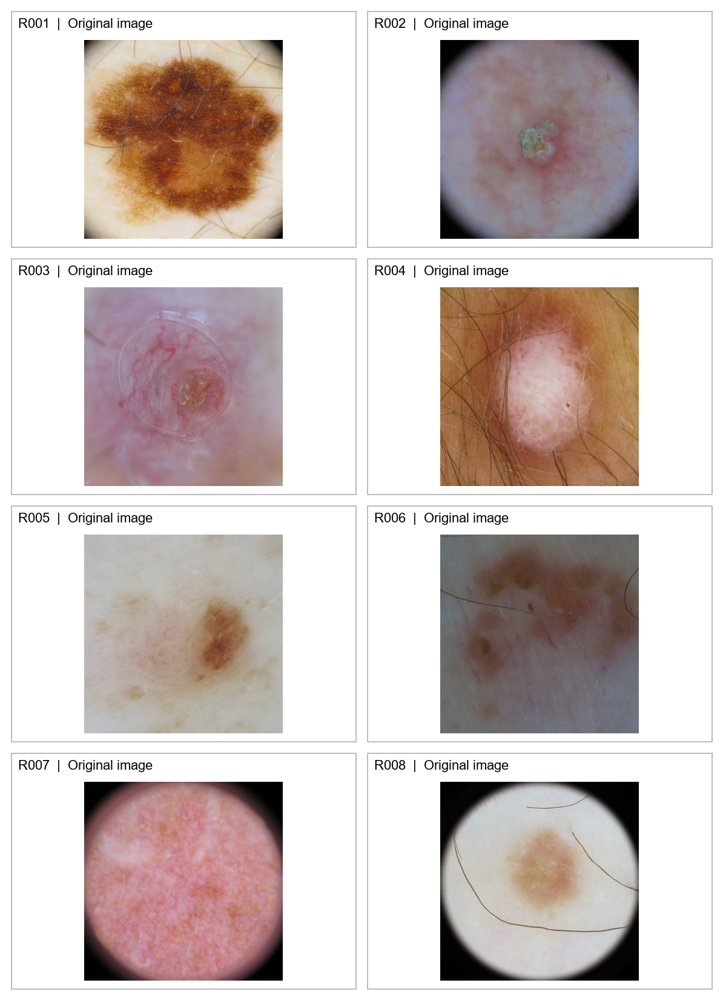


NEXT: MANUALLY REVIEW IMAGES AND RECORD IMAGE-QUALITY NOTES


In [144]:

# ============================================================
# BCN20000 - PHASE 06A - CELL 4
# ORIGINAL-IMAGE CONTACT SHEETS + BLINDED REVIEW TEMPLATE
# VALIDATION ONLY | NO TRAINING | NO OUTER-TEST FILES
# ============================================================

import os
import json
import hashlib

from pathlib import Path
from collections import defaultdict

import pandas as pd
import numpy as np

from PIL import Image, ImageOps, ImageDraw, ImageFont
from IPython.display import display

P4_PROJECT = Path.cwd()
P4_OUTPUTS = P4_PROJECT / "outputs"

P4_REVIEW_CSV = (
    P4_OUTPUTS / "reports" /
    "seven_model_fold01_phase06a_cell3_manual_review_queue.csv"
)

P4_PREVIOUS_JSON = (
    P4_OUTPUTS / "reports" /
    "seven_model_fold01_phase06a_cell3_review_preparation_report.json"
)

P4_MANIFEST = (
    P4_OUTPUTS / "splits/original_branch" /
    "fold_01_validation.csv"
)

P4_SHEET_DIR = (
    P4_OUTPUTS / "reports" /
    "phase06a_cell4_blinded_image_review"
)

P4_TEMPLATE = (
    P4_SHEET_DIR /
    "48_image_blinded_review_template.csv"
)

P4_KEY = (
    P4_SHEET_DIR /
    "48_image_unblinded_reference_key.csv"
)

P4_REPORT = (
    P4_OUTPUTS / "reports" /
    "seven_model_fold01_phase06a_cell4_image_review_preparation.json"
)

P4_MODELS = [
    "resnet50",
    "densenet121",
    "efficientnet_b0",
    "convnext_tiny",
    "vit_b_16",
    "swin_t",
    "deit_small"
]

P4_IMAGE_EXTS = {
    ".jpg", ".jpeg", ".png",
    ".webp", ".bmp", ".tif", ".tiff"
}

print("=" * 76)
print("PHASE 06A - CELL 4")
print("ORIGINAL IMAGE REVIEW PREPARATION")
print("=" * 76)


# ============================================================
# 1. VERIFICATION HELPERS
# ============================================================

def p4_verify(label, result):

    ok = bool(result)

    print(
        f"[{'PASS' if ok else 'FAIL'}] {label}"
    )

    if not ok:
        raise RuntimeError(
            "PHASE 06A CELL 4 BLOCKED: " + label
        )


def p4_sha(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def p4_atomic_csv(frame, path):

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temporary = path.with_name(
        path.name + ".temporary"
    )

    if temporary.exists():
        raise RuntimeError(
            f"Stale temporary file: {temporary}"
        )

    try:
        frame.to_csv(
            temporary,
            index=False
        )

        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


def p4_atomic_json(data, path):

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temporary = path.with_name(
        path.name + ".temporary"
    )

    if temporary.exists():
        raise RuntimeError(
            f"Stale temporary file: {temporary}"
        )

    try:
        with open(
            temporary,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                data,
                f,
                indent=2,
                ensure_ascii=False
            )

        os.replace(temporary, path)

    finally:
        if temporary.exists():
            temporary.unlink()


# ============================================================
# 2. PREVIOUS PHASE VERIFICATION
# ============================================================

print("\n[1] SOURCE AND CHECKPOINT VERIFICATION")

p4_verify(
    "Previous phase files exist",

    P4_REVIEW_CSV.is_file()
    and P4_PREVIOUS_JSON.is_file()
    and P4_MANIFEST.is_file()
)

with open(
    P4_PREVIOUS_JSON,
    "r",
    encoding="utf-8"
) as f:

    p4_previous = json.load(f)

p4_verify(
    "Phase 06A Cell 3 PASS",

    p4_previous.get("status") == "PASS"

    and isinstance(
        p4_previous.get("checks"),
        dict
    )

    and bool(p4_previous["checks"])

    and all(
        p4_previous["checks"].values()
    )

    and p4_previous.get(
        "outer_test_evaluated"
    ) is False

    and p4_previous.get(
        "training_performed"
    ) is False
)


# ============================================================
# 3. PREVIOUS CHECKPOINT PROTECTION
# ============================================================

p4_hashes = p4_previous.get(
    "checkpoint_sha256",
    {}
)

p4_verify(
    "14 checkpoint fingerprints recorded",

    isinstance(p4_hashes, dict)
    and len(p4_hashes) == 14
)

p4_checkpoint_paths = {}

for model in P4_MODELS:

    kinds = (
        ["best"]
        if model == "resnet50"
        else ["best", "last"]
    )

    for kind in kinds:

        p4_checkpoint_paths[
            f"{model}_{kind}"
        ] = (
            P4_OUTPUTS /
            "checkpoints/full_training" /
            model /
            "original/fold_01/sqrt_weighted_ce" /
            f"{kind}_checkpoint.pt"
        )

p4_checkpoint_paths[
    "resnet50_unweighted"
] = (
    P4_OUTPUTS /
    "checkpoints/full_training/resnet50" /
    "original/fold_01/unweighted_ce/best_checkpoint.pt"
)

p4_verify(
    "All 14 checkpoints match recorded SHA256",

    set(p4_hashes)
    == set(p4_checkpoint_paths)

    and all(
        path.is_file()
        and p4_sha(path) == p4_hashes[name]

        for name, path
        in p4_checkpoint_paths.items()
    )
)


# ============================================================
# 4. REVIEW QUEUE VERIFICATION
# ============================================================

print("\n[2] REVIEW QUEUE INTEGRITY")

queue = pd.read_csv(
    P4_REVIEW_CSV,
    dtype={
        "filename": "string",
        "leakage_group_id": "string"
    }
)

manifest = pd.read_csv(
    P4_MANIFEST,

    usecols=[
        "bcn_filename",
        "diagnosis",
        "leakage_group_id"
    ],

    dtype="string"
)

required_columns = {
    "filename",
    "actual_class",
    "leakage_group_id",
    "review_type",
    "models_correct",
    "modal_prediction",
    "modal_votes"
}

p4_verify(
    "48 review images from 48 unique groups",

    required_columns.issubset(
        queue.columns
    )

    and len(queue) == 48

    and queue["filename"].is_unique

    and queue[
        "leakage_group_id"
    ].nunique() == 48

    and int(
        queue["review_type"]
        .eq("shared_error")
        .sum()
    ) == 40

    and int(
        queue["review_type"]
        .eq("comparison_case")
        .sum()
    ) == 8
)

reference = manifest.rename(
    columns={
        "bcn_filename": "filename",
        "diagnosis": "manifest_class",
        "leakage_group_id": "manifest_group"
    }
)

matched = queue[
    [
        "filename",
        "actual_class",
        "leakage_group_id"
    ]
].merge(
    reference,

    on="filename",
    how="left",
    validate="one_to_one"
)

p4_verify(
    "Review images match validation manifest",

    len(matched) == 48

    and matched[
        "manifest_class"
    ].notna().all()

    and matched[
        "actual_class"
    ].astype(str).eq(
        matched[
            "manifest_class"
        ].astype(str)
    ).all()

    and matched[
        "leakage_group_id"
    ].astype(str).eq(
        matched[
            "manifest_group"
        ].astype(str)
    ).all()
)


# ============================================================
# 5. LOCATE ORIGINAL TRAINING-POOL IMAGES
# ============================================================

print("\n[3] LOCATING ORIGINAL IMAGES")

# Only search training-pool directories.
# Never scan bcn_20k_test or outer-test folders.

root_options = [
    P4_PROJECT / "bcn_20k_train",
    P4_PROJECT / "BCN_20K_train",
    P4_PROJECT / "data" / "bcn_20k_train",
    P4_PROJECT / "data" / "train",
    P4_PROJECT / "train",
    P4_PROJECT / "datasets" / "train"
]

for child in P4_PROJECT.iterdir():

    if not child.is_dir():
        continue

    name = child.name.casefold()

    if (
        "train" in name
        and "test" not in name
    ):

        root_options.append(child)

    elif (
        "bcn" in name
        and "test" not in name
    ):

        root_options.extend([
            child / "train",
            child / "training",
            child / "bcn_20k_train"
        ])

image_roots = []

for candidate in root_options:

    if (
        candidate.is_dir()
        and "test"
        not in candidate.name.casefold()
        and candidate.resolve()
        not in image_roots
    ):

        image_roots.append(
            candidate.resolve()
        )

print("Available training-image folders:")

for root in image_roots:
    print(" -", root)

p4_verify(
    "At least one permitted image folder exists",

    len(image_roots) > 0
)


# ============================================================
# 6. INDEX ORIGINAL IMAGE FILES
# ============================================================

print("\n[4] INDEXING ORIGINAL IMAGES")

index_by_name = defaultdict(set)
index_by_stem = defaultdict(set)

scanned = set()

blocked_dirs = {
    "test",
    "bcn_20k_test",
    "outer_test",
    "holdout",
    ".git",
    ".venv",
    "venv",
    "outputs",
    "__pycache__"
}

for root in image_roots:

    for current, dirs, files in os.walk(
        root,
        topdown=True
    ):

        dirs[:] = [
            d for d in dirs
            if (
                d.casefold()
                not in blocked_dirs

                and "test"
                not in d.casefold()
            )
        ]

        for filename in files:

            path = Path(current) / filename

            if (
                path.suffix.casefold()
                not in P4_IMAGE_EXTS
            ):
                continue

            resolved = path.resolve()

            if resolved in scanned:
                continue

            scanned.add(resolved)

            index_by_name[
                path.name.casefold()
            ].add(resolved)

            index_by_stem[
                path.stem.casefold()
            ].add(resolved)

print(
    "Original image files indexed:",
    len(scanned)
)


# ============================================================
# 7. RESOLVE SELECTED IMAGE PATHS
# ============================================================

print("\n[5] MATCHING 48 ORIGINAL IMAGES")

locations = []
missing = []
ambiguous = []

for filename in queue[
    "filename"
].astype(str):

    simple_name = Path(
        filename.replace("\\", "/")
    ).name

    options = index_by_name.get(
        simple_name.casefold(),
        set()
    )

    if not options:

        options = index_by_stem.get(
            Path(
                simple_name
            ).stem.casefold(),
            set()
        )

    if len(options) == 1:

        locations.append(
            str(next(iter(options)))
        )

    elif len(options) == 0:

        missing.append(filename)
        locations.append(None)

    else:

        ambiguous.append(
            (filename, len(options))
        )

        locations.append(None)

if missing:

    print(
        "Missing images:",
        missing[:10]
    )

if ambiguous:

    print(
        "Ambiguous image names:",
        ambiguous[:10]
    )

p4_verify(
    "All 48 original image paths uniquely identified",

    not missing
    and not ambiguous
    and len(locations) == 48
)

queue[
    "original_image_path"
] = locations


# ============================================================
# 8. BLIND AND RANDOMIZE REVIEW ORDER
# ============================================================

print("\n[6] PREPARING BLINDED REVIEW ORDER")

queue = queue.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

queue.insert(
    0,
    "review_id",
    [
        f"R{i:03d}"
        for i in range(1, 49)
    ]
)

widths = []
heights = []

for file_path in queue[
    "original_image_path"
]:

    with Image.open(file_path) as img:
        img.verify()

    with Image.open(file_path) as img:

        widths.append(
            img.width
        )

        heights.append(
            img.height
        )

queue[
    "original_width_px"
] = widths

queue[
    "original_height_px"
] = heights

p4_verify(
    "48 original images decoded successfully",

    len(widths) == 48

    and all(
        w > 0 and h > 0

        for w, h
        in zip(widths, heights)
    )
)


# ============================================================
# 9. PREPARE MANUAL REVIEW TEMPLATE
# ============================================================

print("\n[7] CREATING REVIEW TEMPLATE")

# The blinded template excludes both the dataset
# diagnosis and the seven model predictions.
#
# The separate reference key retains those fields.

review_template = queue[
    [
        "review_id",
        "filename",
        "original_image_path"
    ]
].copy()

review_template[
    "image_quality"
] = "NOT_REVIEWED"

review_template[
    "lesion_visibility"
] = "NOT_REVIEWED"

review_template[
    "artifact_or_obstruction"
] = "NOT_REVIEWED"

review_template[
    "needs_expert_adjudication"
] = "NOT_REVIEWED"

review_template[
    "reviewer_notes"
] = ""

review_template[
    "review_status"
] = "PENDING"

p4_atomic_csv(
    review_template,
    P4_TEMPLATE
)

p4_atomic_csv(
    queue,
    P4_KEY
)

p4_verify(
    "Blinded review template and reference key saved",

    P4_TEMPLATE.is_file()
    and P4_KEY.is_file()

    and len(
        pd.read_csv(P4_TEMPLATE)
    ) == 48
)


# ============================================================
# 10. CONTACT SHEET FONT HELPER
# ============================================================

def p4_font(size):

    candidates = [
        "C:/Windows/Fonts/arial.ttf",
        "DejaVuSans.ttf"
    ]

    for font_path in candidates:

        try:
            return ImageFont.truetype(
                font_path,
                size
            )

        except OSError:
            pass

    return ImageFont.load_default()


# ============================================================
# 11. GENERATE CONTACT SHEETS
# ============================================================

print("\n[8] GENERATING SIX CONTACT SHEETS")

font = p4_font(22)

tile_width = 570
tile_height = 390

columns = 2
rows_per_page = 4

margin = 18

page_width = (
    columns * tile_width
    + (columns + 1) * margin
)

page_height = (
    rows_per_page * tile_height
    + (rows_per_page + 1) * margin
)

page_paths = []

for page_number in range(6):

    page = Image.new(
        "RGB",

        (
            page_width,
            page_height
        ),

        "white"
    )

    draw = ImageDraw.Draw(page)

    subset = queue.iloc[
        page_number * 8:
        (page_number + 1) * 8
    ]

    for local_index, (
        _,
        item
    ) in enumerate(
        subset.iterrows()
    ):

        column = (
            local_index % columns
        )

        row = (
            local_index // columns
        )

        x = (
            margin
            + column * (tile_width + margin)
        )

        y = (
            margin
            + row * (tile_height + margin)
        )

        draw.rectangle(
            (
                x,
                y,
                x + tile_width,
                y + tile_height
            ),

            outline="#bbbbbb",
            width=2
        )

        draw.text(
            (
                x + 12,
                y + 8
            ),

            (
                item["review_id"]
                + "  |  Original image"
            ),

            fill="black",
            font=font
        )

        with Image.open(
            item["original_image_path"]
        ) as source:

            original = (
                ImageOps.exif_transpose(
                    source
                ).convert("RGB")
            )

            preview = ImageOps.contain(
                original,

                (
                    tile_width - 28,
                    tile_height - 62
                )
            )

        image_x = (
            x
            + (
                tile_width
                - preview.width
            ) // 2
        )

        image_y = (
            y
            + 48
            + (
                tile_height
                - 62
                - preview.height
            ) // 2
        )

        page.paste(
            preview,

            (
                image_x,
                image_y
            )
        )

    page_path = (
        P4_SHEET_DIR /
        f"blinded_contact_sheet_{page_number + 1:02d}.png"
    )

    page.save(
        page_path,
        format="PNG"
    )

    page_paths.append(
        page_path
    )

p4_verify(
    "Six contact sheets saved (8 images each)",

    len(page_paths) == 6

    and all(
        path.is_file()
        and path.stat().st_size > 0

        for path in page_paths
    )
)


# ============================================================
# 12. FINAL CHECKPOINT PROTECTION
# ============================================================

print("\n[9] FINAL CHECKPOINT PROTECTION")

p4_verify(
    "All 14 checkpoints unchanged",

    all(
        p4_sha(path) == p4_hashes[name]

        for name, path
        in p4_checkpoint_paths.items()
    )
)


# ============================================================
# 13. SAVE VERIFICATION REPORT
# ============================================================

print("\n[10] SAVING FINAL VERIFICATION REPORT")

report = {
    "stage":
        "PHASE_06A_CELL4_BLINDED_ORIGINAL_IMAGE_REVIEW_PREPARATION",

    "status": "PASS",

    "partition": "validation_only",

    "review_images": 48,

    "shared_error_images": 40,

    "comparison_images": 8,

    "unique_leakage_groups": 48,

    "original_images_decoded": 48,

    "blinded_contact_sheets": [
        str(path)
        for path in page_paths
    ],

    "review_template": str(
        P4_TEMPLATE
    ),

    "unblinded_reference_key": str(
        P4_KEY
    ),

    "manual_review_completed": False,

    "diagnostic_labels_modified": False,

    "training_performed": False,

    "outer_test_evaluated": False,

    "checkpoint_sha256": p4_hashes,

    "interpretation_note": (
        "Preview sheets are for quality triage. "
        "Use original full-resolution images for "
        "detailed review. Model confidence and "
        "consensus do not prove label errors."
    )
}

p4_atomic_json(
    report,
    P4_REPORT
)

p4_verify(
    "Phase 06A Cell 4 verification report saved",

    P4_REPORT.is_file()

    and json.loads(
        P4_REPORT.read_text(
            encoding="utf-8"
        )
    ).get("status") == "PASS"
)


# ============================================================
# 14. MANDATORY FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 76)
print("PHASE 06A - CELL 4 FINAL VERIFICATION")
print("=" * 76)

print("Status: PASS")

print(
    "Review images:",
    len(queue)
)

print(
    "Unique leakage groups:",
    queue[
        "leakage_group_id"
    ].nunique()
)

print(
    "Contact sheets:",
    len(page_paths)
)

print("Manual review: PENDING")
print("Diagnostic labels modified: NO")
print("Training performed: NO")
print("Outer-test evaluated: NO")
print("Previous 14 checkpoints: UNCHANGED")

print("\nBlinded review template:")
print(P4_TEMPLATE)

print("\nUnblinded reference key:")
print(P4_KEY)

print("\nContact sheet directory:")
print(P4_SHEET_DIR)

print("\nVerification report:")
print(P4_REPORT)

print("\nPREVIEW OF FIRST CONTACT SHEET")

display(
    Image.open(
        page_paths[0]
    )
)

print(
    "\nNEXT: MANUALLY REVIEW IMAGES "
    "AND RECORD IMAGE-QUALITY NOTES"
)

print("=" * 76)


In [145]:

# ============================================================
# BCN20000 - PHASE 06A - CELL 5
# INTERACTIVE BLINDED IMAGE-QUALITY REVIEW
# SINGLE JUPYTER CELL | VALIDATION ONLY
# ============================================================

import os
import io
import json
import html
import hashlib
from pathlib import Path

import pandas as pd
from PIL import Image, ImageOps
from IPython.display import display, clear_output

try:
    import ipywidgets as widgets
except ImportError as exc:
    raise RuntimeError(
        "ipywidgets is required. "
        "Run %pip install ipywidgets in a separate cell."
    ) from exc


# ============================================================
# 1. PATHS AND REVIEW OPTIONS
# ============================================================

R5_ROOT = Path.cwd().resolve()
R5_OUTPUT = R5_ROOT / "outputs"

R5_REVIEW_DIR = (
    R5_OUTPUT / "reports" /
    "phase06a_cell4_blinded_image_review"
)

R5_SOURCE = (
    R5_REVIEW_DIR /
    "48_image_blinded_review_template.csv"
)

R5_KEY = (
    R5_REVIEW_DIR /
    "48_image_unblinded_reference_key.csv"
)

R5_PREVIOUS = (
    R5_OUTPUT / "reports" /
    "seven_model_fold01_phase06a_cell4_image_review_preparation.json"
)

R5_PROGRESS = (
    R5_REVIEW_DIR /
    "48_image_quality_review_progress.csv"
)

R5_REPORT = (
    R5_OUTPUT / "reports" /
    "seven_model_fold01_phase06a_cell5_quality_review_report.json"
)

R5_IMAGE_ROOT = (
    R5_ROOT / "bcn_20k_train"
).resolve()

R5_CLASS_FIELDS = (
    "actual_class",
    "diagnosis",
    "predicted_class",
    "modal_prediction"
)

R5_ARTIFACTS = (
    "hair",
    "glare_or_reflection",
    "dark_vignette",
    "contact_ring_or_bubbles",
    "blur",
    "uneven_lighting",
    "partial_occlusion",
    "other"
)

R5_QUALITY = (
    "NOT_REVIEWED",
    "CLEAR",
    "USABLE_LIMITATIONS",
    "POOR",
    "UNASSESSABLE"
)

R5_VISIBILITY = (
    "NOT_REVIEWED",
    "CLEAR",
    "PARTIAL",
    "NOT_CLEAR",
    "UNSURE"
)

R5_EXPERT = (
    "NOT_REVIEWED",
    "YES",
    "NO",
    "UNSURE"
)


# ============================================================
# 2. VERIFICATION AND SAVING HELPERS
# ============================================================

def r5_require(message, condition):

    ok = bool(condition)

    print(
        f"[{'PASS' if ok else 'FAIL'}] {message}"
    )

    if not ok:
        raise RuntimeError(
            "REVIEW BLOCKED: " + message
        )


def r5_hash(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for part in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            h.update(part)

    return h.hexdigest()


def r5_atomic_csv(frame, path):

    temp = path.with_name(
        path.name + ".temporary"
    )

    if temp.exists():
        raise RuntimeError(
            f"Stale temporary file: {temp}"
        )

    try:
        frame.to_csv(
            temp,
            index=False
        )

        os.replace(temp, path)

    finally:
        if temp.exists():
            temp.unlink()


def r5_atomic_json(obj, path):

    temp = path.with_name(
        path.name + ".temporary"
    )

    if temp.exists():
        raise RuntimeError(
            f"Stale temporary file: {temp}"
        )

    try:
        with open(
            temp,
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(
                obj,
                f,
                indent=2,
                ensure_ascii=False
            )

        os.replace(temp, path)

    finally:
        if temp.exists():
            temp.unlink()


print("=" * 74)
print("PHASE 06A - CELL 5")
print("BLINDED ORIGINAL-IMAGE QUALITY REVIEW")
print("=" * 74)


# ============================================================
# 3. PREVIOUS PHASE VERIFICATION
# ============================================================

print("\n[1] PREVIOUS PHASE VERIFICATION")

r5_require(
    "Previous review files exist",
    R5_SOURCE.is_file()
    and R5_KEY.is_file()
    and R5_PREVIOUS.is_file()
)

with open(
    R5_PREVIOUS,
    "r",
    encoding="utf-8"
) as f:
    r5_prior = json.load(f)

r5_require(
    "Cell 4 PASS and outer-test untouched",
    r5_prior.get("status") == "PASS"
    and r5_prior.get(
        "outer_test_evaluated"
    ) is False
    and r5_prior.get(
        "training_performed"
    ) is False
    and r5_prior.get(
        "review_images"
    ) == 48
    and r5_prior.get(
        "unique_leakage_groups"
    ) == 48
)


# ============================================================
# 4. CHECKPOINT PROTECTION
# ============================================================

print("\n[2] CHECKPOINT PROTECTION")

r5_expected_hashes = (
    r5_prior.get(
        "checkpoint_sha256",
        {}
    )
)

r5_require(
    "14 protected checkpoint hashes available",
    isinstance(
        r5_expected_hashes,
        dict
    )
    and len(r5_expected_hashes) == 14
)

r5_models = (
    "resnet50",
    "densenet121",
    "efficientnet_b0",
    "convnext_tiny",
    "vit_b_16",
    "swin_t",
    "deit_small"
)

r5_checkpoints = {}

for model_name in r5_models:

    kinds = (
        ["best"]
        if model_name == "resnet50"
        else ["best", "last"]
    )

    for kind in kinds:

        r5_checkpoints[
            f"{model_name}_{kind}"
        ] = (
            R5_OUTPUT /
            "checkpoints/full_training" /
            model_name /
            "original/fold_01/sqrt_weighted_ce" /
            f"{kind}_checkpoint.pt"
        )

r5_checkpoints[
    "resnet50_unweighted"
] = (
    R5_OUTPUT /
    "checkpoints/full_training/resnet50" /
    "original/fold_01/unweighted_ce/best_checkpoint.pt"
)

r5_require(
    "All 14 checkpoints match previous SHA256",

    set(r5_checkpoints)
    == set(r5_expected_hashes)

    and all(
        path.is_file()
        and r5_hash(path)
        == r5_expected_hashes[key]

        for key, path
        in r5_checkpoints.items()
    )
)


# ============================================================
# 5. LOAD BLINDED REVIEW TEMPLATE
# ============================================================

print("\n[3] BLINDED REVIEW DATA")

r5_source_hash = r5_hash(
    R5_SOURCE
)

r5_key_hash = r5_hash(
    R5_KEY
)

r5_template = pd.read_csv(
    R5_SOURCE,
    dtype=str,
    keep_default_na=False
)

required_columns = {
    "review_id",
    "filename",
    "original_image_path"
}

r5_require(
    "48 unique review records available",

    required_columns.issubset(
        r5_template.columns
    )

    and len(r5_template) == 48

    and r5_template[
        "review_id"
    ].is_unique

    and r5_template[
        "filename"
    ].is_unique

    and r5_template[
        "review_id"
    ].str.fullmatch(
        r"R\d{3}"
    ).all()
)

r5_require(
    "Template does not expose diagnosis",

    not any(
        field in r5_template.columns
        for field in R5_CLASS_FIELDS
    )

    and not any(
        field.startswith("pred_")
        for field in r5_template.columns
    )
)

r5_require(
    "Original image directory available",
    R5_IMAGE_ROOT.is_dir()
)

for item in r5_template.itertuples(
    index=False
):

    image_path = Path(
        item.original_image_path
    ).resolve()

    if not (
        image_path.is_file()
        and image_path.is_relative_to(
            R5_IMAGE_ROOT
        )
        and image_path.name.casefold()
        == Path(
            item.filename
        ).name.casefold()
    ):

        raise RuntimeError(
            "Invalid original image path: "
            + str(image_path)
        )

print(
    "[PASS] All 48 original images verified"
)


# ============================================================
# 6. INITIALIZE OR RESUME REVIEW PROGRESS
# ============================================================

print("\n[4] MANUAL REVIEW PROGRESS")

r5_fields = [
    "review_id",
    "filename",
    "original_image_path",
    "image_quality",
    "lesion_visibility",
    "artifacts",
    "needs_expert_review",
    "reviewer_notes",
    "review_status"
]

if R5_PROGRESS.exists():

    r5_progress = pd.read_csv(
        R5_PROGRESS,
        dtype=str,
        keep_default_na=False
    )

    r5_require(
        "Existing review progress valid",

        set(r5_fields).issubset(
            r5_progress.columns
        )

        and len(r5_progress) == 48

        and r5_progress[
            "review_id"
        ].tolist()
        == r5_template[
            "review_id"
        ].tolist()

        and r5_progress[
            "filename"
        ].tolist()
        == r5_template[
            "filename"
        ].tolist()

        and r5_progress[
            "original_image_path"
        ].tolist()
        == r5_template[
            "original_image_path"
        ].tolist()

        and r5_progress[
            "image_quality"
        ].isin(R5_QUALITY).all()

        and r5_progress[
            "lesion_visibility"
        ].isin(R5_VISIBILITY).all()

        and r5_progress[
            "needs_expert_review"
        ].isin(R5_EXPERT).all()

        and r5_progress[
            "review_status"
        ].isin(
            ["PENDING", "REVIEWED"]
        ).all()
    )

    print(
        "[PASS] Previous review progress restored"
    )

else:

    r5_progress = r5_template[
        [
            "review_id",
            "filename",
            "original_image_path"
        ]
    ].copy()

    r5_progress[
        "image_quality"
    ] = "NOT_REVIEWED"

    r5_progress[
        "lesion_visibility"
    ] = "NOT_REVIEWED"

    r5_progress[
        "artifacts"
    ] = ""

    r5_progress[
        "needs_expert_review"
    ] = "NOT_REVIEWED"

    r5_progress[
        "reviewer_notes"
    ] = ""

    r5_progress[
        "review_status"
    ] = "PENDING"

    r5_atomic_csv(
        r5_progress,
        R5_PROGRESS
    )

    print(
        "[PASS] New review progress initialized"
    )


# ============================================================
# 7. CREATE JUPYTER INTERFACE
# ============================================================

print("\n[5] CREATING INTERACTIVE REVIEW INTERFACE")

r5_state = {
    "index": 0
}

r5_header = widgets.HTML()

r5_progress_label = widgets.HTML()

r5_photo = widgets.Image(
    format="png",
    layout=widgets.Layout(
        max_width="850px"
    )
)

r5_quality = widgets.Dropdown(
    options=list(
        R5_QUALITY
    ),
    description="Quality:",
    style={
        "description_width": "130px"
    },
    layout=widgets.Layout(
        width="410px"
    )
)

r5_visibility = widgets.Dropdown(
    options=list(
        R5_VISIBILITY
    ),
    description="Lesion visibility:",
    style={
        "description_width": "130px"
    },
    layout=widgets.Layout(
        width="410px"
    )
)

r5_expert = widgets.Dropdown(
    options=list(
        R5_EXPERT
    ),
    description="Expert review:",
    style={
        "description_width": "130px"
    },
    layout=widgets.Layout(
        width="410px"
    )
)

r5_artifact_checkboxes = {
    name: widgets.Checkbox(
        value=False,
        description=name.replace(
            "_", " "
        ),
        indent=False,
        layout=widgets.Layout(
            width="190px"
        )
    )

    for name in R5_ARTIFACTS
}

r5_notes = widgets.Textarea(
    placeholder=(
        "Write observed image-quality details only."
    ),
    description="Notes:",
    style={
        "description_width": "130px"
    },
    layout=widgets.Layout(
        width="800px",
        height="90px"
    )
)

r5_btn_previous = widgets.Button(
    description="Save & Previous",
    icon="arrow-left"
)

r5_btn_next = widgets.Button(
    description="Save & Next",
    icon="arrow-right"
)

r5_btn_finalize = widgets.Button(
    description="Verify All 48 & Finalize",
    icon="check"
)

r5_messages = widgets.Output(
    layout=widgets.Layout(
        border="1px solid #cccccc",
        padding="8px"
    )
)


# ============================================================
# 8. REVIEW NAVIGATION
# ============================================================

def r5_completed_count():

    return int(
        r5_progress[
            "review_status"
        ].eq(
            "REVIEWED"
        ).sum()
    )


def r5_load(index):

    r5_state["index"] = max(
        0,
        min(
            len(r5_progress) - 1,
            index
        )
    )

    i = r5_state["index"]

    row = r5_progress.iloc[i]

    image_path = Path(
        row["original_image_path"]
    )

    with Image.open(image_path) as source:

        image = ImageOps.exif_transpose(
            source
        ).convert("RGB")

        image.thumbnail(
            (850, 680),
            Image.Resampling.LANCZOS
        )

        buffer = io.BytesIO()

        image.save(
            buffer,
            format="PNG"
        )

    r5_photo.value = (
        buffer.getvalue()
    )

    r5_header.value = (
        "<h3>Blinded original-image review: "
        + html.escape(
            row["review_id"]
        )
        + f" ({i + 1}/48)</h3>"

        + "<p>Image-quality review only. "
        + "Do not change or infer diagnostic labels. "
        + "Inspect full-resolution images when necessary.</p>"
    )

    r5_quality.value = row[
        "image_quality"
    ]

    r5_visibility.value = row[
        "lesion_visibility"
    ]

    r5_expert.value = row[
        "needs_expert_review"
    ]

    saved_artifacts = set(
        filter(
            None,
            row["artifacts"].split(";")
        )
    )

    for name, checkbox in (
        r5_artifact_checkboxes.items()
    ):

        checkbox.value = (
            name in saved_artifacts
        )

    r5_notes.value = row[
        "reviewer_notes"
    ]

    r5_progress_label.value = (
        f"<b>Reviewed: {r5_completed_count()}/48</b>"
        + " | Current: "
        + html.escape(
            row["review_status"]
        )
        + " | Diagnosis: HIDDEN"
    )

    r5_btn_previous.disabled = (
        i == 0
    )

    r5_btn_next.disabled = (
        i == 47
    )


# ============================================================
# 9. SAVE INDIVIDUAL REVIEW
# ============================================================

def r5_save_current():

    required_values = (
        r5_quality.value,
        r5_visibility.value,
        r5_expert.value
    )

    if any(
        value == "NOT_REVIEWED"
        for value in required_values
    ):

        with r5_messages:

            clear_output(
                wait=True
            )

            print(
                "Select Quality, Lesion visibility "
                "and Expert review before saving."
            )

        return False

    i = r5_state["index"]

    r5_progress.at[
        i,
        "image_quality"
    ] = r5_quality.value

    r5_progress.at[
        i,
        "lesion_visibility"
    ] = r5_visibility.value

    r5_progress.at[
        i,
        "needs_expert_review"
    ] = r5_expert.value

    r5_progress.at[
        i,
        "artifacts"
    ] = ";".join(
        name

        for name, checkbox
        in r5_artifact_checkboxes.items()

        if checkbox.value
    )

    r5_progress.at[
        i,
        "reviewer_notes"
    ] = r5_notes.value.strip()

    r5_progress.at[
        i,
        "review_status"
    ] = "REVIEWED"

    r5_atomic_csv(
        r5_progress,
        R5_PROGRESS
    )

    with r5_messages:

        clear_output(
            wait=True
        )

        print(
            f"Saved {r5_progress.iloc[i]['review_id']}"
            f" | {r5_completed_count()}/48 reviewed"
        )

    return True


def r5_previous(_):

    if r5_save_current():

        r5_load(
            r5_state["index"] - 1
        )


def r5_next(_):

    if r5_save_current():

        r5_load(
            r5_state["index"] + 1
        )


# ============================================================
# 10. FINAL REVIEW VERIFICATION
# ============================================================

def r5_finalize(_):

    if not r5_save_current():
        return

    fresh = pd.read_csv(
        R5_PROGRESS,
        dtype=str,
        keep_default_na=False
    )

    checks = {

        "48 images completed": (
            len(fresh) == 48

            and fresh[
                "review_status"
            ].eq(
                "REVIEWED"
            ).all()
        ),

        "All review fields completed": (
            fresh[
                "image_quality"
            ].isin(
                R5_QUALITY[1:]
            ).all()

            and fresh[
                "lesion_visibility"
            ].isin(
                R5_VISIBILITY[1:]
            ).all()

            and fresh[
                "needs_expert_review"
            ].isin(
                R5_EXPERT[1:]
            ).all()
        ),

        "48 unique review IDs": (
            fresh[
                "review_id"
            ].nunique() == 48
        ),

        "Source template unchanged": (
            r5_hash(R5_SOURCE)
            == r5_source_hash
        ),

        "Unblinded reference key unchanged": (
            r5_hash(R5_KEY)
            == r5_key_hash
        ),

        "Review output remains blinded": (
            not any(
                name in fresh.columns
                for name in R5_CLASS_FIELDS
            )

            and not any(
                name.startswith("pred_")
                for name in fresh.columns
            )
        ),

        "All 14 checkpoints protected": (
            all(
                path.is_file()
                and r5_hash(path)
                == r5_expected_hashes[name]

                for name, path
                in r5_checkpoints.items()
            )
        )
    }

    with r5_messages:

        clear_output(
            wait=True
        )

        print("=" * 66)
        print(
            "PHASE 06A - CELL 5 FINAL VERIFICATION"
        )
        print("=" * 66)

        for name, result in checks.items():

            print(
                f"[{'PASS' if result else 'FAIL'}] {name}"
            )

        if not all(
            checks.values()
        ):

            pending = fresh.loc[
                fresh["review_status"]
                != "REVIEWED",

                "review_id"
            ].tolist()

            print(
                "\nStatus: INCOMPLETE"
            )

            print(
                "Pending review IDs:",
                pending
            )

            print(
                "Saved progress:",
                R5_PROGRESS
            )

            return

        report = {
            "stage":
                "PHASE_06A_CELL5_BLINDED_IMAGE_QUALITY_TRIAGE",

            "status": "PASS",

            "reviewed_images": 48,

            "source_partition": "validation_only",

            "quality_distribution":
                fresh[
                    "image_quality"
                ].value_counts().to_dict(),

            "visibility_distribution":
                fresh[
                    "lesion_visibility"
                ].value_counts().to_dict(),

            "expert_review_distribution":
                fresh[
                    "needs_expert_review"
                ].value_counts().to_dict(),

            "image_quality_review_completed": True,

            "medical_diagnosis_review_completed": False,

            "diagnostic_labels_modified": False,

            "training_performed": False,

            "outer_test_evaluated": False,

            "saved_review_csv": str(
                R5_PROGRESS
            ),

            "checks": checks
        }

        r5_atomic_json(
            report,
            R5_REPORT
        )

        print("\nStatus: PASS")
        print("Review images: 48/48")
        print(
            "Clinical label verification: NOT PERFORMED"
        )
        print("Training performed: NO")
        print("Outer-test evaluated: NO")
        print("Previous checkpoints: UNCHANGED")

        print("\nReview CSV:")
        print(R5_PROGRESS)

        print("\nVerification JSON:")
        print(R5_REPORT)

        print(
            "\nPHASE 06A - CELL 5: PASS"
        )


# ============================================================
# 11. ACTIVATE AND DISPLAY REVIEW INTERFACE
# ============================================================

r5_btn_previous.on_click(
    r5_previous
)

r5_btn_next.on_click(
    r5_next
)

r5_btn_finalize.on_click(
    r5_finalize
)

r5_load(0)

review_interface = widgets.VBox([

    r5_header,

    r5_progress_label,

    r5_photo,

    widgets.HTML(
        "<b>Image-quality assessment "
        "(not a diagnosis)</b>"
    ),

    r5_quality,

    r5_visibility,

    widgets.HTML(
        "<b>Visible artifacts "
        "(select all that apply):</b>"
    ),

    widgets.GridBox(

        list(
            r5_artifact_checkboxes.values()
        ),

        layout=widgets.Layout(
            grid_template_columns=(
                "repeat(2, 195px)"
            )
        )
    ),

    r5_expert,

    r5_notes,

    widgets.HBox([
        r5_btn_previous,
        r5_btn_next,
        r5_btn_finalize
    ]),

    r5_messages
])

display(
    review_interface
)

print(
    "\nManual review interface READY."
)

print(
    "Select all three dropdowns for each image."
)

print(
    "Use Save & Next to record each review."
)

print(
    "After all 48 images, click "
    "Verify All 48 & Finalize."
)

print(
    "All diagnoses and model predictions remain hidden."
)

print("=" * 74)


PHASE 06A - CELL 5
BLINDED ORIGINAL-IMAGE QUALITY REVIEW

[1] PREVIOUS PHASE VERIFICATION
[PASS] Previous review files exist
[PASS] Cell 4 PASS and outer-test untouched

[2] CHECKPOINT PROTECTION
[PASS] 14 protected checkpoint hashes available
[PASS] All 14 checkpoints match previous SHA256

[3] BLINDED REVIEW DATA
[PASS] 48 unique review records available
[PASS] Template does not expose diagnosis
[PASS] Original image directory available
[PASS] All 48 original images verified

[4] MANUAL REVIEW PROGRESS
[PASS] New review progress initialized

[5] CREATING INTERACTIVE REVIEW INTERFACE



Manual review interface READY.
Select all three dropdowns for each image.
Use Save & Next to record each review.
After all 48 images, click Verify All 48 & Finalize.
All diagnoses and model predictions remain hidden.


In [146]:

# ============================================================
# BCN20000 - PHASE 06A - CELL 5
# FINAL REPORT SERIALIZATION FIX
# NO RE-REVIEW | NO TRAINING | NO OUTER-TEST ACCESS
# ============================================================

import os
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd() / "outputs"

REVIEW_DIR = (
    ROOT / "reports" /
    "phase06a_cell4_blinded_image_review"
)

PROGRESS_PATH = (
    REVIEW_DIR /
    "48_image_quality_review_progress.csv"
)

TEMPLATE_PATH = (
    REVIEW_DIR /
    "48_image_blinded_review_template.csv"
)

KEY_PATH = (
    REVIEW_DIR /
    "48_image_unblinded_reference_key.csv"
)

PREVIOUS_REPORT = (
    ROOT / "reports" /
    "seven_model_fold01_phase06a_cell4_image_review_preparation.json"
)

FINAL_REPORT = (
    ROOT / "reports" /
    "seven_model_fold01_phase06a_cell5_quality_review_report.json"
)

CHECKS = {}


def verify(name, condition):

    passed = bool(condition)
    CHECKS[name] = passed

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

    if not passed:
        raise RuntimeError(
            "FINAL VERIFICATION BLOCKED: " + name
        )


def file_sha256(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


def json_safe(value):

    # Converts NumPy data types into native Python types.

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, Path):
        return str(value)

    raise TypeError(
        f"Unsupported JSON type: {type(value)}"
    )


print("=" * 76)
print("PHASE 06A - CELL 5")
print("FINAL JSON SERIALIZATION FIX")
print("=" * 76)


# ============================================================
# 1. CHECK SAVED REVIEW FILES
# ============================================================

print("\n[1] SAVED REVIEW FILES")

verify(
    "All previous review files exist",
    all(
        p.is_file()
        for p in [
            PROGRESS_PATH,
            TEMPLATE_PATH,
            KEY_PATH,
            PREVIOUS_REPORT
        ]
    )
)

progress = pd.read_csv(
    PROGRESS_PATH,
    dtype=str,
    keep_default_na=False
)

template = pd.read_csv(
    TEMPLATE_PATH,
    dtype=str,
    keep_default_na=False
)

reference = pd.read_csv(
    KEY_PATH,
    dtype=str,
    keep_default_na=False
)

with open(
    PREVIOUS_REPORT,
    "r",
    encoding="utf-8"
) as f:
    previous = json.load(f)

verify(
    "Phase 06A Cell 4 PASS",
    previous.get("status") == "PASS"
    and previous.get("training_performed") is False
    and previous.get("outer_test_evaluated") is False
)


# ============================================================
# 2. REVIEW COMPLETENESS VERIFICATION
# ============================================================

print("\n[2] 48-IMAGE REVIEW VERIFICATION")

required_columns = {
    "review_id",
    "filename",
    "original_image_path",
    "image_quality",
    "lesion_visibility",
    "artifacts",
    "needs_expert_review",
    "reviewer_notes",
    "review_status"
}

verify(
    "Required review columns present",
    required_columns.issubset(progress.columns)
)

verify(
    "48 images and 48 unique review IDs",
    len(progress) == 48
    and progress["review_id"].nunique() == 48
    and progress["filename"].nunique() == 48
)

verify(
    "All 48 image reviews completed",
    progress["review_status"].eq("REVIEWED").all()
)

valid_quality = {
    "CLEAR",
    "USABLE_LIMITATIONS",
    "POOR",
    "UNASSESSABLE"
}

valid_visibility = {
    "CLEAR",
    "PARTIAL",
    "NOT_CLEAR",
    "UNSURE"
}

valid_expert = {
    "YES",
    "NO",
    "UNSURE"
}

verify(
    "All image-quality fields valid",
    progress["image_quality"].isin(
        valid_quality
    ).all()
)

verify(
    "All lesion-visibility fields valid",
    progress["lesion_visibility"].isin(
        valid_visibility
    ).all()
)

verify(
    "All expert-review fields valid",
    progress["needs_expert_review"].isin(
        valid_expert
    ).all()
)

verify(
    "Saved reviews match source template",
    len(template) == 48
    and all(
        progress[col].tolist()
        == template[col].tolist()

        for col in [
            "review_id",
            "filename",
            "original_image_path"
        ]
    )
)

verify(
    "Unblinded key matches saved review identifiers",
    len(reference) == 48
    and all(
        progress[col].tolist()
        == reference[col].tolist()

        for col in [
            "review_id",
            "filename",
            "original_image_path"
        ]
    )
)

forbidden = {
    "actual_class",
    "diagnosis",
    "modal_prediction",
    "predicted_class"
}

verify(
    "Review progress remains blinded",
    not any(
        col in progress.columns
        or col.startswith("pred_")

        for col in forbidden
    )
    and not any(
        col.startswith("pred_")
        for col in progress.columns
    )
)


# ============================================================
# 3. CHECKPOINT INTEGRITY VERIFICATION
# ============================================================

print("\n[3] CHECKPOINT INTEGRITY")

expected_hashes = previous.get(
    "checkpoint_sha256", {}
)

verify(
    "14 checkpoint hashes available",
    isinstance(expected_hashes, dict)
    and len(expected_hashes) == 14
)

models = [
    "resnet50",
    "densenet121",
    "efficientnet_b0",
    "convnext_tiny",
    "vit_b_16",
    "swin_t",
    "deit_small"
]

checkpoint_paths = {}

for model in models:

    kinds = (
        ["best"]
        if model == "resnet50"
        else ["best", "last"]
    )

    for kind in kinds:

        checkpoint_paths[
            f"{model}_{kind}"
        ] = (
            ROOT / "checkpoints/full_training" /
            model /
            "original/fold_01/sqrt_weighted_ce" /
            f"{kind}_checkpoint.pt"
        )

checkpoint_paths["resnet50_unweighted"] = (
    ROOT / "checkpoints/full_training/resnet50" /
    "original/fold_01/unweighted_ce/best_checkpoint.pt"
)

verify(
    "Checkpoint inventory matches previous report",
    set(checkpoint_paths) == set(expected_hashes)
)

verify(
    "All 14 checkpoints remain unchanged",
    all(
        path.is_file()
        and file_sha256(path) == expected_hashes[name]

        for name, path in checkpoint_paths.items()
    )
)


# ============================================================
# 4. IMAGE-QUALITY DISTRIBUTIONS
# ============================================================

print("\n[4] REVIEW SUMMARY")

quality_counts = {
    str(k): int(v)

    for k, v in progress[
        "image_quality"
    ].value_counts().items()
}

visibility_counts = {
    str(k): int(v)

    for k, v in progress[
        "lesion_visibility"
    ].value_counts().items()
}

expert_counts = {
    str(k): int(v)

    for k, v in progress[
        "needs_expert_review"
    ].value_counts().items()
}

print("\nImage quality:")
print(quality_counts)

print("\nLesion visibility:")
print(visibility_counts)

print("\nExpert review:")
print(expert_counts)

verify(
    "All summary distributions total 48",
    sum(quality_counts.values()) == 48
    and sum(visibility_counts.values()) == 48
    and sum(expert_counts.values()) == 48
)


# ============================================================
# 5. CREATE JSON-SAFE FINAL REPORT
# ============================================================

print("\n[5] JSON REPORT GENERATION")

report = {

    "stage":
        "PHASE_06A_CELL5_BLINDED_IMAGE_QUALITY_TRIAGE",

    "status": "PASS",

    "source_partition": "validation_only",

    "reviewed_images": int(len(progress)),

    "quality_distribution": quality_counts,

    "visibility_distribution": visibility_counts,

    "expert_review_distribution": expert_counts,

    "image_quality_review_completed": True,

    "medical_diagnosis_review_completed": False,

    "diagnostic_labels_modified": False,

    "training_performed": False,

    "outer_test_evaluated": False,

    "review_csv": str(PROGRESS_PATH),

    "review_csv_sha256": file_sha256(
        PROGRESS_PATH
    ),

    "source_template_sha256": file_sha256(
        TEMPLATE_PATH
    ),

    "unblinded_key_sha256": file_sha256(
        KEY_PATH
    ),

    "checkpoint_sha256": expected_hashes,

    # Explicit conversion fixes the original error.
    "checks": {
        str(name): bool(value)
        for name, value in CHECKS.items()
    }
}

temp_path = FINAL_REPORT.with_name(
    FINAL_REPORT.name + ".temporary"
)

if temp_path.exists():
    raise RuntimeError(
        "Stale temporary JSON report exists: "
        + str(temp_path)
    )

try:

    with open(
        temp_path,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            report,
            f,
            indent=2,
            ensure_ascii=False,
            allow_nan=False,
            default=json_safe
        )

    os.replace(
        temp_path,
        FINAL_REPORT
    )

finally:

    if temp_path.exists():
        temp_path.unlink()


# ============================================================
# 6. VERIFY SAVED JSON REPORT
# ============================================================

print("\n[6] INDEPENDENT JSON READ-BACK")

verify(
    "Final JSON report created",
    FINAL_REPORT.is_file()
    and FINAL_REPORT.stat().st_size > 0
)

with open(
    FINAL_REPORT,
    "r",
    encoding="utf-8"
) as f:
    saved_report = json.load(f)

verify(
    "JSON reload and status PASS",
    saved_report.get("status") == "PASS"
    and saved_report.get("reviewed_images") == 48
)

verify(
    "All saved verification checks PASS",
    isinstance(saved_report.get("checks"), dict)
    and all(saved_report["checks"].values())
)

verify(
    "JSON has native Python boolean values",
    all(
        type(value) is bool
        for value in saved_report["checks"].values()
    )
)

verify(
    "No training or outer-test evaluation performed",
    saved_report["training_performed"] is False
    and saved_report["outer_test_evaluated"] is False
    and saved_report["diagnostic_labels_modified"] is False
)


# ============================================================
# 7. MANDATORY FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 76)
print("PHASE 06A - CELL 5 FINAL VERIFICATION")
print("=" * 76)

failed = [
    name
    for name, passed in CHECKS.items()
    if not passed
]

print("Status: PASS")

print(
    "Verification checks:",
    len(CHECKS)
)

print(
    "Failed checks:",
    failed
)

print("Reviewed images: 48 / 48")

print("Image-quality assessment: COMPLETE")

print("Clinical label verification: NOT PERFORMED")

print("Training performed: NO")

print("Outer-test evaluated: NO")

print("Diagnostic labels modified: NO")

print("Previous checkpoints: PROTECTED")

print("\nSaved review CSV:")
print(PROGRESS_PATH)

print("\nFinal JSON report:")
print(FINAL_REPORT)

print("\nPHASE 06A - CELL 5: PASS")

print(
    "NEXT: ANALYZE IMAGE-QUALITY REVIEW "
    "AND SHARED MODEL ERRORS"
)

print("=" * 76)


PHASE 06A - CELL 5
FINAL JSON SERIALIZATION FIX

[1] SAVED REVIEW FILES
[PASS] All previous review files exist
[PASS] Phase 06A Cell 4 PASS

[2] 48-IMAGE REVIEW VERIFICATION
[PASS] Required review columns present
[PASS] 48 images and 48 unique review IDs
[PASS] All 48 image reviews completed
[PASS] All image-quality fields valid
[PASS] All lesion-visibility fields valid
[PASS] All expert-review fields valid
[PASS] Saved reviews match source template
[PASS] Unblinded key matches saved review identifiers
[PASS] Review progress remains blinded

[3] CHECKPOINT INTEGRITY
[PASS] 14 checkpoint hashes available
[PASS] Checkpoint inventory matches previous report
[PASS] All 14 checkpoints remain unchanged

[4] REVIEW SUMMARY

Image quality:
{'USABLE_LIMITATIONS': 40, 'CLEAR': 8}

Lesion visibility:
{'PARTIAL': 27, 'CLEAR': 17, 'NOT_CLEAR': 4}

Expert review:
{'YES': 30, 'UNSURE': 18}
[PASS] All summary distributions total 48

[5] JSON REPORT GENERATION

[6] INDEPENDENT JSON READ-BACK
[PASS] Fin

In [147]:

# ============================================================
# BCN20000 - PHASE 06A - CELL 6
# IMAGE QUALITY VS SHARED MODEL ERRORS
# ONE JUPYTER CELL | VALIDATION ONLY
# NO TRAINING | NO OUTER TEST
# ============================================================

import os
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

ROOT6 = Path.cwd().resolve() / "outputs"

REVIEW6 = (
    ROOT6 / "reports" /
    "phase06a_cell4_blinded_image_review"
)

PROGRESS6 = (
    REVIEW6 /
    "48_image_quality_review_progress.csv"
)

TEMPLATE6 = (
    REVIEW6 /
    "48_image_blinded_review_template.csv"
)

KEY6 = (
    REVIEW6 /
    "48_image_unblinded_reference_key.csv"
)

REPORT5_6 = (
    ROOT6 / "reports" /
    "seven_model_fold01_phase06a_cell5_quality_review_report.json"
)

REPORT4_6 = (
    ROOT6 / "reports" /
    "seven_model_fold01_phase06a_cell4_image_review_preparation.json"
)

HARD6 = (
    ROOT6 / "reports" /
    "seven_model_fold01_all_wrong_254_case_triage.csv"
)

CASES_OUT6 = (
    ROOT6 / "reports" /
    "seven_model_fold01_phase06a_cell6_review_vs_errors_cases.csv"
)

SUMMARY_OUT6 = (
    ROOT6 / "reports" /
    "seven_model_fold01_phase06a_cell6_review_vs_errors_summary.csv"
)

ARTIFACT_OUT6 = (
    ROOT6 / "reports" /
    "seven_model_fold01_phase06a_cell6_artifact_summary.csv"
)

CLASS_OUT6 = (
    ROOT6 / "reports" /
    "seven_model_fold01_phase06a_cell6_class_summary.csv"
)

REPORT_OUT6 = (
    ROOT6 / "reports" /
    "seven_model_fold01_phase06a_cell6_descriptive_report.json"
)

CLASSES6 = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

ARTIFACTS6 = [
    "hair",
    "glare_or_reflection",
    "dark_vignette",
    "contact_ring_or_bubbles",
    "blur",
    "uneven_lighting",
    "partial_occlusion",
    "other"
]

CHECKS6 = {}


# ============================================================
# 1. HELPERS
# ============================================================

def verify6(name, condition):

    passed = bool(condition)

    CHECKS6[name] = passed

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

    if not passed:
        raise RuntimeError(
            "PHASE 06A CELL 6 BLOCKED: " + name
        )


def sha256_6(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


def save_csv6(dataframe, path):

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temporary = path.with_name(
        path.name + ".temporary"
    )

    if temporary.exists():
        raise RuntimeError(
            "Stale temporary file: " + str(temporary)
        )

    try:

        dataframe.to_csv(
            temporary,
            index=False
        )

        os.replace(
            temporary,
            path
        )

    finally:

        if temporary.exists():
            temporary.unlink()


def save_json6(data, path):

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temporary = path.with_name(
        path.name + ".temporary"
    )

    if temporary.exists():
        raise RuntimeError(
            "Stale temporary file: " + str(temporary)
        )

    try:

        with open(
            temporary,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                data,
                f,
                indent=2,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(
            temporary,
            path
        )

    finally:

        if temporary.exists():
            temporary.unlink()


print("=" * 76)
print("PHASE 06A - CELL 6")
print("IMAGE QUALITY VS SHARED MODEL ERRORS")
print("=" * 76)


# ============================================================
# 2. PREVIOUS PHASE VERIFICATION
# ============================================================

print("\n[1] PREVIOUS PHASE VERIFICATION")

required_files = [
    PROGRESS6,
    TEMPLATE6,
    KEY6,
    REPORT5_6,
    REPORT4_6,
    HARD6
]

verify6(
    "All source files available",
    all(
        path.is_file()
        for path in required_files
    )
)

with open(
    REPORT5_6,
    "r",
    encoding="utf-8"
) as f:

    previous5 = json.load(f)

with open(
    REPORT4_6,
    "r",
    encoding="utf-8"
) as f:

    previous4 = json.load(f)

verify6(
    "Cell 5 status PASS",

    previous5.get("status") == "PASS"

    and previous5.get(
        "reviewed_images"
    ) == 48

    and previous5.get(
        "image_quality_review_completed"
    ) is True

    and previous5.get(
        "medical_diagnosis_review_completed"
    ) is False

    and previous5.get(
        "training_performed"
    ) is False

    and previous5.get(
        "outer_test_evaluated"
    ) is False

    and bool(previous5.get("checks"))

    and all(
        previous5["checks"].values()
    )

    and previous4.get(
        "status"
    ) == "PASS"
)

verify6(
    "Review CSV and reference files unchanged",

    sha256_6(PROGRESS6)
    == previous5.get("review_csv_sha256")

    and sha256_6(TEMPLATE6)
    == previous5.get("source_template_sha256")

    and sha256_6(KEY6)
    == previous5.get("unblinded_key_sha256")
)


# ============================================================
# 3. CHECKPOINT PROTECTION
# ============================================================

print("\n[2] CHECKPOINT PROTECTION")

models6 = [
    "resnet50",
    "densenet121",
    "efficientnet_b0",
    "convnext_tiny",
    "vit_b_16",
    "swin_t",
    "deit_small"
]

checkpoints6 = {}

for model in models6:

    kinds = (
        ["best"]
        if model == "resnet50"
        else ["best", "last"]
    )

    for kind in kinds:

        checkpoints6[
            f"{model}_{kind}"
        ] = (
            ROOT6 / "checkpoints/full_training" /
            model /
            "original/fold_01/sqrt_weighted_ce" /
            f"{kind}_checkpoint.pt"
        )

checkpoints6[
    "resnet50_unweighted"
] = (
    ROOT6 / "checkpoints/full_training/resnet50" /
    "original/fold_01/unweighted_ce/best_checkpoint.pt"
)

expected_hashes6 = previous5.get(
    "checkpoint_sha256",
    {}
)

verify6(
    "All 14 model checkpoints match SHA256",

    isinstance(
        expected_hashes6,
        dict
    )

    and len(expected_hashes6) == 14

    and set(checkpoints6)
    == set(expected_hashes6)

    and all(
        path.is_file()

        and sha256_6(path)
        == expected_hashes6[name]

        for name, path
        in checkpoints6.items()
    )
)


# ============================================================
# 4. LOAD MANUAL REVIEW AND REFERENCE KEY
# ============================================================

print("\n[3] REVIEW AND REFERENCE DATA")

progress6 = pd.read_csv(
    PROGRESS6,
    dtype=str,
    keep_default_na=False
)

key6 = pd.read_csv(
    KEY6,
    dtype=str,
    keep_default_na=False
)

hard6 = pd.read_csv(
    HARD6,
    dtype=str,
    keep_default_na=False
)

required_review6 = {
    "review_id",
    "filename",
    "original_image_path",
    "image_quality",
    "lesion_visibility",
    "artifacts",
    "needs_expert_review",
    "review_status",
    "reviewer_notes"
}

key_columns6 = [
    "review_id",
    "filename",
    "original_image_path",
    "leakage_group_id",
    "actual_class",
    "review_type",
    "selection_reason",
    "models_correct",
    "modal_votes",
    "modal_prediction"
]

verify6(
    "48 complete review records",

    required_review6.issubset(
        progress6.columns
    )

    and len(progress6) == 48

    and progress6["review_id"].is_unique

    and progress6["filename"].is_unique

    and progress6[
        "review_status"
    ].eq("REVIEWED").all()
)

verify6(
    "48 matching reference records",

    set(key_columns6).issubset(
        key6.columns
    )

    and len(key6) == 48

    and key6[
        "review_id"
    ].is_unique
)

verify6(
    "All manual review values valid",

    progress6[
        "image_quality"
    ].isin([
        "CLEAR",
        "USABLE_LIMITATIONS",
        "POOR",
        "UNASSESSABLE"
    ]).all()

    and progress6[
        "lesion_visibility"
    ].isin([
        "CLEAR",
        "PARTIAL",
        "NOT_CLEAR",
        "UNSURE"
    ]).all()

    and progress6[
        "needs_expert_review"
    ].isin([
        "YES",
        "NO",
        "UNSURE"
    ]).all()
)

verify6(
    "Review distributions match Cell 5",

    progress6[
        "image_quality"
    ].value_counts().to_dict()
    == previous5.get("quality_distribution")

    and progress6[
        "lesion_visibility"
    ].value_counts().to_dict()
    == previous5.get("visibility_distribution")

    and progress6[
        "needs_expert_review"
    ].value_counts().to_dict()
    == previous5.get("expert_review_distribution")
)


# ============================================================
# 5. JOIN REVIEW WITH REFERENCE DATA
# ============================================================

print("\n[4] POST-REVIEW DATA ALIGNMENT")

data6 = progress6.merge(

    key6[
        key_columns6
    ],

    on=[
        "review_id",
        "filename",
        "original_image_path"
    ],

    how="left",
    validate="one_to_one"
)

verify6(
    "All 48 reviewed images matched",

    len(data6) == 48

    and data6[
        "review_type"
    ].notna().all()

    and data6[
        "leakage_group_id"
    ].nunique() == 48

    and set(
        data6["actual_class"]
    ) == set(CLASSES6)
)

verify6(
    "40 shared errors and 8 comparison cases",

    data6[
        "review_type"
    ].value_counts().to_dict()

    == {
        "shared_error": 40,
        "comparison_case": 8
    }
)

data6[
    "models_correct"
] = pd.to_numeric(
    data6["models_correct"],
    errors="raise"
).astype(int)

data6[
    "modal_votes"
] = pd.to_numeric(
    data6["modal_votes"],
    errors="raise"
).astype(int)

hard_filenames6 = set(
    hard6["filename"]
)

errors6 = data6[
    data6["review_type"] == "shared_error"
]

comparisons6 = data6[
    data6["review_type"] == "comparison_case"
]

verify6(
    "40 error cases confirmed against original audit",

    len(hard6) == 254

    and hard6[
        "filename"
    ].is_unique

    and errors6[
        "filename"
    ].isin(
        hard_filenames6
    ).all()

    and errors6[
        "models_correct"
    ].eq(0).all()
)

verify6(
    "Comparison cases independently confirmed",

    len(comparisons6) == 8

    and comparisons6[
        "models_correct"
    ].gt(0).all()

    and not comparisons6[
        "filename"
    ].isin(
        hard_filenames6
    ).any()

    and comparisons6[
        "actual_class"
    ].value_counts().eq(1).all()
)


# ============================================================
# 6. PARSE REVIEWED IMAGE ARTIFACTS
# ============================================================

print("\n[5] IMAGE ARTIFACT ANALYSIS")

def parse_artifacts6(value):

    return set(
        item.strip()

        for item in value.split(";")

        if item.strip()
    )


data6[
    "artifact_set"
] = data6[
    "artifacts"
].map(
    parse_artifacts6
)

verify6(
    "All artifact categories valid",

    all(
        values.issubset(
            set(ARTIFACTS6)
        )

        for values in data6[
            "artifact_set"
        ]
    )
)

for artifact in ARTIFACTS6:

    data6[
        f"artifact_{artifact}"
    ] = data6[
        "artifact_set"
    ].map(
        lambda values, a=artifact:
        int(a in values)
    )

data6[
    "any_artifact"
] = data6[
    "artifact_set"
].map(
    lambda values:
    int(bool(values))
)

data6[
    "quality_limited"
] = (
    data6[
        "image_quality"
    ] != "CLEAR"
).astype(int)

data6[
    "visibility_limited"
] = (
    data6[
        "lesion_visibility"
    ] != "CLEAR"
).astype(int)

data6[
    "expert_yes"
] = (
    data6[
        "needs_expert_review"
    ] == "YES"
).astype(int)


# ============================================================
# 7. SHARED ERROR VS COMPARISON SUMMARY
# ============================================================

print("\n[6] DESCRIPTIVE GROUP COMPARISON")

summary_rows6 = []

for label in [
    "shared_error",
    "comparison_case"
]:

    subset = data6[
        data6[
            "review_type"
        ] == label
    ]

    n = len(subset)

    row = {
        "review_type": label,
        "n": int(n)
    }

    for field in [
        "quality_limited",
        "visibility_limited",
        "any_artifact",
        "expert_yes"
    ]:

        count = int(
            subset[field].sum()
        )

        row[
            f"{field}_count"
        ] = count

        row[
            f"{field}_pct"
        ] = round(
            count / n * 100,
            2
        )

    for quality in [
        "CLEAR",
        "USABLE_LIMITATIONS",
        "POOR",
        "UNASSESSABLE"
    ]:

        row[
            f"quality_{quality}"
        ] = int(
            subset[
                "image_quality"
            ].eq(quality).sum()
        )

    for visibility in [
        "CLEAR",
        "PARTIAL",
        "NOT_CLEAR",
        "UNSURE"
    ]:

        row[
            f"visibility_{visibility}"
        ] = int(
            subset[
                "lesion_visibility"
            ].eq(visibility).sum()
        )

    summary_rows6.append(row)

summary6 = pd.DataFrame(
    summary_rows6
)

display(
    summary6[
        [
            "review_type",
            "n",
            "quality_limited_count",
            "quality_limited_pct",
            "visibility_limited_count",
            "visibility_limited_pct",
            "any_artifact_count",
            "any_artifact_pct",
            "expert_yes_count",
            "expert_yes_pct"
        ]
    ]
)


# ============================================================
# 8. ARTIFACT DISTRIBUTION
# ============================================================

print("\n[7] ARTIFACT DISTRIBUTION")

artifact_rows6 = []

for artifact in ARTIFACTS6:

    row = {
        "artifact": artifact
    }

    for label, denominator in [
        ("shared_error", 40),
        ("comparison_case", 8)
    ]:

        subset = data6[
            data6[
                "review_type"
            ] == label
        ]

        count = int(
            subset[
                f"artifact_{artifact}"
            ].sum()
        )

        row[
            f"{label}_count"
        ] = count

        row[
            f"{label}_pct"
        ] = round(
            count / denominator * 100,
            2
        )

    row[
        "total_count"
    ] = (
        row[
            "shared_error_count"
        ]
        +
        row[
            "comparison_case_count"
        ]
    )

    artifact_rows6.append(row)

artifact_summary6 = pd.DataFrame(
    artifact_rows6
).sort_values(
    "total_count",
    ascending=False
).reset_index(
    drop=True
)

display(
    artifact_summary6
)


# ============================================================
# 9. CLASS-WISE QUALITY AND ERROR SUMMARY
# ============================================================

print("\n[8] CLASS-WISE QUALITY REVIEW")

class_rows6 = []

for class_name in CLASSES6:

    for review_type in [
        "shared_error",
        "comparison_case"
    ]:

        subset = data6[
            (
                data6[
                    "actual_class"
                ] == class_name
            )
            &
            (
                data6[
                    "review_type"
                ] == review_type
            )
        ]

        class_rows6.append({

            "class": class_name,

            "review_type": review_type,

            "n": int(len(subset)),

            "quality_limited": int(
                subset[
                    "quality_limited"
                ].sum()
            ),

            "visibility_partial_or_not_clear": int(
                subset[
                    "lesion_visibility"
                ].isin([
                    "PARTIAL",
                    "NOT_CLEAR"
                ]).sum()
            ),

            "any_artifact": int(
                subset[
                    "any_artifact"
                ].sum()
            ),

            "expert_yes": int(
                subset[
                    "expert_yes"
                ].sum()
            )
        })

class_summary6 = pd.DataFrame(
    class_rows6
)

display(
    class_summary6
)


# ============================================================
# 10. CONSENSUS-WRONG IMAGE SUBGROUP
# ============================================================

print("\n[9] UNANIMOUS-WRONG REVIEW SUBGROUP")

unanimous6 = errors6[
    errors6[
        "modal_votes"
    ] == 7
]

print(
    "Selected shared-error images:",
    len(errors6)
)

print(
    "Same wrong prediction from all seven:",
    len(unanimous6)
)

print(
    "Other shared-error images:",
    len(errors6) - len(unanimous6)
)

# This is a descriptive observation.
# It is not a clinical label-error assessment.


# ============================================================
# 11. FINAL SUMMARY VERIFICATION
# ============================================================

print("\n[10] SUMMARY VERIFICATION")

verify6(
    "Correct 40/8 comparison denominators",

    summary6[
        "n"
    ].tolist() == [40, 8]
)

verify6(
    "All 48 cases represented in class analysis",

    len(class_summary6) == 16

    and int(
        class_summary6["n"].sum()
    ) == 48
)

verify6(
    "All artifact counts within valid bounds",

    all(
        0 <= int(
            artifact_summary6[
                f"{label}_count"
            ].max()
        ) <= denominator

        for label, denominator in [
            ("shared_error", 40),
            ("comparison_case", 8)
        ]
    )
)


# ============================================================
# 12. SAVE NEW DESCRIPTIVE ANALYSIS FILES
# ============================================================

print("\n[11] SAVING ANALYSIS FILES")

# Avoid storing Python set objects in CSV.
cases_export6 = data6.drop(
    columns=[
        "artifact_set"
    ]
)

save_csv6(
    cases_export6,
    CASES_OUT6
)

save_csv6(
    summary6,
    SUMMARY_OUT6
)

save_csv6(
    artifact_summary6,
    ARTIFACT_OUT6
)

save_csv6(
    class_summary6,
    CLASS_OUT6
)

verify6(
    "Four new descriptive CSV files saved",

    all(
        path.is_file()
        and path.stat().st_size > 0

        for path in [
            CASES_OUT6,
            SUMMARY_OUT6,
            ARTIFACT_OUT6,
            CLASS_OUT6
        ]
    )
)


# ============================================================
# 13. FINAL CHECKPOINT VERIFICATION
# ============================================================

print("\n[12] FINAL CHECKPOINT INTEGRITY")

verify6(
    "All 14 checkpoints remain unchanged",

    all(
        sha256_6(path)
        == expected_hashes6[name]

        for name, path
        in checkpoints6.items()
    )
)


# ============================================================
# 14. SAVE FINAL JSON REPORT
# ============================================================

report6 = {

    "stage":
        "PHASE_06A_CELL6_IMAGE_QUALITY_VS_SHARED_ERRORS",

    "status": "PASS",

    "partition": "validation_only",

    "review_cases": 48,

    "shared_error_cases": 40,

    "comparison_cases": 8,

    "unique_leakage_groups": 48,

    "selected_unanimous_wrong_cases": int(
        len(unanimous6)
    ),

    "group_comparison":
        summary6.to_dict(
            orient="records"
        ),

    "artifact_summary":
        artifact_summary6.to_dict(
            orient="records"
        ),

    "class_summary":
        class_summary6.to_dict(
            orient="records"
        ),

    "review_source_sha256":
        sha256_6(PROGRESS6),

    "training_performed": False,

    "outer_test_evaluated": False,

    "diagnostic_labels_modified": False,

    "medical_diagnosis_review_completed": False,

    "checkpoint_sha256":
        expected_hashes6,

    "limitations": [

        "Purposefully selected validation subset: "
        "40 all-seven-wrong images and "
        "8 selected comparison images.",

        "Image-quality review was assistant-guided "
        "and does not constitute independent "
        "clinical expert assessment.",

        "Descriptive counts cannot establish "
        "causation, statistical significance, "
        "or population prevalence.",

        "No diagnostic labels were changed."
    ],

    "files": {

        "case_analysis":
            str(CASES_OUT6),

        "group_comparison":
            str(SUMMARY_OUT6),

        "artifact_summary":
            str(ARTIFACT_OUT6),

        "class_summary":
            str(CLASS_OUT6)
    },

    "checks": {
        str(name): bool(passed)

        for name, passed
        in CHECKS6.items()
    }
}

save_json6(
    report6,
    REPORT_OUT6
)

with open(
    REPORT_OUT6,
    "r",
    encoding="utf-8"
) as f:

    saved6 = json.load(f)

verify6(
    "Final JSON report read-back PASS",

    saved6.get("status") == "PASS"

    and saved6.get(
        "review_cases"
    ) == 48

    and all(
        saved6["checks"].values()
    )
)

# Include the final JSON verification check.
report6["checks"] = {
    str(name): bool(passed)

    for name, passed
    in CHECKS6.items()
}

save_json6(
    report6,
    REPORT_OUT6
)


# ============================================================
# 15. MANDATORY FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 76)

print(
    "PHASE 06A - CELL 6 FINAL VERIFICATION"
)

print("=" * 76)

failed6 = [
    name

    for name, passed
    in CHECKS6.items()

    if not passed
]

print("Status: PASS")

print(
    "Verification checks:",
    len(CHECKS6)
)

print(
    "Failed checks:",
    failed6
)

print("Reviewed images: 48")

print("Shared-error images: 40")

print("Comparison images: 8")

print(
    "Unique leakage groups:",
    data6[
        "leakage_group_id"
    ].nunique()
)

print(
    "Unanimous-wrong cases in review:",
    len(unanimous6)
)

print(
    "Clinical label verification: NOT PERFORMED"
)

print("Training performed: NO")

print("Outer-test evaluated: NO")

print("Diagnostic labels modified: NO")

print("Previous checkpoints: PROTECTED")

print("\nGroup comparison:")
print(SUMMARY_OUT6)

print("\nArtifact analysis:")
print(ARTIFACT_OUT6)

print("\nClass-wise analysis:")
print(CLASS_OUT6)

print("\nFinal JSON report:")
print(REPORT_OUT6)

print("\nPHASE 06A - CELL 6: PASS")

print(
    "NEXT: REVIEW RESULTS AND DESIGN "
    "CONTROLLED IMPROVEMENT EXPERIMENTS"
)

print("=" * 76)


PHASE 06A - CELL 6
IMAGE QUALITY VS SHARED MODEL ERRORS

[1] PREVIOUS PHASE VERIFICATION
[PASS] All source files available
[PASS] Cell 5 status PASS
[PASS] Review CSV and reference files unchanged

[2] CHECKPOINT PROTECTION
[PASS] All 14 model checkpoints match SHA256

[3] REVIEW AND REFERENCE DATA
[PASS] 48 complete review records
[PASS] 48 matching reference records
[PASS] All manual review values valid
[PASS] Review distributions match Cell 5

[4] POST-REVIEW DATA ALIGNMENT
[PASS] All 48 reviewed images matched
[PASS] 40 shared errors and 8 comparison cases
[PASS] 40 error cases confirmed against original audit
[PASS] Comparison cases independently confirmed

[5] IMAGE ARTIFACT ANALYSIS
[PASS] All artifact categories valid

[6] DESCRIPTIVE GROUP COMPARISON


,review_type,n,quality_limited_count,quality_limited_pct,visibility_limited_count,visibility_limited_pct,any_artifact_count,any_artifact_pct,expert_yes_count,expert_yes_pct
0,shared_error,40,34,85.0,27,67.5,37,92.5,27,67.5
1,comparison_case,8,6,75.0,4,50.0,8,100.0,3,37.5



[7] ARTIFACT DISTRIBUTION


,artifact,shared_error_count,shared_error_pct,comparison_case_count,comparison_case_pct,total_count
0,dark_vignette,23,57.5,4,50.0,27
1,hair,20,50.0,5,62.5,25
2,partial_occlusion,6,15.0,1,12.5,7
3,uneven_lighting,5,12.5,1,12.5,6
4,other,4,10.0,1,12.5,5
5,glare_or_reflection,1,2.5,1,12.5,2
6,contact_ring_or_bubbles,1,2.5,0,0.0,1
7,blur,1,2.5,0,0.0,1



[8] CLASS-WISE QUALITY REVIEW


,class,review_type,n,quality_limited,visibility_partial_or_not_clear,any_artifact,expert_yes
0,AK,shared_error,6,5,5,5,5
1,AK,comparison_case,1,1,0,1,0
2,BCC,shared_error,2,2,2,2,2
3,BCC,comparison_case,1,0,0,1,0
4,BKL,shared_error,8,8,8,8,8
5,BKL,comparison_case,1,1,1,1,1
6,DF,shared_error,5,5,3,5,3
7,DF,comparison_case,1,1,1,1,0
8,MEL,shared_error,10,5,2,9,2
9,MEL,comparison_case,1,1,1,1,1



[9] UNANIMOUS-WRONG REVIEW SUBGROUP
Selected shared-error images: 40
Same wrong prediction from all seven: 16
Other shared-error images: 24

[10] SUMMARY VERIFICATION
[PASS] Correct 40/8 comparison denominators
[PASS] All 48 cases represented in class analysis
[PASS] All artifact counts within valid bounds

[11] SAVING ANALYSIS FILES
[PASS] Four new descriptive CSV files saved

[12] FINAL CHECKPOINT INTEGRITY
[PASS] All 14 checkpoints remain unchanged
[PASS] Final JSON report read-back PASS

PHASE 06A - CELL 6 FINAL VERIFICATION
Status: PASS
Verification checks: 19
Failed checks: []
Reviewed images: 48
Shared-error images: 40
Comparison images: 8
Unique leakage groups: 48
Unanimous-wrong cases in review: 16
Clinical label verification: NOT PERFORMED
Training performed: NO
Outer-test evaluated: NO
Diagnostic labels modified: NO
Previous checkpoints: PROTECTED

Group comparison:
D:\skin_research\outputs\reports\seven_model_fold01_phase06a_cell6_review_vs_errors_summary.csv

Artifact ana

In [148]:

# ============================================================
# BCN20000 - PHASE 06B - CELL 1
# TRAINING-ONLY GROUP-STRATIFIED EXPERIMENT SPLIT
#
# No training
# No outer-test access
# No changes to existing baseline checkpoints
# ============================================================

import os
import json
import hashlib

from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split
from IPython.display import display


# ============================================================
# 1. CONFIGURATION
# ============================================================

B1_ROOT = Path.cwd().resolve()
B1_OUTPUTS = B1_ROOT / "outputs"

B1_SEED = 42
B1_HOLDOUT_FRACTION = 0.20

B1_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

B1_TRAIN_SOURCE = (
    B1_OUTPUTS /
    "splits/original_branch/fold_01_train.csv"
)

B1_REFERENCE_VAL = (
    B1_OUTPUTS /
    "splits/original_branch/fold_01_validation.csv"
)

B1_PREVIOUS_REPORT = (
    B1_OUTPUTS / "reports" /
    "seven_model_fold01_phase06a_cell6_descriptive_report.json"
)

B1_SPLIT_DIR = (
    B1_OUTPUTS / "splits" /
    "phase06b_training_only" /
    "seed42_fold01"
)

B1_INNER_TRAIN = (
    B1_SPLIT_DIR / "inner_train.csv"
)

B1_INNER_VAL = (
    B1_SPLIT_DIR / "inner_validation.csv"
)

B1_CLASS_REPORT = (
    B1_SPLIT_DIR / "class_distribution.csv"
)

B1_REPORT = (
    B1_OUTPUTS / "reports" /
    "phase06b_cell1_training_only_split_report.json"
)

B1_CHECKS = {}


# ============================================================
# 2. VERIFICATION HELPERS
# ============================================================

def b1_verify(name, condition):

    passed = bool(condition)
    B1_CHECKS[name] = passed

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

    if not passed:
        raise RuntimeError(
            "PHASE 06B CELL 1 BLOCKED: " + name
        )


def b1_sha256(path):

    digest = hashlib.sha256()

    with open(path, "rb") as stream:

        for chunk in iter(
            lambda: stream.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def b1_save_split_once(frame, path):

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    # Never silently overwrite an existing split.

    if path.exists():

        existing = pd.read_csv(
            path,
            dtype=str,
            keep_default_na=False
        )

        b1_verify(
            f"Existing split unchanged: {path.name}",
            existing.equals(
                frame.reset_index(drop=True)
            )
        )

        return

    temp = path.with_name(
        path.name + ".temporary"
    )

    if temp.exists():
        raise RuntimeError(
            "Stale temporary file: " + str(temp)
        )

    try:

        frame.to_csv(
            temp,
            index=False
        )

        os.replace(
            temp,
            path
        )

    finally:

        if temp.exists():
            temp.unlink()


def b1_save_json(data, path):

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temp = path.with_name(
        path.name + ".temporary"
    )

    if temp.exists():
        raise RuntimeError(
            "Stale temporary file: " + str(temp)
        )

    try:

        with open(
            temp,
            "w",
            encoding="utf-8"
        ) as stream:

            json.dump(
                data,
                stream,
                indent=2,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(
            temp,
            path
        )

    finally:

        if temp.exists():
            temp.unlink()


print("=" * 76)
print("PHASE 06B - CELL 1")
print("TRAINING-ONLY GROUP-STRATIFIED SPLIT")
print("=" * 76)


# ============================================================
# 3. PREVIOUS PHASE AUDIT
# ============================================================

print("\n[1] PREVIOUS PHASE VERIFICATION")

b1_verify(
    "Previous report and source manifests exist",

    B1_PREVIOUS_REPORT.is_file()
    and B1_TRAIN_SOURCE.is_file()
    and B1_REFERENCE_VAL.is_file()
)

with open(
    B1_PREVIOUS_REPORT,
    "r",
    encoding="utf-8"
) as stream:

    previous = json.load(stream)

b1_verify(
    "Phase 06A Cell 6 PASS",

    previous.get("status") == "PASS"

    and bool(previous.get("checks"))

    and all(
        previous["checks"].values()
    )

    and previous.get(
        "training_performed"
    ) is False

    and previous.get(
        "outer_test_evaluated"
    ) is False
)


# ============================================================
# 4. CHECKPOINT PROTECTION
# ============================================================

print("\n[2] CHECKPOINT PROTECTION")

models = [
    "resnet50",
    "densenet121",
    "efficientnet_b0",
    "convnext_tiny",
    "vit_b_16",
    "swin_t",
    "deit_small"
]

checkpoint_paths = {}

for model in models:

    kinds = (
        ["best"]
        if model == "resnet50"
        else ["best", "last"]
    )

    for kind in kinds:

        checkpoint_paths[
            f"{model}_{kind}"
        ] = (
            B1_OUTPUTS /
            "checkpoints/full_training" /
            model /
            "original/fold_01/sqrt_weighted_ce" /
            f"{kind}_checkpoint.pt"
        )

checkpoint_paths["resnet50_unweighted"] = (
    B1_OUTPUTS /
    "checkpoints/full_training/resnet50" /
    "original/fold_01/unweighted_ce/best_checkpoint.pt"
)

expected_hashes = previous.get(
    "checkpoint_sha256",
    {}
)

b1_verify(
    "All 14 checkpoints match previous SHA256",

    isinstance(expected_hashes, dict)

    and len(expected_hashes) == 14

    and set(expected_hashes) == set(checkpoint_paths)

    and all(
        path.is_file()
        and b1_sha256(path) == expected_hashes[name]

        for name, path
        in checkpoint_paths.items()
    )
)


# ============================================================
# 5. LOAD ORIGINAL SPLITS
# ============================================================

print("\n[3] SOURCE DATASET VERIFICATION")

original_train = pd.read_csv(
    B1_TRAIN_SOURCE,
    dtype=str,
    keep_default_na=False
)

original_val = pd.read_csv(
    B1_REFERENCE_VAL,
    dtype=str,
    keep_default_na=False
)

required_cols = {
    "bcn_filename",
    "diagnosis",
    "leakage_group_id"
}

b1_verify(
    "Required manifest columns exist",

    required_cols.issubset(
        original_train.columns
    )

    and required_cols.issubset(
        original_val.columns
    )
)

b1_verify(
    "Original split sizes preserved",

    len(original_train) == 7813
    and len(original_val) == 1973
)

b1_verify(
    "Source filenames unique and metadata complete",

    original_train[
        "bcn_filename"
    ].is_unique

    and original_val[
        "bcn_filename"
    ].is_unique

    and not original_train[
        list(required_cols)
    ].eq("").any().any()

    and not original_val[
        list(required_cols)
    ].eq("").any().any()
)

b1_verify(
    "Original train and validation remain disjoint",

    set(
        original_train["bcn_filename"]
    ).isdisjoint(
        original_val["bcn_filename"]
    )

    and set(
        original_train["leakage_group_id"]
    ).isdisjoint(
        original_val["leakage_group_id"]
    )
)

b1_verify(
    "Expected source group counts",

    original_train[
        "leakage_group_id"
    ].nunique() == 2286

    and original_val[
        "leakage_group_id"
    ].nunique() == 571
)

b1_verify(
    "Eight diagnosis classes preserved",

    set(
        original_train["diagnosis"]
    ) == set(B1_CLASSES)

    and set(
        original_val["diagnosis"]
    ) == set(B1_CLASSES)
)


# ============================================================
# 6. VALIDATE GROUP LABEL CONSISTENCY
# ============================================================

print("\n[4] GROUP-LEVEL STRATIFICATION READINESS")

group_labels = original_train.groupby(
    "leakage_group_id"
)["diagnosis"].nunique()

b1_verify(
    "Exactly one diagnosis per training group",
    group_labels.eq(1).all()
)

groups = (
    original_train[
        [
            "leakage_group_id",
            "diagnosis"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        "leakage_group_id"
    )
    .reset_index(drop=True)
)

group_class_counts = (
    groups["diagnosis"]
    .value_counts()
    .reindex(
        B1_CLASSES,
        fill_value=0
    )
)

print("\nTraining leakage groups per class:")

display(
    group_class_counts.rename(
        "groups"
    ).to_frame()
)

b1_verify(
    "Every diagnosis has multiple training groups",

    group_class_counts.ge(2).all()
)


# ============================================================
# 7. STRATIFIED TRAINING-ONLY GROUP SPLIT
# ============================================================

print("\n[5] GENERATING INTERNAL SPLIT")

# Stratify the 2286 leakage groups by diagnosis.
# 20% refers to groups, not necessarily images.

inner_train_groups, inner_val_groups = (
    train_test_split(

        groups["leakage_group_id"].to_numpy(),

        test_size=B1_HOLDOUT_FRACTION,

        random_state=B1_SEED,

        stratify=groups["diagnosis"].to_numpy()
    )
)

train_group_set = set(
    inner_train_groups
)

val_group_set = set(
    inner_val_groups
)

inner_train = original_train.loc[
    original_train[
        "leakage_group_id"
    ].isin(train_group_set)
].copy().reset_index(drop=True)

inner_val = original_train.loc[
    original_train[
        "leakage_group_id"
    ].isin(val_group_set)
].copy().reset_index(drop=True)

b1_verify(
    "Internal train-validation groups disjoint",

    train_group_set.isdisjoint(
        val_group_set
    )
)

b1_verify(
    "All 2286 original training groups accounted for",

    len(
        train_group_set | val_group_set
    ) == 2286
)

b1_verify(
    "All 7813 original training images accounted for",

    len(inner_train) + len(inner_val)
    == len(original_train)

    and set(
        inner_train["bcn_filename"]
    ).isdisjoint(
        inner_val["bcn_filename"]
    )

    and set(
        inner_train["bcn_filename"]
    ) | set(
        inner_val["bcn_filename"]
    )
    == set(
        original_train["bcn_filename"]
    )
)

b1_verify(
    "Internal split independent of original validation",

    (
        train_group_set | val_group_set
    ).isdisjoint(
        set(
            original_val["leakage_group_id"]
        )
    )

    and set(
        original_train["bcn_filename"]
    ).isdisjoint(
        set(
            original_val["bcn_filename"]
        )
    )
)

b1_verify(
    "All eight classes represented in both internal sets",

    set(
        inner_train["diagnosis"]
    ) == set(B1_CLASSES)

    and set(
        inner_val["diagnosis"]
    ) == set(B1_CLASSES)
)


# ============================================================
# 8. CLASS DISTRIBUTION
# ============================================================

print("\n[6] INTERNAL SPLIT DISTRIBUTION")

class_rows = []

for label in B1_CLASSES:

    full_class = original_train.loc[
        original_train["diagnosis"] == label
    ]

    train_class = inner_train.loc[
        inner_train["diagnosis"] == label
    ]

    val_class = inner_val.loc[
        inner_val["diagnosis"] == label
    ]

    class_rows.append({

        "class": label,

        "original_train_images": int(
            len(full_class)
        ),

        "inner_train_images": int(
            len(train_class)
        ),

        "inner_validation_images": int(
            len(val_class)
        ),

        "original_train_groups": int(
            full_class[
                "leakage_group_id"
            ].nunique()
        ),

        "inner_train_groups": int(
            train_class[
                "leakage_group_id"
            ].nunique()
        ),

        "inner_validation_groups": int(
            val_class[
                "leakage_group_id"
            ].nunique()
        )
    })

class_summary = pd.DataFrame(
    class_rows
)

display(
    class_summary
)

print("\nInternal train images:", len(inner_train))

print("Internal validation images:", len(inner_val))

print("Internal train groups:", len(train_group_set))

print("Internal validation groups:", len(val_group_set))

print(
    "Internal image holdout fraction:",
    round(
        len(inner_val) / len(original_train),
        4
    )
)

b1_verify(
    "Class-wise image totals correct",

    int(
        class_summary[
            "inner_train_images"
        ].sum()
    ) == len(inner_train)

    and int(
        class_summary[
            "inner_validation_images"
        ].sum()
    ) == len(inner_val)
)


# ============================================================
# 9. LOCK AND SAVE NEW SPLITS
# ============================================================

print("\n[7] SAVING TRAINING-ONLY SPLITS")

b1_save_split_once(
    inner_train,
    B1_INNER_TRAIN
)

b1_save_split_once(
    inner_val,
    B1_INNER_VAL
)

b1_save_split_once(
    class_summary,
    B1_CLASS_REPORT
)

b1_verify(
    "Three split artifacts saved",

    all(
        path.is_file()
        and path.stat().st_size > 0

        for path in [
            B1_INNER_TRAIN,
            B1_INNER_VAL,
            B1_CLASS_REPORT
        ]
    )
)

saved_inner_train = pd.read_csv(
    B1_INNER_TRAIN,
    dtype=str,
    keep_default_na=False
)

saved_inner_val = pd.read_csv(
    B1_INNER_VAL,
    dtype=str,
    keep_default_na=False
)

b1_verify(
    "Saved internal manifests exactly reproduced",

    saved_inner_train.equals(inner_train)

    and saved_inner_val.equals(inner_val)
)


# ============================================================
# 10. FINAL CHECKPOINT SAFETY
# ============================================================

print("\n[8] FINAL CHECKPOINT PROTECTION")

b1_verify(
    "All 14 previous checkpoints unchanged",

    all(
        b1_sha256(path) == expected_hashes[name]

        for name, path
        in checkpoint_paths.items()
    )
)


# ============================================================
# 11. SAVE EXPERIMENT SPLIT REPORT
# ============================================================

print("\n[9] SAVING EXPERIMENT SPLIT REPORT")

report = {

    "stage":
        "PHASE_06B_CELL1_TRAINING_ONLY_GROUP_SPLIT",

    "status": "PASS",

    "split_status": "LOCKED",

    "seed": B1_SEED,

    "method":
        "Group-level diagnosis-stratified random split",

    "group_holdout_fraction":
        B1_HOLDOUT_FRACTION,

    "source_train_images":
        len(original_train),

    "source_train_groups":
        2286,

    "internal_train_images":
        len(inner_train),

    "internal_validation_images":
        len(inner_val),

    "internal_train_groups":
        len(train_group_set),

    "internal_validation_groups":
        len(val_group_set),

    "class_order":
        B1_CLASSES,

    "primary_metric":
        "validation_macro_f1",

    "secondary_metrics": [
        "balanced_accuracy",
        "per_class_recall",
        "per_class_f1",
        "validation_loss"
    ],

    "original_validation_policy": (
        "Original Fold 01 validation was previously "
        "used for exploratory analysis. Do not use "
        "it for hyperparameter or model selection "
        "in Phase 06B."
    ),

    "comparison_policy": (
        "Retrain a matched baseline and each "
        "improvement arm on identical internal "
        "training and validation manifests. "
        "Do not compare new inner-validation "
        "scores directly with old checkpoint scores."
    ),

    "experiment_arms_status":
        "NOT_YET_FIXED",

    "next_step": (
        "Inspect existing training configuration "
        "and lock a matched baseline plus one "
        "controlled regularization arm."
    ),

    "source_train_sha256":
        b1_sha256(B1_TRAIN_SOURCE),

    "source_reference_validation_sha256":
        b1_sha256(B1_REFERENCE_VAL),

    "inner_train_sha256":
        b1_sha256(B1_INNER_TRAIN),

    "inner_validation_sha256":
        b1_sha256(B1_INNER_VAL),

    "checkpoint_sha256":
        expected_hashes,

    "training_performed": False,

    "outer_test_evaluated": False,

    "original_validation_predictions_evaluated": False,

    "previous_checkpoints_modified": False,

    "checks": {
        str(name): bool(passed)

        for name, passed
        in B1_CHECKS.items()
    }
}

b1_save_json(
    report,
    B1_REPORT
)

with open(
    B1_REPORT,
    "r",
    encoding="utf-8"
) as stream:

    saved_report = json.load(stream)

b1_verify(
    "Split report JSON read-back PASS",

    saved_report.get("status") == "PASS"

    and saved_report.get(
        "split_status"
    ) == "LOCKED"

    and saved_report.get(
        "outer_test_evaluated"
    ) is False

    and all(
        saved_report["checks"].values()
    )
)

report["checks"] = {
    str(name): bool(passed)
    for name, passed in B1_CHECKS.items()
}

b1_save_json(
    report,
    B1_REPORT
)


# ============================================================
# 12. MANDATORY FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 76)
print("PHASE 06B - CELL 1 FINAL VERIFICATION")
print("=" * 76)

failed = [
    name
    for name, passed in B1_CHECKS.items()
    if not passed
]

print("Status: PASS")

print(
    "Verification checks:",
    len(B1_CHECKS)
)

print("Failed checks:", failed)

print("Original training images:", len(original_train))

print("Internal training images:", len(inner_train))

print("Internal validation images:", len(inner_val))

print("Internal training groups:", len(train_group_set))

print("Internal validation groups:", len(val_group_set))

print("Train-validation group overlap: 0")

print("All 8 classes preserved: YES")

print("Training performed: NO")

print("Outer-test evaluated: NO")

print("Previous 14 checkpoints: PROTECTED")

print("\nInternal training manifest:")
print(B1_INNER_TRAIN)

print("\nInternal validation manifest:")
print(B1_INNER_VAL)

print("\nClass distribution:")
print(B1_CLASS_REPORT)

print("\nSplit verification report:")
print(B1_REPORT)

print("\nPHASE 06B - CELL 1: PASS")

print(
    "NEXT: FIX MATCHED BASELINE AND "
    "CONTROLLED IMPROVEMENT CONFIGURATIONS"
)

print("=" * 76)


PHASE 06B - CELL 1
TRAINING-ONLY GROUP-STRATIFIED SPLIT

[1] PREVIOUS PHASE VERIFICATION
[PASS] Previous report and source manifests exist
[PASS] Phase 06A Cell 6 PASS

[2] CHECKPOINT PROTECTION
[PASS] All 14 checkpoints match previous SHA256

[3] SOURCE DATASET VERIFICATION
[PASS] Required manifest columns exist
[PASS] Original split sizes preserved
[PASS] Source filenames unique and metadata complete
[PASS] Original train and validation remain disjoint
[PASS] Expected source group counts
[PASS] Eight diagnosis classes preserved

[4] GROUP-LEVEL STRATIFICATION READINESS
[PASS] Exactly one diagnosis per training group

Training leakage groups per class:


,groups
diagnosis,
AK,150
BCC,629
BKL,226
DF,26
MEL,335
NV,820
SCC,77
VASC,23


[PASS] Every diagnosis has multiple training groups

[5] GENERATING INTERNAL SPLIT
[PASS] Internal train-validation groups disjoint
[PASS] All 2286 original training groups accounted for
[PASS] All 7813 original training images accounted for
[PASS] Internal split independent of original validation
[PASS] All eight classes represented in both internal sets

[6] INTERNAL SPLIT DISTRIBUTION


,class,original_train_images,inner_train_images,inner_validation_images,original_train_groups,inner_train_groups,inner_validation_groups
0,AK,466,377,89,150,120,30
1,BCC,1764,1421,343,629,503,126
2,BKL,705,578,127,226,181,45
3,DF,77,63,14,26,21,5
4,MEL,1799,1452,347,335,268,67
5,NV,2673,2197,476,820,656,164
6,SCC,266,204,62,77,61,16
7,VASC,63,52,11,23,18,5



Internal train images: 6344
Internal validation images: 1469
Internal train groups: 1828
Internal validation groups: 458
Internal image holdout fraction: 0.188
[PASS] Class-wise image totals correct

[7] SAVING TRAINING-ONLY SPLITS
[PASS] Three split artifacts saved
[PASS] Saved internal manifests exactly reproduced

[8] FINAL CHECKPOINT PROTECTION
[PASS] All 14 previous checkpoints unchanged

[9] SAVING EXPERIMENT SPLIT REPORT
[PASS] Split report JSON read-back PASS

PHASE 06B - CELL 1 FINAL VERIFICATION
Status: PASS
Verification checks: 21
Failed checks: []
Original training images: 7813
Internal training images: 6344
Internal validation images: 1469
Internal training groups: 1828
Internal validation groups: 458
Train-validation group overlap: 0
All 8 classes preserved: YES
Training performed: NO
Outer-test evaluated: NO
Previous 14 checkpoints: PROTECTED

Internal training manifest:
D:\skin_research\outputs\splits\phase06b_training_only\seed42_fold01\inner_train.csv

Internal valid

In [149]:

# =============================================================
# BCN20000 - PHASE 06B - CELL 2
# MATCHED SWIN-TINY BASELINE + WEIGHT DECAY EXPERIMENT
# CONFIGURATION AUDIT AND EXPERIMENT LOCK
#
# TRAINING: NO
# OUTER TEST: NO
# PREVIOUS CHECKPOINTS: PROTECTED
# =============================================================

import os
import json
import copy
import math
import hashlib

from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display


# =============================================================
# 1. PATHS AND EXPERIMENT DESIGN
# =============================================================

P2_ROOT = Path.cwd().resolve() / "outputs"

P2_SOURCE_CONFIG = (
    P2_ROOT / "configs/full_training" /
    "swin_t_original_fold01_sqrt_weighted_ce_seed42.json"
)

P2_PREVIOUS_REPORT = (
    P2_ROOT / "reports" /
    "phase06b_cell1_training_only_split_report.json"
)

P2_INNER_TRAIN = (
    P2_ROOT / "splits/phase06b_training_only" /
    "seed42_fold01/inner_train.csv"
)

P2_INNER_VAL = (
    P2_ROOT / "splits/phase06b_training_only" /
    "seed42_fold01/inner_validation.csv"
)

P2_CONFIG_DIR = (
    P2_ROOT / "configs/phase06b" /
    "swin_t_original_fold01_seed42"
)

P2_ARM_A_PATH = (
    P2_CONFIG_DIR /
    "arm_A_matched_baseline.json"
)

P2_ARM_B_PATH = (
    P2_CONFIG_DIR /
    "arm_B_stronger_weight_decay.json"
)

P2_WEIGHT_PATH = (
    P2_CONFIG_DIR /
    "inner_train_class_weights.json"
)

P2_REGISTRY_PATH = (
    P2_CONFIG_DIR /
    "experiment_registry.json"
)

P2_REPORT_PATH = (
    P2_ROOT / "reports" /
    "phase06b_cell2_experiment_lock_report.json"
)

P2_CLASSES = [
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC"
]

P2_CHECKS = {}


# =============================================================
# 2. HELPER FUNCTIONS
# =============================================================

def p2_check(label, result):

    passed = bool(result)

    P2_CHECKS[label] = passed

    print(
        f"[{'PASS' if passed else 'FAIL'}] {label}"
    )

    if not passed:
        raise RuntimeError(
            "PHASE 06B CELL 2 BLOCKED: " + label
        )


def p2_sha256(path):

    h = hashlib.sha256()

    with open(path, "rb") as stream:

        for chunk in iter(
            lambda: stream.read(4 * 1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


def p2_save_locked_json(data, path):

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    # If the file already exists, preserve the lock.
    if path.exists():

        with open(
            path, "r", encoding="utf-8"
        ) as stream:
            existing = json.load(stream)

        if existing != data:
            raise RuntimeError(
                "Existing locked configuration differs: "
                + str(path)
            )

        return

    temp = path.with_name(
        path.name + ".temporary"
    )

    if temp.exists():
        raise RuntimeError(
            "Stale temporary file: " + str(temp)
        )

    try:

        with open(
            temp, "w", encoding="utf-8"
        ) as stream:

            json.dump(
                data,
                stream,
                indent=2,
                ensure_ascii=False,
                allow_nan=False
            )

        os.replace(temp, path)

    finally:

        if temp.exists():
            temp.unlink()


def p2_find_fields(obj, names, prefix=""):

    matches = []

    if isinstance(obj, dict):

        for key, value in obj.items():

            path = (
                f"{prefix}.{key}"
                if prefix
                else str(key)
            )

            if str(key).lower() in names:
                matches.append(
                    (path, value)
                )

            matches.extend(
                p2_find_fields(
                    value, names, path
                )
            )

    elif isinstance(obj, list):

        for index, value in enumerate(obj):

            matches.extend(
                p2_find_fields(
                    value,
                    names,
                    f"{prefix}[{index}]"
                )
            )

    return matches


print("=" * 76)
print("PHASE 06B - CELL 2")
print("CONTROLLED SWIN-TINY EXPERIMENT CONFIGURATION")
print("=" * 76)


# =============================================================
# 3. VERIFY PREVIOUS PHASE
# =============================================================

print("\n[1] PREVIOUS PHASE VERIFICATION")

p2_check(
    "Previous phase and Swin source config exist",

    P2_PREVIOUS_REPORT.is_file()
    and P2_SOURCE_CONFIG.is_file()
    and P2_INNER_TRAIN.is_file()
    and P2_INNER_VAL.is_file()
)

with open(
    P2_PREVIOUS_REPORT,
    "r",
    encoding="utf-8"
) as stream:

    previous = json.load(stream)

p2_check(
    "Phase 06B Cell 1 PASS and split LOCKED",

    previous.get("status") == "PASS"
    and previous.get("split_status") == "LOCKED"
    and previous.get("seed") == 42
    and previous.get("training_performed") is False
    and previous.get("outer_test_evaluated") is False
    and bool(previous.get("checks"))
    and all(previous["checks"].values())
)

p2_check(
    "Locked internal manifests unchanged",

    p2_sha256(P2_INNER_TRAIN)
    == previous.get("inner_train_sha256")

    and p2_sha256(P2_INNER_VAL)
    == previous.get("inner_validation_sha256")
)


# =============================================================
# 4. PROTECT ALL EXISTING CHECKPOINTS
# =============================================================

print("\n[2] EXISTING CHECKPOINT PROTECTION")

models = [
    "resnet50",
    "densenet121",
    "efficientnet_b0",
    "convnext_tiny",
    "vit_b_16",
    "swin_t",
    "deit_small"
]

checkpoint_paths = {}

for model in models:

    kinds = (
        ["best"]
        if model == "resnet50"
        else ["best", "last"]
    )

    for kind in kinds:

        checkpoint_paths[
            f"{model}_{kind}"
        ] = (
            P2_ROOT / "checkpoints/full_training" /
            model /
            "original/fold_01/sqrt_weighted_ce" /
            f"{kind}_checkpoint.pt"
        )

checkpoint_paths["resnet50_unweighted"] = (
    P2_ROOT /
    "checkpoints/full_training/resnet50" /
    "original/fold_01/unweighted_ce/best_checkpoint.pt"
)

expected_hashes = previous.get(
    "checkpoint_sha256", {}
)

p2_check(
    "All 14 baseline checkpoints match SHA256",

    isinstance(expected_hashes, dict)
    and len(expected_hashes) == 14
    and set(expected_hashes) == set(checkpoint_paths)

    and all(
        path.is_file()
        and p2_sha256(path) == expected_hashes[name]

        for name, path
        in checkpoint_paths.items()
    )
)


# =============================================================
# 5. VERIFY INTERNAL TRAINING DATA
# =============================================================

print("\n[3] INTERNAL DATA VERIFICATION")

train = pd.read_csv(
    P2_INNER_TRAIN,
    dtype=str,
    keep_default_na=False
)

val = pd.read_csv(
    P2_INNER_VAL,
    dtype=str,
    keep_default_na=False
)

required_cols = {
    "bcn_filename",
    "diagnosis",
    "leakage_group_id"
}

p2_check(
    "Training-only manifest sizes correct",

    required_cols.issubset(train.columns)
    and required_cols.issubset(val.columns)

    and len(train) == 6344
    and len(val) == 1469

    and train["bcn_filename"].is_unique
    and val["bcn_filename"].is_unique
)

p2_check(
    "Internal train-validation groups disjoint",

    train["leakage_group_id"].nunique() == 1828
    and val["leakage_group_id"].nunique() == 458

    and set(
        train["leakage_group_id"]
    ).isdisjoint(
        val["leakage_group_id"]
    )

    and set(
        train["bcn_filename"]
    ).isdisjoint(
        val["bcn_filename"]
    )
)

p2_check(
    "Eight classes retained",

    set(train["diagnosis"]) == set(P2_CLASSES)
    and set(val["diagnosis"]) == set(P2_CLASSES)
)


# =============================================================
# 6. RECOMPUTE WEIGHTS USING INNER TRAIN ONLY
# =============================================================

print("\n[4] TRAINING-ONLY CLASS WEIGHTS")

counts = (
    train["diagnosis"]
    .value_counts()
    .reindex(P2_CLASSES)
)

p2_check(
    "Inner-training class counts valid",

    counts.notna().all()
    and counts.gt(0).all()
    and int(counts.sum()) == 6344
)

counts_array = counts.to_numpy(dtype=float)

# sqrt-inverse-frequency weighting
# Normalized to sample-weighted mean = 1
#
# weight_i = (1/sqrt(n_i)) /
#            [sum_j n_j/sqrt(n_j) / N]

inverse_sqrt = 1.0 / np.sqrt(counts_array)

normalizer = (
    np.sum(counts_array * inverse_sqrt)
    / np.sum(counts_array)
)

weights = inverse_sqrt / normalizer

weighted_mean = float(
    np.dot(
        counts_array,
        weights
    ) / counts_array.sum()
)

p2_check(
    "All eight class weights finite and positive",

    len(weights) == 8
    and np.isfinite(weights).all()
    and (weights > 0).all()
)

p2_check(
    "Class-weight normalization verified",

    np.isclose(
        weighted_mean,
        1.0,
        atol=1e-10
    )
)

weights_df = pd.DataFrame({

    "class": P2_CLASSES,

    "inner_train_images": counts.astype(int).tolist(),

    "sqrt_inverse_frequency_weight":
        weights.tolist()
})

display(weights_df.round(6))

print(
    "Sample-weighted average:",
    round(weighted_mean, 8)
)

print(
    "Important: These weights use ONLY "
    "the 6344 inner-training images."
)


# =============================================================
# 7. READ ACTUAL SWIN-TINY SOURCE CONFIG
# =============================================================

print("\n[5] SWIN-TINY SOURCE CONFIG AUDIT")

with open(
    P2_SOURCE_CONFIG,
    "r",
    encoding="utf-8"
) as stream:

    source_config = json.load(stream)

p2_check(
    "Source config is a nonempty JSON object",

    isinstance(source_config, dict)
    and bool(source_config)
)

source_config_hash = p2_sha256(
    P2_SOURCE_CONFIG
)

print("Source config:")
print(P2_SOURCE_CONFIG)

print("\nSource SHA256:")
print(source_config_hash)

print("\nTop-level configuration keys:")
print(list(source_config.keys()))


# =============================================================
# 8. DISCOVER ORIGINAL OPTIMIZER WEIGHT DECAY
# =============================================================

print("\n[6] ORIGINAL OPTIMIZER VERIFICATION")

weight_decay_fields = p2_find_fields(

    source_config,

    {
        "weight_decay",
        "optimizer_weight_decay",
        "adamw_weight_decay"
    }
)

print("Found weight-decay fields:")

for path, value in weight_decay_fields:
    print(f"  {path}: {value}")

numeric_values = []

for path, value in weight_decay_fields:

    if isinstance(value, bool):
        continue

    try:
        candidate = float(value)

    except (ValueError, TypeError):
        continue

    if math.isfinite(candidate):
        numeric_values.append(candidate)

unique_values = sorted(
    set(numeric_values)
)

p2_check(
    "Exactly one original weight-decay value identified",

    len(unique_values) == 1
)

baseline_wd = float(unique_values[0])

p2_check(
    "Original weight decay within safe configuration range",

    0.0 <= baseline_wd <= 0.5
)

# Only ONE regularization factor changes.
#
# If original WD > 0, double it.
# If original WD = 0, introduce WD = 0.05.

improved_wd = (
    baseline_wd * 2.0
    if baseline_wd > 0
    else 0.05
)

p2_check(
    "Improvement increases weight decay only",

    improved_wd > baseline_wd
    and improved_wd <= 1.0
)

print("\nOriginal weight decay:", baseline_wd)
print("Improved weight decay:", improved_wd)

print(
    "Experiment factor: optimizer weight_decay ONLY"
)


# =============================================================
# 9. IDENTIFY SOURCE OPTIMIZER AND TRAINING SETTINGS
# =============================================================

print("\n[7] SOURCE TRAINING SETTINGS")

interesting_fields = {

    "optimizer",
    "optimizer_name",
    "learning_rate",
    "lr",
    "weight_decay",
    "epochs",
    "max_epochs",
    "patience",
    "early_stopping_patience",
    "batch_size",
    "microbatch_size",
    "gradient_accumulation_steps",
    "accumulation_steps",
    "scheduler",
    "label_smoothing",
    "dropout",
    "drop_path_rate",
    "image_size",
    "seed"
}

discovered = p2_find_fields(
    source_config,
    interesting_fields
)

print("Discovered configuration fields:")

for path, value in discovered:

    if isinstance(value, (dict, list)):
        display_value = json.dumps(
            value,
            ensure_ascii=False
        )[:200]

    else:
        display_value = value

    print(
        f"  {path}: {display_value}"
    )

# The original source JSON remains unchanged.
# Both experiments inherit every setting except
# the explicitly overridden optimizer weight decay.
#
# Training code must enforce these overrides
# rather than silently using original split paths.


# =============================================================
# 10. ISOLATED EXPERIMENT CHECKPOINT TARGETS
# =============================================================

print("\n[8] EXPERIMENT ISOLATION")

arm_a_checkpoint_dir = (
    P2_ROOT / "checkpoints/phase06b" /
    "swin_t/seed42/arm_A_matched_baseline"
)

arm_b_checkpoint_dir = (
    P2_ROOT / "checkpoints/phase06b" /
    "swin_t/seed42/arm_B_stronger_weight_decay"
)

def has_checkpoint_files(folder):

    if not folder.exists():
        return False

    return any(
        folder.rglob("*.pt")
    ) or any(
        folder.rglob("*.pth")
    )

p2_check(
    "No existing Phase 06B arm checkpoints",

    not has_checkpoint_files(
        arm_a_checkpoint_dir
    )

    and not has_checkpoint_files(
        arm_b_checkpoint_dir
    )
)

p2_check(
    "Experiment checkpoint paths are isolated",

    arm_a_checkpoint_dir
    != arm_b_checkpoint_dir

    and "phase06b"
    in arm_a_checkpoint_dir.parts

    and "phase06b"
    in arm_b_checkpoint_dir.parts
)


# =============================================================
# 11. COMMON EXPERIMENT PROTOCOL
# =============================================================

print("\n[9] DEFINING COMMON EXPERIMENT PROTOCOL")

common = {

    "phase": "06B",

    "branch": "original",

    "fold": 1,

    "seed": 42,

    "model": "swin_t",

    "source_configuration": str(
        P2_SOURCE_CONFIG
    ),

    "source_configuration_sha256":
        source_config_hash,

    "initialization_policy":
        "Fresh ImageNet-pretrained Swin-Tiny; "
        "never load an old trained checkpoint",

    "inner_train_manifest": str(
        P2_INNER_TRAIN
    ),

    "inner_train_sha256":
        p2_sha256(P2_INNER_TRAIN),

    "inner_validation_manifest": str(
        P2_INNER_VAL
    ),

    "inner_validation_sha256":
        p2_sha256(P2_INNER_VAL),

    "inner_train_images": 6344,

    "inner_validation_images": 1469,

    "inner_train_groups": 1828,

    "inner_validation_groups": 458,

    "class_order": P2_CLASSES,

    "inner_train_class_counts":
        counts.astype(int).tolist(),

    "class_weights":
        weights.tolist(),

    "class_weighting":
        "sqrt_inverse_frequency_normalized_"
        "using_inner_train_only",

    "primary_selection_metric":
        "validation_macro_f1",

    "secondary_metrics": [
        "validation_accuracy",
        "balanced_accuracy",
        "per_class_recall",
        "per_class_f1",
        "validation_loss"
    ],

    "early_stopping":
        "Inherit source configuration",

    "other_hyperparameters":
        "Inherit source configuration unchanged",

    "no_original_validation_for_selection": True,

    "no_outer_test": True,

    "no_old_finetuned_checkpoint_initialization": True,

    "training_started": False
}


# =============================================================
# 12. ARM A: MATCHED BASELINE
# =============================================================

arm_a = copy.deepcopy(common)

arm_a.update({

    "arm_id": "A",

    "arm_name": "matched_baseline",

    "optimizer_weight_decay_override":
        baseline_wd,

    "checkpoint_directory":
        str(arm_a_checkpoint_dir),

    "controlled_change":
        "None: original weight decay",

    "configuration_status": "LOCKED",

    "training_status": "NOT_STARTED"
})


# =============================================================
# 13. ARM B: STRONGER WEIGHT DECAY
# =============================================================

arm_b = copy.deepcopy(common)

arm_b.update({

    "arm_id": "B",

    "arm_name": "stronger_weight_decay",

    "optimizer_weight_decay_override":
        improved_wd,

    "checkpoint_directory":
        str(arm_b_checkpoint_dir),

    "controlled_change":
        "Optimizer weight decay increased",

    "configuration_status": "LOCKED",

    "training_status": "NOT_STARTED"
})


# =============================================================
# 14. VERIFY ONE-FACTOR EXPERIMENT DESIGN
# =============================================================

print("\n[10] CONTROLLED COMPARISON VERIFICATION")

allowed_differences = {

    "arm_id",
    "arm_name",
    "optimizer_weight_decay_override",
    "checkpoint_directory",
    "controlled_change"
}

other_keys = set(arm_a) - allowed_differences

p2_check(
    "Both arms use identical data and training protocol",

    set(arm_a) == set(arm_b)

    and all(
        arm_a[key] == arm_b[key]
        for key in other_keys
    )
)

p2_check(
    "Only optimizer weight decay is experimental",

    arm_a[
        "optimizer_weight_decay_override"
    ] == baseline_wd

    and arm_b[
        "optimizer_weight_decay_override"
    ] == improved_wd

    and improved_wd > baseline_wd
)

p2_check(
    "No fine-tuned checkpoint warm start permitted",

    arm_a[
        "no_old_finetuned_checkpoint_initialization"
    ] is True

    and arm_b[
        "no_old_finetuned_checkpoint_initialization"
    ] is True
)

p2_check(
    "Original validation and outer-test excluded",

    arm_a[
        "no_original_validation_for_selection"
    ] is True

    and arm_b[
        "no_original_validation_for_selection"
    ] is True

    and arm_a["no_outer_test"] is True

    and arm_b["no_outer_test"] is True
)


# =============================================================
# 15. SAVE LOCKED EXPERIMENT CONFIGURATIONS
# =============================================================

print("\n[11] SAVING LOCKED EXPERIMENT PLANS")

weight_data = {

    "status": "LOCKED",

    "source": "inner_train_only",

    "train_images": 6344,

    "class_order": P2_CLASSES,

    "class_counts":
        counts.astype(int).tolist(),

    "weights":
        weights.tolist(),

    "normalization":
        "sample_weighted_mean_equals_1",

    "train_manifest_sha256":
        p2_sha256(P2_INNER_TRAIN)
}

registry = {

    "phase": "06B",

    "status": "CONFIGURATION_LOCKED",

    "training_started": False,

    "source_config_sha256":
        source_config_hash,

    "baseline_optimizer_weight_decay":
        baseline_wd,

    "improved_optimizer_weight_decay":
        improved_wd,

    "experimental_factor":
        "optimizer_weight_decay",

    "arm_A_config": str(
        P2_ARM_A_PATH
    ),

    "arm_B_config": str(
        P2_ARM_B_PATH
    ),

    "class_weight_config": str(
        P2_WEIGHT_PATH
    ),

    "execution_guard": (
        "The future training launcher must "
        "verify actual optimizer param-group "
        "weight decay, correct inner manifests, "
        "training-only class weights, and "
        "ImageNet-pretrained initialization "
        "before training either arm."
    )
}

p2_save_locked_json(
    arm_a,
    P2_ARM_A_PATH
)

p2_save_locked_json(
    arm_b,
    P2_ARM_B_PATH
)

p2_save_locked_json(
    weight_data,
    P2_WEIGHT_PATH
)

p2_save_locked_json(
    registry,
    P2_REGISTRY_PATH
)

p2_check(
    "Four configuration artifacts saved",

    all(
        path.is_file()
        and path.stat().st_size > 0

        for path in [
            P2_ARM_A_PATH,
            P2_ARM_B_PATH,
            P2_WEIGHT_PATH,
            P2_REGISTRY_PATH
        ]
    )
)


# =============================================================
# 16. FINAL SOURCE AND CHECKPOINT SAFETY
# =============================================================

print("\n[12] FINAL INTEGRITY VERIFICATION")

p2_check(
    "Original Swin source configuration unchanged",

    p2_sha256(P2_SOURCE_CONFIG)
    == source_config_hash
)

p2_check(
    "Both internal split manifests unchanged",

    p2_sha256(P2_INNER_TRAIN)
    == previous["inner_train_sha256"]

    and p2_sha256(P2_INNER_VAL)
    == previous["inner_validation_sha256"]
)

p2_check(
    "All 14 previous checkpoints unchanged",

    all(
        p2_sha256(path)
        == expected_hashes[name]

        for name, path
        in checkpoint_paths.items()
    )
)


# =============================================================
# 17. SAVE VERIFICATION REPORT
# =============================================================

report = {

    "stage":
        "PHASE_06B_CELL2_CONTROLLED_EXPERIMENT_LOCK",

    "status": "PASS",

    "configuration_status": "LOCKED",

    "training_status": "NOT_STARTED",

    "training_started": False,

    "source_model": "swin_t",

    "source_configuration_sha256":
        source_config_hash,

    "baseline_weight_decay":
        baseline_wd,

    "improved_weight_decay":
        improved_wd,

    "experimental_factor":
        "optimizer_weight_decay",

    "inner_train_images": 6344,

    "inner_validation_images": 1469,

    "inner_train_groups": 1828,

    "inner_validation_groups": 458,

    "class_weights_source":
        "inner_train_only",

    "original_validation_evaluated": False,

    "outer_test_evaluated": False,

    "previous_checkpoints_modified": False,

    "checkpoint_sha256":
        expected_hashes,

    "arm_A": str(P2_ARM_A_PATH),

    "arm_B": str(P2_ARM_B_PATH),

    "registry": str(P2_REGISTRY_PATH),

    "checks": {
        str(name): bool(result)
        for name, result in P2_CHECKS.items()
    }
}

p2_save_locked_json(
    report,
    P2_REPORT_PATH
)

with open(
    P2_REPORT_PATH,
    "r",
    encoding="utf-8"
) as stream:

    saved_report = json.load(stream)

p2_check(
    "Final experiment report read-back PASS",

    saved_report.get("status") == "PASS"

    and saved_report.get(
        "configuration_status"
    ) == "LOCKED"

    and saved_report.get(
        "training_started"
    ) is False

    and all(
        saved_report["checks"].values()
    )
)

# The report was locked with all preceding checks.
# Read-back confirmation is printed separately.


# =============================================================
# 18. MANDATORY FINAL VERIFICATION
# =============================================================

print("\n" + "=" * 76)
print("PHASE 06B - CELL 2 FINAL VERIFICATION")
print("=" * 76)

failed = [
    name
    for name, passed in P2_CHECKS.items()
    if not passed
]

print("Status: PASS")

print(
    "Verification checks:",
    len(P2_CHECKS)
)

print(
    "Failed checks:",
    failed
)

print("Model: Swin-Tiny")

print("Experiment arms: 2")

print("Arm A: Matched baseline")
print("Arm B: Stronger weight decay")

print(
    "Baseline weight decay:",
    baseline_wd
)

print(
    "Improved weight decay:",
    improved_wd
)

print("Inner training images: 6344")
print("Inner validation images: 1469")

print("Class weights: INNER TRAIN ONLY")

print("Experiment configurations: LOCKED")

print("Training started: NO")
print("Original validation evaluated: NO")
print("Outer-test evaluated: NO")

print("Previous checkpoints: UNCHANGED")

print("\nArm A configuration:")
print(P2_ARM_A_PATH)

print("\nArm B configuration:")
print(P2_ARM_B_PATH)

print("\nExperiment registry:")
print(P2_REGISTRY_PATH)

print("\nVerification report:")
print(P2_REPORT_PATH)

print("\nPHASE 06B - CELL 2: PASS")

print(
    "NEXT: SWIN-TINY MATCHED BASELINE "
    "TRAINING READINESS"
)

print("=" * 76)


PHASE 06B - CELL 2
CONTROLLED SWIN-TINY EXPERIMENT CONFIGURATION

[1] PREVIOUS PHASE VERIFICATION
[PASS] Previous phase and Swin source config exist
[PASS] Phase 06B Cell 1 PASS and split LOCKED
[PASS] Locked internal manifests unchanged

[2] EXISTING CHECKPOINT PROTECTION
[PASS] All 14 baseline checkpoints match SHA256

[3] INTERNAL DATA VERIFICATION
[PASS] Training-only manifest sizes correct
[PASS] Internal train-validation groups disjoint
[PASS] Eight classes retained

[4] TRAINING-ONLY CLASS WEIGHTS
[PASS] Inner-training class counts valid
[PASS] All eight class weights finite and positive
[PASS] Class-weight normalization verified


,class,inner_train_images,sqrt_inverse_frequency_weight
0,AK,377,1.670730
1,BCC,1421,0.860558
2,BKL,578,1.349314
3,DF,63,4.087020
4,MEL,1452,0.851322
5,NV,2197,0.692089
6,SCC,204,2.271234
7,VASC,52,4.498579


Sample-weighted average: 1.0
Important: These weights use ONLY the 6344 inner-training images.

[5] SWIN-TINY SOURCE CONFIG AUDIT
[PASS] Source config is a nonempty JSON object
Source config:
D:\skin_research\outputs\configs\full_training\swin_t_original_fold01_sqrt_weighted_ce_seed42.json

Source SHA256:
b3f68befb9ff3f6b5b5e68b2ffbab56182e152ff5140ededb57749f0c2175329

Top-level configuration keys:
['seed', 'max_epochs', 'early_stopping_patience', 'early_stopping_min_delta', 'optimizer', 'initial_learning_rate', 'weight_decay', 'scheduler', 'scheduler_t_max', 'scheduler_eta_min', 'gradient_clip_norm', 'loss_function', 'class_weighting', 'training_engine', 'validation_loss_function', 'validation_class_weighting', 'num_workers', 'pin_memory', 'checkpoint_selection_metric', 'checkpoint_interval', 'resume_granularity', 'mixed_precision', 'amp_initial_scale', 'amp_growth_interval', 'stage', 'experiment_id', 'model', 'pretrained', 'pretrained_weights', 'branch', 'fold', 'num_classes', 'clas

In [150]:
# ==============================================================
# BCN20000 - PHASE 06B - CELL 3
# SWIN-TINY ARM A: DATA-BINDING AND GPU READINESS
# SINGLE JUPYTER CELL | SMOKE ONLY | NO FULL TRAINING
# ==============================================================

import os
import gc
import json
import math
import copy
import random
import inspect
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision.models import swin_t, Swin_T_Weights
from IPython.display import display

C3_ROOT = Path.cwd().resolve() / "outputs"
C3_CONFIG_DIR = C3_ROOT / "configs/phase06b/swin_t_original_fold01_seed42"
C3_A = C3_CONFIG_DIR / "arm_A_matched_baseline.json"
C3_B = C3_CONFIG_DIR / "arm_B_stronger_weight_decay.json"
C3_WEIGHTS = C3_CONFIG_DIR / "inner_train_class_weights.json"
C3_REGISTRY = C3_CONFIG_DIR / "experiment_registry.json"
C3_LOCK = C3_ROOT / "reports/phase06b_cell2_experiment_lock_report.json"
C3_SOURCE = C3_ROOT / "configs/full_training/swin_t_original_fold01_sqrt_weighted_ce_seed42.json"
C3_TRAIN = C3_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_train.csv"
C3_VAL = C3_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_validation.csv"
C3_FULL_TRAIN = C3_ROOT / "splits/original_branch/fold_01_train.csv"
C3_REPORT = C3_ROOT / "reports/phase06b_cell3_arm_A_training_readiness.json"
C3_CLASSES = ["AK", "BCC", "BKL", "DF", "MEL", "NV", "SCC", "VASC"]
C3_CHECKS = {}


def c3_verify(label, condition):
    passed = bool(condition)
    C3_CHECKS[label] = passed
    print(f"[{'PASS' if passed else 'FAIL'}] {label}")
    if not passed:
        raise RuntimeError("PHASE 06B CELL 3 BLOCKED: " + label)


def c3_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def c3_read_json(path):
    with open(path, "r", encoding="utf-8") as stream:
        return json.load(stream)


def c3_save_json(data, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".temporary")
    if temporary.exists():
        raise RuntimeError("Stale temporary file: " + str(temporary))
    try:
        with open(temporary, "w", encoding="utf-8") as stream:
            json.dump(data, stream, indent=2, ensure_ascii=False, allow_nan=False)
        os.replace(temporary, path)
    finally:
        if temporary.exists():
            temporary.unlink()


print("=" * 76)
print("PHASE 06B - CELL 3")
print("SWIN-TINY ARM A - DATA AND GPU READINESS")
print("=" * 76)

# --------------------------------------------------------------
# 1. Verify locked experiment plan.
# --------------------------------------------------------------
print("\n[1] LOCKED EXPERIMENT VERIFICATION")
required_paths = [C3_A, C3_B, C3_WEIGHTS, C3_REGISTRY, C3_LOCK,
                  C3_SOURCE, C3_TRAIN, C3_VAL, C3_FULL_TRAIN]
c3_verify("All configuration and manifest files exist",
          all(path.is_file() for path in required_paths))

arm_a = c3_read_json(C3_A)
arm_b = c3_read_json(C3_B)
weight_lock = c3_read_json(C3_WEIGHTS)
registry = c3_read_json(C3_REGISTRY)
previous = c3_read_json(C3_LOCK)
source = c3_read_json(C3_SOURCE)

c3_verify("Phase 06B Cell 2 locked and PASS",
          previous.get("status") == "PASS"
          and previous.get("configuration_status") == "LOCKED"
          and previous.get("training_started") is False
          and previous.get("outer_test_evaluated") is False
          and isinstance(previous.get("checks"), dict)
          and bool(previous["checks"])
          and all(previous["checks"].values())
          and registry.get("status") == "CONFIGURATION_LOCKED")

c3_verify("Arm identities and source hashes match",
          arm_a.get("arm_id") == "A"
          and arm_b.get("arm_id") == "B"
          and arm_a.get("configuration_status") == "LOCKED"
          and arm_b.get("configuration_status") == "LOCKED"
          and arm_a.get("training_status") == "NOT_STARTED"
          and arm_b.get("training_status") == "NOT_STARTED"
          and arm_a.get("source_configuration_sha256")
          == arm_b.get("source_configuration_sha256")
          == registry.get("source_config_sha256")
          == previous.get("source_configuration_sha256")
          == c3_sha256(C3_SOURCE))

c3_verify("Arms differ only in locked experimental fields",
          set(arm_a) == set(arm_b)
          and all(arm_a[k] == arm_b[k] for k in arm_a
                  if k not in {"arm_id", "arm_name", "optimizer_weight_decay_override",
                               "checkpoint_directory", "controlled_change"})
          and math.isclose(float(arm_a["optimizer_weight_decay_override"]),
                           float(source["weight_decay"]), rel_tol=0, abs_tol=1e-15)
          and float(arm_b["optimizer_weight_decay_override"])
          > float(arm_a["optimizer_weight_decay_override"]))

c3_verify("Source Swin-Tiny training policy compatible",
          source.get("model") == "swin_t"
          and source.get("pretrained") is True
          and source.get("optimizer") == "AdamW"
          and source.get("scheduler") == "CosineAnnealingLR"
          and source.get("num_classes") == 8
          and source.get("class_names") == C3_CLASSES
          and source.get("image_size") == 224
          and source.get("batch_size") == 4
          and source.get("gradient_accumulation_steps") == 4
          and source.get("outer_test_for_tuning") is False
          and arm_a.get("no_original_validation_for_selection") is True
          and arm_a.get("no_old_finetuned_checkpoint_initialization") is True)

c3_verify("Training engine helpers available",
          callable(globals().get("create_bcn_dataset"))
          and callable(globals().get("train_one_epoch_weighted"))
          and callable(globals().get("validate_one_epoch")))

# --------------------------------------------------------------
# 2. Protect all old checkpoints.
# --------------------------------------------------------------
print("\n[2] BASELINE CHECKPOINT PROTECTION")
model_names = ["resnet50", "densenet121", "efficientnet_b0", "convnext_tiny",
               "vit_b_16", "swin_t", "deit_small"]
protected = {}
for model_name in model_names:
    for kind in (["best"] if model_name == "resnet50" else ["best", "last"]):
        protected[f"{model_name}_{kind}"] = (
            C3_ROOT / "checkpoints/full_training" / model_name /
            "original/fold_01/sqrt_weighted_ce" / f"{kind}_checkpoint.pt"
        )
protected["resnet50_unweighted"] = (
    C3_ROOT / "checkpoints/full_training/resnet50/original/fold_01/"
    "unweighted_ce/best_checkpoint.pt"
)
expected_hashes = previous.get("checkpoint_sha256", {})
c3_verify("14 prior checkpoint SHA256 values verified",
          set(protected) == set(expected_hashes)
          and len(protected) == 14
          and all(path.is_file() and c3_sha256(path) == expected_hashes[name]
                  for name, path in protected.items()))

arm_directories = [Path(arm_a["checkpoint_directory"]),
                   Path(arm_b["checkpoint_directory"])]
c3_verify("Both Phase 06B checkpoint directories remain empty",
          all(not d.exists() or not any(
              p.is_file() for suffix in ("*.pt", "*.pth", "*.safetensors")
              for p in d.rglob(suffix)) for d in arm_directories))

# --------------------------------------------------------------
# 3. Verify internal split, metadata and class weights.
# --------------------------------------------------------------
print("\n[3] INTERNAL SPLIT AND WEIGHTS")
full_df = pd.read_csv(C3_FULL_TRAIN, dtype=str, keep_default_na=False)
train_df = pd.read_csv(C3_TRAIN, dtype=str, keep_default_na=False)
val_df = pd.read_csv(C3_VAL, dtype=str, keep_default_na=False)
columns = {"bcn_filename", "diagnosis", "leakage_group_id"}

c3_verify("Internal manifests correct and immutable",
          all(columns.issubset(frame.columns) for frame in (full_df, train_df, val_df))
          and (len(full_df), len(train_df), len(val_df)) == (7813, 6344, 1469)
          and c3_sha256(C3_TRAIN) == arm_a["inner_train_sha256"]
          == arm_b["inner_train_sha256"]
          and c3_sha256(C3_VAL) == arm_a["inner_validation_sha256"]
          == arm_b["inner_validation_sha256"])

train_groups = set(train_df["leakage_group_id"])
val_groups = set(val_df["leakage_group_id"])
c3_verify("Locked split has zero leakage-group overlap",
          len(train_groups) == 1828 and len(val_groups) == 458
          and train_groups.isdisjoint(val_groups)
          and (train_groups | val_groups) == set(full_df["leakage_group_id"])
          and set(train_df["bcn_filename"]).isdisjoint(set(val_df["bcn_filename"]))
          and (set(train_df["bcn_filename"]) | set(val_df["bcn_filename"]))
          == set(full_df["bcn_filename"]))

counts = train_df["diagnosis"].value_counts().reindex(C3_CLASSES)
c3_verify("Locked class weights use inner train only",
          counts.notna().all() and int(counts.sum()) == 6344
          and weight_lock.get("class_order") == C3_CLASSES
          and weight_lock.get("class_counts") == counts.astype(int).tolist()
          and arm_a["inner_train_class_counts"] == counts.astype(int).tolist()
          and arm_a["class_weights"] == arm_b["class_weights"])

inverse_sqrt = 1 / np.sqrt(counts.to_numpy(dtype=float))
normalized_weights = inverse_sqrt / np.average(inverse_sqrt, weights=counts.to_numpy())
locked_weights = np.array(arm_a["class_weights"], dtype=float)
c3_verify("All eight training-only weights mathematically reproduced",
          locked_weights.shape == (8,)
          and np.allclose(locked_weights, normalized_weights, rtol=0, atol=1e-12)
          and np.allclose(locked_weights, np.array(weight_lock["weights"]),
                          rtol=0, atol=1e-12))

# --------------------------------------------------------------
# 4. Bind the *old training pool* to the *new group split*.
# IMPORTANT: validation must use the original VALIDATION transform,
# but read images from the original TRAINING pool.
# --------------------------------------------------------------
print("\n[4] DATASET FACTORY AND SPLIT BINDING")
factory = globals()["create_bcn_dataset"]
full_train_ds = None
factory_errors = []
for split_label in ("train", "training"):
    try:
        candidate = factory("original", 1, split_label)
        if len(candidate) == 7813:
            full_train_ds = candidate
            print("Source training split argument:", split_label)
            break
        factory_errors.append(f"{split_label}: returned {len(candidate)} samples")
    except (ValueError, KeyError, TypeError, AssertionError) as exc:
        factory_errors.append(f"{split_label}: {exc}")

if full_train_ds is None:
    print("Dataset factory attempts:", factory_errors)
c3_verify("Original full-training dataset loaded (7813)",
          full_train_ds is not None)

source_val_ds = factory("original", 1, "validation")
c3_verify("Original validation factory provides preprocessing only",
          len(source_val_ds) == 1973)

if not (hasattr(full_train_ds, "labels") and
        hasattr(full_train_ds, "leakage_group_ids")):
    print("Available original dataset attributes:", sorted(vars(full_train_ds)))
c3_verify("Dataset has aligned label and group metadata",
          hasattr(full_train_ds, "labels")
          and hasattr(full_train_ds, "leakage_group_ids"))

source_groups = np.asarray([str(g) for g in full_train_ds.leakage_group_ids], dtype=object)
raw_labels = np.asarray(full_train_ds.labels).reshape(-1)
if raw_labels.size == 7813 and all(str(x) in C3_CLASSES for x in raw_labels[:20]):
    source_labels = np.asarray([C3_CLASSES.index(str(x)) for x in raw_labels], dtype=int)
else:
    try:
        source_labels = raw_labels.astype(int)
    except (TypeError, ValueError) as exc:
        raise RuntimeError("Unsupported dataset label encoding") from exc

c3_verify("Full-training metadata lengths and label IDs valid",
          len(source_groups) == len(source_labels) == 7813
          and np.all((source_labels >= 0) & (source_labels < 8)))

ds_metadata = pd.DataFrame({
    "leakage_group_id": source_groups,
    "diagnosis": [C3_CLASSES[i] for i in source_labels]
})
manifest_counts = full_df.groupby(["leakage_group_id", "diagnosis"]).size().sort_index()
dataset_counts = ds_metadata.groupby(["leakage_group_id", "diagnosis"]).size().sort_index()
c3_verify("Every source leakage-group/class count matches manifest",
          manifest_counts.equals(dataset_counts))

train_indices = np.flatnonzero(np.isin(source_groups, list(train_groups))).tolist()
val_indices = np.flatnonzero(np.isin(source_groups, list(val_groups))).tolist()
c3_verify("New internal train and val indices exactly match manifests",
          len(train_indices) == 6344 and len(val_indices) == 1469
          and set(train_indices).isdisjoint(val_indices)
          and len(set(train_indices) | set(val_indices)) == 7813
          and pd.Series(source_labels[train_indices]).value_counts().reindex(
              range(8), fill_value=0).tolist() == counts.astype(int).tolist())

transform_names = [name for name in ("transform", "transforms", "image_transform", "img_transform")
                   if callable(getattr(full_train_ds, name, None))
                   and callable(getattr(source_val_ds, name, None))]
if not transform_names:
    print("Train dataset attributes:", sorted(vars(full_train_ds)))
    print("Original validation dataset attributes:", sorted(vars(source_val_ds)))
c3_verify("Training and validation preprocessing objects identified",
          bool(transform_names))
try:
    getter_source = inspect.getsource(type(full_train_ds).__getitem__)
except (OSError, TypeError):
    getter_source = None

if getter_source is not None:
    used_names = [name for name in transform_names
                  if f"self.{name}" in getter_source]
    if not used_names:
        print("Dataset __getitem__ source was inspectable, but did not use a known transform attribute.")
    c3_verify("Evaluation preprocessing field used by __getitem__",
              bool(used_names))
    transform_name = "transform" if "transform" in used_names else used_names[0]
else:
    print("[INFO] __getitem__ source unavailable; deterministic image check will be required.")
    transform_name = "transform" if "transform" in transform_names else transform_names[0]

validation_from_train_pool = copy.copy(full_train_ds)
setattr(validation_from_train_pool, transform_name,
        getattr(source_val_ds, transform_name))
print("Preprocessing field used:", transform_name)

inner_train_ds = Subset(full_train_ds, train_indices)
inner_val_ds = Subset(validation_from_train_pool, val_indices)
c3_verify("Internal datasets expose 6344/1469 images",
          len(inner_train_ds) == 6344 and len(inner_val_ds) == 1469)

# Build tiny but class-balanced examples, ideally one image per unique group.
def c3_balanced_sample(indices, per_class):
    selected = []
    for label in range(8):
        seen_groups = set()
        for idx in indices:
            if source_labels[idx] == label and source_groups[idx] not in seen_groups:
                selected.append(int(idx))
                seen_groups.add(source_groups[idx])
                if len(seen_groups) == per_class:
                    break
        if len(seen_groups) != per_class:
            raise RuntimeError(f"Insufficient independent groups for class {C3_CLASSES[label]}")
    return selected

smoke_train_indices = c3_balanced_sample(train_indices, 2)
smoke_val_indices = c3_balanced_sample(val_indices, 1)

# All eight selected internal-validation images must transform identically
# on repeated access. This catches random training augmentations in evaluation.
validation_deterministic = True
for idx in smoke_val_indices:
    first_eval = validation_from_train_pool[idx]
    second_eval = validation_from_train_pool[idx]
    validation_deterministic &= (
        isinstance(first_eval, dict)
        and isinstance(first_eval.get("image"), torch.Tensor)
        and tuple(first_eval["image"].shape) == (3, 224, 224)
        and torch.equal(first_eval["image"], second_eval["image"])
    )
c3_verify("Internal validation preprocessing deterministic for eight classes",
          validation_deterministic)

# Confirm real image identifiers and groups at smoke indices.
expected_filename_by_group = full_df.groupby("leakage_group_id")["bcn_filename"].apply(set).to_dict()
for idx in smoke_train_indices + smoke_val_indices:
    item = full_train_ds[idx] if idx in smoke_train_indices else validation_from_train_pool[idx]
    if (not isinstance(item, dict)
            or str(item.get("leakage_group_id")) != str(source_groups[idx])
            or str(item.get("filename")) not in expected_filename_by_group[str(source_groups[idx])]
            or int(item.get("label", -1)) != int(source_labels[idx])):
        raise RuntimeError(f"Dataset item metadata mismatch at original index {idx}")
c3_verify("24 smoke images have correct filenames, groups and labels", True)

train_smoke = DataLoader(
    Subset(full_train_ds, smoke_train_indices),
    batch_size=4, shuffle=False, num_workers=0,
    pin_memory=torch.cuda.is_available(), drop_last=False
)
val_smoke = DataLoader(
    Subset(validation_from_train_pool, smoke_val_indices),
    batch_size=4, shuffle=False, num_workers=0,
    pin_memory=torch.cuda.is_available(), drop_last=False
)
c3_verify("Balanced smoke loaders: train 16 / val 8",
          len(train_smoke.dataset) == 16 and len(val_smoke.dataset) == 8
          and len(train_smoke) == 4 and len(val_smoke) == 2)

# --------------------------------------------------------------
# 5. Real ImageNet-pretrained Swin-Tiny GPU smoke test.
# This performs ONE temporary optimizer update IN MEMORY.
# It does not launch full training or create checkpoints.
# --------------------------------------------------------------
print("\n[5] OFFICIAL SWIN-TINY AND GPU SMOKE TEST")
c3_verify("CUDA available for RTX 3050 readiness", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("Training helper signature:", inspect.signature(train_one_epoch_weighted))
print("Validation helper signature:", inspect.signature(validate_one_epoch))

engine_params = inspect.signature(train_one_epoch_weighted).parameters
val_params = inspect.signature(validate_one_epoch).parameters
c3_verify("Original weighted accumulation helper accepts required arguments",
          {"model", "loader", "optimizer", "criterion", "scaler", "device",
           "accumulation_steps", "gradient_clip_norm"}.issubset(engine_params))
c3_verify("Original validation helper accepts required arguments",
          {"model", "loader", "criterion", "device"}.issubset(val_params))

saved_python_rng = random.getstate()
saved_numpy_rng = np.random.get_state()
saved_torch_rng = torch.random.get_rng_state()
saved_cuda_rng = torch.cuda.get_rng_state_all()

train_metrics = None
val_metrics = None
peak_mb = None
train_scale_start = None
train_scale_end = None
param_count = None
head_features = None
model = None
optimizer = None
scheduler = None
scaler = None

try:
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    torch.cuda.manual_seed_all(42)

    weights_enum = Swin_T_Weights.IMAGENET1K_V1
    model = swin_t(weights=weights_enum)
    head_features = int(model.head.in_features)
    model.head = nn.Linear(head_features, 8)
    param_count = sum(p.numel() for p in model.parameters())

    c3_verify("Official ImageNet1K-pretrained Swin-Tiny, eight-class head",
              head_features == int(source["classifier_input_features"])
              and model.head.out_features == 8
              and param_count == int(source["total_parameters"])
              and all(p.requires_grad for p in model.parameters()))

    device = torch.device("cuda:0")
    model = model.to(device)
    torch.cuda.reset_peak_memory_stats(device)

    train_criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(locked_weights, dtype=torch.float32, device=device)
    )
    validation_criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=float(source["initial_learning_rate"]),
        weight_decay=float(arm_a["optimizer_weight_decay_override"])
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=int(source["scheduler_t_max"]),
        eta_min=float(source["scheduler_eta_min"])
    )
    c3_verify("Optimizer and scheduler exactly use locked Arm A settings",
              all(math.isclose(g["weight_decay"], 0.0001, rel_tol=0, abs_tol=1e-15)
                  for g in optimizer.param_groups)
              and math.isclose(optimizer.param_groups[0]["lr"],
                               float(source["initial_learning_rate"]), rel_tol=0, abs_tol=1e-15)
              and scheduler.T_max == int(source["scheduler_t_max"]))

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=bool(source["mixed_precision"]),
        init_scale=float(source["amp_initial_scale"]),
        growth_interval=int(source["amp_growth_interval"])
    )
    train_scale_start = float(scaler.get_scale())

    train_metrics = train_one_epoch_weighted(
        model=model,
        loader=train_smoke,
        optimizer=optimizer,
        criterion=train_criterion,
        scaler=scaler,
        device=device,
        accumulation_steps=4,
        gradient_clip_norm=float(source["gradient_clip_norm"])
    )
    train_scale_end = float(scaler.get_scale())
    c3_verify("Weighted engine finished one non-skipped optimizer update",
              isinstance(train_metrics, dict)
              and int(train_metrics.get("optimizer_step_attempts", -1)) == 1
              and int(train_metrics.get("optimizer_steps", -1)) == 1
              and int(train_metrics.get("skipped_optimizer_steps", -1)) == 0
              and math.isfinite(float(train_metrics.get("loss", float("nan")))))

    val_metrics = validate_one_epoch(
        model=model,
        loader=val_smoke,
        criterion=validation_criterion,
        device=device
    )
    c3_verify("Eight-image validation completed with finite loss",
              isinstance(val_metrics, dict)
              and math.isfinite(float(val_metrics.get("loss", float("nan"))))
              and math.isfinite(float(val_metrics.get("macro_f1", float("nan")))))

    peak_mb = torch.cuda.max_memory_allocated(device) / (1024 ** 2)
    total_mb = torch.cuda.get_device_properties(device).total_memory / (1024 ** 2)
    c3_verify("Smoke GPU memory fits within available VRAM",
              0 < peak_mb < total_mb)
    print("Training smoke loss:", train_metrics["loss"])
    print("Validation smoke loss:", val_metrics["loss"])
    print("AMP scale:", train_scale_start, "->", train_scale_end)
    print("Peak allocated GPU MB:", round(peak_mb, 2))

finally:
    del model, optimizer, scheduler, scaler
    gc.collect()
    torch.cuda.empty_cache()
    random.setstate(saved_python_rng)
    np.random.set_state(saved_numpy_rng)
    torch.random.set_rng_state(saved_torch_rng)
    torch.cuda.set_rng_state_all(saved_cuda_rng)

# --------------------------------------------------------------
# 6. No checkpoint/file modification and final readiness report.
# --------------------------------------------------------------
print("\n[6] FINAL CHECKPOINT AND SPLIT SAFETY")
c3_verify("All 14 original checkpoints remain unchanged",
          all(c3_sha256(path) == expected_hashes[name] for name, path in protected.items()))
c3_verify("No Arm A or B checkpoint files created",
          all(not d.exists() or not any(
              p.is_file() for suffix in ("*.pt", "*.pth", "*.safetensors")
              for p in d.rglob(suffix)) for d in arm_directories))
c3_verify("Locked split manifests remain unchanged",
          c3_sha256(C3_TRAIN) == arm_a["inner_train_sha256"]
          and c3_sha256(C3_VAL) == arm_a["inner_validation_sha256"])

report = {
    "stage": "PHASE_06B_CELL3_ARM_A_TRAINING_READINESS",
    "status": "PASS",
    "arm": "A",
    "model": "torchvision_swin_t_imagenet1k_v1",
    "training_split_images": len(inner_train_ds),
    "validation_split_images": len(inner_val_ds),
    "training_groups": len(train_groups),
    "validation_groups": len(val_groups),
    "preprocessing_binding_attribute": transform_name,
    "class_order": C3_CLASSES,
    "training_only_class_weights": locked_weights.tolist(),
    "baseline_weight_decay": float(arm_a["optimizer_weight_decay_override"]),
    "comparison_weight_decay": float(arm_b["optimizer_weight_decay_override"]),
    "microbatch_size": 4,
    "gradient_accumulation_steps": 4,
    "effective_batch": 16,
    "train_smoke_images": 16,
    "validation_smoke_images": 8,
    "smoke_optimizer_updates": int(train_metrics["optimizer_steps"]),
    "smoke_train_loss": float(train_metrics["loss"]),
    "smoke_val_loss": float(val_metrics["loss"]),
    "peak_gpu_allocated_mb": float(peak_mb),
    "total_parameters": int(param_count),
    "source_config_sha256": c3_sha256(C3_SOURCE),
    "inner_train_sha256": c3_sha256(C3_TRAIN),
    "inner_val_sha256": c3_sha256(C3_VAL),
    "previous_checkpoint_sha256": expected_hashes,
    "smoke_only_in_memory": True,
    "full_training_started": False,
    "original_validation_evaluated": False,
    "outer_test_evaluated": False,
    "prior_checkpoints_modified": False,
    "checks": {k: bool(v) for k, v in C3_CHECKS.items()}
}
c3_save_json(report, C3_REPORT)
c3_verify("Readiness JSON written and readable", C3_REPORT.is_file()
          and c3_read_json(C3_REPORT).get("status") == "PASS")
report["checks"] = {k: bool(v) for k, v in C3_CHECKS.items()}
c3_save_json(report, C3_REPORT)

print("\n" + "=" * 76)
print("PHASE 06B - CELL 3 FINAL VERIFICATION")
print("=" * 76)
print("Status: PASS")
print("Checks:", len(C3_CHECKS))
print("Failed checks:", [name for name, ok in C3_CHECKS.items() if not ok])
print("Model: Swin-Tiny; Arm: A")
print("Internal training / validation images:", 6344, "/", 1469)
print("Internal train / validation groups:", 1828, "/", 458)
print("ImageNet-pretrained initialization: VERIFIED")
print("GPU smoke optimizer updates:", train_metrics["optimizer_steps"])
print("GPU peak allocated MB:", round(peak_mb, 2))
print("Full training started: NO")
print("Original validation evaluated: NO")
print("Outer-test evaluated: NO")
print("Previous checkpoints: PROTECTED")
print("Readiness report:", C3_REPORT)
print("NEXT: ARM A MATCHED BASELINE FULL TRAINING")
print("=" * 76)


PHASE 06B - CELL 3
SWIN-TINY ARM A - DATA AND GPU READINESS

[1] LOCKED EXPERIMENT VERIFICATION
[PASS] All configuration and manifest files exist
[PASS] Phase 06B Cell 2 locked and PASS
[PASS] Arm identities and source hashes match
[PASS] Arms differ only in locked experimental fields
[PASS] Source Swin-Tiny training policy compatible
[PASS] Training engine helpers available

[2] BASELINE CHECKPOINT PROTECTION
[PASS] 14 prior checkpoint SHA256 values verified
[PASS] Both Phase 06B checkpoint directories remain empty

[3] INTERNAL SPLIT AND WEIGHTS
[PASS] Internal manifests correct and immutable
[PASS] Locked split has zero leakage-group overlap
[PASS] Locked class weights use inner train only
[PASS] All eight training-only weights mathematically reproduced

[4] DATASET FACTORY AND SPLIT BINDING
Source training split argument: train
[PASS] Original full-training dataset loaded (7813)
[PASS] Original validation factory provides preprocessing only
[PASS] Dataset has aligned label and grou

In [151]:
# ============================================================================
# BCN20000 | PHASE 06B - CELL 4
# SWIN-TINY | ARM A | MATCHED BASELINE FULL TRAINING
#
# Run INSIDE the existing D:\skin_research\notebook.ipynb kernel, after Cell 3.
# Train/validate ONLY on the locked Phase 06B inner-training split.
# Automatic full-epoch resume; writes to an isolated Phase 06B directory.
# Old 14 checkpoints, original validation, and outer-test remain untouched.
# ============================================================================

import os
import gc
import json
import math
import time
import copy
import random
import hashlib
import traceback
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision.models import swin_t, Swin_T_Weights
from tqdm.auto import tqdm
from IPython.display import display

# Run all remaining epochs until early stopping or max_epochs.
# To run one or two epochs at a time, change to 1 or 2 before FIRST launch.
# This is a runtime limit, not a model hyperparameter; checkpoints support resume.
C4_MAX_NEW_EPOCHS_THIS_RUN = None

C4_ROOT = Path.cwd().resolve() / "outputs"
C4_CLASSES = ["AK", "BCC", "BKL", "DF", "MEL", "NV", "SCC", "VASC"]
C4_CONF_DIR = C4_ROOT / "configs/phase06b/swin_t_original_fold01_seed42"
C4_ARM_A = C4_CONF_DIR / "arm_A_matched_baseline.json"
C4_ARM_B = C4_CONF_DIR / "arm_B_stronger_weight_decay.json"
C4_WEIGHTS = C4_CONF_DIR / "inner_train_class_weights.json"
C4_REGISTRY = C4_CONF_DIR / "experiment_registry.json"
C4_LOCK = C4_ROOT / "reports/phase06b_cell2_experiment_lock_report.json"
C4_READINESS = C4_ROOT / "reports/phase06b_cell3_arm_A_training_readiness.json"
C4_SOURCE = C4_ROOT / "configs/full_training/swin_t_original_fold01_sqrt_weighted_ce_seed42.json"
C4_TRAIN = C4_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_train.csv"
C4_VAL = C4_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_validation.csv"
C4_FULL_TRAIN = C4_ROOT / "splits/original_branch/fold_01_train.csv"
C4_REPORT = C4_ROOT / "reports/phase06b_cell4_arm_A_full_training_report.json"
C4_HISTORY = C4_ROOT / "reports/phase06b_cell4_arm_A_epoch_history.csv"
C4_RUN_ID = "phase06b_swin_t_original_fold01_seed42_arm_A_matched_baseline"
C4_CHECKS = {}


def c4_check(label, predicate):
    ok = bool(predicate)
    C4_CHECKS[label] = ok
    print(f"[{'PASS' if ok else 'FAIL'}] {label}")
    if not ok:
        raise RuntimeError("PHASE 06B CELL 4 PREFLIGHT BLOCKED: " + label)


def c4_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(4 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def c4_read_json(path):
    with open(path, "r", encoding="utf-8") as fh:
        return json.load(fh)


def c4_json_safe(x):
    if isinstance(x, dict):
        return {str(k): c4_json_safe(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [c4_json_safe(v) for v in x]
    if isinstance(x, np.ndarray):
        return x.tolist()
    if isinstance(x, np.generic):
        return x.item()
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().tolist()
    if isinstance(x, (str, int, float, bool)) or x is None:
        return x
    raise TypeError(f"Unsupported serialized metrics type: {type(x)!r}")


def c4_atomic_json(payload, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".temporary")
    if tmp.exists():
        raise RuntimeError("Found stale temporary JSON. Inspect before retrying: " + str(tmp))
    try:
        with open(tmp, "w", encoding="utf-8") as stream:
            json.dump(c4_json_safe(payload), stream, indent=2,
                      ensure_ascii=False, allow_nan=False)
        os.replace(tmp, path)
    finally:
        # os.replace() normally removes the temporary file.
        # A failed write must NOT be mistaken for a valid report.
        if tmp.exists():
            tmp.unlink()


def c4_atomic_history(rows, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".temporary")
    if tmp.exists():
        raise RuntimeError("Stale temporary history exists: " + str(tmp))
    try:
        pd.DataFrame(rows).to_csv(tmp, index=False)
        os.replace(tmp, path)
    finally:
        if tmp.exists():
            tmp.unlink()


def c4_atomic_torch(payload, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".temporary")
    if tmp.exists():
        raise RuntimeError("Stale temporary checkpoint exists: " + str(tmp))
    try:
        torch.save(payload, tmp)
        os.replace(tmp, path)
    finally:
        if tmp.exists():
            tmp.unlink()


def c4_rng_snapshot(shuffle_generator):
    np_state = np.random.get_state()
    return {
        "python_random": random.getstate(),
        "numpy_legacy": {
            "algorithm": str(np_state[0]),
            "keys": np_state[1].astype(np.uint32).tolist(),
            "position": int(np_state[2]),
            "has_gauss": int(np_state[3]),
            "cached_gaussian": float(np_state[4]),
        },
        "torch_cpu": torch.random.get_rng_state(),
        "torch_cuda": torch.cuda.get_rng_state_all(),
        "train_generator": shuffle_generator.get_state(),
    }


def c4_restore_rng(state, shuffle_generator):
    required = {"python_random", "numpy_legacy", "torch_cpu", "torch_cuda", "train_generator"}
    if not required.issubset(state):
        raise RuntimeError("Checkpoint lacks complete RNG state")
    random.setstate(state["python_random"])
    n = state["numpy_legacy"]
    np.random.set_state((n["algorithm"], np.asarray(n["keys"], dtype=np.uint32),
                         int(n["position"]), int(n["has_gauss"]),
                         float(n["cached_gaussian"])))
    torch.random.set_rng_state(state["torch_cpu"])
    torch.cuda.set_rng_state_all(state["torch_cuda"])
    shuffle_generator.set_state(state["train_generator"])


def c4_audit_ckpt(ck, desired_kind, experiment_fingerprint):
    if not isinstance(ck, dict):
        raise RuntimeError("Checkpoint is not a dictionary")
    required = {"format_version", "checkpoint_kind", "run_id", "fingerprint",
                "completed_epoch", "best_epoch", "best_validation_macro_f1",
                "model_state_dict", "optimizer_state_dict", "scheduler_state_dict",
                "scaler_state_dict", "rng_state", "history", "train_manifest_sha256",
                "val_manifest_sha256"}
    if not required.issubset(ck):
        raise RuntimeError("Checkpoint is missing mandatory resume fields")
    if not (ck["format_version"] == 1 and ck["checkpoint_kind"] == desired_kind
            and ck["run_id"] == C4_RUN_ID and ck["fingerprint"] == experiment_fingerprint
            and ck["train_manifest_sha256"] == c4_sha256(C4_TRAIN)
            and ck["val_manifest_sha256"] == c4_sha256(C4_VAL)):
        raise RuntimeError("Checkpoint kind/identity/manifests do not match locked Arm A")
    epoch = int(ck["completed_epoch"])
    if epoch < 1 or len(ck["history"]) != epoch:
        raise RuntimeError("Checkpoint completed epoch/history mismatch")
    if [int(row["epoch"]) for row in ck["history"]] != list(range(1, epoch + 1)):
        raise RuntimeError("Checkpoint epoch history is nonconsecutive")
    if tuple(ck["model_state_dict"]["head.weight"].shape) != (8, 768):
        raise RuntimeError("Checkpoint Swin-Tiny classifier head dimensions invalid")
    return epoch


def c4_reconstruct_best(history, delta):
    best = float("-inf")
    best_epoch = 0
    no_improve = 0
    for row in history:
        score = float(row["validation_macro_f1"])
        if not math.isfinite(score):
            raise RuntimeError("Non-finite historical validation Macro-F1")
        if score > best + delta:
            best = score
            best_epoch = int(row["epoch"])
            no_improve = 0
        else:
            no_improve += 1
    return best, best_epoch, no_improve


print("=" * 76)
print("PHASE 06B - CELL 4")
print("SWIN-TINY ARM A | MATCHED BASELINE FULL TRAINING")
print("=" * 76)

# ============================================================================
# 1. Strict prerequisites and experiment lock.
# ============================================================================
print("\n[1] LOCKED PHASE 06B VERIFICATION")
necessary = [C4_ARM_A, C4_ARM_B, C4_WEIGHTS, C4_REGISTRY,
             C4_LOCK, C4_READINESS, C4_SOURCE, C4_TRAIN, C4_VAL, C4_FULL_TRAIN]
c4_check("Locked configuration, source and readiness files exist",
         all(x.is_file() for x in necessary))

arm_a4 = c4_read_json(C4_ARM_A)
arm_b4 = c4_read_json(C4_ARM_B)
registry4 = c4_read_json(C4_REGISTRY)
weights4 = c4_read_json(C4_WEIGHTS)
locked4 = c4_read_json(C4_LOCK)
ready4 = c4_read_json(C4_READINESS)
source4 = c4_read_json(C4_SOURCE)

c4_check("Cell 2 configuration and Cell 3 GPU readiness PASS",
         locked4.get("status") == "PASS"
         and locked4.get("configuration_status") == "LOCKED"
         and ready4.get("status") == "PASS"
         and int(ready4.get("smoke_optimizer_updates", 0)) == 1
         and ready4.get("full_training_started") is False
         and ready4.get("outer_test_evaluated") is False
         and all(locked4.get("checks", {}).values())
         and bool(locked4.get("checks", {}))
         and all(ready4.get("checks", {}).values())
         and bool(ready4.get("checks", {})))

c4_check("Experiment identities, sources and frozen arms consistent",
         arm_a4.get("arm_id") == "A" and arm_b4.get("arm_id") == "B"
         and arm_a4.get("configuration_status") == "LOCKED"
         and arm_b4.get("configuration_status") == "LOCKED"
         and arm_a4.get("training_status") == "NOT_STARTED"
         and registry4.get("status") == "CONFIGURATION_LOCKED"
         and arm_a4.get("source_configuration_sha256")
             == arm_b4.get("source_configuration_sha256")
             == ready4.get("source_config_sha256")
             == c4_sha256(C4_SOURCE)
         and arm_a4.get("inner_train_sha256") == ready4.get("inner_train_sha256")
             == c4_sha256(C4_TRAIN)
         and arm_a4.get("inner_validation_sha256") == ready4.get("inner_val_sha256")
             == c4_sha256(C4_VAL)
         and set(arm_a4) == set(arm_b4)
         and all(arm_a4[k] == arm_b4[k] for k in arm_a4
                 if k not in {"arm_id", "arm_name", "optimizer_weight_decay_override",
                              "checkpoint_directory", "controlled_change"}))

c4_check("Swin-Tiny source training policy unchanged",
         source4.get("model") == "swin_t"
         and source4.get("pretrained") is True
         and source4.get("num_classes") == 8
         and source4.get("class_names") == C4_CLASSES
         and source4.get("optimizer") == "AdamW"
         and source4.get("scheduler") == "CosineAnnealingLR"
         and source4.get("checkpoint_selection_metric") == "validation_macro_f1"
         and source4.get("batch_size") == 4
         and source4.get("gradient_accumulation_steps") == 4
         and source4.get("image_size") == 224
         and source4.get("num_workers") == 0
         and source4.get("outer_test_for_tuning") is False
         and source4.get("fresh_pretrained_initialization") is True
         and source4.get("use_pilot_checkpoint") is False
         and arm_a4.get("no_original_validation_for_selection") is True
         and arm_a4.get("no_old_finetuned_checkpoint_initialization") is True
         and math.isclose(float(source4["weight_decay"]),
                          float(arm_a4["optimizer_weight_decay_override"]),
                          rel_tol=0, abs_tol=1e-15))

c4_check("Original weighted training and validation helpers available",
         callable(globals().get("create_bcn_dataset"))
         and callable(globals().get("train_one_epoch_weighted"))
         and callable(globals().get("validate_one_epoch"))
         and "window_total_weight" in train_one_epoch_weighted.__code__.co_varnames)

c4_check("CUDA is available", torch.cuda.is_available())

# ============================================================================
# 2. Old baseline and Arm B protections.
# ============================================================================
print("\n[2] CHECKPOINT PROTECTION")
model_names4 = ["resnet50", "densenet121", "efficientnet_b0", "convnext_tiny",
                "vit_b_16", "swin_t", "deit_small"]
original_ckpts4 = {}
for name in model_names4:
    for kind in (["best"] if name == "resnet50" else ["best", "last"]):
        original_ckpts4[f"{name}_{kind}"] = (
            C4_ROOT / "checkpoints/full_training" / name /
            "original/fold_01/sqrt_weighted_ce" / f"{kind}_checkpoint.pt"
        )
original_ckpts4["resnet50_unweighted"] = (
    C4_ROOT / "checkpoints/full_training/resnet50/original/fold_01/"
    "unweighted_ce/best_checkpoint.pt"
)
prior_hashes4 = ready4.get("previous_checkpoint_sha256", {})
c4_check("All 14 historical checkpoints still match locked SHA256",
         len(prior_hashes4) == 14 and set(original_ckpts4) == set(prior_hashes4)
         and all(path.is_file() and c4_sha256(path) == prior_hashes4[name]
                 for name, path in original_ckpts4.items()))

C4_SAVE_DIR = Path(arm_a4["checkpoint_directory"]).resolve()
C4_B_DIR = Path(arm_b4["checkpoint_directory"]).resolve()
C4_LAST = C4_SAVE_DIR / "last_checkpoint.pt"
C4_BEST = C4_SAVE_DIR / "best_checkpoint.pt"
assert C4_SAVE_DIR != C4_B_DIR
c4_check("Arm A/B outputs isolated from historical full-training folders",
         C4_SAVE_DIR.is_relative_to(C4_ROOT / "checkpoints/phase06b")
         and C4_B_DIR.is_relative_to(C4_ROOT / "checkpoints/phase06b")
         and C4_SAVE_DIR != C4_B_DIR
         and not C4_SAVE_DIR.is_relative_to(C4_B_DIR)
         and not C4_B_DIR.is_relative_to(C4_SAVE_DIR))
c4_check("Arm B checkpoint directory untouched",
         not C4_B_DIR.exists()
         or not any(p.is_file() for ext in ("*.pt", "*.pth", "*.safetensors")
                    for p in C4_B_DIR.rglob(ext)))

# ============================================================================
# 3. Reconstruct TRAINING-ONLY datasets with the same correct binding as Cell 3.
# ============================================================================
print("\n[3] INTERNAL TRAIN / VALIDATION BINDING")
train4_df = pd.read_csv(C4_TRAIN, dtype=str, keep_default_na=False)
val4_df = pd.read_csv(C4_VAL, dtype=str, keep_default_na=False)
full4_df = pd.read_csv(C4_FULL_TRAIN, dtype=str, keep_default_na=False)
required_cols4 = {"bcn_filename", "diagnosis", "leakage_group_id"}
train4_groups = set(train4_df["leakage_group_id"])
val4_groups = set(val4_df["leakage_group_id"])

c4_check("Locked internal sample/group inventory verified",
         required_cols4.issubset(train4_df.columns)
         and required_cols4.issubset(val4_df.columns)
         and (len(full4_df), len(train4_df), len(val4_df)) == (7813, 6344, 1469)
         and (len(train4_groups), len(val4_groups)) == (1828, 458)
         and train4_groups.isdisjoint(val4_groups)
         and (train4_groups | val4_groups) == set(full4_df["leakage_group_id"])
         and set(train4_df["bcn_filename"]).isdisjoint(val4_df["bcn_filename"])
         and set(train4_df["bcn_filename"]) | set(val4_df["bcn_filename"])
             == set(full4_df["bcn_filename"]))

original_train4 = create_bcn_dataset("original", 1, "train")
source_val_transform4 = create_bcn_dataset("original", 1, "validation")
field4 = ready4.get("preprocessing_binding_attribute")

c4_check("Source datasets expose expected metadata and transform field",
         len(original_train4) == 7813
         and len(source_val_transform4) == 1973
         and field4 == "transform"
         and callable(getattr(original_train4, field4, None))
         and callable(getattr(source_val_transform4, field4, None))
         and hasattr(original_train4, "labels")
         and hasattr(original_train4, "leakage_group_ids"))

raw_labels4 = np.asarray(original_train4.labels).reshape(-1)
if raw_labels4.size == 7813 and all(str(v) in C4_CLASSES for v in raw_labels4[:20]):
    dataset_labels4 = np.asarray([C4_CLASSES.index(str(v)) for v in raw_labels4], dtype=np.int64)
else:
    dataset_labels4 = raw_labels4.astype(np.int64)
dataset_groups4 = np.asarray([str(v) for v in original_train4.leakage_group_ids], dtype=object)

source_inventory4 = pd.DataFrame({
    "leakage_group_id": dataset_groups4,
    "diagnosis": [C4_CLASSES[i] for i in dataset_labels4]
})
source_counts4 = source_inventory4.groupby(["leakage_group_id", "diagnosis"]).size().sort_index()
manifest_counts4 = full4_df.groupby(["leakage_group_id", "diagnosis"]).size().sort_index()
c4_check("Factory metadata exactly matches original training manifest",
         len(dataset_labels4) == 7813 and len(dataset_groups4) == 7813
         and np.all((dataset_labels4 >= 0) & (dataset_labels4 < 8))
         and source_counts4.equals(manifest_counts4))

inner_train_indices4 = np.flatnonzero(np.isin(dataset_groups4, list(train4_groups))).tolist()
inner_val_indices4 = np.flatnonzero(np.isin(dataset_groups4, list(val4_groups))).tolist()

inner_val_pool4 = copy.copy(original_train4)
setattr(inner_val_pool4, field4, getattr(source_val_transform4, field4))
inner_train_ds4 = Subset(original_train4, inner_train_indices4)
inner_val_ds4 = Subset(inner_val_pool4, inner_val_indices4)

c4_check("Only internal TRAIN images used by both loaders",
         len(inner_train_ds4) == 6344 and len(inner_val_ds4) == 1469
         and set(inner_train_indices4).isdisjoint(inner_val_indices4)
         and len(inner_train_indices4) + len(inner_val_indices4) == 7813
         and np.all(np.isin(dataset_groups4[inner_train_indices4], list(train4_groups)))
         and np.all(np.isin(dataset_groups4[inner_val_indices4], list(val4_groups))))

# Recheck deterministic validation processing from the NEW factory instances,
# using only internal-validation indices (not original validation images).
val_probes4 = []
for label4 in range(8):
    choices4 = [i for i in inner_val_indices4 if dataset_labels4[i] == label4]
    if not choices4:
        raise RuntimeError(f"Missing internal validation class: {C4_CLASSES[label4]}")
    val_probes4.append(choices4[0])
val_transform_ok4 = True
for idx4 in val_probes4:
    first4 = inner_val_pool4[idx4]
    second4 = inner_val_pool4[idx4]
    val_transform_ok4 = val_transform_ok4 and (
        isinstance(first4, dict) and isinstance(second4, dict)
        and isinstance(first4.get("image"), torch.Tensor)
        and tuple(first4["image"].shape) == (3, 224, 224)
        and torch.equal(first4["image"], second4["image"])
        and str(first4.get("leakage_group_id")) == str(dataset_groups4[idx4])
        and int(first4.get("label", -1)) == int(dataset_labels4[idx4])
    )
c4_check("Internal validation preprocessing deterministic across eight classes",
         val_transform_ok4)

counts4 = train4_df["diagnosis"].value_counts().reindex(C4_CLASSES)
assert counts4.notna().all()
raw_inv4 = 1.0 / np.sqrt(counts4.to_numpy(dtype=np.float64))
recalculated4 = raw_inv4 / np.average(raw_inv4, weights=counts4.to_numpy(dtype=np.float64))
weights_array4 = np.asarray(arm_a4["class_weights"], dtype=np.float64)
c4_check("Class weights computed from inner TRAIN only",
         int(counts4.sum()) == 6344
         and weights4.get("class_order") == C4_CLASSES
         and weights4.get("class_counts") == counts4.astype(int).tolist()
         and np.allclose(weights_array4, recalculated4, atol=1e-12, rtol=0)
         and np.allclose(weights_array4, weights4["weights"], atol=1e-12, rtol=0)
         and pd.Series(dataset_labels4[inner_train_indices4]).value_counts().reindex(
             range(8), fill_value=0).tolist() == counts4.astype(int).tolist())

# IMPORTANT: no access to inner validation labels when computing class weights.
# The original 1973-image validation factory is used only as a source of its
# deterministic TRANSFORM; none of those original validation images are evaluated.

seed4 = int(source4["seed"])
random.seed(seed4)
np.random.seed(seed4)
torch.manual_seed(seed4)
torch.cuda.manual_seed_all(seed4)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device4 = torch.device("cuda:0")
train_shuffle_generator4 = torch.Generator().manual_seed(seed4 + 1)
val_shuffle_generator4 = torch.Generator().manual_seed(seed4 + 100001)

batch_size4 = int(source4["batch_size"])
val_batch_size4 = int(source4["validation_batch_size"])
accumulation4 = int(source4["gradient_accumulation_steps"])
train_loader4 = DataLoader(
    inner_train_ds4, batch_size=batch_size4, shuffle=True,
    generator=train_shuffle_generator4, num_workers=0,
    pin_memory=True, drop_last=False,
)
val_loader4 = DataLoader(
    inner_val_ds4, batch_size=val_batch_size4, shuffle=False,
    generator=val_shuffle_generator4, num_workers=0,
    pin_memory=True, drop_last=False,
)
train_batches4 = math.ceil(6344 / batch_size4)
val_batches4 = math.ceil(1469 / val_batch_size4)
optimizer_attempts4 = math.ceil(train_batches4 / accumulation4)

c4_check("Full loaders, effective batch and optimizer-step count valid",
         (batch_size4, accumulation4) == (4, 4)
         and len(train_loader4) == train_batches4
         and len(val_loader4) == val_batches4
         and optimizer_attempts4 == math.ceil(6344 / (batch_size4 * accumulation4)))

print("Train images/groups:", 6344, "/", len(train4_groups))
print("Validation images/groups:", 1469, "/", len(val4_groups))
print("Train/validation batches:", train_batches4, "/", val_batches4)
print("Optimizer attempts per epoch:", optimizer_attempts4)
print("Class weights:", np.round(weights_array4, 6).tolist())

# ============================================================================
# 4. Model, optimizer and checkpoint-resume guard.
# ============================================================================
print("\n[4] SWIN-TINY AND CHECKPOINT RESUME")
max_epochs4 = int(source4["max_epochs"])
patience4 = int(source4["early_stopping_patience"])
min_delta4 = float(source4["early_stopping_min_delta"])
max_amp_skips4 = 5

c4_check("Original epoch/scheduler/early-stop policy valid",
         max_epochs4 == 30 and patience4 == 7
         and 0 <= min_delta4 < 0.1
         and int(source4["scheduler_t_max"]) > 0
         and float(source4["initial_learning_rate"]) > 0)

fingerprint_parts4 = {
    "run_id": C4_RUN_ID,
    "arm_config_sha256": c4_sha256(C4_ARM_A),
    "source_config_sha256": c4_sha256(C4_SOURCE),
    "inner_train_sha256": c4_sha256(C4_TRAIN),
    "inner_val_sha256": c4_sha256(C4_VAL),
    "weight_lock_sha256": c4_sha256(C4_WEIGHTS),
}
fingerprint4 = hashlib.sha256(json.dumps(
    fingerprint_parts4, sort_keys=True, separators=(",", ":")
).encode("utf-8")).hexdigest()

c4_check("No stale checkpoint temporary files", not any(
    (C4_SAVE_DIR / (name + ".temporary")).exists()
    for name in ("last_checkpoint.pt", "best_checkpoint.pt")
))

last_exists4 = C4_LAST.is_file()
best_exists4 = C4_BEST.is_file()
if not last_exists4 and (best_exists4 or C4_HISTORY.exists() or C4_REPORT.exists()):
    raise RuntimeError("Partial Arm A artifacts exist without Last checkpoint. "
                       "Refusing to overwrite; inspect manually.")

resume4 = last_exists4
print("Resume from Last checkpoint:", resume4)
print("Existing Best checkpoint:", best_exists4)

model4 = None
optimizer4 = None
scheduler4 = None
scaler4 = None

# ImageNet pretrained weights only on a completely fresh run.
# Resume creates architecture WITHOUT downloading weights and restores full state.
model4 = swin_t(weights=None if resume4 else Swin_T_Weights.IMAGENET1K_V1)
features4 = int(model4.head.in_features)
model4.head = nn.Linear(features4, len(C4_CLASSES))
c4_check("Official Swin-Tiny with identical eight-class classifier",
         features4 == int(source4["classifier_input_features"])
         and model4.head.out_features == 8
         and sum(p.numel() for p in model4.parameters())
             == int(source4["total_parameters"]))
model4 = model4.to(device4)

train_criterion4 = nn.CrossEntropyLoss(
    weight=torch.tensor(weights_array4, dtype=torch.float32, device=device4)
)
val_criterion4 = nn.CrossEntropyLoss()
optimizer4 = torch.optim.AdamW(
    model4.parameters(), lr=float(source4["initial_learning_rate"]),
    weight_decay=float(arm_a4["optimizer_weight_decay_override"]),
)
scheduler4 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer4, T_max=int(source4["scheduler_t_max"]),
    eta_min=float(source4["scheduler_eta_min"]),
)
scaler4 = torch.amp.GradScaler(
    "cuda", enabled=bool(source4["mixed_precision"]),
    init_scale=float(source4["amp_initial_scale"]),
    growth_interval=int(source4["amp_growth_interval"]),
)

c4_check("Arm A optimizer has locked weight decay",
         all(math.isclose(float(group["weight_decay"]),
                          float(arm_a4["optimizer_weight_decay_override"]),
                          rel_tol=0, abs_tol=1e-15)
             for group in optimizer4.param_groups))

history4 = []
completed4 = 0
best_epoch4 = 0
best_f14 = float("-inf")
wait4 = 0

if resume4:
    last_ck4 = torch.load(C4_LAST, map_location="cpu", weights_only=True)
    completed4 = c4_audit_ckpt(last_ck4, "phase06b_arm_A_last", fingerprint4)
    history4 = list(last_ck4["history"])
    recomputed_best4, recomputed_epoch4, recomputed_wait4 = c4_reconstruct_best(history4, min_delta4)
    c4_check("Checkpoint history reproduces best epoch/F1 and early-stop wait",
             int(last_ck4["best_epoch"]) == recomputed_epoch4
             and math.isclose(float(last_ck4["best_validation_macro_f1"]),
                              recomputed_best4, rel_tol=0, abs_tol=1e-12)
             and int(last_ck4["early_stopping_wait"]) == recomputed_wait4)
    best_epoch4 = recomputed_epoch4
    best_f14 = recomputed_best4
    wait4 = recomputed_wait4

    # Strictly load optimizer, LR scheduler, AMP scaler and all RNG streams.
    model4.load_state_dict(last_ck4["model_state_dict"], strict=True)
    optimizer4.load_state_dict(last_ck4["optimizer_state_dict"])
    scheduler4.load_state_dict(last_ck4["scheduler_state_dict"])
    scaler4.load_state_dict(last_ck4["scaler_state_dict"])
    c4_restore_rng(last_ck4["rng_state"], train_shuffle_generator4)

    c4_check("Resumed optimizer still uses correct weight decay",
             all(math.isclose(float(group["weight_decay"]),
                              float(arm_a4["optimizer_weight_decay_override"]),
                              rel_tol=0, abs_tol=1e-15)
                 for group in optimizer4.param_groups))
    c4_check("Resumed optimizer state tensors on CUDA",
             all(item.device.type == "cuda" for state in optimizer4.state.values()
                 for item in state.values()
                 if torch.is_tensor(item) and item.ndim > 0))

    # If interrupted AFTER Last saved but BEFORE Best saved, repair ONLY if
    # Last stores the true best epoch. Never replace an unrelated older Best.
    repair_best4 = False
    if C4_BEST.is_file():
        best_ck4 = torch.load(C4_BEST, map_location="cpu", weights_only=True)
        c4_audit_ckpt(best_ck4, "phase06b_arm_A_best", fingerprint4)
        repair_best4 = int(best_ck4["completed_epoch"]) != best_epoch4
        del best_ck4
    else:
        repair_best4 = True
    if repair_best4:
        if completed4 != best_epoch4:
            raise RuntimeError("Historical Best is missing/stale and cannot be repaired "
                               "from a different Last epoch; no automatic overwrite.")
        print("Repairing interrupted Best save from identical Last epoch...")
        repaired4 = dict(last_ck4)
        repaired4["checkpoint_kind"] = "phase06b_arm_A_best"
        c4_atomic_torch(repaired4, C4_BEST)
        del repaired4
    del last_ck4
    print("Restored epoch:", completed4, "| Best epoch:", best_epoch4,
          "| Best Macro-F1:", round(best_f14, 6))
    print("Restored patience wait:", f"{wait4}/{patience4}")
else:
    print("Fresh official ImageNet-pretrained initialization (not a trained checkpoint).")

if C4_MAX_NEW_EPOCHS_THIS_RUN is not None:
    if type(C4_MAX_NEW_EPOCHS_THIS_RUN) is not int or C4_MAX_NEW_EPOCHS_THIS_RUN < 1:
        raise ValueError("C4_MAX_NEW_EPOCHS_THIS_RUN must be None or positive int")

C4_SAVE_DIR.mkdir(parents=True, exist_ok=True)


def c4_checkpoint_payload(kind, epoch, rows, best_epoch, best_f1, wait):
    return {
        "format_version": 1,
        "checkpoint_kind": kind,
        "run_id": C4_RUN_ID,
        "fingerprint": fingerprint4,
        "completed_epoch": int(epoch),
        "best_epoch": int(best_epoch),
        "best_validation_macro_f1": float(best_f1),
        "early_stopping_wait": int(wait),
        "model_state_dict": model4.state_dict(),
        "optimizer_state_dict": optimizer4.state_dict(),
        "scheduler_state_dict": scheduler4.state_dict(),
        "scaler_state_dict": scaler4.state_dict(),
        "rng_state": c4_rng_snapshot(train_shuffle_generator4),
        "history": c4_json_safe(rows),
        "train_manifest_sha256": c4_sha256(C4_TRAIN),
        "val_manifest_sha256": c4_sha256(C4_VAL),
        "class_order": list(C4_CLASSES),
        "outer_test_evaluated": False,
        "original_validation_evaluated": False,
    }


def c4_write_report(status, errors):
    report4 = {
        "stage": "PHASE_06B_CELL4_ARM_A_FULL_TRAINING",
        "status": status,
        "run_id": C4_RUN_ID,
        "arm": "A",
        "fingerprint": fingerprint4,
        "model": "swin_t",
        "pretrained_source": "Swin_T_Weights.IMAGENET1K_V1",
        "resumed": bool(resume4),
        "max_epochs": int(max_epochs4),
        "completed_epochs": int(completed4),
        "early_stopping_patience": int(patience4),
        "early_stopping_wait": int(wait4),
        "best_epoch": int(best_epoch4),
        "best_validation_macro_f1": float(best_f14) if math.isfinite(best_f14) else None,
        "inner_train_images": 6344,
        "inner_validation_images": 1469,
        "inner_train_groups": 1828,
        "inner_val_groups": 458,
        "inner_train_sha256": c4_sha256(C4_TRAIN),
        "inner_val_sha256": c4_sha256(C4_VAL),
        "class_order": C4_CLASSES,
        "class_weights": weights_array4.tolist(),
        "optimizer": "AdamW",
        "optimizer_weight_decay": float(arm_a4["optimizer_weight_decay_override"]),
        "scheduler": "CosineAnnealingLR",
        "history": c4_json_safe(history4),
        "last_checkpoint": str(C4_LAST),
        "best_checkpoint": str(C4_BEST),
        "history_csv": str(C4_HISTORY),
        "training_started": bool(completed4 > 0),
        "outer_test_evaluated": False,
        "original_validation_evaluated": False,
        "old_checkpoint_sha256": prior_hashes4,
        "errors": list(errors),
        "checks_preflight": {k: bool(v) for k, v in C4_CHECKS.items()},
        "updated_utc": datetime.now(timezone.utc).isoformat(),
    }
    c4_atomic_json(report4, C4_REPORT)


# ============================================================================
# 5. Full training. Save Last at every COMPLETED epoch, Best when improved.
# ============================================================================
print("\n[5] ARM A FULL TRAINING / RESUME")
print("Checkpoint directory:", C4_SAVE_DIR)
print("Max epochs / early stopping:", max_epochs4, "/", patience4)
print("Weight decay:", arm_a4["optimizer_weight_decay_override"])
print("Inner train / val images:", len(inner_train_ds4), "/", len(inner_val_ds4))
print("Outer-test and original validation: NOT EVALUATED")

new_epochs4 = 0
was_interrupted4 = False
errors4 = []

try:
    for epoch4 in range(completed4 + 1, max_epochs4 + 1):
        if wait4 >= patience4:
            break
        if (C4_MAX_NEW_EPOCHS_THIS_RUN is not None
                and new_epochs4 >= C4_MAX_NEW_EPOCHS_THIS_RUN):
            break

        print("\n" + "-" * 68)
        print(f"ARM A | EPOCH {epoch4}/{max_epochs4}")
        print("-" * 68)
        epoch_start4 = time.perf_counter()
        lr_used4 = float(optimizer4.param_groups[0]["lr"])
        scale_start4 = float(scaler4.get_scale())
        torch.cuda.reset_peak_memory_stats(device4)

        progress4 = tqdm(train_loader4, total=len(train_loader4),
                         desc=f"Arm A E{epoch4} - Train", leave=True)
        try:
            train_metrics4 = train_one_epoch_weighted(
                model=model4, loader=progress4, optimizer=optimizer4,
                criterion=train_criterion4, scaler=scaler4, device=device4,
                accumulation_steps=accumulation4,
                gradient_clip_norm=float(source4["gradient_clip_norm"]),
            )
        finally:
            progress4.close()

        attempts4 = int(train_metrics4["optimizer_step_attempts"])
        steps4 = int(train_metrics4["optimizer_steps"])
        skips4 = int(train_metrics4["skipped_optimizer_steps"])
        if not (int(train_metrics4["samples"]) == 6344
                and int(train_metrics4["batches"]) == train_batches4
                and attempts4 == optimizer_attempts4
                and attempts4 == steps4 + skips4
                and 0 <= skips4 <= max_amp_skips4
                and math.isfinite(float(train_metrics4["loss"]))):
            raise RuntimeError("Training coverage, finite loss or optimizer/AMP steps failed")

        progress4 = tqdm(val_loader4, total=len(val_loader4),
                         desc=f"Arm A E{epoch4} - Inner Val", leave=True)
        try:
            val_metrics4 = validate_one_epoch(
                model=model4, loader=progress4,
                criterion=val_criterion4, device=device4,
            )
        finally:
            progress4.close()

        val_matrix4 = np.asarray(val_metrics4["confusion_matrix"], dtype=np.int64)
        val_f14 = float(val_metrics4["macro_f1"])
        if not (int(val_metrics4["samples"]) == 1469
                and int(val_metrics4["batches"]) == val_batches4
                and val_matrix4.shape == (8, 8) and int(val_matrix4.sum()) == 1469
                and np.all(val_matrix4 >= 0)
                and math.isfinite(float(val_metrics4["loss"]))
                and math.isfinite(val_f14) and 0.0 <= val_f14 <= 1.0):
            raise RuntimeError("Internal validation failed sample coverage or metric checks")

        improved4 = (val_f14 > best_f14 + min_delta4)
        if improved4:
            best_f14 = val_f14
            best_epoch4 = epoch4
            wait4 = 0
        else:
            wait4 += 1
        scheduler4.step()
        torch.cuda.synchronize(device4)

        class_recall4 = np.divide(
            val_matrix4.diagonal().astype(float),
            val_matrix4.sum(axis=1),
            out=np.zeros(8, dtype=float),
            where=val_matrix4.sum(axis=1) > 0,
        )
        epoch_row4 = {
            "epoch": int(epoch4),
            "train_loss": float(train_metrics4["loss"]),
            "train_accuracy": float(train_metrics4["accuracy"]),
            "train_macro_f1": float(train_metrics4["macro_f1"]),
            "validation_loss": float(val_metrics4["loss"]),
            "validation_accuracy": float(val_metrics4["accuracy"]),
            "validation_macro_f1": float(val_f14),
            "validation_weighted_f1": float(val_metrics4["weighted_f1"]),
            "validation_balanced_accuracy": float(val_metrics4["balanced_accuracy"]),
            "validation_per_class_recall": {name: float(class_recall4[i])
                                             for i, name in enumerate(C4_CLASSES)},
            "validation_confusion_matrix": val_matrix4.tolist(),
            "train_samples": int(train_metrics4["samples"]),
            "validation_samples": int(val_metrics4["samples"]),
            "train_batches": int(train_metrics4["batches"]),
            "validation_batches": int(val_metrics4["batches"]),
            "optimizer_step_attempts": int(attempts4),
            "optimizer_steps": int(steps4),
            "skipped_optimizer_steps": int(skips4),
            "learning_rate_used": lr_used4,
            "learning_rate_next": float(optimizer4.param_groups[0]["lr"]),
            "amp_scale_start": scale_start4,
            "amp_scale_end": float(scaler4.get_scale()),
            "best_updated": bool(improved4),
            "best_epoch_so_far": int(best_epoch4),
            "early_stopping_wait": int(wait4),
            "epoch_seconds": round(time.perf_counter() - epoch_start4, 2),
            "peak_gpu_allocated_mb": round(
                torch.cuda.max_memory_allocated(device4) / (1024 ** 2), 2),
        }
        trial_history4 = history4 + [epoch_row4]
        last_payload4 = c4_checkpoint_payload(
            "phase06b_arm_A_last", epoch4, trial_history4,
            best_epoch4, best_f14, wait4,
        )
        # Durable Last FIRST: if a Best save is interrupted, it is repairable
        # from Last only when that Last is itself the newly selected Best.
        c4_atomic_torch(last_payload4, C4_LAST)
        completed4 = epoch4
        history4 = trial_history4
        if improved4:
            best_payload4 = dict(last_payload4)
            best_payload4["checkpoint_kind"] = "phase06b_arm_A_best"
            c4_atomic_torch(best_payload4, C4_BEST)
            del best_payload4
        del last_payload4

        # Secondary history and report can be safely reconstructed from Last.
        slim4 = [{k: v for k, v in row.items()
                  if k not in {"validation_confusion_matrix"}}
                 for row in history4]
        c4_atomic_history(slim4, C4_HISTORY)
        new_epochs4 += 1
        c4_write_report("IN_PROGRESS", [])

        print("\nEPOCH SUMMARY")
        print("Train weighted loss / Macro-F1:",
              round(epoch_row4["train_loss"], 6), "/",
              round(epoch_row4["train_macro_f1"], 6))
        print("Inner-val loss / accuracy / Macro-F1:",
              round(epoch_row4["validation_loss"], 6), "/",
              round(epoch_row4["validation_accuracy"], 6), "/",
              round(epoch_row4["validation_macro_f1"], 6))
        print("Inner-val balanced accuracy:",
              round(epoch_row4["validation_balanced_accuracy"], 6))
        print("Recall DF/VASC/SCC/MEL:", {c: round(epoch_row4["validation_per_class_recall"][c], 4)
                                         for c in ("DF", "VASC", "SCC", "MEL")})
        print("Optimizer attempts/success/skipped:", attempts4, "/", steps4, "/", skips4)
        print("Best epoch / Macro-F1:", best_epoch4, "/", round(best_f14, 6))
        print("Early-stop patience:", f"{wait4}/{patience4}")
        print("Last checkpoint: SAVED | Best updated:", improved4)
        if wait4 >= patience4:
            print("EARLY STOPPING TRIGGERED after epoch", epoch4)
            break

except KeyboardInterrupt:
    was_interrupted4 = True
    errors4.append("KeyboardInterrupt: resume from most recent complete Last checkpoint.")
    print("\nINTERRUPTED. Last durable checkpoint epoch:", completed4)
except Exception:
    errors4.append(traceback.format_exc())
    print("\nTRAINING ERROR (checkpoint data preserved):\n" + errors4[-1])

# ============================================================================
# 6. Final independent safety, checkpoint and report verification.
# ============================================================================
print("\n[6] PHASE 06B - CELL 4 FINAL VERIFICATION")
terminal4 = (completed4 >= max_epochs4 or wait4 >= patience4)
final4 = {}

def c4_final(label, predicate):
    result = bool(predicate)
    final4[label] = result
    print(f"[{'PASS' if result else 'FAIL'}] {label}")

c4_final("Locked training manifests still unchanged",
         c4_sha256(C4_TRAIN) == arm_a4["inner_train_sha256"]
         and c4_sha256(C4_VAL) == arm_a4["inner_validation_sha256"])
c4_final("All 14 historical baseline checkpoints unchanged",
         all(c4_sha256(path) == prior_hashes4[name]
             for name, path in original_ckpts4.items()))
c4_final("Arm B checkpoint directory unchanged",
         not C4_B_DIR.exists() or not any(
             p.is_file() for ext in ("*.pt", "*.pth", "*.safetensors")
             for p in C4_B_DIR.rglob(ext)))
c4_final("Only training-only validation evaluated",
         all(row["train_samples"] == 6344 and row["validation_samples"] == 1469
             for row in history4))
c4_final("Training history length and sequence consistent",
         len(history4) == completed4
         and [int(row["epoch"]) for row in history4] == list(range(1, completed4 + 1)))
c4_final("Training step and AMP accounting correct",
         all(int(row["optimizer_step_attempts"]) == optimizer_attempts4
             and int(row["optimizer_steps"]) + int(row["skipped_optimizer_steps"])
                 == optimizer_attempts4
             and 0 <= int(row["skipped_optimizer_steps"]) <= max_amp_skips4
             for row in history4))
c4_final("All completed history metrics finite",
         all(math.isfinite(float(row[metric]))
             for row in history4
             for metric in ("train_loss", "train_macro_f1", "validation_loss",
                            "validation_macro_f1", "validation_accuracy")))
c4_final("Last checkpoint exists when epochs completed",
         (completed4 == 0) or C4_LAST.is_file())
c4_final("Best checkpoint exists when epochs completed",
         (completed4 == 0) or C4_BEST.is_file())

try:
    if completed4 > 0 and C4_LAST.is_file():
        last_check4 = torch.load(C4_LAST, map_location="cpu", weights_only=True)
        epoch_saved4 = c4_audit_ckpt(last_check4, "phase06b_arm_A_last", fingerprint4)
        c4_final("Last checkpoint restores complete epoch", epoch_saved4 == completed4)
        c4_final("Last checkpoint includes full optimizer/scheduler/AMP/RNG states",
                 bool(last_check4["optimizer_state_dict"])
                 and bool(last_check4["scheduler_state_dict"])
                 and "train_generator" in last_check4["rng_state"])
        del last_check4
    else:
        c4_final("Last checkpoint restores complete epoch", completed4 == 0)
        c4_final("Last checkpoint includes full optimizer/scheduler/AMP/RNG states", completed4 == 0)
    if completed4 > 0 and C4_BEST.is_file():
        best_check4 = torch.load(C4_BEST, map_location="cpu", weights_only=True)
        epoch_best4 = c4_audit_ckpt(best_check4, "phase06b_arm_A_best", fingerprint4)
        c4_final("Best checkpoint matches selected epoch", epoch_best4 == best_epoch4)
        c4_final("Best validation Macro-F1 independently reproduced",
                 math.isclose(float(best_check4["best_validation_macro_f1"]),
                              float(best_f14), rel_tol=0, abs_tol=1e-12))
        del best_check4
    else:
        c4_final("Best checkpoint matches selected epoch", completed4 == 0)
        c4_final("Best validation Macro-F1 independently reproduced", completed4 == 0)
except Exception:
    errors4.append("Final checkpoint readback audit:\n" + traceback.format_exc())
    c4_final("Checkpoint readback audit", False)

c4_final("Reached early stopping or max epochs", terminal4)

if terminal4 and not errors4 and all(final4.values()):
    status4 = "PASS"
elif was_interrupted4:
    status4 = "INTERRUPTED"
elif errors4 or not all(v for k, v in final4.items() if k != "Reached early stopping or max epochs"):
    status4 = "BLOCKED"
else:
    status4 = "IN_PROGRESS"

try:
    c4_write_report(status4, errors4)
    print("Report saved:", C4_REPORT)
except Exception:
    print("Failed to persist final report:\n" + traceback.format_exc())
    status4 = "BLOCKED"

if history4:
    print("\nRECENT EPOCHS")
    summary_cols4 = ["epoch", "train_loss", "train_macro_f1", "validation_loss",
                     "validation_accuracy", "validation_macro_f1",
                     "validation_balanced_accuracy", "optimizer_steps",
                     "skipped_optimizer_steps", "early_stopping_wait"]
    display(pd.DataFrame(history4)[summary_cols4].tail(10).round(6))

print("\n" + "=" * 76)
print("PHASE 06B - CELL 4 FINAL VERIFICATION SUMMARY")
print("=" * 76)
print("Status:", status4)
print("Preflight checks:", len(C4_CHECKS))
print("Final checks:", len(final4))
print("Failed final checks:", [k for k, ok in final4.items() if not ok])
print("Completed epochs:", completed4, "/", max_epochs4)
print("New epochs in this run:", new_epochs4)
print("Best epoch:", best_epoch4 if completed4 > 0 else None)
print("Best inner-validation Macro-F1:",
      round(best_f14, 6) if math.isfinite(best_f14) else None)
print("Early-stopping wait:", wait4, "/", patience4)
print("Old 14 checkpoints: PROTECTED" if final4.get(
      "All 14 historical baseline checkpoints unchanged") else "Old checkpoint protection: FAILED")
print("Original validation evaluated: NO")
print("Outer-test evaluated: NO")
print("Arm A last:", C4_LAST)
print("Arm A best:", C4_BEST)
print("Epoch history:", C4_HISTORY)
print("Report:", C4_REPORT)
if status4 == "PASS":
    print("PHASE 06B - CELL 4: PASS")
    print("NEXT: ARM A BEST-CHECKPOINT INDEPENDENT AUDIT")
elif status4 in ("INTERRUPTED", "IN_PROGRESS"):
    print("PHASE 06B - CELL 4: RESUMABLE")
    print("Rerun THIS cell in the same project to continue from last complete epoch.")
else:
    print("PHASE 06B - CELL 4: BLOCKED; inspect error before rerunning.")
print("=" * 76)

# Keep DATA objects alive for the notebook, free expensive GPU objects.
try:
    del model4, optimizer4, scheduler4, scaler4
except NameError:
    pass
gc.collect()
torch.cuda.empty_cache()


PHASE 06B - CELL 4
SWIN-TINY ARM A | MATCHED BASELINE FULL TRAINING

[1] LOCKED PHASE 06B VERIFICATION
[PASS] Locked configuration, source and readiness files exist
[PASS] Cell 2 configuration and Cell 3 GPU readiness PASS
[PASS] Experiment identities, sources and frozen arms consistent
[PASS] Swin-Tiny source training policy unchanged
[PASS] Original weighted training and validation helpers available
[PASS] CUDA is available

[2] CHECKPOINT PROTECTION
[PASS] All 14 historical checkpoints still match locked SHA256
[PASS] Arm A/B outputs isolated from historical full-training folders
[PASS] Arm B checkpoint directory untouched

[3] INTERNAL TRAIN / VALIDATION BINDING
[PASS] Locked internal sample/group inventory verified
[PASS] Source datasets expose expected metadata and transform field
[PASS] Factory metadata exactly matches original training manifest
[PASS] Only internal TRAIN images used by both loaders
[PASS] Internal validation preprocessing deterministic across eight classes
[PAS

Arm A E1 - Train:   0%|          | 0/1586 [00:00<?, ?it/s]

Arm A E1 - Inner Val:   0%|          | 0/368 [00:00<?, ?it/s]


EPOCH SUMMARY
Train weighted loss / Macro-F1: 1.368927 / 0.410853
Inner-val loss / accuracy / Macro-F1: 1.158774 / 0.598366 / 0.418754
Inner-val balanced accuracy: 0.421772
Recall DF/VASC/SCC/MEL: {'DF': 0.2857, 'VASC': 0.3636, 'SCC': 0.0484, 'MEL': 0.5274}
Optimizer attempts/success/skipped: 397 / 397 / 0
Best epoch / Macro-F1: 1 / 0.418754
Early-stop patience: 0/7
Last checkpoint: SAVED | Best updated: True

--------------------------------------------------------------------
ARM A | EPOCH 2/30
--------------------------------------------------------------------


Arm A E2 - Train:   0%|          | 0/1586 [00:00<?, ?it/s]

Arm A E2 - Inner Val:   0%|          | 0/368 [00:00<?, ?it/s]

... (26 outputs left out)

Arm A E11 - Inner Val:   0%|          | 0/368 [00:00<?, ?it/s]


EPOCH SUMMARY
Train weighted loss / Macro-F1: 0.183001 / 0.944374
Inner-val loss / accuracy / Macro-F1: 2.518471 / 0.614023 / 0.457278
Inner-val balanced accuracy: 0.43294
Recall DF/VASC/SCC/MEL: {'DF': 0.2857, 'VASC': 0.1818, 'SCC': 0.0806, 'MEL': 0.562}
Optimizer attempts/success/skipped: 397 / 397 / 0
Best epoch / Macro-F1: 4 / 0.481468
Early-stop patience: 7/7
Last checkpoint: SAVED | Best updated: False
EARLY STOPPING TRIGGERED after epoch 11

[6] PHASE 06B - CELL 4 FINAL VERIFICATION
[PASS] Locked training manifests still unchanged
[PASS] All 14 historical baseline checkpoints unchanged
[PASS] Arm B checkpoint directory unchanged
[PASS] Only training-only validation evaluated
[PASS] Training history length and sequence consistent
[PASS] Training step and AMP accounting correct
[PASS] All completed history metrics finite
[PASS] Last checkpoint exists when epochs completed
[PASS] Best checkpoint exists when epochs completed
[PASS] Last checkpoint restores complete epoch
[PASS] Las

,epoch,train_loss,train_macro_f1,validation_loss,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,optimizer_steps,skipped_optimizer_steps,early_stopping_wait
1,2,0.990879,0.592966,1.256555,0.605174,0.406970,0.432478,397,0,1
2,3,0.738201,0.712131,1.384621,0.573860,0.441900,0.426609,397,0,0
3,4,0.602675,0.768212,1.236689,0.637849,0.481468,0.475653,397,0,0
4,5,0.473380,0.814803,1.401930,0.599047,0.402215,0.402364,397,0,1
5,6,0.377951,0.855265,1.716818,0.609258,0.457350,0.450623,397,0,2
6,7,0.312001,0.888522,1.736764,0.641933,0.481408,0.496731,397,0,3
7,8,0.279326,0.899239,1.862029,0.628319,0.474901,0.453367,397,0,4
8,9,0.230556,0.926513,1.972206,0.624915,0.447680,0.427482,397,0,5
9,10,0.200866,0.938225,2.612688,0.611981,0.449720,0.455881,397,0,6
10,11,0.183001,0.944374,2.518471,0.614023,0.457278,0.432940,397,0,7



PHASE 06B - CELL 4 FINAL VERIFICATION SUMMARY
Status: PASS
Preflight checks: 20
Final checks: 14
Failed final checks: []
Completed epochs: 11 / 30
New epochs in this run: 11
Best epoch: 4
Best inner-validation Macro-F1: 0.481468
Early-stopping wait: 7 / 7
Old 14 checkpoints: PROTECTED
Original validation evaluated: NO
Outer-test evaluated: NO
Arm A last: D:\skin_research\outputs\checkpoints\phase06b\swin_t\seed42\arm_A_matched_baseline\last_checkpoint.pt
Arm A best: D:\skin_research\outputs\checkpoints\phase06b\swin_t\seed42\arm_A_matched_baseline\best_checkpoint.pt
Epoch history: D:\skin_research\outputs\reports\phase06b_cell4_arm_A_epoch_history.csv
Report: D:\skin_research\outputs\reports\phase06b_cell4_arm_A_full_training_report.json
PHASE 06B - CELL 4: PASS
NEXT: ARM A BEST-CHECKPOINT INDEPENDENT AUDIT


In [152]:
# ============================================================================
# BCN20000 | PHASE 06B - CELL 5
# SWIN-TINY ARM A | BEST CHECKPOINT INDEPENDENT VALIDATION AUDIT
#
# Run in D:\skin_research\notebook.ipynb, in the SAME KERNEL as prior cells.
# This is EVALUATION ONLY: no optimizer, training, or checkpoint writes.
# All evaluated images are from the locked Phase 06B INNER validation manifest.
# Original validation (1973 images) is NEVER indexed for evaluation; its
# deterministic preprocessing transform is reused for the inner validation.
# Outer test is NEVER opened.
# ============================================================================

import os
import gc
import json
import math
import time
import copy
import hashlib
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision.models import swin_t
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             balanced_accuracy_score, confusion_matrix)
from IPython.display import display

C5_ROOT = Path.cwd().resolve() / "outputs"
C5_CLASSES = ["AK", "BCC", "BKL", "DF", "MEL", "NV", "SCC", "VASC"]
C5_DIR = C5_ROOT / "configs/phase06b/swin_t_original_fold01_seed42"
C5_ARM_A = C5_DIR / "arm_A_matched_baseline.json"
C5_ARM_B = C5_DIR / "arm_B_stronger_weight_decay.json"
C5_WEIGHT_LOCK = C5_DIR / "inner_train_class_weights.json"
C5_C2 = C5_ROOT / "reports/phase06b_cell2_experiment_lock_report.json"
C5_C3 = C5_ROOT / "reports/phase06b_cell3_arm_A_training_readiness.json"
C5_C4 = C5_ROOT / "reports/phase06b_cell4_arm_A_full_training_report.json"
C5_HISTORY = C5_ROOT / "reports/phase06b_cell4_arm_A_epoch_history.csv"
C5_SOURCE = C5_ROOT / "configs/full_training/swin_t_original_fold01_sqrt_weighted_ce_seed42.json"
C5_FULL_TRAIN = C5_ROOT / "splits/original_branch/fold_01_train.csv"
C5_INNER_TRAIN = C5_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_train.csv"
C5_INNER_VAL = C5_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_validation.csv"
C5_BEST_DIR = C5_ROOT / "checkpoints/phase06b/swin_t/seed42/arm_A_matched_baseline"
C5_LAST = C5_BEST_DIR / "last_checkpoint.pt"
C5_BEST = C5_BEST_DIR / "best_checkpoint.pt"
C5_PRED = C5_ROOT / "reports/phase06b_cell5_arm_A_inner_validation_predictions.csv"
C5_PER_CLASS = C5_ROOT / "reports/phase06b_cell5_arm_A_per_class_metrics.csv"
C5_CONFUSION = C5_ROOT / "reports/phase06b_cell5_arm_A_confusion_matrix.csv"
C5_GROUP = C5_ROOT / "reports/phase06b_cell5_arm_A_group_summary.csv"
C5_REPORT = C5_ROOT / "reports/phase06b_cell5_arm_A_best_independent_audit.json"
C5_RUN_ID = "phase06b_swin_t_original_fold01_seed42_arm_A_matched_baseline"
C5_CHECKS = {}


def c5_verify(message, predicate):
    passed = bool(predicate)
    C5_CHECKS[message] = passed
    print(f"[{'PASS' if passed else 'FAIL'}] {message}")
    if not passed:
        raise RuntimeError("PHASE 06B CELL 5 BLOCKED: " + message)


def c5_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def c5_load_json(path):
    with open(path, "r", encoding="utf-8") as stream:
        return json.load(stream)


def c5_csv_write_once(frame, target):
    """Atomic write; never replace an existing different audit artifact."""
    target.parent.mkdir(parents=True, exist_ok=True)
    temporary = target.with_name(target.name + ".temporary")
    if temporary.exists():
        raise RuntimeError("Stale temporary output requires inspection: " + str(temporary))
    try:
        frame.to_csv(temporary, index=False, float_format="%.12g")
        if target.exists():
            if c5_sha256(target) != c5_sha256(temporary):
                raise RuntimeError("Previously locked audit output differs: " + str(target))
        else:
            os.replace(temporary, target)
    finally:
        if temporary.exists():
            temporary.unlink()


def c5_json_write_once(payload, target):
    """JSON-safe native Python data, write-once identity, atomic persistence."""
    target.parent.mkdir(parents=True, exist_ok=True)
    temporary = target.with_name(target.name + ".temporary")
    if temporary.exists():
        raise RuntimeError("Stale temporary report requires inspection: " + str(temporary))
    with open(temporary, "w", encoding="utf-8") as stream:
        json.dump(payload, stream, indent=2, ensure_ascii=False, allow_nan=False)
    try:
        if target.exists():
            if c5_load_json(target) != payload:
                raise RuntimeError("Previously locked audit report differs: " + str(target))
        else:
            os.replace(temporary, target)
    finally:
        if temporary.exists():
            temporary.unlink()


print("=" * 76)
print("PHASE 06B - CELL 5")
print("SWIN-TINY ARM A | BEST-CHECKPOINT INDEPENDENT AUDIT")
print("=" * 76)

# ============================================================================
# 1. Immutable experiment chain and training completion
# ============================================================================
print("\n[1] LOCKED EXPERIMENT AND TRAINING REPORT")
required5 = [C5_ARM_A, C5_ARM_B, C5_WEIGHT_LOCK, C5_C2, C5_C3, C5_C4,
             C5_HISTORY, C5_SOURCE, C5_FULL_TRAIN, C5_INNER_TRAIN,
             C5_INNER_VAL, C5_LAST, C5_BEST]
c5_verify("All locked inputs and Arm A checkpoints exist",
          all(path.is_file() and path.stat().st_size > 0 for path in required5))

arm_a5 = c5_load_json(C5_ARM_A)
arm_b5 = c5_load_json(C5_ARM_B)
weight_lock5 = c5_load_json(C5_WEIGHT_LOCK)
lock5 = c5_load_json(C5_C2)
ready5 = c5_load_json(C5_C3)
trained5 = c5_load_json(C5_C4)
source5 = c5_load_json(C5_SOURCE)
history_csv5 = pd.read_csv(C5_HISTORY)
train_manifest5 = pd.read_csv(C5_INNER_TRAIN, dtype=str, keep_default_na=False)
val_manifest5 = pd.read_csv(C5_INNER_VAL, dtype=str, keep_default_na=False)
full_manifest5 = pd.read_csv(C5_FULL_TRAIN, dtype=str, keep_default_na=False)

c5_verify("Cell 2 lock, Cell 3 readiness, Cell 4 training all PASS",
          lock5.get("status") == "PASS"
          and lock5.get("configuration_status") == "LOCKED"
          and ready5.get("status") == "PASS"
          and trained5.get("status") == "PASS"
          and trained5.get("arm") == "A"
          and trained5.get("run_id") == C5_RUN_ID
          and trained5.get("training_started") is True
          and ready5.get("full_training_started") is False
          and bool(lock5.get("checks")) and all(lock5["checks"].values())
          and bool(ready5.get("checks")) and all(ready5["checks"].values())
          and not trained5.get("errors"))

c5_verify("Original validation and outer test remain excluded in all reports",
          trained5.get("outer_test_evaluated") is False
          and trained5.get("original_validation_evaluated") is False
          and ready5.get("outer_test_evaluated") is False
          and lock5.get("outer_test_evaluated") is False
          and arm_a5.get("no_original_validation_for_selection") is True
          and arm_a5.get("no_outer_test") is True)

c5_verify("Arm A/B experiment identity and single-factor design intact",
          arm_a5.get("arm_id") == "A"
          and arm_b5.get("arm_id") == "B"
          and float(arm_a5["optimizer_weight_decay_override"]) == 0.0001
          and float(arm_b5["optimizer_weight_decay_override"]) == 0.0002
          and set(arm_a5) == set(arm_b5)
          and all(arm_a5[k] == arm_b5[k] for k in arm_a5
                  if k not in {"arm_id", "arm_name", "optimizer_weight_decay_override",
                               "checkpoint_directory", "controlled_change"})
          and Path(arm_a5["checkpoint_directory"]).resolve() == C5_BEST_DIR.resolve()
          and arm_a5["source_configuration_sha256"] == c5_sha256(C5_SOURCE)
          and source5.get("model") == "swin_t"
          and source5.get("pretrained") is True
          and source5.get("num_classes") == 8
          and source5.get("class_names") == C5_CLASSES)

c5_verify("Locked internal manifest hashes and unique groups match",
          c5_sha256(C5_INNER_TRAIN) == arm_a5["inner_train_sha256"]
          == trained5["inner_train_sha256"]
          and c5_sha256(C5_INNER_VAL) == arm_a5["inner_validation_sha256"]
          == trained5["inner_val_sha256"]
          and (len(train_manifest5), len(val_manifest5), len(full_manifest5))
          == (6344, 1469, 7813)
          and train_manifest5["bcn_filename"].is_unique
          and val_manifest5["bcn_filename"].is_unique
          and train_manifest5["leakage_group_id"].nunique() == 1828
          and val_manifest5["leakage_group_id"].nunique() == 458
          and set(train_manifest5["leakage_group_id"]).isdisjoint(
              val_manifest5["leakage_group_id"])
          and set(train_manifest5["bcn_filename"]).isdisjoint(
              val_manifest5["bcn_filename"]))

train_counts5 = train_manifest5["diagnosis"].value_counts().reindex(C5_CLASSES)
inv_sqrt5 = 1.0 / np.sqrt(train_counts5.to_numpy(dtype=float))
recomputed_weights5 = inv_sqrt5 / np.average(
    inv_sqrt5, weights=train_counts5.to_numpy(dtype=float))
c5_verify("Eight class weights derived from inner TRAIN only",
          int(train_counts5.sum()) == 6344
          and weight_lock5["class_order"] == C5_CLASSES
          and weight_lock5["class_counts"] == train_counts5.astype(int).tolist()
          and np.allclose(np.asarray(arm_a5["class_weights"], dtype=float),
                          recomputed_weights5, rtol=0, atol=1e-12)
          and np.allclose(np.asarray(trained5["class_weights"], dtype=float),
                          recomputed_weights5, rtol=0, atol=1e-12))

# ============================================================================
# 2. Hash all protected checkpoints BEFORE inference.
# ============================================================================
print("\n[2] CHECKPOINT INTEGRITY BEFORE AUDIT")
old_paths5 = {}
for name5 in ("resnet50", "densenet121", "efficientnet_b0", "convnext_tiny",
              "vit_b_16", "swin_t", "deit_small"):
    for kind5 in (["best"] if name5 == "resnet50" else ["best", "last"]):
        old_paths5[f"{name5}_{kind5}"] = (
            C5_ROOT / "checkpoints/full_training" / name5 /
            "original/fold_01/sqrt_weighted_ce" / f"{kind5}_checkpoint.pt"
        )
old_paths5["resnet50_unweighted"] = (
    C5_ROOT / "checkpoints/full_training/resnet50/original/fold_01/"
    "unweighted_ce/best_checkpoint.pt"
)
expected_hashes5 = trained5.get("old_checkpoint_sha256", {})
c5_verify("14 historical checkpoints still match locked SHA256",
          isinstance(expected_hashes5, dict)
          and len(expected_hashes5) == 14
          and set(old_paths5) == set(expected_hashes5)
          and all(p.is_file() and c5_sha256(p) == expected_hashes5[name]
                  for name, p in old_paths5.items()))

arm_b_ckpt_dir5 = Path(arm_b5["checkpoint_directory"]).resolve()
c5_verify("Arm B has no checkpoint files and remains untrained",
          not arm_b_ckpt_dir5.exists() or not any(
              f.is_file() for ext in ("*.pt", "*.pth", "*.safetensors")
              for f in arm_b_ckpt_dir5.rglob(ext)))

best_hash_before5 = c5_sha256(C5_BEST)
last_hash_before5 = c5_sha256(C5_LAST)
print("Best checkpoint SHA256:", best_hash_before5)
print("Last checkpoint SHA256:", last_hash_before5)

# ============================================================================
# 3. Independently verify checkpoint lineage and early-stopping decisions.
# ============================================================================
print("\n[3] BEST/LAST CHECKPOINT METADATA AND EARLY STOPPING")
fingerprint_parts5 = {
    "run_id": C5_RUN_ID,
    "arm_config_sha256": c5_sha256(C5_ARM_A),
    "source_config_sha256": c5_sha256(C5_SOURCE),
    "inner_train_sha256": c5_sha256(C5_INNER_TRAIN),
    "inner_val_sha256": c5_sha256(C5_INNER_VAL),
    "weight_lock_sha256": c5_sha256(C5_WEIGHT_LOCK),
}
expected_fingerprint5 = hashlib.sha256(json.dumps(
    fingerprint_parts5, sort_keys=True, separators=(",", ":")
).encode("utf-8")).hexdigest()

last_ck5 = torch.load(C5_LAST, map_location="cpu", weights_only=True)
mandatory_ck5 = {"format_version", "checkpoint_kind", "run_id", "fingerprint",
                 "completed_epoch", "best_epoch", "best_validation_macro_f1",
                 "early_stopping_wait", "history", "model_state_dict",
                 "optimizer_state_dict", "scheduler_state_dict", "scaler_state_dict",
                 "rng_state", "train_manifest_sha256", "val_manifest_sha256",
                 "class_order", "outer_test_evaluated", "original_validation_evaluated"}

c5_verify("Last checkpoint full identity and history valid",
          isinstance(last_ck5, dict)
          and mandatory_ck5.issubset(last_ck5)
          and last_ck5.get("format_version") == 1
          and last_ck5["checkpoint_kind"] == "phase06b_arm_A_last"
          and last_ck5["run_id"] == C5_RUN_ID
          and last_ck5["fingerprint"] == expected_fingerprint5
          and trained5["fingerprint"] == expected_fingerprint5
          and last_ck5["train_manifest_sha256"] == c5_sha256(C5_INNER_TRAIN)
          and last_ck5["val_manifest_sha256"] == c5_sha256(C5_INNER_VAL)
          and last_ck5["class_order"] == C5_CLASSES
          and last_ck5["outer_test_evaluated"] is False
          and last_ck5["original_validation_evaluated"] is False
          and int(last_ck5["completed_epoch"]) == int(trained5["completed_epochs"])
          and len(last_ck5["history"]) == int(trained5["completed_epochs"])
          and [int(row["epoch"]) for row in last_ck5["history"]]
              == list(range(1, int(trained5["completed_epochs"]) + 1)))

full_history5 = last_ck5["history"]
minimum_delta5 = float(source5["early_stopping_min_delta"])
patience5 = int(source5["early_stopping_patience"])
recomputed_best_score5 = float("-inf")
recomputed_best_epoch5 = 0
wait5 = 0
for row5 in full_history5:
    v5 = float(row5["validation_macro_f1"])
    if v5 > recomputed_best_score5 + minimum_delta5:
        recomputed_best_score5 = v5
        recomputed_best_epoch5 = int(row5["epoch"])
        wait5 = 0
    else:
        wait5 += 1

c5_verify("Best epoch, Macro-F1 and early stopping independently reconstructed",
          int(trained5["best_epoch"]) == recomputed_best_epoch5
          and int(last_ck5["best_epoch"]) == recomputed_best_epoch5
          and math.isclose(float(trained5["best_validation_macro_f1"]),
                           recomputed_best_score5, rel_tol=0, abs_tol=1e-12)
          and math.isclose(float(last_ck5["best_validation_macro_f1"]),
                           recomputed_best_score5, rel_tol=0, abs_tol=1e-12)
          and int(trained5["early_stopping_wait"]) == wait5
          and int(last_ck5["early_stopping_wait"]) == wait5
          and (wait5 >= patience5 or int(trained5["completed_epochs"])
               >= int(source5["max_epochs"])))

c5_verify("Epoch-history CSV and checkpoint history consistent",
          len(history_csv5) == len(full_history5)
          and history_csv5["epoch"].astype(int).tolist()
              == [int(row["epoch"]) for row in full_history5]
          and np.allclose(history_csv5["validation_macro_f1"].to_numpy(dtype=float),
                          [float(row["validation_macro_f1"]) for row in full_history5],
                          rtol=0, atol=1e-10))

best_history_row5 = full_history5[recomputed_best_epoch5 - 1]
expected_cm5 = np.asarray(best_history_row5["validation_confusion_matrix"], dtype=np.int64)
c5_verify("Saved best-epoch confusion matrix has 8x8 internal-val coverage",
          expected_cm5.shape == (8, 8)
          and np.all(expected_cm5 >= 0)
          and int(expected_cm5.sum()) == 1469)

# Free Last optimizer state before loading Best (important for laptop RAM).
del last_ck5
gc.collect()

best_ck5 = torch.load(C5_BEST, map_location="cpu", weights_only=True)
c5_verify("Best checkpoint identity and selected epoch verified",
          isinstance(best_ck5, dict)
          and mandatory_ck5.issubset(best_ck5)
          and best_ck5["format_version"] == 1
          and best_ck5["checkpoint_kind"] == "phase06b_arm_A_best"
          and best_ck5["run_id"] == C5_RUN_ID
          and best_ck5["fingerprint"] == expected_fingerprint5
          and best_ck5["train_manifest_sha256"] == c5_sha256(C5_INNER_TRAIN)
          and best_ck5["val_manifest_sha256"] == c5_sha256(C5_INNER_VAL)
          and best_ck5["class_order"] == C5_CLASSES
          and int(best_ck5["completed_epoch"]) == recomputed_best_epoch5
          and len(best_ck5["history"]) == recomputed_best_epoch5
          and best_ck5["outer_test_evaluated"] is False
          and best_ck5["original_validation_evaluated"] is False
          and math.isclose(float(best_ck5["best_validation_macro_f1"]),
                           recomputed_best_score5, rel_tol=0, abs_tol=1e-12)
          and tuple(best_ck5["model_state_dict"]["head.weight"].shape) == (8, 768))

# ============================================================================
# 4. Rebind exact 1469 internal validation images, using the TRAINING source.
# ============================================================================
print("\n[4] INDEPENDENT INTERNAL-VALIDATION DATASET BINDING")
c5_verify("Existing training-dataset factory available",
          callable(globals().get("create_bcn_dataset")))

full_dataset5 = create_bcn_dataset("original", 1, "train")
val_transform_source5 = create_bcn_dataset("original", 1, "validation")
transform_field5 = ready5.get("preprocessing_binding_attribute")

c5_verify("Factory provides correct training pool and deterministic preprocessing",
          len(full_dataset5) == 7813
          and len(val_transform_source5) == 1973
          and transform_field5 == "transform"
          and callable(getattr(full_dataset5, transform_field5, None))
          and callable(getattr(val_transform_source5, transform_field5, None))
          and hasattr(full_dataset5, "labels")
          and hasattr(full_dataset5, "leakage_group_ids"))

raw_labels5 = np.asarray(full_dataset5.labels).reshape(-1)
if raw_labels5.size == 7813 and all(str(x) in C5_CLASSES for x in raw_labels5[:20]):
    source_labels5 = np.asarray([C5_CLASSES.index(str(x)) for x in raw_labels5], dtype=np.int64)
else:
    source_labels5 = raw_labels5.astype(np.int64)
source_groups5 = np.asarray([str(x) for x in full_dataset5.leakage_group_ids], dtype=object)
source_counts5 = pd.DataFrame({
    "leakage_group_id": source_groups5,
    "diagnosis": [C5_CLASSES[i] for i in source_labels5],
}).groupby(["leakage_group_id", "diagnosis"]).size().sort_index()
manifest_counts5 = full_manifest5.groupby(
    ["leakage_group_id", "diagnosis"]).size().sort_index()

c5_verify("Source dataset metadata fully matches 7813-image manifest",
          len(source_groups5) == len(source_labels5) == 7813
          and np.all((source_labels5 >= 0) & (source_labels5 < 8))
          and source_counts5.equals(manifest_counts5))

val_groups5 = set(val_manifest5["leakage_group_id"])
train_groups5 = set(train_manifest5["leakage_group_id"])
source_val_indices5 = np.flatnonzero(
    np.isin(source_groups5, list(val_groups5))).tolist()
source_train_indices5 = np.flatnonzero(
    np.isin(source_groups5, list(train_groups5))).tolist()

c5_verify("Exact 1469-image/458-group inner validation isolation",
          len(source_val_indices5) == 1469
          and len(source_train_indices5) == 6344
          and set(source_val_indices5).isdisjoint(source_train_indices5)
          and set(source_val_indices5) | set(source_train_indices5) == set(range(7813))
          and len(set(source_groups5[source_val_indices5])) == 458
          and pd.Series(source_labels5[source_val_indices5]).value_counts().reindex(
              range(8), fill_value=0).tolist()
              == val_manifest5["diagnosis"].value_counts().reindex(
                  C5_CLASSES, fill_value=0).tolist())

inner_val_pool5 = copy.copy(full_dataset5)
setattr(inner_val_pool5, transform_field5,
        getattr(val_transform_source5, transform_field5))
inner_val_set5 = Subset(inner_val_pool5, source_val_indices5)

# Probe deterministic evaluation preprocessing on one sample per class.
probe_idxs5 = [next(idx for idx in source_val_indices5 if source_labels5[idx] == c)
               for c in range(8)]
deterministic5 = True
for idx5 in probe_idxs5:
    image1_5 = inner_val_pool5[idx5]
    image2_5 = inner_val_pool5[idx5]
    deterministic5 &= (isinstance(image1_5, dict)
                       and isinstance(image2_5, dict)
                       and isinstance(image1_5.get("image"), torch.Tensor)
                       and tuple(image1_5["image"].shape) == (3, 224, 224)
                       and torch.equal(image1_5["image"], image2_5["image"])
                       and str(image1_5.get("leakage_group_id")) == source_groups5[idx5]
                       and int(image1_5.get("label", -1)) == int(source_labels5[idx5]))
c5_verify("Validation transforms deterministic across all eight classes", deterministic5)

c5_verify("CUDA available for independent checkpoint evaluation", torch.cuda.is_available())
device5 = torch.device("cuda:0")
val_batch_size5 = int(source5["validation_batch_size"])
loader5 = DataLoader(inner_val_set5, batch_size=val_batch_size5,
                     shuffle=False, num_workers=0, pin_memory=True,
                     drop_last=False)

# ============================================================================
# 5. Fresh Swin-Tiny model, strict restore of BEST weights, no optimizer.
# ============================================================================
print("\n[5] BEST-CHECKPOINT MODEL RESTORATION")
python_rng5 = random.getstate()
numpy_rng5 = np.random.get_state()
torch_rng5 = torch.get_rng_state()
cuda_rng5 = torch.cuda.get_rng_state_all()

model5 = swin_t(weights=None)
features5 = int(model5.head.in_features)
model5.head = nn.Linear(features5, 8)
model5.load_state_dict(best_ck5["model_state_dict"], strict=True)

c5_verify("Fresh official Swin-Tiny strictly loads saved eight-class weights",
          features5 == 768
          and model5.head.out_features == 8
          and sum(p.numel() for p in model5.parameters())
              == int(source5["total_parameters"]))

# Drop saved optimizer/scheduler/RNG contents before GPU inference.
del best_ck5
gc.collect()
model5 = model5.to(device5)
model5.eval()


# ============================================================================
# 6. Independent prediction loop + independent sklearn metric computation.
# ============================================================================
print("\n[6] INDEPENDENT INFERENCE ON ALL INNER-VALIDATION IMAGES")


def c5_predict(amp_mode):
    rows = []
    loss_sum = 0.0
    covered = 0
    start_time = time.perf_counter()
    with torch.inference_mode():
        for batch in loader5:
            if not (isinstance(batch, dict)
                    and {"image", "label", "filename", "leakage_group_id"}.issubset(batch)):
                raise RuntimeError("Unexpected batch structure; expected filename/group metadata")
            x = batch["image"].to(device5, non_blocking=True)
            targets = batch["label"].long().to(device5, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=amp_mode):
                logits = model5(x)
            if not (logits.ndim == 2 and logits.shape == (len(targets), 8)):
                raise RuntimeError("Incorrect Swin logits shape")
            if not bool(torch.isfinite(logits).all()):
                raise RuntimeError("Nonfinite logits")
            loss_sum += float(F.cross_entropy(
                logits.float(), targets, reduction="sum").item())
            predicted = logits.argmax(dim=1).detach().cpu().tolist()
            true_ids = targets.detach().cpu().tolist()
            names = list(batch["filename"])
            groups = list(batch["leakage_group_id"])
            if not (len(predicted) == len(true_ids) == len(names) == len(groups)):
                raise RuntimeError("Prediction/filename/label batch length mismatch")
            for j in range(len(predicted)):
                idx = source_val_indices5[covered + j]
                if not (int(true_ids[j]) == int(source_labels5[idx])
                        and str(groups[j]) == str(source_groups5[idx])):
                    raise RuntimeError("Dataset row ordering/metadata mismatch")
                rows.append({
                    "source_train_index": int(idx),
                    "filename": str(names[j]),
                    "leakage_group_id": str(groups[j]),
                    "actual_class": C5_CLASSES[int(true_ids[j])],
                    "predicted_class": C5_CLASSES[int(predicted[j])],
                    "actual_id": int(true_ids[j]),
                    "predicted_id": int(predicted[j]),
                    "correct": int(true_ids[j] == predicted[j]),
                })
            covered += len(predicted)
            del x, targets, logits
    return (pd.DataFrame(rows), loss_sum / covered,
            round(time.perf_counter() - start_time, 2))


# Try precision matching the locked training policy first. Only if the complete
# confusion matrix differs will the audit try the alternate AMP evaluation.
primary_amp5 = bool(source5.get("mixed_precision", False))
pred5, eval_loss5, elapsed5 = c5_predict(primary_amp5)


def c5_confusion(frame):
    return confusion_matrix(frame["actual_id"].to_numpy(),
                            frame["predicted_id"].to_numpy(), labels=list(range(8)))


cm5 = c5_confusion(pred5)
amp_used5 = primary_amp5
if not np.array_equal(cm5, expected_cm5):
    print("[INFO] Primary precision differs from saved confusion matrix.")
    print("[INFO] Checking alternate evaluation precision; no training is performed.")
    alternate5, alternative_loss5, alternative_time5 = c5_predict(not primary_amp5)
    cm_alternate5 = c5_confusion(alternate5)
    if np.array_equal(cm_alternate5, expected_cm5):
        pred5 = alternate5
        cm5 = cm_alternate5
        eval_loss5 = alternative_loss5
        elapsed5 += alternative_time5
        amp_used5 = not primary_amp5
    else:
        print("Primary independent confusion matrix:\n", cm5)
        print("Alternate independent confusion matrix:\n", cm_alternate5)
        print("Original best-epoch confusion matrix:\n", expected_cm5)
        raise RuntimeError(
            "Neither precision reproduces the saved best-checkpoint confusion matrix. "
            "Do NOT proceed to Arm B until preprocessing/metrics are reconciled."
        )

c5_verify("Best-checkpoint confusion matrix exactly reproduced",
          np.array_equal(cm5, expected_cm5))
c5_verify("Independent evaluation processed exactly 1469 unique images",
          len(pred5) == len(inner_val_set5) == 1469
          and pred5["filename"].is_unique
          and pred5["source_train_index"].is_unique
          and set(pred5["filename"]) == set(val_manifest5["bcn_filename"])
          and int(cm5.sum()) == 1469)

# Filename-based one-to-one reconciliation, not just group count matching.
reconciled5 = pred5.merge(
    val_manifest5[["bcn_filename", "leakage_group_id", "diagnosis"]],
    left_on="filename", right_on="bcn_filename", how="left",
    validate="one_to_one", indicator=True,
)
c5_verify("Every prediction matches locked filename, leakage group and class",
          len(reconciled5) == 1469
          and reconciled5["_merge"].eq("both").all()
          and reconciled5["leakage_group_id_x"].eq(
              reconciled5["leakage_group_id_y"]).all()
          and reconciled5["actual_class"].eq(reconciled5["diagnosis"]).all()
          and reconciled5["leakage_group_id_x"].nunique() == 458)

actual_ids5 = pred5["actual_id"].to_numpy(dtype=np.int64)
predicted_ids5 = pred5["predicted_id"].to_numpy(dtype=np.int64)
ind_macro_f15 = float(f1_score(
    actual_ids5, predicted_ids5, labels=list(range(8)),
    average="macro", zero_division=0))
ind_accuracy5 = float(accuracy_score(actual_ids5, predicted_ids5))
ind_balanced5 = float(balanced_accuracy_score(actual_ids5, predicted_ids5))
ind_weighted_f15 = float(f1_score(
    actual_ids5, predicted_ids5, labels=list(range(8)),
    average="weighted", zero_division=0))
per_precision5, per_recall5, per_f15, support5 = precision_recall_fscore_support(
    actual_ids5, predicted_ids5, labels=list(range(8)), zero_division=0)

stored_f15 = float(trained5["best_validation_macro_f1"])
print("\nIndependent evaluation precision:", "AMP" if amp_used5 else "FP32")
print("Independent Macro-F1:", round(ind_macro_f15, 8))
print("Best checkpoint Macro-F1:", round(stored_f15, 8))
print("Difference:", round(ind_macro_f15 - stored_f15, 10))
print("Accuracy:", round(ind_accuracy5, 8))
print("Balanced accuracy:", round(ind_balanced5, 8))
print("Weighted F1:", round(ind_weighted_f15, 8))
print("Validation cross entropy (independent):", round(eval_loss5, 8))
print("Inference seconds:", elapsed5)

c5_verify("Independent Macro-F1 reproduces selected best-epoch score",
          math.isfinite(ind_macro_f15)
          and math.isclose(ind_macro_f15, stored_f15, rel_tol=0, abs_tol=1e-8))
c5_verify("Independent accuracy and balanced accuracy match epoch history",
          math.isclose(ind_accuracy5, float(best_history_row5["validation_accuracy"]),
                       rel_tol=0, abs_tol=1e-8)
          and math.isclose(ind_balanced5,
                           float(best_history_row5["validation_balanced_accuracy"]),
                           rel_tol=0, abs_tol=1e-8))
c5_verify("Validation support matches locked manifest for all eight classes",
          support5.tolist() == val_manifest5["diagnosis"].value_counts().reindex(
              C5_CLASSES, fill_value=0).tolist())
c5_verify("Independent evaluation metrics are all finite",
          all(math.isfinite(value) for value in (
              ind_macro_f15, ind_accuracy5, ind_balanced5,
              ind_weighted_f15, eval_loss5)))

# ============================================================================
# 7. Save immutable audited predictions + per-class and group outcomes.
# ============================================================================
print("\n[7] INDEPENDENT PER-CLASS AND GROUP AUDIT")
per_class5 = pd.DataFrame({
    "class": C5_CLASSES,
    "support": support5.astype(int),
    "precision": per_precision5,
    "recall": per_recall5,
    "f1": per_f15,
    "predicted_count": cm5.sum(axis=0).astype(int),
    "correct_count": cm5.diagonal().astype(int),
})
cm_frame5 = pd.DataFrame(cm5, columns=["pred_" + c for c in C5_CLASSES])
cm_frame5.insert(0, "actual_class", C5_CLASSES)
per_group5 = pred5.groupby("leakage_group_id", as_index=False).agg(
    images=("correct", "size"),
    correct_images=("correct", "sum"),
    actual_class=("actual_class", "first"),
)
per_group5["group_accuracy"] = (
    per_group5["correct_images"] / per_group5["images"])
per_group5["all_images_correct"] = (
    per_group5["correct_images"] == per_group5["images"]).astype(int)

c5_verify("One-to-one group aggregation and class purity verified",
          len(per_group5) == 458
          and int(per_group5["images"].sum()) == 1469
          and int(per_group5["correct_images"].sum()) == int(pred5["correct"].sum())
          and pred5.groupby("leakage_group_id")["actual_class"].nunique().eq(1).all())

print("\nPer-class metrics:")
display(per_class5.round(6))
print("\nConfusion matrix: rows=actual class, columns=predicted class")
display(cm_frame5)
print("\nCorrect images:", int(pred5["correct"].sum()), "/ 1469")
print("Groups with all images classified correctly:", int(per_group5["all_images_correct"].sum()), "/ 458")

# ============================================================================
# 8. Final integrity, output persistence, read-back audit.
# ============================================================================
print("\n[8] IMMUTABLE CHECKPOINT AND SPLIT SAFETY")
c5_verify("Best and Last Arm A checkpoint SHA256 unchanged",
          c5_sha256(C5_BEST) == best_hash_before5
          and c5_sha256(C5_LAST) == last_hash_before5)
c5_verify("All 14 historical model checkpoints remain unchanged",
          all(c5_sha256(path) == expected_hashes5[name]
              for name, path in old_paths5.items()))
c5_verify("Arm B checkpoints have not been created",
          not arm_b_ckpt_dir5.exists() or not any(
              p.is_file() for ext in ("*.pt", "*.pth", "*.safetensors")
              for p in arm_b_ckpt_dir5.rglob(ext)))
c5_verify("Both original internal manifests remain unchanged",
          c5_sha256(C5_INNER_TRAIN) == arm_a5["inner_train_sha256"]
          and c5_sha256(C5_INNER_VAL) == arm_a5["inner_validation_sha256"])

print("\n[9] WRITING INDEPENDENT AUDIT ARTIFACTS")
c5_csv_write_once(pred5, C5_PRED)
c5_csv_write_once(per_class5, C5_PER_CLASS)
c5_csv_write_once(cm_frame5, C5_CONFUSION)
c5_csv_write_once(per_group5, C5_GROUP)
c5_verify("Four audit CSV files saved and nonempty",
          all(p.is_file() and p.stat().st_size > 0
              for p in (C5_PRED, C5_PER_CLASS, C5_CONFUSION, C5_GROUP)))

report5 = {
    "stage": "PHASE_06B_CELL5_ARM_A_INDEPENDENT_BEST_AUDIT",
    "status": "PASS",
    "arm": "A",
    "model": "swin_t",
    "run_id": C5_RUN_ID,
    "best_epoch": int(recomputed_best_epoch5),
    "completed_training_epochs": int(trained5["completed_epochs"]),
    "early_stopping_wait": int(wait5),
    "checkpoint_sha256_best": best_hash_before5,
    "checkpoint_sha256_last": last_hash_before5,
    "experiment_fingerprint": expected_fingerprint5,
    "inner_train_manifest_sha256": c5_sha256(C5_INNER_TRAIN),
    "inner_validation_manifest_sha256": c5_sha256(C5_INNER_VAL),
    "inner_validation_images": 1469,
    "inner_validation_groups": 458,
    "class_order": C5_CLASSES,
    "evaluation_precision": "AMP" if amp_used5 else "FP32",
    "selected_best_validation_macro_f1": stored_f15,
    "independent_validation_macro_f1": ind_macro_f15,
    "validation_accuracy": ind_accuracy5,
    "validation_balanced_accuracy": ind_balanced5,
    "validation_weighted_f1": ind_weighted_f15,
    "independent_validation_cross_entropy": float(eval_loss5),
    "true_class_support": [int(v) for v in support5],
    "confusion_matrix": cm5.astype(int).tolist(),
    "prediction_csv": str(C5_PRED),
    "prediction_csv_sha256": c5_sha256(C5_PRED),
    "per_class_csv": str(C5_PER_CLASS),
    "per_class_csv_sha256": c5_sha256(C5_PER_CLASS),
    "confusion_matrix_csv": str(C5_CONFUSION),
    "confusion_matrix_csv_sha256": c5_sha256(C5_CONFUSION),
    "group_summary_csv": str(C5_GROUP),
    "group_summary_csv_sha256": c5_sha256(C5_GROUP),
    "no_training_performed_in_audit": True,
    "original_validation_evaluated": False,
    "outer_test_evaluated": False,
    "old_checkpoint_sha256": dict(expected_hashes5),
    "checks": {str(k): bool(v) for k, v in C5_CHECKS.items()},
}
c5_json_write_once(report5, C5_REPORT)
reloaded5 = c5_load_json(C5_REPORT)
c5_verify("Audit JSON successfully reloads with PASS and 1469 predictions",
          reloaded5.get("status") == "PASS"
          and reloaded5.get("inner_validation_images") == 1469
          and reloaded5.get("inner_validation_groups") == 458
          and reloaded5.get("no_training_performed_in_audit") is True
          and reloaded5.get("outer_test_evaluated") is False
          and bool(reloaded5.get("checks"))
          and all(reloaded5["checks"].values()))

# Restore original notebook RNG state; this audit must not change later seeds.
random.setstate(python_rng5)
np.random.set_state(numpy_rng5)
torch.set_rng_state(torch_rng5)
torch.cuda.set_rng_state_all(cuda_rng5)
del model5
gc.collect()
torch.cuda.empty_cache()

print("\n" + "=" * 76)
print("PHASE 06B - CELL 5 FINAL VERIFICATION SUMMARY")
print("=" * 76)
print("Status: PASS")
print("Verification checks:", len(C5_CHECKS))
print("Failed checks:", [name for name, ok in C5_CHECKS.items() if not ok])
print("Model: Swin-Tiny | Arm: A")
print("Best checkpoint epoch:", recomputed_best_epoch5)
print("Independent validation images/groups: 1469 / 458")
print("Checkpoint-selected best Macro-F1:", round(stored_f15, 6))
print("Independently reproduced Macro-F1:", round(ind_macro_f15, 6))
print("Independent accuracy:", round(ind_accuracy5, 6))
print("Independent balanced accuracy:", round(ind_balanced5, 6))
print("Independent weighted F1:", round(ind_weighted_f15, 6))
print("Original validation evaluated: NO")
print("Outer-test evaluated: NO")
print("Training performed in audit: NO")
print("Best and Last checkpoints: UNCHANGED")
print("Historical 14 checkpoints: PROTECTED")
print("Arm B checkpoints: UNCHANGED / NOT CREATED")
print("Prediction CSV:", C5_PRED)
print("Per-class CSV:", C5_PER_CLASS)
print("Confusion matrix CSV:", C5_CONFUSION)
print("Group summary CSV:", C5_GROUP)
print("Independent audit JSON:", C5_REPORT)
print("PHASE 06B - CELL 5: PASS")
print("NEXT: ARM B CONTROLLED WEIGHT-DECAY EXPERIMENT READINESS")
print("=" * 76)


PHASE 06B - CELL 5
SWIN-TINY ARM A | BEST-CHECKPOINT INDEPENDENT AUDIT

[1] LOCKED EXPERIMENT AND TRAINING REPORT
[PASS] All locked inputs and Arm A checkpoints exist
[PASS] Cell 2 lock, Cell 3 readiness, Cell 4 training all PASS
[PASS] Original validation and outer test remain excluded in all reports
[PASS] Arm A/B experiment identity and single-factor design intact
[PASS] Locked internal manifest hashes and unique groups match
[PASS] Eight class weights derived from inner TRAIN only

[2] CHECKPOINT INTEGRITY BEFORE AUDIT
[PASS] 14 historical checkpoints still match locked SHA256
[PASS] Arm B has no checkpoint files and remains untrained
Best checkpoint SHA256: ed145cadc457fc0bb4cbd1da77cd9618ab40f555b4e5ce67a759033119c5fbd9
Last checkpoint SHA256: 8db95459194482a00a460c281c5681b1207ed0b42f117c67a23ba8f87a590c8c

[3] BEST/LAST CHECKPOINT METADATA AND EARLY STOPPING
[PASS] Last checkpoint full identity and history valid
[PASS] Best epoch, Macro-F1 and early stopping independently recon

,class,support,precision,recall,f1,predicted_count,correct_count
0,AK,89,0.393939,0.438202,0.414894,99,39
1,BCC,343,0.706371,0.743440,0.724432,361,255
2,BKL,127,0.375000,0.330709,0.351464,112,42
3,DF,14,0.368421,0.500000,0.424242,19,7
4,MEL,347,0.656566,0.561960,0.605590,297,195
5,NV,476,0.737143,0.813025,0.773227,525,387
6,SCC,62,0.173077,0.145161,0.157895,52,9
7,VASC,11,0.750000,0.272727,0.400000,4,3



Confusion matrix: rows=actual class, columns=predicted class


,actual_class,pred_AK,pred_BCC,pred_BKL,pred_DF,pred_MEL,pred_NV,pred_SCC,pred_VASC
0,AK,39,14,12,0,16,2,6,0
1,BCC,14,255,6,3,26,24,14,1
2,BKL,23,13,42,1,22,20,6,0
3,DF,0,3,0,7,0,0,4,0
4,MEL,6,24,30,1,195,83,8,0
5,NV,2,30,16,5,31,387,5,0
6,SCC,15,18,6,0,7,7,9,0
7,VASC,0,4,0,2,0,2,0,3



Correct images: 937 / 1469
Groups with all images classified correctly: 245 / 458

[8] IMMUTABLE CHECKPOINT AND SPLIT SAFETY
[PASS] Best and Last Arm A checkpoint SHA256 unchanged
[PASS] All 14 historical model checkpoints remain unchanged
[PASS] Arm B checkpoints have not been created
[PASS] Both original internal manifests remain unchanged

[9] WRITING INDEPENDENT AUDIT ARTIFACTS
[PASS] Four audit CSV files saved and nonempty
[PASS] Audit JSON successfully reloads with PASS and 1469 predictions

PHASE 06B - CELL 5 FINAL VERIFICATION SUMMARY
Status: PASS
Verification checks: 34
Failed checks: []
Model: Swin-Tiny | Arm: A
Best checkpoint epoch: 4
Independent validation images/groups: 1469 / 458
Checkpoint-selected best Macro-F1: 0.481468
Independently reproduced Macro-F1: 0.481468
Independent accuracy: 0.637849
Independent balanced accuracy: 0.475653
Independent weighted F1: 0.631972
Original validation evaluated: NO
Outer-test evaluated: NO
Training performed in audit: NO
Best and La

In [153]:
# ==============================================================
# BCN20000 - PHASE 06B - CELL 6
# SWIN-TINY ARM B: CONTROLLED WEIGHT DECAY + GPU READINESS
# SINGLE JUPYTER CELL | SMOKE ONLY | NO FULL TRAINING
# ==============================================================

import os
import gc
import json
import math
import copy
import random
import inspect
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision.models import swin_t, Swin_T_Weights
from IPython.display import display

C6_ROOT = Path.cwd().resolve() / "outputs"
C6_CONFIG_DIR = C6_ROOT / "configs/phase06b/swin_t_original_fold01_seed42"
C6_A = C6_CONFIG_DIR / "arm_A_matched_baseline.json"
C6_B = C6_CONFIG_DIR / "arm_B_stronger_weight_decay.json"
C6_WEIGHTS = C6_CONFIG_DIR / "inner_train_class_weights.json"
C6_REGISTRY = C6_CONFIG_DIR / "experiment_registry.json"
C6_LOCK = C6_ROOT / "reports/phase06b_cell2_experiment_lock_report.json"
C6_SOURCE = C6_ROOT / "configs/full_training/swin_t_original_fold01_sqrt_weighted_ce_seed42.json"
C6_TRAIN = C6_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_train.csv"
C6_VAL = C6_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_validation.csv"
C6_FULL_TRAIN = C6_ROOT / "splits/original_branch/fold_01_train.csv"
C6_REPORT = C6_ROOT / "reports/phase06b_cell6_arm_B_training_readiness.json"
# Completed Arm A and its independently verified audit are mandatory prerequisites.
C6_A_TRAIN_REPORT = C6_ROOT / "reports/phase06b_cell4_arm_A_full_training_report.json"
C6_A_AUDIT_REPORT = C6_ROOT / "reports/phase06b_cell5_arm_A_best_independent_audit.json"
C6_A_DIR = C6_ROOT / "checkpoints/phase06b/swin_t/seed42/arm_A_matched_baseline"
C6_A_BEST = C6_A_DIR / "best_checkpoint.pt"
C6_A_LAST = C6_A_DIR / "last_checkpoint.pt"
C6_A_PRED = C6_ROOT / "reports/phase06b_cell5_arm_A_inner_validation_predictions.csv"
C6_A_PER_CLASS = C6_ROOT / "reports/phase06b_cell5_arm_A_per_class_metrics.csv"
C6_A_CONFUSION = C6_ROOT / "reports/phase06b_cell5_arm_A_confusion_matrix.csv"
C6_A_GROUP = C6_ROOT / "reports/phase06b_cell5_arm_A_group_summary.csv"
C6_CLASSES = ["AK", "BCC", "BKL", "DF", "MEL", "NV", "SCC", "VASC"]
C6_CHECKS = {}


def c6_verify(label, condition):
    passed = bool(condition)
    C6_CHECKS[label] = passed
    print(f"[{'PASS' if passed else 'FAIL'}] {label}")
    if not passed:
        raise RuntimeError("PHASE 06B CELL 6 BLOCKED: " + label)


def c6_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def c6_read_json(path):
    with open(path, "r", encoding="utf-8") as stream:
        return json.load(stream)


def c6_save_json(data, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".temporary")
    if temporary.exists():
        raise RuntimeError("Stale temporary file: " + str(temporary))
    try:
        with open(temporary, "w", encoding="utf-8") as stream:
            json.dump(data, stream, indent=2, ensure_ascii=False, allow_nan=False)
        os.replace(temporary, path)
    finally:
        if temporary.exists():
            temporary.unlink()


print("=" * 76)
print("PHASE 06B - CELL 6")
print("SWIN-TINY ARM B - CONTROLLED TRAINING READINESS")
print("=" * 76)

# --------------------------------------------------------------
# 1. Verify locked experiment plan.
# --------------------------------------------------------------
print("\n[1] LOCKED EXPERIMENT VERIFICATION")
required_paths = [C6_A, C6_B, C6_WEIGHTS, C6_REGISTRY, C6_LOCK,
                  C6_SOURCE, C6_TRAIN, C6_VAL, C6_FULL_TRAIN,
                  C6_A_TRAIN_REPORT, C6_A_AUDIT_REPORT, C6_A_BEST, C6_A_LAST,
                  C6_A_PRED, C6_A_PER_CLASS, C6_A_CONFUSION, C6_A_GROUP]
c6_verify("All configuration and manifest files exist",
          all(path.is_file() for path in required_paths))

arm_a = c6_read_json(C6_A)
arm_b = c6_read_json(C6_B)
weight_lock = c6_read_json(C6_WEIGHTS)
registry = c6_read_json(C6_REGISTRY)
previous = c6_read_json(C6_LOCK)
source = c6_read_json(C6_SOURCE)
arm_a_train6 = c6_read_json(C6_A_TRAIN_REPORT)
arm_a_audit6 = c6_read_json(C6_A_AUDIT_REPORT)

# Audit decisions require the SAME locked internal validation split.
c6_verify("Arm A training completed successfully and independently audited",
          arm_a_train6.get("status") == "PASS"
          and arm_a_train6.get("arm") == "A"
          and arm_a_train6.get("training_started") is True
          and arm_a_train6.get("outer_test_evaluated") is False
          and arm_a_train6.get("original_validation_evaluated") is False
          and arm_a_audit6.get("status") == "PASS"
          and arm_a_audit6.get("arm") == "A"
          and arm_a_audit6.get("no_training_performed_in_audit") is True
          and arm_a_audit6.get("outer_test_evaluated") is False
          and arm_a_audit6.get("original_validation_evaluated") is False
          and bool(arm_a_audit6.get("checks"))
          and all(arm_a_audit6["checks"].values())
          and arm_a_audit6.get("inner_validation_images") == 1469
          and arm_a_audit6.get("inner_validation_groups") == 458
          and arm_a_audit6.get("class_order") == C6_CLASSES
          and arm_a_audit6.get("best_epoch") == arm_a_train6.get("best_epoch")
          and math.isclose(
              float(arm_a_audit6.get("independent_validation_macro_f1", -1)),
              float(arm_a_train6.get("best_validation_macro_f1", -2)),
              rel_tol=0, abs_tol=1e-8)
          and arm_a_train6.get("inner_train_sha256") == c6_sha256(C6_TRAIN)
          and arm_a_audit6.get("inner_train_manifest_sha256") == c6_sha256(C6_TRAIN)
          and arm_a_train6.get("inner_val_sha256") == c6_sha256(C6_VAL)
          and arm_a_audit6.get("inner_validation_manifest_sha256") == c6_sha256(C6_VAL))

# Protect the independently audited Arm A checkpoint and all four audit exports.
C6_A_HASHES_BEFORE = {
    "best_checkpoint": c6_sha256(C6_A_BEST),
    "last_checkpoint": c6_sha256(C6_A_LAST),
    "prediction_csv": c6_sha256(C6_A_PRED),
    "per_class_csv": c6_sha256(C6_A_PER_CLASS),
    "confusion_csv": c6_sha256(C6_A_CONFUSION),
    "group_csv": c6_sha256(C6_A_GROUP),
    "audit_json": c6_sha256(C6_A_AUDIT_REPORT),
    "training_json": c6_sha256(C6_A_TRAIN_REPORT),
}
c6_verify("Arm A best/last checkpoints and independent audit exports SHA256 verified",
          C6_A_HASHES_BEFORE["best_checkpoint"]
              == arm_a_audit6.get("checkpoint_sha256_best")
          and C6_A_HASHES_BEFORE["last_checkpoint"]
              == arm_a_audit6.get("checkpoint_sha256_last")
          and C6_A_HASHES_BEFORE["prediction_csv"]
              == arm_a_audit6.get("prediction_csv_sha256")
          and C6_A_HASHES_BEFORE["per_class_csv"]
              == arm_a_audit6.get("per_class_csv_sha256")
          and C6_A_HASHES_BEFORE["confusion_csv"]
              == arm_a_audit6.get("confusion_matrix_csv_sha256")
          and C6_A_HASHES_BEFORE["group_csv"]
              == arm_a_audit6.get("group_summary_csv_sha256"))


c6_verify("Phase 06B Cell 2 locked and PASS",
          previous.get("status") == "PASS"
          and previous.get("configuration_status") == "LOCKED"
          and previous.get("training_started") is False
          and previous.get("outer_test_evaluated") is False
          and isinstance(previous.get("checks"), dict)
          and bool(previous["checks"])
          and all(previous["checks"].values())
          and registry.get("status") == "CONFIGURATION_LOCKED")

c6_verify("Arm identities and source hashes match",
          arm_a.get("arm_id") == "A"
          and arm_b.get("arm_id") == "B"
          and arm_a.get("configuration_status") == "LOCKED"
          and arm_b.get("configuration_status") == "LOCKED"
          and arm_a.get("training_status") == "NOT_STARTED"
          and arm_b.get("training_status") == "NOT_STARTED"
          and arm_a.get("source_configuration_sha256")
          == arm_b.get("source_configuration_sha256")
          == registry.get("source_config_sha256")
          == previous.get("source_configuration_sha256")
          == c6_sha256(C6_SOURCE))

c6_verify("Arms differ only in locked experimental fields",
          set(arm_a) == set(arm_b)
          and all(arm_a[k] == arm_b[k] for k in arm_a
                  if k not in {"arm_id", "arm_name", "optimizer_weight_decay_override",
                               "checkpoint_directory", "controlled_change"})
          and math.isclose(float(arm_a["optimizer_weight_decay_override"]),
                           float(source["weight_decay"]), rel_tol=0, abs_tol=1e-15)
          and math.isclose(float(arm_a["optimizer_weight_decay_override"]),
                           0.0001, rel_tol=0, abs_tol=1e-15)
          and math.isclose(float(arm_b["optimizer_weight_decay_override"]),
                           0.0002, rel_tol=0, abs_tol=1e-15)
          and math.isclose(float(registry.get("baseline_optimizer_weight_decay", -1)),
                           0.0001, rel_tol=0, abs_tol=1e-15)
          and math.isclose(float(registry.get("improved_optimizer_weight_decay", -1)),
                           0.0002, rel_tol=0, abs_tol=1e-15))

c6_verify("Source Swin-Tiny training policy compatible",
          source.get("model") == "swin_t"
          and source.get("pretrained") is True
          and source.get("optimizer") == "AdamW"
          and source.get("scheduler") == "CosineAnnealingLR"
          and source.get("num_classes") == 8
          and source.get("class_names") == C6_CLASSES
          and source.get("image_size") == 224
          and source.get("batch_size") == 4
          and source.get("gradient_accumulation_steps") == 4
          and source.get("outer_test_for_tuning") is False
          and arm_a.get("no_original_validation_for_selection") is True
          and arm_a.get("no_old_finetuned_checkpoint_initialization") is True
          and arm_b.get("no_old_finetuned_checkpoint_initialization") is True
          and arm_b.get("no_original_validation_for_selection") is True
          and arm_b.get("no_outer_test") is True
          and source.get("fresh_pretrained_initialization") is True
          and source.get("use_pilot_checkpoint") is False)

c6_verify("Training engine helpers available",
          callable(globals().get("create_bcn_dataset"))
          and callable(globals().get("train_one_epoch_weighted"))
          and callable(globals().get("validate_one_epoch")))

# --------------------------------------------------------------
# 2. Protect all old checkpoints.
# --------------------------------------------------------------
print("\n[2] BASELINE CHECKPOINT PROTECTION")
model_names = ["resnet50", "densenet121", "efficientnet_b0", "convnext_tiny",
               "vit_b_16", "swin_t", "deit_small"]
protected = {}
for model_name in model_names:
    for kind in (["best"] if model_name == "resnet50" else ["best", "last"]):
        protected[f"{model_name}_{kind}"] = (
            C6_ROOT / "checkpoints/full_training" / model_name /
            "original/fold_01/sqrt_weighted_ce" / f"{kind}_checkpoint.pt"
        )
protected["resnet50_unweighted"] = (
    C6_ROOT / "checkpoints/full_training/resnet50/original/fold_01/"
    "unweighted_ce/best_checkpoint.pt"
)
expected_hashes = previous.get("checkpoint_sha256", {})
c6_verify("14 prior checkpoint SHA256 values verified",
          set(protected) == set(expected_hashes)
          and len(protected) == 14
          and all(path.is_file() and c6_sha256(path) == expected_hashes[name]
                  for name, path in protected.items()))

# Arm A is already trained. ONLY Arm B must remain empty.
arm_directories = [Path(arm_b["checkpoint_directory"])]
c6_verify("Arm B checkpoint directory remains empty before training",
          all(not d.exists() or not any(
              p.is_file() for suffix in ("*.pt", "*.pth", "*.safetensors")
              for p in d.rglob(suffix)) for d in arm_directories))

# --------------------------------------------------------------
# 3. Verify internal split, metadata and class weights.
# --------------------------------------------------------------
print("\n[3] INTERNAL SPLIT AND WEIGHTS")
full_df = pd.read_csv(C6_FULL_TRAIN, dtype=str, keep_default_na=False)
train_df = pd.read_csv(C6_TRAIN, dtype=str, keep_default_na=False)
val_df = pd.read_csv(C6_VAL, dtype=str, keep_default_na=False)
columns = {"bcn_filename", "diagnosis", "leakage_group_id"}

c6_verify("Internal manifests correct and immutable",
          all(columns.issubset(frame.columns) for frame in (full_df, train_df, val_df))
          and (len(full_df), len(train_df), len(val_df)) == (7813, 6344, 1469)
          and c6_sha256(C6_TRAIN) == arm_a["inner_train_sha256"]
          == arm_b["inner_train_sha256"]
          and c6_sha256(C6_VAL) == arm_a["inner_validation_sha256"]
          == arm_b["inner_validation_sha256"])

train_groups = set(train_df["leakage_group_id"])
val_groups = set(val_df["leakage_group_id"])
c6_verify("Locked split has zero leakage-group overlap",
          len(train_groups) == 1828 and len(val_groups) == 458
          and train_groups.isdisjoint(val_groups)
          and (train_groups | val_groups) == set(full_df["leakage_group_id"])
          and set(train_df["bcn_filename"]).isdisjoint(set(val_df["bcn_filename"]))
          and (set(train_df["bcn_filename"]) | set(val_df["bcn_filename"]))
          == set(full_df["bcn_filename"]))

counts = train_df["diagnosis"].value_counts().reindex(C6_CLASSES)
c6_verify("Locked class weights use inner train only",
          counts.notna().all() and int(counts.sum()) == 6344
          and weight_lock.get("class_order") == C6_CLASSES
          and weight_lock.get("class_counts") == counts.astype(int).tolist()
          and arm_a["inner_train_class_counts"] == counts.astype(int).tolist()
          and arm_a["class_weights"] == arm_b["class_weights"])

inverse_sqrt = 1 / np.sqrt(counts.to_numpy(dtype=float))
normalized_weights = inverse_sqrt / np.average(inverse_sqrt, weights=counts.to_numpy())
locked_weights = np.array(arm_a["class_weights"], dtype=float)
c6_verify("All eight training-only weights mathematically reproduced",
          locked_weights.shape == (8,)
          and np.allclose(locked_weights, normalized_weights, rtol=0, atol=1e-12)
          and np.allclose(locked_weights, np.array(weight_lock["weights"]),
                          rtol=0, atol=1e-12))

# --------------------------------------------------------------
# 4. Bind the *old training pool* to the *new group split*.
# IMPORTANT: validation must use the original VALIDATION transform,
# but read images from the original TRAINING pool.
# --------------------------------------------------------------
print("\n[4] DATASET FACTORY AND SPLIT BINDING")
factory = globals()["create_bcn_dataset"]
full_train_ds = None
factory_errors = []
for split_label in ("train", "training"):
    try:
        candidate = factory("original", 1, split_label)
        if len(candidate) == 7813:
            full_train_ds = candidate
            print("Source training split argument:", split_label)
            break
        factory_errors.append(f"{split_label}: returned {len(candidate)} samples")
    except (ValueError, KeyError, TypeError, AssertionError) as exc:
        factory_errors.append(f"{split_label}: {exc}")

if full_train_ds is None:
    print("Dataset factory attempts:", factory_errors)
c6_verify("Original full-training dataset loaded (7813)",
          full_train_ds is not None)

source_val_ds = factory("original", 1, "validation")
c6_verify("Original validation factory provides preprocessing only",
          len(source_val_ds) == 1973)

if not (hasattr(full_train_ds, "labels") and
        hasattr(full_train_ds, "leakage_group_ids")):
    print("Available original dataset attributes:", sorted(vars(full_train_ds)))
c6_verify("Dataset has aligned label and group metadata",
          hasattr(full_train_ds, "labels")
          and hasattr(full_train_ds, "leakage_group_ids"))

source_groups = np.asarray([str(g) for g in full_train_ds.leakage_group_ids], dtype=object)
raw_labels = np.asarray(full_train_ds.labels).reshape(-1)
if raw_labels.size == 7813 and all(str(x) in C6_CLASSES for x in raw_labels[:20]):
    source_labels = np.asarray([C6_CLASSES.index(str(x)) for x in raw_labels], dtype=int)
else:
    try:
        source_labels = raw_labels.astype(int)
    except (TypeError, ValueError) as exc:
        raise RuntimeError("Unsupported dataset label encoding") from exc

c6_verify("Full-training metadata lengths and label IDs valid",
          len(source_groups) == len(source_labels) == 7813
          and np.all((source_labels >= 0) & (source_labels < 8)))

ds_metadata = pd.DataFrame({
    "leakage_group_id": source_groups,
    "diagnosis": [C6_CLASSES[i] for i in source_labels]
})
manifest_counts = full_df.groupby(["leakage_group_id", "diagnosis"]).size().sort_index()
dataset_counts = ds_metadata.groupby(["leakage_group_id", "diagnosis"]).size().sort_index()
c6_verify("Every source leakage-group/class count matches manifest",
          manifest_counts.equals(dataset_counts))

train_indices = np.flatnonzero(np.isin(source_groups, list(train_groups))).tolist()
val_indices = np.flatnonzero(np.isin(source_groups, list(val_groups))).tolist()
c6_verify("New internal train and val indices exactly match manifests",
          len(train_indices) == 6344 and len(val_indices) == 1469
          and set(train_indices).isdisjoint(val_indices)
          and len(set(train_indices) | set(val_indices)) == 7813
          and pd.Series(source_labels[train_indices]).value_counts().reindex(
              range(8), fill_value=0).tolist() == counts.astype(int).tolist())

transform_names = [name for name in ("transform", "transforms", "image_transform", "img_transform")
                   if callable(getattr(full_train_ds, name, None))
                   and callable(getattr(source_val_ds, name, None))]
if not transform_names:
    print("Train dataset attributes:", sorted(vars(full_train_ds)))
    print("Original validation dataset attributes:", sorted(vars(source_val_ds)))
c6_verify("Training and validation preprocessing objects identified",
          bool(transform_names))
try:
    getter_source = inspect.getsource(type(full_train_ds).__getitem__)
except (OSError, TypeError):
    getter_source = None

if getter_source is not None:
    used_names = [name for name in transform_names
                  if f"self.{name}" in getter_source]
    if not used_names:
        print("Dataset __getitem__ source was inspectable, but did not use a known transform attribute.")
    c6_verify("Evaluation preprocessing field used by __getitem__",
              bool(used_names))
    transform_name = "transform" if "transform" in used_names else used_names[0]
else:
    print("[INFO] __getitem__ source unavailable; deterministic image check will be required.")
    transform_name = "transform" if "transform" in transform_names else transform_names[0]

validation_from_train_pool = copy.copy(full_train_ds)
setattr(validation_from_train_pool, transform_name,
        getattr(source_val_ds, transform_name))
print("Preprocessing field used:", transform_name)

inner_train_ds = Subset(full_train_ds, train_indices)
inner_val_ds = Subset(validation_from_train_pool, val_indices)
c6_verify("Internal datasets expose 6344/1469 images",
          len(inner_train_ds) == 6344 and len(inner_val_ds) == 1469)

# Build tiny but class-balanced examples, ideally one image per unique group.
def c6_balanced_sample(indices, per_class):
    selected = []
    for label in range(8):
        seen_groups = set()
        for idx in indices:
            if source_labels[idx] == label and source_groups[idx] not in seen_groups:
                selected.append(int(idx))
                seen_groups.add(source_groups[idx])
                if len(seen_groups) == per_class:
                    break
        if len(seen_groups) != per_class:
            raise RuntimeError(f"Insufficient independent groups for class {C6_CLASSES[label]}")
    return selected

smoke_train_indices = c6_balanced_sample(train_indices, 2)
smoke_val_indices = c6_balanced_sample(val_indices, 1)

# All eight selected internal-validation images must transform identically
# on repeated access. This catches random training augmentations in evaluation.
validation_deterministic = True
for idx in smoke_val_indices:
    first_eval = validation_from_train_pool[idx]
    second_eval = validation_from_train_pool[idx]
    validation_deterministic &= (
        isinstance(first_eval, dict)
        and isinstance(first_eval.get("image"), torch.Tensor)
        and tuple(first_eval["image"].shape) == (3, 224, 224)
        and torch.equal(first_eval["image"], second_eval["image"])
    )
c6_verify("Internal validation preprocessing deterministic for eight classes",
          validation_deterministic)

# Confirm real image identifiers and groups at smoke indices.
expected_filename_by_group = full_df.groupby("leakage_group_id")["bcn_filename"].apply(set).to_dict()
for idx in smoke_train_indices + smoke_val_indices:
    item = full_train_ds[idx] if idx in smoke_train_indices else validation_from_train_pool[idx]
    if (not isinstance(item, dict)
            or str(item.get("leakage_group_id")) != str(source_groups[idx])
            or str(item.get("filename")) not in expected_filename_by_group[str(source_groups[idx])]
            or int(item.get("label", -1)) != int(source_labels[idx])):
        raise RuntimeError(f"Dataset item metadata mismatch at original index {idx}")
c6_verify("24 smoke images have correct filenames, groups and labels", True)

train_smoke = DataLoader(
    Subset(full_train_ds, smoke_train_indices),
    batch_size=4, shuffle=False, num_workers=0,
    pin_memory=torch.cuda.is_available(), drop_last=False
)
val_smoke = DataLoader(
    Subset(validation_from_train_pool, smoke_val_indices),
    batch_size=4, shuffle=False, num_workers=0,
    pin_memory=torch.cuda.is_available(), drop_last=False
)
c6_verify("Balanced smoke loaders: train 16 / val 8",
          len(train_smoke.dataset) == 16 and len(val_smoke.dataset) == 8
          and len(train_smoke) == 4 and len(val_smoke) == 2)

# --------------------------------------------------------------
# 5. Real ImageNet-pretrained Swin-Tiny GPU smoke test.
# This performs ONE temporary optimizer update IN MEMORY.
# It does not launch full training or create checkpoints.
# --------------------------------------------------------------
print("\n[5] OFFICIAL SWIN-TINY AND GPU SMOKE TEST")
c6_verify("CUDA available for RTX 3050 readiness", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("Training helper signature:", inspect.signature(train_one_epoch_weighted))
print("Validation helper signature:", inspect.signature(validate_one_epoch))

engine_params = inspect.signature(train_one_epoch_weighted).parameters
val_params = inspect.signature(validate_one_epoch).parameters
c6_verify("Original weighted accumulation helper accepts required arguments",
          {"model", "loader", "optimizer", "criterion", "scaler", "device",
           "accumulation_steps", "gradient_clip_norm"}.issubset(engine_params))
c6_verify("Original validation helper accepts required arguments",
          {"model", "loader", "criterion", "device"}.issubset(val_params))

saved_python_rng = random.getstate()
saved_numpy_rng = np.random.get_state()
saved_torch_rng = torch.random.get_rng_state()
saved_cuda_rng = torch.cuda.get_rng_state_all()

train_metrics = None
val_metrics = None
peak_mb = None
train_scale_start = None
train_scale_end = None
param_count = None
head_features = None
model = None
optimizer = None
scheduler = None
scaler = None

try:
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    torch.cuda.manual_seed_all(42)

    weights_enum = Swin_T_Weights.IMAGENET1K_V1
    model = swin_t(weights=weights_enum)
    head_features = int(model.head.in_features)
    model.head = nn.Linear(head_features, 8)
    param_count = sum(p.numel() for p in model.parameters())

    c6_verify("Official ImageNet1K-pretrained Swin-Tiny, eight-class head",
              head_features == int(source["classifier_input_features"])
              and model.head.out_features == 8
              and param_count == int(source["total_parameters"])
              and all(p.requires_grad for p in model.parameters()))

    device = torch.device("cuda:0")
    model = model.to(device)
    torch.cuda.reset_peak_memory_stats(device)

    train_criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(locked_weights, dtype=torch.float32, device=device)
    )
    validation_criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=float(source["initial_learning_rate"]),
        weight_decay=float(arm_b["optimizer_weight_decay_override"])
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=int(source["scheduler_t_max"]),
        eta_min=float(source["scheduler_eta_min"])
    )
    c6_verify("Optimizer and scheduler exactly use locked Arm B settings",
              all(math.isclose(g["weight_decay"], 0.0002, rel_tol=0, abs_tol=1e-15)
                  for g in optimizer.param_groups)
              and math.isclose(optimizer.param_groups[0]["lr"],
                               float(source["initial_learning_rate"]), rel_tol=0, abs_tol=1e-15)
              and scheduler.T_max == int(source["scheduler_t_max"]))

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=bool(source["mixed_precision"]),
        init_scale=float(source["amp_initial_scale"]),
        growth_interval=int(source["amp_growth_interval"])
    )
    train_scale_start = float(scaler.get_scale())

    train_metrics = train_one_epoch_weighted(
        model=model,
        loader=train_smoke,
        optimizer=optimizer,
        criterion=train_criterion,
        scaler=scaler,
        device=device,
        accumulation_steps=4,
        gradient_clip_norm=float(source["gradient_clip_norm"])
    )
    train_scale_end = float(scaler.get_scale())
    c6_verify("Arm B weight decay remains locked after optimizer update",
              all(math.isclose(float(g["weight_decay"]),
                               float(arm_b["optimizer_weight_decay_override"]),
                               rel_tol=0, abs_tol=1e-15)
                  for g in optimizer.param_groups))
    c6_verify("Weighted engine finished one non-skipped optimizer update",
              isinstance(train_metrics, dict)
              and int(train_metrics.get("optimizer_step_attempts", -1)) == 1
              and int(train_metrics.get("optimizer_steps", -1)) == 1
              and int(train_metrics.get("skipped_optimizer_steps", -1)) == 0
              and math.isfinite(float(train_metrics.get("loss", float("nan")))))

    val_metrics = validate_one_epoch(
        model=model,
        loader=val_smoke,
        criterion=validation_criterion,
        device=device
    )
    c6_verify("Eight-image validation completed with finite loss",
              isinstance(val_metrics, dict)
              and math.isfinite(float(val_metrics.get("loss", float("nan"))))
              and math.isfinite(float(val_metrics.get("macro_f1", float("nan")))))

    peak_mb = torch.cuda.max_memory_allocated(device) / (1024 ** 2)
    total_mb = torch.cuda.get_device_properties(device).total_memory / (1024 ** 2)
    c6_verify("Smoke GPU memory fits within available VRAM",
              0 < peak_mb < total_mb)
    print("Training smoke loss:", train_metrics["loss"])
    print("Validation smoke loss:", val_metrics["loss"])
    print("AMP scale:", train_scale_start, "->", train_scale_end)
    print("Peak allocated GPU MB:", round(peak_mb, 2))

finally:
    del model, optimizer, scheduler, scaler
    gc.collect()
    torch.cuda.empty_cache()
    random.setstate(saved_python_rng)
    np.random.set_state(saved_numpy_rng)
    torch.random.set_rng_state(saved_torch_rng)
    torch.cuda.set_rng_state_all(saved_cuda_rng)

# --------------------------------------------------------------
# 6. No checkpoint/file modification and final readiness report.
# --------------------------------------------------------------
print("\n[6] FINAL CHECKPOINT AND SPLIT SAFETY")
c6_verify("All 14 original checkpoints remain unchanged",
          all(c6_sha256(path) == expected_hashes[name] for name, path in protected.items()))
c6_verify("Arm A checkpoints and independent audit artifacts remain unchanged",
          C6_A_HASHES_BEFORE["best_checkpoint"] == c6_sha256(C6_A_BEST)
          and C6_A_HASHES_BEFORE["last_checkpoint"] == c6_sha256(C6_A_LAST)
          and C6_A_HASHES_BEFORE["prediction_csv"] == c6_sha256(C6_A_PRED)
          and C6_A_HASHES_BEFORE["per_class_csv"] == c6_sha256(C6_A_PER_CLASS)
          and C6_A_HASHES_BEFORE["confusion_csv"] == c6_sha256(C6_A_CONFUSION)
          and C6_A_HASHES_BEFORE["group_csv"] == c6_sha256(C6_A_GROUP)
          and C6_A_HASHES_BEFORE["audit_json"] == c6_sha256(C6_A_AUDIT_REPORT)
          and C6_A_HASHES_BEFORE["training_json"] == c6_sha256(C6_A_TRAIN_REPORT))
c6_verify("No Arm B checkpoint files created by readiness",
          all(not d.exists() or not any(
              p.is_file() for suffix in ("*.pt", "*.pth", "*.safetensors")
              for p in d.rglob(suffix)) for d in arm_directories))
c6_verify("Locked split manifests remain unchanged",
          c6_sha256(C6_TRAIN) == arm_a["inner_train_sha256"]
          and c6_sha256(C6_VAL) == arm_a["inner_validation_sha256"])

report = {
    "stage": "PHASE_06B_CELL6_ARM_B_TRAINING_READINESS",
    "status": "PASS",
    "arm": "B",
    "model": "torchvision_swin_t_imagenet1k_v1",
    "training_split_images": len(inner_train_ds),
    "validation_split_images": len(inner_val_ds),
    "training_groups": len(train_groups),
    "validation_groups": len(val_groups),
    "preprocessing_binding_attribute": transform_name,
    "class_order": C6_CLASSES,
    "training_only_class_weights": locked_weights.tolist(),
    "baseline_weight_decay": float(arm_a["optimizer_weight_decay_override"]),
    "comparison_weight_decay": float(arm_b["optimizer_weight_decay_override"]),
    "active_arm_weight_decay": float(arm_b["optimizer_weight_decay_override"]),
    "arm_a_best_checkpoint_sha256": C6_A_HASHES_BEFORE["best_checkpoint"],
    "arm_a_last_checkpoint_sha256": C6_A_HASHES_BEFORE["last_checkpoint"],
    "arm_a_audit_report_sha256": C6_A_HASHES_BEFORE["audit_json"],
    "arm_a_independent_macro_f1": float(
        arm_a_audit6["independent_validation_macro_f1"]),
    "arm_b_optimizer_param_group_verified": True,
    "microbatch_size": 4,
    "gradient_accumulation_steps": 4,
    "effective_batch": 16,
    "train_smoke_images": 16,
    "validation_smoke_images": 8,
    "smoke_optimizer_updates": int(train_metrics["optimizer_steps"]),
    "smoke_train_loss": float(train_metrics["loss"]),
    "smoke_val_loss": float(val_metrics["loss"]),
    "peak_gpu_allocated_mb": float(peak_mb),
    "total_parameters": int(param_count),
    "source_config_sha256": c6_sha256(C6_SOURCE),
    "inner_train_sha256": c6_sha256(C6_TRAIN),
    "inner_val_sha256": c6_sha256(C6_VAL),
    "previous_checkpoint_sha256": expected_hashes,
    "smoke_only_in_memory": True,
    "full_training_started": False,
    "original_validation_evaluated": False,
    "outer_test_evaluated": False,
    "prior_checkpoints_modified": False,
    "arm_a_checkpoint_modified": False,
    "arm_b_training_started": False,
    "checks": {k: bool(v) for k, v in C6_CHECKS.items()}
}
c6_save_json(report, C6_REPORT)
c6_verify("Readiness JSON written and readable", C6_REPORT.is_file()
          and c6_read_json(C6_REPORT).get("status") == "PASS")
report["checks"] = {k: bool(v) for k, v in C6_CHECKS.items()}
c6_save_json(report, C6_REPORT)

print("\n" + "=" * 76)
print("PHASE 06B - CELL 6 FINAL VERIFICATION")
print("=" * 76)
print("Status: PASS")
print("Checks:", len(C6_CHECKS))
print("Failed checks:", [name for name, ok in C6_CHECKS.items() if not ok])
print("Model: Swin-Tiny; Arm: B")
print("Internal training / validation images:", 6344, "/", 1469)
print("Internal train / validation groups:", 1828, "/", 458)
print("ImageNet-pretrained initialization: VERIFIED")
print("GPU smoke optimizer updates:", train_metrics["optimizer_steps"])
print("GPU peak allocated MB:", round(peak_mb, 2))
print("Full Arm B training started: NO")
print("Original validation evaluated: NO")
print("Outer-test evaluated: NO")
print("Previous checkpoints: PROTECTED")
print("Arm A best and last: PROTECTED")
print("Arm A independent audit: PROTECTED")
print("Arm B locked optimizer weight decay: 0.0002")
print("Readiness report:", C6_REPORT)
print("NEXT: ARM B CONTROLLED WEIGHT-DECAY FULL TRAINING")
print("=" * 76)


PHASE 06B - CELL 6
SWIN-TINY ARM B - CONTROLLED TRAINING READINESS

[1] LOCKED EXPERIMENT VERIFICATION
[PASS] All configuration and manifest files exist
[PASS] Arm A training completed successfully and independently audited
[PASS] Arm A best/last checkpoints and independent audit exports SHA256 verified
[PASS] Phase 06B Cell 2 locked and PASS
[PASS] Arm identities and source hashes match
[PASS] Arms differ only in locked experimental fields
[PASS] Source Swin-Tiny training policy compatible
[PASS] Training engine helpers available

[2] BASELINE CHECKPOINT PROTECTION
[PASS] 14 prior checkpoint SHA256 values verified
[PASS] Arm B checkpoint directory remains empty before training

[3] INTERNAL SPLIT AND WEIGHTS
[PASS] Internal manifests correct and immutable
[PASS] Locked split has zero leakage-group overlap
[PASS] Locked class weights use inner train only
[PASS] All eight training-only weights mathematically reproduced

[4] DATASET FACTORY AND SPLIT BINDING
Source training split argumen

In [154]:
# ============================================================================
# BCN20000 | PHASE 06B - CELL 7
# SWIN-TINY | ARM B | CONTROLLED WEIGHT-DECAY FULL TRAINING
# Run INSIDE the existing D:\skin_research\notebook.ipynb kernel, after Cell 3.
# Train/validate ONLY on the locked Phase 06B inner-training split.
# Automatic full-epoch resume; writes to an isolated Phase 06B directory.
# Old 14 checkpoints, original validation, and outer-test remain untouched.
# ============================================================================

import os
import gc
import json
import math
import time
import copy
import random
import hashlib
import traceback
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision.models import swin_t, Swin_T_Weights
from tqdm.auto import tqdm
from IPython.display import display

# Run all remaining epochs until early stopping or max_epochs.
# To run one or two epochs at a time, change to 1 or 2 before FIRST launch.
# This is a runtime limit, not a model hyperparameter; checkpoints support resume.
C7_MAX_NEW_EPOCHS_THIS_RUN = None

C7_ROOT = Path.cwd().resolve() / "outputs"
C7_CLASSES = ["AK", "BCC", "BKL", "DF", "MEL", "NV", "SCC", "VASC"]
C7_CONF_DIR = C7_ROOT / "configs/phase06b/swin_t_original_fold01_seed42"
C7_ARM_A = C7_CONF_DIR / "arm_A_matched_baseline.json"
C7_ARM_B = C7_CONF_DIR / "arm_B_stronger_weight_decay.json"
C7_WEIGHTS = C7_CONF_DIR / "inner_train_class_weights.json"
C7_REGISTRY = C7_CONF_DIR / "experiment_registry.json"
C7_LOCK = C7_ROOT / "reports/phase06b_cell2_experiment_lock_report.json"
C7_READINESS = C7_ROOT / "reports/phase06b_cell6_arm_B_training_readiness.json"
C7_A_TRAIN_REPORT = C7_ROOT / "reports/phase06b_cell4_arm_A_full_training_report.json"
C7_A_AUDIT_REPORT = C7_ROOT / "reports/phase06b_cell5_arm_A_best_independent_audit.json"
C7_A_HISTORY = C7_ROOT / "reports/phase06b_cell4_arm_A_epoch_history.csv"
C7_A_PRED = C7_ROOT / "reports/phase06b_cell5_arm_A_inner_validation_predictions.csv"
C7_A_PER_CLASS = C7_ROOT / "reports/phase06b_cell5_arm_A_per_class_metrics.csv"
C7_A_CM = C7_ROOT / "reports/phase06b_cell5_arm_A_confusion_matrix.csv"
C7_A_GROUP = C7_ROOT / "reports/phase06b_cell5_arm_A_group_summary.csv"
C7_SOURCE = C7_ROOT / "configs/full_training/swin_t_original_fold01_sqrt_weighted_ce_seed42.json"
C7_TRAIN = C7_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_train.csv"
C7_VAL = C7_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_validation.csv"
C7_FULL_TRAIN = C7_ROOT / "splits/original_branch/fold_01_train.csv"
C7_REPORT = C7_ROOT / "reports/phase06b_cell7_arm_B_full_training_report.json"
C7_HISTORY = C7_ROOT / "reports/phase06b_cell7_arm_B_epoch_history.csv"
C7_RUN_ID = "phase06b_swin_t_original_fold01_seed42_arm_B_stronger_weight_decay"
C7_CHECKS = {}


def c7_check(label, predicate):
    ok = bool(predicate)
    C7_CHECKS[label] = ok
    print(f"[{'PASS' if ok else 'FAIL'}] {label}")
    if not ok:
        raise RuntimeError("PHASE 06B CELL 7 PREFLIGHT BLOCKED: " + label)


def c7_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(4 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def c7_read_json(path):
    with open(path, "r", encoding="utf-8") as fh:
        return json.load(fh)


def c7_json_safe(x):
    if isinstance(x, dict):
        return {str(k): c7_json_safe(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [c7_json_safe(v) for v in x]
    if isinstance(x, np.ndarray):
        return x.tolist()
    if isinstance(x, np.generic):
        return x.item()
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().tolist()
    if isinstance(x, (str, int, float, bool)) or x is None:
        return x
    raise TypeError(f"Unsupported serialized metrics type: {type(x)!r}")


def c7_atomic_json(payload, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".temporary")
    if tmp.exists():
        raise RuntimeError("Found stale temporary JSON. Inspect before retrying: " + str(tmp))
    try:
        with open(tmp, "w", encoding="utf-8") as stream:
            json.dump(c7_json_safe(payload), stream, indent=2,
                      ensure_ascii=False, allow_nan=False)
        os.replace(tmp, path)
    finally:
        # os.replace() normally removes the temporary file.
        # A failed write must NOT be mistaken for a valid report.
        if tmp.exists():
            tmp.unlink()


def c7_atomic_history(rows, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".temporary")
    if tmp.exists():
        raise RuntimeError("Stale temporary history exists: " + str(tmp))
    try:
        pd.DataFrame(rows).to_csv(tmp, index=False)
        os.replace(tmp, path)
    finally:
        if tmp.exists():
            tmp.unlink()


def c7_atomic_torch(payload, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".temporary")
    if tmp.exists():
        raise RuntimeError("Stale temporary checkpoint exists: " + str(tmp))
    try:
        torch.save(payload, tmp)
        os.replace(tmp, path)
    finally:
        if tmp.exists():
            tmp.unlink()


def c7_rng_snapshot(shuffle_generator):
    np_state = np.random.get_state()
    return {
        "python_random": random.getstate(),
        "numpy_legacy": {
            "algorithm": str(np_state[0]),
            "keys": np_state[1].astype(np.uint32).tolist(),
            "position": int(np_state[2]),
            "has_gauss": int(np_state[3]),
            "cached_gaussian": float(np_state[4]),
        },
        "torch_cpu": torch.random.get_rng_state(),
        "torch_cuda": torch.cuda.get_rng_state_all(),
        "train_generator": shuffle_generator.get_state(),
    }


def c7_restore_rng(state, shuffle_generator):
    required = {"python_random", "numpy_legacy", "torch_cpu", "torch_cuda", "train_generator"}
    if not required.issubset(state):
        raise RuntimeError("Checkpoint lacks complete RNG state")
    random.setstate(state["python_random"])
    n = state["numpy_legacy"]
    np.random.set_state((n["algorithm"], np.asarray(n["keys"], dtype=np.uint32),
                         int(n["position"]), int(n["has_gauss"]),
                         float(n["cached_gaussian"])))
    torch.random.set_rng_state(state["torch_cpu"])
    torch.cuda.set_rng_state_all(state["torch_cuda"])
    shuffle_generator.set_state(state["train_generator"])


def c7_audit_ckpt(ck, desired_kind, experiment_fingerprint):
    if not isinstance(ck, dict):
        raise RuntimeError("Checkpoint is not a dictionary")
    required = {"format_version", "checkpoint_kind", "run_id", "fingerprint",
                "completed_epoch", "best_epoch", "best_validation_macro_f1",
                "model_state_dict", "optimizer_state_dict", "scheduler_state_dict",
                "scaler_state_dict", "rng_state", "history", "train_manifest_sha256",
                "val_manifest_sha256"}
    if not required.issubset(ck):
        raise RuntimeError("Checkpoint is missing mandatory resume fields")
    if not (ck["format_version"] == 1 and ck["checkpoint_kind"] == desired_kind
            and ck["run_id"] == C7_RUN_ID and ck["fingerprint"] == experiment_fingerprint
            and ck["train_manifest_sha256"] == c7_sha256(C7_TRAIN)
            and ck["val_manifest_sha256"] == c7_sha256(C7_VAL)):
        raise RuntimeError("Checkpoint kind/identity/manifests do not match locked Arm B")
    epoch = int(ck["completed_epoch"])
    if epoch < 1 or len(ck["history"]) != epoch:
        raise RuntimeError("Checkpoint completed epoch/history mismatch")
    if [int(row["epoch"]) for row in ck["history"]] != list(range(1, epoch + 1)):
        raise RuntimeError("Checkpoint epoch history is nonconsecutive")
    if tuple(ck["model_state_dict"]["head.weight"].shape) != (8, 768):
        raise RuntimeError("Checkpoint Swin-Tiny classifier head dimensions invalid")
    return epoch


def c7_reconstruct_best(history, delta):
    best = float("-inf")
    best_epoch = 0
    no_improve = 0
    for row in history:
        score = float(row["validation_macro_f1"])
        if not math.isfinite(score):
            raise RuntimeError("Non-finite historical validation Macro-F1")
        if score > best + delta:
            best = score
            best_epoch = int(row["epoch"])
            no_improve = 0
        else:
            no_improve += 1
    return best, best_epoch, no_improve


print("=" * 76)
print("PHASE 06B - CELL 7")
print("SWIN-TINY ARM B | CONTROLLED WEIGHT-DECAY FULL TRAINING")
print("=" * 76)

# ============================================================================
# 1. Strict prerequisites and experiment lock.
# ============================================================================
print("\n[1] LOCKED PHASE 06B VERIFICATION")
necessary = [C7_ARM_A, C7_ARM_B, C7_WEIGHTS, C7_REGISTRY,
             C7_LOCK, C7_READINESS, C7_SOURCE, C7_TRAIN, C7_VAL, C7_FULL_TRAIN,
             C7_A_TRAIN_REPORT, C7_A_AUDIT_REPORT, C7_A_HISTORY,
             C7_A_PRED, C7_A_PER_CLASS, C7_A_CM, C7_A_GROUP]
c7_check("Locked configuration, source and readiness files exist",
         all(x.is_file() for x in necessary))

arm_a7 = c7_read_json(C7_ARM_A)
arm_b7 = c7_read_json(C7_ARM_B)
registry7 = c7_read_json(C7_REGISTRY)
weights7 = c7_read_json(C7_WEIGHTS)
locked7 = c7_read_json(C7_LOCK)
ready7 = c7_read_json(C7_READINESS)
source7 = c7_read_json(C7_SOURCE)
arm_a_train7 = c7_read_json(C7_A_TRAIN_REPORT)
arm_a_audit7 = c7_read_json(C7_A_AUDIT_REPORT)

c7_check("Cell 2 lock, Cell 5 audit and Cell 6 GPU readiness PASS",
         locked7.get("status") == "PASS"
         and locked7.get("configuration_status") == "LOCKED"
         and ready7.get("status") == "PASS"
         and ready7.get("arm") == "B"
         and ready7.get("full_training_started") is False
         and ready7.get("arm_b_training_started") is False
         and ready7.get("outer_test_evaluated") is False
         and ready7.get("original_validation_evaluated") is False
         and ready7.get("arm_b_optimizer_param_group_verified") is True
         and int(ready7.get("smoke_optimizer_updates", 0)) == 1
         and math.isclose(float(ready7.get("active_arm_weight_decay", -1)), 0.0002,
                          rel_tol=0, abs_tol=1e-15)
         and arm_a_train7.get("status") == "PASS"
         and arm_a_train7.get("arm") == "A"
         and arm_a_audit7.get("status") == "PASS"
         and arm_a_audit7.get("arm") == "A"
         and arm_a_audit7.get("no_training_performed_in_audit") is True
         and arm_a_audit7.get("outer_test_evaluated") is False
         and arm_a_audit7.get("original_validation_evaluated") is False
         and arm_a_audit7.get("inner_validation_images") == 1469
         and arm_a_audit7.get("inner_validation_groups") == 458
         and math.isclose(float(arm_a_train7["best_validation_macro_f1"]),
                          float(arm_a_audit7["independent_validation_macro_f1"]),
                          rel_tol=0, abs_tol=1e-8)
         and bool(locked7.get("checks", {}))
         and bool(ready7.get("checks", {}))
         and bool(arm_a_audit7.get("checks", {}))
         and all(locked7["checks"].values())
         and all(ready7["checks"].values())
         and all(arm_a_audit7["checks"].values()))

c7_check("Experiment identities, sources and frozen arms consistent",
         arm_b7.get("arm_id") == "B" and arm_a7.get("arm_id") == "A"
         and arm_b7.get("configuration_status") == "LOCKED"
         and arm_a7.get("configuration_status") == "LOCKED"
         and arm_b7.get("training_status") == "NOT_STARTED"
         and arm_a7.get("training_status") == "NOT_STARTED"
         and registry7.get("status") == "CONFIGURATION_LOCKED"
         and arm_b7.get("source_configuration_sha256")
             == arm_a7.get("source_configuration_sha256")
             == ready7.get("source_config_sha256")
             == c7_sha256(C7_SOURCE)
         and arm_b7.get("inner_train_sha256") == ready7.get("inner_train_sha256")
             == c7_sha256(C7_TRAIN)
         and arm_b7.get("inner_validation_sha256") == ready7.get("inner_val_sha256")
             == c7_sha256(C7_VAL)
         and set(arm_b7) == set(arm_a7)
         and all(arm_b7[k] == arm_a7[k] for k in arm_b7
                 if k not in {"arm_id", "arm_name", "optimizer_weight_decay_override",
                              "checkpoint_directory", "controlled_change"}))

c7_check("Swin-Tiny source training policy unchanged",
         source7.get("model") == "swin_t"
         and source7.get("pretrained") is True
         and source7.get("num_classes") == 8
         and source7.get("class_names") == C7_CLASSES
         and source7.get("optimizer") == "AdamW"
         and source7.get("scheduler") == "CosineAnnealingLR"
         and source7.get("checkpoint_selection_metric") == "validation_macro_f1"
         and source7.get("batch_size") == 4
         and source7.get("gradient_accumulation_steps") == 4
         and source7.get("image_size") == 224
         and source7.get("num_workers") == 0
         and source7.get("outer_test_for_tuning") is False
         and source7.get("fresh_pretrained_initialization") is True
         and source7.get("use_pilot_checkpoint") is False
         and arm_b7.get("no_original_validation_for_selection") is True
         and arm_b7.get("no_old_finetuned_checkpoint_initialization") is True
         and math.isclose(float(source7["weight_decay"]),
                          float(arm_a7["optimizer_weight_decay_override"]),
                          rel_tol=0, abs_tol=1e-15)
         and math.isclose(float(arm_a7["optimizer_weight_decay_override"]),
                          0.0001, rel_tol=0, abs_tol=1e-15)
         and math.isclose(float(arm_b7["optimizer_weight_decay_override"]),
                          0.0002, rel_tol=0, abs_tol=1e-15)
         and math.isclose(float(ready7.get("active_arm_weight_decay", -1)),
                          float(arm_b7["optimizer_weight_decay_override"]),
                          rel_tol=0, abs_tol=1e-15)
         and arm_b7.get("no_original_validation_for_selection") is True
         and arm_b7.get("no_outer_test") is True
         and ready7.get("source_config_sha256") == c7_sha256(C7_SOURCE))

c7_check("Original weighted training and validation helpers available",
         callable(globals().get("create_bcn_dataset"))
         and callable(globals().get("train_one_epoch_weighted"))
         and callable(globals().get("validate_one_epoch"))
         and "window_total_weight" in train_one_epoch_weighted.__code__.co_varnames)

c7_check("CUDA is available", torch.cuda.is_available())

# ============================================================================
# 2. Old baseline and Arm A protections.
# ============================================================================
print("\n[2] CHECKPOINT PROTECTION")
model_names7 = ["resnet50", "densenet121", "efficientnet_b0", "convnext_tiny",
                "vit_b_16", "swin_t", "deit_small"]
original_ckpts7 = {}
for name in model_names7:
    for kind in (["best"] if name == "resnet50" else ["best", "last"]):
        original_ckpts7[f"{name}_{kind}"] = (
            C7_ROOT / "checkpoints/full_training" / name /
            "original/fold_01/sqrt_weighted_ce" / f"{kind}_checkpoint.pt"
        )
original_ckpts7["resnet50_unweighted"] = (
    C7_ROOT / "checkpoints/full_training/resnet50/original/fold_01/"
    "unweighted_ce/best_checkpoint.pt"
)
prior_hashes7 = ready7.get("previous_checkpoint_sha256", {})
c7_check("All 14 historical checkpoints still match locked SHA256",
         len(prior_hashes7) == 14 and set(original_ckpts7) == set(prior_hashes7)
         and all(path.is_file() and c7_sha256(path) == prior_hashes7[name]
                 for name, path in original_ckpts7.items()))

C7_SAVE_DIR = Path(arm_b7["checkpoint_directory"]).resolve()
C7_A_DIR = Path(arm_a7["checkpoint_directory"]).resolve()
C7_LAST = C7_SAVE_DIR / "last_checkpoint.pt"
C7_BEST = C7_SAVE_DIR / "best_checkpoint.pt"
assert C7_SAVE_DIR != C7_A_DIR
c7_check("Arm B/A outputs isolated from historical full-training folders",
         C7_SAVE_DIR.is_relative_to(C7_ROOT / "checkpoints/phase06b")
         and C7_A_DIR.is_relative_to(C7_ROOT / "checkpoints/phase06b")
         and C7_SAVE_DIR != C7_A_DIR
         and not C7_SAVE_DIR.is_relative_to(C7_A_DIR)
         and not C7_A_DIR.is_relative_to(C7_SAVE_DIR))
C7_A_FILES = {
    "best_checkpoint": C7_A_DIR / "best_checkpoint.pt",
    "last_checkpoint": C7_A_DIR / "last_checkpoint.pt",
    "training_report": C7_A_TRAIN_REPORT,
    "epoch_history": C7_A_HISTORY,
    "independent_audit": C7_A_AUDIT_REPORT,
    "predictions": C7_A_PRED,
    "per_class": C7_A_PER_CLASS,
    "confusion_matrix": C7_A_CM,
    "group_summary": C7_A_GROUP,
}
c7_check("All Arm A protected audit artifacts exist",
         all(path.is_file() for path in C7_A_FILES.values()))
C7_A_HASHES = {name: c7_sha256(path) for name, path in C7_A_FILES.items()}
c7_check("Arm A best/last and audit exports match audited SHA256",
         C7_A_HASHES["best_checkpoint"] == arm_a_audit7["checkpoint_sha256_best"]
         == ready7["arm_a_best_checkpoint_sha256"]
         and C7_A_HASHES["last_checkpoint"] == arm_a_audit7["checkpoint_sha256_last"]
         == ready7["arm_a_last_checkpoint_sha256"]
         and C7_A_HASHES["independent_audit"] == ready7["arm_a_audit_report_sha256"]
         and C7_A_HASHES["predictions"] == arm_a_audit7["prediction_csv_sha256"]
         and C7_A_HASHES["per_class"] == arm_a_audit7["per_class_csv_sha256"]
         and C7_A_HASHES["confusion_matrix"] == arm_a_audit7["confusion_matrix_csv_sha256"]
         and C7_A_HASHES["group_summary"] == arm_a_audit7["group_summary_csv_sha256"]
         and arm_a_audit7["inner_train_manifest_sha256"] == c7_sha256(C7_TRAIN)
         and arm_a_audit7["inner_validation_manifest_sha256"] == c7_sha256(C7_VAL))

# ============================================================================
# 3. Reconstruct TRAINING-ONLY datasets with the same correct binding as Cell 3.
# ============================================================================
print("\n[3] INTERNAL TRAIN / VALIDATION BINDING")
train4_df = pd.read_csv(C7_TRAIN, dtype=str, keep_default_na=False)
val4_df = pd.read_csv(C7_VAL, dtype=str, keep_default_na=False)
full4_df = pd.read_csv(C7_FULL_TRAIN, dtype=str, keep_default_na=False)
required_cols7 = {"bcn_filename", "diagnosis", "leakage_group_id"}
train4_groups = set(train4_df["leakage_group_id"])
val4_groups = set(val4_df["leakage_group_id"])

c7_check("Locked internal sample/group inventory verified",
         required_cols7.issubset(train4_df.columns)
         and required_cols7.issubset(val4_df.columns)
         and (len(full4_df), len(train4_df), len(val4_df)) == (7813, 6344, 1469)
         and (len(train4_groups), len(val4_groups)) == (1828, 458)
         and train4_groups.isdisjoint(val4_groups)
         and (train4_groups | val4_groups) == set(full4_df["leakage_group_id"])
         and set(train4_df["bcn_filename"]).isdisjoint(val4_df["bcn_filename"])
         and set(train4_df["bcn_filename"]) | set(val4_df["bcn_filename"])
             == set(full4_df["bcn_filename"]))

original_train7 = create_bcn_dataset("original", 1, "train")
source_val_transform7 = create_bcn_dataset("original", 1, "validation")
field7 = ready7.get("preprocessing_binding_attribute")

c7_check("Source datasets expose expected metadata and transform field",
         len(original_train7) == 7813
         and len(source_val_transform7) == 1973
         and field7 == "transform"
         and callable(getattr(original_train7, field7, None))
         and callable(getattr(source_val_transform7, field7, None))
         and hasattr(original_train7, "labels")
         and hasattr(original_train7, "leakage_group_ids"))

raw_labels7 = np.asarray(original_train7.labels).reshape(-1)
if raw_labels7.size == 7813 and all(str(v) in C7_CLASSES for v in raw_labels7[:20]):
    dataset_labels7 = np.asarray([C7_CLASSES.index(str(v)) for v in raw_labels7], dtype=np.int64)
else:
    dataset_labels7 = raw_labels7.astype(np.int64)
dataset_groups7 = np.asarray([str(v) for v in original_train7.leakage_group_ids], dtype=object)

source_inventory7 = pd.DataFrame({
    "leakage_group_id": dataset_groups7,
    "diagnosis": [C7_CLASSES[i] for i in dataset_labels7]
})
source_counts7 = source_inventory7.groupby(["leakage_group_id", "diagnosis"]).size().sort_index()
manifest_counts7 = full4_df.groupby(["leakage_group_id", "diagnosis"]).size().sort_index()
c7_check("Factory metadata exactly matches original training manifest",
         len(dataset_labels7) == 7813 and len(dataset_groups7) == 7813
         and np.all((dataset_labels7 >= 0) & (dataset_labels7 < 8))
         and source_counts7.equals(manifest_counts7))

inner_train_indices7 = np.flatnonzero(np.isin(dataset_groups7, list(train4_groups))).tolist()
inner_val_indices7 = np.flatnonzero(np.isin(dataset_groups7, list(val4_groups))).tolist()

inner_val_pool7 = copy.copy(original_train7)
setattr(inner_val_pool7, field7, getattr(source_val_transform7, field7))
inner_train_ds7 = Subset(original_train7, inner_train_indices7)
inner_val_ds7 = Subset(inner_val_pool7, inner_val_indices7)

c7_check("Only internal TRAIN images used by both loaders",
         len(inner_train_ds7) == 6344 and len(inner_val_ds7) == 1469
         and set(inner_train_indices7).isdisjoint(inner_val_indices7)
         and len(inner_train_indices7) + len(inner_val_indices7) == 7813
         and np.all(np.isin(dataset_groups7[inner_train_indices7], list(train4_groups)))
         and np.all(np.isin(dataset_groups7[inner_val_indices7], list(val4_groups))))

# Recheck deterministic validation processing from the NEW factory instances,
# using only internal-validation indices (not original validation images).
val_probes7 = []
for label7 in range(8):
    choices7 = [i for i in inner_val_indices7 if dataset_labels7[i] == label7]
    if not choices7:
        raise RuntimeError(f"Missing internal validation class: {C7_CLASSES[label7]}")
    val_probes7.append(choices7[0])
val_transform_ok7 = True
for idx7 in val_probes7:
    first7 = inner_val_pool7[idx7]
    second7 = inner_val_pool7[idx7]
    val_transform_ok7 = val_transform_ok7 and (
        isinstance(first7, dict) and isinstance(second7, dict)
        and isinstance(first7.get("image"), torch.Tensor)
        and tuple(first7["image"].shape) == (3, 224, 224)
        and torch.equal(first7["image"], second7["image"])
        and str(first7.get("leakage_group_id")) == str(dataset_groups7[idx7])
        and int(first7.get("label", -1)) == int(dataset_labels7[idx7])
    )
c7_check("Internal validation preprocessing deterministic across eight classes",
         val_transform_ok7)

counts7 = train4_df["diagnosis"].value_counts().reindex(C7_CLASSES)
assert counts7.notna().all()
raw_inv7 = 1.0 / np.sqrt(counts7.to_numpy(dtype=np.float64))
recalculated7 = raw_inv7 / np.average(raw_inv7, weights=counts7.to_numpy(dtype=np.float64))
weights_array7 = np.asarray(arm_b7["class_weights"], dtype=np.float64)
c7_check("Class weights computed from inner TRAIN only",
         int(counts7.sum()) == 6344
         and weights7.get("class_order") == C7_CLASSES
         and weights7.get("class_counts") == counts7.astype(int).tolist()
         and np.allclose(weights_array7, recalculated7, atol=1e-12, rtol=0)
         and np.allclose(weights_array7, weights7["weights"], atol=1e-12, rtol=0)
         and pd.Series(dataset_labels7[inner_train_indices7]).value_counts().reindex(
             range(8), fill_value=0).tolist() == counts7.astype(int).tolist())

# IMPORTANT: no access to inner validation labels when computing class weights.
# The original 1973-image validation factory is used only as a source of its
# deterministic TRANSFORM; none of those original validation images are evaluated.

seed7 = int(source7["seed"])
random.seed(seed7)
np.random.seed(seed7)
torch.manual_seed(seed7)
torch.cuda.manual_seed_all(seed7)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device7 = torch.device("cuda:0")
train_shuffle_generator7 = torch.Generator().manual_seed(seed7 + 1)
val_shuffle_generator7 = torch.Generator().manual_seed(seed7 + 100001)

batch_size7 = int(source7["batch_size"])
val_batch_size7 = int(source7["validation_batch_size"])
accumulation7 = int(source7["gradient_accumulation_steps"])
train_loader7 = DataLoader(
    inner_train_ds7, batch_size=batch_size7, shuffle=True,
    generator=train_shuffle_generator7, num_workers=0,
    pin_memory=True, drop_last=False,
)
val_loader7 = DataLoader(
    inner_val_ds7, batch_size=val_batch_size7, shuffle=False,
    generator=val_shuffle_generator7, num_workers=0,
    pin_memory=True, drop_last=False,
)
train_batches7 = math.ceil(6344 / batch_size7)
val_batches7 = math.ceil(1469 / val_batch_size7)
optimizer_attempts7 = math.ceil(train_batches7 / accumulation7)

c7_check("Full loaders, effective batch and optimizer-step count valid",
         (batch_size7, accumulation7) == (4, 4)
         and len(train_loader7) == train_batches7
         and len(val_loader7) == val_batches7
         and optimizer_attempts7 == math.ceil(6344 / (batch_size7 * accumulation7)))

print("Train images/groups:", 6344, "/", len(train4_groups))
print("Validation images/groups:", 1469, "/", len(val4_groups))
print("Train/validation batches:", train_batches7, "/", val_batches7)
print("Optimizer attempts per epoch:", optimizer_attempts7)
print("Class weights:", np.round(weights_array7, 6).tolist())

# ============================================================================
# 4. Model, optimizer and checkpoint-resume guard.
# ============================================================================
print("\n[4] SWIN-TINY AND CHECKPOINT RESUME")
max_epochs7 = int(source7["max_epochs"])
patience7 = int(source7["early_stopping_patience"])
min_delta7 = float(source7["early_stopping_min_delta"])
max_amp_skips7 = 5

c7_check("Original epoch/scheduler/early-stop policy valid",
         max_epochs7 == 30 and patience7 == 7
         and 0 <= min_delta7 < 0.1
         and int(source7["scheduler_t_max"]) > 0
         and float(source7["initial_learning_rate"]) > 0)

fingerprint_parts7 = {
    "run_id": C7_RUN_ID,
    "arm_config_sha256": c7_sha256(C7_ARM_B),
    "source_config_sha256": c7_sha256(C7_SOURCE),
    "inner_train_sha256": c7_sha256(C7_TRAIN),
    "inner_val_sha256": c7_sha256(C7_VAL),
    "weight_lock_sha256": c7_sha256(C7_WEIGHTS),
}
fingerprint7 = hashlib.sha256(json.dumps(
    fingerprint_parts7, sort_keys=True, separators=(",", ":")
).encode("utf-8")).hexdigest()

c7_check("No stale checkpoint temporary files", not any(
    (C7_SAVE_DIR / (name + ".temporary")).exists()
    for name in ("last_checkpoint.pt", "best_checkpoint.pt")
))

last_exists7 = C7_LAST.is_file()
best_exists7 = C7_BEST.is_file()
if not last_exists7 and (best_exists7 or C7_HISTORY.exists() or C7_REPORT.exists()):
    raise RuntimeError("Partial Arm B artifacts exist without Last checkpoint. "
                       "Refusing to overwrite; inspect manually.")

resume7 = last_exists7
print("Resume from Last checkpoint:", resume7)
print("Existing Best checkpoint:", best_exists7)

model7 = None
optimizer7 = None
scheduler7 = None
scaler7 = None

# ImageNet pretrained weights only on a completely fresh run.
# Resume creates architecture WITHOUT downloading weights and restores full state.
model7 = swin_t(weights=None if resume7 else Swin_T_Weights.IMAGENET1K_V1)
features7 = int(model7.head.in_features)
model7.head = nn.Linear(features7, len(C7_CLASSES))
c7_check("Official Swin-Tiny with identical eight-class classifier",
         features7 == int(source7["classifier_input_features"])
         and model7.head.out_features == 8
         and sum(p.numel() for p in model7.parameters())
             == int(source7["total_parameters"]))
model7 = model7.to(device7)

train_criterion7 = nn.CrossEntropyLoss(
    weight=torch.tensor(weights_array7, dtype=torch.float32, device=device7)
)
val_criterion7 = nn.CrossEntropyLoss()
optimizer7 = torch.optim.AdamW(
    model7.parameters(), lr=float(source7["initial_learning_rate"]),
    weight_decay=float(arm_b7["optimizer_weight_decay_override"]),
)
scheduler7 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer7, T_max=int(source7["scheduler_t_max"]),
    eta_min=float(source7["scheduler_eta_min"]),
)
scaler7 = torch.amp.GradScaler(
    "cuda", enabled=bool(source7["mixed_precision"]),
    init_scale=float(source7["amp_initial_scale"]),
    growth_interval=int(source7["amp_growth_interval"]),
)

c7_check("Arm B optimizer has locked weight decay",
         all(math.isclose(float(group["weight_decay"]),
                          float(arm_b7["optimizer_weight_decay_override"]),
                          rel_tol=0, abs_tol=1e-15)
             for group in optimizer7.param_groups))

history7 = []
completed7 = 0
best_epoch7 = 0
best_f17 = float("-inf")
wait7 = 0

if resume7:
    last_ck7 = torch.load(C7_LAST, map_location="cpu", weights_only=True)
    completed7 = c7_audit_ckpt(last_ck7, "phase06b_arm_B_last", fingerprint7)
    history7 = list(last_ck7["history"])
    recomputed_best7, recomputed_epoch7, recomputed_wait7 = c7_reconstruct_best(history7, min_delta7)
    c7_check("Arm B checkpoint history reproduces best epoch/F1 and early-stop wait",
             int(last_ck7["best_epoch"]) == recomputed_epoch7
             and math.isclose(float(last_ck7["best_validation_macro_f1"]),
                              recomputed_best7, rel_tol=0, abs_tol=1e-12)
             and int(last_ck7["early_stopping_wait"]) == recomputed_wait7)
    best_epoch7 = recomputed_epoch7
    best_f17 = recomputed_best7
    wait7 = recomputed_wait7

    # Strictly load optimizer, LR scheduler, AMP scaler and all RNG streams.
    model7.load_state_dict(last_ck7["model_state_dict"], strict=True)
    optimizer7.load_state_dict(last_ck7["optimizer_state_dict"])
    scheduler7.load_state_dict(last_ck7["scheduler_state_dict"])
    scaler7.load_state_dict(last_ck7["scaler_state_dict"])
    c7_restore_rng(last_ck7["rng_state"], train_shuffle_generator7)

    c7_check("Resumed optimizer still uses correct weight decay",
             all(math.isclose(float(group["weight_decay"]),
                              float(arm_b7["optimizer_weight_decay_override"]),
                              rel_tol=0, abs_tol=1e-15)
                 for group in optimizer7.param_groups))
    c7_check("Resumed optimizer state tensors on CUDA",
             all(item.device.type == "cuda" for state in optimizer7.state.values()
                 for item in state.values()
                 if torch.is_tensor(item) and item.ndim > 0))

    # If interrupted AFTER Last saved but BEFORE Best saved, repair ONLY if
    # Last stores the true best epoch. Never replace an unrelated older Best.
    repair_best7 = False
    if C7_BEST.is_file():
        best_ck7 = torch.load(C7_BEST, map_location="cpu", weights_only=True)
        c7_audit_ckpt(best_ck7, "phase06b_arm_B_best", fingerprint7)
        repair_best7 = int(best_ck7["completed_epoch"]) != best_epoch7
        del best_ck7
    else:
        repair_best7 = True
    if repair_best7:
        if completed7 != best_epoch7:
            raise RuntimeError("Historical Best is missing/stale and cannot be repaired "
                               "from a different Last epoch; no automatic overwrite.")
        print("Repairing interrupted Best save from identical Last epoch...")
        repaired7 = dict(last_ck7)
        repaired7["checkpoint_kind"] = "phase06b_arm_B_best"
        c7_atomic_torch(repaired7, C7_BEST)
        del repaired7
    del last_ck7
    print("Restored epoch:", completed7, "| Best epoch:", best_epoch7,
          "| Best Macro-F1:", round(best_f17, 6))
    print("Restored patience wait:", f"{wait7}/{patience7}")
else:
    print("Fresh official ImageNet-pretrained initialization (not a trained checkpoint).")

if C7_MAX_NEW_EPOCHS_THIS_RUN is not None:
    if type(C7_MAX_NEW_EPOCHS_THIS_RUN) is not int or C7_MAX_NEW_EPOCHS_THIS_RUN < 1:
        raise ValueError("C7_MAX_NEW_EPOCHS_THIS_RUN must be None or positive int")

C7_SAVE_DIR.mkdir(parents=True, exist_ok=True)


def c7_checkpoint_payload(kind, epoch, rows, best_epoch, best_f1, wait):
    return {
        "format_version": 1,
        "checkpoint_kind": kind,
        "run_id": C7_RUN_ID,
        "fingerprint": fingerprint7,
        "completed_epoch": int(epoch),
        "best_epoch": int(best_epoch),
        "best_validation_macro_f1": float(best_f1),
        "early_stopping_wait": int(wait),
        "model_state_dict": model7.state_dict(),
        "optimizer_state_dict": optimizer7.state_dict(),
        "scheduler_state_dict": scheduler7.state_dict(),
        "scaler_state_dict": scaler7.state_dict(),
        "rng_state": c7_rng_snapshot(train_shuffle_generator7),
        "history": c7_json_safe(rows),
        "train_manifest_sha256": c7_sha256(C7_TRAIN),
        "val_manifest_sha256": c7_sha256(C7_VAL),
        "class_order": list(C7_CLASSES),
        "outer_test_evaluated": False,
        "original_validation_evaluated": False,
    }


def c7_write_report(status, errors):
    report7 = {
        "stage": "PHASE_06B_CELL7_ARM_B_FULL_TRAINING",
        "status": status,
        "run_id": C7_RUN_ID,
        "arm": "B",
        "fingerprint": fingerprint7,
        "model": "swin_t",
        "pretrained_source": "Swin_T_Weights.IMAGENET1K_V1",
        "resumed": bool(resume7),
        "max_epochs": int(max_epochs7),
        "completed_epochs": int(completed7),
        "early_stopping_patience": int(patience7),
        "early_stopping_wait": int(wait7),
        "best_epoch": int(best_epoch7),
        "best_validation_macro_f1": float(best_f17) if math.isfinite(best_f17) else None,
        "inner_train_images": 6344,
        "inner_validation_images": 1469,
        "inner_train_groups": 1828,
        "inner_val_groups": 458,
        "inner_train_sha256": c7_sha256(C7_TRAIN),
        "inner_val_sha256": c7_sha256(C7_VAL),
        "class_order": C7_CLASSES,
        "class_weights": weights_array7.tolist(),
        "optimizer": "AdamW",
        "optimizer_weight_decay": float(arm_b7["optimizer_weight_decay_override"]),
        "scheduler": "CosineAnnealingLR",
        "history": c7_json_safe(history7),
        "last_checkpoint": str(C7_LAST),
        "best_checkpoint": str(C7_BEST),
        "history_csv": str(C7_HISTORY),
        "training_started": bool(completed7 > 0),
        "outer_test_evaluated": False,
        "original_validation_evaluated": False,
        "old_checkpoint_sha256": prior_hashes7,
        "arm_a_protected_sha256": C7_A_HASHES,
        "arm_a_independent_validation_macro_f1": float(arm_a_audit7["independent_validation_macro_f1"]),
        "errors": list(errors),
        "checks_preflight": {k: bool(v) for k, v in C7_CHECKS.items()},
        "updated_utc": datetime.now(timezone.utc).isoformat(),
    }
    c7_atomic_json(report7, C7_REPORT)


# ============================================================================
# 5. Full Arm B training. Save Last at every COMPLETED epoch, Best when improved.
# ============================================================================
print("\n[5] ARM B FULL TRAINING / RESUME")
print("Checkpoint directory:", C7_SAVE_DIR)
print("Max epochs / early stopping:", max_epochs7, "/", patience7)
print("Weight decay:", arm_b7["optimizer_weight_decay_override"])
print("Inner train / val images:", len(inner_train_ds7), "/", len(inner_val_ds7))
print("Outer-test and original validation: NOT EVALUATED")

new_epochs7 = 0
was_interrupted7 = False
errors7 = []

try:
    for epoch7 in range(completed7 + 1, max_epochs7 + 1):
        if wait7 >= patience7:
            break
        if (C7_MAX_NEW_EPOCHS_THIS_RUN is not None
                and new_epochs7 >= C7_MAX_NEW_EPOCHS_THIS_RUN):
            break

        print("\n" + "-" * 68)
        print(f"ARM B | EPOCH {epoch7}/{max_epochs7}")
        print("-" * 68)
        epoch_start7 = time.perf_counter()
        lr_used7 = float(optimizer7.param_groups[0]["lr"])
        scale_start7 = float(scaler7.get_scale())
        torch.cuda.reset_peak_memory_stats(device7)

        progress7 = tqdm(train_loader7, total=len(train_loader7),
                         desc=f"Arm B E{epoch7} - Train", leave=True)
        try:
            train_metrics7 = train_one_epoch_weighted(
                model=model7, loader=progress7, optimizer=optimizer7,
                criterion=train_criterion7, scaler=scaler7, device=device7,
                accumulation_steps=accumulation7,
                gradient_clip_norm=float(source7["gradient_clip_norm"]),
            )
        finally:
            progress7.close()

        attempts7 = int(train_metrics7["optimizer_step_attempts"])
        steps7 = int(train_metrics7["optimizer_steps"])
        skips7 = int(train_metrics7["skipped_optimizer_steps"])
        if not (int(train_metrics7["samples"]) == 6344
                and int(train_metrics7["batches"]) == train_batches7
                and attempts7 == optimizer_attempts7
                and attempts7 == steps7 + skips7
                and 0 <= skips7 <= max_amp_skips7
                and all(math.isclose(float(g["weight_decay"]), 0.0002,
                                     rel_tol=0, abs_tol=1e-15)
                        for g in optimizer7.param_groups)
                and math.isfinite(float(train_metrics7["loss"]))):
            raise RuntimeError("Training coverage, finite loss or optimizer/AMP steps failed")

        progress7 = tqdm(val_loader7, total=len(val_loader7),
                         desc=f"Arm B E{epoch7} - Inner Val", leave=True)
        try:
            val_metrics7 = validate_one_epoch(
                model=model7, loader=progress7,
                criterion=val_criterion7, device=device7,
            )
        finally:
            progress7.close()

        val_matrix7 = np.asarray(val_metrics7["confusion_matrix"], dtype=np.int64)
        val_f17 = float(val_metrics7["macro_f1"])
        if not (int(val_metrics7["samples"]) == 1469
                and int(val_metrics7["batches"]) == val_batches7
                and val_matrix7.shape == (8, 8) and int(val_matrix7.sum()) == 1469
                and np.all(val_matrix7 >= 0)
                and math.isfinite(float(val_metrics7["loss"]))
                and math.isfinite(val_f17) and 0.0 <= val_f17 <= 1.0):
            raise RuntimeError("Internal validation failed sample coverage or metric checks")

        improved7 = (val_f17 > best_f17 + min_delta7)
        if improved7:
            best_f17 = val_f17
            best_epoch7 = epoch7
            wait7 = 0
        else:
            wait7 += 1
        scheduler7.step()
        torch.cuda.synchronize(device7)

        class_recall7 = np.divide(
            val_matrix7.diagonal().astype(float),
            val_matrix7.sum(axis=1),
            out=np.zeros(8, dtype=float),
            where=val_matrix7.sum(axis=1) > 0,
        )
        epoch_row7 = {
            "epoch": int(epoch7),
            "train_loss": float(train_metrics7["loss"]),
            "train_accuracy": float(train_metrics7["accuracy"]),
            "train_macro_f1": float(train_metrics7["macro_f1"]),
            "validation_loss": float(val_metrics7["loss"]),
            "validation_accuracy": float(val_metrics7["accuracy"]),
            "validation_macro_f1": float(val_f17),
            "validation_weighted_f1": float(val_metrics7["weighted_f1"]),
            "validation_balanced_accuracy": float(val_metrics7["balanced_accuracy"]),
            "validation_per_class_recall": {name: float(class_recall7[i])
                                             for i, name in enumerate(C7_CLASSES)},
            "validation_confusion_matrix": val_matrix7.tolist(),
            "train_samples": int(train_metrics7["samples"]),
            "validation_samples": int(val_metrics7["samples"]),
            "train_batches": int(train_metrics7["batches"]),
            "validation_batches": int(val_metrics7["batches"]),
            "optimizer_step_attempts": int(attempts7),
            "optimizer_steps": int(steps7),
            "skipped_optimizer_steps": int(skips7),
            "learning_rate_used": lr_used7,
            "learning_rate_next": float(optimizer7.param_groups[0]["lr"]),
            "amp_scale_start": scale_start7,
            "amp_scale_end": float(scaler7.get_scale()),
            "best_updated": bool(improved7),
            "best_epoch_so_far": int(best_epoch7),
            "early_stopping_wait": int(wait7),
            "epoch_seconds": round(time.perf_counter() - epoch_start7, 2),
            "peak_gpu_allocated_mb": round(
                torch.cuda.max_memory_allocated(device7) / (1024 ** 2), 2),
        }
        trial_history7 = history7 + [epoch_row7]
        last_payload7 = c7_checkpoint_payload(
            "phase06b_arm_B_last", epoch7, trial_history7,
            best_epoch7, best_f17, wait7,
        )
        # Durable Last FIRST: if a Best save is interrupted, it is repairable
        # from Last only when that Last is itself the newly selected Best.
        c7_atomic_torch(last_payload7, C7_LAST)
        completed7 = epoch7
        history7 = trial_history7
        if improved7:
            best_payload7 = dict(last_payload7)
            best_payload7["checkpoint_kind"] = "phase06b_arm_B_best"
            c7_atomic_torch(best_payload7, C7_BEST)
            del best_payload7
        del last_payload7

        # Secondary history and report can be safely reconstructed from Last.
        slim7 = [{k: v for k, v in row.items()
                  if k not in {"validation_confusion_matrix"}}
                 for row in history7]
        c7_atomic_history(slim7, C7_HISTORY)
        new_epochs7 += 1
        c7_write_report("IN_PROGRESS", [])

        print("\nEPOCH SUMMARY")
        print("Train weighted loss / Macro-F1:",
              round(epoch_row7["train_loss"], 6), "/",
              round(epoch_row7["train_macro_f1"], 6))
        print("Inner-val loss / accuracy / Macro-F1:",
              round(epoch_row7["validation_loss"], 6), "/",
              round(epoch_row7["validation_accuracy"], 6), "/",
              round(epoch_row7["validation_macro_f1"], 6))
        print("Inner-val balanced accuracy:",
              round(epoch_row7["validation_balanced_accuracy"], 6))
        print("Recall DF/VASC/SCC/MEL:", {c: round(epoch_row7["validation_per_class_recall"][c], 4)
                                         for c in ("DF", "VASC", "SCC", "MEL")})
        print("Optimizer attempts/success/skipped:", attempts7, "/", steps7, "/", skips7)
        print("Best epoch / Macro-F1:", best_epoch7, "/", round(best_f17, 6))
        print("Early-stop patience:", f"{wait7}/{patience7}")
        print("Last checkpoint: SAVED | Best updated:", improved7)
        if wait7 >= patience7:
            print("EARLY STOPPING TRIGGERED after epoch", epoch7)
            break

except KeyboardInterrupt:
    was_interrupted7 = True
    errors7.append("KeyboardInterrupt: resume from most recent complete Last checkpoint.")
    print("\nINTERRUPTED. Last durable checkpoint epoch:", completed7)
except Exception:
    errors7.append(traceback.format_exc())
    print("\nTRAINING ERROR (checkpoint data preserved):\n" + errors7[-1])

# ============================================================================
# 6. Final independent safety, checkpoint and report verification.
# ============================================================================
print("\n[6] PHASE 06B - CELL 7 FINAL VERIFICATION")
terminal7 = (completed7 >= max_epochs7 or wait7 >= patience7)
final7 = {}

def c7_final(label, predicate):
    result = bool(predicate)
    final7[label] = result
    print(f"[{'PASS' if result else 'FAIL'}] {label}")

c7_final("Locked training manifests still unchanged",
         c7_sha256(C7_TRAIN) == arm_b7["inner_train_sha256"]
         and c7_sha256(C7_VAL) == arm_b7["inner_validation_sha256"])
c7_final("All 14 historical baseline checkpoints unchanged",
         all(c7_sha256(path) == prior_hashes7[name]
             for name, path in original_ckpts7.items()))
c7_final("Arm A checkpoints and independent audit unchanged",
         all(path.is_file() and c7_sha256(path) == C7_A_HASHES[name]
             for name, path in C7_A_FILES.items()))
c7_final("Only training-only validation evaluated",
         all(row["train_samples"] == 6344 and row["validation_samples"] == 1469
             for row in history7))
c7_final("Training history length and sequence consistent",
         len(history7) == completed7
         and [int(row["epoch"]) for row in history7] == list(range(1, completed7 + 1)))
c7_final("Training step and AMP accounting correct",
         all(int(row["optimizer_step_attempts"]) == optimizer_attempts7
             and int(row["optimizer_steps"]) + int(row["skipped_optimizer_steps"])
                 == optimizer_attempts7
             and 0 <= int(row["skipped_optimizer_steps"]) <= max_amp_skips7
             for row in history7))
c7_final("All completed history metrics finite",
         all(math.isfinite(float(row[metric]))
             for row in history7
             for metric in ("train_loss", "train_macro_f1", "validation_loss",
                            "validation_macro_f1", "validation_accuracy")))
c7_final("Last checkpoint exists when epochs completed",
         (completed7 == 0) or C7_LAST.is_file())
c7_final("Best checkpoint exists when epochs completed",
         (completed7 == 0) or C7_BEST.is_file())

try:
    if completed7 > 0 and C7_LAST.is_file():
        last_check7 = torch.load(C7_LAST, map_location="cpu", weights_only=True)
        epoch_saved7 = c7_audit_ckpt(last_check7, "phase06b_arm_B_last", fingerprint7)
        c7_final("Last checkpoint restores complete epoch", epoch_saved7 == completed7)
        c7_final("Last checkpoint includes full optimizer/scheduler/AMP/RNG states",
                 bool(last_check7["optimizer_state_dict"])
                 and bool(last_check7["scheduler_state_dict"])
                 and "train_generator" in last_check7["rng_state"])
        del last_check7
    else:
        c7_final("Last checkpoint restores complete epoch", completed7 == 0)
        c7_final("Last checkpoint includes full optimizer/scheduler/AMP/RNG states", completed7 == 0)
    if completed7 > 0 and C7_BEST.is_file():
        best_check7 = torch.load(C7_BEST, map_location="cpu", weights_only=True)
        epoch_best7 = c7_audit_ckpt(best_check7, "phase06b_arm_B_best", fingerprint7)
        c7_final("Best checkpoint matches selected epoch", epoch_best7 == best_epoch7)
        c7_final("Best validation Macro-F1 independently reproduced",
                 math.isclose(float(best_check7["best_validation_macro_f1"]),
                              float(best_f17), rel_tol=0, abs_tol=1e-12))
        del best_check7
    else:
        c7_final("Best checkpoint matches selected epoch", completed7 == 0)
        c7_final("Best validation Macro-F1 independently reproduced", completed7 == 0)
except Exception:
    errors7.append("Final checkpoint readback audit:\n" + traceback.format_exc())
    c7_final("Checkpoint readback audit", False)

c7_final("Reached early stopping or max epochs", terminal7)

if terminal7 and not errors7 and all(final7.values()):
    status7 = "PASS"
elif was_interrupted7:
    status7 = "INTERRUPTED"
elif errors7 or not all(v for k, v in final7.items() if k != "Reached early stopping or max epochs"):
    status7 = "BLOCKED"
else:
    status7 = "IN_PROGRESS"

try:
    c7_write_report(status7, errors7)
    print("Report saved:", C7_REPORT)
except Exception:
    print("Failed to persist final report:\n" + traceback.format_exc())
    status7 = "BLOCKED"

if history7:
    print("\nRECENT EPOCHS")
    summary_cols7 = ["epoch", "train_loss", "train_macro_f1", "validation_loss",
                     "validation_accuracy", "validation_macro_f1",
                     "validation_balanced_accuracy", "optimizer_steps",
                     "skipped_optimizer_steps", "early_stopping_wait"]
    display(pd.DataFrame(history7)[summary_cols7].tail(10).round(6))

print("\n" + "=" * 76)
print("PHASE 06B - CELL 7 FINAL VERIFICATION SUMMARY")
print("=" * 76)
print("Status:", status7)
print("Preflight checks:", len(C7_CHECKS))
print("Final checks:", len(final7))
print("Failed final checks:", [k for k, ok in final7.items() if not ok])
print("Completed epochs:", completed7, "/", max_epochs7)
print("New epochs in this run:", new_epochs7)
print("Best epoch:", best_epoch7 if completed7 > 0 else None)
print("Best inner-validation Macro-F1:",
      round(best_f17, 6) if math.isfinite(best_f17) else None)
print("Early-stopping wait:", wait7, "/", patience7)
print("Old 14 checkpoints: PROTECTED" if final7.get(
      "All 14 historical baseline checkpoints unchanged") else "Old checkpoint protection: FAILED")
print("Original validation evaluated: NO")
print("Outer-test evaluated: NO")
print("Arm B last:", C7_LAST)
print("Arm B best:", C7_BEST)
print("Epoch history:", C7_HISTORY)
print("Report:", C7_REPORT)
if status7 == "PASS":
    print("PHASE 06B - CELL 7: PASS")
    print("NEXT: ARM B BEST-CHECKPOINT INDEPENDENT AUDIT")
elif status7 in ("INTERRUPTED", "IN_PROGRESS"):
    print("PHASE 06B - CELL 7: RESUMABLE")
    print("Rerun THIS cell in the same project to continue from last complete epoch.")
else:
    print("PHASE 06B - CELL 7: BLOCKED; inspect error before rerunning.")
print("=" * 76)

# Keep DATA objects alive for the notebook, free expensive GPU objects.
try:
    del model7, optimizer7, scheduler7, scaler7
except NameError:
    pass
gc.collect()
torch.cuda.empty_cache()


PHASE 06B - CELL 7
SWIN-TINY ARM B | CONTROLLED WEIGHT-DECAY FULL TRAINING

[1] LOCKED PHASE 06B VERIFICATION
[PASS] Locked configuration, source and readiness files exist
[PASS] Cell 2 lock, Cell 5 audit and Cell 6 GPU readiness PASS
[PASS] Experiment identities, sources and frozen arms consistent
[PASS] Swin-Tiny source training policy unchanged
[PASS] Original weighted training and validation helpers available
[PASS] CUDA is available

[2] CHECKPOINT PROTECTION
[PASS] All 14 historical checkpoints still match locked SHA256
[PASS] Arm B/A outputs isolated from historical full-training folders
[PASS] All Arm A protected audit artifacts exist
[PASS] Arm A best/last and audit exports match audited SHA256

[3] INTERNAL TRAIN / VALIDATION BINDING
[PASS] Locked internal sample/group inventory verified
[PASS] Source datasets expose expected metadata and transform field
[PASS] Factory metadata exactly matches original training manifest
[PASS] Only internal TRAIN images used by both loaders
[

Arm B E1 - Train:   0%|          | 0/1586 [00:00<?, ?it/s]

Arm B E1 - Inner Val:   0%|          | 0/368 [00:00<?, ?it/s]


EPOCH SUMMARY
Train weighted loss / Macro-F1: 1.368927 / 0.410853
Inner-val loss / accuracy / Macro-F1: 1.158774 / 0.598366 / 0.418754
Inner-val balanced accuracy: 0.421772
Recall DF/VASC/SCC/MEL: {'DF': 0.2857, 'VASC': 0.3636, 'SCC': 0.0484, 'MEL': 0.5274}
Optimizer attempts/success/skipped: 397 / 397 / 0
Best epoch / Macro-F1: 1 / 0.418754
Early-stop patience: 0/7
Last checkpoint: SAVED | Best updated: True

--------------------------------------------------------------------
ARM B | EPOCH 2/30
--------------------------------------------------------------------


Arm B E2 - Train:   0%|          | 0/1586 [00:00<?, ?it/s]

Arm B E2 - Inner Val:   0%|          | 0/368 [00:00<?, ?it/s]

... (26 outputs left out)

Arm B E11 - Inner Val:   0%|          | 0/368 [00:00<?, ?it/s]


EPOCH SUMMARY
Train weighted loss / Macro-F1: 0.183001 / 0.944374
Inner-val loss / accuracy / Macro-F1: 2.518471 / 0.614023 / 0.457278
Inner-val balanced accuracy: 0.43294
Recall DF/VASC/SCC/MEL: {'DF': 0.2857, 'VASC': 0.1818, 'SCC': 0.0806, 'MEL': 0.562}
Optimizer attempts/success/skipped: 397 / 397 / 0
Best epoch / Macro-F1: 4 / 0.481468
Early-stop patience: 7/7
Last checkpoint: SAVED | Best updated: False
EARLY STOPPING TRIGGERED after epoch 11

[6] PHASE 06B - CELL 7 FINAL VERIFICATION
[PASS] Locked training manifests still unchanged
[PASS] All 14 historical baseline checkpoints unchanged
[PASS] Arm A checkpoints and independent audit unchanged
[PASS] Only training-only validation evaluated
[PASS] Training history length and sequence consistent
[PASS] Training step and AMP accounting correct
[PASS] All completed history metrics finite
[PASS] Last checkpoint exists when epochs completed
[PASS] Best checkpoint exists when epochs completed
[PASS] Last checkpoint restores complete epo

,epoch,train_loss,train_macro_f1,validation_loss,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,optimizer_steps,skipped_optimizer_steps,early_stopping_wait
1,2,0.990879,0.592966,1.256555,0.605174,0.406970,0.432478,397,0,1
2,3,0.738201,0.712131,1.384621,0.573860,0.441900,0.426609,397,0,0
3,4,0.602675,0.768212,1.236689,0.637849,0.481468,0.475653,397,0,0
4,5,0.473380,0.814803,1.401930,0.599047,0.402215,0.402364,397,0,1
5,6,0.377951,0.855265,1.716818,0.609258,0.457350,0.450623,397,0,2
6,7,0.312001,0.888522,1.736764,0.641933,0.481408,0.496731,397,0,3
7,8,0.279326,0.899239,1.862029,0.628319,0.474901,0.453367,397,0,4
8,9,0.230556,0.926513,1.972206,0.624915,0.447680,0.427482,397,0,5
9,10,0.200866,0.938225,2.612688,0.611981,0.449720,0.455881,397,0,6
10,11,0.183001,0.944374,2.518471,0.614023,0.457278,0.432940,397,0,7



PHASE 06B - CELL 7 FINAL VERIFICATION SUMMARY
Status: PASS
Preflight checks: 21
Final checks: 14
Failed final checks: []
Completed epochs: 11 / 30
New epochs in this run: 11
Best epoch: 4
Best inner-validation Macro-F1: 0.481468
Early-stopping wait: 7 / 7
Old 14 checkpoints: PROTECTED
Original validation evaluated: NO
Outer-test evaluated: NO
Arm B last: D:\skin_research\outputs\checkpoints\phase06b\swin_t\seed42\arm_B_stronger_weight_decay\last_checkpoint.pt
Arm B best: D:\skin_research\outputs\checkpoints\phase06b\swin_t\seed42\arm_B_stronger_weight_decay\best_checkpoint.pt
Epoch history: D:\skin_research\outputs\reports\phase06b_cell7_arm_B_epoch_history.csv
Report: D:\skin_research\outputs\reports\phase06b_cell7_arm_B_full_training_report.json
PHASE 06B - CELL 7: PASS
NEXT: ARM B BEST-CHECKPOINT INDEPENDENT AUDIT


In [155]:
# ============================================================================
# BCN20000 | PHASE 06B - CELL 8
# ARM B INDEPENDENT AUDIT + A/B WEIGHT-DECAY FORENSICS
#
# Run INSIDE D:\skin_research\notebook.ipynb, same working directory/kernel.
# This cell performs NO training, optimizer step, or checkpoint modifications.
# Only the locked 1,469-image INTERNAL validation set is evaluated.
# Old 14 checkpoints, Arm A/B best/last, original validation and outer test
# remain untouched. Writes NEW reports/CSVs under outputs/reports only.
# ============================================================================

import os
import gc
import json
import math
import copy
import random
import hashlib
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import swin_t
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import (
    f1_score, accuracy_score, balanced_accuracy_score,
    confusion_matrix, precision_recall_fscore_support
)
from IPython.display import display

C8_ROOT = Path.cwd().resolve() / "outputs"
C8_CLASSES = ["AK", "BCC", "BKL", "DF", "MEL", "NV", "SCC", "VASC"]
C8_CONFIG_DIR = C8_ROOT / "configs/phase06b/swin_t_original_fold01_seed42"
C8_ARM_A = C8_CONFIG_DIR / "arm_A_matched_baseline.json"
C8_ARM_B = C8_CONFIG_DIR / "arm_B_stronger_weight_decay.json"
C8_WEIGHTS = C8_CONFIG_DIR / "inner_train_class_weights.json"
C8_SOURCE = C8_ROOT / "configs/full_training/swin_t_original_fold01_sqrt_weighted_ce_seed42.json"
C8_LOCK = C8_ROOT / "reports/phase06b_cell2_experiment_lock_report.json"
C8_READY_B = C8_ROOT / "reports/phase06b_cell6_arm_B_training_readiness.json"
C8_TRAIN_A = C8_ROOT / "reports/phase06b_cell4_arm_A_full_training_report.json"
C8_AUDIT_A = C8_ROOT / "reports/phase06b_cell5_arm_A_best_independent_audit.json"
C8_TRAIN_B = C8_ROOT / "reports/phase06b_cell7_arm_B_full_training_report.json"
C8_HIST_A = C8_ROOT / "reports/phase06b_cell4_arm_A_epoch_history.csv"
C8_HIST_B = C8_ROOT / "reports/phase06b_cell7_arm_B_epoch_history.csv"
C8_A_PRED = C8_ROOT / "reports/phase06b_cell5_arm_A_inner_validation_predictions.csv"
C8_A_PER_CLASS = C8_ROOT / "reports/phase06b_cell5_arm_A_per_class_metrics.csv"
C8_A_CM = C8_ROOT / "reports/phase06b_cell5_arm_A_confusion_matrix.csv"
C8_A_GROUP = C8_ROOT / "reports/phase06b_cell5_arm_A_group_summary.csv"
C8_FULL_TRAIN = C8_ROOT / "splits/original_branch/fold_01_train.csv"
C8_INNER_TRAIN = C8_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_train.csv"
C8_INNER_VAL = C8_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_validation.csv"
C8_A_DIR = C8_ROOT / "checkpoints/phase06b/swin_t/seed42/arm_A_matched_baseline"
C8_B_DIR = C8_ROOT / "checkpoints/phase06b/swin_t/seed42/arm_B_stronger_weight_decay"
C8_A_BEST = C8_A_DIR / "best_checkpoint.pt"
C8_A_LAST = C8_A_DIR / "last_checkpoint.pt"
C8_B_BEST = C8_B_DIR / "best_checkpoint.pt"
C8_B_LAST = C8_B_DIR / "last_checkpoint.pt"

C8_OUT_B_PRED = C8_ROOT / "reports/phase06b_cell8_arm_B_inner_validation_predictions.csv"
C8_OUT_B_PERCLASS = C8_ROOT / "reports/phase06b_cell8_arm_B_per_class_metrics.csv"
C8_OUT_B_CM = C8_ROOT / "reports/phase06b_cell8_arm_B_confusion_matrix.csv"
C8_OUT_PAIRED = C8_ROOT / "reports/phase06b_cell8_arm_A_vs_B_paired_predictions.csv"
C8_OUT_HISTORY = C8_ROOT / "reports/phase06b_cell8_arm_A_vs_B_history_comparison.csv"
C8_OUT_JSON = C8_ROOT / "reports/phase06b_cell8_arm_B_independent_audit_and_forensics.json"
C8_RUN_A = "phase06b_swin_t_original_fold01_seed42_arm_A_matched_baseline"
C8_RUN_B = "phase06b_swin_t_original_fold01_seed42_arm_B_stronger_weight_decay"
C8_CHECKS = {}


def c8_verify(name, predicate):
    ok = bool(predicate)
    C8_CHECKS[name] = ok
    print(f"[{'PASS' if ok else 'FAIL'}] {name}")
    if not ok:
        raise RuntimeError("PHASE 06B CELL 8 BLOCKED: " + name)


def c8_sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(4 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def c8_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def c8_write_csv_once(frame, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".temporary")
    if tmp.exists():
        raise RuntimeError("Stale temporary file: " + str(tmp))
    try:
        frame.to_csv(tmp, index=False, float_format="%.12g")
        if path.exists():
            if c8_sha(path) != c8_sha(tmp):
                raise RuntimeError("Existing audit CSV differs; refusing overwrite: " + str(path))
        else:
            os.replace(tmp, path)
    finally:
        if tmp.exists():
            tmp.unlink()


def c8_write_json_once(payload, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".temporary")
    if tmp.exists():
        raise RuntimeError("Stale temporary file: " + str(tmp))
    try:
        with open(tmp, "w", encoding="utf-8") as f:
            json.dump(payload, f, indent=2, ensure_ascii=False, allow_nan=False)
        if path.exists():
            if c8_json(path) != payload:
                raise RuntimeError("Existing audit JSON differs; refusing overwrite: " + str(path))
        else:
            os.replace(tmp, path)
    finally:
        if tmp.exists():
            tmp.unlink()


def c8_fingerprint(run_id, arm_path):
    parts = {
        "run_id": run_id,
        "arm_config_sha256": c8_sha(arm_path),
        "source_config_sha256": c8_sha(C8_SOURCE),
        "inner_train_sha256": c8_sha(C8_INNER_TRAIN),
        "inner_val_sha256": c8_sha(C8_INNER_VAL),
        "weight_lock_sha256": c8_sha(C8_WEIGHTS),
    }
    return hashlib.sha256(json.dumps(
        parts, sort_keys=True, separators=(",", ":")
    ).encode("utf-8")).hexdigest()


def c8_assert_ck(ck, arm, kind, fingerprint, wd, epoch):
    needed = {"checkpoint_kind", "run_id", "fingerprint", "completed_epoch",
              "model_state_dict", "optimizer_state_dict", "history",
              "train_manifest_sha256", "val_manifest_sha256", "best_epoch",
              "best_validation_macro_f1", "class_order", "outer_test_evaluated",
              "original_validation_evaluated"}
    expected_run = C8_RUN_A if arm == "A" else C8_RUN_B
    if not (isinstance(ck, dict) and needed.issubset(ck)
            and ck.get("checkpoint_kind") == f"phase06b_arm_{arm}_{kind}"
            and ck.get("run_id") == expected_run
            and ck.get("fingerprint") == fingerprint
            and int(ck["completed_epoch"]) == epoch
            and ck.get("class_order") == C8_CLASSES
            and ck.get("outer_test_evaluated") is False
            and ck.get("original_validation_evaluated") is False
            and ck["train_manifest_sha256"] == c8_sha(C8_INNER_TRAIN)
            and ck["val_manifest_sha256"] == c8_sha(C8_INNER_VAL)
            and isinstance(ck["optimizer_state_dict"].get("param_groups"), list)
            and ck["optimizer_state_dict"]["param_groups"]
            and all(math.isclose(float(g.get("weight_decay", -1)), wd,
                                 rel_tol=0, abs_tol=1e-15)
                    for g in ck["optimizer_state_dict"]["param_groups"])):
        raise RuntimeError(f"Arm {arm} {kind} checkpoint identity/optimizer WD mismatch")


def c8_hash_tensor(tensor):
    value = tensor.detach().cpu().contiguous()
    h = hashlib.sha256()
    h.update(str(value.dtype).encode("ascii"))
    h.update(str(tuple(value.shape)).encode("ascii"))
    h.update(value.reshape(-1).view(torch.uint8).numpy().tobytes())
    return h.hexdigest()


print("=" * 76)
print("PHASE 06B - CELL 8")
print("ARM B INDEPENDENT AUDIT + ARM A/B WEIGHT-DECAY FORENSICS")
print("=" * 76)

# ============================================================================
# 1. Validate locked experimental lineage and preserve file hashes.
# ============================================================================
print("\n[1] EXPERIMENT LINEAGE AND IMMUTABLE INPUTS")
required = [C8_ARM_A, C8_ARM_B, C8_WEIGHTS, C8_SOURCE, C8_LOCK,
            C8_READY_B, C8_TRAIN_A, C8_AUDIT_A, C8_TRAIN_B,
            C8_HIST_A, C8_HIST_B, C8_A_PRED, C8_A_PER_CLASS, C8_A_CM,
            C8_A_GROUP, C8_FULL_TRAIN, C8_INNER_TRAIN, C8_INNER_VAL,
            C8_A_BEST, C8_A_LAST, C8_B_BEST, C8_B_LAST]
c8_verify("All experiment manifests, reports and checkpoints present",
          all(p.is_file() and p.stat().st_size > 0 for p in required))

arm_a8, arm_b8 = c8_json(C8_ARM_A), c8_json(C8_ARM_B)
source8 = c8_json(C8_SOURCE)
lock8, ready8 = c8_json(C8_LOCK), c8_json(C8_READY_B)
trained_a8, audit_a8, trained_b8 = (
    c8_json(C8_TRAIN_A), c8_json(C8_AUDIT_A), c8_json(C8_TRAIN_B)
)
hist_a8 = pd.read_csv(C8_HIST_A)
hist_b8 = pd.read_csv(C8_HIST_B)
old_hashes8 = trained_b8.get("old_checkpoint_sha256", {})

c8_verify("All required preceding reports PASS and isolated from outer-test",
          all(rep.get("status") == "PASS" for rep in
              [lock8, ready8, trained_a8, audit_a8, trained_b8])
          and int(trained_a8.get("completed_epochs", -1)) == 11
          and int(trained_b8.get("completed_epochs", -1)) == 11
          and trained_a8.get("arm") == "A" and trained_b8.get("arm") == "B"
          and trained_b8.get("training_started") is True
          and audit_a8.get("no_training_performed_in_audit") is True
          and all(rep.get("outer_test_evaluated") is False for rep in
                  [ready8, trained_a8, audit_a8, trained_b8])
          and all(rep.get("original_validation_evaluated") is False for rep in
                  [ready8, trained_a8, audit_a8, trained_b8]))

c8_verify("Only Arm B weight decay changed from locked Arm A",
          arm_a8.get("arm_id") == "A" and arm_b8.get("arm_id") == "B"
          and set(arm_a8) == set(arm_b8)
          and all(arm_a8[k] == arm_b8[k] for k in arm_a8
                  if k not in {"arm_id", "arm_name", "optimizer_weight_decay_override",
                               "checkpoint_directory", "controlled_change"})
          and math.isclose(float(arm_a8["optimizer_weight_decay_override"]),
                           0.0001, rel_tol=0, abs_tol=1e-15)
          and math.isclose(float(arm_b8["optimizer_weight_decay_override"]),
                           0.0002, rel_tol=0, abs_tol=1e-15)
          and math.isclose(float(trained_b8["optimizer_weight_decay"]),
                           0.0002, rel_tol=0, abs_tol=1e-15)
          and arm_a8.get("inner_train_sha256") == arm_b8.get("inner_train_sha256")
          == c8_sha(C8_INNER_TRAIN)
          and arm_a8.get("inner_validation_sha256") == arm_b8.get("inner_validation_sha256")
          == c8_sha(C8_INNER_VAL)
          and arm_a8["source_configuration_sha256"] == c8_sha(C8_SOURCE))

c8_verify("Arm A independently audited predictions and checkpoints intact",
          c8_sha(C8_A_BEST) == audit_a8.get("checkpoint_sha256_best")
          and c8_sha(C8_A_LAST) == audit_a8.get("checkpoint_sha256_last")
          and c8_sha(C8_A_PRED) == audit_a8.get("prediction_csv_sha256")
          and c8_sha(C8_A_PER_CLASS) == audit_a8.get("per_class_csv_sha256")
          and c8_sha(C8_A_CM) == audit_a8.get("confusion_matrix_csv_sha256")
          and c8_sha(C8_A_GROUP) == audit_a8.get("group_summary_csv_sha256"))

protected_input8 = [C8_A_BEST, C8_A_LAST, C8_B_BEST, C8_B_LAST,
                    C8_INNER_TRAIN, C8_INNER_VAL, C8_ARM_A, C8_ARM_B,
                    C8_SOURCE, C8_A_PRED, C8_A_PER_CLASS, C8_A_CM,
                    C8_A_GROUP, C8_AUDIT_A, C8_TRAIN_A, C8_TRAIN_B,
                    C8_HIST_A, C8_HIST_B]
entry_hashes8 = {str(p): c8_sha(p) for p in protected_input8}

# Historical 14 checkpoint inventory, unchanged from Cells 4-7.
models8 = ["resnet50", "densenet121", "efficientnet_b0", "convnext_tiny",
           "vit_b_16", "swin_t", "deit_small"]
old_paths8 = {}
for model_name8 in models8:
    for kind8 in (["best"] if model_name8 == "resnet50" else ["best", "last"]):
        old_paths8[f"{model_name8}_{kind8}"] = (
            C8_ROOT / "checkpoints/full_training" / model_name8 /
            "original/fold_01/sqrt_weighted_ce" / f"{kind8}_checkpoint.pt"
        )
old_paths8["resnet50_unweighted"] = (
    C8_ROOT / "checkpoints/full_training/resnet50/original/fold_01/"
    "unweighted_ce/best_checkpoint.pt"
)
c8_verify("All 14 historical checkpoints protected at audit start",
          isinstance(old_hashes8, dict) and len(old_hashes8) == 14
          and set(old_hashes8) == set(old_paths8)
          and all(p.is_file() and c8_sha(p) == old_hashes8[k]
                  for k, p in old_paths8.items()))

train_m8 = pd.read_csv(C8_INNER_TRAIN, dtype=str, keep_default_na=False)
val_m8 = pd.read_csv(C8_INNER_VAL, dtype=str, keep_default_na=False)
full_m8 = pd.read_csv(C8_FULL_TRAIN, dtype=str, keep_default_na=False)
valid_classes8 = set(C8_CLASSES)
c8_verify("Locked internal split contains 6,344/1,469 images and zero group overlap",
          (len(train_m8), len(val_m8), len(full_m8)) == (6344, 1469, 7813)
          and train_m8["bcn_filename"].is_unique and val_m8["bcn_filename"].is_unique
          and train_m8["leakage_group_id"].nunique() == 1828
          and val_m8["leakage_group_id"].nunique() == 458
          and set(train_m8["leakage_group_id"]).isdisjoint(
              set(val_m8["leakage_group_id"]))
          and set(train_m8["diagnosis"]) == valid_classes8
          and set(val_m8["diagnosis"]) == valid_classes8)

# ============================================================================
# 2. Forensics: actual saved AdamW param groups, histories and tensor states.
# ============================================================================
print("\n[2] CHECKPOINT WEIGHT-DECAY FORENSICS")
fp_a8 = c8_fingerprint(C8_RUN_A, C8_ARM_A)
fp_b8 = c8_fingerprint(C8_RUN_B, C8_ARM_B)
c8_verify("Distinct cryptographic experiment fingerprints",
          fp_a8 != fp_b8 and trained_a8["fingerprint"] == fp_a8
          and trained_b8["fingerprint"] == fp_b8)

last_a8 = torch.load(C8_A_LAST, map_location="cpu", weights_only=True)
last_b8 = torch.load(C8_B_LAST, map_location="cpu", weights_only=True)
c8_assert_ck(last_a8, "A", "last", fp_a8, 0.0001, 11)
c8_assert_ck(last_b8, "B", "last", fp_b8, 0.0002, 11)
c8_verify("Last checkpoints store different actual AdamW weight-decay values",
          float(last_a8["optimizer_state_dict"]["param_groups"][0]["weight_decay"]) == 0.0001
          and float(last_b8["optimizer_state_dict"]["param_groups"][0]["weight_decay"]) == 0.0002
          and int(last_a8["best_epoch"]) == 4
          and int(last_b8["best_epoch"]) == 4
          and len(last_a8["history"]) == len(last_b8["history"]) == 11)

metrics8 = ["train_loss", "train_accuracy", "train_macro_f1",
            "validation_loss", "validation_accuracy", "validation_macro_f1",
            "validation_weighted_f1", "validation_balanced_accuracy"]
rows8 = []
for idx8, (ra8, rb8) in enumerate(zip(last_a8["history"], last_b8["history"])):
    if not (int(ra8["epoch"]) == int(rb8["epoch"]) == idx8 + 1):
        raise RuntimeError("Arm A/B epoch index mismatch")
    row8 = {"epoch": idx8 + 1}
    for metric8 in metrics8:
        a8v = float(ra8[metric8])
        b8v = float(rb8[metric8])
        row8[f"A_{metric8}"] = a8v
        row8[f"B_{metric8}"] = b8v
        row8[f"delta_B_minus_A_{metric8}"] = b8v - a8v
    row8["confusion_matrix_equal"] = int(
        np.array_equal(np.asarray(ra8["validation_confusion_matrix"]),
                       np.asarray(rb8["validation_confusion_matrix"]))
    )
    rows8.append(row8)
history_compare8 = pd.DataFrame(rows8)
all_history_metrics_equal8 = all(
    (history_compare8[f"delta_B_minus_A_{metric8}"].to_numpy() == 0).all()
    for metric8 in metrics8
)
all_history_cm_equal8 = bool(history_compare8["confusion_matrix_equal"].eq(1).all())
print("Epoch metric values identical at FULL saved precision:", all_history_metrics_equal8)
print("Every epoch confusion matrix identical:", all_history_cm_equal8)
print("Largest absolute loss delta:", float(max(
    history_compare8["delta_B_minus_A_train_loss"].abs().max(),
    history_compare8["delta_B_minus_A_validation_loss"].abs().max()
)))
display(history_compare8[["epoch", "delta_B_minus_A_train_loss",
                          "delta_B_minus_A_validation_loss",
                          "delta_B_minus_A_validation_macro_f1",
                          "confusion_matrix_equal"]].round(12))

# Compute Last tensor hashes while loaded, then release optimizer/RNG state.
last_a_tensors8 = {k: c8_hash_tensor(v)
                    for k, v in last_a8["model_state_dict"].items()}
last_b_tensors8 = {k: c8_hash_tensor(v)
                    for k, v in last_b8["model_state_dict"].items()}
c8_verify("Arm A and B Last state tensor inventories match",
          set(last_a_tensors8) == set(last_b_tensors8))
last_differing_tensors8 = sum(last_a_tensors8[k] != last_b_tensors8[k]
                               for k in last_a_tensors8)
print("Last checkpoint state tensors differing at byte level:",
      last_differing_tensors8, "/", len(last_a_tensors8))
del last_a8, last_b8
last_a_tensors8.clear()
last_b_tensors8.clear()
gc.collect()

best_a8 = torch.load(C8_A_BEST, map_location="cpu", weights_only=True)
c8_assert_ck(best_a8, "A", "best", fp_a8, 0.0001, 4)
# Keep ONLY model tensors, not Arm A optimizer/RNG data, to reduce laptop RAM.
best_a_weights8 = {key: tensor.detach().cpu().clone()
                    for key, tensor in best_a8["model_state_dict"].items()}
del best_a8
gc.collect()

best_b8 = torch.load(C8_B_BEST, map_location="cpu", weights_only=True)
c8_assert_ck(best_b8, "B", "best", fp_b8, 0.0002, 4)
c8_verify("Arm A/B Best model state keys exactly match",
          set(best_a_weights8) == set(best_b8["model_state_dict"]))

num_tensors8 = len(best_a_weights8)
tensors_differ8 = 0
params_compared8 = 0
params_differ8 = 0
max_abs_param_delta8 = 0.0
sum_abs_param_delta8 = 0.0
largest_tensor_deltas8 = []
for key8 in sorted(best_a_weights8):
    ta8 = best_a_weights8[key8]
    tb8 = best_b8["model_state_dict"][key8].detach().cpu()
    if ta8.shape != tb8.shape or ta8.dtype != tb8.dtype:
        raise RuntimeError(f"Best parameter dtype/shape changed: {key8}")
    if not torch.equal(ta8, tb8):
        tensors_differ8 += 1
        if torch.is_floating_point(ta8):
            diff8 = (ta8.double() - tb8.double()).abs()
            changed8 = int(torch.count_nonzero(diff8).item())
            params_differ8 += changed8
            max_for_tensor8 = float(diff8.max().item())
            max_abs_param_delta8 = max(max_abs_param_delta8, max_for_tensor8)
            sum_abs_param_delta8 += float(diff8.sum().item())
            largest_tensor_deltas8.append((key8, max_for_tensor8, changed8))
        else:
            params_differ8 += int(torch.count_nonzero(ta8 != tb8).item())
    params_compared8 += ta8.numel()

best_state_equal8 = tensors_differ8 == 0
print("Best checkpoint identical model-state tensors:", best_state_equal8)
print("Differing model-state tensors:", tensors_differ8, "/", num_tensors8)
print("Differing model-state elements:", params_differ8, "/", params_compared8)
print("Maximum absolute difference (floating tensors):", max_abs_param_delta8)
print("Top changed tensors:", sorted(
    largest_tensor_deltas8, key=lambda item: item[1], reverse=True
)[:5])

best_b_expected_cm8 = np.asarray(
    best_b8["history"][int(best_b8["best_epoch"]) - 1]["validation_confusion_matrix"],
    dtype=np.int64
)
c8_verify("Arm B Best confusion matrix covers all 1,469 internal images",
          best_b_expected_cm8.shape == (8, 8)
          and int(best_b_expected_cm8.sum()) == 1469
          and np.all(best_b_expected_cm8 >= 0))

# Save only B model weights in RAM for independent inference.
best_b_weights8 = {key: value.detach().cpu().clone()
                    for key, value in best_b8["model_state_dict"].items()}
del best_b8, best_a_weights8
gc.collect()

# ============================================================================
# 3. Strictly bind exact internal-validation dataset; fresh B inference.
# ============================================================================
print("\n[3] INNER-VALIDATION DATASET BINDING")
c8_verify("Existing BCN20000 dataset factory callable",
          callable(globals().get("create_bcn_dataset")))
train_pool8 = create_bcn_dataset("original", 1, "train")
source_preproc8 = create_bcn_dataset("original", 1, "validation")
c8_verify("Dataset factories expose expected train pool and preprocessing",
          len(train_pool8) == 7813 and len(source_preproc8) == 1973
          and callable(getattr(train_pool8, "transform", None))
          and callable(getattr(source_preproc8, "transform", None))
          and hasattr(train_pool8, "labels")
          and hasattr(train_pool8, "leakage_group_ids"))

raw_lbl8 = np.asarray(train_pool8.labels).reshape(-1)
if len(raw_lbl8) == 7813 and all(str(v) in C8_CLASSES for v in raw_lbl8[:20]):
    labels8 = np.asarray([C8_CLASSES.index(str(v)) for v in raw_lbl8], dtype=np.int64)
else:
    labels8 = raw_lbl8.astype(np.int64)
groups8 = np.asarray([str(v) for v in train_pool8.leakage_group_ids], dtype=object)
source_counts8 = pd.DataFrame({
    "leakage_group_id": groups8,
    "diagnosis": [C8_CLASSES[int(v)] for v in labels8]
}).groupby(["leakage_group_id", "diagnosis"]).size().sort_index()
manifest_counts8 = full_m8.groupby(
    ["leakage_group_id", "diagnosis"]).size().sort_index()
c8_verify("Source dataset group/class counts exactly match source manifest",
          len(labels8) == len(groups8) == 7813
          and np.all((labels8 >= 0) & (labels8 < 8))
          and source_counts8.equals(manifest_counts8))

val_group_set8 = set(val_m8["leakage_group_id"])
train_group_set8 = set(train_m8["leakage_group_id"])
inner_val_indices8 = np.flatnonzero(np.isin(groups8, list(val_group_set8))).tolist()
inner_train_indices8 = np.flatnonzero(np.isin(groups8, list(train_group_set8))).tolist()
c8_verify("Exactly 1,469 internal-validation images, disjoint from inner train",
          len(inner_val_indices8) == 1469 and len(inner_train_indices8) == 6344
          and set(inner_val_indices8).isdisjoint(inner_train_indices8)
          and len(set(groups8[inner_val_indices8])) == 458
          and pd.Series(labels8[inner_val_indices8]).value_counts().reindex(
              range(8), fill_value=0).tolist() ==
              val_m8["diagnosis"].value_counts().reindex(C8_CLASSES, fill_value=0).tolist())

inner_val_pool8 = copy.copy(train_pool8)
inner_val_pool8.transform = source_preproc8.transform
inner_val_ds8 = Subset(inner_val_pool8, inner_val_indices8)
probes8 = [next(i for i in inner_val_indices8 if labels8[i] == c)
           for c in range(8)]
preproc_is_deterministic8 = True
for i8 in probes8:
    s1 = inner_val_pool8[i8]
    s2 = inner_val_pool8[i8]
    preproc_is_deterministic8 &= (
        isinstance(s1, dict) and isinstance(s2, dict)
        and isinstance(s1.get("image"), torch.Tensor)
        and torch.equal(s1["image"], s2["image"])
        and tuple(s1["image"].shape) == (3, 224, 224)
        and str(s1["leakage_group_id"]) == groups8[i8]
        and int(s1["label"]) == int(labels8[i8])
    )
c8_verify("Internal validation preprocessing deterministic for eight classes",
          preproc_is_deterministic8)
c8_verify("CUDA available for best-checkpoint independent inference",
          torch.cuda.is_available())

loader8 = DataLoader(inner_val_ds8,
                     batch_size=int(source8["validation_batch_size"]),
                     shuffle=False, num_workers=0, pin_memory=True, drop_last=False)

# ============================================================================
# 4. Fresh architecture, strict B weights, inference only, AMP reconciliation.
# ============================================================================
print("\n[4] ARM B INDEPENDENT INFERENCE")
state_python8 = random.getstate()
state_numpy8 = np.random.get_state()
state_cpu8 = torch.random.get_rng_state()
state_cuda8 = torch.cuda.get_rng_state_all()

model8 = swin_t(weights=None)
head_dim8 = int(model8.head.in_features)
model8.head = nn.Linear(head_dim8, len(C8_CLASSES))
model8.load_state_dict(best_b_weights8, strict=True)
assert head_dim8 == 768
model8 = model8.to("cuda:0")
model8.eval()
del best_b_weights8
gc.collect()


def c8_predict(amp):
    pred_rows = []
    total_loss = 0.0
    processed = 0
    start = time.perf_counter()
    with torch.inference_mode():
        for batch in loader8:
            if not (isinstance(batch, dict) and
                    {"image", "label", "filename", "leakage_group_id"}.issubset(batch)):
                raise RuntimeError("Unexpected validation batch metadata")
            images = batch["image"].to("cuda:0", non_blocking=True)
            target = batch["label"].long().to("cuda:0", non_blocking=True)
            with torch.amp.autocast("cuda", enabled=amp):
                logits = model8(images)
            if not (logits.ndim == 2 and logits.shape == (len(target), 8)
                    and bool(torch.isfinite(logits).all())):
                raise RuntimeError("Invalid or nonfinite Arm B logits")
            total_loss += float(F.cross_entropy(
                logits.float(), target, reduction="sum").item())
            predicted = logits.argmax(dim=1).detach().cpu().tolist()
            true_ids = target.detach().cpu().tolist()
            names = list(batch["filename"])
            this_groups = list(batch["leakage_group_id"])
            for j, predicted_id in enumerate(predicted):
                src_index = inner_val_indices8[processed + j]
                if not (int(true_ids[j]) == labels8[src_index]
                        and str(this_groups[j]) == groups8[src_index]):
                    raise RuntimeError("Validation loader sample/order mismatch")
                pred_rows.append({
                    "source_train_index": int(src_index),
                    "filename": str(names[j]),
                    "leakage_group_id": str(this_groups[j]),
                    "actual_class": C8_CLASSES[int(true_ids[j])],
                    "predicted_class": C8_CLASSES[int(predicted_id)],
                    "actual_id": int(true_ids[j]),
                    "predicted_id": int(predicted_id),
                    "correct": int(int(true_ids[j]) == int(predicted_id)),
                })
            processed += len(predicted)
    return pd.DataFrame(pred_rows), total_loss / processed, round(time.perf_counter()-start, 2)

preferred_amp8 = str(audit_a8.get("evaluation_precision", "AMP")) == "AMP"
new_pred8, new_loss8, infer_seconds8 = c8_predict(preferred_amp8)
new_cm8 = confusion_matrix(new_pred8["actual_id"].to_numpy(),
                           new_pred8["predicted_id"].to_numpy(), labels=list(range(8)))
amp_used8 = preferred_amp8
if not np.array_equal(new_cm8, best_b_expected_cm8):
    print("[INFO] Primary evaluation precision differs; checking other precision.")
    alt_pred8, alt_loss8, alt_elapsed8 = c8_predict(not preferred_amp8)
    alt_cm8 = confusion_matrix(alt_pred8["actual_id"].to_numpy(),
                              alt_pred8["predicted_id"].to_numpy(), labels=list(range(8)))
    if np.array_equal(alt_cm8, best_b_expected_cm8):
        new_pred8, new_loss8 = alt_pred8, alt_loss8
        new_cm8 = alt_cm8
        infer_seconds8 += alt_elapsed8
        amp_used8 = not preferred_amp8
    else:
        raise RuntimeError("Neither precision reproduces locked Best B confusion matrix")
c8_verify("Arm B checkpoint's Best-epoch confusion matrix independently reproduced",
          np.array_equal(new_cm8, best_b_expected_cm8))

reconciled8 = new_pred8.merge(
    val_m8[["bcn_filename", "leakage_group_id", "diagnosis"]],
    left_on="filename", right_on="bcn_filename",
    validate="one_to_one", indicator=True)
c8_verify("1,469 unique predictions align with locked filenames/groups/classes",
          len(new_pred8) == len(reconciled8) == 1469
          and new_pred8["filename"].is_unique
          and new_pred8["source_train_index"].is_unique
          and reconciled8["_merge"].eq("both").all()
          and reconciled8["leakage_group_id_x"].eq(
              reconciled8["leakage_group_id_y"]).all()
          and reconciled8["actual_class"].eq(reconciled8["diagnosis"]).all()
          and reconciled8["leakage_group_id_x"].nunique() == 458)

actual8 = new_pred8["actual_id"].to_numpy(dtype=int)
pred_b8 = new_pred8["predicted_id"].to_numpy(dtype=int)
score_b8 = float(f1_score(actual8, pred_b8, labels=list(range(8)),
                           average="macro", zero_division=0))
accuracy_b8 = float(accuracy_score(actual8, pred_b8))
balanced_b8 = float(balanced_accuracy_score(actual8, pred_b8))
weighted_b8 = float(f1_score(actual8, pred_b8, labels=list(range(8)),
                              average="weighted", zero_division=0))
prec_b8, recall_b8, f1_b8, supp_b8 = precision_recall_fscore_support(
    actual8, pred_b8, labels=list(range(8)), zero_division=0)

c8_verify("Arm B independent best Macro-F1 reproduces Cell 7",
          math.isclose(score_b8, float(trained_b8["best_validation_macro_f1"]),
                       abs_tol=1e-8, rel_tol=0)
          and math.isclose(accuracy_b8, float(trained_b8["history"][3]["validation_accuracy"]),
                           abs_tol=1e-8, rel_tol=0)
          and math.isclose(balanced_b8,
                           float(trained_b8["history"][3]["validation_balanced_accuracy"]),
                           abs_tol=1e-8, rel_tol=0))
c8_verify("Independent loss and metrics finite; per-class support correct",
          all(math.isfinite(v) for v in
              [score_b8, accuracy_b8, balanced_b8, weighted_b8, new_loss8])
          and supp_b8.astype(int).tolist() ==
          val_m8["diagnosis"].value_counts().reindex(C8_CLASSES, fill_value=0).tolist())

print("Arm B best independent Macro-F1:", round(score_b8, 9))
print("Arm B independent accuracy / balanced accuracy:",
      round(accuracy_b8, 9), "/", round(balanced_b8, 9))
print("Independent evaluation precision:", "AMP" if amp_used8 else "FP32")
print("Evaluation time (seconds):", infer_seconds8)

# ============================================================================
# 5. One-to-one PAIRED comparison with Arm A's audited predictions.
# ============================================================================
print("\n[5] PAIRED IMAGE/GROUP COMPARISON")
old_a_pred8 = pd.read_csv(C8_A_PRED, dtype={
    "filename": str, "leakage_group_id": str, "actual_class": str
})
needed_a8 = {"filename", "leakage_group_id", "actual_class",
             "actual_id", "predicted_id", "predicted_class", "correct"}
c8_verify("Arm A independent prediction artifact schema and coverage verified",
          needed_a8.issubset(old_a_pred8.columns)
          and len(old_a_pred8) == 1469
          and old_a_pred8["filename"].is_unique)

paired8 = new_pred8.merge(
    old_a_pred8[["filename", "leakage_group_id", "actual_class",
                  "actual_id", "predicted_id", "predicted_class", "correct"]],
    on="filename", how="left", validate="one_to_one", suffixes=("_B", "_A"),
    indicator=True
)
c8_verify("Each Arm B image matches exactly one audited Arm A prediction",
          len(paired8) == 1469 and paired8["_merge"].eq("both").all()
          and paired8["actual_class_A"].eq(paired8["actual_class_B"]).all()
          and paired8["actual_id_A"].eq(paired8["actual_id_B"]).all()
          and paired8["leakage_group_id_A"].eq(
              paired8["leakage_group_id_B"]).all())

paired8 = paired8.drop(columns=["_merge", "actual_id_A"])
paired8 = paired8.rename(columns={"actual_id_B": "actual_id"})
paired8["changed_prediction"] = (
    paired8["predicted_id_A"] != paired8["predicted_id_B"]).astype(int)
paired8["B_gain"] = ((paired8["correct_B"] == 1)
                     & (paired8["correct_A"] == 0)).astype(int)
paired8["B_loss"] = ((paired8["correct_B"] == 0)
                     & (paired8["correct_A"] == 1)).astype(int)
changed_prediction_count8 = int(paired8["changed_prediction"].sum())
gain_count8 = int(paired8["B_gain"].sum())
loss_count8 = int(paired8["B_loss"].sum())
score_a8 = float(f1_score(
    paired8["actual_id"].to_numpy(), paired8["predicted_id_A"].to_numpy(),
    labels=list(range(8)), average="macro", zero_division=0))
score_delta8 = score_b8 - score_a8
c8_verify("Paired Arm A Macro-F1 matches independently audited reference",
          math.isclose(score_a8, float(audit_a8["independent_validation_macro_f1"]),
                       abs_tol=1e-8, rel_tol=0))

print("Arm A best Macro-F1:", round(score_a8, 9))
print("Arm B best Macro-F1:", round(score_b8, 9))
print("Delta B-A:", round(score_delta8, 10))
print("Images with changed predicted class:", changed_prediction_count8, "/ 1469")
print("New correct predictions in B:", gain_count8)
print("Previously correct in A but wrong in B:", loss_count8)

perclass_b8 = pd.DataFrame({
    "class": C8_CLASSES,
    "support": supp_b8.astype(int),
    "precision": prec_b8,
    "recall": recall_b8,
    "f1": f1_b8,
    "predicted_count": new_cm8.sum(axis=0).astype(int),
    "correct_count": new_cm8.diagonal().astype(int),
})
perclass_a8 = pd.read_csv(C8_A_PER_CLASS)
perclass_change8 = perclass_b8[["class", "support", "recall", "f1"]].merge(
    perclass_a8[["class", "recall", "f1"]], on="class",
    suffixes=("_B", "_A"), validate="one_to_one"
)
perclass_change8["recall_delta_B_minus_A"] = (
    perclass_change8["recall_B"] - perclass_change8["recall_A"])
perclass_change8["f1_delta_B_minus_A"] = (
    perclass_change8["f1_B"] - perclass_change8["f1_A"])
print("\nPer-class changes (Arm B minus Arm A):")
display(perclass_change8.round(6))

# ============================================================================
# 6. Group-stratified paired bootstrap: descriptive uncertainty, not causality.
# ============================================================================
print("\n[6] GROUP-STRATIFIED PAIRED BOOTSTRAP")
if changed_prediction_count8 == 0:
    ci_low8, ci_high8 = 0.0, 0.0
    print("Predictions are identical, so paired prediction-based delta is exactly 0.")
else:
    rng8 = np.random.default_rng(42)
    group_ids8 = paired8["leakage_group_id_B"].astype(str).to_numpy()
    truth8 = paired8["actual_id"].to_numpy(dtype=np.int64)
    a_ids8 = paired8["predicted_id_A"].to_numpy(dtype=np.int64)
    b_ids8 = paired8["predicted_id_B"].to_numpy(dtype=np.int64)
    indices_by_group8 = {g: np.flatnonzero(group_ids8 == g)
                         for g in np.unique(group_ids8)}
    groups_by_class8 = {k: [] for k in range(8)}
    for group_name, positions in indices_by_group8.items():
        labels_in_group = np.unique(truth8[positions])
        if len(labels_in_group) != 1:
            raise RuntimeError("Cross-class leakage group detected during bootstrap")
        groups_by_class8[int(labels_in_group[0])].append(group_name)
    assert all(groups_by_class8[k] for k in range(8))
    bootstrap_deltas8 = []
    for _ in range(1200):
        chosen = []
        for class_id8 in range(8):
            group_choices8 = groups_by_class8[class_id8]
            picks8 = rng8.choice(group_choices8,
                                 size=len(group_choices8), replace=True)
            chosen.extend(indices_by_group8[g] for g in picks8)
        sel8 = np.concatenate(chosen)
        bootstrap_deltas8.append(float(
            f1_score(truth8[sel8], b_ids8[sel8], labels=list(range(8)),
                     average="macro", zero_division=0)
            - f1_score(truth8[sel8], a_ids8[sel8], labels=list(range(8)),
                       average="macro", zero_division=0)
        ))
    ci_low8, ci_high8 = [float(x) for x in np.quantile(
        bootstrap_deltas8, [0.025, 0.975])]
    print("95% group-stratified paired bootstrap CI B-A:",
          round(ci_low8, 8), "to", round(ci_high8, 8))

if changed_prediction_count8 == 0 and best_state_equal8:
    effect8 = "NO_OBSERVABLE_EFFECT_AT_MODEL_TENSOR_AND_PREDICTION_LEVEL"
elif changed_prediction_count8 == 0:
    effect8 = "MODEL_TENSORS_CHANGED_BUT_PREDICTIONS_IDENTICAL"
else:
    effect8 = "PREDICTIONS_CHANGED_COMPARE_WITH_UNCERTAINTY"
print("Experimental effect classification:", effect8)
print("This does NOT establish a training-code bug or an improved model.")

# ============================================================================
# 7. Write only NEW audit artifacts and reverify all protected inputs.
# ============================================================================
print("\n[7] SAVING NEW INDEPENDENT AUDIT OUTPUTS")
cm_frame_b8 = pd.DataFrame(new_cm8, columns=["pred_" + k for k in C8_CLASSES])
cm_frame_b8.insert(0, "actual_class", C8_CLASSES)
c8_write_csv_once(new_pred8, C8_OUT_B_PRED)
c8_write_csv_once(perclass_b8, C8_OUT_B_PERCLASS)
c8_write_csv_once(cm_frame_b8, C8_OUT_B_CM)
c8_write_csv_once(paired8.drop(columns=[]), C8_OUT_PAIRED)
c8_write_csv_once(history_compare8, C8_OUT_HISTORY)
c8_verify("Five new analysis CSV files written and readable",
          all(p.is_file() and p.stat().st_size > 0 for p in
              [C8_OUT_B_PRED, C8_OUT_B_PERCLASS, C8_OUT_B_CM,
               C8_OUT_PAIRED, C8_OUT_HISTORY]))

print("\n[8] FINAL CHECKPOINT/MANIFEST INTEGRITY")
c8_verify("Arm A/B checkpoints and all locked audit inputs unchanged",
          all(c8_sha(Path(name)) == expected_hash
                  for name, expected_hash in entry_hashes8.items()))
c8_verify("All 14 historical checkpoints unchanged",
          all(c8_sha(p) == old_hashes8[k] for k, p in old_paths8.items()))

# Restore user notebook RNG streams; no further optimizer/model actions.
random.setstate(state_python8)
np.random.set_state(state_numpy8)
torch.random.set_rng_state(state_cpu8)
torch.cuda.set_rng_state_all(state_cuda8)
del model8
gc.collect()
torch.cuda.empty_cache()

report8 = {
    "stage": "PHASE_06B_CELL8_ARM_B_INDEPENDENT_AUDIT_AND_A_B_FORENSICS",
    "status": "PASS",
    "arm": "B",
    "training_performed_in_audit": False,
    "original_validation_evaluated": False,
    "outer_test_evaluated": False,
    "arm_a_weight_decay_saved": 0.0001,
    "arm_b_weight_decay_saved": 0.0002,
    "best_epoch_A": 4,
    "best_epoch_B": 4,
    "validation_images": 1469,
    "validation_groups": 458,
    "macro_f1_A": float(score_a8),
    "macro_f1_B": float(score_b8),
    "macro_f1_delta_B_minus_A": float(score_delta8),
    "accuracy_B": float(accuracy_b8),
    "balanced_accuracy_B": float(balanced_b8),
    "weighted_f1_B": float(weighted_b8),
    "independent_cross_entropy_B": float(new_loss8),
    "evaluation_precision_B": "AMP" if amp_used8 else "FP32",
    "history_metric_values_exactly_equal": bool(all_history_metrics_equal8),
    "history_confusion_matrices_all_equal": bool(all_history_cm_equal8),
    "best_state_tensors_equal": bool(best_state_equal8),
    "best_state_tensors_differing": int(tensors_differ8),
    "best_state_elements_differing": int(params_differ8),
    "best_state_elements_total": int(params_compared8),
    "best_max_abs_float_parameter_delta": float(max_abs_param_delta8),
    "best_sum_abs_float_parameter_delta": float(sum_abs_param_delta8),
    "last_state_tensors_differing": int(last_differing_tensors8),
    "changed_image_predictions": int(changed_prediction_count8),
    "B_new_correct_images": int(gain_count8),
    "B_new_wrong_images": int(loss_count8),
    "group_stratified_paired_bootstrap_95pct_ci_B_minus_A": [
        float(ci_low8), float(ci_high8)],
    "experimental_effect_classification": effect8,
    "best_A_sha256": entry_hashes8[str(C8_A_BEST)],
    "last_A_sha256": entry_hashes8[str(C8_A_LAST)],
    "best_B_sha256": entry_hashes8[str(C8_B_BEST)],
    "last_B_sha256": entry_hashes8[str(C8_B_LAST)],
    "prediction_csv": str(C8_OUT_B_PRED),
    "per_class_csv": str(C8_OUT_B_PERCLASS),
    "confusion_matrix_csv": str(C8_OUT_B_CM),
    "paired_prediction_csv": str(C8_OUT_PAIRED),
    "history_comparison_csv": str(C8_OUT_HISTORY),
    "prediction_sha256": c8_sha(C8_OUT_B_PRED),
    "paired_prediction_sha256": c8_sha(C8_OUT_PAIRED),
    "checks": {str(k): bool(v) for k, v in C8_CHECKS.items()},
    "limitations": [
        "Small, single-factor AdamW weight-decay change (0.0001 -> 0.0002).",
        "Single locked seed and internal validation; small minority-class support.",
        "Independent inference matching checkpoint history verifies evaluation reproducibility, "
        "but does not prove every possible implementation detail is bug-free.",
        "Zero prediction difference does not establish causality or equivalence "
        "for every possible image or random seed.",
    ],
}
c8_write_json_once(report8, C8_OUT_JSON)
c8_verify("Audit JSON successfully reloads with PASS status and correct image count",
          c8_json(C8_OUT_JSON).get("status") == "PASS"
          and c8_json(C8_OUT_JSON).get("validation_images") == 1469
          and c8_json(C8_OUT_JSON).get("outer_test_evaluated") is False
          and all(c8_json(C8_OUT_JSON)["checks"].values()))

print("\n" + "=" * 76)
print("PHASE 06B - CELL 8 FINAL VERIFICATION SUMMARY")
print("=" * 76)
print("Status: PASS")
print("Verification checks:", len(C8_CHECKS))
print("Failed checks:", [k for k, v in C8_CHECKS.items() if not v])
print("Saved AdamW weight decay: Arm A 0.0001 | Arm B 0.0002")
print("Best model-state tensors byte-for-byte equal:", best_state_equal8)
print("Differing Best tensor elements:", params_differ8, "/", params_compared8)
print("Differing Last tensors:", last_differing_tensors8)
print("Full-precision training history equal:", all_history_metrics_equal8)
print("All epoch confusion matrices equal:", all_history_cm_equal8)
print("Arm A independent Best Macro-F1:", round(score_a8, 9))
print("Arm B independent Best Macro-F1:", round(score_b8, 9))
print("Macro-F1 delta B-A:", round(score_delta8, 10))
print("Predictions changed:", changed_prediction_count8, "/ 1469")
print("B gains / losses:", gain_count8, "/", loss_count8)
print("Paired group-stratified bootstrap CI:", (round(ci_low8, 9), round(ci_high8, 9)))
print("Experimental effect:", effect8)
print("Original validation evaluated: NO")
print("Outer-test evaluated: NO")
print("Training in audit: NO")
print("Historical 14 checkpoints: PROTECTED")
print("Arm A/B best and last: UNCHANGED")
print("Arm B predictions:", C8_OUT_B_PRED)
print("Paired predictions:", C8_OUT_PAIRED)
print("Audit report:", C8_OUT_JSON)
print("PHASE 06B - CELL 8: PASS")
print("NEXT: INTERPRET EQUIVALENCE/DIFFERENCE BEFORE ANY NEW EXPERIMENT")
print("=" * 76)


PHASE 06B - CELL 8
ARM B INDEPENDENT AUDIT + ARM A/B WEIGHT-DECAY FORENSICS

[1] EXPERIMENT LINEAGE AND IMMUTABLE INPUTS
[PASS] All experiment manifests, reports and checkpoints present
[PASS] All required preceding reports PASS and isolated from outer-test
[PASS] Only Arm B weight decay changed from locked Arm A
[PASS] Arm A independently audited predictions and checkpoints intact
[PASS] All 14 historical checkpoints protected at audit start
[PASS] Locked internal split contains 6,344/1,469 images and zero group overlap

[2] CHECKPOINT WEIGHT-DECAY FORENSICS
[PASS] Distinct cryptographic experiment fingerprints
[PASS] Last checkpoints store different actual AdamW weight-decay values
Epoch metric values identical at FULL saved precision: True
Every epoch confusion matrix identical: True
Largest absolute loss delta: 0.0


,epoch,delta_B_minus_A_train_loss,delta_B_minus_A_validation_loss,delta_B_minus_A_validation_macro_f1,confusion_matrix_equal
0,1,0.0,0.0,0.0,1
1,2,0.0,0.0,0.0,1
2,3,0.0,0.0,0.0,1
3,4,0.0,0.0,0.0,1
4,5,0.0,0.0,0.0,1
5,6,0.0,0.0,0.0,1
6,7,0.0,0.0,0.0,1
7,8,0.0,0.0,0.0,1
8,9,0.0,0.0,0.0,1
9,10,0.0,0.0,0.0,1


[PASS] Arm A and B Last state tensor inventories match
Last checkpoint state tensors differing at byte level: 0 / 185
[PASS] Arm A/B Best model state keys exactly match
Best checkpoint identical model-state tensors: True
Differing model-state tensors: 0 / 185
Differing model-state elements: 0 / 27554318
Maximum absolute difference (floating tensors): 0.0
Top changed tensors: []
[PASS] Arm B Best confusion matrix covers all 1,469 internal images

[3] INNER-VALIDATION DATASET BINDING
[PASS] Existing BCN20000 dataset factory callable
[PASS] Dataset factories expose expected train pool and preprocessing
[PASS] Source dataset group/class counts exactly match source manifest
[PASS] Exactly 1,469 internal-validation images, disjoint from inner train
[PASS] Internal validation preprocessing deterministic for eight classes
[PASS] CUDA available for best-checkpoint independent inference

[4] ARM B INDEPENDENT INFERENCE
[PASS] Arm B checkpoint's Best-epoch confusion matrix independently reproduce

,class,support,recall_B,f1_B,recall_A,f1_A,recall_delta_B_minus_A,f1_delta_B_minus_A
0,AK,89,0.438202,0.414894,0.438202,0.414894,0.0,0.0
1,BCC,343,0.743440,0.724432,0.743440,0.724432,0.0,-0.0
2,BKL,127,0.330709,0.351464,0.330709,0.351464,0.0,0.0
3,DF,14,0.500000,0.424242,0.500000,0.424242,0.0,0.0
4,MEL,347,0.561960,0.605590,0.561960,0.605590,-0.0,-0.0
5,NV,476,0.813025,0.773227,0.813025,0.773227,0.0,-0.0
6,SCC,62,0.145161,0.157895,0.145161,0.157895,-0.0,0.0
7,VASC,11,0.272727,0.400000,0.272727,0.400000,0.0,0.0



[6] GROUP-STRATIFIED PAIRED BOOTSTRAP
Predictions are identical, so paired prediction-based delta is exactly 0.
Experimental effect classification: NO_OBSERVABLE_EFFECT_AT_MODEL_TENSOR_AND_PREDICTION_LEVEL
This does NOT establish a training-code bug or an improved model.

[7] SAVING NEW INDEPENDENT AUDIT OUTPUTS
[PASS] Five new analysis CSV files written and readable

[8] FINAL CHECKPOINT/MANIFEST INTEGRITY
[PASS] Arm A/B checkpoints and all locked audit inputs unchanged
[PASS] All 14 historical checkpoints unchanged
[PASS] Audit JSON successfully reloads with PASS status and correct image count

PHASE 06B - CELL 8 FINAL VERIFICATION SUMMARY
Status: PASS
Verification checks: 28
Failed checks: []
Saved AdamW weight decay: Arm A 0.0001 | Arm B 0.0002
Best model-state tensors byte-for-byte equal: True
Differing Best tensor elements: 0 / 27554318
Differing Last tensors: 0
Full-precision training history equal: True
All epoch confusion matrices equal: True
Arm A independent Best Macro-F1: 

In [156]:
# ============================================================================
# BCN20000 | PHASE 06B - CELL 9
# ADAMW FLOAT32 PRECISION & ACTUAL EFFECT DIAGNOSTIC
#
# Uses SAME D:\skin_research\notebook.ipynb working directory.
# No skin-image loading, no training, no checkpoint writes, no model update.
# A tiny SYNTHETIC zero-gradient optimizer step is used only as a numerical test.
# Reads existing Arm A/B audit artifacts and protected checkpoints.
# Writes ONE NEW forensic JSON under outputs/reports/.
# ============================================================================

import os
import gc
import math
import json
import hashlib
from pathlib import Path

import torch
import pandas as pd
from IPython.display import display

D9_ROOT = Path.cwd().resolve() / "outputs"
D9_CONF = D9_ROOT / "configs/phase06b/swin_t_original_fold01_seed42"
D9_ARM_A = D9_CONF / "arm_A_matched_baseline.json"
D9_ARM_B = D9_CONF / "arm_B_stronger_weight_decay.json"
D9_SOURCE = D9_ROOT / "configs/full_training/swin_t_original_fold01_sqrt_weighted_ce_seed42.json"
D9_LOCK = D9_ROOT / "reports/phase06b_cell2_experiment_lock_report.json"
D9_TRAIN_B = D9_ROOT / "reports/phase06b_cell7_arm_B_full_training_report.json"
D9_AUDIT = D9_ROOT / "reports/phase06b_cell8_arm_B_independent_audit_and_forensics.json"
D9_TRAIN_MANIFEST = D9_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_train.csv"
D9_VAL_MANIFEST = D9_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_validation.csv"
D9_A_CK_DIR = D9_ROOT / "checkpoints/phase06b/swin_t/seed42/arm_A_matched_baseline"
D9_B_CK_DIR = D9_ROOT / "checkpoints/phase06b/swin_t/seed42/arm_B_stronger_weight_decay"
D9_CHECKPOINTS = {
    "best_A": D9_A_CK_DIR / "best_checkpoint.pt",
    "last_A": D9_A_CK_DIR / "last_checkpoint.pt",
    "best_B": D9_B_CK_DIR / "best_checkpoint.pt",
    "last_B": D9_B_CK_DIR / "last_checkpoint.pt",
}
D9_OUTPUT = D9_ROOT / "reports/phase06b_cell9_adamw_float32_precision_diagnostic.json"
D9_CHECKS = {}


def d9_check(name, condition):
    passed = bool(condition)
    D9_CHECKS[name] = passed
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")
    if not passed:
        raise RuntimeError("PHASE 06B CELL 9 BLOCKED: " + name)


def d9_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for part in iter(lambda: f.read(4 * 1024 * 1024), b""):
            h.update(part)
    return h.hexdigest()


def d9_read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def d9_save_once(payload, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    # Idempotent, no silent overwrite of prior forensic record.
    if path.exists():
        if d9_read_json(path) != payload:
            raise RuntimeError("Locked diagnostic report already exists and differs: " + str(path))
        return
    tmp = path.with_name(path.name + ".temporary")
    if tmp.exists():
        raise RuntimeError("Stale temporary report found: " + str(tmp))
    try:
        with open(tmp, "w", encoding="utf-8") as f:
            json.dump(payload, f, indent=2, ensure_ascii=False, allow_nan=False)
        os.replace(tmp, path)
    finally:
        if tmp.exists():
            tmp.unlink()


def d9_adamw_probe(lr, wd, dtype, device):
    # SANDBOX PROBE: four unrelated synthetic values and ZERO gradients.
    # Does not operate on the Swin model or BCN images.
    p = torch.nn.Parameter(torch.tensor(
        [1.0, 0.2, -1.5, 10.0], dtype=dtype, device=device
    ))
    p.grad = torch.zeros_like(p)
    optimizer = torch.optim.AdamW([p], lr=float(lr), weight_decay=float(wd))
    optimizer.step()
    result = p.detach().to("cpu").clone()
    del optimizer, p
    return result


print("=" * 76)
print("PHASE 06B - CELL 9")
print("ADAMW WEIGHT DECAY: FLOAT32 PRECISION DIAGNOSTIC")
print("=" * 76)

# ============================================================================
# 1. Verify exact preceding report lineage / fingerprints.
# ============================================================================
print("\n[1] EXPERIMENT AND AUDIT VERIFICATION")
inputs9 = [D9_ARM_A, D9_ARM_B, D9_SOURCE, D9_LOCK, D9_TRAIN_B,
           D9_AUDIT, D9_TRAIN_MANIFEST, D9_VAL_MANIFEST] + list(D9_CHECKPOINTS.values())
d9_check("All locked inputs and four Arm A/B checkpoints exist",
         all(p.is_file() and p.stat().st_size > 0 for p in inputs9))

arm_a9, arm_b9 = d9_read_json(D9_ARM_A), d9_read_json(D9_ARM_B)
source9, lock9 = d9_read_json(D9_SOURCE), d9_read_json(D9_LOCK)
train_b9, audit9 = d9_read_json(D9_TRAIN_B), d9_read_json(D9_AUDIT)

d9_check("Locked A/B experiments and Cell 8 independent audit PASS",
         all(r.get("status") == "PASS" for r in (lock9, train_b9, audit9))
         and bool(audit9.get("checks")) and all(audit9["checks"].values())
         and audit9.get("outer_test_evaluated") is False
         and audit9.get("original_validation_evaluated") is False
         and audit9.get("training_performed_in_audit") is False
         and audit9.get("best_state_tensors_equal") is True
         and int(audit9.get("best_state_elements_differing", -1)) == 0
         and int(audit9.get("last_state_tensors_differing", -1)) == 0
         and int(audit9.get("changed_image_predictions", -1)) == 0
         and audit9.get("history_metric_values_exactly_equal") is True)

wd_a9 = float(arm_a9["optimizer_weight_decay_override"])
wd_b9 = float(arm_b9["optimizer_weight_decay_override"])
initial_lr9 = float(source9["initial_learning_rate"])
eta_min9 = float(source9["scheduler_eta_min"])
t_max9 = int(source9["scheduler_t_max"])

d9_check("Exactly one locked factor, AdamW weight decay",
         arm_a9.get("arm_id") == "A" and arm_b9.get("arm_id") == "B"
         and math.isclose(wd_a9, 0.0001, abs_tol=1e-15, rel_tol=0)
         and math.isclose(wd_b9, 0.0002, abs_tol=1e-15, rel_tol=0)
         and set(arm_a9) == set(arm_b9)
         and all(arm_a9[k] == arm_b9[k] for k in arm_a9
                 if k not in {"arm_id", "arm_name", "optimizer_weight_decay_override",
                              "checkpoint_directory", "controlled_change"})
         and source9.get("optimizer") == "AdamW"
         and source9.get("scheduler") == "CosineAnnealingLR"
         and 0 < initial_lr9 < 1 and 0 <= eta_min9 <= initial_lr9 and t_max9 > 0
         and math.isclose(wd_a9, float(source9["weight_decay"]), rel_tol=0, abs_tol=1e-15))

d9_check("Locked train/val manifest SHA256 unchanged",
         d9_sha256(D9_TRAIN_MANIFEST) == arm_a9.get("inner_train_sha256")
         and d9_sha256(D9_VAL_MANIFEST) == arm_a9.get("inner_validation_sha256")
         and arm_a9.get("inner_train_sha256") == arm_b9.get("inner_train_sha256")
         and arm_a9.get("inner_validation_sha256") == arm_b9.get("inner_validation_sha256"))

protected9 = {
    **{str(p): d9_sha256(p) for p in inputs9},
}
expected_ck_hash9 = {
    "best_A": audit9.get("best_A_sha256"),
    "last_A": audit9.get("last_A_sha256"),
    "best_B": audit9.get("best_B_sha256"),
    "last_B": audit9.get("last_B_sha256"),
}
d9_check("All four checkpoints match independent Cell 8 SHA256",
         all(d9_sha256(path) == expected_ck_hash9[name]
             for name, path in D9_CHECKPOINTS.items()))

# ============================================================================
# 2. Verify the original 14 historical checkpoint hashes separately.
# ============================================================================
print("\n[2] HISTORICAL CHECKPOINT PROTECTION")
old_hashes9 = train_b9.get("old_checkpoint_sha256", {})
old_paths9 = {}
for model9 in ["resnet50", "densenet121", "efficientnet_b0", "convnext_tiny",
               "vit_b_16", "swin_t", "deit_small"]:
    kinds9 = ["best"] if model9 == "resnet50" else ["best", "last"]
    for kind9 in kinds9:
        old_paths9[f"{model9}_{kind9}"] = (
            D9_ROOT / "checkpoints/full_training" / model9 /
            "original/fold_01/sqrt_weighted_ce" / f"{kind9}_checkpoint.pt"
        )
old_paths9["resnet50_unweighted"] = (
    D9_ROOT / "checkpoints/full_training/resnet50/original/fold_01/"
    "unweighted_ce/best_checkpoint.pt"
)
d9_check("All 14 historical checkpoints remain protected",
         isinstance(old_hashes9, dict) and len(old_hashes9) == 14
         and set(old_hashes9) == set(old_paths9)
         and all(path.is_file() and d9_sha256(path) == old_hashes9[name]
                 for name, path in old_paths9.items()))

# ============================================================================
# 3. Read (never modify) saved optimizer state and model dtype.
# ============================================================================
print("\n[3] SAVED OPTIMIZER SETTINGS AND MODEL PRECISION")

ckpt_inspection9 = {}
sample_weights9 = []
for arm9, path9, expected_wd9 in [
    ("A", D9_CHECKPOINTS["last_A"], wd_a9),
    ("B", D9_CHECKPOINTS["last_B"], wd_b9),
]:
    ck9 = torch.load(path9, map_location="cpu", weights_only=True)
    pg9 = ck9.get("optimizer_state_dict", {}).get("param_groups", [])
    d9_check(f"Arm {arm9} last optimizer param groups have locked WD",
             bool(pg9) and all(math.isclose(float(g["weight_decay"]), expected_wd9,
                                            rel_tol=0, abs_tol=1e-15) for g in pg9))
    dtypes9 = {}
    for name9, tensor9 in ck9["model_state_dict"].items():
        d9type = str(tensor9.dtype)
        dtypes9[d9type] = dtypes9.get(d9type, 0) + int(tensor9.numel())
        if arm9 == "A" and tensor9.is_floating_point() and tensor9.dtype == torch.float32:
            flat9 = tensor9.detach().reshape(-1)
            if len(sample_weights9) < 50:
                stride9 = max(1, flat9.numel() // 4000)
                sample_weights9.append(flat9[::stride9][:4000].clone())
    lr_values9 = [float(g["lr"]) for g in pg9]
    ckpt_inspection9[arm9] = {
        "optimizer_wd": expected_wd9,
        "last_saved_learning_rates": lr_values9,
        "model_state_dtype_element_counts": dtypes9,
    }
    print(f"Arm {arm9}: last LR(s) = {lr_values9}; model elements by dtype = {dtypes9}")
    del ck9
    gc.collect()

d9_check("Saved model state contains float32 parameters",
         ckpt_inspection9["A"]["model_state_dtype_element_counts"].get("torch.float32", 0) > 0
         and ckpt_inspection9["B"]["model_state_dtype_element_counts"].get("torch.float32", 0) > 0
         and bool(sample_weights9))
d9_check("Arm A/B final saved optimizer learning rates identical",
         ckpt_inspection9["A"]["last_saved_learning_rates"]
         == ckpt_inspection9["B"]["last_saved_learning_rates"])

# ============================================================================
# 4. Float32 representability of AdamW decay multiplier.
# ============================================================================
print("\n[4] FLOAT32 ROUNDING OF ADAMW DECAY MULTIPLIERS")
print("Locked initial learning rate:", initial_lr9)
print("Cosine eta_min / T_max:", eta_min9, "/", t_max9)
print("Arm A / Arm B weight decay:", wd_a9, "/", wd_b9)

float32_below_one9 = float(torch.nextafter(
    torch.tensor(1., dtype=torch.float32), torch.tensor(0., dtype=torch.float32)
).item())
midpoint_below_one9 = (1. - float32_below_one9) / 2.

factors9 = []
for epoch_index9 in range(min(11, t_max9) + 1):
    lr9 = eta_min9 + (initial_lr9 - eta_min9) * (
        1. + math.cos(math.pi * epoch_index9 / t_max9)
    ) / 2.
    factor_a64 = 1. - lr9 * wd_a9
    factor_b64 = 1. - lr9 * wd_b9
    factor_a32 = float(torch.tensor(factor_a64, dtype=torch.float32).item())
    factor_b32 = float(torch.tensor(factor_b64, dtype=torch.float32).item())
    factors9.append({
        "scheduler_epoch": int(epoch_index9),
        "lr": float(lr9),
        "wd_A_factor_fp64": float(factor_a64),
        "wd_B_factor_fp64": float(factor_b64),
        "wd_A_factor_fp32": factor_a32,
        "wd_B_factor_fp32": factor_b32,
        "same_factor_fp32": bool(factor_a32 == factor_b32),
    })

display(pd.DataFrame(factors9)[[
    "scheduler_epoch", "lr", "wd_A_factor_fp32", "wd_B_factor_fp32", "same_factor_fp32"
]])
all_fp32_factors_same9 = all(row["same_factor_fp32"] for row in factors9)
all_fp32_factors_one9 = all(
    row["wd_A_factor_fp32"] == row["wd_B_factor_fp32"] == 1.0
    for row in factors9
)
print("Next float32 value below 1:", float32_below_one9)
print("Rounding half-interval below 1:", midpoint_below_one9)
print("Largest initial lr * wd_B:", initial_lr9 * wd_b9)
print("All scheduled FP32 decay multipliers identical:", all_fp32_factors_same9)
print("All scheduled FP32 decay multipliers round to 1:", all_fp32_factors_one9)
d9_check("Cosine schedule and float32 factor calculations finite",
         len(factors9) >= 2 and all(
             math.isfinite(row["lr"]) and
             math.isfinite(row["wd_A_factor_fp32"]) and
             math.isfinite(row["wd_B_factor_fp32"])
             for row in factors9
         ))

# ============================================================================
# 5. Test actual saved float32 values, decay-only multiplication.
# ============================================================================
print("\n[5] FLOAT32 MODEL-WEIGHT NUMERICAL TEST")
samples9 = torch.cat(sample_weights9)
del sample_weights9

# Only the decay multiplication, NOT an actual model optimizer step.
scaled_a9 = samples9.clone().mul_(1.0 - initial_lr9 * wd_a9)
scaled_b9 = samples9.clone().mul_(1.0 - initial_lr9 * wd_b9)
scaled_c9 = samples9.clone().mul_(1.0 - initial_lr9 * 0.05)
sampled_equal9 = bool(torch.equal(scaled_a9, scaled_b9))
sampled_no_decay9 = bool(torch.equal(samples9, scaled_a9) and
                        torch.equal(samples9, scaled_b9))
sampled_high_wd_changed9 = int(torch.count_nonzero(samples9 != scaled_c9).item())
print("Actual float32 parameter samples tested:", samples9.numel())
print("A/B decay-only results identical:", sampled_equal9)
print("Both decay-only results equal original (no-op):", sampled_no_decay9)
print("Samples changed by positive-control WD=0.05:", sampled_high_wd_changed9)
d9_check("Real parameter numerical test completed", samples9.numel() >= 1000)

# ============================================================================
# 6. Isolated PyTorch AdamW real step on 4 SYNTHETIC parameters.
# ============================================================================
print("\n[6] PYTORCH ADAMW SYNTHETIC-ONLY OPTIMIZER STEP")
probe_device9 = "cuda" if torch.cuda.is_available() else "cpu"
print("Probe device:", probe_device9)
print("Actual PyTorch AdamW default foreach/fused selection will be used")
probe_results9 = {}
for dtype9 in (torch.float32, torch.float64):
    key9 = "float32" if dtype9 == torch.float32 else "float64"
    a9 = d9_adamw_probe(initial_lr9, wd_a9, dtype9, probe_device9)
    b9 = d9_adamw_probe(initial_lr9, wd_b9, dtype9, probe_device9)
    c9 = d9_adamw_probe(initial_lr9, 0.05, dtype9, probe_device9)
    probe_results9[key9] = {
        "A_B_bitwise_equal": bool(torch.equal(a9, b9)),
        "max_abs_delta_B_A": float((b9 - a9).abs().max().item()),
        "positive_control_WD_0_05_changed": bool(not torch.equal(a9, c9)),
        "positive_control_max_delta": float((c9 - a9).abs().max().item()),
    }
    print(key9, probe_results9[key9])

d9_check("Synthetic AdamW control is sensitive to larger WD",
         probe_results9["float32"]["positive_control_WD_0_05_changed"]
         and probe_results9["float64"]["positive_control_WD_0_05_changed"])

# ============================================================================
# 7. Classify evidence without inventing an unproven training bug.
# ============================================================================
print("\n[7] NUMERICAL EXPLANATION ASSESSMENT")
precision_explanation_supported9 = bool(
    all_fp32_factors_one9
    and sampled_equal9
    and sampled_no_decay9
    and probe_results9["float32"]["A_B_bitwise_equal"]
    and not probe_results9["float64"]["A_B_bitwise_equal"]
    and probe_results9["float32"]["positive_control_WD_0_05_changed"]
)
if precision_explanation_supported9:
    classification9 = "FLOAT32_SUB_ULP_WEIGHT_DECAY_NOOP_SUPPORTED"
    next9 = "Design a NEW Arm C with a meaningfully larger single-factor WD, after separate lock/readiness."
    print("STRONG EVIDENCE: Both locked decay multipliers round to 1.0 in FP32.")
    print("The two AdamW weight-decay settings are numerically indistinguishable in this setup.")
    print("This explains identical A/B model tensors without requiring a code defect.")
else:
    classification9 = "PRECISION_EXPLANATION_NOT_FULLY_ESTABLISHED"
    next9 = "Inspect the original weighted optimizer-update function and checkpoint source before new training."
    print("The float32 rounding hypothesis is NOT fully supported by these probes.")
    print("Do NOT interpret the A/B results as equivalent regularization strategies.")
print("Evidence classification:", classification9)
print("Next action:", next9)

# ============================================================================
# 8. Safety verification, write new report once.
# ============================================================================
print("\n[8] IMMUTABLE INPUTS AND REPORT")
d9_check("All locked inputs and Arm A/B checkpoints unchanged",
         all(p.is_file() and d9_sha256(p) == expected
             for path, expected in protected9.items()
             for p in [Path(path)]))
d9_check("All 14 historical checkpoints still unchanged",
         all(d9_sha256(path) == old_hashes9[name]
             for name, path in old_paths9.items()))

report9 = {
    "stage": "PHASE_06B_CELL9_ADAMW_FLOAT32_PRECISION_DIAGNOSTIC",
    "status": "PASS",
    "evidence_classification": classification9,
    "precision_explanation_supported": bool(precision_explanation_supported9),
    "training_performed": False,
    "original_validation_evaluated": False,
    "outer_test_evaluated": False,
    "historical_checkpoints_unchanged": True,
    "four_arm_checkpoints_unchanged": True,
    "source_initial_learning_rate": float(initial_lr9),
    "source_scheduler_eta_min": float(eta_min9),
    "source_scheduler_t_max": int(t_max9),
    "arm_a_weight_decay": float(wd_a9),
    "arm_b_weight_decay": float(wd_b9),
    "half_ulp_below_float32_one": float(midpoint_below_one9),
    "max_source_lr_times_wd_B": float(initial_lr9 * wd_b9),
    "all_checked_fp32_multipliers_equal": bool(all_fp32_factors_same9),
    "all_checked_fp32_multipliers_one": bool(all_fp32_factors_one9),
    "real_saved_float32_values_sampled": int(samples9.numel()),
    "real_sample_A_B_decay_equal": bool(sampled_equal9),
    "real_sample_decay_noop": bool(sampled_no_decay9),
    "positive_control_sample_values_changed": int(sampled_high_wd_changed9),
    "synthetic_probe_device": probe_device9,
    "synthetic_probe_results": probe_results9,
    "saved_checkpoint_optimizer_inspection": ckpt_inspection9,
    "scheduler_factor_rows": factors9,
    "audit_report_sha256": d9_sha256(D9_AUDIT),
    "next_action": next9,
    "limitations": [
        "Numerical tests use genuine checkpoint parameter values and a tiny synthetic optimizer step, not a full epoch.",
        "Float32 rounding is a numerical explanation; this audit cannot prove all training code paths bug-free.",
        "A/B identical checkpoints should not be described as evidence that all stronger weight-decay settings are ineffective.",
        "No new arm has been launched, locked, or trained."
    ],
    "checks": {str(k): bool(v) for k, v in D9_CHECKS.items()},
}

d9_save_once(report9, D9_OUTPUT)
d9_check("Saved diagnostic JSON reloads with PASS and correct classification",
         D9_OUTPUT.is_file()
         and d9_read_json(D9_OUTPUT).get("status") == "PASS"
         and d9_read_json(D9_OUTPUT).get("evidence_classification") == classification9
         and all(d9_read_json(D9_OUTPUT).get("checks", {}).values()))

print("\n" + "=" * 76)
print("PHASE 06B - CELL 9 FINAL VERIFICATION")
print("=" * 76)
print("Status: PASS")
print("Verification checks:", len(D9_CHECKS))
print("Failed checks:", [k for k, ok in D9_CHECKS.items() if not ok])
print("AdamW source initial LR:", initial_lr9)
print("Weight decay: Arm A", wd_a9, "| Arm B", wd_b9)
print("All checked Float32 decay multipliers equal:", all_fp32_factors_same9)
print("Both multipliers round to 1.0:", all_fp32_factors_one9)
print("Synthetic Float32 A/B optimizer step identical:",
      probe_results9["float32"]["A_B_bitwise_equal"])
print("Synthetic Float64 A/B optimizer step identical:",
      probe_results9["float64"]["A_B_bitwise_equal"])
print("Evidence classification:", classification9)
print("Training performed: NO")
print("Original validation evaluated: NO")
print("Outer-test evaluated: NO")
print("14 historical checkpoints: PROTECTED")
print("Arm A/B best/last checkpoints: PROTECTED")
print("Diagnostic report:", D9_OUTPUT)
print("NEXT:", next9)
print("=" * 76)


PHASE 06B - CELL 9
ADAMW WEIGHT DECAY: FLOAT32 PRECISION DIAGNOSTIC

[1] EXPERIMENT AND AUDIT VERIFICATION
[PASS] All locked inputs and four Arm A/B checkpoints exist
[PASS] Locked A/B experiments and Cell 8 independent audit PASS
[PASS] Exactly one locked factor, AdamW weight decay
[PASS] Locked train/val manifest SHA256 unchanged
[PASS] All four checkpoints match independent Cell 8 SHA256

[2] HISTORICAL CHECKPOINT PROTECTION
[PASS] All 14 historical checkpoints remain protected

[3] SAVED OPTIMIZER SETTINGS AND MODEL PRECISION
[PASS] Arm A last optimizer param groups have locked WD
Arm A: last LR(s) = [7.06334638322521e-05]; model elements by dtype = {'torch.float32': 27525506, 'torch.int64': 28812}
[PASS] Arm B last optimizer param groups have locked WD
Arm B: last LR(s) = [7.06334638322521e-05]; model elements by dtype = {'torch.float32': 27525506, 'torch.int64': 28812}
[PASS] Saved model state contains float32 parameters
[PASS] Arm A/B final saved optimizer learning rates identic

,scheduler_epoch,lr,wd_A_factor_fp32,wd_B_factor_fp32,same_factor_fp32
0,0,0.000100,1.0,1.0,True
1,1,0.000100,1.0,1.0,True
2,2,0.000099,1.0,1.0,True
3,3,0.000098,1.0,1.0,True
4,4,0.000096,1.0,1.0,True
5,5,0.000093,1.0,1.0,True
6,6,0.000091,1.0,1.0,True
7,7,0.000087,1.0,1.0,True
8,8,0.000084,1.0,1.0,True
9,9,0.000080,1.0,1.0,True


Next float32 value below 1: 0.9999999403953552
Rounding half-interval below 1: 2.9802322387695312e-08
Largest initial lr * wd_B: 2e-08
All scheduled FP32 decay multipliers identical: True
All scheduled FP32 decay multipliers round to 1: True
[PASS] Cosine schedule and float32 factor calculations finite

[5] FLOAT32 MODEL-WEIGHT NUMERICAL TEST
Actual float32 parameter samples tested: 69474
A/B decay-only results identical: True
Both decay-only results equal original (no-op): True
Samples changed by positive-control WD=0.05: 69474
[PASS] Real parameter numerical test completed

[6] PYTORCH ADAMW SYNTHETIC-ONLY OPTIMIZER STEP
Probe device: cuda
Actual PyTorch AdamW default foreach/fused selection will be used
float32 {'A_B_bitwise_equal': True, 'max_abs_delta_B_A': 0.0, 'positive_control_WD_0_05_changed': True, 'positive_control_max_delta': 4.9591064453125e-05}
float64 {'A_B_bitwise_equal': False, 'max_abs_delta_B_A': 9.99999993922529e-08, 'positive_control_WD_0_05_changed': True, 'positi

In [157]:
# ==============================================================
# BCN20000 - PHASE 06B - CELL 10
# SWIN-TINY ARM C: EFFECTIVE WEIGHT DECAY LOCK AND GPU READINESS
# SINGLE JUPYTER CELL | SMOKE ONLY | NO FULL TRAINING
# ==============================================================

import os
import gc
import json
import math
import copy
import random
import inspect
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision.models import swin_t, Swin_T_Weights
from IPython.display import display

C10_ROOT = Path.cwd().resolve() / "outputs"
C10_CONFIG_DIR = C10_ROOT / "configs/phase06b/swin_t_original_fold01_seed42"
C10_A = C10_CONFIG_DIR / "arm_A_matched_baseline.json"
C10_B = C10_CONFIG_DIR / "arm_B_stronger_weight_decay.json"
C10_WEIGHTS = C10_CONFIG_DIR / "inner_train_class_weights.json"
C10_REGISTRY = C10_CONFIG_DIR / "experiment_registry.json"
C10_LOCK = C10_ROOT / "reports/phase06b_cell2_experiment_lock_report.json"
C10_SOURCE = C10_ROOT / "configs/full_training/swin_t_original_fold01_sqrt_weighted_ce_seed42.json"
C10_TRAIN = C10_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_train.csv"
C10_VAL = C10_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_validation.csv"
C10_FULL_TRAIN = C10_ROOT / "splits/original_branch/fold_01_train.csv"
C10_REPORT = C10_ROOT / "reports/phase06b_cell10_arm_C_lock_and_readiness.json"
C10_C_CONFIG = C10_CONFIG_DIR / "arm_C_measurable_weight_decay_0p05.json"
C10_C_DIR = C10_ROOT / "checkpoints/phase06b/swin_t/seed42/arm_C_weight_decay_0p05"
C10_CELL8 = C10_ROOT / "reports/phase06b_cell8_arm_B_independent_audit_and_forensics.json"
C10_CELL9 = C10_ROOT / "reports/phase06b_cell9_adamw_float32_precision_diagnostic.json"
C10_B_TRAIN_REPORT = C10_ROOT / "reports/phase06b_cell7_arm_B_full_training_report.json"
C10_B_CK_DIR = C10_ROOT / "checkpoints/phase06b/swin_t/seed42/arm_B_stronger_weight_decay"
C10_B_BEST = C10_B_CK_DIR / "best_checkpoint.pt"
C10_B_LAST = C10_B_CK_DIR / "last_checkpoint.pt"
C10_WD_C = 0.05
# Completed Arm A and its independently verified audit are mandatory prerequisites.
C10_A_TRAIN_REPORT = C10_ROOT / "reports/phase06b_cell4_arm_A_full_training_report.json"
C10_A_AUDIT_REPORT = C10_ROOT / "reports/phase06b_cell5_arm_A_best_independent_audit.json"
C10_A_DIR = C10_ROOT / "checkpoints/phase06b/swin_t/seed42/arm_A_matched_baseline"
C10_A_BEST = C10_A_DIR / "best_checkpoint.pt"
C10_A_LAST = C10_A_DIR / "last_checkpoint.pt"
C10_A_PRED = C10_ROOT / "reports/phase06b_cell5_arm_A_inner_validation_predictions.csv"
C10_A_PER_CLASS = C10_ROOT / "reports/phase06b_cell5_arm_A_per_class_metrics.csv"
C10_A_CONFUSION = C10_ROOT / "reports/phase06b_cell5_arm_A_confusion_matrix.csv"
C10_A_GROUP = C10_ROOT / "reports/phase06b_cell5_arm_A_group_summary.csv"
C10_CLASSES = ["AK", "BCC", "BKL", "DF", "MEL", "NV", "SCC", "VASC"]
C10_CHECKS = {}


def c10_verify(label, condition):
    passed = bool(condition)
    C10_CHECKS[label] = passed
    print(f"[{'PASS' if passed else 'FAIL'}] {label}")
    if not passed:
        raise RuntimeError("PHASE 06B CELL 10 BLOCKED: " + label)


def c10_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def c10_read_json(path):
    with open(path, "r", encoding="utf-8") as stream:
        return json.load(stream)


def c10_save_json(data, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".temporary")
    if temporary.exists():
        raise RuntimeError("Stale temporary file: " + str(temporary))
    try:
        with open(temporary, "w", encoding="utf-8") as stream:
            json.dump(data, stream, indent=2, ensure_ascii=False, allow_nan=False)
        os.replace(temporary, path)
    finally:
        if temporary.exists():
            temporary.unlink()


def c10_save_locked_json(payload, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        if c10_read_json(path) != payload:
            raise RuntimeError("LOCKED ARM C CONFIG CHANGED: " + str(path))
        return
    temporary = path.with_name(path.name + ".temporary")
    if temporary.exists():
        raise RuntimeError("Stale temporary config file: " + str(temporary))
    try:
        with open(temporary, "w", encoding="utf-8") as stream:
            json.dump(payload, stream, indent=2, ensure_ascii=False, allow_nan=False)
        os.replace(temporary, path)
    finally:
        if temporary.exists():
            temporary.unlink()


def c10_zero_grad_adamw_step(weight_decay, learning_rate):
    # Isolated synthetic FP32 probe; DOES NOT TOUCH model weights or training data.
    p = torch.nn.Parameter(torch.tensor([1.0, 0.2, -1.5, 10.0], dtype=torch.float32))
    p.grad = torch.zeros_like(p)
    opt = torch.optim.AdamW([p], lr=learning_rate, weight_decay=weight_decay)
    opt.step()
    result = p.detach().clone()
    del opt, p
    return result


print("=" * 76)
print("PHASE 06B - CELL 10")
print("SWIN-TINY ARM C - NEW WD=0.05 LOCK AND GPU READINESS")
print("=" * 76)

# --------------------------------------------------------------
# 1. Verify locked experiment plan.
# --------------------------------------------------------------
print("\n[1] LOCKED EXPERIMENT VERIFICATION")
required_paths = [C10_A, C10_B, C10_WEIGHTS, C10_REGISTRY, C10_LOCK,
                  C10_SOURCE, C10_TRAIN, C10_VAL, C10_FULL_TRAIN,
                  C10_A_TRAIN_REPORT, C10_A_AUDIT_REPORT, C10_A_BEST, C10_A_LAST,
                  C10_A_PRED, C10_A_PER_CLASS, C10_A_CONFUSION, C10_A_GROUP,
                  C10_CELL8, C10_CELL9, C10_B_TRAIN_REPORT, C10_B_BEST, C10_B_LAST]
c10_verify("All configuration and manifest files exist",
          all(path.is_file() for path in required_paths))

arm_a = c10_read_json(C10_A)
arm_b = c10_read_json(C10_B)
weight_lock = c10_read_json(C10_WEIGHTS)
registry = c10_read_json(C10_REGISTRY)
previous = c10_read_json(C10_LOCK)
source = c10_read_json(C10_SOURCE)
arm_a_train10 = c10_read_json(C10_A_TRAIN_REPORT)
arm_a_audit10 = c10_read_json(C10_A_AUDIT_REPORT)
arm_b_train10 = c10_read_json(C10_B_TRAIN_REPORT)
arm_b_audit10 = c10_read_json(C10_CELL8)
precision10 = c10_read_json(C10_CELL9)

c10_verify("Arm B independent audit PASS and Float32 diagnosis supported",
           arm_b_train10.get("status") == "PASS"
           and arm_b_train10.get("arm") == "B"
           and arm_b_train10.get("outer_test_evaluated") is False
           and arm_b_train10.get("original_validation_evaluated") is False
           and arm_b_audit10.get("status") == "PASS"
           and arm_b_audit10.get("outer_test_evaluated") is False
           and arm_b_audit10.get("original_validation_evaluated") is False
           and arm_b_audit10.get("training_performed_in_audit") is False
           and int(arm_b_audit10.get("changed_image_predictions", -1)) == 0
           and arm_b_audit10.get("best_state_tensors_equal") is True
           and bool(arm_b_audit10.get("checks"))
           and all(arm_b_audit10["checks"].values())
           and precision10.get("status") == "PASS"
           and precision10.get("evidence_classification")
                 == "FLOAT32_SUB_ULP_WEIGHT_DECAY_NOOP_SUPPORTED"
           and precision10.get("precision_explanation_supported") is True
           and precision10.get("training_performed") is False
           and precision10.get("outer_test_evaluated") is False
           and precision10.get("original_validation_evaluated") is False
           and bool(precision10.get("checks"))
           and all(precision10["checks"].values()))

c10_verify("Precision report matches the immediately prior audit",
           precision10.get("audit_report_sha256") == c10_sha256(C10_CELL8)
           and float(precision10.get("source_initial_learning_rate", -1))
                 == float(source["initial_learning_rate"])
           and float(precision10.get("arm_a_weight_decay", -1)) == 0.0001
           and float(precision10.get("arm_b_weight_decay", -1)) == 0.0002
           and precision10.get("all_checked_fp32_multipliers_one") is True
           and precision10.get("synthetic_probe_results", {})
                  .get("float32", {}).get("positive_control_WD_0_05_changed") is True)

# Verify exact SHA256 from Cell 8, not only that the four files are present.
C10_AB_CHECKPOINTS = {
    "best_A": C10_A_BEST, "last_A": C10_A_LAST,
    "best_B": C10_B_BEST, "last_B": C10_B_LAST,
}
c10_verify("All Arm A/B checkpoint hashes independently anchored",
           all(c10_sha256(path) == arm_b_audit10.get(f"{name}_sha256")
               for name, path in C10_AB_CHECKPOINTS.items()))

# Snapshot all existing experiment inputs and prior reports for end-to-end immutability.
C10_SOURCE_HASHES_BEFORE = {str(p): c10_sha256(p) for p in required_paths}

# Audit decisions require the SAME locked internal validation split.
c10_verify("Arm A training completed successfully and independently audited",
          arm_a_train10.get("status") == "PASS"
          and arm_a_train10.get("arm") == "A"
          and arm_a_train10.get("training_started") is True
          and arm_a_train10.get("outer_test_evaluated") is False
          and arm_a_train10.get("original_validation_evaluated") is False
          and arm_a_audit10.get("status") == "PASS"
          and arm_a_audit10.get("arm") == "A"
          and arm_a_audit10.get("no_training_performed_in_audit") is True
          and arm_a_audit10.get("outer_test_evaluated") is False
          and arm_a_audit10.get("original_validation_evaluated") is False
          and bool(arm_a_audit10.get("checks"))
          and all(arm_a_audit10["checks"].values())
          and arm_a_audit10.get("inner_validation_images") == 1469
          and arm_a_audit10.get("inner_validation_groups") == 458
          and arm_a_audit10.get("class_order") == C10_CLASSES
          and arm_a_audit10.get("best_epoch") == arm_a_train10.get("best_epoch")
          and math.isclose(
              float(arm_a_audit10.get("independent_validation_macro_f1", -1)),
              float(arm_a_train10.get("best_validation_macro_f1", -2)),
              rel_tol=0, abs_tol=1e-8)
          and arm_a_train10.get("inner_train_sha256") == c10_sha256(C10_TRAIN)
          and arm_a_audit10.get("inner_train_manifest_sha256") == c10_sha256(C10_TRAIN)
          and arm_a_train10.get("inner_val_sha256") == c10_sha256(C10_VAL)
          and arm_a_audit10.get("inner_validation_manifest_sha256") == c10_sha256(C10_VAL))

# Protect the independently audited Arm A checkpoint and all four audit exports.
C10_A_HASHES_BEFORE = {
    "best_checkpoint": c10_sha256(C10_A_BEST),
    "last_checkpoint": c10_sha256(C10_A_LAST),
    "prediction_csv": c10_sha256(C10_A_PRED),
    "per_class_csv": c10_sha256(C10_A_PER_CLASS),
    "confusion_csv": c10_sha256(C10_A_CONFUSION),
    "group_csv": c10_sha256(C10_A_GROUP),
    "audit_json": c10_sha256(C10_A_AUDIT_REPORT),
    "training_json": c10_sha256(C10_A_TRAIN_REPORT),
}
c10_verify("Arm A best/last checkpoints and independent audit exports SHA256 verified",
          C10_A_HASHES_BEFORE["best_checkpoint"]
              == arm_a_audit10.get("checkpoint_sha256_best")
          and C10_A_HASHES_BEFORE["last_checkpoint"]
              == arm_a_audit10.get("checkpoint_sha256_last")
          and C10_A_HASHES_BEFORE["prediction_csv"]
              == arm_a_audit10.get("prediction_csv_sha256")
          and C10_A_HASHES_BEFORE["per_class_csv"]
              == arm_a_audit10.get("per_class_csv_sha256")
          and C10_A_HASHES_BEFORE["confusion_csv"]
              == arm_a_audit10.get("confusion_matrix_csv_sha256")
          and C10_A_HASHES_BEFORE["group_csv"]
              == arm_a_audit10.get("group_summary_csv_sha256"))


# Create a new experiment arm based on Arm A.
# The ONLY training-policy difference is AdamW weight decay.
arm_c = copy.deepcopy(arm_a)
arm_c.update({
    "arm_id": "C",
    "arm_name": "measurable_weight_decay_0p05",
    "optimizer_weight_decay_override": float(C10_WD_C),
    "checkpoint_directory": str(C10_C_DIR),
    "controlled_change": "Only AdamW optimizer weight decay raised to 0.05",
})

c10_verify("Arm C differs from baseline in a single training factor",
           set(arm_c) == set(arm_a)
           and all(arm_c[k] == arm_a[k] for k in arm_a
                   if k not in {"arm_id", "arm_name", "optimizer_weight_decay_override",
                                "checkpoint_directory", "controlled_change"})
           and arm_c.get("arm_id") == "C"
           and arm_c.get("configuration_status") == "LOCKED"
           and arm_c.get("training_status") == "NOT_STARTED"
           and float(arm_c["optimizer_weight_decay_override"]) == 0.05
           and arm_c.get("no_original_validation_for_selection") is True
           and arm_c.get("no_outer_test") is True
           and arm_c.get("no_old_finetuned_checkpoint_initialization") is True
           and C10_C_DIR.parent == C10_ROOT / "checkpoints/phase06b/swin_t/seed42"
           and C10_C_DIR not in (C10_A_DIR, C10_B_CK_DIR))

c10_verify("New Arm C config does not silently replace prior experiment registry",
           C10_C_CONFIG != C10_A
           and C10_C_CONFIG != C10_B
           and C10_C_CONFIG != C10_REGISTRY
           and C10_C_CONFIG.parent == C10_CONFIG_DIR)

print("\n[NUMERICAL PRE-FLIGHT] Is the new decay measurable in FP32?")
initial_lr10 = float(source["initial_learning_rate"])
old_factor10 = float(torch.tensor(1.0 - initial_lr10 * float(arm_a["optimizer_weight_decay_override"]),
                                    dtype=torch.float32).item())
new_factor10 = float(torch.tensor(1.0 - initial_lr10 * C10_WD_C,
                                    dtype=torch.float32).item())
old_probe10 = c10_zero_grad_adamw_step(0.0001, initial_lr10)
new_probe10 = c10_zero_grad_adamw_step(C10_WD_C, initial_lr10)
print("Initial LR:", initial_lr10)
print("Arm A multiplier FP32:", old_factor10)
print("Arm C multiplier FP32:", new_factor10)
print("Synthetic FP32 parameter max difference:",
      float((new_probe10 - old_probe10).abs().max()))
c10_verify("Arm C weight decay has measurable FP32 effect",
           old_factor10 == 1.0
           and new_factor10 < 1.0
           and not torch.equal(old_probe10, new_probe10)
           and torch.isfinite(new_probe10).all())

c10_verify("Phase 06B Cell 2 locked and PASS",
          previous.get("status") == "PASS"
          and previous.get("configuration_status") == "LOCKED"
          and previous.get("training_started") is False
          and previous.get("outer_test_evaluated") is False
          and isinstance(previous.get("checks"), dict)
          and bool(previous["checks"])
          and all(previous["checks"].values())
          and registry.get("status") == "CONFIGURATION_LOCKED")

c10_verify("Arm identities and source hashes match",
          arm_a.get("arm_id") == "A"
          and arm_b.get("arm_id") == "B"
          and arm_a.get("configuration_status") == "LOCKED"
          and arm_b.get("configuration_status") == "LOCKED"
          and arm_a.get("training_status") == "NOT_STARTED"
          and arm_b.get("training_status") == "NOT_STARTED"
          and arm_a.get("source_configuration_sha256")
          == arm_b.get("source_configuration_sha256")
          == registry.get("source_config_sha256")
          == previous.get("source_configuration_sha256")
          == c10_sha256(C10_SOURCE))

c10_verify("Arms differ only in locked experimental fields",
          set(arm_a) == set(arm_b)
          and all(arm_a[k] == arm_b[k] for k in arm_a
                  if k not in {"arm_id", "arm_name", "optimizer_weight_decay_override",
                               "checkpoint_directory", "controlled_change"})
          and math.isclose(float(arm_a["optimizer_weight_decay_override"]),
                           float(source["weight_decay"]), rel_tol=0, abs_tol=1e-15)
          and math.isclose(float(arm_a["optimizer_weight_decay_override"]),
                           0.0001, rel_tol=0, abs_tol=1e-15)
          and math.isclose(float(arm_b["optimizer_weight_decay_override"]),
                           0.0002, rel_tol=0, abs_tol=1e-15)
          and math.isclose(float(registry.get("baseline_optimizer_weight_decay", -1)),
                           0.0001, rel_tol=0, abs_tol=1e-15)
          and math.isclose(float(registry.get("improved_optimizer_weight_decay", -1)),
                           0.0002, rel_tol=0, abs_tol=1e-15))

c10_verify("Source Swin-Tiny training policy compatible",
          source.get("model") == "swin_t"
          and source.get("pretrained") is True
          and source.get("optimizer") == "AdamW"
          and source.get("scheduler") == "CosineAnnealingLR"
          and source.get("num_classes") == 8
          and source.get("class_names") == C10_CLASSES
          and source.get("image_size") == 224
          and source.get("batch_size") == 4
          and source.get("gradient_accumulation_steps") == 4
          and source.get("outer_test_for_tuning") is False
          and arm_a.get("no_original_validation_for_selection") is True
          and arm_a.get("no_old_finetuned_checkpoint_initialization") is True
          and arm_b.get("no_old_finetuned_checkpoint_initialization") is True
          and arm_b.get("no_original_validation_for_selection") is True
          and arm_b.get("no_outer_test") is True
          and source.get("fresh_pretrained_initialization") is True
          and source.get("use_pilot_checkpoint") is False)

c10_verify("Training engine helpers available",
          callable(globals().get("create_bcn_dataset"))
          and callable(globals().get("train_one_epoch_weighted"))
          and callable(globals().get("validate_one_epoch")))

# --------------------------------------------------------------
# 2. Protect all old checkpoints.
# --------------------------------------------------------------
print("\n[2] BASELINE CHECKPOINT PROTECTION")
model_names = ["resnet50", "densenet121", "efficientnet_b0", "convnext_tiny",
               "vit_b_16", "swin_t", "deit_small"]
protected = {}
for model_name in model_names:
    for kind in (["best"] if model_name == "resnet50" else ["best", "last"]):
        protected[f"{model_name}_{kind}"] = (
            C10_ROOT / "checkpoints/full_training" / model_name /
            "original/fold_01/sqrt_weighted_ce" / f"{kind}_checkpoint.pt"
        )
protected["resnet50_unweighted"] = (
    C10_ROOT / "checkpoints/full_training/resnet50/original/fold_01/"
    "unweighted_ce/best_checkpoint.pt"
)
expected_hashes = previous.get("checkpoint_sha256", {})
c10_verify("14 prior checkpoint SHA256 values verified",
          set(protected) == set(expected_hashes)
          and len(protected) == 14
          and all(path.is_file() and c10_sha256(path) == expected_hashes[name]
                  for name, path in protected.items()))

# Arms A and B are trained; Arm C must be empty before any full training.
arm_directories = [Path(arm_c["checkpoint_directory"])]
c10_verify("Arm C checkpoint directory remains empty before training",
          all(not d.exists() or not any(
              p.is_file() for suffix in ("*.pt", "*.pth", "*.safetensors")
              for p in d.rglob(suffix)) for d in arm_directories))

# --------------------------------------------------------------
# 3. Verify internal split, metadata and class weights.
# --------------------------------------------------------------
print("\n[3] INTERNAL SPLIT AND WEIGHTS")
full_df = pd.read_csv(C10_FULL_TRAIN, dtype=str, keep_default_na=False)
train_df = pd.read_csv(C10_TRAIN, dtype=str, keep_default_na=False)
val_df = pd.read_csv(C10_VAL, dtype=str, keep_default_na=False)
columns = {"bcn_filename", "diagnosis", "leakage_group_id"}

c10_verify("Internal manifests correct and immutable",
          all(columns.issubset(frame.columns) for frame in (full_df, train_df, val_df))
          and (len(full_df), len(train_df), len(val_df)) == (7813, 6344, 1469)
          and c10_sha256(C10_TRAIN) == arm_a["inner_train_sha256"]
          == arm_b["inner_train_sha256"]
          and c10_sha256(C10_VAL) == arm_a["inner_validation_sha256"]
          == arm_b["inner_validation_sha256"]
          == arm_c["inner_validation_sha256"]
          and c10_sha256(C10_TRAIN) == arm_c["inner_train_sha256"])

train_groups = set(train_df["leakage_group_id"])
val_groups = set(val_df["leakage_group_id"])
c10_verify("Locked split has zero leakage-group overlap",
          len(train_groups) == 1828 and len(val_groups) == 458
          and train_groups.isdisjoint(val_groups)
          and (train_groups | val_groups) == set(full_df["leakage_group_id"])
          and set(train_df["bcn_filename"]).isdisjoint(set(val_df["bcn_filename"]))
          and (set(train_df["bcn_filename"]) | set(val_df["bcn_filename"]))
          == set(full_df["bcn_filename"]))

counts = train_df["diagnosis"].value_counts().reindex(C10_CLASSES)
c10_verify("Locked class weights use inner train only",
          counts.notna().all() and int(counts.sum()) == 6344
          and weight_lock.get("class_order") == C10_CLASSES
          and weight_lock.get("class_counts") == counts.astype(int).tolist()
          and arm_a["inner_train_class_counts"] == counts.astype(int).tolist()
          and arm_a["class_weights"] == arm_b["class_weights"])

inverse_sqrt = 1 / np.sqrt(counts.to_numpy(dtype=float))
normalized_weights = inverse_sqrt / np.average(inverse_sqrt, weights=counts.to_numpy())
locked_weights = np.array(arm_a["class_weights"], dtype=float)
c10_verify("All eight training-only weights mathematically reproduced",
          locked_weights.shape == (8,)
          and np.allclose(locked_weights, normalized_weights, rtol=0, atol=1e-12)
          and np.allclose(locked_weights, np.array(weight_lock["weights"]),
                          rtol=0, atol=1e-12))

# --------------------------------------------------------------
# 4. Bind the *old training pool* to the *new group split*.
# IMPORTANT: validation must use the original VALIDATION transform,
# but read images from the original TRAINING pool.
# --------------------------------------------------------------
print("\n[4] DATASET FACTORY AND SPLIT BINDING")
factory = globals()["create_bcn_dataset"]
full_train_ds = None
factory_errors = []
for split_label in ("train", "training"):
    try:
        candidate = factory("original", 1, split_label)
        if len(candidate) == 7813:
            full_train_ds = candidate
            print("Source training split argument:", split_label)
            break
        factory_errors.append(f"{split_label}: returned {len(candidate)} samples")
    except (ValueError, KeyError, TypeError, AssertionError) as exc:
        factory_errors.append(f"{split_label}: {exc}")

if full_train_ds is None:
    print("Dataset factory attempts:", factory_errors)
c10_verify("Original full-training dataset loaded (7813)",
          full_train_ds is not None)

source_val_ds = factory("original", 1, "validation")
c10_verify("Original validation factory provides preprocessing only",
          len(source_val_ds) == 1973)

if not (hasattr(full_train_ds, "labels") and
        hasattr(full_train_ds, "leakage_group_ids")):
    print("Available original dataset attributes:", sorted(vars(full_train_ds)))
c10_verify("Dataset has aligned label and group metadata",
          hasattr(full_train_ds, "labels")
          and hasattr(full_train_ds, "leakage_group_ids"))

source_groups = np.asarray([str(g) for g in full_train_ds.leakage_group_ids], dtype=object)
raw_labels = np.asarray(full_train_ds.labels).reshape(-1)
if raw_labels.size == 7813 and all(str(x) in C10_CLASSES for x in raw_labels[:20]):
    source_labels = np.asarray([C10_CLASSES.index(str(x)) for x in raw_labels], dtype=int)
else:
    try:
        source_labels = raw_labels.astype(int)
    except (TypeError, ValueError) as exc:
        raise RuntimeError("Unsupported dataset label encoding") from exc

c10_verify("Full-training metadata lengths and label IDs valid",
          len(source_groups) == len(source_labels) == 7813
          and np.all((source_labels >= 0) & (source_labels < 8)))

ds_metadata = pd.DataFrame({
    "leakage_group_id": source_groups,
    "diagnosis": [C10_CLASSES[i] for i in source_labels]
})
manifest_counts = full_df.groupby(["leakage_group_id", "diagnosis"]).size().sort_index()
dataset_counts = ds_metadata.groupby(["leakage_group_id", "diagnosis"]).size().sort_index()
c10_verify("Every source leakage-group/class count matches manifest",
          manifest_counts.equals(dataset_counts))

train_indices = np.flatnonzero(np.isin(source_groups, list(train_groups))).tolist()
val_indices = np.flatnonzero(np.isin(source_groups, list(val_groups))).tolist()
c10_verify("New internal train and val indices exactly match manifests",
          len(train_indices) == 6344 and len(val_indices) == 1469
          and set(train_indices).isdisjoint(val_indices)
          and len(set(train_indices) | set(val_indices)) == 7813
          and pd.Series(source_labels[train_indices]).value_counts().reindex(
              range(8), fill_value=0).tolist() == counts.astype(int).tolist())

transform_names = [name for name in ("transform", "transforms", "image_transform", "img_transform")
                   if callable(getattr(full_train_ds, name, None))
                   and callable(getattr(source_val_ds, name, None))]
if not transform_names:
    print("Train dataset attributes:", sorted(vars(full_train_ds)))
    print("Original validation dataset attributes:", sorted(vars(source_val_ds)))
c10_verify("Training and validation preprocessing objects identified",
          bool(transform_names))
try:
    getter_source = inspect.getsource(type(full_train_ds).__getitem__)
except (OSError, TypeError):
    getter_source = None

if getter_source is not None:
    used_names = [name for name in transform_names
                  if f"self.{name}" in getter_source]
    if not used_names:
        print("Dataset __getitem__ source was inspectable, but did not use a known transform attribute.")
    c10_verify("Evaluation preprocessing field used by __getitem__",
              bool(used_names))
    transform_name = "transform" if "transform" in used_names else used_names[0]
else:
    print("[INFO] __getitem__ source unavailable; deterministic image check will be required.")
    transform_name = "transform" if "transform" in transform_names else transform_names[0]

validation_from_train_pool = copy.copy(full_train_ds)
setattr(validation_from_train_pool, transform_name,
        getattr(source_val_ds, transform_name))
print("Preprocessing field used:", transform_name)

inner_train_ds = Subset(full_train_ds, train_indices)
inner_val_ds = Subset(validation_from_train_pool, val_indices)
c10_verify("Internal datasets expose 6344/1469 images",
          len(inner_train_ds) == 6344 and len(inner_val_ds) == 1469)

# Build tiny but class-balanced examples, ideally one image per unique group.
def c10_balanced_sample(indices, per_class):
    selected = []
    for label in range(8):
        seen_groups = set()
        for idx in indices:
            if source_labels[idx] == label and source_groups[idx] not in seen_groups:
                selected.append(int(idx))
                seen_groups.add(source_groups[idx])
                if len(seen_groups) == per_class:
                    break
        if len(seen_groups) != per_class:
            raise RuntimeError(f"Insufficient independent groups for class {C10_CLASSES[label]}")
    return selected

smoke_train_indices = c10_balanced_sample(train_indices, 2)
smoke_val_indices = c10_balanced_sample(val_indices, 1)

# All eight selected internal-validation images must transform identically
# on repeated access. This catches random training augmentations in evaluation.
validation_deterministic = True
for idx in smoke_val_indices:
    first_eval = validation_from_train_pool[idx]
    second_eval = validation_from_train_pool[idx]
    validation_deterministic &= (
        isinstance(first_eval, dict)
        and isinstance(first_eval.get("image"), torch.Tensor)
        and tuple(first_eval["image"].shape) == (3, 224, 224)
        and torch.equal(first_eval["image"], second_eval["image"])
    )
c10_verify("Internal validation preprocessing deterministic for eight classes",
          validation_deterministic)

# Confirm real image identifiers and groups at smoke indices.
expected_filename_by_group = full_df.groupby("leakage_group_id")["bcn_filename"].apply(set).to_dict()
for idx in smoke_train_indices + smoke_val_indices:
    item = full_train_ds[idx] if idx in smoke_train_indices else validation_from_train_pool[idx]
    if (not isinstance(item, dict)
            or str(item.get("leakage_group_id")) != str(source_groups[idx])
            or str(item.get("filename")) not in expected_filename_by_group[str(source_groups[idx])]
            or int(item.get("label", -1)) != int(source_labels[idx])):
        raise RuntimeError(f"Dataset item metadata mismatch at original index {idx}")
c10_verify("24 smoke images have correct filenames, groups and labels", True)

train_smoke = DataLoader(
    Subset(full_train_ds, smoke_train_indices),
    batch_size=4, shuffle=False, num_workers=0,
    pin_memory=torch.cuda.is_available(), drop_last=False
)
val_smoke = DataLoader(
    Subset(validation_from_train_pool, smoke_val_indices),
    batch_size=4, shuffle=False, num_workers=0,
    pin_memory=torch.cuda.is_available(), drop_last=False
)
c10_verify("Balanced smoke loaders: train 16 / val 8",
          len(train_smoke.dataset) == 16 and len(val_smoke.dataset) == 8
          and len(train_smoke) == 4 and len(val_smoke) == 2)

# --------------------------------------------------------------
# 5. Real ImageNet-pretrained Swin-Tiny GPU smoke test.
# This performs ONE temporary optimizer update IN MEMORY.
# It does not launch full training or create checkpoints.
# --------------------------------------------------------------
print("\n[5] OFFICIAL SWIN-TINY AND GPU SMOKE TEST")
c10_verify("CUDA available for RTX 3050 readiness", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("Training helper signature:", inspect.signature(train_one_epoch_weighted))
print("Validation helper signature:", inspect.signature(validate_one_epoch))

engine_params = inspect.signature(train_one_epoch_weighted).parameters
val_params = inspect.signature(validate_one_epoch).parameters
c10_verify("Original weighted accumulation helper accepts required arguments",
          {"model", "loader", "optimizer", "criterion", "scaler", "device",
           "accumulation_steps", "gradient_clip_norm"}.issubset(engine_params))
c10_verify("Original validation helper accepts required arguments",
          {"model", "loader", "criterion", "device"}.issubset(val_params))

saved_python_rng = random.getstate()
saved_numpy_rng = np.random.get_state()
saved_torch_rng = torch.random.get_rng_state()
saved_cuda_rng = torch.cuda.get_rng_state_all()

train_metrics = None
val_metrics = None
peak_mb = None
train_scale_start = None
train_scale_end = None
param_count = None
head_features = None
model = None
optimizer = None
scheduler = None
scaler = None

try:
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    torch.cuda.manual_seed_all(42)

    weights_enum = Swin_T_Weights.IMAGENET1K_V1
    model = swin_t(weights=weights_enum)
    head_features = int(model.head.in_features)
    model.head = nn.Linear(head_features, 8)
    param_count = sum(p.numel() for p in model.parameters())

    c10_verify("Official ImageNet1K-pretrained Swin-Tiny, eight-class head",
              head_features == int(source["classifier_input_features"])
              and model.head.out_features == 8
              and param_count == int(source["total_parameters"])
              and all(p.requires_grad for p in model.parameters()))

    device = torch.device("cuda:0")
    model = model.to(device)
    torch.cuda.reset_peak_memory_stats(device)

    train_criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(locked_weights, dtype=torch.float32, device=device)
    )
    validation_criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=float(source["initial_learning_rate"]),
        weight_decay=float(arm_c["optimizer_weight_decay_override"])
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=int(source["scheduler_t_max"]),
        eta_min=float(source["scheduler_eta_min"])
    )
    c10_verify("Optimizer and scheduler exactly use locked Arm C settings",
              all(math.isclose(g["weight_decay"], C10_WD_C, rel_tol=0, abs_tol=1e-15)
                  for g in optimizer.param_groups)
              and math.isclose(optimizer.param_groups[0]["lr"],
                               float(source["initial_learning_rate"]), rel_tol=0, abs_tol=1e-15)
              and scheduler.T_max == int(source["scheduler_t_max"]))

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=bool(source["mixed_precision"]),
        init_scale=float(source["amp_initial_scale"]),
        growth_interval=int(source["amp_growth_interval"])
    )
    train_scale_start = float(scaler.get_scale())

    train_metrics = train_one_epoch_weighted(
        model=model,
        loader=train_smoke,
        optimizer=optimizer,
        criterion=train_criterion,
        scaler=scaler,
        device=device,
        accumulation_steps=4,
        gradient_clip_norm=float(source["gradient_clip_norm"])
    )
    train_scale_end = float(scaler.get_scale())
    c10_verify("Arm C weight decay remains locked after optimizer update",
              all(math.isclose(float(g["weight_decay"]),
                               float(arm_c["optimizer_weight_decay_override"]),
                               rel_tol=0, abs_tol=1e-15)
                  for g in optimizer.param_groups))
    c10_verify("Weighted engine finished one non-skipped optimizer update",
              isinstance(train_metrics, dict)
              and int(train_metrics.get("optimizer_step_attempts", -1)) == 1
              and int(train_metrics.get("optimizer_steps", -1)) == 1
              and int(train_metrics.get("skipped_optimizer_steps", -1)) == 0
              and math.isfinite(float(train_metrics.get("loss", float("nan")))))

    val_metrics = validate_one_epoch(
        model=model,
        loader=val_smoke,
        criterion=validation_criterion,
        device=device
    )
    c10_verify("Eight-image validation completed with finite loss",
              isinstance(val_metrics, dict)
              and math.isfinite(float(val_metrics.get("loss", float("nan"))))
              and math.isfinite(float(val_metrics.get("macro_f1", float("nan")))))

    peak_mb = torch.cuda.max_memory_allocated(device) / (1024 ** 2)
    total_mb = torch.cuda.get_device_properties(device).total_memory / (1024 ** 2)
    c10_verify("Smoke GPU memory fits within available VRAM",
              0 < peak_mb < total_mb)
    print("Training smoke loss:", train_metrics["loss"])
    print("Validation smoke loss:", val_metrics["loss"])
    print("AMP scale:", train_scale_start, "->", train_scale_end)
    print("Peak allocated GPU MB:", round(peak_mb, 2))

finally:
    del model, optimizer, scheduler, scaler
    gc.collect()
    torch.cuda.empty_cache()
    random.setstate(saved_python_rng)
    np.random.set_state(saved_numpy_rng)
    torch.random.set_rng_state(saved_torch_rng)
    torch.cuda.set_rng_state_all(saved_cuda_rng)

# --------------------------------------------------------------
# 6. No checkpoint/file modification and final readiness report.
# --------------------------------------------------------------
print("\n[6] FINAL CHECKPOINT AND SPLIT SAFETY")
c10_verify("All 14 original checkpoints remain unchanged",
          all(c10_sha256(path) == expected_hashes[name] for name, path in protected.items()))
c10_verify("Arm A checkpoints and independent audit artifacts remain unchanged",
          C10_A_HASHES_BEFORE["best_checkpoint"] == c10_sha256(C10_A_BEST)
          and C10_A_HASHES_BEFORE["last_checkpoint"] == c10_sha256(C10_A_LAST)
          and C10_A_HASHES_BEFORE["prediction_csv"] == c10_sha256(C10_A_PRED)
          and C10_A_HASHES_BEFORE["per_class_csv"] == c10_sha256(C10_A_PER_CLASS)
          and C10_A_HASHES_BEFORE["confusion_csv"] == c10_sha256(C10_A_CONFUSION)
          and C10_A_HASHES_BEFORE["group_csv"] == c10_sha256(C10_A_GROUP)
          and C10_A_HASHES_BEFORE["audit_json"] == c10_sha256(C10_A_AUDIT_REPORT)
          and C10_A_HASHES_BEFORE["training_json"] == c10_sha256(C10_A_TRAIN_REPORT))
c10_verify("All four Arm A/B checkpoints and prior inputs unchanged",
           all(c10_sha256(path) == arm_b_audit10.get(f"{name}_sha256")
               for name, path in C10_AB_CHECKPOINTS.items())
           and all(c10_sha256(Path(path)) == digest
                   for path, digest in C10_SOURCE_HASHES_BEFORE.items()))
c10_verify("No Arm C checkpoint files created by readiness",
          all(not d.exists() or not any(
              p.is_file() for suffix in ("*.pt", "*.pth", "*.safetensors")
              for p in d.rglob(suffix)) for d in arm_directories))
c10_verify("Locked split manifests remain unchanged",
          c10_sha256(C10_TRAIN) == arm_a["inner_train_sha256"]
          and c10_sha256(C10_VAL) == arm_a["inner_validation_sha256"])

print("\n[7] LOCKING NEW ARM C CONFIGURATION")
c10_save_locked_json(arm_c, C10_C_CONFIG)
c10_verify("New Arm C config saved, locked, and exactly reloaded",
           C10_C_CONFIG.is_file() and c10_read_json(C10_C_CONFIG) == arm_c)

report = {
    "stage": "PHASE_06B_CELL10_ARM_C_LOCK_AND_READINESS",
    "status": "PASS",
    "arm": "C",
    "model": "torchvision_swin_t_imagenet1k_v1",
    "experiment_kind": "exploratory_single_factor_regularization",
    "new_arm_config": str(C10_C_CONFIG),
    "new_arm_config_sha256": c10_sha256(C10_C_CONFIG),
    "new_arm_checkpoint_directory": str(C10_C_DIR),
    "precision_diagnostic_sha256": c10_sha256(C10_CELL9),
    "arm_ab_checkpoint_sha256": {
        k: c10_sha256(p) for k, p in C10_AB_CHECKPOINTS.items()},
    "training_split_images": len(inner_train_ds),
    "validation_split_images": len(inner_val_ds),
    "training_groups": len(train_groups),
    "validation_groups": len(val_groups),
    "preprocessing_binding_attribute": transform_name,
    "class_order": C10_CLASSES,
    "training_only_class_weights": locked_weights.tolist(),
    "baseline_weight_decay": float(arm_a["optimizer_weight_decay_override"]),
    "comparison_weight_decay": float(arm_b["optimizer_weight_decay_override"]),
    "active_arm_weight_decay": float(arm_c["optimizer_weight_decay_override"]),
    "arm_c_fp32_decay_factor_at_initial_lr": float(new_factor10),
    "arm_a_fp32_decay_factor_at_initial_lr": float(old_factor10),
    "arm_c_synthetic_fp32_changed": bool(not torch.equal(old_probe10, new_probe10)),
    "arm_a_best_checkpoint_sha256": C10_A_HASHES_BEFORE["best_checkpoint"],
    "arm_a_last_checkpoint_sha256": C10_A_HASHES_BEFORE["last_checkpoint"],
    "arm_a_audit_report_sha256": C10_A_HASHES_BEFORE["audit_json"],
    "arm_a_independent_macro_f1": float(
        arm_a_audit10["independent_validation_macro_f1"]),
    "arm_c_optimizer_param_group_verified": True,
    "microbatch_size": 4,
    "gradient_accumulation_steps": 4,
    "effective_batch": 16,
    "train_smoke_images": 16,
    "validation_smoke_images": 8,
    "smoke_optimizer_updates": int(train_metrics["optimizer_steps"]),
    "smoke_train_loss": float(train_metrics["loss"]),
    "smoke_val_loss": float(val_metrics["loss"]),
    "peak_gpu_allocated_mb": float(peak_mb),
    "total_parameters": int(param_count),
    "source_config_sha256": c10_sha256(C10_SOURCE),
    "inner_train_sha256": c10_sha256(C10_TRAIN),
    "inner_val_sha256": c10_sha256(C10_VAL),
    "previous_checkpoint_sha256": expected_hashes,
    "smoke_only_in_memory": True,
    "full_training_started": False,
    "original_validation_evaluated": False,
    "outer_test_evaluated": False,
    "prior_checkpoints_modified": False,
    "arm_a_checkpoint_modified": False,
    "arm_c_training_started": False,
    "arm_ab_checkpoints_modified": False,
    "controlled_change": "adamw_weight_decay_only",
    "limitations": [
        "Exploratory choice after review of Arm A/B and diagnostic data; not confirmatory.",
        "FP32 smoke effect does not guarantee validation Macro-F1 improvement.",
        "Full training and new Arm C checkpoint creation have not started."
    ],
    "checks": {k: bool(v) for k, v in C10_CHECKS.items()}
}
c10_save_json(report, C10_REPORT)
c10_verify("Readiness JSON written and readable", C10_REPORT.is_file()
          and c10_read_json(C10_REPORT).get("status") == "PASS"
          and c10_read_json(C10_REPORT).get("arm") == "C"
          and c10_read_json(C10_REPORT).get("active_arm_weight_decay") == 0.05)
report["checks"] = {k: bool(v) for k, v in C10_CHECKS.items()}
c10_save_json(report, C10_REPORT)

print("\n" + "=" * 76)
print("PHASE 06B - CELL 10 FINAL VERIFICATION")
print("=" * 76)
print("Status: PASS")
print("Checks:", len(C10_CHECKS))
print("Failed checks:", [name for name, ok in C10_CHECKS.items() if not ok])
print("Model: Swin-Tiny; Arm: C")
print("Internal training / validation images:", 6344, "/", 1469)
print("Internal train / validation groups:", 1828, "/", 458)
print("ImageNet-pretrained initialization: VERIFIED")
print("GPU smoke optimizer updates:", train_metrics["optimizer_steps"])
print("GPU peak allocated MB:", round(peak_mb, 2))
print("Full Arm C training started: NO")
print("Original validation evaluated: NO")
print("Outer-test evaluated: NO")
print("Previous checkpoints: PROTECTED")
print("Arm A best and last: PROTECTED")
print("Arm A independent audit: PROTECTED")
print("Arm B best and last: PROTECTED")
print("Arm C locked optimizer weight decay: 0.05")
print("Arm C new config:", C10_C_CONFIG)
print("Arm C config SHA256:", c10_sha256(C10_C_CONFIG))
print("Readiness report:", C10_REPORT)
print("NEXT: ARM C CONTROLLED WD=0.05 FULL TRAINING (AFTER PASS REVIEW)")
print("=" * 76)


PHASE 06B - CELL 10
SWIN-TINY ARM C - NEW WD=0.05 LOCK AND GPU READINESS

[1] LOCKED EXPERIMENT VERIFICATION
[PASS] All configuration and manifest files exist
[PASS] Arm B independent audit PASS and Float32 diagnosis supported
[PASS] Precision report matches the immediately prior audit
[PASS] All Arm A/B checkpoint hashes independently anchored
[PASS] Arm A training completed successfully and independently audited
[PASS] Arm A best/last checkpoints and independent audit exports SHA256 verified
[PASS] Arm C differs from baseline in a single training factor
[PASS] New Arm C config does not silently replace prior experiment registry

[NUMERICAL PRE-FLIGHT] Is the new decay measurable in FP32?
Initial LR: 0.0001
Arm A multiplier FP32: 1.0
Arm C multiplier FP32: 0.9999949932098389
Synthetic FP32 parameter max difference: 4.9591064453125e-05
[PASS] Arm C weight decay has measurable FP32 effect
[PASS] Phase 06B Cell 2 locked and PASS
[PASS] Arm identities and source hashes match
[PASS] Arms d

In [158]:
# ============================================================================
# BCN20000 | PHASE 06B - CELL 11
# SWIN-TINY | ARM C | CONTROLLED WEIGHT-DECAY FULL TRAINING
#
# Run INSIDE the existing D:\skin_research\notebook.ipynb kernel, after Cell 10 PASS.
# Train/validate ONLY on the locked Phase 06B inner-training split.
# Automatic full-epoch resume; writes to an isolated Phase 06B directory.
# Old 14 checkpoints, original validation, and outer-test remain untouched.
# ============================================================================

import os
import gc
import json
import math
import time
import copy
import random
import hashlib
import traceback
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision.models import swin_t, Swin_T_Weights
from tqdm.auto import tqdm
from IPython.display import display

# Run all remaining epochs until early stopping or max_epochs.
# To run one or two epochs at a time, change to 1 or 2 before FIRST launch.
# This is a runtime limit, not a model hyperparameter; checkpoints support resume.
C11_MAX_NEW_EPOCHS_THIS_RUN = None

C11_ROOT = Path.cwd().resolve() / "outputs"
C11_CLASSES = ["AK", "BCC", "BKL", "DF", "MEL", "NV", "SCC", "VASC"]
C11_CONF_DIR = C11_ROOT / "configs/phase06b/swin_t_original_fold01_seed42"
C11_ARM_A = C11_CONF_DIR / "arm_A_matched_baseline.json"
C11_ARM_C = C11_CONF_DIR / "arm_C_measurable_weight_decay_0p05.json"
C11_ARM_B = C11_CONF_DIR / "arm_B_stronger_weight_decay.json"
C11_B_TRAIN_REPORT = C11_ROOT / "reports/phase06b_cell7_arm_B_full_training_report.json"
C11_B_HISTORY = C11_ROOT / "reports/phase06b_cell7_arm_B_epoch_history.csv"
C11_B_AUDIT = C11_ROOT / "reports/phase06b_cell8_arm_B_independent_audit_and_forensics.json"
C11_B_PRED = C11_ROOT / "reports/phase06b_cell8_arm_B_inner_validation_predictions.csv"
C11_B_PAIRED = C11_ROOT / "reports/phase06b_cell8_arm_A_vs_B_paired_predictions.csv"
C11_PRECISION = C11_ROOT / "reports/phase06b_cell9_adamw_float32_precision_diagnostic.json"
C11_B_DIR = C11_ROOT / "checkpoints/phase06b/swin_t/seed42/arm_B_stronger_weight_decay"
C11_B_BEST = C11_B_DIR / "best_checkpoint.pt"
C11_B_LAST = C11_B_DIR / "last_checkpoint.pt"
C11_WEIGHTS = C11_CONF_DIR / "inner_train_class_weights.json"
C11_REGISTRY = C11_CONF_DIR / "experiment_registry.json"
C11_LOCK = C11_ROOT / "reports/phase06b_cell2_experiment_lock_report.json"
C11_READINESS = C11_ROOT / "reports/phase06b_cell10_arm_C_lock_and_readiness.json"
C11_A_TRAIN_REPORT = C11_ROOT / "reports/phase06b_cell4_arm_A_full_training_report.json"
C11_A_AUDIT_REPORT = C11_ROOT / "reports/phase06b_cell5_arm_A_best_independent_audit.json"
C11_A_HISTORY = C11_ROOT / "reports/phase06b_cell4_arm_A_epoch_history.csv"
C11_A_PRED = C11_ROOT / "reports/phase06b_cell5_arm_A_inner_validation_predictions.csv"
C11_A_PER_CLASS = C11_ROOT / "reports/phase06b_cell5_arm_A_per_class_metrics.csv"
C11_A_CM = C11_ROOT / "reports/phase06b_cell5_arm_A_confusion_matrix.csv"
C11_A_GROUP = C11_ROOT / "reports/phase06b_cell5_arm_A_group_summary.csv"
C11_SOURCE = C11_ROOT / "configs/full_training/swin_t_original_fold01_sqrt_weighted_ce_seed42.json"
C11_TRAIN = C11_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_train.csv"
C11_VAL = C11_ROOT / "splits/phase06b_training_only/seed42_fold01/inner_validation.csv"
C11_FULL_TRAIN = C11_ROOT / "splits/original_branch/fold_01_train.csv"
C11_REPORT = C11_ROOT / "reports/phase06b_cell11_arm_C_full_training_report.json"
C11_HISTORY = C11_ROOT / "reports/phase06b_cell11_arm_C_epoch_history.csv"
C11_RUN_ID = "phase06b_swin_t_original_fold01_seed42_arm_C_weight_decay_0p05"
C11_CHECKS = {}


def c11_check(label, predicate):
    ok = bool(predicate)
    C11_CHECKS[label] = ok
    print(f"[{'PASS' if ok else 'FAIL'}] {label}")
    if not ok:
        raise RuntimeError("PHASE 06B CELL 11 PREFLIGHT BLOCKED: " + label)


def c11_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(4 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def c11_read_json(path):
    with open(path, "r", encoding="utf-8") as fh:
        return json.load(fh)


def c11_json_safe(x):
    if isinstance(x, dict):
        return {str(k): c11_json_safe(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [c11_json_safe(v) for v in x]
    if isinstance(x, np.ndarray):
        return x.tolist()
    if isinstance(x, np.generic):
        return x.item()
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().tolist()
    if isinstance(x, (str, int, float, bool)) or x is None:
        return x
    raise TypeError(f"Unsupported serialized metrics type: {type(x)!r}")


def c11_atomic_json(payload, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".temporary")
    if tmp.exists():
        raise RuntimeError("Found stale temporary JSON. Inspect before retrying: " + str(tmp))
    try:
        with open(tmp, "w", encoding="utf-8") as stream:
            json.dump(c11_json_safe(payload), stream, indent=2,
                      ensure_ascii=False, allow_nan=False)
        os.replace(tmp, path)
    finally:
        # os.replace() normally removes the temporary file.
        # A failed write must NOT be mistaken for a valid report.
        if tmp.exists():
            tmp.unlink()


def c11_atomic_history(rows, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".temporary")
    if tmp.exists():
        raise RuntimeError("Stale temporary history exists: " + str(tmp))
    try:
        pd.DataFrame(rows).to_csv(tmp, index=False)
        os.replace(tmp, path)
    finally:
        if tmp.exists():
            tmp.unlink()


def c11_atomic_torch(payload, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".temporary")
    if tmp.exists():
        raise RuntimeError("Stale temporary checkpoint exists: " + str(tmp))
    try:
        torch.save(payload, tmp)
        os.replace(tmp, path)
    finally:
        if tmp.exists():
            tmp.unlink()


def c11_rng_snapshot(shuffle_generator):
    np_state = np.random.get_state()
    return {
        "python_random": random.getstate(),
        "numpy_legacy": {
            "algorithm": str(np_state[0]),
            "keys": np_state[1].astype(np.uint32).tolist(),
            "position": int(np_state[2]),
            "has_gauss": int(np_state[3]),
            "cached_gaussian": float(np_state[4]),
        },
        "torch_cpu": torch.random.get_rng_state(),
        "torch_cuda": torch.cuda.get_rng_state_all(),
        "train_generator": shuffle_generator.get_state(),
    }


def c11_restore_rng(state, shuffle_generator):
    required = {"python_random", "numpy_legacy", "torch_cpu", "torch_cuda", "train_generator"}
    if not required.issubset(state):
        raise RuntimeError("Checkpoint lacks complete RNG state")
    random.setstate(state["python_random"])
    n = state["numpy_legacy"]
    np.random.set_state((n["algorithm"], np.asarray(n["keys"], dtype=np.uint32),
                         int(n["position"]), int(n["has_gauss"]),
                         float(n["cached_gaussian"])))
    torch.random.set_rng_state(state["torch_cpu"])
    torch.cuda.set_rng_state_all(state["torch_cuda"])
    shuffle_generator.set_state(state["train_generator"])


def c11_audit_ckpt(ck, desired_kind, experiment_fingerprint):
    if not isinstance(ck, dict):
        raise RuntimeError("Checkpoint is not a dictionary")
    required = {"format_version", "checkpoint_kind", "run_id", "fingerprint",
                "completed_epoch", "best_epoch", "best_validation_macro_f1",
                "model_state_dict", "optimizer_state_dict", "scheduler_state_dict",
                "scaler_state_dict", "rng_state", "history", "train_manifest_sha256",
                "val_manifest_sha256"}
    if not required.issubset(ck):
        raise RuntimeError("Checkpoint is missing mandatory resume fields")
    if not (ck["format_version"] == 1 and ck["checkpoint_kind"] == desired_kind
            and ck["run_id"] == C11_RUN_ID and ck["fingerprint"] == experiment_fingerprint
            and ck["train_manifest_sha256"] == c11_sha256(C11_TRAIN)
            and ck["val_manifest_sha256"] == c11_sha256(C11_VAL)):
        raise RuntimeError("Checkpoint kind/identity/manifests do not match locked Arm C")
    epoch = int(ck["completed_epoch"])
    if epoch < 1 or len(ck["history"]) != epoch:
        raise RuntimeError("Checkpoint completed epoch/history mismatch")
    if [int(row["epoch"]) for row in ck["history"]] != list(range(1, epoch + 1)):
        raise RuntimeError("Checkpoint epoch history is nonconsecutive")
    if tuple(ck["model_state_dict"]["head.weight"].shape) != (8, 768):
        raise RuntimeError("Checkpoint Swin-Tiny classifier head dimensions invalid")
    return epoch


def c11_reconstruct_best(history, delta):
    best = float("-inf")
    best_epoch = 0
    no_improve = 0
    for row in history:
        score = float(row["validation_macro_f1"])
        if not math.isfinite(score):
            raise RuntimeError("Non-finite historical validation Macro-F1")
        if score > best + delta:
            best = score
            best_epoch = int(row["epoch"])
            no_improve = 0
        else:
            no_improve += 1
    return best, best_epoch, no_improve


print("=" * 76)
print("PHASE 06B - CELL 11")
print("SWIN-TINY ARM C | CONTROLLED WEIGHT-DECAY FULL TRAINING")
print("=" * 76)

# ============================================================================
# 1. Strict prerequisites and experiment lock.
# ============================================================================
print("\n[1] LOCKED PHASE 06B VERIFICATION")
necessary = [C11_ARM_A, C11_ARM_B, C11_ARM_C, C11_WEIGHTS, C11_REGISTRY,
             C11_LOCK, C11_READINESS, C11_SOURCE, C11_TRAIN, C11_VAL, C11_FULL_TRAIN,
             C11_A_TRAIN_REPORT, C11_A_AUDIT_REPORT, C11_A_HISTORY,
             C11_A_PRED, C11_A_PER_CLASS, C11_A_CM, C11_A_GROUP,
             C11_B_TRAIN_REPORT, C11_B_HISTORY, C11_B_AUDIT, C11_B_PRED,
             C11_B_PAIRED, C11_PRECISION, C11_B_BEST, C11_B_LAST]
c11_check("Locked configuration, source and readiness files exist",
         all(x.is_file() for x in necessary))

arm_a11 = c11_read_json(C11_ARM_A)
arm_c11 = c11_read_json(C11_ARM_C)
arm_b11 = c11_read_json(C11_ARM_B)
registry11 = c11_read_json(C11_REGISTRY)
weights11 = c11_read_json(C11_WEIGHTS)
locked11 = c11_read_json(C11_LOCK)
ready11 = c11_read_json(C11_READINESS)
source11 = c11_read_json(C11_SOURCE)
arm_a_train11 = c11_read_json(C11_A_TRAIN_REPORT)
arm_a_audit11 = c11_read_json(C11_A_AUDIT_REPORT)
arm_b_train11 = c11_read_json(C11_B_TRAIN_REPORT)
arm_b_audit11 = c11_read_json(C11_B_AUDIT)
precision11 = c11_read_json(C11_PRECISION)

c11_check("Cell 2 lock, Cell 5 audit, Cell 8/9 diagnostics and Cell 10 GPU readiness PASS",
         locked11.get("status") == "PASS"
         and locked11.get("configuration_status") == "LOCKED"
         and ready11.get("status") == "PASS"
         and ready11.get("arm") == "C"
         and ready11.get("full_training_started") is False
         and ready11.get("arm_c_training_started") is False
         and ready11.get("outer_test_evaluated") is False
         and ready11.get("original_validation_evaluated") is False
         and ready11.get("arm_c_optimizer_param_group_verified") is True
         and int(ready11.get("smoke_optimizer_updates", 0)) == 1
         and math.isclose(float(ready11.get("active_arm_weight_decay", -1)), 0.05,
                          rel_tol=0, abs_tol=1e-15)
         and ready11.get("arm_c_synthetic_fp32_changed") is True
         and ready11.get("smoke_only_in_memory") is True
         and ready11.get("controlled_change") == "adamw_weight_decay_only"
         and ready11.get("new_arm_config_sha256") == c11_sha256(C11_ARM_C)
         and ready11.get("precision_diagnostic_sha256") == c11_sha256(C11_PRECISION)
         and ready11.get("new_arm_checkpoint_directory")
             == str(Path(arm_c11["checkpoint_directory"]))
         and arm_b_train11.get("status") == "PASS"
         and arm_b_train11.get("arm") == "B"
         and arm_b_audit11.get("status") == "PASS"
         and arm_b_audit11.get("training_performed_in_audit") is False
         and arm_b_audit11.get("outer_test_evaluated") is False
         and precision11.get("status") == "PASS"
         and precision11.get("evidence_classification")
             == "FLOAT32_SUB_ULP_WEIGHT_DECAY_NOOP_SUPPORTED"
         and precision11.get("precision_explanation_supported") is True
         and precision11.get("audit_report_sha256") == c11_sha256(C11_B_AUDIT)
         and bool(arm_b_audit11.get("checks", {}))
         and all(arm_b_audit11["checks"].values())
         and arm_a_train11.get("status") == "PASS"
         and arm_a_train11.get("arm") == "A"
         and arm_a_audit11.get("status") == "PASS"
         and arm_a_audit11.get("arm") == "A"
         and arm_a_audit11.get("no_training_performed_in_audit") is True
         and arm_a_audit11.get("outer_test_evaluated") is False
         and arm_a_audit11.get("original_validation_evaluated") is False
         and arm_a_audit11.get("inner_validation_images") == 1469
         and arm_a_audit11.get("inner_validation_groups") == 458
         and math.isclose(float(arm_a_train11["best_validation_macro_f1"]),
                          float(arm_a_audit11["independent_validation_macro_f1"]),
                          rel_tol=0, abs_tol=1e-8)
         and bool(locked11.get("checks", {}))
         and bool(ready11.get("checks", {}))
         and bool(arm_a_audit11.get("checks", {}))
         and all(locked11["checks"].values())
         and all(ready11["checks"].values())
         and all(arm_a_audit11["checks"].values()))

c11_check("Experiment identities, sources and frozen arms consistent",
         arm_c11.get("arm_id") == "C" and arm_a11.get("arm_id") == "A"
         and arm_c11.get("configuration_status") == "LOCKED"
         and arm_a11.get("configuration_status") == "LOCKED"
         and arm_c11.get("training_status") == "NOT_STARTED"
         and arm_a11.get("training_status") == "NOT_STARTED"
         and registry11.get("status") == "CONFIGURATION_LOCKED"
         and arm_c11.get("source_configuration_sha256")
             == arm_a11.get("source_configuration_sha256")
             == ready11.get("source_config_sha256")
             == c11_sha256(C11_SOURCE)
         and arm_b11.get("arm_id") == "B"
         and arm_b11.get("configuration_status") == "LOCKED"
         and set(arm_b11) == set(arm_a11)
         and all(arm_b11[k] == arm_a11[k] for k in arm_a11
                 if k not in {"arm_id", "arm_name", "optimizer_weight_decay_override",
                              "checkpoint_directory", "controlled_change"})
         and arm_c11.get("inner_train_sha256") == ready11.get("inner_train_sha256")
             == c11_sha256(C11_TRAIN)
         and arm_c11.get("inner_validation_sha256") == ready11.get("inner_val_sha256")
             == c11_sha256(C11_VAL)
         and set(arm_c11) == set(arm_a11)
         and all(arm_c11[k] == arm_a11[k] for k in arm_c11
                 if k not in {"arm_id", "arm_name", "optimizer_weight_decay_override",
                              "checkpoint_directory", "controlled_change"}))

c11_check("Swin-Tiny source training policy unchanged",
         source11.get("model") == "swin_t"
         and source11.get("pretrained") is True
         and source11.get("num_classes") == 8
         and source11.get("class_names") == C11_CLASSES
         and source11.get("optimizer") == "AdamW"
         and source11.get("scheduler") == "CosineAnnealingLR"
         and source11.get("checkpoint_selection_metric") == "validation_macro_f1"
         and source11.get("batch_size") == 4
         and source11.get("gradient_accumulation_steps") == 4
         and source11.get("image_size") == 224
         and source11.get("num_workers") == 0
         and source11.get("outer_test_for_tuning") is False
         and source11.get("fresh_pretrained_initialization") is True
         and source11.get("use_pilot_checkpoint") is False
         and arm_c11.get("no_original_validation_for_selection") is True
         and arm_c11.get("no_old_finetuned_checkpoint_initialization") is True
         and math.isclose(float(source11["weight_decay"]),
                          float(arm_a11["optimizer_weight_decay_override"]),
                          rel_tol=0, abs_tol=1e-15)
         and math.isclose(float(arm_a11["optimizer_weight_decay_override"]),
                          0.0001, rel_tol=0, abs_tol=1e-15)
         and math.isclose(float(arm_c11["optimizer_weight_decay_override"]),
                          0.05, rel_tol=0, abs_tol=1e-15)
         and math.isclose(float(arm_b11["optimizer_weight_decay_override"]),
                          0.0002, rel_tol=0, abs_tol=1e-15)
         and ready11.get("new_arm_config_sha256") == c11_sha256(C11_ARM_C)
         and ready11.get("active_arm_weight_decay") == 0.05
         and math.isclose(float(ready11.get("active_arm_weight_decay", -1)),
                          float(arm_c11["optimizer_weight_decay_override"]),
                          rel_tol=0, abs_tol=1e-15)
         and arm_c11.get("no_original_validation_for_selection") is True
         and arm_c11.get("no_outer_test") is True
         and ready11.get("source_config_sha256") == c11_sha256(C11_SOURCE))

c11_check("Original weighted training and validation helpers available",
         callable(globals().get("create_bcn_dataset"))
         and callable(globals().get("train_one_epoch_weighted"))
         and callable(globals().get("validate_one_epoch"))
         and "window_total_weight" in train_one_epoch_weighted.__code__.co_varnames)

c11_check("CUDA is available", torch.cuda.is_available())

# ============================================================================
# 2. Old baseline and Arm A protections.
# ============================================================================
print("\n[2] CHECKPOINT PROTECTION")
model_names11 = ["resnet50", "densenet121", "efficientnet_b0", "convnext_tiny",
                "vit_b_16", "swin_t", "deit_small"]
original_ckpts11 = {}
for name in model_names11:
    for kind in (["best"] if name == "resnet50" else ["best", "last"]):
        original_ckpts11[f"{name}_{kind}"] = (
            C11_ROOT / "checkpoints/full_training" / name /
            "original/fold_01/sqrt_weighted_ce" / f"{kind}_checkpoint.pt"
        )
original_ckpts11["resnet50_unweighted"] = (
    C11_ROOT / "checkpoints/full_training/resnet50/original/fold_01/"
    "unweighted_ce/best_checkpoint.pt"
)
prior_hashes11 = ready11.get("previous_checkpoint_sha256", {})
c11_check("All 14 historical checkpoints still match locked SHA256",
         len(prior_hashes11) == 14 and set(original_ckpts11) == set(prior_hashes11)
         and all(path.is_file() and c11_sha256(path) == prior_hashes11[name]
                 for name, path in original_ckpts11.items()))

C11_SAVE_DIR = Path(arm_c11["checkpoint_directory"]).resolve()
C11_A_DIR = Path(arm_a11["checkpoint_directory"]).resolve()
C11_B_DIR = Path(arm_b11["checkpoint_directory"]).resolve()
C11_LAST = C11_SAVE_DIR / "last_checkpoint.pt"
C11_BEST = C11_SAVE_DIR / "best_checkpoint.pt"
assert C11_SAVE_DIR != C11_A_DIR and C11_SAVE_DIR != C11_B_DIR
c11_check("Arm C/A outputs isolated from historical full-training folders",
         C11_SAVE_DIR.is_relative_to(C11_ROOT / "checkpoints/phase06b")
         and C11_A_DIR.is_relative_to(C11_ROOT / "checkpoints/phase06b")
         and C11_SAVE_DIR != C11_A_DIR
         and not C11_SAVE_DIR.is_relative_to(C11_A_DIR)
         and not C11_A_DIR.is_relative_to(C11_SAVE_DIR)
         and C11_SAVE_DIR != C11_B_DIR
         and not C11_SAVE_DIR.is_relative_to(C11_B_DIR)
         and not C11_B_DIR.is_relative_to(C11_SAVE_DIR)
         and C11_SAVE_DIR == C11_ROOT / "checkpoints/phase06b/swin_t/seed42/arm_C_weight_decay_0p05")
C11_A_FILES = {
    "best_checkpoint": C11_A_DIR / "best_checkpoint.pt",
    "last_checkpoint": C11_A_DIR / "last_checkpoint.pt",
    "training_report": C11_A_TRAIN_REPORT,
    "epoch_history": C11_A_HISTORY,
    "independent_audit": C11_A_AUDIT_REPORT,
    "predictions": C11_A_PRED,
    "per_class": C11_A_PER_CLASS,
    "confusion_matrix": C11_A_CM,
    "group_summary": C11_A_GROUP,
}
c11_check("All Arm A protected audit artifacts exist",
         all(path.is_file() for path in C11_A_FILES.values()))
C11_A_HASHES = {name: c11_sha256(path) for name, path in C11_A_FILES.items()}
c11_check("Arm A best/last and audit exports match audited SHA256",
         C11_A_HASHES["best_checkpoint"] == arm_a_audit11["checkpoint_sha256_best"]
         == ready11["arm_a_best_checkpoint_sha256"]
         and C11_A_HASHES["last_checkpoint"] == arm_a_audit11["checkpoint_sha256_last"]
         == ready11["arm_a_last_checkpoint_sha256"]
         and C11_A_HASHES["independent_audit"] == ready11["arm_a_audit_report_sha256"]
         and C11_A_HASHES["predictions"] == arm_a_audit11["prediction_csv_sha256"]
         and C11_A_HASHES["per_class"] == arm_a_audit11["per_class_csv_sha256"]
         and C11_A_HASHES["confusion_matrix"] == arm_a_audit11["confusion_matrix_csv_sha256"]
         and C11_A_HASHES["group_summary"] == arm_a_audit11["group_summary_csv_sha256"]
         and arm_a_audit11["inner_train_manifest_sha256"] == c11_sha256(C11_TRAIN)
         and arm_a_audit11["inner_validation_manifest_sha256"] == c11_sha256(C11_VAL))

# Pin all prior Arm B and diagnostic artifacts. These are read-only for Arm C.
C11_B_FILES = {
    "best_checkpoint": C11_B_BEST,
    "last_checkpoint": C11_B_LAST,
    "training_report": C11_B_TRAIN_REPORT,
    "epoch_history": C11_B_HISTORY,
    "independent_audit": C11_B_AUDIT,
    "predictions": C11_B_PRED,
    "paired_predictions": C11_B_PAIRED,
    "precision_diagnostic": C11_PRECISION,
    "arm_c_readiness": C11_READINESS,
    "arm_c_config": C11_ARM_C,
}
c11_check("All prior Arm B, diagnostic and Arm C lock files exist",
          all(path.is_file() for path in C11_B_FILES.values()))
C11_B_HASHES = {name: c11_sha256(path) for name, path in C11_B_FILES.items()}
c11_check("Arm B best/last match independently audited and ready SHA256",
          C11_B_HASHES["best_checkpoint"] == arm_b_audit11.get("best_B_sha256")
          == ready11.get("arm_ab_checkpoint_sha256", {}).get("best_B")
          and C11_B_HASHES["last_checkpoint"] == arm_b_audit11.get("last_B_sha256")
          == ready11.get("arm_ab_checkpoint_sha256", {}).get("last_B")
          and C11_B_HASHES["precision_diagnostic"]
              == ready11.get("precision_diagnostic_sha256")
          and C11_B_HASHES["arm_c_config"] == ready11.get("new_arm_config_sha256")
          and C11_B_HASHES["independent_audit"]
              == precision11.get("audit_report_sha256"))

# ============================================================================
# 3. Reconstruct TRAINING-ONLY datasets with the same correct binding as Cell 3.
# ============================================================================
print("\n[3] INTERNAL TRAIN / VALIDATION BINDING")
train11_df = pd.read_csv(C11_TRAIN, dtype=str, keep_default_na=False)
val11_df = pd.read_csv(C11_VAL, dtype=str, keep_default_na=False)
full11_df = pd.read_csv(C11_FULL_TRAIN, dtype=str, keep_default_na=False)
required_cols11 = {"bcn_filename", "diagnosis", "leakage_group_id"}
train11_groups = set(train11_df["leakage_group_id"])
val11_groups = set(val11_df["leakage_group_id"])

c11_check("Locked internal sample/group inventory verified",
         required_cols11.issubset(train11_df.columns)
         and required_cols11.issubset(val11_df.columns)
         and (len(full11_df), len(train11_df), len(val11_df)) == (7813, 6344, 1469)
         and (len(train11_groups), len(val11_groups)) == (1828, 458)
         and train11_groups.isdisjoint(val11_groups)
         and (train11_groups | val11_groups) == set(full11_df["leakage_group_id"])
         and set(train11_df["bcn_filename"]).isdisjoint(val11_df["bcn_filename"])
         and set(train11_df["bcn_filename"]) | set(val11_df["bcn_filename"])
             == set(full11_df["bcn_filename"]))

original_train11 = create_bcn_dataset("original", 1, "train")
source_val_transform11 = create_bcn_dataset("original", 1, "validation")
field11 = ready11.get("preprocessing_binding_attribute")

c11_check("Source datasets expose expected metadata and transform field",
         len(original_train11) == 7813
         and len(source_val_transform11) == 1973
         and field11 == "transform"
         and callable(getattr(original_train11, field11, None))
         and callable(getattr(source_val_transform11, field11, None))
         and hasattr(original_train11, "labels")
         and hasattr(original_train11, "leakage_group_ids"))

raw_labels11 = np.asarray(original_train11.labels).reshape(-1)
if raw_labels11.size == 7813 and all(str(v) in C11_CLASSES for v in raw_labels11[:20]):
    dataset_labels11 = np.asarray([C11_CLASSES.index(str(v)) for v in raw_labels11], dtype=np.int64)
else:
    dataset_labels11 = raw_labels11.astype(np.int64)
dataset_groups11 = np.asarray([str(v) for v in original_train11.leakage_group_ids], dtype=object)

source_inventory11 = pd.DataFrame({
    "leakage_group_id": dataset_groups11,
    "diagnosis": [C11_CLASSES[i] for i in dataset_labels11]
})
source_counts11 = source_inventory11.groupby(["leakage_group_id", "diagnosis"]).size().sort_index()
manifest_counts11 = full11_df.groupby(["leakage_group_id", "diagnosis"]).size().sort_index()
c11_check("Factory metadata exactly matches original training manifest",
         len(dataset_labels11) == 7813 and len(dataset_groups11) == 7813
         and np.all((dataset_labels11 >= 0) & (dataset_labels11 < 8))
         and source_counts11.equals(manifest_counts11))

inner_train_indices11 = np.flatnonzero(np.isin(dataset_groups11, list(train11_groups))).tolist()
inner_val_indices11 = np.flatnonzero(np.isin(dataset_groups11, list(val11_groups))).tolist()

inner_val_pool11 = copy.copy(original_train11)
setattr(inner_val_pool11, field11, getattr(source_val_transform11, field11))
inner_train_ds11 = Subset(original_train11, inner_train_indices11)
inner_val_ds11 = Subset(inner_val_pool11, inner_val_indices11)

c11_check("Only internal TRAIN images used by both loaders",
         len(inner_train_ds11) == 6344 and len(inner_val_ds11) == 1469
         and set(inner_train_indices11).isdisjoint(inner_val_indices11)
         and len(inner_train_indices11) + len(inner_val_indices11) == 7813
         and np.all(np.isin(dataset_groups11[inner_train_indices11], list(train11_groups)))
         and np.all(np.isin(dataset_groups11[inner_val_indices11], list(val11_groups))))

# Recheck deterministic validation processing from the NEW factory instances,
# using only internal-validation indices (not original validation images).
val_probes11 = []
for label11 in range(8):
    choices11 = [i for i in inner_val_indices11 if dataset_labels11[i] == label11]
    if not choices11:
        raise RuntimeError(f"Missing internal validation class: {C11_CLASSES[label11]}")
    val_probes11.append(choices11[0])
val_transform_ok11 = True
for idx11 in val_probes11:
    first11 = inner_val_pool11[idx11]
    second11 = inner_val_pool11[idx11]
    val_transform_ok11 = val_transform_ok11 and (
        isinstance(first11, dict) and isinstance(second11, dict)
        and isinstance(first11.get("image"), torch.Tensor)
        and tuple(first11["image"].shape) == (3, 224, 224)
        and torch.equal(first11["image"], second11["image"])
        and str(first11.get("leakage_group_id")) == str(dataset_groups11[idx11])
        and int(first11.get("label", -1)) == int(dataset_labels11[idx11])
    )
c11_check("Internal validation preprocessing deterministic across eight classes",
         val_transform_ok11)

counts11 = train11_df["diagnosis"].value_counts().reindex(C11_CLASSES)
assert counts11.notna().all()
raw_inv11 = 1.0 / np.sqrt(counts11.to_numpy(dtype=np.float64))
recalculated11 = raw_inv11 / np.average(raw_inv11, weights=counts11.to_numpy(dtype=np.float64))
weights_array11 = np.asarray(arm_c11["class_weights"], dtype=np.float64)
c11_check("Class weights computed from inner TRAIN only",
         int(counts11.sum()) == 6344
         and weights11.get("class_order") == C11_CLASSES
         and weights11.get("class_counts") == counts11.astype(int).tolist()
         and np.allclose(weights_array11, recalculated11, atol=1e-12, rtol=0)
         and np.allclose(weights_array11, weights11["weights"], atol=1e-12, rtol=0)
         and pd.Series(dataset_labels11[inner_train_indices11]).value_counts().reindex(
             range(8), fill_value=0).tolist() == counts11.astype(int).tolist())

# IMPORTANT: no access to inner validation labels when computing class weights.
# The original 1973-image validation factory is used only as a source of its
# deterministic TRANSFORM; none of those original validation images are evaluated.

seed11 = int(source11["seed"])
random.seed(seed11)
np.random.seed(seed11)
torch.manual_seed(seed11)
torch.cuda.manual_seed_all(seed11)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device11 = torch.device("cuda:0")
train_shuffle_generator11 = torch.Generator().manual_seed(seed11 + 1)
val_shuffle_generator11 = torch.Generator().manual_seed(seed11 + 100001)

batch_size11 = int(source11["batch_size"])
val_batch_size11 = int(source11["validation_batch_size"])
accumulation11 = int(source11["gradient_accumulation_steps"])
train_loader11 = DataLoader(
    inner_train_ds11, batch_size=batch_size11, shuffle=True,
    generator=train_shuffle_generator11, num_workers=0,
    pin_memory=True, drop_last=False,
)
val_loader11 = DataLoader(
    inner_val_ds11, batch_size=val_batch_size11, shuffle=False,
    generator=val_shuffle_generator11, num_workers=0,
    pin_memory=True, drop_last=False,
)
train_batches11 = math.ceil(6344 / batch_size11)
val_batches11 = math.ceil(1469 / val_batch_size11)
optimizer_attempts11 = math.ceil(train_batches11 / accumulation11)

c11_check("Full loaders, effective batch and optimizer-step count valid",
         (batch_size11, accumulation11) == (4, 4)
         and len(train_loader11) == train_batches11
         and len(val_loader11) == val_batches11
         and optimizer_attempts11 == math.ceil(6344 / (batch_size11 * accumulation11)))

print("Train images/groups:", 6344, "/", len(train11_groups))
print("Validation images/groups:", 1469, "/", len(val11_groups))
print("Train/validation batches:", train_batches11, "/", val_batches11)
print("Optimizer attempts per epoch:", optimizer_attempts11)
print("Class weights:", np.round(weights_array11, 6).tolist())

# ============================================================================
# 4. Model, optimizer and checkpoint-resume guard.
# ============================================================================
print("\n[4] SWIN-TINY AND CHECKPOINT RESUME")
max_epochs11 = int(source11["max_epochs"])
patience11 = int(source11["early_stopping_patience"])
min_delta11 = float(source11["early_stopping_min_delta"])
max_amp_skips11 = 5

c11_check("Original epoch/scheduler/early-stop policy valid",
         max_epochs11 == 30 and patience11 == 7
         and 0 <= min_delta11 < 0.1
         and int(source11["scheduler_t_max"]) > 0
         and float(source11["initial_learning_rate"]) > 0)

fingerprint_parts11 = {
    "run_id": C11_RUN_ID,
    "arm_config_sha256": c11_sha256(C11_ARM_C),
    "arm_c_readiness_sha256": c11_sha256(C11_READINESS),
    "source_config_sha256": c11_sha256(C11_SOURCE),
    "inner_train_sha256": c11_sha256(C11_TRAIN),
    "inner_val_sha256": c11_sha256(C11_VAL),
    "weight_lock_sha256": c11_sha256(C11_WEIGHTS),
}
fingerprint11 = hashlib.sha256(json.dumps(
    fingerprint_parts11, sort_keys=True, separators=(",", ":")
).encode("utf-8")).hexdigest()

c11_check("No stale checkpoint temporary files", not any(
    (C11_SAVE_DIR / (name + ".temporary")).exists()
    for name in ("last_checkpoint.pt", "best_checkpoint.pt")
))

last_exists11 = C11_LAST.is_file()
best_exists11 = C11_BEST.is_file()
if not last_exists11 and (best_exists11 or C11_HISTORY.exists() or C11_REPORT.exists()):
    raise RuntimeError("Partial Arm C artifacts exist without Last checkpoint. "
                       "Refusing to overwrite; inspect manually.")

resume11 = last_exists11
print("Resume from Last checkpoint:", resume11)
print("Existing Best checkpoint:", best_exists11)

model11 = None
optimizer11 = None
scheduler11 = None
scaler11 = None

# ImageNet pretrained weights only on a completely fresh run.
# Resume creates architecture WITHOUT downloading weights and restores full state.
model11 = swin_t(weights=None if resume11 else Swin_T_Weights.IMAGENET1K_V1)
features11 = int(model11.head.in_features)
model11.head = nn.Linear(features11, len(C11_CLASSES))
c11_check("Official Swin-Tiny with identical eight-class classifier",
         features11 == int(source11["classifier_input_features"])
         and model11.head.out_features == 8
         and sum(p.numel() for p in model11.parameters())
             == int(source11["total_parameters"]))
model11 = model11.to(device11)

train_criterion11 = nn.CrossEntropyLoss(
    weight=torch.tensor(weights_array11, dtype=torch.float32, device=device11)
)
val_criterion11 = nn.CrossEntropyLoss()
optimizer11 = torch.optim.AdamW(
    model11.parameters(), lr=float(source11["initial_learning_rate"]),
    weight_decay=float(arm_c11["optimizer_weight_decay_override"]),
)
scheduler11 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer11, T_max=int(source11["scheduler_t_max"]),
    eta_min=float(source11["scheduler_eta_min"]),
)
scaler11 = torch.amp.GradScaler(
    "cuda", enabled=bool(source11["mixed_precision"]),
    init_scale=float(source11["amp_initial_scale"]),
    growth_interval=int(source11["amp_growth_interval"]),
)

c11_check("Arm C optimizer has locked weight decay",
         all(math.isclose(float(group["weight_decay"]),
                          float(arm_c11["optimizer_weight_decay_override"]),
                          rel_tol=0, abs_tol=1e-15)
             for group in optimizer11.param_groups))

history11 = []
completed11 = 0
best_epoch11 = 0
best_f111 = float("-inf")
wait11 = 0

if resume11:
    last_ck11 = torch.load(C11_LAST, map_location="cpu", weights_only=True)
    completed11 = c11_audit_ckpt(last_ck11, "phase06b_arm_C_last", fingerprint11)
    history11 = list(last_ck11["history"])
    recomputed_best11, recomputed_epoch11, recomputed_wait11 = c11_reconstruct_best(history11, min_delta11)
    c11_check("Arm C checkpoint history reproduces best epoch/F1 and early-stop wait",
             int(last_ck11["best_epoch"]) == recomputed_epoch11
             and math.isclose(float(last_ck11["best_validation_macro_f1"]),
                              recomputed_best11, rel_tol=0, abs_tol=1e-12)
             and int(last_ck11["early_stopping_wait"]) == recomputed_wait11)
    best_epoch11 = recomputed_epoch11
    best_f111 = recomputed_best11
    wait11 = recomputed_wait11

    # Strictly load optimizer, LR scheduler, AMP scaler and all RNG streams.
    model11.load_state_dict(last_ck11["model_state_dict"], strict=True)
    optimizer11.load_state_dict(last_ck11["optimizer_state_dict"])
    scheduler11.load_state_dict(last_ck11["scheduler_state_dict"])
    scaler11.load_state_dict(last_ck11["scaler_state_dict"])
    c11_restore_rng(last_ck11["rng_state"], train_shuffle_generator11)

    c11_check("Resumed optimizer still uses correct weight decay",
             all(math.isclose(float(group["weight_decay"]),
                              float(arm_c11["optimizer_weight_decay_override"]),
                              rel_tol=0, abs_tol=1e-15)
                 for group in optimizer11.param_groups))
    c11_check("Resumed optimizer state tensors on CUDA",
             all(item.device.type == "cuda" for state in optimizer11.state.values()
                 for item in state.values()
                 if torch.is_tensor(item) and item.ndim > 0))

    # If interrupted AFTER Last saved but BEFORE Best saved, repair ONLY if
    # Last stores the true best epoch. Never replace an unrelated older Best.
    repair_best11 = False
    if C11_BEST.is_file():
        best_ck11 = torch.load(C11_BEST, map_location="cpu", weights_only=True)
        c11_audit_ckpt(best_ck11, "phase06b_arm_C_best", fingerprint11)
        repair_best11 = int(best_ck11["completed_epoch"]) != best_epoch11
        del best_ck11
    else:
        repair_best11 = True
    if repair_best11:
        if completed11 != best_epoch11:
            raise RuntimeError("Historical Best is missing/stale and cannot be repaired "
                               "from a different Last epoch; no automatic overwrite.")
        print("Repairing interrupted Best save from identical Last epoch...")
        repaired11 = dict(last_ck11)
        repaired11["checkpoint_kind"] = "phase06b_arm_C_best"
        c11_atomic_torch(repaired11, C11_BEST)
        del repaired11
    del last_ck11
    print("Restored epoch:", completed11, "| Best epoch:", best_epoch11,
          "| Best Macro-F1:", round(best_f111, 6))
    print("Restored patience wait:", f"{wait11}/{patience11}")
else:
    print("Fresh official ImageNet-pretrained initialization (not a trained checkpoint).")

if C11_MAX_NEW_EPOCHS_THIS_RUN is not None:
    if type(C11_MAX_NEW_EPOCHS_THIS_RUN) is not int or C11_MAX_NEW_EPOCHS_THIS_RUN < 1:
        raise ValueError("C11_MAX_NEW_EPOCHS_THIS_RUN must be None or positive int")

C11_SAVE_DIR.mkdir(parents=True, exist_ok=True)


def c11_checkpoint_payload(kind, epoch, rows, best_epoch, best_f1, wait):
    return {
        "format_version": 1,
        "checkpoint_kind": kind,
        "run_id": C11_RUN_ID,
        "fingerprint": fingerprint11,
        "completed_epoch": int(epoch),
        "best_epoch": int(best_epoch),
        "best_validation_macro_f1": float(best_f1),
        "early_stopping_wait": int(wait),
        "model_state_dict": model11.state_dict(),
        "optimizer_state_dict": optimizer11.state_dict(),
        "scheduler_state_dict": scheduler11.state_dict(),
        "scaler_state_dict": scaler11.state_dict(),
        "rng_state": c11_rng_snapshot(train_shuffle_generator11),
        "history": c11_json_safe(rows),
        "train_manifest_sha256": c11_sha256(C11_TRAIN),
        "val_manifest_sha256": c11_sha256(C11_VAL),
        "class_order": list(C11_CLASSES),
        "outer_test_evaluated": False,
        "original_validation_evaluated": False,
    }


def c11_write_report(status, errors):
    report11 = {
        "stage": "PHASE_06B_CELL11_ARM_C_FULL_TRAINING",
        "status": status,
        "run_id": C11_RUN_ID,
        "arm": "C",
        "fingerprint": fingerprint11,
        "model": "swin_t",
        "pretrained_source": "Swin_T_Weights.IMAGENET1K_V1",
        "resumed": bool(resume11),
        "max_epochs": int(max_epochs11),
        "completed_epochs": int(completed11),
        "early_stopping_patience": int(patience11),
        "early_stopping_wait": int(wait11),
        "best_epoch": int(best_epoch11),
        "best_validation_macro_f1": float(best_f111) if math.isfinite(best_f111) else None,
        "inner_train_images": 6344,
        "inner_validation_images": 1469,
        "inner_train_groups": 1828,
        "inner_val_groups": 458,
        "inner_train_sha256": c11_sha256(C11_TRAIN),
        "inner_val_sha256": c11_sha256(C11_VAL),
        "class_order": C11_CLASSES,
        "class_weights": weights_array11.tolist(),
        "optimizer": "AdamW",
        "optimizer_weight_decay": float(arm_c11["optimizer_weight_decay_override"]),
        "scheduler": "CosineAnnealingLR",
        "history": c11_json_safe(history11),
        "last_checkpoint": str(C11_LAST),
        "best_checkpoint": str(C11_BEST),
        "history_csv": str(C11_HISTORY),
        "training_started": bool(completed11 > 0),
        "outer_test_evaluated": False,
        "original_validation_evaluated": False,
        "old_checkpoint_sha256": prior_hashes11,
        "arm_a_protected_sha256": C11_A_HASHES,
        "arm_b_protected_sha256": C11_B_HASHES,
        "arm_c_config_sha256": c11_sha256(C11_ARM_C),
        "arm_c_readiness_sha256": c11_sha256(C11_READINESS),
        "exploratory_arm": True,
        "control": "Arm A original weight_decay=0.0001",
        "single_changed_factor": "AdamW weight_decay: 0.0001 -> 0.05",
        "arm_a_independent_validation_macro_f1": float(arm_a_audit11["independent_validation_macro_f1"]),
        "errors": list(errors),
        "checks_preflight": {k: bool(v) for k, v in C11_CHECKS.items()},
        "updated_utc": datetime.now(timezone.utc).isoformat(),
    }
    c11_atomic_json(report11, C11_REPORT)


# ============================================================================
# 5. Full Arm C training. Save Last at every COMPLETED epoch, Best when improved.
# ============================================================================
print("\n[5] ARM C FULL TRAINING / RESUME")
print("Checkpoint directory:", C11_SAVE_DIR)
print("Max epochs / early stopping:", max_epochs11, "/", patience11)
print("Weight decay:", arm_c11["optimizer_weight_decay_override"])
print("Inner train / val images:", len(inner_train_ds11), "/", len(inner_val_ds11))
print("Outer-test and original validation: NOT EVALUATED")

new_epochs11 = 0
was_interrupted11 = False
errors11 = []

try:
    for epoch11 in range(completed11 + 1, max_epochs11 + 1):
        if wait11 >= patience11:
            break
        if (C11_MAX_NEW_EPOCHS_THIS_RUN is not None
                and new_epochs11 >= C11_MAX_NEW_EPOCHS_THIS_RUN):
            break

        print("\n" + "-" * 68)
        print(f"ARM C | EPOCH {epoch11}/{max_epochs11}")
        print("-" * 68)
        epoch_start11 = time.perf_counter()
        lr_used11 = float(optimizer11.param_groups[0]["lr"])
        scale_start11 = float(scaler11.get_scale())
        torch.cuda.reset_peak_memory_stats(device11)

        progress11 = tqdm(train_loader11, total=len(train_loader11),
                         desc=f"Arm C E{epoch11} - Train", leave=True)
        try:
            train_metrics11 = train_one_epoch_weighted(
                model=model11, loader=progress11, optimizer=optimizer11,
                criterion=train_criterion11, scaler=scaler11, device=device11,
                accumulation_steps=accumulation11,
                gradient_clip_norm=float(source11["gradient_clip_norm"]),
            )
        finally:
            progress11.close()

        attempts11 = int(train_metrics11["optimizer_step_attempts"])
        steps11 = int(train_metrics11["optimizer_steps"])
        skips11 = int(train_metrics11["skipped_optimizer_steps"])
        if not (int(train_metrics11["samples"]) == 6344
                and int(train_metrics11["batches"]) == train_batches11
                and attempts11 == optimizer_attempts11
                and attempts11 == steps11 + skips11
                and 0 <= skips11 <= max_amp_skips11
                and all(math.isclose(float(g["weight_decay"]), 0.05,
                                     rel_tol=0, abs_tol=1e-15)
                        for g in optimizer11.param_groups)
                and math.isfinite(float(train_metrics11["loss"]))):
            raise RuntimeError("Training coverage, finite loss or optimizer/AMP steps failed")

        progress11 = tqdm(val_loader11, total=len(val_loader11),
                         desc=f"Arm C E{epoch11} - Inner Val", leave=True)
        try:
            val_metrics11 = validate_one_epoch(
                model=model11, loader=progress11,
                criterion=val_criterion11, device=device11,
            )
        finally:
            progress11.close()

        val_matrix11 = np.asarray(val_metrics11["confusion_matrix"], dtype=np.int64)
        val_f111 = float(val_metrics11["macro_f1"])
        if not (int(val_metrics11["samples"]) == 1469
                and int(val_metrics11["batches"]) == val_batches11
                and val_matrix11.shape == (8, 8) and int(val_matrix11.sum()) == 1469
                and np.all(val_matrix11 >= 0)
                and math.isfinite(float(val_metrics11["loss"]))
                and math.isfinite(val_f111) and 0.0 <= val_f111 <= 1.0):
            raise RuntimeError("Internal validation failed sample coverage or metric checks")

        improved11 = (val_f111 > best_f111 + min_delta11)
        if improved11:
            best_f111 = val_f111
            best_epoch11 = epoch11
            wait11 = 0
        else:
            wait11 += 1
        scheduler11.step()
        torch.cuda.synchronize(device11)

        class_recall11 = np.divide(
            val_matrix11.diagonal().astype(float),
            val_matrix11.sum(axis=1),
            out=np.zeros(8, dtype=float),
            where=val_matrix11.sum(axis=1) > 0,
        )
        epoch_row11 = {
            "epoch": int(epoch11),
            "train_loss": float(train_metrics11["loss"]),
            "train_accuracy": float(train_metrics11["accuracy"]),
            "train_macro_f1": float(train_metrics11["macro_f1"]),
            "validation_loss": float(val_metrics11["loss"]),
            "validation_accuracy": float(val_metrics11["accuracy"]),
            "validation_macro_f1": float(val_f111),
            "validation_weighted_f1": float(val_metrics11["weighted_f1"]),
            "validation_balanced_accuracy": float(val_metrics11["balanced_accuracy"]),
            "validation_per_class_recall": {name: float(class_recall11[i])
                                             for i, name in enumerate(C11_CLASSES)},
            "validation_confusion_matrix": val_matrix11.tolist(),
            "train_samples": int(train_metrics11["samples"]),
            "validation_samples": int(val_metrics11["samples"]),
            "train_batches": int(train_metrics11["batches"]),
            "validation_batches": int(val_metrics11["batches"]),
            "optimizer_step_attempts": int(attempts11),
            "optimizer_steps": int(steps11),
            "skipped_optimizer_steps": int(skips11),
            "learning_rate_used": lr_used11,
            "learning_rate_next": float(optimizer11.param_groups[0]["lr"]),
            "amp_scale_start": scale_start11,
            "amp_scale_end": float(scaler11.get_scale()),
            "best_updated": bool(improved11),
            "best_epoch_so_far": int(best_epoch11),
            "early_stopping_wait": int(wait11),
            "epoch_seconds": round(time.perf_counter() - epoch_start11, 2),
            "peak_gpu_allocated_mb": round(
                torch.cuda.max_memory_allocated(device11) / (1024 ** 2), 2),
        }
        trial_history11 = history11 + [epoch_row11]
        last_payload11 = c11_checkpoint_payload(
            "phase06b_arm_C_last", epoch11, trial_history11,
            best_epoch11, best_f111, wait11,
        )
        # Durable Last FIRST: if a Best save is interrupted, it is repairable
        # from Last only when that Last is itself the newly selected Best.
        c11_atomic_torch(last_payload11, C11_LAST)
        completed11 = epoch11
        history11 = trial_history11
        if improved11:
            best_payload11 = dict(last_payload11)
            best_payload11["checkpoint_kind"] = "phase06b_arm_C_best"
            c11_atomic_torch(best_payload11, C11_BEST)
            del best_payload11
        del last_payload11

        # Secondary history and report can be safely reconstructed from Last.
        slim11 = [{k: v for k, v in row.items()
                  if k not in {"validation_confusion_matrix"}}
                 for row in history11]
        c11_atomic_history(slim11, C11_HISTORY)
        new_epochs11 += 1
        c11_write_report("IN_PROGRESS", [])

        print("\nEPOCH SUMMARY")
        print("Train weighted loss / Macro-F1:",
              round(epoch_row11["train_loss"], 6), "/",
              round(epoch_row11["train_macro_f1"], 6))
        print("Inner-val loss / accuracy / Macro-F1:",
              round(epoch_row11["validation_loss"], 6), "/",
              round(epoch_row11["validation_accuracy"], 6), "/",
              round(epoch_row11["validation_macro_f1"], 6))
        print("Inner-val balanced accuracy:",
              round(epoch_row11["validation_balanced_accuracy"], 6))
        print("Recall DF/VASC/SCC/MEL:", {c: round(epoch_row11["validation_per_class_recall"][c], 4)
                                         for c in ("DF", "VASC", "SCC", "MEL")})
        print("Optimizer attempts/success/skipped:", attempts11, "/", steps11, "/", skips11)
        print("Best epoch / Macro-F1:", best_epoch11, "/", round(best_f111, 6))
        print("Early-stop patience:", f"{wait11}/{patience11}")
        print("Last checkpoint: SAVED | Best updated:", improved11)
        if wait11 >= patience11:
            print("EARLY STOPPING TRIGGERED after epoch", epoch11)
            break

except KeyboardInterrupt:
    was_interrupted11 = True
    errors11.append("KeyboardInterrupt: resume from most recent complete Last checkpoint.")
    print("\nINTERRUPTED. Last durable checkpoint epoch:", completed11)
except Exception:
    errors11.append(traceback.format_exc())
    print("\nTRAINING ERROR (checkpoint data preserved):\n" + errors11[-1])

# ============================================================================
# 6. Final independent safety, checkpoint and report verification.
# ============================================================================
print("\n[6] PHASE 06B - CELL 11 FINAL VERIFICATION")
terminal11 = (completed11 >= max_epochs11 or wait11 >= patience11)
final11 = {}

def c11_final(label, predicate):
    result = bool(predicate)
    final11[label] = result
    print(f"[{'PASS' if result else 'FAIL'}] {label}")

c11_final("Locked training manifests still unchanged",
         c11_sha256(C11_TRAIN) == arm_c11["inner_train_sha256"]
         and c11_sha256(C11_VAL) == arm_c11["inner_validation_sha256"])
c11_final("All 14 historical baseline checkpoints unchanged",
         all(c11_sha256(path) == prior_hashes11[name]
             for name, path in original_ckpts11.items()))
c11_final("Arm A checkpoints and independent audit unchanged",
         all(path.is_file() and c11_sha256(path) == C11_A_HASHES[name]
             for name, path in C11_A_FILES.items()))
c11_final("Arm B checkpoints, reports and readiness files unchanged",
          all(path.is_file() and c11_sha256(path) == C11_B_HASHES[name]
              for name, path in C11_B_FILES.items()))
c11_final("Arm C configuration still matches locked readiness SHA256",
          c11_sha256(C11_ARM_C) == ready11["new_arm_config_sha256"]
          and c11_sha256(C11_PRECISION) == ready11["precision_diagnostic_sha256"])
c11_final("Only training-only validation evaluated",
         all(row["train_samples"] == 6344 and row["validation_samples"] == 1469
             for row in history11))
c11_final("Training history length and sequence consistent",
         len(history11) == completed11
         and [int(row["epoch"]) for row in history11] == list(range(1, completed11 + 1)))
c11_final("Training step and AMP accounting correct",
         all(int(row["optimizer_step_attempts"]) == optimizer_attempts11
             and int(row["optimizer_steps"]) + int(row["skipped_optimizer_steps"])
                 == optimizer_attempts11
             and 0 <= int(row["skipped_optimizer_steps"]) <= max_amp_skips11
             for row in history11))
c11_final("All completed history metrics finite",
         all(math.isfinite(float(row[metric]))
             for row in history11
             for metric in ("train_loss", "train_macro_f1", "validation_loss",
                            "validation_macro_f1", "validation_accuracy")))
c11_final("Last checkpoint exists when epochs completed",
         (completed11 == 0) or C11_LAST.is_file())
c11_final("Best checkpoint exists when epochs completed",
         (completed11 == 0) or C11_BEST.is_file())

try:
    if completed11 > 0 and C11_LAST.is_file():
        last_check11 = torch.load(C11_LAST, map_location="cpu", weights_only=True)
        epoch_saved11 = c11_audit_ckpt(last_check11, "phase06b_arm_C_last", fingerprint11)
        c11_final("Last checkpoint restores complete epoch", epoch_saved11 == completed11)
        c11_final("Last checkpoint includes full optimizer/scheduler/AMP/RNG states",
                 bool(last_check11["optimizer_state_dict"])
                 and bool(last_check11["scheduler_state_dict"])
                 and "train_generator" in last_check11["rng_state"])
        del last_check11
    else:
        c11_final("Last checkpoint restores complete epoch", completed11 == 0)
        c11_final("Last checkpoint includes full optimizer/scheduler/AMP/RNG states", completed11 == 0)
    if completed11 > 0 and C11_BEST.is_file():
        best_check11 = torch.load(C11_BEST, map_location="cpu", weights_only=True)
        epoch_best11 = c11_audit_ckpt(best_check11, "phase06b_arm_C_best", fingerprint11)
        c11_final("Best checkpoint matches selected epoch", epoch_best11 == best_epoch11)
        c11_final("Best validation Macro-F1 independently reproduced",
                 math.isclose(float(best_check11["best_validation_macro_f1"]),
                              float(best_f111), rel_tol=0, abs_tol=1e-12))
        del best_check11
    else:
        c11_final("Best checkpoint matches selected epoch", completed11 == 0)
        c11_final("Best validation Macro-F1 independently reproduced", completed11 == 0)
except Exception:
    errors11.append("Final checkpoint readback audit:\n" + traceback.format_exc())
    c11_final("Checkpoint readback audit", False)

c11_final("Reached early stopping or max epochs", terminal11)

if terminal11 and not errors11 and all(final11.values()):
    status11 = "PASS"
elif was_interrupted11:
    status11 = "INTERRUPTED"
elif errors11 or not all(v for k, v in final11.items() if k != "Reached early stopping or max epochs"):
    status11 = "BLOCKED"
else:
    status11 = "IN_PROGRESS"

try:
    c11_write_report(status11, errors11)
    print("Report saved:", C11_REPORT)
except Exception:
    print("Failed to persist final report:\n" + traceback.format_exc())
    status11 = "BLOCKED"

if history11:
    print("\nRECENT EPOCHS")
    summary_cols11 = ["epoch", "train_loss", "train_macro_f1", "validation_loss",
                     "validation_accuracy", "validation_macro_f1",
                     "validation_balanced_accuracy", "optimizer_steps",
                     "skipped_optimizer_steps", "early_stopping_wait"]
    display(pd.DataFrame(history11)[summary_cols11].tail(10).round(6))

print("\n" + "=" * 76)
print("PHASE 06B - CELL 11 FINAL VERIFICATION SUMMARY")
print("=" * 76)
print("Status:", status11)
print("Preflight checks:", len(C11_CHECKS))
print("Final checks:", len(final11))
print("Failed final checks:", [k for k, ok in final11.items() if not ok])
print("Completed epochs:", completed11, "/", max_epochs11)
print("New epochs in this run:", new_epochs11)
print("Best epoch:", best_epoch11 if completed11 > 0 else None)
print("Best inner-validation Macro-F1:",
      round(best_f111, 6) if math.isfinite(best_f111) else None)
print("Early-stopping wait:", wait11, "/", patience11)
print("Old 14 checkpoints: PROTECTED" if final11.get(
      "All 14 historical baseline checkpoints unchanged") else "Old checkpoint protection: FAILED")
print("Arm A checkpoints/audit: PROTECTED" if final11.get(
      "Arm A checkpoints and independent audit unchanged") else "Arm A protection: FAILED")
print("Arm B checkpoints/audit: PROTECTED" if final11.get(
      "Arm B checkpoints, reports and readiness files unchanged") else "Arm B protection: FAILED")
print("AdamW weight decay: 0.05 (locked Arm C)")
print("Original validation evaluated: NO")
print("Outer-test evaluated: NO")
print("Arm C last:", C11_LAST)
print("Arm C best:", C11_BEST)
print("Epoch history:", C11_HISTORY)
print("Report:", C11_REPORT)
if status11 == "PASS":
    print("PHASE 06B - CELL 11: PASS")
    print("NEXT: ARM C BEST-CHECKPOINT INDEPENDENT AUDIT")
elif status11 in ("INTERRUPTED", "IN_PROGRESS"):
    print("PHASE 06B - CELL 11: RESUMABLE")
    print("Rerun THIS cell in the same project to continue from last complete epoch.")
else:
    print("PHASE 06B - CELL 11: BLOCKED; inspect error before rerunning.")
print("=" * 76)

# Keep DATA objects alive for the notebook, free expensive GPU objects.
try:
    del model11, optimizer11, scheduler11, scaler11
except NameError:
    pass
gc.collect()
torch.cuda.empty_cache()


PHASE 06B - CELL 11
SWIN-TINY ARM C | CONTROLLED WEIGHT-DECAY FULL TRAINING

[1] LOCKED PHASE 06B VERIFICATION
[PASS] Locked configuration, source and readiness files exist
[PASS] Cell 2 lock, Cell 5 audit, Cell 8/9 diagnostics and Cell 10 GPU readiness PASS
[PASS] Experiment identities, sources and frozen arms consistent
[PASS] Swin-Tiny source training policy unchanged
[PASS] Original weighted training and validation helpers available
[PASS] CUDA is available

[2] CHECKPOINT PROTECTION
[PASS] All 14 historical checkpoints still match locked SHA256
[PASS] Arm C/A outputs isolated from historical full-training folders
[PASS] All Arm A protected audit artifacts exist
[PASS] Arm A best/last and audit exports match audited SHA256
[PASS] All prior Arm B, diagnostic and Arm C lock files exist
[PASS] Arm B best/last match independently audited and ready SHA256

[3] INTERNAL TRAIN / VALIDATION BINDING
[PASS] Locked internal sample/group inventory verified
[PASS] Source datasets expose expecte

Arm C E1 - Train:   0%|          | 0/1586 [00:00<?, ?it/s]

Arm C E1 - Inner Val:   0%|          | 0/368 [00:00<?, ?it/s]


EPOCH SUMMARY
Train weighted loss / Macro-F1: 1.364028 / 0.407735
Inner-val loss / accuracy / Macro-F1: 1.121972 / 0.59224 / 0.440436
Inner-val balanced accuracy: 0.433644
Recall DF/VASC/SCC/MEL: {'DF': 0.5, 'VASC': 0.1818, 'SCC': 0.0484, 'MEL': 0.4899}
Optimizer attempts/success/skipped: 397 / 397 / 0
Best epoch / Macro-F1: 1 / 0.440436
Early-stop patience: 0/7
Last checkpoint: SAVED | Best updated: True

--------------------------------------------------------------------
ARM C | EPOCH 2/30
--------------------------------------------------------------------


Arm C E2 - Train:   0%|          | 0/1586 [00:00<?, ?it/s]

Arm C E2 - Inner Val:   0%|          | 0/368 [00:00<?, ?it/s]

... (26 outputs left out)

Arm C E11 - Inner Val:   0%|          | 0/368 [00:00<?, ?it/s]


EPOCH SUMMARY
Train weighted loss / Macro-F1: 0.184734 / 0.940979
Inner-val loss / accuracy / Macro-F1: 2.589802 / 0.624915 / 0.428118
Inner-val balanced accuracy: 0.407189
Recall DF/VASC/SCC/MEL: {'DF': 0.0714, 'VASC': 0.2727, 'SCC': 0.0484, 'MEL': 0.5187}
Optimizer attempts/success/skipped: 397 / 397 / 0
Best epoch / Macro-F1: 4 / 0.510299
Early-stop patience: 7/7
Last checkpoint: SAVED | Best updated: False
EARLY STOPPING TRIGGERED after epoch 11

[6] PHASE 06B - CELL 11 FINAL VERIFICATION
[PASS] Locked training manifests still unchanged
[PASS] All 14 historical baseline checkpoints unchanged
[PASS] Arm A checkpoints and independent audit unchanged
[PASS] Arm B checkpoints, reports and readiness files unchanged
[PASS] Arm C configuration still matches locked readiness SHA256
[PASS] Only training-only validation evaluated
[PASS] Training history length and sequence consistent
[PASS] Training step and AMP accounting correct
[PASS] All completed history metrics finite
[PASS] Last chec

,epoch,train_loss,train_macro_f1,validation_loss,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,optimizer_steps,skipped_optimizer_steps,early_stopping_wait
1,2,0.993726,0.588162,1.211354,0.592920,0.417328,0.437569,397,0,1
2,3,0.753934,0.711111,1.296514,0.573860,0.403083,0.387305,397,0,2
3,4,0.585494,0.772173,1.271439,0.624915,0.510299,0.522477,397,0,0
4,5,0.471527,0.824310,1.416637,0.592240,0.462091,0.487158,397,0,1
5,6,0.378476,0.868707,1.720200,0.611300,0.475316,0.471347,397,0,2
6,7,0.310206,0.893464,1.749817,0.621511,0.477033,0.521491,397,0,3
7,8,0.268498,0.911598,2.026679,0.622873,0.472901,0.470038,397,0,4
8,9,0.249106,0.919583,2.047952,0.618788,0.434929,0.402526,397,0,5
9,10,0.188335,0.940088,2.499139,0.627638,0.436484,0.427572,397,0,6
10,11,0.184734,0.940979,2.589802,0.624915,0.428118,0.407189,397,0,7



PHASE 06B - CELL 11 FINAL VERIFICATION SUMMARY
Status: PASS
Preflight checks: 23
Final checks: 16
Failed final checks: []
Completed epochs: 11 / 30
New epochs in this run: 11
Best epoch: 4
Best inner-validation Macro-F1: 0.510299
Early-stopping wait: 7 / 7
Old 14 checkpoints: PROTECTED
Arm A checkpoints/audit: PROTECTED
Arm B checkpoints/audit: PROTECTED
AdamW weight decay: 0.05 (locked Arm C)
Original validation evaluated: NO
Outer-test evaluated: NO
Arm C last: D:\skin_research\outputs\checkpoints\phase06b\swin_t\seed42\arm_C_weight_decay_0p05\last_checkpoint.pt
Arm C best: D:\skin_research\outputs\checkpoints\phase06b\swin_t\seed42\arm_C_weight_decay_0p05\best_checkpoint.pt
Epoch history: D:\skin_research\outputs\reports\phase06b_cell11_arm_C_epoch_history.csv
Report: D:\skin_research\outputs\reports\phase06b_cell11_arm_C_full_training_report.json
PHASE 06B - CELL 11: PASS
NEXT: ARM C BEST-CHECKPOINT INDEPENDENT AUDIT


In [159]:
# =============================================================================
# BCN20000 | PHASE 06B - CELL 12
# ARM C BEST CHECKPOINT: INDEPENDENT AUDIT AND PAIRED ARM A VS C COMPARISON
#
# Paste this ONE code cell into D:\skin_research\notebook.ipynb, SAME kernel.
# EVALUATION ONLY: no training, optimizer updates, or checkpoint writes.
# Uses only locked 1,469-image INNER validation (458 leakage groups).
# The original validation factory is consulted for its transform only.
# Outer test is NEVER read.
# =============================================================================

import os
import gc
import json
import math
import time
import copy
import random
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision.models import swin_t
from sklearn.metrics import (confusion_matrix, accuracy_score, balanced_accuracy_score,
                             f1_score, precision_recall_fscore_support)
from IPython.display import display

P12 = Path.cwd().resolve() / "outputs"
R12 = P12 / "reports"
CONF12 = P12 / "configs/phase06b/swin_t_original_fold01_seed42"
CLASSES12 = ["AK", "BCC", "BKL", "DF", "MEL", "NV", "SCC", "VASC"]
A_CONFIG12 = CONF12 / "arm_A_matched_baseline.json"
B_CONFIG12 = CONF12 / "arm_B_stronger_weight_decay.json"
C_CONFIG12 = CONF12 / "arm_C_measurable_weight_decay_0p05.json"
WEIGHTS12 = CONF12 / "inner_train_class_weights.json"
SOURCE12 = P12 / "configs/full_training/swin_t_original_fold01_sqrt_weighted_ce_seed42.json"
FULL_TRAIN12 = P12 / "splits/original_branch/fold_01_train.csv"
INNER_TRAIN12 = P12 / "splits/phase06b_training_only/seed42_fold01/inner_train.csv"
INNER_VAL12 = P12 / "splits/phase06b_training_only/seed42_fold01/inner_validation.csv"
LOCK12 = R12 / "phase06b_cell2_experiment_lock_report.json"
A_TRAIN12 = R12 / "phase06b_cell4_arm_A_full_training_report.json"
A_AUDIT12 = R12 / "phase06b_cell5_arm_A_best_independent_audit.json"
A_PRED12 = R12 / "phase06b_cell5_arm_A_inner_validation_predictions.csv"
A_PER12 = R12 / "phase06b_cell5_arm_A_per_class_metrics.csv"
B_AUDIT12 = R12 / "phase06b_cell8_arm_B_independent_audit_and_forensics.json"
PRECISION12 = R12 / "phase06b_cell9_adamw_float32_precision_diagnostic.json"
C_READY12 = R12 / "phase06b_cell10_arm_C_lock_and_readiness.json"
C_TRAIN12 = R12 / "phase06b_cell11_arm_C_full_training_report.json"
C_HISTORY12 = R12 / "phase06b_cell11_arm_C_epoch_history.csv"
A_DIR12 = P12 / "checkpoints/phase06b/swin_t/seed42/arm_A_matched_baseline"
B_DIR12 = P12 / "checkpoints/phase06b/swin_t/seed42/arm_B_stronger_weight_decay"
C_DIR12 = P12 / "checkpoints/phase06b/swin_t/seed42/arm_C_weight_decay_0p05"
A_BEST12 = A_DIR12 / "best_checkpoint.pt"
A_LAST12 = A_DIR12 / "last_checkpoint.pt"
B_BEST12 = B_DIR12 / "best_checkpoint.pt"
B_LAST12 = B_DIR12 / "last_checkpoint.pt"
C_BEST12 = C_DIR12 / "best_checkpoint.pt"
C_LAST12 = C_DIR12 / "last_checkpoint.pt"
OUT_C_PRED12 = R12 / "phase06b_cell12_arm_C_inner_validation_predictions.csv"
OUT_C_PER12 = R12 / "phase06b_cell12_arm_C_per_class_metrics.csv"
OUT_C_CM12 = R12 / "phase06b_cell12_arm_C_confusion_matrix.csv"
OUT_C_GROUP12 = R12 / "phase06b_cell12_arm_C_group_summary.csv"
OUT_PAIRED12 = R12 / "phase06b_cell12_arm_A_vs_C_paired_predictions.csv"
OUT_DELTA12 = R12 / "phase06b_cell12_arm_A_vs_C_per_class_delta.csv"
OUT_BOOT12 = R12 / "phase06b_cell12_arm_A_vs_C_group_bootstrap.csv"
OUT_REPORT12 = R12 / "phase06b_cell12_arm_C_independent_audit_and_paired_comparison.json"
RUN_C12 = "phase06b_swin_t_original_fold01_seed42_arm_C_weight_decay_0p05"
CHECKS12 = {}


def check12(label, condition):
    ok = bool(condition)
    CHECKS12[label] = ok
    print(f"[{'PASS' if ok else 'FAIL'}] {label}")
    if not ok:
        raise RuntimeError("PHASE 06B CELL 12 BLOCKED: " + label)


def sha12(path):
    h = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def read12(path):
    with open(path, "r", encoding="utf-8") as stream:
        return json.load(stream)


def csv_once12(frame, target):
    target.parent.mkdir(parents=True, exist_ok=True)
    tmp = target.with_name(target.name + ".temporary")
    if tmp.exists():
        raise RuntimeError("Stale temporary CSV; inspect: " + str(tmp))
    try:
        frame.to_csv(tmp, index=False, float_format="%.12g")
        if target.exists():
            if sha12(target) != sha12(tmp):
                raise RuntimeError("Existing audit CSV differs; no overwrite: " + str(target))
        else:
            os.replace(tmp, target)
    finally:
        if tmp.exists():
            tmp.unlink()


def json_once12(data, target):
    target.parent.mkdir(parents=True, exist_ok=True)
    tmp = target.with_name(target.name + ".temporary")
    if tmp.exists():
        raise RuntimeError("Stale temporary JSON; inspect: " + str(tmp))
    try:
        with open(tmp, "w", encoding="utf-8") as stream:
            json.dump(data, stream, indent=2, ensure_ascii=False, allow_nan=False)
        if target.exists():
            if read12(target) != data:
                raise RuntimeError("Existing audit JSON differs; no overwrite: " + str(target))
        else:
            os.replace(tmp, target)
    finally:
        if tmp.exists():
            tmp.unlink()


def macro_from_cm12(mat):
    mat = np.asarray(mat, dtype=np.float64)
    tp = np.diag(mat)
    denom = mat.sum(axis=1) + mat.sum(axis=0)
    return float(np.divide(2.0 * tp, denom, out=np.zeros(8, dtype=np.float64),
                           where=(denom > 0)).mean())


def fp12(run_id, arm_path, readiness=None):
    parts = {
        "run_id": run_id,
        "arm_config_sha256": sha12(arm_path),
        "source_config_sha256": sha12(SOURCE12),
        "inner_train_sha256": sha12(INNER_TRAIN12),
        "inner_val_sha256": sha12(INNER_VAL12),
        "weight_lock_sha256": sha12(WEIGHTS12),
    }
    if readiness is not None:
        parts["arm_c_readiness_sha256"] = sha12(readiness)
    return hashlib.sha256(json.dumps(parts, sort_keys=True,
                                      separators=(",", ":")).encode("utf-8")).hexdigest()


print("=" * 76)
print("PHASE 06B - CELL 12")
print("ARM C INDEPENDENT BEST-CHECKPOINT AUDIT + PAIRED ARM A/C COMPARISON")
print("=" * 76)

# =============================================================================
# 1. Verify chain of custody. Snapshot protected file hashes before any inference.
# =============================================================================
print("\n[1] LOCKED LINEAGE AND IMMUTABLE INPUTS")
protected12 = [A_CONFIG12, B_CONFIG12, C_CONFIG12, WEIGHTS12, SOURCE12,
               INNER_TRAIN12, INNER_VAL12, FULL_TRAIN12, LOCK12,
               A_TRAIN12, A_AUDIT12, A_PRED12, A_PER12, B_AUDIT12,
               PRECISION12, C_READY12, C_TRAIN12, C_HISTORY12,
               A_BEST12, A_LAST12, B_BEST12, B_LAST12, C_BEST12, C_LAST12]
check12("All inputs, six arm checkpoints and manifests exist",
        all(p.is_file() and p.stat().st_size > 0 for p in protected12))
entry_hash12 = {str(p): sha12(p) for p in protected12}
arm_a12, arm_b12, arm_c12 = (read12(A_CONFIG12), read12(B_CONFIG12), read12(C_CONFIG12))
source12 = read12(SOURCE12)
lock12, audit_a12, audit_b12 = read12(LOCK12), read12(A_AUDIT12), read12(B_AUDIT12)
trained_a12, ready_c12, trained_c12 = (read12(A_TRAIN12), read12(C_READY12), read12(C_TRAIN12))
precision12 = read12(PRECISION12)
weights12 = read12(WEIGHTS12)
history_c_csv12 = pd.read_csv(C_HISTORY12)
train_m12 = pd.read_csv(INNER_TRAIN12, dtype=str, keep_default_na=False)
val_m12 = pd.read_csv(INNER_VAL12, dtype=str, keep_default_na=False)
full_m12 = pd.read_csv(FULL_TRAIN12, dtype=str, keep_default_na=False)

check12("Required previous reports completed and no test/original-val evaluation",
        all(r.get("status") == "PASS" for r in
            (lock12, trained_a12, audit_a12, audit_b12, ready_c12, trained_c12, precision12))
        and ready_c12.get("full_training_started") is False
        and trained_c12.get("training_started") is True
        and trained_c12.get("arm") == "C"
        and trained_c12.get("run_id") == RUN_C12
        and not trained_c12.get("errors")
        and all(r.get("outer_test_evaluated") is False for r in
                (trained_a12, audit_a12, audit_b12, ready_c12, trained_c12))
        and all(r.get("original_validation_evaluated") is False for r in
                (trained_a12, audit_a12, audit_b12, ready_c12, trained_c12))
        and all(v for v in trained_c12.get("checks_preflight", {}).values())
        and len(trained_c12.get("checks_preflight", {})) >= 1)

allowed12 = {"arm_id", "arm_name", "optimizer_weight_decay_override",
             "checkpoint_directory", "controlled_change"}
check12("Only Arm C weight decay differs from Arm A locked protocol",
        set(arm_c12) == set(arm_a12)
        and all(arm_c12[k] == arm_a12[k] for k in arm_a12 if k not in allowed12)
        and arm_a12.get("arm_id") == "A" and arm_c12.get("arm_id") == "C"
        and math.isclose(float(arm_a12["optimizer_weight_decay_override"]), 0.0001, abs_tol=1e-15)
        and math.isclose(float(arm_c12["optimizer_weight_decay_override"]), 0.05, abs_tol=1e-15)
        and math.isclose(float(trained_c12["optimizer_weight_decay"]), 0.05, abs_tol=1e-15)
        and sha12(C_CONFIG12) == ready_c12["new_arm_config_sha256"]
        == trained_c12["arm_c_config_sha256"]
        and str(C_DIR12.resolve()) == str(Path(arm_c12["checkpoint_directory"]).resolve())
        and source12.get("model") == "swin_t"
        and source12.get("class_names") == CLASSES12
        and source12.get("checkpoint_selection_metric") == "validation_macro_f1")

check12("A reference prediction and checkpoint hashes match independent audit",
        sha12(A_PRED12) == audit_a12["prediction_csv_sha256"]
        and sha12(A_PER12) == audit_a12["per_class_csv_sha256"]
        and sha12(A_BEST12) == audit_a12["checkpoint_sha256_best"]
        and sha12(A_LAST12) == audit_a12["checkpoint_sha256_last"]
        and sha12(B_BEST12) == audit_b12["best_B_sha256"]
        and sha12(B_LAST12) == audit_b12["last_B_sha256"]
        and sha12(C_CONFIG12) == ready_c12["new_arm_config_sha256"])

check12("Locked internal split and all eight labels verified",
        (len(train_m12), len(val_m12), len(full_m12)) == (6344, 1469, 7813)
        and train_m12["bcn_filename"].is_unique
        and val_m12["bcn_filename"].is_unique
        and train_m12["leakage_group_id"].nunique() == 1828
        and val_m12["leakage_group_id"].nunique() == 458
        and set(train_m12["leakage_group_id"]).isdisjoint(val_m12["leakage_group_id"])
        and set(train_m12["diagnosis"]) == set(CLASSES12)
        and set(val_m12["diagnosis"]) == set(CLASSES12)
        and sha12(INNER_TRAIN12) == arm_c12["inner_train_sha256"]
        == trained_c12["inner_train_sha256"]
        and sha12(INNER_VAL12) == arm_c12["inner_validation_sha256"]
        == trained_c12["inner_val_sha256"])

train_counts12 = train_m12["diagnosis"].value_counts().reindex(CLASSES12)
inv12 = 1.0 / np.sqrt(train_counts12.to_numpy(dtype=float))
weights_rebuilt12 = inv12 / np.average(inv12, weights=train_counts12.to_numpy(dtype=float))
check12("Only 6,344 inner-training images determined class weights",
        train_counts12.notna().all()
        and weights12.get("class_counts") == train_counts12.astype(int).tolist()
        and np.allclose(np.asarray(arm_c12["class_weights"], dtype=float),
                        weights_rebuilt12, atol=1e-12, rtol=0)
        and np.allclose(np.asarray(trained_c12["class_weights"], dtype=float),
                        weights_rebuilt12, atol=1e-12, rtol=0))

# Historical baseline checkpoint SHA256: anchor to frozen Arm C training report.
old_hashes12 = trained_c12.get("old_checkpoint_sha256", {})
models12 = ["resnet50", "densenet121", "efficientnet_b0", "convnext_tiny",
            "vit_b_16", "swin_t", "deit_small"]
old_paths12 = {}
for name12 in models12:
    kinds12 = ["best"] if name12 == "resnet50" else ["best", "last"]
    for kind12 in kinds12:
        old_paths12[f"{name12}_{kind12}"] = (
            P12 / "checkpoints/full_training" / name12 / "original/fold_01/sqrt_weighted_ce" /
            f"{kind12}_checkpoint.pt")
old_paths12["resnet50_unweighted"] = (
    P12 / "checkpoints/full_training/resnet50/original/fold_01/unweighted_ce/best_checkpoint.pt")
check12("All 14 original model checkpoints protected at audit start",
        isinstance(old_hashes12, dict) and len(old_hashes12) == 14
        and set(old_hashes12) == set(old_paths12)
        and all(p.is_file() and sha12(p) == old_hashes12[k]
                for k, p in old_paths12.items()))

# =============================================================================
# 2. Independently reconstruct Arm C best checkpoint selection and metadata.
# =============================================================================
print("\n[2] BEST CHECKPOINT / EARLY STOPPING / OPTIMIZER AUDIT")
check12("Arm C epoch history completed and selected best epoch internally consistent",
        int(trained_c12["completed_epochs"]) == 11
        and len(trained_c12["history"]) == 11
        and len(history_c_csv12) == 11
        and history_c_csv12["epoch"].astype(int).tolist() == list(range(1, 12)))

best_score12, best_epoch12, wait12 = float("-inf"), 0, 0
min_delta12 = float(source12["early_stopping_min_delta"])
for epoch_row12 in trained_c12["history"]:
    val_f112 = float(epoch_row12["validation_macro_f1"])
    if not math.isfinite(val_f112):
        raise RuntimeError("Non-finite validation Macro-F1 in Arm C history")
    if val_f112 > best_score12 + min_delta12:
        best_score12 = val_f112
        best_epoch12 = int(epoch_row12["epoch"])
        wait12 = 0
    else:
        wait12 += 1

check12("Reconstructed best epoch and early stopping match Cell 11",
        best_epoch12 == int(trained_c12["best_epoch"]) == 4
        and math.isclose(best_score12, float(trained_c12["best_validation_macro_f1"]),
                         abs_tol=1e-12, rel_tol=0)
        and wait12 == int(trained_c12["early_stopping_wait"]) == 7
        and math.isclose(best_score12, 0.510299, abs_tol=1e-6, rel_tol=0)
        and all(abs(float(history_c_csv12.iloc[i]["validation_macro_f1"])
                        - float(trained_c12["history"][i]["validation_macro_f1"])) < 1e-10
                for i in range(11)))

expected_fp12 = fp12(RUN_C12, C_CONFIG12, readiness=C_READY12)
check12("Arm C experiment fingerprint anchored to config/readiness/splits",
        trained_c12.get("fingerprint") == expected_fp12
        and trained_c12.get("arm_c_readiness_sha256") == sha12(C_READY12))

last_ck12 = torch.load(C_LAST12, map_location="cpu", weights_only=True)
need_ck12 = {"format_version", "checkpoint_kind", "run_id", "fingerprint", "completed_epoch",
             "best_epoch", "best_validation_macro_f1", "model_state_dict",
             "optimizer_state_dict", "scheduler_state_dict", "scaler_state_dict",
             "rng_state", "history", "train_manifest_sha256", "val_manifest_sha256",
             "class_order", "outer_test_evaluated", "original_validation_evaluated"}
check12("Arm C Last checkpoint identity, epoch and optimizer WD confirmed",
        isinstance(last_ck12, dict) and need_ck12.issubset(last_ck12)
        and last_ck12["format_version"] == 1
        and last_ck12["run_id"] == RUN_C12
        and last_ck12["fingerprint"] == expected_fp12
        and last_ck12["checkpoint_kind"] == "phase06b_arm_C_last"
        and int(last_ck12["completed_epoch"]) == 11
        and int(last_ck12["best_epoch"]) == best_epoch12
        and last_ck12["class_order"] == CLASSES12
        and last_ck12["train_manifest_sha256"] == sha12(INNER_TRAIN12)
        and last_ck12["val_manifest_sha256"] == sha12(INNER_VAL12)
        and last_ck12["outer_test_evaluated"] is False
        and last_ck12["original_validation_evaluated"] is False
        and len(last_ck12["history"]) == 11
        and all(math.isclose(float(pg["weight_decay"]), 0.05, abs_tol=1e-15)
                for pg in last_ck12["optimizer_state_dict"]["param_groups"]))
del last_ck12
gc.collect()

best_ck12 = torch.load(C_BEST12, map_location="cpu", weights_only=True)
check12("Arm C Best checkpoint identity, epoch, macro-F1 and optimizer WD confirmed",
        isinstance(best_ck12, dict) and need_ck12.issubset(best_ck12)
        and best_ck12["format_version"] == 1
        and best_ck12["run_id"] == RUN_C12
        and best_ck12["fingerprint"] == expected_fp12
        and best_ck12["checkpoint_kind"] == "phase06b_arm_C_best"
        and int(best_ck12["completed_epoch"]) == best_epoch12
        and int(best_ck12["best_epoch"]) == best_epoch12
        and len(best_ck12["history"]) == best_epoch12
        and math.isclose(float(best_ck12["best_validation_macro_f1"]), best_score12,
                         abs_tol=1e-12, rel_tol=0)
        and best_ck12["class_order"] == CLASSES12
        and best_ck12["train_manifest_sha256"] == sha12(INNER_TRAIN12)
        and best_ck12["val_manifest_sha256"] == sha12(INNER_VAL12)
        and best_ck12["outer_test_evaluated"] is False
        and best_ck12["original_validation_evaluated"] is False
        and all(math.isclose(float(pg["weight_decay"]), 0.05, abs_tol=1e-15)
                for pg in best_ck12["optimizer_state_dict"]["param_groups"]))
expected_cm12 = np.asarray(best_ck12["history"][-1]["validation_confusion_matrix"],
                           dtype=np.int64)
check12("Selected best checkpoint stored an 8x8 inner-validation confusion matrix",
        expected_cm12.shape == (8, 8)
        and int(expected_cm12.sum()) == 1469
        and np.all(expected_cm12 >= 0))
model_weights12 = {name: ten.detach().cpu().clone()
                   for name, ten in best_ck12["model_state_dict"].items()}
del best_ck12
gc.collect()

# Optional tensor comparison is cheap versus re-training, and confirms actual change.
old_best12 = torch.load(A_BEST12, map_location="cpu", weights_only=True)
check12("Arm A and Arm C Best model-state key sets match",
        set(old_best12["model_state_dict"]) == set(model_weights12))
tensor_count12 = len(model_weights12)
tensors_differ12, elements_differ12, total_elements12 = 0, 0, 0
max_tensor_diff12 = 0.0
for key12, val12 in model_weights12.items():
    other12 = old_best12["model_state_dict"][key12].detach().cpu()
    if val12.shape != other12.shape or val12.dtype != other12.dtype:
        raise RuntimeError("Arm C tensor layout mismatch: " + key12)
    total_elements12 += val12.numel()
    if not torch.equal(val12, other12):
        tensors_differ12 += 1
        elements_differ12 += int(torch.count_nonzero(val12 != other12).item())
        if torch.is_floating_point(val12):
            max_tensor_diff12 = max(max_tensor_diff12,
                                    float((val12.float() - other12.float()).abs().max().item()))
del old_best12
gc.collect()
print("Best model tensors differing A vs C:", tensors_differ12, "/", len(model_weights12))
print("Differing state elements:", elements_differ12, "/", total_elements12)
print("Largest absolute parameter change:", max_tensor_diff12)
check12("Arm C best model state measurably differs from Arm A",
        tensors_differ12 > 0 and elements_differ12 > 0
        and math.isfinite(max_tensor_diff12) and max_tensor_diff12 > 0)

# =============================================================================
# 3. Bind deterministic inner-validation subset, audit filename/label alignment.
# =============================================================================
print("\n[3] EXACT INNER-VALIDATION DATASET BINDING")
check12("Original BCN dataset factory available in notebook kernel",
        callable(globals().get("create_bcn_dataset")))
train_pool12 = create_bcn_dataset("original", 1, "train")
preprocess_source12 = create_bcn_dataset("original", 1, "validation")
field12 = ready_c12.get("preprocessing_binding_attribute")
check12("Source training pool and validation TRANSFORM available",
        len(train_pool12) == 7813
        and len(preprocess_source12) == 1973
        and field12 == "transform"
        and callable(getattr(train_pool12, field12, None))
        and callable(getattr(preprocess_source12, field12, None))
        and hasattr(train_pool12, "labels")
        and hasattr(train_pool12, "leakage_group_ids"))

raw_labels12 = np.asarray(train_pool12.labels).reshape(-1)
if raw_labels12.size == 7813 and all(str(x) in CLASSES12 for x in raw_labels12[:20]):
    label_ids12 = np.asarray([CLASSES12.index(str(x)) for x in raw_labels12], dtype=np.int64)
else:
    label_ids12 = raw_labels12.astype(np.int64)
group_ids12 = np.asarray([str(g) for g in train_pool12.leakage_group_ids], dtype=object)
source_counts12 = (pd.DataFrame({
    "leakage_group_id": group_ids12,
    "diagnosis": [CLASSES12[int(label)] for label in label_ids12]
}).groupby(["leakage_group_id", "diagnosis"]).size().sort_index())
manifest_counts12 = full_m12.groupby(["leakage_group_id", "diagnosis"]).size().sort_index()
check12("Full 7,813-image source group/class counts match original train manifest",
        len(label_ids12) == len(group_ids12) == 7813
        and np.all((label_ids12 >= 0) & (label_ids12 < 8))
        and source_counts12.equals(manifest_counts12))

val_groups12 = set(val_m12["leakage_group_id"])
train_groups12 = set(train_m12["leakage_group_id"])
idx_val12 = np.flatnonzero(np.isin(group_ids12, list(val_groups12))).tolist()
idx_train12 = np.flatnonzero(np.isin(group_ids12, list(train_groups12))).tolist()
check12("Exactly 1,469 inner-val images / 458 groups and no train overlap",
        len(idx_val12) == 1469 and len(idx_train12) == 6344
        and set(idx_val12).isdisjoint(idx_train12)
        and set(idx_val12) | set(idx_train12) == set(range(7813))
        and len(set(group_ids12[idx_val12])) == 458
        and pd.Series(label_ids12[idx_val12]).value_counts().reindex(
            range(8), fill_value=0).tolist()
          == val_m12["diagnosis"].value_counts().reindex(CLASSES12, fill_value=0).tolist())

val_pool12 = copy.copy(train_pool12)
setattr(val_pool12, field12, getattr(preprocess_source12, field12))
val_data12 = Subset(val_pool12, idx_val12)
probe12 = [next(ix for ix in idx_val12 if label_ids12[ix] == j) for j in range(8)]
deterministic12 = True
for ix in probe12:
    first12, second12 = val_pool12[ix], val_pool12[ix]
    deterministic12 &= (
        isinstance(first12, dict) and isinstance(second12, dict)
        and isinstance(first12.get("image"), torch.Tensor)
        and tuple(first12["image"].shape) == (3, 224, 224)
        and torch.equal(first12["image"], second12["image"])
        and str(first12.get("leakage_group_id")) == str(group_ids12[ix])
        and int(first12.get("label", -1)) == int(label_ids12[ix]))
check12("Validation preprocessing deterministic for all eight lesion classes", deterministic12)
check12("GPU available for independent Arm C inference", torch.cuda.is_available())
device12 = torch.device("cuda:0")
val_loader12 = DataLoader(val_data12, batch_size=int(source12["validation_batch_size"]),
                          shuffle=False, num_workers=0, pin_memory=True, drop_last=False)

# =============================================================================
# 4. Fresh Swin model, strict saved-weight reload; evaluate 1,469 images.
# =============================================================================
print("\n[4] FRESH ARM C INDEPENDENT INFERENCE")
python_rng12 = random.getstate()
numpy_rng12 = np.random.get_state()
torch_rng12 = torch.get_rng_state()
cuda_rng12 = torch.cuda.get_rng_state_all()

model12 = swin_t(weights=None)
features12 = int(model12.head.in_features)
model12.head = nn.Linear(features12, 8)
model12.load_state_dict(model_weights12, strict=True)
check12("Fresh Swin-Tiny strictly loads eight-class Arm C best weights",
        features12 == 768
        and model12.head.out_features == 8
        and sum(p.numel() for p in model12.parameters()) == int(source12["total_parameters"]))
del model_weights12
gc.collect()
model12 = model12.to(device12)
model12.eval()


def infer12(amp_enabled):
    rows = []
    sum_loss = 0.0
    processed = 0
    start = time.perf_counter()
    with torch.inference_mode():
        for batch in val_loader12:
            if not (isinstance(batch, dict) and
                    {"image", "label", "filename", "leakage_group_id"}.issubset(batch)):
                raise RuntimeError("Validation batch has unexpected metadata")
            inputs = batch["image"].to(device12, non_blocking=True)
            labels = batch["label"].long().to(device12, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=amp_enabled):
                logits = model12(inputs)
            if logits.ndim != 2 or tuple(logits.shape) != (len(labels), 8):
                raise RuntimeError("Unexpected 8-class logits shape")
            if not bool(torch.isfinite(logits).all()):
                raise RuntimeError("Non-finite model output")
            sum_loss += float(F.cross_entropy(logits.float(), labels,
                                               reduction="sum").item())
            predictions = logits.argmax(dim=1).detach().cpu().tolist()
            actual = labels.detach().cpu().tolist()
            names = list(batch["filename"])
            groups = list(batch["leakage_group_id"])
            if not (len(predictions) == len(actual) == len(names) == len(groups)):
                raise RuntimeError("Batch predictions / metadata lengths differ")
            for j, guess in enumerate(predictions):
                src_idx = idx_val12[processed + j]
                if int(actual[j]) != int(label_ids12[src_idx]) or str(groups[j]) != str(group_ids12[src_idx]):
                    raise RuntimeError("Validation image/group ordering mismatch")
                rows.append({
                    "source_train_index": int(src_idx),
                    "filename": str(names[j]),
                    "leakage_group_id": str(groups[j]),
                    "actual_class": CLASSES12[int(actual[j])],
                    "predicted_class": CLASSES12[int(guess)],
                    "actual_id": int(actual[j]),
                    "predicted_id": int(guess),
                    "correct": int(int(actual[j]) == int(guess)),
                })
            processed += len(predictions)
            del inputs, labels, logits
    return pd.DataFrame(rows), float(sum_loss / processed), round(time.perf_counter() - start, 2)

preferred_amp12 = str(audit_a12.get("evaluation_precision", "AMP")) == "AMP"
preds_c12, ce_c12, elapsed12 = infer12(preferred_amp12)
cm_c12 = confusion_matrix(preds_c12["actual_id"], preds_c12["predicted_id"], labels=range(8))
used_amp12 = preferred_amp12
if not np.array_equal(cm_c12, expected_cm12):
    print("[INFO] Primary evaluation precision mismatched checkpoint; testing alternate precision.")
    alt_preds12, alt_loss12, alt_elapsed12 = infer12(not preferred_amp12)
    alt_cm12 = confusion_matrix(alt_preds12["actual_id"], alt_preds12["predicted_id"], labels=range(8))
    if np.array_equal(alt_cm12, expected_cm12):
        preds_c12, ce_c12, cm_c12 = alt_preds12, alt_loss12, alt_cm12
        elapsed12 += alt_elapsed12
        used_amp12 = not preferred_amp12
    else:
        raise RuntimeError("Neither AMP nor FP32 independent inference matches saved best confusion matrix")

check12("Independent Arm C 8x8 confusion matrix exactly reproduced",
        np.array_equal(cm_c12, expected_cm12))
check12("Independent inference covers exactly 1,469 unique locked images",
        len(preds_c12) == 1469
        and preds_c12["filename"].is_unique
        and preds_c12["source_train_index"].is_unique
        and int(cm_c12.sum()) == 1469
        and set(preds_c12["filename"]) == set(val_m12["bcn_filename"]))

reconciled12 = preds_c12.merge(
    val_m12[["bcn_filename", "leakage_group_id", "diagnosis"]],
    left_on="filename", right_on="bcn_filename", how="left",
    validate="one_to_one", indicator=True)
check12("Every C prediction matches locked filename / group / diagnosis",
        len(reconciled12) == 1469
        and reconciled12["_merge"].eq("both").all()
        and reconciled12["leakage_group_id_x"].eq(reconciled12["leakage_group_id_y"]).all()
        and reconciled12["actual_class"].eq(reconciled12["diagnosis"]).all()
        and reconciled12["leakage_group_id_x"].nunique() == 458)

truth12 = preds_c12["actual_id"].to_numpy(dtype=np.int64)
c_ids12 = preds_c12["predicted_id"].to_numpy(dtype=np.int64)
score_c12 = float(f1_score(truth12, c_ids12, labels=list(range(8)),
                           average="macro", zero_division=0))
acc_c12 = float(accuracy_score(truth12, c_ids12))
bal_c12 = float(balanced_accuracy_score(truth12, c_ids12))
weighted_c12 = float(f1_score(truth12, c_ids12, labels=list(range(8)),
                              average="weighted", zero_division=0))
precision_c12, recall_c12, f1_c12, support_c12 = precision_recall_fscore_support(
    truth12, c_ids12, labels=list(range(8)), zero_division=0)
check12("Independent C macro-F1 and best-epoch metrics reproduced",
        math.isclose(score_c12, best_score12, rel_tol=0, abs_tol=1e-8)
        and math.isclose(acc_c12, float(trained_c12["history"][3]["validation_accuracy"]),
                         rel_tol=0, abs_tol=1e-8)
        and math.isclose(bal_c12, float(trained_c12["history"][3]["validation_balanced_accuracy"]),
                         rel_tol=0, abs_tol=1e-8)
        and np.isclose(macro_from_cm12(cm_c12), score_c12, atol=1e-12, rtol=0)
        and np.isfinite([score_c12, acc_c12, bal_c12, weighted_c12, ce_c12]).all())
check12("C per-class support matches internal validation manifest",
        support_c12.tolist() == val_m12["diagnosis"].value_counts().reindex(
            CLASSES12, fill_value=0).tolist())

per_c12 = pd.DataFrame({
    "class": CLASSES12,
    "support": support_c12.astype(int),
    "precision": precision_c12,
    "recall": recall_c12,
    "f1": f1_c12,
    "predicted_count": cm_c12.sum(axis=0),
    "correct_count": cm_c12.diagonal(),
})
cm_frame12 = pd.DataFrame(cm_c12, columns=["pred_" + c for c in CLASSES12])
cm_frame12.insert(0, "actual_class", CLASSES12)
per_group_c12 = preds_c12.groupby("leakage_group_id", as_index=False).agg(
    images=("correct", "size"), correct_images=("correct", "sum"),
    actual_class=("actual_class", "first"))
per_group_c12["group_accuracy"] = per_group_c12["correct_images"] / per_group_c12["images"]
per_group_c12["all_images_correct"] = (
    per_group_c12["correct_images"] == per_group_c12["images"]).astype(int)
check12("Arm C group coverage / class-purity verified",
        len(per_group_c12) == 458
        and int(per_group_c12["images"].sum()) == 1469
        and preds_c12.groupby("leakage_group_id")["actual_class"].nunique().eq(1).all())
print("Independent Arm C best Macro-F1:", round(score_c12, 9))
print("Accuracy / balanced accuracy / weighted F1:",
      round(acc_c12, 9), round(bal_c12, 9), round(weighted_c12, 9))
print("Independent evaluation precision:", "AMP" if used_amp12 else "FP32")
print("Independent validation cross entropy:", round(ce_c12, 8))
print("Inference seconds:", elapsed12)
print("\nArm C per-class metrics:")
display(per_c12.round(6))
print("\nArm C best-epoch confusion matrix:")
display(cm_frame12)

# Save GPU RAM prior to bootstrap/CSV exports.
del model12
gc.collect()
torch.cuda.empty_cache()
random.setstate(python_rng12)
np.random.set_state(numpy_rng12)
torch.set_rng_state(torch_rng12)
torch.cuda.set_rng_state_all(cuda_rng12)

# =============================================================================
# 5. Paired Arm A versus C on exactly the same 1,469 images / 458 groups.
# =============================================================================
print("\n[5] PAIRED ARM A / C IMAGE AND CLASS COMPARISON")
a_preds12 = pd.read_csv(A_PRED12, dtype={"filename": str, "leakage_group_id": str})
a_per12 = pd.read_csv(A_PER12)
check12("Arm A independent predictions have complete unique reference coverage",
        len(a_preds12) == 1469
        and a_preds12["filename"].is_unique
        and set(a_preds12["filename"]) == set(val_m12["bcn_filename"])
        and a_preds12["leakage_group_id"].nunique() == 458)

paired12 = a_preds12[["filename", "leakage_group_id", "actual_class", "actual_id",
                       "predicted_class", "predicted_id", "correct"]].rename(columns={
    "leakage_group_id": "leakage_group_id_A", "actual_class": "actual_class_A",
    "actual_id": "actual_id_A", "predicted_class": "predicted_class_A",
    "predicted_id": "predicted_id_A", "correct": "correct_A",
}).merge(
    preds_c12[["filename", "leakage_group_id", "actual_class", "actual_id",
               "predicted_class", "predicted_id", "correct"]].rename(columns={
        "leakage_group_id": "leakage_group_id_C", "actual_class": "actual_class_C",
        "actual_id": "actual_id_C", "predicted_class": "predicted_class_C",
        "predicted_id": "predicted_id_C", "correct": "correct_C",
    }), on="filename", how="outer", validate="one_to_one", indicator=True)
check12("Exact one-to-one matching of A/C filenames, groups and labels",
        len(paired12) == 1469
        and paired12["_merge"].eq("both").all()
        and paired12["leakage_group_id_A"].eq(paired12["leakage_group_id_C"]).all()
        and paired12["actual_class_A"].eq(paired12["actual_class_C"]).all()
        and paired12["actual_id_A"].eq(paired12["actual_id_C"]).all()
        and paired12["leakage_group_id_A"].nunique() == 458)
paired12 = paired12.drop(columns=["_merge"])
paired12["prediction_changed"] = (
    paired12["predicted_id_A"] != paired12["predicted_id_C"]).astype(int)
paired12["C_new_correct"] = ((paired12["correct_A"] == 0)
                              & (paired12["correct_C"] == 1)).astype(int)
paired12["C_new_wrong"] = ((paired12["correct_A"] == 1)
                            & (paired12["correct_C"] == 0)).astype(int)
changed12 = int(paired12["prediction_changed"].sum())
gains12 = int(paired12["C_new_correct"].sum())
losses12 = int(paired12["C_new_wrong"].sum())
score_a12 = float(f1_score(paired12["actual_id_A"], paired12["predicted_id_A"],
                            labels=list(range(8)), average="macro", zero_division=0))
acc_a12 = float(accuracy_score(paired12["actual_id_A"], paired12["predicted_id_A"]))
score_delta12 = score_c12 - score_a12
check12("Arm A audit score exactly reproduced from saved per-image predictions",
        math.isclose(score_a12, float(audit_a12["independent_validation_macro_f1"]),
                     rel_tol=0, abs_tol=1e-10)
        and math.isclose(score_a12, 0.481467983, abs_tol=1e-8, rel_tol=0)
        and math.isclose(acc_a12, float(audit_a12["validation_accuracy"]),
                         rel_tol=0, abs_tol=1e-10))
check12("Changed-prediction and accuracy gain/loss bookkeeping consistent",
        gains12 + losses12 <= changed12
        and int(paired12["correct_C"].sum()) - int(paired12["correct_A"].sum())
        == gains12 - losses12)

per_a12 = a_per12[["class", "support", "precision", "recall", "f1", "correct_count"]]
per_delta12 = per_c12[["class", "support", "precision", "recall", "f1", "correct_count"]].merge(
    per_a12, on=["class", "support"], how="outer", validate="one_to_one",
    suffixes=("_C", "_A"), indicator=True)
check12("All eight per-class A/C comparisons aligned",
        len(per_delta12) == 8 and per_delta12["_merge"].eq("both").all())
per_delta12 = per_delta12.drop(columns=["_merge"])
for metric12 in ["precision", "recall", "f1", "correct_count"]:
    per_delta12[f"delta_C_minus_A_{metric12}"] = (
        per_delta12[f"{metric12}_C"] - per_delta12[f"{metric12}_A"])
print("Arm A Macro-F1:", round(score_a12, 9))
print("Arm C Macro-F1:", round(score_c12, 9))
print("Delta C minus A:", round(score_delta12, 9))
print("Changed predictions:", changed12, "/ 1469")
print("New correct in C / newly wrong in C:", gains12, "/", losses12)
print("\nPer-class differences:")
display(per_delta12.round(6))

# =============================================================================
# 6. Class-stratified LEAKAGE-GROUP paired bootstrap, fixed seed and no test.
# =============================================================================
print("\n[6] PAIRED GROUP-STRATIFIED BOOTSTRAP (EXPLORATORY)")
# Each of 458 leakage groups is sampled as a whole (not independent images).
# Stratifying groups by their true class preserves all 8 classes per replicate.
# This describes internal-validation uncertainty, NOT a confirmatory p-value.
GROUP_BOOT_N12 = 2000
GROUP_BOOT_SEED12 = 42012
truth_pair12 = paired12["actual_id_A"].to_numpy(dtype=np.int64)
a_pair_ids12 = paired12["predicted_id_A"].to_numpy(dtype=np.int64)
c_pair_ids12 = paired12["predicted_id_C"].to_numpy(dtype=np.int64)
group_pair12 = paired12["leakage_group_id_A"].astype(str).to_numpy()
unique_groups12, group_inverse12 = np.unique(group_pair12, return_inverse=True)
check12("Bootstrap has 458 class-pure leakage groups",
        len(unique_groups12) == 458
        and paired12.groupby("leakage_group_id_A")["actual_id_A"].nunique().eq(1).all())

group_true_class12 = np.zeros(len(unique_groups12), dtype=np.int64)
cm_groups_a12 = np.zeros((len(unique_groups12), 8, 8), dtype=np.int32)
cm_groups_c12 = np.zeros((len(unique_groups12), 8, 8), dtype=np.int32)
for ix12, (g12, actual12, guess_a12, guess_c12) in enumerate(
        zip(group_inverse12, truth_pair12, a_pair_ids12, c_pair_ids12)):
    group_true_class12[g12] = actual12
    cm_groups_a12[g12, actual12, guess_a12] += 1
    cm_groups_c12[g12, actual12, guess_c12] += 1
check12("Group-aggregated confusion matrices reproduce paired predictions",
        np.array_equal(cm_groups_a12.sum(axis=0),
                       confusion_matrix(truth_pair12, a_pair_ids12, labels=range(8)))
        and np.array_equal(cm_groups_c12.sum(axis=0), cm_c12))

rng12 = np.random.default_rng(GROUP_BOOT_SEED12)
groups_by_class12 = [np.flatnonzero(group_true_class12 == k)
                     for k in range(8)]
check12("Every class has multiple independent validation leakage groups",
        all(len(pool) >= 2 for pool in groups_by_class12))
boot_deltas12 = np.empty(GROUP_BOOT_N12, dtype=float)
boot_a12 = np.empty(GROUP_BOOT_N12, dtype=float)
boot_c12 = np.empty(GROUP_BOOT_N12, dtype=float)
for repetition12 in range(GROUP_BOOT_N12):
    selected12 = np.concatenate([
        rng12.choice(pool, size=len(pool), replace=True)
        for pool in groups_by_class12
    ])
    sample_a12 = cm_groups_a12[selected12].sum(axis=0)
    sample_c12 = cm_groups_c12[selected12].sum(axis=0)
    boot_a12[repetition12] = macro_from_cm12(sample_a12)
    boot_c12[repetition12] = macro_from_cm12(sample_c12)
    boot_deltas12[repetition12] = boot_c12[repetition12] - boot_a12[repetition12]

lower12, upper12 = [float(v) for v in np.quantile(boot_deltas12, [0.025, 0.975])]
prob_positive12 = float(np.mean(boot_deltas12 > 0))
boot12 = pd.DataFrame({
    "replicate": np.arange(1, GROUP_BOOT_N12 + 1, dtype=int),
    "macro_f1_A": boot_a12,
    "macro_f1_C": boot_c12,
    "delta_C_minus_A": boot_deltas12,
})
check12("Bootstrap finite, correctly sized and percentile bounds ordered",
        len(boot12) == GROUP_BOOT_N12
        and np.isfinite(boot12[["macro_f1_A", "macro_f1_C", "delta_C_minus_A"]]).all().all()
        and lower12 <= upper12
        and -1 <= lower12 <= 1 and -1 <= upper12 <= 1)
print("Paired image-level Macro-F1 delta C-A:", round(score_delta12, 9))
print("95% GROUP-stratified paired bootstrap percentile interval:",
      round(lower12, 8), "to", round(upper12, 8))
print("Fraction of bootstrap replicates C > A:", round(prob_positive12, 4))
print("NOTE: Exploratory, post-selection interval on reused internal validation; not an independent confirmation.")

# =============================================================================
# 7. Save independent artifacts once, recheck all protected inputs, report PASS.
# =============================================================================
print("\n[7] AUDIT ARTIFACTS AND IMMUTABILITY")
check12("All six arm checkpoints and locked sources unchanged",
        all(p.is_file() and sha12(p) == entry_hash12[str(p)] for p in protected12))
check12("All 14 historical checkpoints unchanged",
        all(sha12(path) == old_hashes12[name] for name, path in old_paths12.items()))

for frame12, path12 in [
    (preds_c12, OUT_C_PRED12), (per_c12, OUT_C_PER12),
    (cm_frame12, OUT_C_CM12), (per_group_c12, OUT_C_GROUP12),
    (paired12, OUT_PAIRED12), (per_delta12, OUT_DELTA12),
    (boot12, OUT_BOOT12),
]:
    csv_once12(frame12, path12)
check12("All seven independent CSV artifacts written and readable",
        all(path.is_file() and path.stat().st_size > 0 for path in
            (OUT_C_PRED12, OUT_C_PER12, OUT_C_CM12, OUT_C_GROUP12,
             OUT_PAIRED12, OUT_DELTA12, OUT_BOOT12)))

# Build report only from deterministic values; exclude wall-clock run time.
report12 = {
    "stage": "PHASE_06B_CELL12_ARM_C_INDEPENDENT_AUDIT_AND_PAIRED_A_C_COMPARISON",
    "status": "PASS",
    "model": "swin_t",
    "arm": "C",
    "experiment_kind": "exploratory_single_factor_regularization",
    "best_epoch_C": int(best_epoch12),
    "completed_epochs_C": int(trained_c12["completed_epochs"]),
    "weight_decay_A": 0.0001,
    "weight_decay_C": 0.05,
    "internal_validation_images": 1469,
    "internal_validation_groups": 458,
    "class_order": CLASSES12,
    "checkpoint_sha256_C_best": sha12(C_BEST12),
    "checkpoint_sha256_C_last": sha12(C_LAST12),
    "checkpoint_sha256_A_best": sha12(A_BEST12),
    "checkpoint_sha256_A_last": sha12(A_LAST12),
    "checkpoint_sha256_B_best": sha12(B_BEST12),
    "checkpoint_sha256_B_last": sha12(B_LAST12),
    "arm_C_config_sha256": sha12(C_CONFIG12),
    "arm_C_training_report_sha256": sha12(C_TRAIN12),
    "inner_train_manifest_sha256": sha12(INNER_TRAIN12),
    "inner_val_manifest_sha256": sha12(INNER_VAL12),
    "checkpoint_expected_macro_f1_C": float(best_score12),
    "macro_f1_C_independent": float(score_c12),
    "macro_f1_A_independent": float(score_a12),
    "macro_f1_delta_C_minus_A": float(score_delta12),
    "accuracy_C": float(acc_c12),
    "balanced_accuracy_C": float(bal_c12),
    "weighted_f1_C": float(weighted_c12),
    "independent_validation_cross_entropy_C": float(ce_c12),
    "evaluation_precision_C": "AMP" if used_amp12 else "FP32",
    "confusion_matrix_C": cm_c12.astype(int).tolist(),
    "per_class_C": [
        {"class": str(row["class"]), "support": int(row["support"]),
         "precision": float(row["precision"]), "recall": float(row["recall"]),
         "f1": float(row["f1"])}
        for row in per_c12.to_dict("records")
    ],
    "changed_predictions": int(changed12),
    "C_new_correct_images": int(gains12),
    "C_new_wrong_images": int(losses12),
    "best_weight_tensors_differing_A_vs_C": int(tensors_differ12),
    "best_weight_tensor_count_A_vs_C": int(tensor_count12),
    "best_weight_elements_differing_A_vs_C": int(elements_differ12),
    "best_weight_elements_total": int(total_elements12),
    "best_max_abs_float_weight_delta_A_vs_C": float(max_tensor_diff12),
    "paired_group_bootstrap_iterations": int(GROUP_BOOT_N12),
    "paired_group_bootstrap_seed": int(GROUP_BOOT_SEED12),
    "paired_group_bootstrap_95pct_interval_C_minus_A": [lower12, upper12],
    "paired_group_bootstrap_fraction_positive": prob_positive12,
    "training_performed_in_audit": False,
    "original_validation_evaluated": False,
    "outer_test_evaluated": False,
    "diagnostic_labels_modified": False,
    "files": {
        "prediction_csv_C": str(OUT_C_PRED12),
        "per_class_C": str(OUT_C_PER12),
        "confusion_matrix_C": str(OUT_C_CM12),
        "group_summary_C": str(OUT_C_GROUP12),
        "paired_predictions_A_C": str(OUT_PAIRED12),
        "per_class_delta_A_C": str(OUT_DELTA12),
        "paired_bootstrap": str(OUT_BOOT12),
    },
    "output_sha256": {
        str(path): sha12(path)
        for path in (OUT_C_PRED12, OUT_C_PER12, OUT_C_CM12, OUT_C_GROUP12,
                     OUT_PAIRED12, OUT_DELTA12, OUT_BOOT12)
    },
    "limitations": [
        "Arm C weight decay was selected after inspecting previous internal-validation outcomes.",
        "Both Arm A and Arm C selected their best epochs on the same internal validation set.",
        "Bootstrap interval is descriptive/exploratory and may not capture post-selection bias.",
        "Only one training seed and internal split; minority-class support/groups remain small.",
        "No independent held-out final test evaluation has been performed.",
    ],
    "checks": {str(k): bool(v) for k, v in CHECKS12.items()},
}
json_once12(report12, OUT_REPORT12)
loaded_report12 = read12(OUT_REPORT12)
check12("Final audit JSON reloaded with all recorded checks PASS",
        loaded_report12.get("status") == "PASS"
        and loaded_report12.get("internal_validation_images") == 1469
        and loaded_report12.get("training_performed_in_audit") is False
        and loaded_report12.get("outer_test_evaluated") is False
        and all(loaded_report12.get("checks", {}).values()))
# Include read-back check for first run without silently overwriting a locked report.
# It is verified in console, but report itself is frozen with preceding checks.

print("\n" + "=" * 76)
print("PHASE 06B - CELL 12 FINAL VERIFICATION SUMMARY")
print("=" * 76)
print("Status: PASS")
print("Verification checks:", len(CHECKS12))
print("Failed checks:", [k for k, v in CHECKS12.items() if not v])
print("Best epoch C:", best_epoch12)
print("C independent best Macro-F1:", round(score_c12, 9))
print("A independent best Macro-F1:", round(score_a12, 9))
print("Macro-F1 delta C-A:", round(score_delta12, 9))
print("Accuracy / balanced accuracy C:", round(acc_c12, 9), "/", round(bal_c12, 9))
print("Changed predictions:", changed12, "of 1469")
print("C gains/losses:", gains12, "/", losses12)
print("Best state tensors different A/C:", tensors_differ12, "/", tensor_count12)
print("Group-stratified paired bootstrap 95% interval:",
      (round(lower12, 8), round(upper12, 8)))
print("Training performed in audit: NO")
print("Original validation evaluated: NO")
print("Outer-test evaluated: NO")
print("Historical 14 checkpoints: PROTECTED")
print("Arms A/B/C checkpoint hashes: UNCHANGED")
print("Arm C predictions:", OUT_C_PRED12)
print("Per-class delta:", OUT_DELTA12)
print("Paired bootstrap:", OUT_BOOT12)
print("Independent audit report:", OUT_REPORT12)
print("PHASE 06B - CELL 12: PASS")
print("NEXT: INTERPRET CLASS-WISE CHANGES AND UNCERTAINTY BEFORE MORE EXPERIMENTS")
print("=" * 76)


PHASE 06B - CELL 12
ARM C INDEPENDENT BEST-CHECKPOINT AUDIT + PAIRED ARM A/C COMPARISON

[1] LOCKED LINEAGE AND IMMUTABLE INPUTS
[PASS] All inputs, six arm checkpoints and manifests exist
[PASS] Required previous reports completed and no test/original-val evaluation
[PASS] Only Arm C weight decay differs from Arm A locked protocol
[PASS] A reference prediction and checkpoint hashes match independent audit
[PASS] Locked internal split and all eight labels verified
[PASS] Only 6,344 inner-training images determined class weights
[PASS] All 14 original model checkpoints protected at audit start

[2] BEST CHECKPOINT / EARLY STOPPING / OPTIMIZER AUDIT
[PASS] Arm C epoch history completed and selected best epoch internally consistent
[PASS] Reconstructed best epoch and early stopping match Cell 11
[PASS] Arm C experiment fingerprint anchored to config/readiness/splits
[PASS] Arm C Last checkpoint identity, epoch and optimizer WD confirmed
[PASS] Arm C Best checkpoint identity, epoch, macro-F

,class,support,precision,recall,f1,predicted_count,correct_count
0,AK,89,0.294574,0.426966,0.348624,129,38
1,BCC,343,0.710098,0.635569,0.670769,307,218
2,BKL,127,0.413462,0.338583,0.372294,104,43
3,DF,14,0.583333,0.500000,0.538462,12,7
4,MEL,347,0.603581,0.680115,0.639566,391,236
5,NV,476,0.774678,0.758403,0.766454,466,361
6,SCC,62,0.155556,0.112903,0.130841,45,7
7,VASC,11,0.533333,0.727273,0.615385,15,8



Arm C best-epoch confusion matrix:


,actual_class,pred_AK,pred_BCC,pred_BKL,pred_DF,pred_MEL,pred_NV,pred_SCC,pred_VASC
0,AK,38,20,8,0,17,3,3,0
1,BCC,30,218,5,0,56,18,14,2
2,BKL,31,6,43,4,16,19,8,0
3,DF,1,4,0,7,0,0,2,0
4,MEL,6,11,22,0,236,61,10,1
5,NV,6,32,21,1,50,361,1,4
6,SCC,17,14,5,0,16,3,7,0
7,VASC,0,2,0,0,0,1,0,8



[5] PAIRED ARM A / C IMAGE AND CLASS COMPARISON
[PASS] Arm A independent predictions have complete unique reference coverage
[PASS] Exact one-to-one matching of A/C filenames, groups and labels
[PASS] Arm A audit score exactly reproduced from saved per-image predictions
[PASS] Changed-prediction and accuracy gain/loss bookkeeping consistent
[PASS] All eight per-class A/C comparisons aligned
Arm A Macro-F1: 0.481467983
Arm C Macro-F1: 0.510299435
Delta C minus A: 0.028831452
Changed predictions: 322 / 1469
New correct in C / newly wrong in C: 101 / 120

Per-class differences:


,class,support,precision_C,recall_C,f1_C,correct_count_C,precision_A,recall_A,f1_A,correct_count_A,delta_C_minus_A_precision,delta_C_minus_A_recall,delta_C_minus_A_f1,delta_C_minus_A_correct_count
0,AK,89,0.294574,0.426966,0.348624,38,0.393939,0.438202,0.414894,39,-0.099366,-0.011236,-0.066270,-1
1,BCC,343,0.710098,0.635569,0.670769,218,0.706371,0.743440,0.724432,255,0.003727,-0.107872,-0.053663,-37
2,BKL,127,0.413462,0.338583,0.372294,43,0.375000,0.330709,0.351464,42,0.038462,0.007874,0.020830,1
3,DF,14,0.583333,0.500000,0.538462,7,0.368421,0.500000,0.424242,7,0.214912,0.000000,0.114219,0
4,MEL,347,0.603581,0.680115,0.639566,236,0.656566,0.561960,0.605590,195,-0.052985,0.118156,0.033976,41
5,NV,476,0.774678,0.758403,0.766454,361,0.737143,0.813025,0.773227,387,0.037535,-0.054622,-0.006772,-26
6,SCC,62,0.155556,0.112903,0.130841,7,0.173077,0.145161,0.157895,9,-0.017521,-0.032258,-0.027054,-2
7,VASC,11,0.533333,0.727273,0.615385,8,0.750000,0.272727,0.400000,3,-0.216667,0.454545,0.215385,5



[6] PAIRED GROUP-STRATIFIED BOOTSTRAP (EXPLORATORY)
[PASS] Bootstrap has 458 class-pure leakage groups
[PASS] Group-aggregated confusion matrices reproduce paired predictions
[PASS] Every class has multiple independent validation leakage groups
[PASS] Bootstrap finite, correctly sized and percentile bounds ordered
Paired image-level Macro-F1 delta C-A: 0.028831452
95% GROUP-stratified paired bootstrap percentile interval: -0.04878129 to 0.10247146
Fraction of bootstrap replicates C > A: 0.791
NOTE: Exploratory, post-selection interval on reused internal validation; not an independent confirmation.

[7] AUDIT ARTIFACTS AND IMMUTABILITY
[PASS] All six arm checkpoints and locked sources unchanged
[PASS] All 14 historical checkpoints unchanged
[PASS] All seven independent CSV artifacts written and readable
[PASS] Final audit JSON reloaded with all recorded checks PASS

PHASE 06B - CELL 12 FINAL VERIFICATION SUMMARY
Status: PASS
Verification checks: 41
Failed checks: []
Best epoch C: 4
C i

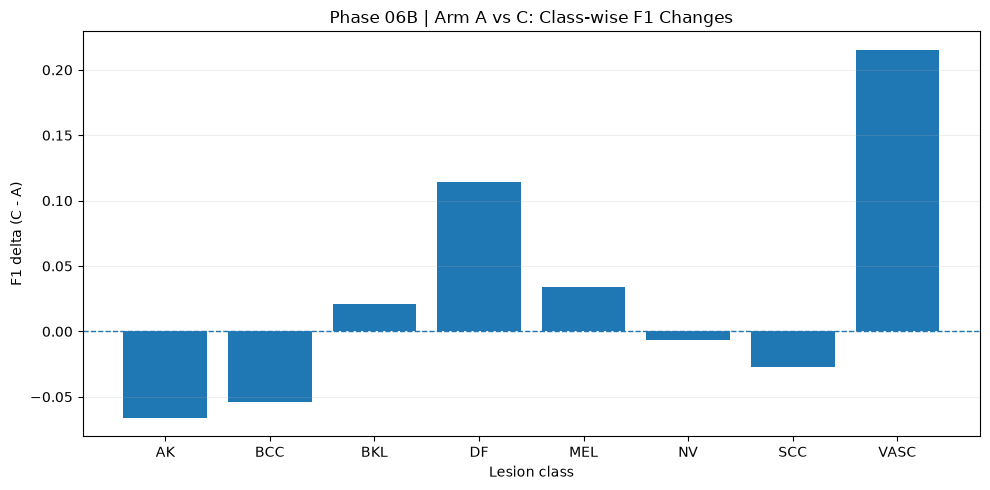

PHASE 06B — CELL 13
ARM A/C ERROR SHIFTS AND UNCERTAINTY
[PASS] Locked inner-validation predictions verified
[PASS] Exact A/C image pairing verified
[PASS] Eight-class support verified
[PASS] All 458 class-pure groups verified
[PASS] Cell 12 metrics independently reproduced
[PASS] Prediction gains/losses reconciled
[PASS] Class-wise performance analysis completed
[PASS] Group-aware bootstrap completed
[PASS] Input SHA-256 hashes unchanged
[PASS] Analysis artifacts exported
----------------------------------------------------------------------------
Images: 1469
Groups: 458
Arm A Macro-F1: 0.481467983
Arm C Macro-F1: 0.510299435
Delta C-A: +0.028831452
Changed predictions: 322
Recovered / Regressed: 101 / 120
Bootstrap 95% interval: [-0.048697, +0.100994]
----------------------------------------------------------------------------
CLASS-WISE F1 COMPARISON
----------------------------------------------------------------------------
class  support  groups    f1_A    f1_C  delta_f1
   AK  

In [161]:

# =============================================================================
# PHASE 06B — CELL 13
# ARM A/C CLASS-WISE ERROR SHIFTS & GROUP-AWARE UNCERTAINTY
# =============================================================================
# MODE: ANALYSIS ONLY
# No training, checkpoint loading, original-val, or outer-test evaluation.
# =============================================================================

from __future__ import annotations

import hashlib
import json
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score


# =============================================================================
# 1. CONFIGURATION
# =============================================================================

ROOT = Path(
    os.environ.get("SKIN_RESEARCH_ROOT", r"D:\skin_research")
)

# Set this only if automatic Arm A CSV detection fails.
ARM_A_CSV_OVERRIDE = None

BOOTSTRAP_REPLICATES = 2_000
RANDOM_SEED = 20261122

# Optional column-name overrides for nonstandard CSV schemas.
COLUMN_OVERRIDES = {
    "A": {},
    "C": {},
}

LABELS = (
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC",
)

N_CLASSES = len(LABELS)
N_IMAGES = 1469
N_GROUPS = 458

EXPECTED_SUPPORT = np.array([
    89, 343, 127, 14, 347, 476, 62, 11
])

EXPECTED_A_CORRECT = np.array([
    39, 255, 42, 7, 195, 387, 9, 3
])

EXPECTED_A_MACRO_F1 = 0.481467983
EXPECTED_C_MACRO_F1 = 0.510299435

EXPECTED_CHANGED = 322
EXPECTED_RECOVERED = 101
EXPECTED_REGRESSED = 120

EXPECTED_C_CONFUSION = np.array([
    [38, 20,  8, 0, 17,   3,  3, 0],
    [30, 218, 5, 0, 56,  18, 14, 2],
    [31,  6, 43, 4, 16,  19,  8, 0],
    [ 1,  4,  0, 7,  0,   0,  2, 0],
    [ 6, 11, 22, 0, 236, 61, 10, 1],
    [ 6, 32, 21, 1, 50, 361,  1, 4],
    [17, 14,  5, 0, 16,   3,  7, 0],
    [ 0,  2,  0, 0,  0,   1,  0, 8],
], dtype=np.int64)

COLUMN_ALIASES = {
    "image": (
        "filename", "file_name", "image_filename",
        "image_name", "image_id", "isic_id",
        "image_path", "file_path", "img_path",
        "path", "image", "file",
    ),
    "target": (
        "true_idx", "target_idx", "target_class_idx",
        "y_true", "true_class_idx", "true_label_idx",
        "label_idx", "ground_truth_idx", "target",
        "true_label", "true_class", "actual_class",
        "ground_truth", "diagnosis", "dx",
        "label", "class_name", "class_idx",
    ),
    "pred": (
        "pred_idx", "predicted_idx",
        "predicted_class_index", "y_pred",
        "pred_class_idx", "predicted_class_idx",
        "prediction_idx", "predicted_label_idx",
        "pred_label", "predicted_label",
        "predicted_class", "pred_class",
        "prediction", "predicted_diagnosis",
        "predicted_dx", "pred",
    ),
    "group": (
        "leakage_group", "leakage_group_id",
        "leakage_family", "leakage_family_id",
        "family_id", "group_id", "lesion_id",
        "lesion_group", "group", "patient_id",
    ),
}


# =============================================================================
# 2. VALIDATION AND FILE UTILITIES
# =============================================================================

def require(condition: bool, message: str) -> None:
    """Stop execution when an audit invariant fails."""
    if not condition:
        raise AssertionError(message)


def sha256_file(path: Path) -> str:
    """Compute SHA-256 without modifying the source file."""
    digest = hashlib.sha256()

    with path.open("rb") as handle:
        for chunk in iter(
            lambda: handle.read(1024 * 1024), b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def resolve_reports_directory(root: Path) -> Path:
    """Locate the existing project reports directory."""
    candidates = [
        root,
        Path.cwd(),
        *Path.cwd().parents,
    ]

    for parent in candidates:
        reports = parent / "outputs" / "reports"

        if reports.is_dir():
            return reports.resolve()

    raise FileNotFoundError(
        "Cannot locate outputs/reports. "
        "Check the ROOT configuration."
    )


def validate_input_csv(path: Path) -> Path:
    """Reject missing and forbidden evaluation sources."""
    path = path.expanduser().resolve()

    require(
        path.is_file() and path.suffix.lower() == ".csv",
        f"Missing CSV: {path}",
    )

    forbidden = (
        "outer",
        "test",
        "original_val",
        "original-validation",
    )

    require(
        not any(token in path.name.lower() for token in forbidden),
        f"Forbidden evaluation source: {path.name}",
    )

    return path


def detect_column(
    frame: pd.DataFrame,
    field: str,
    arm: str,
    optional: bool = False,
) -> str | None:
    """Resolve CSV fields using explicit or known column names."""
    override = COLUMN_OVERRIDES[arm].get(field)

    if override:
        require(
            override in frame.columns,
            f"{arm}: Missing configured column {override}",
        )
        return override

    available = {
        str(col).strip().lower(): str(col)
        for col in frame.columns
    }

    for candidate in COLUMN_ALIASES[field]:
        if candidate in available:
            return available[candidate]

    if optional:
        return None

    raise ValueError(
        f"{arm}: Cannot identify '{field}'. "
        f"Available columns: {list(frame.columns)}"
    )


def decode_class(value: object) -> int:
    """Convert original class labels or IDs to integer indices."""
    token = str(value).strip().upper()

    if token in LABELS:
        return LABELS.index(token)

    if re.fullmatch(r"[0-7](?:\.0+)?", token):
        return int(float(token))

    match = re.fullmatch(
        r"([0-7])[_\s:-]+([A-Z]+)", token
    )

    if match:
        index = int(match.group(1))

        if LABELS[index] == match.group(2):
            return index

    raise ValueError(
        f"Unexpected class label: {value!r}"
    )


def normalize_image_id(value: object) -> str:
    """Normalize filename keys for exact paired alignment."""
    name = (
        str(value)
        .strip()
        .replace("\\", "/")
        .rsplit("/", 1)[-1]
    )

    require(bool(name), "Empty image identifier")

    return re.sub(
        r"\.(jpe?g|png|bmp|tiff?|webp)$",
        "",
        name,
        flags=re.IGNORECASE,
    ).lower()


# =============================================================================
# 3. LOAD AND VALIDATE LOCKED PREDICTIONS
# =============================================================================

def load_predictions(
    path: Path,
    arm: str,
) -> pd.DataFrame:
    """Load audited per-image predictions with strict validation."""
    source = validate_input_csv(path)

    raw = pd.read_csv(
        source,
        dtype=str,
        keep_default_na=False,
    )

    image_col = detect_column(raw, "image", arm)
    target_col = detect_column(raw, "target", arm)
    pred_col = detect_column(raw, "pred", arm)
    group_col = detect_column(
        raw, "group", arm, optional=True
    )

    result = pd.DataFrame({
        "image": raw[image_col].map(normalize_image_id),
        f"true_{arm}": raw[target_col].map(decode_class),
        f"pred_{arm}": raw[pred_col].map(decode_class),
    })

    if group_col is not None:
        result[f"group_{arm}"] = (
            raw[group_col].astype(str).str.strip()
        )

        require(
            result[f"group_{arm}"].ne("").all(),
            f"{arm}: Missing leakage-group IDs",
        )

    require(
        len(result) == N_IMAGES,
        f"{arm}: Unexpected image count",
    )

    require(
        result["image"].is_unique,
        f"{arm}: Duplicate image identifiers",
    )

    observed_support = np.bincount(
        result[f"true_{arm}"],
        minlength=N_CLASSES,
    )

    require(
        np.array_equal(
            observed_support, EXPECTED_SUPPORT
        ),
        f"{arm}: Class support mismatch",
    )

    return result


def collect_csv_references(obj: object):
    """Collect CSV references from the previous audit JSON."""
    if isinstance(obj, dict):
        for value in obj.values():
            yield from collect_csv_references(value)

    elif isinstance(obj, list):
        for value in obj:
            yield from collect_csv_references(value)

    elif isinstance(obj, str) and ".csv" in obj.lower():
        yield obj


def resolve_arm_a_predictions(
    reports: Path,
    audit: dict,
    arm_c: pd.DataFrame,
) -> tuple[Path, pd.DataFrame]:
    """Find Arm A predictions that reproduce Cell 12 results."""
    if ARM_A_CSV_OVERRIDE is not None:
        candidates = [Path(ARM_A_CSV_OVERRIDE)]

    else:
        candidates = []

        arm_pattern = re.compile(
            r"(?<![a-z0-9])arm[_\s-]*a(?![a-z0-9])"
        )

        for reference in collect_csv_references(audit):
            if arm_pattern.search(reference.lower()):
                candidate = Path(reference)

                if not candidate.is_file():
                    filename = (
                        reference.replace("\\", "/").split("/")[-1]
                    )
                    candidate = reports / filename

                candidates.append(candidate)

        for path in reports.rglob("*.csv"):
            name = path.name.lower()

            if (
                arm_pattern.search(name)
                and (
                    "pred" in name
                    or "reference" in name
                )
            ):
                candidates.append(path)

    matches = []

    for candidate in dict.fromkeys(candidates):
        try:
            candidate = validate_input_csv(candidate)

            arm_a = load_predictions(candidate, "A")

            score = f1_score(
                arm_a["true_A"],
                arm_a["pred_A"],
                average="macro",
            )

            require(
                abs(score - EXPECTED_A_MACRO_F1) < 1e-8,
                "Arm A score mismatch",
            )

            require(
                set(arm_a["image"]) == set(arm_c["image"]),
                "Arm A/C image set mismatch",
            )

            matches.append((candidate, arm_a))

        except (
            ValueError,
            AssertionError,
            FileNotFoundError,
        ):
            continue

    if not matches:
        raise FileNotFoundError(
            "Audited Arm A predictions were not found. "
            "Set ARM_A_CSV_OVERRIDE to the exact Arm A CSV."
        )

    reference = (
        matches[0][1][["image", "true_A", "pred_A"]]
        .sort_values("image")
        .reset_index(drop=True)
    )

    for path, frame in matches[1:]:
        current = (
            frame[["image", "true_A", "pred_A"]]
            .sort_values("image")
            .reset_index(drop=True)
        )

        require(
            current.equals(reference),
            f"Conflicting Arm A prediction files: {path}",
        )

    return matches[0]


# =============================================================================
# 4. CLASS METRICS AND STATISTICAL UTILITIES
# =============================================================================

def calculate_class_metrics(
    cm: np.ndarray,
) -> pd.DataFrame:
    """Calculate precision, recall, and F1 for every class."""
    tp = np.diag(cm).astype(float)

    support = cm.sum(axis=1)
    predicted = cm.sum(axis=0)

    precision = np.divide(
        tp,
        predicted,
        out=np.zeros(N_CLASSES),
        where=predicted > 0,
    )

    recall = np.divide(
        tp,
        support,
        out=np.zeros(N_CLASSES),
        where=support > 0,
    )

    denominator = support + predicted

    f1 = np.divide(
        2 * tp,
        denominator,
        out=np.zeros(N_CLASSES),
        where=denominator > 0,
    )

    return pd.DataFrame({
        "class": LABELS,
        "support": support,
        "correct": tp.astype(int),
        "precision": precision,
        "recall": recall,
        "f1": f1,
    })


def f1_from_confusion(
    cm: np.ndarray,
) -> np.ndarray:
    """Return per-class F1 directly from a confusion matrix."""
    denominator = (
        cm.sum(axis=0) + cm.sum(axis=1)
    )

    return np.divide(
        2 * np.diag(cm),
        denominator,
        out=np.zeros(N_CLASSES, dtype=float),
        where=denominator > 0,
    )


def paired_group_bootstrap(
    paired: pd.DataFrame,
) -> pd.DataFrame:
    """Run paired, class-stratified leakage-group bootstrap."""
    group_a = []
    group_c = []
    group_labels = []

    grouped = paired.groupby(
        ["group", "y"],
        sort=True,
    )

    for (_, cls), part in grouped:
        cm_a = confusion_matrix(
            part["y"],
            part["pred_A"],
            labels=range(N_CLASSES),
        )

        cm_c = confusion_matrix(
            part["y"],
            part["pred_C"],
            labels=range(N_CLASSES),
        )

        group_a.append(cm_a)
        group_c.append(cm_c)
        group_labels.append(cls)

    group_a = np.stack(group_a)
    group_c = np.stack(group_c)
    group_labels = np.asarray(group_labels)

    require(
        len(group_labels) == N_GROUPS,
        "Bootstrap group count mismatch",
    )

    class_group_indices = [
        np.flatnonzero(group_labels == cls)
        for cls in range(N_CLASSES)
    ]

    require(
        all(len(indices) >= 2 for indices in class_group_indices),
        "Insufficient independent groups for a class",
    )

    rng = np.random.default_rng(RANDOM_SEED)

    # Macro-F1 delta, accuracy delta, and eight class F1 deltas.
    results = np.empty(
        (BOOTSTRAP_REPLICATES, 2 + N_CLASSES),
        dtype=np.float64,
    )

    for iteration in range(BOOTSTRAP_REPLICATES):
        sampled_indices = np.concatenate([
            rng.choice(
                indices,
                size=len(indices),
                replace=True,
            )
            for indices in class_group_indices
        ])

        cm_a = group_a[sampled_indices].sum(axis=0)
        cm_c = group_c[sampled_indices].sum(axis=0)

        delta_f1 = (
            f1_from_confusion(cm_c)
            - f1_from_confusion(cm_a)
        )

        accuracy_a = (
            np.trace(cm_a) / cm_a.sum()
        )

        accuracy_c = (
            np.trace(cm_c) / cm_c.sum()
        )

        results[iteration, 0] = delta_f1.mean()
        results[iteration, 1] = accuracy_c - accuracy_a
        results[iteration, 2:] = delta_f1

    columns = [
        "delta_macro_f1",
        "delta_accuracy",
        *[
            f"delta_f1_{label}"
            for label in LABELS
        ],
    ]

    return pd.DataFrame(results, columns=columns)


def percentile_summary(
    values: pd.Series,
) -> tuple[float, float, float]:
    """Return exploratory 95% bounds and positive fraction."""
    data = values.to_numpy(dtype=float)

    require(
        np.isfinite(data).all(),
        "Bootstrap contains nonfinite values",
    )

    lower, upper = np.quantile(
        data, [0.025, 0.975]
    )

    positive_fraction = np.mean(data > 0)

    return (
        float(lower),
        float(upper),
        float(positive_fraction),
    )


# =============================================================================
# 5. MAIN AUDIT AND ERROR-SHIFT ANALYSIS
# =============================================================================

def run_cell13() -> None:
    """Execute the reproducible Cell 13 analysis pipeline."""

    reports = resolve_reports_directory(ROOT)

    arm_c_path = validate_input_csv(
        reports
        / "phase06b_cell12_arm_C_inner_validation_predictions.csv"
    )

    audit_path = (
        reports
        / "phase06b_cell12_arm_C_independent_audit_and_paired_comparison.json"
    )

    require(
        audit_path.is_file(),
        f"Missing Cell 12 audit report: {audit_path}",
    )

    audit = json.loads(
        audit_path.read_text(encoding="utf-8")
    )

    require(
        isinstance(audit, dict),
        "Invalid audit JSON structure",
    )

    for field in (
        "status",
        "final_status",
        "audit_status",
    ):
        status = audit.get(field)

        if isinstance(status, str):
            require(
                "PASS" in status.upper(),
                f"Previous audit did not PASS: {field}",
            )

    # -------------------------------------------------------------------------
    # 5.1 Load independent predictions
    # -------------------------------------------------------------------------

    arm_c = load_predictions(arm_c_path, "C")

    cm_c_initial = confusion_matrix(
        arm_c["true_C"],
        arm_c["pred_C"],
        labels=range(N_CLASSES),
    )

    require(
        np.array_equal(
            cm_c_initial, EXPECTED_C_CONFUSION
        ),
        "Arm C independent confusion matrix mismatch",
    )

    arm_a_path, arm_a = resolve_arm_a_predictions(
        reports,
        audit,
        arm_c,
    )

    source_paths = (
        audit_path.resolve(),
        arm_a_path,
        arm_c_path,
    )

    source_hashes_before = {
        str(path): sha256_file(path)
        for path in source_paths
    }

    # -------------------------------------------------------------------------
    # 5.2 Exact A/C alignment and integrity checks
    # -------------------------------------------------------------------------

    paired = arm_a.merge(
        arm_c,
        on="image",
        how="inner",
        validate="one_to_one",
    )

    require(
        len(paired) == N_IMAGES,
        "Incomplete paired image coverage",
    )

    require(
        paired["true_A"].equals(paired["true_C"]),
        "Arm A/C true labels differ",
    )

    paired["y"] = paired["true_C"]

    if (
        "group_A" in paired.columns
        and "group_C" in paired.columns
    ):
        require(
            paired["group_A"].equals(paired["group_C"]),
            "Arm A/C leakage-group IDs differ",
        )

    group_column = (
        "group_C"
        if "group_C" in paired.columns
        else "group_A"
    )

    require(
        group_column in paired.columns,
        "No leakage-group identifier found",
    )

    paired["group"] = paired[group_column]

    require(
        paired["group"].nunique() == N_GROUPS,
        "Expected exactly 458 leakage groups",
    )

    require(
        paired.groupby("group")["y"]
        .nunique()
        .eq(1)
        .all(),
        "Leakage groups are not class-pure",
    )

    # -------------------------------------------------------------------------
    # 5.3 Reproduce Cell 12 locked scores
    # -------------------------------------------------------------------------

    cm_a = confusion_matrix(
        paired["y"],
        paired["pred_A"],
        labels=range(N_CLASSES),
    )

    cm_c = confusion_matrix(
        paired["y"],
        paired["pred_C"],
        labels=range(N_CLASSES),
    )

    require(
        np.array_equal(
            np.diag(cm_a), EXPECTED_A_CORRECT
        ),
        "Arm A correct-count mismatch",
    )

    require(
        np.array_equal(cm_c, EXPECTED_C_CONFUSION),
        "Arm C confusion matrix mismatch",
    )

    macro_a = float(f1_score(
        paired["y"],
        paired["pred_A"],
        average="macro",
    ))

    macro_c = float(f1_score(
        paired["y"],
        paired["pred_C"],
        average="macro",
    ))

    require(
        abs(macro_a - EXPECTED_A_MACRO_F1) < 1e-8,
        "Arm A Macro-F1 mismatch",
    )

    require(
        abs(macro_c - EXPECTED_C_MACRO_F1) < 1e-8,
        "Arm C Macro-F1 mismatch",
    )

    # -------------------------------------------------------------------------
    # 5.4 Paired correctness and prediction changes
    # -------------------------------------------------------------------------

    paired["correct_A"] = (
        paired["pred_A"] == paired["y"]
    )

    paired["correct_C"] = (
        paired["pred_C"] == paired["y"]
    )

    paired["changed"] = (
        paired["pred_A"] != paired["pred_C"]
    )

    paired["flip"] = np.select(
        [
            ~paired["correct_A"] & paired["correct_C"],
            paired["correct_A"] & ~paired["correct_C"],
            paired["correct_A"] & paired["correct_C"],
        ],
        [
            "recovered",
            "regressed",
            "both_correct",
        ],
        default="both_wrong",
    )

    flip_counts = paired["flip"].value_counts()

    changed = int(paired["changed"].sum())
    recovered = int(flip_counts.get("recovered", 0))
    regressed = int(flip_counts.get("regressed", 0))

    require(
        (
            changed,
            recovered,
            regressed,
        ) == (
            EXPECTED_CHANGED,
            EXPECTED_RECOVERED,
            EXPECTED_REGRESSED,
        ),
        "Prediction changes do not match Cell 12",
    )

    # -------------------------------------------------------------------------
    # 5.5 Class-wise performance comparison
    # -------------------------------------------------------------------------

    metrics_a = (
        calculate_class_metrics(cm_a)
        .set_index("class")
    )

    metrics_c = (
        calculate_class_metrics(cm_c)
        .set_index("class")
    )

    per_class = pd.DataFrame({
        "class": LABELS,
        "support": EXPECTED_SUPPORT,
        "groups": [
            paired.loc[
                paired["y"] == cls, "group"
            ].nunique()
            for cls in range(N_CLASSES)
        ],
        "precision_A": metrics_a["precision"].to_numpy(),
        "precision_C": metrics_c["precision"].to_numpy(),
        "recall_A": metrics_a["recall"].to_numpy(),
        "recall_C": metrics_c["recall"].to_numpy(),
        "f1_A": metrics_a["f1"].to_numpy(),
        "f1_C": metrics_c["f1"].to_numpy(),
        "correct_A": metrics_a["correct"].to_numpy(),
        "correct_C": metrics_c["correct"].to_numpy(),
    })

    for metric in (
        "precision",
        "recall",
        "f1",
        "correct",
    ):
        per_class[f"delta_{metric}"] = (
            per_class[f"{metric}_C"]
            - per_class[f"{metric}_A"]
        )

    # -------------------------------------------------------------------------
    # 5.6 Class-wise recovered and regressed predictions
    # -------------------------------------------------------------------------

    class_flips = (
        paired.groupby(["y", "flip"])
        .size()
        .unstack(fill_value=0)
        .reindex(
            index=range(N_CLASSES),
            columns=[
                "recovered",
                "regressed",
                "both_correct",
                "both_wrong",
            ],
            fill_value=0,
        )
        .reset_index()
    )

    class_flips["class"] = class_flips["y"].map(
        dict(enumerate(LABELS))
    )

    class_flips["net_correct_C_minus_A"] = (
        class_flips["recovered"]
        - class_flips["regressed"]
    )

    # -------------------------------------------------------------------------
    # 5.7 Prediction transition analysis
    # -------------------------------------------------------------------------

    transitions = (
        paired.groupby(
            ["y", "pred_A", "pred_C"],
            observed=True,
        )
        .agg(
            images=("image", "size"),
            groups=("group", "nunique"),
        )
        .reset_index()
    )

    label_mapping = dict(enumerate(LABELS))

    for column in ("y", "pred_A", "pred_C"):
        transitions[column] = (
            transitions[column].map(label_mapping)
        )

    transitions = transitions.sort_values(
        "images",
        ascending=False,
    )

    changed_images = paired.loc[
        paired["changed"],
        [
            "image",
            "group",
            "y",
            "pred_A",
            "pred_C",
            "flip",
        ],
    ].copy()

    for column in ("y", "pred_A", "pred_C"):
        changed_images[column] = (
            changed_images[column].map(label_mapping)
        )

    # -------------------------------------------------------------------------
    # 5.8 Group-level changes
    # -------------------------------------------------------------------------

    group_errors = (
        paired.groupby(
            ["group", "y"],
            observed=True,
        )
        .agg(
            images=("image", "size"),
            correct_A=("correct_A", "sum"),
            correct_C=("correct_C", "sum"),
            changed=("changed", "sum"),
        )
        .reset_index()
    )

    group_errors["class"] = (
        group_errors["y"].map(label_mapping)
    )

    group_errors["delta_correct"] = (
        group_errors["correct_C"]
        - group_errors["correct_A"]
    )

    require(
        len(group_errors) == N_GROUPS,
        "Group aggregation mismatch",
    )

    # -------------------------------------------------------------------------
    # 5.9 Paired leakage-group bootstrap
    # -------------------------------------------------------------------------

    bootstrap = paired_group_bootstrap(paired)

    ci_low, ci_high, positive_fraction = (
        percentile_summary(
            bootstrap["delta_macro_f1"]
        )
    )

    for label in LABELS:
        low, high, fraction = percentile_summary(
            bootstrap[f"delta_f1_{label}"]
        )

        selector = per_class["class"] == label

        per_class.loc[
            selector,
            [
                "ci95_low",
                "ci95_high",
                "bootstrap_positive_fraction",
            ],
        ] = [low, high, fraction]

    # -------------------------------------------------------------------------
    # 5.10 Verify input integrity before exports
    # -------------------------------------------------------------------------

    source_hashes_after = {
        str(path): sha256_file(path)
        for path in source_paths
    }

    require(
        source_hashes_before == source_hashes_after,
        "Locked source files changed",
    )

    # -------------------------------------------------------------------------
    # 6. EXPORT ANALYSIS REPORTS
    # -------------------------------------------------------------------------

    prefix = "phase06b_cell13_"

    output_tables = {
        "per_class_shifts.csv": per_class,
        "class_flips.csv": class_flips,
        "prediction_transitions.csv": transitions,
        "changed_images.csv": changed_images,
        "group_error_shifts.csv": group_errors,
        "group_bootstrap.csv": bootstrap,
    }

    for filename, table in output_tables.items():
        destination = reports / f"{prefix}{filename}"

        require(
            destination.resolve() not in source_paths,
            "Output conflicts with a locked input",
        )

        table.to_csv(
            destination,
            index=False,
        )

    # -------------------------------------------------------------------------
    # 7. VISUALIZATION
    # -------------------------------------------------------------------------

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.bar(
        per_class["class"],
        per_class["delta_f1"],
    )

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1,
    )

    ax.set_xlabel("Lesion class")
    ax.set_ylabel("F1 delta (C - A)")
    ax.set_title(
        "Phase 06B | Arm A vs C: Class-wise F1 Changes"
    )

    ax.grid(
        axis="y",
        alpha=0.2,
    )

    fig.tight_layout()

    fig.savefig(
        reports / f"{prefix}class_f1_shifts.png",
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()

    # -------------------------------------------------------------------------
    # 8. SUMMARY AND INTERPRETATION
    # -------------------------------------------------------------------------

    accuracy_a = float(paired["correct_A"].mean())
    accuracy_c = float(paired["correct_C"].mean())

    summary = {
        "phase": "06B",
        "cell": 13,
        "status": "PASS",
        "scope": (
            "Reused inner validation; "
            "exploratory post-selection analysis"
        ),
        "n_images": N_IMAGES,
        "n_groups": N_GROUPS,
        "macro_f1_A": macro_a,
        "macro_f1_C": macro_c,
        "delta_macro_f1": macro_c - macro_a,
        "accuracy_A": accuracy_a,
        "accuracy_C": accuracy_c,
        "changed": changed,
        "recovered": recovered,
        "regressed": regressed,
        "paired_group_bootstrap": {
            "replicates": BOOTSTRAP_REPLICATES,
            "seed": RANDOM_SEED,
            "delta_macro_f1_ci95": [
                ci_low,
                ci_high,
            ],
            "fraction_delta_positive": positive_fraction,
            "interval_includes_zero": (
                ci_low <= 0 <= ci_high
            ),
            "limitation": (
                "Exploratory, post-selection, "
                "not independent confirmation"
            ),
        },
        "decision": (
            "INCONCLUSIVE: preserve Arm A and Arm C"
        ),
        "safety": {
            "training_performed": False,
            "checkpoints_modified": False,
            "original_val_evaluated": False,
            "outer_test_evaluated": False,
        },
        "input_sha256": source_hashes_before,
    }

    require(
        source_hashes_before == {
            str(path): sha256_file(path)
            for path in source_paths
        },
        "Input integrity failure",
    )

    summary_path = reports / f"{prefix}summary.json"

    summary_path.write_text(
        json.dumps(
            summary,
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )

    interpretation = (
        "# Phase 06B — Cell 13: Error-Shift Interpretation\n\n"
        f"- Macro-F1 Arm A: {macro_a:.9f}\n"
        f"- Macro-F1 Arm C: {macro_c:.9f}\n"
        f"- Delta C-A: {macro_c - macro_a:+.9f}\n"
        f"- Accuracy A: {accuracy_a:.6f}\n"
        f"- Accuracy C: {accuracy_c:.6f}\n"
        f"- Changed predictions: {changed}\n"
        f"- Recovered by C: {recovered}\n"
        f"- Regressed in C: {regressed}\n"
        f"- Exploratory bootstrap 95% interval: "
        f"[{ci_low:+.6f}, {ci_high:+.6f}]\n\n"
        "## Interpretation\n\n"
        "- Higher Macro-F1 does not imply better accuracy.\n"
        "- Review MEL gains against BCC and NV regressions.\n"
        "- SCC remains a weak-performing minority class.\n"
        "- DF and VASC have limited sample/group support.\n"
        "- Reused validation creates post-selection uncertainty.\n"
        "- No independently confirmed winning arm.\n\n"
        "## Next Step\n\n"
        "- Preserve Arm A and Arm C checkpoints.\n"
        "- Predefine primary and secondary metrics.\n"
        "- Plan leakage-grouped cross-fold evaluation.\n"
        "- Keep original validation and outer-test untouched.\n"
    )

    interpretation_path = (
        reports / f"{prefix}interpretation.md"
    )

    interpretation_path.write_text(
        interpretation,
        encoding="utf-8",
    )

    # -------------------------------------------------------------------------
    # 9. FINAL VERIFICATION OUTPUT
    # -------------------------------------------------------------------------

    print("=" * 76)
    print("PHASE 06B — CELL 13")
    print("ARM A/C ERROR SHIFTS AND UNCERTAINTY")
    print("=" * 76)

    print("[PASS] Locked inner-validation predictions verified")
    print("[PASS] Exact A/C image pairing verified")
    print("[PASS] Eight-class support verified")
    print("[PASS] All 458 class-pure groups verified")
    print("[PASS] Cell 12 metrics independently reproduced")
    print("[PASS] Prediction gains/losses reconciled")
    print("[PASS] Class-wise performance analysis completed")
    print("[PASS] Group-aware bootstrap completed")
    print("[PASS] Input SHA-256 hashes unchanged")
    print("[PASS] Analysis artifacts exported")

    print("-" * 76)
    print(f"Images: {N_IMAGES}")
    print(f"Groups: {N_GROUPS}")
    print(f"Arm A Macro-F1: {macro_a:.9f}")
    print(f"Arm C Macro-F1: {macro_c:.9f}")

    print(
        f"Delta C-A: {macro_c - macro_a:+.9f}"
    )

    print(
        f"Changed predictions: {changed}"
    )

    print(
        f"Recovered / Regressed: "
        f"{recovered} / {regressed}"
    )

    print(
        f"Bootstrap 95% interval: "
        f"[{ci_low:+.6f}, {ci_high:+.6f}]"
    )

    print("-" * 76)
    print("CLASS-WISE F1 COMPARISON")
    print("-" * 76)

    print(
        per_class[
            [
                "class",
                "support",
                "groups",
                "f1_A",
                "f1_C",
                "delta_f1",
            ]
        ]
        .round(5)
        .to_string(index=False)
    )

    print("-" * 76)
    print("DECISION: INCONCLUSIVE — PRESERVE BOTH ARMS")
    print("Training performed: NO")
    print("Checkpoints modified: NO")
    print("Original validation evaluated: NO")
    print("Outer-test evaluated: NO")
    print("Reports directory:", reports)
    print("PHASE 06B — CELL 13: PASS")
    print("=" * 76)


# =============================================================================
# 10. EXECUTION
# =============================================================================

run_cell13()


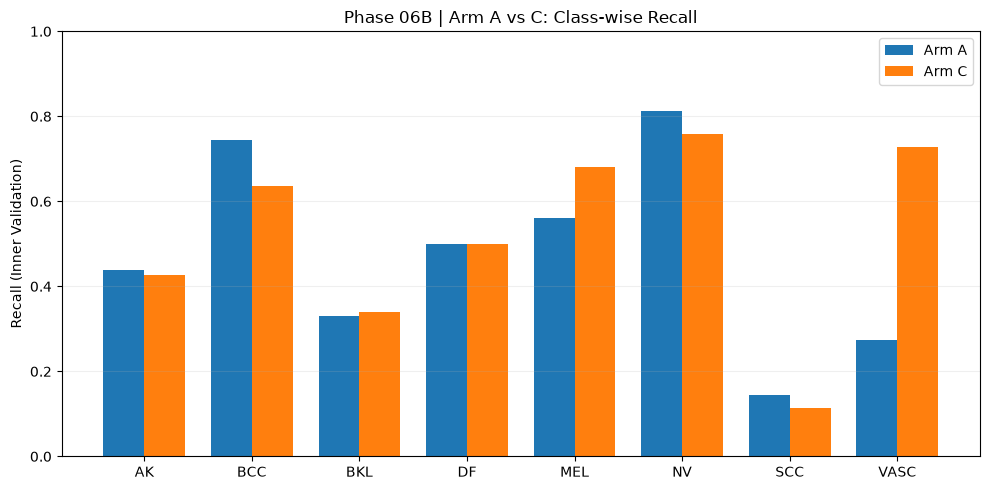

PHASE 06B - CELL 14
ERROR TRANSITIONS AND EXPERIMENT DECISION GATE
[PASS] Cell 13 source artifacts validated
[PASS] Arm A/C confusion matrices reconstructed
[PASS] Paired prediction transitions reconciled
[PASS] Changed-image records verified
[PASS] All 458 leakage groups reconciled
[PASS] Per-class FN/FP analysis completed
[PASS] BCC/MEL/SCC confusion analysis completed
[PASS] Group-level error analysis completed
[PASS] Bootstrap uncertainty checked
[PASS] Input SHA-256 hashes unchanged
[PASS] Cell 14 research artifacts exported
----------------------------------------------------------------------------
Arm A Macro-F1: 0.481467983
Arm C Macro-F1: 0.510299435
Macro-F1 Delta C-A: +0.028831452
Accuracy A/C: 0.637849 / 0.624915
Changed predictions: 322
Recovered / Regressed: 101 / 120
Exploratory bootstrap 95% interval: [-0.048697, +0.100994]
----------------------------------------------------------------------------
TOP BCC / MEL / SCC CONFUSION ERRORS
---------------------------------

In [162]:

# =============================================================================
# PHASE 06B - CELL 14
# ERROR TRANSITIONS, GROUP-LEVEL ANALYSIS AND EXPERIMENT DECISION GATE
# =============================================================================
# MODE: READ-ONLY ANALYSIS OF CELL 13 INPUT ARTIFACTS
#
# Inputs:
#   - Phase 06B Cell 13 CSV reports and summary JSON
#
# Outputs:
#   - Reconstructed Arm A/C confusion matrices
#   - Class-level false-positive and false-negative analysis
#   - BCC / MEL / SCC error transition reports
#   - Group-level error concentration analysis
#   - Exploratory paired-bootstrap interpretation
#   - Predefined next-experiment decision protocol
#
# Restrictions:
#   - NO training
#   - NO checkpoint loading or modification
#   - NO original validation evaluation
#   - NO outer-test evaluation
# =============================================================================

from __future__ import annotations

import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# =============================================================================
# 1. LOCKED CONFIGURATION
# =============================================================================

PROJECT_ROOT = Path(
    os.getenv("SKIN_RESEARCH_ROOT", r"D:\skin_research")
)

REPORTS_DIR_OVERRIDE = None

CLASSES = (
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC",
)

FOCUS_CLASSES = ("BCC", "MEL", "SCC")

CLASS_TO_ID = {
    name: index
    for index, name in enumerate(CLASSES)
}

EXPECTED_SUPPORT = np.array([
    89, 343, 127, 14,
    347, 476, 62, 11,
])

EXPECTED_A_CORRECT = np.array([
    39, 255, 42, 7,
    195, 387, 9, 3,
])

EXPECTED_C_CONFUSION = np.array([
    [38, 20, 8, 0, 17, 3, 3, 0],
    [30, 218, 5, 0, 56, 18, 14, 2],
    [31, 6, 43, 4, 16, 19, 8, 0],
    [1, 4, 0, 7, 0, 0, 2, 0],
    [6, 11, 22, 0, 236, 61, 10, 1],
    [6, 32, 21, 1, 50, 361, 1, 4],
    [17, 14, 5, 0, 16, 3, 7, 0],
    [0, 2, 0, 0, 0, 1, 0, 8],
], dtype=np.int64)

EXPECTED_N_IMAGES = 1469
EXPECTED_N_GROUPS = 458

EXPECTED_A_MACRO_F1 = 0.481467983
EXPECTED_C_MACRO_F1 = 0.510299435

EXPECTED_CHANGES = 322
EXPECTED_RECOVERED = 101
EXPECTED_REGRESSED = 120

INPUT_PREFIX = "phase06b_cell13_"
OUTPUT_PREFIX = "phase06b_cell14_"


# =============================================================================
# 2. REUSABLE VALIDATION FUNCTIONS
# =============================================================================

def ensure(condition: bool, message: str) -> None:
    """Fail immediately when an audit invariant is violated."""
    if not condition:
        raise ValueError(
            f"CELL 14 VALIDATION FAILED: {message}"
        )


def find_reports_dir() -> Path:
    """Locate existing reports without reading test data."""

    if REPORTS_DIR_OVERRIDE:
        candidates = [Path(REPORTS_DIR_OVERRIDE)]
    else:
        candidates = [
            PROJECT_ROOT / "outputs" / "reports"
        ]

        candidates += [
            parent / "outputs" / "reports"
            for parent in (
                Path.cwd(),
                *Path.cwd().parents,
            )
        ]

    for path in candidates:
        if path.is_dir():
            return path.resolve()

    raise FileNotFoundError(
        "Cannot locate outputs/reports. "
        "Set REPORTS_DIR_OVERRIDE."
    )


def sha256_file(path: Path) -> str:
    """Calculate input-file SHA-256 without modification."""

    digest = hashlib.sha256()

    with path.open("rb") as stream:
        for block in iter(
            lambda: stream.read(1024 * 1024),
            b"",
        ):
            digest.update(block)

    return digest.hexdigest()


def expect_columns(
    frame: pd.DataFrame,
    columns: tuple[str, ...],
    artifact: str,
) -> None:
    """Validate required source-table columns."""

    missing = set(columns) - set(frame.columns)

    ensure(
        not missing,
        f"{artifact} missing columns: {sorted(missing)}",
    )


def integer_column(
    frame: pd.DataFrame,
    column: str,
) -> None:
    """Require non-negative integer counts."""

    values = pd.to_numeric(
        frame[column],
        errors="raise",
    )

    ensure(
        values.notna().all(),
        f"Missing values: {column}",
    )

    ensure(
        np.isfinite(
            values.to_numpy(dtype=float)
        ).all(),
        f"Non-finite values: {column}",
    )

    ensure(
        (values >= 0).all()
        and (values == np.floor(values)).all(),
        f"Invalid counts: {column}",
    )

    frame[column] = values.astype(np.int64)


def confusion_stats(
    cm: np.ndarray,
) -> dict:
    """Calculate classification metrics from a confusion matrix."""

    tp = np.diag(cm).astype(np.int64)

    support = cm.sum(axis=1).astype(np.int64)
    predicted = cm.sum(axis=0).astype(np.int64)

    precision = np.divide(
        tp,
        predicted,
        out=np.zeros(8, dtype=float),
        where=predicted != 0,
    )

    recall = np.divide(
        tp,
        support,
        out=np.zeros(8, dtype=float),
        where=support != 0,
    )

    denominator = support + predicted

    f1 = np.divide(
        2 * tp,
        denominator,
        out=np.zeros(8, dtype=float),
        where=denominator != 0,
    )

    return {
        "tp": tp,
        "support": support,
        "predicted": predicted,
        "fp": predicted - tp,
        "fn": support - tp,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_f1": float(f1.mean()),
        "accuracy": float(tp.sum() / cm.sum()),
    }


def categorize_transition(
    truth: str,
    arm_a: str,
    arm_c: str,
) -> str:
    """Classify paired prediction changes."""

    if arm_a == arm_c:
        return (
            "unchanged_correct"
            if arm_a == truth
            else "unchanged_wrong"
        )

    if arm_c == truth:
        return "recovered"

    if arm_a == truth:
        return "regressed"

    return "wrong_to_wrong"


def exploratory_ci(
    data: np.ndarray,
) -> dict:
    """Summarize exploratory paired-bootstrap samples."""

    low, high = np.quantile(
        data,
        [0.025, 0.975],
    )

    return {
        "lower_95": float(low),
        "upper_95": float(high),
        "fraction_positive": float(
            (data > 0).mean()
        ),
        "includes_zero": bool(
            low <= 0 <= high
        ),
    }


# =============================================================================
# 3. SAFE OUTPUT FUNCTIONS
# =============================================================================

def save_csv(
    output_dir: Path,
    filename: str,
    frame: pd.DataFrame,
    sources: set[Path],
) -> None:
    """Write only namespaced Cell 14 CSV artifacts."""

    ensure(
        filename.startswith(OUTPUT_PREFIX)
        and filename.endswith(".csv"),
        "Unsafe CSV export filename",
    )

    target = output_dir / filename

    ensure(
        not target.is_symlink()
        and target.resolve() not in sources,
        f"Export conflicts with source: {target}",
    )

    frame.to_csv(
        target,
        index=False,
    )


def save_text(
    output_dir: Path,
    filename: str,
    content: str,
    sources: set[Path],
) -> None:
    """Write only Cell 14 JSON or Markdown reports."""

    ensure(
        filename.startswith(OUTPUT_PREFIX)
        and filename.endswith((".md", ".json")),
        "Unsafe document filename",
    )

    target = output_dir / filename

    ensure(
        not target.is_symlink()
        and target.resolve() not in sources,
        "Document conflicts with source",
    )

    target.write_text(
        content,
        encoding="utf-8",
    )


# =============================================================================
# 4. MAIN AUDIT AND ERROR ANALYSIS
# =============================================================================

def run_cell14() -> None:
    """Run complete Cell 14 analysis and decision reporting."""

    reports = find_reports_dir()

    # -------------------------------------------------------------------------
    # 4.1 LOCKED INPUT ARTIFACTS
    # -------------------------------------------------------------------------

    input_files = {
        "transitions": (
            f"{INPUT_PREFIX}prediction_transitions.csv"
        ),
        "per_class": (
            f"{INPUT_PREFIX}per_class_shifts.csv"
        ),
        "class_flips": (
            f"{INPUT_PREFIX}class_flips.csv"
        ),
        "changed_images": (
            f"{INPUT_PREFIX}changed_images.csv"
        ),
        "groups": (
            f"{INPUT_PREFIX}group_error_shifts.csv"
        ),
        "bootstrap": (
            f"{INPUT_PREFIX}group_bootstrap.csv"
        ),
        "summary": (
            f"{INPUT_PREFIX}summary.json"
        ),
    }

    paths = {
        name: reports / filename
        for name, filename in input_files.items()
    }

    for name, path in paths.items():
        ensure(
            path.is_file(),
            f"Missing Cell 13 artifact: {name} | {path}",
        )

    source_paths = {
        path.resolve()
        for path in paths.values()
    }

    before_hashes = {
        name: sha256_file(path)
        for name, path in paths.items()
    }

    # -------------------------------------------------------------------------
    # 4.2 LOAD EXISTING CELL 13 REPORTS
    # -------------------------------------------------------------------------

    transitions = pd.read_csv(
        paths["transitions"]
    )

    per_class = pd.read_csv(
        paths["per_class"]
    )

    class_flips = pd.read_csv(
        paths["class_flips"]
    )

    changed_images = pd.read_csv(
        paths["changed_images"],
        dtype={
            "group": "string",
            "image": "string",
        },
    )

    groups = pd.read_csv(
        paths["groups"],
        dtype={"group": "string"},
    )

    bootstrap = pd.read_csv(
        paths["bootstrap"]
    )

    summary = json.loads(
        paths["summary"].read_text(
            encoding="utf-8"
        )
    )

    # -------------------------------------------------------------------------
    # 4.3 SOURCE SCHEMA VALIDATION
    # -------------------------------------------------------------------------

    expect_columns(
        transitions,
        ("y", "pred_A", "pred_C", "images", "groups"),
        "transitions",
    )

    expect_columns(
        per_class,
        (
            "class", "support", "groups",
            "f1_A", "f1_C",
            "recall_A", "recall_C",
        ),
        "per_class",
    )

    expect_columns(
        class_flips,
        (
            "class",
            "recovered",
            "regressed",
            "both_correct",
            "both_wrong",
        ),
        "class_flips",
    )

    expect_columns(
        changed_images,
        (
            "image", "group", "y",
            "pred_A", "pred_C", "flip",
        ),
        "changed_images",
    )

    expect_columns(
        groups,
        (
            "group", "class", "images",
            "correct_A", "correct_C",
            "changed", "delta_correct",
        ),
        "groups",
    )

    bootstrap_columns = (
        "delta_macro_f1",
        "delta_accuracy",
        *[
            f"delta_f1_{label}"
            for label in CLASSES
        ],
    )

    expect_columns(
        bootstrap,
        bootstrap_columns,
        "bootstrap",
    )

    ensure(
        summary.get("status") == "PASS",
        "Previous Cell 13 status is not PASS",
    )

    ensure(
        set(per_class["class"]) == set(CLASSES)
        and len(per_class) == 8,
        "Per-class labels incorrect",
    )

    ensure(
        set(class_flips["class"]) == set(CLASSES)
        and len(class_flips) == 8,
        "Class-flip labels incorrect",
    )

    for column in (
        "y", "pred_A", "pred_C",
    ):
        ensure(
            transitions[column].isin(CLASSES).all(),
            f"Unexpected transition label: {column}",
        )

        ensure(
            changed_images[column].isin(CLASSES).all(),
            f"Unexpected changed-image label: {column}",
        )

    ensure(
        groups["class"].isin(CLASSES).all(),
        "Unexpected leakage-group class",
    )

    ensure(
        not transitions.duplicated(
            ["y", "pred_A", "pred_C"]
        ).any(),
        "Duplicate prediction transitions",
    )

    ensure(
        changed_images["image"].notna().all()
        and changed_images["image"].is_unique,
        "Duplicate changed-image identifiers",
    )

    ensure(
        groups["group"].notna().all()
        and groups["group"].is_unique,
        "Duplicate leakage-group identifiers",
    )

    integer_fields = (
        (transitions, ("images", "groups")),
        (per_class, ("support", "groups")),
        (
            class_flips,
            (
                "recovered", "regressed",
                "both_correct", "both_wrong",
            ),
        ),
        (
            groups,
            (
                "images", "correct_A",
                "correct_C", "changed",
            ),
        ),
    )

    for frame, columns in integer_fields:
        for column in columns:
            integer_column(
                frame,
                column,
            )

    # -------------------------------------------------------------------------
    # 5. RECONSTRUCT ARM A/C CONFUSION MATRICES
    # -------------------------------------------------------------------------

    cm_a = np.zeros(
        (8, 8),
        dtype=np.int64,
    )

    cm_c = np.zeros(
        (8, 8),
        dtype=np.int64,
    )

    for item in transitions.itertuples(index=False):

        truth, pred_a, pred_c = (
            CLASS_TO_ID[value]
            for value in (
                item.y,
                item.pred_A,
                item.pred_C,
            )
        )

        cm_a[truth, pred_a] += int(item.images)
        cm_c[truth, pred_c] += int(item.images)

    metrics_a = confusion_stats(cm_a)
    metrics_c = confusion_stats(cm_c)

    ensure(
        int(cm_c.sum()) == EXPECTED_N_IMAGES,
        "Unexpected inner-validation image count",
    )

    ensure(
        np.array_equal(
            cm_a.sum(axis=1),
            EXPECTED_SUPPORT,
        ),
        "Arm A class support mismatch",
    )

    ensure(
        np.array_equal(
            cm_c,
            EXPECTED_C_CONFUSION,
        ),
        "Arm C confusion matrix mismatch",
    )

    ensure(
        np.array_equal(
            np.diag(cm_a),
            EXPECTED_A_CORRECT,
        ),
        "Arm A correct-count mismatch",
    )

    macro_a = metrics_a["macro_f1"]
    macro_c = metrics_c["macro_f1"]

    ensure(
        abs(macro_a - EXPECTED_A_MACRO_F1) < 1e-8,
        "Arm A Macro-F1 mismatch",
    )

    ensure(
        abs(macro_c - EXPECTED_C_MACRO_F1) < 1e-8,
        "Arm C Macro-F1 mismatch",
    )

    ensure(
        abs(
            macro_a - float(summary["macro_f1_A"])
        ) < 1e-10,
        "Cell 13 Arm A summary mismatch",
    )

    ensure(
        abs(
            macro_c - float(summary["macro_f1_C"])
        ) < 1e-10,
        "Cell 13 Arm C summary mismatch",
    )

    # -------------------------------------------------------------------------
    # 6. EXACT PAIRED PREDICTION TRANSITIONS
    # -------------------------------------------------------------------------

    transitions["transition_type"] = [
        categorize_transition(truth, pred_a, pred_c)
        for truth, pred_a, pred_c in zip(
            transitions["y"],
            transitions["pred_A"],
            transitions["pred_C"],
        )
    ]

    transition_totals = (
        transitions.groupby("transition_type")["images"]
        .sum()
        .to_dict()
    )

    ensure(
        transition_totals.get("recovered", 0)
        == EXPECTED_RECOVERED,
        "Recovered-prediction mismatch",
    )

    ensure(
        transition_totals.get("regressed", 0)
        == EXPECTED_REGRESSED,
        "Regressed-prediction mismatch",
    )

    ensure(
        transition_totals.get("wrong_to_wrong", 0)
        == 101,
        "Wrong-to-wrong transition mismatch",
    )

    changed_total = sum(
        transition_totals.get(category, 0)
        for category in (
            "recovered",
            "regressed",
            "wrong_to_wrong",
        )
    )

    ensure(
        changed_total == EXPECTED_CHANGES,
        "Total changed-prediction mismatch",
    )

    ensure(
        transition_totals.get("unchanged_correct", 0)
        == 817,
        "Unchanged-correct count mismatch",
    )

    ensure(
        transition_totals.get("unchanged_wrong", 0)
        == 330,
        "Unchanged-wrong count mismatch",
    )

    # -------------------------------------------------------------------------
    # 7. CHANGED-IMAGE AND CLASS-FLIP RECONCILIATION
    # -------------------------------------------------------------------------

    ensure(
        len(changed_images) == EXPECTED_CHANGES,
        "Changed-image count mismatch",
    )

    ensure(
        (
            changed_images["pred_A"]
            != changed_images["pred_C"]
        ).all(),
        "Unchanged prediction found in changed-image CSV",
    )

    expected_flip = changed_images.apply(
        lambda row: (
            "recovered"
            if row["pred_C"] == row["y"]
            else (
                "regressed"
                if row["pred_A"] == row["y"]
                else "both_wrong"
            )
        ),
        axis=1,
    )

    ensure(
        (changed_images["flip"] == expected_flip).all(),
        "Per-image flip classification mismatch",
    )

    changed_aggregated = (
        changed_images.groupby(
            ["y", "pred_A", "pred_C"]
        )
        .size()
        .sort_index()
    )

    transition_changed = (
        transitions.loc[
            transitions["pred_A"]
            != transitions["pred_C"]
        ]
        .set_index(
            ["y", "pred_A", "pred_C"]
        )["images"]
        .sort_index()
    )

    ensure(
        changed_aggregated.equals(transition_changed),
        "Changed images and transition counts disagree",
    )

    flip_by_class = (
        transitions.assign(
            flip=transitions["transition_type"].replace({
                "wrong_to_wrong": "both_wrong",
                "unchanged_wrong": "both_wrong",
                "unchanged_correct": "both_correct",
            })
        )
        .groupby(["y", "flip"])["images"]
        .sum()
        .unstack(fill_value=0)
    )

    class_flips_indexed = (
        class_flips.set_index("class")
    )

    for label in CLASSES:
        for status in (
            "recovered",
            "regressed",
            "both_correct",
            "both_wrong",
        ):
            ensure(
                int(
                    class_flips_indexed.loc[
                        label, status
                    ]
                )
                == int(
                    flip_by_class.loc[
                        label, status
                    ]
                ),
                f"Class-flip mismatch: {label}/{status}",
            )

    # -------------------------------------------------------------------------
    # 8. GROUP-LEVEL ERROR ANALYSIS
    # -------------------------------------------------------------------------

    ensure(
        len(groups) == EXPECTED_N_GROUPS,
        "Expected exactly 458 leakage groups",
    )

    ensure(
        int(groups["images"].sum())
        == EXPECTED_N_IMAGES,
        "Group image total mismatch",
    )

    ensure(
        int(groups["correct_A"].sum())
        == int(metrics_a["tp"].sum()),
        "Group Arm A correctness mismatch",
    )

    ensure(
        int(groups["correct_C"].sum())
        == int(metrics_c["tp"].sum()),
        "Group Arm C correctness mismatch",
    )

    ensure(
        int(groups["changed"].sum())
        == EXPECTED_CHANGES,
        "Group changed-prediction mismatch",
    )

    for column in (
        "correct_A",
        "correct_C",
        "changed",
    ):
        ensure(
            (groups[column] <= groups["images"]).all(),
            f"Invalid group count: {column}",
        )

    ensure(
        (
            groups["correct_C"]
            - groups["correct_A"]
            == groups["delta_correct"]
        ).all(),
        "Group correctness delta mismatch",
    )

    group_lookup = groups.set_index("group")["class"]

    ensure(
        set(changed_images["group"]).issubset(
            set(groups["group"])
        ),
        "Unknown leakage group in changed images",
    )

    ensure(
        (
            changed_images["group"].map(group_lookup)
            == changed_images["y"]
        ).all(),
        "Leakage group and diagnosis mismatch",
    )

    actual_changes_by_group = (
        changed_images.groupby("group").size()
    )

    ensure(
        (
            groups["group"]
            .map(actual_changes_by_group)
            .fillna(0)
            .to_numpy()
            == groups["changed"].to_numpy()
        ).all(),
        "Group-level changed-image mismatch",
    )

    group_class_support = (
        groups.groupby("class")["images"]
        .sum()
        .reindex(CLASSES)
        .to_numpy()
    )

    ensure(
        np.array_equal(
            group_class_support,
            EXPECTED_SUPPORT,
        ),
        "Group/class support mismatch",
    )

    group_class_counts = (
        groups.groupby("class")
        .size()
        .reindex(CLASSES)
        .to_numpy()
    )

    reported_group_counts = (
        per_class.set_index("class")
        .reindex(CLASSES)["groups"]
        .to_numpy()
    )

    ensure(
        np.array_equal(
            group_class_counts,
            reported_group_counts,
        ),
        "Independent group counts mismatch",
    )

    group_flips = (
        changed_images.groupby(
            ["group", "flip"]
        )
        .size()
        .unstack(fill_value=0)
    )

    for column in (
        "recovered",
        "regressed",
        "both_wrong",
    ):
        groups[column] = (
            groups["group"]
            .map(
                group_flips.get(
                    column,
                    pd.Series(dtype=int),
                )
            )
            .fillna(0)
            .astype(int)
        )

    ensure(
        (
            groups["recovered"]
            - groups["regressed"]
            == groups["delta_correct"]
        ).all(),
        "Paired group gain/loss mismatch",
    )

    groups["change_rate"] = (
        groups["changed"] / groups["images"]
    )

    groups["accuracy_A"] = (
        groups["correct_A"] / groups["images"]
    )

    groups["accuracy_C"] = (
        groups["correct_C"] / groups["images"]
    )

    # -------------------------------------------------------------------------
    # 9. PER-CLASS FALSE POSITIVES AND FALSE NEGATIVES
    # -------------------------------------------------------------------------

    diagnostics = pd.DataFrame({
        "class": CLASSES,
        "support": EXPECTED_SUPPORT,
        "independent_groups": group_class_counts,
        "correct_A": metrics_a["tp"],
        "correct_C": metrics_c["tp"],
        "false_negatives_A": metrics_a["fn"],
        "false_negatives_C": metrics_c["fn"],
        "false_positives_A": metrics_a["fp"],
        "false_positives_C": metrics_c["fp"],
        "recall_A": metrics_a["recall"],
        "recall_C": metrics_c["recall"],
        "precision_A": metrics_a["precision"],
        "precision_C": metrics_c["precision"],
        "f1_A": metrics_a["f1"],
        "f1_C": metrics_c["f1"],
    })

    for metric in (
        "correct",
        "false_negatives",
        "false_positives",
        "recall",
        "precision",
        "f1",
    ):
        diagnostics[
            f"delta_{metric}_C_minus_A"
        ] = (
            diagnostics[f"{metric}_C"]
            - diagnostics[f"{metric}_A"]
        )

    source_metrics = (
        per_class.set_index("class")
        .reindex(CLASSES)
    )

    for metric in (
        "f1",
        "recall",
        "precision",
    ):
        for arm in ("A", "C"):

            column = f"{metric}_{arm}"

            if column in source_metrics.columns:
                ensure(
                    np.allclose(
                        diagnostics[column],
                        source_metrics[column],
                        atol=1e-6,
                        rtol=0,
                    ),
                    f"Cell 13 metric mismatch: {column}",
                )

    # -------------------------------------------------------------------------
    # 10. EXACT CONFUSION-PAIR ANALYSIS
    # -------------------------------------------------------------------------

    confusion_pairs = pd.DataFrame([
        {
            "actual": CLASSES[i],
            "mistaken_as": CLASSES[j],
            "errors_A": int(cm_a[i, j]),
            "errors_C": int(cm_c[i, j]),
            "delta_errors_C_minus_A": int(
                cm_c[i, j] - cm_a[i, j]
            ),
            "actual_support": int(
                EXPECTED_SUPPORT[i]
            ),
        }
        for i in range(8)
        for j in range(8)
        if i != j
    ])

    confusion_pairs = confusion_pairs.sort_values(
        [
            "errors_C",
            "actual",
            "mistaken_as",
        ],
        ascending=[False, True, True],
    )

    focus_pairs = confusion_pairs.loc[
        confusion_pairs["actual"].isin(
            FOCUS_CLASSES
        )
    ].copy()

    focus_transitions = transitions.loc[
        transitions["transition_type"].isin([
            "recovered",
            "regressed",
            "wrong_to_wrong",
        ])
        &
        transitions["y"].isin(
            FOCUS_CLASSES
        )
    ].sort_values(
        "images",
        ascending=False,
    ).copy()

    group_risk = groups.sort_values(
        [
            "delta_correct",
            "changed",
            "images",
        ],
        ascending=[True, False, False],
    ).copy()

    affected_groups = int(
        (groups["changed"] > 0).sum()
    )

    improved_groups = int(
        (groups["delta_correct"] > 0).sum()
    )

    worsened_groups = int(
        (groups["delta_correct"] < 0).sum()
    )

    # -------------------------------------------------------------------------
    # 11. EXPLORATORY BOOTSTRAP INTERPRETATION
    # -------------------------------------------------------------------------

    ensure(
        len(bootstrap) == 2000,
        "Expected 2,000 bootstrap replicates",
    )

    ensure(
        np.isfinite(
            bootstrap[
                list(bootstrap_columns)
            ].to_numpy(dtype=float)
        ).all(),
        "Non-finite bootstrap results",
    )

    uncertainty_rows = []

    for column in bootstrap_columns:

        result = exploratory_ci(
            bootstrap[column].to_numpy(
                dtype=float
            )
        )

        uncertainty_rows.append({
            "metric": column,
            **result,
        })

    uncertainty = pd.DataFrame(
        uncertainty_rows
    )

    macro_ci = (
        uncertainty.set_index("metric")
        .loc["delta_macro_f1"]
    )

    cell13_ci = (
        summary["paired_group_bootstrap"][
            "delta_macro_f1_ci95"
        ]
    )

    ensure(
        np.allclose(
            [
                macro_ci["lower_95"],
                macro_ci["upper_95"],
            ],
            cell13_ci,
            atol=1e-10,
        ),
        "Bootstrap interval differs from Cell 13",
    )

    # -------------------------------------------------------------------------
    # 12. VERIFY INPUT IMMUTABILITY
    # -------------------------------------------------------------------------

    current_hashes = {
        name: sha256_file(path)
        for name, path in paths.items()
    }

    ensure(
        before_hashes == current_hashes,
        "Cell 13 input artifacts changed",
    )

    # -------------------------------------------------------------------------
    # 13. EXPORT RESEARCH TABLES
    # -------------------------------------------------------------------------

    exports = {
        "arm_A_confusion.csv": (
            pd.DataFrame(
                cm_a,
                index=CLASSES,
                columns=CLASSES,
            )
            .rename_axis("actual")
            .reset_index()
        ),
        "arm_C_confusion.csv": (
            pd.DataFrame(
                cm_c,
                index=CLASSES,
                columns=CLASSES,
            )
            .rename_axis("actual")
            .reset_index()
        ),
        "error_pairs.csv": confusion_pairs,
        "focus_BCC_MEL_SCC_pairs.csv": focus_pairs,
        "focus_prediction_transitions.csv": (
            focus_transitions
        ),
        "all_prediction_transitions.csv": (
            transitions.sort_values(
                "images",
                ascending=False,
            )
        ),
        "class_error_diagnostics.csv": diagnostics,
        "group_error_concentration.csv": group_risk,
        "exploratory_uncertainty.csv": uncertainty,
    }

    for suffix, frame in exports.items():
        save_csv(
            reports,
            OUTPUT_PREFIX + suffix,
            frame,
            source_paths,
        )

    # -------------------------------------------------------------------------
    # 14. CLASS-WISE RECALL VISUALIZATION
    # -------------------------------------------------------------------------

    x = np.arange(len(CLASSES))

    fig, ax = plt.subplots(
        figsize=(10, 5)
    )

    ax.bar(
        x - 0.19,
        diagnostics["recall_A"],
        width=0.38,
        label="Arm A",
    )

    ax.bar(
        x + 0.19,
        diagnostics["recall_C"],
        width=0.38,
        label="Arm C",
    )

    ax.set_xticks(
        x,
        CLASSES,
    )

    ax.set_ylim(0, 1)

    ax.set_ylabel(
        "Recall (Inner Validation)"
    )

    ax.set_title(
        "Phase 06B | Arm A vs C: Class-wise Recall"
    )

    ax.legend()

    ax.grid(
        axis="y",
        alpha=0.2,
    )

    fig.tight_layout()

    chart_path = (
        reports
        / (
            OUTPUT_PREFIX
            + "class_recall_comparison.png"
        )
    )

    ensure(
        not chart_path.is_symlink()
        and chart_path.resolve() not in source_paths,
        "Unsafe chart export path",
    )

    fig.savefig(
        chart_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    # -------------------------------------------------------------------------
    # 15. RESEARCH INTERPRETATION REPORT
    # -------------------------------------------------------------------------

    top_confusions = (
        focus_pairs.sort_values(
            "errors_C",
            ascending=False,
        )
        .head(8)
    )

    confusion_lines = "\n".join(
        (
            f"- {row.actual} -> {row.mistaken_as}: "
            f"Arm A={row.errors_A}, "
            f"Arm C={row.errors_C}, "
            f"delta={row.delta_errors_C_minus_A:+d}"
        )
        for row in top_confusions.itertuples(
            index=False
        )
    )

    report_md = f"""
# Phase 06B - Cell 14: Error Analysis and Decision Gate

## 1. Audit Scope

- Reused inner-validation: {EXPECTED_N_IMAGES} images
- Independent leakage groups: {EXPECTED_N_GROUPS}
- No new model training or checkpoint loading
- No original validation or outer-test evaluation
- Exploratory post-selection analysis only

## 2. Paired Classification Results

- Arm A Macro-F1: {macro_a:.9f}
- Arm C Macro-F1: {macro_c:.9f}
- Delta C-A: {macro_c - macro_a:+.9f}
- Arm A accuracy: {metrics_a["accuracy"]:.6f}
- Arm C accuracy: {metrics_c["accuracy"]:.6f}

- Changed predictions: {EXPECTED_CHANGES}
- Recovered by Arm C: {EXPECTED_RECOVERED}
- Regressed in Arm C: {EXPECTED_REGRESSED}
- Wrong-to-wrong changes: 101

## 3. Group-Level Error Shifts

- Groups with changed predictions: {affected_groups}
- Groups improved by Arm C: {improved_groups}
- Groups worsened by Arm C: {worsened_groups}

Group-level changes are descriptive and do not establish
independent model superiority.

## 4. Exploratory Statistical Uncertainty

- 95% bootstrap interval:
  [{macro_ci["lower_95"]:+.6f}, {macro_ci["upper_95"]:+.6f}]
- Includes zero: {bool(macro_ci["includes_zero"])}

This bootstrap reuses the model-selection validation data.
It is not an independent confirmation or a clinical
safety assessment.

## 5. BCC / MEL / SCC Error Patterns

{confusion_lines}

### SCC

- Correct in Arm C:
  {int(metrics_c["tp"][CLASS_TO_ID["SCC"]])}
- Total SCC:
  {int(metrics_c["support"][CLASS_TO_ID["SCC"]])}
- False negatives:
  {int(metrics_c["fn"][CLASS_TO_ID["SCC"]])}

### BCC

- Correct in Arm C:
  {int(metrics_c["tp"][CLASS_TO_ID["BCC"]])}
- Total BCC:
  {int(metrics_c["support"][CLASS_TO_ID["BCC"]])}
- False negatives:
  {int(metrics_c["fn"][CLASS_TO_ID["BCC"]])}

### MEL

- Correct in Arm C:
  {int(metrics_c["tp"][CLASS_TO_ID["MEL"]])}
- Total MEL:
  {int(metrics_c["support"][CLASS_TO_ID["MEL"]])}
- False negatives:
  {int(metrics_c["fn"][CLASS_TO_ID["MEL"]])}

DF and VASC have very limited independent-group support.
Their apparent improvements must be interpreted cautiously.

## 6. Proposed Next-Experiment Decision Protocol

1. Preserve Arm A and Arm C checkpoints.

2. Do not declare a winner using reused inner-validation.

3. Before additional experiments, freeze the primary
   comparison objective as mean grouped-fold Macro-F1.

4. Report balanced accuracy, per-class F1, MEL/BCC/SCC
   recalls and fold-wise variability as secondary outcomes.

5. Evaluate fixed Arm A/C protocols on additional
   disjoint, leakage-grouped training-only folds.

6. Keep preprocessing, training budgets, data splitting,
   class-weight rules and evaluation conditions matched.

7. Any new SCC-focused hypothesis must be documented
   before a new controlled experiment is executed.

8. Do not tune repeatedly using Cell 13/14 errors.

9. Final model selection and evaluation protocol must be
   frozen before any untouched final test evaluation.

10. Do not access the outer-test dataset during this phase.

## 7. Research Decision

INCONCLUSIVE.

Neither Arm A nor Arm C has independently established
superiority.

NEXT:
Pre-register a matched grouped cross-fold robustness
comparison without modifying historical checkpoints.
"""

    save_text(
        reports,
        OUTPUT_PREFIX + "interpretation_and_protocol.md",
        report_md,
        source_paths,
    )

    # -------------------------------------------------------------------------
    # 16. MACHINE-READABLE DECISION REPORT
    # -------------------------------------------------------------------------

    decision = {
        "phase": "06B",
        "cell": 14,
        "status": "PASS",
        "scope": (
            "Cell 13 aggregate reports; "
            "reused inner-validation only"
        ),
        "n_images": EXPECTED_N_IMAGES,
        "n_groups": EXPECTED_N_GROUPS,
        "macro_f1_A": macro_a,
        "macro_f1_C": macro_c,
        "delta_macro_f1_C_minus_A": (
            macro_c - macro_a
        ),
        "accuracy_A": metrics_a["accuracy"],
        "accuracy_C": metrics_c["accuracy"],
        "transition_counts": {
            str(key): int(value)
            for key, value in transition_totals.items()
        },
        "group_shift_counts": {
            "affected": affected_groups,
            "improved": improved_groups,
            "worsened": worsened_groups,
        },
        "bootstrap_95_exploratory": {
            key: (
                bool(value)
                if isinstance(value, (bool, np.bool_))
                else float(value)
            )
            for key, value in macro_ci.to_dict().items()
        },
        "decision": (
            "INCONCLUSIVE: preserve Arm A and Arm C"
        ),
        "next_step": (
            "Pre-register matched, disjoint, "
            "grouped cross-fold evaluation"
        ),
        "input_sha256": before_hashes,
        "safety": {
            "training_performed": False,
            "checkpoints_loaded_or_modified": False,
            "original_validation_accessed": False,
            "outer_test_accessed": False,
        },
    }

    save_text(
        reports,
        OUTPUT_PREFIX + "decision_gate.json",
        json.dumps(
            decision,
            indent=2,
            ensure_ascii=False,
        ),
        source_paths,
    )

    # -------------------------------------------------------------------------
    # 17. FINAL SOURCE IMMUTABILITY CHECK
    # -------------------------------------------------------------------------

    final_hashes = {
        name: sha256_file(path)
        for name, path in paths.items()
    }

    ensure(
        before_hashes == final_hashes,
        "Locked Cell 13 source hash changed",
    )

    # -------------------------------------------------------------------------
    # 18. FINAL VERIFICATION SUMMARY
    # -------------------------------------------------------------------------

    print("=" * 76)
    print("PHASE 06B - CELL 14")
    print("ERROR TRANSITIONS AND EXPERIMENT DECISION GATE")
    print("=" * 76)

    print("[PASS] Cell 13 source artifacts validated")
    print("[PASS] Arm A/C confusion matrices reconstructed")
    print("[PASS] Paired prediction transitions reconciled")
    print("[PASS] Changed-image records verified")
    print("[PASS] All 458 leakage groups reconciled")
    print("[PASS] Per-class FN/FP analysis completed")
    print("[PASS] BCC/MEL/SCC confusion analysis completed")
    print("[PASS] Group-level error analysis completed")
    print("[PASS] Bootstrap uncertainty checked")
    print("[PASS] Input SHA-256 hashes unchanged")
    print("[PASS] Cell 14 research artifacts exported")

    print("-" * 76)

    print(f"Arm A Macro-F1: {macro_a:.9f}")
    print(f"Arm C Macro-F1: {macro_c:.9f}")

    print(
        f"Macro-F1 Delta C-A: "
        f"{macro_c - macro_a:+.9f}"
    )

    print(
        f"Accuracy A/C: "
        f"{metrics_a['accuracy']:.6f} / "
        f"{metrics_c['accuracy']:.6f}"
    )

    print(
        f"Changed predictions: {EXPECTED_CHANGES}"
    )

    print(
        f"Recovered / Regressed: "
        f"{EXPECTED_RECOVERED} / {EXPECTED_REGRESSED}"
    )

    print(
        f"Exploratory bootstrap 95% interval: "
        f"[{macro_ci['lower_95']:+.6f}, "
        f"{macro_ci['upper_95']:+.6f}]"
    )

    print("-" * 76)
    print("TOP BCC / MEL / SCC CONFUSION ERRORS")
    print("-" * 76)

    print(
        top_confusions[
            [
                "actual",
                "mistaken_as",
                "errors_A",
                "errors_C",
                "delta_errors_C_minus_A",
            ]
        ].to_string(index=False)
    )

    print("-" * 76)
    print("GROUP-LEVEL ERROR CONCENTRATION")
    print("-" * 76)

    print(
        f"Affected groups: {affected_groups} | "
        f"Improved: {improved_groups} | "
        f"Worsened: {worsened_groups}"
    )

    print(
        group_risk[
            [
                "group",
                "class",
                "images",
                "changed",
                "correct_A",
                "correct_C",
                "delta_correct",
            ]
        ]
        .head(8)
        .to_string(index=False)
    )

    print("-" * 76)
    print("CLASS-WISE FALSE-NEGATIVE ANALYSIS")
    print("-" * 76)

    print(
        diagnostics[
            [
                "class",
                "support",
                "independent_groups",
                "false_negatives_A",
                "false_negatives_C",
                "recall_A",
                "recall_C",
            ]
        ]
        .round(4)
        .to_string(index=False)
    )

    print("-" * 76)

    print(
        "DECISION: INCONCLUSIVE - PRESERVE BOTH ARMS"
    )

    print(
        "NEXT: PRE-REGISTER GROUPED CROSS-FOLD COMPARISON"
    )

    print("Training performed: NO")
    print("Checkpoints modified: NO")
    print("Original validation evaluated: NO")
    print("Outer-test evaluated: NO")
    print("Cell 13 inputs: UNCHANGED")

    print("Reports directory:", reports)

    print("PHASE 06B - CELL 14: PASS")
    print("=" * 76)


# =============================================================================
# 19. EXECUTION
# =============================================================================

run_cell14()


In [164]:
# =============================================================================
# PHASE 06B - CELL 15
# AUDITED A/B/C PREDICTION CONSOLIDATION — SCHEMA FIX 1.1
#
# Supports the observed prediction CSV schema:
#   source_train_index, filename, leakage_group_id,
#   actual_class, predicted_class, actual_id, predicted_id, correct
#
# Scope:
#   - Verify saved report/prediction hashes.
#   - Align all arms to the same inner-validation images and groups.
#   - Recompute overall and per-class metrics.
#   - Consolidate paired A/B, A/C and B/C comparisons.
#
# No training, model loading, new bootstrap, or original-val/test image access.
# PASS applies to prediction/report consolidation, not a new checkpoint audit.
# =============================================================================

from __future__ import annotations

import hashlib
import io
import json
import os
import re
import tempfile
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd


# =============================================================================
# 1. CONFIGURATION
# =============================================================================

# Preserve settings from the previous Cell 15 attempt, when available.
C15_ROOT = Path(
    globals().get(
        "C15_ROOT",
        os.getenv("SKIN_RESEARCH_ROOT", r"D:\skin_research"),
    )
)

C15_B_PREDICTIONS = globals().get("C15_B_PREDICTIONS", None)
C15_B_AUDIT = globals().get("C15_B_AUDIT", None)

# Actual JSON-key tuples, used only when automatic identification is ambiguous.
C15_B_KEYS = {
    "status": None,
    "macro_f1": None,
    "prediction_sha256": None,
    **(globals().get("C15_B_KEYS") or {}),
}

# Supported fields: image, true, pred, group.
# Previous explicit mappings are retained.
C15_COLUMNS = {
    arm: dict(
        (globals().get("C15_COLUMNS") or {}).get(arm, {})
    )
    for arm in ("A", "B", "C")
}

C15_LABELS = (
    "AK", "BCC", "BKL", "DF",
    "MEL", "NV", "SCC", "VASC",
)

C15_SUPPORT = np.array([
    89, 343, 127, 14, 347, 476, 62, 11
])

C15_GROUPS = np.array([
    30, 126, 45, 5, 67, 164, 16, 5
])

C15_A_CORRECT = np.array([
    39, 255, 42, 7, 195, 387, 9, 3
])

C15_C_CM = np.array([
    [38, 20, 8, 0, 17, 3, 3, 0],
    [30, 218, 5, 0, 56, 18, 14, 2],
    [31, 6, 43, 4, 16, 19, 8, 0],
    [1, 4, 0, 7, 0, 0, 2, 0],
    [6, 11, 22, 0, 236, 61, 10, 1],
    [6, 32, 21, 1, 50, 361, 1, 4],
    [17, 14, 5, 0, 16, 3, 7, 0],
    [0, 2, 0, 0, 0, 1, 0, 8],
], dtype=np.int64)

C15_FILES = {
    "transitions": "phase06b_cell13_prediction_transitions.csv",
    "per_class": "phase06b_cell13_per_class_shifts.csv",
    "class_flips": "phase06b_cell13_class_flips.csv",
    "changed_images": "phase06b_cell13_changed_images.csv",
    "groups": "phase06b_cell13_group_error_shifts.csv",
    "bootstrap": "phase06b_cell13_group_bootstrap.csv",
    "summary": "phase06b_cell13_summary.json",
}


# =============================================================================
# 2. VALIDATION AND SOURCE INTEGRITY
# =============================================================================

def c15_require(condition: bool, message: str) -> None:
    """Stop before a consolidated PASS if evidence is absent or inconsistent."""
    if not bool(condition):
        raise ValueError(f"CELL 15 BLOCKED: {message}")


def c15_basename(value: object) -> str:
    """Extract a filename from Windows or POSIX-style paths."""
    return str(value).replace("\\", "/").rsplit("/", 1)[-1]


class Cell15Sources:
    """Hash exactly the bytes parsed, then recheck them before final reporting."""

    def __init__(self, reports: Path):
        self.reports = reports.resolve()
        self.data = {}
        self.hashes = {}

    def read(self, path: Path) -> bytes:
        path = Path(path).expanduser().resolve()

        c15_require(
            path.is_relative_to(self.reports),
            f"Outside reports: {path}",
        )

        relative = path.relative_to(self.reports).as_posix().lower()

        forbidden = re.search(
            r"(?:^|[_/\-])"
            r"(test|outer|original[_-]val(?:idation)?)"
            r"(?:[_/.\-]|$)",
            relative,
        )

        c15_require(
            not forbidden,
            f"Forbidden evaluation source: {path.name}",
        )

        c15_require(
            path.suffix.lower() in {".json", ".csv"},
            "Only JSON/CSV report inputs are allowed",
        )

        c15_require(
            path.is_file(),
            f"Missing source: {path}",
        )

        if path not in self.data:
            content = path.read_bytes()
            self.data[path] = content
            self.hashes[path] = hashlib.sha256(content).hexdigest()

        return self.data[path]

    def json(self, path: Path) -> dict:
        obj = json.loads(
            self.read(path).decode("utf-8-sig")
        )

        c15_require(
            isinstance(obj, dict),
            f"Expected a JSON object: {path}",
        )

        return obj

    def csv(self, path: Path) -> pd.DataFrame:
        return pd.read_csv(
            io.BytesIO(self.read(path)),
            dtype=str,
            keep_default_na=False,
        )

    def bind(self, path: Path, expected: str) -> None:
        """Match current content against a previously recorded SHA-256."""
        self.read(path)

        c15_require(
            isinstance(expected, str)
            and re.fullmatch(r"[0-9a-fA-F]{64}", expected),
            f"Missing/invalid recorded SHA-256 for {Path(path).name}",
        )

        c15_require(
            self.hashes[Path(path).resolve()] == expected.lower(),
            f"Changed since prior audit: {Path(path).name}",
        )

    def verify_unchanged(self) -> None:
        """Check that no input changed after its initial byte snapshot."""
        for path, expected in self.hashes.items():
            current = hashlib.sha256(
                path.read_bytes()
            ).hexdigest()

            c15_require(
                current == expected,
                f"Source changed during Cell 15: {path.name}",
            )


# =============================================================================
# 3. AUDIT JSON UTILITIES
# =============================================================================

def c15_leaves(obj: object, trail: tuple = ()):
    """Expose exact JSON-key tuples, including keys containing Windows paths."""
    if isinstance(obj, dict):
        for key, value in obj.items():
            yield from c15_leaves(
                value,
                trail + (key,),
            )

    elif isinstance(obj, list):
        for index, value in enumerate(obj):
            yield from c15_leaves(
                value,
                trail + (index,),
            )

    else:
        yield trail, obj


def c15_at(obj, keys):
    """Read a nested value using an exact tuple of dictionary/list keys."""
    for key in keys:
        obj = obj[key]
    return obj


def c15_audit_field(
    audit: dict,
    field: str,
    override=None,
) -> tuple:
    """Use explicit keys or one unambiguous recorded status/Macro-F1 value."""

    if override is not None:
        c15_require(
            isinstance(override, (tuple, list)),
            "JSON keys must be a tuple or list",
        )
        return c15_at(audit, override), tuple(override)

    if field == "status":
        candidates = [
            ((key,), audit[key])
            for key in (
                "status",
                "final_status",
                "audit_status",
            )
            if key in audit
        ]

    else:
        candidates = []

        for keys, value in c15_leaves(audit):
            context = "/".join(map(str, keys)).lower()
            key = str(keys[-1]).lower().replace("-", "_")

            other_arm = any(
                str(item).lower() in {
                    "a", "c", "arm_a", "arm_c"
                }
                for item in keys
            )

            other_arm |= bool(
                re.search(
                    r"arm[_ -]?[ac](?![a-z0-9])",
                    context,
                )
            )

            unwanted = re.search(
                r"train|history|bootstrap|delta|difference|"
                r"gain|interval|mean|std",
                context,
            )

            if (
                re.search(r"(?:^|_)macro_f1(?:_b)?$", key)
                and not other_arm
                and not unwanted
                and isinstance(value, (int, float))
                and not isinstance(value, bool)
            ):
                candidates.append((keys, value))

    distinct = {
        json.dumps(value, sort_keys=True)
        for _, value in candidates
    }

    hints = [
        keys
        for keys, _ in c15_leaves(audit)
        if re.search(
            r"macro|status",
            "/".join(map(str, keys)),
            re.I,
        )
    ]

    c15_require(
        len(distinct) == 1,
        f"Cannot identify audit {field}. "
        f"For B, set C15_B_KEYS[{field!r}] to the actual key tuple. "
        f"Candidates: {candidates[:12]}; keys: {hints[:16]}",
    )

    return candidates[0][1], candidates[0][0]


def c15_require_pass(
    audit: dict,
    override=None,
) -> None:
    """Require exact PASS and reject recorded failed checks."""

    status, _ = c15_audit_field(
        audit,
        "status",
        override,
    )

    c15_require(
        isinstance(status, str)
        and status.strip().upper() == "PASS",
        f"Audit status must equal PASS; found {status!r}",
    )

    def check_failed(node):
        if isinstance(node, dict):
            for key, value in node.items():
                if str(key).lower() == "failed_checks":
                    c15_require(
                        not value,
                        "Previous audit contains failed checks",
                    )

                check_failed(value)

        elif isinstance(node, list):
            for value in node:
                check_failed(value)

    check_failed(audit)


def c15_find_b(
    reports: Path,
    override,
    suffix: str,
) -> Path:
    """Discover a single Arm B source without selecting by performance."""

    if override is not None:
        value = Path(override)
        return (
            value
            if value.is_absolute()
            else reports / value
        )

    arm_b = re.compile(
        r"arm[_ -]?b(?![a-z0-9])",
        re.I,
    )

    candidates = []

    for path in sorted(reports.glob(f"phase06b_*{suffix}")):
        name = path.name.lower()

        if not arm_b.search(name):
            continue

        if any(
            word in name
            for word in ("outer", "test", "original", "train")
        ):
            continue

        if suffix == ".json":
            match = (
                "audit" in name
                and "independent" in name
            )
        else:
            match = (
                "pred" in name
                and "inner" in name
                and "val" in name
            )

        if match:
            candidates.append(path)

    setting = (
        "C15_B_AUDIT"
        if suffix == ".json"
        else "C15_B_PREDICTIONS"
    )

    c15_require(
        len(candidates) == 1,
        f"Set {setting} to the exact audited file. "
        f"Candidates: {[path.name for path in candidates]}",
    )

    return candidates[0]


def c15_prediction_hash(
    audit: dict,
    prediction_path: Path,
    override=None,
) -> tuple:
    """Bind a digest to the selected prediction file."""

    if override is not None:
        return c15_at(audit, override), tuple(override)

    matches = []

    for keys, value in c15_leaves(audit):
        if not (
            isinstance(value, str)
            and re.fullmatch(r"[0-9a-fA-F]{64}", value)
        ):
            continue

        # Format: {full_prediction_path: sha256}
        if c15_basename(keys[-1]) == prediction_path.name:
            matches.append((keys, value))
            continue

        # Format: {"path": prediction_path, "sha256": digest}
        parent = c15_at(audit, keys[:-1])

        same_file = (
            any(
                isinstance(item, str)
                and c15_basename(item) == prediction_path.name
                for item in parent.values()
            )
            if isinstance(parent, dict)
            else False
        )

        key = str(keys[-1]).lower()

        if same_file and key in {
            "sha256",
            "file_sha256",
            "prediction_sha256",
            "predictions_sha256",
            "prediction_csv_sha256",
            "predictions_csv_sha256",
            "csv_sha256",
        }:
            matches.append((keys, value))

    hints = [
        keys
        for keys, value in c15_leaves(audit)
        if isinstance(value, str)
        and re.fullmatch(r"[0-9a-fA-F]{64}", value)
    ]

    # Identical repeated start/end hashes are acceptable.
    # Contradictory recorded hashes are rejected.
    c15_require(
        len({value.lower() for _, value in matches}) == 1,
        "Cannot unambiguously bind Arm B CSV to its audit hash. "
        "Set C15_B_KEYS['prediction_sha256'] to the real prediction-hash field. "
        f"Candidate key tuples: {[keys for keys, _ in matches]}; "
        f"hash keys: {hints[:16]}",
    )

    return matches[0][1], matches[0][0]


# =============================================================================
# 4. FIXED PREDICTION LOADER
# =============================================================================

def c15_predictions(
    raw: pd.DataFrame,
    arm: str,
) -> tuple[pd.DataFrame, dict]:
    """Decode the actual exported schema and cross-check IDs against names."""

    aliases = {
        "image": (
            "filename",
            "image_filename",
            "image_name",
            "image_id",
            "file_name",
            "isic_id",
            "image_path",
            "file_path",
            "path",
        ),

        "true": (
            "actual_id",
            "actual_idx",
            "actual_class_id",
            "actual_class_idx",
            "actual_label_idx",
            "y_true",
            "true_id",
            "true_idx",
            "true_label_idx",
            "true_class_idx",
            "target_id",
            "target_idx",
            "target_class_idx",
            "label_idx",
            "ground_truth_idx",
            "actual_class",
            "actual_label",
            "target",
            "true_label",
            "true_class",
            "ground_truth",
            "diagnosis",
            "dx",
            "label",
            "class_name",
            "class_idx",
        ),

        "pred": (
            "predicted_id",
            "pred_id",
            "y_pred",
            "pred_idx",
            "predicted_idx",
            "predicted_class_idx",
            "predicted_class_index",
            "pred_class_idx",
            "prediction_idx",
            "predicted_label_idx",
            "predicted_label",
            "pred_label",
            "predicted_class",
            "pred_class",
            "prediction",
            "predicted_diagnosis",
            "predicted_dx",
            "pred",
        ),

        "group": (
            "leakage_group",
            "leakage_group_id",
            "leakage_family_id",
            "leakage_family",
            "group_id",
            "group",
        ),
    }

    def label(value):
        """Decode class IDs, class names, or consistent ID-name combinations."""
        text = str(value).strip().upper()

        if text in C15_LABELS:
            return C15_LABELS.index(text)

        match = re.fullmatch(
            r"([0-7])[_\s:-]+([A-Z]+)",
            text,
        )

        if (
            match
            and C15_LABELS[int(match.group(1))]
            == match.group(2)
        ):
            return int(match.group(1))

        c15_require(
            bool(re.fullmatch(r"[0-7](?:\.0+)?", text)),
            f"Unexpected {arm} class label: {value!r}",
        )

        return int(float(text))

    frame = {}
    used = {}

    names = {
        name.strip().lower(): name
        for name in raw.columns
    }

    c15_require(
        len(names) == len(raw.columns),
        f"{arm}: duplicate column names",
    )

    for field, choices in aliases.items():
        explicit = C15_COLUMNS[arm].get(field)

        available = (
            [explicit]
            if explicit
            else [
                names[key]
                for key in choices
                if key in names
            ]
        )

        # Mandatory cross-check for the observed exported schema.
        # An explicit numeric-column mapping cannot suppress this check.
        required_pair = {
            "true": ("actual_id", "actual_class"),
            "pred": ("predicted_id", "predicted_class"),
        }.get(field, ())

        if (
            required_pair
            and all(key in names for key in required_pair)
        ):
            available += [
                names[key]
                for key in required_pair
            ]

        available = list(dict.fromkeys(available))

        if not available and field == "group":
            continue

        c15_require(
            available
            and all(column in raw for column in available),
            f"{arm}: set C15_COLUMNS[{arm!r}][{field!r}]. "
            f"Columns: {list(raw)}",
        )

        if field in {"true", "pred"}:
            transform = label

        elif field == "image":
            transform = (
                lambda value: c15_basename(str(value).strip())
            )

        else:
            transform = lambda value: str(value).strip()

        series = raw[available[0]].map(transform)

        for column in available[1:]:
            alternative = raw[column].map(transform)

            c15_require(
                series.equals(alternative),
                f"{arm}: conflicting {field} columns {available}; "
                "values disagree after decoding",
            )

        frame[field] = series
        used[field] = available[0]
        used[f"{field}_columns_checked"] = available

    data = pd.DataFrame(frame)

    # The observed CSV includes a saved correctness flag.
    # Parse explicitly: bool("False") would be incorrect.
    if "correct" in names:
        flags = (
            raw[names["correct"]]
            .astype(str)
            .str.strip()
            .str.lower()
        )

        boolean_map = {
            "true": True,
            "false": False,
            "1": True,
            "0": False,
            "1.0": True,
            "0.0": False,
            "yes": True,
            "no": False,
            "t": True,
            "f": False,
        }

        c15_require(
            flags.isin(boolean_map).all(),
            f"{arm}: unsupported values in the saved 'correct' column",
        )

        expected_correct = data["true"].eq(data["pred"])

        c15_require(
            flags.map(boolean_map).eq(expected_correct).all(),
            f"{arm}: saved 'correct' flags disagree "
            "with actual/predicted labels",
        )

        used["correct_flag_checked"] = names["correct"]

    c15_require(
        len(data) == 1469
        and data["image"].is_unique,
        f"{arm}: must have 1,469 unique image identifiers",
    )

    c15_require(
        data["image"].ne("").all(),
        f"{arm}: empty image identifier",
    )

    c15_require(
        np.array_equal(
            np.bincount(
                data["true"],
                minlength=8,
            ),
            C15_SUPPORT,
        ),
        f"{arm}: class support differs from locked validation",
    )

    return data.set_index("image").sort_index(), used


# =============================================================================
# 5. METRICS
# =============================================================================

def c15_metrics(
    frame: pd.DataFrame,
    arm: str,
) -> tuple[np.ndarray, dict, pd.DataFrame]:
    """Recompute all metrics from saved predictions in the fixed class order."""

    cm = np.zeros((8, 8), dtype=np.int64)

    np.add.at(
        cm,
        (
            frame["true"].to_numpy(),
            frame["pred"].to_numpy(),
        ),
        1,
    )

    support = cm.sum(axis=1)
    predicted = cm.sum(axis=0)
    correct = np.diag(cm)

    precision = np.divide(
        correct,
        predicted,
        out=np.zeros(8),
        where=predicted > 0,
    )

    recall = correct / support
    f1 = 2 * correct / (support + predicted)

    overall = {
        "arm": arm,
        "images": int(cm.sum()),
        "correct": int(correct.sum()),
        "macro_f1": float(f1.mean()),
        "accuracy": float(correct.sum() / cm.sum()),
        "balanced_accuracy": float(recall.mean()),
        "weighted_f1": float(
            np.average(f1, weights=support)
        ),
    }

    classes = pd.DataFrame({
        "arm": arm,
        "class": C15_LABELS,
        "support": support,
        "groups": C15_GROUPS,
        "predicted": predicted,
        "correct": correct,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    })

    return cm, overall, classes


# =============================================================================
# 6. MAIN CONSOLIDATION
# =============================================================================

def run_cell15() -> dict:
    """Consolidate verified predictions while preserving prior audit evidence."""

    reports = (
        C15_ROOT / "outputs" / "reports"
    ).expanduser().resolve()

    c15_require(
        reports.is_dir(),
        f"Set C15_ROOT; folder missing: {reports}",
    )

    sources = Cell15Sources(reports)

    # -------------------------------------------------------------------------
    # 6.1 Cell 14 -> Cell 13 report integrity
    # -------------------------------------------------------------------------

    s14 = sources.json(
        reports / "phase06b_cell14_decision_gate.json"
    )

    c15_require_pass(s14)

    for name, filename in C15_FILES.items():
        sources.bind(
            reports / filename,
            s14.get("input_sha256", {}).get(name),
        )

    s13 = sources.json(
        reports / C15_FILES["summary"]
    )

    c15_require_pass(s13)

    for report, cell in ((s13, 13), (s14, 14)):
        c15_require(
            report.get("phase") == "06B"
            and report.get("cell") == cell
            and report.get("n_images") == 1469
            and report.get("n_groups") == 458,
            f"Cell {cell} report identity or dataset counts differ",
        )

    print(
        "[PASS] Cell 13 report hashes match the recorded Cell 14 inputs"
    )

    # -------------------------------------------------------------------------
    # 6.2 Resolve and verify recorded Arm A/C sources
    # -------------------------------------------------------------------------

    recorded = s13.get("input_sha256", {})

    c15_require(
        isinstance(recorded, dict),
        "Missing Cell 13 input hash mapping",
    )

    reference = {}

    for path, digest in recorded.items():
        name = c15_basename(path)

        c15_require(
            name not in reference,
            f"Ambiguous recorded filename: {name}",
        )

        reference[name] = (path, digest)

    c_name = (
        "phase06b_cell12_arm_C_inner_validation_predictions.csv"
    )

    c_audit_name = (
        "phase06b_cell12_arm_C_independent_audit_and_paired_comparison.json"
    )

    a_names = [
        name
        for name in reference
        if name.endswith(".csv")
        and name != c_name
    ]

    c15_require(
        len(a_names) == 1,
        f"Ambiguous recorded Arm A source: {a_names}",
    )

    def recorded_source(name):
        c15_require(
            name in reference,
            f"Missing recorded source: {name}",
        )

        original, digest = reference[name]
        original = Path(original).expanduser()

        if (
            original.is_file()
            and original.resolve().is_relative_to(reports)
        ):
            path = original.resolve()

        else:
            candidates = list(reports.rglob(name))

            c15_require(
                len(candidates) == 1,
                f"Ambiguous/missing relocated source: {name}",
            )

            path = candidates[0]

        sources.bind(path, digest)
        return path

    a_path = recorded_source(a_names[0])
    c_path = recorded_source(c_name)

    c_audit = sources.json(
        recorded_source(c_audit_name)
    )

    c15_require_pass(c_audit)

    # -------------------------------------------------------------------------
    # 6.3 Arm B independent-audit binding
    # -------------------------------------------------------------------------

    b_audit_path = c15_find_b(
        reports,
        C15_B_AUDIT,
        ".json",
    )

    b_path = c15_find_b(
        reports,
        C15_B_PREDICTIONS,
        ".csv",
    )

    b_audit = sources.json(b_audit_path)

    c15_require_pass(
        b_audit,
        C15_B_KEYS["status"],
    )

    if "arm" in b_audit:
        declared_arm = re.sub(
            r"[\s_-]",
            "",
            str(b_audit["arm"]),
        ).upper()

        c15_require(
            declared_arm in {"B", "ARMB"},
            "The selected audit is not Arm B",
        )

    b_expected, b_metric_key = c15_audit_field(
        b_audit,
        "macro_f1",
        C15_B_KEYS["macro_f1"],
    )

    c15_require(
        not isinstance(b_expected, bool)
        and 0 <= float(b_expected) <= 1,
        "Invalid recorded Arm B Macro-F1",
    )

    b_hash, b_hash_key = c15_prediction_hash(
        b_audit,
        b_path,
        C15_B_KEYS["prediction_sha256"],
    )

    sources.bind(b_path, b_hash)

    print(
        "[PASS] A/C source hashes and Arm B independent-audit binding verified"
    )

    # -------------------------------------------------------------------------
    # 6.4 Read all arms using the corrected loader
    # -------------------------------------------------------------------------

    frames = {}
    columns_used = {}

    prediction_paths = {
        "A": a_path,
        "B": b_path,
        "C": c_path,
    }

    for arm, path in prediction_paths.items():
        frames[arm], columns_used[arm] = c15_predictions(
            sources.csv(path),
            arm,
        )

        print(
            f"[PASS] {arm} schema: "
            f"true={columns_used[arm]['true']}; "
            f"pred={columns_used[arm]['pred']}; "
            f"group={columns_used[arm].get('group', 'reference mapping')}"
        )

    # -------------------------------------------------------------------------
    # 6.5 Exact image / diagnosis / group alignment
    # -------------------------------------------------------------------------

    ref = frames["C"]

    c15_require(
        "group" in ref
        and ref["group"].ne("").all(),
        "Arm C must contain the audited leakage-group identifier",
    )

    c15_require(
        ref.groupby("group")["true"].nunique().eq(1).all(),
        "Non-pure reference groups",
    )

    c15_require(
        np.array_equal(
            ref.groupby("true")["group"].nunique().to_numpy(),
            C15_GROUPS,
        ),
        "Per-class leakage-group counts differ from Cell 13/14",
    )

    group_binding = {}

    for arm, frame in frames.items():
        c15_require(
            frame.index.equals(ref.index),
            f"{arm}: image IDs differ from Arm C",
        )

        c15_require(
            frame["true"].equals(ref["true"]),
            f"{arm}: aligned diagnoses differ",
        )

        if "group" in frame:
            c15_require(
                frame["group"].equals(ref["group"]),
                f"{arm}: leakage groups differ",
            )

            group_binding[arm] = (
                "CSV group IDs match C reference"
            )

        else:
            frame["group"] = ref["group"]

            group_binding[arm] = (
                "Attached from locked C reference by exact image ID"
            )

    print(
        "[PASS] All three arms aligned to 1,469 images and 458 reference groups"
    )

    # -------------------------------------------------------------------------
    # 6.6 Recompute metrics and verify against prior results
    # -------------------------------------------------------------------------

    matrices = {}
    metric_rows = []
    class_tables = []

    expected = {
        "A": 0.481467983,
        "B": float(b_expected),
        "C": 0.510299435,
    }

    for arm, frame in frames.items():
        cm, row, classes = c15_metrics(frame, arm)

        c15_require(
            abs(row["macro_f1"] - expected[arm]) <= 1e-8,
            f"{arm}: observed Macro-F1 {row['macro_f1']:.9f} "
            f"differs from audit value {expected[arm]:.9f}",
        )

        matrices[arm] = cm
        metric_rows.append(row)
        class_tables.append(classes)

    c15_require(
        np.array_equal(
            matrices["C"],
            C15_C_CM,
        ),
        "Arm C confusion matrix mismatch",
    )

    c15_require(
        np.array_equal(
            np.diag(matrices["A"]),
            C15_A_CORRECT,
        ),
        "Arm A correct-count mismatch",
    )

    comparison = (
        pd.DataFrame(metric_rows)
        .set_index("arm")
        .loc[["A", "B", "C"]]
        .reset_index()
    )

    for arm in ("A", "C"):
        observed = (
            comparison.set_index("arm")
            .loc[arm, "macro_f1"]
        )

        for report in (s13, s14):
            c15_require(
                abs(
                    observed
                    - float(report[f"macro_f1_{arm}"])
                ) < 1e-8,
                f"{arm}: Cell 13/14 summary disagreement",
            )

    # -------------------------------------------------------------------------
    # 6.7 Paired A/B, A/C and B/C changes
    # -------------------------------------------------------------------------

    paired_rows = []

    for left, right in combinations(("A", "B", "C"), 2):
        p = frames[left]["pred"]
        q = frames[right]["pred"]
        y = ref["true"]

        changed = int(p.ne(q).sum())
        gains = int((p.ne(y) & q.eq(y)).sum())
        losses = int((p.eq(y) & q.ne(y)).sum())

        left_metrics = (
            comparison.set_index("arm").loc[left]
        )

        right_metrics = (
            comparison.set_index("arm").loc[right]
        )

        c15_require(
            gains - losses
            == int(q.eq(y).sum() - p.eq(y).sum()),
            "Pair bookkeeping mismatch",
        )

        if (left, right) == ("A", "C"):
            c15_require(
                (changed, gains, losses) == (322, 101, 120),
                "A/C paired results mismatch",
            )

        paired_rows.append({
            "left_arm": left,
            "right_arm": right,
            "changed": changed,
            "gains_in_right": gains,
            "losses_in_right": losses,
            "wrong_to_wrong": changed - gains - losses,

            "delta_macro_f1_right_minus_left": float(
                right_metrics["macro_f1"]
                - left_metrics["macro_f1"]
            ),

            "delta_accuracy_right_minus_left": float(
                right_metrics["accuracy"]
                - left_metrics["accuracy"]
            ),
        })

    pairs = pd.DataFrame(paired_rows)

    ci = list(map(
        float,
        s13["paired_group_bootstrap"]["delta_macro_f1_ci95"],
    ))

    c15_require(
        len(ci) == 2
        and np.isfinite(ci).all()
        and ci[0] <= ci[1],
        "Invalid saved A/C CI",
    )

    print(
        "[PASS] A/B/C metrics reproduced; A/C paired counts match Cell 12-14"
    )

    # -------------------------------------------------------------------------
    # 6.8 Preserve recorded protocol/checkpoint evidence
    # -------------------------------------------------------------------------

    evidence = []

    for source_label, audit in (
        ("Cell12_C_and_A_reference", c_audit),
        ("Arm_B_audit", b_audit),
    ):
        for keys, value in c15_leaves(audit):
            relevant = re.search(
                r"checkpoint|fingerprint|weight_decay|optimizer|"
                r"learning_rate|best_epoch|seed|config",
                "/".join(map(str, keys)),
                re.I,
            )

            if relevant:
                evidence.append({
                    "source_report": source_label,
                    "key_tuple": repr(keys),

                    "recorded_value": json.dumps(
                        value,
                        ensure_ascii=False,
                    ),

                    "verification": (
                        "RECORDED_ONLY; not re-audited in Cell 15"
                    ),
                })

    evidence_table = pd.DataFrame(
        evidence,
        columns=[
            "source_report",
            "key_tuple",
            "recorded_value",
            "verification",
        ],
    )

    sources.verify_unchanged()

    # -------------------------------------------------------------------------
    # 7. EXPORT TO A NEW RUN DIRECTORY
    # -------------------------------------------------------------------------

    output = Path(tempfile.mkdtemp(
        prefix="phase06b_cell15_",
        dir=reports,
    ))

    tables = {
        "arm_comparison.csv": comparison,

        "per_class_metrics.csv": pd.concat(
            class_tables,
            ignore_index=True,
        ),

        "paired_changes.csv": pairs,

        "recorded_protocol_lineage.csv": evidence_table,

        "confusion_matrices.csv": pd.DataFrame([
            {
                "arm": arm,
                "actual": C15_LABELS[i],
                "predicted": C15_LABELS[j],
                "count": int(cm[i, j]),
            }
            for arm, cm in matrices.items()
            for i in range(8)
            for j in range(8)
        ]),
    }

    artifact_hashes = {}

    for name, table in tables.items():
        target = output / name

        table.to_csv(
            target,
            index=False,
        )

        reloaded = pd.read_csv(
            target,
            keep_default_na=False,
        )

        c15_require(
            reloaded.shape == table.shape
            and list(reloaded) == list(table),
            f"Export verification failed: {name}",
        )

        artifact_hashes[name] = hashlib.sha256(
            target.read_bytes()
        ).hexdigest()

    # -------------------------------------------------------------------------
    # 8. MACHINE-READABLE AUDIT SUMMARY
    # -------------------------------------------------------------------------

    result = {
        "phase": "06B",
        "cell": 15,
        "code_revision": "schema-fix-1.1",
        "status": "PASS",

        "scope": (
            "Saved audited predictions and report consistency only"
        ),

        "images": 1469,
        "leakage_groups": 458,

        "metrics": comparison.to_dict("records"),
        "paired_comparisons": paired_rows,

        "b_recorded_macro_f1_key": list(b_metric_key),
        "b_recorded_prediction_sha256_key": list(b_hash_key),

        "columns_used": columns_used,
        "group_binding": group_binding,

        "prediction_hash_binding": {
            "A": (
                "Verified against Cell 13 input hash; "
                "Cell 13 bound by Cell 14"
            ),
            "C": (
                "Verified against Cell 13 input hash; "
                "Cell 13 bound by Cell 14"
            ),
            "B": (
                "Verified against its own independent-audit prediction hash"
            ),
        },

        "inputs_unchanged": True,
        "prior_inference_audits_reexecuted": False,

        "saved_AC_bootstrap_ci95": ci,

        "uncertainty_scope": (
            "Exploratory post-selection A/C only; "
            "no new B intervals"
        ),

        "decision": (
            "Observed comparison complete; "
            "no independently confirmed winner"
        ),

        "protocol_freeze": (
            "PENDING; no preregistration claimed"
        ),

        "recorded_protocol_evidence_rows": len(evidence_table),

        "current_checkpoint_hashes_verified": False,
        "training_split_lineage_reaudited": False,
        "training_performed": False,
        "original_validation_or_test_read": False,

        "source_sha256": {
            str(path): digest
            for path, digest in sources.hashes.items()
        },

        "artifact_sha256": artifact_hashes,
        "output_directory": str(output),
    }

    sources.verify_unchanged()

    # Publish final PASS only after writing and verifying the summary.
    pending = output / "summary.pending.json"

    pending.write_text(
        json.dumps(
            result,
            indent=2,
            ensure_ascii=False,
            allow_nan=False,
        ),
        encoding="utf-8",
    )

    c15_require(
        json.loads(
            pending.read_text(encoding="utf-8")
        ) == result,
        "Summary read-back failed",
    )

    pending.replace(output / "summary.json")

    # -------------------------------------------------------------------------
    # 9. FINAL VERIFICATION OUTPUT
    # -------------------------------------------------------------------------

    print("\n" + "=" * 76)
    print(
        "PHASE 06B - CELL 15: PASS "
        "(PREDICTION / REPORT CONSOLIDATION)"
    )
    print("=" * 76)

    print(
        comparison.round(6).to_string(index=False)
    )

    print(
        "\nPAIRED CHANGES: "
        "all deltas are right arm minus left arm"
    )

    print(
        pairs.round(6).to_string(index=False)
    )

    print(
        f"\nSaved exploratory A/C 95% interval: "
        f"[{ci[0]:+.6f}, {ci[1]:+.6f}]"
    )

    print(
        "Final winner: NOT ESTABLISHED | "
        "Protocol freeze: PENDING"
    )

    print(
        "Checkpoint/config statements: "
        "RECORDED ONLY; not re-audited here"
    )

    print(
        "Training: NO | "
        "Original-val / outer-test access: NO"
    )

    print("Outputs:", output)
    print("=" * 76)

    return result


# =============================================================================
# 10. EXECUTION
# =============================================================================

# An unsuccessful rerun must not retain an earlier successful result.
cell15_result = None
cell15_result = run_cell15()

[PASS] Cell 13 report hashes match the recorded Cell 14 inputs
[PASS] A/C source hashes and Arm B independent-audit binding verified
[PASS] A schema: true=actual_id; pred=predicted_id; group=leakage_group_id
[PASS] B schema: true=actual_id; pred=predicted_id; group=leakage_group_id
[PASS] C schema: true=actual_id; pred=predicted_id; group=leakage_group_id
[PASS] All three arms aligned to 1,469 images and 458 reference groups
[PASS] A/B/C metrics reproduced; A/C paired counts match Cell 12-14

PHASE 06B - CELL 15: PASS (PREDICTION / REPORT CONSOLIDATION)
arm  images  correct  macro_f1  accuracy  balanced_accuracy  weighted_f1
  A    1469      937  0.481468  0.637849           0.475653     0.631972
  B    1469      937  0.481468  0.637849           0.475653     0.631972
  C    1469      918  0.510299  0.624915           0.522477     0.624618

PAIRED CHANGES: all deltas are right arm minus left arm
left_arm right_arm  changed  gains_in_right  losses_in_right  wrong_to_wrong  delta_macro_f

In [165]:
from pathlib import Path
import hashlib
import io
import json

import pandas as pd


run_dir = Path(
    r"D:\skin_research\outputs\reports\phase06b_cell15_7dorox7g"
)

summary_path = run_dir / "summary.json"
lineage_path = run_dir / "recorded_protocol_lineage.csv"

summary = json.loads(
    summary_path.read_text(encoding="utf-8")
)

if summary.get("status") != "PASS":
    raise ValueError("The selected Cell 15 run is not marked PASS.")

content = lineage_path.read_bytes()

expected_hash = summary["artifact_sha256"][lineage_path.name]
actual_hash = hashlib.sha256(content).hexdigest()

if actual_hash != expected_hash:
    raise ValueError(
        "The lineage report has changed since Cell 15 exported it."
    )

lineage = pd.read_csv(
    io.BytesIO(content),
    dtype=str,
    keep_default_na=False,
)

print("CELL 15 — RECORDED PROTOCOL / CHECKPOINT EVIDENCE")
print("These are prior audit records; checkpoints are not loaded here.")
print("=" * 80)

if lineage.empty:
    print("No protocol/checkpoint metadata was captured in this report.")
else:
    print(
        lineage[
            ["source_report", "key_tuple", "recorded_value"]
        ].to_string(index=False)
    )

CELL 15 — RECORDED PROTOCOL / CHECKPOINT EVIDENCE
These are prior audit records; checkpoints are not loaded here.
           source_report                                                                                key_tuple                                                     recorded_value
Cell12_C_and_A_reference                                                                        ('best_epoch_C',)                                                                  4
Cell12_C_and_A_reference                                                                      ('weight_decay_A',)                                                             0.0001
Cell12_C_and_A_reference                                                                      ('weight_decay_C',)                                                               0.05
Cell12_C_and_A_reference                                                            ('checkpoint_sha256_C_best',) "62cefd9693701167b44b5211dfb48f8ff29bd79de4e041f

In [166]:
# =============================================================================
# PHASE 06B - CELL 16
# EXPLORATORY A/B/C EXPERIMENT CLOSURE
#
# Verifies saved reports and their recorded source hashes.
# Does not train, load models, or access dataset images.
# Current checkpoint bytes and Phase 06A are not re-audited here.
# =============================================================================

from __future__ import annotations

import ast
import hashlib
import io
import json
import os
import re
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd


# =============================================================================
# 1. CONFIGURATION
# =============================================================================

C16_ROOT = Path(
    globals().get(
        "C15_ROOT",
        os.getenv("SKIN_RESEARCH_ROOT", r"D:\skin_research"),
    )
)

C16_REPORTS = C16_ROOT / "outputs" / "reports"

C16_RUN_DIR = Path(
    (globals().get("cell15_result") or {}).get(
        "output_directory",
        C16_REPORTS / "phase06b_cell15_7dorox7g",
    )
)

C16_LABELS = (
    "AK", "BCC", "BKL", "DF", "MEL", "NV", "SCC", "VASC"
)

C16_SUPPORT = np.array(
    [89, 343, 127, 14, 347, 476, 62, 11]
)

C16_GROUPS = np.array(
    [30, 126, 45, 5, 67, 164, 16, 5]
)

C16_ARTIFACTS = (
    "arm_comparison.csv",
    "per_class_metrics.csv",
    "paired_changes.csv",
    "recorded_protocol_lineage.csv",
    "confusion_matrices.csv",
)


# =============================================================================
# 2. VALIDATION AND INPUT SNAPSHOTS
# =============================================================================

def c16_require(condition: bool, message: str) -> None:
    """Stop before closure if required evidence is inconsistent or absent."""
    if not bool(condition):
        raise ValueError(f"CELL 16 BLOCKED: {message}")


class Cell16Inputs:
    """Read report snapshots and verify their recorded content digests."""

    def __init__(self, reports: Path):
        self.root = reports.resolve()
        self.data = {}
        self.hashes = {}

    def read(self, path: Path) -> bytes:
        path = Path(path).expanduser().resolve()

        c16_require(
            path.is_relative_to(self.root),
            f"Outside reports: {path}",
        )

        relative = path.relative_to(self.root).as_posix().lower()

        c16_require(
            not re.search(
                r"(?:^|[_/\-])"
                r"(test|outer|original[_-]val(?:idation)?)"
                r"(?:[_/.\-]|$)",
                relative,
            ),
            f"Forbidden evaluation source: {path.name}",
        )

        c16_require(
            path.suffix.lower() in {".csv", ".json"},
            "Only CSV/JSON inputs allowed",
        )

        c16_require(
            path.is_file(),
            f"Missing input: {path}",
        )

        if path not in self.data:
            content = path.read_bytes()
            self.data[path] = content
            self.hashes[path] = hashlib.sha256(content).hexdigest()

        return self.data[path]

    def bind(self, path: Path, expected: str) -> None:
        self.read(path)

        c16_require(
            isinstance(expected, str)
            and re.fullmatch(r"[0-9a-fA-F]{64}", expected),
            f"Invalid recorded digest: {Path(path).name}",
        )

        c16_require(
            self.hashes[Path(path).resolve()] == expected.lower(),
            f"Changed since Cell 15: {Path(path).name}",
        )

    def json(self, path: Path) -> dict:
        obj = json.loads(self.read(path).decode("utf-8-sig"))

        c16_require(
            isinstance(obj, dict),
            f"Expected JSON object: {path}",
        )

        return obj

    def csv(self, path: Path) -> pd.DataFrame:
        return pd.read_csv(
            io.BytesIO(self.read(path)),
            keep_default_na=False,
        )

    def verify_unchanged(self) -> None:
        for path, expected in self.hashes.items():
            current = hashlib.sha256(path.read_bytes()).hexdigest()

            c16_require(
                current == expected,
                f"Input changed during closure: {path.name}",
            )


def c16_stats(cm: np.ndarray) -> tuple[dict, dict]:
    """Reconcile exported metrics with the exported confusion matrix."""
    support = cm.sum(axis=1)
    predicted = cm.sum(axis=0)
    tp = np.diag(cm)

    precision = np.divide(
        tp,
        predicted,
        out=np.zeros(8),
        where=predicted > 0,
    )

    recall = tp / support
    f1 = 2 * tp / (support + predicted)

    overall = {
        "images": int(cm.sum()),
        "correct": int(tp.sum()),
        "macro_f1": float(f1.mean()),
        "accuracy": float(tp.sum() / cm.sum()),
        "balanced_accuracy": float(recall.mean()),
        "weighted_f1": float(np.average(f1, weights=support)),
    }

    per_class = {
        "support": support,
        "predicted": predicted,
        "correct": tp,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }

    return overall, per_class


# =============================================================================
# 3. MAIN CLOSURE PROCEDURE
# =============================================================================

def run_cell16() -> dict:
    reports = C16_REPORTS.expanduser().resolve()
    run_dir = C16_RUN_DIR.expanduser().resolve()

    c16_require(
        reports.is_dir(),
        "Set C16_ROOT to your existing project",
    )

    inputs = Cell16Inputs(reports)
    s15 = inputs.json(run_dir / "summary.json")

    c16_require(
        s15.get("status") == "PASS"
        and s15.get("phase") == "06B"
        and s15.get("cell") == 15
        and s15.get("images") == 1469
        and s15.get("leakage_groups") == 458,
        "Wrong/incomplete Cell 15 run",
    )

    print("Selected Cell 15 run:", run_dir)

    # -------------------------------------------------------------------------
    # 3A. Verify Cell 15 exports and recorded report/prediction ancestors.
    # -------------------------------------------------------------------------

    stored_artifacts = s15.get("artifact_sha256", {})

    c16_require(
        set(C16_ARTIFACTS).issubset(stored_artifacts),
        "Cell 15 artifact manifest is incomplete",
    )

    for name, digest in stored_artifacts.items():
        c16_require(
            Path(name).name == name,
            f"Unexpected artifact path: {name}",
        )

        inputs.bind(run_dir / name, digest)

    ancestors = s15.get("source_sha256", {})

    c16_require(
        isinstance(ancestors, dict) and ancestors,
        "Missing source manifest",
    )

    audit_docs = {}

    for name, digest in ancestors.items():
        path = Path(name)
        inputs.bind(path, digest)

        if path.suffix.lower() == ".json":
            audit_docs[str(path)] = inputs.json(path)

    print(
        "[PASS] Cell 15 exports and recorded ancestor hashes verified"
    )

    comparison = inputs.csv(run_dir / "arm_comparison.csv")
    classes = inputs.csv(run_dir / "per_class_metrics.csv")
    pairs = inputs.csv(run_dir / "paired_changes.csv")
    confusion = inputs.csv(run_dir / "confusion_matrices.csv")
    lineage = inputs.csv(run_dir / "recorded_protocol_lineage.csv")

    c16_require(
        len(comparison) == 3
        and set(comparison["arm"]) == {"A", "B", "C"},
        "Expected exactly three arm rows",
    )

    c16_require(
        len(classes) == 24
        and not classes.duplicated(["arm", "class"]).any(),
        "Expected 24 unique per-class rows",
    )

    c16_require(
        len(confusion) == 192
        and not confusion.duplicated(
            ["arm", "actual", "predicted"]
        ).any(),
        "Expected 192 unique confusion-matrix entries",
    )

    comparison = comparison.set_index("arm").loc[["A", "B", "C"]]

    metric_rows = s15.get("metrics", [])

    c16_require(
        isinstance(metric_rows, list)
        and len(metric_rows) == 3
        and all(isinstance(row, dict) for row in metric_rows)
        and {row.get("arm") for row in metric_rows} == {"A", "B", "C"},
        "Expected three unique arm entries in the Cell 15 summary",
    )

    summary_metrics = {
        row["arm"]: row for row in metric_rows
    }

    # -------------------------------------------------------------------------
    # 3B. Reconcile saved metrics with the exported confusion matrices.
    # No new inference or bootstrap is performed.
    # -------------------------------------------------------------------------

    matrices = {}

    for arm in ("A", "B", "C"):
        part = confusion.loc[confusion["arm"] == arm]

        c16_require(
            len(part) == 64
            and set(part["actual"]) == set(C16_LABELS)
            and set(part["predicted"]) == set(C16_LABELS),
            f"{arm}: invalid confusion-matrix label coverage",
        )

        values = part.pivot(
            index="actual",
            columns="predicted",
            values="count",
        )

        raw = values.reindex(
            index=C16_LABELS,
            columns=C16_LABELS,
        ).to_numpy(float)

        c16_require(
            np.isfinite(raw).all()
            and (raw >= 0).all()
            and np.equal(raw, np.floor(raw)).all(),
            f"{arm}: invalid confusion counts",
        )

        cm = raw.astype(np.int64)

        c16_require(
            np.array_equal(cm.sum(axis=1), C16_SUPPORT),
            f"{arm}: support mismatch",
        )

        overall, per_class = c16_stats(cm)

        for metric, value in overall.items():
            c16_require(
                np.isclose(
                    float(comparison.loc[arm, metric]),
                    value,
                    atol=1e-10,
                    rtol=0,
                ),
                f"{arm}: table {metric} mismatch",
            )

            c16_require(
                np.isclose(
                    float(summary_metrics[arm][metric]),
                    value,
                    atol=1e-10,
                    rtol=0,
                ),
                f"{arm}: summary {metric} mismatch",
            )

        saved = (
            classes.loc[classes["arm"] == arm]
            .set_index("class")
        )

        c16_require(
            set(saved.index) == set(C16_LABELS),
            f"{arm}: missing class metrics",
        )

        saved = saved.reindex(C16_LABELS)

        for metric, values in per_class.items():
            c16_require(
                np.allclose(
                    saved[metric].to_numpy(float),
                    values,
                    atol=1e-10,
                    rtol=0,
                ),
                f"{arm}: per-class {metric} mismatch",
            )

        c16_require(
            np.array_equal(
                saved["groups"].to_numpy(),
                C16_GROUPS,
            ),
            f"{arm}: leakage-group counts mismatch",
        )

        matrices[arm] = cm

    c16_require(
        np.array_equal(matrices["A"], matrices["B"]),
        "A/B confusion matrices differ",
    )

    c16_require(
        np.allclose(
            comparison["macro_f1"],
            [0.481467983, 0.481467983, 0.510299435],
            atol=1e-8,
            rtol=0,
        ),
        "Locked Macro-F1 values differ",
    )

    c16_require(
        np.array_equal(
            comparison["correct"],
            [937, 937, 918],
        ),
        "Locked correct-image counts differ",
    )

    # -------------------------------------------------------------------------
    # 3C. Reconcile paired counts and metric deltas.
    # -------------------------------------------------------------------------

    expected_pairs = {
        ("A", "B"): (0, 0, 0, 0),
        ("A", "C"): (322, 101, 120, 101),
        ("B", "C"): (322, 101, 120, 101),
    }

    count_fields = [
        "changed",
        "gains_in_right",
        "losses_in_right",
        "wrong_to_wrong",
    ]

    c16_require(
        len(pairs) == 3
        and not pairs.duplicated(
            ["left_arm", "right_arm"]
        ).any(),
        "Expected exactly three paired comparisons",
    )

    pair_rows = s15.get("paired_comparisons", [])

    c16_require(
        isinstance(pair_rows, list)
        and len(pair_rows) == 3
        and all(isinstance(row, dict) for row in pair_rows)
        and {
            (row.get("left_arm"), row.get("right_arm"))
            for row in pair_rows
        } == set(expected_pairs),
        "Expected three unique pair entries in the Cell 15 summary",
    )

    saved_pairs = {
        (row["left_arm"], row["right_arm"]): row
        for row in pair_rows
    }

    for _, row in pairs.iterrows():
        key = (row["left_arm"], row["right_arm"])

        c16_require(
            key in expected_pairs,
            f"Unexpected pair: {key}",
        )

        c16_require(
            tuple(row[count_fields]) == expected_pairs[key],
            f"{key}: paired counts differ",
        )

        c16_require(
            tuple(
                saved_pairs[key][field]
                for field in count_fields
            ) == expected_pairs[key],
            f"{key}: summary paired counts differ",
        )

        left, right = key

        for metric in ("macro_f1", "accuracy"):
            column = f"delta_{metric}_right_minus_left"

            delta = float(
                comparison.loc[right, metric]
                - comparison.loc[left, metric]
            )

            c16_require(
                np.isclose(
                    float(row[column]),
                    delta,
                    atol=1e-10,
                    rtol=0,
                )
                and np.isclose(
                    float(saved_pairs[key][column]),
                    delta,
                    atol=1e-10,
                    rtol=0,
                ),
                f"{key}: paired {metric} delta differs",
            )

    print(
        "[PASS] Three-arm tables, confusion matrices "
        "and paired counts reconciled"
    )

    # -------------------------------------------------------------------------
    # 3D. Resolve the already-hashed audit JSONs.
    # -------------------------------------------------------------------------

    def select_audit(required, label):
        found = [
            (path, doc)
            for path, doc in audit_docs.items()
            if set(required).issubset(doc)
        ]

        c16_require(
            len(found) == 1,
            f"Cannot uniquely resolve {label} audit",
        )

        return found[0]

    c_source, c_doc = select_audit(
        (
            "weight_decay_C",
            "best_epoch_C",
            "checkpoint_sha256_C_best",
        ),
        "Cell 12",
    )

    b_source, b_doc = select_audit(
        (
            "arm_a_weight_decay_saved",
            "arm_b_weight_decay_saved",
            "best_epoch_B",
        ),
        "Arm B",
    )

    docs = {
        "Cell12_C_and_A_reference": c_doc,
        "Arm_B_audit": b_doc,
    }

    for label, doc in docs.items():
        statuses = [
            doc[key]
            for key in ("status", "final_status", "audit_status")
            if key in doc
        ]

        c16_require(
            bool(statuses)
            and all(
                isinstance(value, str)
                and value.strip().upper() == "PASS"
                for value in statuses
            ),
            f"{label}: recorded overall audit status must equal PASS",
        )

    # Match every lineage row to its exact source JSON value.
    evidence = {}

    for row in lineage.itertuples(index=False):
        keys = ast.literal_eval(row.key_tuple)

        c16_require(
            isinstance(keys, tuple) and keys,
            "Invalid recorded JSON-key tuple",
        )

        c16_require(
            row.source_report in docs,
            "Unexpected lineage source label",
        )

        value = json.loads(row.recorded_value)
        original = docs[row.source_report]

        for key in keys:
            original = original[key]

        c16_require(
            json.dumps(value, sort_keys=True)
            == json.dumps(original, sort_keys=True),
            f"Lineage inventory disagrees with its source: {keys}",
        )

        identity = (row.source_report, keys)

        c16_require(
            identity not in evidence,
            f"Duplicate lineage field: {identity}",
        )

        evidence[identity] = value

    def recorded(source, *keys):
        identity = (source, tuple(keys))

        c16_require(
            identity in evidence,
            f"Missing recorded evidence: {identity}",
        )

        return evidence[identity]

    # -------------------------------------------------------------------------
    # 3E. Reconcile recorded weight decay, epochs and prior audit declarations.
    # -------------------------------------------------------------------------

    c_tag = "Cell12_C_and_A_reference"
    b_tag = "Arm_B_audit"

    wd = {
        "A": float(recorded(c_tag, "weight_decay_A")),
        "B": float(recorded(b_tag, "arm_b_weight_decay_saved")),
        "C": float(recorded(c_tag, "weight_decay_C")),
    }

    c16_require(
        np.isclose(
            wd["A"],
            float(recorded(b_tag, "arm_a_weight_decay_saved")),
            atol=1e-12,
            rtol=0,
        ),
        "Arm A WD records disagree",
    )

    c16_require(
        np.allclose(
            list(wd.values()),
            [0.0001, 0.0002, 0.05],
            atol=1e-12,
            rtol=0,
        ),
        "Recorded WD settings differ",
    )

    epochs = {
        "A": recorded(b_tag, "best_epoch_A"),
        "B": recorded(b_tag, "best_epoch_B"),
        "C": recorded(c_tag, "best_epoch_C"),
    }

    c16_require(
        all(value == 4 for value in epochs.values()),
        "Recorded best epochs differ",
    )

    required_checks = {
        b_tag: (
            "Distinct cryptographic experiment fingerprints",
            "Last checkpoints store different actual AdamW weight-decay values",
            "Arm B checkpoint's Best-epoch confusion matrix independently reproduced",
            "Arm A/B checkpoints and all locked audit inputs unchanged",
            "All 14 historical checkpoints unchanged",
        ),
        c_tag: (
            "All six arm checkpoints and locked sources unchanged",
            "All 14 historical checkpoints unchanged",
        ),
    }

    for source, names in required_checks.items():
        for name in names:
            c16_require(
                recorded(source, "checks", name) is True,
                f"Prior audit check is not Boolean true: {name}",
            )

    # These are prior-audit digest records.
    # No checkpoint path is opened or deserialized in this cell.
    checkpoint_records = []

    for arm in ("A", "B", "C"):
        for kind in ("best", "last"):
            digest = recorded(
                c_tag,
                f"checkpoint_sha256_{arm}_{kind}",
            )

            c16_require(
                isinstance(digest, str)
                and re.fullmatch(r"[0-9a-fA-F]{64}", digest),
                f"Invalid recorded {arm}/{kind} checkpoint digest",
            )

            checkpoint_records.append(
                {
                    "arm": arm,
                    "checkpoint": kind,
                    "recorded_sha256": digest.lower(),
                    "verification_scope": (
                        "PRIOR_AUDIT_RECORD_ONLY; "
                        "current file not rehashed"
                    ),
                }
            )

    checkpoints = pd.DataFrame(checkpoint_records)

    config_c_digest = recorded(
        c_tag,
        "arm_C_config_sha256",
    )

    c16_require(
        isinstance(config_c_digest, str)
        and re.fullmatch(r"[0-9a-fA-F]{64}", config_c_digest),
        "Invalid recorded Arm C config digest",
    )

    print(
        "[PASS] WD/epoch records and prior audit declarations reconciled"
    )

    # -------------------------------------------------------------------------
    # 3F. Preserve the existing exploratory interval.
    # No new bootstrap samples are generated.
    # -------------------------------------------------------------------------

    ci = np.asarray(
        s15["saved_AC_bootstrap_ci95"],
        dtype=float,
    )

    c16_require(
        ci.shape == (2,)
        and np.isfinite(ci).all()
        and ci[0] <= ci[1],
        "Invalid saved A/C interval",
    )

    source13_candidates = [
        doc
        for path, doc in audit_docs.items()
        if Path(path).name == "phase06b_cell13_summary.json"
    ]

    c16_require(
        len(source13_candidates) == 1,
        "Missing/ambiguous recorded Cell 13 summary",
    )

    source13 = source13_candidates[0]

    c16_require(
        np.allclose(
            ci,
            source13["paired_group_bootstrap"]["delta_macro_f1_ci95"],
            atol=1e-12,
            rtol=0,
        ),
        "A/C interval differs from Cell 13",
    )

    comparison["recorded_weight_decay"] = [
        wd[arm] for arm in comparison.index
    ]

    comparison["recorded_best_epoch"] = [
        epochs[arm] for arm in comparison.index
    ]

    comparison["configuration_evidence"] = (
        "RECORDED_IN_PRIOR_AUDITS"
    )

    # -------------------------------------------------------------------------
    # 3G. Record the next-stage draft without inventing training settings.
    # -------------------------------------------------------------------------

    next_protocol = {
        "status": "DRAFT_NOT_EXECUTED",
        "execution_ready": False,
        "candidate_protocols": [
            "Arm A",
            "Arm B",
            "Arm C",
        ],
        "proposed_primary_metric": "mean of per-fold macro-F1",
        "secondary_metrics": [
            "balanced accuracy",
            "weighted F1",
            "per-class precision/recall/F1",
            "MEL/BCC/SCC recall",
            "between-fold variation",
        ],
        "boundaries": [
            "Use only the authorized source-training pool for development folds.",
            "Verify leakage-group separation for every training/validation fold.",
            "Match splits, preprocessing, budget and seeds except the predefined arm difference.",
            "Compute class weights using only each fold's training portion.",
            "Initialize each fold from its predefined starting weights.",
            "Do not use a checkpoint trained on any evaluated fold's validation groups.",
            "Keep original validation and outer-test out of development selection.",
            "Disclose the earlier tuning on the reused inner-validation split.",
        ],
        "required_before_training": {
            "fold_manifest_paths_and_hashes": None,
            "fold_count": None,
            "training_seed_schedule": None,
            "initialization_recipe": None,
            "training_budget_and_early_stopping": None,
            "preprocessing_and_class_weight_rules": None,
            "selection_and_class_recall_acceptance_criteria": None,
        },
        "note": (
            "Epoch 4 is a selected epoch, not a future training budget. "
            "A bootstrap seed is not a documented training seed."
        ),
    }

    inputs.verify_unchanged()

    # -------------------------------------------------------------------------
    # 3H. Write a fresh closure snapshot.
    # Existing reports are inputs and are never overwritten.
    # -------------------------------------------------------------------------

    output = Path(
        tempfile.mkdtemp(
            prefix="phase06b_cell16_",
            dir=reports,
        )
    )

    comparison.reset_index().to_csv(
        output / "closure_comparison.csv",
        index=False,
    )

    checkpoints.to_csv(
        output / "recorded_checkpoint_hashes.csv",
        index=False,
    )

    (output / "next_phase_protocol_draft.json").write_text(
        json.dumps(next_protocol, indent=2),
        encoding="utf-8",
    )

    table = "\n".join(
        f"| {arm} | {wd[arm]:g} | {epochs[arm]} "
        f"| {comparison.loc[arm, 'macro_f1']:.9f} "
        f"| {comparison.loc[arm, 'accuracy']:.9f} "
        f"| {int(comparison.loc[arm, 'correct'])} |"
        for arm in ("A", "B", "C")
    )

    report = f"""# Phase 06B — Exploratory A/B/C experiment closure

**Status: CLOSED_WITH_DOCUMENTED_LIMITATIONS**

Scope: the recorded A/B/C inner-validation experiments and Cells 12–15.
This cell verifies report/prediction-file preservation and table consistency.
It does not repeat inference, training, checkpoint hashing, or Phase 06A audits.

## Consolidated results

| Arm | Recorded weight decay | Recorded best epoch | Macro-F1 | Accuracy | Correct |
|---|---:|---:|---:|---:|---:|
{table}

## Arm A/B interpretation

Prior audits record A/B weight decay of 0.0001/0.0002, distinct experiment
fingerprints, and independent reproduction of B's selected checkpoint predictions.
Both selected best epochs are 4. Their top-1 predictions agree on all 1,469 images.
This is the observed outcome of the recorded experiments.

It does not determine whether A/B model weights or probabilities are identical.
Different checkpoint-file digests alone do not determine model-state differences.
No causal explanation for the identical hard predictions is asserted.

## Arm C interpretation

C has the highest observed Macro-F1 and balanced accuracy in this comparison,
while A/B have higher accuracy and weighted F1.
The saved exploratory A/C 95% interval is [{ci[0]:+.6f}, {ci[1]:+.6f}].
It comes from reused model-selection data and does not establish independent
superiority. B/C repeats the same hard-prediction comparison as A/C.
DF and VASC each have only five reference leakage groups.

## Verification scope

- The selected Cell 15 exports and its recorded report/prediction inputs were hashed.
- All three-arm tables were reconciled.
- WD, epochs and audit declarations were matched to the recorded source JSONs.
- The six checkpoint digests are prior-audit records; current checkpoint bytes
  were not rehashed. Historical 14-checkpoint protection is inherited audit evidence.
- No original validation or outer-test images were accessed.

## Next stage

The present exploratory record is closed. No final winning model is selected.
The next cross-fold execution plan remains DRAFT_NOT_EXECUTED.
Actual fold manifests, training seeds, initialization, training budget and
selection criteria must be specified before that plan is executed.
No completed preregistration or runnable training protocol is claimed here.
"""

    (output / "phase06b_closure_report.md").write_text(
        report,
        encoding="utf-8",
    )

    artifacts = {}

    for name in (
        "closure_comparison.csv",
        "recorded_checkpoint_hashes.csv",
        "next_phase_protocol_draft.json",
        "phase06b_closure_report.md",
    ):
        artifacts[name] = hashlib.sha256(
            (output / name).read_bytes()
        ).hexdigest()

    result = {
        "phase": "06B",
        "cell": 16,
        "status": "PASS",
        "stage_status": "CLOSED_WITH_DOCUMENTED_LIMITATIONS",
        "closure_scope": (
            "Exploratory A/B/C experiment record from Cells 12-15"
        ),
        "selected_cell15_run": str(run_dir),
        "images": 1469,
        "leakage_groups": 458,
        "metrics_and_recorded_parameters": (
            comparison.reset_index().to_dict("records")
        ),
        "AB_top1_predictions_identical": True,
        "AB_distinct_experiment_fingerprints_reported_by_prior_audit": True,
        "AB_model_state_identity": "NOT_DETERMINED",
        "saved_AC_exploratory_ci95": ci.tolist(),
        "independent_superiority": "NOT_ESTABLISHED",
        "final_model_selected": None,
        "recorded_checkpoint_digests": checkpoint_records,
        "recorded_arm_C_config_sha256": config_c_digest,
        "lineage_source_reports": {
            "Cell12": c_source,
            "Arm_B": b_source,
        },
        "current_checkpoint_hashes_rechecked": False,
        "phase06a_reaudited_in_cell16": False,
        "training_or_inference_performed": False,
        "original_validation_or_outer_test_accessed": False,
        "next_execution_protocol": "DRAFT_NOT_EXECUTED",
        "record_freeze": (
            "HASHED_CLOSURE_SNAPSHOT; "
            "files are not filesystem-locked"
        ),
        "input_sha256": {
            str(path): digest
            for path, digest in inputs.hashes.items()
        },
        "artifact_sha256": artifacts,
        "output_directory": str(output),
    }

    # Verify inputs again before publishing the final PASS manifest.
    inputs.verify_unchanged()

    pending = output / "closure_manifest.pending.json"

    pending.write_text(
        json.dumps(
            result,
            indent=2,
            allow_nan=False,
        ),
        encoding="utf-8",
    )

    c16_require(
        json.loads(pending.read_text(encoding="utf-8")) == result,
        "Closure manifest read-back failed",
    )

    pending.replace(output / "closure_manifest.json")

    # -------------------------------------------------------------------------
    # 3I. Final verification summary.
    # -------------------------------------------------------------------------

    print("\n" + "=" * 78)
    print("PHASE 06B - CELL 16: PASS")
    print(
        "EXPLORATORY A/B/C RECORD: "
        "CLOSED_WITH_DOCUMENTED_LIMITATIONS"
    )
    print("=" * 78)

    print(
        comparison.drop(
            columns="configuration_evidence"
        ).round(6).to_string()
    )

    print(
        "\nA/B: recorded distinct WD experiments; "
        "identical top-1 predictions"
    )
    print("A/B model-state identity: NOT DETERMINED")

    print(
        f"Saved exploratory A/C 95% interval: "
        f"[{ci[0]:+.6f}, {ci[1]:+.6f}]"
    )

    print("Final winner: NOT ESTABLISHED")

    print(
        "Checkpoint protection: "
        "PRIOR AUDIT EVIDENCE; not rehashed here"
    )

    print(
        "Next cross-fold execution protocol: "
        "DRAFT_NOT_EXECUTED"
    )

    print(
        "Training/inference: NO | "
        "Original-val / outer-test access: NO"
    )

    print("Closure folder:", output)
    print("=" * 78)

    return result


# =============================================================================
# 4. EXECUTION
# Clear a previous successful result before attempting another run.
# =============================================================================

cell16_result = None
cell16_result = run_cell16()

Selected Cell 15 run: D:\skin_research\outputs\reports\phase06b_cell15_7dorox7g
[PASS] Cell 15 exports and recorded ancestor hashes verified
[PASS] Three-arm tables, confusion matrices and paired counts reconciled
[PASS] WD/epoch records and prior audit declarations reconciled

PHASE 06B - CELL 16: PASS
EXPLORATORY A/B/C RECORD: CLOSED_WITH_DOCUMENTED_LIMITATIONS
     images  correct  macro_f1  accuracy  balanced_accuracy  weighted_f1  recorded_weight_decay  recorded_best_epoch
arm                                                                                                                 
A      1469      937  0.481468  0.637849           0.475653     0.631972                 0.0001                    4
B      1469      937  0.481468  0.637849           0.475653     0.631972                 0.0002                    4
C      1469      918  0.510299  0.624915           0.522477     0.624618                 0.0500                    4

A/B: recorded distinct WD experiments; identical

In [170]:

# ==============================================================
# PHASE 07 - CELL 01: SOURCE MANIFEST DIAGNOSTIC
# READ ONLY | NO TRAINING | NO FILE MODIFICATION
# ==============================================================

from pathlib import Path
import pandas as pd

ROOT = Path(r"D:\skin_research")

CANDIDATES = [
    ROOT / "bcn_20k_train.csv",
    ROOT / "outputs/reports/phase02_cleaned_training_manifest.csv",
]

INNER_PATH = (
    ROOT / "outputs/reports/"
    "phase06b_cell12_arm_C_inner_validation_predictions.csv"
)

print("=" * 70)
print("PHASE 07 - SOURCE MANIFEST DIAGNOSTIC")
print("=" * 70)

# --------------------------------------------------------------
# 1. Load locked inner-validation reference
# --------------------------------------------------------------

inner_raw = pd.read_csv(
    INNER_PATH,
    dtype=str,
    keep_default_na=False,
)

inner = p07_standardize(
    inner_raw,
    "locked_inner_validation",
)

print("\nLOCKED INNER-VALIDATION REFERENCE")
print("Images:", len(inner))
print("Groups:", inner["leakage_group_id"].nunique())
print("Columns:", list(inner_raw.columns))

inner_index = inner.set_index("filename")

verified = []

# --------------------------------------------------------------
# 2. Independently diagnose both candidate source manifests
# --------------------------------------------------------------

for path in CANDIDATES:

    print("\n" + "-" * 70)
    print("FILE:", path.name)
    print("-" * 70)

    if not path.is_file():
        print("[REJECT] File does not exist")
        continue

    try:
        raw = pd.read_csv(
            path,
            dtype=str,
            keep_default_na=False,
        )

        print("Raw rows:", len(raw))
        print("Raw columns:", list(raw.columns))

        try:
            source = p07_standardize(raw, "source")

        except Exception as error:
            print("[REJECT] Schema/normalization failed")
            print("Reason:", str(error))
            continue

        source_index = source.set_index("filename")

        print("Normalized images:", len(source))
        print(
            "Unique groups:",
            source["leakage_group_id"].nunique(),
        )

        count_ok = len(source) == 7813

        group_pure = (
            source.groupby("leakage_group_id")["class_id"]
            .nunique()
            .eq(1)
            .all()
        )

        class_groups = (
            source.groupby("class_id")["leakage_group_id"]
            .nunique()
            .reindex(range(8), fill_value=0)
        )

        groups_ok = (class_groups >= 5).all()

        common = inner_index.index.intersection(
            source_index.index
        )

        matched_images = len(common)

        if matched_images:

            columns = [
                "class_id",
                "leakage_group_id",
            ]

            reference_rows = (
                inner_index.loc[common, columns]
                .sort_index()
            )

            source_rows = (
                source_index.loc[common, columns]
                .sort_index()
            )

            mismatched = int(
                reference_rows.ne(source_rows)
                .any(axis=1)
                .sum()
            )

        else:
            mismatched = 0

        membership_ok = (
            matched_images == len(inner)
            and mismatched == 0
        )

        print("\nVERIFICATION RESULTS")
        print("7,813 images:", "PASS" if count_ok else "FAIL")
        print("Class-pure groups:", "PASS" if group_pure else "FAIL")
        print("Five-fold class feasibility:", "PASS" if groups_ok else "FAIL")
        print("Inner images matched:", matched_images, "/", len(inner))
        print("Class/group mapping mismatches:", mismatched)

        print("\nGroups per class:")
        print({
            P07_CLASSES[i]: int(class_groups.loc[i])
            for i in range(8)
        })

        if count_ok and group_pure and groups_ok and membership_ok:

            verified.append((path.resolve(), source))

            print("\n[PASS] Candidate satisfies structural checks")

        else:
            print("\n[REJECT] Candidate failed one or more checks")

    except Exception as error:
        print("[REJECT] Unexpected validation error")
        print("Type:", type(error).__name__)
        print("Reason:", str(error))

# --------------------------------------------------------------
# 3. Diagnostic conclusion
# --------------------------------------------------------------

print("\n" + "=" * 70)
print("DIAGNOSTIC CONCLUSION")
print("=" * 70)

if not verified:

    print("STATUS: BLOCKED")
    print("Neither candidate passed all structural checks.")
    print("Do not bypass validation or begin training.")

elif len(verified) == 1:

    print("STATUS: ONE STRUCTURALLY VALID CANDIDATE")
    print("Candidate:", verified[0][0])
    print("Full source provenance still requires verification.")

else:

    first = (
        verified[0][1]
        .sort_values("filename")
        .reset_index(drop=True)
    )

    second = (
        verified[1][1]
        .sort_values("filename")
        .reset_index(drop=True)
    )

    columns = [
        "filename",
        "leakage_group_id",
        "class_id",
    ]

    if first[columns].equals(second[columns]):
        print("STATUS: BOTH STRUCTURALLY VALID AND EQUIVALENT")
        print("Fold-relevant image/class/group mappings match.")
    else:
        print("STATUS: AMBIGUOUS")
        print("Both pass basic checks but mappings differ.")
        print("Original source provenance must be resolved.")

print("=" * 70)


PHASE 07 - SOURCE MANIFEST DIAGNOSTIC

LOCKED INNER-VALIDATION REFERENCE
Images: 1469
Groups: 458
Columns: ['source_train_index', 'filename', 'leakage_group_id', 'actual_class', 'predicted_class', 'actual_id', 'predicted_id', 'correct']

----------------------------------------------------------------------
FILE: bcn_20k_train.csv
----------------------------------------------------------------------
Raw rows: 12413
Raw columns: ['bcn_filename', 'age_approx', 'anatom_site_general', 'diagnosis', 'lesion_id', 'capture_date', 'sex', 'split']
[REJECT] Schema/normalization failed
Reason: PHASE 07 CELL 01 BLOCKED: Missing image filename field. Available columns: ['bcn_filename', 'age_approx', 'anatom_site_general', 'diagnosis', 'lesion_id', 'capture_date', 'sex', 'split']

----------------------------------------------------------------------
FILE: phase02_cleaned_training_manifest.csv
----------------------------------------------------------------------
Raw rows: 12364
Raw columns: ['bcn_f